# Modelado: referencias, cribado de variables y modelo de partida

Primera etapa del modelado de la irradiancia difusa media horaria (DIF) a una hora vista: construcción del conjunto supervisado horario, persistencias de referencia, regresión Ridge, gradient boosting de histogramas (HGB), primeras N-BEATS y LSTM univariantes y cribado de bloques de variables con N-BEATS y LSTM sobre ventanas de 24 horas. Corresponde a la primera fase de la Tabla A1 de la memoria (preparación, persistencias, variantes iniciales y LSTM-DIFstats). El conjunto de test no se utiliza.

**Uso en la memoria**

- Apartados 4.2 a 4.6: tabla horaria, objetivo, regímenes solares, particiones y persistencias (parte 1).
- Apartado 5.2 y Tablas 6 y 11: persistencia híbrida, M1-Ridge-DIF y HGB de 14, 8 y 9 variables (partes 1 a 3).
- Apartado 5.3.1 e hipótesis H4: variantes con más variables de radiación y meteorológicas, LSTM-DIFstats y primera N-BEATS (parte 6).

Las subsecciones que no se utilizan en la memoria están marcadas como complementarias. Se conservan porque preparan los datos de las siguientes, salvo las que se indican.

**Ejecución**

- Partes 1 a 4: se ejecutaron en una sesión de Colab. Las entradas se suben con `files.upload` (el parquet minutal `radiation_data_completo.parquet`, generado en `00_carga_y_analisis_univariante.ipynb`, y los ZIP de las etapas anteriores) y cada etapa descarga un ZIP con sus resultados.
- Partes 5 y 6: leen y escriben en una carpeta persistente de Google Drive (`BASE_DIR`). Para volver a ejecutarlas hay que apuntar `BASE_DIR` a la copia de esa carpeta incluida en el repositorio.
- Los ZIP y las carpetas de resultados se conservan en el repositorio con la misma estructura que la carpeta de Drive.
- Cuatro celdas se interrumpieron con un error y se conservan porque las siguientes usan los objetos que crearon antes de interrumpirse; cada una lleva una nota.

**Contenido**

1. Conjunto supervisado y persistencias
2. Regresión Ridge
3. Gradient boosting de histogramas (HGB)
4. N-BEATS y LSTM univariantes y síntesis de modelos
5. Entorno persistente en Google Drive
6. Cribado de bloques de variables con N-BEATS y LSTM

## 1. Conjunto supervisado y persistencias

### 1.1 Conjunto de modelado y persistencias de referencia

A partir de los registros minutales se calculan medias horarias, válidas cuando disponen de al menos 30 minutos, y la base de modelado se inicia el 28 de diciembre de 2023. Se construyen el objetivo DIF(t+1), sus retardos, la geometría solar de cada hora objetivo con `pvlib` —que la clasifica como noche, transición o completamente diurna— y las particiones temporales de entrenamiento, validación (agosto–septiembre de 2024) y test. Como referencias se evalúan, sobre un soporte común y por régimen solar, la persistencia simple (`pred_M0_inmediata`, igual a DIF(t)) y la persistencia diaria (`pred_M0_diaria`, igual a DIF(t−23)).

> *Se utiliza en la memoria: apartados 4.2 a 4.6 (tabla horaria, objetivo, regímenes solares, particiones y persistencias simple y diaria).*

In [ ]:
import pandas as pd
import numpy as np
from pathlib import Path
from google.colab import files
from IPython.display import display

archivos_subidos = files.upload()
parquets = [nombre for nombre in archivos_subidos if nombre.lower().endswith(".parquet")]
if len(parquets) != 1:
    raise ValueError("Debe subirse un único archivo parquet. " f"Archivos encontrados: {parquets}")

ruta_parquet = Path(parquets[0])
datos_minutales = pd.read_parquet(ruta_parquet)
print("Archivo:", ruta_parquet.name)
print("Dimensiones:", datos_minutales.shape)
display(datos_minutales.head())

Archivo: radiation_data_completo (1).parquet
Dimensiones: (570240, 31)


,Date/Time,Height [m],SWD [W/m**2],SWD std dev [W/m**2],SWD min [W/m**2],SWD max [W/m**2],DIR [W/m**2],DIR std dev [W/m**2],DIR min [W/m**2],DIR max [W/m**2],...,SWU max [W/m**2],LWU [W/m**2],LWU std dev [W/m**2],LWU min [W/m**2],LWU max [W/m**2],T2 [°C],RH [%],PoPoPoPo [hPa],source_file,year_month
0,2023-11-01 00:00:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,369.0,0.1,369.0,370.0,11.7,94.0,1003.0,CAB_radiation_2023-11 (2).tab,2023-11
1,2023-11-01 00:01:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,370.0,0.1,369.0,370.0,11.7,94.0,1003.0,CAB_radiation_2023-11 (2).tab,2023-11
2,2023-11-01 00:02:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,369.0,0.1,369.0,369.0,11.7,94.2,1003.0,CAB_radiation_2023-11 (2).tab,2023-11
3,2023-11-01 00:03:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,369.0,0.1,369.0,369.0,11.7,94.0,1003.0,CAB_radiation_2023-11 (2).tab,2023-11
4,2023-11-01 00:04:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,369.0,0.1,369.0,369.0,11.7,94.2,1003.0,CAB_radiation_2023-11 (2).tab,2023-11


In [ ]:
COLUMNA_TIEMPO = "Date/Time"
MAPA_VARIABLES = {
    "SWD [W/m**2]": "SWD",
    "DIR [W/m**2]": "DIR",
    "DIF [W/m**2]": "DIF",
    "LWD [W/m**2]": "LWD",
    "SWU [W/m**2]": "SWU",
    "LWU [W/m**2]": "LWU",
    "T2 [°C]": "T2",
    "RH [%]": "RH",
    "PoPoPoPo [hPa]": "PoPoPoPo",
}
columnas_necesarias = [COLUMNA_TIEMPO, *MAPA_VARIABLES.keys()]
columnas_ausentes = [
    columna for columna in columnas_necesarias if columna not in datos_minutales.columns
]
if columnas_ausentes:
    raise KeyError(f"Faltan columnas necesarias: {columnas_ausentes}")

print("Columnas necesarias encontradas correctamente.")

Columnas necesarias encontradas correctamente.


In [ ]:
datos_minutales = datos_minutales.copy()
datos_minutales[COLUMNA_TIEMPO] = pd.to_datetime(
    datos_minutales[COLUMNA_TIEMPO], utc=True, errors="coerce"
)
datos_minutales = datos_minutales.dropna(subset=[COLUMNA_TIEMPO]).sort_values(COLUMNA_TIEMPO).copy()
for columna in MAPA_VARIABLES:
    datos_minutales[columna] = pd.to_numeric(datos_minutales[columna], errors="coerce")

# La hora queda identificada por su inicio.
datos_minutales["hora"] = datos_minutales[COLUMNA_TIEMPO].dt.floor("h")
print("Preparación completada.")
print("Inicio:", datos_minutales[COLUMNA_TIEMPO].min())
print("Final: ", datos_minutales[COLUMNA_TIEMPO].max())

Preparación completada.
Inicio: 2023-11-01 00:00:00+00:00
Final:  2024-11-30 23:59:00+00:00


In [ ]:
filas_por_hora = datos_minutales.groupby("hora").size().rename("n_filas_h")
display(filas_por_hora.describe())
if filas_por_hora.max() > 60:
    raise ValueError(
        "Se han encontrado horas con más de 60 filas. "
        "Debe revisarse la posible existencia de duplicados."
    )

print("No se detectan horas con más de 60 registros.")

,n_filas_h
count,9504.0
mean,60.0
std,0.0
min,60.0
25%,60.0
50%,60.0
75%,60.0
max,60.0


No se detectan horas con más de 60 registros.


In [ ]:
columnas_medidas = list(MAPA_VARIABLES.keys())
agrupacion = datos_minutales.groupby("hora")[columnas_medidas]

# Media usando todos los minutos válidos disponibles.
medias_brutas = agrupacion.mean()

# Número de minutos no ausentes por variable.
recuentos_validos = agrupacion.count()

# Proporción de minutos válidos.
coberturas = recuentos_validos / 60.0
print("Número de horas generadas:", len(medias_brutas))
print("Cobertura máxima:", coberturas.max().max())

Número de horas generadas: 9504
Cobertura máxima: 1.0


In [ ]:
MINUTOS_MINIMOS_PRINCIPAL = 30
tabla_horaria = pd.DataFrame(index=medias_brutas.index)
tabla_horaria["n_filas_h"] = filas_por_hora
for columna_original, nombre_corto in MAPA_VARIABLES.items():
    media_bruta = medias_brutas[columna_original]
    n_validos = recuentos_validos[columna_original]
    cobertura = coberturas[columna_original]
    valida_30 = n_validos >= MINUTOS_MINIMOS_PRINCIPAL

    # Conservación de todos los resultados.
    tabla_horaria[f"{nombre_corto}__media_h_bruta"] = media_bruta
    tabla_horaria[f"{nombre_corto}__n_min_h"] = n_validos.astype("Int64")
    tabla_horaria[f"{nombre_corto}__cobertura_h"] = cobertura
    tabla_horaria[f"{nombre_corto}__valida_30"] = valida_30

    # Variable oficial para el análisis principal.
    tabla_horaria[f"{nombre_corto}__media_h"] = media_bruta.where(valida_30)

tabla_horaria = tabla_horaria.reset_index().rename(columns={"hora": "Date/Time"})
print("Tabla horaria construida:", tabla_horaria.shape)
display(tabla_horaria.head())

Tabla horaria construida: (9504, 47)


,Date/Time,n_filas_h,SWD__media_h_bruta,SWD__n_min_h,SWD__cobertura_h,SWD__valida_30,SWD__media_h,DIR__media_h_bruta,DIR__n_min_h,DIR__cobertura_h,...,RH__media_h_bruta,RH__n_min_h,RH__cobertura_h,RH__valida_30,RH__media_h,PoPoPoPo__media_h_bruta,PoPoPoPo__n_min_h,PoPoPoPo__cobertura_h,PoPoPoPo__valida_30,PoPoPoPo__media_h
0,2023-11-01 00:00:00+00:00,60,-1.0,60,1.0,True,-1.0,1.000000,60,1.0,...,95.103333,60,1.0,True,95.103333,1002.750000,60,1.0,True,1002.750000
1,2023-11-01 01:00:00+00:00,60,-1.0,60,1.0,True,-1.0,0.766667,60,1.0,...,96.726667,60,1.0,True,96.726667,1002.000000,60,1.0,True,1002.000000
2,2023-11-01 02:00:00+00:00,60,-1.0,60,1.0,True,-1.0,0.800000,60,1.0,...,96.330000,60,1.0,True,96.330000,1001.383333,60,1.0,True,1001.383333
3,2023-11-01 03:00:00+00:00,60,-1.0,60,1.0,True,-1.0,1.000000,60,1.0,...,97.140000,60,1.0,True,97.140000,1000.683333,60,1.0,True,1000.683333
4,2023-11-01 04:00:00+00:00,60,-1.0,60,1.0,True,-1.0,1.000000,60,1.0,...,99.686667,60,1.0,True,99.686667,1000.000000,60,1.0,True,1000.000000


In [ ]:
filas_resumen = []
for columna_original, nombre_corto in MAPA_VARIABLES.items():
    n = tabla_horaria[f"{nombre_corto}__n_min_h"]
    filas_resumen.append(
        {
            "variable": nombre_corto,
            "horas_totales": len(tabla_horaria),
            "sin_informacion": (n == 0).sum(),
            "entre_1_y_29": ((n >= 1) & (n < 30)).sum(),
            "entre_30_y_59": ((n >= 30) & (n < 60)).sum(),
            "completas_60": (n == 60).sum(),
            "validas_principal": (n >= 30).sum(),
            "calculables_ponderadas": (n >= 1).sum(),
        }
    )

resumen_cobertura = pd.DataFrame(filas_resumen)
display(resumen_cobertura)

,variable,horas_totales,sin_informacion,entre_1_y_29,entre_30_y_59,completas_60,validas_principal,calculables_ponderadas
0,SWD,9504,1,4,235,9264,9499,9503
1,DIR,9504,184,4,182,9134,9316,9320
2,DIF,9504,184,1,216,9103,9319,9320
3,LWD,9504,2,3,216,9283,9499,9502
4,SWU,9504,1,2,170,9331,9501,9503
5,LWU,9504,1,2,172,9329,9501,9503
6,T2,9504,1,4,24,9475,9499,9503
7,RH,9504,1,4,20,9479,9499,9503
8,PoPoPoPo,9504,1,5,13,9485,9498,9503


In [ ]:
for nombre_corto in MAPA_VARIABLES.values():
    media_oficial = tabla_horaria[f"{nombre_corto}__media_h"]
    valida = tabla_horaria[f"{nombre_corto}__valida_30"]
    assert media_oficial[~valida].isna().all()

print(
    "Comprobación superada: ninguna media con cobertura "
    "inferior a 30 minutos entra en las variables oficiales."
)

Comprobación superada: ninguna media con cobertura inferior a 30 minutos entra en las variables oficiales.


In [ ]:
INICIO_BASE = pd.Timestamp("2023-12-28 00:00:00", tz="UTC")
tabla_horaria_modelado = (
    tabla_horaria.loc[tabla_horaria["Date/Time"] >= INICIO_BASE]
    .sort_values("Date/Time")
    .reset_index(drop=True)
    .copy()
)
print("Inicio:", tabla_horaria_modelado["Date/Time"].min())
print("Final: ", tabla_horaria_modelado["Date/Time"].max())
print("Horas:", len(tabla_horaria_modelado))

Inicio: 2023-12-28 00:00:00+00:00
Final:  2024-11-30 23:00:00+00:00
Horas: 8136


In [ ]:
resumen_postcorte = []
for nombre_corto in MAPA_VARIABLES.values():
    n = tabla_horaria_modelado[f"{nombre_corto}__n_min_h"]
    resumen_postcorte.append(
        {
            "variable": nombre_corto,
            "horas_totales": len(n),
            "sin_informacion": (n == 0).sum(),
            "entre_1_y_29": ((n >= 1) & (n < 30)).sum(),
            "validas_30": (n >= 30).sum(),
            "completas_60": (n == 60).sum(),
        }
    )

resumen_postcorte = pd.DataFrame(resumen_postcorte)
display(resumen_postcorte)

,variable,horas_totales,sin_informacion,entre_1_y_29,validas_30,completas_60
0,SWD,8136,0,2,8134,7927
1,DIR,8136,0,3,8133,7963
2,DIF,8136,0,0,8136,7940
3,LWD,8136,1,1,8134,7945
4,SWU,8136,0,0,8136,7989
5,LWU,8136,0,0,8136,7989
6,T2,8136,0,1,8135,8113
7,RH,8136,0,1,8135,8118
8,PoPoPoPo,8136,0,1,8135,8123


In [ ]:
horario = tabla_horaria_modelado.set_index("Date/Time").sort_index()
dif_oficial = horario["DIF__media_h"]
dif_bruta = horario["DIF__media_h_bruta"]
cobertura_dif = horario["DIF__cobertura_h"]
instante_emision = horario.index
instante_objetivo = instante_emision + pd.Timedelta(hours=1)

# Tiempos de los retardos respecto de DIF(t+1)
tiempo_lag_1 = instante_objetivo - pd.Timedelta(hours=1)
tiempo_lag_2 = instante_objetivo - pd.Timedelta(hours=2)
tiempo_lag_3 = instante_objetivo - pd.Timedelta(hours=3)
tiempo_lag_24 = instante_objetivo - pd.Timedelta(hours=24)
dataset_modelado = pd.DataFrame(
    {
        "instante_emision": instante_emision,
        "instante_objetivo": instante_objetivo,
        # Objetivo principal: requiere al menos 30 minutos
        "DIF_objetivo_t1": (dif_oficial.reindex(instante_objetivo).to_numpy()),
        # Retardos oficiales
        "DIF_lag_1": dif_oficial.reindex(tiempo_lag_1).to_numpy(),
        "DIF_lag_2": dif_oficial.reindex(tiempo_lag_2).to_numpy(),
        "DIF_lag_3": dif_oficial.reindex(tiempo_lag_3).to_numpy(),
        "DIF_lag_24": dif_oficial.reindex(tiempo_lag_24).to_numpy(),
        # Coberturas conservadas para sensibilidad posterior
        "cobertura_DIF_objetivo": (cobertura_dif.reindex(instante_objetivo).to_numpy()),
        "cobertura_DIF_lag_1": (cobertura_dif.reindex(tiempo_lag_1).to_numpy()),
        "cobertura_DIF_lag_2": (cobertura_dif.reindex(tiempo_lag_2).to_numpy()),
        "cobertura_DIF_lag_3": (cobertura_dif.reindex(tiempo_lag_3).to_numpy()),
        "cobertura_DIF_lag_24": (cobertura_dif.reindex(tiempo_lag_24).to_numpy()),
    }
)

In [ ]:
# Benchmarks
dataset_modelado["pred_M0_inmediata"] = dataset_modelado["DIF_lag_1"]
dataset_modelado["pred_M0_diaria"] = dataset_modelado["DIF_lag_24"]

# Rampas candidatas para M1
dataset_modelado["delta_DIF_t"] = dataset_modelado["DIF_lag_1"] - dataset_modelado["DIF_lag_2"]
dataset_modelado["delta_DIF_t_menos_1"] = (
    dataset_modelado["DIF_lag_2"] - dataset_modelado["DIF_lag_3"]
)
display(dataset_modelado.head(30))

,instante_emision,instante_objetivo,DIF_objetivo_t1,DIF_lag_1,DIF_lag_2,DIF_lag_3,DIF_lag_24,cobertura_DIF_objetivo,cobertura_DIF_lag_1,cobertura_DIF_lag_2,cobertura_DIF_lag_3,cobertura_DIF_lag_24,pred_M0_inmediata,pred_M0_diaria,delta_DIF_t,delta_DIF_t_menos_1
0,2023-12-28 00:00:00+00:00,2023-12-28 01:00:00+00:00,-1.000000,-1.000000,NaN,NaN,NaN,1.0,1.0,NaN,NaN,NaN,-1.000000,NaN,NaN,NaN
1,2023-12-28 01:00:00+00:00,2023-12-28 02:00:00+00:00,-1.000000,-1.000000,-1.000000,NaN,NaN,1.0,1.0,1.0,NaN,NaN,-1.000000,NaN,0.000000,NaN
2,2023-12-28 02:00:00+00:00,2023-12-28 03:00:00+00:00,-1.000000,-1.000000,-1.000000,-1.000000,NaN,1.0,1.0,1.0,1.0,NaN,-1.000000,NaN,0.000000,0.000000
3,2023-12-28 03:00:00+00:00,2023-12-28 04:00:00+00:00,-1.000000,-1.000000,-1.000000,-1.000000,NaN,1.0,1.0,1.0,1.0,NaN,-1.000000,NaN,0.000000,0.000000
4,2023-12-28 04:00:00+00:00,2023-12-28 05:00:00+00:00,-1.000000,-1.000000,-1.000000,-1.000000,NaN,1.0,1.0,1.0,1.0,NaN,-1.000000,NaN,0.000000,0.000000
5,2023-12-28 05:00:00+00:00,2023-12-28 06:00:00+00:00,-1.000000,-1.000000,-1.000000,-1.000000,NaN,1.0,1.0,1.0,1.0,NaN,-1.000000,NaN,0.000000,0.000000
6,2023-12-28 06:00:00+00:00,2023-12-28 07:00:00+00:00,0.416667,-1.000000,-1.000000,-1.000000,NaN,1.0,1.0,1.0,1.0,NaN,-1.000000,NaN,0.000000,0.000000
7,2023-12-28 07:00:00+00:00,2023-12-28 08:00:00+00:00,25.700000,0.416667,-1.000000,-1.000000,NaN,1.0,1.0,1.0,1.0,NaN,0.416667,NaN,1.416667,0.000000
8,2023-12-28 08:00:00+00:00,2023-12-28 09:00:00+00:00,67.016667,25.700000,0.416667,-1.000000,NaN,1.0,1.0,1.0,1.0,NaN,25.700000,NaN,25.283333,1.416667
9,2023-12-28 09:00:00+00:00,2023-12-28 10:00:00+00:00,113.266667,67.016667,25.700000,0.416667,NaN,1.0,1.0,1.0,1.0,NaN,67.016667,NaN,41.316667,25.283333


In [ ]:
columnas_m0_inmediata = ["DIF_objetivo_t1", "pred_M0_inmediata"]
columnas_m0_comun = ["DIF_objetivo_t1", "pred_M0_inmediata", "pred_M0_diaria"]
columnas_m1_niveles = ["DIF_objetivo_t1", "DIF_lag_1", "DIF_lag_2", "DIF_lag_3", "DIF_lag_24"]
columnas_m1_rampas = [
    "DIF_objetivo_t1",
    "DIF_lag_1",
    "delta_DIF_t",
    "delta_DIF_t_menos_1",
    "DIF_lag_24",
]
mascara_m0_inmediata = dataset_modelado[columnas_m0_inmediata].notna().all(axis=1)
mascara_m0_comun = dataset_modelado[columnas_m0_comun].notna().all(axis=1)
mascara_m1_niveles = dataset_modelado[columnas_m1_niveles].notna().all(axis=1)
mascara_m1_rampas = dataset_modelado[columnas_m1_rampas].notna().all(axis=1)
resumen_soportes = pd.DataFrame(
    {
        "soporte": ["M0 inmediata", "M0 inmediata y diaria", "M1 niveles", "M1 rampas"],
        "n_observaciones": [
            mascara_m0_inmediata.sum(),
            mascara_m0_comun.sum(),
            mascara_m1_niveles.sum(),
            mascara_m1_rampas.sum(),
        ],
    }
)
display(resumen_soportes)

,soporte,n_observaciones
0,M0 inmediata,8135
1,M0 inmediata y diaria,8112
2,M1 niveles,8112
3,M1 rampas,8112


In [ ]:
%pip -q install pvlib

In [ ]:
import pvlib

In [ ]:
LATITUD = 51.971
LONGITUD = 4.927
ALTITUD = 0
ZONA_HORARIA = "UTC"
tiempos_minutales = pd.DatetimeIndex(datos_minutales[COLUMNA_TIEMPO])
posicion_solar = pvlib.solarposition.get_solarposition(
    time=tiempos_minutales, latitude=LATITUD, longitude=LONGITUD, altitude=ALTITUD
)
datos_minutales["elevacion_solar"] = posicion_solar["apparent_elevation"].to_numpy()
datos_minutales["minuto_diurno"] = (datos_minutales["elevacion_solar"] > 0).astype(int)
display(datos_minutales[[COLUMNA_TIEMPO, "hora", "elevacion_solar", "minuto_diurno"]].head())

,Date/Time,hora,elevacion_solar,minuto_diurno
0,2023-11-01 00:00:00+00:00,2023-11-01 00:00:00+00:00,-51.613779,0
1,2023-11-01 00:01:00+00:00,2023-11-01 00:00:00+00:00,-51.575777,0
2,2023-11-01 00:02:00+00:00,2023-11-01 00:00:00+00:00,-51.536775,0
3,2023-11-01 00:03:00+00:00,2023-11-01 00:00:00+00:00,-51.496773,0
4,2023-11-01 00:04:00+00:00,2023-11-01 00:00:00+00:00,-51.455777,0


In [ ]:
geometria_horaria = datos_minutales.groupby("hora").agg(
    n_minutos_dia=("minuto_diurno", "sum"),
    elevacion_media=("elevacion_solar", "mean"),
    elevacion_minima=("elevacion_solar", "min"),
    elevacion_maxima=("elevacion_solar", "max"),
)
geometria_horaria["fraccion_minutos_dia"] = geometria_horaria["n_minutos_dia"] / 60.0
geometria_horaria["regimen_solar"] = np.select(
    [
        geometria_horaria["fraccion_minutos_dia"] == 0,
        geometria_horaria["fraccion_minutos_dia"] == 1,
    ],
    ["noche", "completamente_diurna"],
    default="transicion",
)
display(
    geometria_horaria[
        ["n_minutos_dia", "fraccion_minutos_dia", "regimen_solar", "elevacion_media"]
    ].head(30)
)

,n_minutos_dia,fraccion_minutos_dia,regimen_solar,elevacion_media
hora,,,,
2023-11-01 00:00:00+00:00,0,0.000000,noche,-49.953749
2023-11-01 01:00:00+00:00,0,0.000000,noche,-44.662828
2023-11-01 02:00:00+00:00,0,0.000000,noche,-37.273490
2023-11-01 03:00:00+00:00,0,0.000000,noche,-28.698498
2023-11-01 04:00:00+00:00,0,0.000000,noche,-19.589295
2023-11-01 05:00:00+00:00,0,0.000000,noche,-10.415540
2023-11-01 06:00:00+00:00,23,0.383333,transicion,-1.403433
2023-11-01 07:00:00+00:00,60,1.000000,completamente_diurna,6.722018
2023-11-01 08:00:00+00:00,60,1.000000,completamente_diurna,13.680547


In [ ]:
geometria_objetivo = geometria_horaria.reset_index().rename(
    columns={
        "hora": "instante_objetivo",
        "n_minutos_dia": "n_minutos_dia_objetivo",
        "fraccion_minutos_dia": "fraccion_minutos_dia_objetivo",
        "regimen_solar": "regimen_solar_objetivo",
        "elevacion_media": "elevacion_media_objetivo",
        "elevacion_minima": "elevacion_minima_objetivo",
        "elevacion_maxima": "elevacion_maxima_objetivo",
    }
)
dataset_modelado = dataset_modelado.merge(
    geometria_objetivo, on="instante_objetivo", how="left", validate="one_to_one"
)
display(
    dataset_modelado[
        [
            "instante_emision",
            "instante_objetivo",
            "DIF_objetivo_t1",
            "pred_M0_inmediata",
            "pred_M0_diaria",
            "fraccion_minutos_dia_objetivo",
            "regimen_solar_objetivo",
            "elevacion_media_objetivo",
        ]
    ].head(30)
)

,instante_emision,instante_objetivo,DIF_objetivo_t1,pred_M0_inmediata,pred_M0_diaria,fraccion_minutos_dia_objetivo,regimen_solar_objetivo,elevacion_media_objetivo
0,2023-12-28 00:00:00+00:00,2023-12-28 01:00:00+00:00,-1.000000,-1.000000,NaN,0.000000,noche,-54.560200
1,2023-12-28 01:00:00+00:00,2023-12-28 02:00:00+00:00,-1.000000,-1.000000,NaN,0.000000,noche,-47.011739
2,2023-12-28 02:00:00+00:00,2023-12-28 03:00:00+00:00,-1.000000,-1.000000,NaN,0.000000,noche,-38.281259
3,2023-12-28 03:00:00+00:00,2023-12-28 04:00:00+00:00,-1.000000,-1.000000,NaN,0.000000,noche,-29.110561
4,2023-12-28 04:00:00+00:00,2023-12-28 05:00:00+00:00,-1.000000,-1.000000,NaN,0.000000,noche,-19.970176
5,2023-12-28 05:00:00+00:00,2023-12-28 06:00:00+00:00,-1.000000,-1.000000,NaN,0.000000,noche,-11.217749
6,2023-12-28 06:00:00+00:00,2023-12-28 07:00:00+00:00,0.416667,-1.000000,NaN,0.150000,transicion,-3.092080
7,2023-12-28 07:00:00+00:00,2023-12-28 08:00:00+00:00,25.700000,0.416667,NaN,1.000000,completamente_diurna,3.997752
8,2023-12-28 08:00:00+00:00,2023-12-28 09:00:00+00:00,67.016667,25.700000,NaN,1.000000,completamente_diurna,9.401718
9,2023-12-28 09:00:00+00:00,2023-12-28 10:00:00+00:00,113.266667,67.016667,NaN,1.000000,completamente_diurna,13.082965


In [ ]:
INICIO_TRAIN = pd.Timestamp("2023-12-28 00:00:00", tz="UTC")
INICIO_VALIDATION = pd.Timestamp("2024-08-01 00:00:00", tz="UTC")
INICIO_TEST = pd.Timestamp("2024-10-01 00:00:00", tz="UTC")
FINAL_TEST = pd.Timestamp("2024-12-01 00:00:00", tz="UTC")
condiciones = [
    (
        (dataset_modelado["instante_objetivo"] >= INICIO_TRAIN)
        & (dataset_modelado["instante_objetivo"] < INICIO_VALIDATION)
    ),
    (
        (dataset_modelado["instante_objetivo"] >= INICIO_VALIDATION)
        & (dataset_modelado["instante_objetivo"] < INICIO_TEST)
    ),
    (
        (dataset_modelado["instante_objetivo"] >= INICIO_TEST)
        & (dataset_modelado["instante_objetivo"] < FINAL_TEST)
    ),
]
dataset_modelado["particion"] = np.select(
    condiciones, ["train", "validation", "test"], default="fuera_periodo"
)
display(
    dataset_modelado["particion"]
    .value_counts(dropna=False)
    .rename_axis("particion")
    .reset_index(name="n")
)

,particion,n
0,train,5207
1,validation,1464
2,test,1464
3,fuera_periodo,1


In [ ]:
columnas_soporte_m0 = [
    "DIF_objetivo_t1",
    "pred_M0_inmediata",
    "pred_M0_diaria",
    "regimen_solar_objetivo",
    "particion",
]
mascara_soporte_m0 = dataset_modelado[columnas_soporte_m0].notna().all(axis=1)
datos_m0 = dataset_modelado.loc[mascara_soporte_m0].copy()
print("Observaciones disponibles para comparar ambos M0:", len(datos_m0))
display(datos_m0.groupby(["particion", "regimen_solar_objetivo"]).size().rename("n").reset_index())

Observaciones disponibles para comparar ambos M0: 8112


,particion,regimen_solar_objetivo,n
0,test,completamente_diurna,526
1,test,noche,818
2,test,transicion,120
3,train,completamente_diurna,2621
4,train,noche,2137
5,train,transicion,426
6,validation,completamente_diurna,765
7,validation,noche,580
8,validation,transicion,119


In [ ]:
def calcular_metricas(grupo, columna_prediccion):
    observado = grupo["DIF_objetivo_t1"].to_numpy()
    predicho = grupo[columna_prediccion].to_numpy()
    error = predicho - observado
    return {
        "n": len(grupo),
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error**2)),
        "sesgo": np.mean(error),
    }

In [ ]:
modelos_m0 = {
    "M0_persistencia_inmediata": "pred_M0_inmediata",
    "M0_persistencia_diaria": "pred_M0_diaria",
}
particiones_evaluables = ["train", "validation"]
regimenes_evaluables = ["total", "completamente_diurna", "transicion", "noche"]
resultados = []
for particion in particiones_evaluables:
    datos_particion = datos_m0.loc[datos_m0["particion"] == particion]
    for regimen in regimenes_evaluables:
        if regimen == "total":
            subconjunto = datos_particion
        else:
            subconjunto = datos_particion.loc[datos_particion["regimen_solar_objetivo"] == regimen]

        if len(subconjunto) == 0:
            continue

        for nombre_modelo, columna_prediccion in modelos_m0.items():
            metricas = calcular_metricas(subconjunto, columna_prediccion)
            resultados.append(
                {"particion": particion, "regimen": regimen, "modelo": nombre_modelo, **metricas}
            )

resultados_m0 = pd.DataFrame(resultados)
for columna in ["MAE", "RMSE", "sesgo"]:
    resultados_m0[columna] = resultados_m0[columna].round(3)

display(resultados_m0)

,particion,regimen,modelo,n,MAE,RMSE,sesgo
0,train,total,M0_persistencia_inmediata,5184,26.762,46.216,-0.000
1,train,total,M0_persistencia_diaria,5184,34.021,66.848,-0.617
2,train,completamente_diurna,M0_persistencia_inmediata,2621,48.964,63.948,-2.876
3,train,completamente_diurna,M0_persistencia_diaria,2621,66.519,93.986,-1.158
4,train,transicion,M0_persistencia_inmediata,426,19.875,27.868,13.774
5,train,transicion,M0_persistencia_diaria,426,3.506,5.518,-0.365
6,train,noche,M0_persistencia_inmediata,2137,0.904,3.328,0.781
7,train,noche,M0_persistencia_diaria,2137,0.246,0.417,-0.002
8,validation,total,M0_persistencia_inmediata,1464,27.566,46.605,-0.000
9,validation,total,M0_persistencia_diaria,1464,33.955,65.709,1.971


In [ ]:
comparacion_principal = (
    resultados_m0.loc[resultados_m0["regimen"] == "completamente_diurna"]
    .sort_values(["particion", "MAE"])
    .reset_index(drop=True)
)
display(comparacion_principal)

,particion,regimen,modelo,n,MAE,RMSE,sesgo
0,train,completamente_diurna,M0_persistencia_inmediata,2621,48.964,63.948,-2.876
1,train,completamente_diurna,M0_persistencia_diaria,2621,66.519,93.986,-1.158
2,validation,completamente_diurna,M0_persistencia_inmediata,765,48.336,63.204,-2.964
3,validation,completamente_diurna,M0_persistencia_diaria,765,64.206,90.863,3.624


**Resultados.** La tabla horaria contiene 9.504 horas, de las que 8.136 quedan a partir del 28 de diciembre de 2023, todas con DIF válida; el soporte común de las persistencias reúne 8.112 observaciones (5.184 de entrenamiento y 1.464 de validación). En validación, la persistencia simple obtiene menor MAE en el total (27,57 W/m², frente a 33,95 W/m² de la diaria) y en las horas completamente diurnas (48,34 frente a 64,21 W/m²). La persistencia diaria es claramente mejor en transición (3,97 frente a 23,79 W/m²) y en la noche (0,2 frente a 0,9 W/m²).

### 1.2 Persistencia híbrida

Se define la persistencia híbrida (`M0_hibrida`), que aplica la persistencia simple cuando la hora objetivo es completamente diurna y la diaria en transición y noche. La regla depende solo del régimen solar de t+1, conocido de antemano por la geometría, y no requiere entrenamiento; se compara con las dos persistencias individuales sobre las mismas 8.112 observaciones.

> *Se utiliza en la memoria: persistencia híbrida de la Tabla 6.*

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Comprobar que existen las columnas necesarias
columnas_necesarias_hibrido = [
    "DIF_objetivo_t1",
    "pred_M0_inmediata",
    "pred_M0_diaria",
    "regimen_solar_objetivo",
    "particion",
]
columnas_ausentes = [
    columna for columna in columnas_necesarias_hibrido if columna not in dataset_modelado.columns
]
if columnas_ausentes:
    raise KeyError("Faltan columnas necesarias para construir M0 híbrido: " f"{columnas_ausentes}")


# 2. Construir la predicción híbrida
dataset_modelado["pred_M0_hibrida"] = np.select(
    [
        dataset_modelado["regimen_solar_objetivo"] == "completamente_diurna",
        dataset_modelado["regimen_solar_objetivo"].isin(["transicion", "noche"]),
    ],
    [dataset_modelado["pred_M0_inmediata"], dataset_modelado["pred_M0_diaria"]],
    default=np.nan,
)


# 3. Definir un soporte común para los tres benchmarks
columnas_soporte_comun = [
    "DIF_objetivo_t1",
    "pred_M0_inmediata",
    "pred_M0_diaria",
    "pred_M0_hibrida",
    "regimen_solar_objetivo",
    "particion",
]
mascara_soporte_comun = dataset_modelado[columnas_soporte_comun].notna().all(axis=1)
datos_m0_tres = dataset_modelado.loc[mascara_soporte_comun].sort_values("instante_objetivo").copy()
print("Observaciones con soporte común para los tres M0:", len(datos_m0_tres))


# 4. Comprobar que la regla híbrida está bien aplicada
mascara_diurna = datos_m0_tres["regimen_solar_objetivo"] == "completamente_diurna"
mascara_no_diurna = datos_m0_tres["regimen_solar_objetivo"].isin(["transicion", "noche"])
assert np.allclose(
    datos_m0_tres.loc[mascara_diurna, "pred_M0_hibrida"],
    datos_m0_tres.loc[mascara_diurna, "pred_M0_inmediata"],
    equal_nan=True,
)
assert np.allclose(
    datos_m0_tres.loc[mascara_no_diurna, "pred_M0_hibrida"],
    datos_m0_tres.loc[mascara_no_diurna, "pred_M0_diaria"],
    equal_nan=True,
)
print("Regla híbrida comprobada correctamente.")


# 5. Función de cálculo de métricas
def obtener_metricas_m0(datos, columna_prediccion):
    observado = datos["DIF_objetivo_t1"].to_numpy()
    predicho = datos[columna_prediccion].to_numpy()
    error = predicho - observado
    return {
        "n": len(datos),
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error**2)),
        "sesgo": np.mean(error),
    }


# 6. Modelos y poblaciones que se evaluarán
modelos_m0 = {
    "M0_inmediata": "pred_M0_inmediata",
    "M0_diaria": "pred_M0_diaria",
    "M0_hibrida": "pred_M0_hibrida",
}
particiones_evaluables = ["train", "validation"]
regimenes_evaluables = ["total", "completamente_diurna", "transicion", "noche"]


# 7. Calcular las métricas
resultados = []
for particion in particiones_evaluables:
    datos_particion = datos_m0_tres.loc[datos_m0_tres["particion"] == particion]
    for regimen in regimenes_evaluables:
        if regimen == "total":
            subconjunto = datos_particion
        else:
            subconjunto = datos_particion.loc[datos_particion["regimen_solar_objetivo"] == regimen]

        if subconjunto.empty:
            continue

        for nombre_modelo, columna_prediccion in modelos_m0.items():
            metricas = obtener_metricas_m0(subconjunto, columna_prediccion)
            resultados.append(
                {"particion": particion, "regimen": regimen, "modelo": nombre_modelo, **metricas}
            )

resultados_m0_completos = pd.DataFrame(resultados)


# 8. Mostrar todos los resultados
resultados_m0_mostrados = resultados_m0_completos.copy()
for columna in ["MAE", "RMSE", "sesgo"]:
    resultados_m0_mostrados[columna] = resultados_m0_mostrados[columna].round(3)

display(resultados_m0_mostrados.sort_values(["particion", "regimen", "MAE"]).reset_index(drop=True))


# 9. Comparación global decisoria
comparacion_global_m0 = (
    resultados_m0_completos.loc[resultados_m0_completos["regimen"] == "total"]
    .sort_values(["particion", "MAE"])
    .reset_index(drop=True)
)
comparacion_global_mostrada = comparacion_global_m0.copy()
for columna in ["MAE", "RMSE", "sesgo"]:
    comparacion_global_mostrada[columna] = comparacion_global_mostrada[columna].round(3)

print("COMPARACIÓN GLOBAL DE LOS TRES BENCHMARKS")
display(comparacion_global_mostrada)


# 10. Cuantificar la mejora del híbrido
filas_mejora = []
for particion in particiones_evaluables:
    tabla_particion = comparacion_global_m0.loc[
        comparacion_global_m0["particion"] == particion
    ].set_index("modelo")
    mae_inmediata = tabla_particion.loc["M0_inmediata", "MAE"]
    mae_diaria = tabla_particion.loc["M0_diaria", "MAE"]
    mae_hibrida = tabla_particion.loc["M0_hibrida", "MAE"]
    mejor_individual = min(mae_inmediata, mae_diaria)
    filas_mejora.append(
        {
            "particion": particion,
            "MAE_mejor_persistencia_individual": mejor_individual,
            "MAE_hibrida": mae_hibrida,
            "mejora_absoluta": mejor_individual - mae_hibrida,
            "mejora_relativa_pct": (100 * (mejor_individual - mae_hibrida) / mejor_individual),
        }
    )

mejora_hibrida = pd.DataFrame(filas_mejora)
for columna in [
    "MAE_mejor_persistencia_individual",
    "MAE_hibrida",
    "mejora_absoluta",
    "mejora_relativa_pct",
]:
    mejora_hibrida[columna] = mejora_hibrida[columna].round(3)

print("MEJORA DEL BENCHMARK HÍBRIDO")
display(mejora_hibrida)


# 11. Confirmar que test no se ha evaluado
assert "test" not in resultados_m0_completos["particion"].unique()
print("Test permanece reservado.")

Observaciones con soporte común para los tres M0: 8112
Regla híbrida comprobada correctamente.


,particion,regimen,modelo,n,MAE,RMSE,sesgo
0,train,completamente_diurna,M0_inmediata,2621,48.964,63.948,-2.876
1,train,completamente_diurna,M0_hibrida,2621,48.964,63.948,-2.876
2,train,completamente_diurna,M0_diaria,2621,66.519,93.986,-1.158
3,train,noche,M0_diaria,2137,0.246,0.417,-0.002
4,train,noche,M0_hibrida,2137,0.246,0.417,-0.002
5,train,noche,M0_inmediata,2137,0.904,3.328,0.781
6,train,total,M0_hibrida,5184,25.145,45.499,-1.485
7,train,total,M0_inmediata,5184,26.762,46.216,-0.000
8,train,total,M0_diaria,5184,34.021,66.848,-0.617
9,train,transicion,M0_diaria,426,3.506,5.518,-0.365


COMPARACIÓN GLOBAL DE LOS TRES BENCHMARKS


,particion,regimen,modelo,n,MAE,RMSE,sesgo
0,train,total,M0_hibrida,5184,25.145,45.499,-1.485
1,train,total,M0_inmediata,5184,26.762,46.216,-0.000
2,train,total,M0_diaria,5184,34.021,66.848,-0.617
3,validation,total,M0_hibrida,1464,25.662,45.727,-1.471
4,validation,total,M0_inmediata,1464,27.566,46.605,-0.000
5,validation,total,M0_diaria,1464,33.955,65.709,1.971


MEJORA DEL BENCHMARK HÍBRIDO


,particion,MAE_mejor_persistencia_individual,MAE_hibrida,mejora_absoluta,mejora_relativa_pct
0,train,26.762,25.145,1.616,6.040
1,validation,27.566,25.662,1.904,6.908


Test permanece reservado.


**Resultados.** En validación, la persistencia híbrida obtiene un MAE de 25,66 W/m² y un RMSE de 45,73 W/m², frente a un MAE de 27,57 W/m² de la persistencia simple, lo que supone una mejora del 6,91 % (6,04 % en entrenamiento). Por construcción, reproduce el error de la persistencia simple en las horas completamente diurnas (48,34 W/m²) y el de la diaria en transición (3,97 W/m²) y noche (0,20 W/m²).

## 2. Regresión Ridge

### 2.1 Ridge con retardos de DIF y geometría de la hora objetivo

Se entrena una regresión Ridge (`M1_Ridge_G0`) con los cuatro retardos de la DIF (t, t−1, t−2 y t−23) y seis variables de geometría solar de t+1: elevación media, mínima y máxima, fracción de minutos diurnos e indicadores de hora completamente diurna y de transición. Las variables se estandarizan dentro de un `Pipeline` y `alpha` se selecciona con cinco divisiones temporales internas de entrenamiento minimizando el MAE; el modelo se compara con la persistencia híbrida por régimen solar.

> *Subsección complementaria: no se utiliza en la memoria. Se conserva porque la ablación de la subsección 2.3 parte de este modelo.*

In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# 1. Crear indicadores solares deterministas
dataset_modelado["es_diurna_completa_objetivo"] = (
    dataset_modelado["regimen_solar_objetivo"] == "completamente_diurna"
).astype(int)
dataset_modelado["es_transicion_objetivo"] = (
    dataset_modelado["regimen_solar_objetivo"] == "transicion"
).astype(int)

# Si ambos indicadores son cero, la hora es nocturna.


# 2. Definir las variables de M1-G0
FEATURES_M1_G0 = [
    # Historia de DIF
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    # Geometría solar conocida para t+1
    "elevacion_media_objetivo",
    "elevacion_minima_objetivo",
    "elevacion_maxima_objetivo",
    "fraccion_minutos_dia_objetivo",
    # Indicadores del régimen solar
    "es_diurna_completa_objetivo",
    "es_transicion_objetivo",
]
TARGET = "DIF_objetivo_t1"
COLUMNA_PREDICCION_RIDGE_G0 = "pred_M1_Ridge_G0"
print("Variables introducidas en M1-G0:")
for numero, variable in enumerate(FEATURES_M1_G0, start=1):
    print(f"{numero:02d}. {variable}")


# 3. Comprobar las columnas necesarias
columnas_necesarias_ridge = FEATURES_M1_G0 + [
    TARGET,
    "pred_M0_hibrida",
    "particion",
    "regimen_solar_objetivo",
    "instante_objetivo",
]
columnas_ausentes = [
    columna for columna in columnas_necesarias_ridge if columna not in dataset_modelado.columns
]
if columnas_ausentes:
    raise KeyError("Faltan columnas para entrenar M1-G0: " f"{columnas_ausentes}")


# 4. Definir el soporte común
mascara_soporte_ridge_g0 = dataset_modelado[columnas_necesarias_ridge].notna().all(axis=1)
datos_ridge_g0 = (
    dataset_modelado.loc[mascara_soporte_ridge_g0].sort_values("instante_objetivo").copy()
)
datos_train_g0 = datos_ridge_g0.loc[datos_ridge_g0["particion"] == "train"].copy()
datos_validation_g0 = datos_ridge_g0.loc[datos_ridge_g0["particion"] == "validation"].copy()
print()
print("Soporte M1-G0")
print("Train:", len(datos_train_g0))
print("Validation:", len(datos_validation_g0))
print("Test no utilizado.")


# 5. Preparar matrices
X_train_g0 = datos_train_g0[FEATURES_M1_G0]
y_train_g0 = datos_train_g0[TARGET]
X_validation_g0 = datos_validation_g0[FEATURES_M1_G0]
y_validation_g0 = datos_validation_g0[TARGET]
print()
print("Dimensiones")
print("X_train:", X_train_g0.shape)
print("X_validation:", X_validation_g0.shape)


# 6. Crear el Pipeline
pipeline_ridge_g0 = Pipeline(steps=[("escalado", StandardScaler()), ("ridge", Ridge())])


# 7. Validación temporal interna y valores de alpha
validacion_temporal = TimeSeriesSplit(n_splits=5)
rejilla_alpha = {"ridge__alpha": np.logspace(-4, 4, 17)}
print()
print("Valores de alpha evaluados:")
print(rejilla_alpha["ridge__alpha"])


# 8. Seleccionar alpha utilizando exclusivamente train
busqueda_ridge_g0 = GridSearchCV(
    estimator=pipeline_ridge_g0,
    param_grid=rejilla_alpha,
    scoring="neg_mean_absolute_error",
    cv=validacion_temporal,
    n_jobs=-1,
    refit=True,
    return_train_score=True,
)
busqueda_ridge_g0.fit(X_train_g0, y_train_g0)
modelo_ridge_g0 = busqueda_ridge_g0.best_estimator_
mejor_alpha_g0 = busqueda_ridge_g0.best_params_["ridge__alpha"]
mae_cv_g0 = -busqueda_ridge_g0.best_score_
print()
print("Mejor alpha:", mejor_alpha_g0)
print("MAE medio en validación temporal interna:", round(mae_cv_g0, 3))


# 9. Generar predicciones
pred_train_g0 = modelo_ridge_g0.predict(X_train_g0)
pred_validation_g0 = modelo_ridge_g0.predict(X_validation_g0)


# 10. Guardar las predicciones en las copias de trabajo
# CORRECCIÓN PRINCIPAL DEL ERROR
datos_train_g0[COLUMNA_PREDICCION_RIDGE_G0] = pred_train_g0
datos_validation_g0[COLUMNA_PREDICCION_RIDGE_G0] = pred_validation_g0


# 11. Guardarlas también en el dataset general
dataset_modelado[COLUMNA_PREDICCION_RIDGE_G0] = np.nan
dataset_modelado.loc[datos_train_g0.index, COLUMNA_PREDICCION_RIDGE_G0] = pred_train_g0
dataset_modelado.loc[datos_validation_g0.index, COLUMNA_PREDICCION_RIDGE_G0] = pred_validation_g0
print()
print("Predicciones de train y validation generadas.")


# 12. Comprobar que test sigue cerrado
n_predicciones_test = (
    dataset_modelado.loc[dataset_modelado["particion"] == "test", COLUMNA_PREDICCION_RIDGE_G0]
    .notna()
    .sum()
)
assert n_predicciones_test == 0
print("Comprobación superada: test permanece cerrado.")


# 13. Función para calcular métricas
def calcular_metricas_modelo(datos, columna_prediccion):
    observado = datos[TARGET].to_numpy()
    predicho = datos[columna_prediccion].to_numpy()
    error = predicho - observado
    return {
        "n": len(datos),
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error**2)),
        "sesgo": np.mean(error),
    }


# 14. Comparar Ridge G0 con M0 híbrido
modelos_comparados_g0 = {
    "M0_hibrida": "pred_M0_hibrida",
    "M1_Ridge_G0": COLUMNA_PREDICCION_RIDGE_G0,
}
resultados_g0 = []
for particion, datos_particion in [("train", datos_train_g0), ("validation", datos_validation_g0)]:
    for regimen in ["total", "completamente_diurna", "transicion", "noche"]:
        if regimen == "total":
            subconjunto = datos_particion.copy()
        else:
            subconjunto = datos_particion.loc[
                datos_particion["regimen_solar_objetivo"] == regimen
            ].copy()

        if subconjunto.empty:
            continue

        for nombre_modelo, columna_prediccion in modelos_comparados_g0.items():
            metricas = calcular_metricas_modelo(subconjunto, columna_prediccion)
            resultados_g0.append(
                {"particion": particion, "regimen": regimen, "modelo": nombre_modelo, **metricas}
            )

resultados_ridge_g0 = pd.DataFrame(resultados_g0)


# 15. Mostrar todos los resultados
resultados_ridge_g0_mostrados = resultados_ridge_g0.copy()
for columna in ["MAE", "RMSE", "sesgo"]:
    resultados_ridge_g0_mostrados[columna] = resultados_ridge_g0_mostrados[columna].round(3)

print()
print("RESULTADOS POR PARTICIÓN Y RÉGIMEN SOLAR")
display(
    resultados_ridge_g0_mostrados.sort_values(["particion", "regimen", "MAE"]).reset_index(
        drop=True
    )
)


# 16. Comparación global
comparacion_global_g0 = (
    resultados_ridge_g0.loc[resultados_ridge_g0["regimen"] == "total"]
    .sort_values(["particion", "MAE"])
    .reset_index(drop=True)
)
comparacion_global_g0_mostrada = comparacion_global_g0.copy()
for columna in ["MAE", "RMSE", "sesgo"]:
    comparacion_global_g0_mostrada[columna] = comparacion_global_g0_mostrada[columna].round(3)

print()
print("COMPARACIÓN GLOBAL: M0 HÍBRIDO FRENTE A RIDGE G0")
display(comparacion_global_g0_mostrada)


# 17. Mejora relativa de Ridge frente a M0 híbrido
filas_mejora_g0 = []
for particion in ["train", "validation"]:
    tabla_particion = comparacion_global_g0.loc[
        comparacion_global_g0["particion"] == particion
    ].set_index("modelo")
    mae_m0 = tabla_particion.loc["M0_hibrida", "MAE"]
    mae_ridge = tabla_particion.loc["M1_Ridge_G0", "MAE"]
    filas_mejora_g0.append(
        {
            "particion": particion,
            "MAE_M0_hibrida": mae_m0,
            "MAE_Ridge_G0": mae_ridge,
            "mejora_absoluta": (mae_m0 - mae_ridge),
            "mejora_relativa_pct": (100 * (mae_m0 - mae_ridge) / mae_m0),
        }
    )

mejora_ridge_g0 = pd.DataFrame(filas_mejora_g0)
for columna in ["MAE_M0_hibrida", "MAE_Ridge_G0", "mejora_absoluta", "mejora_relativa_pct"]:
    mejora_ridge_g0[columna] = mejora_ridge_g0[columna].round(3)

print()
print("MEJORA DE RIDGE G0 FRENTE AL BENCHMARK")
display(mejora_ridge_g0)


# 18. Coeficientes estandarizados
coeficientes_ridge_g0 = pd.DataFrame(
    {
        "variable": FEATURES_M1_G0,
        "coeficiente_estandarizado": (modelo_ridge_g0.named_steps["ridge"].coef_),
    }
)
coeficientes_ridge_g0["magnitud_absoluta"] = coeficientes_ridge_g0[
    "coeficiente_estandarizado"
].abs()
coeficientes_ridge_g0 = coeficientes_ridge_g0.sort_values(
    "magnitud_absoluta", ascending=False
).reset_index(drop=True)
print()
print("COEFICIENTES ESTANDARIZADOS DE RIDGE G0")
display(coeficientes_ridge_g0.round(4))

Variables introducidas en M1-G0:
01. DIF_lag_1
02. DIF_lag_2
03. DIF_lag_3
04. DIF_lag_24
05. elevacion_media_objetivo
06. elevacion_minima_objetivo
07. elevacion_maxima_objetivo
08. fraccion_minutos_dia_objetivo
09. es_diurna_completa_objetivo
10. es_transicion_objetivo

Soporte M1-G0
Train: 5184
Validation: 1464
Test no utilizado.

Dimensiones
X_train: (5184, 10)
X_validation: (1464, 10)

Valores de alpha evaluados:
[1.00000000e-04 3.16227766e-04 1.00000000e-03 3.16227766e-03
 1.00000000e-02 3.16227766e-02 1.00000000e-01 3.16227766e-01
 1.00000000e+00 3.16227766e+00 1.00000000e+01 3.16227766e+01
 1.00000000e+02 3.16227766e+02 1.00000000e+03 3.16227766e+03
 1.00000000e+04]

Mejor alpha: 10.0
MAE medio en validación temporal interna: 24.921

Predicciones de train y validation generadas.
Comprobación superada: test permanece cerrado.

RESULTADOS POR PARTICIÓN Y RÉGIMEN SOLAR


,particion,regimen,modelo,n,MAE,RMSE,sesgo
0,train,completamente_diurna,M1_Ridge_G0,2621,37.549,51.503,-0.002
1,train,completamente_diurna,M0_hibrida,2621,48.964,63.948,-2.876
2,train,noche,M0_hibrida,2137,0.246,0.417,-0.002
3,train,noche,M1_Ridge_G0,2137,8.469,10.134,-0.003
4,train,total,M1_Ridge_G0,5184,23.019,37.305,0.000
5,train,total,M0_hibrida,5184,25.145,45.499,-1.485
6,train,transicion,M0_hibrida,426,3.506,5.518,-0.365
7,train,transicion,M1_Ridge_G0,426,6.610,9.984,0.025
8,validation,completamente_diurna,M1_Ridge_G0,765,35.926,50.392,-0.142
9,validation,completamente_diurna,M0_hibrida,765,48.336,63.204,-2.964



COMPARACIÓN GLOBAL: M0 HÍBRIDO FRENTE A RIDGE G0


,particion,regimen,modelo,n,MAE,RMSE,sesgo
0,train,total,M1_Ridge_G0,5184,23.019,37.305,0.000
1,train,total,M0_hibrida,5184,25.145,45.499,-1.485
2,validation,total,M1_Ridge_G0,1464,21.505,36.794,0.878
3,validation,total,M0_hibrida,1464,25.662,45.727,-1.471



MEJORA DE RIDGE G0 FRENTE AL BENCHMARK


,particion,MAE_M0_hibrida,MAE_Ridge_G0,mejora_absoluta,mejora_relativa_pct
0,train,25.145,23.019,2.126,8.457
1,validation,25.662,21.505,4.157,16.199



COEFICIENTES ESTANDARIZADOS DE RIDGE G0


,variable,coeficiente_estandarizado,magnitud_absoluta
0,DIF_lag_1,94.3170,94.3170
1,DIF_lag_3,-19.6011,19.6011
2,elevacion_minima_objetivo,16.6248,16.6248
3,DIF_lag_24,15.3859,15.3859
4,elevacion_media_objetivo,7.8036,7.8036
5,DIF_lag_2,-6.5497,6.5497
6,es_transicion_objetivo,-3.9018,3.9018
7,elevacion_maxima_objetivo,-2.5437,2.5437
8,fraccion_minutos_dia_objetivo,-2.2753,2.2753
9,es_diurna_completa_objetivo,1.0208,1.0208


**Resultados.** Se selecciona `alpha` = 10, con un MAE medio de 24,92 W/m² en la validación temporal interna. En validación, `M1_Ridge_G0` reduce el MAE total un 16,2 % respecto a la persistencia híbrida (de 25,66 a 21,50 W/m²) y el RMSE de 45,73 a 36,79 W/m². La mejora procede de las horas completamente diurnas (35,93 frente a 48,34 W/m²); en transición (8,73 frente a 3,97 W/m²) y en la noche (5,11 frente a 0,20 W/m²) el error es mayor que el de la persistencia. `DIF_lag_1` presenta el coeficiente estandarizado de mayor magnitud (94,32).

### 2.2 Guardado del estado tras el primer modelo Ridge

Se guardan los datos, las predicciones, las métricas y el modelo Ridge entrenado para poder reanudar el análisis sin repetir los pasos anteriores.

In [ ]:
import json
import shutil
import joblib
import pandas as pd
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from google.colab import files

# 1. Verificar los objetos esenciales
objetos_esenciales = [
    "dataset_modelado",
    "tabla_horaria_modelado",
    "geometria_horaria",
    "modelo_ridge_g0",
    "busqueda_ridge_g0",
    "resultados_ridge_g0",
    "coeficientes_ridge_g0",
    "FEATURES_M1_G0",
]
objetos_ausentes = [nombre for nombre in objetos_esenciales if nombre not in globals()]
if objetos_ausentes:
    raise RuntimeError(
        "No puede generarse el checkpoint. " f"Faltan estos objetos: {objetos_ausentes}"
    )


# 2. Verificar que test continúa cerrado
n_predicciones_test = (
    dataset_modelado.loc[dataset_modelado["particion"] == "test", "pred_M1_Ridge_G0"].notna().sum()
)
if n_predicciones_test != 0:
    raise RuntimeError(
        "Se han encontrado predicciones Ridge en test. El checkpoint no se generará."
    )

print("Comprobación superada: test permanece cerrado.")


# 3. Crear la carpeta del checkpoint
marca_temporal = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%dT%H%M%S")
nombre_checkpoint = f"checkpoint_modelado_M0_RidgeG0_{marca_temporal}"
carpeta_checkpoint = Path(nombre_checkpoint)
carpeta_checkpoint.mkdir(parents=True, exist_ok=False)
print("Carpeta creada:", carpeta_checkpoint)


# 4. Guardar los datasets principales
dataset_modelado.to_parquet(
    carpeta_checkpoint / "01_dataset_supervisado_modelado.parquet", index=False
)
tabla_horaria_modelado.to_parquet(
    carpeta_checkpoint / "02_tabla_horaria_modelado.parquet", index=False
)
geometria_horaria.to_parquet(carpeta_checkpoint / "03_geometria_solar_horaria.parquet")
print("Datasets principales guardados.")


# 5. Guardar las tablas de resultados existentes
tablas_resultados = {
    "04_resultados_M0_completos.csv": "resultados_m0_completos",
    "05_comparacion_global_M0.csv": "comparacion_global_m0",
    "06_mejora_M0_hibrido.csv": "mejora_hibrida",
    "07_resultados_Ridge_G0.csv": "resultados_ridge_g0",
    "08_comparacion_global_Ridge_G0.csv": "comparacion_global_g0",
    "09_mejora_Ridge_G0.csv": "mejora_ridge_g0",
    "10_coeficientes_Ridge_G0.csv": "coeficientes_ridge_g0",
    "11_resumen_cobertura.csv": "resumen_cobertura",
    "12_resumen_cobertura_postcorte.csv": "resumen_postcorte",
    "13_resumen_soportes.csv": "resumen_soportes",
}
archivos_guardados = []
for nombre_archivo, nombre_objeto in tablas_resultados.items():
    if nombre_objeto in globals():
        objeto = globals()[nombre_objeto]
        if isinstance(objeto, pd.DataFrame):
            objeto.to_csv(carpeta_checkpoint / nombre_archivo, index=False)
            archivos_guardados.append(nombre_archivo)

print("Tablas de resultados guardadas:", len(archivos_guardados))


# 6. Guardar los resultados completos de GridSearchCV
resultados_cv_ridge_g0 = pd.DataFrame(busqueda_ridge_g0.cv_results_)
resultados_cv_ridge_g0.to_csv(
    carpeta_checkpoint / "14_validacion_temporal_alpha_Ridge_G0.csv", index=False
)
print("Resultados de validación temporal guardados.")


# 7. Guardar el modelo entrenado
joblib.dump(modelo_ridge_g0, carpeta_checkpoint / "15_modelo_Ridge_G0.joblib")
print("Modelo Ridge G0 guardado.")


# 8. Guardar la configuración metodológica
configuracion = {
    "objetivo": "DIF(t+1)",
    "frecuencia": "horaria",
    "timestamp_horario": "inicio del intervalo",
    "inicio_base": "2023-12-28 00:00:00+00:00",
    "cobertura_minima_minutos": 30,
    "particiones": {
        "train": ("[2023-12-28 00:00:00+00:00, 2024-08-01 00:00:00+00:00)"),
        "validation": ("[2024-08-01 00:00:00+00:00, 2024-10-01 00:00:00+00:00)"),
        "test": ("[2024-10-01 00:00:00+00:00, 2024-12-01 00:00:00+00:00)"),
    },
    "geometria_solar": {
        "latitud": 51.971,
        "longitud": 4.927,
        "altitud": 0,
        "zona_horaria": "UTC",
        "elevacion_utilizada": "apparent_elevation",
        "minuto_diurno": "elevacion_solar > 0 grados",
    },
    "benchmark_principal": {
        "nombre": "M0_hibrida",
        "regla": {
            "completamente_diurna": "DIF(t)",
            "transicion": "DIF(t-23)",
            "noche": "DIF(t-23)",
        },
        "MAE_validation_global": 25.662,
        "RMSE_validation_global": 45.727,
        "sesgo_validation_global": -1.471,
    },
    "ridge_G0": {
        "variables": list(FEATURES_M1_G0),
        "target": TARGET,
        "mejor_alpha": float(mejor_alpha_g0),
        "MAE_CV_temporal_train": float(mae_cv_g0),
        "numero_splits_temporales": 5,
        "escalado": "StandardScaler ajustado dentro del Pipeline",
        "penalizacion": "L2",
        "test_evaluado": False,
    },
    "siguiente_tarea": (
        "Comparar Ridge con retardos únicamente, geometría mínima y geometría completa."
    ),
}
with open(carpeta_checkpoint / "16_configuracion.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=2)

print("Configuración metodológica guardada.")


# 9. Crear resumen metodológico
texto_resumen = f"""
# Checkpoint del modelado: M0 y Ridge G0

## Estado del análisis

Se ha construido un dataset supervisado para predecir la media horaria
de irradiancia difusa `DIF(t+1)`.

La base comienza el 28/12/2023, después de la discontinuidad detectada
en DIF durante diciembre. Las medias horarias principales requieren
al menos 30 minutos válidos.

## Particiones

- Train: 28/12/2023–31/07/2024.
- Validation: 01/08/2024–30/09/2024.
- Test: 01/10/2024–30/11/2024.

Los intervalos se aplican sobre la hora objetivo.

## Benchmark principal

La persistencia híbrida utiliza:

- persistencia inmediata durante las horas completamente diurnas;
- persistencia diaria en transición y noche.

Resultados globales en validation:

- MAE: 25,662 W/m².
- RMSE: 45,727 W/m².
- Sesgo: −1,471 W/m².

## Ridge G0

Variables introducidas:

{chr(10).join(f"- `{variable}`" for variable in FEATURES_M1_G0)}

Mejor alpha: {mejor_alpha_g0}

MAE medio en validación temporal interna:
{mae_cv_g0:.3f} W/m².

Resultados globales en validation:

- MAE: 21,505 W/m².
- RMSE: 36,794 W/m².
- Sesgo: +0,878 W/m².

Ridge mejora principalmente las horas completamente diurnas, pero
empeora las transiciones y la noche frente a la persistencia diaria.

## Precaución

Las variables geométricas de la hora objetivo son conocidas
anticipadamente y no introducen fuga de información. Sin embargo,
la representación actual contiene variables redundantes.

## Siguiente paso

Comparar tres configuraciones sobre el mismo soporte:

1. Ridge con retardos de DIF exclusivamente.
2. Ridge con retardos y geometría objetivo mínima.
3. Ridge G0 con la geometría objetivo completa actual.

El conjunto de test permanece cerrado.
"""
with open(carpeta_checkpoint / "17_RESUMEN_METODOLOGICO.md", "w", encoding="utf-8") as archivo:
    archivo.write(texto_resumen.strip())

print("Resumen metodológico guardado.")


# 10. Crear instrucciones para reanudar
texto_reanudacion = """
# Cómo reanudar el análisis

## Carga en Google Colab

```python
from google.colab import files
import zipfile
import pandas as pd
import joblib
from pathlib import Path

subidos = files.upload()
nombre_zip = next(iter(subidos))

carpeta = Path("checkpoint_recuperado")
carpeta.mkdir(exist_ok=True)

with zipfile.ZipFile(nombre_zip, "r") as archivo_zip:
    archivo_zip.extractall(carpeta)

raiz = next(carpeta.iterdir())

dataset_modelado = pd.read_parquet(
    raiz / "01_dataset_supervisado_modelado.parquet"
)

tabla_horaria_modelado = pd.read_parquet(
    raiz / "02_tabla_horaria_modelado.parquet"
)

geometria_horaria = pd.read_parquet(
    raiz / "03_geometria_solar_horaria.parquet"
)

modelo_ridge_g0 = joblib.load(
    raiz / "15_modelo_Ridge_G0.joblib"
)

resultados_ridge_g0 = pd.read_csv(
    raiz / "07_resultados_Ridge_G0.csv"
)

coeficientes_ridge_g0 = pd.read_csv(
    raiz / "10_coeficientes_Ridge_G0.csv"
)

print("Checkpoint cargado correctamente.")
```
"""

Comprobación superada: test permanece cerrado.
Carpeta creada: checkpoint_modelado_M0_RidgeG0_20260930T232532
Datasets principales guardados.
Tablas de resultados guardadas: 10
Resultados de validación temporal guardados.
Modelo Ridge G0 guardado.
Configuración metodológica guardada.
Resumen metodológico guardado.


In [ ]:
import zipfile

ruta_zip = carpeta_checkpoint.with_suffix(".zip")
with zipfile.ZipFile(ruta_zip, "w") as zipf:
    for archivo_path in carpeta_checkpoint.rglob("*"):
        if archivo_path.is_file():
            zipf.write(archivo_path, arcname=archivo_path.relative_to(carpeta_checkpoint))

print(f"Checkpoint comprimido: {ruta_zip}")
files.download(ruta_zip)

Checkpoint comprimido: checkpoint_modelado_M0_RidgeG0_20260930T232532.zip


### 2.3 Ablación de la geometría solar en Ridge

Tras recuperar el estado guardado, se comparan sobre el mismo soporte tres modelos Ridge: `M1_Ridge_DIF`, solo con los cuatro retardos de la DIF; `M1_Ridge_GeomMin`, que añade la elevación media y la fracción de minutos diurnos de t+1; y `M1_Ridge_GeomFull`, el modelo anterior con las seis variables geométricas. Cada modelo selecciona su `alpha` mediante validación temporal interna en entrenamiento y se evalúa frente a la persistencia híbrida por régimen solar.

> *Se utiliza en la memoria: M1-Ridge-DIF (apartado 5.2 y Tablas 6 y 11).*

In [ ]:
import json
import shutil
import zipfile
import joblib
import pandas as pd
from pathlib import Path
from google.colab import files
from IPython.display import display

# 1. Subir el ZIP desde el ordenador
archivos_subidos = files.upload()
archivos_zip = [nombre for nombre in archivos_subidos if nombre.lower().endswith(".zip")]
if len(archivos_zip) != 1:
    raise ValueError("Debe subirse un único ZIP de checkpoint. " f"Encontrados: {archivos_zip}")

ruta_zip = Path(archivos_zip[0])
print("Checkpoint recibido:", ruta_zip.name)


# 2. Crear una carpeta nueva de extracción
carpeta_extraccion = Path("checkpoint_recuperado_ridge")
contador = 1
while carpeta_extraccion.exists():
    carpeta_extraccion = Path(f"checkpoint_recuperado_ridge_{contador}")
    contador += 1

carpeta_extraccion.mkdir(parents=True, exist_ok=False)


# 3. Extraer el ZIP
with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:
    archivo_zip.extractall(carpeta_extraccion)

print("Checkpoint extraído en:", carpeta_extraccion)


# 4. Localizar automáticamente la carpeta raíz
coincidencias_dataset = list(carpeta_extraccion.rglob("01_dataset_supervisado_modelado.parquet"))
if len(coincidencias_dataset) != 1:
    raise FileNotFoundError("No se ha localizado de forma única el dataset supervisado.")

ruta_dataset = coincidencias_dataset[0]
raiz_checkpoint = ruta_dataset.parent
print("Raíz del checkpoint:", raiz_checkpoint)


# 5. Cargar los datasets
dataset_modelado = pd.read_parquet(raiz_checkpoint / "01_dataset_supervisado_modelado.parquet")
tabla_horaria_modelado = pd.read_parquet(raiz_checkpoint / "02_tabla_horaria_modelado.parquet")
geometria_horaria = pd.read_parquet(raiz_checkpoint / "03_geometria_solar_horaria.parquet")
print("Datasets cargados:")
print("dataset_modelado:", dataset_modelado.shape)
print("tabla_horaria_modelado:", tabla_horaria_modelado.shape)
print("geometria_horaria:", geometria_horaria.shape)


# 6. Cargar el modelo Ridge anterior
modelo_ridge_g0 = joblib.load(raiz_checkpoint / "15_modelo_Ridge_G0.joblib")

# Nombre conceptual nuevo
modelo_ridge_geom_full = modelo_ridge_g0
print("Modelo Ridge GeomFull cargado.")


# 7. Cargar la configuración
with open(raiz_checkpoint / "16_configuracion.json", "r", encoding="utf-8") as archivo:
    configuracion = json.load(archivo)

FEATURES_M1_G0 = configuracion["ridge_G0"]["variables"]
FEATURES_RIDGE_GEOM_FULL = list(FEATURES_M1_G0)
TARGET = configuracion["ridge_G0"]["target"]
mejor_alpha_g0 = configuracion["ridge_G0"]["mejor_alpha"]
mae_cv_g0 = configuracion["ridge_G0"]["MAE_CV_temporal_train"]
print("Configuración recuperada:")
print("Target:", TARGET)
print("Mejor alpha anterior:", mejor_alpha_g0)
print("MAE CV anterior:", mae_cv_g0)
print("Número de variables:", len(FEATURES_RIDGE_GEOM_FULL))


# 8. Cargar las tablas anteriores
def cargar_csv_si_existe(nombre_archivo):
    ruta = raiz_checkpoint / nombre_archivo
    if ruta.exists():
        return pd.read_csv(ruta)

    return None

resultados_m0_completos = cargar_csv_si_existe("04_resultados_M0_completos.csv")
comparacion_global_m0 = cargar_csv_si_existe("05_comparacion_global_M0.csv")
mejora_hibrida = cargar_csv_si_existe("06_mejora_M0_hibrido.csv")
resultados_ridge_g0 = cargar_csv_si_existe("07_resultados_Ridge_G0.csv")
comparacion_global_g0 = cargar_csv_si_existe("08_comparacion_global_Ridge_G0.csv")
mejora_ridge_g0 = cargar_csv_si_existe("09_mejora_Ridge_G0.csv")
coeficientes_ridge_g0 = cargar_csv_si_existe("10_coeficientes_Ridge_G0.csv")
resultados_cv_ridge_g0 = cargar_csv_si_existe("14_validacion_temporal_alpha_Ridge_G0.csv")
print("Tablas anteriores recuperadas.")


# 9. Verificar las columnas esenciales
columnas_esenciales = [
    "DIF_objetivo_t1",
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    "elevacion_media_objetivo",
    "elevacion_minima_objetivo",
    "elevacion_maxima_objetivo",
    "fraccion_minutos_dia_objetivo",
    "regimen_solar_objetivo",
    "pred_M0_hibrida",
    "pred_M1_Ridge_G0",
    "particion",
    "instante_objetivo",
]
columnas_ausentes = [
    columna for columna in columnas_esenciales if columna not in dataset_modelado.columns
]
if columnas_ausentes:
    raise KeyError(
        "El checkpoint no contiene todas las columnas necesarias: " f"{columnas_ausentes}"
    )


# 10. Confirmar que test continúa cerrado
n_predicciones_test = (
    dataset_modelado.loc[dataset_modelado["particion"] == "test", "pred_M1_Ridge_G0"].notna().sum()
)
assert n_predicciones_test == 0
print()
print("Checkpoint cargado correctamente.")
print("Test permanece cerrado.")
print("Ya puedes ejecutar la celda de ablación de geometría.")

Checkpoint recibido: checkpoint_modelado_M0_RidgeG0_20260930T232532.zip
Checkpoint extraído en: checkpoint_recuperado_ridge
Raíz del checkpoint: checkpoint_recuperado_ridge
Datasets cargados:
dataset_modelado: (8136, 27)
tabla_horaria_modelado: (8136, 47)
geometria_horaria: (9504, 6)
Modelo Ridge GeomFull cargado.
Configuración recuperada:
Target: DIF_objetivo_t1
Mejor alpha anterior: 10.0
MAE CV anterior: 24.920959371064875
Número de variables: 10
Tablas anteriores recuperadas.

Checkpoint cargado correctamente.
Test permanece cerrado.
Ya puedes ejecutar la celda de ablación de geometría.


In [ ]:
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from IPython.display import display

# 1. Verificar que el checkpoint está cargado
if "dataset_modelado" not in globals():
    raise RuntimeError(
        "No existe dataset_modelado. Carga primero el checkpoint de la sesión anterior."
    )

columnas_previas_necesarias = [
    "DIF_objetivo_t1",
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    "elevacion_media_objetivo",
    "elevacion_minima_objetivo",
    "elevacion_maxima_objetivo",
    "fraccion_minutos_dia_objetivo",
    "regimen_solar_objetivo",
    "pred_M0_hibrida",
    "pred_M1_Ridge_G0",
    "particion",
    "instante_objetivo",
]
columnas_ausentes = [
    columna for columna in columnas_previas_necesarias if columna not in dataset_modelado.columns
]
if columnas_ausentes:
    raise KeyError("Faltan columnas del checkpoint anterior: " f"{columnas_ausentes}")


# 2. Reconstruir los indicadores geométricos
dataset_modelado["es_diurna_completa_objetivo"] = (
    dataset_modelado["regimen_solar_objetivo"] == "completamente_diurna"
).astype(int)
dataset_modelado["es_transicion_objetivo"] = (
    dataset_modelado["regimen_solar_objetivo"] == "transicion"
).astype(int)


# 3. Definir los tres conjuntos de variables
TARGET = "DIF_objetivo_t1"
FEATURES_RIDGE_DIF = ["DIF_lag_1", "DIF_lag_2", "DIF_lag_3", "DIF_lag_24"]
FEATURES_RIDGE_GEOM_MIN = [
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    "elevacion_media_objetivo",
    "fraccion_minutos_dia_objetivo",
]
FEATURES_RIDGE_GEOM_FULL = [
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    "elevacion_media_objetivo",
    "elevacion_minima_objetivo",
    "elevacion_maxima_objetivo",
    "fraccion_minutos_dia_objetivo",
    "es_diurna_completa_objetivo",
    "es_transicion_objetivo",
]
print("M1-Ridge-DIF:")
for variable in FEATURES_RIDGE_DIF:
    print(" -", variable)

print("\nM1-Ridge-GeomMin:")
for variable in FEATURES_RIDGE_GEOM_MIN:
    print(" -", variable)

print("\nM1-Ridge-GeomFull:")
for variable in FEATURES_RIDGE_GEOM_FULL:
    print(" -", variable)


# 4. Construir un soporte común
columnas_soporte_comun = list(
    dict.fromkeys(
        FEATURES_RIDGE_GEOM_FULL
        + [
            TARGET,
            "pred_M0_hibrida",
            "pred_M1_Ridge_G0",
            "particion",
            "regimen_solar_objetivo",
            "instante_objetivo",
        ]
    )
)
mascara_soporte_comun = dataset_modelado[columnas_soporte_comun].notna().all(axis=1)
datos_comunes_ridge = (
    dataset_modelado.loc[mascara_soporte_comun].sort_values("instante_objetivo").copy()
)
indices_train = datos_comunes_ridge["particion"] == "train"
indices_validation = datos_comunes_ridge["particion"] == "validation"
datos_train_comun = datos_comunes_ridge.loc[indices_train].copy()
datos_validation_comun = datos_comunes_ridge.loc[indices_validation].copy()
print("\nSoporte común:")
print("Train:", len(datos_train_comun))
print("Validation:", len(datos_validation_comun))
print("Test no utilizado.")


# 5. Configuración común de Ridge
ALPHAS_RIDGE = np.logspace(-4, 4, 17)
CV_TEMPORAL = TimeSeriesSplit(n_splits=5)


# 6. Función de entrenamiento temporal
def entrenar_ridge_temporal(datos_train, datos_validation, variables, nombre_modelo):
    X_train = datos_train[variables]
    y_train = datos_train[TARGET]
    X_validation = datos_validation[variables]
    pipeline = Pipeline(steps=[("escalado", StandardScaler()), ("ridge", Ridge())])
    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid={"ridge__alpha": ALPHAS_RIDGE},
        scoring="neg_mean_absolute_error",
        cv=CV_TEMPORAL,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    busqueda.fit(X_train, y_train)
    mejor_modelo = busqueda.best_estimator_
    pred_train = mejor_modelo.predict(X_train)
    pred_validation = mejor_modelo.predict(X_validation)
    resumen = {
        "modelo": nombre_modelo,
        "n_variables": len(variables),
        "mejor_alpha": (busqueda.best_params_["ridge__alpha"]),
        "MAE_CV_temporal": (-busqueda.best_score_),
    }
    coeficientes = pd.DataFrame(
        {
            "modelo": nombre_modelo,
            "variable": variables,
            "coeficiente_estandarizado": (mejor_modelo.named_steps["ridge"].coef_),
        }
    )
    coeficientes["magnitud_absoluta"] = coeficientes["coeficiente_estandarizado"].abs()
    return {
        "modelo_ajustado": mejor_modelo,
        "busqueda": busqueda,
        "pred_train": pred_train,
        "pred_validation": pred_validation,
        "resumen": resumen,
        "coeficientes": coeficientes,
    }


# 7. Entrenar M1-Ridge-DIF
salida_ridge_dif = entrenar_ridge_temporal(
    datos_train=datos_train_comun,
    datos_validation=datos_validation_comun,
    variables=FEATURES_RIDGE_DIF,
    nombre_modelo="M1_Ridge_DIF",
)
modelo_ridge_dif = salida_ridge_dif["modelo_ajustado"]
busqueda_ridge_dif = salida_ridge_dif["busqueda"]


# 8. Entrenar M1-Ridge-GeomMin
salida_ridge_geom_min = entrenar_ridge_temporal(
    datos_train=datos_train_comun,
    datos_validation=datos_validation_comun,
    variables=FEATURES_RIDGE_GEOM_MIN,
    nombre_modelo="M1_Ridge_GeomMin",
)
modelo_ridge_geom_min = salida_ridge_geom_min["modelo_ajustado"]
busqueda_ridge_geom_min = salida_ridge_geom_min["busqueda"]


# 9. Guardar las predicciones
for columna in ["pred_M1_Ridge_DIF", "pred_M1_Ridge_GeomMin"]:
    dataset_modelado[columna] = np.nan
    datos_comunes_ridge[columna] = np.nan
    datos_train_comun[columna] = np.nan
    datos_validation_comun[columna] = np.nan


# M1-Ridge-DIF
datos_train_comun["pred_M1_Ridge_DIF"] = salida_ridge_dif["pred_train"]
datos_validation_comun["pred_M1_Ridge_DIF"] = salida_ridge_dif["pred_validation"]


# M1-Ridge-GeomMin
datos_train_comun["pred_M1_Ridge_GeomMin"] = salida_ridge_geom_min["pred_train"]
datos_validation_comun["pred_M1_Ridge_GeomMin"] = salida_ridge_geom_min["pred_validation"]
dataset_modelado.loc[datos_train_comun.index, "pred_M1_Ridge_DIF"] = salida_ridge_dif["pred_train"]
dataset_modelado.loc[datos_validation_comun.index, "pred_M1_Ridge_DIF"] = salida_ridge_dif[
    "pred_validation"
]
dataset_modelado.loc[datos_train_comun.index, "pred_M1_Ridge_GeomMin"] = salida_ridge_geom_min[
    "pred_train"
]
dataset_modelado.loc[datos_validation_comun.index, "pred_M1_Ridge_GeomMin"] = salida_ridge_geom_min[
    "pred_validation"
]
datos_comunes_ridge.loc[datos_train_comun.index, "pred_M1_Ridge_DIF"] = salida_ridge_dif[
    "pred_train"
]
datos_comunes_ridge.loc[datos_validation_comun.index, "pred_M1_Ridge_DIF"] = salida_ridge_dif[
    "pred_validation"
]
datos_comunes_ridge.loc[datos_train_comun.index, "pred_M1_Ridge_GeomMin"] = salida_ridge_geom_min[
    "pred_train"
]
datos_comunes_ridge.loc[datos_validation_comun.index, "pred_M1_Ridge_GeomMin"] = (
    salida_ridge_geom_min["pred_validation"]
)


# 10. Renombrar conceptualmente el Ridge anterior
dataset_modelado["pred_M1_Ridge_GeomFull"] = dataset_modelado["pred_M1_Ridge_G0"]
datos_comunes_ridge["pred_M1_Ridge_GeomFull"] = datos_comunes_ridge["pred_M1_Ridge_G0"]
datos_train_comun["pred_M1_Ridge_GeomFull"] = datos_train_comun["pred_M1_Ridge_G0"]
datos_validation_comun["pred_M1_Ridge_GeomFull"] = datos_validation_comun["pred_M1_Ridge_G0"]


# 11. Verificar que test sigue cerrado
columnas_predicciones_ridge = [
    "pred_M1_Ridge_DIF",
    "pred_M1_Ridge_GeomMin",
    "pred_M1_Ridge_GeomFull",
]
for columna in columnas_predicciones_ridge:
    n_test = dataset_modelado.loc[dataset_modelado["particion"] == "test", columna].notna().sum()
    assert n_test == 0

print("\nComprobación superada: test permanece cerrado.")


# 12. Mostrar alphas y MAE temporal interno
resumen_ajuste_ridge = pd.DataFrame(
    [
        salida_ridge_dif["resumen"],
        salida_ridge_geom_min["resumen"],
        {
            "modelo": "M1_Ridge_GeomFull",
            "n_variables": len(FEATURES_RIDGE_GEOM_FULL),
            "mejor_alpha": 10.0,
            "MAE_CV_temporal": 24.921,
        },
    ]
)
print("\nAJUSTE TEMPORAL DE LOS MODELOS")
display(resumen_ajuste_ridge.round(4))


# 13. Función de métricas
def calcular_metricas_comparacion(datos, columna_prediccion):
    observado = datos[TARGET].to_numpy()
    predicho = datos[columna_prediccion].to_numpy()
    error = predicho - observado
    return {
        "n": len(datos),
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error**2)),
        "sesgo": np.mean(error),
    }


# 14. Comparar los cuatro modelos
modelos_comparados = {
    "M0_Hibrida": "pred_M0_hibrida",
    "M1_Ridge_DIF": "pred_M1_Ridge_DIF",
    "M1_Ridge_GeomMin": "pred_M1_Ridge_GeomMin",
    "M1_Ridge_GeomFull": "pred_M1_Ridge_GeomFull",
}
resultados_comparacion_ridge = []
for particion in ["train", "validation"]:
    datos_particion = datos_comunes_ridge.loc[datos_comunes_ridge["particion"] == particion]
    for regimen in ["total", "completamente_diurna", "transicion", "noche"]:
        if regimen == "total":
            subconjunto = datos_particion
        else:
            subconjunto = datos_particion.loc[datos_particion["regimen_solar_objetivo"] == regimen]

        if subconjunto.empty:
            continue

        for nombre_modelo, columna_prediccion in modelos_comparados.items():
            metricas = calcular_metricas_comparacion(subconjunto, columna_prediccion)
            resultados_comparacion_ridge.append(
                {"particion": particion, "regimen": regimen, "modelo": nombre_modelo, **metricas}
            )

resultados_comparacion_ridge = pd.DataFrame(resultados_comparacion_ridge)


# 15. Mostrar comparación completa
resultados_mostrados = resultados_comparacion_ridge.copy()
for columna in ["MAE", "RMSE", "sesgo"]:
    resultados_mostrados[columna] = resultados_mostrados[columna].round(3)

print("\nRESULTADOS POR RÉGIMEN")
display(resultados_mostrados.sort_values(["particion", "regimen", "MAE"]).reset_index(drop=True))


# 16. Comparación global de validation
comparacion_global_validation = (
    resultados_comparacion_ridge.loc[
        (resultados_comparacion_ridge["particion"] == "validation")
        & (resultados_comparacion_ridge["regimen"] == "total")
    ]
    .sort_values("MAE")
    .reset_index(drop=True)
)
comparacion_global_validation_mostrada = comparacion_global_validation.copy()
for columna in ["MAE", "RMSE", "sesgo"]:
    comparacion_global_validation_mostrada[columna] = comparacion_global_validation_mostrada[
        columna
    ].round(3)

print("\nCOMPARACIÓN GLOBAL EN VALIDATION")
display(comparacion_global_validation_mostrada)


# 17. Comparación por régimen en validation
comparacion_regimen_validation = (
    resultados_comparacion_ridge.loc[resultados_comparacion_ridge["particion"] == "validation"]
    .sort_values(["regimen", "MAE"])
    .reset_index(drop=True)
)
comparacion_regimen_mostrada = comparacion_regimen_validation.copy()
for columna in ["MAE", "RMSE", "sesgo"]:
    comparacion_regimen_mostrada[columna] = comparacion_regimen_mostrada[columna].round(3)

print("\nCOMPARACIÓN POR RÉGIMEN EN VALIDATION")
display(comparacion_regimen_mostrada)


# 18. Coeficientes de los nuevos modelos
coeficientes_ridge_dif = (
    salida_ridge_dif["coeficientes"]
    .sort_values("magnitud_absoluta", ascending=False)
    .reset_index(drop=True)
)
coeficientes_ridge_geom_min = (
    salida_ridge_geom_min["coeficientes"]
    .sort_values("magnitud_absoluta", ascending=False)
    .reset_index(drop=True)
)
print("\nCOEFICIENTES M1-RIDGE-DIF")
display(coeficientes_ridge_dif.round(4))
print("\nCOEFICIENTES M1-RIDGE-GEOMMIN")
display(coeficientes_ridge_geom_min.round(4))

M1-Ridge-DIF:
 - DIF_lag_1
 - DIF_lag_2
 - DIF_lag_3
 - DIF_lag_24

M1-Ridge-GeomMin:
 - DIF_lag_1
 - DIF_lag_2
 - DIF_lag_3
 - DIF_lag_24
 - elevacion_media_objetivo
 - fraccion_minutos_dia_objetivo

M1-Ridge-GeomFull:
 - DIF_lag_1
 - DIF_lag_2
 - DIF_lag_3
 - DIF_lag_24
 - elevacion_media_objetivo
 - elevacion_minima_objetivo
 - elevacion_maxima_objetivo
 - fraccion_minutos_dia_objetivo
 - es_diurna_completa_objetivo
 - es_transicion_objetivo

Soporte común:
Train: 5184
Validation: 1464
Test no utilizado.

Comprobación superada: test permanece cerrado.

AJUSTE TEMPORAL DE LOS MODELOS


,modelo,n_variables,mejor_alpha,MAE_CV_temporal
0,M1_Ridge_DIF,4,0.0001,25.0277
1,M1_Ridge_GeomMin,6,0.0001,24.7182
2,M1_Ridge_GeomFull,10,10.0000,24.9210



RESULTADOS POR RÉGIMEN


,particion,regimen,modelo,n,MAE,RMSE,sesgo
0,train,completamente_diurna,M1_Ridge_GeomMin,2621,37.426,51.677,-1.053
1,train,completamente_diurna,M1_Ridge_GeomFull,2621,37.549,51.503,-0.002
2,train,completamente_diurna,M1_Ridge_DIF,2621,39.005,54.029,-4.545
3,train,completamente_diurna,M0_Hibrida,2621,48.964,63.948,-2.876
4,train,noche,M0_Hibrida,2137,0.246,0.417,-0.002
5,train,noche,M1_Ridge_DIF,2137,5.945,6.312,4.378
6,train,noche,M1_Ridge_GeomMin,2137,7.684,9.424,-1.258
7,train,noche,M1_Ridge_GeomFull,2137,8.469,10.134,-0.003
8,train,total,M1_Ridge_DIF,5184,22.901,38.802,0.000
9,train,total,M1_Ridge_GeomFull,5184,23.019,37.305,0.000



COMPARACIÓN GLOBAL EN VALIDATION


,particion,regimen,modelo,n,MAE,RMSE,sesgo
0,validation,total,M1_Ridge_GeomFull,1464,21.505,36.794,0.878
1,validation,total,M1_Ridge_GeomMin,1464,21.870,37.130,0.847
2,validation,total,M1_Ridge_DIF,1464,22.818,38.716,0.222
3,validation,total,M0_Hibrida,1464,25.662,45.727,-1.471


... (2 outputs left out)


COEFICIENTES M1-RIDGE-DIF


,modelo,variable,coeficiente_estandarizado,magnitud_absoluta
0,M1_Ridge_DIF,DIF_lag_1,104.0204,104.0204
1,M1_Ridge_DIF,DIF_lag_24,26.4775,26.4775
2,M1_Ridge_DIF,DIF_lag_3,-19.2499,19.2499
3,M1_Ridge_DIF,DIF_lag_2,-8.0468,8.0468



COEFICIENTES M1-RIDGE-GEOMMIN


,modelo,variable,coeficiente_estandarizado,magnitud_absoluta
0,M1_Ridge_GeomMin,DIF_lag_1,97.5986,97.5986
1,M1_Ridge_GeomMin,DIF_lag_3,-20.4323,20.4323
2,M1_Ridge_GeomMin,elevacion_media_objetivo,20.0771,20.0771
3,M1_Ridge_GeomMin,DIF_lag_24,16.8612,16.8612
4,M1_Ridge_GeomMin,DIF_lag_2,-7.8635,7.8635
5,M1_Ridge_GeomMin,fraccion_minutos_dia_objetivo,-1.6597,1.6597


In [ ]:
import json
import shutil
import joblib
import pandas as pd
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
from google.colab import files
from IPython.display import display

# 1. Comprobar objetos esenciales
objetos_esenciales = [
    "dataset_modelado",
    "resultados_comparacion_ridge",
    "comparacion_global_validation",
    "comparacion_regimen_validation",
    "resumen_ajuste_ridge",
    "coeficientes_ridge_dif",
    "coeficientes_ridge_geom_min",
    "modelo_ridge_dif",
    "modelo_ridge_geom_min",
    "busqueda_ridge_dif",
    "busqueda_ridge_geom_min",
]
objetos_ausentes = [nombre for nombre in objetos_esenciales if nombre not in globals()]
if objetos_ausentes:
    raise RuntimeError("Faltan resultados necesarios: " f"{objetos_ausentes}")


# 2. Confirmar que test sigue cerrado
columnas_prediccion = ["pred_M1_Ridge_DIF", "pred_M1_Ridge_GeomMin", "pred_M1_Ridge_GeomFull"]
for columna in columnas_prediccion:
    n_test = dataset_modelado.loc[dataset_modelado["particion"] == "test", columna].notna().sum()
    if n_test != 0:
        raise RuntimeError(f"Se encontraron {n_test} predicciones " f"de test en {columna}.")

print("Comprobación superada: test permanece cerrado.")


# 3. Crear carpeta de resultados
marca_temporal = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%dT%H%M%S")
nombre_carpeta = f"resultados_ablacion_Ridge_{marca_temporal}"
carpeta_resultados = Path(nombre_carpeta)
carpeta_resultados.mkdir(parents=True, exist_ok=False)
print("Carpeta creada:", carpeta_resultados)


# 4. Guardar las tablas principales
resultados_comparacion_ridge.to_csv(
    carpeta_resultados / "01_resultados_completos_modelos_regimen.csv", index=False
)
comparacion_global_validation.to_csv(
    carpeta_resultados / "02_comparacion_global_validation.csv", index=False
)
comparacion_regimen_validation.to_csv(
    carpeta_resultados / "03_comparacion_regimen_validation.csv", index=False
)
resumen_ajuste_ridge.to_csv(carpeta_resultados / "04_resumen_alpha_CV_temporal.csv", index=False)
coeficientes_ridge_dif.to_csv(carpeta_resultados / "05_coeficientes_Ridge_DIF.csv", index=False)
coeficientes_ridge_geom_min.to_csv(
    carpeta_resultados / "06_coeficientes_Ridge_GeomMin.csv", index=False
)
if "coeficientes_ridge_g0" in globals() and coeficientes_ridge_g0 is not None:
    coeficientes_ridge_g0.to_csv(
        carpeta_resultados / "07_coeficientes_Ridge_GeomFull.csv", index=False
    )


# 5. Guardar resultados completos de GridSearchCV
cv_ridge_dif = pd.DataFrame(busqueda_ridge_dif.cv_results_)
cv_ridge_geom_min = pd.DataFrame(busqueda_ridge_geom_min.cv_results_)
cv_ridge_dif.to_csv(carpeta_resultados / "08_CV_temporal_Ridge_DIF.csv", index=False)
cv_ridge_geom_min.to_csv(carpeta_resultados / "09_CV_temporal_Ridge_GeomMin.csv", index=False)
if "resultados_cv_ridge_g0" in globals() and resultados_cv_ridge_g0 is not None:
    resultados_cv_ridge_g0.to_csv(
        carpeta_resultados / "10_CV_temporal_Ridge_GeomFull.csv", index=False
    )


# 6. Guardar predicciones de train y validation
columnas_exportacion = [
    "instante_emision",
    "instante_objetivo",
    "particion",
    "regimen_solar_objetivo",
    "DIF_objetivo_t1",
    "pred_M0_inmediata",
    "pred_M0_diaria",
    "pred_M0_hibrida",
    "pred_M1_Ridge_DIF",
    "pred_M1_Ridge_GeomMin",
    "pred_M1_Ridge_GeomFull",
]
columnas_exportacion = [
    columna for columna in columnas_exportacion if columna in dataset_modelado.columns
]
predicciones_exportadas = (
    dataset_modelado.loc[
        dataset_modelado["particion"].isin(["train", "validation"]), columnas_exportacion
    ]
    .sort_values("instante_objetivo")
    .copy()
)
predicciones_exportadas.to_csv(
    carpeta_resultados / "11_predicciones_train_validation.csv", index=False
)
print("Predicciones exportadas:", len(predicciones_exportadas))


# 7. Guardar los modelos nuevos
joblib.dump(modelo_ridge_dif, carpeta_resultados / "12_modelo_Ridge_DIF.joblib")
joblib.dump(modelo_ridge_geom_min, carpeta_resultados / "13_modelo_Ridge_GeomMin.joblib")
if "modelo_ridge_geom_full" in globals():
    joblib.dump(modelo_ridge_geom_full, carpeta_resultados / "14_modelo_Ridge_GeomFull.joblib")
elif "modelo_ridge_g0" in globals():
    joblib.dump(modelo_ridge_g0, carpeta_resultados / "14_modelo_Ridge_GeomFull.joblib")


# 8. Guardar configuración de variables
configuracion_modelos = {
    "target": TARGET,
    "M1_Ridge_DIF": {
        "variables": list(FEATURES_RIDGE_DIF),
        "mejor_alpha": float(busqueda_ridge_dif.best_params_["ridge__alpha"]),
        "MAE_CV_temporal": float(-busqueda_ridge_dif.best_score_),
    },
    "M1_Ridge_GeomMin": {
        "variables": list(FEATURES_RIDGE_GEOM_MIN),
        "mejor_alpha": float(busqueda_ridge_geom_min.best_params_["ridge__alpha"]),
        "MAE_CV_temporal": float(-busqueda_ridge_geom_min.best_score_),
    },
    "M1_Ridge_GeomFull": {
        "variables": list(FEATURES_RIDGE_GEOM_FULL),
        "mejor_alpha": float(mejor_alpha_g0),
        "MAE_CV_temporal": float(mae_cv_g0),
    },
    "soporte": {
        "train": int((dataset_modelado["particion"] == "train").sum()),
        "validation": int((dataset_modelado["particion"] == "validation").sum()),
        "test_evaluado": False,
    },
}
with open(carpeta_resultados / "15_configuracion_modelos.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion_modelos, archivo, ensure_ascii=False, indent=2)


# 9. Crear descripción
texto_leeme = """
# Ablación de geometría en Ridge

## Modelos comparados

- M0-Híbrida.
- M1-Ridge-DIF: cuatro retardos de DIF.
- M1-Ridge-GeomMin: retardos más geometría mínima.
- M1-Ridge-GeomFull: retardos más geometría completa.

## Evaluación

Los modelos se comparan sobre soporte común en:

- train;
- validation;
- total;
- horas completamente diurnas;
- transición;
- noche.

El conjunto de test permanece cerrado.

## Contenido

- Métricas completas.
- Comparación global.
- Comparación por régimen.
- Alpha y validación temporal.
- Coeficientes estandarizados.
- Predicciones de train y validation.
- Modelos Ridge entrenados.
- Configuración de variables.
"""
with open(carpeta_resultados / "00_LEEME.md", "w", encoding="utf-8") as archivo:
    archivo.write(texto_leeme.strip())


# 10. Crear manifiesto
archivos_generados = sorted(archivo.name for archivo in carpeta_resultados.iterdir())
manifiesto = pd.DataFrame({"archivo": archivos_generados})
manifiesto.to_csv(carpeta_resultados / "16_MANIFIESTO.csv", index=False)
display(manifiesto)


# 11. Comprimir y descargar
ruta_zip = shutil.make_archive(
    base_name=nombre_carpeta,
    format="zip",
    root_dir=carpeta_resultados.parent,
    base_dir=carpeta_resultados.name,
)
print()
print("ZIP generado:")
print(ruta_zip)
files.download(ruta_zip)

Comprobación superada: test permanece cerrado.
Carpeta creada: resultados_ablacion_Ridge_20261001T190338
Predicciones exportadas: 6671


,archivo
0,00_LEEME.md
1,01_resultados_completos_modelos_regimen.csv
2,02_comparacion_global_validation.csv
3,03_comparacion_regimen_validation.csv
4,04_resumen_alpha_CV_temporal.csv
5,05_coeficientes_Ridge_DIF.csv
6,06_coeficientes_Ridge_GeomMin.csv
7,07_coeficientes_Ridge_GeomFull.csv
8,08_CV_temporal_Ridge_DIF.csv
9,09_CV_temporal_Ridge_GeomMin.csv



ZIP generado:
/content/resultados_ablacion_Ridge_20261001T190338.zip


**Resultados.** En validación, el MAE total es de 22,82 W/m² para `M1_Ridge_DIF`, 21,87 W/m² para `M1_Ridge_GeomMin` y 21,50 W/m² para `M1_Ridge_GeomFull`, frente a 25,66 W/m² de la persistencia híbrida. En horas completamente diurnas, las dos variantes con geometría obtienen 35,93 W/m² y `M1_Ridge_DIF`, 37,41 W/m². En transición (8,73–14,66 W/m²) y noche (4,80–6,06 W/m²) los tres modelos tienen un error claramente mayor que la persistencia híbrida (3,97 y 0,20 W/m²). En la validación temporal interna, el menor MAE corresponde a `M1_Ridge_GeomMin` (24,72 W/m²).

### 2.4 Comparación ampliada con R²

Se recalculan el MAE, el RMSE, el sesgo (predicción menos observación) y el R² de la persistencia híbrida y de los tres modelos Ridge, por partición y régimen solar, sobre las mismas observaciones de entrenamiento y validación.

> *Las subsecciones 2.4 a 2.28 son complementarias: no se utilizan en la memoria. Se conservan porque construyen las variables y los conjuntos de entrenamiento y validación con los que se entrena el HGB de la parte 3.*

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Configuración
TARGET = "DIF_objetivo_t1"
MODELOS_METRICAS = {
    "M0_Hibrida": "pred_M0_hibrida",
    "M1_Ridge_DIF": "pred_M1_Ridge_DIF",
    "M1_Ridge_GeomMin": "pred_M1_Ridge_GeomMin",
    "M1_Ridge_GeomFull": "pred_M1_Ridge_GeomFull",
}
REGIMENES = ["total", "completamente_diurna", "transicion", "noche"]
PARTICIONES = ["train", "validation"]


# 2. Comprobar columnas
columnas_necesarias = [TARGET, "particion", "regimen_solar_objetivo", *MODELOS_METRICAS.values()]
columnas_ausentes = [
    columna for columna in columnas_necesarias if columna not in dataset_modelado.columns
]
if columnas_ausentes:
    raise KeyError("Faltan columnas para calcular las métricas: " f"{columnas_ausentes}")


# 3. Construir soporte común
mascara_soporte_comun = dataset_modelado[columnas_necesarias].notna().all(axis=1)
datos_metricas = (
    dataset_modelado.loc[mascara_soporte_comun & dataset_modelado["particion"].isin(PARTICIONES)]
    .sort_values("instante_objetivo")
    .copy()
)
print("Soporte común:")
print(datos_metricas["particion"].value_counts().sort_index())


# 4. Función de métricas
def calcular_metricas_ampliadas(datos, columna_prediccion):
    observado = datos[TARGET].to_numpy(dtype=float)
    predicho = datos[columna_prediccion].to_numpy(dtype=float)
    error = predicho - observado
    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))
    sesgo = np.mean(error)
    suma_residuos = np.sum(error**2)
    suma_total = np.sum((observado - np.mean(observado)) ** 2)
    if suma_total > 0:
        r2 = 1 - suma_residuos / suma_total
    else:
        r2 = np.nan

    return {"n": len(datos), "MAE": mae, "RMSE": rmse, "sesgo": sesgo, "R2": r2}


# 5. Calcular métricas
filas_resultados = []
for particion in PARTICIONES:
    datos_particion = datos_metricas.loc[datos_metricas["particion"] == particion]
    for regimen in REGIMENES:
        if regimen == "total":
            subconjunto = datos_particion
        else:
            subconjunto = datos_particion.loc[datos_particion["regimen_solar_objetivo"] == regimen]

        if subconjunto.empty:
            continue

        for nombre_modelo, columna_prediccion in MODELOS_METRICAS.items():
            metricas = calcular_metricas_ampliadas(subconjunto, columna_prediccion)
            filas_resultados.append(
                {"particion": particion, "regimen": regimen, "modelo": nombre_modelo, **metricas}
            )

tabla_metricas_ampliada = pd.DataFrame(filas_resultados)


# 6. Ordenar y mostrar
orden_regimenes = pd.CategoricalDtype(categories=REGIMENES, ordered=True)
tabla_metricas_ampliada["regimen"] = tabla_metricas_ampliada["regimen"].astype(orden_regimenes)
tabla_metricas_ampliada = tabla_metricas_ampliada.sort_values(
    ["particion", "regimen", "MAE"]
).reset_index(drop=True)
tabla_mostrada = tabla_metricas_ampliada.copy()
for columna in ["MAE", "RMSE", "sesgo", "R2"]:
    tabla_mostrada[columna] = tabla_mostrada[columna].round(4)

display(tabla_mostrada)


# 7. Tabla principal de validation
tabla_validation = tabla_metricas_ampliada.loc[
    tabla_metricas_ampliada["particion"] == "validation"
].copy()
tabla_validation_mostrada = tabla_validation.copy()
for columna in ["MAE", "RMSE", "sesgo", "R2"]:
    tabla_validation_mostrada[columna] = tabla_validation_mostrada[columna].round(4)

print("MÉTRICAS DE VALIDATION")
display(tabla_validation_mostrada.sort_values(["regimen", "MAE"]).reset_index(drop=True))


# 8. Verificar que test continúa cerrado
for columna_prediccion in MODELOS_METRICAS.values():
    if columna_prediccion == "pred_M0_hibrida":
        continue

    n_test = (
        dataset_modelado.loc[dataset_modelado["particion"] == "test", columna_prediccion]
        .notna()
        .sum()
    )
    assert n_test == 0

print("Test permanece cerrado.")

Soporte común:
particion
train         5184
validation    1464
Name: count, dtype: int64


,particion,regimen,modelo,n,MAE,RMSE,sesgo,R2
0,train,total,M1_Ridge_DIF,5184,22.9009,38.8020,0.0000,0.8798
1,train,total,M1_Ridge_GeomFull,5184,23.0189,37.3049,0.0000,0.8889
2,train,total,M1_Ridge_GeomMin,5184,23.2203,37.5341,0.0000,0.8875
3,train,total,M0_Hibrida,5184,25.1453,45.4988,-1.4850,0.8348
4,train,completamente_diurna,M1_Ridge_GeomMin,2621,37.4259,51.6771,-1.0533,0.7854
5,train,completamente_diurna,M1_Ridge_GeomFull,2621,37.5486,51.5032,-0.0019,0.7868
6,train,completamente_diurna,M1_Ridge_DIF,2621,39.0053,54.0287,-4.5454,0.7654
7,train,completamente_diurna,M0_Hibrida,2621,48.9637,63.9482,-2.8758,0.6713
8,train,transicion,M0_Hibrida,426,3.5057,5.5178,-0.3648,0.2915
9,train,transicion,M1_Ridge_GeomFull,426,6.6099,9.9835,0.0252,-1.3195


MÉTRICAS DE VALIDATION


,particion,regimen,modelo,n,MAE,RMSE,sesgo,R2
0,validation,total,M1_Ridge_GeomFull,1464,21.5050,36.7943,0.8776,0.8842
1,validation,total,M1_Ridge_GeomMin,1464,21.8697,37.1302,0.8470,0.8821
2,validation,total,M1_Ridge_DIF,1464,22.8182,38.7164,0.2219,0.8718
3,validation,total,M0_Hibrida,1464,25.6618,45.7271,-1.4707,0.8211
4,validation,completamente_diurna,M1_Ridge_GeomFull,765,35.9260,50.3918,-0.1420,0.7403
5,validation,completamente_diurna,M1_Ridge_GeomMin,765,35.9326,50.6241,-0.9887,0.7379
6,validation,completamente_diurna,M1_Ridge_DIF,765,37.4076,52.9521,-3.6856,0.7132
7,validation,completamente_diurna,M0_Hibrida,765,48.3363,63.2042,-2.9637,0.5914
8,validation,transicion,M0_Hibrida,119,3.9738,6.5279,0.9598,0.1523
9,validation,transicion,M1_Ridge_GeomFull,119,8.7279,11.4898,0.1737,-1.6261


Test permanece cerrado.


**Resultados.** En validación, el R² total es de 0,82 para la persistencia híbrida y de 0,87 a 0,88 para los modelos Ridge; en horas completamente diurnas pasa de 0,59 a valores entre 0,71 y 0,74. Las métricas de entrenamiento son similares a las de validación. En la noche el R² es muy negativo para todos los modelos (−0,91 en la persistencia híbrida, pese a su MAE de 0,20 W/m², y entre −407 y −359 en los Ridge), consecuencia de la escasa variabilidad de la DIF nocturna.

### 2.5 Diagnóstico global de errores del Ridge con retardos de DIF

Se analizan los errores de `M1_Ridge_DIF`, adoptado como referencia supervisada con cuatro retardos de la DIF, en las 1.464 horas de validación. Se comparan observación a observación con la persistencia híbrida mediante métricas globales, percentiles del error absoluto y gráficos de residuos y de DIF observada frente a predicha.

Origen: DataFrame en memoria: dataset_modelado
Observaciones comunes de validation: 1,464


,modelo,n,MAE,RMSE,sesgo_pred_menos_obs,R2,mediana_error_abs,p75_error_abs,p90_error_abs,p95_error_abs,p99_error_abs,error_abs_maximo
0,M0_Hibrida,1464,25.6618,45.7271,-1.4707,0.8211,5.5917,40.9750,75.0533,101.0117,161.6070,301.1333
1,M1_Ridge_DIF,1464,22.8182,38.7164,0.2219,0.8718,7.1491,28.6934,60.2773,86.8909,142.5358,257.7445


,indicador,valor
0,Horas en las que M1 tiene menor error absoluto,567.0000
1,Horas en las que M0 tiene menor error absoluto,897.0000
2,Empates,0.0000
3,Porcentaje de horas ganado por M1,38.7295
4,Mejora media de error absoluto M1 frente a M0,2.8436


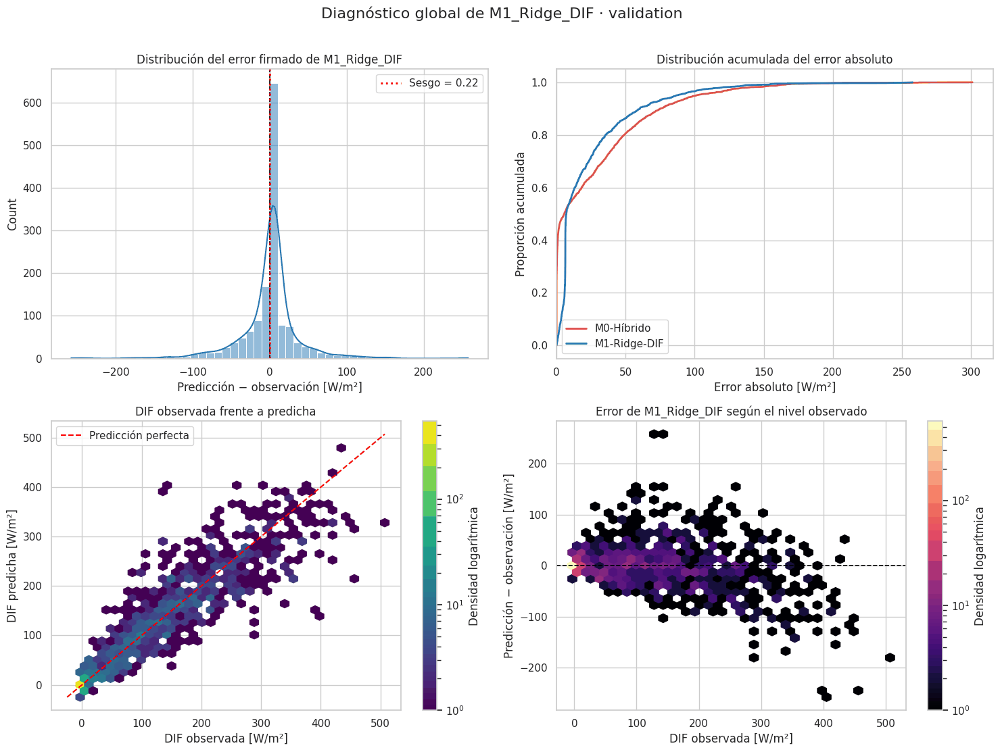


Resultados guardados en: /content/resultados_errores_M1_Ridge_DIF


In [ ]:
from pathlib import Path
import zipfile
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

sns.set_theme(style="whitegrid")

# 1. Localizar la tabla de predicciones
COLUMNAS_NECESARIAS = {
    "instante_objetivo",
    "particion",
    "regimen_solar_objetivo",
    "DIF_objetivo_t1",
    "pred_M0_hibrida",
    "pred_M1_Ridge_DIF",
}
predicciones = None
origen_predicciones = None

# Primero buscamos un DataFrame compatible que ya esté en memoria
for nombre, objeto in list(globals().items()):
    if isinstance(objeto, pd.DataFrame):
        if COLUMNAS_NECESARIAS.issubset(objeto.columns):
            predicciones = objeto.copy()
            origen_predicciones = f"DataFrame en memoria: {nombre}"
            break

# Si no está en memoria, buscamos el CSV en /content
if predicciones is None:
    candidatos = list(Path("/content").rglob("11_predicciones_train_validation.csv"))
    if candidatos:
        archivo_predicciones = candidatos[-1]
        predicciones = pd.read_csv(archivo_predicciones)
        origen_predicciones = str(archivo_predicciones)

# Si tampoco está extraído, permitimos subir el ZIP
if predicciones is None:
    from google.colab import files
    print(
        "No se encontró la tabla de predicciones.\nSube el ZIP resultados_ablacion_Ridge_....zip"
    )
    subidos = files.upload()
    archivos_zip = [nombre for nombre in subidos if nombre.lower().endswith(".zip")]
    if not archivos_zip:
        raise FileNotFoundError("No se ha subido ningún archivo ZIP.")

    carpeta_temporal = Path(tempfile.mkdtemp(prefix="ridge_resultados_"))
    with zipfile.ZipFile(archivos_zip[0], "r") as z:
        z.extractall(carpeta_temporal)

    candidatos = list(carpeta_temporal.rglob("11_predicciones_train_validation.csv"))
    if not candidatos:
        raise FileNotFoundError("El ZIP no contiene '11_predicciones_train_validation.csv'.")

    archivo_predicciones = candidatos[0]
    predicciones = pd.read_csv(archivo_predicciones)
    origen_predicciones = str(archivo_predicciones)

print("Origen:", origen_predicciones)

# 2. Preparar validation y garantizar soporte común
predicciones["instante_objetivo"] = pd.to_datetime(
    predicciones["instante_objetivo"], utc=True, errors="coerce"
)
columnas_analisis = [
    "instante_objetivo",
    "particion",
    "regimen_solar_objetivo",
    "DIF_objetivo_t1",
    "pred_M0_hibrida",
    "pred_M1_Ridge_DIF",
]
errores_m1_validation = (
    predicciones.loc[predicciones["particion"].eq("validation"), columnas_analisis]
    .dropna(subset=["instante_objetivo", "DIF_objetivo_t1", "pred_M0_hibrida", "pred_M1_Ridge_DIF"])
    .sort_values("instante_objetivo")
    .reset_index(drop=True)
)
if errores_m1_validation.empty:
    raise ValueError("No existen observaciones evaluables de validation.")

# 3. Calcular errores
# Convención: predicción - observación
y = errores_m1_validation["DIF_objetivo_t1"]
errores_m1_validation["error_M1"] = errores_m1_validation["pred_M1_Ridge_DIF"] - y
errores_m1_validation["error_abs_M1"] = errores_m1_validation["error_M1"].abs()
errores_m1_validation["error_M0"] = errores_m1_validation["pred_M0_hibrida"] - y
errores_m1_validation["error_abs_M0"] = errores_m1_validation["error_M0"].abs()

# Positivo = M1 mejora a M0
errores_m1_validation["mejora_abs_M1_frente_M0"] = (
    errores_m1_validation["error_abs_M0"] - errores_m1_validation["error_abs_M1"]
)

# 4. Función de métricas
def calcular_metricas(nombre, observado, predicho):
    error = predicho - observado
    error_abs = np.abs(error)
    return {
        "modelo": nombre,
        "n": len(observado),
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(mean_squared_error(observado, predicho)),
        "sesgo_pred_menos_obs": np.mean(error),
        "R2": r2_score(observado, predicho),
        "mediana_error_abs": np.quantile(error_abs, 0.50),
        "p75_error_abs": np.quantile(error_abs, 0.75),
        "p90_error_abs": np.quantile(error_abs, 0.90),
        "p95_error_abs": np.quantile(error_abs, 0.95),
        "p99_error_abs": np.quantile(error_abs, 0.99),
        "error_abs_maximo": np.max(error_abs),
    }

tabla_resumen_errores = pd.DataFrame(
    [
        calcular_metricas("M0_Hibrida", y, errores_m1_validation["pred_M0_hibrida"]),
        calcular_metricas("M1_Ridge_DIF", y, errores_m1_validation["pred_M1_Ridge_DIF"]),
    ]
)
print(f"Observaciones comunes de validation: " f"{len(errores_m1_validation):,}")
display(tabla_resumen_errores.round(4))

# 5. Resumen de mejora observación a observación
resumen_comparacion_M0_M1 = pd.DataFrame(
    {
        "indicador": [
            "Horas en las que M1 tiene menor error absoluto",
            "Horas en las que M0 tiene menor error absoluto",
            "Empates",
            "Porcentaje de horas ganado por M1",
            "Mejora media de error absoluto M1 frente a M0",
        ],
        "valor": [
            (errores_m1_validation["mejora_abs_M1_frente_M0"] > 0).sum(),
            (errores_m1_validation["mejora_abs_M1_frente_M0"] < 0).sum(),
            (errores_m1_validation["mejora_abs_M1_frente_M0"] == 0).sum(),
            100 * (errores_m1_validation["mejora_abs_M1_frente_M0"] > 0).mean(),
            errores_m1_validation["mejora_abs_M1_frente_M0"].mean(),
        ],
    }
)
display(resumen_comparacion_M0_M1.round(4))

# 6. Crear carpeta para resultados
CARPETA_ERRORES = Path("/content/resultados_errores_M1_Ridge_DIF")
CARPETA_ERRORES.mkdir(parents=True, exist_ok=True)

# 7. Figura 1: diagnóstico global
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# A. Distribución del error firmado
sns.histplot(
    data=errores_m1_validation, x="error_M1", bins=50, kde=True, color="#2878B5", ax=axes[0, 0]
)
axes[0, 0].axvline(0, color="black", linestyle="--", linewidth=1.2)
axes[0, 0].axvline(
    errores_m1_validation["error_M1"].mean(),
    color="red",
    linestyle=":",
    linewidth=2,
    label=("Sesgo = " f"{errores_m1_validation['error_M1'].mean():.2f}"),
)
axes[0, 0].set_title("Distribución del error firmado de M1_Ridge_DIF")
axes[0, 0].set_xlabel("Predicción − observación [W/m²]")
axes[0, 0].legend()

# B. Distribución acumulada del error absoluto
for columna, etiqueta, color in [
    ("error_abs_M0", "M0-Híbrido", "#D9534F"),
    ("error_abs_M1", "M1-Ridge-DIF", "#2878B5"),
]:
    valores = np.sort(errores_m1_validation[columna].to_numpy())
    proporcion = np.arange(1, len(valores) + 1) / len(valores)
    axes[0, 1].plot(valores, proporcion, linewidth=2, label=etiqueta, color=color)

axes[0, 1].set_title("Distribución acumulada del error absoluto")
axes[0, 1].set_xlabel("Error absoluto [W/m²]")
axes[0, 1].set_ylabel("Proporción acumulada")
axes[0, 1].set_xlim(left=0)
axes[0, 1].legend()

# C. Observado frente a predicho
hb1 = axes[1, 0].hexbin(
    errores_m1_validation["DIF_objetivo_t1"],
    errores_m1_validation["pred_M1_Ridge_DIF"],
    gridsize=35,
    mincnt=1,
    bins="log",
    cmap="viridis",
)
limite_min = min(
    errores_m1_validation["DIF_objetivo_t1"].min(), errores_m1_validation["pred_M1_Ridge_DIF"].min()
)
limite_max = max(
    errores_m1_validation["DIF_objetivo_t1"].max(), errores_m1_validation["pred_M1_Ridge_DIF"].max()
)
axes[1, 0].plot(
    [limite_min, limite_max],
    [limite_min, limite_max],
    linestyle="--",
    color="red",
    linewidth=1.5,
    label="Predicción perfecta",
)
axes[1, 0].set_title("DIF observada frente a predicha")
axes[1, 0].set_xlabel("DIF observada [W/m²]")
axes[1, 0].set_ylabel("DIF predicha [W/m²]")
axes[1, 0].legend()
fig.colorbar(hb1, ax=axes[1, 0], label="Densidad logarítmica")

# D. Error frente al nivel observado de DIF
hb2 = axes[1, 1].hexbin(
    errores_m1_validation["DIF_objetivo_t1"],
    errores_m1_validation["error_M1"],
    gridsize=35,
    mincnt=1,
    bins="log",
    cmap="magma",
)
axes[1, 1].axhline(0, color="black", linestyle="--", linewidth=1.2)
axes[1, 1].set_title("Error de M1_Ridge_DIF según el nivel observado")
axes[1, 1].set_xlabel("DIF observada [W/m²]")
axes[1, 1].set_ylabel("Predicción − observación [W/m²]")
fig.colorbar(hb2, ax=axes[1, 1], label="Densidad logarítmica")
fig.suptitle("Diagnóstico global de M1_Ridge_DIF · validation", fontsize=16, y=1.01)
plt.tight_layout()
ruta_figura = CARPETA_ERRORES / "01_diagnostico_global_M1_Ridge_DIF_validation.png"
plt.savefig(ruta_figura, dpi=180, bbox_inches="tight")
plt.show()

# 8. Guardar tablas
tabla_resumen_errores.to_csv(CARPETA_ERRORES / "01_metricas_globales_validation.csv", index=False)
resumen_comparacion_M0_M1.to_csv(
    CARPETA_ERRORES / "02_comparacion_observacion_M0_M1.csv", index=False
)
errores_m1_validation.to_csv(
    CARPETA_ERRORES / "03_errores_M1_Ridge_DIF_validation.csv", index=False
)
print("\nResultados guardados en:", CARPETA_ERRORES)

**Resultados.** Frente a la persistencia híbrida, `M1_Ridge_DIF` reduce el MAE de 25,66 a 22,82 W/m² y el RMSE de 45,73 a 38,72 W/m², con un sesgo de 0,22 W/m². Sin embargo, la mediana del error absoluto es mayor (7,15 frente a 5,59 W/m²) y el modelo solo tiene menor error en 567 de las 1.464 horas (38,73 %). La mejora procede de la cola de errores: el percentil 90 del error absoluto baja de 75,05 a 60,28 W/m² y el percentil 99, de 161,61 a 142,54 W/m².

### 2.6 Errores por régimen solar

Se descomponen las métricas de `M1_Ridge_DIF` y de la persistencia híbrida en las horas completamente diurnas, de transición y nocturnas de validación, junto con la proporción de horas en que cada modelo obtiene menor error absoluto.

Métricas por régimen solar:


,regimen,modelo,n,MAE,RMSE,sesgo_pred_menos_obs,R2,mediana_error_abs,p75_error_abs,p90_error_abs,p95_error_abs,p99_error_abs,error_abs_maximo
0,completamente_diurna,M0_Hibrida,765,48.3363,63.2042,-2.9637,0.5914,39.2167,64.8500,99.2433,126.8767,180.0673,301.1333
1,completamente_diurna,M1_Ridge_DIF,765,37.4076,52.9521,-3.6856,0.7132,26.7923,51.2693,85.8286,107.1415,162.0327,257.7445
2,transicion,M0_Hibrida,119,3.9738,6.5279,0.9598,0.1523,2.0333,5.6083,10.4467,13.0300,22.9873,36.5167
3,transicion,M1_Ridge_DIF,119,10.7195,14.6922,6.7931,-3.2939,6.2816,16.0713,25.2129,31.4767,36.5223,42.6908
4,noche,M0_Hibrida,580,0.2047,0.4385,-0.0002,-0.9107,0.0000,0.2375,0.7833,1.0000,1.8500,2.3833
5,noche,M1_Ridge_DIF,580,6.0576,6.4047,4.0275,-406.6157,6.3766,6.3945,6.8022,8.1357,13.1466,20.9218


,regimen,n,horas_gana_M1,horas_gana_M0,empates,porcentaje_gana_M1,porcentaje_gana_M0,mejora_media_M1_frente_M0,mediana_mejora_M1_frente_M0
0,completamente_diurna,765,535,230,0,69.9346,30.0654,10.9286,15.1597
1,transicion,119,31,88,0,26.0504,73.9496,-6.7456,-3.6197
2,noche,580,1,579,0,0.1724,99.8276,-5.8529,-6.3004


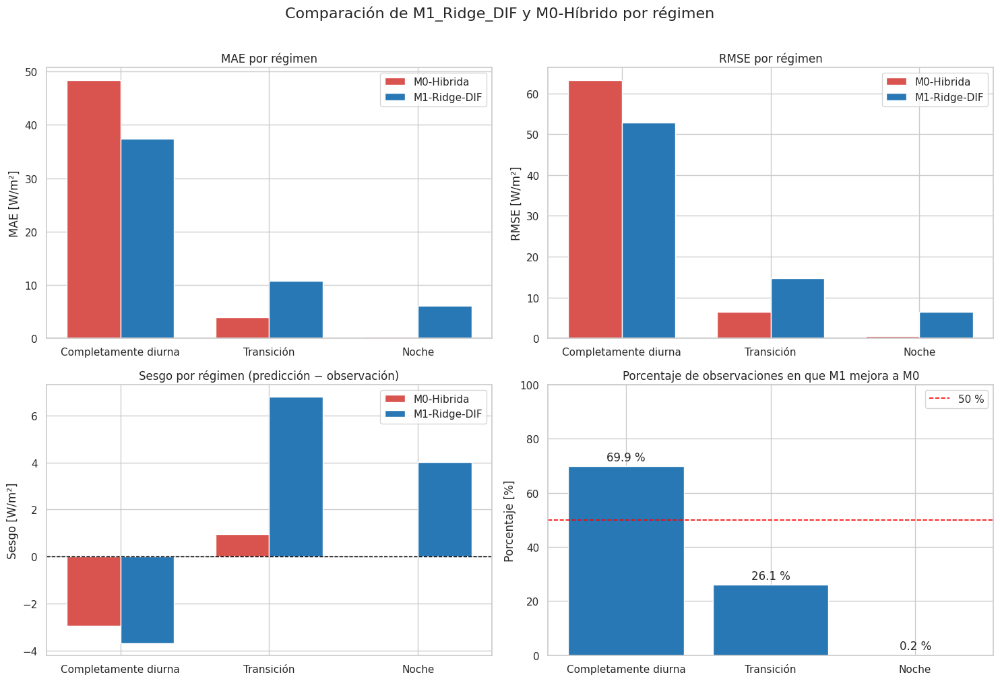

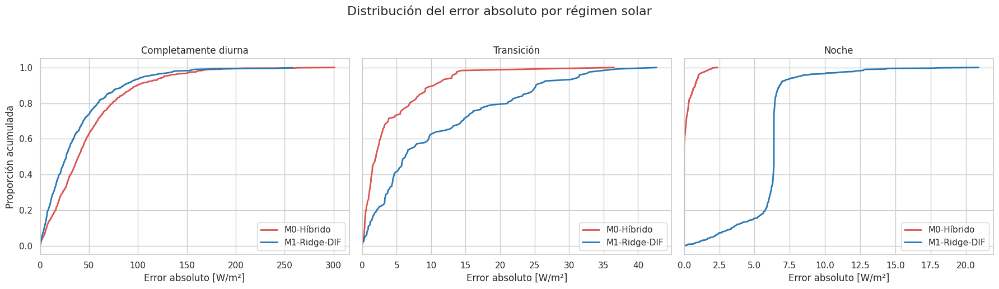

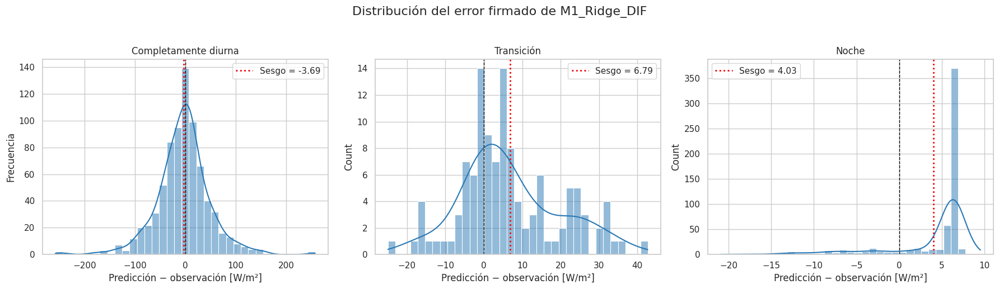


Resultados añadidos a: /content/resultados_errores_M1_Ridge_DIF


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

sns.set_theme(style="whitegrid")

# 1. Comprobar que se ejecutó la etapa anterior
if "errores_m1_validation" not in globals():
    raise NameError(
        "No existe 'errores_m1_validation'. Ejecuta primero la celda del diagnóstico global."
    )

df_regimen = errores_m1_validation.copy()
REGIMENES = ["completamente_diurna", "transicion", "noche"]
faltantes = set(REGIMENES) - set(df_regimen["regimen_solar_objetivo"].dropna().unique())
if faltantes:
    raise ValueError(f"No se encontraron estos regímenes: {faltantes}")

# 2. Calcular métricas por régimen y modelo
def metricas_regimen(grupo, modelo, columna_prediccion):
    observado = grupo["DIF_objetivo_t1"].to_numpy()
    predicho = grupo[columna_prediccion].to_numpy()
    error = predicho - observado
    error_abs = np.abs(error)
    return {
        "regimen": grupo.name,
        "modelo": modelo,
        "n": len(grupo),
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(mean_squared_error(observado, predicho)),
        "sesgo_pred_menos_obs": np.mean(error),
        "R2": r2_score(observado, predicho),
        "mediana_error_abs": np.quantile(error_abs, 0.50),
        "p75_error_abs": np.quantile(error_abs, 0.75),
        "p90_error_abs": np.quantile(error_abs, 0.90),
        "p95_error_abs": np.quantile(error_abs, 0.95),
        "p99_error_abs": np.quantile(error_abs, 0.99),
        "error_abs_maximo": np.max(error_abs),
    }

filas_metricas = []
for regimen, grupo in df_regimen.groupby("regimen_solar_objetivo", observed=True):
    grupo.name = regimen
    filas_metricas.append(metricas_regimen(grupo, "M0_Hibrida", "pred_M0_hibrida"))
    filas_metricas.append(metricas_regimen(grupo, "M1_Ridge_DIF", "pred_M1_Ridge_DIF"))

tabla_metricas_por_regimen = pd.DataFrame(filas_metricas)
tabla_metricas_por_regimen["regimen"] = pd.Categorical(
    tabla_metricas_por_regimen["regimen"], categories=REGIMENES, ordered=True
)
tabla_metricas_por_regimen = tabla_metricas_por_regimen.sort_values(
    ["regimen", "modelo"]
).reset_index(drop=True)
print("Métricas por régimen solar:")
display(tabla_metricas_por_regimen.round(4))

# 3. Comparación observación a observación por régimen
filas_comparacion = []
for regimen in REGIMENES:
    grupo = df_regimen.loc[df_regimen["regimen_solar_objetivo"].eq(regimen)]
    mejora = grupo["mejora_abs_M1_frente_M0"]
    filas_comparacion.append(
        {
            "regimen": regimen,
            "n": len(grupo),
            "horas_gana_M1": (mejora > 0).sum(),
            "horas_gana_M0": (mejora < 0).sum(),
            "empates": (mejora == 0).sum(),
            "porcentaje_gana_M1": 100 * (mejora > 0).mean(),
            "porcentaje_gana_M0": 100 * (mejora < 0).mean(),
            "mejora_media_M1_frente_M0": mejora.mean(),
            "mediana_mejora_M1_frente_M0": mejora.median(),
        }
    )

tabla_comparacion_por_regimen = pd.DataFrame(filas_comparacion)
display(tabla_comparacion_por_regimen.round(4))

# 4. Crear formato largo para gráficos
errores_largo = pd.concat(
    [
        df_regimen[["instante_objetivo", "regimen_solar_objetivo", "DIF_objetivo_t1"]].assign(
            modelo="M0-Híbrido",
            error=df_regimen["error_M0"],
            error_absoluto=df_regimen["error_abs_M0"],
        ),
        df_regimen[["instante_objetivo", "regimen_solar_objetivo", "DIF_objetivo_t1"]].assign(
            modelo="M1-Ridge-DIF",
            error=df_regimen["error_M1"],
            error_absoluto=df_regimen["error_abs_M1"],
        ),
    ],
    ignore_index=True,
)
errores_largo["regimen_solar_objetivo"] = pd.Categorical(
    errores_largo["regimen_solar_objetivo"], categories=REGIMENES, ordered=True
)
COLORES = {"M0_Hibrida": "#D9534F", "M1_Ridge_DIF": "#2878B5"}
ETIQUETAS_REGIMEN = {
    "completamente_diurna": "Completamente diurna",
    "transicion": "Transición",
    "noche": "Noche",
}

# 5. Figura 1: resumen comparativo por régimen
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
modelos_orden = ["M0_Hibrida", "M1_Ridge_DIF"]
x = np.arange(len(REGIMENES))
ancho = 0.36

# A. MAE
for desplazamiento, modelo in zip([-ancho / 2, ancho / 2], modelos_orden):
    valores = (
        tabla_metricas_por_regimen.loc[tabla_metricas_por_regimen["modelo"].eq(modelo)]
        .set_index("regimen")
        .reindex(REGIMENES)["MAE"]
    )
    axes[0, 0].bar(
        x + desplazamiento,
        valores,
        width=ancho,
        label=modelo.replace("_", "-"),
        color=COLORES[modelo],
    )

axes[0, 0].set_title("MAE por régimen")
axes[0, 0].set_ylabel("MAE [W/m²]")
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels([ETIQUETAS_REGIMEN[r] for r in REGIMENES])
axes[0, 0].legend()

# B. RMSE
for desplazamiento, modelo in zip([-ancho / 2, ancho / 2], modelos_orden):
    valores = (
        tabla_metricas_por_regimen.loc[tabla_metricas_por_regimen["modelo"].eq(modelo)]
        .set_index("regimen")
        .reindex(REGIMENES)["RMSE"]
    )
    axes[0, 1].bar(
        x + desplazamiento,
        valores,
        width=ancho,
        label=modelo.replace("_", "-"),
        color=COLORES[modelo],
    )

axes[0, 1].set_title("RMSE por régimen")
axes[0, 1].set_ylabel("RMSE [W/m²]")
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels([ETIQUETAS_REGIMEN[r] for r in REGIMENES])
axes[0, 1].legend()

# C. Sesgo
for desplazamiento, modelo in zip([-ancho / 2, ancho / 2], modelos_orden):
    valores = (
        tabla_metricas_por_regimen.loc[tabla_metricas_por_regimen["modelo"].eq(modelo)]
        .set_index("regimen")
        .reindex(REGIMENES)["sesgo_pred_menos_obs"]
    )
    axes[1, 0].bar(
        x + desplazamiento,
        valores,
        width=ancho,
        label=modelo.replace("_", "-"),
        color=COLORES[modelo],
    )

axes[1, 0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1, 0].set_title("Sesgo por régimen (predicción − observación)")
axes[1, 0].set_ylabel("Sesgo [W/m²]")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels([ETIQUETAS_REGIMEN[r] for r in REGIMENES])
axes[1, 0].legend()

# D. Porcentaje de horas ganado por M1
porcentajes = tabla_comparacion_por_regimen.set_index("regimen").reindex(REGIMENES)[
    "porcentaje_gana_M1"
]
barras = axes[1, 1].bar(x, porcentajes, color="#2878B5")
axes[1, 1].axhline(50, color="red", linestyle="--", linewidth=1.2, label="50 %")
axes[1, 1].set_ylim(0, 100)
axes[1, 1].set_title("Porcentaje de observaciones en que M1 mejora a M0")
axes[1, 1].set_ylabel("Porcentaje [%]")
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels([ETIQUETAS_REGIMEN[r] for r in REGIMENES])
axes[1, 1].legend()
for barra, valor in zip(barras, porcentajes):
    axes[1, 1].text(barra.get_x() + barra.get_width() / 2, valor + 2, f"{valor:.1f} %", ha="center")

fig.suptitle("Comparación de M1_Ridge_DIF y M0-Híbrido por régimen", fontsize=16, y=1.01)
plt.tight_layout()
ruta_figura_1 = CARPETA_ERRORES / "02_metricas_por_regimen_validation.png"
plt.savefig(ruta_figura_1, dpi=180, bbox_inches="tight")
plt.show()

# 6. Figura 2: distribución acumulada por régimen
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, regimen in zip(axes, REGIMENES):
    grupo = df_regimen.loc[df_regimen["regimen_solar_objetivo"].eq(regimen)]
    for columna, etiqueta, color in [
        ("error_abs_M0", "M0-Híbrido", "#D9534F"),
        ("error_abs_M1", "M1-Ridge-DIF", "#2878B5"),
    ]:
        valores = np.sort(grupo[columna].to_numpy())
        acumulada = np.arange(1, len(valores) + 1) / len(valores)
        ax.plot(valores, acumulada, linewidth=2, label=etiqueta, color=color)

    ax.set_title(ETIQUETAS_REGIMEN[regimen])
    ax.set_xlabel("Error absoluto [W/m²]")
    ax.set_xlim(left=0)
    ax.legend()

axes[0].set_ylabel("Proporción acumulada")
fig.suptitle("Distribución del error absoluto por régimen solar", fontsize=16, y=1.03)
plt.tight_layout()
ruta_figura_2 = CARPETA_ERRORES / "03_distribucion_acumulada_por_regimen.png"
plt.savefig(ruta_figura_2, dpi=180, bbox_inches="tight")
plt.show()

# 7. Figura 3: error firmado de M1 dentro de cada régimen
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, regimen in zip(axes, REGIMENES):
    valores = df_regimen.loc[df_regimen["regimen_solar_objetivo"].eq(regimen), "error_M1"]
    sns.histplot(valores, bins=35, kde=True, color="#2878B5", ax=ax)
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(
        valores.mean(),
        color="red",
        linestyle=":",
        linewidth=2,
        label=f"Sesgo = {valores.mean():.2f}",
    )
    ax.set_title(ETIQUETAS_REGIMEN[regimen])
    ax.set_xlabel("Predicción − observación [W/m²]")
    ax.legend()

axes[0].set_ylabel("Frecuencia")
fig.suptitle("Distribución del error firmado de M1_Ridge_DIF", fontsize=16, y=1.03)
plt.tight_layout()
ruta_figura_3 = CARPETA_ERRORES / "04_error_firmado_M1_por_regimen.png"
plt.savefig(ruta_figura_3, dpi=180, bbox_inches="tight")
plt.show()

# 8. Guardar tablas para el ZIP final
tabla_metricas_por_regimen.to_csv(
    CARPETA_ERRORES / "04_metricas_por_regimen_validation.csv", index=False
)
tabla_comparacion_por_regimen.to_csv(
    CARPETA_ERRORES / "05_comparacion_M0_M1_por_regimen.csv", index=False
)
errores_largo.to_csv(CARPETA_ERRORES / "06_errores_formato_largo_por_regimen.csv", index=False)
print("\nResultados añadidos a:", CARPETA_ERRORES)

**Resultados.** La ventaja de `M1_Ridge_DIF` sobre la persistencia híbrida se limita a las horas completamente diurnas:

- Completamente diurno: el MAE baja de 48,34 a 37,41 W/m² y el modelo tiene menor error en 535 de 765 horas (69,93 %); ambos modelos infraestiman (sesgos de −2,96 y −3,69 W/m²).
- Transición: el MAE sube de 3,97 a 10,72 W/m² (sesgo de 6,79 W/m²) y el modelo solo mejora en el 26,05 % de las horas.
- Noche: el MAE sube de 0,20 a 6,06 W/m² (sesgo positivo de 4,03 W/m²) y el modelo solo mejora en 1 de 580 horas.

### 2.7 Errores diurnos según nivel de DIF, hora, mes y rampa

En las 765 horas completamente diurnas de validación se analizan los errores de `M1_Ridge_DIF` por quintiles de la DIF observada, hora UTC, mes y quintiles de la rampa DIF(t+1) − DIF(t). La DIF observada y la rampa se utilizan solo para diagnosticar los errores a posteriori, no como predictores.

Horas completamente diurnas de validation: 765
Periodo: 2024-08-01 05:00:00+00:00 → 2024-09-30 16:00:00+00:00

Límites observados de los quintiles:


,quintil_DIF,n,minimo,mediana,maximo
0,Q1 · DIF muy baja,153,3.150,47.550,71.850
1,Q2 · DIF baja,153,71.867,94.100,121.900
2,Q3 · DIF intermedia,153,122.317,145.683,173.133
3,Q4 · DIF alta,153,173.350,209.100,250.767
4,Q5 · DIF muy alta,153,250.817,309.533,507.100



Errores por quintil de DIF:


,quintil_DIF,n,DIF_media,DIF_mediana,MAE_M1,RMSE_M1,sesgo_M1,mediana_error_abs_M1,p90_error_abs_M1,p95_error_abs_M1,MAE_M0,mejora_media_M1_frente_M0,porcentaje_gana_M1
0,Q1 · DIF muy baja,153.0,45.899,47.550,23.369,30.943,4.788,18.317,43.841,61.034,41.404,18.036,88.235
1,Q2 · DIF baja,153.0,95.426,94.100,28.034,40.575,11.866,19.749,58.405,90.144,39.415,11.381,71.895
2,Q3 · DIF intermedia,153.0,146.219,145.683,36.433,53.552,9.945,27.080,74.294,106.880,48.450,12.017,67.320
3,Q4 · DIF alta,153.0,207.326,209.100,38.850,48.261,-4.036,33.883,82.542,92.263,49.234,10.384,65.359
4,Q5 · DIF muy alta,153.0,318.745,309.533,60.352,78.860,-40.990,50.803,128.481,155.447,63.178,2.825,56.863



Errores por hora UTC:


,hora_UTC,n,DIF_media,DIF_mediana,MAE_M1,RMSE_M1,sesgo_M1,mediana_error_abs_M1,p90_error_abs_M1,p95_error_abs_M1,MAE_M0,mejora_media_M1_frente_M0,porcentaje_gana_M1
0,5,35.0,44.318,40.350,22.458,26.043,-21.334,20.936,43.628,46.501,38.223,15.765,97.143
1,6,61.0,75.251,69.017,25.068,30.992,-22.956,23.741,44.634,56.544,45.580,20.512,98.361
2,7,61.0,136.571,127.650,38.788,49.603,-30.131,33.090,77.225,94.329,61.348,22.560,88.525
3,8,61.0,189.492,187.367,39.861,51.516,-20.853,33.603,83.634,100.110,55.945,16.084,75.410
4,9,61.0,218.795,210.559,40.874,55.598,-5.929,28.634,88.172,107.366,42.513,1.639,62.295
5,10,61.0,229.522,228.450,42.925,58.106,-1.153,31.221,110.299,129.230,43.463,0.538,49.180
6,11,61.0,247.727,226.933,47.868,68.026,-16.435,34.377,104.795,145.815,45.642,-2.226,50.820
7,12,61.0,239.056,237.400,50.000,71.085,1.394,30.018,119.855,135.485,45.162,-4.838,39.344
8,13,61.0,219.931,217.467,41.805,63.611,4.591,28.220,85.714,105.118,42.146,0.341,55.738
9,14,61.0,183.777,174.217,43.386,62.737,11.711,28.932,94.884,113.372,54.340,10.954,62.295



Errores por mes:


,mes,n,DIF_media,DIF_mediana,MAE_M1,RMSE_M1,sesgo_M1,mediana_error_abs_M1,p90_error_abs_M1,p95_error_abs_M1,MAE_M0,mejora_media_M1_frente_M0,porcentaje_gana_M1
0,2024-08,419.0,176.371,151.700,40.936,58.370,-4.64,28.634,94.440,120.604,50.519,9.583,66.826
1,2024-09,346.0,146.196,139.083,33.134,45.536,-2.53,24.142,76.142,93.495,45.693,12.558,73.699


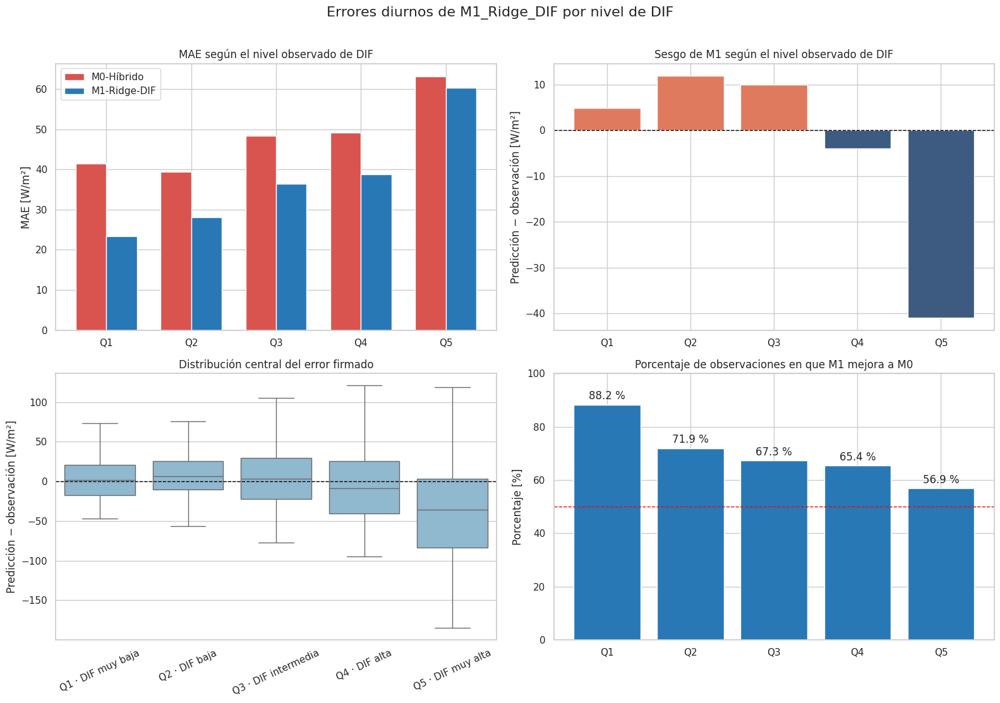

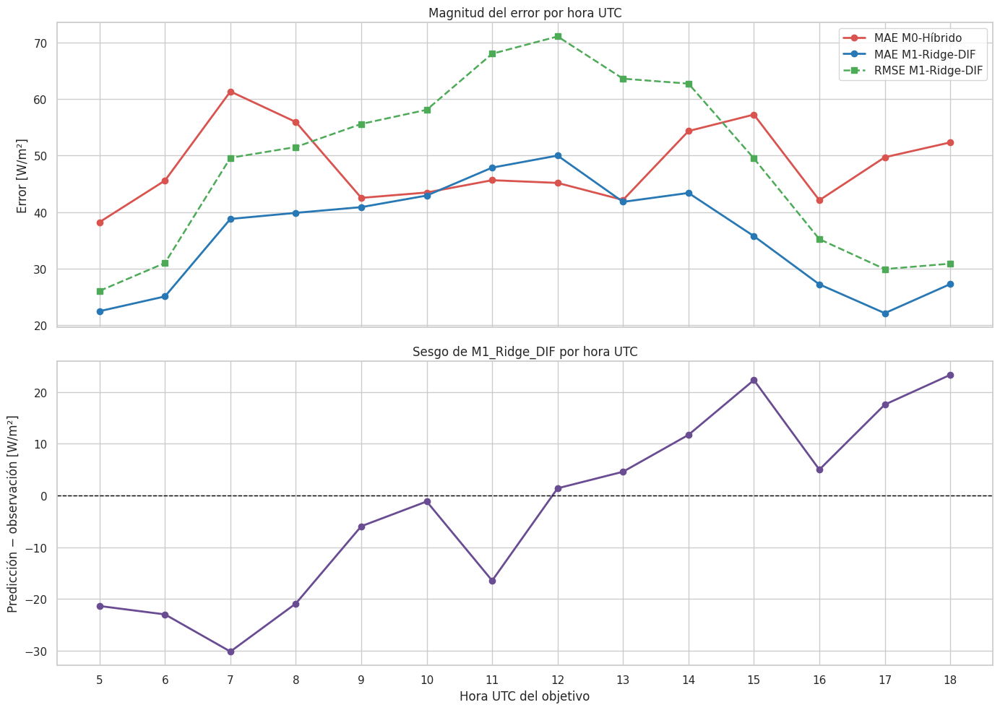

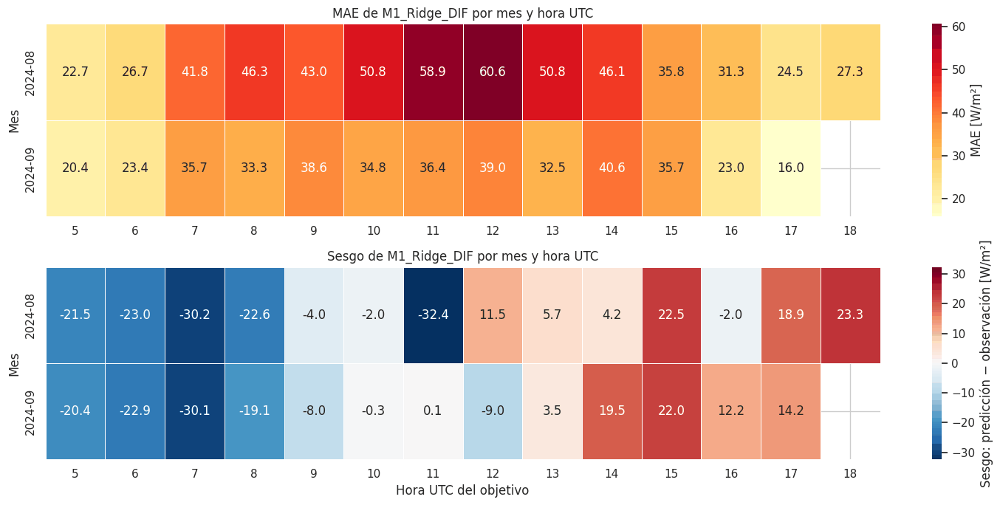


Resultados añadidos a: /content/resultados_errores_M1_Ridge_DIF


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid")

# 1. Comprobar objetos anteriores
if "errores_m1_validation" not in globals():
    raise NameError("No existe 'errores_m1_validation'. Ejecuta primero el diagnóstico global.")

if "CARPETA_ERRORES" not in globals():
    CARPETA_ERRORES = Path("/content/resultados_errores_M1_Ridge_DIF")
    CARPETA_ERRORES.mkdir(parents=True, exist_ok=True)

# 2. Seleccionar horas completamente diurnas
errores_m1_diurno = (
    errores_m1_validation.loc[
        errores_m1_validation["regimen_solar_objetivo"].eq("completamente_diurna")
    ]
    .copy()
    .sort_values("instante_objetivo")
    .reset_index(drop=True)
)
if errores_m1_diurno.empty:
    raise ValueError("No se encontraron horas completamente diurnas.")

errores_m1_diurno["instante_objetivo"] = pd.to_datetime(
    errores_m1_diurno["instante_objetivo"], utc=True
)
errores_m1_diurno["hora_UTC"] = errores_m1_diurno["instante_objetivo"].dt.hour
errores_m1_diurno["mes_numero"] = errores_m1_diurno["instante_objetivo"].dt.month
errores_m1_diurno["mes"] = errores_m1_diurno["instante_objetivo"].dt.strftime("%Y-%m")
print("Horas completamente diurnas de validation:", len(errores_m1_diurno))
print(
    "Periodo:",
    errores_m1_diurno["instante_objetivo"].min(),
    "→",
    errores_m1_diurno["instante_objetivo"].max(),
)

# 3. Crear quintiles de DIF observada
etiquetas_quintiles = [
    "Q1 · DIF muy baja",
    "Q2 · DIF baja",
    "Q3 · DIF intermedia",
    "Q4 · DIF alta",
    "Q5 · DIF muy alta",
]
errores_m1_diurno["quintil_DIF"] = pd.qcut(
    errores_m1_diurno["DIF_objetivo_t1"], q=5, labels=etiquetas_quintiles, duplicates="drop"
)
print("\nLímites observados de los quintiles:")
limites_quintiles = (
    errores_m1_diurno.groupby("quintil_DIF", observed=True)["DIF_objetivo_t1"]
    .agg(n="size", minimo="min", mediana="median", maximo="max")
    .reset_index()
)
display(limites_quintiles.round(3))

# 4. Función de resumen del error
def resumir_error(grupo):
    return pd.Series(
        {
            "n": len(grupo),
            "DIF_media": grupo["DIF_objetivo_t1"].mean(),
            "DIF_mediana": grupo["DIF_objetivo_t1"].median(),
            "MAE_M1": grupo["error_abs_M1"].mean(),
            "RMSE_M1": np.sqrt(np.mean(grupo["error_M1"] ** 2)),
            "sesgo_M1": grupo["error_M1"].mean(),
            "mediana_error_abs_M1": grupo["error_abs_M1"].median(),
            "p90_error_abs_M1": grupo["error_abs_M1"].quantile(0.90),
            "p95_error_abs_M1": grupo["error_abs_M1"].quantile(0.95),
            "MAE_M0": grupo["error_abs_M0"].mean(),
            "mejora_media_M1_frente_M0": grupo["mejora_abs_M1_frente_M0"].mean(),
            "porcentaje_gana_M1": (100 * (grupo["mejora_abs_M1_frente_M0"] > 0).mean()),
        }
    )


# 5. Tablas por nivel, hora y mes
tabla_error_por_quintil = (
    errores_m1_diurno.groupby("quintil_DIF", observed=True)
    .apply(resumir_error, include_groups=False)
    .reset_index()
)
tabla_error_por_hora = (
    errores_m1_diurno.groupby("hora_UTC", observed=True)
    .apply(resumir_error, include_groups=False)
    .reset_index()
)
tabla_error_por_mes = (
    errores_m1_diurno.groupby("mes", observed=True)
    .apply(resumir_error, include_groups=False)
    .reset_index()
)
print("\nErrores por quintil de DIF:")
display(tabla_error_por_quintil.round(3))
print("\nErrores por hora UTC:")
display(tabla_error_por_hora.round(3))
print("\nErrores por mes:")
display(tabla_error_por_mes.round(3))

# 6. Figura 1: error según nivel de DIF
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
xq = np.arange(len(tabla_error_por_quintil))
ancho = 0.36

# A. MAE M0 frente a M1
axes[0, 0].bar(
    xq - ancho / 2,
    tabla_error_por_quintil["MAE_M0"],
    width=ancho,
    label="M0-Híbrido",
    color="#D9534F",
)
axes[0, 0].bar(
    xq + ancho / 2,
    tabla_error_por_quintil["MAE_M1"],
    width=ancho,
    label="M1-Ridge-DIF",
    color="#2878B5",
)
axes[0, 0].set_title("MAE según el nivel observado de DIF")
axes[0, 0].set_ylabel("MAE [W/m²]")
axes[0, 0].set_xticks(xq)
axes[0, 0].set_xticklabels(["Q1", "Q2", "Q3", "Q4", "Q5"])
axes[0, 0].legend()

# B. Sesgo de M1
colores_sesgo = np.where(tabla_error_por_quintil["sesgo_M1"] >= 0, "#E07A5F", "#3D5A80")
axes[0, 1].bar(xq, tabla_error_por_quintil["sesgo_M1"], color=colores_sesgo)
axes[0, 1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0, 1].set_title("Sesgo de M1 según el nivel observado de DIF")
axes[0, 1].set_ylabel("Predicción − observación [W/m²]")
axes[0, 1].set_xticks(xq)
axes[0, 1].set_xticklabels(["Q1", "Q2", "Q3", "Q4", "Q5"])

# C. Distribución del error firmado
sns.boxplot(
    data=errores_m1_diurno,
    x="quintil_DIF",
    y="error_M1",
    showfliers=False,
    color="#86BBD8",
    ax=axes[1, 0],
)
axes[1, 0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1, 0].set_title("Distribución central del error firmado")
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Predicción − observación [W/m²]")
axes[1, 0].tick_params(axis="x", rotation=25)

# D. Porcentaje de observaciones ganado por M1
barras = axes[1, 1].bar(xq, tabla_error_por_quintil["porcentaje_gana_M1"], color="#2878B5")
axes[1, 1].axhline(50, color="red", linestyle="--", linewidth=1)
axes[1, 1].set_ylim(0, 100)
axes[1, 1].set_title("Porcentaje de observaciones en que M1 mejora a M0")
axes[1, 1].set_ylabel("Porcentaje [%]")
axes[1, 1].set_xticks(xq)
axes[1, 1].set_xticklabels(["Q1", "Q2", "Q3", "Q4", "Q5"])
for barra, valor in zip(barras, tabla_error_por_quintil["porcentaje_gana_M1"]):
    axes[1, 1].text(barra.get_x() + barra.get_width() / 2, valor + 2, f"{valor:.1f} %", ha="center")

fig.suptitle("Errores diurnos de M1_Ridge_DIF por nivel de DIF", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig(
    CARPETA_ERRORES / "05_errores_diurnos_por_quintil_DIF.png", dpi=180, bbox_inches="tight"
)
plt.show()

# 7. Figura 2: error por hora UTC
fig, axes = plt.subplots(2, 1, figsize=(14, 10), sharex=True)
axes[0].plot(
    tabla_error_por_hora["hora_UTC"],
    tabla_error_por_hora["MAE_M0"],
    marker="o",
    linewidth=2,
    color="#D9534F",
    label="MAE M0-Híbrido",
)
axes[0].plot(
    tabla_error_por_hora["hora_UTC"],
    tabla_error_por_hora["MAE_M1"],
    marker="o",
    linewidth=2,
    color="#2878B5",
    label="MAE M1-Ridge-DIF",
)
axes[0].plot(
    tabla_error_por_hora["hora_UTC"],
    tabla_error_por_hora["RMSE_M1"],
    marker="s",
    linestyle="--",
    linewidth=1.8,
    color="#4DAA57",
    label="RMSE M1-Ridge-DIF",
)
axes[0].set_title("Magnitud del error por hora UTC")
axes[0].set_ylabel("Error [W/m²]")
axes[0].legend()
axes[1].plot(
    tabla_error_por_hora["hora_UTC"],
    tabla_error_por_hora["sesgo_M1"],
    marker="o",
    linewidth=2,
    color="#6A4C93",
)
axes[1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Sesgo de M1_Ridge_DIF por hora UTC")
axes[1].set_xlabel("Hora UTC del objetivo")
axes[1].set_ylabel("Predicción − observación [W/m²]")
axes[1].set_xticks(tabla_error_por_hora["hora_UTC"])
plt.tight_layout()
plt.savefig(CARPETA_ERRORES / "06_errores_diurnos_por_hora_UTC.png", dpi=180, bbox_inches="tight")
plt.show()

# 8. Figura 3: comparación mensual y mapa mes × hora
tabla_mes_hora_MAE = errores_m1_diurno.pivot_table(
    index="mes", columns="hora_UTC", values="error_abs_M1", aggfunc="mean"
)
tabla_mes_hora_sesgo = errores_m1_diurno.pivot_table(
    index="mes", columns="hora_UTC", values="error_M1", aggfunc="mean"
)
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
sns.heatmap(
    tabla_mes_hora_MAE,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    ax=axes[0],
    cbar_kws={"label": "MAE [W/m²]"},
)
axes[0].set_title("MAE de M1_Ridge_DIF por mes y hora UTC")
axes[0].set_xlabel("")
axes[0].set_ylabel("Mes")
limite_sesgo = np.nanmax(np.abs(tabla_mes_hora_sesgo.to_numpy()))
sns.heatmap(
    tabla_mes_hora_sesgo,
    annot=True,
    fmt=".1f",
    cmap="RdBu_r",
    center=0,
    vmin=-limite_sesgo,
    vmax=limite_sesgo,
    linewidths=0.5,
    ax=axes[1],
    cbar_kws={"label": "Sesgo: predicción − observación [W/m²]"},
)
axes[1].set_title("Sesgo de M1_Ridge_DIF por mes y hora UTC")
axes[1].set_xlabel("Hora UTC del objetivo")
axes[1].set_ylabel("Mes")
plt.tight_layout()
plt.savefig(CARPETA_ERRORES / "07_mapas_error_mes_hora_UTC.png", dpi=180, bbox_inches="tight")
plt.show()

# 9. Guardar resultados
limites_quintiles.to_csv(CARPETA_ERRORES / "07_limites_quintiles_DIF_diurna.csv", index=False)
tabla_error_por_quintil.to_csv(
    CARPETA_ERRORES / "08_errores_diurnos_por_quintil_DIF.csv", index=False
)
tabla_error_por_hora.to_csv(CARPETA_ERRORES / "09_errores_diurnos_por_hora_UTC.csv", index=False)
tabla_error_por_mes.to_csv(CARPETA_ERRORES / "10_errores_diurnos_por_mes.csv", index=False)
tabla_mes_hora_MAE.to_csv(CARPETA_ERRORES / "11_mapa_MAE_mes_hora_UTC.csv")
tabla_mes_hora_sesgo.to_csv(CARPETA_ERRORES / "12_mapa_sesgo_mes_hora_UTC.csv")
errores_m1_diurno.to_csv(CARPETA_ERRORES / "13_errores_M1_diurnos_validation.csv", index=False)
print("\nResultados añadidos a:", CARPETA_ERRORES)

Tabla utilizada para recuperar DIF(t): dataset_modelado

Umbrales descriptivos:


,umbral,DIF_Wm2
0,p80 · comienzo Q5,250.777
1,p95 · DIF extrema,349.463
2,p99 · DIF muy extrema,420.039



Límites de los quintiles de rampa:


,quintil_rampa,n,minimo,mediana,maximo
0,R1 · descenso intenso,153,-301.133,-73.517,-45.517
1,R2 · descenso moderado,153,-44.950,-26.650,-7.350
2,R3 · cambio pequeño,153,-7.333,5.883,20.381
3,R4 · aumento moderado,153,20.417,35.900,49.500
4,R5 · aumento intenso,153,49.517,74.150,261.667



Niveles, extremos y rampas por mes:


,mes,n,DIF_media,DIF_mediana,DIF_p90,DIF_p95,DIF_p99,DIF_maxima,n_Q5,porcentaje_Q5,...,n_extremos_p99,porcentaje_extremos_p99,rampa_media,rampa_abs_media,rampa_abs_p90,rampa_abs_p95,rampa_positiva_maxima,rampa_negativa_minima,MAE_M1,sesgo_M1
0,2024-08,419.0,176.371,151.700,341.640,383.375,440.732,507.100,105.0,25.060,...,8.0,1.909,3.059,50.519,103.930,139.458,261.667,-301.133,40.936,-4.64
1,2024-09,346.0,146.196,139.083,262.908,283.804,354.225,414.833,48.0,13.873,...,0.0,0.000,2.849,45.693,93.767,121.083,166.033,-177.133,33.134,-2.53



Errores según el quintil de rampa:


,quintil_rampa,n,rampa_minima,rampa_mediana,rampa_maxima,DIF_mediana,MAE_M1,RMSE_M1,sesgo_M1,mediana_error_abs_M1,p90_error_abs_M1,MAE_M0,mejora_media_M1_frente_M0,porcentaje_gana_M1
0,R1 · descenso intenso,153.0,-301.133,-73.517,-45.517,132.583,53.603,70.168,51.901,40.431,113.187,86.328,32.725,86.928
1,R2 · descenso moderado,153.0,-44.950,-26.650,-7.350,127.817,24.375,32.095,16.142,17.994,54.746,26.183,1.808,62.745
2,R3 · cambio pequeño,153.0,-7.333,5.883,20.381,139.983,19.380,28.292,-0.227,11.303,46.976,8.342,-11.038,36.601
3,R4 · aumento moderado,153.0,20.417,35.900,49.500,137.950,23.616,31.235,-20.315,18.773,50.722,35.254,11.638,79.739
4,R5 · aumento intenso,153.0,49.517,74.150,261.667,195.783,66.064,79.309,-65.930,54.069,124.360,85.574,19.510,83.660



Asociación descriptiva entre rampa y error:


,periodo,n,pearson_rampa_error,pearson_p,spearman_rampa_error,spearman_p
0,validation_completa,765,-0.8564,0.0,-0.8241,0.0
1,2024-08,419,-0.8455,0.0,-0.7991,0.0
2,2024-09,346,-0.8790,0.0,-0.8597,0.0


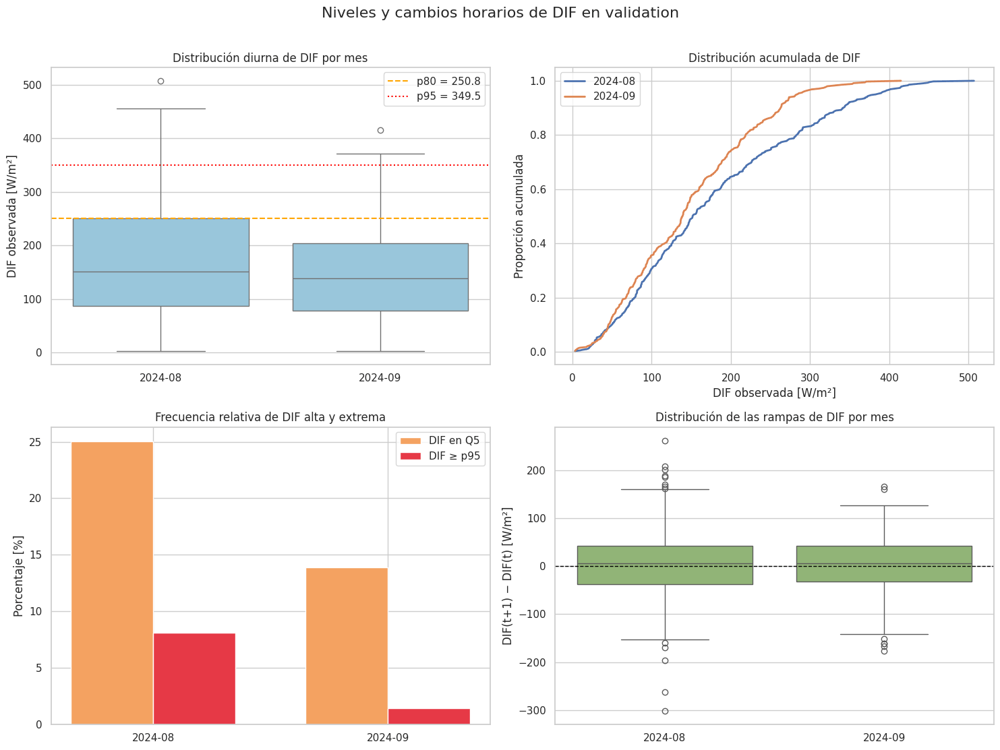

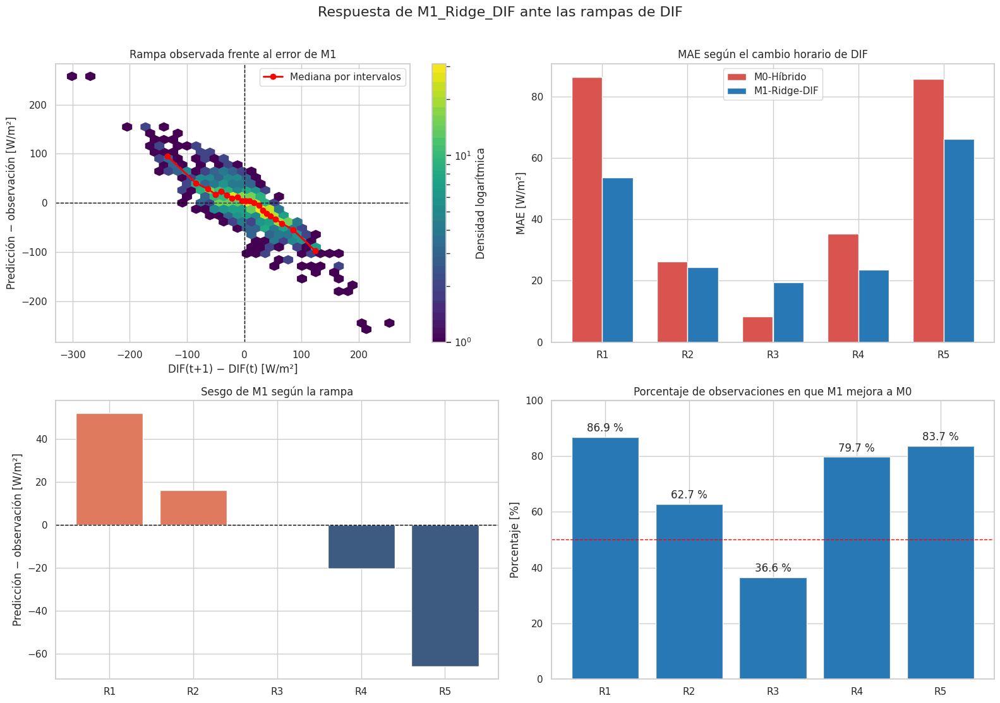

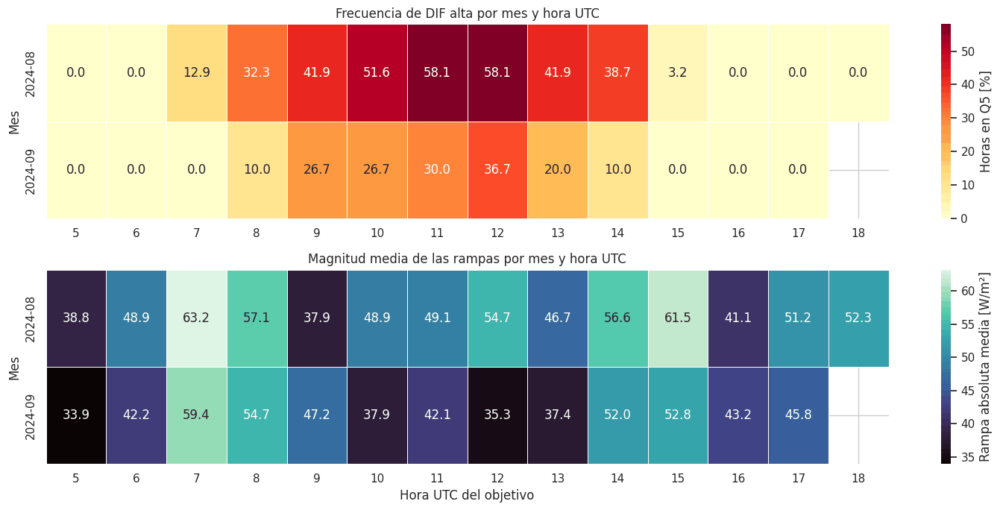


Resultados añadidos a: /content/resultados_errores_M1_Ridge_DIF


In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
from IPython.display import display

sns.set_theme(style="whitegrid")

# 1. Comprobar objetos necesarios
if "errores_m1_diurno" not in globals():
    raise NameError("No existe 'errores_m1_diurno'. Ejecuta primero el análisis diurno.")

if "CARPETA_ERRORES" not in globals():
    CARPETA_ERRORES = Path("/content/resultados_errores_M1_Ridge_DIF")
    CARPETA_ERRORES.mkdir(parents=True, exist_ok=True)

# 2. Localizar DIF(t), almacenada como pred_M0_inmediata
columnas_rampa = {"instante_objetivo", "particion", "pred_M0_inmediata"}
tabla_predicciones_rampa = None
nombre_tabla_rampa = None
for nombre, objeto in list(globals().items()):
    if isinstance(objeto, pd.DataFrame):
        if columnas_rampa.issubset(objeto.columns):
            tabla_predicciones_rampa = objeto.copy()
            nombre_tabla_rampa = nombre
            break

if tabla_predicciones_rampa is None:
    raise NameError(
        "No se encontró un DataFrame con 'pred_M0_inmediata'. "
        "Debe estar disponible en la tabla original de predicciones."
    )

print("Tabla utilizada para recuperar DIF(t):", nombre_tabla_rampa)
tabla_predicciones_rampa["instante_objetivo"] = pd.to_datetime(
    tabla_predicciones_rampa["instante_objetivo"], utc=True, errors="coerce"
)
tabla_predicciones_rampa = tabla_predicciones_rampa.loc[
    tabla_predicciones_rampa["particion"].eq("validation"),
    ["instante_objetivo", "pred_M0_inmediata"],
].drop_duplicates("instante_objetivo")

# 3. Incorporar DIF(t) y calcular la rampa real
analisis_rampas = errores_m1_diurno.merge(
    tabla_predicciones_rampa, on="instante_objetivo", how="left", validate="one_to_one"
)
n_sin_lag1 = analisis_rampas["pred_M0_inmediata"].isna().sum()
if n_sin_lag1 > 0:
    raise ValueError(f"Hay {n_sin_lag1} horas sin DIF(t).")

analisis_rampas["rampa_DIF"] = (
    analisis_rampas["DIF_objetivo_t1"] - analisis_rampas["pred_M0_inmediata"]
)
analisis_rampas["rampa_abs_DIF"] = analisis_rampas["rampa_DIF"].abs()

# Interpretación:
# positiva = DIF aumenta
# negativa = DIF disminuye

# 4. Definir niveles altos y extremos
umbral_Q5 = analisis_rampas["DIF_objetivo_t1"].quantile(0.80)
umbral_extremo_p95 = analisis_rampas["DIF_objetivo_t1"].quantile(0.95)
umbral_extremo_p99 = analisis_rampas["DIF_objetivo_t1"].quantile(0.99)
analisis_rampas["DIF_Q5"] = analisis_rampas["DIF_objetivo_t1"] >= umbral_Q5
analisis_rampas["DIF_extrema_p95"] = analisis_rampas["DIF_objetivo_t1"] >= umbral_extremo_p95
analisis_rampas["DIF_extrema_p99"] = analisis_rampas["DIF_objetivo_t1"] >= umbral_extremo_p99
tabla_umbrales_DIF = pd.DataFrame(
    {
        "umbral": ["p80 · comienzo Q5", "p95 · DIF extrema", "p99 · DIF muy extrema"],
        "DIF_Wm2": [umbral_Q5, umbral_extremo_p95, umbral_extremo_p99],
    }
)
print("\nUmbrales descriptivos:")
display(tabla_umbrales_DIF.round(3))

# 5. Crear quintiles de rampa
etiquetas_rampa = [
    "R1 · descenso intenso",
    "R2 · descenso moderado",
    "R3 · cambio pequeño",
    "R4 · aumento moderado",
    "R5 · aumento intenso",
]
analisis_rampas["quintil_rampa"] = pd.qcut(
    analisis_rampas["rampa_DIF"], q=5, labels=etiquetas_rampa, duplicates="drop"
)
limites_rampa = (
    analisis_rampas.groupby("quintil_rampa", observed=True)["rampa_DIF"]
    .agg(n="size", minimo="min", mediana="median", maximo="max")
    .reset_index()
)
print("\nLímites de los quintiles de rampa:")
display(limites_rampa.round(3))

# 6. Resumen mensual de niveles y rampas
def resumen_mes(grupo):
    return pd.Series(
        {
            "n": len(grupo),
            "DIF_media": grupo["DIF_objetivo_t1"].mean(),
            "DIF_mediana": grupo["DIF_objetivo_t1"].median(),
            "DIF_p90": grupo["DIF_objetivo_t1"].quantile(0.90),
            "DIF_p95": grupo["DIF_objetivo_t1"].quantile(0.95),
            "DIF_p99": grupo["DIF_objetivo_t1"].quantile(0.99),
            "DIF_maxima": grupo["DIF_objetivo_t1"].max(),
            "n_Q5": grupo["DIF_Q5"].sum(),
            "porcentaje_Q5": (100 * grupo["DIF_Q5"].mean()),
            "n_extremos_p95": grupo["DIF_extrema_p95"].sum(),
            "porcentaje_extremos_p95": (100 * grupo["DIF_extrema_p95"].mean()),
            "n_extremos_p99": grupo["DIF_extrema_p99"].sum(),
            "porcentaje_extremos_p99": (100 * grupo["DIF_extrema_p99"].mean()),
            "rampa_media": grupo["rampa_DIF"].mean(),
            "rampa_abs_media": grupo["rampa_abs_DIF"].mean(),
            "rampa_abs_p90": grupo["rampa_abs_DIF"].quantile(0.90),
            "rampa_abs_p95": grupo["rampa_abs_DIF"].quantile(0.95),
            "rampa_positiva_maxima": grupo["rampa_DIF"].max(),
            "rampa_negativa_minima": grupo["rampa_DIF"].min(),
            "MAE_M1": grupo["error_abs_M1"].mean(),
            "sesgo_M1": grupo["error_M1"].mean(),
        }
    )

tabla_extremos_por_mes = (
    analisis_rampas.groupby("mes", observed=True)
    .apply(resumen_mes, include_groups=False)
    .reset_index()
)
print("\nNiveles, extremos y rampas por mes:")
display(tabla_extremos_por_mes.round(3))

# 7. Resumen del error por quintil de rampa
def resumen_rampa(grupo):
    return pd.Series(
        {
            "n": len(grupo),
            "rampa_minima": grupo["rampa_DIF"].min(),
            "rampa_mediana": grupo["rampa_DIF"].median(),
            "rampa_maxima": grupo["rampa_DIF"].max(),
            "DIF_mediana": grupo["DIF_objetivo_t1"].median(),
            "MAE_M1": grupo["error_abs_M1"].mean(),
            "RMSE_M1": np.sqrt(np.mean(grupo["error_M1"] ** 2)),
            "sesgo_M1": grupo["error_M1"].mean(),
            "mediana_error_abs_M1": grupo["error_abs_M1"].median(),
            "p90_error_abs_M1": grupo["error_abs_M1"].quantile(0.90),
            "MAE_M0": grupo["error_abs_M0"].mean(),
            "mejora_media_M1_frente_M0": grupo["mejora_abs_M1_frente_M0"].mean(),
            "porcentaje_gana_M1": (100 * (grupo["mejora_abs_M1_frente_M0"] > 0).mean()),
        }
    )

tabla_error_por_rampa = (
    analisis_rampas.groupby("quintil_rampa", observed=True)
    .apply(resumen_rampa, include_groups=False)
    .reset_index()
)
print("\nErrores según el quintil de rampa:")
display(tabla_error_por_rampa.round(3))

# 8. Asociación entre rampa y error
filas_correlacion = []
for mes, grupo in [("validation_completa", analisis_rampas), *list(analisis_rampas.groupby("mes"))]:
    pearson = pearsonr(grupo["rampa_DIF"], grupo["error_M1"])
    spearman = spearmanr(grupo["rampa_DIF"], grupo["error_M1"])
    filas_correlacion.append(
        {
            "periodo": mes,
            "n": len(grupo),
            "pearson_rampa_error": pearson.statistic,
            "pearson_p": pearson.pvalue,
            "spearman_rampa_error": spearman.statistic,
            "spearman_p": spearman.pvalue,
        }
    )

tabla_correlacion_rampa_error = pd.DataFrame(filas_correlacion)
print("\nAsociación descriptiva entre rampa y error:")
display(tabla_correlacion_rampa_error.round(4))

# 9. Figura 1: niveles y rampas por mes
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# A. Distribución de DIF
sns.boxplot(
    data=analisis_rampas,
    x="mes",
    y="DIF_objetivo_t1",
    showfliers=True,
    color="#8ECAE6",
    ax=axes[0, 0],
)
axes[0, 0].axhline(umbral_Q5, color="orange", linestyle="--", label=f"p80 = {umbral_Q5:.1f}")
axes[0, 0].axhline(
    umbral_extremo_p95, color="red", linestyle=":", label=f"p95 = {umbral_extremo_p95:.1f}"
)
axes[0, 0].set_title("Distribución diurna de DIF por mes")
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("DIF observada [W/m²]")
axes[0, 0].legend()

# B. Curva acumulada de DIF
for mes, grupo in analisis_rampas.groupby("mes"):
    valores = np.sort(grupo["DIF_objetivo_t1"].to_numpy())
    acumulada = np.arange(1, len(valores) + 1) / len(valores)
    axes[0, 1].plot(valores, acumulada, linewidth=2, label=mes)

axes[0, 1].set_title("Distribución acumulada de DIF")
axes[0, 1].set_xlabel("DIF observada [W/m²]")
axes[0, 1].set_ylabel("Proporción acumulada")
axes[0, 1].legend()

# C. Porcentaje de niveles altos y extremos
x = np.arange(len(tabla_extremos_por_mes))
ancho = 0.35
axes[1, 0].bar(
    x - ancho / 2,
    tabla_extremos_por_mes["porcentaje_Q5"],
    width=ancho,
    label="DIF en Q5",
    color="#F4A261",
)
axes[1, 0].bar(
    x + ancho / 2,
    tabla_extremos_por_mes["porcentaje_extremos_p95"],
    width=ancho,
    label="DIF ≥ p95",
    color="#E63946",
)
axes[1, 0].set_title("Frecuencia relativa de DIF alta y extrema")
axes[1, 0].set_ylabel("Porcentaje [%]")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels(tabla_extremos_por_mes["mes"])
axes[1, 0].legend()

# D. Distribución de rampas
sns.boxplot(
    data=analisis_rampas, x="mes", y="rampa_DIF", showfliers=True, color="#90BE6D", ax=axes[1, 1]
)
axes[1, 1].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1, 1].set_title("Distribución de las rampas de DIF por mes")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("DIF(t+1) − DIF(t) [W/m²]")
fig.suptitle("Niveles y cambios horarios de DIF en validation", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig(
    CARPETA_ERRORES / "08_niveles_extremos_y_rampas_por_mes.png", dpi=180, bbox_inches="tight"
)
plt.show()

# 10. Figura 2: relación entre rampa y error

# Medianas del error por veinte intervalos de rampa
analisis_rampas["intervalo_rampa_20"] = pd.qcut(
    analisis_rampas["rampa_DIF"], q=20, duplicates="drop"
)
curva_rampa_error = (
    analisis_rampas.groupby("intervalo_rampa_20", observed=True)
    .agg(
        rampa_mediana=("rampa_DIF", "median"),
        error_mediano=("error_M1", "median"),
        error_medio=("error_M1", "mean"),
        n=("error_M1", "size"),
    )
    .reset_index()
)
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# A. Hexbin rampa frente a error
hb = axes[0, 0].hexbin(
    analisis_rampas["rampa_DIF"],
    analisis_rampas["error_M1"],
    gridsize=35,
    mincnt=1,
    bins="log",
    cmap="viridis",
)
axes[0, 0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0, 0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0, 0].plot(
    curva_rampa_error["rampa_mediana"],
    curva_rampa_error["error_mediano"],
    color="red",
    marker="o",
    linewidth=2,
    label="Mediana por intervalos",
)
axes[0, 0].set_title("Rampa observada frente al error de M1")
axes[0, 0].set_xlabel("DIF(t+1) − DIF(t) [W/m²]")
axes[0, 0].set_ylabel("Predicción − observación [W/m²]")
axes[0, 0].legend()
fig.colorbar(hb, ax=axes[0, 0], label="Densidad logarítmica")

# B. MAE M0 y M1 por quintil de rampa
xr = np.arange(len(tabla_error_por_rampa))
axes[0, 1].bar(
    xr - 0.18, tabla_error_por_rampa["MAE_M0"], width=0.36, label="M0-Híbrido", color="#D9534F"
)
axes[0, 1].bar(
    xr + 0.18, tabla_error_por_rampa["MAE_M1"], width=0.36, label="M1-Ridge-DIF", color="#2878B5"
)
axes[0, 1].set_title("MAE según el cambio horario de DIF")
axes[0, 1].set_ylabel("MAE [W/m²]")
axes[0, 1].set_xticks(xr)
axes[0, 1].set_xticklabels(["R1", "R2", "R3", "R4", "R5"])
axes[0, 1].legend()

# C. Sesgo por quintil de rampa
colores = np.where(tabla_error_por_rampa["sesgo_M1"] >= 0, "#E07A5F", "#3D5A80")
axes[1, 0].bar(xr, tabla_error_por_rampa["sesgo_M1"], color=colores)
axes[1, 0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[1, 0].set_title("Sesgo de M1 según la rampa")
axes[1, 0].set_ylabel("Predicción − observación [W/m²]")
axes[1, 0].set_xticks(xr)
axes[1, 0].set_xticklabels(["R1", "R2", "R3", "R4", "R5"])

# D. Porcentaje de observaciones ganado por M1
barras = axes[1, 1].bar(xr, tabla_error_por_rampa["porcentaje_gana_M1"], color="#2878B5")
axes[1, 1].axhline(50, color="red", linestyle="--", linewidth=1)
axes[1, 1].set_ylim(0, 100)
axes[1, 1].set_title("Porcentaje de observaciones en que M1 mejora a M0")
axes[1, 1].set_ylabel("Porcentaje [%]")
axes[1, 1].set_xticks(xr)
axes[1, 1].set_xticklabels(["R1", "R2", "R3", "R4", "R5"])
for barra, valor in zip(barras, tabla_error_por_rampa["porcentaje_gana_M1"]):
    axes[1, 1].text(barra.get_x() + barra.get_width() / 2, valor + 2, f"{valor:.1f} %", ha="center")

fig.suptitle("Respuesta de M1_Ridge_DIF ante las rampas de DIF", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig(CARPETA_ERRORES / "09_error_M1_segun_rampas_DIF.png", dpi=180, bbox_inches="tight")
plt.show()

# 11. Figura 3: localización mensual y horaria
mapa_Q5_mes_hora = (
    analisis_rampas.pivot_table(index="mes", columns="hora_UTC", values="DIF_Q5", aggfunc="mean")
    * 100
)
mapa_rampa_abs_mes_hora = analisis_rampas.pivot_table(
    index="mes", columns="hora_UTC", values="rampa_abs_DIF", aggfunc="mean"
)
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
sns.heatmap(
    mapa_Q5_mes_hora,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
    linewidths=0.5,
    ax=axes[0],
    cbar_kws={"label": "Horas en Q5 [%]"},
)
axes[0].set_title("Frecuencia de DIF alta por mes y hora UTC")
axes[0].set_xlabel("")
axes[0].set_ylabel("Mes")
sns.heatmap(
    mapa_rampa_abs_mes_hora,
    annot=True,
    fmt=".1f",
    cmap="mako",
    linewidths=0.5,
    ax=axes[1],
    cbar_kws={"label": "Rampa absoluta media [W/m²]"},
)
axes[1].set_title("Magnitud media de las rampas por mes y hora UTC")
axes[1].set_xlabel("Hora UTC del objetivo")
axes[1].set_ylabel("Mes")
plt.tight_layout()
plt.savefig(
    CARPETA_ERRORES / "10_mapas_DIF_alta_y_rampas_mes_hora.png", dpi=180, bbox_inches="tight"
)
plt.show()

# 12. Guardar tablas
tabla_umbrales_DIF.to_csv(CARPETA_ERRORES / "14_umbrales_DIF_alta_extrema.csv", index=False)
limites_rampa.to_csv(CARPETA_ERRORES / "15_limites_quintiles_rampa_DIF.csv", index=False)
tabla_extremos_por_mes.to_csv(CARPETA_ERRORES / "16_extremos_y_rampas_por_mes.csv", index=False)
tabla_error_por_rampa.to_csv(CARPETA_ERRORES / "17_errores_M1_por_quintil_rampa.csv", index=False)
tabla_correlacion_rampa_error.to_csv(
    CARPETA_ERRORES / "18_correlacion_rampa_error.csv", index=False
)
curva_rampa_error.to_csv(CARPETA_ERRORES / "19_curva_rampa_error.csv", index=False)
mapa_Q5_mes_hora.to_csv(CARPETA_ERRORES / "20_mapa_porcentaje_Q5_mes_hora.csv")
mapa_rampa_abs_mes_hora.to_csv(CARPETA_ERRORES / "21_mapa_rampa_absoluta_mes_hora.csv")
analisis_rampas.to_csv(
    CARPETA_ERRORES / "22_analisis_individual_rampas_validation.csv", index=False
)
print("\nResultados añadidos a:", CARPETA_ERRORES)

**Resultados.** El error crece con el nivel de DIF y depende del sentido de la rampa:

- El MAE pasa de 23,37 W/m² en el quintil inferior a 60,35 W/m² en el superior (DIF desde 250,82 W/m²), con un sesgo de −40,99 W/m².
- El sesgo es negativo de 05 a 08 UTC (entre −20,85 y −30,13 W/m²) y positivo de 13 a 18 UTC (hasta 23,30 W/m²).
- El MAE es mayor en agosto que en septiembre (40,94 frente a 33,13 W/m²).
- Error y rampa se correlacionan negativamente (Pearson −0,86): sesgo de −65,93 W/m² en los aumentos intensos y de 51,90 W/m² en los descensos intensos.

### 2.8 Inventario para la variabilidad intrahoraria de DIF

Se revisan las columnas del conjunto de modelado para localizar la desviación estándar intrahoraria de la DIF, que solo podría utilizarse como predictor en la hora de emisión t o en horas anteriores.

In [ ]:
import re
import unicodedata
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Comprobar el dataset
if "dataset_modelado" not in globals():
    raise NameError(
        "No existe 'dataset_modelado' en memoria. "
        "Carga primero el checkpoint utilizado para Ridge."
    )

df_revision_std = dataset_modelado.copy()
print("Dimensiones de dataset_modelado:")
print(df_revision_std.shape)

# 2. Normalizar nombres únicamente para buscarlos
def normalizar_nombre(texto):
    texto = str(texto)
    texto = unicodedata.normalize("NFKD", texto).encode("ascii", "ignore").decode("ascii")
    texto = texto.lower()
    texto = re.sub(r"[^a-z0-9]+", "_", texto)
    return texto.strip("_")

mapa_normalizado = {columna: normalizar_nombre(columna) for columna in df_revision_std.columns}

# 3. Localizar columnas relevantes
columnas_tiempo = [
    columna
    for columna, nombre_norm in mapa_normalizado.items()
    if any(patron in nombre_norm for patron in ["instante", "fecha", "date", "time", "hora"])
]
columnas_DIF = [
    columna for columna, nombre_norm in mapa_normalizado.items() if "dif" in nombre_norm
]
columnas_std_DIF = [
    columna
    for columna, nombre_norm in mapa_normalizado.items()
    if (
        "dif" in nombre_norm
        and any(patron in nombre_norm for patron in ["std", "desv", "desviacion", "sigma"])
    )
]
columnas_lags_DIF = [
    columna
    for columna, nombre_norm in mapa_normalizado.items()
    if (
        "dif" in nombre_norm
        and any(
            patron in nombre_norm
            for patron in ["lag", "retardo", "t_1", "t_2", "t_3", "t_23", "t_24"]
        )
    )
]
columnas_predicciones = [
    columna for columna, nombre_norm in mapa_normalizado.items() if "pred" in nombre_norm
]
print("\nColumnas temporales:")
for columna in columnas_tiempo:
    print(" -", columna)

print("\nColumnas relacionadas con DIF:")
for columna in columnas_DIF:
    print(" -", columna)

print("\nCandidatas a desviación intrahoraria de DIF:")
if columnas_std_DIF:
    for columna in columnas_std_DIF:
        print(" -", columna)
else:
    print(" NO SE ENCONTRARON COLUMNAS CANDIDATAS")

print("\nColumnas candidatas a retardos de DIF:")
for columna in columnas_lags_DIF:
    print(" -", columna)

print("\nColumnas de predicción:")
for columna in columnas_predicciones:
    print(" -", columna)

# 4. Tabla de tipo, cobertura y rango
columnas_revision = list(
    dict.fromkeys(
        columnas_tiempo
        + columnas_std_DIF
        + columnas_lags_DIF
        + [
            columna
            for columna in [
                "particion",
                "DIF_objetivo_t1",
                "pred_M0_inmediata",
                "pred_M0_diaria",
                "pred_M1_Ridge_DIF",
            ]
            if columna in df_revision_std.columns
        ]
    )
)
filas_revision = []
for columna in columnas_revision:
    serie = df_revision_std[columna]
    fila = {
        "columna": columna,
        "tipo": str(serie.dtype),
        "n_total": len(serie),
        "n_validos": serie.notna().sum(),
        "porcentaje_valido": 100 * serie.notna().mean(),
    }
    if pd.api.types.is_numeric_dtype(serie):
        fila.update({"minimo": serie.min(), "mediana": serie.median(), "maximo": serie.max()})
    else:
        fila.update({"minimo": np.nan, "mediana": np.nan, "maximo": np.nan})

    filas_revision.append(fila)

tabla_revision_columnas = pd.DataFrame(filas_revision)
print("\nResumen de columnas relevantes:")
display(tabla_revision_columnas.round(4))

# 5. Cobertura por partición de las candidatas DIF_std
if columnas_std_DIF and "particion" in df_revision_std.columns:
    filas_cobertura = []
    for particion, grupo in df_revision_std.groupby("particion", observed=True):
        for columna in columnas_std_DIF:
            filas_cobertura.append(
                {
                    "particion": particion,
                    "columna": columna,
                    "n_filas": len(grupo),
                    "n_validos": grupo[columna].notna().sum(),
                    "porcentaje_valido": (100 * grupo[columna].notna().mean()),
                }
            )

    tabla_cobertura_std = pd.DataFrame(filas_cobertura)
    print("\nCobertura de DIF_std por partición:")
    display(tabla_cobertura_std.round(3))

# 6. Mostrar una muestra temporal para revisar la alineación
columnas_muestra = list(
    dict.fromkeys(
        [
            columna
            for columna in [
                "instante_emision",
                "instante_objetivo",
                "particion",
                "DIF_objetivo_t1",
                "pred_M0_inmediata",
            ]
            if columna in df_revision_std.columns
        ]
        + columnas_std_DIF
        + columnas_lags_DIF
    )
)
if columnas_muestra:
    print("\nMuestra de filas para comprobar alineación:")
    muestra = (
        df_revision_std[columnas_muestra]
        .dropna(
            subset=[columna for columna in columnas_std_DIF if columna in columnas_muestra],
            how="all",
        )
        .head(12)
    )
    display(muestra)

# 7. Resultado que necesitamos
print("\n" + "=" * 70)
if len(columnas_std_DIF) == 0:
    print("RESULTADO: no se encontró DIF_std en dataset_modelado.")
elif len(columnas_std_DIF) == 1:
    print("ÚNICA CANDIDATA ENCONTRADA:", columnas_std_DIF[0])
    print("Debemos confirmar si representa la hora t o la hora objetivo t+1.")
else:
    print("SE ENCONTRARON VARIAS CANDIDATAS.")
    print("Hay que identificar cuál representa exactamente DIF_std(t).")

print("=" * 70)

Dimensiones de dataset_modelado:
(8136, 30)

Columnas temporales:
 - instante_emision
 - instante_objetivo

Columnas relacionadas con DIF:
 - DIF_objetivo_t1
 - DIF_lag_1
 - DIF_lag_2
 - DIF_lag_3
 - DIF_lag_24
 - cobertura_DIF_objetivo
 - cobertura_DIF_lag_1
 - cobertura_DIF_lag_2
 - cobertura_DIF_lag_3
 - cobertura_DIF_lag_24
 - delta_DIF_t
 - delta_DIF_t_menos_1
 - pred_M1_Ridge_DIF

Candidatas a desviación intrahoraria de DIF:
 NO SE ENCONTRARON COLUMNAS CANDIDATAS

Columnas candidatas a retardos de DIF:
 - DIF_lag_1
 - DIF_lag_2
 - DIF_lag_3
 - DIF_lag_24
 - cobertura_DIF_lag_1
 - cobertura_DIF_lag_2
 - cobertura_DIF_lag_3
 - cobertura_DIF_lag_24

Columnas de predicción:
 - pred_M0_inmediata
 - pred_M0_diaria
 - pred_M0_hibrida
 - pred_M1_Ridge_G0
 - pred_M1_Ridge_DIF
 - pred_M1_Ridge_GeomMin
 - pred_M1_Ridge_GeomFull

Resumen de columnas relevantes:


,columna,tipo,n_total,n_validos,porcentaje_valido,minimo,mediana,maximo
0,instante_emision,"datetime64[ns, UTC]",8136,8136,100.0000,NaN,NaN,NaN
1,instante_objetivo,"datetime64[ns, UTC]",8136,8136,100.0000,NaN,NaN,NaN
2,DIF_lag_1,float64,8136,8136,100.0000,-3.2167,9.1250,555.1500
3,DIF_lag_2,float64,8136,8135,99.9877,-3.2167,9.1333,555.1500
4,DIF_lag_3,float64,8136,8134,99.9754,-3.2167,9.1500,555.1500
5,DIF_lag_24,float64,8136,8113,99.7173,-3.2167,9.1833,555.1500
6,cobertura_DIF_lag_1,float64,8136,8136,100.0000,0.6500,1.0000,1.0000
7,cobertura_DIF_lag_2,float64,8136,8135,99.9877,0.6500,1.0000,1.0000
8,cobertura_DIF_lag_3,float64,8136,8134,99.9754,0.6500,1.0000,1.0000
9,cobertura_DIF_lag_24,float64,8136,8113,99.7173,0.6500,1.0000,1.0000



Muestra de filas para comprobar alineación:


,instante_emision,instante_objetivo,particion,DIF_objetivo_t1,pred_M0_inmediata,DIF_lag_1,DIF_lag_2,DIF_lag_3,DIF_lag_24,cobertura_DIF_lag_1,cobertura_DIF_lag_2,cobertura_DIF_lag_3,cobertura_DIF_lag_24



RESULTADO: no se encontró DIF_std en dataset_modelado.


**Resultados.** El conjunto de modelado no conserva ninguna columna de desviación intrahoraria de la DIF: las columnas de DIF disponibles corresponden al objetivo, sus retardos, sus coberturas y las diferencias entre retardos.

### 2.9 Recuperación de la desviación estándar minutal de DIF

Se vuelve a cargar el conjunto minutal original para identificar la columna de desviación estándar de la DIF y comprobar su disponibilidad.

In [ ]:
from google.colab import files
from pathlib import Path
from IPython.display import display
import io
import re
import pandas as pd
import numpy as np

# 1. Subir el parquet desde el ordenador
archivos_subidos = files.upload()
archivos_parquet = [
    nombre for nombre in archivos_subidos if nombre.lower().endswith((".parquet", ".pq"))
]
if len(archivos_parquet) == 0:
    raise FileNotFoundError("No se ha subido ningún archivo parquet.")

if len(archivos_parquet) > 1:
    raise ValueError("Se ha subido más de un parquet. " f"Archivos encontrados: {archivos_parquet}")

nombre_parquet_original = archivos_parquet[0]
datos_originales = pd.read_parquet(io.BytesIO(archivos_subidos[nombre_parquet_original]))
print("Parquet cargado:", nombre_parquet_original)
print("Dimensiones:", datos_originales.shape)

# 2. Localizar las columnas relacionadas con DIF
columnas_DIF_original = [
    columna for columna in datos_originales.columns if "dif" in str(columna).lower()
]
print("\nColumnas relacionadas con DIF:")
for columna in columnas_DIF_original:
    print(" -", columna)

# 3. Buscar candidatas a desviación estándar de DIF
columnas_DIF_std_original = [
    columna
    for columna in datos_originales.columns
    if (
        "dif" in str(columna).lower()
        and any(patron in str(columna).lower() for patron in ["std", "standard", "desv"])
    )
]
print("\nCandidatas a DIF std dev:")
if len(columnas_DIF_std_original) == 0:
    print("No se encontró ninguna columna candidata.")

else:
    for columna in columnas_DIF_std_original:
        print(" -", columna)

# 4. Mostrar tipo, cobertura y descriptivos
columnas_revision_original = list(
    dict.fromkeys(
        [
            columna
            for columna in ["Date/Time", "DateTime", "datetime", "timestamp"]
            if columna in datos_originales.columns
        ]
        + columnas_DIF_original
    )
)
filas_revision_original = []
for columna in columnas_revision_original:
    serie = datos_originales[columna]
    fila = {
        "columna": columna,
        "tipo": str(serie.dtype),
        "n_total": len(serie),
        "n_validos": serie.notna().sum(),
        "porcentaje_valido": (100 * serie.notna().mean()),
    }
    if pd.api.types.is_numeric_dtype(serie):
        fila.update(
            {
                "minimo": serie.min(),
                "p01": serie.quantile(0.01),
                "mediana": serie.median(),
                "p99": serie.quantile(0.99),
                "maximo": serie.max(),
            }
        )
    else:
        fila.update(
            {"minimo": np.nan, "p01": np.nan, "mediana": np.nan, "p99": np.nan, "maximo": np.nan}
        )

    filas_revision_original.append(fila)

tabla_revision_original = pd.DataFrame(filas_revision_original)
print("\nResumen de las columnas de DIF:")
display(tabla_revision_original.round(4))

# 5. Muestra de los registros
print("\nMuestra de datos:")
display(datos_originales[columnas_revision_original].head(10))

# 6. Resultado
print("\n" + "=" * 70)
if len(columnas_DIF_std_original) == 1:
    COLUMNA_DIF_STD_ORIGINAL = columnas_DIF_std_original[0]
    print("Columna candidata identificada:")
    print(COLUMNA_DIF_STD_ORIGINAL)

elif len(columnas_DIF_std_original) > 1:
    print(
        "Hay varias candidatas. "
        "Debe elegirse la que corresponda "
        "a la desviación estándar medida de DIF."
    )

else:
    print("No se ha identificado automáticamente la columna de desviación de DIF.")

print("=" * 70)

Parquet cargado: radiation_data_completo.parquet
Dimensiones: (570240, 31)

Columnas relacionadas con DIF:
 - DIF [W/m**2]
 - DIF std dev [W/m**2]
 - DIF min [W/m**2]
 - DIF max [W/m**2]

Candidatas a DIF std dev:
 - DIF std dev [W/m**2]

Resumen de las columnas de DIF:


,columna,tipo,n_total,n_validos,porcentaje_valido,minimo,p01,mediana,p99,maximo
0,Date/Time,datetime64[ns],570240,570240,100.0000,NaN,NaN,NaN,NaN,NaN
1,DIF [W/m**2],float64,570240,558635,97.9649,-4.0,-1.0,2.0,437.0,723.0
2,DIF std dev [W/m**2],float64,570240,558635,97.9649,0.0,0.0,0.1,12.9,121.9
3,DIF min [W/m**2],float64,570240,558635,97.9649,-4.0,-2.0,2.0,428.0,718.0
4,DIF max [W/m**2],float64,570240,558635,97.9649,-3.0,-1.0,2.0,449.0,726.0



Muestra de datos:


,Date/Time,DIF [W/m**2],DIF std dev [W/m**2],DIF min [W/m**2],DIF max [W/m**2]
0,2023-11-01 00:00:00,0.0,0.1,0.0,0.0
1,2023-11-01 00:01:00,0.0,0.1,0.0,0.0
2,2023-11-01 00:02:00,0.0,0.1,-1.0,0.0
3,2023-11-01 00:03:00,0.0,0.1,0.0,0.0
4,2023-11-01 00:04:00,0.0,0.1,0.0,0.0
5,2023-11-01 00:05:00,0.0,0.1,0.0,0.0
6,2023-11-01 00:06:00,0.0,0.0,0.0,0.0
7,2023-11-01 00:07:00,0.0,0.0,0.0,0.0
8,2023-11-01 00:08:00,0.0,0.0,0.0,0.0
9,2023-11-01 00:09:00,0.0,0.0,0.0,0.0



Columna candidata identificada:
DIF std dev [W/m**2]


### 2.10 Retardos de la desviación estándar de DIF

La desviación estándar minutal de la DIF se agrega a medias horarias con el mismo criterio de al menos 30 registros válidos y se construyen sus retardos en t, t−1, t−2 y t−23 (`DIF_std_lag1`, `DIF_std_lag2`, `DIF_std_lag3` y `DIF_std_lag24`), equivalentes a los de la DIF media.

In [ ]:
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Configuración
COLUMNA_TIEMPO_ORIGINAL = "Date/Time"
COLUMNA_DIF_STD_ORIGINAL = "DIF std dev [W/m**2]"
MIN_REGISTROS_HORA = 30
columnas_necesarias_original = {COLUMNA_TIEMPO_ORIGINAL, COLUMNA_DIF_STD_ORIGINAL}
faltantes_original = columnas_necesarias_original - set(datos_originales.columns)
if faltantes_original:
    raise KeyError("Faltan columnas en datos_originales: " f"{faltantes_original}")

if "instante_emision" not in dataset_modelado.columns:
    raise KeyError("dataset_modelado no contiene 'instante_emision'.")

# 2. Preparar exclusivamente tiempo y DIF std dev
dif_std_minutal = datos_originales[[COLUMNA_TIEMPO_ORIGINAL, COLUMNA_DIF_STD_ORIGINAL]].copy()
dif_std_minutal["timestamp_minuto"] = pd.to_datetime(
    dif_std_minutal[COLUMNA_TIEMPO_ORIGINAL], utc=True, errors="coerce"
)
dif_std_minutal["DIF_std_minuto"] = pd.to_numeric(
    dif_std_minutal[COLUMNA_DIF_STD_ORIGINAL], errors="coerce"
)

# Una desviación estándar negativa no es físicamente válida.
# Los ceros se conservan.
dif_std_minutal.loc[dif_std_minutal["DIF_std_minuto"] < 0, "DIF_std_minuto"] = np.nan
dif_std_minutal = dif_std_minutal.dropna(subset=["timestamp_minuto"])
dif_std_minutal["hora"] = dif_std_minutal["timestamp_minuto"].dt.floor("h")

# 3. Agregación minutal → horaria
dif_std_horaria = dif_std_minutal.groupby("hora", as_index=False).agg(
    DIF_std_h=("DIF_std_minuto", "mean"), n_DIF_std_h=("DIF_std_minuto", "count")
)
dif_std_horaria["cobertura_DIF_std_h"] = dif_std_horaria["n_DIF_std_h"] / 60
dif_std_horaria.loc[dif_std_horaria["n_DIF_std_h"] < MIN_REGISTROS_HORA, "DIF_std_h"] = np.nan

# 4. Preparar la base del dataset de modelado
dataset_M1_std = dataset_modelado.copy()
dataset_M1_std["instante_emision"] = pd.to_datetime(
    dataset_M1_std["instante_emision"], utc=True, errors="coerce"
)

# 5. Construir los retardos mediante unión temporal exacta

# Desplazamientos respecto del instante de emisión:
# lag1  -> t
# lag2  -> t-1
# lag3  -> t-2
# lag24 -> t-23
desplazamientos_std = {"DIF_std_lag1": 0, "DIF_std_lag2": 1, "DIF_std_lag3": 2, "DIF_std_lag24": 23}
for nueva_columna, horas_atras in desplazamientos_std.items():
    columna_clave = f"hora_busqueda_{nueva_columna}"
    dataset_M1_std[columna_clave] = dataset_M1_std["instante_emision"] - pd.to_timedelta(
        horas_atras, unit="h"
    )
    tabla_union = dif_std_horaria.rename(
        columns={
            "hora": columna_clave,
            "DIF_std_h": nueva_columna,
            "n_DIF_std_h": (f"n_{nueva_columna}"),
            "cobertura_DIF_std_h": (f"cobertura_{nueva_columna}"),
        }
    )
    dataset_M1_std = dataset_M1_std.merge(
        tabla_union[
            [columna_clave, nueva_columna, f"n_{nueva_columna}", f"cobertura_{nueva_columna}"]
        ],
        on=columna_clave,
        how="left",
        validate="many_to_one",
    )
    dataset_M1_std = dataset_M1_std.drop(columns=[columna_clave])

# 6. Resumen de disponibilidad para los modelos
columnas_std_lags = list(desplazamientos_std.keys())
filas_disponibilidad = []
for particion, grupo in dataset_M1_std.groupby("particion", observed=True):
    for columna in columnas_std_lags:
        filas_disponibilidad.append(
            {
                "particion": particion,
                "variable": columna,
                "n_filas": len(grupo),
                "n_validos": grupo[columna].notna().sum(),
                "porcentaje_valido": (100 * grupo[columna].notna().mean()),
            }
        )

tabla_disponibilidad_std_lags = pd.DataFrame(filas_disponibilidad)
print("Disponibilidad de los retardos de DIF std:")
display(tabla_disponibilidad_std_lags.round(3))

# 7. Soportes candidatos de cada variante
FEATURES_M1_A = ["DIF_lag_1", "DIF_lag_2", "DIF_lag_3", "DIF_lag_24"]
FEATURES_M1_C1 = FEATURES_M1_A + ["DIF_std_lag1"]
FEATURES_M1_C3 = FEATURES_M1_A + ["DIF_std_lag1", "DIF_std_lag2", "DIF_std_lag3"]
FEATURES_M1_C24 = FEATURES_M1_A + ["DIF_std_lag1", "DIF_std_lag2", "DIF_std_lag3", "DIF_std_lag24"]
variantes_features_std = {
    "M1_A_Ridge_DIF": FEATURES_M1_A,
    "M1_C1_Std_lag1": FEATURES_M1_C1,
    "M1_C3_Std_lags123": FEATURES_M1_C3,
    "M1_C24_Std_lags12324": FEATURES_M1_C24,
}
filas_soporte = []
for nombre_modelo, features in variantes_features_std.items():
    for particion in ["train", "validation"]:
        grupo = dataset_M1_std.loc[dataset_M1_std["particion"].eq(particion)]
        columnas_soporte = features + ["DIF_objetivo_t1"]
        soporte_valido = grupo[columnas_soporte].notna().all(axis=1)
        filas_soporte.append(
            {
                "modelo": nombre_modelo,
                "particion": particion,
                "n_disponibles": soporte_valido.sum(),
                "n_particion": len(grupo),
                "porcentaje_disponible": (100 * soporte_valido.mean()),
                "n_features": len(features),
            }
        )

tabla_soporte_variantes_std = pd.DataFrame(filas_soporte)
print("\nSoporte disponible para cada variante:")
display(tabla_soporte_variantes_std.round(3))

# 8. Conservar los objetos para la siguiente tarea
print("\nVariables construidas:")
for columna in columnas_std_lags:
    print(" -", columna)

print("\nDataset preparado:", "dataset_M1_std")
print("Siguiente tarea: entrenar las cuatro variantes sobre un soporte comparable.")

Disponibilidad de los retardos de DIF std:


,particion,variable,n_filas,n_validos,porcentaje_valido
0,fuera_periodo,DIF_std_lag1,1,1,100.000
1,fuera_periodo,DIF_std_lag2,1,1,100.000
2,fuera_periodo,DIF_std_lag3,1,1,100.000
3,fuera_periodo,DIF_std_lag24,1,1,100.000
4,test,DIF_std_lag1,1464,1464,100.000
5,test,DIF_std_lag2,1464,1464,100.000
6,test,DIF_std_lag3,1464,1464,100.000
7,test,DIF_std_lag24,1464,1464,100.000
8,train,DIF_std_lag1,5207,5207,100.000
9,train,DIF_std_lag2,5207,5206,99.981



Soporte disponible para cada variante:


,modelo,particion,n_disponibles,n_particion,porcentaje_disponible,n_features
0,M1_A_Ridge_DIF,train,5184,5207,99.558,4
1,M1_A_Ridge_DIF,validation,1464,1464,100.000,4
2,M1_C1_Std_lag1,train,5184,5207,99.558,5
3,M1_C1_Std_lag1,validation,1464,1464,100.000,5
4,M1_C3_Std_lags123,train,5184,5207,99.558,7
5,M1_C3_Std_lags123,validation,1464,1464,100.000,7
6,M1_C24_Std_lags12324,train,5184,5207,99.558,8
7,M1_C24_Std_lags12324,validation,1464,1464,100.000,8



Variables construidas:
 - DIF_std_lag1
 - DIF_std_lag2
 - DIF_std_lag3
 - DIF_std_lag24

Dataset preparado: dataset_M1_std
Siguiente tarea: entrenar las cuatro variantes sobre un soporte comparable.


### 2.11 Ablación de la desviación estándar de DIF

Se compara `M1_A_Ridge_DIF`, equivalente a `M1_Ridge_DIF`, con tres variantes que añaden la desviación estándar de la DIF de la última hora (`M1_C1_Std_lag1`), de las tres últimas horas (`M1_C3_Std_lags123`) y, además, de la misma hora del día anterior (`M1_C24_Std_lags12324`). Todas seleccionan `alpha` por validación temporal en entrenamiento y se evalúan en validación sobre el mismo soporte, globalmente y por régimen solar.

Soporte común:
 train: 5184
 validation: 1464
 test: cerrado y no utilizado

Alpha seleccionado por modelo:


,modelo,n_features,alpha_seleccionado,MAE_CV_temporal,std_MAE_CV
0,M1_A_Ridge_DIF,4,0.0001,25.0277,7.4824
1,M1_C1_Std_lag1,5,0.0001,25.0655,7.5284
2,M1_C3_Std_lags123,7,0.0001,25.0394,7.5339
3,M1_C24_Std_lags12324,8,0.0001,25.0325,7.5212



Resultados completos de validation:


,modelo,regimen,n,DIF_media,MAE,RMSE,sesgo,R2,nMAE_media_pct,mediana_error_abs,p90_error_abs,p95_error_abs,skill_MAE_vs_M0_pct,mejora_MAE_vs_M1A,mejora_relativa_vs_M1A_pct
0,M0_Hibrida,total,1464,85.2333,25.6618,45.7271,-1.4707,0.8211,30.1077,5.5917,75.0533,101.0117,0.0000,-2.8436,-12.4619
1,M1_A_Ridge_DIF,total,1464,85.2333,22.8182,38.7164,0.2219,0.8718,26.7715,7.1491,60.2773,86.8909,11.0810,0.0000,0.0000
2,M1_C1_Std_lag1,total,1464,85.2333,22.8275,38.7056,0.2926,0.8718,26.7823,7.1131,60.4455,86.4760,11.0450,-0.0092,-0.0405
3,M1_C3_Std_lags123,total,1464,85.2333,22.8230,38.7182,0.3742,0.8718,26.7771,7.1510,60.2033,86.0668,11.0624,-0.0048,-0.0210
4,M1_C24_Std_lags12324,total,1464,85.2333,22.8534,38.7563,0.0520,0.8715,26.8128,6.9406,60.5457,86.2233,10.9439,-0.0352,-0.1542
5,M0_Hibrida,completamente_diurna,765,162.7231,48.3363,63.2042,-2.9637,0.5914,29.7046,39.2167,99.2433,126.8767,0.0000,-10.9286,-29.2150
6,M1_A_Ridge_DIF,completamente_diurna,765,162.7231,37.4076,52.9521,-3.6856,0.7132,22.9885,26.7923,85.8286,107.1415,22.6096,0.0000,0.0000
7,M1_C1_Std_lag1,completamente_diurna,765,162.7231,37.4345,52.9366,-3.5368,0.7134,23.0051,26.7242,85.2589,107.9795,22.5539,-0.0269,-0.0720
8,M1_C3_Std_lags123,completamente_diurna,765,162.7231,37.4796,52.9565,-3.5031,0.7132,23.0328,26.9045,84.6932,107.4469,22.4606,-0.0720,-0.1925
9,M1_C24_Std_lags12324,completamente_diurna,765,162.7231,37.4999,53.0041,-4.2120,0.7127,23.0452,26.6720,85.0513,105.4885,22.4187,-0.0923,-0.2467



Comparación global de validation:


,modelo,n,MAE,RMSE,sesgo,R2,mediana_error_abs,p90_error_abs,skill_MAE_vs_M0_pct,mejora_MAE_vs_M1A,mejora_relativa_vs_M1A_pct
0,M0_Hibrida,1464,25.6618,45.7271,-1.4707,0.8211,5.5917,75.0533,0.0000,-2.8436,-12.4619
1,M1_A_Ridge_DIF,1464,22.8182,38.7164,0.2219,0.8718,7.1491,60.2773,11.0810,0.0000,0.0000
2,M1_C1_Std_lag1,1464,22.8275,38.7056,0.2926,0.8718,7.1131,60.4455,11.0450,-0.0092,-0.0405
3,M1_C3_Std_lags123,1464,22.8230,38.7182,0.3742,0.8718,7.1510,60.2033,11.0624,-0.0048,-0.0210
4,M1_C24_Std_lags12324,1464,22.8534,38.7563,0.0520,0.8715,6.9406,60.5457,10.9439,-0.0352,-0.1542



Comparación completamente diurna:


,modelo,n,DIF_media,MAE,nMAE_media_pct,RMSE,sesgo,R2,skill_MAE_vs_M0_pct,mejora_MAE_vs_M1A,mejora_relativa_vs_M1A_pct
5,M0_Hibrida,765,162.7231,48.3363,29.7046,63.2042,-2.9637,0.5914,0.0000,-10.9286,-29.2150
6,M1_A_Ridge_DIF,765,162.7231,37.4076,22.9885,52.9521,-3.6856,0.7132,22.6096,0.0000,0.0000
7,M1_C1_Std_lag1,765,162.7231,37.4345,23.0051,52.9366,-3.5368,0.7134,22.5539,-0.0269,-0.0720
8,M1_C3_Std_lags123,765,162.7231,37.4796,23.0328,52.9565,-3.5031,0.7132,22.4606,-0.0720,-0.1925
9,M1_C24_Std_lags12324,765,162.7231,37.4999,23.0452,53.0041,-4.2120,0.7127,22.4187,-0.0923,-0.2467


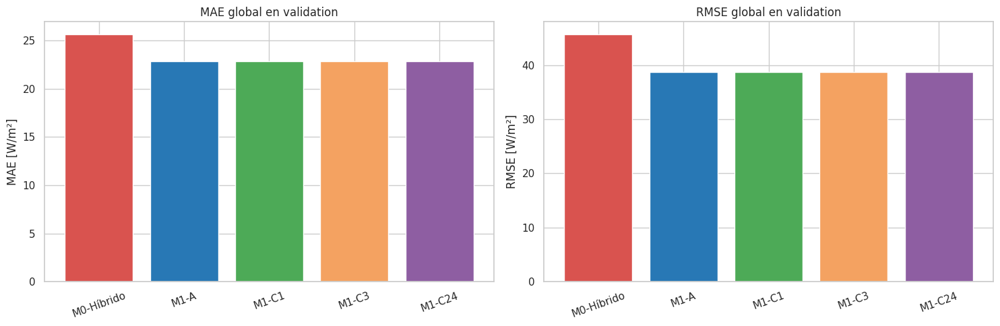

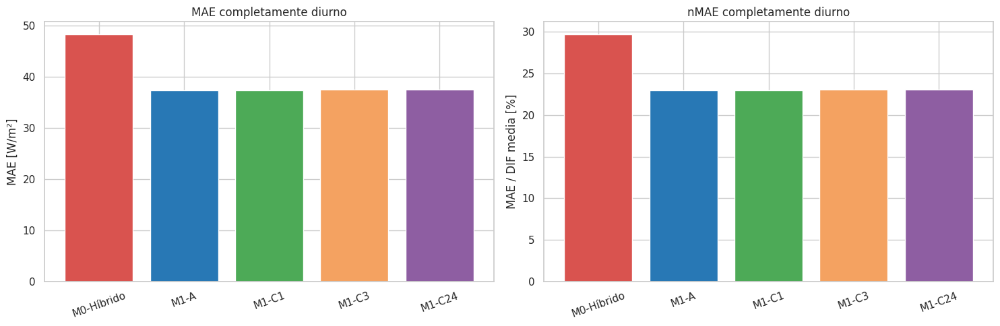

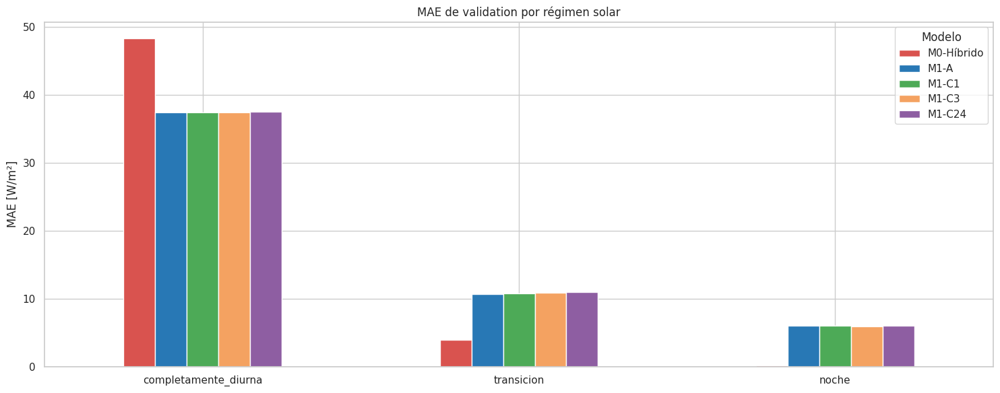


Resultados guardados en: /content/resultados_ablacion_DIF_std

Criterio de decisión:
- Si ninguna variante reduce de forma apreciable el MAE/RMSE global y diurno frente a M1-A, descartaremos DIF_std.
- Si una variante mejora, comprobaremos si la mejora se concentra en niveles altos, rampas o determinadas horas.


In [ ]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

# 1. Configuración
TARGET = "DIF_objetivo_t1"
ALPHAS = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100, 1000, 10000]
N_SPLITS_CV = 5
MODELOS_FEATURES = {
    "M1_A_Ridge_DIF": ["DIF_lag_1", "DIF_lag_2", "DIF_lag_3", "DIF_lag_24"],
    "M1_C1_Std_lag1": ["DIF_lag_1", "DIF_lag_2", "DIF_lag_3", "DIF_lag_24", "DIF_std_lag1"],
    "M1_C3_Std_lags123": [
        "DIF_lag_1",
        "DIF_lag_2",
        "DIF_lag_3",
        "DIF_lag_24",
        "DIF_std_lag1",
        "DIF_std_lag2",
        "DIF_std_lag3",
    ],
    "M1_C24_Std_lags12324": [
        "DIF_lag_1",
        "DIF_lag_2",
        "DIF_lag_3",
        "DIF_lag_24",
        "DIF_std_lag1",
        "DIF_std_lag2",
        "DIF_std_lag3",
        "DIF_std_lag24",
    ],
}
ORDEN_MODELOS = [
    "M0_Hibrida",
    "M1_A_Ridge_DIF",
    "M1_C1_Std_lag1",
    "M1_C3_Std_lags123",
    "M1_C24_Std_lags12324",
]
ETIQUETAS_MODELOS = {
    "M0_Hibrida": "M0-Híbrido",
    "M1_A_Ridge_DIF": "M1-A",
    "M1_C1_Std_lag1": "M1-C1",
    "M1_C3_Std_lags123": "M1-C3",
    "M1_C24_Std_lags12324": "M1-C24",
}
REGIMENES = ["total", "completamente_diurna", "transicion", "noche"]
CARPETA_ABLACION_STD = Path("/content/resultados_ablacion_DIF_std")
CARPETA_ABLACION_STD.mkdir(parents=True, exist_ok=True)

# 2. Construir un soporte común
todas_features = sorted(
    set(feature for features in MODELOS_FEATURES.values() for feature in features)
)
columnas_soporte = todas_features + [
    TARGET,
    "pred_M0_hibrida",
    "particion",
    "regimen_solar_objetivo",
    "instante_objetivo",
]
faltantes = set(columnas_soporte) - set(dataset_M1_std.columns)
if faltantes:
    raise KeyError(f"Faltan columnas en dataset_M1_std: {faltantes}")

base_ablacion_std = dataset_M1_std.loc[
    dataset_M1_std["particion"].isin(["train", "validation"]), columnas_soporte
].copy()
base_ablacion_std["instante_objetivo"] = pd.to_datetime(
    base_ablacion_std["instante_objetivo"], utc=True
)
columnas_no_nulas = todas_features + [TARGET, "pred_M0_hibrida", "regimen_solar_objetivo"]
base_ablacion_std = (
    base_ablacion_std.dropna(subset=columnas_no_nulas)
    .sort_values("instante_objetivo")
    .reset_index(drop=True)
)
train_std = base_ablacion_std.loc[base_ablacion_std["particion"].eq("train")].copy()
validation_std = base_ablacion_std.loc[base_ablacion_std["particion"].eq("validation")].copy()
print("Soporte común:")
print(" train:", len(train_std))
print(" validation:", len(validation_std))
print(" test: cerrado y no utilizado")

# 3. Selección temporal del alpha
def seleccionar_alpha_temporal(X, y, alphas, n_splits=5):
    tscv = TimeSeriesSplit(n_splits=n_splits)
    resultados = []
    for alpha in alphas:
        maes_folds = []
        for numero_fold, (indices_train, indices_val) in enumerate(tscv.split(X), start=1):
            pipeline = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=alpha))])
            pipeline.fit(X.iloc[indices_train], y.iloc[indices_train])
            prediccion = pipeline.predict(X.iloc[indices_val])
            mae_fold = mean_absolute_error(y.iloc[indices_val], prediccion)
            maes_folds.append(mae_fold)
            resultados.append({"alpha": alpha, "fold": numero_fold, "MAE": mae_fold})

    tabla_folds = pd.DataFrame(resultados)
    resumen = (
        tabla_folds.groupby("alpha", as_index=False)
        .agg(
            MAE_medio=("MAE", "mean"),
            MAE_std=("MAE", "std"),
            MAE_minimo=("MAE", "min"),
            MAE_maximo=("MAE", "max"),
        )
        .sort_values(["MAE_medio", "alpha"])
        .reset_index(drop=True)
    )
    mejor_alpha = resumen.iloc[0]["alpha"]
    return mejor_alpha, tabla_folds, resumen


# 4. Entrenar las cuatro variantes
modelos_std = {}
resumen_alpha_std = []
tablas_cv_std = []
predicciones_std = base_ablacion_std[
    ["instante_objetivo", "particion", "regimen_solar_objetivo", TARGET, "pred_M0_hibrida"]
].copy()
for nombre_modelo, features in MODELOS_FEATURES.items():
    X_train = train_std[features]
    y_train = train_std[TARGET]
    mejor_alpha, tabla_folds, resumen_cv = seleccionar_alpha_temporal(
        X_train, y_train, ALPHAS, n_splits=N_SPLITS_CV
    )
    modelo = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=mejor_alpha))])
    modelo.fit(X_train, y_train)
    modelos_std[nombre_modelo] = modelo
    predicciones_std[f"pred_{nombre_modelo}"] = modelo.predict(base_ablacion_std[features])
    resumen_alpha_std.append(
        {
            "modelo": nombre_modelo,
            "n_features": len(features),
            "alpha_seleccionado": mejor_alpha,
            "MAE_CV_temporal": (resumen_cv.iloc[0]["MAE_medio"]),
            "std_MAE_CV": (resumen_cv.iloc[0]["MAE_std"]),
        }
    )
    tabla_folds["modelo"] = nombre_modelo
    tablas_cv_std.append(tabla_folds)

tabla_alpha_std = pd.DataFrame(resumen_alpha_std)
tabla_cv_folds_std = pd.concat(tablas_cv_std, ignore_index=True)
print("\nAlpha seleccionado por modelo:")
display(tabla_alpha_std.round(4))

# 5. Función de métricas
def calcular_metricas_modelo(grupo, columna_prediccion, nombre_modelo, regimen):
    observado = grupo[TARGET].to_numpy()
    predicho = grupo[columna_prediccion].to_numpy()
    error = predicho - observado
    error_abs = np.abs(error)
    mae = np.mean(error_abs)
    rmse = np.sqrt(np.mean(error**2))
    media_DIF = np.mean(observado)

    # Solo se interpretará principalmente
    # en horas completamente diurnas.
    nMAE = 100 * mae / media_DIF if media_DIF > 0 else np.nan
    return {
        "modelo": nombre_modelo,
        "regimen": regimen,
        "n": len(grupo),
        "DIF_media": media_DIF,
        "MAE": mae,
        "RMSE": rmse,
        "sesgo": np.mean(error),
        "R2": r2_score(observado, predicho),
        "nMAE_media_pct": nMAE,
        "mediana_error_abs": np.median(error_abs),
        "p90_error_abs": np.quantile(error_abs, 0.90),
        "p95_error_abs": np.quantile(error_abs, 0.95),
    }


# 6. Métricas de validation por régimen
validation_pred_std = predicciones_std.loc[predicciones_std["particion"].eq("validation")].copy()
filas_metricas = []
columnas_modelo = {
    "M0_Hibrida": "pred_M0_hibrida",
    **{nombre: f"pred_{nombre}" for nombre in MODELOS_FEATURES},
}
for regimen in REGIMENES:
    if regimen == "total":
        grupo = validation_pred_std
    else:
        grupo = validation_pred_std.loc[validation_pred_std["regimen_solar_objetivo"].eq(regimen)]

    for nombre_modelo in ORDEN_MODELOS:
        filas_metricas.append(
            calcular_metricas_modelo(
                grupo=grupo,
                columna_prediccion=(columnas_modelo[nombre_modelo]),
                nombre_modelo=nombre_modelo,
                regimen=regimen,
            )
        )

tabla_metricas_std = pd.DataFrame(filas_metricas)

# 7. Añadir skill frente a M0
mae_M0_por_regimen = (
    tabla_metricas_std.loc[tabla_metricas_std["modelo"].eq("M0_Hibrida")]
    .set_index("regimen")["MAE"]
    .to_dict()
)
tabla_metricas_std["skill_MAE_vs_M0_pct"] = tabla_metricas_std.apply(
    lambda fila: (100 * (1 - fila["MAE"] / mae_M0_por_regimen[fila["regimen"]])), axis=1
)

# 8. Comparación directa contra M1-A
mae_M1A_por_regimen = (
    tabla_metricas_std.loc[tabla_metricas_std["modelo"].eq("M1_A_Ridge_DIF")]
    .set_index("regimen")["MAE"]
    .to_dict()
)
tabla_metricas_std["mejora_MAE_vs_M1A"] = tabla_metricas_std.apply(
    lambda fila: (mae_M1A_por_regimen[fila["regimen"]] - fila["MAE"]), axis=1
)
tabla_metricas_std["mejora_relativa_vs_M1A_pct"] = tabla_metricas_std.apply(
    lambda fila: (
        100
        * (mae_M1A_por_regimen[fila["regimen"]] - fila["MAE"])
        / mae_M1A_por_regimen[fila["regimen"]]
    ),
    axis=1,
)

# Orden
tabla_metricas_std["modelo"] = pd.Categorical(
    tabla_metricas_std["modelo"], categories=ORDEN_MODELOS, ordered=True
)
tabla_metricas_std["regimen"] = pd.Categorical(
    tabla_metricas_std["regimen"], categories=REGIMENES, ordered=True
)
tabla_metricas_std = tabla_metricas_std.sort_values(["regimen", "modelo"]).reset_index(drop=True)
print("\nResultados completos de validation:")
display(tabla_metricas_std.round(4))

# Tabla compacta total
tabla_validation_total_std = tabla_metricas_std.loc[
    tabla_metricas_std["regimen"].eq("total")
].copy()
print("\nComparación global de validation:")
display(
    tabla_validation_total_std[
        [
            "modelo",
            "n",
            "MAE",
            "RMSE",
            "sesgo",
            "R2",
            "mediana_error_abs",
            "p90_error_abs",
            "skill_MAE_vs_M0_pct",
            "mejora_MAE_vs_M1A",
            "mejora_relativa_vs_M1A_pct",
        ]
    ].round(4)
)

# Tabla compacta diurna
tabla_validation_diurna_std = tabla_metricas_std.loc[
    tabla_metricas_std["regimen"].eq("completamente_diurna")
].copy()
print("\nComparación completamente diurna:")
display(
    tabla_validation_diurna_std[
        [
            "modelo",
            "n",
            "DIF_media",
            "MAE",
            "nMAE_media_pct",
            "RMSE",
            "sesgo",
            "R2",
            "skill_MAE_vs_M0_pct",
            "mejora_MAE_vs_M1A",
            "mejora_relativa_vs_M1A_pct",
        ]
    ].round(4)
)

# 9. Figura 1: validation global
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
nombres = [ETIQUETAS_MODELOS[m] for m in ORDEN_MODELOS]
colores = ["#D9534F", "#2878B5", "#4DAA57", "#F4A261", "#8E5EA2"]
axes[0].bar(nombres, tabla_validation_total_std["MAE"], color=colores)
axes[0].set_title("MAE global en validation")
axes[0].set_ylabel("MAE [W/m²]")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(nombres, tabla_validation_total_std["RMSE"], color=colores)
axes[1].set_title("RMSE global en validation")
axes[1].set_ylabel("RMSE [W/m²]")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(
    CARPETA_ABLACION_STD / "01_comparacion_global_validation.png", dpi=180, bbox_inches="tight"
)
plt.show()

# 10. Figura 2: horas completamente diurnas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(nombres, tabla_validation_diurna_std["MAE"], color=colores)
axes[0].set_title("MAE completamente diurno")
axes[0].set_ylabel("MAE [W/m²]")
axes[0].tick_params(axis="x", rotation=20)
axes[1].bar(nombres, tabla_validation_diurna_std["nMAE_media_pct"], color=colores)
axes[1].set_title("nMAE completamente diurno")
axes[1].set_ylabel("MAE / DIF media [%]")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig(
    CARPETA_ABLACION_STD / "02_comparacion_diurna_validation.png", dpi=180, bbox_inches="tight"
)
plt.show()

# 11. Figura 3: MAE por régimen
tabla_plot_regimen = tabla_metricas_std.pivot(
    index="regimen", columns="modelo", values="MAE"
).reindex(["completamente_diurna", "transicion", "noche"])
tabla_plot_regimen.columns = [ETIQUETAS_MODELOS[columna] for columna in tabla_plot_regimen.columns]
tabla_plot_regimen.plot(kind="bar", figsize=(15, 6), color=colores)
plt.title("MAE de validation por régimen solar")
plt.xlabel("")
plt.ylabel("MAE [W/m²]")
plt.xticks(rotation=0)
plt.legend(title="Modelo")
plt.tight_layout()
plt.savefig(
    CARPETA_ABLACION_STD / "03_MAE_por_regimen_validation.png", dpi=180, bbox_inches="tight"
)
plt.show()

# 12. Coeficientes estandarizados
filas_coeficientes = []
for nombre_modelo, modelo in modelos_std.items():
    features = MODELOS_FEATURES[nombre_modelo]
    coeficientes = modelo.named_steps["ridge"].coef_
    for feature, coeficiente in zip(features, coeficientes):
        filas_coeficientes.append(
            {"modelo": nombre_modelo, "feature": feature, "coeficiente_estandarizado": coeficiente}
        )

tabla_coeficientes_std = pd.DataFrame(filas_coeficientes)

# 13. Guardar resultados y modelos
tabla_alpha_std.to_csv(CARPETA_ABLACION_STD / "01_alpha_CV_temporal.csv", index=False)
tabla_cv_folds_std.to_csv(CARPETA_ABLACION_STD / "02_resultados_folds_CV.csv", index=False)
tabla_metricas_std.to_csv(
    CARPETA_ABLACION_STD / "03_metricas_validation_modelo_regimen.csv", index=False
)
tabla_validation_total_std.to_csv(
    CARPETA_ABLACION_STD / "04_comparacion_global_validation.csv", index=False
)
tabla_validation_diurna_std.to_csv(
    CARPETA_ABLACION_STD / "05_comparacion_diurna_validation.csv", index=False
)
tabla_coeficientes_std.to_csv(
    CARPETA_ABLACION_STD / "06_coeficientes_estandarizados.csv", index=False
)
predicciones_std.to_csv(CARPETA_ABLACION_STD / "07_predicciones_train_validation.csv", index=False)
tabla_disponibilidad_std_lags.to_csv(
    CARPETA_ABLACION_STD / "08_disponibilidad_std_lags.csv", index=False
)
tabla_soporte_variantes_std.to_csv(CARPETA_ABLACION_STD / "09_soporte_variantes.csv", index=False)
for nombre_modelo, modelo in modelos_std.items():
    joblib.dump(modelo, CARPETA_ABLACION_STD / f"modelo_{nombre_modelo}.joblib")

configuracion_std = {
    "target": TARGET,
    "alphas": ALPHAS,
    "n_splits_CV": N_SPLITS_CV,
    "modelos_features": MODELOS_FEATURES,
    "soporte_train": len(train_std),
    "soporte_validation": len(validation_std),
    "test_utilizado": False,
}
with open(CARPETA_ABLACION_STD / "10_configuracion.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion_std, archivo, ensure_ascii=False, indent=2)

print("\nResultados guardados en:", CARPETA_ABLACION_STD)
print("\nCriterio de decisión:")
print(
    "- Si ninguna variante reduce de forma apreciable "
    "el MAE/RMSE global y diurno frente a M1-A, "
    "descartaremos DIF_std."
)
print(
    "- Si una variante mejora, comprobaremos si la "
    "mejora se concentra en niveles altos, rampas "
    "o determinadas horas."
)

**Resultados.** Las cuatro variantes seleccionan `alpha` = 0,0001 y obtienen métricas prácticamente idénticas: en validación, el MAE total oscila entre 22,82 W/m² (`M1_A_Ridge_DIF`) y 22,85 W/m² (`M1_C24_Std_lags12324`), y el de las horas completamente diurnas, entre 37,41 y 37,50 W/m². Ninguna variante con desviación estándar mejora el MAE total ni el diurno de `M1_A_Ridge_DIF`; solo reducen el MAE nocturno, como máximo en 0,12 W/m².

### 2.12 Guardado del estado del modelado Ridge

Se guardan los conjuntos de datos, las predicciones, los modelos Ridge y las tablas de resultados generados hasta este punto para poder reanudar el análisis.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import shutil
import joblib
import pandas as pd
from google.colab import files

# 1. Crear carpeta del checkpoint
marca_tiempo = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%dT%H%M%S")
nombre_checkpoint = f"checkpoint_TFM_Ridge_{marca_tiempo}"
CARPETA_CHECKPOINT = Path("/content") / nombre_checkpoint
CARPETA_CHECKPOINT.mkdir(parents=True, exist_ok=False)
carpeta_datasets = CARPETA_CHECKPOINT / "datasets"
carpeta_tablas = CARPETA_CHECKPOINT / "tablas"
carpeta_modelos = CARPETA_CHECKPOINT / "modelos"
carpeta_resultados = CARPETA_CHECKPOINT / "resultados"
for carpeta in [carpeta_datasets, carpeta_tablas, carpeta_modelos, carpeta_resultados]:
    carpeta.mkdir(parents=True, exist_ok=True)

# 2. Guardar datasets principales
datasets_principales = {
    "dataset_modelado": "01_dataset_modelado.parquet",
    "dataset_M1_std": "02_dataset_M1_std.parquet",
    "dif_std_horaria": "03_DIF_std_horaria.parquet",
    "predicciones_std": "04_predicciones_ablacion_std.parquet",
    "errores_m1_validation": "05_errores_M1_validation.parquet",
    "errores_m1_diurno": "06_errores_M1_diurnos.parquet",
    "analisis_rampas": "07_analisis_rampas_validation.parquet",
}
datasets_guardados = []
for nombre_objeto, nombre_archivo in datasets_principales.items():
    if nombre_objeto in globals():
        objeto = globals()[nombre_objeto]
        if isinstance(objeto, pd.DataFrame):
            ruta = carpeta_datasets / nombre_archivo
            objeto_exportar = objeto.copy()

            # Convertir intervalos categóricos a texto
            # para evitar incompatibilidades con parquet.
            for columna in objeto_exportar.columns:
                if isinstance(objeto_exportar[columna].dtype, pd.CategoricalDtype):
                    categorias = objeto_exportar[columna].cat.categories
                    if any(isinstance(categoria, pd.Interval) for categoria in categorias):
                        objeto_exportar[columna] = objeto_exportar[columna].astype(str)

            objeto_exportar.to_parquet(ruta, index=False)
            datasets_guardados.append(
                {
                    "objeto": nombre_objeto,
                    "archivo": str(ruta.relative_to(CARPETA_CHECKPOINT)),
                    "filas": len(objeto),
                    "columnas": len(objeto.columns),
                }
            )

# 3. Guardar todas las tablas relevantes presentes en memoria
nombres_tablas = [
    "tabla_resumen_errores",
    "resumen_comparacion_M0_M1",
    "tabla_metricas_por_regimen",
    "tabla_comparacion_por_regimen",
    "limites_quintiles",
    "tabla_error_por_quintil",
    "tabla_error_por_hora",
    "tabla_error_por_mes",
    "tabla_extremos_por_mes",
    "limites_rampa",
    "tabla_error_por_rampa",
    "tabla_correlacion_rampa_error",
    "curva_rampa_error",
    "tabla_disponibilidad_std_lags",
    "tabla_soporte_variantes_std",
    "tabla_alpha_std",
    "tabla_cv_folds_std",
    "tabla_metricas_std",
    "tabla_validation_total_std",
    "tabla_validation_diurna_std",
    "tabla_coeficientes_std",
    "tabla_umbrales_DIF",
]
tablas_guardadas = []
for nombre_tabla in nombres_tablas:
    if nombre_tabla in globals():
        tabla = globals()[nombre_tabla]
        if isinstance(tabla, pd.DataFrame):
            ruta = carpeta_tablas / f"{nombre_tabla}.csv"
            tabla.to_csv(ruta, index=False)
            tablas_guardadas.append(
                {
                    "objeto": nombre_tabla,
                    "archivo": str(ruta.relative_to(CARPETA_CHECKPOINT)),
                    "filas": len(tabla),
                    "columnas": len(tabla.columns),
                }
            )

# 4. Guardar modelos presentes en memoria
modelos_guardados = []
if "modelos_std" in globals():
    for nombre_modelo, modelo in modelos_std.items():
        ruta_modelo = carpeta_modelos / f"{nombre_modelo}.joblib"
        joblib.dump(modelo, ruta_modelo)
        modelos_guardados.append(
            {"modelo": nombre_modelo, "archivo": str(ruta_modelo.relative_to(CARPETA_CHECKPOINT))}
        )

for nombre_diccionario in ["modelos_entrenados", "modelos_ridge"]:
    if nombre_diccionario in globals():
        objeto_modelos = globals()[nombre_diccionario]
        ruta_modelos = carpeta_modelos / f"{nombre_diccionario}.joblib"
        joblib.dump(objeto_modelos, ruta_modelos)
        modelos_guardados.append(
            {
                "modelo": nombre_diccionario,
                "archivo": str(ruta_modelos.relative_to(CARPETA_CHECKPOINT)),
            }
        )

# 5. Copiar carpetas de resultados creadas
carpetas_resultados_copiadas = []
for ruta_origen in Path("/content").glob("resultados*"):
    if not ruta_origen.is_dir():
        continue

    ruta_destino = carpeta_resultados / ruta_origen.name
    if ruta_destino.exists():
        continue

    shutil.copytree(ruta_origen, ruta_destino)
    carpetas_resultados_copiadas.append(ruta_origen.name)

# 6. Guardar configuración y decisiones
configuracion_checkpoint = {
    "fecha_creacion_Madrid": marca_tiempo,
    "objetivo": "DIF(t+1)",
    "baseline_ingenuo": "M0_Hibrido",
    "baseline_supervisado": "M1_A_Ridge_DIF",
    "soporte_train_modelos": 5184,
    "soporte_validation_modelos": 1464,
    "test_evaluado": False,
    "features_M1_A": ["DIF_lag_1", "DIF_lag_2", "DIF_lag_3", "DIF_lag_24"],
    "ablacion_DIF_std": {
        "M1_C1": ["DIF_std_lag1"],
        "M1_C3": ["DIF_std_lag1", "DIF_std_lag2", "DIF_std_lag3"],
        "M1_C24": ["DIF_std_lag1", "DIF_std_lag2", "DIF_std_lag3", "DIF_std_lag24"],
    },
    "decision_DIF_std": ("No incorporar al baseline Ridge: ninguna variante mejora M1-A."),
    "parquet_original_incluido": False,
    "motivo_parquet_original_no_incluido": (
        "El usuario conserva el parquet minutal original en local."
    ),
    "datasets_guardados": datasets_guardados,
    "tablas_guardadas": tablas_guardadas,
    "modelos_guardados": modelos_guardados,
    "carpetas_resultados_copiadas": (carpetas_resultados_copiadas),
}
ruta_configuracion = CARPETA_CHECKPOINT / "CONFIGURACION_CHECKPOINT.json"
with open(ruta_configuracion, "w", encoding="utf-8") as archivo:
    json.dump(configuracion_checkpoint, archivo, ensure_ascii=False, indent=2)

# 7. Crear LEEME
texto_leeme = f"""
# Checkpoint TFM — Ridge y análisis de errores

Fecha: {marca_tiempo}

## Contenido

- Dataset de modelado utilizado por M0 y M1.
- Dataset ampliado con los retardos de DIF std dev.
- Predicciones de train y validation.
- Análisis global de errores.
- Diagnóstico por régimen solar.
- Diagnóstico por nivel de DIF, hora, mes y rampas.
- Modelos Ridge entrenados.
- Ablación M1-C1, M1-C3 y M1-C24.
- Tablas, figuras y configuraciones.

## Modelos de referencia

- M0-Híbrido: benchmark ingenuo.
- M1-A Ridge-DIF: baseline supervisado.

## Decisión sobre DIF std dev

Las variantes con uno, tres y cuatro retardos de DIF std dev no mejoran
el MAE global ni diurno de M1-A. La variable no se incorpora al baseline
Ridge. Puede conservarse como candidata para modelos no lineales posteriores.

## Estado del test

El test permanece cerrado. No se han calculado métricas nuevas ni se ha
realizado selección utilizando test.

## Parquet original

El parquet minutal original no está incluido porque se conserva localmente
y aumentaría innecesariamente el tamaño del checkpoint.
"""
with open(CARPETA_CHECKPOINT / "LEEME.md", "w", encoding="utf-8") as archivo:
    archivo.write(texto_leeme.strip())

# 8. Crear manifiesto con SHA-256
def calcular_sha256(ruta):
    hash_archivo = hashlib.sha256()
    with open(ruta, "rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            hash_archivo.update(bloque)

    return hash_archivo.hexdigest()

filas_manifiesto = []
for ruta in sorted(CARPETA_CHECKPOINT.rglob("*")):
    if ruta.is_file():
        filas_manifiesto.append(
            {
                "archivo": str(ruta.relative_to(CARPETA_CHECKPOINT)),
                "bytes": ruta.stat().st_size,
                "sha256": calcular_sha256(ruta),
            }
        )

manifiesto_checkpoint = pd.DataFrame(filas_manifiesto)
manifiesto_checkpoint.to_csv(CARPETA_CHECKPOINT / "MANIFIESTO.csv", index=False)

# 9. Comprimir
ruta_zip_sin_extension = Path("/content") / nombre_checkpoint
ruta_zip = shutil.make_archive(
    str(ruta_zip_sin_extension),
    "zip",
    root_dir=CARPETA_CHECKPOINT.parent,
    base_dir=CARPETA_CHECKPOINT.name,
)
tamano_mb = Path(ruta_zip).stat().st_size / 1024**2
print("Checkpoint creado correctamente:")
print(ruta_zip)
print(f"Tamaño: {tamano_mb:.2f} MB")
print(f"Archivos incluidos: " f"{len(manifiesto_checkpoint)}")
print("Test permanece cerrado.")

# 10. Descargar
files.download(ruta_zip)

Checkpoint creado correctamente:
/content/checkpoint_TFM_Ridge_20261001T212344.zip
Tamaño: 4.87 MB
Archivos incluidos: 101
Test permanece cerrado.


### 2.13 Ablación de la familia SWD

Se evalúa la aportación de la irradiancia de onda corta descendente (SWD) observada hasta la hora de emisión, añadiendo a los cuatro retardos de la DIF la media de la última hora (`M2_SWD_M1`), la media en los cuatro retardos (`M2_SWD_M24`) o la familia completa —media, mínimo, máximo y desviación estándar— en la última hora (`M2_SWD_F1`), en las tres últimas (`M2_SWD_F3`) o con el retardo diario adicional (`M2_SWD_F24`). Todos los modelos se ajustan con Ridge, con selección temporal de `alpha` en entrenamiento, sobre el mismo soporte.

Soporte común:
 train: 5180
 validation: 1464
 test: cerrado

Selección temporal de alpha:


,modelo,n_features,alpha,MAE_CV,std_MAE_CV
0,M1_A_Ridge_DIF,4,0.0001,25.0390,7.5104
1,M2_SWD_M1,5,0.0001,25.1543,7.5563
2,M2_SWD_M24,8,0.0001,24.8918,7.5473
3,M2_SWD_F1,8,0.0001,25.0864,7.5063
4,M2_SWD_F3,16,1.0000,25.0392,7.4713
5,M2_SWD_F24,20,1.0000,24.9527,7.4439



Validation total:


,modelo,n,MAE,RMSE,sesgo,R2,p90_error_abs,skill_MAE_vs_M0_pct,mejora_MAE_vs_M1A,mejora_relativa_vs_M1A_pct
0,M0_Hibrida,1464,25.6618,45.7271,-1.4707,0.8211,75.0533,0.0000,-2.8454,-12.4711
1,M1_A_Ridge_DIF,1464,22.8164,38.7167,0.2149,0.8718,60.2722,11.0883,0.0000,0.0000
2,M2_SWD_M1,1464,22.9343,38.6533,0.5856,0.8722,59.2802,10.6286,-0.1180,-0.5170
3,M2_SWD_M24,1464,22.4529,37.6059,1.4391,0.8790,58.3700,12.5047,0.3635,1.5931
4,M2_SWD_F1,1464,22.9223,38.7455,0.4711,0.8716,60.1760,10.6754,-0.1059,-0.4643
5,M2_SWD_F3,1464,22.6106,38.1776,0.1679,0.8753,60.6397,11.8902,0.2058,0.9019
6,M2_SWD_F24,1464,21.9717,37.2659,1.1031,0.8812,56.5468,14.3797,0.8446,3.7019



Validation completamente diurna:


,modelo,n,DIF_media,MAE,nMAE_media_pct,RMSE,sesgo,R2,skill_MAE_vs_M0_pct,mejora_MAE_vs_M1A,mejora_relativa_vs_M1A_pct
7,M0_Hibrida,765,162.7231,48.3363,29.7046,63.2042,-2.9637,0.5914,0.0000,-10.9272,-29.2099
8,M1_A_Ridge_DIF,765,162.7231,37.4091,22.9894,52.9529,-3.6928,0.7132,22.6066,0.0000,0.0000
9,M2_SWD_M1,765,162.7231,37.6280,23.1240,52.8627,-2.9120,0.7142,22.1536,-0.2189,-0.5853
10,M2_SWD_M24,765,162.7231,37.0507,22.7692,51.4973,-0.6846,0.7288,23.3480,0.3584,0.9580
11,M2_SWD_F1,765,162.7231,37.6937,23.1644,52.9679,-2.8420,0.7131,22.0177,-0.2847,-0.7609
12,M2_SWD_F3,765,162.7231,36.9027,22.6782,52.1992,-3.0328,0.7213,23.6542,0.5064,1.3537
13,M2_SWD_F24,765,162.7231,36.2288,22.2641,51.0075,-0.6540,0.7339,25.0483,1.1802,3.1550



Todos los regímenes:


,modelo,regimen,n,DIF_media,MAE,RMSE,sesgo,R2,nMAE_media_pct,mediana_error_abs,p90_error_abs,p95_error_abs,skill_MAE_vs_M0_pct,mejora_MAE_vs_M1A,mejora_relativa_vs_M1A_pct
0,M0_Hibrida,total,1464,85.2333,25.6618,45.7271,-1.4707,0.8211,30.1077,5.5917,75.0533,101.0117,0.0000,-2.8454,-12.4711
1,M1_A_Ridge_DIF,total,1464,85.2333,22.8164,38.7167,0.2149,0.8718,26.7693,7.1515,60.2722,86.8675,11.0883,0.0000,0.0000
2,M2_SWD_M1,total,1464,85.2333,22.9343,38.6533,0.5856,0.8722,26.9077,7.5636,59.2802,88.5514,10.6286,-0.1180,-0.5170
3,M2_SWD_M24,total,1464,85.2333,22.4529,37.6059,1.4391,0.8790,26.3428,8.0393,58.3700,84.4663,12.5047,0.3635,1.5931
4,M2_SWD_F1,total,1464,85.2333,22.9223,38.7455,0.4711,0.8716,26.8936,7.6231,60.1760,89.5433,10.6754,-0.1059,-0.4643
5,M2_SWD_F3,total,1464,85.2333,22.6106,38.1776,0.1679,0.8753,26.5279,7.5482,60.6397,84.4196,11.8902,0.2058,0.9019
6,M2_SWD_F24,total,1464,85.2333,21.9717,37.2659,1.1031,0.8812,25.7783,8.0277,56.5468,84.4685,14.3797,0.8446,3.7019
7,M0_Hibrida,completamente_diurna,765,162.7231,48.3363,63.2042,-2.9637,0.5914,29.7046,39.2167,99.2433,126.8767,0.0000,-10.9272,-29.2099
8,M1_A_Ridge_DIF,completamente_diurna,765,162.7231,37.4091,52.9529,-3.6928,0.7132,22.9894,26.7911,85.8375,107.1133,22.6066,0.0000,0.0000
9,M2_SWD_M1,completamente_diurna,765,162.7231,37.6280,52.8627,-2.9120,0.7142,23.1240,26.8575,87.1191,106.2436,22.1536,-0.2189,-0.5853


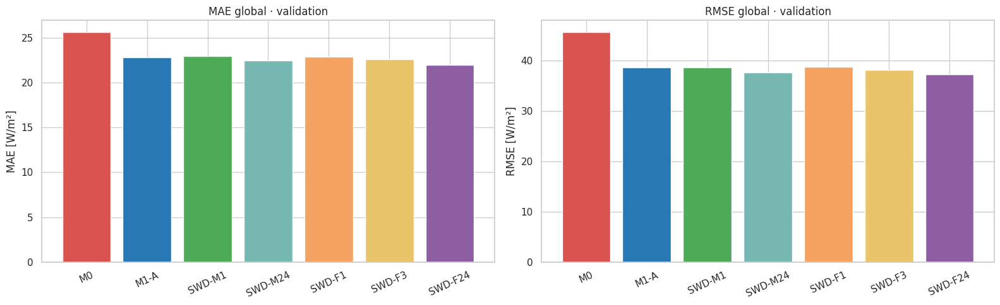

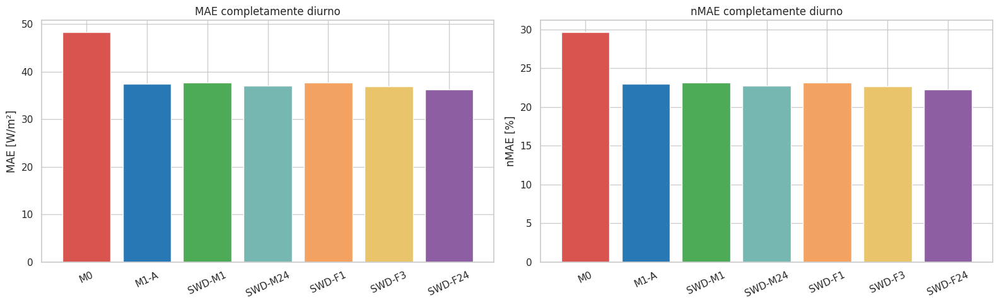


Resultados guardados en: /content/resultados_ablacion_M2_SWD


In [ ]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

# 1. Configuración
COLUMNA_TIEMPO = "Date/Time"
MIN_REGISTROS_HORA = 30
TARGET = "DIF_objetivo_t1"
COLUMNAS_SWD_ORIGINALES = {
    "media": "SWD [W/m**2]",
    "std": "SWD std dev [W/m**2]",
    "min": "SWD min [W/m**2]",
    "max": "SWD max [W/m**2]",
}
faltantes = {COLUMNA_TIEMPO, *COLUMNAS_SWD_ORIGINALES.values()} - set(datos_originales.columns)
if faltantes:
    raise KeyError(f"Faltan columnas originales: {faltantes}")

ALPHAS = [1e-4, 1e-3, 1e-2, 1e-1, 1, 10, 100, 1000, 10000]
N_SPLITS_CV = 5
CARPETA_M2_SWD = Path("/content/resultados_ablacion_M2_SWD")
CARPETA_M2_SWD.mkdir(parents=True, exist_ok=True)

# 2. Preparar las variables minutales
swdata = datos_originales[[COLUMNA_TIEMPO, *COLUMNAS_SWD_ORIGINALES.values()]].copy()
swdata["timestamp"] = pd.to_datetime(swdata[COLUMNA_TIEMPO], utc=True, errors="coerce")
swdata["hora"] = swdata["timestamp"].dt.floor("h")
for estadistico, columna_original in COLUMNAS_SWD_ORIGINALES.items():
    swdata[f"SWD_{estadistico}_minuto"] = pd.to_numeric(swdata[columna_original], errors="coerce")

# Las medias, mínimos y máximos radiométricos negativos
# se conservan como posibles offsets instrumentales.
# Una desviación estándar negativa no es válida.
swdata.loc[swdata["SWD_std_minuto"] < 0, "SWD_std_minuto"] = np.nan
swdata = swdata.dropna(subset=["hora"])

# 3. Agregar cada estadístico a escala horaria
swdata_horaria = swdata.groupby("hora", as_index=False).agg(
    SWD_media_h=("SWD_media_minuto", "mean"),
    n_SWD_media_h=("SWD_media_minuto", "count"),
    SWD_std_h=("SWD_std_minuto", "mean"),
    n_SWD_std_h=("SWD_std_minuto", "count"),
    SWD_min_h=("SWD_min_minuto", "min"),
    n_SWD_min_h=("SWD_min_minuto", "count"),
    SWD_max_h=("SWD_max_minuto", "max"),
    n_SWD_max_h=("SWD_max_minuto", "count"),
)
for estadistico in ["media", "std", "min", "max"]:
    columna_valor = f"SWD_{estadistico}_h"
    columna_n = f"n_SWD_{estadistico}_h"
    swdata_horaria.loc[swdata_horaria[columna_n] < MIN_REGISTROS_HORA, columna_valor] = np.nan

# 4. Construir retardos causales
dataset_M2_SWD = dataset_modelado.copy()
dataset_M2_SWD["instante_emision"] = pd.to_datetime(dataset_M2_SWD["instante_emision"], utc=True)
desplazamientos = {"lag1": 0, "lag2": 1, "lag3": 2, "lag24": 23}
estadisticos_SWD = ["media", "min", "max", "std"]
for nombre_lag, horas_atras in desplazamientos.items():
    clave_temporal = f"hora_busqueda_{nombre_lag}"
    dataset_M2_SWD[clave_temporal] = dataset_M2_SWD["instante_emision"] - pd.to_timedelta(
        horas_atras, unit="h"
    )
    columnas_renombradas = {"hora": clave_temporal}
    columnas_union = [clave_temporal]
    for estadistico in estadisticos_SWD:
        origen = f"SWD_{estadistico}_h"
        destino = f"SWD_{estadistico}_{nombre_lag}"
        columnas_renombradas[origen] = destino
        columnas_union.append(destino)

    tabla_union = swdata_horaria[
        ["hora", "SWD_media_h", "SWD_min_h", "SWD_max_h", "SWD_std_h"]
    ].rename(columns=columnas_renombradas)
    dataset_M2_SWD = dataset_M2_SWD.merge(
        tabla_union[columnas_union], on=clave_temporal, how="left", validate="many_to_one"
    )
    dataset_M2_SWD = dataset_M2_SWD.drop(columns=[clave_temporal])

# 5. Definir las variantes
FEATURES_M1_A = ["DIF_lag_1", "DIF_lag_2", "DIF_lag_3", "DIF_lag_24"]
SWD_MEDIA_1 = ["SWD_media_lag1"]
SWD_MEDIA_24 = ["SWD_media_lag1", "SWD_media_lag2", "SWD_media_lag3", "SWD_media_lag24"]
SWD_FAMILIA_1 = [f"SWD_{estadistico}_lag1" for estadistico in estadisticos_SWD]
SWD_FAMILIA_3 = [
    f"SWD_{estadistico}_{lag}"
    for lag in ["lag1", "lag2", "lag3"]
    for estadistico in estadisticos_SWD
]
SWD_FAMILIA_24 = [
    f"SWD_{estadistico}_{lag}"
    for lag in ["lag1", "lag2", "lag3", "lag24"]
    for estadistico in estadisticos_SWD
]
MODELOS_FEATURES_SWD = {
    "M1_A_Ridge_DIF": FEATURES_M1_A,
    "M2_SWD_M1": FEATURES_M1_A + SWD_MEDIA_1,
    "M2_SWD_M24": FEATURES_M1_A + SWD_MEDIA_24,
    "M2_SWD_F1": FEATURES_M1_A + SWD_FAMILIA_1,
    "M2_SWD_F3": FEATURES_M1_A + SWD_FAMILIA_3,
    "M2_SWD_F24": FEATURES_M1_A + SWD_FAMILIA_24,
}
ORDEN_MODELOS_SWD = ["M0_Hibrida", *MODELOS_FEATURES_SWD.keys()]
ETIQUETAS_SWD = {
    "M0_Hibrida": "M0",
    "M1_A_Ridge_DIF": "M1-A",
    "M2_SWD_M1": "SWD-M1",
    "M2_SWD_M24": "SWD-M24",
    "M2_SWD_F1": "SWD-F1",
    "M2_SWD_F3": "SWD-F3",
    "M2_SWD_F24": "SWD-F24",
}

# 6. Crear soporte común
todas_features_SWD = sorted(
    set(feature for features in MODELOS_FEATURES_SWD.values() for feature in features)
)
columnas_base = todas_features_SWD + [
    TARGET,
    "pred_M0_hibrida",
    "particion",
    "regimen_solar_objetivo",
    "instante_objetivo",
]
base_M2_SWD = (
    dataset_M2_SWD.loc[dataset_M2_SWD["particion"].isin(["train", "validation"]), columnas_base]
    .dropna(subset=(todas_features_SWD + [TARGET, "pred_M0_hibrida", "regimen_solar_objetivo"]))
    .sort_values("instante_objetivo")
    .reset_index(drop=True)
)
train_M2_SWD = base_M2_SWD.loc[base_M2_SWD["particion"].eq("train")].copy()
validation_M2_SWD = base_M2_SWD.loc[base_M2_SWD["particion"].eq("validation")].copy()
print("Soporte común:")
print(" train:", len(train_M2_SWD))
print(" validation:", len(validation_M2_SWD))
print(" test: cerrado")

# 7. Selección temporal del alpha
def seleccionar_alpha_SWD(X, y):
    tscv = TimeSeriesSplit(n_splits=N_SPLITS_CV)
    filas = []
    for alpha in ALPHAS:
        for fold, (indices_train, indices_val) in enumerate(tscv.split(X), start=1):
            pipeline = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=alpha))])
            pipeline.fit(X.iloc[indices_train], y.iloc[indices_train])
            pred = pipeline.predict(X.iloc[indices_val])
            filas.append(
                {
                    "alpha": alpha,
                    "fold": fold,
                    "MAE": mean_absolute_error(y.iloc[indices_val], pred),
                }
            )

    tabla_folds = pd.DataFrame(filas)
    resumen = (
        tabla_folds.groupby("alpha", as_index=False)
        .agg(MAE_medio=("MAE", "mean"), MAE_std=("MAE", "std"))
        .sort_values(["MAE_medio", "alpha"])
        .reset_index(drop=True)
    )
    return (resumen.iloc[0]["alpha"], tabla_folds, resumen)


# 8. Entrenar todos los modelos
modelos_M2_SWD = {}
filas_alpha = []
tablas_cv = []
predicciones_M2_SWD = base_M2_SWD[
    ["instante_objetivo", "particion", "regimen_solar_objetivo", TARGET, "pred_M0_hibrida"]
].copy()
for nombre_modelo, features in MODELOS_FEATURES_SWD.items():
    X_train = train_M2_SWD[features]
    y_train = train_M2_SWD[TARGET]
    mejor_alpha, tabla_folds, resumen_cv = seleccionar_alpha_SWD(X_train, y_train)
    modelo = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=mejor_alpha))])
    modelo.fit(X_train, y_train)
    modelos_M2_SWD[nombre_modelo] = modelo
    predicciones_M2_SWD[f"pred_{nombre_modelo}"] = modelo.predict(base_M2_SWD[features])
    filas_alpha.append(
        {
            "modelo": nombre_modelo,
            "n_features": len(features),
            "alpha": mejor_alpha,
            "MAE_CV": (resumen_cv.iloc[0]["MAE_medio"]),
            "std_MAE_CV": (resumen_cv.iloc[0]["MAE_std"]),
        }
    )
    tabla_folds["modelo"] = nombre_modelo
    tablas_cv.append(tabla_folds)

tabla_alpha_M2_SWD = pd.DataFrame(filas_alpha)
tabla_CV_M2_SWD = pd.concat(tablas_cv, ignore_index=True)
print("\nSelección temporal de alpha:")
display(tabla_alpha_M2_SWD.round(4))

# 9. Calcular métricas
def metricas_SWD(grupo, columna_pred, modelo, regimen):
    y = grupo[TARGET].to_numpy()
    pred = grupo[columna_pred].to_numpy()
    error = pred - y
    error_abs = np.abs(error)
    mae = error_abs.mean()
    media_DIF = y.mean()
    return {
        "modelo": modelo,
        "regimen": regimen,
        "n": len(grupo),
        "DIF_media": media_DIF,
        "MAE": mae,
        "RMSE": np.sqrt(np.mean(error**2)),
        "sesgo": error.mean(),
        "R2": r2_score(y, pred),
        "nMAE_media_pct": (100 * mae / media_DIF if media_DIF > 0 else np.nan),
        "mediana_error_abs": np.median(error_abs),
        "p90_error_abs": np.quantile(error_abs, 0.90),
        "p95_error_abs": np.quantile(error_abs, 0.95),
    }

columnas_prediccion = {
    "M0_Hibrida": "pred_M0_hibrida",
    **{modelo: f"pred_{modelo}" for modelo in MODELOS_FEATURES_SWD},
}
validation_pred_SWD = predicciones_M2_SWD.loc[predicciones_M2_SWD["particion"].eq("validation")]
filas_metricas = []
for regimen in ["total", "completamente_diurna", "transicion", "noche"]:
    if regimen == "total":
        grupo = validation_pred_SWD
    else:
        grupo = validation_pred_SWD.loc[validation_pred_SWD["regimen_solar_objetivo"].eq(regimen)]

    for modelo in ORDEN_MODELOS_SWD:
        filas_metricas.append(metricas_SWD(grupo, columnas_prediccion[modelo], modelo, regimen))

tabla_metricas_M2_SWD = pd.DataFrame(filas_metricas)

# 10. Mejoras frente a M0 y M1-A
mae_M0 = (
    tabla_metricas_M2_SWD.loc[tabla_metricas_M2_SWD["modelo"].eq("M0_Hibrida")]
    .set_index("regimen")["MAE"]
    .to_dict()
)
mae_M1A = (
    tabla_metricas_M2_SWD.loc[tabla_metricas_M2_SWD["modelo"].eq("M1_A_Ridge_DIF")]
    .set_index("regimen")["MAE"]
    .to_dict()
)
tabla_metricas_M2_SWD["skill_MAE_vs_M0_pct"] = tabla_metricas_M2_SWD.apply(
    lambda fila: 100 * (1 - fila["MAE"] / mae_M0[fila["regimen"]]), axis=1
)
tabla_metricas_M2_SWD["mejora_MAE_vs_M1A"] = tabla_metricas_M2_SWD.apply(
    lambda fila: (mae_M1A[fila["regimen"]] - fila["MAE"]), axis=1
)
tabla_metricas_M2_SWD["mejora_relativa_vs_M1A_pct"] = tabla_metricas_M2_SWD.apply(
    lambda fila: (100 * (mae_M1A[fila["regimen"]] - fila["MAE"]) / mae_M1A[fila["regimen"]]), axis=1
)

# 11. Mostrar resultados
tabla_total_M2_SWD = tabla_metricas_M2_SWD.loc[tabla_metricas_M2_SWD["regimen"].eq("total")]
tabla_diurna_M2_SWD = tabla_metricas_M2_SWD.loc[
    tabla_metricas_M2_SWD["regimen"].eq("completamente_diurna")
]
print("\nValidation total:")
display(
    tabla_total_M2_SWD[
        [
            "modelo",
            "n",
            "MAE",
            "RMSE",
            "sesgo",
            "R2",
            "p90_error_abs",
            "skill_MAE_vs_M0_pct",
            "mejora_MAE_vs_M1A",
            "mejora_relativa_vs_M1A_pct",
        ]
    ].round(4)
)
print("\nValidation completamente diurna:")
display(
    tabla_diurna_M2_SWD[
        [
            "modelo",
            "n",
            "DIF_media",
            "MAE",
            "nMAE_media_pct",
            "RMSE",
            "sesgo",
            "R2",
            "skill_MAE_vs_M0_pct",
            "mejora_MAE_vs_M1A",
            "mejora_relativa_vs_M1A_pct",
        ]
    ].round(4)
)
print("\nTodos los regímenes:")
display(tabla_metricas_M2_SWD.round(4))

# 12. Figuras
colores = ["#D9534F", "#2878B5", "#4DAA57", "#76B7B2", "#F4A261", "#E9C46A", "#8E5EA2"]

# Global
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
etiquetas = [ETIQUETAS_SWD[m] for m in ORDEN_MODELOS_SWD]
axes[0].bar(etiquetas, tabla_total_M2_SWD["MAE"], color=colores)
axes[0].set_title("MAE global · validation")
axes[0].set_ylabel("MAE [W/m²]")
axes[0].tick_params(axis="x", rotation=25)
axes[1].bar(etiquetas, tabla_total_M2_SWD["RMSE"], color=colores)
axes[1].set_title("RMSE global · validation")
axes[1].set_ylabel("RMSE [W/m²]")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(CARPETA_M2_SWD / "01_comparacion_global.png", dpi=180, bbox_inches="tight")
plt.show()

# Diurno
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].bar(etiquetas, tabla_diurna_M2_SWD["MAE"], color=colores)
axes[0].set_title("MAE completamente diurno")
axes[0].set_ylabel("MAE [W/m²]")
axes[0].tick_params(axis="x", rotation=25)
axes[1].bar(etiquetas, tabla_diurna_M2_SWD["nMAE_media_pct"], color=colores)
axes[1].set_title("nMAE completamente diurno")
axes[1].set_ylabel("nMAE [%]")
axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.savefig(CARPETA_M2_SWD / "02_comparacion_diurna.png", dpi=180, bbox_inches="tight")
plt.show()

# 13. Guardar resultados
tabla_alpha_M2_SWD.to_csv(CARPETA_M2_SWD / "01_alpha_CV.csv", index=False)
tabla_CV_M2_SWD.to_csv(CARPETA_M2_SWD / "02_folds_CV.csv", index=False)
tabla_metricas_M2_SWD.to_csv(CARPETA_M2_SWD / "03_metricas_validation.csv", index=False)
predicciones_M2_SWD.to_csv(CARPETA_M2_SWD / "04_predicciones_train_validation.csv", index=False)
dataset_M2_SWD.to_parquet(CARPETA_M2_SWD / "05_dataset_M2_SWD.parquet", index=False)
for nombre, modelo in modelos_M2_SWD.items():
    joblib.dump(modelo, CARPETA_M2_SWD / f"modelo_{nombre}.joblib")

with open(CARPETA_M2_SWD / "06_configuracion.json", "w", encoding="utf-8") as archivo:
    json.dump(
        {
            "target": TARGET,
            "alphas": ALPHAS,
            "modelos_features": (MODELOS_FEATURES_SWD),
            "soporte_train": len(train_M2_SWD),
            "soporte_validation": len(validation_M2_SWD),
            "test_utilizado": False,
        },
        archivo,
        ensure_ascii=False,
        indent=2,
    )

print("\nResultados guardados en:", CARPETA_M2_SWD)

**Resultados.** Sobre el soporte común (5.180 observaciones de entrenamiento y 1.464 de validación), `M2_SWD_F24` obtiene el menor MAE de validación: 21,97 W/m² frente a 22,82 W/m² de `M1_A_Ridge_DIF` (mejora del 3,70 %), con 36,23 frente a 37,41 W/m² en horas completamente diurnas y un percentil 90 del error absoluto de 56,55 frente a 60,27 W/m². `M2_SWD_M24` y `M2_SWD_F3` mejoran menos (22,45 y 22,61 W/m²), y las variantes limitadas a la última hora no mejoran la referencia.

### 2.14 Importancia de las variables SWD

Se estudia qué componentes de la familia SWD sostienen la mejora de `M2_SWD_F24` mediante sus coeficientes estandarizados y una ablación por bloques que retira cada estadístico o cada retardo, vuelve a seleccionar `alpha` en entrenamiento y mide el cambio del error en validación.

Coeficientes estandarizados:


,feature,coeficiente_estandarizado,magnitud_absoluta,familia,estadistico,lag,ranking_magnitud
0,DIF_lag_1,95.0117,95.0117,DIF,media,lag1,1
1,SWD_media_lag24,21.8607,21.8607,SWD,media,lag24,2
2,DIF_lag_24,17.5661,17.5661,DIF,media,lag24,3
3,SWD_max_lag1,11.7351,11.7351,SWD,max,lag1,4
4,SWD_max_lag3,-10.5008,10.5008,SWD,max,lag3,5
5,DIF_lag_3,-10.1153,10.1153,DIF,media,lag3,6
6,SWD_media_lag1,9.1333,9.1333,SWD,media,lag1,7
7,DIF_lag_2,-7.9002,7.9002,DIF,media,lag2,8
8,SWD_min_lag1,-7.8772,7.8772,SWD,min,lag1,9
9,SWD_min_lag24,-6.7260,6.7260,SWD,min,lag24,10



Magnitud de coeficientes por estadístico:


,estadistico,suma_abs_coef,max_abs_coef,coeficiente_neto
1,media,41.6051,21.8607,32.9281
0,max,23.7408,11.7351,-0.2707
2,min,18.4379,7.8772,-18.4379
3,std,17.3193,5.9956,-9.4968



Magnitud de coeficientes por retardo:


,lag,suma_abs_coef,max_abs_coef,coeficiente_neto
0,lag1,34.7412,11.7351,6.9955
2,lag24,33.9234,21.8607,9.7980
3,lag3,20.9791,10.5008,-13.1567
1,lag2,11.4594,6.2726,1.0858


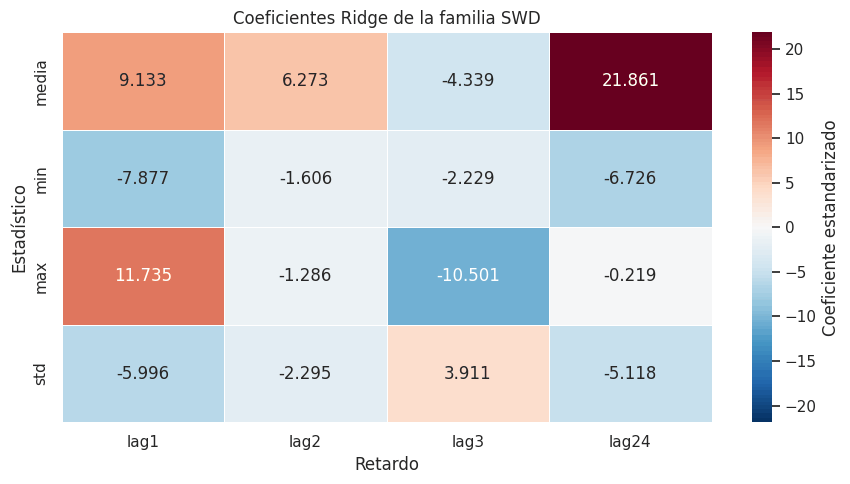


Bloques de variables que se retirarán:

sin_SWD_media:
 - SWD_media_lag1
 - SWD_media_lag2
 - SWD_media_lag3
 - SWD_media_lag24

sin_SWD_min:
 - SWD_min_lag1
 - SWD_min_lag2
 - SWD_min_lag3
 - SWD_min_lag24

sin_SWD_max:
 - SWD_max_lag1
 - SWD_max_lag2
 - SWD_max_lag3
 - SWD_max_lag24

sin_SWD_std:
 - SWD_std_lag1
 - SWD_std_lag2
 - SWD_std_lag3
 - SWD_std_lag24

sin_SWD_lag1:
 - SWD_media_lag1
 - SWD_min_lag1
 - SWD_max_lag1
 - SWD_std_lag1

sin_SWD_lag2:
 - SWD_media_lag2
 - SWD_min_lag2
 - SWD_max_lag2
 - SWD_std_lag2

sin_SWD_lag3:
 - SWD_media_lag3
 - SWD_min_lag3
 - SWD_max_lag3
 - SWD_std_lag3

sin_SWD_lag24:
 - SWD_media_lag24
 - SWD_min_lag24
 - SWD_max_lag24
 - SWD_std_lag24

Ablación por bloques:


,bloque_retirado,n_variables_retiradas,n_features_restantes,alpha_seleccionado,MAE_CV_train,MAE_validation,perdida_MAE_global,RMSE_validation,perdida_RMSE_global,MAE_diurno,perdida_MAE_diurno,variables_retiradas
0,sin_SWD_lag24,4,16,1.0000,25.0392,22.6106,0.6389,38.1776,0.9117,36.9027,0.6739,SWD_media_lag24 | SWD_min_lag24 | SWD_max_lag2...
1,sin_SWD_media,4,16,0.0001,24.9841,22.4748,0.5031,37.7445,0.4786,36.9644,0.7356,SWD_media_lag1 | SWD_media_lag2 | SWD_media_la...
2,sin_SWD_min,4,16,1.0000,25.0872,22.4586,0.4869,37.5185,0.2526,36.9492,0.7204,SWD_min_lag1 | SWD_min_lag2 | SWD_min_lag3 | S...
3,sin_SWD_std,4,16,1.0000,24.9245,22.2399,0.2682,37.5012,0.2353,36.6203,0.3915,SWD_std_lag1 | SWD_std_lag2 | SWD_std_lag3 | S...
4,sin_SWD_lag3,4,16,0.0001,24.9096,21.9831,0.0114,37.4741,0.2082,36.5661,0.3373,SWD_media_lag3 | SWD_min_lag3 | SWD_max_lag3 |...
5,sin_SWD_lag2,4,16,0.0001,24.8931,21.9549,-0.0168,37.2413,-0.0246,36.2566,0.0277,SWD_media_lag2 | SWD_min_lag2 | SWD_max_lag2 |...
6,sin_SWD_lag1,4,16,0.1000,24.9194,21.9163,-0.0554,37.3175,0.0516,36.1330,-0.0958,SWD_media_lag1 | SWD_min_lag1 | SWD_max_lag1 |...
7,sin_SWD_max,4,16,0.0001,24.8351,21.8451,-0.1266,37.2196,-0.0463,36.0350,-0.1938,SWD_max_lag1 | SWD_max_lag2 | SWD_max_lag3 | S...


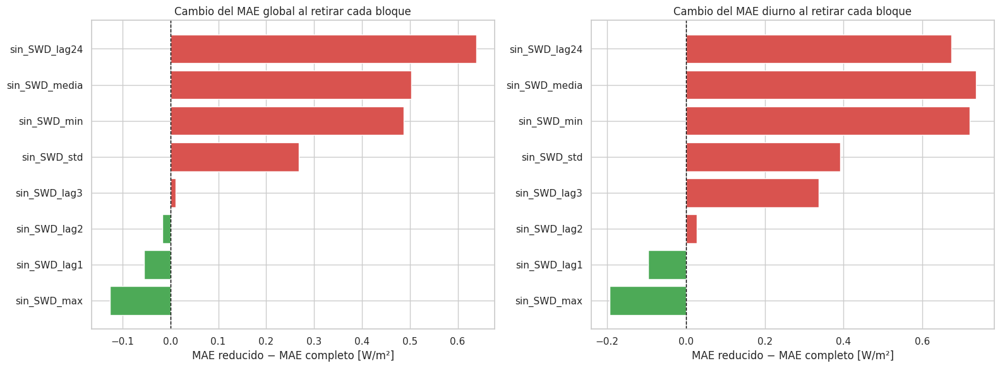


Resultados añadidos a: /content/resultados_ablacion_M2_SWD


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

sns.set_theme(style="whitegrid")
NOMBRE_MODELO_COMPLETO = "M2_SWD_F24"
modelo_completo = modelos_M2_SWD[NOMBRE_MODELO_COMPLETO]
features_completas = MODELOS_FEATURES_SWD[NOMBRE_MODELO_COMPLETO]

# 1. Coeficientes estandarizados
coeficientes = modelo_completo.named_steps["ridge"].coef_
tabla_coeficientes_F24 = pd.DataFrame(
    {"feature": features_completas, "coeficiente_estandarizado": coeficientes}
)
tabla_coeficientes_F24["magnitud_absoluta"] = tabla_coeficientes_F24[
    "coeficiente_estandarizado"
].abs()

def clasificar_feature(feature):
    if feature.startswith("DIF_"):
        return "DIF", "media"

    if feature.startswith("SWD_media"):
        return "SWD", "media"

    if feature.startswith("SWD_min"):
        return "SWD", "min"

    if feature.startswith("SWD_max"):
        return "SWD", "max"

    if feature.startswith("SWD_std"):
        return "SWD", "std"

    return "otra", "otra"

def obtener_lag(feature):
    for lag in ["lag1", "lag2", "lag3", "lag24"]:
        if feature.endswith(lag) or (f"_{lag}_" in feature):
            return lag

    # DIF_lag_1, etc.
    if feature.endswith("_1"):
        return "lag1"
    if feature.endswith("_2"):
        return "lag2"
    if feature.endswith("_3"):
        return "lag3"
    if feature.endswith("_24"):
        return "lag24"

    return "otro"

clasificaciones = tabla_coeficientes_F24["feature"].apply(clasificar_feature)
tabla_coeficientes_F24["familia"] = [valor[0] for valor in clasificaciones]
tabla_coeficientes_F24["estadistico"] = [valor[1] for valor in clasificaciones]
tabla_coeficientes_F24["lag"] = tabla_coeficientes_F24["feature"].apply(obtener_lag)
tabla_coeficientes_F24["ranking_magnitud"] = (
    tabla_coeficientes_F24["magnitud_absoluta"].rank(ascending=False, method="min").astype(int)
)
tabla_coeficientes_F24 = tabla_coeficientes_F24.sort_values(
    "magnitud_absoluta", ascending=False
).reset_index(drop=True)
print("Coeficientes estandarizados:")
display(tabla_coeficientes_F24.round(4))

# 2. Resumen de magnitudes por estadístico y lag
coef_SWD = tabla_coeficientes_F24.loc[tabla_coeficientes_F24["familia"].eq("SWD")].copy()
resumen_coef_estadistico = (
    coef_SWD.groupby("estadistico", as_index=False)
    .agg(
        suma_abs_coef=("magnitud_absoluta", "sum"),
        max_abs_coef=("magnitud_absoluta", "max"),
        coeficiente_neto=("coeficiente_estandarizado", "sum"),
    )
    .sort_values("suma_abs_coef", ascending=False)
)
resumen_coef_lag = (
    coef_SWD.groupby("lag", as_index=False)
    .agg(
        suma_abs_coef=("magnitud_absoluta", "sum"),
        max_abs_coef=("magnitud_absoluta", "max"),
        coeficiente_neto=("coeficiente_estandarizado", "sum"),
    )
    .sort_values("suma_abs_coef", ascending=False)
)
print("\nMagnitud de coeficientes por estadístico:")
display(resumen_coef_estadistico.round(4))
print("\nMagnitud de coeficientes por retardo:")
display(resumen_coef_lag.round(4))

# 3. Mapa de coeficientes SWD
orden_estadisticos = ["media", "min", "max", "std"]
orden_lags = ["lag1", "lag2", "lag3", "lag24"]
mapa_coeficientes_SWD = coef_SWD.pivot(
    index="estadistico", columns="lag", values="coeficiente_estandarizado"
).reindex(index=orden_estadisticos, columns=orden_lags)
limite = np.nanmax(np.abs(mapa_coeficientes_SWD.to_numpy()))
plt.figure(figsize=(9, 5))
sns.heatmap(
    mapa_coeficientes_SWD,
    annot=True,
    fmt=".3f",
    cmap="RdBu_r",
    center=0,
    vmin=-limite,
    vmax=limite,
    linewidths=0.5,
    cbar_kws={"label": "Coeficiente estandarizado"},
)
plt.title("Coeficientes Ridge de la familia SWD")
plt.xlabel("Retardo")
plt.ylabel("Estadístico")
plt.tight_layout()
plt.savefig(CARPETA_M2_SWD / "03_coeficientes_SWD_F24.png", dpi=180, bbox_inches="tight")
plt.show()

# 4. Definir bloques que retiraremos
bloques_retirar = {}

# Bloques por estadístico
for estadistico in orden_estadisticos:
    bloques_retirar[f"sin_SWD_{estadistico}"] = [
        feature for feature in features_completas if feature.startswith(f"SWD_{estadistico}_")
    ]

# Bloques por lag
for lag in orden_lags:
    bloques_retirar[f"sin_SWD_{lag}"] = [
        feature
        for feature in features_completas
        if (feature.startswith("SWD_") and obtener_lag(feature) == lag)
    ]

print("\nBloques de variables que se retirarán:")
for bloque, variables in bloques_retirar.items():
    print(f"\n{bloque}:")
    for variable in variables:
        print(" -", variable)

# 5. Métricas del modelo completo
X_val_completo = validation_M2_SWD[features_completas]
y_val = validation_M2_SWD[TARGET]
pred_completa = modelo_completo.predict(X_val_completo)
MAE_COMPLETO = mean_absolute_error(y_val, pred_completa)
RMSE_COMPLETO = np.sqrt(mean_squared_error(y_val, pred_completa))

# Diurno completo
mascara_diurna = validation_M2_SWD["regimen_solar_objetivo"].eq("completamente_diurna")
MAE_DIURNO_COMPLETO = mean_absolute_error(
    y_val.loc[mascara_diurna], pred_completa[mascara_diurna.to_numpy()]
)

# 6. Reentrenar retirando cada bloque
filas_ablacion = []
for nombre_bloque, variables_retiradas in bloques_retirar.items():
    features_reducidas = [
        feature for feature in features_completas if feature not in variables_retiradas
    ]
    X_train_reducido = train_M2_SWD[features_reducidas]
    y_train_reducido = train_M2_SWD[TARGET]
    alpha_reducido, _, resumen_cv_reducido = seleccionar_alpha_SWD(
        X_train_reducido, y_train_reducido
    )
    modelo_reducido = Pipeline(
        [("scaler", StandardScaler()), ("ridge", Ridge(alpha=alpha_reducido))]
    )
    modelo_reducido.fit(X_train_reducido, y_train_reducido)
    pred_reducida = modelo_reducido.predict(validation_M2_SWD[features_reducidas])
    mae_reducido = mean_absolute_error(y_val, pred_reducida)
    rmse_reducido = np.sqrt(mean_squared_error(y_val, pred_reducida))
    mae_diurno_reducido = mean_absolute_error(
        y_val.loc[mascara_diurna], pred_reducida[mascara_diurna.to_numpy()]
    )
    filas_ablacion.append(
        {
            "bloque_retirado": nombre_bloque,
            "n_variables_retiradas": len(variables_retiradas),
            "n_features_restantes": len(features_reducidas),
            "alpha_seleccionado": (alpha_reducido),
            "MAE_CV_train": (resumen_cv_reducido.iloc[0]["MAE_medio"]),
            "MAE_validation": mae_reducido,
            "perdida_MAE_global": (mae_reducido - MAE_COMPLETO),
            "RMSE_validation": rmse_reducido,
            "perdida_RMSE_global": (rmse_reducido - RMSE_COMPLETO),
            "MAE_diurno": mae_diurno_reducido,
            "perdida_MAE_diurno": (mae_diurno_reducido - MAE_DIURNO_COMPLETO),
            "variables_retiradas": (" | ".join(variables_retiradas)),
        }
    )

tabla_ablacion_bloques_SWD = (
    pd.DataFrame(filas_ablacion)
    .sort_values("perdida_MAE_global", ascending=False)
    .reset_index(drop=True)
)
print("\nAblación por bloques:")
display(tabla_ablacion_bloques_SWD.round(4))

# 7. Figura de pérdida al retirar bloques
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
tabla_plot = tabla_ablacion_bloques_SWD.sort_values("perdida_MAE_global", ascending=True)
colores_global = np.where(tabla_plot["perdida_MAE_global"] > 0, "#D9534F", "#4DAA57")
axes[0].barh(tabla_plot["bloque_retirado"], tabla_plot["perdida_MAE_global"], color=colores_global)
axes[0].axvline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Cambio del MAE global al retirar cada bloque")
axes[0].set_xlabel("MAE reducido − MAE completo [W/m²]")
colores_diurno = np.where(tabla_plot["perdida_MAE_diurno"] > 0, "#D9534F", "#4DAA57")
axes[1].barh(tabla_plot["bloque_retirado"], tabla_plot["perdida_MAE_diurno"], color=colores_diurno)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Cambio del MAE diurno al retirar cada bloque")
axes[1].set_xlabel("MAE reducido − MAE completo [W/m²]")
plt.tight_layout()
plt.savefig(CARPETA_M2_SWD / "04_ablacion_bloques_SWD_F24.png", dpi=180, bbox_inches="tight")
plt.show()

# 8. Guardar resultados
tabla_coeficientes_F24.to_csv(CARPETA_M2_SWD / "07_coeficientes_M2_SWD_F24.csv", index=False)
resumen_coef_estadistico.to_csv(CARPETA_M2_SWD / "08_coeficientes_por_estadistico.csv", index=False)
resumen_coef_lag.to_csv(CARPETA_M2_SWD / "09_coeficientes_por_lag.csv", index=False)
tabla_ablacion_bloques_SWD.to_csv(CARPETA_M2_SWD / "10_ablacion_por_bloques.csv", index=False)
print("\nResultados añadidos a:", CARPETA_M2_SWD)

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import shutil
import pandas as pd
from google.colab import files

# 1. Comprobar la carpeta de resultados
if "CARPETA_M2_SWD" not in globals():
    CARPETA_M2_SWD = Path("/content/resultados_ablacion_M2_SWD")

if not CARPETA_M2_SWD.exists():
    raise FileNotFoundError(f"No existe la carpeta {CARPETA_M2_SWD}")

marca_tiempo = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%dT%H%M%S")
nombre_exportacion = f"resultados_M2_SWD_{marca_tiempo}"
CARPETA_EXPORTACION = Path("/content") / nombre_exportacion
shutil.copytree(CARPETA_M2_SWD, CARPETA_EXPORTACION)

# 2. Asegurar que están guardadas las tablas más recientes
tablas_adicionales = {
    "11_coeficientes_completos_F24.csv": "tabla_coeficientes_F24",
    "12_resumen_coeficientes_estadistico.csv": "resumen_coef_estadistico",
    "13_resumen_coeficientes_lag.csv": "resumen_coef_lag",
    "14_ablacion_bloques_SWD.csv": "tabla_ablacion_bloques_SWD",
    "15_metricas_todos_modelos_regimen.csv": "tabla_metricas_M2_SWD",
    "16_alpha_CV_modelos_SWD.csv": "tabla_alpha_M2_SWD",
}
for nombre_archivo, nombre_objeto in tablas_adicionales.items():
    if nombre_objeto in globals():
        objeto = globals()[nombre_objeto]
        if isinstance(objeto, pd.DataFrame):
            objeto.to_csv(CARPETA_EXPORTACION / nombre_archivo, index=False)

# 3. Crear documentación
texto_leeme = f"""
# Resultados de la familia M2-Ridge-SWD

Fecha de exportación: {marca_tiempo}

## Objetivo

Evaluar si las variables históricas de radiación de onda corta descendente
aportan información predictiva adicional a M1-A Ridge-DIF para predecir
DIF(t+1).

## Modelos comparados

- M0-Híbrido: benchmark de persistencia.
- M1-A: cuatro retardos de DIF media.
- M2-SWD-M1: SWD media en t.
- M2-SWD-M24: SWD media en t, t-1, t-2 y t-23.
- M2-SWD-F1: media, mínimo, máximo y std de SWD en t.
- M2-SWD-F3: familia completa en t, t-1 y t-2.
- M2-SWD-F24: familia completa en t, t-1, t-2 y t-23.

## Modelo destacado

M2-SWD-F24 contiene:

- cuatro retardos de DIF;
- cuatro estadísticos de SWD;
- cuatro retardos por estadístico;
- veinte features en total.

## Análisis incluidos

- validación temporal del alpha;
- comparación global;
- comparación completamente diurna;
- comparación por régimen solar;
- MAE, RMSE, sesgo, R² y nMAE;
- coeficientes estandarizados;
- resumen por estadístico y por retardo;
- ablación por bloques;
- figuras;
- predicciones de train y validation;
- dataset derivado reproducible.

## Convenciones temporales

Para predecir DIF(t+1):

- lag1 = t;
- lag2 = t-1;
- lag3 = t-2;
- lag24 = t-23.

## Test

El test permanece cerrado. No se ha utilizado para seleccionar variables,
hiperparámetros ni modelos.

## Datos originales

El parquet minutal original no está incluido. El ZIP contiene el dataset
derivado utilizado para la comparación.
"""
with open(CARPETA_EXPORTACION / "00_LEEME.md", "w", encoding="utf-8") as archivo:
    archivo.write(texto_leeme.strip())

# 4. Guardar resumen de objetos y configuración
resumen_exportacion = {
    "fecha_exportacion_Madrid": marca_tiempo,
    "modelo_baseline": "M1_A_Ridge_DIF",
    "modelo_candidato": "M2_SWD_F24",
    "soporte_train": (len(train_M2_SWD) if "train_M2_SWD" in globals() else None),
    "soporte_validation": (len(validation_M2_SWD) if "validation_M2_SWD" in globals() else None),
    "test_utilizado": False,
    "features_modelos": (MODELOS_FEATURES_SWD if "MODELOS_FEATURES_SWD" in globals() else None),
}
with open(CARPETA_EXPORTACION / "17_RESUMEN_EXPORTACION.json", "w", encoding="utf-8") as archivo:
    json.dump(resumen_exportacion, archivo, ensure_ascii=False, indent=2)

# 5. Crear manifiesto con hashes
def sha256_archivo(ruta):
    hash_objeto = hashlib.sha256()
    with open(ruta, "rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            hash_objeto.update(bloque)

    return hash_objeto.hexdigest()

filas_manifiesto = []
for ruta in sorted(CARPETA_EXPORTACION.rglob("*")):
    if ruta.is_file():
        filas_manifiesto.append(
            {
                "archivo": str(ruta.relative_to(CARPETA_EXPORTACION)),
                "bytes": ruta.stat().st_size,
                "sha256": sha256_archivo(ruta),
            }
        )

manifiesto = pd.DataFrame(filas_manifiesto)
manifiesto.to_csv(CARPETA_EXPORTACION / "18_MANIFIESTO.csv", index=False)

# 6. Comprimir
ruta_zip = shutil.make_archive(
    str(Path("/content") / nombre_exportacion),
    "zip",
    root_dir=CARPETA_EXPORTACION.parent,
    base_dir=CARPETA_EXPORTACION.name,
)
tamano_mb = Path(ruta_zip).stat().st_size / 1024**2
print("ZIP creado correctamente:")
print(ruta_zip)
print(f"Tamaño: {tamano_mb:.2f} MB")
print("Archivos incluidos:", len(manifiesto))
print("Test permanece cerrado.")

# 7. Descargar
files.download(ruta_zip)

ZIP creado correctamente:
/content/resultados_M2_SWD_20261001T215603.zip
Tamaño: 1.67 MB
Archivos incluidos: 28
Test permanece cerrado.


**Resultados.** El coeficiente estandarizado de mayor magnitud sigue siendo el de `DIF_lag_1` (95,01), seguido del de `SWD_media_lag24` (21,86). En la ablación por bloques, el MAE de validación aumenta sobre todo al retirar el retardo diario de SWD (0,64 W/m² en el total y 0,67 W/m² en horas completamente diurnas), la media (0,50 W/m²) o el mínimo (0,49 W/m²), y en menor medida la desviación estándar (0,27 W/m²). Retirar los retardos 2 o 3 apenas cambia el MAE total (−0,02 y 0,01 W/m²).

### 2.15 Recuperación del estado con la familia SWD

Se recupera el conjunto horario guardado tras la ablación de SWD, con el objetivo, los retardos de la DIF y los estadísticos de SWD en los retardos 1, 2, 3 y 24, y se comprueba que contiene las columnas necesarias para construir la fracción difusa.

In [ ]:
from google.colab import files
from pathlib import Path
import tempfile
import zipfile
import json
import pandas as pd
import numpy as np

# 1. Seleccionar desde el PC:
#    resultados_M2_SWD_20261001T215603(1).zip
archivos_subidos = files.upload()
if len(archivos_subidos) != 1:
    raise ValueError("Selecciona únicamente el ZIP del checkpoint M2-SWD.")

nombre_zip = next(iter(archivos_subidos))
ruta_zip = Path("/content") / nombre_zip
if ruta_zip.suffix.lower() != ".zip":
    raise ValueError(f"El archivo seleccionado no es un ZIP: {nombre_zip}")

# 2. Extraer en un directorio temporal nuevo
directorio_checkpoint = Path(tempfile.mkdtemp(prefix="checkpoint_M2_SWD_", dir="/content"))
with zipfile.ZipFile(ruta_zip, "r") as zip_ref:
    zip_ref.extractall(directorio_checkpoint)

# 3. Localizar automáticamente los archivos principales
parquets = list(directorio_checkpoint.rglob("05_dataset_M2_SWD.parquet"))
configuraciones = list(directorio_checkpoint.rglob("06_configuracion.json"))
if len(parquets) != 1:
    raise FileNotFoundError(
        f"Se esperaba un único 05_dataset_M2_SWD.parquet y se encontraron " f"{len(parquets)}."
    )

ruta_parquet = parquets[0]

# 4. Cargar el dataset
df_m2 = pd.read_parquet(ruta_parquet)

# Alias que utilizaremos en las siguientes celdas
df_modelado = df_m2.copy()

# 5. Cargar la configuración guardada
configuracion_m2 = None
if len(configuraciones) == 1:
    with open(configuraciones[0], "r", encoding="utf-8") as archivo:
        configuracion_m2 = json.load(archivo)

print("CHECKPOINT M2-SWD CARGADO")
print("=" * 60)
print(f"ZIP: {nombre_zip}")
print(f"Parquet: {ruta_parquet.name}")
print(f"Dimensiones: {df_modelado.shape}")
print(f"Índice: {type(df_modelado.index).__name__}")
print(f"Número de columnas: {df_modelado.shape[1]}")

CHECKPOINT M2-SWD CARGADO
ZIP: resultados_M2_SWD_20261001T215603.zip
Parquet: 05_dataset_M2_SWD.parquet
Dimensiones: (8136, 46)
Índice: RangeIndex
Número de columnas: 46


In [ ]:
columnas_m2_esperadas = [
    "DIF_objetivo_t1",
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    "SWD_media_lag1",
    "SWD_min_lag1",
    "SWD_max_lag1",
    "SWD_std_lag1",
    "SWD_media_lag2",
    "SWD_min_lag2",
    "SWD_max_lag2",
    "SWD_std_lag2",
    "SWD_media_lag3",
    "SWD_min_lag3",
    "SWD_max_lag3",
    "SWD_std_lag3",
    "SWD_media_lag24",
    "SWD_min_lag24",
    "SWD_max_lag24",
    "SWD_std_lag24",
]
columnas_faltantes = [
    columna for columna in columnas_m2_esperadas if columna not in df_modelado.columns
]
print("VALIDACIÓN DEL CONTENIDO")
print("=" * 60)
if columnas_faltantes:
    print("Faltan las siguientes columnas:")
    for columna in columnas_faltantes:
        print(f"  - {columna}")
else:
    print("✓ Objetivo encontrado")
    print("✓ Cuatro retardos de DIF encontrados")
    print("✓ Familia completa de SWD encontrada")
    print("✓ Retardos 1, 2, 3 y 24 de SWD encontrados")
    print("✓ El checkpoint permite construir Kd causalmente")

if configuracion_m2 is not None:
    print("\nCONFIGURACIÓN GUARDADA")
    print(f"Target: {configuracion_m2.get('target')}")
    print(f"Soporte train: {configuracion_m2.get('soporte_train')}")
    print("Soporte validation:", configuracion_m2.get("soporte_validation"))
    print(f"Test utilizado: {configuracion_m2.get('test_utilizado')}")

print("\nPrimeras columnas disponibles:")
display(
    pd.DataFrame({"número": range(len(df_modelado.columns)), "columna": df_modelado.columns}).head(
        50
    )
)

VALIDACIÓN DEL CONTENIDO
✓ Objetivo encontrado
✓ Cuatro retardos de DIF encontrados
✓ Familia completa de SWD encontrada
✓ Retardos 1, 2, 3 y 24 de SWD encontrados
✓ El checkpoint permite construir Kd causalmente

CONFIGURACIÓN GUARDADA
Target: DIF_objetivo_t1
Soporte train: 5180
Soporte validation: 1464
Test utilizado: False

Primeras columnas disponibles:


,número,columna
0,0,instante_emision
1,1,instante_objetivo
2,2,DIF_objetivo_t1
3,3,DIF_lag_1
4,4,DIF_lag_2
5,5,DIF_lag_3
6,6,DIF_lag_24
7,7,cobertura_DIF_objetivo
8,8,cobertura_DIF_lag_1
9,9,cobertura_DIF_lag_2


### 2.16 Fracción difusa retardada

Se calcula la fracción difusa Kd = DIF/SWD en t, t−1 y t−2 (`Kd_lag1`, `Kd_lag2` y `Kd_lag3`) solo cuando la SWD media es positiva y sin recortar sus valores; no se utiliza Kd(t+1), que contiene el objetivo. Se conserva el soporte de `M2_SWD_F24`, sin exigir que Kd esté disponible.

In [ ]:
import numpy as np
import pandas as pd

df_kd = df_modelado.copy()
for lag in [1, 2, 3]:
    columna_dif = f"DIF_lag_{lag}"
    columna_swd = f"SWD_media_lag{lag}"
    columna_kd = f"Kd_lag{lag}"
    denominador_valido = (
        df_kd[columna_swd].notna() & (df_kd[columna_swd] > 0) & df_kd[columna_dif].notna()
    )
    df_kd[columna_kd] = np.nan
    df_kd.loc[denominador_valido, columna_kd] = (
        df_kd.loc[denominador_valido, columna_dif] / df_kd.loc[denominador_valido, columna_swd]
    )

# Protección frente a infinitos
columnas_kd = ["Kd_lag1", "Kd_lag2", "Kd_lag3"]
df_kd[columnas_kd] = df_kd[columnas_kd].replace([np.inf, -np.inf], np.nan)
print("FRACCIONES DIFUSAS CONSTRUIDAS")
print("=" * 60)
display(
    df_kd[columnas_kd].describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]).T.round(4)
)
print("\nPorcentaje de valores disponibles:")
display((100 * df_kd.groupby("particion")[columnas_kd].apply(lambda x: x.notna().mean())).round(2))

FRACCIONES DIFUSAS CONSTRUIDAS


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Kd_lag1,4576.0,0.6845,1.1413,-48.0,-0.2125,0.2038,0.4932,0.8578,0.9886,1.0095,1.1447,4.0
Kd_lag2,4576.0,0.6845,1.1413,-48.0,-0.2125,0.2038,0.4932,0.8578,0.9886,1.0095,1.1447,4.0
Kd_lag3,4576.0,0.6845,1.1413,-48.0,-0.2125,0.2038,0.4932,0.8578,0.9886,1.0095,1.1447,4.0



Porcentaje de valores disponibles:


,Kd_lag1,Kd_lag2,Kd_lag3
particion,,,
fuera_periodo,0.00,0.00,0.00
test,45.15,45.15,45.15
train,58.17,58.17,58.17
validation,60.52,60.52,60.52


In [ ]:
target = "DIF_objetivo_t1"
features_m2 = [
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    "SWD_media_lag1",
    "SWD_min_lag1",
    "SWD_max_lag1",
    "SWD_std_lag1",
    "SWD_media_lag2",
    "SWD_min_lag2",
    "SWD_max_lag2",
    "SWD_std_lag2",
    "SWD_media_lag3",
    "SWD_min_lag3",
    "SWD_max_lag3",
    "SWD_std_lag3",
    "SWD_media_lag24",
    "SWD_min_lag24",
    "SWD_max_lag24",
    "SWD_std_lag24",
]
features_kd = ["Kd_lag1", "Kd_lag2", "Kd_lag3"]
features_m3 = features_m2 + features_kd

# El soporte depende exclusivamente de las variables de M2 y del objetivo.
# No se exige que Kd esté disponible.
mascara_soporte = (
    df_kd["particion"].isin(["train", "validation"])
    & df_kd[features_m2 + [target]].notna().all(axis=1)
    & np.isfinite(df_kd[features_m2 + [target]]).all(axis=1)
)
df_soporte = df_kd.loc[mascara_soporte].sort_values("instante_objetivo").copy()
train_m3 = df_soporte[df_soporte["particion"] == "train"].sort_values("instante_objetivo").copy()
validation_m3 = (
    df_soporte[df_soporte["particion"] == "validation"].sort_values("instante_objetivo").copy()
)
print("SOPORTE CONSERVADO")
print("=" * 60)
print(f"Train:      {len(train_m3):,}")
print(f"Validation: {len(validation_m3):,}")
print("\nSoporte por régimen:")
display(pd.crosstab(df_soporte["particion"], df_soporte["regimen_solar_objetivo"], margins=True))
print("\nDisponibilidad de Kd por partición y régimen:")
disponibilidad_kd = (
    df_soporte.groupby(["particion", "regimen_solar_objetivo"], observed=True)[features_kd]
    .agg(lambda x: 100 * x.notna().mean())
    .round(2)
)
display(disponibilidad_kd)

SOPORTE CONSERVADO
Train:      5,180
Validation: 1,464

Soporte por régimen:


regimen_solar_objetivo,completamente_diurna,noche,transicion,All
particion,,,,
train,2617,2137,426,5180
validation,765,580,119,1464
All,3382,2717,545,6644



Disponibilidad de Kd por partición y régimen:


Kd_lag1  Kd_lag2  Kd_lag3
particion  regimen_solar_objetivo                           
train      completamente_diurna      99.16    91.13    82.92
           noche                      9.55    19.65    29.76
           transicion                51.17    49.77    49.77
validation completamente_diurna      99.87    92.68    84.71
           noche                      9.83    20.34    30.86
           transicion                54.62    49.58    49.58

**Resultados.** Kd solo puede calcularse en el 58,17 % de las filas de entrenamiento y en el 60,52 % de las de validación, con valores entre −48 y 4. En validación, `Kd_lag1` está disponible en el 99,87 % de las horas completamente diurnas, en el 54,62 % de las de transición y en el 9,83 % de las nocturnas.

### 2.17 Funciones de entrenamiento con fracción difusa

Se definen las funciones de validación temporal y entrenamiento para comparar `M2_SWD_F24` con dos variantes que añaden los tres retardos de Kd, cuyas ausencias se imputan con la mediana de entrenamiento, sin y con indicadores de ausencia. El escalado y la imputación se ajustan dentro de cada división temporal.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]

def crear_pipeline_ridge(alpha, usar_indicadores=False):
    return Pipeline(
        [
            ("imputer", SimpleImputer(strategy="median", add_indicator=usar_indicadores)),
            ("scaler", StandardScaler()),
            ("ridge", Ridge(alpha=alpha)),
        ]
    )

def seleccionar_alpha_temporal(df_train, features, target, alphas, usar_indicadores=False):
    """
    Selecciona alpha mediante cinco folds temporales de train.
    La imputación y el escalado se ajustan dentro de cada fold.
    """
    X = df_train[features]
    y = df_train[target]
    tscv = TimeSeriesSplit(n_splits=5)
    resultados = []
    for alpha in alphas:
        maes_fold = []
        for numero_fold, (idx_train, idx_val) in enumerate(tscv.split(X), start=1):
            pipeline = crear_pipeline_ridge(alpha=alpha, usar_indicadores=usar_indicadores)
            pipeline.fit(X.iloc[idx_train], y.iloc[idx_train])
            pred_fold = pipeline.predict(X.iloc[idx_val])
            mae_fold = mean_absolute_error(y.iloc[idx_val], pred_fold)
            maes_fold.append(mae_fold)

        resultados.append(
            {
                "alpha": alpha,
                "MAE_CV_medio": np.mean(maes_fold),
                "MAE_CV_std": np.std(maes_fold),
                **{f"MAE_fold_{i+1}": valor for i, valor in enumerate(maes_fold)},
            }
        )

    tabla_cv = pd.DataFrame(resultados)
    mejor_alpha = float(tabla_cv.loc[tabla_cv["MAE_CV_medio"].idxmin(), "alpha"])
    return mejor_alpha, tabla_cv

def entrenar_modelo(df_train, df_validation, features, target, alpha, usar_indicadores=False):
    modelo = crear_pipeline_ridge(alpha=alpha, usar_indicadores=usar_indicadores)
    modelo.fit(df_train[features], df_train[target])
    pred_train = modelo.predict(df_train[features])
    pred_validation = modelo.predict(df_validation[features])
    return modelo, pred_train, pred_validation

### 2.18 Selección de la regularización con fracción difusa

`M2_SWD_F24`, `M3_SWD_F24_Kd3` y `M3_SWD_F24_Kd3_Indicadores` seleccionan cada uno su `alpha` mediante validación temporal en entrenamiento y se reentrenan sobre el mismo soporte, de modo que las diferencias se deban solo a las variables añadidas.

In [ ]:
target = "DIF_objetivo_t1"

# Selección de alpha usando exclusivamente train
alpha_m2, cv_m2 = seleccionar_alpha_temporal(
    train_m3, features_m2, target, alphas, usar_indicadores=False
)
alpha_m3_kd, cv_m3_kd = seleccionar_alpha_temporal(
    train_m3, features_m3, target, alphas, usar_indicadores=False
)
alpha_m3_ind, cv_m3_ind = seleccionar_alpha_temporal(
    train_m3, features_m3, target, alphas, usar_indicadores=True
)
resumen_cv = pd.DataFrame(
    [
        {
            "modelo": "M2_SWD_F24",
            "n_features_entrada": len(features_m2),
            "indicadores_ausencia": False,
            "mejor_alpha": alpha_m2,
            "MAE_CV_medio": cv_m2["MAE_CV_medio"].min(),
        },
        {
            "modelo": "M3_SWD_F24_Kd3",
            "n_features_entrada": len(features_m3),
            "indicadores_ausencia": False,
            "mejor_alpha": alpha_m3_kd,
            "MAE_CV_medio": cv_m3_kd["MAE_CV_medio"].min(),
        },
        {
            "modelo": "M3_SWD_F24_Kd3_Indicadores",
            "n_features_entrada": len(features_m3),
            "indicadores_ausencia": True,
            "mejor_alpha": alpha_m3_ind,
            "MAE_CV_medio": cv_m3_ind["MAE_CV_medio"].min(),
        },
    ]
)
print("RESULTADOS DE LA VALIDACIÓN TEMPORAL")
display(resumen_cv.round(4))

# Entrenamiento definitivo con todo train
modelo_m2, pred_m2_train, pred_m2_val = entrenar_modelo(
    train_m3, validation_m3, features_m2, target, alpha_m2, usar_indicadores=False
)
modelo_m3_kd, pred_m3_kd_train, pred_m3_kd_val = entrenar_modelo(
    train_m3, validation_m3, features_m3, target, alpha_m3_kd, usar_indicadores=False
)
modelo_m3_ind, pred_m3_ind_train, pred_m3_ind_val = entrenar_modelo(
    train_m3, validation_m3, features_m3, target, alpha_m3_ind, usar_indicadores=True
)
train_resultados = train_m3.copy()
validation_resultados = validation_m3.copy()
train_resultados["pred_M2_SWD_F24"] = pred_m2_train
train_resultados["pred_M3_Kd3"] = pred_m3_kd_train
train_resultados["pred_M3_Kd3_Indicadores"] = pred_m3_ind_train
validation_resultados["pred_M2_SWD_F24"] = pred_m2_val
validation_resultados["pred_M3_Kd3"] = pred_m3_kd_val
validation_resultados["pred_M3_Kd3_Indicadores"] = pred_m3_ind_val
print("\nModelos entrenados correctamente.")

RESULTADOS DE LA VALIDACIÓN TEMPORAL


,modelo,n_features_entrada,indicadores_ausencia,mejor_alpha,MAE_CV_medio
0,M2_SWD_F24,20,False,1.0,24.9527
1,M3_SWD_F24_Kd3,23,False,1.0,25.0580
2,M3_SWD_F24_Kd3_Indicadores,23,True,1.0,24.5968



Modelos entrenados correctamente.


**Resultados.** Los tres modelos seleccionan `alpha` = 1. El MAE medio de la validación temporal es de 24,95 W/m² para `M2_SWD_F24`, 25,06 W/m² al añadir Kd y 24,60 W/m² al añadir Kd con indicadores de ausencia.

### 2.19 Evaluación de los modelos con fracción difusa

Se calculan el MAE, el RMSE, el sesgo, el R² y el nMAE de la persistencia híbrida, `M2_SWD_F24` y las dos variantes con Kd, globalmente y por régimen solar, en entrenamiento y validación. El desglose por régimen es necesario porque la disponibilidad de Kd varía mucho entre regímenes.

In [ ]:
def calcular_metricas(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    error = y_pred - y_real
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    sesgo = np.mean(error)
    r2 = r2_score(y_real, y_pred) if len(y_real) >= 2 and np.var(y_real) > 0 else np.nan
    media_absoluta_objetivo = np.mean(np.abs(y_real))
    nmae = 100 * mae / media_absoluta_objetivo if media_absoluta_objetivo > 0 else np.nan
    return {"n": len(y_real), "MAE": mae, "RMSE": rmse, "sesgo": sesgo, "R2": r2, "nMAE_pct": nmae}

def tabla_metricas_por_regimen(df, nombre_particion):
    modelos = {
        "M0_Hibrido": "pred_M0_hibrida",
        "M2_SWD_F24": "pred_M2_SWD_F24",
        "M3_Kd3": "pred_M3_Kd3",
        "M3_Kd3_Indicadores": "pred_M3_Kd3_Indicadores",
    }
    subconjuntos = {
        "total": pd.Series(True, index=df.index),
        "completamente_diurna": df["regimen_solar_objetivo"] == "completamente_diurna",
        "transicion": df["regimen_solar_objetivo"] == "transicion",
        "noche": df["regimen_solar_objetivo"] == "noche",
    }
    filas = []
    for regimen, mascara in subconjuntos.items():
        datos_regimen = df.loc[mascara]
        for modelo, columna_prediccion in modelos.items():
            mascara_valida = (
                datos_regimen[target].notna() & datos_regimen[columna_prediccion].notna()
            )
            datos_validos = datos_regimen.loc[mascara_valida]
            if len(datos_validos) == 0:
                continue

            filas.append(
                {
                    "particion": nombre_particion,
                    "regimen": regimen,
                    "modelo": modelo,
                    **calcular_metricas(datos_validos[target], datos_validos[columna_prediccion]),
                }
            )

    return pd.DataFrame(filas)

metricas_train = tabla_metricas_por_regimen(train_resultados, "train")
metricas_validation = tabla_metricas_por_regimen(validation_resultados, "validation")
tabla_metricas_kd = pd.concat([metricas_train, metricas_validation], ignore_index=True)
print("MÉTRICAS COMPLETAS")
display(tabla_metricas_kd.sort_values(["particion", "regimen", "MAE"]).round(4))
print("\nRESULTADOS PRINCIPALES EN VALIDATION")
display(
    tabla_metricas_kd[tabla_metricas_kd["particion"] == "validation"]
    .sort_values(["regimen", "MAE"])
    .round(4)
)

# Comparación directa frente a M2
comparacion_validacion = (
    tabla_metricas_kd[
        (tabla_metricas_kd["particion"] == "validation")
        & tabla_metricas_kd["modelo"].isin(["M2_SWD_F24", "M3_Kd3", "M3_Kd3_Indicadores"])
    ]
    .pivot(index="regimen", columns="modelo", values="MAE")
    .reset_index()
)
comparacion_validacion["mejora_M3_Kd3"] = (
    comparacion_validacion["M2_SWD_F24"] - comparacion_validacion["M3_Kd3"]
)
comparacion_validacion["mejora_M3_Indicadores"] = (
    comparacion_validacion["M2_SWD_F24"] - comparacion_validacion["M3_Kd3_Indicadores"]
)
print("\nMEJORA DE MAE FRENTE A M2")
print("Un valor positivo significa mejora.")
display(comparacion_validacion.round(4))

MÉTRICAS COMPLETAS


,particion,regimen,modelo,n,MAE,RMSE,sesgo,R2,nMAE_pct
7,train,completamente_diurna,M3_Kd3_Indicadores,2617,37.3244,51.7321,-1.0992,0.7852,23.5896
6,train,completamente_diurna,M3_Kd3,2617,38.0250,52.2769,-3.4287,0.7807,24.0324
5,train,completamente_diurna,M2_SWD_F24,2617,38.0574,52.2965,-3.4297,0.7805,24.0529
4,train,completamente_diurna,M0_Hibrido,2617,49.0029,63.9822,-2.8446,0.6714,30.9706
12,train,noche,M0_Hibrido,2137,0.2462,0.4169,-0.0025,-0.6445,29.1900
15,train,noche,M3_Kd3_Indicadores,2137,4.2598,5.4537,0.1936,-280.4803,505.0318
13,train,noche,M2_SWD_F24,2137,5.5677,6.1179,3.2930,-353.2211,660.0981
14,train,noche,M3_Kd3,2137,5.6351,6.1871,3.3072,-361.2685,668.0883
3,train,total,M3_Kd3_Indicadores,5180,21.4050,37.1696,0.0000,0.8898,26.4974
1,train,total,M2_SWD_F24,5180,22.1910,37.5385,0.0000,0.8876,27.4704



RESULTADOS PRINCIPALES EN VALIDATION


,particion,regimen,modelo,n,MAE,RMSE,sesgo,R2,nMAE_pct
23,validation,completamente_diurna,M3_Kd3_Indicadores,765,35.3194,50.3043,1.2329,0.7412,21.7052
22,validation,completamente_diurna,M3_Kd3,765,36.1564,50.9557,-0.6535,0.7344,22.2196
21,validation,completamente_diurna,M2_SWD_F24,765,36.2288,51.0075,-0.6540,0.7339,22.2641
20,validation,completamente_diurna,M0_Hibrido,765,48.3363,63.2042,-2.9637,0.5914,29.7046
28,validation,noche,M0_Hibrido,580,0.2047,0.4385,-0.0002,-0.9107,20.8761
31,validation,noche,M3_Kd3_Indicadores,580,4.5420,6.2646,-0.5019,-388.9790,463.1152
29,validation,noche,M2_SWD_F24,580,5.8488,6.4482,2.7224,-412.1604,596.3581
30,validation,noche,M3_Kd3,580,5.9861,6.7898,2.6984,-457.1022,610.3658
19,validation,total,M3_Kd3_Indicadores,1464,21.2995,37.1065,0.7379,0.8822,24.7623
17,validation,total,M2_SWD_F24,1464,21.9717,37.2659,1.1031,0.8812,25.5438



MEJORA DE MAE FRENTE A M2
Un valor positivo significa mejora.


modelo,regimen,M2_SWD_F24,M3_Kd3,M3_Kd3_Indicadores,mejora_M3_Kd3,mejora_M3_Indicadores
0,completamente_diurna,36.2288,36.1564,35.3194,0.0725,0.9095
1,noche,5.8488,5.9861,4.5420,-0.1374,1.3068
2,total,21.9717,22.1070,21.2995,-0.1353,0.6723
3,transicion,8.9012,10.3620,12.8466,-1.4608,-3.9453


**Resultados.** En validación, añadir Kd imputado no mejora `M2_SWD_F24` (MAE total de 22,11 frente a 21,97 W/m²), mientras que la variante con indicadores de ausencia (`M3_Kd3_Indicadores`) lo reduce a 21,30 W/m², y el de las horas completamente diurnas, de 36,23 a 35,32 W/m². En transición, en cambio, ambas variantes empeoran (10,36 y 12,85 W/m² frente a 8,90 W/m² de `M2_SWD_F24` y 3,97 W/m² de la persistencia híbrida).

### 2.20 Indicadores de Kd no calculable

Se construyen tres variables binarias (`Kd_ausente_lag1`, `Kd_ausente_lag2` y `Kd_ausente_lag3`) que valen 1 cuando Kd no pudo calcularse por ser la SWD nula o negativa. Se utilizarán junto con las variables de `M2_SWD_F24`, sin los valores numéricos de Kd (23 variables en total), para aislar la aportación de los indicadores.

In [ ]:
columnas_indicadores = []
for lag in [1, 2, 3]:
    columna_kd = f"Kd_lag{lag}"
    columna_indicador = f"Kd_ausente_lag{lag}"

    # 1 = Kd no calculable
    # 0 = Kd calculable
    train_m3[columna_indicador] = train_m3[columna_kd].isna().astype(int)
    validation_m3[columna_indicador] = validation_m3[columna_kd].isna().astype(int)
    columnas_indicadores.append(columna_indicador)

features_m3_solo_indicadores = features_m2 + columnas_indicadores
print("INDICADORES CONSTRUIDOS")
print("=" * 60)
print("Variables añadidas:")
for columna in columnas_indicadores:
    print(f"  - {columna}")

print(f"\nNúmero de variables de entrada: " f"{len(features_m3_solo_indicadores)}")
print("\nPorcentaje de ausencia de Kd en train:")
display(
    (100 * train_m3[columnas_indicadores].mean()).rename("porcentaje_ausente").to_frame().round(2)
)
print("\nPorcentaje de ausencia por régimen en validation:")
display(
    (
        100
        * validation_m3.groupby("regimen_solar_objetivo", observed=True)[
            columnas_indicadores
        ].mean()
    ).round(2)
)

INDICADORES CONSTRUIDOS
Variables añadidas:
  - Kd_ausente_lag1
  - Kd_ausente_lag2
  - Kd_ausente_lag3

Número de variables de entrada: 23

Porcentaje de ausencia de Kd en train:


,porcentaje_ausente
Kd_ausente_lag1,41.76
Kd_ausente_lag2,41.76
Kd_ausente_lag3,41.74



Porcentaje de ausencia por régimen en validation:


,Kd_ausente_lag1,Kd_ausente_lag2,Kd_ausente_lag3
regimen_solar_objetivo,,,
completamente_diurna,0.13,7.32,15.29
noche,90.17,79.66,69.14
transicion,45.38,50.42,50.42


**Resultados.** En validación, `Kd_ausente_lag1` vale 1 en el 90,17 % de las horas nocturnas, en el 45,38 % de las de transición y en el 0,13 % de las completamente diurnas.

### 2.21 Modelo con solo indicadores

Se entrena `M3_SoloIndicadores` con la misma selección temporal de `alpha` y el mismo soporte que los modelos anteriores, como ablación que retira los valores de Kd y conserva solo sus indicadores de disponibilidad.

In [ ]:
alpha_m3_solo_ind, cv_m3_solo_ind = seleccionar_alpha_temporal(
    train_m3, features_m3_solo_indicadores, target, alphas, usar_indicadores=False
)
modelo_m3_solo_ind, pred_solo_ind_train, pred_solo_ind_val = entrenar_modelo(
    train_m3,
    validation_m3,
    features_m3_solo_indicadores,
    target,
    alpha_m3_solo_ind,
    usar_indicadores=False,
)
train_resultados["pred_M3_SoloIndicadores"] = pred_solo_ind_train
validation_resultados["pred_M3_SoloIndicadores"] = pred_solo_ind_val
print("MODELO ENTRENADO")
print("=" * 60)
print(f"Mejor alpha: {alpha_m3_solo_ind}")
print("MAE medio de CV temporal:", round(cv_m3_solo_ind["MAE_CV_medio"].min(), 4))

MODELO ENTRENADO
Mejor alpha: 1.0
MAE medio de CV temporal: 24.5389


### 2.22 Comparación de las formulaciones con fracción difusa

Se comparan en validación, globalmente y por régimen solar, la persistencia híbrida, `M2_SWD_F24` y las tres variantes con fracción difusa: valores imputados, valores con indicadores y solo indicadores. Después se guarda y se recupera el estado del análisis.

In [ ]:
def tabla_metricas_modelos(df, particion):
    modelos = {
        "M0_Hibrido": "pred_M0_hibrida",
        "M2_SWD_F24": "pred_M2_SWD_F24",
        "M3_Kd3": "pred_M3_Kd3",
        "M3_Kd3_Indicadores": "pred_M3_Kd3_Indicadores",
        "M3_SoloIndicadores": "pred_M3_SoloIndicadores",
    }
    subconjuntos = {
        "total": pd.Series(True, index=df.index),
        "completamente_diurna": df["regimen_solar_objetivo"] == "completamente_diurna",
        "transicion": df["regimen_solar_objetivo"] == "transicion",
        "noche": df["regimen_solar_objetivo"] == "noche",
    }
    filas = []
    for regimen, mascara in subconjuntos.items():
        datos_regimen = df.loc[mascara]
        for nombre_modelo, columna_prediccion in modelos.items():
            datos_validos = datos_regimen[
                datos_regimen[target].notna() & datos_regimen[columna_prediccion].notna()
            ]
            if len(datos_validos) == 0:
                continue

            filas.append(
                {
                    "particion": particion,
                    "regimen": regimen,
                    "modelo": nombre_modelo,
                    **calcular_metricas(datos_validos[target], datos_validos[columna_prediccion]),
                }
            )

    return pd.DataFrame(filas)

metricas_train_final = tabla_metricas_modelos(train_resultados, "train")
metricas_validation_final = tabla_metricas_modelos(validation_resultados, "validation")
tabla_metricas_final = pd.concat(
    [metricas_train_final, metricas_validation_final], ignore_index=True
)
print("RESULTADOS DE VALIDATION")
print("=" * 60)
display(
    tabla_metricas_final[tabla_metricas_final["particion"] == "validation"]
    .sort_values(["regimen", "MAE"])
    .round(4)
)

# Tabla compacta de MAE
comparacion_mae = (
    tabla_metricas_final[tabla_metricas_final["particion"] == "validation"]
    .pivot(index="regimen", columns="modelo", values="MAE")
    .reset_index()
)
comparacion_mae["diferencia_completo_menos_solo_ind"] = (
    comparacion_mae["M3_Kd3_Indicadores"] - comparacion_mae["M3_SoloIndicadores"]
)
print("\nCOMPARACIÓN DEL MODELO COMPLETO FRENTE A SOLO INDICADORES")
print("Una diferencia positiva indica que el modelo con solo indicadores obtiene menor MAE.")
display(comparacion_mae.round(4))

RESULTADOS DE VALIDATION


,particion,regimen,modelo,n,MAE,RMSE,sesgo,R2,nMAE_pct
28,validation,completamente_diurna,M3_Kd3_Indicadores,765,35.3194,50.3043,1.2329,0.7412,21.7052
29,validation,completamente_diurna,M3_SoloIndicadores,765,35.3943,50.3596,1.2543,0.7406,21.7512
27,validation,completamente_diurna,M3_Kd3,765,36.1564,50.9557,-0.6535,0.7344,22.2196
26,validation,completamente_diurna,M2_SWD_F24,765,36.2288,51.0075,-0.6540,0.7339,22.2641
25,validation,completamente_diurna,M0_Hibrido,765,48.3363,63.2042,-2.9637,0.5914,29.7046
35,validation,noche,M0_Hibrido,580,0.2047,0.4385,-0.0002,-0.9107,20.8761
39,validation,noche,M3_SoloIndicadores,580,4.4490,5.6878,-0.4008,-320.4678,453.6322
38,validation,noche,M3_Kd3_Indicadores,580,4.5420,6.2646,-0.5019,-388.9790,463.1152
36,validation,noche,M2_SWD_F24,580,5.8488,6.4482,2.7224,-412.1604,596.3581
37,validation,noche,M3_Kd3,580,5.9861,6.7898,2.6984,-457.1022,610.3658



COMPARACIÓN DEL MODELO COMPLETO FRENTE A SOLO INDICADORES
Una diferencia positiva indica que el modelo con solo indicadores obtiene menor MAE.


modelo,regimen,M0_Hibrido,M2_SWD_F24,M3_Kd3,M3_Kd3_Indicadores,M3_SoloIndicadores,diferencia_completo_menos_solo_ind
0,completamente_diurna,48.3363,36.2288,36.1564,35.3194,35.3943,-0.0749
1,noche,0.2047,5.8488,5.9861,4.5420,4.4490,0.0930
2,total,25.6618,21.9717,22.1070,21.2995,21.1272,0.1723
3,transicion,3.9738,8.9012,10.3620,12.8466,10.6987,2.1479


In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import shutil
import joblib
import pandas as pd
import numpy as np

# 1. Directorio de exportación
marca_temporal = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%dT%H%M%S")
nombre_carpeta = f"checkpoint_M3_Kd_indicadores_{marca_temporal}"
directorio_salida = Path("/content") / nombre_carpeta
directorio_salida.mkdir(parents=True, exist_ok=False)

# 2. Construir dataset reproducible del soporte utilizado
df_checkpoint = df_soporte.copy()

# Indicadores explícitos
for lag in [1, 2, 3]:
    columna_indicador = f"Kd_ausente_lag{lag}"
    df_checkpoint[columna_indicador] = df_checkpoint[f"Kd_lag{lag}"].isna().astype(int)

# Predicciones generadas en train
columnas_pred_train = [
    "pred_M2_SWD_F24",
    "pred_M3_Kd3",
    "pred_M3_Kd3_Indicadores",
    "pred_M3_SoloIndicadores",
]
for columna in columnas_pred_train:
    df_checkpoint.loc[train_resultados.index, columna] = train_resultados[columna]

# Predicciones generadas en validation
for columna in columnas_pred_train:
    df_checkpoint.loc[validation_resultados.index, columna] = validation_resultados[columna]

# Orden cronológico
df_checkpoint = df_checkpoint.sort_values("instante_objetivo").reset_index(drop=True)

# Dataset principal
df_checkpoint.to_parquet(directorio_salida / "01_dataset_checkpoint_M3.parquet", index=False)

# Versiones separadas
train_exportado = df_checkpoint[df_checkpoint["particion"] == "train"].copy()
validation_exportado = df_checkpoint[df_checkpoint["particion"] == "validation"].copy()
train_exportado.to_parquet(directorio_salida / "02_train_checkpoint.parquet", index=False)
validation_exportado.to_parquet(directorio_salida / "03_validation_checkpoint.parquet", index=False)

# 3. Guardar métricas y comparaciones
tabla_metricas_final.to_csv(
    directorio_salida / "04_metricas_todos_modelos_regimen.csv", index=False
)
comparacion_mae.to_csv(directorio_salida / "05_comparacion_MAE_validation.csv", index=False)
resumen_cv.to_csv(directorio_salida / "06_resumen_CV_modelos_Kd.csv", index=False)

# CV detallada de cada modelo
cv_m2.assign(modelo="M2_SWD_F24").to_csv(directorio_salida / "07_CV_M2_SWD_F24.csv", index=False)
cv_m3_kd.assign(modelo="M3_Kd3").to_csv(directorio_salida / "08_CV_M3_Kd3.csv", index=False)
cv_m3_ind.assign(modelo="M3_Kd3_Indicadores").to_csv(
    directorio_salida / "09_CV_M3_Kd3_Indicadores.csv", index=False
)
cv_m3_solo_ind.assign(modelo="M3_SoloIndicadores").to_csv(
    directorio_salida / "10_CV_M3_SoloIndicadores.csv", index=False
)

# Disponibilidad de Kd
disponibilidad_exportar = (
    df_checkpoint.groupby(["particion", "regimen_solar_objetivo"], observed=True)[
        ["Kd_lag1", "Kd_lag2", "Kd_lag3"]
    ]
    .agg(lambda x: 100 * x.notna().mean())
    .reset_index()
)
disponibilidad_exportar.to_csv(
    directorio_salida / "11_disponibilidad_Kd_por_regimen.csv", index=False
)

# 4. Guardar los modelos ajustados
joblib.dump(modelo_m2, directorio_salida / "modelo_M2_SWD_F24.joblib")
joblib.dump(modelo_m3_kd, directorio_salida / "modelo_M3_Kd3.joblib")
joblib.dump(modelo_m3_ind, directorio_salida / "modelo_M3_Kd3_Indicadores.joblib")
joblib.dump(modelo_m3_solo_ind, directorio_salida / "modelo_M3_SoloIndicadores.joblib")

# 5. Configuración completa
configuracion = {
    "fecha_exportacion": marca_temporal,
    "objetivo": target,
    "test_utilizado": False,
    "convencion_temporal": {
        "lag1": "t",
        "lag2": "t-1",
        "lag3": "t-2",
        "lag24": "t-23",
        "objetivo": "DIF(t+1)",
    },
    "definicion_Kd": {
        "formula": "DIF_lag / SWD_media_lag",
        "condicion_calculo": "SWD_media_lag > 0",
        "recorte_aplicado": False,
        "Kd_superior_1_eliminado": False,
        "tratamiento_ausencias": (
            "Mediana aprendida en train y, según el modelo, indicador binario de ausencia"
        ),
    },
    "features_M2": features_m2,
    "features_Kd": features_kd,
    "features_indicadores": columnas_indicadores,
    "features_M3_Kd": features_m3,
    "features_M3_SoloIndicadores": features_m3_solo_indicadores,
    "alphas_evaluados": alphas,
    "mejores_alphas": {
        "M2_SWD_F24": alpha_m2,
        "M3_Kd3": alpha_m3_kd,
        "M3_Kd3_Indicadores": alpha_m3_ind,
        "M3_SoloIndicadores": alpha_m3_solo_ind,
    },
    "soporte": {
        "train": int(len(train_exportado)),
        "validation": int(len(validation_exportado)),
        "total": int(len(df_checkpoint)),
    },
    "conclusion_provisional": {
        "Kd_numerico": ("No demuestra aportacion incremental relevante en Ridge"),
        "indicadores": (
            "Mejoran globalmente y en horas completamente diurnas, pero empeoran transicion"
        ),
        "siguiente_paso": (
            "Evaluar modelo enrutado: Ridge en horas completamente "
            "diurnas y persistencia diaria en transicion/noche"
        ),
    },
}
with open(directorio_salida / "12_configuracion.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, ensure_ascii=False, indent=2)

# 6. Archivo de lectura
texto_leeme = f"""
# Checkpoint M3 — Kd e indicadores

Fecha de exportación: {marca_temporal}

## Objetivo

Predecir DIF(t+1) utilizando exclusivamente información disponible
hasta el instante t.

## Soporte

- Train: {len(train_exportado):,} observaciones.
- Validation: {len(validation_exportado):,} observaciones.
- Test utilizado: no.

## Modelos guardados

1. M2-SWD-F24:
   cuatro retardos de DIF y dieciséis variables de SWD.

2. M3-Kd3:
   M2 más Kd en los retardos 1, 2 y 3.
   Las ausencias se imputan mediante la mediana de train.

3. M3-Kd3-Indicadores:
   M3-Kd3 más indicadores automáticos de ausencia.

4. M3-SoloIndicadores:
   M2 más tres indicadores explícitos de Kd no calculable,
   sin introducir los valores numéricos de Kd.

## Conclusión provisional

Los valores numéricos de Kd no demuestran una mejora incremental
relevante en Ridge. La mejora global procede principalmente de los
indicadores que señalan si SWD era positiva en los retardos recientes.

Los indicadores mejoran el resultado global y completamente diurno,
pero perjudican las horas de transición. M0-Híbrido continúa siendo
claramente superior durante transición y noche.

## Siguiente paso

Evaluar una arquitectura enrutada por el régimen solar conocido de
t+1:

- Ridge supervisado para horas completamente diurnas.
- Persistencia diaria para transición y noche.

Después se comparará un Ridge global aplicado solo al día frente a un
Ridge entrenado exclusivamente con horas completamente diurnas.
"""
(directorio_salida / "00_LEEME.md").write_text(texto_leeme.strip(), encoding="utf-8")

# 7. Manifiesto de archivos
archivos_manifesto = []
for ruta in sorted(directorio_salida.iterdir()):
    if ruta.is_file():
        archivos_manifesto.append({"archivo": ruta.name, "tamano_bytes": ruta.stat().st_size})

pd.DataFrame(archivos_manifesto).to_csv(directorio_salida / "13_MANIFIESTO.csv", index=False)

# 8. Crear y descargar ZIP
ruta_zip = shutil.make_archive(
    base_name=str(Path("/content") / nombre_carpeta),
    format="zip",
    root_dir=directorio_salida.parent,
    base_dir=directorio_salida.name,
)
print("CHECKPOINT CREADO CORRECTAMENTE")
print("=" * 60)
print(f"Carpeta: {directorio_salida}")
print(f"ZIP: {ruta_zip}")
print(f"Train: {len(train_exportado):,}")
print(f"Validation: {len(validation_exportado):,}")
print("Test utilizado: NO")
from google.colab import files
files.download(ruta_zip)

CHECKPOINT CREADO CORRECTAMENTE
Carpeta: /content/checkpoint_M3_Kd_indicadores_20261002T175603
ZIP: /content/checkpoint_M3_Kd_indicadores_20261002T175603.zip
Train: 5,180
Validation: 1,464
Test utilizado: NO


In [ ]:
from google.colab import files
from pathlib import Path
import tempfile
import zipfile
import json
import joblib
import pandas as pd
import numpy as np

# Selecciona:
# checkpoint_M3_Kd_indicadores_20261002T175603.zip
archivos_subidos = files.upload()
if len(archivos_subidos) != 1:
    raise ValueError("Selecciona únicamente el ZIP del checkpoint M3.")

nombre_zip = next(iter(archivos_subidos))
ruta_zip = Path("/content") / nombre_zip
if ruta_zip.suffix.lower() != ".zip":
    raise ValueError(f"El archivo seleccionado no es un ZIP: {nombre_zip}")

directorio_checkpoint = Path(tempfile.mkdtemp(prefix="checkpoint_M3_", dir="/content"))
with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:
    archivo_zip.extractall(directorio_checkpoint)

# El ZIP contiene una carpeta interior: la localizamos automáticamente
archivos_configuracion = list(directorio_checkpoint.rglob("12_configuracion.json"))
if len(archivos_configuracion) != 1:
    raise FileNotFoundError("No se ha encontrado exactamente un archivo 12_configuracion.json.")

carpeta_resultados = archivos_configuracion[0].parent
print("ZIP EXTRAÍDO CORRECTAMENTE")
print("=" * 60)
print(f"Archivo: {nombre_zip}")
print(f"Carpeta: {carpeta_resultados}")

ZIP EXTRAÍDO CORRECTAMENTE
Archivo: checkpoint_M3_Kd_indicadores_20261002T175603.zip
Carpeta: /content/checkpoint_M3_p352o1y8/checkpoint_M3_Kd_indicadores_20261002T175603


In [ ]:
# Datasets
df_checkpoint = pd.read_parquet(carpeta_resultados / "01_dataset_checkpoint_M3.parquet")
train_m3 = pd.read_parquet(carpeta_resultados / "02_train_checkpoint.parquet")
validation_m3 = pd.read_parquet(carpeta_resultados / "03_validation_checkpoint.parquet")

# Alias utilizados en las celdas anteriores
df_soporte = df_checkpoint.copy()
train_resultados = train_m3.copy()
validation_resultados = validation_m3.copy()

# Tablas de resultados
tabla_metricas_final = pd.read_csv(carpeta_resultados / "04_metricas_todos_modelos_regimen.csv")
comparacion_mae = pd.read_csv(carpeta_resultados / "05_comparacion_MAE_validation.csv")
resumen_cv = pd.read_csv(carpeta_resultados / "06_resumen_CV_modelos_Kd.csv")
cv_m2 = pd.read_csv(carpeta_resultados / "07_CV_M2_SWD_F24.csv")
cv_m3_kd = pd.read_csv(carpeta_resultados / "08_CV_M3_Kd3.csv")
cv_m3_ind = pd.read_csv(carpeta_resultados / "09_CV_M3_Kd3_Indicadores.csv")
cv_m3_solo_ind = pd.read_csv(carpeta_resultados / "10_CV_M3_SoloIndicadores.csv")
disponibilidad_kd = pd.read_csv(carpeta_resultados / "11_disponibilidad_Kd_por_regimen.csv")

# Configuración
with open(carpeta_resultados / "12_configuracion.json", "r", encoding="utf-8") as archivo:
    configuracion = json.load(archivo)

target = configuracion["objetivo"]
features_m2 = configuracion["features_M2"]
features_kd = configuracion["features_Kd"]
columnas_indicadores = configuracion["features_indicadores"]
features_m3 = configuracion["features_M3_Kd"]
features_m3_solo_indicadores = configuracion["features_M3_SoloIndicadores"]
alphas = configuracion["alphas_evaluados"]
alpha_m2 = configuracion["mejores_alphas"]["M2_SWD_F24"]
alpha_m3_kd = configuracion["mejores_alphas"]["M3_Kd3"]
alpha_m3_ind = configuracion["mejores_alphas"]["M3_Kd3_Indicadores"]
alpha_m3_solo_ind = configuracion["mejores_alphas"]["M3_SoloIndicadores"]

# Modelos
modelo_m2 = joblib.load(carpeta_resultados / "modelo_M2_SWD_F24.joblib")
modelo_m3_kd = joblib.load(carpeta_resultados / "modelo_M3_Kd3.joblib")
modelo_m3_ind = joblib.load(carpeta_resultados / "modelo_M3_Kd3_Indicadores.joblib")
modelo_m3_solo_ind = joblib.load(carpeta_resultados / "modelo_M3_SoloIndicadores.joblib")

# Comprobación mínima
comprobaciones = {
    "Dataset total = 6.644": len(df_checkpoint) == 6644,
    "Train = 5.180": len(train_m3) == 5180,
    "Validation = 1.464": len(validation_m3) == 1464,
    "Test no utilizado": configuracion["test_utilizado"] is False,
    "Objetivo disponible": target in df_checkpoint.columns,
    "20 features de M2": len(features_m2) == 20,
    "3 indicadores": len(columnas_indicadores) == 3,
    "Predicción M2 disponible": "pred_M2_SWD_F24" in df_checkpoint.columns,
    "Predicción solo indicadores disponible": "pred_M3_SoloIndicadores" in df_checkpoint.columns,
}
tabla_comprobacion = pd.DataFrame(
    {"comprobacion": comprobaciones.keys(), "correcto": comprobaciones.values()}
)
display(tabla_comprobacion)
if not all(comprobaciones.values()):
    raise ValueError(
        "El checkpoint se ha cargado, pero alguna comprobación no coincide con lo esperado."
    )

print("\nCHECKPOINT RESTAURADO CORRECTAMENTE")
print("=" * 60)
print(f"Objetivo: {target}")
print(f"Train: {len(train_m3):,}")
print(f"Validation: {len(validation_m3):,}")
print(f"Variables M2: {len(features_m2)}")
print(f"Indicadores: {len(columnas_indicadores)}")
print("Test utilizado: NO")
print("\nConclusión guardada:")
print(configuracion["conclusion_provisional"]["Kd_numerico"])
print(configuracion["conclusion_provisional"]["indicadores"])

,comprobacion,correcto
0,Dataset total = 6.644,True
1,Train = 5.180,True
2,Validation = 1.464,True
3,Test no utilizado,True
4,Objetivo disponible,True
5,20 features de M2,True
6,3 indicadores,True
7,Predicción M2 disponible,True
8,Predicción solo indicadores disponible,True



CHECKPOINT RESTAURADO CORRECTAMENTE
Objetivo: DIF_objetivo_t1
Train: 5,180
Validation: 1,464
Variables M2: 20
Indicadores: 3
Test utilizado: NO

Conclusión guardada:
No demuestra aportacion incremental relevante en Ridge
Mejoran globalmente y en horas completamente diurnas, pero empeoran transicion


**Resultados.** `M3_SoloIndicadores` obtiene el menor MAE total de validación (21,13 W/m², frente a 21,30 W/m² con los valores de Kd y 21,97 W/m² de `M2_SWD_F24`), y en las horas completamente diurnas queda a 0,07 W/m² del modelo con Kd e indicadores (35,39 frente a 35,32 W/m²). Los valores numéricos de Kd no aportan, por tanto, una mejora apreciable sobre los indicadores. En transición, todas las variantes con Kd o indicadores empeoran respecto a `M2_SWD_F24` (8,90 W/m²) y quedan lejos de la persistencia híbrida (3,97 W/m²).

### 2.23 Depuración de la familia SWD

Se comparan tres configuraciones anidadas: `M2-SWD-F24` (20 variables); `M2-R`, que elimina los cuatro retardos de la SWD máxima (16 variables); y `M2-R24-3`, que conserva la media, el mínimo y la desviación estándar de la SWD solo en t−2 y t−23 (10 variables). `alpha` se selecciona por validación temporal en entrenamiento y los modelos se comparan en validación con `M1-Ridge-DIF` y la persistencia híbrida.

In [ ]:
features_DIF_base = ["DIF_lag_1", "DIF_lag_2", "DIF_lag_3", "DIF_lag_24"]

# M2-SWD-F24
# Modelo original de referencia:
# 4 retardos DIF + 4 estadísticos SWD × 4 retardos
features_M2_SWD_F24 = features_m2.copy()

# M2-R
# M2 reducido: se elimina toda la familia SWD_max.
# Conserva media, mínimo y desviación en lag1, lag2, lag3 y lag24.
features_SWD_M2_R = [
    f"SWD_{estadistico}_lag{lag}"
    for lag in [1, 2, 3, 24]
    for estadistico in ["media", "min", "std"]
]
features_M2_R = features_DIF_base + features_SWD_M2_R

# M2-R24-3
# Parte de M2-R y elimina los retardos 1 y 2 de SWD.
# Conserva media, mínimo y desviación en lag3 y lag24.
features_SWD_M2_R24_3 = [
    f"SWD_{estadistico}_lag{lag}" for lag in [3, 24] for estadistico in ["media", "min", "std"]
]
features_M2_R24_3 = features_DIF_base + features_SWD_M2_R24_3

# Registro de modelos
registro_modelos_SWD = {
    "M2-SWD-F24": {
        "features": features_M2_SWD_F24,
        "descripcion": ("Modelo original: DIF y familia SWD completa"),
    },
    "M2-R": {
        "features": features_M2_R,
        "descripcion": ("M2 reducido eliminando todos los SWD_max"),
    },
    "M2-R24-3": {
        "features": features_M2_R24_3,
        "descripcion": ("M2-R conservando SWD solamente en lag3 y lag24"),
    },
}

# Comprobación
resumen_configuraciones_SWD = pd.DataFrame(
    [
        {
            "modelo": nombre,
            "n_variables": len(contenido["features"]),
            "descripcion": contenido["descripcion"],
        }
        for nombre, contenido in registro_modelos_SWD.items()
    ]
)
display(resumen_configuraciones_SWD)
assert len(features_M2_SWD_F24) == 20
assert len(features_M2_R) == 16
assert len(features_M2_R24_3) == 10
print("Nomenclatura y número de variables correctos.")

,modelo,n_variables,descripcion
0,M2-SWD-F24,20,Modelo original: DIF y familia SWD completa
1,M2-R,16,M2 reducido eliminando todos los SWD_max
2,M2-R24-3,10,M2-R conservando SWD solamente en lag3 y lag24


Nomenclatura y número de variables correctos.


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

alphas = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000]

def crear_modelo_ridge(alpha):
    return Pipeline([("scaler", StandardScaler()), ("ridge", Ridge(alpha=alpha))])

def seleccionar_alpha_temporal(df_train, features, target, alphas):
    X = df_train[features]
    y = df_train[target]
    division_temporal = TimeSeriesSplit(n_splits=5)
    filas = []
    for alpha in alphas:
        mae_folds = []
        for indices_train, indices_validacion in division_temporal.split(X):
            modelo = crear_modelo_ridge(alpha)
            modelo.fit(X.iloc[indices_train], y.iloc[indices_train])
            prediccion = modelo.predict(X.iloc[indices_validacion])
            mae_folds.append(mean_absolute_error(y.iloc[indices_validacion], prediccion))

        filas.append(
            {
                "alpha": alpha,
                "MAE_CV_medio": np.mean(mae_folds),
                "MAE_CV_std": np.std(mae_folds),
                **{f"MAE_fold_{numero + 1}": valor for numero, valor in enumerate(mae_folds)},
            }
        )

    tabla_cv = pd.DataFrame(filas)
    mejor_alpha = float(tabla_cv.loc[tabla_cv["MAE_CV_medio"].idxmin(), "alpha"])
    return mejor_alpha, tabla_cv

def entrenar_modelo_ridge(df_train, df_validation, features, target, alpha):
    modelo = crear_modelo_ridge(alpha)
    modelo.fit(df_train[features], df_train[target])
    pred_train = modelo.predict(df_train[features])
    pred_validation = modelo.predict(df_validation[features])
    return modelo, pred_train, pred_validation


# M2-R
alpha_M2_R, cv_M2_R = seleccionar_alpha_temporal(train_m3, features_M2_R, target, alphas)
modelo_M2_R, pred_M2_R_train, pred_M2_R_validation = entrenar_modelo_ridge(
    train_m3, validation_m3, features_M2_R, target, alpha_M2_R
)

# M2-R24-3
alpha_M2_R24_3, cv_M2_R24_3 = seleccionar_alpha_temporal(
    train_m3, features_M2_R24_3, target, alphas
)
modelo_M2_R24_3, pred_M2_R24_3_train, pred_M2_R24_3_validation = entrenar_modelo_ridge(
    train_m3, validation_m3, features_M2_R24_3, target, alpha_M2_R24_3
)

# Guardar predicciones con la misma nomenclatura
train_resultados["pred_M2_R"] = pred_M2_R_train
validation_resultados["pred_M2_R"] = pred_M2_R_validation
train_resultados["pred_M2_R24_3"] = pred_M2_R24_3_train
validation_resultados["pred_M2_R24_3"] = pred_M2_R24_3_validation

# Resumen de CV
resumen_CV_M2_reducidos = pd.DataFrame(
    [
        {
            "modelo": "M2-SWD-F24",
            "n_variables": len(features_M2_SWD_F24),
            "mejor_alpha": alpha_m2,
            "MAE_CV_medio": cv_m2["MAE_CV_medio"].min(),
        },
        {
            "modelo": "M2-R",
            "n_variables": len(features_M2_R),
            "mejor_alpha": alpha_M2_R,
            "MAE_CV_medio": cv_M2_R["MAE_CV_medio"].min(),
        },
        {
            "modelo": "M2-R24-3",
            "n_variables": len(features_M2_R24_3),
            "mejor_alpha": alpha_M2_R24_3,
            "MAE_CV_medio": cv_M2_R24_3["MAE_CV_medio"].min(),
        },
    ]
)
print("VALIDACIÓN TEMPORAL")
display(resumen_CV_M2_reducidos.round(4))

VALIDACIÓN TEMPORAL


,modelo,n_variables,mejor_alpha,MAE_CV_medio
0,M2-SWD-F24,20,1.0000,24.9527
1,M2-R,16,0.0001,24.8351
2,M2-R24-3,10,0.0001,24.7135


In [ ]:
def calcular_metricas(y_real, y_prediccion):
    y_real = np.asarray(y_real, dtype=float)
    y_prediccion = np.asarray(y_prediccion, dtype=float)
    error = y_prediccion - y_real
    mae = mean_absolute_error(y_real, y_prediccion)
    rmse = np.sqrt(mean_squared_error(y_real, y_prediccion))
    sesgo = np.mean(error)
    r2 = r2_score(y_real, y_prediccion) if len(y_real) >= 2 and np.var(y_real) > 0 else np.nan
    media_absoluta_objetivo = np.mean(np.abs(y_real))
    nmae = 100 * mae / media_absoluta_objetivo if media_absoluta_objetivo > 0 else np.nan
    return {"n": len(y_real), "MAE": mae, "RMSE": rmse, "sesgo": sesgo, "R2": r2, "nMAE_pct": nmae}

modelos_comparacion = {
    "M0-Hibrido": {"prediccion": "pred_M0_hibrida", "n_variables": 0},
    "M1-Ridge-DIF": {"prediccion": "pred_M1_Ridge_DIF", "n_variables": 4},
    "M2-SWD-F24": {"prediccion": "pred_M2_SWD_F24", "n_variables": len(features_M2_SWD_F24)},
    "M2-R": {"prediccion": "pred_M2_R", "n_variables": len(features_M2_R)},
    "M2-R24-3": {"prediccion": "pred_M2_R24_3", "n_variables": len(features_M2_R24_3)},
}
regimenes_validation = {
    "total": pd.Series(True, index=validation_resultados.index),
    "completamente_diurna": (
        validation_resultados["regimen_solar_objetivo"] == "completamente_diurna"
    ),
    "transicion": (validation_resultados["regimen_solar_objetivo"] == "transicion"),
    "noche": (validation_resultados["regimen_solar_objetivo"] == "noche"),
}
filas = []
for regimen, mascara in regimenes_validation.items():
    datos_regimen = validation_resultados.loc[mascara]
    for nombre_modelo, configuracion_modelo in modelos_comparacion.items():
        columna_prediccion = configuracion_modelo["prediccion"]
        if columna_prediccion not in datos_regimen.columns:
            continue

        datos_validos = datos_regimen[
            datos_regimen[target].notna() & datos_regimen[columna_prediccion].notna()
        ]
        filas.append(
            {
                "particion": "validation",
                "regimen": regimen,
                "modelo": nombre_modelo,
                "n_variables": configuracion_modelo["n_variables"],
                **calcular_metricas(datos_validos[target], datos_validos[columna_prediccion]),
            }
        )

metricas_M2_reducidos = pd.DataFrame(filas)
print("RESULTADOS EN VALIDATION")
print("=" * 60)
display(metricas_M2_reducidos.sort_values(["regimen", "MAE"]).round(4))

# Comparación directa frente a M2-SWD-F24
comparacion_MAE_M2_reducidos = metricas_M2_reducidos.pivot(
    index="regimen", columns="modelo", values="MAE"
).reset_index()
comparacion_MAE_M2_reducidos["mejora_M2_R_vs_M2_SWD_F24"] = (
    comparacion_MAE_M2_reducidos["M2-SWD-F24"] - comparacion_MAE_M2_reducidos["M2-R"]
)
comparacion_MAE_M2_reducidos["mejora_M2_R24_3_vs_M2_SWD_F24"] = (
    comparacion_MAE_M2_reducidos["M2-SWD-F24"] - comparacion_MAE_M2_reducidos["M2-R24-3"]
)
comparacion_MAE_M2_reducidos["mejora_M2_R24_3_vs_M2_R"] = (
    comparacion_MAE_M2_reducidos["M2-R"] - comparacion_MAE_M2_reducidos["M2-R24-3"]
)
print("\nCOMPARACIÓN DIRECTA")
print("Los valores positivos representan una mejora.")
display(comparacion_MAE_M2_reducidos.round(4))

RESULTADOS EN VALIDATION


,particion,regimen,modelo,n_variables,n,MAE,RMSE,sesgo,R2,nMAE_pct
8,validation,completamente_diurna,M2-R,16,765,36.0350,50.9439,-0.6966,0.7346,22.1450
7,validation,completamente_diurna,M2-SWD-F24,20,765,36.2288,51.0075,-0.6540,0.7339,22.2641
9,validation,completamente_diurna,M2-R24-3,10,765,36.2384,51.2778,-0.9746,0.7311,22.2700
6,validation,completamente_diurna,M1-Ridge-DIF,4,765,37.4076,52.9521,-3.6856,0.7132,22.9885
5,validation,completamente_diurna,M0-Hibrido,0,765,48.3363,63.2042,-2.9637,0.5914,29.7046
15,validation,noche,M0-Hibrido,0,580,0.2047,0.4385,-0.0002,-0.9107,20.8761
19,validation,noche,M2-R24-3,10,580,5.6392,6.0710,3.1897,-365.2388,574.9932
18,validation,noche,M2-R,16,580,5.7113,6.2854,2.7411,-391.5652,582.3403
17,validation,noche,M2-SWD-F24,20,580,5.8488,6.4482,2.7224,-412.1604,596.3581
16,validation,noche,M1-Ridge-DIF,4,580,6.0576,6.4047,4.0275,-406.6157,617.6534



COMPARACIÓN DIRECTA
Los valores positivos representan una mejora.


modelo,regimen,M0-Hibrido,M1-Ridge-DIF,M2-R,M2-R24-3,M2-SWD-F24,mejora_M2_R_vs_M2_SWD_F24,mejora_M2_R24_3_vs_M2_SWD_F24,mejora_M2_R24_3_vs_M2_R
0,completamente_diurna,48.3363,37.4076,36.0350,36.2384,36.2288,0.1938,-0.0096,-0.2034
1,noche,0.2047,6.0576,5.7113,5.6392,5.8488,0.1375,0.2095,0.0721
2,total,25.6618,22.8182,21.8451,21.9064,21.9717,0.1266,0.0653,-0.0613
3,transicion,3.9738,10.7195,9.2596,9.0575,8.9012,-0.3583,-0.1563,0.2021


**Resultados.** En la validación temporal interna, el menor MAE corresponde a `M2-R24-3` (24,71 W/m², frente a 24,84 de `M2-R` y 24,95 de `M2-SWD-F24`). En validación, los MAE totales de los tres modelos son muy próximos (21,91, 21,85 y 21,97 W/m², respectivamente) y mejoran el de `M1-Ridge-DIF` (22,82 W/m²); en horas completamente diurnas, `M2-R24-3` obtiene 36,24 W/m². En transición y noche ningún Ridge se acerca a la persistencia híbrida (9,06 y 5,64 W/m² para `M2-R24-3`, frente a 3,97 y 0,20 W/m²).

### 2.24 Modelo SWD compacto con indicadores

Al modelo compacto `M2-R24-3` (10 variables) se le añaden los tres indicadores de Kd no calculable, interpretados como señales de si la SWD era positiva en las horas recientes, y se selecciona `alpha` por validación temporal en entrenamiento.

In [ ]:
features_M2_R24_3_Indicadores = features_M2_R24_3 + columnas_indicadores
print("VARIABLES DE M2-R24-3+INDICADORES")
print("=" * 60)
for variable in features_M2_R24_3_Indicadores:
    print(f"  - {variable}")

print(f"\nNúmero total de variables: " f"{len(features_M2_R24_3_Indicadores)}")
assert len(features_M2_R24_3_Indicadores) == 13

# Selección de alpha
alpha_M2_R24_3_Indicadores, cv_M2_R24_3_Indicadores = seleccionar_alpha_temporal(
    train_m3, features_M2_R24_3_Indicadores, target, alphas
)

# Entrenamiento definitivo
(
    modelo_M2_R24_3_Indicadores,
    pred_M2_R24_3_Indicadores_train,
    pred_M2_R24_3_Indicadores_validation,
) = entrenar_modelo_ridge(
    train_m3, validation_m3, features_M2_R24_3_Indicadores, target, alpha_M2_R24_3_Indicadores
)
train_resultados["pred_M2_R24_3_Indicadores"] = pred_M2_R24_3_Indicadores_train
validation_resultados["pred_M2_R24_3_Indicadores"] = pred_M2_R24_3_Indicadores_validation

# Comparación de CV
comparacion_CV_indicadores = pd.DataFrame(
    [
        {
            "modelo": "M2-R24-3",
            "n_variables": len(features_M2_R24_3),
            "mejor_alpha": alpha_M2_R24_3,
            "MAE_CV_medio": cv_M2_R24_3["MAE_CV_medio"].min(),
        },
        {
            "modelo": "M2-R24-3+Indicadores",
            "n_variables": len(features_M2_R24_3_Indicadores),
            "mejor_alpha": alpha_M2_R24_3_Indicadores,
            "MAE_CV_medio": cv_M2_R24_3_Indicadores["MAE_CV_medio"].min(),
        },
    ]
)
print("\nVALIDACIÓN TEMPORAL")
display(comparacion_CV_indicadores.round(4))

VARIABLES DE M2-R24-3+INDICADORES
  - DIF_lag_1
  - DIF_lag_2
  - DIF_lag_3
  - DIF_lag_24
  - SWD_media_lag3
  - SWD_min_lag3
  - SWD_std_lag3
  - SWD_media_lag24
  - SWD_min_lag24
  - SWD_std_lag24
  - Kd_ausente_lag1
  - Kd_ausente_lag2
  - Kd_ausente_lag3

Número total de variables: 13

VALIDACIÓN TEMPORAL


,modelo,n_variables,mejor_alpha,MAE_CV_medio
0,M2-R24-3,10,0.0001,24.7135
1,M2-R24-3+Indicadores,13,0.0001,24.2295


**Resultados.** Ambos modelos seleccionan `alpha` = 0,0001, y los indicadores reducen el MAE medio de la validación temporal interna de 24,71 a 24,23 W/m².

### 2.25 Métricas ampliadas con el nivel de DIF

Se añaden a las métricas la media y la mediana de la DIF observada y el MAE relativo a ellas, y se comparan en validación, por régimen solar, la persistencia híbrida, `M1-Ridge-DIF`, `M2-SWD-F24`, `M2-R24-3` y `M2-R24-3+Indicadores` para cuantificar la aportación de los indicadores.

In [ ]:
def calcular_metricas_ampliadas(y_real, y_prediccion):
    y_real = np.asarray(y_real, dtype=float)
    y_prediccion = np.asarray(y_prediccion, dtype=float)
    error = y_prediccion - y_real
    mae = mean_absolute_error(y_real, y_prediccion)
    rmse = np.sqrt(mean_squared_error(y_real, y_prediccion))
    sesgo = np.mean(error)
    r2 = r2_score(y_real, y_prediccion) if len(y_real) >= 2 and np.var(y_real) > 0 else np.nan
    media_DIF_real = np.mean(y_real)
    mediana_DIF_real = np.median(y_real)
    media_abs_DIF = np.mean(np.abs(y_real))
    mediana_abs_DIF = np.median(np.abs(y_real))
    MAE_rel_media_pct = 100 * mae / media_abs_DIF if media_abs_DIF > 1e-9 else np.nan
    MAE_rel_mediana_pct = 100 * mae / mediana_abs_DIF if mediana_abs_DIF > 1e-9 else np.nan
    return {
        "n": len(y_real),
        "DIF_media_real": media_DIF_real,
        "DIF_mediana_real": mediana_DIF_real,
        "DIF_media_absoluta": media_abs_DIF,
        "DIF_mediana_absoluta": mediana_abs_DIF,
        "MAE": mae,
        "MAE_rel_media_pct": MAE_rel_media_pct,
        "MAE_rel_mediana_pct": MAE_rel_mediana_pct,
        "RMSE": rmse,
        "sesgo": sesgo,
        "R2": r2,
    }

In [ ]:
modelos_comparacion_final = {
    "M0-Hibrido": {"prediccion": "pred_M0_hibrida", "n_variables": 0},
    "M1-Ridge-DIF": {"prediccion": "pred_M1_Ridge_DIF", "n_variables": 4},
    "M2-SWD-F24": {"prediccion": "pred_M2_SWD_F24", "n_variables": 20},
    "M2-R24-3": {"prediccion": "pred_M2_R24_3", "n_variables": 10},
    "M2-R24-3+Indicadores": {"prediccion": "pred_M2_R24_3_Indicadores", "n_variables": 13},
}

def construir_tabla_ampliada(df, nombre_particion):
    regimenes = {
        "total": pd.Series(True, index=df.index),
        "completamente_diurna": (df["regimen_solar_objetivo"] == "completamente_diurna"),
        "transicion": (df["regimen_solar_objetivo"] == "transicion"),
        "noche": (df["regimen_solar_objetivo"] == "noche"),
    }
    filas = []
    for regimen, mascara in regimenes.items():
        datos_regimen = df.loc[mascara]
        for nombre_modelo, configuracion_modelo in modelos_comparacion_final.items():
            columna_prediccion = configuracion_modelo["prediccion"]
            if columna_prediccion not in datos_regimen.columns:
                continue

            datos_validos = datos_regimen[
                datos_regimen[target].notna() & datos_regimen[columna_prediccion].notna()
            ]
            filas.append(
                {
                    "particion": nombre_particion,
                    "regimen": regimen,
                    "modelo": nombre_modelo,
                    "n_variables": configuracion_modelo["n_variables"],
                    **calcular_metricas_ampliadas(
                        datos_validos[target], datos_validos[columna_prediccion]
                    ),
                }
            )

    return pd.DataFrame(filas)

metricas_ampliadas_train = construir_tabla_ampliada(train_resultados, "train")
metricas_ampliadas_validation = construir_tabla_ampliada(validation_resultados, "validation")
tabla_metricas_ampliadas = pd.concat(
    [metricas_ampliadas_train, metricas_ampliadas_validation], ignore_index=True
)
print("RESULTADOS AMPLIADOS DE VALIDATION")
print("=" * 60)
columnas_mostrar = [
    "regimen",
    "modelo",
    "n_variables",
    "n",
    "DIF_media_real",
    "DIF_mediana_real",
    "MAE",
    "MAE_rel_media_pct",
    "MAE_rel_mediana_pct",
    "RMSE",
    "sesgo",
    "R2",
]
display(
    tabla_metricas_ampliadas[tabla_metricas_ampliadas["particion"] == "validation"][
        columnas_mostrar
    ]
    .sort_values(["regimen", "MAE"])
    .round(4)
)

RESULTADOS AMPLIADOS DE VALIDATION


,regimen,modelo,n_variables,n,DIF_media_real,DIF_mediana_real,MAE,MAE_rel_media_pct,MAE_rel_mediana_pct,RMSE,sesgo,R2
29,completamente_diurna,M2-R24-3+Indicadores,13,765,162.7231,145.6833,35.3911,21.7493,24.2932,50.5972,0.9937,0.7382
27,completamente_diurna,M2-SWD-F24,20,765,162.7231,145.6833,36.2288,22.2641,24.8682,51.0075,-0.6540,0.7339
28,completamente_diurna,M2-R24-3,10,765,162.7231,145.6833,36.2384,22.2700,24.8748,51.2778,-0.9746,0.7311
26,completamente_diurna,M1-Ridge-DIF,4,765,162.7231,145.6833,37.4076,22.9885,25.6774,52.9521,-3.6856,0.7132
25,completamente_diurna,M0-Hibrido,0,765,162.7231,145.6833,48.3363,29.7046,33.1790,63.2042,-2.9637,0.5914
35,noche,M0-Hibrido,0,580,-0.9785,-1.0000,0.2047,20.8761,20.4741,0.4385,-0.0002,-0.9107
39,noche,M2-R24-3+Indicadores,13,580,-0.9785,-1.0000,4.0593,413.8970,405.9283,5.0909,-0.1359,-256.5386
38,noche,M2-R24-3,10,580,-0.9785,-1.0000,5.6392,574.9932,563.9229,6.0710,3.1897,-365.2388
37,noche,M2-SWD-F24,20,580,-0.9785,-1.0000,5.8488,596.3581,584.8765,6.4482,2.7224,-412.1604
36,noche,M1-Ridge-DIF,4,580,-0.9785,-1.0000,6.0576,617.6534,605.7618,6.4047,4.0275,-406.6157


In [ ]:
comparacion_indicadores = tabla_metricas_ampliadas[
    (tabla_metricas_ampliadas["particion"] == "validation")
    & tabla_metricas_ampliadas["modelo"].isin(["M2-R24-3", "M2-R24-3+Indicadores"])
].pivot(
    index="regimen", columns="modelo", values=["MAE", "MAE_rel_media_pct", "RMSE", "sesgo", "R2"]
)
comparacion_indicadores.columns = [
    f"{metrica}_{modelo}" for metrica, modelo in comparacion_indicadores.columns
]
comparacion_indicadores = comparacion_indicadores.reset_index()
comparacion_indicadores["mejora_MAE_indicadores"] = (
    comparacion_indicadores["MAE_M2-R24-3"] - comparacion_indicadores["MAE_M2-R24-3+Indicadores"]
)
comparacion_indicadores["mejora_RMSE_indicadores"] = (
    comparacion_indicadores["RMSE_M2-R24-3"] - comparacion_indicadores["RMSE_M2-R24-3+Indicadores"]
)
print("APORTACIÓN DE LOS INDICADORES")
print("Los valores positivos representan una mejora.")
display(comparacion_indicadores.round(4))

APORTACIÓN DE LOS INDICADORES
Los valores positivos representan una mejora.


,regimen,MAE_M2-R24-3,MAE_M2-R24-3+Indicadores,MAE_rel_media_pct_M2-R24-3,MAE_rel_media_pct_M2-R24-3+Indicadores,RMSE_M2-R24-3,RMSE_M2-R24-3+Indicadores,sesgo_M2-R24-3,sesgo_M2-R24-3+Indicadores,R2_M2-R24-3,R2_M2-R24-3+Indicadores,mejora_MAE_indicadores,mejora_RMSE_indicadores
0,completamente_diurna,36.2384,35.3911,22.2700,21.7493,51.2778,50.5972,-0.9746,0.9937,0.7311,0.7382,0.8473,0.6805
1,noche,5.6392,4.0593,574.9932,413.8970,6.0710,5.0909,3.1897,-0.1359,-365.2388,-256.5386,1.5799,0.9800
2,total,21.9064,21.0054,25.4679,24.4204,37.4316,36.9654,1.1488,0.9991,0.8801,0.8831,0.9010,0.4662
3,transicion,9.0575,11.1205,123.1547,151.2053,12.4243,15.0568,4.8523,6.5659,-2.0706,-3.5097,-2.0630,-2.6325


**Resultados.** En validación, los indicadores reducen el MAE de `M2-R24-3` de 21,91 a 21,01 W/m² en el total, de 36,24 a 35,39 W/m² en las horas completamente diurnas y de 5,64 a 4,06 W/m² en la noche, pero lo aumentan en transición, de 9,06 a 11,12 W/m². En las horas diurnas, el MAE de `M2-R24-3+Indicadores` equivale al 21,75 % de la DIF media observada (162,72 W/m²).

### 2.26 Incorporación progresiva de la geometría solar

Se añaden a `M2-R24-3+Indicadores` las elevaciones solares medias de t, t−1, t−2 y t−23 (`M2-R24-3+Indicadores+ElevHist`) y, en un segundo modelo, también la de la hora objetivo t+1 (`M2-R24-3+Indicadores+ElevCompleta`), obtenidas por correspondencia exacta de instantes. Los tres modelos se reentrenan sobre un soporte común y se evalúan por régimen solar, separando las transiciones ascendentes (amanecer) y descendentes (atardecer).

In [ ]:
df_geometria = df_checkpoint.sort_values("instante_objetivo").copy()
df_geometria["instante_objetivo"] = pd.to_datetime(df_geometria["instante_objetivo"], utc=True)
if df_geometria["instante_objetivo"].duplicated().any():
    raise ValueError(
        "Existen timestamps objetivo duplicados. "
        "No se pueden construir los retardos geométricos."
    )

# Mapa timestamp -> elevación media de esa hora
mapa_elevacion = df_geometria.set_index("instante_objetivo")["elevacion_media_objetivo"]

# Correspondencia temporal exacta
for lag in [1, 2, 3, 24]:
    instante_origen = df_geometria["instante_objetivo"] - pd.Timedelta(hours=lag)
    df_geometria[f"elevacion_media_lag{lag}"] = instante_origen.map(mapa_elevacion)

# Dirección geométrica de la hora objetivo
df_geometria["delta_elevacion_objetivo"] = (
    df_geometria["elevacion_media_objetivo"] - df_geometria["elevacion_media_lag1"]
)
df_geometria["direccion_solar_objetivo"] = np.select(
    [df_geometria["delta_elevacion_objetivo"] > 0, df_geometria["delta_elevacion_objetivo"] < 0],
    ["ascendente", "descendente"],
    default="sin_cambio",
)
columnas_elevacion_historica = [
    "elevacion_media_lag1",
    "elevacion_media_lag2",
    "elevacion_media_lag3",
    "elevacion_media_lag24",
]
columnas_elevacion_completa = columnas_elevacion_historica + ["elevacion_media_objetivo"]

# Diagnóstico de disponibilidad
disponibilidad_elevacion = pd.DataFrame(
    {
        "columna": columnas_elevacion_historica,
        "n_disponibles": [df_geometria[col].notna().sum() for col in columnas_elevacion_historica],
        "n_ausentes": [df_geometria[col].isna().sum() for col in columnas_elevacion_historica],
        "porcentaje_disponible": [
            100 * df_geometria[col].notna().mean() for col in columnas_elevacion_historica
        ],
    }
)
print("DISPONIBILIDAD DE LA GEOMETRÍA HISTÓRICA")
display(disponibilidad_elevacion.round(3))
print("\nDirección solar de las transiciones:")
display(
    pd.crosstab(
        [df_geometria["particion"], df_geometria["regimen_solar_objetivo"]],
        df_geometria["direccion_solar_objetivo"],
        margins=True,
    )
)

DISPONIBILIDAD DE LA GEOMETRÍA HISTÓRICA


,columna,n_disponibles,n_ausentes,porcentaje_disponible
0,elevacion_media_lag1,6641,3,99.955
1,elevacion_media_lag2,6639,5,99.925
2,elevacion_media_lag3,6637,7,99.895
3,elevacion_media_lag24,6616,28,99.579



Dirección solar de las transiciones:


direccion_solar_objetivo           ascendente  descendente  sin_cambio   All
particion  regimen_solar_objetivo                                           
train      completamente_diurna          1364         1251           2  2617
           noche                         1008         1128           1  2137
           transicion                     214          212           0   426
validation completamente_diurna           401          364           0   765
           noche                          271          309           0   580
           transicion                      60           59           0   119
All                                      3318         3323           3  6644

In [ ]:
features_M2_R24_3_Indicadores_ElevHist = (
    features_M2_R24_3_Indicadores + columnas_elevacion_historica
)
features_M2_R24_3_Indicadores_ElevCompleta = (
    features_M2_R24_3_Indicadores + columnas_elevacion_completa
)

# El soporte común exige las variables del modelo más completo.
columnas_necesarias_geometria = features_M2_R24_3_Indicadores_ElevCompleta + [target]
mascara_soporte_geometria = (
    df_geometria["particion"].isin(["train", "validation"])
    & df_geometria[columnas_necesarias_geometria].notna().all(axis=1)
    & np.isfinite(df_geometria[columnas_necesarias_geometria]).all(axis=1)
)
df_soporte_geometria = (
    df_geometria.loc[mascara_soporte_geometria].sort_values("instante_objetivo").copy()
)
train_geometria = df_soporte_geometria[df_soporte_geometria["particion"] == "train"].copy()
validation_geometria = df_soporte_geometria[
    df_soporte_geometria["particion"] == "validation"
].copy()

# Comparación del soporte
tabla_soporte_geometria = pd.DataFrame(
    [
        {
            "particion": "train",
            "n_antes": int((df_geometria["particion"] == "train").sum()),
            "n_soporte_geometria": len(train_geometria),
        },
        {
            "particion": "validation",
            "n_antes": int((df_geometria["particion"] == "validation").sum()),
            "n_soporte_geometria": len(validation_geometria),
        },
    ]
)
tabla_soporte_geometria["n_perdidas"] = (
    tabla_soporte_geometria["n_antes"] - tabla_soporte_geometria["n_soporte_geometria"]
)
tabla_soporte_geometria["porcentaje_conservado"] = (
    100 * tabla_soporte_geometria["n_soporte_geometria"] / tabla_soporte_geometria["n_antes"]
)
print("SOPORTE COMÚN")
display(tabla_soporte_geometria.round(3))
print("\nSoporte por régimen solar:")
display(
    pd.crosstab(
        df_soporte_geometria["particion"],
        df_soporte_geometria["regimen_solar_objetivo"],
        margins=True,
    )
)

# Registro trazable
configuraciones_geometria = {
    "M2-R24-3+Indicadores": {
        "features": features_M2_R24_3_Indicadores,
        "descripcion": "Modelo de referencia sin elevación",
    },
    "M2-R24-3+Indicadores+ElevHist": {
        "features": features_M2_R24_3_Indicadores_ElevHist,
        "descripcion": "Referencia más elevaciones lag1, 2, 3 y 24",
    },
    "M2-R24-3+Indicadores+ElevCompleta": {
        "features": features_M2_R24_3_Indicadores_ElevCompleta,
        "descripcion": "Elevaciones históricas más elevación objetivo",
    },
}
resumen_configuraciones_geometria = pd.DataFrame(
    [
        {
            "modelo": nombre,
            "n_variables": len(configuracion["features"]),
            "descripcion": configuracion["descripcion"],
        }
        for nombre, configuracion in configuraciones_geometria.items()
    ]
)
print("\nCONFIGURACIONES")
display(resumen_configuraciones_geometria)
assert len(features_M2_R24_3_Indicadores) == 13
assert len(features_M2_R24_3_Indicadores_ElevHist) == 17
assert len(features_M2_R24_3_Indicadores_ElevCompleta) == 18

SOPORTE COMÚN


,particion,n_antes,n_soporte_geometria,n_perdidas,porcentaje_conservado
0,train,5180,5149,31,99.402
1,validation,1464,1464,0,100.000



Soporte por régimen solar:


regimen_solar_objetivo,completamente_diurna,noche,transicion,All
particion,,,,
train,2603,2122,424,5149
validation,765,580,119,1464
All,3368,2702,543,6613



CONFIGURACIONES


,modelo,n_variables,descripcion
0,M2-R24-3+Indicadores,13,Modelo de referencia sin elevación
1,M2-R24-3+Indicadores+ElevHist,17,"Referencia más elevaciones lag1, 2, 3 y 24"
2,M2-R24-3+Indicadores+ElevCompleta,18,Elevaciones históricas más elevación objetivo


In [ ]:
resultados_CV_geometria = {}
modelos_geometria = {}
for nombre_modelo, configuracion in configuraciones_geometria.items():
    features_modelo = configuracion["features"]
    mejor_alpha, tabla_cv = seleccionar_alpha_temporal(
        train_geometria, features_modelo, target, alphas
    )
    modelo, pred_train, pred_validation = entrenar_modelo_ridge(
        train_geometria, validation_geometria, features_modelo, target, mejor_alpha
    )
    resultados_CV_geometria[nombre_modelo] = {"alpha": mejor_alpha, "tabla_cv": tabla_cv}
    modelos_geometria[nombre_modelo] = modelo
    nombre_columna_prediccion = "pred_" + nombre_modelo
    train_geometria[nombre_columna_prediccion] = pred_train
    validation_geometria[nombre_columna_prediccion] = pred_validation

# Resumen
resumen_CV_geometria = pd.DataFrame(
    [
        {
            "modelo": nombre_modelo,
            "n_variables": len(configuraciones_geometria[nombre_modelo]["features"]),
            "mejor_alpha": resultado["alpha"],
            "MAE_CV_medio": resultado["tabla_cv"]["MAE_CV_medio"].min(),
        }
        for nombre_modelo, resultado in resultados_CV_geometria.items()
    ]
)
print("VALIDACIÓN TEMPORAL")
display(resumen_CV_geometria.sort_values("MAE_CV_medio").round(4))

VALIDACIÓN TEMPORAL


,modelo,n_variables,mejor_alpha,MAE_CV_medio
1,M2-R24-3+Indicadores+ElevHist,17,10.0000,24.1122
2,M2-R24-3+Indicadores+ElevCompleta,18,10.0000,24.1303
0,M2-R24-3+Indicadores,13,0.0001,24.2630


In [ ]:
def evaluar_modelos_geometria(df, nombre_particion):
    subconjuntos = {
        "total": pd.Series(True, index=df.index),
        "completamente_diurna": (df["regimen_solar_objetivo"] == "completamente_diurna"),
        "transicion": (df["regimen_solar_objetivo"] == "transicion"),
        "transicion_ascendente": (
            (df["regimen_solar_objetivo"] == "transicion")
            & (df["direccion_solar_objetivo"] == "ascendente")
        ),
        "transicion_descendente": (
            (df["regimen_solar_objetivo"] == "transicion")
            & (df["direccion_solar_objetivo"] == "descendente")
        ),
        "noche": (df["regimen_solar_objetivo"] == "noche"),
    }
    filas = []
    for regimen, mascara in subconjuntos.items():
        datos_regimen = df.loc[mascara]
        if len(datos_regimen) == 0:
            continue

        for nombre_modelo in configuraciones_geometria.keys():
            columna_prediccion = "pred_" + nombre_modelo
            filas.append(
                {
                    "particion": nombre_particion,
                    "regimen": regimen,
                    "modelo": nombre_modelo,
                    "n_variables": len(configuraciones_geometria[nombre_modelo]["features"]),
                    **calcular_metricas_ampliadas(
                        datos_regimen[target], datos_regimen[columna_prediccion]
                    ),
                }
            )

    return pd.DataFrame(filas)

metricas_geometria_train = evaluar_modelos_geometria(train_geometria, "train")
metricas_geometria_validation = evaluar_modelos_geometria(validation_geometria, "validation")
tabla_metricas_geometria = pd.concat(
    [metricas_geometria_train, metricas_geometria_validation], ignore_index=True
)
columnas_resultados_geometria = [
    "regimen",
    "modelo",
    "n_variables",
    "n",
    "DIF_media_real",
    "DIF_mediana_real",
    "MAE",
    "MAE_rel_media_pct",
    "MAE_rel_mediana_pct",
    "RMSE",
    "sesgo",
    "R2",
]
print("RESULTADOS DE VALIDATION")
print("=" * 60)
display(
    tabla_metricas_geometria[tabla_metricas_geometria["particion"] == "validation"][
        columnas_resultados_geometria
    ]
    .sort_values(["regimen", "MAE"])
    .round(4)
)

RESULTADOS DE VALIDATION


,regimen,modelo,n_variables,n,DIF_media_real,DIF_mediana_real,MAE,MAE_rel_media_pct,MAE_rel_mediana_pct,RMSE,sesgo,R2
23,completamente_diurna,M2-R24-3+Indicadores+ElevCompleta,18,765,162.7231,145.6833,33.9522,20.8650,23.3055,48.6364,1.3968,0.7581
22,completamente_diurna,M2-R24-3+Indicadores+ElevHist,17,765,162.7231,145.6833,33.9763,20.8798,23.3220,48.6579,1.5610,0.7579
21,completamente_diurna,M2-R24-3+Indicadores,13,765,162.7231,145.6833,35.3838,21.7448,24.2882,50.5950,1.0212,0.7382
33,noche,M2-R24-3+Indicadores,13,580,-0.9785,-1.0000,4.0740,415.3960,407.3984,5.1057,-0.1286,-258.0380
34,noche,M2-R24-3+Indicadores+ElevHist,17,580,-0.9785,-1.0000,8.1420,830.1883,814.2047,9.2238,-1.2965,-844.4146
35,noche,M2-R24-3+Indicadores+ElevCompleta,18,580,-0.9785,-1.0000,8.2359,839.7546,823.5869,9.3125,-1.4253,-860.7399
18,total,M2-R24-3+Indicadores,13,1464,85.2333,30.5917,21.0094,24.4250,68.6768,36.9658,1.0188,0.8831
19,total,M2-R24-3+Indicadores+ElevHist,17,1464,85.2333,30.5917,22.0938,25.6857,72.2217,35.9229,1.2970,0.8896
20,total,M2-R24-3+Indicadores+ElevCompleta,18,1464,85.2333,30.5917,22.1138,25.7090,72.2871,35.9142,1.1530,0.8897
24,transicion,M2-R24-3+Indicadores,13,119,7.2764,4.8500,11.1445,151.5319,229.7839,15.0925,6.5957,-3.5311


In [ ]:
comparacion_geometria = tabla_metricas_geometria[
    tabla_metricas_geometria["particion"] == "validation"
].pivot(index="regimen", columns="modelo", values=["MAE", "RMSE", "R2", "sesgo"])
comparacion_geometria.columns = [
    f"{metrica}_{modelo}" for metrica, modelo in comparacion_geometria.columns
]
comparacion_geometria = comparacion_geometria.reset_index()
modelo_base = "M2-R24-3+Indicadores"
modelo_hist = "M2-R24-3+Indicadores+ElevHist"
modelo_completo = "M2-R24-3+Indicadores+ElevCompleta"
comparacion_geometria["mejora_MAE_ElevHist"] = (
    comparacion_geometria[f"MAE_{modelo_base}"] - comparacion_geometria[f"MAE_{modelo_hist}"]
)
comparacion_geometria["mejora_MAE_ElevCompleta"] = (
    comparacion_geometria[f"MAE_{modelo_base}"] - comparacion_geometria[f"MAE_{modelo_completo}"]
)
comparacion_geometria["aporte_objetivo_sobre_historia"] = (
    comparacion_geometria[f"MAE_{modelo_hist}"] - comparacion_geometria[f"MAE_{modelo_completo}"]
)
print("APORTACIÓN INCREMENTAL DE LA GEOMETRÍA")
print("Los valores positivos representan una mejora.")
display(comparacion_geometria.round(4))

APORTACIÓN INCREMENTAL DE LA GEOMETRÍA
Los valores positivos representan una mejora.


,regimen,MAE_M2-R24-3+Indicadores,MAE_M2-R24-3+Indicadores+ElevCompleta,MAE_M2-R24-3+Indicadores+ElevHist,RMSE_M2-R24-3+Indicadores,RMSE_M2-R24-3+Indicadores+ElevCompleta,RMSE_M2-R24-3+Indicadores+ElevHist,R2_M2-R24-3+Indicadores,R2_M2-R24-3+Indicadores+ElevCompleta,R2_M2-R24-3+Indicadores+ElevHist,sesgo_M2-R24-3+Indicadores,sesgo_M2-R24-3+Indicadores+ElevCompleta,sesgo_M2-R24-3+Indicadores+ElevHist,mejora_MAE_ElevHist,mejora_MAE_ElevCompleta,aporte_objetivo_sobre_historia
0,completamente_diurna,35.3838,33.9522,33.9763,50.5950,48.6364,48.6579,0.7382,0.7581,0.7579,1.0212,1.3968,1.5610,1.4075,1.4316,0.0241
1,noche,4.0740,8.2359,8.1420,5.1057,9.3125,9.2238,-258.0380,-860.7399,-844.4146,-0.1286,-1.4253,-1.2965,-4.0681,-4.1619,-0.0938
2,total,21.0094,22.1138,22.0938,36.9658,35.9142,35.9229,0.8831,0.8897,0.8896,1.0188,1.1530,1.2970,-1.0844,-1.1044,-0.0200
3,transicion,11.1445,13.6506,13.7066,15.0925,15.4494,15.5207,-3.5311,-3.7479,-3.7919,6.5957,12.1528,12.2400,-2.5621,-2.5061,0.0560
4,transicion_ascendente,4.4127,12.6712,12.6953,5.8063,13.5319,13.5638,0.2059,-3.3129,-3.3332,-2.3356,12.3679,12.3952,-8.2825,-8.2584,0.0241
5,transicion_descendente,17.9904,14.6466,14.7350,20.6190,17.1812,17.2852,-6.3963,-4.1356,-4.1979,15.6785,11.9340,12.0821,3.2554,3.3437,0.0884


In [ ]:
nombre_modelo_ElevHist = "M2-R24-3+Indicadores+ElevHist"
modelo_ElevHist = modelos_geometria[nombre_modelo_ElevHist]
features_ElevHist = features_M2_R24_3_Indicadores_ElevHist
coeficientes_ElevHist = pd.DataFrame(
    {
        "feature": features_ElevHist,
        "coeficiente_estandarizado": modelo_ElevHist.named_steps["ridge"].coef_,
    }
)
coeficientes_ElevHist["coeficiente_absoluto"] = coeficientes_ElevHist[
    "coeficiente_estandarizado"
].abs()

def clasificar_bloque(feature):
    if feature.startswith("DIF_"):
        return "DIF"

    if feature.startswith("SWD_"):
        if "lag3" in feature:
            return "SWD_lag3"
        if "lag24" in feature:
            return "SWD_lag24"
        return "SWD"

    if feature.startswith("Kd_ausente"):
        return "Indicadores"

    if feature.startswith("elevacion_media"):
        return "Elevacion_historica"

    return "Otros"

coeficientes_ElevHist["bloque"] = coeficientes_ElevHist["feature"].apply(clasificar_bloque)
coeficientes_ElevHist["posicion"] = (
    coeficientes_ElevHist["coeficiente_absoluto"].rank(ascending=False, method="min").astype(int)
)
coeficientes_ElevHist = coeficientes_ElevHist.sort_values("coeficiente_absoluto", ascending=False)
print("COEFICIENTES ESTANDARIZADOS")
display(coeficientes_ElevHist.round(4))
print("\nRESUMEN ABSOLUTO POR BLOQUE")
display(
    coeficientes_ElevHist.groupby("bloque", observed=True)
    .agg(
        n_variables=("feature", "count"),
        suma_abs=("coeficiente_absoluto", "sum"),
        media_abs=("coeficiente_absoluto", "mean"),
        max_abs=("coeficiente_absoluto", "max"),
    )
    .sort_values("suma_abs", ascending=False)
    .round(4)
)

COEFICIENTES ESTANDARIZADOS


,feature,coeficiente_estandarizado,coeficiente_absoluto,bloque,posicion
0,DIF_lag_1,91.8112,91.8112,DIF,1
16,elevacion_media_lag24,22.6915,22.6915,Elevacion_historica,2
7,SWD_media_lag24,15.1474,15.1474,SWD_lag24,3
3,DIF_lag_24,12.5637,12.5637,DIF,4
15,elevacion_media_lag3,-11.7914,11.7914,Elevacion_historica,5
2,DIF_lag_3,-10.8561,10.8561,DIF,6
14,elevacion_media_lag2,-9.0784,9.0784,Elevacion_historica,7
1,DIF_lag_2,-5.2890,5.2890,DIF,8
13,elevacion_media_lag1,4.8164,4.8164,Elevacion_historica,9
8,SWD_min_lag24,-4.7038,4.7038,SWD_lag24,10



RESUMEN ABSOLUTO POR BLOQUE


,n_variables,suma_abs,media_abs,max_abs
bloque,,,,
DIF,4,120.5199,30.1300,91.8112
Elevacion_historica,4,48.3777,12.0944,22.6915
SWD_lag24,3,22.1870,7.3957,15.1474
Indicadores,3,4.1400,1.3800,3.2266
SWD_lag3,3,3.9272,1.3091,2.4897


**Resultados.** La elevación solar mejora las horas completamente diurnas, pero empeora el resto de regímenes y el MAE total:

- Completamente diurno: de 35,38 a 33,98 W/m² con la elevación histórica y a 33,95 W/m² al añadir la de t+1.
- Noche: de 4,07 a 8,14–8,24 W/m².
- Transición: de 11,14 a 13,65–13,71 W/m²; empeora la ascendente (de 4,41 a 12,67–12,70 W/m²) y mejora la descendente (de 17,99 a 14,7 W/m²).
- Total: de 21,01 a 22,09–22,11 W/m², aunque el RMSE baja de 36,97 a 35,91–35,92 W/m².

### 2.27 Especialista diurno

El modelo `M2-R24-3+Indicadores+ElevHist` (17 variables) se reentrena solo con las 2.603 horas completamente diurnas de entrenamiento, con selección de `alpha` mediante cinco divisiones temporales, y se compara en las 765 horas diurnas de validación con el mismo modelo entrenado sobre todas las horas. También se estudia la estabilidad de sus coeficientes entre divisiones.

In [ ]:
nombre_modelo_diurno = "M2-R24-3+Indicadores+ElevHist-Diurno"
features_modelo_diurno = features_M2_R24_3_Indicadores_ElevHist
train_diurno_geometria = (
    train_geometria[train_geometria["regimen_solar_objetivo"] == "completamente_diurna"]
    .sort_values("instante_objetivo")
    .copy()
)
validation_diurna_geometria = (
    validation_geometria[validation_geometria["regimen_solar_objetivo"] == "completamente_diurna"]
    .sort_values("instante_objetivo")
    .copy()
)
print("SOPORTE DEL ESPECIALISTA DIURNO")
print("=" * 60)
print(f"Train diurno: " f"{len(train_diurno_geometria):,}")
print(f"Validation diurna: " f"{len(validation_diurna_geometria):,}")
print(f"Número de variables: " f"{len(features_modelo_diurno)}")
assert len(features_modelo_diurno) == 17

# Validación de ausencia de missing
n_missing_train = train_diurno_geometria[features_modelo_diurno + [target]].isna().sum().sum()
n_missing_validation = (
    validation_diurna_geometria[features_modelo_diurno + [target]].isna().sum().sum()
)
print(f"Missing train: {n_missing_train}")
print(f"Missing validation: " f"{n_missing_validation}")
if n_missing_train > 0 or n_missing_validation > 0:
    raise ValueError("Existen valores ausentes en el soporte diurno.")

SOPORTE DEL ESPECIALISTA DIURNO
Train diurno: 2,603
Validation diurna: 765
Número de variables: 17
Missing train: 0
Missing validation: 0


In [ ]:
alpha_modelo_diurno, cv_modelo_diurno = seleccionar_alpha_temporal(
    train_diurno_geometria, features_modelo_diurno, target, alphas
)
(
    modelo_M2_R24_3_Indicadores_ElevHist_Diurno,
    pred_modelo_diurno_train,
    pred_modelo_diurno_validation,
) = entrenar_modelo_ridge(
    train_diurno_geometria,
    validation_diurna_geometria,
    features_modelo_diurno,
    target,
    alpha_modelo_diurno,
)
train_diurno_geometria["pred_M2-R24-3+Indicadores+ElevHist-Diurno"] = pred_modelo_diurno_train
validation_diurna_geometria["pred_M2-R24-3+Indicadores+ElevHist-Diurno"] = (
    pred_modelo_diurno_validation
)
print("VALIDACIÓN TEMPORAL DIURNA")
print("=" * 60)
print(f"Mejor alpha: {alpha_modelo_diurno}")
print("MAE CV medio:", round(cv_modelo_diurno["MAE_CV_medio"].min(), 4))
print(
    "Desviación entre folds:",
    round(cv_modelo_diurno.loc[cv_modelo_diurno["MAE_CV_medio"].idxmin(), "MAE_CV_std"], 4),
)
display(cv_modelo_diurno.sort_values("MAE_CV_medio").round(4))

VALIDACIÓN TEMPORAL DIURNA
Mejor alpha: 0.1
MAE CV medio: 38.554
Desviación entre folds: 4.0113


,alpha,MAE_CV_medio,MAE_CV_std,MAE_fold_1,MAE_fold_2,MAE_fold_3,MAE_fold_4,MAE_fold_5
3,0.1000,38.5540,4.0113,30.7415,38.9643,41.6955,41.0733,40.2956
4,1.0000,38.5635,3.9710,30.8202,38.9974,41.6171,41.0894,40.2935
5,10.0000,38.5793,4.0409,30.6848,39.1079,41.7209,41.0448,40.3381
2,0.0100,38.6621,3.8634,31.1679,38.9663,41.8163,41.0537,40.3065
1,0.0010,38.7023,3.8350,31.2782,38.9690,41.9023,41.0517,40.3105
0,0.0001,38.7072,3.8339,31.2871,38.9696,41.9167,41.0514,40.3110
6,100.0000,39.6850,3.4691,32.9653,40.4933,42.9981,41.0640,40.9042
7,1000.0000,50.7463,2.8599,47.2260,51.8945,55.6168,49.9112,49.0833
8,10000.0000,71.8073,4.2690,69.1168,75.4142,78.3085,68.8387,67.3582


In [ ]:
predicciones_comparacion_diurna = {
    "M0-Hibrido": validation_diurna_geometria["pred_M0_hibrida"],
    "M1-Ridge-DIF": validation_diurna_geometria["pred_M1_Ridge_DIF"],
    "M2-R24-3+Indicadores": validation_diurna_geometria["pred_M2-R24-3+Indicadores"],
    "M2-R24-3+Indicadores+ElevHist-Global": validation_diurna_geometria[
        "pred_M2-R24-3+Indicadores+ElevHist"
    ],
    nombre_modelo_diurno: validation_diurna_geometria["pred_M2-R24-3+Indicadores+ElevHist-Diurno"],
}
filas_comparacion_diurna = []
for modelo, prediccion in predicciones_comparacion_diurna.items():
    filas_comparacion_diurna.append(
        {
            "modelo": modelo,
            **calcular_metricas_ampliadas(validation_diurna_geometria[target], prediccion),
        }
    )

metricas_comparacion_diurna = pd.DataFrame(filas_comparacion_diurna)
columnas_comparacion = [
    "modelo",
    "n",
    "DIF_media_real",
    "DIF_mediana_real",
    "MAE",
    "MAE_rel_media_pct",
    "MAE_rel_mediana_pct",
    "RMSE",
    "sesgo",
    "R2",
]
print("COMPARACIÓN EN VALIDATION DIURNA")
print("=" * 60)
display(metricas_comparacion_diurna[columnas_comparacion].sort_values("MAE").round(4))

# Mejora específica frente al modelo geométrico global
mae_global_diurno = metricas_comparacion_diurna.loc[
    metricas_comparacion_diurna["modelo"] == ("M2-R24-3+Indicadores+ElevHist-Global"), "MAE"
].iloc[0]
mae_especialista = metricas_comparacion_diurna.loc[
    metricas_comparacion_diurna["modelo"] == nombre_modelo_diurno, "MAE"
].iloc[0]
print(
    "\nMejora del especialista frente al modelo global:",
    round(mae_global_diurno - mae_especialista, 4),
    "W/m²",
)

COMPARACIÓN EN VALIDATION DIURNA


,modelo,n,DIF_media_real,DIF_mediana_real,MAE,MAE_rel_media_pct,MAE_rel_mediana_pct,RMSE,sesgo,R2
4,M2-R24-3+Indicadores+ElevHist-Diurno,765,162.7231,145.6833,32.5883,20.0268,22.3693,46.5828,0.9019,0.7781
3,M2-R24-3+Indicadores+ElevHist-Global,765,162.7231,145.6833,33.9763,20.8798,23.3220,48.6579,1.5610,0.7579
2,M2-R24-3+Indicadores,765,162.7231,145.6833,35.3838,21.7448,24.2882,50.5950,1.0212,0.7382
1,M1-Ridge-DIF,765,162.7231,145.6833,37.4076,22.9885,25.6774,52.9521,-3.6856,0.7132
0,M0-Hibrido,765,162.7231,145.6833,48.3363,29.7046,33.1790,63.2042,-2.9637,0.5914



Mejora del especialista frente al modelo global: 1.388 W/m²


In [ ]:
from sklearn.model_selection import TimeSeriesSplit

X_diurno = train_diurno_geometria[features_modelo_diurno]
y_diurno = train_diurno_geometria[target]
division_temporal = TimeSeriesSplit(n_splits=5)
coeficientes_folds = []
for numero_fold, (indices_train, indices_validacion) in enumerate(
    division_temporal.split(X_diurno), start=1
):
    modelo_fold = crear_modelo_ridge(alpha_modelo_diurno)
    modelo_fold.fit(X_diurno.iloc[indices_train], y_diurno.iloc[indices_train])
    coeficientes_fold = modelo_fold.named_steps["ridge"].coef_
    for feature, coeficiente in zip(features_modelo_diurno, coeficientes_fold):
        coeficientes_folds.append(
            {"fold": numero_fold, "feature": feature, "coeficiente": coeficiente}
        )

coeficientes_folds = pd.DataFrame(coeficientes_folds)

# Coeficientes del ajuste final
coeficientes_finales_diurnos = pd.DataFrame(
    {
        "feature": features_modelo_diurno,
        "coeficiente_final": modelo_M2_R24_3_Indicadores_ElevHist_Diurno.named_steps["ridge"].coef_,
    }
)

# Resumen de estabilidad
estabilidad_coeficientes_diurnos = (
    coeficientes_folds.groupby("feature", observed=True)
    .agg(
        coeficiente_medio=("coeficiente", "mean"),
        desviacion_coeficiente=("coeficiente", "std"),
        minimo_coeficiente=("coeficiente", "min"),
        maximo_coeficiente=("coeficiente", "max"),
        media_abs_coeficiente=("coeficiente", lambda x: np.mean(np.abs(x))),
        proporcion_positiva=("coeficiente", lambda x: np.mean(x > 0)),
        proporcion_negativa=("coeficiente", lambda x: np.mean(x < 0)),
    )
    .reset_index()
)
estabilidad_coeficientes_diurnos["consistencia_signo"] = estabilidad_coeficientes_diurnos[
    ["proporcion_positiva", "proporcion_negativa"]
].max(axis=1)
estabilidad_coeficientes_diurnos = estabilidad_coeficientes_diurnos.merge(
    coeficientes_finales_diurnos, on="feature", how="left"
)
estabilidad_coeficientes_diurnos["abs_coeficiente_final"] = estabilidad_coeficientes_diurnos[
    "coeficiente_final"
].abs()
estabilidad_coeficientes_diurnos["rango_magnitud"] = (
    estabilidad_coeficientes_diurnos["media_abs_coeficiente"]
    .rank(ascending=False, method="min")
    .astype(int)
)
estabilidad_coeficientes_diurnos = estabilidad_coeficientes_diurnos.sort_values("rango_magnitud")
print("ESTABILIDAD TEMPORAL DE LOS COEFICIENTES")
print("=" * 60)
display(
    estabilidad_coeficientes_diurnos[
        [
            "feature",
            "coeficiente_final",
            "coeficiente_medio",
            "desviacion_coeficiente",
            "minimo_coeficiente",
            "maximo_coeficiente",
            "media_abs_coeficiente",
            "consistencia_signo",
            "rango_magnitud",
        ]
    ].round(4)
)

ESTABILIDAD TEMPORAL DE LOS COEFICIENTES


,feature,coeficiente_final,coeficiente_medio,desviacion_coeficiente,minimo_coeficiente,maximo_coeficiente,media_abs_coeficiente,consistencia_signo,rango_magnitud
0,DIF_lag_1,83.4584,64.4312,17.3757,37.9359,80.9027,64.4312,1.0,1
15,elevacion_media_lag24,49.2773,52.8449,8.2633,45.4189,65.9015,52.8449,1.0,2
13,elevacion_media_lag1,-1.4760,-17.6222,30.0111,-42.4066,30.8085,29.9457,0.8,3
14,elevacion_media_lag2,-13.8113,-24.3570,26.9183,-68.3325,1.3015,24.8776,0.8,4
16,elevacion_media_lag3,-20.1726,7.3851,21.0687,-20.1612,37.0741,16.4656,0.6,5
3,DIF_lag_3,0.3631,-5.5716,5.8772,-13.0935,0.3477,5.8310,0.6,6
8,SWD_media_lag3,6.0877,3.2368,5.9127,-4.5737,10.8471,5.1190,0.6,7
1,DIF_lag_2,-4.0633,-0.2257,4.8782,-5.5375,6.3091,3.9535,0.6,8
10,SWD_min_lag3,-3.9188,-0.4746,5.0512,-5.6885,7.1175,3.8210,0.6,9
9,SWD_min_lag24,-4.5588,-1.0166,4.1926,-6.5342,4.0229,3.4224,0.6,10


**Resultados.** Se selecciona `alpha` = 0,1 (MAE medio de la validación temporal de 38,55 W/m², con una desviación de 4,01 W/m² entre divisiones). En validación diurna, el especialista obtiene un MAE de 32,59 W/m², 1,39 W/m² menos que el modelo global (33,98 W/m²), con un RMSE de 46,58 W/m² y un R² de 0,78. `DIF_lag_1`, `elevacion_media_lag24` y los tres indicadores mantienen el signo en todas las divisiones, mientras que los coeficientes de las elevaciones recientes y de la SWD lo cambian.

### 2.28 Ablación por bloques del especialista diurno

Sobre el especialista diurno de 17 variables se entrenan ocho variantes que eliminan cada vez un bloque (DIF en t; DIF en t−1 y t−2; DIF en t−23; SWD en t−2; SWD en t−23; indicadores; elevaciones recientes; elevación en t−23), con nueva selección de `alpha` por validación temporal diurna. Se aplica la regla de un error estándar al MAE de la validación temporal, se comprueba el resultado en validación diurna y, por último, se guarda el estado con el modelo seleccionado.

In [ ]:
nombre_modelo_original = "M2-R24-3+Indicadores+ElevHist-Diurno"
features_originales_diurnas = features_M2_R24_3_Indicadores_ElevHist.copy()
bloques_ablacion_diurna = {
    "DIF_lag1": ["DIF_lag_1"],
    "DIF_reciente_lag2_lag3": ["DIF_lag_2", "DIF_lag_3"],
    "DIF_lag24": ["DIF_lag_24"],
    "SWD_lag3": ["SWD_media_lag3", "SWD_min_lag3", "SWD_std_lag3"],
    "SWD_lag24": ["SWD_media_lag24", "SWD_min_lag24", "SWD_std_lag24"],
    "Indicadores": ["Kd_ausente_lag1", "Kd_ausente_lag2", "Kd_ausente_lag3"],
    "Elevacion_reciente": ["elevacion_media_lag1", "elevacion_media_lag2", "elevacion_media_lag3"],
    "Elevacion_lag24": ["elevacion_media_lag24"],
}

# Modelo original
configuraciones_ablacion_diurna = {
    nombre_modelo_original: {
        "bloque_eliminado": "NINGUNO",
        "variables_eliminadas": [],
        "features": features_originales_diurnas,
    }
}

# Modelos reducidos
for bloque, variables_eliminadas in bloques_ablacion_diurna.items():
    nombre_modelo = f"{nombre_modelo_original}-sin_{bloque}"
    features_reducidas = [
        feature for feature in features_originales_diurnas if feature not in variables_eliminadas
    ]
    configuraciones_ablacion_diurna[nombre_modelo] = {
        "bloque_eliminado": bloque,
        "variables_eliminadas": variables_eliminadas,
        "features": features_reducidas,
    }

# Resumen previo
resumen_configuraciones_ablacion = pd.DataFrame(
    [
        {
            "modelo": modelo,
            "bloque_eliminado": configuracion["bloque_eliminado"],
            "n_variables": len(configuracion["features"]),
            "variables_eliminadas": (
                ", ".join(configuracion["variables_eliminadas"])
                if configuracion["variables_eliminadas"]
                else "Ninguna"
            ),
        }
        for modelo, configuracion in configuraciones_ablacion_diurna.items()
    ]
)
print("CONFIGURACIONES QUE SE ENTRENARÁN")
display(resumen_configuraciones_ablacion)
assert len(configuraciones_ablacion_diurna) == 9

CONFIGURACIONES QUE SE ENTRENARÁN


,modelo,bloque_eliminado,n_variables,variables_eliminadas
0,M2-R24-3+Indicadores+ElevHist-Diurno,NINGUNO,17,Ninguna
1,M2-R24-3+Indicadores+ElevHist-Diurno-sin_DIF_lag1,DIF_lag1,16,DIF_lag_1
2,M2-R24-3+Indicadores+ElevHist-Diurno-sin_DIF_r...,DIF_reciente_lag2_lag3,15,"DIF_lag_2, DIF_lag_3"
3,M2-R24-3+Indicadores+ElevHist-Diurno-sin_DIF_l...,DIF_lag24,16,DIF_lag_24
4,M2-R24-3+Indicadores+ElevHist-Diurno-sin_SWD_lag3,SWD_lag3,14,"SWD_media_lag3, SWD_min_lag3, SWD_std_lag3"
5,M2-R24-3+Indicadores+ElevHist-Diurno-sin_SWD_l...,SWD_lag24,14,"SWD_media_lag24, SWD_min_lag24, SWD_std_lag24"
6,M2-R24-3+Indicadores+ElevHist-Diurno-sin_Indic...,Indicadores,14,"Kd_ausente_lag1, Kd_ausente_lag2, Kd_ausente_lag3"
7,M2-R24-3+Indicadores+ElevHist-Diurno-sin_Eleva...,Elevacion_reciente,14,"elevacion_media_lag1, elevacion_media_lag2, el..."
8,M2-R24-3+Indicadores+ElevHist-Diurno-sin_Eleva...,Elevacion_lag24,16,elevacion_media_lag24


In [ ]:
modelos_ablacion_diurna = {}
tablas_CV_ablacion_diurna = {}
predicciones_validation_ablacion = {}
resultados_CV_ablacion = []
resultados_validation_ablacion = []
for numero, (nombre_modelo, configuracion) in enumerate(
    configuraciones_ablacion_diurna.items(), start=1
):
    print(f"[{numero}/" f"{len(configuraciones_ablacion_diurna)}] " f"{nombre_modelo}")
    features_modelo = configuracion["features"]

    # Selección de alpha mediante train diurno
    mejor_alpha, tabla_cv = seleccionar_alpha_temporal(
        train_diurno_geometria, features_modelo, target, alphas
    )

    # Entrenamiento definitivo
    modelo, pred_train, pred_validation = entrenar_modelo_ridge(
        train_diurno_geometria, validation_diurna_geometria, features_modelo, target, mejor_alpha
    )
    modelos_ablacion_diurna[nombre_modelo] = modelo
    tablas_CV_ablacion_diurna[nombre_modelo] = tabla_cv
    predicciones_validation_ablacion[nombre_modelo] = pred_validation

    # Mejor resultado de CV
    mejor_fila_cv = tabla_cv.loc[tabla_cv["MAE_CV_medio"].idxmin()]
    resultados_CV_ablacion.append(
        {
            "modelo": nombre_modelo,
            "bloque_eliminado": configuracion["bloque_eliminado"],
            "n_variables": len(features_modelo),
            "mejor_alpha": mejor_alpha,
            "MAE_CV_medio": mejor_fila_cv["MAE_CV_medio"],
            "MAE_CV_std": mejor_fila_cv["MAE_CV_std"],
            "MAE_CV_SE": mejor_fila_cv["MAE_CV_std"] / np.sqrt(5),
        }
    )

    # Métricas de validation diurna
    metricas_validation = calcular_metricas_ampliadas(
        validation_diurna_geometria[target], pred_validation
    )
    resultados_validation_ablacion.append(
        {
            "modelo": nombre_modelo,
            "bloque_eliminado": configuracion["bloque_eliminado"],
            "n_variables": len(features_modelo),
            **metricas_validation,
        }
    )

print("\nEntrenamiento completado.")

[1/9] M2-R24-3+Indicadores+ElevHist-Diurno
[2/9] M2-R24-3+Indicadores+ElevHist-Diurno-sin_DIF_lag1
[3/9] M2-R24-3+Indicadores+ElevHist-Diurno-sin_DIF_reciente_lag2_lag3
[4/9] M2-R24-3+Indicadores+ElevHist-Diurno-sin_DIF_lag24
[5/9] M2-R24-3+Indicadores+ElevHist-Diurno-sin_SWD_lag3
[6/9] M2-R24-3+Indicadores+ElevHist-Diurno-sin_SWD_lag24
[7/9] M2-R24-3+Indicadores+ElevHist-Diurno-sin_Indicadores
[8/9] M2-R24-3+Indicadores+ElevHist-Diurno-sin_Elevacion_reciente
[9/9] M2-R24-3+Indicadores+ElevHist-Diurno-sin_Elevacion_lag24

Entrenamiento completado.


In [ ]:
tabla_CV_ablacion_diurna = pd.DataFrame(resultados_CV_ablacion)

# Mejor modelo por MAE CV
indice_mejor_CV = tabla_CV_ablacion_diurna["MAE_CV_medio"].idxmin()
mejor_MAE_CV = tabla_CV_ablacion_diurna.loc[indice_mejor_CV, "MAE_CV_medio"]
SE_mejor_modelo = tabla_CV_ablacion_diurna.loc[indice_mejor_CV, "MAE_CV_SE"]
limite_un_SE = mejor_MAE_CV + SE_mejor_modelo
tabla_CV_ablacion_diurna["diferencia_CV_frente_mejor"] = (
    tabla_CV_ablacion_diurna["MAE_CV_medio"] - mejor_MAE_CV
)
tabla_CV_ablacion_diurna["dentro_regla_1SE"] = (
    tabla_CV_ablacion_diurna["MAE_CV_medio"] <= limite_un_SE
)

# Modelo más sencillo dentro de un error estándar
candidatos_1SE = tabla_CV_ablacion_diurna[tabla_CV_ablacion_diurna["dentro_regla_1SE"]].sort_values(
    ["n_variables", "MAE_CV_medio"]
)
modelo_mas_simple_1SE = candidatos_1SE.iloc[0]["modelo"]
print("REGLA DE UN ERROR ESTÁNDAR")
print("=" * 60)
print(f"Mejor MAE CV: {mejor_MAE_CV:.4f}")
print(f"Error estándar del mejor: " f"{SE_mejor_modelo:.4f}")
print(f"Límite de un SE: " f"{limite_un_SE:.4f}")
print("Modelo más sencillo dentro del límite:")
print(modelo_mas_simple_1SE)
display(
    tabla_CV_ablacion_diurna[
        [
            "modelo",
            "bloque_eliminado",
            "n_variables",
            "mejor_alpha",
            "MAE_CV_medio",
            "MAE_CV_std",
            "MAE_CV_SE",
            "diferencia_CV_frente_mejor",
            "dentro_regla_1SE",
        ]
    ]
    .sort_values("MAE_CV_medio")
    .round(4)
)

REGLA DE UN ERROR ESTÁNDAR
Mejor MAE CV: 38.3546
Error estándar del mejor: 1.8817
Límite de un SE: 40.2362
Modelo más sencillo dentro del límite:
M2-R24-3+Indicadores+ElevHist-Diurno-sin_SWD_lag3


,modelo,bloque_eliminado,n_variables,mejor_alpha,MAE_CV_medio,MAE_CV_std,MAE_CV_SE,diferencia_CV_frente_mejor,dentro_regla_1SE
2,M2-R24-3+Indicadores+ElevHist-Diurno-sin_DIF_r...,DIF_reciente_lag2_lag3,15,0.10,38.3546,4.2075,1.8817,0.0000,True
4,M2-R24-3+Indicadores+ElevHist-Diurno-sin_SWD_lag3,SWD_lag3,14,0.10,38.3704,4.0116,1.7940,0.0158,True
5,M2-R24-3+Indicadores+ElevHist-Diurno-sin_SWD_l...,SWD_lag24,14,1.00,38.4764,4.0054,1.7913,0.1219,True
8,M2-R24-3+Indicadores+ElevHist-Diurno-sin_Eleva...,Elevacion_lag24,16,0.01,38.4833,3.9651,1.7733,0.1287,True
3,M2-R24-3+Indicadores+ElevHist-Diurno-sin_DIF_l...,DIF_lag24,16,0.10,38.4940,3.9225,1.7542,0.1394,True
0,M2-R24-3+Indicadores+ElevHist-Diurno,NINGUNO,17,0.10,38.5540,4.0113,1.7939,0.1995,True
6,M2-R24-3+Indicadores+ElevHist-Diurno-sin_Indic...,Indicadores,14,1.00,38.6798,4.1090,1.8376,0.3253,True
7,M2-R24-3+Indicadores+ElevHist-Diurno-sin_Eleva...,Elevacion_reciente,14,10.00,39.7637,4.2640,1.9069,1.4091,True
1,M2-R24-3+Indicadores+ElevHist-Diurno-sin_DIF_lag1,DIF_lag1,16,10.00,48.6572,5.2884,2.3650,10.3026,False


In [ ]:
tabla_validation_ablacion_diurna = pd.DataFrame(resultados_validation_ablacion)

# MAE del modelo original
MAE_original_validation = tabla_validation_ablacion_diurna.loc[
    tabla_validation_ablacion_diurna["modelo"] == nombre_modelo_original, "MAE"
].iloc[0]
RMSE_original_validation = tabla_validation_ablacion_diurna.loc[
    tabla_validation_ablacion_diurna["modelo"] == nombre_modelo_original, "RMSE"
].iloc[0]
tabla_validation_ablacion_diurna["cambio_MAE_vs_original"] = (
    tabla_validation_ablacion_diurna["MAE"] - MAE_original_validation
)
tabla_validation_ablacion_diurna["cambio_RMSE_vs_original"] = (
    tabla_validation_ablacion_diurna["RMSE"] - RMSE_original_validation
)
tabla_comparacion_ablacion_diurna = tabla_validation_ablacion_diurna.merge(
    tabla_CV_ablacion_diurna[
        ["modelo", "mejor_alpha", "MAE_CV_medio", "MAE_CV_SE", "dentro_regla_1SE"]
    ],
    on="modelo",
    how="left",
)
columnas_finales_ablacion = [
    "modelo",
    "bloque_eliminado",
    "n_variables",
    "mejor_alpha",
    "MAE_CV_medio",
    "MAE_CV_SE",
    "dentro_regla_1SE",
    "DIF_media_real",
    "DIF_mediana_real",
    "MAE",
    "MAE_rel_media_pct",
    "MAE_rel_mediana_pct",
    "RMSE",
    "sesgo",
    "R2",
    "cambio_MAE_vs_original",
    "cambio_RMSE_vs_original",
]
print("COMPARACIÓN COMPLETA")
print("=" * 60)
print("Cambio positivo: eliminar el bloque empeora.")
print("Cambio negativo: eliminar el bloque mejora.")
display(tabla_comparacion_ablacion_diurna[columnas_finales_ablacion].sort_values("MAE").round(4))

COMPARACIÓN COMPLETA
Cambio positivo: eliminar el bloque empeora.
Cambio negativo: eliminar el bloque mejora.


,modelo,bloque_eliminado,n_variables,mejor_alpha,MAE_CV_medio,MAE_CV_SE,dentro_regla_1SE,DIF_media_real,DIF_mediana_real,MAE,MAE_rel_media_pct,MAE_rel_mediana_pct,RMSE,sesgo,R2,cambio_MAE_vs_original,cambio_RMSE_vs_original
4,M2-R24-3+Indicadores+ElevHist-Diurno-sin_SWD_lag3,SWD_lag3,14,0.10,38.3704,1.7940,True,162.7231,145.6833,32.5240,19.9873,22.3251,46.5262,0.6957,0.7786,-0.0644,-0.0566
0,M2-R24-3+Indicadores+ElevHist-Diurno,NINGUNO,17,0.10,38.5540,1.7939,True,162.7231,145.6833,32.5883,20.0268,22.3693,46.5828,0.9019,0.7781,0.0000,0.0000
8,M2-R24-3+Indicadores+ElevHist-Diurno-sin_Eleva...,Elevacion_lag24,16,0.01,38.4833,1.7733,True,162.7231,145.6833,32.5892,20.0274,22.3699,46.6098,-0.3893,0.7778,0.0009,0.0270
3,M2-R24-3+Indicadores+ElevHist-Diurno-sin_DIF_l...,DIF_lag24,16,0.10,38.4940,1.7542,True,162.7231,145.6833,32.6193,20.0459,22.3905,46.5871,0.8437,0.7780,0.0309,0.0042
6,M2-R24-3+Indicadores+ElevHist-Diurno-sin_Indic...,Indicadores,14,1.00,38.6798,1.8376,True,162.7231,145.6833,32.6610,20.0716,22.4192,46.6543,0.5710,0.7774,0.0727,0.0715
2,M2-R24-3+Indicadores+ElevHist-Diurno-sin_DIF_r...,DIF_reciente_lag2_lag3,15,0.10,38.3546,1.8817,True,162.7231,145.6833,32.6671,20.0753,22.4234,46.6010,0.9786,0.7779,0.0788,0.0182
5,M2-R24-3+Indicadores+ElevHist-Diurno-sin_SWD_l...,SWD_lag24,14,1.00,38.4764,1.7913,True,162.7231,145.6833,32.7638,20.1347,22.4898,46.6946,1.0730,0.7770,0.1755,0.1118
7,M2-R24-3+Indicadores+ElevHist-Diurno-sin_Eleva...,Elevacion_reciente,14,10.00,39.7637,1.9069,True,162.7231,145.6833,33.6156,20.6582,23.0745,47.9137,-1.5918,0.7652,1.0273,1.3309
1,M2-R24-3+Indicadores+ElevHist-Diurno-sin_DIF_lag1,DIF_lag1,16,10.00,48.6572,2.3650,False,162.7231,145.6833,42.3256,26.0108,29.0531,57.2919,0.4795,0.6643,9.7373,10.7091


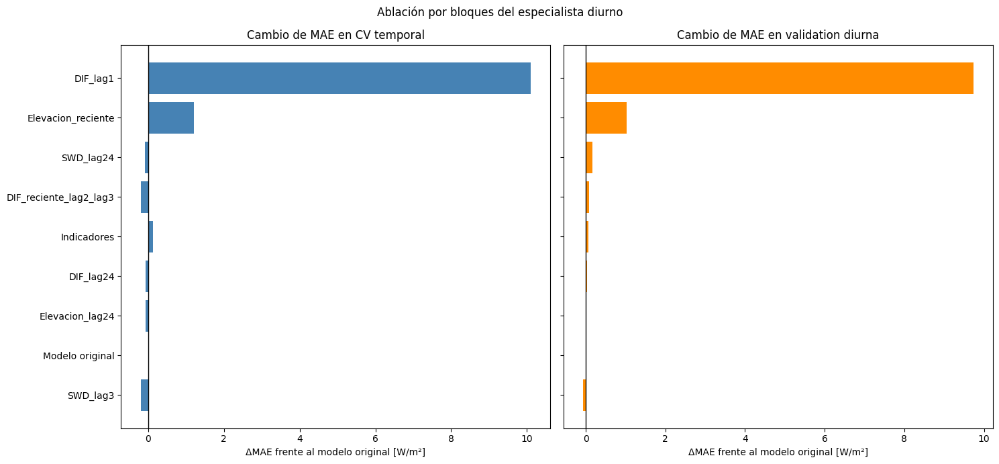

In [ ]:
import matplotlib.pyplot as plt

tabla_grafico = tabla_comparacion_ablacion_diurna.copy()
tabla_grafico["etiqueta"] = tabla_grafico["bloque_eliminado"].replace(
    {"NINGUNO": "Modelo original"}
)
tabla_grafico = tabla_grafico.sort_values("cambio_MAE_vs_original")
fig, axes = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
axes[0].barh(
    tabla_grafico["etiqueta"],
    tabla_grafico["MAE_CV_medio"]
    - tabla_CV_ablacion_diurna["MAE_CV_medio"]
    .loc[tabla_CV_ablacion_diurna["modelo"] == nombre_modelo_original]
    .iloc[0],
    color="steelblue",
)
axes[0].axvline(0, color="black", linewidth=1)
axes[0].set_title("Cambio de MAE en CV temporal")
axes[0].set_xlabel("ΔMAE frente al modelo original [W/m²]")
axes[1].barh(tabla_grafico["etiqueta"], tabla_grafico["cambio_MAE_vs_original"], color="darkorange")
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Cambio de MAE en validation diurna")
axes[1].set_xlabel("ΔMAE frente al modelo original [W/m²]")
plt.suptitle("Ablación por bloques del especialista diurno")
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import re
import shutil
import joblib
import pandas as pd
import numpy as np

# 1. Directorio de exportación
marca_temporal = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%dT%H%M%S")
nombre_checkpoint = f"checkpoint_modelado_diurno_" f"geometria_ablaciones_{marca_temporal}"
directorio_salida = Path("/content") / nombre_checkpoint
directorio_salida.mkdir(parents=True, exist_ok=False)
directorio_modelos = directorio_salida / "modelos"
directorio_tablas = directorio_salida / "tablas"
directorio_datos = directorio_salida / "datos"
directorio_modelos.mkdir()
directorio_tablas.mkdir()
directorio_datos.mkdir()

def nombre_archivo_seguro(texto):
    """Convierte el nombre de un modelo en un filename seguro."""
    texto = texto.replace("+", "_mas_")
    texto = texto.replace("²", "2")
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", texto)


# 2. Modelo seleccionado
nombre_modelo_ablacion_seleccionado = "M2-R24-3+Indicadores+ElevHist-Diurno-sin_SWD_lag3"
nombre_modelo_seleccionado = "M2-R24+Indicadores+ElevHist-Diurno"
features_modelo_seleccionado = [
    feature
    for feature in features_originales_diurnas
    if feature not in bloques_ablacion_diurna["SWD_lag3"]
]
modelo_seleccionado = modelos_ablacion_diurna[nombre_modelo_ablacion_seleccionado]
fila_modelo_seleccionado = tabla_comparacion_ablacion_diurna[
    tabla_comparacion_ablacion_diurna["modelo"] == nombre_modelo_ablacion_seleccionado
].iloc[0]
alpha_modelo_seleccionado = float(fila_modelo_seleccionado["mejor_alpha"])
train_diurno_exportar = train_diurno_geometria.copy()
validation_diurna_exportar = validation_diurna_geometria.copy()
train_diurno_exportar[f"pred_{nombre_modelo_seleccionado}"] = modelo_seleccionado.predict(
    train_diurno_exportar[features_modelo_seleccionado]
)
validation_diurna_exportar[f"pred_{nombre_modelo_seleccionado}"] = modelo_seleccionado.predict(
    validation_diurna_exportar[features_modelo_seleccionado]
)

# 3. Guardar datasets
datasets_guardar = {
    "01_dataset_checkpoint_base.parquet": df_checkpoint,
    "02_dataset_con_geometria.parquet": df_geometria,
    "03_soporte_geometria_train_validation.parquet": df_soporte_geometria,
    "04_train_geometria.parquet": train_geometria,
    "05_validation_geometria.parquet": validation_geometria,
    "06_train_diurno.parquet": train_diurno_exportar,
    "07_validation_diurna.parquet": validation_diurna_exportar,
}
for nombre_archivo, dataframe in datasets_guardar.items():
    dataframe.to_parquet(directorio_datos / nombre_archivo, index=False)

# 4. Guardar tablas principales
tablas_guardar = {
    "01_disponibilidad_elevacion.csv": disponibilidad_elevacion,
    "02_soporte_geometria.csv": tabla_soporte_geometria,
    "03_configuraciones_geometria.csv": resumen_configuraciones_geometria,
    "04_CV_geometria.csv": resumen_CV_geometria,
    "05_metricas_geometria.csv": tabla_metricas_geometria,
    "06_comparacion_geometria.csv": comparacion_geometria,
    "07_coeficientes_globales_ElevHist.csv": coeficientes_ElevHist,
    "08_CV_especialista_diurno.csv": cv_modelo_diurno,
    "09_metricas_comparacion_diurna.csv": metricas_comparacion_diurna,
    "10_estabilidad_coeficientes_diurnos.csv": estabilidad_coeficientes_diurnos,
    "11_configuraciones_ablacion_diurna.csv": resumen_configuraciones_ablacion,
    "12_CV_ablaciones_diurnas.csv": tabla_CV_ablacion_diurna,
    "13_validation_ablaciones_diurnas.csv": tabla_validation_ablacion_diurna,
    "14_comparacion_completa_ablaciones.csv": tabla_comparacion_ablacion_diurna,
}
for nombre_archivo, tabla in tablas_guardar.items():
    tabla.to_csv(directorio_tablas / nombre_archivo, index=False)

# 5. Guardar CV detallada de cada ablación
for nombre_modelo, tabla_cv in tablas_CV_ablacion_diurna.items():
    nombre_seguro = nombre_archivo_seguro(nombre_modelo)
    tabla_cv.assign(modelo=nombre_modelo).to_csv(
        directorio_tablas / f"CV_detallada_{nombre_seguro}.csv", index=False
    )

# 6. Guardar modelos geométricos globales
for nombre_modelo, modelo in modelos_geometria.items():
    nombre_seguro = nombre_archivo_seguro(nombre_modelo)
    joblib.dump(modelo, directorio_modelos / f"{nombre_seguro}.joblib")

# 7. Guardar especialista original
joblib.dump(
    modelo_M2_R24_3_Indicadores_ElevHist_Diurno,
    directorio_modelos / ("M2-R24-3_mas_Indicadores_mas_ElevHist-Diurno_original17.joblib"),
)

# 8. Guardar todas las ablaciones
for nombre_modelo, modelo in modelos_ablacion_diurna.items():
    nombre_seguro = nombre_archivo_seguro(nombre_modelo)
    joblib.dump(modelo, directorio_modelos / f"ablacion_{nombre_seguro}.joblib")

# Modelo seleccionado con su nombre definitivo
joblib.dump(
    modelo_seleccionado,
    directorio_modelos
    / ("MODELO_SELECCIONADO_M2-R24_mas_Indicadores_mas_ElevHist-Diurno.joblib"),
)

# 9. Configuración reproducible
configuracion_checkpoint = {
    "fecha_exportacion": marca_temporal,
    "objetivo": target,
    "test_utilizado": False,
    "poblacion_modelo_supervisado": ("Horas completamente diurnas"),
    "regla_provisional_fuera_dia": ("Persistencia diaria para transición y noche"),
    "convencion_temporal": {
        "lag1": "t",
        "lag2": "t-1",
        "lag3": "t-2",
        "lag24": "t-23",
        "objetivo": "DIF(t+1)",
    },
    "modelo_original_17": {
        "nombre": nombre_modelo_original,
        "features": features_originales_diurnas,
        "n_variables": len(features_originales_diurnas),
        "alpha": float(alpha_modelo_diurno),
    },
    "modelo_seleccionado_14": {
        "nombre": nombre_modelo_seleccionado,
        "procedencia": nombre_modelo_ablacion_seleccionado,
        "features": features_modelo_seleccionado,
        "n_variables": len(features_modelo_seleccionado),
        "alpha": alpha_modelo_seleccionado,
        "bloque_eliminado": "SWD_lag3",
        "variables_eliminadas": bloques_ablacion_diurna["SWD_lag3"],
        "MAE_validation_diurna": float(fila_modelo_seleccionado["MAE"]),
        "RMSE_validation_diurna": float(fila_modelo_seleccionado["RMSE"]),
        "R2_validation_diurna": float(fila_modelo_seleccionado["R2"]),
        "sesgo_validation_diurna": float(fila_modelo_seleccionado["sesgo"]),
        "MAE_CV_medio": float(fila_modelo_seleccionado["MAE_CV_medio"]),
    },
    "soporte": {
        "train_total": int(len(train_geometria)),
        "validation_total": int(len(validation_geometria)),
        "train_diurno": int(len(train_diurno_exportar)),
        "validation_diurna": int(len(validation_diurna_exportar)),
    },
    "bloques_ablacion_evaluados": bloques_ablacion_diurna,
    "conclusiones": [
        ("Entrenar exclusivamente con horas diurnas mejora al modelo geométrico global."),
        ("DIF_lag1 es la variable más importante y estable."),
        ("La elevación histórica mejora claramente las horas diurnas."),
        ("La elevación objetivo no justifica su complejidad adicional."),
        ("Eliminar el bloque SWD_lag3 mejora tanto CV como validation."),
        ("El modelo seleccionado contiene 14 variables."),
        ("No se realizará una segunda ronda de poda antes de evaluar DIR."),
        ("El siguiente paso es construir el modelo por regímenes y después evaluar DIR."),
    ],
    "siguiente_paso": [
        (
            "Construir predicción híbrida: especialista "
            "diurno y persistencia diaria fuera del día."
        ),
        ("Congelar métricas del candidato lineal por regímenes."),
        ("Incorporar DIR incrementalmente al núcleo diurno seleccionado."),
    ],
}
with open(directorio_salida / "configuracion_checkpoint.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion_checkpoint, archivo, ensure_ascii=False, indent=2)

# 10. README
texto_leeme = f"""
# Checkpoint del modelado diurno con geometría y ablaciones

Fecha: {marca_temporal}

## Estado del trabajo

Se ha construido un especialista Ridge para predecir DIF(t+1) durante
horas completamente diurnas.

El modelo inicial contenía 17 variables:

- cuatro retardos de DIF;
- SWD media, mínimo y desviación en lag3 y lag24;
- tres indicadores de Kd no calculable;
- cuatro elevaciones solares históricas.

## Modelo seleccionado

Nombre:

`{nombre_modelo_seleccionado}`

Número de variables: {len(features_modelo_seleccionado)}

Alpha: {alpha_modelo_seleccionado}

MAE validation diurna:
{float(fila_modelo_seleccionado["MAE"]):.4f} W/m²

RMSE validation diurna:
{float(fila_modelo_seleccionado["RMSE"]):.4f} W/m²

R² validation diurna:
{float(fila_modelo_seleccionado["R2"]):.4f}

## Decisión

Se elimina el bloque SWD-lag3:

- SWD_media_lag3;
- SWD_min_lag3;
- SWD_std_lag3.

La eliminación mejora ligeramente tanto la validación temporal como
validation diurna y reduce el modelo de 17 a 14 variables.

No se realizará todavía una segunda ronda de poda, porque la
incorporación de nuevas familias puede redistribuir la aportación de
los predictores actuales.

## Arquitectura provisional

- Completamente diurna: especialista Ridge.
- Transición: persistencia diaria.
- Noche: persistencia diaria.

## Siguiente paso

1. Construir y evaluar el modelo híbrido por regímenes.
2. Congelar sus métricas.
3. Evaluar la aportación incremental de DIR.
4. Continuar con el resto de familias.
5. Realizar la depuración definitiva al final.
6. Comparar posteriormente con modelos no lineales.

## Test

El conjunto test continúa completamente cerrado.
"""
(directorio_salida / "00_LEEME.md").write_text(texto_leeme.strip(), encoding="utf-8")

# 11. Manifiesto
archivos_manifiesto = []
for ruta in sorted(directorio_salida.rglob("*")):
    if ruta.is_file():
        archivos_manifiesto.append(
            {
                "archivo": str(ruta.relative_to(directorio_salida)),
                "tamano_bytes": ruta.stat().st_size,
            }
        )

pd.DataFrame(archivos_manifiesto).to_csv(directorio_salida / "MANIFIESTO.csv", index=False)

# 12. Crear ZIP y descargar
ruta_zip = shutil.make_archive(
    base_name=str(Path("/content") / nombre_checkpoint),
    format="zip",
    root_dir=directorio_salida.parent,
    base_dir=directorio_salida.name,
)
print("CHECKPOINT CREADO CORRECTAMENTE")
print("=" * 60)
print(f"ZIP: {ruta_zip}")
print(f"Modelo seleccionado: " f"{nombre_modelo_seleccionado}")
print(f"Variables: " f"{len(features_modelo_seleccionado)}")
print("Siguiente paso: modelo híbrido por regímenes y después DIR.")
print("Test utilizado: NO")
from google.colab import files
files.download(ruta_zip)

CHECKPOINT CREADO CORRECTAMENTE
ZIP: /content/checkpoint_modelado_diurno_geometria_ablaciones_20261003T164509.zip
Modelo seleccionado: M2-R24+Indicadores+ElevHist-Diurno
Variables: 14
Siguiente paso: modelo híbrido por regímenes y después DIR.
Test utilizado: NO


**Resultados.** Solo la eliminación de `DIF_lag_1` queda fuera del límite de un error estándar (40,24 W/m²): su MAE de validación temporal sube a 48,66 W/m² y el de validación aumenta en 9,74 W/m². Retirar las elevaciones recientes aumenta el MAE de validación en 1,03 W/m², y el resto de bloques lo modifica como máximo en 0,18 W/m². Eliminar la SWD en t−2 lo reduce en 0,06 W/m², y el modelo resultante, `M2-R24+Indicadores+ElevHist-Diurno`, con 14 variables, se guarda como seleccionado.

## 3. Gradient boosting de histogramas (HGB)

### 3.1 Soporte común de la comparación

Se recuperan las tres configuraciones de variables ya construidas: los retardos 1, 2, 3 y 24 de la DIF (4 variables), el núcleo anterior a las ablaciones (17 variables) y el núcleo reducido sin los estadísticos de SWD del retardo 3 (14 variables). Todos los modelos se comparan sobre el soporte en el que están disponibles las 17 variables, que contiene a las otras dos configuraciones, y se entrenan con todas las horas de entrenamiento, sin separarlas por régimen solar.

> *Se utiliza en la memoria: HGB de 14 variables (apartado 5.2 y Tabla 6).*

In [ ]:
import numpy as np
import pandas as pd

# CONFIGURACIÓN GENERAL
OBJETIVO = "DIF_objetivo_t1"
REGIMEN = "regimen_solar_objetivo"

# Recuperamos las listas que ya existen en el notebook.
features_4 = list(features_DIF_base)
features_17 = list(features_ElevHist)
features_14 = list(features_modelo_seleccionado)

# Nombres exactos de los modelos.
NOMBRE_M0 = "M0-Hibrido"
NOMBRE_M1 = "M1-Ridge-DIF"
NOMBRE_RIDGE_17 = "M2-Ridge-17V-Global"
NOMBRE_RIDGE_14 = "M2-Ridge-14V-Global"
NOMBRE_HGB_DIF = "M3-HGB-DIF-Global"
NOMBRE_HGB_17 = "M3-HGB-17V-Global"
NOMBRE_HGB_14 = "M3-HGB-14V-Global"


# LOCALIZACIÓN DE TRAIN Y VALIDATION
def recuperar_dataframe(nombres_posibles):
    for nombre in nombres_posibles:
        if nombre in globals() and isinstance(globals()[nombre], pd.DataFrame):
            print(f"Dataframe utilizado: {nombre}")
            return globals()[nombre].copy()

    raise NameError("No se encontró ninguno de estos dataframes: " + ", ".join(nombres_posibles))

train_global = recuperar_dataframe(["train_geometria", "df_train_geometria"])
validation_global = recuperar_dataframe(
    [
        "validation_geometria",
        "valid_geometria",
        "val_geometria",
        "df_validation_geometria",
        "df_valid_geometria",
    ]
)


# VALIDACIÓN DE LAS LISTAS DE VARIABLES
assert len(features_4) == 4, f"Se esperaban 4 variables DIF y aparecen {len(features_4)}."
assert len(features_17) == 17, f"Se esperaban 17 variables y aparecen {len(features_17)}."
assert len(features_14) == 14, f"Se esperaban 14 variables y aparecen {len(features_14)}."
assert set(features_4).issubset(
    features_14
), "Las cuatro variables DIF no están contenidas en el núcleo de 14."
assert set(features_14).issubset(
    features_17
), "El núcleo de 14 variables no está contenido en el de 17."
columnas_necesarias = list(dict.fromkeys(features_17 + [OBJETIVO, REGIMEN]))
for nombre_df, df in [("train", train_global), ("validation", validation_global)]:
    faltantes = [columna for columna in columnas_necesarias if columna not in df.columns]
    assert not faltantes, f"Faltan columnas en {nombre_df}: {faltantes}"


# SOPORTE COMÚN
train_global = train_global.sort_index().dropna(subset=columnas_necesarias).copy()
validation_global = validation_global.sort_index().dropna(subset=columnas_necesarias).copy()
print("\nVARIABLES DE CADA CONFIGURACIÓN")
print(f"\n{NOMBRE_M1} / {NOMBRE_HGB_DIF}: {len(features_4)} variables")
display(pd.DataFrame({"variable": features_4}))
print(f"\n{NOMBRE_RIDGE_17} / {NOMBRE_HGB_17}: {len(features_17)} variables")
display(pd.DataFrame({"variable": features_17}))
print(f"\n{NOMBRE_RIDGE_14} / {NOMBRE_HGB_14}: {len(features_14)} variables")
display(pd.DataFrame({"variable": features_14}))
print("\nSOPORTE COMÚN")
display(
    pd.DataFrame(
        {
            "particion": ["train", "validation"],
            "n_horas": [len(train_global), len(validation_global)],
            "inicio": [train_global.index.min(), validation_global.index.min()],
            "final": [train_global.index.max(), validation_global.index.max()],
        }
    )
)
print("\nREGÍMENES SOLARES")
display(
    pd.concat(
        [
            train_global[REGIMEN].value_counts().rename("train"),
            validation_global[REGIMEN].value_counts().rename("validation"),
        ],
        axis=1,
    )
    .fillna(0)
    .astype(int)
)

Dataframe utilizado: train_geometria
Dataframe utilizado: validation_geometria

VARIABLES DE CADA CONFIGURACIÓN

M1-Ridge-DIF / M3-HGB-DIF-Global: 4 variables


,variable
0,DIF_lag_1
1,DIF_lag_2
2,DIF_lag_3
3,DIF_lag_24



M2-Ridge-17V-Global / M3-HGB-17V-Global: 17 variables


,variable
0,DIF_lag_1
1,DIF_lag_2
2,DIF_lag_3
3,DIF_lag_24
4,SWD_media_lag3
5,SWD_min_lag3
6,SWD_std_lag3
7,SWD_media_lag24
8,SWD_min_lag24
9,SWD_std_lag24



M2-Ridge-14V-Global / M3-HGB-14V-Global: 14 variables


,variable
0,DIF_lag_1
1,DIF_lag_2
2,DIF_lag_3
3,DIF_lag_24
4,SWD_media_lag24
5,SWD_min_lag24
6,SWD_std_lag24
7,Kd_ausente_lag1
8,Kd_ausente_lag2
9,Kd_ausente_lag3



SOPORTE COMÚN


,particion,n_horas,inicio,final
0,train,5149,24,5179
1,validation,1464,5180,6643



REGÍMENES SOLARES


,train,validation
regimen_solar_objetivo,,
completamente_diurna,2603,765
noche,2122,580
transicion,424,119


**Resultados.** El soporte común reúne 5.149 horas de entrenamiento y 1.464 de validación. En entrenamiento hay 2.603 horas completamente diurnas, 424 de transición y 2.122 nocturnas; en validación, 765, 119 y 580, respectivamente.

### 3.2 Referencias Ridge globales

Se ajustan dos modelos Ridge globales, uno con el núcleo de 17 variables (`M2-Ridge-17V-Global`) y otro con el de 14 (`M2-Ridge-14V-Global`), mientras que el Ridge con cuatro retardos de la DIF (`M1-Ridge-DIF`) se mantiene como referencia lineal. El parámetro de regularización se selecciona solo con el entrenamiento, mediante validación temporal con cinco divisiones consecutivas, y después cada modelo se reajusta con todo el entrenamiento.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# Validación temporal interna.
cv_temporal = TimeSeriesSplit(n_splits=5)
alphas_ridge = np.logspace(-3, 4, 15)

def ajustar_ridge_global(nombre_modelo, features):
    pipeline = Pipeline([("scaler", StandardScaler()), ("ridge", Ridge())])
    busqueda = GridSearchCV(
        estimator=pipeline,
        param_grid={"ridge__alpha": alphas_ridge},
        scoring="neg_mean_absolute_error",
        cv=cv_temporal,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    busqueda.fit(train_global[features], train_global[OBJETIVO])
    resultados_cv = (
        pd.DataFrame(busqueda.cv_results_)
        .assign(
            modelo=nombre_modelo,
            MAE_CV=lambda x: -x["mean_test_score"],
            MAE_CV_train=lambda x: -x["mean_train_score"],
        )[
            [
                "modelo",
                "param_ridge__alpha",
                "MAE_CV",
                "std_test_score",
                "MAE_CV_train",
                "rank_test_score",
            ]
        ]
        .sort_values("MAE_CV")
        .reset_index(drop=True)
    )
    return busqueda.best_estimator_, resultados_cv

modelo_M2_Ridge_17V_Global, cv_M2_Ridge_17V_Global = ajustar_ridge_global(
    NOMBRE_RIDGE_17, features_17
)
modelo_M2_Ridge_14V_Global, cv_M2_Ridge_14V_Global = ajustar_ridge_global(
    NOMBRE_RIDGE_14, features_14
)
resumen_ridge_global = pd.DataFrame(
    [
        {
            "modelo": NOMBRE_RIDGE_17,
            "n_variables": len(features_17),
            "mejor_alpha": modelo_M2_Ridge_17V_Global.named_steps["ridge"].alpha,
            "MAE_CV_train_temporal": cv_M2_Ridge_17V_Global.iloc[0]["MAE_CV"],
        },
        {
            "modelo": NOMBRE_RIDGE_14,
            "n_variables": len(features_14),
            "mejor_alpha": modelo_M2_Ridge_14V_Global.named_steps["ridge"].alpha,
            "MAE_CV_train_temporal": cv_M2_Ridge_14V_Global.iloc[0]["MAE_CV"],
        },
    ]
)
display(resumen_ridge_global.round(4))

,modelo,n_variables,mejor_alpha,MAE_CV_train_temporal
0,M2-Ridge-17V-Global,17,10.0,24.1122
1,M2-Ridge-14V-Global,14,10.0,24.1165


**Resultados.** Ambas configuraciones seleccionan el mismo parámetro de regularización (alpha = 10) y obtienen un MAE de validación temporal prácticamente igual: 24,11 W/m² con 17 variables y 24,12 W/m² con 14.

### 3.3 Contraste no lineal con HGB

Se entrenan tres modelos de gradient boosting de histogramas (HGB) con las mismas configuraciones de 4, 17 y 14 variables (`M3-HGB-DIF-Global`, `M3-HGB-17V-Global` y `M3-HGB-14V-Global`) para comprobar si las conclusiones obtenidas con Ridge se mantienen cuando el modelo puede representar umbrales, relaciones curvas e interacciones. Los hiperparámetros se seleccionan con la misma validación temporal interna del entrenamiento.

In [ ]:
from sklearn.ensemble import HistGradientBoostingRegressor

parametros_hgb = {
    "learning_rate": [0.03, 0.07],
    "max_leaf_nodes": [7, 15],
    "min_samples_leaf": [20, 40],
    "l2_regularization": [0.0, 1.0],
}

def ajustar_hgb_global(nombre_modelo, features):
    modelo_base = HistGradientBoostingRegressor(
        loss="squared_error", max_iter=300, early_stopping=False, random_state=42
    )
    busqueda = GridSearchCV(
        estimator=modelo_base,
        param_grid=parametros_hgb,
        scoring="neg_mean_absolute_error",
        cv=cv_temporal,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    busqueda.fit(train_global[features], train_global[OBJETIVO])
    resultados_cv = (
        pd.DataFrame(busqueda.cv_results_)
        .assign(
            modelo=nombre_modelo,
            MAE_CV=lambda x: -x["mean_test_score"],
            MAE_CV_train=lambda x: -x["mean_train_score"],
        )[
            [
                "modelo",
                "param_learning_rate",
                "param_max_leaf_nodes",
                "param_min_samples_leaf",
                "param_l2_regularization",
                "MAE_CV",
                "std_test_score",
                "MAE_CV_train",
                "rank_test_score",
            ]
        ]
        .sort_values("MAE_CV")
        .reset_index(drop=True)
    )
    return busqueda.best_estimator_, resultados_cv

modelo_M3_HGB_DIF_Global, cv_M3_HGB_DIF_Global = ajustar_hgb_global(NOMBRE_HGB_DIF, features_4)
modelo_M3_HGB_17V_Global, cv_M3_HGB_17V_Global = ajustar_hgb_global(NOMBRE_HGB_17, features_17)
modelo_M3_HGB_14V_Global, cv_M3_HGB_14V_Global = ajustar_hgb_global(NOMBRE_HGB_14, features_14)
resumen_hgb_global = pd.DataFrame(
    [
        {
            "modelo": NOMBRE_HGB_DIF,
            "n_variables": len(features_4),
            **modelo_M3_HGB_DIF_Global.get_params(),
            "MAE_CV_train_temporal": cv_M3_HGB_DIF_Global.iloc[0]["MAE_CV"],
        },
        {
            "modelo": NOMBRE_HGB_17,
            "n_variables": len(features_17),
            **modelo_M3_HGB_17V_Global.get_params(),
            "MAE_CV_train_temporal": cv_M3_HGB_17V_Global.iloc[0]["MAE_CV"],
        },
        {
            "modelo": NOMBRE_HGB_14,
            "n_variables": len(features_14),
            **modelo_M3_HGB_14V_Global.get_params(),
            "MAE_CV_train_temporal": cv_M3_HGB_14V_Global.iloc[0]["MAE_CV"],
        },
    ]
)
columnas_resumen_hgb = [
    "modelo",
    "n_variables",
    "learning_rate",
    "max_leaf_nodes",
    "min_samples_leaf",
    "l2_regularization",
    "max_iter",
    "MAE_CV_train_temporal",
]
display(resumen_hgb_global[columnas_resumen_hgb].round(4))

,modelo,n_variables,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,max_iter,MAE_CV_train_temporal
0,M3-HGB-DIF-Global,4,0.03,7,20,1.0,300,23.8716
1,M3-HGB-17V-Global,17,0.03,7,20,0.0,300,22.1733
2,M3-HGB-14V-Global,14,0.03,7,20,1.0,300,22.0649


**Resultados.** Las tres configuraciones seleccionan una tasa de aprendizaje de 0,03, 7 hojas por árbol y un mínimo de 20 observaciones por hoja. El MAE de validación temporal es 23,87 W/m² con los cuatro retardos de la DIF, 22,17 W/m² con 17 variables y 22,06 W/m² con 14.

### 3.4 Predicciones sobre entrenamiento y validación

Se generan, sobre el soporte común, las predicciones de los siete modelos: la persistencia híbrida (`M0-Hibrido`), el Ridge con cuatro retardos de la DIF, los dos Ridge globales y los tres HGB. Los Ridge globales y los HGB se han entrenado con todas las horas, de modo que el régimen solar no interviene en sus predicciones.

In [ ]:
def mascara_completamente_diurna(serie_regimen):
    texto = serie_regimen.astype(str).str.lower()
    return texto.str.contains("completamente", na=False) & texto.str.contains("diurn", na=False)

def generar_predicciones_globales(df, particion):
    resultado = df.copy()
    es_diurna = mascara_completamente_diurna(resultado[REGIMEN])

    # M0-Híbrido:
    # persistencia inmediata si la hora objetivo es completamente diurna;
    # persistencia diaria en transición o noche.
    resultado[NOMBRE_M0] = np.where(es_diurna, resultado["DIF_lag_1"], resultado["DIF_lag_24"])

    # M1 ya estaba entrenado y congelado.
    resultado[NOMBRE_M1] = resultado["pred_M1_Ridge_DIF"]

    # Nuevas referencias Ridge globales.
    resultado[NOMBRE_RIDGE_17] = modelo_M2_Ridge_17V_Global.predict(resultado[features_17])
    resultado[NOMBRE_RIDGE_14] = modelo_M2_Ridge_14V_Global.predict(resultado[features_14])

    # Modelos no lineales.
    resultado[NOMBRE_HGB_DIF] = modelo_M3_HGB_DIF_Global.predict(resultado[features_4])
    resultado[NOMBRE_HGB_17] = modelo_M3_HGB_17V_Global.predict(resultado[features_17])
    resultado[NOMBRE_HGB_14] = modelo_M3_HGB_14V_Global.predict(resultado[features_14])
    resultado["particion"] = particion
    return resultado

resultados_globales_train = generar_predicciones_globales(train_global, "train")
resultados_globales_validation = generar_predicciones_globales(validation_global, "validation")
modelos_comparados = [
    NOMBRE_M0,
    NOMBRE_M1,
    NOMBRE_RIDGE_17,
    NOMBRE_RIDGE_14,
    NOMBRE_HGB_DIF,
    NOMBRE_HGB_17,
    NOMBRE_HGB_14,
]
print("Predicciones generadas correctamente.")
print(f"Train: {len(resultados_globales_train):,} horas")
print(f"Validation: {len(resultados_globales_validation):,} horas")
print(f"Modelos comparados: {len(modelos_comparados)}")

Predicciones generadas correctamente.
Train: 5,149 horas
Validation: 1,464 horas
Modelos comparados: 7


### 3.5 Evaluación global y por régimen solar

Cada modelo se evalúa en el conjunto completo y, sin reentrenarlo, en las horas completamente diurnas, de transición y nocturnas, con MAE, nMAE, RMSE, sesgo medio (predicción menos observación) y R². Como la DIF media nocturna es próxima a cero, el nMAE de la noche es inestable y se interpreta junto con el MAE y el RMSE.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def identificar_regimen(valor):
    texto = str(valor).lower()
    if "completamente" in texto and "diurn" in texto:
        return "completamente_diurna"

    if "trans" in texto:
        return "transicion"

    if "noche" in texto or "noct" in texto:
        return "noche"

    return str(valor)

def calcular_metricas_subconjunto(df, columna_prediccion, modelo, particion, regimen):
    y_real = df[OBJETIVO].astype(float)
    y_pred = df[columna_prediccion].astype(float)
    mae = mean_absolute_error(y_real, y_pred)
    media_real = y_real.mean()

    # Se mantiene exactamente la definición histórica.
    nmae = 100 * mae / media_real if not np.isclose(media_real, 0) else np.nan
    return {
        "particion": particion,
        "regimen": regimen,
        "modelo": modelo,
        "n_variables": (
            0
            if modelo == NOMBRE_M0
            else (
                4
                if modelo in [NOMBRE_M1, NOMBRE_HGB_DIF]
                else 17 if modelo in [NOMBRE_RIDGE_17, NOMBRE_HGB_17] else 14
            )
        ),
        "n": len(df),
        "DIF_media_real": media_real,
        "DIF_mediana_real": y_real.median(),
        "MAE": mae,
        "nMAE_pct": nmae,
        "RMSE": mean_squared_error(y_real, y_pred) ** 0.5,
        "sesgo": (y_pred - y_real).mean(),
        "R2": r2_score(y_real, y_pred),
    }

def evaluar_particion(df, particion):
    df = df.copy()
    df["regimen_evaluacion"] = df[REGIMEN].map(identificar_regimen)
    resultados = []
    for modelo in modelos_comparados:

        # Resultado total.
        resultados.append(
            calcular_metricas_subconjunto(
                df=df,
                columna_prediccion=modelo,
                modelo=modelo,
                particion=particion,
                regimen="total",
            )
        )

        # Resultados por régimen.
        for regimen in ["completamente_diurna", "transicion", "noche"]:
            subconjunto = df.loc[df["regimen_evaluacion"] == regimen]
            if len(subconjunto) == 0:
                continue

            resultados.append(
                calcular_metricas_subconjunto(
                    df=subconjunto,
                    columna_prediccion=modelo,
                    modelo=modelo,
                    particion=particion,
                    regimen=regimen,
                )
            )

    return pd.DataFrame(resultados)

metricas_train_global = evaluar_particion(resultados_globales_train, "train")
metricas_validation_global = evaluar_particion(resultados_globales_validation, "validation")
metricas_modelos_globales = pd.concat(
    [metricas_train_global, metricas_validation_global], ignore_index=True
)
orden_regimen = ["total", "completamente_diurna", "transicion", "noche"]
metricas_modelos_globales["regimen"] = pd.Categorical(
    metricas_modelos_globales["regimen"], categories=orden_regimen, ordered=True
)
metricas_modelos_globales = metricas_modelos_globales.sort_values(
    ["particion", "regimen", "MAE"]
).reset_index(drop=True)
print("MÉTRICAS DE VALIDATION")
display(
    metricas_modelos_globales.loc[metricas_modelos_globales["particion"] == "validation"].round(4)
)
print("\nMÉTRICAS DE TRAIN")
display(metricas_modelos_globales.loc[metricas_modelos_globales["particion"] == "train"].round(4))

MÉTRICAS DE VALIDATION


,particion,regimen,modelo,n_variables,n,DIF_media_real,DIF_mediana_real,MAE,nMAE_pct,RMSE,sesgo,R2
28,validation,total,M3-HGB-14V-Global,14,1464,85.2333,30.5917,17.7015,20.7683,33.4542,2.5006,0.9043
29,validation,total,M3-HGB-17V-Global,17,1464,85.2333,30.5917,17.7965,20.8798,33.5229,2.7806,0.9039
30,validation,total,M3-HGB-DIF-Global,4,1464,85.2333,30.5917,19.0898,22.3971,37.0275,1.0213,0.8827
31,validation,total,M2-Ridge-17V-Global,17,1464,85.2333,30.5917,22.0938,25.9216,35.9229,1.2970,0.8896
32,validation,total,M2-Ridge-14V-Global,14,1464,85.2333,30.5917,22.4509,26.3406,36.0840,1.6062,0.8886
33,validation,total,M1-Ridge-DIF,4,1464,85.2333,30.5917,22.8182,26.7715,38.7164,0.2219,0.8718
34,validation,total,M0-Hibrido,0,1464,85.2333,30.5917,25.6618,30.1077,45.7271,-1.4707,0.8211
35,validation,completamente_diurna,M3-HGB-14V-Global,14,765,162.7231,145.6833,32.7682,20.1374,46.2468,4.1632,0.7813
36,validation,completamente_diurna,M3-HGB-17V-Global,17,765,162.7231,145.6833,32.9438,20.2453,46.3415,4.7315,0.7804
37,validation,completamente_diurna,M2-Ridge-17V-Global,17,765,162.7231,145.6833,33.9763,20.8798,48.6579,1.5610,0.7579



MÉTRICAS DE TRAIN


,particion,regimen,modelo,n_variables,n,DIF_media_real,DIF_mediana_real,MAE,nMAE_pct,RMSE,sesgo,R2
0,train,total,M3-HGB-17V-Global,17,5149,80.2951,15.8500,15.6600,19.5031,29.6270,0.0000,0.9302
1,train,total,M3-HGB-14V-Global,14,5149,80.2951,15.8500,15.7927,19.6683,29.9620,-0.0009,0.9287
2,train,total,M3-HGB-DIF-Global,4,5149,80.2951,15.8500,17.6450,21.9752,33.8184,-0.0024,0.9091
3,train,total,M1-Ridge-DIF,4,5149,80.2951,15.8500,22.9533,28.5862,38.8779,-0.0187,0.8799
4,train,total,M2-Ridge-17V-Global,17,5149,80.2951,15.8500,23.0922,28.7592,36.5562,-0.0000,0.8938
5,train,total,M2-Ridge-14V-Global,14,5149,80.2951,15.8500,23.2590,28.9669,36.6082,-0.0000,0.8935
6,train,total,M0-Hibrido,0,5149,80.2951,15.8500,25.2014,31.3860,45.5912,-1.4565,0.8348
7,train,completamente_diurna,M3-HGB-17V-Global,17,2603,158.5432,132.3000,29.9265,18.8759,41.6336,-0.5200,0.8613
8,train,completamente_diurna,M3-HGB-14V-Global,14,2603,158.5432,132.3000,30.2008,19.0489,42.1060,-0.5383,0.8581
9,train,completamente_diurna,M3-HGB-DIF-Global,4,2603,158.5432,132.3000,33.8202,21.3319,47.5065,-0.4150,0.8193


In [ ]:
import json
import joblib
import shutil
import pandas as pd
from pathlib import Path
from datetime import datetime
from google.colab import files

# 1. CREAR CARPETA DEL CHECKPOINT
marca_tiempo = datetime.now().strftime("%Y%m%dT%H%M%S")
nombre_checkpoint = f"comparacion_global_Ridge_HGB_{marca_tiempo}"
carpeta_checkpoint = Path(nombre_checkpoint)
carpeta_checkpoint.mkdir(parents=True, exist_ok=False)
(carpeta_checkpoint / "tablas").mkdir()
(carpeta_checkpoint / "predicciones").mkdir()
(carpeta_checkpoint / "modelos").mkdir()
(carpeta_checkpoint / "configuracion").mkdir()


# 2. GUARDAR MÉTRICAS
metricas_modelos_globales.to_csv(
    carpeta_checkpoint / "tablas" / "01_metricas_modelos_globales.csv", index=False
)
metricas_train_global.to_csv(carpeta_checkpoint / "tablas" / "02_metricas_train.csv", index=False)
metricas_validation_global.to_csv(
    carpeta_checkpoint / "tablas" / "03_metricas_validation.csv", index=False
)
resumen_ridge_global.to_csv(
    carpeta_checkpoint / "tablas" / "04_resumen_ajuste_Ridge.csv", index=False
)
resumen_hgb_global[columnas_resumen_hgb].to_csv(
    carpeta_checkpoint / "tablas" / "05_resumen_ajuste_HGB.csv", index=False
)


# 3. GUARDAR RESULTADOS COMPLETOS DE VALIDACIÓN TEMPORAL
tablas_cv = {
    "06_CV_M2-Ridge-17V-Global.csv": cv_M2_Ridge_17V_Global,
    "07_CV_M2-Ridge-14V-Global.csv": cv_M2_Ridge_14V_Global,
    "08_CV_M3-HGB-DIF-Global.csv": cv_M3_HGB_DIF_Global,
    "09_CV_M3-HGB-17V-Global.csv": cv_M3_HGB_17V_Global,
    "10_CV_M3-HGB-14V-Global.csv": cv_M3_HGB_14V_Global,
}
for nombre_archivo, tabla in tablas_cv.items():
    tabla.to_csv(carpeta_checkpoint / "tablas" / nombre_archivo, index=False)


# 4. GUARDAR PREDICCIONES
columnas_predicciones = [OBJETIVO, REGIMEN] + modelos_comparados
predicciones_train_exportar = resultados_globales_train[columnas_predicciones].reset_index().copy()
predicciones_validation_exportar = (
    resultados_globales_validation[columnas_predicciones].reset_index().copy()
)

# Renombramos la primera columna si el índice no tenía nombre.
if predicciones_train_exportar.columns[0] == "index":
    predicciones_train_exportar = predicciones_train_exportar.rename(columns={"index": "timestamp"})

if predicciones_validation_exportar.columns[0] == "index":
    predicciones_validation_exportar = predicciones_validation_exportar.rename(
        columns={"index": "timestamp"}
    )

predicciones_train_exportar.to_csv(
    carpeta_checkpoint / "predicciones" / "11_predicciones_train.csv", index=False
)
predicciones_validation_exportar.to_csv(
    carpeta_checkpoint / "predicciones" / "12_predicciones_validation.csv", index=False
)

# Parquet conserva mejor tipos y precisión.
predicciones_train_exportar.to_parquet(
    carpeta_checkpoint / "predicciones" / "11_predicciones_train.parquet", index=False
)
predicciones_validation_exportar.to_parquet(
    carpeta_checkpoint / "predicciones" / "12_predicciones_validation.parquet", index=False
)


# 5. GUARDAR LISTAS DE VARIABLES
tabla_variables = pd.concat(
    [
        pd.DataFrame(
            {
                "configuracion": NOMBRE_M1,
                "orden": range(1, len(features_4) + 1),
                "variable": features_4,
            }
        ),
        pd.DataFrame(
            {
                "configuracion": NOMBRE_RIDGE_17,
                "orden": range(1, len(features_17) + 1),
                "variable": features_17,
            }
        ),
        pd.DataFrame(
            {
                "configuracion": NOMBRE_RIDGE_14,
                "orden": range(1, len(features_14) + 1),
                "variable": features_14,
            }
        ),
    ],
    ignore_index=True,
)
tabla_variables.to_csv(
    carpeta_checkpoint / "configuracion" / "13_variables_por_configuracion.csv", index=False
)


# 6. GUARDAR MODELOS ENTRENADOS
modelos_nuevos = {
    "M2-Ridge-17V-Global": modelo_M2_Ridge_17V_Global,
    "M2-Ridge-14V-Global": modelo_M2_Ridge_14V_Global,
    "M3-HGB-DIF-Global": modelo_M3_HGB_DIF_Global,
    "M3-HGB-17V-Global": modelo_M3_HGB_17V_Global,
    "M3-HGB-14V-Global": modelo_M3_HGB_14V_Global,
}
for nombre_modelo, modelo_entrenado in modelos_nuevos.items():
    joblib.dump(modelo_entrenado, carpeta_checkpoint / "modelos" / f"{nombre_modelo}.joblib")


# 7. METADATOS Y TRAZABILIDAD
configuracion_experimento = {
    "fecha_creacion": datetime.now().isoformat(),
    "objetivo": OBJETIVO,
    "regimen_solar": REGIMEN,
    "entrenamiento": ("Global: incluye todas las horas disponibles de train."),
    "evaluacion": ["total", "completamente_diurna", "transicion", "noche"],
    "validacion_hiperparametros": ("TimeSeriesSplit con 5 folds dentro de train."),
    "metrica_optimizacion": "MAE",
    "definicion_nMAE": ("100 * MAE / media(DIF_real), igual que en los modelos anteriores."),
    "convencion_sesgo": ("media(prediccion - observacion)"),
    "test_utilizado": False,
    "n_train": int(len(resultados_globales_train)),
    "n_validation": int(len(resultados_globales_validation)),
    "modelos_comparados": modelos_comparados,
    "numero_variables": {
        NOMBRE_M0: 0,
        NOMBRE_M1: 4,
        NOMBRE_RIDGE_17: 17,
        NOMBRE_RIDGE_14: 14,
        NOMBRE_HGB_DIF: 4,
        NOMBRE_HGB_17: 17,
        NOMBRE_HGB_14: 14,
    },
    "variables_4": features_4,
    "variables_17": features_17,
    "variables_14": features_14,
}
with open(
    carpeta_checkpoint / "configuracion" / "14_configuracion_experimento.json",
    "w",
    encoding="utf-8",
) as archivo:
    json.dump(configuracion_experimento, archivo, ensure_ascii=False, indent=2, default=str)


# 8. README
readme = f"""
CHECKPOINT: COMPARACIÓN GLOBAL RIDGE–HISTGRADIENTBOOSTING
=========================================================

Objetivo
--------
Comparar modelos lineales y no lineales para predecir
DIF(t+1), sin incorporar todavía la familia DIR.

Modelos
-------
- {NOMBRE_M0}: benchmark ingenuo.
- {NOMBRE_M1}: baseline Ridge con cuatro retardos de DIF.
- {NOMBRE_RIDGE_17}: referencia lineal completa.
- {NOMBRE_RIDGE_14}: referencia lineal compacta.
- {NOMBRE_HGB_DIF}: contraste no lineal mínimo.
- {NOMBRE_HGB_17}: contraste no lineal con 17 variables.
- {NOMBRE_HGB_14}: contraste no lineal compacto.

Metodología
-----------
Los modelos se entrenaron globalmente con todas las horas de train.
Los regímenes solares solo se utilizaron para desglosar las métricas.
La selección de hiperparámetros se realizó mediante validación
temporal interna de train.

nMAE
-----
nMAE (%) = 100 × MAE / media(DIF real).

El nMAE puede ser inestable durante la noche porque la media de DIF
es próxima a cero. En ese régimen deben priorizarse MAE y RMSE.

Importante
----------
- No se eliminó la tendencia.
- No se utilizó el conjunto test.
- No se incorporó todavía DIR.
- Las predicciones se guardan en CSV y Parquet.
"""
with open(carpeta_checkpoint / "README.txt", "w", encoding="utf-8") as archivo:
    archivo.write(readme.strip())


# 9. INVENTARIO DE ARCHIVOS
inventario = []
for ruta in sorted(carpeta_checkpoint.rglob("*")):
    if ruta.is_file():
        inventario.append(
            {
                "archivo": str(ruta.relative_to(carpeta_checkpoint)),
                "tamano_bytes": ruta.stat().st_size,
            }
        )

pd.DataFrame(inventario).to_csv(carpeta_checkpoint / "15_inventario_archivos.csv", index=False)


# 10. COMPRIMIR Y DESCARGAR
ruta_zip = shutil.make_archive(
    base_name=nombre_checkpoint, format="zip", root_dir=carpeta_checkpoint
)
print("Checkpoint creado correctamente:")
print(ruta_zip)
print("\nContenido:")
display(pd.DataFrame(inventario))
files.download(ruta_zip)

Checkpoint creado correctamente:
/content/comparacion_global_Ridge_HGB_20261003T163105.zip

Contenido:


,archivo,tamano_bytes
0,README.txt,1230
1,configuracion/13_variables_por_configuracion.csv,1302
2,configuracion/14_configuracion_experimento.json,1881
3,modelos/M2-Ridge-14V-Global.joblib,1985
4,modelos/M2-Ridge-17V-Global.joblib,2121
5,modelos/M3-HGB-14V-Global.joblib,300160
6,modelos/M3-HGB-17V-Global.joblib,306464
7,modelos/M3-HGB-DIF-Global.joblib,285168
8,predicciones/11_predicciones_train.csv,812932
9,predicciones/11_predicciones_train.parquet,297527


**Resultados.** En validación, `M3-HGB-14V-Global` obtiene el menor MAE total (17,70 W/m²; R² = 0,90), seguido del HGB de 17 variables (17,80 W/m²); los Ridge globales obtienen 22,09 y 22,45 W/m², y la persistencia híbrida, 25,66 W/m².
- Completamente diurno: 32,77 W/m², frente a 37,41 W/m² del Ridge con cuatro retardos y 48,34 W/m² de la persistencia híbrida.
- Transición: 2,71 W/m², frente a 3,97 W/m² de la persistencia híbrida y entre 10,72 y 14,29 W/m² de los modelos Ridge.
- Noche: la persistencia híbrida mantiene el menor MAE (0,20 W/m²).
- El MAE total del HGB de 14 variables pasa de 15,79 W/m² en entrenamiento a 17,70 W/m² en validación.

### 3.6 Importancia por permutación de cada variable

La importancia de cada una de las 14 variables de `M3-HGB-14V-Global` se mide como el aumento del MAE de validación al permutar aleatoriamente esa variable, con el modelo y las demás variables sin cambios; el procedimiento se repite 30 veces y se desglosa por régimen solar. La importancia no implica causalidad y puede repartirse entre predictores correlacionados, por lo que se complementa con una permutación por familias.

> *Se utiliza en la memoria: importancia por permutación del HGB de 14 variables (apartado 5.2).*

In [ ]:
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np

MODELO_INTERPRETADO = "M3-HGB-14V-Global"
modelo_interpretado = modelo_M3_HGB_14V_Global
variables_interpretadas = list(features_14)
df_interpretacion = validation_global.copy()

# Estandarizamos los nombres de los regímenes exclusivamente
# para organizar las salidas.
df_interpretacion["regimen_interpretacion"] = df_interpretacion[REGIMEN].map(identificar_regimen)
subconjuntos_interpretacion = {
    "total": df_interpretacion,
    "completamente_diurna": df_interpretacion.loc[
        df_interpretacion["regimen_interpretacion"] == "completamente_diurna"
    ],
    "transicion": df_interpretacion.loc[
        df_interpretacion["regimen_interpretacion"] == "transicion"
    ],
    "noche": df_interpretacion.loc[df_interpretacion["regimen_interpretacion"] == "noche"],
}
resultados_importancia_individual = []
for regimen, subconjunto in subconjuntos_interpretacion.items():
    X = subconjunto[variables_interpretadas]
    y = subconjunto[OBJETIVO]
    prediccion_base = modelo_interpretado.predict(X)
    mae_base = mean_absolute_error(y, prediccion_base)
    importancia = permutation_importance(
        estimator=modelo_interpretado,
        X=X,
        y=y,
        scoring="neg_mean_absolute_error",
        n_repeats=30,
        random_state=42,
        n_jobs=-1,
    )
    for posicion, variable in enumerate(variables_interpretadas):
        valores = importancia.importances[posicion]
        resultados_importancia_individual.append(
            {
                "modelo": MODELO_INTERPRETADO,
                "regimen": regimen,
                "variable": variable,
                "n": len(subconjunto),
                "MAE_base": mae_base,
                "aumento_MAE_medio": valores.mean(),
                "aumento_MAE_std": valores.std(ddof=1),
                "aumento_MAE_p05": np.quantile(valores, 0.05),
                "aumento_MAE_p95": np.quantile(valores, 0.95),
                "aumento_MAE_relativo_pct": 100 * valores.mean() / mae_base,
            }
        )

importancia_individual = pd.DataFrame(resultados_importancia_individual)
orden_regimen = ["total", "completamente_diurna", "transicion", "noche"]
importancia_individual["regimen"] = pd.Categorical(
    importancia_individual["regimen"], categories=orden_regimen, ordered=True
)
importancia_individual = importancia_individual.sort_values(
    ["regimen", "aumento_MAE_medio"], ascending=[True, False]
).reset_index(drop=True)
for regimen in orden_regimen:
    print(f"\nIMPORTANCIA INDIVIDUAL — {regimen.upper()}")
    display(
        importancia_individual.loc[
            importancia_individual["regimen"] == regimen,
            [
                "variable",
                "n",
                "MAE_base",
                "aumento_MAE_medio",
                "aumento_MAE_std",
                "aumento_MAE_p05",
                "aumento_MAE_p95",
                "aumento_MAE_relativo_pct",
            ],
        ].round(4)
    )


IMPORTANCIA INDIVIDUAL — TOTAL


,variable,n,MAE_base,aumento_MAE_medio,aumento_MAE_std,aumento_MAE_p05,aumento_MAE_p95,aumento_MAE_relativo_pct
0,DIF_lag_1,1464,17.7015,47.2301,0.9818,45.4516,48.6991,266.8134
1,elevacion_media_lag24,1464,17.7015,44.9728,0.9880,43.1639,46.1143,254.0616
2,elevacion_media_lag3,1464,17.7015,4.9493,0.2508,4.6018,5.4005,27.9599
3,elevacion_media_lag1,1464,17.7015,1.3714,0.0413,1.3078,1.4257,7.7472
4,SWD_min_lag24,1464,17.7015,0.6643,0.0381,0.6020,0.7290,3.7526
5,DIF_lag_24,1464,17.7015,0.5811,0.0316,0.5297,0.6299,3.2830
6,SWD_media_lag24,1464,17.7015,0.3234,0.0281,0.2688,0.3553,1.8270
7,DIF_lag_3,1464,17.7015,0.3071,0.0598,0.2060,0.4121,1.7351
8,DIF_lag_2,1464,17.7015,0.1460,0.0520,0.0604,0.2114,0.8249
9,elevacion_media_lag2,1464,17.7015,0.1254,0.0171,0.1031,0.1516,0.7083



IMPORTANCIA INDIVIDUAL — COMPLETAMENTE_DIURNA


,variable,n,MAE_base,aumento_MAE_medio,aumento_MAE_std,aumento_MAE_p05,aumento_MAE_p95,aumento_MAE_relativo_pct
14,DIF_lag_1,765,32.7682,44.7082,2.0655,40.6973,48.1578,136.4376
15,elevacion_media_lag24,765,32.7682,25.9326,1.6286,23.4057,27.9604,79.1395
16,elevacion_media_lag3,765,32.7682,6.4774,0.5141,5.7014,7.1345,19.7674
17,elevacion_media_lag1,765,32.7682,0.4865,0.0582,0.3823,0.5899,1.4848
18,DIF_lag_3,765,32.7682,0.2981,0.0902,0.1169,0.4077,0.9096
19,SWD_min_lag24,765,32.7682,0.1516,0.0732,0.0301,0.2536,0.4626
20,DIF_lag_2,765,32.7682,0.1384,0.1122,-0.0056,0.3553,0.4225
21,elevacion_media_lag2,765,32.7682,0.1144,0.0329,0.0573,0.1622,0.3492
22,DIF_lag_24,765,32.7682,0.1099,0.0672,0.0123,0.2037,0.3355
23,SWD_media_lag24,765,32.7682,0.0706,0.0726,-0.0595,0.1803,0.2156



IMPORTANCIA INDIVIDUAL — TRANSICION


,variable,n,MAE_base,aumento_MAE_medio,aumento_MAE_std,aumento_MAE_p05,aumento_MAE_p95,aumento_MAE_relativo_pct
28,DIF_lag_1,119,2.7091,4.9299,0.5937,3.8498,5.8101,181.9735
29,elevacion_media_lag3,119,2.7091,3.1247,0.3679,2.4289,3.7069,115.3392
30,elevacion_media_lag24,119,2.7091,2.5812,0.2351,2.1829,2.9147,95.2791
31,DIF_lag_3,119,2.7091,0.2783,0.1319,0.0859,0.4617,10.2709
32,elevacion_media_lag2,119,2.7091,0.1852,0.0601,0.1045,0.2694,6.8363
33,elevacion_media_lag1,119,2.7091,0.0761,0.0380,0.0123,0.1236,2.8088
34,DIF_lag_24,119,2.7091,0.0699,0.0415,-0.0065,0.1302,2.5796
35,SWD_media_lag24,119,2.7091,0.0517,0.0276,0.0107,0.0949,1.9081
36,DIF_lag_2,119,2.7091,0.0076,0.0288,-0.0287,0.0615,0.2799
37,SWD_min_lag24,119,2.7091,0.0000,0.0000,0.0000,0.0000,0.0000



IMPORTANCIA INDIVIDUAL — NOCHE


,variable,n,MAE_base,aumento_MAE_medio,aumento_MAE_std,aumento_MAE_p05,aumento_MAE_p95,aumento_MAE_relativo_pct
42,DIF_lag_1,580,0.9051,0.0964,0.0140,0.0767,0.1199,10.6471
43,elevacion_media_lag2,580,0.9051,0.0152,0.0022,0.0118,0.0178,1.6750
44,elevacion_media_lag3,580,0.9051,0.0116,0.0052,0.0012,0.0159,1.2816
45,DIF_lag_3,580,0.9051,0.0092,0.0037,0.0027,0.0141,1.0149
46,DIF_lag_24,580,0.9051,0.0000,0.0000,0.0000,0.0000,0.0000
47,SWD_media_lag24,580,0.9051,0.0000,0.0000,0.0000,0.0000,0.0000
48,SWD_min_lag24,580,0.9051,0.0000,0.0000,0.0000,0.0000,0.0000
49,SWD_std_lag24,580,0.9051,0.0000,0.0000,0.0000,0.0000,0.0000
50,Kd_ausente_lag1,580,0.9051,0.0000,0.0000,0.0000,0.0000,0.0000
51,Kd_ausente_lag2,580,0.9051,0.0000,0.0000,0.0000,0.0000,0.0000


**Resultados.** Sobre un MAE base de 17,70 W/m², la importancia se concentra en pocas variables.
- Total: permutar `DIF_lag_1` o `elevacion_media_lag24` aumenta el MAE en 47,23 y 44,97 W/m², y `elevacion_media_lag3`, en 4,95 W/m²; las demás no superan 1,37 W/m².
- Completamente diurno: se mantiene el mismo orden (44,71 y 25,93 W/m² para las dos primeras).
- Transición: tras `DIF_lag_1` (4,93 W/m²), `elevacion_media_lag3` (3,12 W/m²) supera a `elevacion_media_lag24` (2,58 W/m²).
- Los tres indicadores de ausencia de Kd tienen importancia nula en todos los regímenes.

### 3.7 Comparación gráfica de la importancia individual

Se representa el aumento del MAE de cada variable mediante barras por régimen y un mapa de calor, que permite ver si una variable es importante en todos los regímenes o solo en algunos.

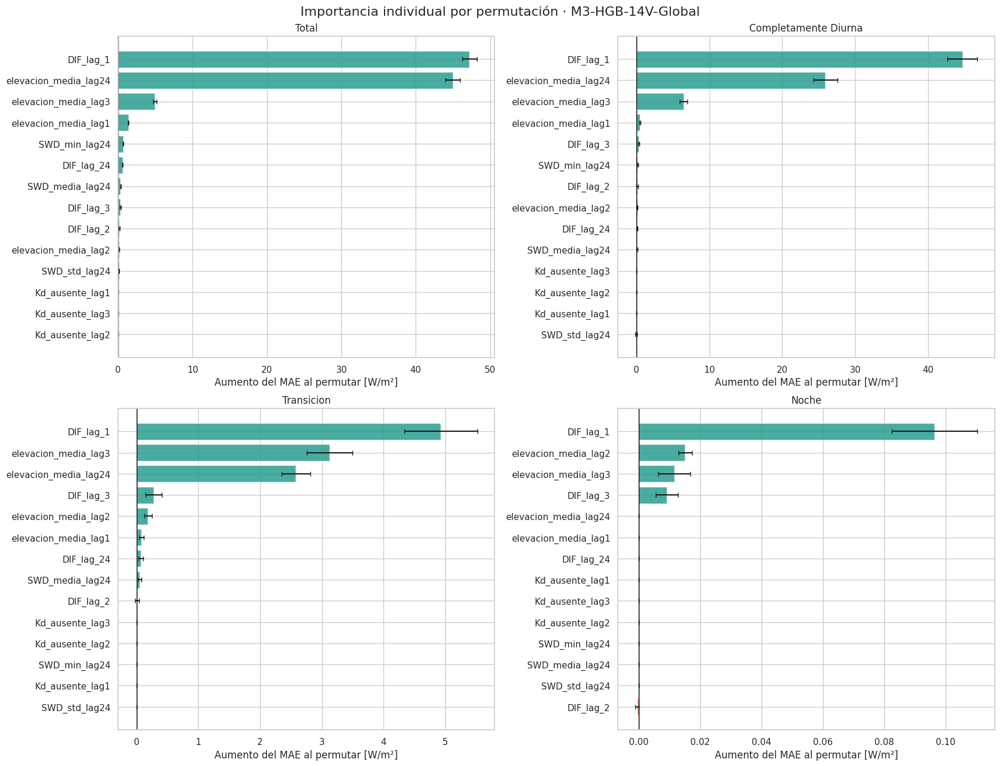

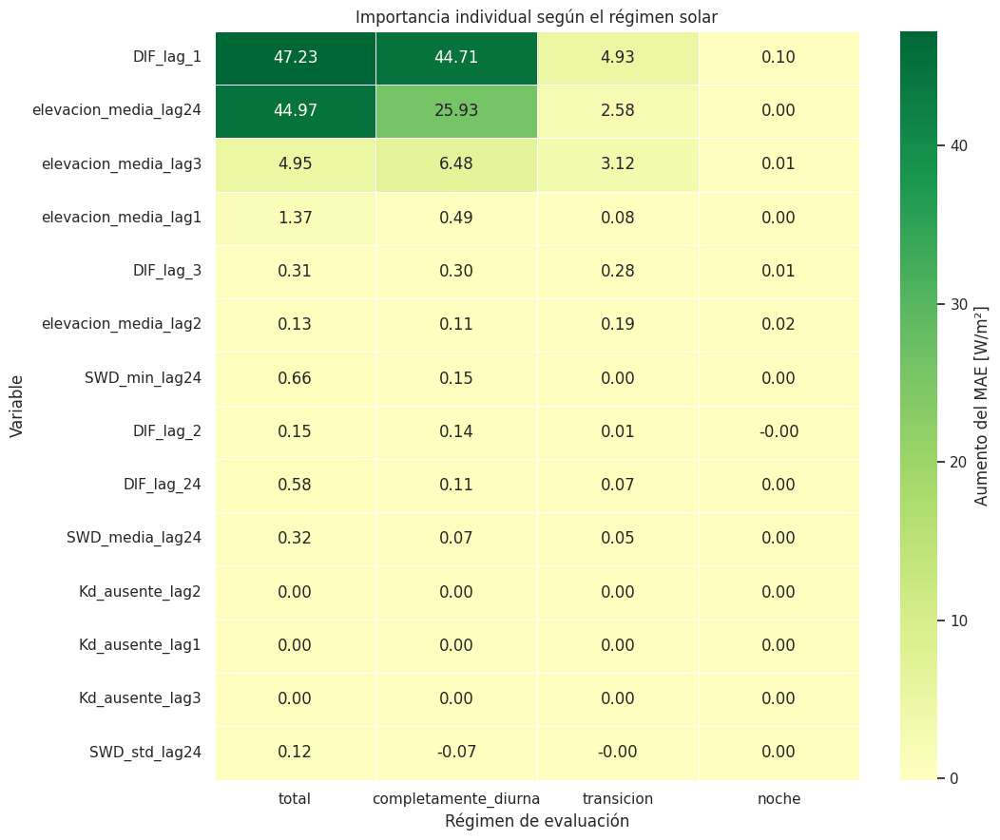

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# GRÁFICOS DE BARRAS
fig, axes = plt.subplots(2, 2, figsize=(17, 13), constrained_layout=True)
for ax, regimen in zip(axes.flat, orden_regimen):
    datos = importancia_individual.loc[importancia_individual["regimen"] == regimen].sort_values(
        "aumento_MAE_medio", ascending=True
    )
    colores = ["#2a9d8f" if valor > 0 else "#e76f51" for valor in datos["aumento_MAE_medio"]]
    ax.barh(
        datos["variable"],
        datos["aumento_MAE_medio"],
        xerr=datos["aumento_MAE_std"],
        color=colores,
        alpha=0.85,
        capsize=3,
    )
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"{regimen.replace('_', ' ').title()}")
    ax.set_xlabel("Aumento del MAE al permutar [W/m²]")
    ax.set_ylabel("")

fig.suptitle("Importancia individual por permutación · M3-HGB-14V-Global", fontsize=16)
plt.show()


# MAPA DE CALOR
tabla_calor_individual = importancia_individual.pivot(
    index="variable", columns="regimen", values="aumento_MAE_medio"
).reindex(columns=orden_regimen)

# Ordenamos por la mayor importancia observada en día o transición.
tabla_calor_individual["orden"] = tabla_calor_individual[
    ["completamente_diurna", "transicion"]
].max(axis=1)
tabla_calor_individual = tabla_calor_individual.sort_values("orden", ascending=False).drop(
    columns="orden"
)
plt.figure(figsize=(11, 9))
sns.heatmap(
    tabla_calor_individual,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    center=0,
    linewidths=0.5,
    cbar_kws={"label": "Aumento del MAE [W/m²]"},
)
plt.title("Importancia individual según el régimen solar")
plt.xlabel("Régimen de evaluación")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

### 3.8 Importancia por familias de variables

Las 14 variables se agrupan en cuatro familias (historial de la DIF, estadísticos de SWD en el retardo 24, indicadores de ausencia de Kd y elevación solar histórica) y las variables de cada familia se permutan conjuntamente con el mismo reordenamiento de filas. Así se rompe la relación de la familia con el objetivo sin alterar su estructura interna, lo que evita interpretar por separado predictores muy correlacionados.

In [ ]:
from sklearn.metrics import mean_absolute_error

bloques_variables = {
    "Historial_DIF": ["DIF_lag_1", "DIF_lag_2", "DIF_lag_3", "DIF_lag_24"],
    "SWD_lag24": ["SWD_media_lag24", "SWD_min_lag24", "SWD_std_lag24"],
    "Indicadores_Kd": ["Kd_ausente_lag1", "Kd_ausente_lag2", "Kd_ausente_lag3"],
    "Elevacion_historica": [
        "elevacion_media_lag1",
        "elevacion_media_lag2",
        "elevacion_media_lag3",
        "elevacion_media_lag24",
    ],
}

# Verificación: los cuatro bloques deben contener exactamente
# las 14 variables del modelo.
variables_en_bloques = [variable for bloque in bloques_variables.values() for variable in bloque]
assert set(variables_en_bloques) == set(
    variables_interpretadas
), "Los bloques no coinciden exactamente con las 14 variables."
assert len(variables_en_bloques) == len(
    set(variables_en_bloques)
), "Hay variables repetidas entre los bloques."

def importancia_permutacion_bloques(modelo, X, y, bloques, n_repeticiones=50, semilla=42):
    rng = np.random.default_rng(semilla)
    prediccion_base = modelo.predict(X)
    mae_base = mean_absolute_error(y, prediccion_base)
    resultados = []
    for nombre_bloque, columnas_bloque in bloques.items():
        aumentos_mae = []
        for repeticion in range(n_repeticiones):
            orden_permutado = rng.permutation(len(X))
            X_permutado = X.copy()

            # Se utiliza el mismo orden para todas las columnas
            # del bloque, preservando su estructura interna.
            X_permutado.loc[:, columnas_bloque] = X.iloc[orden_permutado][
                columnas_bloque
            ].to_numpy()
            prediccion_permutada = modelo.predict(X_permutado)
            mae_permutado = mean_absolute_error(y, prediccion_permutada)
            aumentos_mae.append(mae_permutado - mae_base)

        aumentos_mae = np.asarray(aumentos_mae)
        resultados.append(
            {
                "bloque": nombre_bloque,
                "n_variables_bloque": len(columnas_bloque),
                "variables": " | ".join(columnas_bloque),
                "MAE_base": mae_base,
                "aumento_MAE_medio": aumentos_mae.mean(),
                "aumento_MAE_std": aumentos_mae.std(ddof=1),
                "aumento_MAE_p05": np.quantile(aumentos_mae, 0.05),
                "aumento_MAE_p95": np.quantile(aumentos_mae, 0.95),
                "aumento_MAE_relativo_pct": 100 * aumentos_mae.mean() / mae_base,
            }
        )

    return pd.DataFrame(resultados)

resultados_bloques = []
for regimen, subconjunto in subconjuntos_interpretacion.items():
    X = subconjunto[variables_interpretadas]
    y = subconjunto[OBJETIVO]
    tabla_regimen = importancia_permutacion_bloques(
        modelo=modelo_interpretado,
        X=X,
        y=y,
        bloques=bloques_variables,
        n_repeticiones=50,
        semilla=42,
    )
    tabla_regimen.insert(0, "regimen", regimen)
    tabla_regimen.insert(0, "n", len(subconjunto))
    tabla_regimen.insert(0, "modelo", MODELO_INTERPRETADO)
    resultados_bloques.append(tabla_regimen)

importancia_bloques = pd.concat(resultados_bloques, ignore_index=True)
importancia_bloques["regimen"] = pd.Categorical(
    importancia_bloques["regimen"], categories=orden_regimen, ordered=True
)
importancia_bloques = importancia_bloques.sort_values(
    ["regimen", "aumento_MAE_medio"], ascending=[True, False]
).reset_index(drop=True)
for regimen in orden_regimen:
    print(f"\nIMPORTANCIA POR BLOQUES — {regimen.upper()}")
    display(
        importancia_bloques.loc[
            importancia_bloques["regimen"] == regimen,
            [
                "bloque",
                "n_variables_bloque",
                "n",
                "MAE_base",
                "aumento_MAE_medio",
                "aumento_MAE_std",
                "aumento_MAE_p05",
                "aumento_MAE_p95",
                "aumento_MAE_relativo_pct",
            ],
        ].round(4)
    )


IMPORTANCIA POR BLOQUES — TOTAL


,bloque,n_variables_bloque,n,MAE_base,aumento_MAE_medio,aumento_MAE_std,aumento_MAE_p05,aumento_MAE_p95,aumento_MAE_relativo_pct
0,Historial_DIF,4,1464,17.7015,45.8351,1.2288,43.9750,47.3691,258.9328
1,Elevacion_historica,4,1464,17.7015,37.6575,0.9708,36.0662,39.0443,212.7360
2,SWD_lag24,3,1464,17.7015,1.0966,0.0708,0.9912,1.2065,6.1950
3,Indicadores_Kd,3,1464,17.7015,0.0000,0.0000,0.0000,0.0000,0.0000



IMPORTANCIA POR BLOQUES — COMPLETAMENTE_DIURNA


,bloque,n_variables_bloque,n,MAE_base,aumento_MAE_medio,aumento_MAE_std,aumento_MAE_p05,aumento_MAE_p95,aumento_MAE_relativo_pct
4,Historial_DIF,4,765,32.7682,43.7759,1.6544,41.0570,46.3206,133.5925
5,Elevacion_historica,4,765,32.7682,25.3350,1.2192,23.4476,27.3410,77.3159
6,SWD_lag24,3,765,32.7682,0.2014,0.1449,0.0027,0.4665,0.6148
7,Indicadores_Kd,3,765,32.7682,0.0000,0.0000,0.0000,0.0000,0.0000



IMPORTANCIA POR BLOQUES — TRANSICION


,bloque,n_variables_bloque,n,MAE_base,aumento_MAE_medio,aumento_MAE_std,aumento_MAE_p05,aumento_MAE_p95,aumento_MAE_relativo_pct
8,Elevacion_historica,4,119,2.7091,5.3384,0.4195,4.7598,5.9425,197.0536
9,Historial_DIF,4,119,2.7091,4.1746,0.4110,3.5143,4.8197,154.0919
10,SWD_lag24,3,119,2.7091,0.0524,0.0383,-0.0091,0.1158,1.9332
11,Indicadores_Kd,3,119,2.7091,0.0000,0.0000,0.0000,0.0000,0.0000



IMPORTANCIA POR BLOQUES — NOCHE


,bloque,n_variables_bloque,n,MAE_base,aumento_MAE_medio,aumento_MAE_std,aumento_MAE_p05,aumento_MAE_p95,aumento_MAE_relativo_pct
12,Historial_DIF,4,580,0.9051,0.0280,0.0064,0.0176,0.0341,3.0924
13,Elevacion_historica,4,580,0.9051,0.0263,0.0073,0.0117,0.0337,2.9063
14,SWD_lag24,3,580,0.9051,0.0000,0.0000,0.0000,0.0000,0.0000
15,Indicadores_Kd,3,580,0.9051,0.0000,0.0000,0.0000,0.0000,0.0000


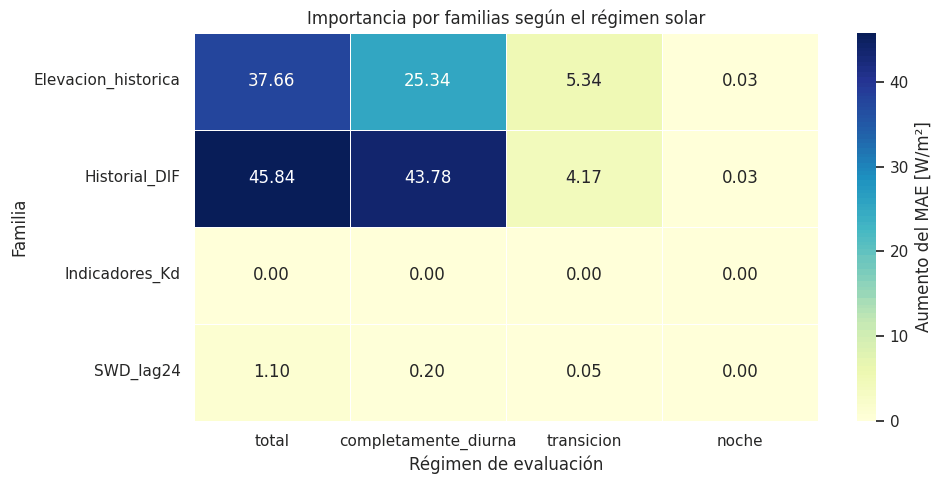

In [ ]:
tabla_calor_bloques = importancia_bloques.pivot(
    index="bloque", columns="regimen", values="aumento_MAE_medio"
).reindex(columns=orden_regimen)
plt.figure(figsize=(10, 5))
sns.heatmap(
    tabla_calor_bloques,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Aumento del MAE [W/m²]"},
)
plt.title("Importancia por familias según el régimen solar")
plt.xlabel("Régimen de evaluación")
plt.ylabel("Familia")
plt.tight_layout()
plt.show()

**Resultados.** El aumento del MAE al permutar cada familia muestra dos fuentes principales de información.
- Total: historial de la DIF, 45,84 W/m²; elevación histórica, 37,66 W/m²; SWD en el retardo 24, 1,10 W/m².
- Completamente diurno: predomina el historial de la DIF (43,78 frente a 25,34 W/m²).
- Transición: la elevación histórica (5,34 W/m²) supera al historial de la DIF (4,17 W/m²).
- Los indicadores de ausencia de Kd tienen importancia nula en todos los regímenes y, en la noche, ninguna familia supera 0,03 W/m².

### 3.9 Ablación por bloques del HGB de 14 variables

Se comparan cuatro HGB globales: el de 14 variables como referencia, uno sin los indicadores de ausencia de Kd, uno sin los estadísticos de SWD en el retardo 24 y `M3-HGB-8V-DIF-Elevacion-Global`, que conserva solo los cuatro retardos de la DIF y las cuatro elevaciones históricas. Todos se entrenan sobre el mismo entrenamiento, se ajustan con validación temporal interna y se evalúan sobre la misma validación; el régimen solar solo se usa para desglosar las métricas.

> *Se utiliza en la memoria: ablación por bloques que lleva al HGB de 8 variables (apartado 5.2 y Tabla 6).*

In [ ]:
NOMBRE_HGB_14 = "M3-HGB-14V-Global"
NOMBRE_HGB_SIN_INDICADORES = "M3-HGB-11V-sinIndicadores-Global"
NOMBRE_HGB_SIN_SWD = "M3-HGB-11V-sinSWD-Global"
NOMBRE_HGB_DIF_ELEVACION = "M3-HGB-8V-DIF-Elevacion-Global"


# BLOQUES
bloque_indicadores = ["Kd_ausente_lag1", "Kd_ausente_lag2", "Kd_ausente_lag3"]
bloque_SWD = ["SWD_media_lag24", "SWD_min_lag24", "SWD_std_lag24"]
bloque_DIF = ["DIF_lag_1", "DIF_lag_2", "DIF_lag_3", "DIF_lag_24"]
bloque_elevacion = [
    "elevacion_media_lag1",
    "elevacion_media_lag2",
    "elevacion_media_lag3",
    "elevacion_media_lag24",
]


# CONFIGURACIONES
features_HGB_14 = list(features_14)
features_HGB_sin_indicadores = [
    variable for variable in features_HGB_14 if variable not in bloque_indicadores
]
features_HGB_sin_SWD = [variable for variable in features_HGB_14 if variable not in bloque_SWD]
features_HGB_DIF_elevacion = bloque_DIF + bloque_elevacion


# COMPROBACIONES
assert len(features_HGB_14) == 14
assert len(features_HGB_sin_indicadores) == 11
assert len(features_HGB_sin_SWD) == 11
assert len(features_HGB_DIF_elevacion) == 8
assert set(features_HGB_sin_indicadores).issubset(features_HGB_14)
assert set(features_HGB_sin_SWD).issubset(features_HGB_14)
assert set(features_HGB_DIF_elevacion).issubset(features_HGB_14)
configuraciones_ablacion_HGB = {
    NOMBRE_HGB_14: features_HGB_14,
    NOMBRE_HGB_SIN_INDICADORES: features_HGB_sin_indicadores,
    NOMBRE_HGB_SIN_SWD: features_HGB_sin_SWD,
    NOMBRE_HGB_DIF_ELEVACION: features_HGB_DIF_elevacion,
}
tabla_configuraciones_ablacion = pd.concat(
    [
        pd.DataFrame(
            {
                "modelo": nombre_modelo,
                "n_variables": len(variables),
                "orden": range(1, len(variables) + 1),
                "variable": variables,
            }
        )
        for nombre_modelo, variables in configuraciones_ablacion_HGB.items()
    ],
    ignore_index=True,
)
display(tabla_configuraciones_ablacion)

,modelo,n_variables,orden,variable
0,M3-HGB-14V-Global,14,1,DIF_lag_1
1,M3-HGB-14V-Global,14,2,DIF_lag_2
2,M3-HGB-14V-Global,14,3,DIF_lag_3
3,M3-HGB-14V-Global,14,4,DIF_lag_24
4,M3-HGB-14V-Global,14,5,SWD_media_lag24
5,M3-HGB-14V-Global,14,6,SWD_min_lag24
6,M3-HGB-14V-Global,14,7,SWD_std_lag24
7,M3-HGB-14V-Global,14,8,Kd_ausente_lag1
8,M3-HGB-14V-Global,14,9,Kd_ausente_lag2
9,M3-HGB-14V-Global,14,10,Kd_ausente_lag3


### 3.10 Entrenamiento de las ablaciones

Las tres configuraciones reducidas repiten la búsqueda de hiperparámetros con la misma validación temporal que el modelo de 14 variables, de modo que una posible mejora no dependa de conservar los parámetros elegidos para este.

In [ ]:
modelo_HGB_sin_indicadores, cv_HGB_sin_indicadores = ajustar_hgb_global(
    NOMBRE_HGB_SIN_INDICADORES, features_HGB_sin_indicadores
)
modelo_HGB_sin_SWD, cv_HGB_sin_SWD = ajustar_hgb_global(NOMBRE_HGB_SIN_SWD, features_HGB_sin_SWD)
modelo_HGB_DIF_elevacion, cv_HGB_DIF_elevacion = ajustar_hgb_global(
    NOMBRE_HGB_DIF_ELEVACION, features_HGB_DIF_elevacion
)


# REUNIR LOS CUATRO MODELOS
modelos_ablacion_HGB = {
    NOMBRE_HGB_14: modelo_M3_HGB_14V_Global,
    NOMBRE_HGB_SIN_INDICADORES: modelo_HGB_sin_indicadores,
    NOMBRE_HGB_SIN_SWD: modelo_HGB_sin_SWD,
    NOMBRE_HGB_DIF_ELEVACION: modelo_HGB_DIF_elevacion,
}
resultados_CV_ablacion_HGB = pd.concat(
    [cv_M3_HGB_14V_Global, cv_HGB_sin_indicadores, cv_HGB_sin_SWD, cv_HGB_DIF_elevacion],
    ignore_index=True,
)


# RESUMEN DE MEJORES CONFIGURACIONES
filas_mejores = []
for nombre_modelo, modelo in modelos_ablacion_HGB.items():
    tabla_cv_modelo = (
        resultados_CV_ablacion_HGB.loc[resultados_CV_ablacion_HGB["modelo"] == nombre_modelo]
        .sort_values("MAE_CV")
        .iloc[0]
    )
    filas_mejores.append(
        {
            "modelo": nombre_modelo,
            "n_variables": len(configuraciones_ablacion_HGB[nombre_modelo]),
            "learning_rate": modelo.learning_rate,
            "max_leaf_nodes": modelo.max_leaf_nodes,
            "min_samples_leaf": modelo.min_samples_leaf,
            "l2_regularization": modelo.l2_regularization,
            "MAE_CV_temporal": tabla_cv_modelo["MAE_CV"],
            "std_CV_temporal": tabla_cv_modelo["std_test_score"],
        }
    )

resumen_CV_ablacion_HGB = pd.DataFrame(filas_mejores).sort_values("MAE_CV_temporal")
display(resumen_CV_ablacion_HGB.round(4))

,modelo,n_variables,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,MAE_CV_temporal,std_CV_temporal
3,M3-HGB-8V-DIF-Elevacion-Global,8,0.03,7,20,1.0,21.8751,5.1298
2,M3-HGB-11V-sinSWD-Global,11,0.03,7,20,1.0,21.8751,5.1298
1,M3-HGB-11V-sinIndicadores-Global,11,0.03,7,20,1.0,22.0649,5.1363
0,M3-HGB-14V-Global,14,0.03,7,20,1.0,22.0649,5.1363


In [ ]:
def generar_predicciones_ablacion_HGB(df, particion):
    resultado = df.copy()
    for nombre_modelo, modelo in modelos_ablacion_HGB.items():
        variables = configuraciones_ablacion_HGB[nombre_modelo]
        resultado[nombre_modelo] = modelo.predict(resultado[variables])

    resultado["particion"] = particion
    return resultado

predicciones_ablacion_train = generar_predicciones_ablacion_HGB(train_global, "train")
predicciones_ablacion_validation = generar_predicciones_ablacion_HGB(
    validation_global, "validation"
)
print("Predicciones generadas correctamente.")
print(f"Train: {len(predicciones_ablacion_train):,} horas")
print("Validation: " f"{len(predicciones_ablacion_validation):,} horas")

Predicciones generadas correctamente.
Train: 5,149 horas
Validation: 1,464 horas


**Resultados.** Las cuatro configuraciones seleccionan los mismos hiperparámetros (tasa de aprendizaje de 0,03, 7 hojas, 20 observaciones por hoja y regularización L2 de 1,0). Retirar el bloque de SWD reduce el MAE de validación temporal de 22,06 a 21,88 W/m², mientras que retirar los indicadores de Kd no lo modifica.

### 3.11 Evaluación de las ablaciones

Cada configuración se evalúa en entrenamiento y validación con MAE, nMAE, RMSE, sesgo y R², desglosados por régimen solar, y se comprueba si los modelos producen predicciones distintas. La selección prioriza el MAE en las horas completamente diurnas y de transición, la estabilidad entre entrenamiento y validación, la validación temporal interna y el número de variables; la noche se conserva solo como diagnóstico.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

numero_variables_ablacion = {
    nombre_modelo: len(variables)
    for nombre_modelo, variables in configuraciones_ablacion_HGB.items()
}

def metricas_ablacion_subconjunto(df, modelo, particion, regimen):
    y_real = df[OBJETIVO].astype(float)
    y_pred = df[modelo].astype(float)
    mae = mean_absolute_error(y_real, y_pred)
    media_real = y_real.mean()
    nmae = 100 * mae / media_real if not np.isclose(media_real, 0) else np.nan
    return {
        "particion": particion,
        "regimen": regimen,
        "modelo": modelo,
        "n_variables": numero_variables_ablacion[modelo],
        "n": len(df),
        "DIF_media_real": media_real,
        "DIF_mediana_real": y_real.median(),
        "MAE": mae,
        "nMAE_pct": nmae,
        "RMSE": mean_squared_error(y_real, y_pred) ** 0.5,
        "sesgo": (y_pred - y_real).mean(),
        "R2": r2_score(y_real, y_pred),
    }

def evaluar_ablaciones_HGB(df, particion):
    datos = df.copy()
    datos["regimen_interpretacion"] = datos[REGIMEN].map(identificar_regimen)
    resultados = []
    for modelo in modelos_ablacion_HGB:
        resultados.append(
            metricas_ablacion_subconjunto(
                df=datos, modelo=modelo, particion=particion, regimen="total"
            )
        )
        for regimen in ["completamente_diurna", "transicion", "noche"]:
            subconjunto = datos.loc[datos["regimen_interpretacion"] == regimen]
            resultados.append(
                metricas_ablacion_subconjunto(
                    df=subconjunto, modelo=modelo, particion=particion, regimen=regimen
                )
            )

    return pd.DataFrame(resultados)

metricas_ablacion_train = evaluar_ablaciones_HGB(predicciones_ablacion_train, "train")
metricas_ablacion_validation = evaluar_ablaciones_HGB(
    predicciones_ablacion_validation, "validation"
)
metricas_ablacion_HGB = pd.concat(
    [metricas_ablacion_train, metricas_ablacion_validation], ignore_index=True
)
metricas_ablacion_HGB["regimen"] = pd.Categorical(
    metricas_ablacion_HGB["regimen"],
    categories=["total", "completamente_diurna", "transicion", "noche"],
    ordered=True,
)
metricas_ablacion_HGB = metricas_ablacion_HGB.sort_values(
    ["particion", "regimen", "MAE"]
).reset_index(drop=True)
print("VALIDATION")
display(metricas_ablacion_HGB.loc[metricas_ablacion_HGB["particion"] == "validation"].round(4))
print("\nTRAIN")
display(metricas_ablacion_HGB.loc[metricas_ablacion_HGB["particion"] == "train"].round(4))

VALIDATION


,particion,regimen,modelo,n_variables,n,DIF_media_real,DIF_mediana_real,MAE,nMAE_pct,RMSE,sesgo,R2
16,validation,total,M3-HGB-11V-sinSWD-Global,11,1464,85.2333,30.5917,17.6016,20.6511,33.4534,2.5736,0.9043
17,validation,total,M3-HGB-8V-DIF-Elevacion-Global,8,1464,85.2333,30.5917,17.6016,20.6511,33.4534,2.5736,0.9043
18,validation,total,M3-HGB-14V-Global,14,1464,85.2333,30.5917,17.7015,20.7683,33.4542,2.5006,0.9043
19,validation,total,M3-HGB-11V-sinIndicadores-Global,11,1464,85.2333,30.5917,17.7015,20.7683,33.4542,2.5006,0.9043
20,validation,completamente_diurna,M3-HGB-11V-sinSWD-Global,11,765,162.7231,145.6833,32.6575,20.0694,46.2460,4.4384,0.7813
21,validation,completamente_diurna,M3-HGB-8V-DIF-Elevacion-Global,8,765,162.7231,145.6833,32.6575,20.0694,46.2460,4.4384,0.7813
22,validation,completamente_diurna,M3-HGB-14V-Global,14,765,162.7231,145.6833,32.7682,20.1374,46.2468,4.1632,0.7813
23,validation,completamente_diurna,M3-HGB-11V-sinIndicadores-Global,11,765,162.7231,145.6833,32.7682,20.1374,46.2468,4.1632,0.7813
24,validation,transicion,M3-HGB-14V-Global,14,119,7.2764,4.8500,2.7091,37.2317,3.8865,-0.3894,0.6995
25,validation,transicion,M3-HGB-11V-sinIndicadores-Global,11,119,7.2764,4.8500,2.7091,37.2317,3.8865,-0.3894,0.6995



TRAIN


,particion,regimen,modelo,n_variables,n,DIF_media_real,DIF_mediana_real,MAE,nMAE_pct,RMSE,sesgo,R2
0,train,total,M3-HGB-14V-Global,14,5149,80.2951,15.8500,15.7927,19.6683,29.9620,-0.0009,0.9287
1,train,total,M3-HGB-11V-sinIndicadores-Global,11,5149,80.2951,15.8500,15.7927,19.6683,29.9620,-0.0009,0.9287
2,train,total,M3-HGB-11V-sinSWD-Global,11,5149,80.2951,15.8500,15.8568,19.7482,30.3336,0.0001,0.9269
3,train,total,M3-HGB-8V-DIF-Elevacion-Global,8,5149,80.2951,15.8500,15.8568,19.7482,30.3336,0.0001,0.9269
4,train,completamente_diurna,M3-HGB-14V-Global,14,2603,158.5432,132.3000,30.2008,19.0489,42.1060,-0.5383,0.8581
5,train,completamente_diurna,M3-HGB-11V-sinIndicadores-Global,11,2603,158.5432,132.3000,30.2008,19.0489,42.1060,-0.5383,0.8581
6,train,completamente_diurna,M3-HGB-11V-sinSWD-Global,11,2603,158.5432,132.3000,30.4131,19.1829,42.6298,-0.4059,0.8545
7,train,completamente_diurna,M3-HGB-8V-DIF-Elevacion-Global,8,2603,158.5432,132.3000,30.4131,19.1829,42.6298,-0.4059,0.8545
8,train,transicion,M3-HGB-14V-Global,14,424,5.9906,3.6167,2.4971,41.6834,3.7582,-0.5319,0.6721
9,train,transicion,M3-HGB-11V-sinIndicadores-Global,11,424,5.9906,3.6167,2.4971,41.6834,3.7582,-0.5319,0.6721


In [ ]:
parejas_comprobar = [
    (NOMBRE_HGB_14, NOMBRE_HGB_SIN_INDICADORES),
    (NOMBRE_HGB_SIN_SWD, NOMBRE_HGB_DIF_ELEVACION),
    (NOMBRE_HGB_14, NOMBRE_HGB_DIF_ELEVACION),
]
filas_comprobacion = []
for modelo_a, modelo_b in parejas_comprobar:
    pred_a = predicciones_ablacion_validation[modelo_a].to_numpy()
    pred_b = predicciones_ablacion_validation[modelo_b].to_numpy()
    diferencia = np.abs(pred_a - pred_b)
    objeto_a = modelos_ablacion_HGB[modelo_a]
    objeto_b = modelos_ablacion_HGB[modelo_b]
    filas_comprobacion.append(
        {
            "modelo_A": modelo_a,
            "modelo_B": modelo_b,
            "mismo_objeto_python": objeto_a is objeto_b,
            "n_features_A": getattr(objeto_a, "n_features_in_", np.nan),
            "n_features_B": getattr(objeto_b, "n_features_in_", np.nan),
            "max_diferencia_prediccion": diferencia.max(),
            "media_diferencia_absoluta": diferencia.mean(),
            "n_predicciones_diferentes_1e-12": int((diferencia > 1e-12).sum()),
        }
    )

comprobacion_modelos_equivalentes = pd.DataFrame(filas_comprobacion)
display(comprobacion_modelos_equivalentes)
print("\nHIPERPARÁMETROS SELECCIONADOS")
display(
    resumen_CV_ablacion_HGB[
        [
            "modelo",
            "n_variables",
            "learning_rate",
            "max_leaf_nodes",
            "min_samples_leaf",
            "l2_regularization",
            "MAE_CV_temporal",
            "std_CV_temporal",
        ]
    ].round(6)
)
print("\nDIFERENCIAS ENTRE LISTAS DE VARIABLES")
for modelo_a, modelo_b in parejas_comprobar:
    variables_a = set(configuraciones_ablacion_HGB[modelo_a])
    variables_b = set(configuraciones_ablacion_HGB[modelo_b])
    print(f"\n{modelo_a}")
    print(f"frente a {modelo_b}")
    print("Solo en A:", sorted(variables_a - variables_b))
    print("Solo en B:", sorted(variables_b - variables_a))

,modelo_A,modelo_B,mismo_objeto_python,n_features_A,n_features_B,max_diferencia_prediccion,media_diferencia_absoluta,n_predicciones_diferentes_1e-12
0,M3-HGB-14V-Global,M3-HGB-11V-sinIndicadores-Global,False,14,11,0.000000,0.000000,0
1,M3-HGB-11V-sinSWD-Global,M3-HGB-8V-DIF-Elevacion-Global,False,11,8,0.000000,0.000000,0
2,M3-HGB-14V-Global,M3-HGB-8V-DIF-Elevacion-Global,False,14,8,25.064063,1.616127,1464



HIPERPARÁMETROS SELECCIONADOS


,modelo,n_variables,learning_rate,max_leaf_nodes,min_samples_leaf,l2_regularization,MAE_CV_temporal,std_CV_temporal
3,M3-HGB-8V-DIF-Elevacion-Global,8,0.03,7,20,1.0,21.875124,5.129824
2,M3-HGB-11V-sinSWD-Global,11,0.03,7,20,1.0,21.875124,5.129824
1,M3-HGB-11V-sinIndicadores-Global,11,0.03,7,20,1.0,22.064850,5.136264
0,M3-HGB-14V-Global,14,0.03,7,20,1.0,22.064850,5.136264



DIFERENCIAS ENTRE LISTAS DE VARIABLES

M3-HGB-14V-Global
frente a M3-HGB-11V-sinIndicadores-Global
Solo en A: ['Kd_ausente_lag1', 'Kd_ausente_lag2', 'Kd_ausente_lag3']
Solo en B: []

M3-HGB-11V-sinSWD-Global
frente a M3-HGB-8V-DIF-Elevacion-Global
Solo en A: ['Kd_ausente_lag1', 'Kd_ausente_lag2', 'Kd_ausente_lag3']
Solo en B: []

M3-HGB-14V-Global
frente a M3-HGB-8V-DIF-Elevacion-Global
Solo en A: ['Kd_ausente_lag1', 'Kd_ausente_lag2', 'Kd_ausente_lag3', 'SWD_media_lag24', 'SWD_min_lag24', 'SWD_std_lag24']
Solo en B: []


**Resultados.** Los indicadores de ausencia de Kd no modifican ninguna predicción: el modelo de 14 variables y el de 11 sin indicadores, así como el de 11 sin SWD y `M3-HGB-8V-DIF-Elevacion-Global`, producen predicciones idénticas en las 1.464 horas de validación. SWD, en cambio, altera todas las predicciones (diferencia absoluta media de 1,62 W/m²). Con 8 variables frente a 14:
- MAE total: 17,60 frente a 17,70 W/m².
- Completamente diurno: 32,66 frente a 32,77 W/m².
- Transición: 2,83 frente a 2,71 W/m².

### 3.12 Diagnóstico de errores del HGB de 8 variables

Se analizan los residuos de `M3-HGB-8V-DIF-Elevacion-Global` en validación, definidos como predicción menos observación (positivos en caso de sobreestimación y negativos en caso de infraestimación), junto con los de la persistencia híbrida y el Ridge con cuatro retardos de la DIF. El análisis se realiza globalmente y por régimen solar, con especial atención a las horas completamente diurnas y de transición.

> *Se utiliza en la memoria: HGB de 8 variables en validación (Tabla 6).*

In [ ]:
MODELO_SELECCIONADO = "M3-HGB-8V-DIF-Elevacion-Global"
df_errores = predicciones_ablacion_validation.copy().sort_index()
df_errores["regimen_analisis"] = df_errores[REGIMEN].map(identificar_regimen)

# M0-Híbrido.
es_diurna = df_errores["regimen_analisis"] == "completamente_diurna"
df_errores["M0-Hibrido"] = np.where(es_diurna, df_errores["DIF_lag_1"], df_errores["DIF_lag_24"])

# M1 congelado.
df_errores["M1-Ridge-DIF"] = df_errores["pred_M1_Ridge_DIF"]
modelos_diagnostico = ["M0-Hibrido", "M1-Ridge-DIF", MODELO_SELECCIONADO]
for modelo in modelos_diagnostico:
    df_errores[f"error__{modelo}"] = df_errores[modelo] - df_errores[OBJETIVO]
    df_errores[f"error_abs__{modelo}"] = df_errores[f"error__{modelo}"].abs()
    df_errores[f"error_cuadrado__{modelo}"] = df_errores[f"error__{modelo}"] ** 2

print("Tabla de errores construida correctamente.")
display(
    df_errores[
        [
            OBJETIVO,
            REGIMEN,
            "M0-Hibrido",
            "M1-Ridge-DIF",
            MODELO_SELECCIONADO,
            f"error__{MODELO_SELECCIONADO}",
            f"error_abs__{MODELO_SELECCIONADO}",
        ]
    ].head()
)

Tabla de errores construida correctamente.


,DIF_objetivo_t1,regimen_solar_objetivo,M0-Hibrido,M1-Ridge-DIF,M3-HGB-8V-DIF-Elevacion-Global,error__M3-HGB-8V-DIF-Elevacion-Global,error_abs__M3-HGB-8V-DIF-Elevacion-Global
5180,-1.0,noche,-1.000000,5.376634,-0.209362,0.790638,0.790638
5181,-1.0,noche,-1.000000,5.376634,-0.209362,0.790638,0.790638
5182,-1.0,noche,-1.000000,5.376634,-0.209362,0.790638,0.790638
5183,0.4,noche,0.100000,5.638133,-0.209362,-0.609362,0.609362
5184,28.8,transicion,19.633333,11.582802,16.085681,-12.714319,12.714319


### 3.13 Comparación de errores por régimen solar

Se comparan el HGB de 8 variables, la persistencia híbrida y el Ridge con cuatro retardos de la DIF en el conjunto total, en las horas de operación (completamente diurnas y de transición) y en cada régimen, con MAE, RMSE, sesgo, mediana y percentiles del error absoluto. Además, se calcula el porcentaje de horas en que el HGB comete un error absoluto menor que cada referencia.

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

orden_poblaciones = ["total", "operativa_sin_noche", "completamente_diurna", "transicion", "noche"]
subconjuntos_error = {
    "total": df_errores,
    "operativa_sin_noche": df_errores.loc[df_errores["regimen_analisis"] != "noche"],
    "completamente_diurna": df_errores.loc[
        df_errores["regimen_analisis"] == "completamente_diurna"
    ],
    "transicion": df_errores.loc[df_errores["regimen_analisis"] == "transicion"],
    "noche": df_errores.loc[df_errores["regimen_analisis"] == "noche"],
}
filas_metricas_error = []
for poblacion, datos in subconjuntos_error.items():
    y_real = datos[OBJETIVO].astype(float)
    for modelo in modelos_diagnostico:
        y_pred = datos[modelo].astype(float)
        error = y_pred - y_real
        error_abs = error.abs()
        mae = error_abs.mean()
        media_real = y_real.mean()
        filas_metricas_error.append(
            {
                "poblacion": poblacion,
                "modelo": modelo,
                "n": len(datos),
                "DIF_media_real": media_real,
                "DIF_mediana_real": y_real.median(),
                "MAE": mae,
                "nMAE_pct": (100 * mae / media_real if not np.isclose(media_real, 0) else np.nan),
                "RMSE": np.sqrt(np.mean(error**2)),
                "sesgo": error.mean(),
                "mediana_error": error.median(),
                "mediana_error_abs": error_abs.median(),
                "p90_error_abs": error_abs.quantile(0.90),
                "p95_error_abs": error_abs.quantile(0.95),
                "p99_error_abs": error_abs.quantile(0.99),
                "R2": r2_score(y_real, y_pred),
            }
        )

metricas_diagnostico = pd.DataFrame(filas_metricas_error)
metricas_diagnostico["poblacion"] = pd.Categorical(
    metricas_diagnostico["poblacion"], categories=orden_poblaciones, ordered=True
)
metricas_diagnostico = metricas_diagnostico.sort_values(["poblacion", "MAE"]).reset_index(drop=True)
display(metricas_diagnostico.round(4))

,poblacion,modelo,n,DIF_media_real,DIF_mediana_real,MAE,nMAE_pct,RMSE,sesgo,mediana_error,mediana_error_abs,p90_error_abs,p95_error_abs,p99_error_abs,R2
0,total,M3-HGB-8V-DIF-Elevacion-Global,1464,85.2333,30.5917,17.6016,20.6511,33.4534,2.5736,0.7906,3.7597,49.8911,74.6005,134.7630,0.9043
1,total,M1-Ridge-DIF,1464,85.2333,30.5917,22.8182,26.7715,38.7164,0.2219,6.0676,7.1491,60.2773,86.8909,142.5358,0.8718
2,total,M0-Hibrido,1464,85.2333,30.5917,25.6618,30.1077,45.7271,-1.4707,0.0000,5.5917,75.0533,101.0117,161.6070,0.8211
3,operativa_sin_noche,M3-HGB-8V-DIF-Elevacion-Global,884,141.7976,127.7333,28.6418,20.1991,43.0460,3.7602,1.1496,19.6877,67.6755,85.0657,165.8973,0.8358
4,operativa_sin_noche,M1-Ridge-DIF,884,141.7976,127.7333,33.8150,23.8474,49.5533,-2.2750,0.8705,23.2906,81.4854,103.0641,157.3859,0.7824
5,operativa_sin_noche,M0-Hibrido,884,141.7976,127.7333,42.3644,29.8767,58.8451,-2.4356,-1.0000,33.4083,94.5683,123.8142,171.0190,0.6931
6,completamente_diurna,M3-HGB-8V-DIF-Elevacion-Global,765,162.7231,145.6833,32.6575,20.0694,46.2460,4.4384,4.7259,23.6790,73.7886,90.1629,168.7842,0.7813
7,completamente_diurna,M1-Ridge-DIF,765,162.7231,145.6833,37.4076,22.9885,52.9521,-3.6856,-0.6085,26.7923,85.8286,107.1415,162.0327,0.7132
8,completamente_diurna,M0-Hibrido,765,162.7231,145.6833,48.3363,29.7046,63.2042,-2.9637,-5.8833,39.2167,99.2433,126.8767,180.0673,0.5914
9,transicion,M3-HGB-8V-DIF-Elevacion-Global,119,7.2764,4.8500,2.8267,38.8468,4.0058,-0.6002,-0.4956,1.8117,6.9203,7.7209,12.7024,0.6808


In [ ]:
filas_comparacion_horas = []
for poblacion, datos in subconjuntos_error.items():
    error_HGB = datos[f"error_abs__{MODELO_SELECCIONADO}"]
    for referencia in ["M0-Hibrido", "M1-Ridge-DIF"]:
        error_referencia = datos[f"error_abs__{referencia}"]
        mejora = error_referencia - error_HGB
        filas_comparacion_horas.append(
            {
                "poblacion": poblacion,
                "referencia": referencia,
                "n": len(datos),
                "porcentaje_horas_ganadas": 100 * (mejora > 0).mean(),
                "porcentaje_horas_empatadas": 100 * np.isclose(mejora, 0).mean(),
                "mejora_media_MAE_Wm2": mejora.mean(),
                "mejora_mediana_Wm2": mejora.median(),
                "p05_mejora_Wm2": mejora.quantile(0.05),
                "p95_mejora_Wm2": mejora.quantile(0.95),
            }
        )

comparacion_horas = pd.DataFrame(filas_comparacion_horas)
comparacion_horas["poblacion"] = pd.Categorical(
    comparacion_horas["poblacion"], categories=orden_poblaciones, ordered=True
)
comparacion_horas = comparacion_horas.sort_values(["poblacion", "referencia"])
display(comparacion_horas.round(4))

,poblacion,referencia,n,porcentaje_horas_ganadas,porcentaje_horas_empatadas,mejora_media_MAE_Wm2,mejora_mediana_Wm2,p05_mejora_Wm2,p95_mejora_Wm2
0,total,M0-Hibrido,1464,43.5109,0.0,8.0602,-0.5490,-29.6916,52.9227
1,total,M1-Ridge-DIF,1464,75.8197,0.0,5.2166,5.5860,-25.8825,33.3851
2,operativa_sin_noche,M0-Hibrido,884,64.7059,0.0,13.7226,9.2331,-37.6667,62.1631
3,operativa_sin_noche,M1-Ridge-DIF,884,60.9729,0.0,5.1731,4.3754,-31.9303,44.0811
4,completamente_diurna,M0-Hibrido,765,65.7516,0.0,15.6787,18.2710,-39.1864,63.6139
5,completamente_diurna,M1-Ridge-DIF,765,57.6471,0.0,4.7501,4.5392,-32.7901,47.4474
6,transicion,M0-Hibrido,119,57.9832,0.0,1.1471,0.2885,-3.3285,7.4728
7,transicion,M1-Ridge-DIF,119,82.3529,0.0,7.8928,3.7509,-2.0050,26.9964
8,noche,M0-Hibrido,580,11.2069,0.0,-0.5701,-0.7906,-0.7906,0.3776
9,noche,M1-Ridge-DIF,580,98.4483,0.0,5.2827,5.5860,1.3319,7.4834


**Resultados.** En las 884 horas de operación, el HGB de 8 variables obtiene un MAE de 28,64 W/m² (R² = 0,84), frente a 42,36 W/m² de la persistencia híbrida, y comete menor error absoluto que la persistencia híbrida y que el Ridge con cuatro retardos en el 64,71 % y el 60,97 % de esas horas.
- Completamente diurno: 32,66 W/m², frente a 37,41 (Ridge) y 48,34 W/m² (persistencia híbrida); el percentil 99 del error absoluto alcanza 168,78 W/m².
- Transición: 2,83 W/m², frente a 3,97 (persistencia híbrida) y 10,72 W/m² (Ridge).
- Noche: la persistencia híbrida mantiene el menor MAE (0,20 frente a 0,77 W/m²).

### 3.14 Distribución de los residuos por régimen

Se representan la distribución del error con signo y del error absoluto por régimen, y el valor observado frente al predicho en las horas completamente diurnas y de transición, para detectar sesgos sistemáticos, colas largas y cambios de dispersión al aumentar la DIF.

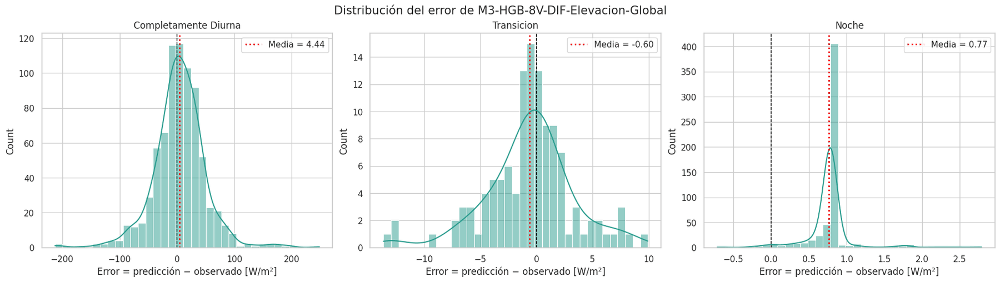

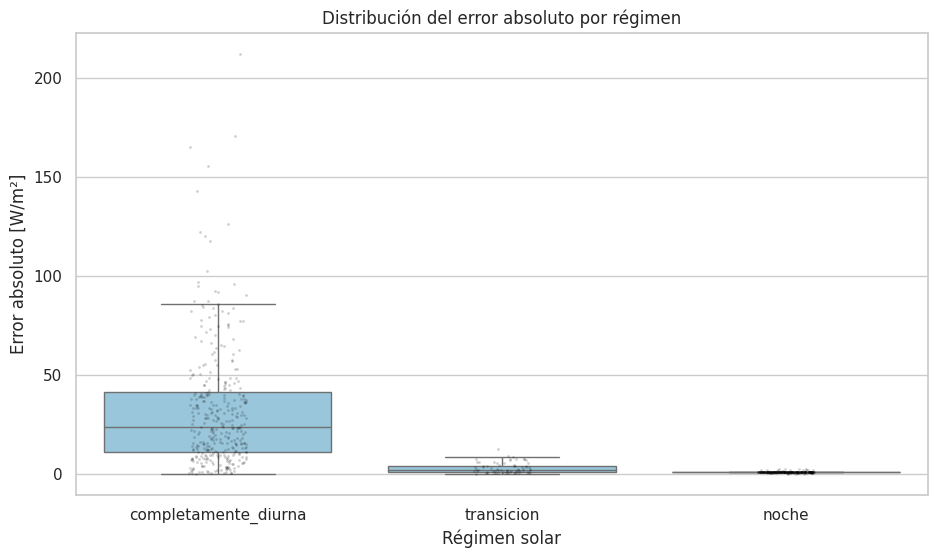

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
columna_error = f"error__{MODELO_SELECCIONADO}"
columna_error_abs = f"error_abs__{MODELO_SELECCIONADO}"

# DISTRIBUCIÓN DEL ERROR FIRMADO
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
regimenes_principales = ["completamente_diurna", "transicion", "noche"]
for ax, regimen in zip(axes, regimenes_principales):
    datos = df_errores.loc[df_errores["regimen_analisis"] == regimen]
    sns.histplot(data=datos, x=columna_error, bins=35, kde=True, ax=ax, color="#2a9d8f")
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.axvline(
        datos[columna_error].mean(),
        color="red",
        linestyle=":",
        linewidth=2,
        label=("Media = " f"{datos[columna_error].mean():.2f}"),
    )
    ax.set_title(regimen.replace("_", " ").title())
    ax.set_xlabel("Error = predicción − observado [W/m²]")
    ax.legend()

fig.suptitle("Distribución del error de M3-HGB-8V-DIF-Elevacion-Global", fontsize=15)
plt.show()


# ERROR ABSOLUTO POR RÉGIMEN
plt.figure(figsize=(11, 6))
sns.boxplot(
    data=df_errores,
    x="regimen_analisis",
    y=columna_error_abs,
    order=["completamente_diurna", "transicion", "noche"],
    showfliers=False,
    color="#8ecae6",
)
sns.stripplot(
    data=df_errores.sample(min(len(df_errores), 700), random_state=42),
    x="regimen_analisis",
    y=columna_error_abs,
    order=["completamente_diurna", "transicion", "noche"],
    color="black",
    alpha=0.18,
    size=2,
)
plt.title("Distribución del error absoluto por régimen")
plt.xlabel("Régimen solar")
plt.ylabel("Error absoluto [W/m²]")
plt.show()

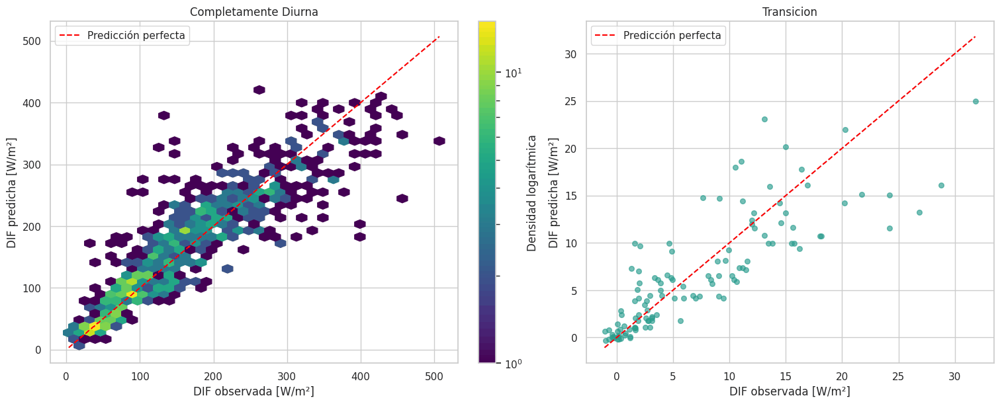

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
for ax, regimen in zip(axes, ["completamente_diurna", "transicion"]):
    datos = df_errores.loc[df_errores["regimen_analisis"] == regimen]
    if regimen == "completamente_diurna":
        grafico = ax.hexbin(
            datos[OBJETIVO],
            datos[MODELO_SELECCIONADO],
            gridsize=35,
            mincnt=1,
            cmap="viridis",
            bins="log",
        )
        fig.colorbar(grafico, ax=ax, label="Densidad logarítmica")

    else:
        ax.scatter(datos[OBJETIVO], datos[MODELO_SELECCIONADO], alpha=0.65, s=30, color="#2a9d8f")

    limite_minimo = min(datos[OBJETIVO].min(), datos[MODELO_SELECCIONADO].min())
    limite_maximo = max(datos[OBJETIVO].max(), datos[MODELO_SELECCIONADO].max())
    ax.plot(
        [limite_minimo, limite_maximo],
        [limite_minimo, limite_maximo],
        color="red",
        linestyle="--",
        label="Predicción perfecta",
    )
    ax.set_title(regimen.replace("_", " ").title())
    ax.set_xlabel("DIF observada [W/m²]")
    ax.set_ylabel("DIF predicha [W/m²]")
    ax.legend()

plt.show()

### 3.15 Error según el nivel observado de DIF

Las horas completamente diurnas y de transición se dividen en quintiles de DIF observada para estudiar cómo varían el error absoluto, el error relativo y el sesgo con la magnitud de la irradiancia.

In [ ]:
def crear_quintiles_por_regimen(df, regimen, n_cuantiles=5):
    datos = df.loc[df["regimen_analisis"] == regimen].copy()
    datos["quintil_DIF"] = pd.qcut(datos[OBJETIVO], q=n_cuantiles, duplicates="drop")
    return datos

tablas_quintiles = []
for regimen in ["completamente_diurna", "transicion"]:
    datos = crear_quintiles_por_regimen(df_errores, regimen)
    resumen = (
        datos.groupby("quintil_DIF", observed=True)
        .agg(
            n=(OBJETIVO, "size"),
            DIF_min=(OBJETIVO, "min"),
            DIF_media=(OBJETIVO, "mean"),
            DIF_mediana=(OBJETIVO, "median"),
            DIF_max=(OBJETIVO, "max"),
            MAE=(columna_error_abs, "mean"),
            mediana_error_abs=(columna_error_abs, "median"),
            RMSE=("error_cuadrado__" + MODELO_SELECCIONADO, lambda x: np.sqrt(x.mean())),
            sesgo=(columna_error, "mean"),
            p90_error_abs=(columna_error_abs, lambda x: x.quantile(0.90)),
        )
        .reset_index()
    )
    resumen["nMAE_pct"] = 100 * resumen["MAE"] / resumen["DIF_media"]
    resumen.insert(0, "regimen", regimen)
    tablas_quintiles.append(resumen)

errores_por_quintil_DIF = pd.concat(tablas_quintiles, ignore_index=True)
display(errores_por_quintil_DIF.round(4))

,regimen,quintil_DIF,n,DIF_min,DIF_media,DIF_mediana,DIF_max,MAE,mediana_error_abs,RMSE,sesgo,p90_error_abs,nMAE_pct
0,completamente_diurna,"(3.149, 71.863]",153,3.1500,45.8994,47.5500,71.8500,18.1277,11.1302,28.6671,10.4532,34.8426,39.4944
1,completamente_diurna,"(71.863, 122.15]",153,71.8667,95.4262,94.1000,121.9000,25.2756,17.3540,36.9598,16.7007,52.7653,26.4871
2,completamente_diurna,"(122.15, 173.22]",153,122.3167,146.2188,145.6833,173.1333,40.6846,34.7731,54.5436,21.2120,74.7343,27.8245
3,completamente_diurna,"(173.22, 250.777]",153,173.3500,207.3261,209.1000,250.7667,30.1078,27.0623,38.0424,6.3470,67.1758,14.5220
4,completamente_diurna,"(250.777, 507.1]",153,250.8167,318.7448,309.5333,507.1000,49.0919,37.5548,63.9017,-32.5207,101.6873,15.4016
5,transicion,"(-1.0679999999999998, 1.267]",24,-1.0667,0.1410,0.1750,1.2167,0.7554,0.5145,0.9730,0.3628,1.6221,535.8332
6,transicion,"(1.267, 2.983]",24,1.3000,2.1236,1.9667,2.9500,2.1608,1.1449,3.1558,1.4249,5.7175,101.7493
7,transicion,"(2.983, 8.32]",23,3.1167,5.0094,4.8500,8.1333,2.2502,1.8117,2.7542,0.3686,4.1475,44.9185
8,transicion,"(8.32, 13.123]",24,8.3667,10.5278,10.5833,13.1167,3.2023,3.3635,3.8042,-1.0919,5.5069,30.4174
9,transicion,"(13.123, 31.817]",24,13.1333,18.4859,16.2917,31.8167,5.7407,5.6609,6.8495,-4.0249,11.8330,31.0546


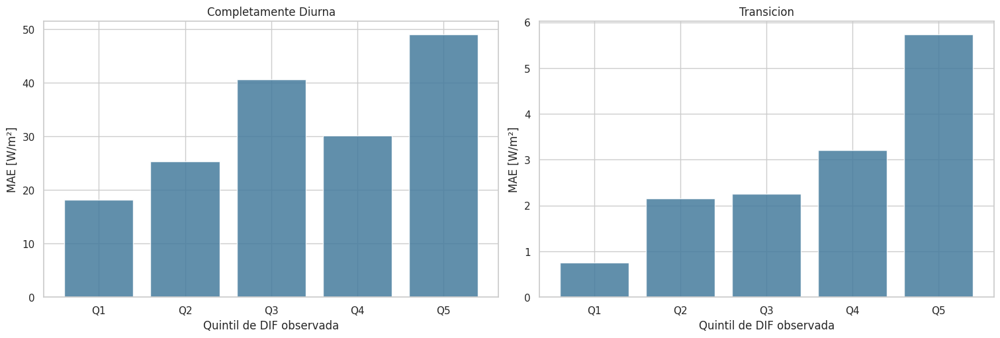

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for ax, regimen in zip(axes, ["completamente_diurna", "transicion"]):
    datos = errores_por_quintil_DIF.loc[errores_por_quintil_DIF["regimen"] == regimen]
    posiciones = np.arange(len(datos))
    ax.bar(posiciones, datos["MAE"], color="#457b9d", alpha=0.85)
    ax.set_xticks(posiciones)
    ax.set_xticklabels([f"Q{i + 1}" for i in range(len(datos))])
    ax.set_title(regimen.replace("_", " ").title())
    ax.set_xlabel("Quintil de DIF observada")
    ax.set_ylabel("MAE [W/m²]")

plt.show()

**Resultados.** En las horas completamente diurnas, el modelo sobreestima los cuatro primeros quintiles de DIF (sesgo entre 6,35 y 21,21 W/m²) e infraestima el superior (−32,52 W/m²), donde el MAE es máximo (49,09 W/m²); el nMAE, en cambio, es máximo en el primer quintil (39,49 %). En transición, el MAE crece de forma continua desde 0,76 hasta 5,74 W/m² entre el primer y el último quintil, en el que el sesgo es de −4,02 W/m².

### 3.16 Error según la elevación solar y el tipo de transición

Se analiza el error del HGB por bandas de elevación solar de la hora objetivo, empleada solo como variable diagnóstica, y, dentro de la transición, se distingue entre amanecer (elevación ascendente) y atardecer (elevación descendente). También se identifican los mayores errores individuales.

In [ ]:
limites_elevacion = [-np.inf, 0, 5, 10, 20, 30, 40, np.inf]
etiquetas_elevacion = ["<0°", "0–5°", "5–10°", "10–20°", "20–30°", "30–40°", "≥40°"]
df_errores["banda_elevacion_objetivo"] = pd.cut(
    df_errores["elevacion_media_objetivo"],
    bins=limites_elevacion,
    labels=etiquetas_elevacion,
    right=False,
)
filas_elevacion = []
for (regimen, banda), datos in df_errores.groupby(
    ["regimen_analisis", "banda_elevacion_objetivo"], observed=True
):
    if len(datos) == 0:
        continue

    error = datos[columna_error]
    error_abs = datos[columna_error_abs]
    filas_elevacion.append(
        {
            "regimen": regimen,
            "banda_elevacion": banda,
            "n": len(datos),
            "elevacion_media": datos["elevacion_media_objetivo"].mean(),
            "DIF_media": datos[OBJETIVO].mean(),
            "MAE": error_abs.mean(),
            "RMSE": np.sqrt(np.mean(error**2)),
            "sesgo": error.mean(),
            "p90_error_abs": error_abs.quantile(0.90),
        }
    )

errores_por_elevacion = pd.DataFrame(filas_elevacion)
display(errores_por_elevacion.round(4))


# AMANECER FRENTE A ATARDECER
transiciones = df_errores.loc[df_errores["regimen_analisis"] == "transicion"].copy()
transiciones["tipo_transicion"] = np.where(
    transiciones["delta_elevacion_objetivo"] >= 0, "ascendente_amanecer", "descendente_atardecer"
)
filas_tipo_transicion = []
for tipo, datos in transiciones.groupby("tipo_transicion"):
    for modelo in modelos_diagnostico:
        error = datos[modelo] - datos[OBJETIVO]
        filas_tipo_transicion.append(
            {
                "tipo_transicion": tipo,
                "modelo": modelo,
                "n": len(datos),
                "DIF_media": datos[OBJETIVO].mean(),
                "MAE": error.abs().mean(),
                "RMSE": np.sqrt(np.mean(error**2)),
                "sesgo": error.mean(),
                "mediana_error": error.median(),
                "p90_error_abs": error.abs().quantile(0.90),
            }
        )

errores_tipo_transicion = pd.DataFrame(filas_tipo_transicion)
display(errores_tipo_transicion.sort_values(["tipo_transicion", "MAE"]).round(4))

,regimen,banda_elevacion,n,elevacion_media,DIF_media,MAE,RMSE,sesgo,p90_error_abs
0,completamente_diurna,0–5°,11,4.5277,22.6485,14.3950,15.7482,-1.5805,21.6979
1,completamente_diurna,5–10°,72,7.6197,40.9398,8.5590,11.3793,-2.0785,19.3409
2,completamente_diurna,10–20°,137,15.1524,81.3630,17.7292,22.1309,-1.4065,34.7779
3,completamente_diurna,20–30°,147,25.2679,143.2677,34.1708,43.1512,2.1105,74.5798
4,completamente_diurna,30–40°,193,35.2318,195.1638,36.3197,45.7739,10.0393,76.8095
5,completamente_diurna,≥40°,205,46.4420,250.7935,47.5449,65.4757,7.3528,96.3557
6,noche,<0°,580,-21.1979,-0.9785,0.7749,0.8298,0.7652,0.7906
7,transicion,<0°,64,-2.1142,2.3680,1.3381,1.7357,0.0970,2.8531
8,transicion,0–5°,55,1.9180,12.9881,4.5588,5.5869,-1.4114,8.0780


,tipo_transicion,modelo,n,DIF_media,MAE,RMSE,sesgo,mediana_error,p90_error_abs
2,ascendente_amanecer,M3-HGB-8V-DIF-Elevacion-Global,60,7.8760,3.0440,4.2270,-1.0686,-0.9413,7.4789
1,ascendente_amanecer,M1-Ridge-DIF,60,7.8760,4.4037,5.6272,-0.0181,0.6347,7.7506
0,ascendente_amanecer,M0-Hibrido,60,7.8760,4.5331,7.3357,1.0636,0.4083,9.9233
5,descendente_atardecer,M3-HGB-8V-DIF-Elevacion-Global,59,6.6667,2.6056,3.7676,-0.1239,0.1964,6.1279
3,descendente_atardecer,M0-Hibrido,59,6.6667,3.4051,5.5878,0.8542,0.4500,10.4467
4,descendente_atardecer,M1-Ridge-DIF,59,6.6667,17.1423,20.0793,13.7196,14.3648,31.4783


In [ ]:
df_errores["mes"] = pd.to_datetime(df_errores.index).month
df_errores["mes_nombre"] = pd.to_datetime(df_errores.index).strftime("%Y-%m")


# ERROR MENSUAL POR RÉGIMEN
filas_mes_regimen = []
for (mes, regimen), datos in df_errores.groupby(["mes_nombre", "regimen_analisis"]):
    error = datos[columna_error]
    error_abs = datos[columna_error_abs]
    filas_mes_regimen.append(
        {
            "mes": mes,
            "regimen": regimen,
            "n": len(datos),
            "DIF_media": datos[OBJETIVO].mean(),
            "MAE": error_abs.mean(),
            "RMSE": np.sqrt(np.mean(error**2)),
            "sesgo": error.mean(),
            "p90_error_abs": error_abs.quantile(0.90),
            "p95_error_abs": error_abs.quantile(0.95),
        }
    )

errores_mes_regimen = pd.DataFrame(filas_mes_regimen)
display(errores_mes_regimen.sort_values(["mes", "regimen"]).round(4))


# 25 MAYORES ERRORES
columnas_extremos = [
    OBJETIVO,
    REGIMEN,
    "regimen_analisis",
    "elevacion_media_objetivo",
    "delta_elevacion_objetivo",
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    "M0-Hibrido",
    "M1-Ridge-DIF",
    MODELO_SELECCIONADO,
    columna_error,
    columna_error_abs,
]
mayores_errores_HGB = (
    df_errores[columnas_extremos]
    .sort_values(columna_error_abs, ascending=False)
    .head(25)
    .reset_index()
)
display(mayores_errores_HGB.round(4))

,mes,regimen,n,DIF_media,MAE,RMSE,sesgo,p90_error_abs,p95_error_abs
0,1970-01,completamente_diurna,765,162.7231,32.6575,46.2460,4.4384,73.7886,90.1629
1,1970-01,noche,580,-0.9785,0.7749,0.8298,0.7652,0.7906,1.0590
2,1970-01,transicion,119,7.2764,2.8267,4.0058,-0.6002,6.9203,7.7209


,index,DIF_objetivo_t1,regimen_solar_objetivo,regimen_analisis,elevacion_media_objetivo,delta_elevacion_objetivo,DIF_lag_1,DIF_lag_2,DIF_lag_3,DIF_lag_24,M0-Hibrido,M1-Ridge-DIF,M3-HGB-8V-DIF-Elevacion-Global,error__M3-HGB-8V-DIF-Elevacion-Global,error_abs__M3-HGB-8V-DIF-Elevacion-Global
0,5408,129.7167,completamente_diurna,completamente_diurna,52.1833,-0.8905,392.3167,130.6500,270.7833,304.6167,392.3167,387.3485,377.8127,248.0960,248.0960
1,5407,392.3167,completamente_diurna,completamente_diurna,53.0738,2.8237,130.6500,270.7833,286.0000,374.4667,130.6500,148.0847,179.8536,-212.4631,212.4631
2,5241,455.7000,completamente_diurna,completamente_diurna,49.7030,-4.4429,255.2167,424.9833,418.0167,318.7333,255.2167,216.8100,244.7403,-210.9597,210.9597
3,5410,401.8667,completamente_diurna,completamente_diurna,40.9863,-6.8386,194.5667,129.7167,392.3167,142.1833,194.5667,144.1222,202.8496,-199.0171,199.0171
4,5649,147.5500,completamente_diurna,completamente_diurna,44.7413,-4.2684,448.6833,383.0667,369.3167,282.8167,448.6833,399.4572,343.7092,196.1592,196.1592
5,5406,130.6500,completamente_diurna,completamente_diurna,50.2502,5.8084,270.7833,286.0000,156.4333,312.2034,270.7833,284.7040,324.6980,194.0480,194.0480
6,6079,140.0500,completamente_diurna,completamente_diurna,43.6512,2.0604,317.1833,291.4000,258.4833,247.1000,317.1833,294.4095,319.7077,179.6577,179.6577
7,5286,105.0000,completamente_diurna,completamente_diurna,51.5471,5.9404,215.1000,250.7667,130.9500,319.0500,215.1000,241.4985,275.9357,170.9357,170.9357
8,6151,87.0500,completamente_diurna,completamente_diurna,42.5291,1.9746,253.6000,183.7333,264.1500,208.3167,253.6000,232.8649,254.6239,167.5739,167.5739
9,5215,507.1000,completamente_diurna,completamente_diurna,55.2699,2.9889,321.8167,332.8000,220.7500,358.8500,321.8167,328.7946,341.5461,-165.5539,165.5539


**Resultados.** El error absoluto se concentra en las horas de mayor elevación e irradiancia.
- En las horas completamente diurnas, a partir de 5° el MAE aumenta con la elevación, de 8,56 W/m² (5–10°) a 47,54 W/m² (≥40°), en paralelo a la DIF media (de 40,94 a 250,79 W/m²).
- En transición, el MAE es 1,34 W/m² con elevación negativa y 4,56 W/m² entre 0° y 5°.
- El HGB tiene el menor MAE al amanecer (3,04 W/m², frente a 4,53 de la persistencia híbrida y 4,40 del Ridge) y al atardecer (2,61 W/m², frente a 3,41 y 17,14).
- Los 25 mayores errores individuales corresponden a horas completamente diurnas; el mayor alcanza 248,10 W/m².

### 3.17 Guardado del diagnóstico de errores

Se guardan las tablas, figuras y predicciones de validación del diagnóstico de errores, junto con el modelo `M3-HGB-8V-DIF-Elevacion-Global` y su lista de variables.

In [ ]:
import json
import joblib
import shutil
from pathlib import Path
from datetime import datetime
from google.colab import files

marca_tiempo = datetime.now().strftime("%Y%m%dT%H%M%S")
nombre_checkpoint = f"diagnostico_errores_" f"M3-HGB-8V-DIF-Elevacion-Global_" f"{marca_tiempo}"
carpeta = Path(nombre_checkpoint)
for subcarpeta in ["tablas", "datos", "figuras", "modelo", "configuracion"]:
    (carpeta / subcarpeta).mkdir(parents=True, exist_ok=True)


# 1. TABLAS
tablas_exportar = {
    "01_metricas_diagnostico.csv": metricas_diagnostico,
    "02_comparacion_horas_M0_M1.csv": comparacion_horas,
    "03_errores_por_quintil_DIF.csv": errores_por_quintil_DIF,
    "04_errores_por_elevacion.csv": errores_por_elevacion,
    "05_errores_tipo_transicion.csv": errores_tipo_transicion,
    "06_errores_mes_regimen.csv": errores_mes_regimen,
    "07_mayores_errores_HGB.csv": mayores_errores_HGB,
    "08_resumen_CV_ablacion_HGB.csv": resumen_CV_ablacion_HGB,
    "09_metricas_ablacion_HGB.csv": metricas_ablacion_HGB,
    "10_comprobacion_modelos_equivalentes.csv": comprobacion_modelos_equivalentes,
    "11_importancia_individual_14V.csv": importancia_individual,
    "12_importancia_bloques_14V.csv": importancia_bloques,
}
for nombre_archivo, tabla in tablas_exportar.items():
    tabla.to_csv(carpeta / "tablas" / nombre_archivo, index=False)


# 2. DATOS COMPLETOS DE ERRORES
df_errores_exportar = df_errores.reset_index().copy()
if df_errores_exportar.columns[0] == "index":
    df_errores_exportar = df_errores_exportar.rename(columns={"index": "timestamp"})

df_errores_exportar.to_csv(
    carpeta / "datos" / "13_predicciones_y_errores_validation.csv", index=False
)
df_errores_exportar.to_parquet(
    carpeta / "datos" / "13_predicciones_y_errores_validation.parquet", index=False
)


# 3. FIGURA: DISTRIBUCIÓN DEL ERROR FIRMADO
fig, axes = plt.subplots(1, 3, figsize=(18, 5), constrained_layout=True)
for ax, regimen in zip(axes, ["completamente_diurna", "transicion", "noche"]):
    datos = df_errores.loc[df_errores["regimen_analisis"] == regimen]
    sns.histplot(data=datos, x=columna_error, bins=35, kde=True, ax=ax, color="#2a9d8f")
    ax.axvline(0, color="black", linestyle="--")
    ax.axvline(
        datos[columna_error].mean(),
        color="red",
        linestyle=":",
        linewidth=2,
        label=(f"Media = " f"{datos[columna_error].mean():.2f}"),
    )
    ax.set_title(regimen.replace("_", " ").title())
    ax.set_xlabel("Predicción − observación [W/m²]")
    ax.legend()

fig.suptitle("Distribución del error por régimen", fontsize=15)
fig.savefig(
    carpeta / "figuras" / "01_distribucion_error_por_regimen.png", dpi=180, bbox_inches="tight"
)
plt.close(fig)


# 4. FIGURA: ERROR ABSOLUTO POR RÉGIMEN
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(
    data=df_errores,
    x="regimen_analisis",
    y=columna_error_abs,
    order=["completamente_diurna", "transicion", "noche"],
    showfliers=False,
    color="#8ecae6",
    ax=ax,
)
ax.set_title("Error absoluto por régimen solar")
ax.set_xlabel("Régimen")
ax.set_ylabel("Error absoluto [W/m²]")
fig.savefig(carpeta / "figuras" / "02_error_absoluto_por_regimen.png", dpi=180, bbox_inches="tight")
plt.close(fig)


# 5. FIGURA: OBSERVADO FRENTE A PREDICHO
fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
for ax, regimen in zip(axes, ["completamente_diurna", "transicion"]):
    datos = df_errores.loc[df_errores["regimen_analisis"] == regimen]
    if regimen == "completamente_diurna":
        grafico = ax.hexbin(
            datos[OBJETIVO],
            datos[MODELO_SELECCIONADO],
            gridsize=35,
            mincnt=1,
            cmap="viridis",
            bins="log",
        )
        fig.colorbar(grafico, ax=ax, label="Densidad logarítmica")

    else:
        ax.scatter(datos[OBJETIVO], datos[MODELO_SELECCIONADO], alpha=0.65, s=28, color="#2a9d8f")

    minimo = min(datos[OBJETIVO].min(), datos[MODELO_SELECCIONADO].min())
    maximo = max(datos[OBJETIVO].max(), datos[MODELO_SELECCIONADO].max())
    ax.plot([minimo, maximo], [minimo, maximo], color="red", linestyle="--")
    ax.set_title(regimen.replace("_", " ").title())
    ax.set_xlabel("DIF observada [W/m²]")
    ax.set_ylabel("DIF predicha [W/m²]")

fig.savefig(carpeta / "figuras" / "03_observado_frente_predicho.png", dpi=180, bbox_inches="tight")
plt.close(fig)


# 6. FIGURA: MAE POR QUINTIL DE DIF
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
for ax, regimen in zip(axes, ["completamente_diurna", "transicion"]):
    datos = errores_por_quintil_DIF.loc[errores_por_quintil_DIF["regimen"] == regimen]
    posiciones = np.arange(len(datos))
    ax.bar(posiciones, datos["MAE"], color="#457b9d")
    ax.set_xticks(posiciones)
    ax.set_xticklabels([f"Q{i + 1}" for i in range(len(datos))])
    ax.set_title(regimen.replace("_", " ").title())
    ax.set_xlabel("Quintil de DIF observada")
    ax.set_ylabel("MAE [W/m²]")

fig.savefig(carpeta / "figuras" / "04_MAE_por_quintil_DIF.png", dpi=180, bbox_inches="tight")
plt.close(fig)


# 7. FIGURA: MAE POR ELEVACIÓN Y RÉGIMEN
datos_figura_elevacion = errores_por_elevacion.loc[
    errores_por_elevacion["regimen"].isin(["completamente_diurna", "transicion"])
].copy()
fig, ax = plt.subplots(figsize=(13, 6))
sns.barplot(data=datos_figura_elevacion, x="banda_elevacion", y="MAE", hue="regimen", ax=ax)
ax.set_title("MAE según elevación y régimen solar")
ax.set_xlabel("Elevación media de la hora objetivo")
ax.set_ylabel("MAE [W/m²]")
ax.legend(title="Régimen")
fig.savefig(
    carpeta / "figuras" / "05_MAE_por_elevacion_y_regimen.png", dpi=180, bbox_inches="tight"
)
plt.close(fig)


# 8. FIGURA: AMANECER FRENTE A ATARDECER
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(data=errores_tipo_transicion, x="tipo_transicion", y="MAE", hue="modelo", ax=ax)
ax.set_title("MAE en transiciones ascendentes y descendentes")
ax.set_xlabel("Tipo de transición")
ax.set_ylabel("MAE [W/m²]")
ax.legend(title="Modelo", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.savefig(carpeta / "figuras" / "06_MAE_amanecer_atardecer.png", dpi=180, bbox_inches="tight")
plt.close(fig)


# 9. GUARDAR MODELO Y VARIABLES
joblib.dump(modelo_HGB_DIF_elevacion, carpeta / "modelo" / "M3-HGB-8V-DIF-Elevacion-Global.joblib")
pd.DataFrame(
    {"orden": range(1, len(features_HGB_DIF_elevacion) + 1), "variable": features_HGB_DIF_elevacion}
).to_csv(carpeta / "configuracion" / "14_variables_modelo_seleccionado.csv", index=False)


# 10. METADATOS
configuracion_diagnostico = {
    "modelo_principal": MODELO_SELECCIONADO,
    "variables": features_HGB_DIF_elevacion,
    "objetivo": OBJETIVO,
    "definicion_error": "prediccion - observacion",
    "interpretacion_error": {"positivo": "sobreestimacion", "negativo": "infraestimacion"},
    "poblaciones": ["total", "operativa_sin_noche", "completamente_diurna", "transicion", "noche"],
    "referencias": ["M0-Hibrido", "M1-Ridge-DIF"],
    "n_validation": int(len(df_errores)),
    "test_utilizado": False,
}
with open(
    carpeta / "configuracion" / "15_configuracion_diagnostico.json", "w", encoding="utf-8"
) as archivo:
    json.dump(configuracion_diagnostico, archivo, ensure_ascii=False, indent=2)


# 11. README
readme = """
DIAGNÓSTICO DE ERRORES
======================

Modelo:
M3-HGB-8V-DIF-Elevacion-Global

Objetivo:
Determinar dónde falla el modelo seleccionado y comparar
sus errores con M0-Hibrido y M1-Ridge-DIF.

Convención:
error = predicción - observación

- error positivo: sobreestimación;
- error negativo: infraestimación.

Análisis incluidos:
- métricas globales y por régimen;
- población operativa sin noche;
- porcentaje de horas ganadas;
- quintiles de DIF;
- bandas de elevación;
- amanecer frente a atardecer;
- meses;
- errores extremos.

No se ha utilizado el conjunto test.
"""
with open(carpeta / "README.txt", "w", encoding="utf-8") as archivo:
    archivo.write(readme.strip())


# 12. INVENTARIO Y ZIP
inventario = []
for ruta in sorted(carpeta.rglob("*")):
    if ruta.is_file():
        inventario.append(
            {"archivo": str(ruta.relative_to(carpeta)), "tamano_bytes": ruta.stat().st_size}
        )

pd.DataFrame(inventario).to_csv(carpeta / "16_inventario.csv", index=False)
ruta_zip = shutil.make_archive(base_name=nombre_checkpoint, format="zip", root_dir=carpeta)
print("ZIP generado correctamente:")
print(ruta_zip)
display(pd.DataFrame(inventario))
files.download(ruta_zip)

ZIP generado correctamente:
/content/diagnostico_errores_M3-HGB-8V-DIF-Elevacion-Global_20261003T175558.zip


,archivo,tamano_bytes
0,README.txt,586
1,configuracion/14_variables_modelo_seleccionado...,157
2,configuracion/15_configuracion_diagnostico.json,680
3,datos/13_predicciones_y_errores_validation.csv,1613988
4,datos/13_predicciones_y_errores_validation.par...,658350
5,figuras/01_distribucion_error_por_regimen.png,168271
6,figuras/02_error_absoluto_por_regimen.png,47623
7,figuras/03_observado_frente_predicho.png,251346
8,figuras/04_MAE_por_quintil_DIF.png,51017
9,figuras/05_MAE_por_elevacion_y_regimen.png,65183


### 3.18 Evolución temporal del error

Se recuperan las predicciones de validación y el modelo `M3-HGB-8V-DIF-Elevacion-Global`, con `instante_objetivo` como referencia temporal. Se calcula el cambio real y el predicho de la DIF respecto a la hora anterior, se representa su evolución en las horas de operación y se identifican los días con mayores errores.

> *Las subsecciones 3.18 a 3.20 son complementarias: no se utilizan en la memoria ni preparan datos para otras secciones.*

In [ ]:
from google.colab import files
from pathlib import Path
import zipfile
import shutil
import joblib
import pandas as pd
import numpy as np

archivos_subidos = files.upload()
zip_subido = next(
    Path(nombre)
    for nombre in archivos_subidos
    if nombre.lower().endswith(".zip") and "diagnostico_errores" in nombre
)
carpeta_checkpoint = Path("checkpoint_diagnostico_HGB8")
if carpeta_checkpoint.exists():
    shutil.rmtree(carpeta_checkpoint)

carpeta_checkpoint.mkdir()
with zipfile.ZipFile(zip_subido, "r") as archivo_zip:
    archivo_zip.extractall(carpeta_checkpoint)

ruta_datos = next(carpeta_checkpoint.rglob("13_predicciones_y_errores_validation.csv"))
ruta_modelo = next(carpeta_checkpoint.rglob("M3-HGB-8V-DIF-Elevacion-Global.joblib"))
ruta_variables = next(carpeta_checkpoint.rglob("14_variables_modelo_seleccionado.csv"))
df_temporal = pd.read_csv(ruta_datos)
df_temporal["instante_objetivo"] = pd.to_datetime(df_temporal["instante_objetivo"], utc=True)
df_temporal["instante_emision"] = pd.to_datetime(df_temporal["instante_emision"], utc=True)
df_temporal = df_temporal.sort_values("instante_objetivo").reset_index(drop=True)
modelo_HGB8 = joblib.load(ruta_modelo)
features_HGB8 = pd.read_csv(ruta_variables)["variable"].tolist()
OBJETIVO = "DIF_objetivo_t1"
PREDICCION = "M3-HGB-8V-DIF-Elevacion-Global"
print("Horas:", len(df_temporal))
print("Inicio:", df_temporal["instante_objetivo"].min())
print("Final:", df_temporal["instante_objetivo"].max())
print("Variables:", features_HGB8)
display(df_temporal[["instante_objetivo", OBJETIVO, PREDICCION, "regimen_solar_objetivo"]].head())

Horas: 1464
Inicio: 2024-08-01 00:00:00+00:00
Final: 2024-09-30 23:00:00+00:00
Variables: ['DIF_lag_1', 'DIF_lag_2', 'DIF_lag_3', 'DIF_lag_24', 'elevacion_media_lag1', 'elevacion_media_lag2', 'elevacion_media_lag3', 'elevacion_media_lag24']


,instante_objetivo,DIF_objetivo_t1,M3-HGB-8V-DIF-Elevacion-Global,regimen_solar_objetivo
0,2024-08-01 00:00:00+00:00,-1.0,-0.209362,noche
1,2024-08-01 01:00:00+00:00,-1.0,-0.209362,noche
2,2024-08-01 02:00:00+00:00,-1.0,-0.209362,noche
3,2024-08-01 03:00:00+00:00,0.4,-0.209362,noche
4,2024-08-01 04:00:00+00:00,28.8,16.085681,transicion


In [ ]:
df_temporal["error_HGB8"] = df_temporal[PREDICCION] - df_temporal[OBJETIVO]
df_temporal["error_abs_HGB8"] = df_temporal["error_HGB8"].abs()
df_temporal["incremento_DIF_real"] = df_temporal[OBJETIVO] - df_temporal["DIF_lag_1"]
df_temporal["incremento_DIF_predicho"] = df_temporal[PREDICCION] - df_temporal["DIF_lag_1"]
df_temporal["error_incremento"] = (
    df_temporal["incremento_DIF_predicho"] - df_temporal["incremento_DIF_real"]
)
df_temporal["dia_objetivo"] = df_temporal["instante_objetivo"].dt.floor("D")
df_temporal["es_operativa"] = df_temporal["regimen_solar_objetivo"] != "noche"
display(
    df_temporal[
        [
            "instante_objetivo",
            "regimen_solar_objetivo",
            "DIF_lag_1",
            OBJETIVO,
            PREDICCION,
            "incremento_DIF_real",
            "incremento_DIF_predicho",
            "error_HGB8",
        ]
    ]
    .head(10)
    .round(3)
)

,instante_objetivo,regimen_solar_objetivo,DIF_lag_1,DIF_objetivo_t1,M3-HGB-8V-DIF-Elevacion-Global,incremento_DIF_real,incremento_DIF_predicho,error_HGB8
0,2024-08-01 00:00:00+00:00,noche,-1.000,-1.000,-0.209,0.000,0.791,0.791
1,2024-08-01 01:00:00+00:00,noche,-1.000,-1.000,-0.209,0.000,0.791,0.791
2,2024-08-01 02:00:00+00:00,noche,-1.000,-1.000,-0.209,0.000,0.791,0.791
3,2024-08-01 03:00:00+00:00,noche,-1.000,0.400,-0.209,1.400,0.791,-0.609
4,2024-08-01 04:00:00+00:00,transicion,0.400,28.800,16.086,28.400,15.686,-12.714
5,2024-08-01 05:00:00+00:00,completamente_diurna,28.800,71.933,62.450,43.133,33.650,-9.484
6,2024-08-01 06:00:00+00:00,completamente_diurna,71.933,91.683,113.083,19.750,41.150,21.400
7,2024-08-01 07:00:00+00:00,completamente_diurna,91.683,166.767,139.185,75.083,47.502,-27.582
8,2024-08-01 08:00:00+00:00,completamente_diurna,166.767,318.467,210.676,151.700,43.909,-107.791
9,2024-08-01 09:00:00+00:00,completamente_diurna,318.467,263.317,337.296,-55.150,18.830,73.980


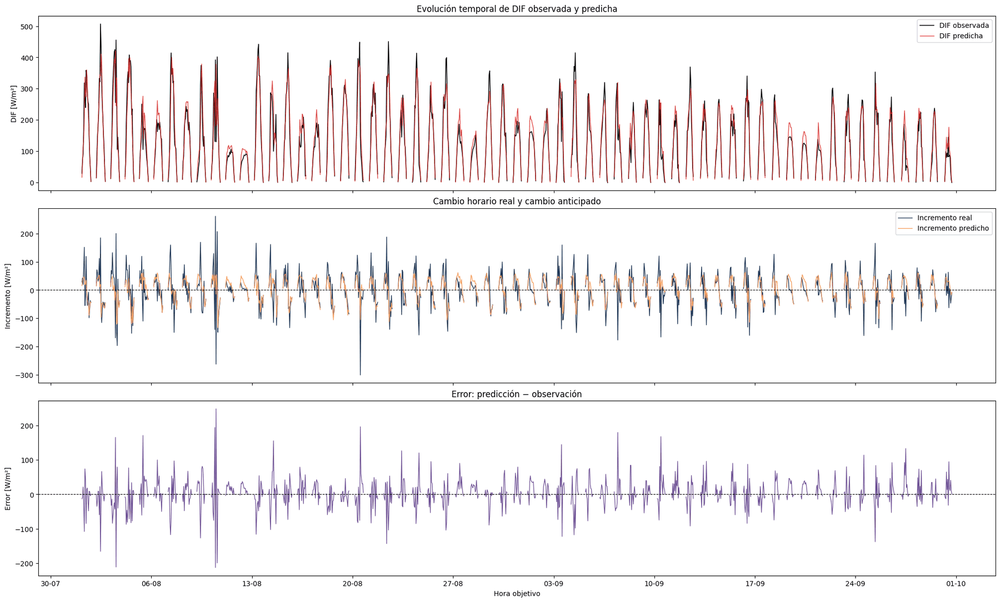

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

datos_operativos_grafico = df_temporal.copy()
columnas_ocultar_noche = [
    OBJETIVO,
    PREDICCION,
    "incremento_DIF_real",
    "incremento_DIF_predicho",
    "error_HGB8",
]
datos_operativos_grafico.loc[~datos_operativos_grafico["es_operativa"], columnas_ocultar_noche] = (
    np.nan
)
fig, axes = plt.subplots(3, 1, figsize=(20, 12), sharex=True, constrained_layout=True)

# Valores observado y predicho.
axes[0].plot(
    datos_operativos_grafico["instante_objetivo"],
    datos_operativos_grafico[OBJETIVO],
    label="DIF observada",
    color="black",
    linewidth=1.1,
)
axes[0].plot(
    datos_operativos_grafico["instante_objetivo"],
    datos_operativos_grafico[PREDICCION],
    label="DIF predicha",
    color="#d62828",
    linewidth=1,
    alpha=0.85,
)
axes[0].set_ylabel("DIF [W/m²]")
axes[0].set_title("Evolución temporal de DIF observada y predicha")
axes[0].legend()

# Incrementos.
axes[1].plot(
    datos_operativos_grafico["instante_objetivo"],
    datos_operativos_grafico["incremento_DIF_real"],
    label="Incremento real",
    color="#1d3557",
    linewidth=1,
)
axes[1].plot(
    datos_operativos_grafico["instante_objetivo"],
    datos_operativos_grafico["incremento_DIF_predicho"],
    label="Incremento predicho",
    color="#f4a261",
    linewidth=1,
)
axes[1].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[1].set_ylabel("Incremento [W/m²]")
axes[1].set_title("Cambio horario real y cambio anticipado")
axes[1].legend()

# Error.
axes[2].plot(
    datos_operativos_grafico["instante_objetivo"],
    datos_operativos_grafico["error_HGB8"],
    color="#6a4c93",
    linewidth=0.9,
)
axes[2].axhline(0, color="black", linestyle="--", linewidth=0.8)
axes[2].set_ylabel("Error [W/m²]")
axes[2].set_title("Error: predicción − observación")
axes[2].xaxis.set_major_locator(mdates.WeekdayLocator(interval=1))
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%d-%m"))
axes[2].set_xlabel("Hora objetivo")
plt.show()

In [ ]:
resumen_diario = (
    df_temporal.loc[df_temporal["es_operativa"]]
    .groupby("dia_objetivo")
    .agg(
        n_horas=(OBJETIVO, "size"),
        DIF_media=(OBJETIVO, "mean"),
        MAE=("error_abs_HGB8", "mean"),
        error_maximo=("error_abs_HGB8", "max"),
        incremento_real_maximo=("incremento_DIF_real", lambda x: x.abs().max()),
    )
    .reset_index()
    .sort_values("error_maximo", ascending=False)
)
print("Días con mayores errores máximos")
display(resumen_diario.head(15).round(3))

Días con mayores errores máximos


,dia_objetivo,n_horas,DIF_media,MAE,error_maximo,incremento_real_maximo
9,2024-08-10 00:00:00+00:00,16,162.959,68.978,248.096,262.600
2,2024-08-03 00:00:00+00:00,16,216.264,52.513,210.960,200.483
19,2024-08-20 00:00:00+00:00,15,176.290,46.050,196.159,301.133
37,2024-09-07 00:00:00+00:00,14,138.525,36.931,179.658,177.133
4,2024-08-05 00:00:00+00:00,16,115.889,38.186,170.936,119.817
40,2024-09-10 00:00:00+00:00,14,95.535,40.737,167.574,166.550
1,2024-08-02 00:00:00+00:00,16,208.853,28.688,165.554,185.283
13,2024-08-14 00:00:00+00:00,16,145.460,40.820,155.424,161.761
33,2024-09-03 00:00:00+00:00,15,154.856,42.501,144.525,159.900
21,2024-08-22 00:00:00+00:00,15,190.612,37.993,143.023,187.983


**Resultados.** El 10 de agosto de 2024 reúne el mayor error horario de validación (248,10 W/m²), con un MAE de 68,98 W/m² en sus 16 horas de operación y un cambio horario real de la DIF de hasta 262,60 W/m² en valor absoluto. Los días con mayores errores máximos coinciden con cambios horarios bruscos de la DIF, que llegan a 301,13 W/m² el 20 de agosto.

### 3.19 Divisiones de los árboles del HGB

Se recorren los árboles de `M3-HGB-8V-DIF-Elevacion-Global` para contar, por variable, el número de divisiones y su ganancia acumulada y media: la frecuencia indica cuánto se usa una variable y la ganancia, cuánto mejora las particiones, sin implicar causalidad. Se representa además el árbol de mayor ganancia, que es solo uno de los árboles cuyas contribuciones se suman en la predicción.

In [ ]:
# Comprobación de la estructura interna.
assert hasattr(modelo_HGB8, "_predictors"), (
    "Esta versión de scikit-learn no expone la estructura esperada del HGB."
)
nombres_variables_modelo = list(modelo_HGB8.feature_names_in_)
filas_divisiones = []
ganancia_arboles = []
for etapa, predictores_etapa in enumerate(modelo_HGB8._predictors):
    predictor = predictores_etapa[0]
    nodos = predictor.nodes
    ganancia_arbol = 0.0
    for numero_nodo, nodo in enumerate(nodos):
        if bool(nodo["is_leaf"]):
            continue

        indice_variable = int(nodo["feature_idx"])
        ganancia = float(nodo["gain"])
        ganancia_arbol += ganancia
        filas_divisiones.append(
            {
                "etapa": etapa,
                "nodo": numero_nodo,
                "profundidad": int(nodo["depth"]),
                "variable": nombres_variables_modelo[indice_variable],
                "umbral": float(nodo["num_threshold"]),
                "n_observaciones": int(nodo["count"]),
                "ganancia": ganancia,
                "missing_hacia_izquierda": bool(nodo["missing_go_to_left"]),
            }
        )

    ganancia_arboles.append({"etapa": etapa, "ganancia_total": ganancia_arbol})

divisiones_HGB8 = pd.DataFrame(filas_divisiones)
resumen_divisiones_HGB8 = (
    divisiones_HGB8.groupby("variable")
    .agg(
        numero_divisiones=("variable", "size"),
        ganancia_total=("ganancia", "sum"),
        ganancia_media=("ganancia", "mean"),
        profundidad_media=("profundidad", "mean"),
    )
    .reset_index()
)
resumen_divisiones_HGB8["porcentaje_ganancia"] = (
    100
    * resumen_divisiones_HGB8["ganancia_total"]
    / resumen_divisiones_HGB8["ganancia_total"].sum()
)
resumen_divisiones_HGB8 = resumen_divisiones_HGB8.sort_values(
    "ganancia_total", ascending=False
).reset_index(drop=True)
display(resumen_divisiones_HGB8.round(4))

,variable,numero_divisiones,ganancia_total,ganancia_media,profundidad_media,porcentaje_ganancia
0,elevacion_media_lag24,354,6.291523e+08,1.777266e+06,1.4124,61.9251
1,DIF_lag_1,499,3.642531e+08,7.299661e+05,1.4930,35.8520
2,elevacion_media_lag3,255,1.170306e+07,4.589436e+04,1.9255,1.1519
3,DIF_lag_24,208,4.277593e+06,2.056535e+04,1.9712,0.4210
4,DIF_lag_2,170,2.493529e+06,1.466782e+04,2.4000,0.2454
5,DIF_lag_3,160,1.985127e+06,1.240704e+04,1.9188,0.1954
6,elevacion_media_lag1,82,1.066507e+06,1.300619e+04,1.8171,0.1050
7,elevacion_media_lag2,72,1.058441e+06,1.470057e+04,2.6806,0.1042


In [ ]:
tabla_ganancia_arboles = pd.DataFrame(ganancia_arboles)
etapa_representativa = int(
    tabla_ganancia_arboles.loc[tabla_ganancia_arboles["ganancia_total"].idxmax(), "etapa"]
)
predictor_representativo = modelo_HGB8._predictors[etapa_representativa][0]
nodos_representativos = predictor_representativo.nodes
print("Etapa representada:", etapa_representativa)
print(
    "Ganancia acumulada:",
    tabla_ganancia_arboles.loc[
        tabla_ganancia_arboles["etapa"] == etapa_representativa, "ganancia_total"
    ].iloc[0],
)

Etapa representada: 0
Ganancia acumulada: 56288167.692865685


In [ ]:
def imprimir_reglas_HGB(nodos, numero_nodo=0, sangria=""):
    nodo = nodos[numero_nodo]
    if bool(nodo["is_leaf"]):
        print(
            sangria
            + "→ Hoja: contribución interna = "
            + f"{float(nodo['value']):.4f}; "
            + f"n = {int(nodo['count'])}"
        )
        return

    variable = nombres_variables_modelo[int(nodo["feature_idx"])]
    umbral = float(nodo["num_threshold"])
    missing_izquierda = bool(nodo["missing_go_to_left"])
    print(
        sangria
        + f"¿{variable} ≤ {umbral:.4f}? "
        + f"(n={int(nodo['count'])}, "
        + f"ganancia={float(nodo['gain']):.2f})"
    )
    etiqueta_missing = "incluye NaN" if missing_izquierda else "NaN va a la derecha"
    print(sangria + f"  Sí ({etiqueta_missing})")
    imprimir_reglas_HGB(nodos, int(nodo["left"]), sangria + "    ")
    print(sangria + "  No")
    imprimir_reglas_HGB(nodos, int(nodo["right"]), sangria + "    ")

imprimir_reglas_HGB(nodos_representativos)

¿elevacion_media_lag24 ≤ 21.8466? (n=5149, ganancia=43859811.78)
  Sí (incluye NaN)
    ¿elevacion_media_lag24 ≤ 7.8689? (n=3614, ganancia=3674966.94)
      Sí (incluye NaN)
        → Hoja: contribución interna = -2.3258; n = 2786
      No
        → Hoja: contribución interna = -0.0495; n = 828
  No
    ¿DIF_lag_1 ≤ 194.4000? (n=1535, ganancia=5822257.91)
      Sí (NaN va a la derecha)
        ¿DIF_lag_1 ≤ 108.6500? (n=716, ganancia=855446.00)
          Sí (NaN va a la derecha)
            → Hoja: contribución interna = 1.0008; n = 289
          No
            → Hoja: contribución interna = 3.1182; n = 427
      No
        ¿DIF_lag_1 ≤ 314.1167? (n=819, ganancia=1618916.96)
          Sí (incluye NaN)
            ¿elevacion_media_lag24 ≤ 38.2536? (n=536, ganancia=456768.12)
              Sí (NaN va a la derecha)
                → Hoja: contribución interna = 3.8516; n = 209
              No
                → Hoja: contribución interna = 5.6967; n = 327
          No
            → Hoja: c

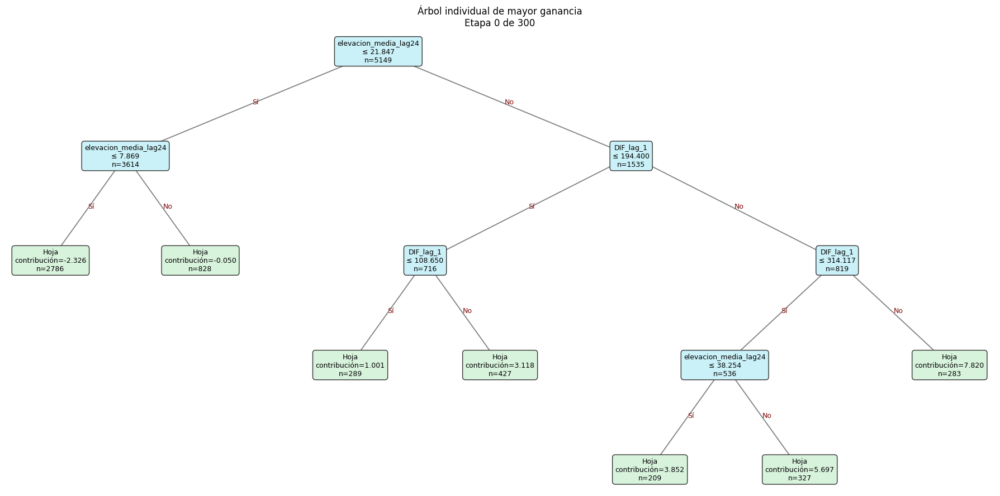

In [ ]:
import matplotlib.pyplot as plt

posiciones = {}
contador_hojas = [0]

def asignar_posiciones(nodos, numero_nodo=0):
    nodo = nodos[numero_nodo]
    profundidad = int(nodo["depth"])
    if bool(nodo["is_leaf"]):
        x = contador_hojas[0]
        contador_hojas[0] += 1
        posiciones[numero_nodo] = (x, -profundidad)
        return x

    x_izquierda = asignar_posiciones(nodos, int(nodo["left"]))
    x_derecha = asignar_posiciones(nodos, int(nodo["right"]))
    x = (x_izquierda + x_derecha) / 2
    posiciones[numero_nodo] = (x, -profundidad)
    return x

asignar_posiciones(nodos_representativos)
fig, ax = plt.subplots(figsize=(18, 9))
for numero_nodo, nodo in enumerate(nodos_representativos):
    x, y = posiciones[numero_nodo]
    if bool(nodo["is_leaf"]):
        texto = "Hoja\n" f"contribución={float(nodo['value']):.3f}\n" f"n={int(nodo['count'])}"
        color = "#d8f3dc"

    else:
        variable = nombres_variables_modelo[int(nodo["feature_idx"])]
        texto = f"{variable}\n" f"≤ {float(nodo['num_threshold']):.3f}\n" f"n={int(nodo['count'])}"
        color = "#caf0f8"
        for hijo, respuesta in [(int(nodo["left"]), "Sí"), (int(nodo["right"]), "No")]:
            x_hijo, y_hijo = posiciones[hijo]
            ax.plot([x, x_hijo], [y, y_hijo], color="gray", linewidth=1.3)
            ax.text((x + x_hijo) / 2, (y + y_hijo) / 2, respuesta, fontsize=9, color="darkred")

    ax.text(
        x,
        y,
        texto,
        ha="center",
        va="center",
        fontsize=9,
        bbox={"boxstyle": "round,pad=0.4", "facecolor": color, "edgecolor": "#333333"},
    )

ax.set_title(
    "Árbol individual de mayor ganancia\n"
    f"Etapa {etapa_representativa} de "
    f"{modelo_HGB8.n_iter_}"
)
ax.axis("off")
plt.tight_layout()
plt.show()

**Resultados.** `elevacion_media_lag24` reúne el 61,93 % de la ganancia total con 354 divisiones, y `DIF_lag_1`, la variable con más divisiones (499), el 35,85 %; la siguiente, `elevacion_media_lag3`, aporta solo el 1,15 %. El árbol de mayor ganancia, el de la primera etapa, divide primero por `elevacion_media_lag24` (umbral de 21,85°) y, por encima de ese valor, por niveles de `DIF_lag_1`.

### 3.20 Cambios horarios y contribuciones SHAP

Se compara el cambio horario real de la DIF con el anticipado por el modelo (acierto del signo, infraestimación de los aumentos, suavizado de los descensos y error en las rampas grandes); el cambio real contiene el objetivo y solo se usa como diagnóstico. Después se calculan los valores SHAP del HGB de 8 variables para obtener su importancia global y por régimen, la dependencia de las variables principales, el papel de `DIF_lag_24` por quintiles y la descomposición de los casos más extremos.

In [ ]:
filas_rampas = []
for regimen in ["completamente_diurna", "transicion"]:
    datos = df_temporal.loc[df_temporal["regimen_solar_objetivo"] == regimen].copy()
    incremento_real = datos["incremento_DIF_real"]
    incremento_predicho = datos["incremento_DIF_predicho"]
    signo_correcto = np.sign(incremento_real) == np.sign(incremento_predicho)

    # Aumentos reales.
    mascara_aumento = incremento_real > 0

    # Descensos reales.
    mascara_descenso = incremento_real < 0

    # Rampas grandes: 20 % de mayor magnitud
    # dentro de cada régimen.
    umbral_rampa_grande = incremento_real.abs().quantile(0.80)
    mascara_grande = incremento_real.abs() >= umbral_rampa_grande
    filas_rampas.append(
        {
            "regimen": regimen,
            "n": len(datos),
            "porcentaje_signo_correcto": 100 * signo_correcto.mean(),
            "n_aumentos": int(mascara_aumento.sum()),
            "porcentaje_aumentos_infraestimados": 100
            * (incremento_predicho[mascara_aumento] < incremento_real[mascara_aumento]).mean(),
            "sesgo_incremento_en_aumentos": (
                incremento_predicho[mascara_aumento] - incremento_real[mascara_aumento]
            ).mean(),
            "n_descensos": int(mascara_descenso.sum()),
            "porcentaje_descensos_suavizados": 100
            * (incremento_predicho[mascara_descenso] > incremento_real[mascara_descenso]).mean(),
            "sesgo_incremento_en_descensos": (
                incremento_predicho[mascara_descenso] - incremento_real[mascara_descenso]
            ).mean(),
            "umbral_rampa_grande": umbral_rampa_grande,
            "MAE_rampas_grandes": (
                incremento_predicho[mascara_grande] - incremento_real[mascara_grande]
            )
            .abs()
            .mean(),
            "MAE_resto_rampas": (
                incremento_predicho[~mascara_grande] - incremento_real[~mascara_grande]
            )
            .abs()
            .mean(),
        }
    )

diagnostico_rampas = pd.DataFrame(filas_rampas)
display(diagnostico_rampas.round(3))

,regimen,n,porcentaje_signo_correcto,n_aumentos,porcentaje_aumentos_infraestimados,sesgo_incremento_en_aumentos,n_descensos,porcentaje_descensos_suavizados,sesgo_incremento_en_descensos,umbral_rampa_grande,MAE_rampas_grandes,MAE_resto_rampas
0,completamente_diurna,765,79.216,418,62.201,-15.159,347,74.928,28.045,73.924,67.147,24.035
1,transicion,119,99.160,60,66.667,-1.069,59,52.542,-0.124,43.873,3.229,2.725


In [ ]:
try:
    import shap
    print("SHAP ya está instalado:", shap.__version__)

except ImportError:
    !pip -q install shap
    import shap
    print("SHAP instalado:", shap.__version__)

SHAP ya está instalado: 0.52.0


In [ ]:
X_SHAP = df_temporal[features_HGB8].copy()
explainer_HGB8 = shap.TreeExplainer(modelo_HGB8)
valores_SHAP_HGB8 = explainer_HGB8(X_SHAP)
print("Dimensiones SHAP:", valores_SHAP_HGB8.values.shape)

# Comprobación de aditividad.
prediccion_reconstruida = valores_SHAP_HGB8.base_values + valores_SHAP_HGB8.values.sum(axis=1)
diferencia_reconstruccion = np.max(
    np.abs(prediccion_reconstruida - df_temporal[PREDICCION].to_numpy())
)
print(
    "Máxima diferencia entre la predicción y su reconstrucción SHAP:", diferencia_reconstruccion
)

Dimensiones SHAP: (1464, 8)
Máxima diferencia entre la predicción y su reconstrucción SHAP: 1.5031143583544804


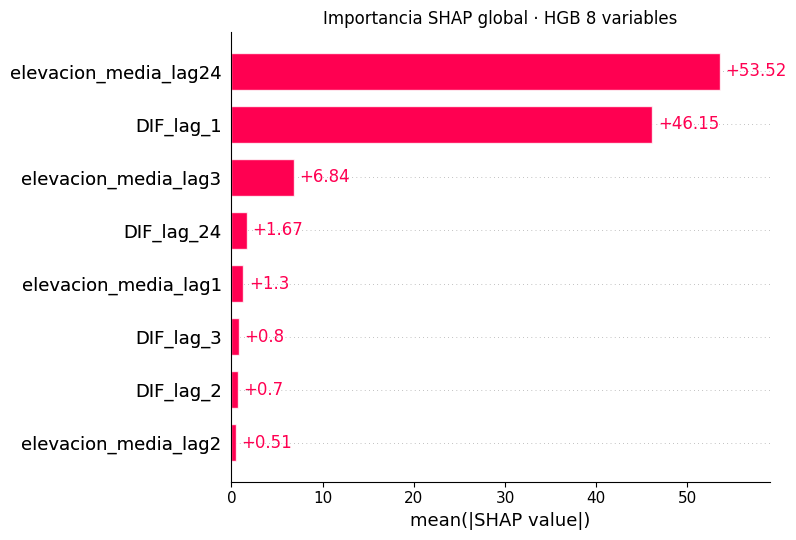

In [ ]:
shap.plots.bar(valores_SHAP_HGB8, max_display=8, show=False)
plt.title("Importancia SHAP global · HGB 8 variables")
plt.tight_layout()
plt.show()

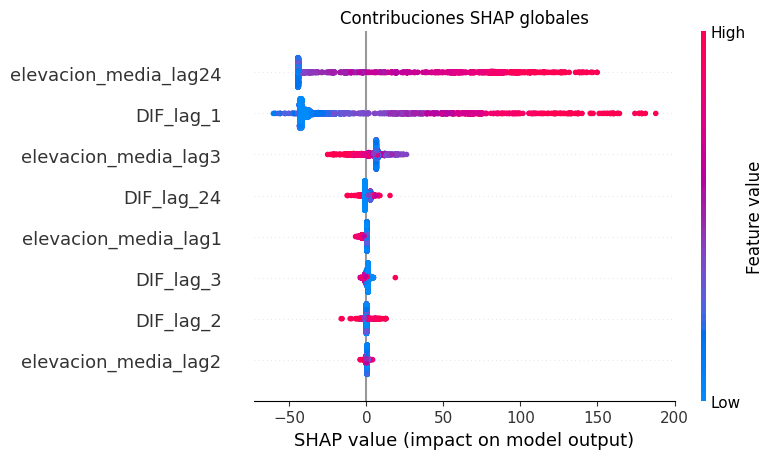

In [ ]:
shap.plots.beeswarm(valores_SHAP_HGB8, max_display=8, show=False)
plt.title("Contribuciones SHAP globales")
plt.tight_layout()
plt.show()

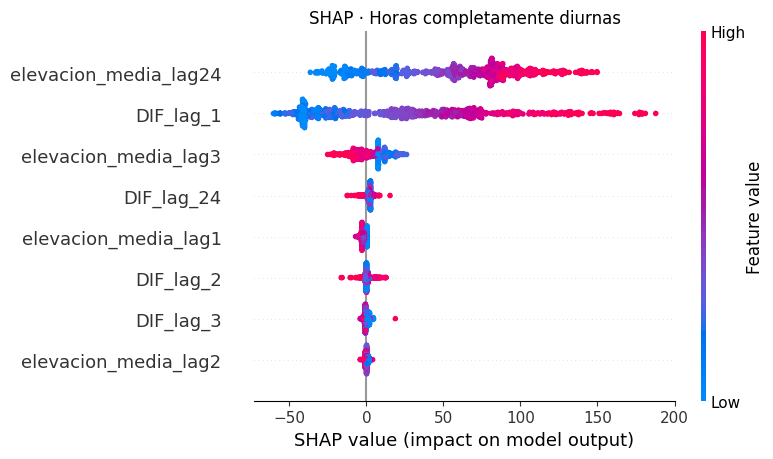

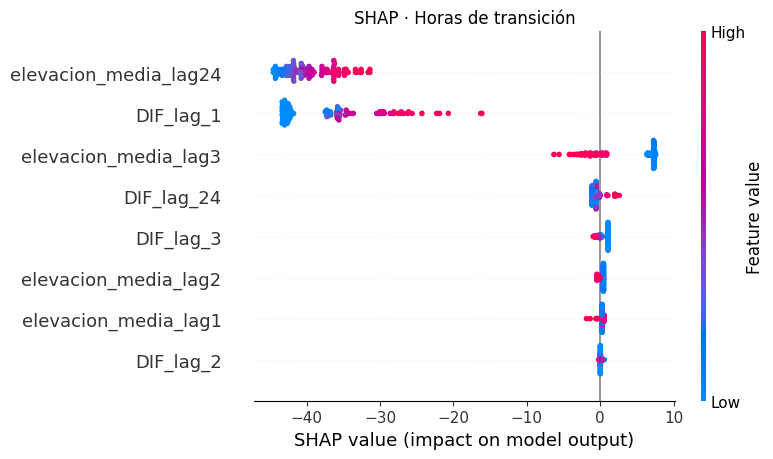

In [ ]:
mascara_diurna = (df_temporal["regimen_solar_objetivo"] == "completamente_diurna").to_numpy()
mascara_transicion = (df_temporal["regimen_solar_objetivo"] == "transicion").to_numpy()
shap.plots.beeswarm(valores_SHAP_HGB8[mascara_diurna], max_display=8, show=False)
plt.title("SHAP · Horas completamente diurnas")
plt.tight_layout()
plt.show()
shap.plots.beeswarm(valores_SHAP_HGB8[mascara_transicion], max_display=8, show=False)
plt.title("SHAP · Horas de transición")
plt.tight_layout()
plt.show()

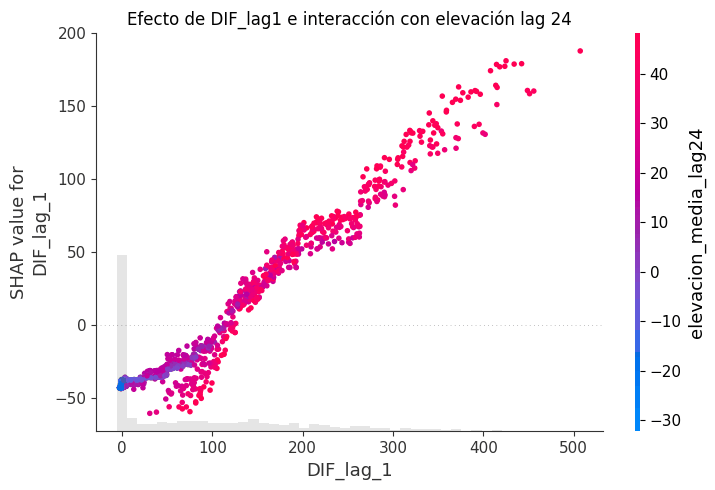

In [ ]:
shap.plots.scatter(
    valores_SHAP_HGB8[:, "DIF_lag_1"],
    color=valores_SHAP_HGB8[:, "elevacion_media_lag24"],
    show=False,
)
plt.title("Efecto de DIF_lag1 e interacción con elevación lag 24")
plt.tight_layout()
plt.show()

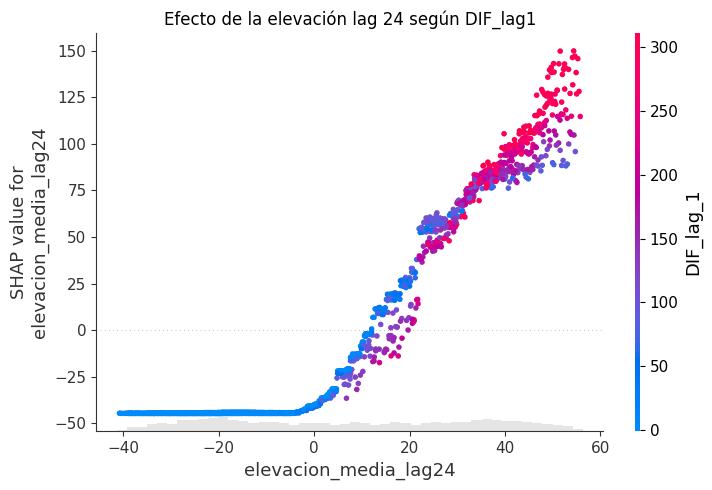

In [ ]:
shap.plots.scatter(
    valores_SHAP_HGB8[:, "elevacion_media_lag24"],
    color=valores_SHAP_HGB8[:, "DIF_lag_1"],
    show=False,
)
plt.title("Efecto de la elevación lag 24 según DIF_lag1")
plt.tight_layout()
plt.show()

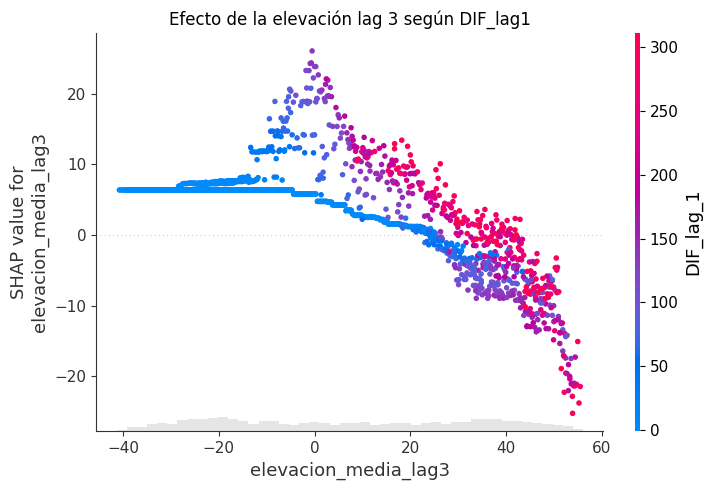

In [ ]:
shap.plots.scatter(
    valores_SHAP_HGB8[:, "elevacion_media_lag3"],
    color=valores_SHAP_HGB8[:, "DIF_lag_1"],
    show=False,
)
plt.title("Efecto de la elevación lag 3 según DIF_lag1")
plt.tight_layout()
plt.show()

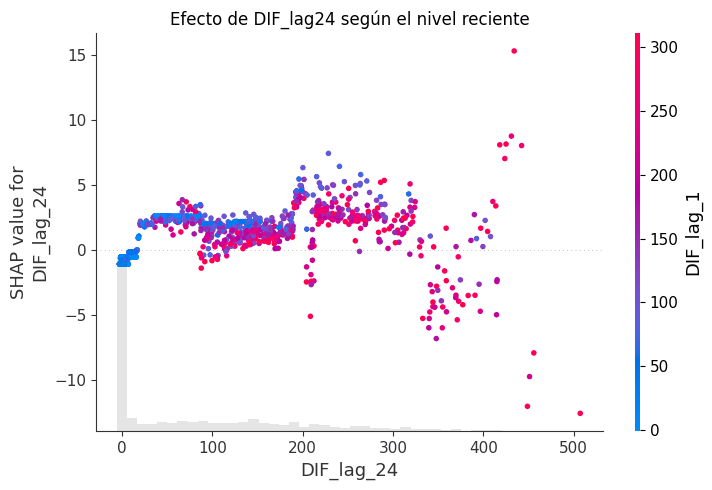

In [ ]:
shap.plots.scatter(
    valores_SHAP_HGB8[:, "DIF_lag_24"], color=valores_SHAP_HGB8[:, "DIF_lag_1"], show=False
)
plt.title("Efecto de DIF_lag24 según el nivel reciente")
plt.tight_layout()
plt.show()

In [ ]:
indice_DIF_lag24 = features_HGB8.index("DIF_lag_24")
df_hipotesis_lag24 = df_temporal.loc[
    df_temporal["regimen_solar_objetivo"] == "completamente_diurna"
].copy()
df_hipotesis_lag24["SHAP_DIF_lag24"] = valores_SHAP_HGB8.values[mascara_diurna, indice_DIF_lag24]
df_hipotesis_lag24["exceso_DIF_dia_anterior"] = (
    df_hipotesis_lag24["DIF_lag_24"] - df_hipotesis_lag24["DIF_lag_1"]
)
df_hipotesis_lag24["quintil_lag24"] = pd.qcut(
    df_hipotesis_lag24["DIF_lag_24"], q=5, duplicates="drop"
)
resumen_hipotesis_lag24 = (
    df_hipotesis_lag24.groupby("quintil_lag24", observed=True)
    .agg(
        n=("DIF_lag_24", "size"),
        DIF_lag24_media=("DIF_lag_24", "mean"),
        DIF_lag1_media=("DIF_lag_1", "mean"),
        DIF_objetivo_media=(OBJETIVO, "mean"),
        prediccion_media=(PREDICCION, "mean"),
        sesgo_medio=("error_HGB8", "mean"),
        MAE=("error_abs_HGB8", "mean"),
        SHAP_lag24_medio=("SHAP_DIF_lag24", "mean"),
    )
    .reset_index()
)
display(resumen_hipotesis_lag24.round(3))

,quintil_lag24,n,DIF_lag24_media,DIF_lag1_media,DIF_objetivo_media,prediccion_media,sesgo_medio,MAE,SHAP_lag24_medio
0,"(3.149, 72.94]",153,47.474,69.720,67.026,65.352,-1.674,16.152,2.212
1,"(72.94, 126.183]",153,98.371,131.162,131.973,134.736,2.762,24.154,1.557
2,"(126.183, 177.093]",153,149.672,168.233,170.788,174.967,4.179,33.022,1.429
3,"(177.093, 255.323]",153,211.738,197.987,209.267,213.959,4.692,40.265,2.739
4,"(255.323, 507.1]",153,324.479,231.694,234.561,246.793,12.233,49.695,0.929



 Mayor sobreestimación
Hora: 2024-08-10 12:00:00+00:00
Observado: 129.717
Predicho: 377.813
Error: 248.096


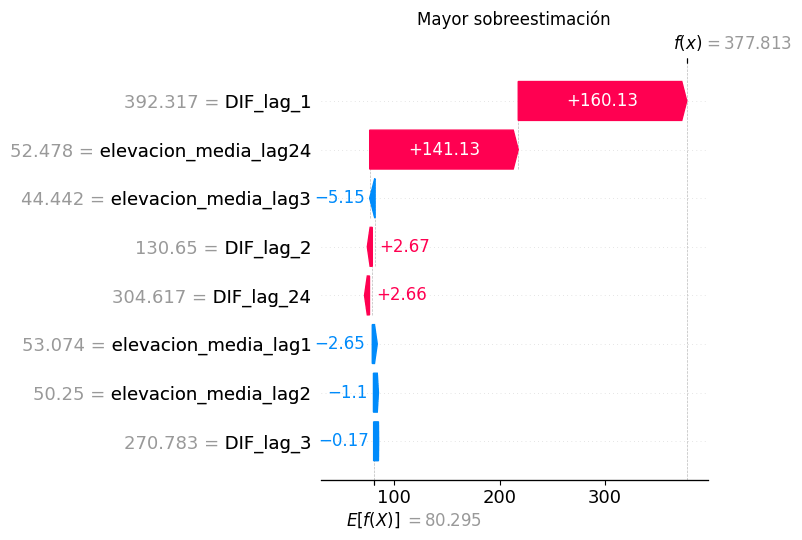


 Mayor infraestimación
Hora: 2024-08-10 11:00:00+00:00
Observado: 392.317
Predicho: 179.854
Error: -212.463


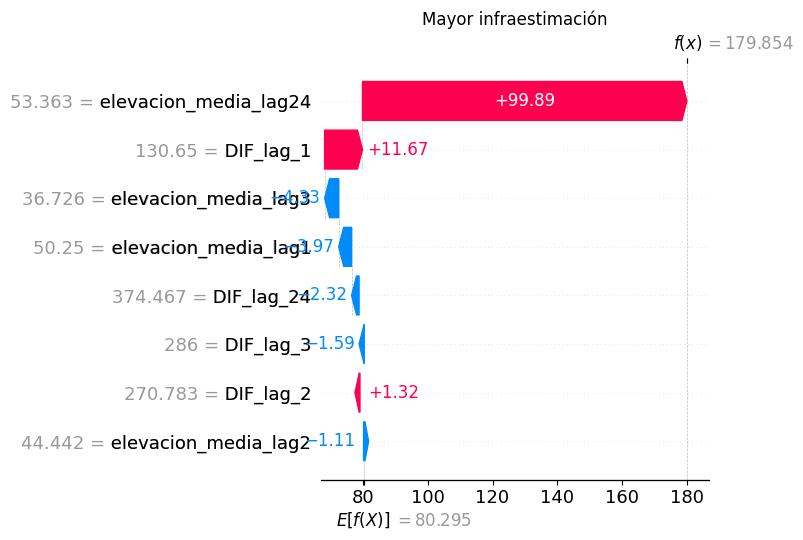


 Mayor error en transición
Hora: 2024-08-21 18:00:00+00:00
Observado: 26.833
Predicho: 13.206
Error: -13.628


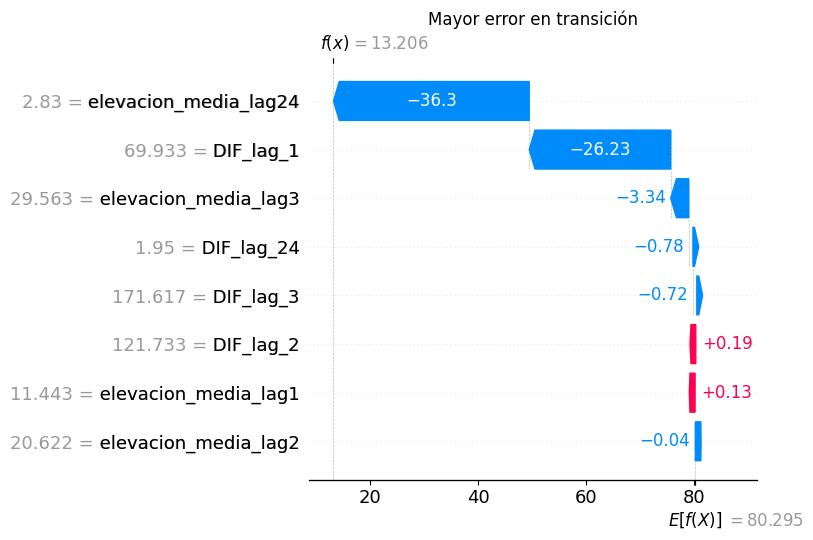

In [ ]:
indice_sobreestimacion = df_temporal["error_HGB8"].idxmax()
indice_infraestimacion = df_temporal["error_HGB8"].idxmin()
indice_transicion_extrema = df_temporal.loc[
    df_temporal["regimen_solar_objetivo"] == "transicion", "error_abs_HGB8"
].idxmax()
casos_explicar = {
    "Mayor sobreestimación": indice_sobreestimacion,
    "Mayor infraestimación": indice_infraestimacion,
    "Mayor error en transición": indice_transicion_extrema,
}
for titulo, indice in casos_explicar.items():
    fila = df_temporal.loc[indice]
    print("\n", titulo)
    print("Hora:", fila["instante_objetivo"])
    print("Observado:", round(fila[OBJETIVO], 3))
    print("Predicho:", round(fila[PREDICCION], 3))
    print("Error:", round(fila["error_HGB8"], 3))
    shap.plots.waterfall(valores_SHAP_HGB8[indice], max_display=8, show=False)
    plt.title(titulo)
    plt.tight_layout()
    plt.show()

**Resultados.** El modelo identifica bien la dirección del cambio, pero suaviza su magnitud.
- Completamente diurno: acierta el signo en el 79,22 % de las horas, infraestima el 62,20 % de los aumentos y suaviza el 74,93 % de los descensos; en el 20 % de rampas de mayor magnitud (al menos 73,92 W/m²) el MAE es 67,15 W/m², frente a 24,04 W/m² en el resto.
- Transición: acierta el signo en el 99,16 % de las horas.
- Por quintiles de `DIF_lag_24`, el MAE diurno crece de 16,15 a 49,7 W/m², pero la contribución SHAP media de esa variable no supera 2,74 W/m².
- Los mayores errores corresponden a dos horas consecutivas del 10 de agosto (infraestimación de 212,46 W/m² y sobreestimación de 248,10 W/m²).

### 3.21 Recuperación del HGB de 8 variables

Se recuperan, sin reentrenar ningún modelo, las 1.464 horas de validación con las predicciones de `M3-HGB-8V-DIF-Elevacion-Global` y de las referencias, con el fin de recalcular el análisis mensual a partir de `instante_objetivo`, ya que el cálculo anterior interpretó el índice numérico de las filas como fecha.

> *Las subsecciones 3.21 a 3.23 son complementarias: no se utilizan en la memoria. Se conservan porque recuperan el modelo y el soporte de entrenamiento que usan las siguientes.*

In [ ]:
from google.colab import files
from pathlib import Path
import zipfile
import shutil
import json
import joblib
import numpy as np
import pandas as pd

archivos_subidos = files.upload()
if len(archivos_subidos) != 1:
    raise ValueError("Sube únicamente el ZIP del diagnóstico HGB-8V.")

nombre_zip = next(iter(archivos_subidos))
ruta_zip = Path(nombre_zip)
carpeta_checkpoint = Path("checkpoint_M3_HGB_8V_diagnostico")
if carpeta_checkpoint.exists():
    shutil.rmtree(carpeta_checkpoint)

carpeta_checkpoint.mkdir(parents=True)
with zipfile.ZipFile(ruta_zip, "r") as archivo_zip:
    archivo_zip.extractall(carpeta_checkpoint)

print(f"ZIP extraído en: {carpeta_checkpoint}")


# Rutas exactas verificadas en el ZIP
ruta_parquet = carpeta_checkpoint / "datos" / "13_predicciones_y_errores_validation.parquet"
ruta_csv = carpeta_checkpoint / "datos" / "13_predicciones_y_errores_validation.csv"
ruta_modelo = carpeta_checkpoint / "modelo" / "M3-HGB-8V-DIF-Elevacion-Global.joblib"
ruta_configuracion = carpeta_checkpoint / "configuracion" / "15_configuracion_diagnostico.json"
try:
    df_validation = pd.read_parquet(ruta_parquet)
    print("Datos cargados desde parquet.")

except Exception as error_parquet:
    print("No se pudo abrir el parquet; se utilizará la copia CSV.")
    print("Motivo:", error_parquet)
    df_validation = pd.read_csv(ruta_csv)


# En CSV, timestamp aparece como columna.
# En parquet puede aparecer como índice.
if "timestamp" not in df_validation.columns and df_validation.index.name == "timestamp":
    df_validation = df_validation.reset_index()


# Fechas correctas
df_validation["instante_emision"] = pd.to_datetime(
    df_validation["instante_emision"], utc=True, errors="raise"
)
df_validation["instante_objetivo"] = pd.to_datetime(
    df_validation["instante_objetivo"], utc=True, errors="raise"
)
with open(ruta_configuracion, "r", encoding="utf-8") as archivo:
    configuracion_HGB8 = json.load(archivo)

modelo_HGB8 = joblib.load(ruta_modelo)


# Definiciones exactas del checkpoint
VARIABLES_HGB8 = [
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    "elevacion_media_lag1",
    "elevacion_media_lag2",
    "elevacion_media_lag3",
    "elevacion_media_lag24",
]
COLUMNA_OBJETIVO = "DIF_objetivo_t1"
COLUMNA_PREDICCION = "M3-HGB-8V-DIF-Elevacion-Global"
COLUMNA_REGIMEN = "regimen_solar_objetivo"
COLUMNA_FECHA = "instante_objetivo"


# Comprobaciones estrictas
columnas_necesarias = VARIABLES_HGB8 + [
    COLUMNA_OBJETIVO,
    COLUMNA_PREDICCION,
    COLUMNA_REGIMEN,
    COLUMNA_FECHA,
    "delta_DIF_t",
    "delta_DIF_t_menos_1",
    "particion",
]
columnas_ausentes = [
    columna for columna in columnas_necesarias if columna not in df_validation.columns
]
if columnas_ausentes:
    raise ValueError("Faltan columnas necesarias:\n" + "\n".join(columnas_ausentes))

assert len(df_validation) == 1464
assert set(df_validation["particion"]) == {"validation"}
assert np.allclose(
    df_validation["delta_DIF_t"], (df_validation["DIF_lag_1"] - df_validation["DIF_lag_2"])
)
assert np.allclose(
    df_validation["delta_DIF_t_menos_1"], (df_validation["DIF_lag_2"] - df_validation["DIF_lag_3"])
)
print("\nCHECKPOINT CARGADO CORRECTAMENTE")
print(f"Filas: {len(df_validation):,}")
print(f"Columnas: {df_validation.shape[1]}")
print(
    "Periodo objetivo:", df_validation[COLUMNA_FECHA].min(), "→", df_validation[COLUMNA_FECHA].max()
)
print("Objetivo:", COLUMNA_OBJETIVO)
print("Predicción:", COLUMNA_PREDICCION)
print("Régimen:", COLUMNA_REGIMEN)
print("Variables HGB:", len(VARIABLES_HGB8))
print("Loss original:", modelo_HGB8.loss)

ZIP extraído en: checkpoint_M3_HGB_8V_diagnostico
Datos cargados desde parquet.

CHECKPOINT CARGADO CORRECTAMENTE
Filas: 1,464
Columnas: 85
Periodo objetivo: 2024-08-01 00:00:00+00:00 → 2024-09-30 23:00:00+00:00
Objetivo: DIF_objetivo_t1
Predicción: M3-HGB-8V-DIF-Elevacion-Global
Régimen: regimen_solar_objetivo
Variables HGB: 8
Loss original: squared_error


### 3.22 Rendimiento mensual corregido

Se recalculan las métricas de agosto y septiembre de 2024 a partir de `instante_objetivo`, con las mismas observaciones, predicciones y definiciones que en el diagnóstico, para el conjunto total, las horas de operación, cada régimen solar y la noche, esta última solo como diagnóstico.

In [ ]:
from sklearn.metrics import r2_score

df_mensual = df_validation.copy()
df_mensual["mes"] = df_mensual[COLUMNA_FECHA].dt.strftime("%Y-%m")

def metricas_grupo(grupo):
    y_real = grupo[COLUMNA_OBJETIVO].to_numpy(dtype=float)
    y_pred = grupo[COLUMNA_PREDICCION].to_numpy(dtype=float)
    error = y_pred - y_real
    error_absoluto = np.abs(error)
    mae = error_absoluto.mean()
    media_real = y_real.mean()
    nmae = 100 * mae / media_real if not np.isclose(media_real, 0) else np.nan
    r2 = r2_score(y_real, y_pred) if len(y_real) >= 2 and np.var(y_real) > 0 else np.nan
    return {
        "n": len(grupo),
        "DIF_media": media_real,
        "DIF_mediana": np.median(y_real),
        "MAE": mae,
        "nMAE_pct": nmae,
        "RMSE": np.sqrt(np.mean(error**2)),
        "sesgo": error.mean(),
        "R2": r2,
        "p90_error_absoluto": np.quantile(error_absoluto, 0.90),
        "p95_error_absoluto": np.quantile(error_absoluto, 0.95),
    }

resultados_mensuales = []
for mes, datos_mes in df_mensual.groupby("mes"):

    # Total
    resultados_mensuales.append({"mes": mes, "poblacion": "total", **metricas_grupo(datos_mes)})

    # Operativa: día completo + transición
    datos_operativos = datos_mes[
        datos_mes[COLUMNA_REGIMEN].isin(["completamente_diurna", "transicion"])
    ]
    resultados_mensuales.append(
        {"mes": mes, "poblacion": "operativa_sin_noche", **metricas_grupo(datos_operativos)}
    )

    # Regímenes individuales
    for regimen, datos_regimen in datos_mes.groupby(COLUMNA_REGIMEN):
        resultados_mensuales.append(
            {"mes": mes, "poblacion": regimen, **metricas_grupo(datos_regimen)}
        )

tabla_mensual_corregida = pd.DataFrame(resultados_mensuales)
orden_poblaciones = {
    "total": 0,
    "operativa_sin_noche": 1,
    "completamente_diurna": 2,
    "transicion": 3,
    "noche": 4,
}
tabla_mensual_corregida["_orden"] = tabla_mensual_corregida["poblacion"].map(orden_poblaciones)
tabla_mensual_corregida = (
    tabla_mensual_corregida.sort_values(["mes", "_orden"])
    .drop(columns="_orden")
    .reset_index(drop=True)
)
display(
    tabla_mensual_corregida.round(
        {
            "DIF_media": 3,
            "DIF_mediana": 3,
            "MAE": 3,
            "nMAE_pct": 3,
            "RMSE": 3,
            "sesgo": 3,
            "R2": 4,
            "p90_error_absoluto": 3,
            "p95_error_absoluto": 3,
        }
    )
)

,mes,poblacion,n,DIF_media,DIF_mediana,MAE,nMAE_pct,RMSE,sesgo,R2,p90_error_absoluto,p95_error_absoluto
0,2024-08,total,744,99.522,53.367,19.812,19.907,37.301,1.178,0.9028,53.970,79.343
1,2024-08,operativa_sin_noche,480,154.819,135.558,30.260,19.545,46.435,1.383,0.8411,73.285,89.371
2,2024-08,completamente_diurna,419,176.371,151.700,34.269,19.430,49.675,1.618,0.7923,77.014,97.421
3,2024-08,transicion,61,6.782,3.883,2.725,40.177,4.108,-0.227,0.6702,7.126,8.364
4,2024-08,noche,264,-1.018,-1.000,0.816,-80.205,0.885,0.804,-4.9613,0.791,1.107
5,2024-09,total,720,70.468,11.117,15.317,21.737,28.945,4.016,0.9020,45.247,66.945
6,2024-09,operativa_sin_noche,404,126.327,121.007,26.719,21.151,38.635,6.584,0.8163,63.641,84.120
7,2024-09,completamente_diurna,346,146.196,139.083,30.706,21.004,41.718,7.854,0.7415,68.742,84.905
8,2024-09,transicion,58,7.797,6.508,2.934,37.630,3.895,-0.993,0.6891,6.685,7.484
9,2024-09,noche,316,-0.946,-1.000,0.740,-78.277,0.781,0.732,-7.3963,0.791,0.899


**Resultados.** En las horas de operación, el MAE es 30,26 W/m² en agosto y 26,72 W/m² en septiembre, con un R² de 0,84 y 0,82, respectivamente. En las horas completamente diurnas, septiembre presenta un MAE menor (30,71 frente a 34,27 W/m²), pero una sobreestimación media mayor (7,85 frente a 1,62 W/m²). En transición, el MAE es similar en ambos meses (2,7 y 2,9 W/m²).

### 3.23 Recuperación del soporte de entrenamiento

Se recupera el soporte común de entrenamiento y validación, con los retardos de la DIF, la elevación solar histórica, las variables de SWD y las diferencias recientes de la DIF, para reentrenar variantes del HGB sin utilizar la validación en el ajuste.

In [ ]:
from google.colab import files
from pathlib import Path
import zipfile
import shutil
import numpy as np
import pandas as pd

# 1. Subir el ZIP desde el ordenador
archivos_subidos = files.upload()
if len(archivos_subidos) != 1:
    raise ValueError(
        "Sube únicamente el ZIP 'checkpoint_modelado_diurno_geometria_ablaciones_...zip'."
    )

nombre_zip_geometria = next(iter(archivos_subidos))
ruta_zip_geometria = Path(nombre_zip_geometria)
carpeta_geometria = Path("checkpoint_geometria_train_validation")
if carpeta_geometria.exists():
    shutil.rmtree(carpeta_geometria)

carpeta_geometria.mkdir(parents=True)
with zipfile.ZipFile(ruta_zip_geometria, "r") as archivo_zip:
    archivo_zip.extractall(carpeta_geometria)


# 2. Localizar los parquet sin depender de la carpeta raíz
rutas_train = list(carpeta_geometria.rglob("04_train_geometria.parquet"))
rutas_validation = list(carpeta_geometria.rglob("05_validation_geometria.parquet"))
if len(rutas_train) != 1:
    raise ValueError(f"Se esperaban 1 parquet de train y se encontraron " f"{len(rutas_train)}.")

if len(rutas_validation) != 1:
    raise ValueError(
        f"Se esperaba 1 parquet de validation y se encontraron " f"{len(rutas_validation)}."
    )

ruta_train = rutas_train[0]
ruta_validation = rutas_validation[0]


# 3. Cargar los dos conjuntos
train_modelado = pd.read_parquet(ruta_train)
validation_modelado = pd.read_parquet(ruta_validation)
print("Archivos cargados:")
print("Train:     ", ruta_train)
print("Validation:", ruta_validation)


# 4. Definiciones exactas
OBJETIVO = "DIF_objetivo_t1"
REGIMEN = "regimen_solar_objetivo"
VARIABLES_HGB8 = [
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    "elevacion_media_lag1",
    "elevacion_media_lag2",
    "elevacion_media_lag3",
    "elevacion_media_lag24",
]
VARIABLES_DELTAS = ["delta_DIF_t", "delta_DIF_t_menos_1"]
columnas_necesarias = (
    ["instante_emision", "instante_objetivo", OBJETIVO, REGIMEN, "particion"]
    + VARIABLES_HGB8
    + VARIABLES_DELTAS
)


# 5. Comprobar las columnas y el soporte
for nombre, tabla in {"train": train_modelado, "validation": validation_modelado}.items():
    ausentes = [columna for columna in columnas_necesarias if columna not in tabla.columns]
    if ausentes:
        raise ValueError(f"Faltan columnas en {nombre}:\n" + "\n".join(ausentes))

    tabla["instante_emision"] = pd.to_datetime(tabla["instante_emision"], utc=True, errors="raise")
    tabla["instante_objetivo"] = pd.to_datetime(
        tabla["instante_objetivo"], utc=True, errors="raise"
    )

assert len(train_modelado) == 5149
assert len(validation_modelado) == 1464
assert set(train_modelado["particion"]) == {"train"}
assert set(validation_modelado["particion"]) == {"validation"}


# 6. Comprobar las definiciones de los deltas
for nombre, tabla in {"train": train_modelado, "validation": validation_modelado}.items():
    diferencia_delta_1 = tabla["delta_DIF_t"] - (tabla["DIF_lag_1"] - tabla["DIF_lag_2"])
    diferencia_delta_2 = tabla["delta_DIF_t_menos_1"] - (tabla["DIF_lag_2"] - tabla["DIF_lag_3"])
    assert np.allclose(diferencia_delta_1, 0, atol=1e-10, equal_nan=True)
    assert np.allclose(diferencia_delta_2, 0, atol=1e-10, equal_nan=True)


# 7. Comprobar missing en el núcleo HGB
columnas_modelado = VARIABLES_HGB8 + [OBJETIVO]
missing_train = train_modelado[columnas_modelado].isna().sum()
missing_validation = validation_modelado[columnas_modelado].isna().sum()
if missing_train.sum() != 0:
    raise ValueError(
        "Hay valores ausentes en el núcleo HGB de train:\n" f"{missing_train[missing_train > 0]}"
    )

if missing_validation.sum() != 0:
    raise ValueError(
        "Hay valores ausentes en el núcleo HGB de validation:\n"
        f"{missing_validation[missing_validation > 0]}"
    )


# 8. Comparar validation con el checkpoint diagnóstico anterior
if "df_validation" in globals():
    columnas_comparacion = ["instante_objetivo", OBJETIVO] + VARIABLES_HGB8
    izquierda = (
        validation_modelado[columnas_comparacion]
        .sort_values("instante_objetivo")
        .reset_index(drop=True)
    )
    derecha = (
        df_validation[columnas_comparacion].sort_values("instante_objetivo").reset_index(drop=True)
    )
    assert izquierda["instante_objetivo"].equals(derecha["instante_objetivo"])
    max_diferencia = (
        izquierda[[OBJETIVO] + VARIABLES_HGB8].to_numpy()
        - derecha[[OBJETIVO] + VARIABLES_HGB8].to_numpy()
    )
    max_diferencia = np.max(np.abs(max_diferencia))
    print("Diferencia máxima frente al checkpoint diagnóstico:", max_diferencia)
    assert max_diferencia < 1e-10


# 9. Inventario final
print("\nCHECKPOINT VÁLIDO PARA CONTINUAR")
print(f"Train: {len(train_modelado):,} filas × " f"{train_modelado.shape[1]} columnas")
print(
    f"Validation: {len(validation_modelado):,} filas × " f"{validation_modelado.shape[1]} columnas"
)
print(
    "\nTrain:",
    train_modelado["instante_objetivo"].min(),
    "→",
    train_modelado["instante_objetivo"].max(),
)
print(
    "Validation:",
    validation_modelado["instante_objetivo"].min(),
    "→",
    validation_modelado["instante_objetivo"].max(),
)
print("\nVariables HGB-8V:")
for variable in VARIABLES_HGB8:
    print(" -", variable)

print("\nDeltas disponibles:")
for variable in VARIABLES_DELTAS:
    print(" -", variable)

Archivos cargados:
Train:      checkpoint_geometria_train_validation/checkpoint_modelado_diurno_geometria_ablaciones_20261003T164509/datos/04_train_geometria.parquet
Validation: checkpoint_geometria_train_validation/checkpoint_modelado_diurno_geometria_ablaciones_20261003T164509/datos/05_validation_geometria.parquet
Diferencia máxima frente al checkpoint diagnóstico: 0.0

CHECKPOINT VÁLIDO PARA CONTINUAR
Train: 5,149 filas × 65 columnas
Validation: 1,464 filas × 65 columnas

Train: 2023-12-30 00:00:00+00:00 → 2024-07-31 23:00:00+00:00
Validation: 2024-08-01 00:00:00+00:00 → 2024-09-30 23:00:00+00:00

Variables HGB-8V:
 - DIF_lag_1
 - DIF_lag_2
 - DIF_lag_3
 - DIF_lag_24
 - elevacion_media_lag1
 - elevacion_media_lag2
 - elevacion_media_lag3
 - elevacion_media_lag24

Deltas disponibles:
 - delta_DIF_t
 - delta_DIF_t_menos_1


### 3.24 Comparación de funciones de pérdida

Se compara la pérdida cuadrática (`squared_error`), utilizada por `M3-HGB-8V-DIF-Elevacion-Global`, con la pérdida absoluta (`absolute_error`), manteniendo las mismas ocho variables, observaciones e hiperparámetros. La comparación se realiza con cinco divisiones temporales del entrenamiento y sobre validación, con el MAE como métrica principal y RMSE, sesgo, R² y cuantiles del error absoluto para valorar el efecto sobre los errores extremos.

> *Se utiliza en la memoria: HGB de 9 variables con pérdida absoluta, el HGB de referencia (apartado 5.2 y Tablas 6 y 11).*

VALIDACIÓN TEMPORAL INTERNA DE TRAIN


,fold,modelo,loss,n_train_fold,n_validation_fold,MAE,RMSE,sesgo
0,1,M3-HGB-8V-DIF-Elevacion-Global,squared_error,859,858,12.7306,29.6710,-7.4747
1,1,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,859,858,13.3324,30.5302,-8.4315
2,2,M3-HGB-8V-DIF-Elevacion-Global,squared_error,1717,858,20.2286,37.8309,-6.6357
3,2,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,1717,858,24.1338,45.6316,-15.8176
4,3,M3-HGB-8V-DIF-Elevacion-Global,squared_error,2575,858,23.8172,43.7043,-4.0932
5,3,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,2575,858,24.1657,43.4571,-5.4360
6,4,M3-HGB-8V-DIF-Elevacion-Global,squared_error,3433,858,27.3765,46.7147,0.2813
7,4,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,3433,858,27.7342,47.3278,-3.1215
8,5,M3-HGB-8V-DIF-Elevacion-Global,squared_error,4291,858,25.2226,43.8013,-0.2772
9,5,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,4291,858,24.8247,43.7132,-1.9289



RESUMEN DE VALIDACIÓN TEMPORAL


,modelo,loss,MAE_CV_medio,MAE_CV_std,RMSE_CV_medio,sesgo_CV_medio
0,M3-HGB-8V-DIF-Elevacion-Global,squared_error,21.8751,5.7353,40.3444,-3.6399
1,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,22.8382,5.5163,42.1320,-6.9471



Diferencia máxima entre el squared original y el reentrenado: 0.0


,particion,poblacion,modelo,loss,n,DIF_media_real,DIF_mediana_real,MAE,nMAE_pct,RMSE,sesgo,mediana_error,mediana_error_absoluto,p90_error_absoluto,p95_error_absoluto,p99_error_absoluto,R2
0,train,total,M3-HGB-8V-DIF-Elevacion-Global,squared_error,5149,80.295,15.850,15.857,19.748,30.334,0.000,0.791,2.384,50.212,71.037,114.895,0.9269
1,train,total,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,5149,80.295,15.850,16.293,20.291,33.101,-2.020,0.002,1.810,51.396,76.934,133.177,0.9129
2,train,operativa_sin_noche,M3-HGB-8V-DIF-Elevacion-Global,squared_error,3027,137.175,106.350,26.508,19.324,39.558,-0.442,0.086,16.551,66.861,86.095,128.570,0.8845
3,train,operativa_sin_noche,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,3027,137.175,106.350,27.630,20.142,43.171,-3.414,0.004,16.287,71.709,95.223,151.877,0.8625
4,train,completamente_diurna,M3-HGB-8V-DIF-Elevacion-Global,squared_error,2603,158.543,132.300,30.413,19.183,42.630,-0.406,1.202,21.250,70.850,88.962,131.747,0.8545
5,train,completamente_diurna,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,2603,158.543,132.300,31.768,20.037,46.532,-4.016,0.117,20.422,76.276,101.772,153.794,0.8267
6,train,transicion,M3-HGB-8V-DIF-Elevacion-Global,squared_error,424,5.991,3.617,2.531,42.248,3.833,-0.662,-0.280,1.402,6.205,8.672,13.505,0.6589
7,train,transicion,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,424,5.991,3.617,2.226,37.154,3.561,0.287,-0.033,0.991,6.556,8.097,12.410,0.7056
8,train,noche,M3-HGB-8V-DIF-Elevacion-Global,squared_error,2122,-0.843,-1.000,0.664,-78.736,0.710,0.630,0.791,0.791,0.791,0.791,1.157,-3.7630
9,train,noche,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,2122,-0.843,-1.000,0.120,-14.289,0.244,-0.032,0.002,0.004,0.403,0.647,0.900,0.4394



COMPARACIÓN DIRECTA SOBRE VALIDATION


,poblacion,n,porcentaje_horas_gana_absolute,porcentaje_empates,mejora_MAE_absolute_frente_squared
0,total,1464,69.604,0.0,0.588
1,operativa_sin_noche,884,53.281,0.0,0.540
2,completamente_diurna,765,52.549,0.0,0.580
3,transicion,119,57.983,0.0,0.288
4,noche,580,94.483,0.0,0.661


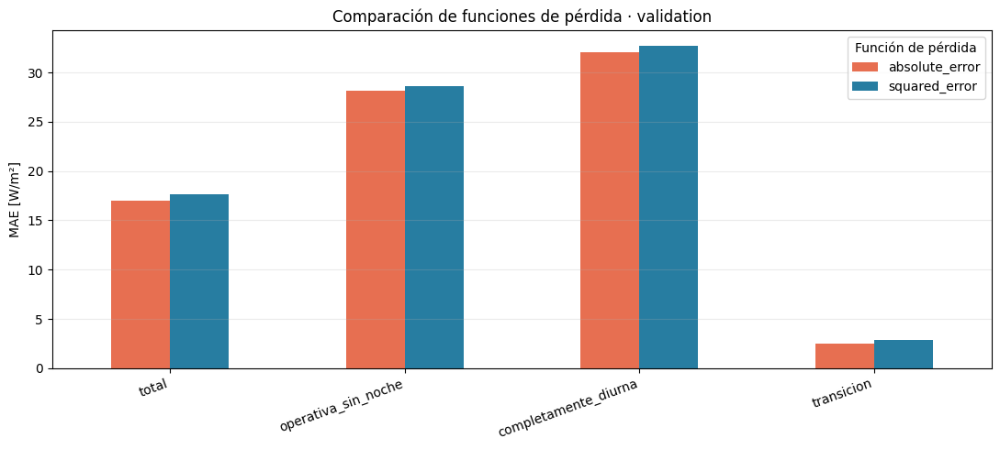

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Nombres de los modelos
NOMBRE_SQUARED = "M3-HGB-8V-DIF-Elevacion-Global"
NOMBRE_ABSOLUTE = "M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global"


# 2. Constructor común
def crear_HGB(loss):
    return HistGradientBoostingRegressor(
        loss=loss,
        learning_rate=0.03,
        max_iter=300,
        max_leaf_nodes=7,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    )


# 3. Matrices de modelado
X_train = train_modelado[VARIABLES_HGB8].copy()
y_train = train_modelado[OBJETIVO].copy()
X_validation = validation_modelado[VARIABLES_HGB8].copy()
y_validation = validation_modelado[OBJETIVO].copy()
assert not X_train.isna().any().any()
assert not y_train.isna().any()
assert not X_validation.isna().any().any()
assert not y_validation.isna().any()


# 4. Validación temporal interna de train
tscv = TimeSeriesSplit(n_splits=5)
resultados_CV_loss = []
for fold, (indices_ajuste, indices_validacion) in enumerate(tscv.split(X_train), start=1):
    X_ajuste = X_train.iloc[indices_ajuste]
    y_ajuste = y_train.iloc[indices_ajuste]
    X_val_interna = X_train.iloc[indices_validacion]
    y_val_interna = y_train.iloc[indices_validacion]
    configuraciones_loss = {NOMBRE_SQUARED: "squared_error", NOMBRE_ABSOLUTE: "absolute_error"}
    for nombre_modelo, loss in configuraciones_loss.items():
        modelo_fold = crear_HGB(loss)
        modelo_fold.fit(X_ajuste, y_ajuste)
        pred_fold = modelo_fold.predict(X_val_interna)
        error_fold = pred_fold - y_val_interna.to_numpy()
        resultados_CV_loss.append(
            {
                "fold": fold,
                "modelo": nombre_modelo,
                "loss": loss,
                "n_train_fold": len(indices_ajuste),
                "n_validation_fold": len(indices_validacion),
                "MAE": np.mean(np.abs(error_fold)),
                "RMSE": np.sqrt(np.mean(error_fold**2)),
                "sesgo": np.mean(error_fold),
            }
        )

tabla_CV_loss = pd.DataFrame(resultados_CV_loss)
resumen_CV_loss = (
    tabla_CV_loss.groupby(["modelo", "loss"], as_index=False)
    .agg(
        MAE_CV_medio=("MAE", "mean"),
        MAE_CV_std=("MAE", "std"),
        RMSE_CV_medio=("RMSE", "mean"),
        sesgo_CV_medio=("sesgo", "mean"),
    )
    .sort_values("MAE_CV_medio")
    .reset_index(drop=True)
)
print("VALIDACIÓN TEMPORAL INTERNA DE TRAIN")
display(tabla_CV_loss.round(4))
print("\nRESUMEN DE VALIDACIÓN TEMPORAL")
display(resumen_CV_loss.round(4))


# 5. Ajustar ambos modelos con todo train
modelo_HGB8_squared = crear_HGB("squared_error")
modelo_HGB8_absolute = crear_HGB("absolute_error")
modelo_HGB8_squared.fit(X_train, y_train)
modelo_HGB8_absolute.fit(X_train, y_train)


# 6. Predicciones de train y validation
predicciones = {
    "train": {
        NOMBRE_SQUARED: modelo_HGB8_squared.predict(X_train),
        NOMBRE_ABSOLUTE: modelo_HGB8_absolute.predict(X_train),
    },
    "validation": {
        NOMBRE_SQUARED: modelo_HGB8_squared.predict(X_validation),
        NOMBRE_ABSOLUTE: modelo_HGB8_absolute.predict(X_validation),
    },
}
train_comparacion_loss = train_modelado.copy()
validation_comparacion_loss = validation_modelado.copy()
for nombre_modelo in [NOMBRE_SQUARED, NOMBRE_ABSOLUTE]:
    train_comparacion_loss[nombre_modelo] = predicciones["train"][nombre_modelo]
    validation_comparacion_loss[nombre_modelo] = predicciones["validation"][nombre_modelo]


# 7. Comparar el squared recalculado con la predicción anterior
if "df_validation" in globals() and NOMBRE_SQUARED in df_validation.columns:
    anterior = (
        df_validation[["instante_objetivo", NOMBRE_SQUARED]]
        .sort_values("instante_objetivo")
        .reset_index(drop=True)
    )
    nueva = (
        validation_comparacion_loss[["instante_objetivo", NOMBRE_SQUARED]]
        .sort_values("instante_objetivo")
        .reset_index(drop=True)
    )
    diferencia_prediccion_squared = np.max(
        np.abs(anterior[NOMBRE_SQUARED].to_numpy() - nueva[NOMBRE_SQUARED].to_numpy())
    )
    print(
        "\nDiferencia máxima entre el squared original y el reentrenado:",
        diferencia_prediccion_squared,
    )


# 8. Función de métricas
def calcular_metricas_loss(tabla, columna_prediccion, mascara):
    datos = tabla.loc[mascara].copy()
    y_real = datos[OBJETIVO].to_numpy(dtype=float)
    y_pred = datos[columna_prediccion].to_numpy(dtype=float)
    error = y_pred - y_real
    error_absoluto = np.abs(error)
    mae = error_absoluto.mean()
    media_real = y_real.mean()
    nmae = 100 * mae / media_real if not np.isclose(media_real, 0) else np.nan
    r2 = r2_score(y_real, y_pred) if len(y_real) >= 2 and np.var(y_real) > 0 else np.nan
    return {
        "n": len(datos),
        "DIF_media_real": media_real,
        "DIF_mediana_real": np.median(y_real),
        "MAE": mae,
        "nMAE_pct": nmae,
        "RMSE": np.sqrt(mean_squared_error(y_real, y_pred)),
        "sesgo": error.mean(),
        "mediana_error": np.median(error),
        "mediana_error_absoluto": np.median(error_absoluto),
        "p90_error_absoluto": np.quantile(error_absoluto, 0.90),
        "p95_error_absoluto": np.quantile(error_absoluto, 0.95),
        "p99_error_absoluto": np.quantile(error_absoluto, 0.99),
        "R2": r2,
    }


# 9. Poblaciones de evaluación
def obtener_mascaras(tabla):
    return {
        "total": pd.Series(True, index=tabla.index),
        "operativa_sin_noche": tabla[REGIMEN].isin(["completamente_diurna", "transicion"]),
        "completamente_diurna": tabla[REGIMEN].eq("completamente_diurna"),
        "transicion": tabla[REGIMEN].eq("transicion"),
        "noche": tabla[REGIMEN].eq("noche"),
    }


# 10. Tabla conjunta train-validation
resultados_metricas_loss = []
for particion, tabla in {
    "train": train_comparacion_loss,
    "validation": validation_comparacion_loss,
}.items():
    mascaras = obtener_mascaras(tabla)
    for poblacion, mascara in mascaras.items():
        for nombre_modelo in [NOMBRE_SQUARED, NOMBRE_ABSOLUTE]:
            resultados_metricas_loss.append(
                {
                    "particion": particion,
                    "poblacion": poblacion,
                    "modelo": nombre_modelo,
                    "loss": (
                        "squared_error" if nombre_modelo == NOMBRE_SQUARED else "absolute_error"
                    ),
                    **calcular_metricas_loss(tabla, nombre_modelo, mascara),
                }
            )

tabla_metricas_loss = pd.DataFrame(resultados_metricas_loss)
display(
    tabla_metricas_loss.round(
        {
            "DIF_media_real": 3,
            "DIF_mediana_real": 3,
            "MAE": 3,
            "nMAE_pct": 3,
            "RMSE": 3,
            "sesgo": 3,
            "mediana_error": 3,
            "mediana_error_absoluto": 3,
            "p90_error_absoluto": 3,
            "p95_error_absoluto": 3,
            "p99_error_absoluto": 3,
            "R2": 4,
        }
    )
)


# 11. Comparación directa sobre validation
comparacion_horas_loss = []
for poblacion, mascara in obtener_mascaras(validation_comparacion_loss).items():
    datos = validation_comparacion_loss.loc[mascara]
    error_squared = np.abs(datos[NOMBRE_SQUARED] - datos[OBJETIVO])
    error_absolute = np.abs(datos[NOMBRE_ABSOLUTE] - datos[OBJETIVO])
    comparacion_horas_loss.append(
        {
            "poblacion": poblacion,
            "n": len(datos),
            "porcentaje_horas_gana_absolute": (100 * np.mean(error_absolute < error_squared)),
            "porcentaje_empates": (100 * np.mean(np.isclose(error_absolute, error_squared))),
            "mejora_MAE_absolute_frente_squared": (error_squared.mean() - error_absolute.mean()),
        }
    )

tabla_comparacion_horas_loss = pd.DataFrame(comparacion_horas_loss)
print("\nCOMPARACIÓN DIRECTA SOBRE VALIDATION")
display(tabla_comparacion_horas_loss.round(3))


# 12. Figura de validation
poblaciones_figura = ["total", "operativa_sin_noche", "completamente_diurna", "transicion"]
datos_figura = (
    tabla_metricas_loss[
        (tabla_metricas_loss["particion"] == "validation")
        & (tabla_metricas_loss["poblacion"].isin(poblaciones_figura))
    ]
    .pivot(index="poblacion", columns="loss", values="MAE")
    .reindex(poblaciones_figura)
)
ax = datos_figura.plot(kind="bar", figsize=(11, 5), color=["#e76f51", "#277da1"])
ax.set_title("Comparación de funciones de pérdida · validation")
ax.set_xlabel("")
ax.set_ylabel("MAE [W/m²]")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Función de pérdida")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Resultados.** Las dos pérdidas ofrecen resultados opuestos según el periodo evaluado.
- Validación temporal interna: la pérdida cuadrática obtiene un MAE medio menor (21,88 frente a 22,84 W/m²), y la absoluta solo la mejora en la quinta división.
- Validación: la pérdida absoluta reduce el MAE en 0,54 W/m² en las horas de operación, 0,58 W/m² en las completamente diurnas y 0,29 W/m² en transición, y lleva el sesgo de operación de 3,76 W/m² a prácticamente cero.
- El percentil 95 del error absoluto en operación aumenta, en cambio, de 85,07 a 90,91 W/m².

### 3.25 Diferencias recientes de la DIF

Para representar de forma explícita la dinámica reciente, se evalúan el último cambio horario (`delta_DIF_t` = `DIF_lag_1` − `DIF_lag_2`) y el anterior (`delta_DIF_t_menos_1` = `DIF_lag_2` − `DIF_lag_3`), que el HGB solo podría aproximar mediante varias divisiones. Se comparan seis configuraciones (sin diferencias, con la última y con ambas, cada una con pérdida cuadrática y absoluta) mediante validación temporal interna y validación. Por último, se construyen medidas de la dispersión de la DIF dentro de la última hora para el experimento siguiente.

RESUMEN DE VALIDACIÓN TEMPORAL


,modelo,loss,familia,n_variables,MAE_CV_medio,MAE_CV_std,RMSE_CV_medio,sesgo_CV_medio
0,M3-HGB-10V-DIF-Elevacion-Deltas-SquaredError-G...,squared_error,Dos deltas,10,21.7616,5.8268,40.0012,-3.5265
1,M3-HGB-9V-DIF-Elevacion-Delta1-SquaredError-Gl...,squared_error,Delta1,9,21.8389,5.7821,40.2639,-3.6978
2,M3-HGB-8V-DIF-Elevacion-Global,squared_error,Sin deltas,8,21.8751,5.7353,40.3444,-3.6399
3,M3-HGB-10V-DIF-Elevacion-Deltas-AbsoluteError-...,absolute_error,Dos deltas,10,22.3309,5.3924,41.9075,-7.0642
4,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,absolute_error,Delta1,9,22.4527,5.5020,41.9399,-7.1325
5,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,Sin deltas,8,22.8382,5.5163,42.1320,-6.9471


MÉTRICAS COMPLETAS


,particion,poblacion,modelo,loss,familia,n_variables,n,DIF_media_real,DIF_mediana_real,MAE,nMAE_pct,RMSE,sesgo,mediana_error_abs,p90_error_abs,p95_error_abs,p99_error_abs,R2
0,train,total,M3-HGB-8V-DIF-Elevacion-Global,squared_error,Sin deltas,8,5149,80.2951,15.8500,15.8568,19.7482,30.3336,0.0001,2.3840,50.2121,71.0373,114.8946,0.9269
1,train,total,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,Sin deltas,8,5149,80.2951,15.8500,16.2925,20.2908,33.1007,-2.0199,1.8096,51.3955,76.9337,133.1770,0.9129
2,train,total,M3-HGB-9V-DIF-Elevacion-Delta1-SquaredError-Gl...,squared_error,Delta1,9,5149,80.2951,15.8500,15.7329,19.5939,29.8693,-0.0012,2.4665,49.3640,70.6256,111.5632,0.9291
3,train,total,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,absolute_error,Delta1,9,5149,80.2951,15.8500,16.1622,20.1285,33.0831,-1.8896,2.1467,51.9158,77.5059,133.8531,0.9130
4,train,total,M3-HGB-10V-DIF-Elevacion-Deltas-SquaredError-G...,squared_error,Dos deltas,10,5149,80.2951,15.8500,15.6408,19.4791,29.6878,-0.0008,2.3683,49.5898,70.1043,112.1846,0.9300
5,train,total,M3-HGB-10V-DIF-Elevacion-Deltas-AbsoluteError-...,absolute_error,Dos deltas,10,5149,80.2951,15.8500,16.1988,20.1740,33.0949,-2.1220,2.2520,51.3253,77.7240,135.6670,0.9130
6,train,operativa_sin_noche,M3-HGB-8V-DIF-Elevacion-Global,squared_error,Sin deltas,8,3027,137.1747,106.3500,26.5076,19.3239,39.5576,-0.4418,16.5508,66.8607,86.0954,128.5700,0.8845
7,train,operativa_sin_noche,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,Sin deltas,8,3027,137.1747,106.3500,27.6296,20.1419,43.1705,-3.4136,16.2871,71.7091,95.2228,151.8766,0.8625
8,train,operativa_sin_noche,M3-HGB-9V-DIF-Elevacion-Delta1-SquaredError-Gl...,squared_error,Delta1,9,3027,137.1747,106.3500,26.2844,19.1613,38.9518,-0.4593,16.7954,64.8025,84.4723,124.1783,0.8880
9,train,operativa_sin_noche,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,absolute_error,Delta1,9,3027,137.1747,106.3500,27.4074,19.9799,43.1476,-3.1942,15.3721,71.2558,95.3018,150.6657,0.8626



TABLA PRINCIPAL DE SELECCIÓN


,modelo,loss,familia,n_variables,MAE_CV_temporal,std_CV_temporal,MAE_val_total,MAE_val_operativa,MAE_val_diurna,MAE_val_transicion,sesgo_val_operativa,RMSE_val_operativa,p95_val_operativa,R2_val_operativa
0,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,absolute_error,Delta1,9,22.4527,5.5020,16.5624,27.3534,31.2125,2.5450,0.0465,42.5220,90.2509,0.8397
1,M3-HGB-10V-DIF-Elevacion-Deltas-AbsoluteError-...,absolute_error,Dos deltas,10,22.3309,5.3924,16.6634,27.5196,31.3922,2.6241,-0.9856,42.6472,90.8473,0.8388
2,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,Sin deltas,8,22.8382,5.5163,17.0135,28.1015,32.0780,2.5382,-0.0449,43.2839,90.9100,0.8340
3,M3-HGB-10V-DIF-Elevacion-Deltas-SquaredError-G...,squared_error,Dos deltas,10,21.7616,5.8268,17.5577,28.5497,32.5008,3.1494,3.0289,43.0165,86.4715,0.8360
4,M3-HGB-9V-DIF-Elevacion-Delta1-SquaredError-Gl...,squared_error,Delta1,9,21.8389,5.7821,17.5918,28.6131,32.5676,3.1909,3.2811,42.9724,85.0699,0.8363
5,M3-HGB-8V-DIF-Elevacion-Global,squared_error,Sin deltas,8,21.8751,5.7353,17.6016,28.6418,32.6575,2.8267,3.7602,43.0460,85.0657,0.8358



MEJORAS FRENTE A LA REFERENCIA DEL MISMO LOSS


,modelo,referencia,loss,familia,poblacion,mejora_MAE,mejora_RMSE,cambio_R2,porcentaje_horas_ganadas
0,M3-HGB-9V-DIF-Elevacion-Delta1-SquaredError-Gl...,M3-HGB-8V-DIF-Elevacion-Global,squared_error,Delta1,total,0.0099,0.0570,0.0003,31.9672
1,M3-HGB-9V-DIF-Elevacion-Delta1-SquaredError-Gl...,M3-HGB-8V-DIF-Elevacion-Global,squared_error,Delta1,operativa_sin_noche,0.0288,0.0736,0.0006,51.1312
2,M3-HGB-9V-DIF-Elevacion-Delta1-SquaredError-Gl...,M3-HGB-8V-DIF-Elevacion-Global,squared_error,Delta1,completamente_diurna,0.0899,0.0866,0.0008,52.2876
3,M3-HGB-9V-DIF-Elevacion-Delta1-SquaredError-Gl...,M3-HGB-8V-DIF-Elevacion-Global,squared_error,Delta1,transicion,-0.3643,-0.5217,-0.0886,43.6975
4,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,Delta1,total,0.4511,0.5921,0.0034,39.9590
5,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,Delta1,operativa_sin_noche,0.7481,0.7619,0.0058,55.9955
6,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,Delta1,completamente_diurna,0.8655,0.8208,0.0077,56.6013
7,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global,absolute_error,Delta1,transicion,-0.0068,-0.0976,-0.0150,52.1008
8,M3-HGB-10V-DIF-Elevacion-Deltas-SquaredError-G...,M3-HGB-8V-DIF-Elevacion-Global,squared_error,Dos deltas,total,0.0439,0.0226,0.0001,31.3525
9,M3-HGB-10V-DIF-Elevacion-Deltas-SquaredError-G...,M3-HGB-8V-DIF-Elevacion-Global,squared_error,Dos deltas,operativa_sin_noche,0.0922,0.0294,0.0002,50.4525


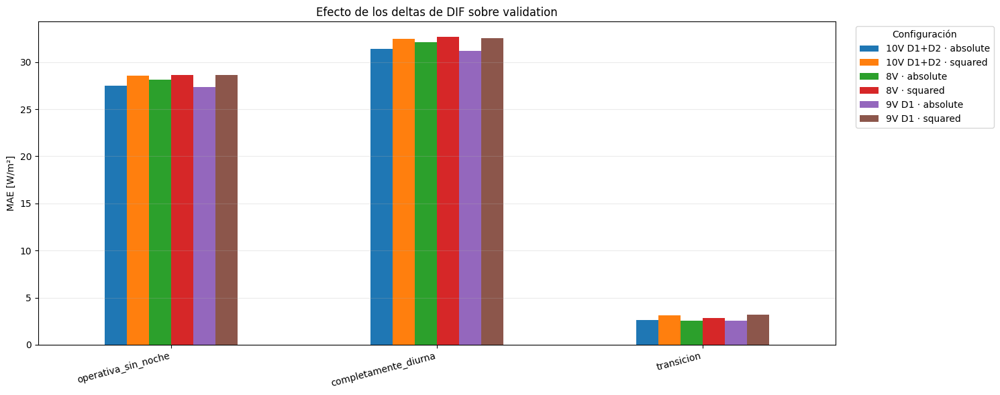

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score

# 1. Orden cronológico y comprobaciones
train_deltas = train_modelado.sort_values("instante_objetivo").reset_index(drop=True).copy()
validation_deltas = (
    validation_modelado.sort_values("instante_objetivo").reset_index(drop=True).copy()
)
assert train_deltas["instante_objetivo"].is_monotonic_increasing
assert validation_deltas["instante_objetivo"].is_monotonic_increasing
train_deltas["delta_DIF_t"] = train_deltas["DIF_lag_1"] - train_deltas["DIF_lag_2"]
train_deltas["delta_DIF_t_menos_1"] = train_deltas["DIF_lag_2"] - train_deltas["DIF_lag_3"]
validation_deltas["delta_DIF_t"] = validation_deltas["DIF_lag_1"] - validation_deltas["DIF_lag_2"]
validation_deltas["delta_DIF_t_menos_1"] = (
    validation_deltas["DIF_lag_2"] - validation_deltas["DIF_lag_3"]
)


# 2. Variables de las tres familias
VARIABLES_8V = VARIABLES_HGB8.copy()
VARIABLES_9V_DELTA1 = VARIABLES_HGB8 + ["delta_DIF_t"]
VARIABLES_10V_DELTAS = VARIABLES_HGB8 + ["delta_DIF_t", "delta_DIF_t_menos_1"]


# 3. Nombres trazables
NOMBRE_BASE_SQUARED = "M3-HGB-8V-DIF-Elevacion-Global"
NOMBRE_BASE_ABSOLUTE = "M3-HGB-8V-DIF-Elevacion-AbsoluteError-Global"
NOMBRE_DELTA1_SQUARED = "M3-HGB-9V-DIF-Elevacion-Delta1-SquaredError-Global"
NOMBRE_DELTA1_ABSOLUTE = "M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global"
NOMBRE_DELTAS_SQUARED = "M3-HGB-10V-DIF-Elevacion-Deltas-SquaredError-Global"
NOMBRE_DELTAS_ABSOLUTE = "M3-HGB-10V-DIF-Elevacion-Deltas-AbsoluteError-Global"
CONFIGURACIONES_DELTAS = {
    NOMBRE_BASE_SQUARED: {
        "loss": "squared_error",
        "variables": VARIABLES_8V,
        "n_variables": 8,
        "familia": "Sin deltas",
    },
    NOMBRE_BASE_ABSOLUTE: {
        "loss": "absolute_error",
        "variables": VARIABLES_8V,
        "n_variables": 8,
        "familia": "Sin deltas",
    },
    NOMBRE_DELTA1_SQUARED: {
        "loss": "squared_error",
        "variables": VARIABLES_9V_DELTA1,
        "n_variables": 9,
        "familia": "Delta1",
    },
    NOMBRE_DELTA1_ABSOLUTE: {
        "loss": "absolute_error",
        "variables": VARIABLES_9V_DELTA1,
        "n_variables": 9,
        "familia": "Delta1",
    },
    NOMBRE_DELTAS_SQUARED: {
        "loss": "squared_error",
        "variables": VARIABLES_10V_DELTAS,
        "n_variables": 10,
        "familia": "Dos deltas",
    },
    NOMBRE_DELTAS_ABSOLUTE: {
        "loss": "absolute_error",
        "variables": VARIABLES_10V_DELTAS,
        "n_variables": 10,
        "familia": "Dos deltas",
    },
}


# 4. Constructor idéntico para todos los modelos
def crear_modelo_deltas(loss):
    return HistGradientBoostingRegressor(
        loss=loss,
        learning_rate=0.03,
        max_iter=300,
        max_leaf_nodes=7,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    )


# 5. Validación temporal: solo cuatro modelos nuevos
NOMBRES_NUEVOS = [
    NOMBRE_DELTA1_SQUARED,
    NOMBRE_DELTA1_ABSOLUTE,
    NOMBRE_DELTAS_SQUARED,
    NOMBRE_DELTAS_ABSOLUTE,
]
tscv = TimeSeriesSplit(n_splits=5)
resultados_CV_nuevos = []
for fold, (indices_train, indices_val) in enumerate(tscv.split(train_deltas), start=1):
    for nombre_modelo in NOMBRES_NUEVOS:
        configuracion = CONFIGURACIONES_DELTAS[nombre_modelo]
        variables = configuracion["variables"]
        X_ajuste = train_deltas.loc[indices_train, variables]
        y_ajuste = train_deltas.loc[indices_train, OBJETIVO]
        X_val_fold = train_deltas.loc[indices_val, variables]
        y_val_fold = train_deltas.loc[indices_val, OBJETIVO].to_numpy()
        modelo_fold = crear_modelo_deltas(configuracion["loss"])
        modelo_fold.fit(X_ajuste, y_ajuste)
        pred_fold = modelo_fold.predict(X_val_fold)
        error_fold = pred_fold - y_val_fold
        resultados_CV_nuevos.append(
            {
                "fold": fold,
                "modelo": nombre_modelo,
                "loss": configuracion["loss"],
                "familia": configuracion["familia"],
                "n_variables": configuracion["n_variables"],
                "n_train_fold": len(indices_train),
                "n_validation_fold": len(indices_val),
                "MAE": np.mean(np.abs(error_fold)),
                "RMSE": np.sqrt(np.mean(error_fold**2)),
                "sesgo": np.mean(error_fold),
            }
        )

tabla_CV_deltas_nuevos = pd.DataFrame(resultados_CV_nuevos)


# 6. Incorporar el CV ya calculado de las referencias
if "tabla_CV_loss" not in globals():
    raise ValueError(
        "No existe 'tabla_CV_loss'. Ejecuta primero la comparación "
        "entre squared_error y absolute_error."
    )

tabla_CV_referencias = tabla_CV_loss.copy()
tabla_CV_referencias["n_variables"] = 8
tabla_CV_referencias["familia"] = "Sin deltas"
columnas_CV = [
    "fold",
    "modelo",
    "loss",
    "familia",
    "n_variables",
    "n_train_fold",
    "n_validation_fold",
    "MAE",
    "RMSE",
    "sesgo",
]
tabla_CV_deltas = pd.concat(
    [tabla_CV_referencias[columnas_CV], tabla_CV_deltas_nuevos[columnas_CV]], ignore_index=True
)
resumen_CV_deltas = (
    tabla_CV_deltas.groupby(["modelo", "loss", "familia", "n_variables"], as_index=False)
    .agg(
        MAE_CV_medio=("MAE", "mean"),
        MAE_CV_std=("MAE", "std"),
        RMSE_CV_medio=("RMSE", "mean"),
        sesgo_CV_medio=("sesgo", "mean"),
    )
    .sort_values("MAE_CV_medio")
    .reset_index(drop=True)
)
print("RESUMEN DE VALIDACIÓN TEMPORAL")
display(resumen_CV_deltas.round(4))


# 7. Entrenar los seis modelos con todo train
modelos_experimento_deltas = {}
for nombre_modelo, configuracion in CONFIGURACIONES_DELTAS.items():
    if nombre_modelo == NOMBRE_BASE_SQUARED:
        modelo = modelo_HGB8_squared

    elif nombre_modelo == NOMBRE_BASE_ABSOLUTE:
        modelo = modelo_HGB8_absolute

    else:
        modelo = crear_modelo_deltas(configuracion["loss"])
        modelo.fit(train_deltas[configuracion["variables"]], train_deltas[OBJETIVO])

    modelos_experimento_deltas[nombre_modelo] = modelo


# 8. Predicciones sobre train y validation
train_resultados_deltas = train_deltas.copy()
validation_resultados_deltas = validation_deltas.copy()
for nombre_modelo, configuracion in CONFIGURACIONES_DELTAS.items():
    modelo = modelos_experimento_deltas[nombre_modelo]
    variables = configuracion["variables"]
    train_resultados_deltas[nombre_modelo] = modelo.predict(train_deltas[variables])
    validation_resultados_deltas[nombre_modelo] = modelo.predict(validation_deltas[variables])


# 9. Métricas
def metricas_modelo_deltas(tabla, columna_prediccion, mascara):
    datos = tabla.loc[mascara]
    y_real = datos[OBJETIVO].to_numpy(dtype=float)
    y_pred = datos[columna_prediccion].to_numpy(dtype=float)
    error = y_pred - y_real
    error_abs = np.abs(error)
    mae = error_abs.mean()
    media_real = y_real.mean()
    return {
        "n": len(datos),
        "DIF_media_real": media_real,
        "DIF_mediana_real": np.median(y_real),
        "MAE": mae,
        "nMAE_pct": (100 * mae / media_real if not np.isclose(media_real, 0) else np.nan),
        "RMSE": np.sqrt(np.mean(error**2)),
        "sesgo": error.mean(),
        "mediana_error_abs": np.median(error_abs),
        "p90_error_abs": np.quantile(error_abs, 0.90),
        "p95_error_abs": np.quantile(error_abs, 0.95),
        "p99_error_abs": np.quantile(error_abs, 0.99),
        "R2": (r2_score(y_real, y_pred) if len(y_real) > 1 and np.var(y_real) > 0 else np.nan),
    }

def mascaras_evaluacion(tabla):
    return {
        "total": pd.Series(True, index=tabla.index),
        "operativa_sin_noche": tabla[REGIMEN].isin(["completamente_diurna", "transicion"]),
        "completamente_diurna": tabla[REGIMEN].eq("completamente_diurna"),
        "transicion": tabla[REGIMEN].eq("transicion"),
        "noche": tabla[REGIMEN].eq("noche"),
    }

resultados_deltas = []
for particion, tabla in {
    "train": train_resultados_deltas,
    "validation": validation_resultados_deltas,
}.items():
    for poblacion, mascara in mascaras_evaluacion(tabla).items():
        for nombre_modelo, configuracion in CONFIGURACIONES_DELTAS.items():
            resultados_deltas.append(
                {
                    "particion": particion,
                    "poblacion": poblacion,
                    "modelo": nombre_modelo,
                    "loss": configuracion["loss"],
                    "familia": configuracion["familia"],
                    "n_variables": configuracion["n_variables"],
                    **metricas_modelo_deltas(tabla, nombre_modelo, mascara),
                }
            )

tabla_metricas_deltas = pd.DataFrame(resultados_deltas)
print("MÉTRICAS COMPLETAS")
display(tabla_metricas_deltas.round(4))


# 10. Resumen de selección
filas_seleccion = []
for nombre_modelo, configuracion in CONFIGURACIONES_DELTAS.items():
    fila_CV = resumen_CV_deltas[resumen_CV_deltas["modelo"].eq(nombre_modelo)].iloc[0]
    metricas_modelo = tabla_metricas_deltas[
        (tabla_metricas_deltas["particion"] == "validation")
        & (tabla_metricas_deltas["modelo"] == nombre_modelo)
    ]

    def extraer(poblacion, metrica):
        return metricas_modelo.loc[metricas_modelo["poblacion"].eq(poblacion), metrica].iloc[0]

    filas_seleccion.append(
        {
            "modelo": nombre_modelo,
            "loss": configuracion["loss"],
            "familia": configuracion["familia"],
            "n_variables": configuracion["n_variables"],
            "MAE_CV_temporal": fila_CV["MAE_CV_medio"],
            "std_CV_temporal": fila_CV["MAE_CV_std"],
            "MAE_val_total": extraer("total", "MAE"),
            "MAE_val_operativa": extraer("operativa_sin_noche", "MAE"),
            "MAE_val_diurna": extraer("completamente_diurna", "MAE"),
            "MAE_val_transicion": extraer("transicion", "MAE"),
            "sesgo_val_operativa": extraer("operativa_sin_noche", "sesgo"),
            "RMSE_val_operativa": extraer("operativa_sin_noche", "RMSE"),
            "p95_val_operativa": extraer("operativa_sin_noche", "p95_error_abs"),
            "R2_val_operativa": extraer("operativa_sin_noche", "R2"),
        }
    )

tabla_seleccion_deltas = (
    pd.DataFrame(filas_seleccion)
    .sort_values(["MAE_val_operativa", "MAE_CV_temporal"])
    .reset_index(drop=True)
)
print("\nTABLA PRINCIPAL DE SELECCIÓN")
display(tabla_seleccion_deltas.round(4))


# 11. Mejora incremental frente a la referencia de cada loss
referencia_por_loss = {"squared_error": NOMBRE_BASE_SQUARED, "absolute_error": NOMBRE_BASE_ABSOLUTE}
comparaciones_incrementales = []
for nombre_modelo, configuracion in CONFIGURACIONES_DELTAS.items():
    referencia = referencia_por_loss[configuracion["loss"]]
    if nombre_modelo == referencia:
        continue

    for poblacion in ["total", "operativa_sin_noche", "completamente_diurna", "transicion"]:
        fila_modelo = tabla_metricas_deltas[
            (tabla_metricas_deltas["particion"] == "validation")
            & (tabla_metricas_deltas["poblacion"] == poblacion)
            & (tabla_metricas_deltas["modelo"] == nombre_modelo)
        ].iloc[0]
        fila_referencia = tabla_metricas_deltas[
            (tabla_metricas_deltas["particion"] == "validation")
            & (tabla_metricas_deltas["poblacion"] == poblacion)
            & (tabla_metricas_deltas["modelo"] == referencia)
        ].iloc[0]
        datos = validation_resultados_deltas.loc[
            mascaras_evaluacion(validation_resultados_deltas)[poblacion]
        ]
        error_modelo = np.abs(datos[nombre_modelo] - datos[OBJETIVO])
        error_referencia = np.abs(datos[referencia] - datos[OBJETIVO])
        comparaciones_incrementales.append(
            {
                "modelo": nombre_modelo,
                "referencia": referencia,
                "loss": configuracion["loss"],
                "familia": configuracion["familia"],
                "poblacion": poblacion,
                "mejora_MAE": (fila_referencia["MAE"] - fila_modelo["MAE"]),
                "mejora_RMSE": (fila_referencia["RMSE"] - fila_modelo["RMSE"]),
                "cambio_R2": (fila_modelo["R2"] - fila_referencia["R2"]),
                "porcentaje_horas_ganadas": (100 * np.mean(error_modelo < error_referencia)),
            }
        )

tabla_mejoras_deltas = pd.DataFrame(comparaciones_incrementales)
print("\nMEJORAS FRENTE A LA REFERENCIA DEL MISMO LOSS")
display(tabla_mejoras_deltas.round(4))


# 12. Figura de MAE en validation
datos_figura = tabla_metricas_deltas[
    (tabla_metricas_deltas["particion"] == "validation")
    & (
        tabla_metricas_deltas["poblacion"].isin(
            ["operativa_sin_noche", "completamente_diurna", "transicion"]
        )
    )
].copy()
etiquetas_cortas = {
    NOMBRE_BASE_SQUARED: "8V · squared",
    NOMBRE_BASE_ABSOLUTE: "8V · absolute",
    NOMBRE_DELTA1_SQUARED: "9V D1 · squared",
    NOMBRE_DELTA1_ABSOLUTE: "9V D1 · absolute",
    NOMBRE_DELTAS_SQUARED: "10V D1+D2 · squared",
    NOMBRE_DELTAS_ABSOLUTE: "10V D1+D2 · absolute",
}
datos_figura["modelo_corto"] = datos_figura["modelo"].map(etiquetas_cortas)
tabla_figura = datos_figura.pivot(index="poblacion", columns="modelo_corto", values="MAE").reindex(
    ["operativa_sin_noche", "completamente_diurna", "transicion"]
)
ax = tabla_figura.plot(kind="bar", figsize=(15, 6))
ax.set_title("Efecto de los deltas de DIF sobre validation")
ax.set_xlabel("")
ax.set_ylabel("MAE [W/m²]")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Configuración", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

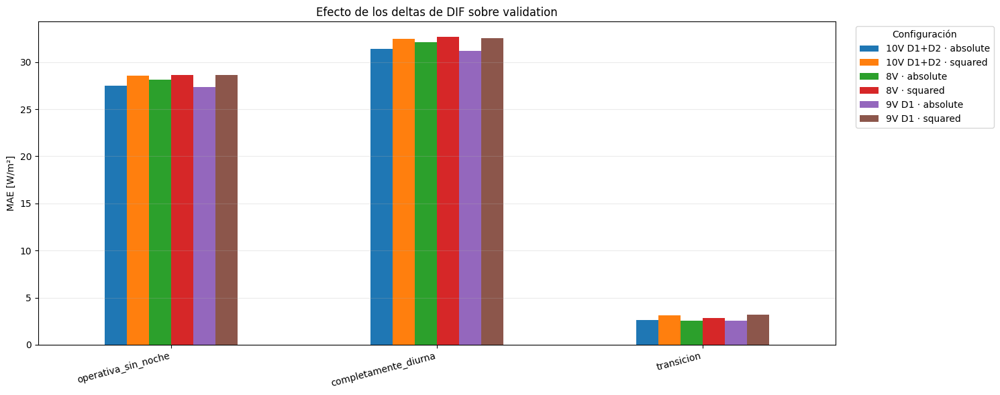


CHECKPOINT CREADO CORRECTAMENTE
Carpeta: experimento_HGB_loss_deltas_20261005T084418
ZIP: /content/experimento_HGB_loss_deltas_20261005T084418.zip
Número de archivos: 25


In [ ]:
from pathlib import Path
from datetime import datetime
from google.colab import files
import json
import joblib
import shutil
import pandas as pd
import matplotlib.pyplot as plt

# 1. Crear estructura de carpetas
marca_tiempo = datetime.now().strftime("%Y%m%dT%H%M%S")
nombre_checkpoint = f"experimento_HGB_loss_deltas_{marca_tiempo}"
carpeta_salida = Path(nombre_checkpoint)
if carpeta_salida.exists():
    shutil.rmtree(carpeta_salida)

carpetas = {
    "datos": carpeta_salida / "datos",
    "tablas": carpeta_salida / "tablas",
    "modelos": carpeta_salida / "modelos",
    "figuras": carpeta_salida / "figuras",
    "configuracion": carpeta_salida / "configuracion",
}
for carpeta in carpetas.values():
    carpeta.mkdir(parents=True, exist_ok=True)


# 2. Comprobar objetos fundamentales
objetos_obligatorios = [
    "tabla_CV_deltas",
    "resumen_CV_deltas",
    "tabla_metricas_deltas",
    "tabla_seleccion_deltas",
    "tabla_mejoras_deltas",
    "train_resultados_deltas",
    "validation_resultados_deltas",
    "modelos_experimento_deltas",
    "CONFIGURACIONES_DELTAS",
]
objetos_ausentes = [nombre for nombre in objetos_obligatorios if nombre not in globals()]
if objetos_ausentes:
    raise ValueError("Faltan objetos del experimento:\n" + "\n".join(objetos_ausentes))


# 3. Guardar tablas principales
tablas_exportar = {
    "01_CV_temporal_detallada.csv": tabla_CV_deltas,
    "02_resumen_CV_temporal.csv": resumen_CV_deltas,
    "03_metricas_train_validation.csv": tabla_metricas_deltas,
    "04_tabla_seleccion_modelos.csv": tabla_seleccion_deltas,
    "05_mejoras_incrementales_deltas.csv": tabla_mejoras_deltas,
}
tablas_opcionales = {
    "06_CV_comparacion_loss.csv": "tabla_CV_loss",
    "07_resumen_CV_comparacion_loss.csv": "resumen_CV_loss",
    "08_metricas_comparacion_loss.csv": "tabla_metricas_loss",
    "09_horas_ganadas_comparacion_loss.csv": "tabla_comparacion_horas_loss",
    "10_metricas_mensuales_corregidas.csv": "tabla_mensual_corregida",
}
for nombre_archivo, nombre_objeto in tablas_opcionales.items():
    if nombre_objeto in globals():
        objeto = globals()[nombre_objeto]
        if isinstance(objeto, pd.DataFrame):
            tablas_exportar[nombre_archivo] = objeto

for nombre_archivo, tabla in tablas_exportar.items():
    tabla.to_csv(carpetas["tablas"] / nombre_archivo, index=False, encoding="utf-8-sig")


# 4. Guardar predicciones
columnas_contexto = [
    "instante_emision",
    "instante_objetivo",
    OBJETIVO,
    REGIMEN,
    "particion",
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    "elevacion_media_lag1",
    "elevacion_media_lag2",
    "elevacion_media_lag3",
    "elevacion_media_lag24",
    "delta_DIF_t",
    "delta_DIF_t_menos_1",
]
columnas_modelos = list(CONFIGURACIONES_DELTAS.keys())
columnas_predicciones = columnas_contexto + columnas_modelos
columnas_predicciones = [
    columna for columna in columnas_predicciones if columna in train_resultados_deltas.columns
]
train_exportar = train_resultados_deltas[columnas_predicciones].copy()
validation_exportar = validation_resultados_deltas[columnas_predicciones].copy()


# Parquet: conserva tipos y precisión
train_exportar.to_parquet(carpetas["datos"] / "11_predicciones_train.parquet", index=False)
validation_exportar.to_parquet(
    carpetas["datos"] / "12_predicciones_validation.parquet", index=False
)

# CSV: lectura sencilla fuera de Python
train_exportar.to_csv(
    carpetas["datos"] / "11_predicciones_train.csv", index=False, encoding="utf-8-sig"
)
validation_exportar.to_csv(
    carpetas["datos"] / "12_predicciones_validation.csv", index=False, encoding="utf-8-sig"
)


# 5. Guardar los seis modelos
inventario_modelos = []
for numero, (nombre_modelo, modelo) in enumerate(modelos_experimento_deltas.items(), start=1):
    nombre_archivo_modelo = f"{numero:02d}_modelo.joblib"
    joblib.dump(modelo, carpetas["modelos"] / nombre_archivo_modelo)
    configuracion = CONFIGURACIONES_DELTAS[nombre_modelo]
    inventario_modelos.append(
        {
            "numero": numero,
            "archivo": nombre_archivo_modelo,
            "modelo": nombre_modelo,
            "loss": configuracion["loss"],
            "familia": configuracion["familia"],
            "n_variables": configuracion["n_variables"],
            "variables": " | ".join(configuracion["variables"]),
        }
    )

tabla_inventario_modelos = pd.DataFrame(inventario_modelos)
tabla_inventario_modelos.to_csv(
    carpetas["configuracion"] / "13_inventario_modelos.csv", index=False, encoding="utf-8-sig"
)


# 6. Guardar configuración del experimento
configuracion_json = {
    "fecha_exportacion": marca_tiempo,
    "objetivo": OBJETIVO,
    "regimen_solar": REGIMEN,
    "test_utilizado": False,
    "n_train": int(len(train_resultados_deltas)),
    "n_validation": int(len(validation_resultados_deltas)),
    "convencion_temporal": {
        "lag1": "t",
        "lag2": "t-1",
        "lag3": "t-2",
        "lag24": "t-23",
        "objetivo": "DIF(t+1)",
    },
    "definicion_deltas": {
        "delta_DIF_t": "DIF_lag_1 - DIF_lag_2",
        "delta_DIF_t_menos_1": "DIF_lag_2 - DIF_lag_3",
    },
    "hiperparametros_comunes": {
        "learning_rate": 0.03,
        "max_iter": 300,
        "max_leaf_nodes": 7,
        "min_samples_leaf": 20,
        "l2_regularization": 1.0,
        "early_stopping": False,
        "random_state": 42,
    },
    "validacion_temporal": {"metodo": "TimeSeriesSplit", "n_splits": 5, "metrica_principal": "MAE"},
    "definicion_nMAE": "100 * MAE / media(DIF real)",
    "configuraciones": {
        nombre: {
            "loss": configuracion["loss"],
            "familia": configuracion["familia"],
            "n_variables": configuracion["n_variables"],
            "variables": configuracion["variables"],
        }
        for nombre, configuracion in CONFIGURACIONES_DELTAS.items()
    },
}
with open(
    carpetas["configuracion"] / "14_configuracion_experimento.json", "w", encoding="utf-8"
) as archivo:
    json.dump(configuracion_json, archivo, ensure_ascii=False, indent=2)


# 7. Regenerar y guardar la figura principal
datos_figura_exportacion = tabla_metricas_deltas[
    (tabla_metricas_deltas["particion"] == "validation")
    & (
        tabla_metricas_deltas["poblacion"].isin(
            ["operativa_sin_noche", "completamente_diurna", "transicion"]
        )
    )
].copy()
etiquetas_exportacion = {
    NOMBRE_BASE_SQUARED: "8V · squared",
    NOMBRE_BASE_ABSOLUTE: "8V · absolute",
    NOMBRE_DELTA1_SQUARED: "9V D1 · squared",
    NOMBRE_DELTA1_ABSOLUTE: "9V D1 · absolute",
    NOMBRE_DELTAS_SQUARED: "10V D1+D2 · squared",
    NOMBRE_DELTAS_ABSOLUTE: "10V D1+D2 · absolute",
}
datos_figura_exportacion["modelo_corto"] = datos_figura_exportacion["modelo"].map(
    etiquetas_exportacion
)
tabla_figura_exportacion = datos_figura_exportacion.pivot(
    index="poblacion", columns="modelo_corto", values="MAE"
).reindex(["operativa_sin_noche", "completamente_diurna", "transicion"])
fig, ax = plt.subplots(figsize=(15, 6))
tabla_figura_exportacion.plot(kind="bar", ax=ax)
ax.set_title("Efecto de los deltas de DIF sobre validation")
ax.set_xlabel("")
ax.set_ylabel("MAE [W/m²]")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Configuración", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
fig.savefig(carpetas["figuras"] / "15_comparacion_MAE_validation.png", dpi=200, bbox_inches="tight")
plt.show()


# 8. Crear README
texto_readme = """
CHECKPOINT: EXPERIMENTO HGB LOSS × DELTAS
=========================================

Objetivo
--------
Comparar squared_error y absolute_error con:

1. las ocho variables de referencia;
2. la incorporación de delta_DIF_t;
3. la incorporación de los dos deltas recientes de DIF.

Definiciones
------------
delta_DIF_t =
    DIF_lag_1 - DIF_lag_2

delta_DIF_t_menos_1 =
    DIF_lag_2 - DIF_lag_3

Metodología
-----------
- Entrenamiento global.
- Cinco divisiones temporales dentro de train.
- Evaluación final sobre validation.
- Test completamente cerrado.
- MAE como métrica principal.
- Mismo soporte e hiperparámetros para todos los modelos.

Contenido
---------
datos/:
    predicciones de train y validation.

tablas/:
    CV, métricas, selección y mejoras incrementales.

modelos/:
    seis modelos HGB entrenados.

configuracion/:
    inventario y definición del experimento.

figuras/:
    comparación de MAE en validation.
""".strip()
with open(carpeta_salida / "README.txt", "w", encoding="utf-8") as archivo:
    archivo.write(texto_readme)


# 9. Inventario completo
inventario_archivos = []
for ruta in sorted(carpeta_salida.rglob("*")):
    if ruta.is_file():
        inventario_archivos.append(
            {"archivo": str(ruta.relative_to(carpeta_salida)), "bytes": ruta.stat().st_size}
        )

pd.DataFrame(inventario_archivos).to_csv(
    carpeta_salida / "16_inventario_archivos.csv", index=False, encoding="utf-8-sig"
)


# 10. Comprimir y descargar
ruta_zip_resultados = shutil.make_archive(
    base_name=nombre_checkpoint, format="zip", root_dir=carpeta_salida
)
print("\nCHECKPOINT CREADO CORRECTAMENTE")
print("Carpeta:", carpeta_salida)
print("ZIP:", ruta_zip_resultados)
print("Número de archivos:", len(inventario_archivos) + 1)
files.download(ruta_zip_resultados)

In [ ]:
from google.colab import files
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Subir el parquet original
archivos_subidos = files.upload()
if len(archivos_subidos) != 1:
    raise ValueError("Sube únicamente el parquet horario original.")

nombre_parquet_original = next(iter(archivos_subidos))
ruta_parquet_original = Path(nombre_parquet_original)
datos_originales = pd.read_parquet(ruta_parquet_original)
print("Dataset original:", datos_originales.shape)


# 2. Columnas exactas necesarias
COLUMNA_FECHA_ORIGINAL = "Date/Time"
COLUMNA_DIF_MEDIA = "DIF [W/m**2]"
COLUMNA_DIF_STD = "DIF std dev [W/m**2]"
columnas_requeridas = [COLUMNA_FECHA_ORIGINAL, COLUMNA_DIF_MEDIA, COLUMNA_DIF_STD]
columnas_ausentes = [
    columna for columna in columnas_requeridas if columna not in datos_originales.columns
]
if columnas_ausentes:
    raise ValueError("Faltan columnas en el parquet original:\n" + "\n".join(columnas_ausentes))


# 3. Preparar la tabla horaria de consulta
tabla_DIF_std = datos_originales[columnas_requeridas].copy()
tabla_DIF_std[COLUMNA_FECHA_ORIGINAL] = pd.to_datetime(
    tabla_DIF_std[COLUMNA_FECHA_ORIGINAL], utc=True, errors="raise"
)
if tabla_DIF_std[COLUMNA_FECHA_ORIGINAL].duplicated().any():
    duplicados = tabla_DIF_std.loc[tabla_DIF_std[COLUMNA_FECHA_ORIGINAL].duplicated(keep=False)]
    raise ValueError(
        "Existen timestamps horarios duplicados en el "
        "parquet original. No se realizará la unión."
    )

tabla_DIF_std = tabla_DIF_std.rename(
    columns={
        COLUMNA_FECHA_ORIGINAL: "instante_emision",
        COLUMNA_DIF_MEDIA: "DIF_media_original_emision",
        COLUMNA_DIF_STD: "DIF_std_lag1",
    }
)


# 4. Unión exacta con train y validation
n_train_antes = len(train_deltas)
n_validation_antes = len(validation_deltas)
train_std = train_deltas.merge(
    tabla_DIF_std, on="instante_emision", how="left", validate="many_to_one"
)
validation_std = validation_deltas.merge(
    tabla_DIF_std, on="instante_emision", how="left", validate="many_to_one"
)
assert len(train_std) == n_train_antes
assert len(validation_std) == n_validation_antes


# 5. Validar la alineación con DIF_lag_1
diferencia_train = train_std["DIF_lag_1"] - train_std["DIF_media_original_emision"]
diferencia_validation = validation_std["DIF_lag_1"] - validation_std["DIF_media_original_emision"]
max_diferencia_train = np.nanmax(np.abs(diferencia_train))
max_diferencia_validation = np.nanmax(np.abs(diferencia_validation))
print("Diferencia máxima DIF_lag_1 frente a DIF original de emisión:")
print("Train:     ", max_diferencia_train)
print("Validation:", max_diferencia_validation)


# 6. Disponibilidad de DIF_std_lag1
resumen_disponibilidad_std = pd.DataFrame(
    {
        "particion": ["train", "validation"],
        "n_total": [len(train_std), len(validation_std)],
        "n_disponible": [
            train_std["DIF_std_lag1"].notna().sum(),
            validation_std["DIF_std_lag1"].notna().sum(),
        ],
        "n_ausente": [
            train_std["DIF_std_lag1"].isna().sum(),
            validation_std["DIF_std_lag1"].isna().sum(),
        ],
    }
)
resumen_disponibilidad_std["porcentaje_disponible"] = (
    100 * resumen_disponibilidad_std["n_disponible"] / resumen_disponibilidad_std["n_total"]
)
display(resumen_disponibilidad_std)


# 7. Descriptivos básicos
display(
    pd.DataFrame(
        {
            "train": train_std["DIF_std_lag1"].describe(),
            "validation": validation_std["DIF_std_lag1"].describe(),
        }
    ).round(4)
)
print("\nVARIABLE CONSTRUIDA")
print("DIF_std_lag1 = desviación intrahoraria de DIF en la hora de emisión t.")
print("No se ha utilizado información de DIF(t+1).")

Dataset original: (570240, 31)
Diferencia máxima DIF_lag_1 frente a DIF original de emisión:
Train:      369.5333333333333
Validation: 204.56666666666666


,particion,n_total,n_disponible,n_ausente,porcentaje_disponible
0,train,5149,5143,6,99.883473
1,validation,1464,1463,1,99.931694


,train,validation
count,5143.0000,1463.0000
mean,1.1941,1.0579
std,2.8372,2.4516
min,0.0000,0.0000
25%,0.1000,0.1000
50%,0.1000,0.1000
75%,0.9000,0.7000
max,39.4000,24.8000



VARIABLE CONSTRUIDA
DIF_std_lag1 = desviación intrahoraria de DIF en la hora de emisión t.
No se ha utilizado información de DIF(t+1).


In [ ]:
import numpy as np
import pandas as pd

# 1. Columnas originales
COLUMNA_FECHA = "Date/Time"
COLUMNA_DIF = "DIF [W/m**2]"
COLUMNA_STD_ORIGINAL = "DIF std dev [W/m**2]"
columnas_necesarias = [COLUMNA_FECHA, COLUMNA_DIF, COLUMNA_STD_ORIGINAL]
ausentes = [columna for columna in columnas_necesarias if columna not in datos_originales.columns]
if ausentes:
    raise ValueError("Faltan columnas:\n" + "\n".join(ausentes))


# 2. Preparar observaciones minutales
minutales_DIF = datos_originales[columnas_necesarias].copy()
minutales_DIF[COLUMNA_FECHA] = pd.to_datetime(
    minutales_DIF[COLUMNA_FECHA], utc=True, errors="raise"
)
minutales_DIF = minutales_DIF.sort_values(COLUMNA_FECHA).reset_index(drop=True)

# Cada minuto se asigna a la hora iniciada en HH:00
minutales_DIF["instante_emision"] = minutales_DIF[COLUMNA_FECHA].dt.floor("h")


# 3. Agregación de los minutos de cada hora
def desviacion_intrahoraria(serie):
    valores = serie.dropna().to_numpy(dtype=float)
    if len(valores) < 2:
        return np.nan

    # Los minutos disponibles constituyen la población de la hora
    return np.std(valores, ddof=0)

DIF_horaria_reconstruida = minutales_DIF.groupby("instante_emision", as_index=False).agg(
    n_minutos_DIF=(COLUMNA_DIF, "count"),
    DIF_media_reconstruida=(COLUMNA_DIF, "mean"),
    # Variable original utilizada en el EDA
    DIF_std_media_lag1=(COLUMNA_STD_ORIGINAL, "mean"),
    # Alternativa robusta, solo diagnóstica
    DIF_std_mediana_lag1=(COLUMNA_STD_ORIGINAL, "median"),
    # Variabilidad real entre los minutos de la hora
    DIF_std_intrahoraria_lag1=(COLUMNA_DIF, desviacion_intrahoraria),
)


# 4. Unir con train y validation sin modificar el soporte
columnas_nuevas = [
    "instante_emision",
    "n_minutos_DIF",
    "DIF_media_reconstruida",
    "DIF_std_media_lag1",
    "DIF_std_mediana_lag1",
    "DIF_std_intrahoraria_lag1",
]
train_std = train_deltas.merge(
    DIF_horaria_reconstruida[columnas_nuevas],
    on="instante_emision",
    how="left",
    validate="many_to_one",
)
validation_std = validation_deltas.merge(
    DIF_horaria_reconstruida[columnas_nuevas],
    on="instante_emision",
    how="left",
    validate="many_to_one",
)
assert len(train_std) == len(train_deltas)
assert len(validation_std) == len(validation_deltas)


# 5. Validación temporal fundamental
diferencia_train = train_std["DIF_lag_1"] - train_std["DIF_media_reconstruida"]
diferencia_validation = validation_std["DIF_lag_1"] - validation_std["DIF_media_reconstruida"]
max_diferencia_train = np.nanmax(np.abs(diferencia_train))
max_diferencia_validation = np.nanmax(np.abs(diferencia_validation))
print("COMPROBACIÓN DE ALINEACIÓN HORARIA")
print("Diferencia máxima en train:", max_diferencia_train)
print("Diferencia máxima en validation:", max_diferencia_validation)
if max_diferencia_train > 1e-6 or max_diferencia_validation > 1e-6:
    raise ValueError(
        "La agregación horaria no coincide con DIF_lag_1. "
        "No se debe continuar con el entrenamiento."
    )


# 6. Disponibilidad y distribución
variables_dispersion = ["DIF_std_media_lag1", "DIF_std_mediana_lag1", "DIF_std_intrahoraria_lag1"]
resumen_disponibilidad = []
for particion, tabla in {"train": train_std, "validation": validation_std}.items():
    for variable in variables_dispersion:
        resumen_disponibilidad.append(
            {
                "particion": particion,
                "variable": variable,
                "n_total": len(tabla),
                "n_disponible": tabla[variable].notna().sum(),
                "n_ausente": tabla[variable].isna().sum(),
                "porcentaje_disponible": 100 * tabla[variable].notna().mean(),
                "n_valores_distintos": tabla[variable].nunique(dropna=True),
            }
        )

tabla_disponibilidad_dispersion = pd.DataFrame(resumen_disponibilidad)
display(tabla_disponibilidad_dispersion.round(3))
print("\nDESCRIPTIVOS DE TRAIN")
display(
    train_std[variables_dispersion]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T.round(4)
)


# 7. Redundancia entre las tres construcciones
print("\nCORRELACIÓN SPEARMAN ENTRE CONSTRUCCIONES")
display(train_std[variables_dispersion].corr(method="spearman").round(3))

COMPROBACIÓN DE ALINEACIÓN HORARIA
Diferencia máxima en train: 0.0
Diferencia máxima en validation: 0.0


,particion,variable,n_total,n_disponible,n_ausente,porcentaje_disponible,n_valores_distintos
0,train,DIF_std_media_lag1,5149,5149,0,100.0,1850
1,train,DIF_std_mediana_lag1,5149,5149,0,100.0,235
2,train,DIF_std_intrahoraria_lag1,5149,5149,0,100.0,3162
3,validation,DIF_std_media_lag1,1464,1464,0,100.0,662
4,validation,DIF_std_mediana_lag1,1464,1464,0,100.0,137
5,validation,DIF_std_intrahoraria_lag1,1464,1464,0,100.0,961



DESCRIPTIVOS DE TRAIN


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
DIF_std_media_lag1,5149.0,1.2603,2.2694,0.0117,0.03,0.0433,0.0783,0.165,1.395,6.2660,10.3731,25.0733
DIF_std_mediana_lag1,5149.0,0.9816,1.7739,0.0000,0.00,0.0000,0.1000,0.100,1.050,4.8000,8.4260,13.9500
DIF_std_intrahoraria_lag1,5149.0,18.5146,27.6756,0.0000,0.00,0.0000,0.0000,5.807,26.264,79.3741,122.5460,199.9156



CORRELACIÓN SPEARMAN ENTRE CONSTRUCCIONES


,DIF_std_media_lag1,DIF_std_mediana_lag1,DIF_std_intrahoraria_lag1
DIF_std_media_lag1,1.000,0.956,0.908
DIF_std_mediana_lag1,0.956,1.000,0.897
DIF_std_intrahoraria_lag1,0.908,0.897,1.000


**Resultados.** En la validación temporal interna, las tres variantes con pérdida cuadrática mantienen un MAE medio menor (entre 21,76 y 21,88 W/m²) que las de pérdida absoluta (entre 22,33 y 22,84 W/m²).
- En validación, el HGB de 9 variables con pérdida absoluta (`M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global`) obtiene el menor MAE en operación (27,35 W/m²) y en horas completamente diurnas (31,21 W/m²), frente a 28,64 y 32,66 W/m² del HGB de 8 variables.
- Con pérdida absoluta, añadir `delta_DIF_t` reduce el MAE de operación en 0,75 W/m²; incluir también la segunda diferencia no lo mejora (27,52 W/m²).
- La unión directa con el registro minutal no reproduce `DIF_lag_1`, mientras que la reconstrucción horaria coincide exactamente con él.

### 3.26 Dispersión reciente de la DIF

Se añaden por separado al HGB de 9 variables con pérdida absoluta dos medidas de la dispersión de la DIF en la última hora: la media horaria de la desviación estándar registrada en el conjunto de datos (`DIF_std_media_lag1`) y la desviación estándar de los valores minutales de la DIF dentro de la hora (`DIF_std_intrahoraria_lag1`). Se mantienen el soporte, los hiperparámetros y el procedimiento de validación.

> *Las subsecciones 3.26 y 3.27 son complementarias: no se utilizan en la memoria. Se conservan porque definen el núcleo HGB de las siguientes.*

VALIDACIÓN TEMPORAL INTERNA


,fold,modelo,familia,n_variables,n_train_fold,n_validation_fold,MAE,RMSE,sesgo
0,1,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,Referencia D1,9,859,858,13.0672,30.5744,-8.5540
1,1,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,DIF std original media,10,859,858,13.0569,30.6101,-8.6021
2,1,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,DIF std intrahoraria,10,859,858,13.2377,31.0234,-8.6891
3,2,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,Referencia D1,9,1717,858,23.4698,45.1064,-15.3231
4,2,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,DIF std original media,10,1717,858,22.9189,43.8199,-14.0375
5,2,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,DIF std intrahoraria,10,1717,858,22.9634,44.1312,-14.3013
6,3,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,Referencia D1,9,2575,858,23.8739,42.8842,-5.4425
7,3,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,DIF std original media,10,2575,858,23.9794,43.2138,-6.4994
8,3,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,DIF std intrahoraria,10,2575,858,24.0401,43.2722,-6.0705
9,4,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,Referencia D1,9,3433,858,27.6313,47.7409,-2.9768



RESUMEN CV


,modelo,familia,n_variables,MAE_CV_medio,MAE_CV_std,RMSE_CV_medio,sesgo_CV_medio
0,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,DIF std intrahoraria,10,22.4224,5.4608,41.9067,-6.9550
1,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,DIF std original media,10,22.4415,5.5867,41.9547,-7.0790
2,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,Referencia D1,9,22.4527,5.5020,41.9399,-7.1325


MÉTRICAS COMPLETAS


,particion,poblacion,modelo,familia,n_variables,n,DIF_media_real,DIF_mediana_real,MAE,nMAE_pct,RMSE,sesgo,mediana_error_abs,p90_error_abs,p95_error_abs,p99_error_abs,R2
0,train,total,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,Referencia D1,9,5149,80.2951,15.8500,16.1622,20.1285,33.0831,-1.8896,2.1467,51.9158,77.5059,133.8531,0.9130
1,train,total,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,DIF std original media,10,5149,80.2951,15.8500,16.2927,20.2910,33.2537,-2.3207,2.2106,52.1080,76.9527,135.3347,0.9121
2,train,total,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,DIF std intrahoraria,10,5149,80.2951,15.8500,16.1517,20.1154,33.1278,-2.0349,2.1057,52.1142,76.9710,132.3990,0.9128
3,train,operativa_sin_noche,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,Referencia D1,9,3027,137.1747,106.3500,27.4074,19.9799,43.1476,-3.1942,15.3721,71.2558,95.3018,150.6657,0.8626
4,train,operativa_sin_noche,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,DIF std original media,10,3027,137.1747,106.3500,27.6291,20.1416,43.3701,-3.9301,15.3611,71.3396,95.7688,154.1249,0.8612
5,train,operativa_sin_noche,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,DIF std intrahoraria,10,3027,137.1747,106.3500,27.3901,19.9673,43.2059,-3.4398,14.8828,71.1816,95.2528,150.7951,0.8623
6,train,completamente_diurna,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,Referencia D1,9,2603,158.5432,132.3000,31.5033,19.8705,46.5069,-3.7571,19.6457,77.2442,100.1574,154.3238,0.8269
7,train,completamente_diurna,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,DIF std original media,10,2603,158.5432,132.3000,31.7380,20.0185,46.7447,-4.6429,19.8099,76.7231,102.4136,159.1972,0.8251
8,train,completamente_diurna,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,DIF std intrahoraria,10,2603,158.5432,132.3000,31.4799,19.8557,46.5701,-4.0406,19.2138,76.8976,100.7985,157.2961,0.8264
9,train,transicion,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,Referencia D1,9,424,5.9906,3.6167,2.2622,37.7619,3.5720,0.2615,1.0505,6.3407,8.1191,12.1134,0.7038



TABLA PRINCIPAL DE SELECCIÓN


,modelo,familia,n_variables,MAE_CV_temporal,std_CV_temporal,MAE_val_total,MAE_val_operativa,MAE_val_diurna,MAE_val_transicion,RMSE_val_operativa,sesgo_val_operativa,p95_val_operativa,p99_val_operativa,R2_val_operativa
0,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,DIF std intrahoraria,10,22.4224,5.4608,16.5164,27.2779,31.1375,2.4662,42.4454,-0.6434,90.6219,159.4748,0.8403
1,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,Referencia D1,9,22.4527,5.5020,16.5624,27.3534,31.2125,2.5450,42.5220,0.0465,90.2509,166.5698,0.8397
2,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,DIF std original media,10,22.4415,5.5867,16.6435,27.4892,31.3538,2.6450,42.7198,-1.1720,92.2040,158.6874,0.8383



MEJORAS FRENTE A D1 ABSOLUTO


,modelo,poblacion,mejora_MAE,porcentaje_horas_ganadas
0,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,total,-0.0811,34.7678
1,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,operativa_sin_noche,-0.1357,48.8688
2,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,completamente_diurna,-0.1413,49.5425
3,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,transicion,-0.1000,44.5378
4,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-Ab...,noche,0.0021,13.2759
5,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,total,0.0460,36.2022
6,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,operativa_sin_noche,0.0755,50.5656
7,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,completamente_diurna,0.0750,50.4575
8,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,transicion,0.0787,51.2605
9,M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahor...,noche,0.0010,14.3103


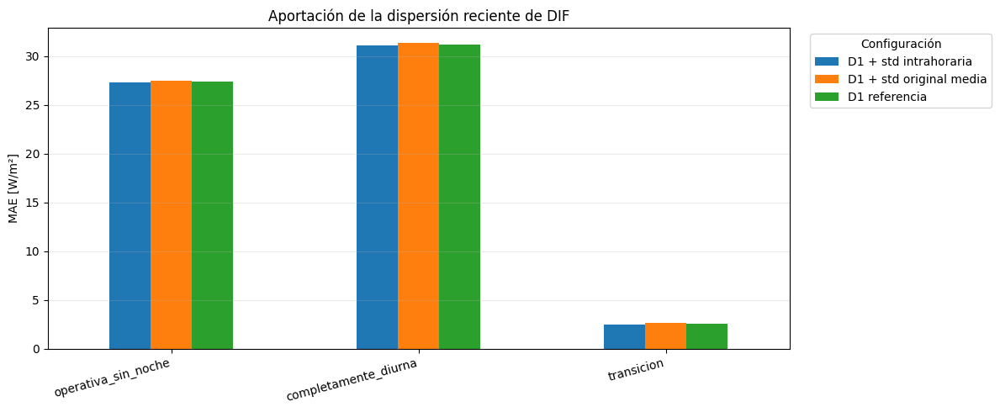

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import r2_score

# 1. Preparar los conjuntos
train_dispersion = train_std.sort_values("instante_objetivo").reset_index(drop=True).copy()
validation_dispersion = (
    validation_std.sort_values("instante_objetivo").reset_index(drop=True).copy()
)
VARIABLES_REFERENCIA_D1 = VARIABLES_HGB8 + ["delta_DIF_t"]
VARIABLES_D1_STD_MEDIA = VARIABLES_REFERENCIA_D1 + ["DIF_std_media_lag1"]
VARIABLES_D1_STD_INTRAHORARIA = VARIABLES_REFERENCIA_D1 + ["DIF_std_intrahoraria_lag1"]


# 2. Nombres trazables
NOMBRE_REFERENCIA_D1 = "M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global"
NOMBRE_STD_MEDIA = "M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdMedia-AbsoluteError-Global"
NOMBRE_STD_INTRAHORARIA = (
    "M3-HGB-10V-DIF-Elevacion-Delta1-DIFStdIntrahoraria-AbsoluteError-Global"
)
CONFIGURACIONES_DISPERSION = {
    NOMBRE_REFERENCIA_D1: {
        "familia": "Referencia D1",
        "n_variables": 9,
        "variables": VARIABLES_REFERENCIA_D1,
    },
    NOMBRE_STD_MEDIA: {
        "familia": "DIF std original media",
        "n_variables": 10,
        "variables": VARIABLES_D1_STD_MEDIA,
    },
    NOMBRE_STD_INTRAHORARIA: {
        "familia": "DIF std intrahoraria",
        "n_variables": 10,
        "variables": VARIABLES_D1_STD_INTRAHORARIA,
    },
}


# 3. Comprobar disponibilidad
for nombre_tabla, tabla in {"train": train_dispersion, "validation": validation_dispersion}.items():
    for nombre_modelo, configuracion in CONFIGURACIONES_DISPERSION.items():
        ausentes = [
            variable for variable in configuracion["variables"] if variable not in tabla.columns
        ]
        if ausentes:
            raise ValueError(
                f"Faltan variables en {nombre_tabla} para "
                f"{nombre_modelo}:\n" + "\n".join(ausentes)
            )

        n_missing = tabla[configuracion["variables"]].isna().sum().sum()
        if n_missing != 0:
            raise ValueError(
                f"{nombre_modelo} presenta {n_missing} " f"valores ausentes en {nombre_tabla}."
            )


# 4. Constructor común
def crear_HGB_dispersion():
    return HistGradientBoostingRegressor(
        loss="absolute_error",
        learning_rate=0.03,
        max_iter=300,
        max_leaf_nodes=7,
        min_samples_leaf=20,
        l2_regularization=1.0,
        early_stopping=False,
        random_state=42,
    )


# 5. Validación temporal interna
tscv = TimeSeriesSplit(n_splits=5)
resultados_CV_dispersion = []
for fold, (indices_train, indices_val) in enumerate(tscv.split(train_dispersion), start=1):
    for nombre_modelo, configuracion in CONFIGURACIONES_DISPERSION.items():
        variables = configuracion["variables"]
        modelo_fold = crear_HGB_dispersion()
        modelo_fold.fit(
            train_dispersion.loc[indices_train, variables],
            train_dispersion.loc[indices_train, OBJETIVO],
        )
        pred_fold = modelo_fold.predict(train_dispersion.loc[indices_val, variables])
        y_fold = train_dispersion.loc[indices_val, OBJETIVO].to_numpy()
        error_fold = pred_fold - y_fold
        resultados_CV_dispersion.append(
            {
                "fold": fold,
                "modelo": nombre_modelo,
                "familia": configuracion["familia"],
                "n_variables": configuracion["n_variables"],
                "n_train_fold": len(indices_train),
                "n_validation_fold": len(indices_val),
                "MAE": np.mean(np.abs(error_fold)),
                "RMSE": np.sqrt(np.mean(error_fold**2)),
                "sesgo": np.mean(error_fold),
            }
        )

tabla_CV_dispersion = pd.DataFrame(resultados_CV_dispersion)
resumen_CV_dispersion = (
    tabla_CV_dispersion.groupby(["modelo", "familia", "n_variables"], as_index=False)
    .agg(
        MAE_CV_medio=("MAE", "mean"),
        MAE_CV_std=("MAE", "std"),
        RMSE_CV_medio=("RMSE", "mean"),
        sesgo_CV_medio=("sesgo", "mean"),
    )
    .sort_values("MAE_CV_medio")
    .reset_index(drop=True)
)
print("VALIDACIÓN TEMPORAL INTERNA")
display(tabla_CV_dispersion.round(4))
print("\nRESUMEN CV")
display(resumen_CV_dispersion.round(4))


# 6. Entrenar los tres modelos con todo train
modelos_dispersion = {}
train_resultados_dispersion = train_dispersion.copy()
validation_resultados_dispersion = validation_dispersion.copy()
for nombre_modelo, configuracion in CONFIGURACIONES_DISPERSION.items():
    variables = configuracion["variables"]
    modelo = crear_HGB_dispersion()
    modelo.fit(train_dispersion[variables], train_dispersion[OBJETIVO])
    modelos_dispersion[nombre_modelo] = modelo
    train_resultados_dispersion[nombre_modelo] = modelo.predict(train_dispersion[variables])
    validation_resultados_dispersion[nombre_modelo] = modelo.predict(
        validation_dispersion[variables]
    )


# 7. Métricas
def obtener_mascaras_dispersion(tabla):
    return {
        "total": pd.Series(True, index=tabla.index),
        "operativa_sin_noche": tabla[REGIMEN].isin(["completamente_diurna", "transicion"]),
        "completamente_diurna": tabla[REGIMEN].eq("completamente_diurna"),
        "transicion": tabla[REGIMEN].eq("transicion"),
        "noche": tabla[REGIMEN].eq("noche"),
    }

def calcular_metricas_dispersion(tabla, prediccion, mascara):
    datos = tabla.loc[mascara]
    y_real = datos[OBJETIVO].to_numpy()
    y_pred = datos[prediccion].to_numpy()
    error = y_pred - y_real
    error_abs = np.abs(error)
    mae = error_abs.mean()
    media_real = y_real.mean()
    return {
        "n": len(datos),
        "DIF_media_real": media_real,
        "DIF_mediana_real": np.median(y_real),
        "MAE": mae,
        "nMAE_pct": (100 * mae / media_real if not np.isclose(media_real, 0) else np.nan),
        "RMSE": np.sqrt(np.mean(error**2)),
        "sesgo": error.mean(),
        "mediana_error_abs": np.median(error_abs),
        "p90_error_abs": np.quantile(error_abs, 0.90),
        "p95_error_abs": np.quantile(error_abs, 0.95),
        "p99_error_abs": np.quantile(error_abs, 0.99),
        "R2": (r2_score(y_real, y_pred) if len(y_real) > 1 and np.var(y_real) > 0 else np.nan),
    }

resultados_metricas_dispersion = []
for particion, tabla in {
    "train": train_resultados_dispersion,
    "validation": validation_resultados_dispersion,
}.items():
    mascaras = obtener_mascaras_dispersion(tabla)
    for poblacion, mascara in mascaras.items():
        for nombre_modelo, configuracion in CONFIGURACIONES_DISPERSION.items():
            resultados_metricas_dispersion.append(
                {
                    "particion": particion,
                    "poblacion": poblacion,
                    "modelo": nombre_modelo,
                    "familia": configuracion["familia"],
                    "n_variables": configuracion["n_variables"],
                    **calcular_metricas_dispersion(tabla, nombre_modelo, mascara),
                }
            )

tabla_metricas_dispersion = pd.DataFrame(resultados_metricas_dispersion)
print("MÉTRICAS COMPLETAS")
display(tabla_metricas_dispersion.round(4))


# 8. Tabla principal de selección
resumen_seleccion_dispersion = []
for nombre_modelo, configuracion in CONFIGURACIONES_DISPERSION.items():
    fila_CV = resumen_CV_dispersion[resumen_CV_dispersion["modelo"].eq(nombre_modelo)].iloc[0]
    metricas_validation = tabla_metricas_dispersion[
        (tabla_metricas_dispersion["particion"] == "validation")
        & (tabla_metricas_dispersion["modelo"] == nombre_modelo)
    ]

    def extraer(poblacion, metrica):
        return metricas_validation.loc[
            metricas_validation["poblacion"].eq(poblacion), metrica
        ].iloc[0]

    resumen_seleccion_dispersion.append(
        {
            "modelo": nombre_modelo,
            "familia": configuracion["familia"],
            "n_variables": configuracion["n_variables"],
            "MAE_CV_temporal": fila_CV["MAE_CV_medio"],
            "std_CV_temporal": fila_CV["MAE_CV_std"],
            "MAE_val_total": extraer("total", "MAE"),
            "MAE_val_operativa": extraer("operativa_sin_noche", "MAE"),
            "MAE_val_diurna": extraer("completamente_diurna", "MAE"),
            "MAE_val_transicion": extraer("transicion", "MAE"),
            "RMSE_val_operativa": extraer("operativa_sin_noche", "RMSE"),
            "sesgo_val_operativa": extraer("operativa_sin_noche", "sesgo"),
            "p95_val_operativa": extraer("operativa_sin_noche", "p95_error_abs"),
            "p99_val_operativa": extraer("operativa_sin_noche", "p99_error_abs"),
            "R2_val_operativa": extraer("operativa_sin_noche", "R2"),
        }
    )

tabla_seleccion_dispersion = (
    pd.DataFrame(resumen_seleccion_dispersion)
    .sort_values(["MAE_val_operativa", "MAE_CV_temporal"])
    .reset_index(drop=True)
)
print("\nTABLA PRINCIPAL DE SELECCIÓN")
display(tabla_seleccion_dispersion.round(4))


# 9. Mejora directa frente a D1
comparacion_dispersion = []
for nombre_modelo in [NOMBRE_STD_MEDIA, NOMBRE_STD_INTRAHORARIA]:
    for poblacion, mascara in obtener_mascaras_dispersion(validation_resultados_dispersion).items():
        datos = validation_resultados_dispersion.loc[mascara]
        error_referencia = np.abs(datos[NOMBRE_REFERENCIA_D1] - datos[OBJETIVO])
        error_candidato = np.abs(datos[nombre_modelo] - datos[OBJETIVO])
        comparacion_dispersion.append(
            {
                "modelo": nombre_modelo,
                "poblacion": poblacion,
                "mejora_MAE": error_referencia.mean() - error_candidato.mean(),
                "porcentaje_horas_ganadas": 100 * np.mean(error_candidato < error_referencia),
            }
        )

tabla_mejoras_dispersion = pd.DataFrame(comparacion_dispersion)
print("\nMEJORAS FRENTE A D1 ABSOLUTO")
display(tabla_mejoras_dispersion.round(4))


# 10. Figura
datos_figura = tabla_metricas_dispersion[
    (tabla_metricas_dispersion["particion"] == "validation")
    & (
        tabla_metricas_dispersion["poblacion"].isin(
            ["operativa_sin_noche", "completamente_diurna", "transicion"]
        )
    )
].copy()
etiquetas = {
    NOMBRE_REFERENCIA_D1: "D1 referencia",
    NOMBRE_STD_MEDIA: "D1 + std original media",
    NOMBRE_STD_INTRAHORARIA: "D1 + std intrahoraria",
}
datos_figura["modelo_corto"] = datos_figura["modelo"].map(etiquetas)
tabla_figura = datos_figura.pivot(index="poblacion", columns="modelo_corto", values="MAE").reindex(
    ["operativa_sin_noche", "completamente_diurna", "transicion"]
)
ax = tabla_figura.plot(kind="bar", figsize=(12, 5))
ax.set_title("Aportación de la dispersión reciente de DIF")
ax.set_xlabel("")
ax.set_ylabel("MAE [W/m²]")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Configuración", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

**Resultados.** Las tres configuraciones obtienen prácticamente el mismo MAE medio en la validación temporal interna: 22,42 W/m² con la dispersión intrahoraria, 22,44 W/m² con la media de la desviación registrada y 22,45 W/m² sin ninguna de ellas. En validación, `DIF_std_intrahoraria_lag1` reduce el MAE de operación en 0,08 W/m² y es más precisa que el modelo de referencia en el 50,57 % de esas horas, mientras que `DIF_std_media_lag1` lo aumenta en 0,14 W/m².

### 3.27 Núcleo HGB de referencia

Se fija como núcleo de desarrollo el HGB de 9 variables con pérdida absoluta (`M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global`): cuatro retardos de la DIF, cuatro elevaciones solares históricas y `delta_DIF_t`. Las incorporaciones posteriores mantienen constantes estas variables, la pérdida y los hiperparámetros, y el HGB de 8 variables con pérdida cuadrática se conserva como referencia secundaria.

In [ ]:
NOMBRE_NUCLEO_CONGELADO = "M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global"
VARIABLES_NUCLEO_CONGELADO = [
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    "elevacion_media_lag1",
    "elevacion_media_lag2",
    "elevacion_media_lag3",
    "elevacion_media_lag24",
    "delta_DIF_t",
]
HIPERPARAMETROS_NUCLEO = {
    "loss": "absolute_error",
    "learning_rate": 0.03,
    "max_iter": 300,
    "max_leaf_nodes": 7,
    "min_samples_leaf": 20,
    "l2_regularization": 1.0,
    "early_stopping": False,
    "random_state": 42,
}
modelo_nucleo_congelado = modelos_dispersion[NOMBRE_REFERENCIA_D1]
train_nucleo_congelado = train_dispersion.copy()
validation_nucleo_congelado = validation_dispersion.copy()


# Predicciones congeladas
train_nucleo_congelado[NOMBRE_NUCLEO_CONGELADO] = modelo_nucleo_congelado.predict(
    train_nucleo_congelado[VARIABLES_NUCLEO_CONGELADO]
)
validation_nucleo_congelado[NOMBRE_NUCLEO_CONGELADO] = modelo_nucleo_congelado.predict(
    validation_nucleo_congelado[VARIABLES_NUCLEO_CONGELADO]
)


# Comprobaciones
assert len(VARIABLES_NUCLEO_CONGELADO) == 9
assert len(train_nucleo_congelado) == 5149
assert len(validation_nucleo_congelado) == 1464
assert not train_nucleo_congelado[VARIABLES_NUCLEO_CONGELADO].isna().any().any()
assert not validation_nucleo_congelado[VARIABLES_NUCLEO_CONGELADO].isna().any().any()
print("NÚCLEO CONGELADO CORRECTAMENTE")
print("Modelo:", NOMBRE_NUCLEO_CONGELADO)
print("Número de variables:", len(VARIABLES_NUCLEO_CONGELADO))
print("Loss:", HIPERPARAMETROS_NUCLEO["loss"])
print("\nVariables:")
for variable in VARIABLES_NUCLEO_CONGELADO:
    print(" -", variable)

NÚCLEO CONGELADO CORRECTAMENTE
Modelo: M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global
Número de variables: 9
Loss: absolute_error

Variables:
 - DIF_lag_1
 - DIF_lag_2
 - DIF_lag_3
 - DIF_lag_24
 - elevacion_media_lag1
 - elevacion_media_lag2
 - elevacion_media_lag3
 - elevacion_media_lag24
 - delta_DIF_t


### 3.28 Incorporación de DIR y SWD al núcleo HGB

Se evalúa si la irradiancia directa normal (DIR) y la irradiancia global horizontal (SWD) aportan información incremental al HGB de 9 variables con pérdida absoluta. Cada familia se añade por separado y de forma progresiva (última hora, tres horas recientes y tres horas recientes con el retardo diario), con el algoritmo, la pérdida, los hiperparámetros, la partición y las métricas constantes.

> *Se utiliza en la memoria: añadir al HGB la directa o la global retrasadas no lo mejora (apartado 5.2).*

In [ ]:
from google.colab import files
from pathlib import Path
import pandas as pd
import zipfile
import shutil

print("Selecciona:\ncheckpoint_modelado_diurno_geometria_ablaciones_20261003T164509.zip")
archivos_subidos = files.upload()
nombre_zip = next(iter(archivos_subidos))
carpeta_checkpoint = Path("/content/checkpoint_geometria")

# Limpiar únicamente la carpeta temporal de este checkpoint
if carpeta_checkpoint.exists():
    shutil.rmtree(carpeta_checkpoint)

carpeta_checkpoint.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(nombre_zip, "r") as archivo_zip:
    archivo_zip.extractall(carpeta_checkpoint)

parquets_encontrados = list(carpeta_checkpoint.rglob("*.parquet"))
print("\nParquets encontrados:")
for ruta in parquets_encontrados:
    print(" -", ruta.name)

# Localización independiente de la carpeta interna del ZIP
rutas_train = list(carpeta_checkpoint.rglob("04_train_geometria.parquet"))
rutas_validation = list(carpeta_checkpoint.rglob("05_validation_geometria.parquet"))
if len(rutas_train) != 1:
    raise FileNotFoundError("No se ha encontrado exactamente un 04_train_geometria.parquet.")

if len(rutas_validation) != 1:
    raise FileNotFoundError(
        "No se ha encontrado exactamente un 05_validation_geometria.parquet."
    )

train_geometria = pd.read_parquet(rutas_train[0])
validation_geometria = pd.read_parquet(rutas_validation[0])
print("\nCHECKPOINT CARGADO")
print(f"train_geometria:      {train_geometria.shape}")
print(f"validation_geometria: {validation_geometria.shape}")

Selecciona:
checkpoint_modelado_diurno_geometria_ablaciones_20261003T164509.zip



Parquets encontrados:
 - 06_train_diurno.parquet
 - 07_validation_diurna.parquet
 - 02_dataset_con_geometria.parquet
 - 04_train_geometria.parquet
 - 05_validation_geometria.parquet
 - 03_soporte_geometria_train_validation.parquet
 - 01_dataset_checkpoint_base.parquet

CHECKPOINT CARGADO
train_geometria:      (5149, 65)
validation_geometria: (1464, 65)


In [ ]:
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

# 1. Recuperar train y validation
if "train_geometria" in globals() and "validation_geometria" in globals():
    train_hgb = train_geometria.copy()
    validation_hgb = validation_geometria.copy()

elif "train_m3" in globals() and "validation_m3" in globals():
    train_hgb = train_m3.copy()
    validation_hgb = validation_m3.copy()

else:
    raise NameError(
        "No encuentro train_geometria/validation_geometria ni "
        "train_m3/validation_m3. Carga primero el último checkpoint."
    )

# 2. Recuperar instante objetivo
def preparar_instante_objetivo(df, nombre):
    df = df.copy()
    if "instante_objetivo" in df.columns:
        df["instante_objetivo"] = pd.to_datetime(df["instante_objetivo"], utc=True)

    elif isinstance(df.index, pd.DatetimeIndex):
        df["instante_objetivo"] = pd.to_datetime(df.index, utc=True)

    else:
        raise KeyError(f"{nombre} no contiene instante_objetivo ni tiene índice temporal.")

    return df.sort_values("instante_objetivo").reset_index(drop=True)

train_hgb = preparar_instante_objetivo(train_hgb, "train")
validation_hgb = preparar_instante_objetivo(validation_hgb, "validation")
objetivo = "DIF_objetivo_t1"
variables_nucleo = [
    "DIF_lag_1",
    "DIF_lag_2",
    "DIF_lag_3",
    "DIF_lag_24",
    "elevacion_media_lag1",
    "elevacion_media_lag2",
    "elevacion_media_lag3",
    "elevacion_media_lag24",
    "delta_DIF_t",
]
faltantes_nucleo = [
    c for c in variables_nucleo + [objetivo, "regimen_solar_objetivo"] if c not in train_hgb.columns
]
if faltantes_nucleo:
    raise KeyError(f"Faltan columnas del núcleo: {faltantes_nucleo}")

print(f"Train:      {train_hgb.shape}")
print(f"Validation: {validation_hgb.shape}")
print(f"Variables del núcleo: {len(variables_nucleo)}")
print("Preparación correcta.")

Train:      (5149, 65)
Validation: (1464, 65)
Variables del núcleo: 9
Preparación correcta.


### 3.29 Construcción de las medias retardadas de DIR

A partir del registro minutal se calcula la media horaria de DIR y se construyen sus retardos 1, 2, 3 y 24 respecto a la hora objetivo, todos correspondientes a intervalos cerrados antes de la predicción. Con ellos y con las medias retardadas de SWD se definen las seis configuraciones ampliadas.

In [ ]:
# La celda reutiliza datos_originales si continúa en el mismo entorno.
# Si no existe, solicita únicamente el parquet original.
if "datos_originales" not in globals():
    from google.colab import files
    print("Selecciona el parquet original minutal.")
    archivos = files.upload()
    ruta_original = next(iter(archivos))
    datos_originales = pd.read_parquet(ruta_original)

columna_fecha_original = "Date/Time"
columna_DIR = "DIR [W/m**2]"
for columna in [columna_fecha_original, columna_DIR]:
    if columna not in datos_originales.columns:
        raise KeyError(f"No se encuentra la columna requerida: {columna}")

dir_minutal = datos_originales[[columna_fecha_original, columna_DIR]].copy()
dir_minutal[columna_fecha_original] = pd.to_datetime(
    dir_minutal[columna_fecha_original], utc=True, errors="coerce"
)
dir_minutal[columna_DIR] = pd.to_numeric(dir_minutal[columna_DIR], errors="coerce")
dir_minutal["hora"] = dir_minutal[columna_fecha_original].dt.floor("h")
DIR_horaria = dir_minutal.groupby("hora", as_index=True)[columna_DIR].mean().sort_index()

def incorporar_lags_DIR(df):
    salida = df.copy()
    for lag in [1, 2, 3, 24]:
        instante_historico = salida["instante_objetivo"] - pd.Timedelta(hours=lag)
        salida[f"DIR_media_lag{lag}"] = instante_historico.map(DIR_horaria)

    return salida

train_hgb = incorporar_lags_DIR(train_hgb)
validation_hgb = incorporar_lags_DIR(validation_hgb)
variables_DIR = ["DIR_media_lag1", "DIR_media_lag2", "DIR_media_lag3", "DIR_media_lag24"]
comprobacion_DIR = pd.DataFrame(
    {
        "train_ausentes": train_hgb[variables_DIR].isna().sum(),
        "validation_ausentes": validation_hgb[variables_DIR].isna().sum(),
        "train_disponibilidad_pct": 100 * train_hgb[variables_DIR].notna().mean(),
        "validation_disponibilidad_pct": 100 * validation_hgb[variables_DIR].notna().mean(),
    }
)
display(comprobacion_DIR.round(3))

,train_ausentes,validation_ausentes,train_disponibilidad_pct,validation_disponibilidad_pct
DIR_media_lag1,0,0,100.0,100.0
DIR_media_lag2,0,0,100.0,100.0
DIR_media_lag3,0,0,100.0,100.0
DIR_media_lag24,0,0,100.0,100.0


In [ ]:
variables_SWD = ["SWD_media_lag1", "SWD_media_lag2", "SWD_media_lag3", "SWD_media_lag24"]
faltantes_SWD = [c for c in variables_SWD if c not in train_hgb.columns]
if faltantes_SWD:
    raise KeyError(f"Faltan variables de SWD en el checkpoint: {faltantes_SWD}")

configuraciones_hgb = {
    "M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global": variables_nucleo,
    "M4-HGB-10V-Nucleo-DIR1-AbsoluteError-Global": variables_nucleo + ["DIR_media_lag1"],
    "M4-HGB-12V-Nucleo-DIR123-AbsoluteError-Global": variables_nucleo
    + ["DIR_media_lag1", "DIR_media_lag2", "DIR_media_lag3"],
    "M4-HGB-13V-Nucleo-DIR12324-AbsoluteError-Global": variables_nucleo + variables_DIR,
    "M4-HGB-10V-Nucleo-SWD1-AbsoluteError-Global": variables_nucleo + ["SWD_media_lag1"],
    "M4-HGB-12V-Nucleo-SWD123-AbsoluteError-Global": variables_nucleo
    + ["SWD_media_lag1", "SWD_media_lag2", "SWD_media_lag3"],
    "M4-HGB-13V-Nucleo-SWD12324-AbsoluteError-Global": variables_nucleo + variables_SWD,
}
tabla_configuraciones = pd.DataFrame(
    [
        {"modelo": nombre, "n_variables": len(columnas), "variables": " | ".join(columnas)}
        for nombre, columnas in configuraciones_hgb.items()
    ]
)
display(tabla_configuraciones)

,modelo,n_variables,variables
0,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,9,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...
1,M4-HGB-10V-Nucleo-DIR1-AbsoluteError-Global,10,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...
2,M4-HGB-12V-Nucleo-DIR123-AbsoluteError-Global,12,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...
3,M4-HGB-13V-Nucleo-DIR12324-AbsoluteError-Global,13,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...
4,M4-HGB-10V-Nucleo-SWD1-AbsoluteError-Global,10,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...
5,M4-HGB-12V-Nucleo-SWD123-AbsoluteError-Global,12,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...
6,M4-HGB-13V-Nucleo-SWD12324-AbsoluteError-Global,13,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...


In [ ]:
variables_SWD = ["SWD_media_lag1", "SWD_media_lag2", "SWD_media_lag3", "SWD_media_lag24"]
faltantes_SWD = [c for c in variables_SWD if c not in train_hgb.columns]
if faltantes_SWD:
    raise KeyError(f"Faltan variables de SWD en el checkpoint: {faltantes_SWD}")

configuraciones_hgb = {
    "M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global": variables_nucleo,
    "M4-HGB-10V-Nucleo-DIR1-AbsoluteError-Global": variables_nucleo + ["DIR_media_lag1"],
    "M4-HGB-12V-Nucleo-DIR123-AbsoluteError-Global": variables_nucleo
    + ["DIR_media_lag1", "DIR_media_lag2", "DIR_media_lag3"],
    "M4-HGB-13V-Nucleo-DIR12324-AbsoluteError-Global": variables_nucleo + variables_DIR,
    "M4-HGB-10V-Nucleo-SWD1-AbsoluteError-Global": variables_nucleo + ["SWD_media_lag1"],
    "M4-HGB-12V-Nucleo-SWD123-AbsoluteError-Global": variables_nucleo
    + ["SWD_media_lag1", "SWD_media_lag2", "SWD_media_lag3"],
    "M4-HGB-13V-Nucleo-SWD12324-AbsoluteError-Global": variables_nucleo + variables_SWD,
}
tabla_configuraciones = pd.DataFrame(
    [
        {"modelo": nombre, "n_variables": len(columnas), "variables": " | ".join(columnas)}
        for nombre, columnas in configuraciones_hgb.items()
    ]
)
display(tabla_configuraciones)

,modelo,n_variables,variables
0,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,9,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...
1,M4-HGB-10V-Nucleo-DIR1-AbsoluteError-Global,10,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...
2,M4-HGB-12V-Nucleo-DIR123-AbsoluteError-Global,12,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...
3,M4-HGB-13V-Nucleo-DIR12324-AbsoluteError-Global,13,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...
4,M4-HGB-10V-Nucleo-SWD1-AbsoluteError-Global,10,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...
5,M4-HGB-12V-Nucleo-SWD123-AbsoluteError-Global,12,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...
6,M4-HGB-13V-Nucleo-SWD12324-AbsoluteError-Global,13,DIF_lag_1 | DIF_lag_2 | DIF_lag_3 | DIF_lag_24...


**Resultados.** Los cuatro retardos de DIR están disponibles en el 100 % de las horas de entrenamiento y de validación.

### 3.30 Comparación de las familias DIR y SWD

Los siete modelos se comparan mediante validación temporal interna de cinco bloques y con MAE, nMAE, RMSE, sesgo y R² en validación, desglosados por régimen solar. Una familia se considera útil si mejora el MAE de validación en las horas de operación o completamente diurnas, de forma coherente con la validación temporal y suficiente para compensar el aumento de complejidad.

In [ ]:
parametros_hgb = {
    "loss": "absolute_error",
    "learning_rate": 0.03,
    "max_iter": 300,
    "max_leaf_nodes": 7,
    "min_samples_leaf": 20,
    "l2_regularization": 1.0,
    "early_stopping": False,
    "random_state": 42,
}

def obtener_mascara_regimen(df, regimen):
    serie = df["regimen_solar_objetivo"].astype(str)
    if regimen == "total":
        return np.ones(len(df), dtype=bool)

    if regimen == "operacional":
        return serie.isin(["completamente_diurna", "transicion"]).to_numpy()

    return (serie == regimen).to_numpy()

regimenes = ["total", "operacional", "completamente_diurna", "transicion", "noche"]

def calcular_metricas(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_real, y_pred)
    rmse = mean_squared_error(y_real, y_pred) ** 0.5
    media_real = np.mean(y_real)
    nmae = 100 * mae / media_real if media_real != 0 else np.nan
    return {
        "n": len(y_real),
        "media_DIF_real": media_real,
        "mediana_DIF_real": np.median(y_real),
        "MAE": mae,
        "nMAE_pct": nmae,
        "RMSE": rmse,
        "sesgo": np.mean(y_pred - y_real),
        "R2": (r2_score(y_real, y_pred) if len(y_real) > 1 else np.nan),
        "p95_error_absoluto": np.quantile(np.abs(y_pred - y_real), 0.95),
    }

tscv = TimeSeriesSplit(n_splits=5)
resultados_cv = []
resultados_validation = []
modelos_hgb_entrenados = {}
predicciones_validation = validation_hgb[
    ["instante_objetivo", objetivo, "regimen_solar_objetivo"]
].copy()
for nombre_modelo, variables in configuraciones_hgb.items():
    X_train = train_hgb[variables].copy()
    y_train = train_hgb[objetivo].copy()
    X_validation = validation_hgb[variables].copy()
    y_validation = validation_hgb[objetivo].copy()

    # Validación temporal interna
    maes_fold = []
    for numero_fold, (idx_train, idx_val) in enumerate(tscv.split(X_train), start=1):
        modelo_fold = HistGradientBoostingRegressor(**parametros_hgb)
        modelo_fold.fit(X_train.iloc[idx_train], y_train.iloc[idx_train])
        pred_fold = modelo_fold.predict(X_train.iloc[idx_val])
        mae_fold = mean_absolute_error(y_train.iloc[idx_val], pred_fold)
        maes_fold.append(mae_fold)
        resultados_cv.append({"modelo": nombre_modelo, "fold": numero_fold, "MAE": mae_fold})

    # Ajuste final sobre todo train
    modelo_final = HistGradientBoostingRegressor(**parametros_hgb)
    modelo_final.fit(X_train, y_train)
    pred_validation = modelo_final.predict(X_validation)
    modelos_hgb_entrenados[nombre_modelo] = modelo_final
    predicciones_validation[nombre_modelo] = pred_validation

    # Métricas por régimen
    for regimen in regimenes:
        mascara = obtener_mascara_regimen(validation_hgb, regimen)
        metricas = calcular_metricas(y_validation.loc[mascara], pred_validation[mascara])
        resultados_validation.append(
            {
                "modelo": nombre_modelo,
                "regimen": regimen,
                "n_variables": len(variables),
                "CV_MAE_medio": np.mean(maes_fold),
                "CV_MAE_std": np.std(maes_fold, ddof=1),
                **metricas,
            }
        )

    print(f"Finalizado: {nombre_modelo} " f"| CV MAE={np.mean(maes_fold):.3f}")

resultados_cv = pd.DataFrame(resultados_cv)
resultados_validation = pd.DataFrame(resultados_validation)
print("Entrenamiento finalizado.")

Finalizado: M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global | CV MAE=22.453
Finalizado: M4-HGB-10V-Nucleo-DIR1-AbsoluteError-Global | CV MAE=22.358
Finalizado: M4-HGB-12V-Nucleo-DIR123-AbsoluteError-Global | CV MAE=22.494
Finalizado: M4-HGB-13V-Nucleo-DIR12324-AbsoluteError-Global | CV MAE=22.254
Finalizado: M4-HGB-10V-Nucleo-SWD1-AbsoluteError-Global | CV MAE=22.516
Finalizado: M4-HGB-12V-Nucleo-SWD123-AbsoluteError-Global | CV MAE=22.688
Finalizado: M4-HGB-13V-Nucleo-SWD12324-AbsoluteError-Global | CV MAE=22.584
Entrenamiento finalizado.


In [ ]:
# Tabla principal: población operacional
tabla_operacional = (
    resultados_validation.query("regimen == 'operacional'")
    .sort_values(["MAE", "n_variables"])
    .reset_index(drop=True)
)
mae_referencia = tabla_operacional.loc[
    tabla_operacional["modelo"] == "M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global", "MAE"
].iloc[0]
tabla_operacional["mejora_MAE_vs_nucleo"] = mae_referencia - tabla_operacional["MAE"]
tabla_operacional["mejora_pct_vs_nucleo"] = (
    100 * tabla_operacional["mejora_MAE_vs_nucleo"] / mae_referencia
)
display(
    tabla_operacional[
        [
            "modelo",
            "n_variables",
            "CV_MAE_medio",
            "CV_MAE_std",
            "n",
            "media_DIF_real",
            "MAE",
            "mejora_MAE_vs_nucleo",
            "mejora_pct_vs_nucleo",
            "nMAE_pct",
            "RMSE",
            "sesgo",
            "R2",
            "p95_error_absoluto",
        ]
    ].round(4)
)

# Comparación por régimen
tabla_regimenes = resultados_validation.pivot(
    index="modelo", columns="regimen", values="MAE"
).reset_index()
display(tabla_regimenes.round(4))

,modelo,n_variables,CV_MAE_medio,CV_MAE_std,n,media_DIF_real,MAE,mejora_MAE_vs_nucleo,mejora_pct_vs_nucleo,nMAE_pct,RMSE,sesgo,R2,p95_error_absoluto
0,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,9,22.4527,5.5020,884,141.7976,27.3534,0.0000,0.0000,19.2905,42.5220,0.0465,0.8397,90.2509
1,M4-HGB-13V-Nucleo-DIR12324-AbsoluteError-Global,13,22.2537,5.6120,884,141.7976,27.4978,-0.1444,-0.5280,19.3923,42.6183,-0.1106,0.8390,90.0233
2,M4-HGB-10V-Nucleo-DIR1-AbsoluteError-Global,10,22.3577,5.6365,884,141.7976,27.5507,-0.1973,-0.7213,19.4296,42.7040,-0.3609,0.8384,90.2140
3,M4-HGB-12V-Nucleo-DIR123-AbsoluteError-Global,12,22.4942,5.8754,884,141.7976,27.5633,-0.2099,-0.7672,19.4385,42.7327,-0.2670,0.8382,91.2313
4,M4-HGB-13V-Nucleo-SWD12324-AbsoluteError-Global,13,22.5840,5.5512,884,141.7976,27.7680,-0.4145,-1.5155,19.5828,42.9178,-0.1181,0.8368,91.7258
5,M4-HGB-10V-Nucleo-SWD1-AbsoluteError-Global,10,22.5159,5.4845,884,141.7976,27.7773,-0.4239,-1.5498,19.5894,42.8927,-1.1393,0.8369,92.4740
6,M4-HGB-12V-Nucleo-SWD123-AbsoluteError-Global,12,22.6875,5.3603,884,141.7976,27.8096,-0.4562,-1.6677,19.6122,42.9389,-0.9607,0.8366,90.2414


regimen,modelo,completamente_diurna,noche,operacional,total,transicion
0,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-G...,31.2125,0.1154,27.3534,16.5624,2.5450
1,M4-HGB-10V-Nucleo-DIR1-AbsoluteError-Global,31.4432,0.1158,27.5507,16.6817,2.5274
2,M4-HGB-10V-Nucleo-SWD1-AbsoluteError-Global,31.6996,0.1172,27.7773,16.8191,2.5625
3,M4-HGB-12V-Nucleo-DIR123-AbsoluteError-Global,31.4547,0.1168,27.5633,16.6897,2.5468
4,M4-HGB-12V-Nucleo-SWD123-AbsoluteError-Global,31.7335,0.1174,27.8096,16.8387,2.5844
5,M4-HGB-13V-Nucleo-DIR12324-AbsoluteError-Global,31.3781,0.1169,27.4978,16.6502,2.5534
6,M4-HGB-13V-Nucleo-SWD12324-AbsoluteError-Global,31.6869,0.1171,27.7680,16.8134,2.5746


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


**Resultados.** Ninguna configuración con DIR o SWD reduce el MAE del núcleo de 9 variables en las horas de operación (27,35 W/m²) ni en las completamente diurnas (31,21 W/m²).
- La mejor variante con DIR (retardos 1, 2, 3 y 24) obtiene 27,50 y 31,38 W/m², aunque su MAE de validación temporal es menor (22,25 frente a 22,45 W/m²).
- Las variantes con SWD aumentan el MAE de operación entre 0,41 y 0,46 W/m² y tampoco mejoran la validación temporal.
- En transición, solo DIR en el último retardo reduce ligeramente el MAE (de 2,55 a 2,53 W/m²).

### 3.31 Guardado del experimento con DIR y SWD

Se guardan las configuraciones, los resultados de validación temporal y de validación por régimen, las predicciones y los modelos entrenados de la comparación entre el núcleo HGB y las variantes con DIR y SWD.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import joblib
import shutil
import pandas as pd
import numpy as np
from google.colab import files

# 1. Comprobar objetos necesarios
objetos_necesarios = [
    "train_hgb",
    "validation_hgb",
    "configuraciones_hgb",
    "parametros_hgb",
    "resultados_cv",
    "resultados_validation",
    "modelos_hgb_entrenados",
    "predicciones_validation",
]
objetos_ausentes = [nombre for nombre in objetos_necesarios if nombre not in globals()]
if objetos_ausentes:
    raise NameError(
        "Faltan objetos necesarios para exportar:\n"
        + "\n".join(f"- {nombre}" for nombre in objetos_ausentes)
    )

# 2. Crear carpeta del experimento
momento = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%dT%H%M%S")
nombre_experimento = f"experimento_HGB_DIR_SWD_{momento}"
carpeta_salida = Path("/content") / nombre_experimento
if carpeta_salida.exists():
    shutil.rmtree(carpeta_salida)

carpeta_salida.mkdir(parents=True, exist_ok=True)
carpeta_modelos = carpeta_salida / "modelos"
carpeta_modelos.mkdir(exist_ok=True)

# 3. Tabla de configuraciones
tabla_configuracion_exportar = pd.DataFrame(
    [
        {"modelo": nombre, "n_variables": len(variables), "variables": " | ".join(variables)}
        for nombre, variables in configuraciones_hgb.items()
    ]
)
tabla_configuracion_exportar.to_csv(carpeta_salida / "01_configuraciones_modelos.csv", index=False)

# 4. Resultados de CV
resultados_cv.to_csv(carpeta_salida / "02_resultados_cv_folds.csv", index=False)
resumen_cv_exportar = (
    resultados_cv.groupby("modelo", as_index=False)
    .agg(
        CV_MAE_medio=("MAE", "mean"),
        CV_MAE_std=("MAE", "std"),
        CV_MAE_minimo=("MAE", "min"),
        CV_MAE_maximo=("MAE", "max"),
        n_folds=("fold", "nunique"),
    )
    .sort_values("CV_MAE_medio")
)
resumen_cv_exportar.to_csv(carpeta_salida / "03_resumen_validacion_temporal.csv", index=False)

# 5. Métricas de validation
resultados_validation.to_csv(carpeta_salida / "04_metricas_validation_por_regimen.csv", index=False)
nombre_nucleo = "M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global"
tabla_operacional_exportar = resultados_validation.query("regimen == 'operacional'").copy()
mae_nucleo = tabla_operacional_exportar.loc[
    tabla_operacional_exportar["modelo"] == nombre_nucleo, "MAE"
]
if len(mae_nucleo) != 1:
    raise ValueError("No se ha localizado exactamente una fila del núcleo.")

mae_nucleo = mae_nucleo.iloc[0]
tabla_operacional_exportar["mejora_MAE_vs_nucleo"] = mae_nucleo - tabla_operacional_exportar["MAE"]
tabla_operacional_exportar["mejora_pct_vs_nucleo"] = (
    100 * tabla_operacional_exportar["mejora_MAE_vs_nucleo"] / mae_nucleo
)
tabla_operacional_exportar = tabla_operacional_exportar.sort_values(["MAE", "n_variables"])
tabla_operacional_exportar.to_csv(carpeta_salida / "05_comparacion_operacional.csv", index=False)
tabla_MAE_regimenes = resultados_validation.pivot(
    index="modelo", columns="regimen", values="MAE"
).reset_index()
tabla_MAE_regimenes.to_csv(carpeta_salida / "06_MAE_por_modelo_y_regimen.csv", index=False)

# 6. Predicciones de validation
predicciones_validation.to_parquet(
    carpeta_salida / "07_predicciones_validation.parquet", index=False
)
predicciones_validation.to_csv(carpeta_salida / "07_predicciones_validation.csv", index=False)

# 7. Crear soporte compacto y reproducible
variables_experimento = sorted(
    set(
        variable for lista_variables in configuraciones_hgb.values() for variable in lista_variables
    )
)
columnas_identificacion = ["instante_objetivo", "DIF_objetivo_t1", "regimen_solar_objetivo"]
columnas_compactas = [
    columna
    for columna in columnas_identificacion + variables_experimento
    if columna in train_hgb.columns
]
train_compacto = train_hgb[columnas_compactas].copy()
validation_compacto = validation_hgb[columnas_compactas].copy()
train_compacto.to_parquet(carpeta_salida / "08_train_soporte_compacto.parquet", index=False)
validation_compacto.to_parquet(
    carpeta_salida / "09_validation_soporte_compacto.parquet", index=False
)

# 8. Guardar modelos entrenados
indice_modelos = []
for numero, (nombre, modelo) in enumerate(modelos_hgb_entrenados.items(), start=1):
    nombre_archivo = f"modelo_{numero:02d}.joblib"
    joblib.dump(modelo, carpeta_modelos / nombre_archivo)
    indice_modelos.append(
        {
            "modelo": nombre,
            "archivo": f"modelos/{nombre_archivo}",
            "n_variables": len(configuraciones_hgb[nombre]),
            "variables": " | ".join(configuraciones_hgb[nombre]),
        }
    )

pd.DataFrame(indice_modelos).to_csv(carpeta_salida / "10_indice_modelos_guardados.csv", index=False)

# 9. Guardar DIR horaria empleada
if "DIR_horaria" in globals():
    DIR_horaria.rename("DIR_media_horaria").to_csv(
        carpeta_salida / "11_DIR_media_horaria.csv", index_label="hora"
    )

# 10. Metadatos
def convertir_json(valor):
    if isinstance(valor, (np.integer,)):
        return int(valor)
    if isinstance(valor, (np.floating,)):
        return float(valor)
    if isinstance(valor, (np.bool_,)):
        return bool(valor)
    if isinstance(valor, (pd.Timestamp, datetime)):
        return valor.isoformat()
    raise TypeError(f"Objeto no serializable: {type(valor)}")

metadatos = {
    "nombre_experimento": nombre_experimento,
    "fecha_exportacion_Europe_Madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "objetivo": "DIF_objetivo_t1",
    "horizonte": "una hora",
    "modelo_referencia": nombre_nucleo,
    "n_train": len(train_hgb),
    "n_validation": len(validation_hgb),
    "inicio_train_objetivo": train_hgb["instante_objetivo"].min(),
    "final_train_objetivo": train_hgb["instante_objetivo"].max(),
    "inicio_validation_objetivo": validation_hgb["instante_objetivo"].min(),
    "final_validation_objetivo": validation_hgb["instante_objetivo"].max(),
    "hiperparametros": parametros_hgb,
    "configuraciones": configuraciones_hgb,
    "decision": (
        "Mantener el núcleo de nueve variables. "
        "Las medias retardadas de DIR y SWD no mejoran "
        "el MAE de validation."
    ),
}
with open(carpeta_salida / "12_metadatos.json", "w", encoding="utf-8") as archivo:
    json.dump(metadatos, archivo, ensure_ascii=False, indent=2, default=convertir_json)

# 11. README
texto_readme = f"""
EXPERIMENTO HGB CON DIR Y SWD
=============================

Nombre: {nombre_experimento}

Objetivo
--------
Comprobar si las medias horarias retardadas de DIR y SWD
aportan información incremental al núcleo HGB congelado.

Modelo de referencia
--------------------
{nombre_nucleo}

Núcleo
------
- DIF_lag_1
- DIF_lag_2
- DIF_lag_3
- DIF_lag_24
- elevacion_media_lag1
- elevacion_media_lag2
- elevacion_media_lag3
- elevacion_media_lag24
- delta_DIF_t

Variantes estudiadas
--------------------
- DIR lag1
- DIR lags 1, 2 y 3
- DIR lags 1, 2, 3 y 24
- SWD lag1
- SWD lags 1, 2 y 3
- SWD lags 1, 2, 3 y 24

Decisión
--------
Ninguna variante mejora el núcleo en el MAE operacional
de validation. DIR y SWD media se descartan de este núcleo HGB.

Notas
-----
La conclusión se limita al algoritmo, soporte y configuración
evaluados. No implica ausencia de relación física con DIF.

El ZIP no contiene el parquet minutal original.
"""
with open(carpeta_salida / "README.txt", "w", encoding="utf-8") as archivo:
    archivo.write(texto_readme.strip())

# 12. Comprimir y descargar
ruta_zip = shutil.make_archive(str(carpeta_salida), "zip", root_dir=carpeta_salida)
print("Exportación completada:")
print(ruta_zip)
print(f"Tamaño: {Path(ruta_zip).stat().st_size / 1024**2:.2f} MB")
print("\nArchivos incluidos:")
for ruta in sorted(carpeta_salida.rglob("*")):
    if ruta.is_file():
        print(" -", ruta.relative_to(carpeta_salida))

files.download(ruta_zip)

Exportación completada:
/content/experimento_HGB_DIR_SWD_20261005T121321.zip
Tamaño: 1.14 MB

Archivos incluidos:
 - 01_configuraciones_modelos.csv
 - 02_resultados_cv_folds.csv
 - 03_resumen_validacion_temporal.csv
 - 04_metricas_validation_por_regimen.csv
 - 05_comparacion_operacional.csv
 - 06_MAE_por_modelo_y_regimen.csv
 - 07_predicciones_validation.csv
 - 07_predicciones_validation.parquet
 - 08_train_soporte_compacto.parquet
 - 09_validation_soporte_compacto.parquet
 - 10_indice_modelos_guardados.csv
 - 11_DIR_media_horaria.csv
 - 12_metadatos.json
 - README.txt
 - modelos/modelo_01.joblib
 - modelos/modelo_02.joblib
 - modelos/modelo_03.joblib
 - modelos/modelo_04.joblib
 - modelos/modelo_05.joblib
 - modelos/modelo_06.joblib
 - modelos/modelo_07.joblib


## 4. N-BEATS y LSTM univariantes y síntesis de modelos

> *Parte complementaria: no se utiliza en la memoria. Se conserva porque genera las ventanas de 24 horas, los modelos y las tablas de la síntesis (subsección 4.19) que utiliza la parte 6.*

### 4.1 N-BEATS univariante con ventana de 24 horas

Se plantea una N-BEATS global que predice la DIF de la hora objetivo a partir de las 24 medias horarias anteriores, ordenadas de la más antigua a la más reciente, sin ninguna otra variable. Se reutilizan las horas objetivo de entrenamiento y validación del HGB, y el régimen solar solo se emplea después para desglosar las métricas.

In [ ]:
import numpy as np
import pandas as pd

# train_hgb y validation_hgb proceden del experimento anterior.
for nombre in ["train_hgb", "validation_hgb"]:
    if nombre not in globals():
        raise NameError(
            f"No existe {nombre}. Debes cargar primero el "
            "checkpoint de geometría y ejecutar la preparación anterior."
        )

# El parquet original probablemente continúa cargado por el análisis de DIR.
if "datos_originales" not in globals():
    from google.colab import files
    print("Selecciona el parquet minutal original.")
    archivos = files.upload()
    ruta_original = next(iter(archivos))
    datos_originales = pd.read_parquet(ruta_original)

print(f"Train disponible:      {train_hgb.shape}")
print(f"Validation disponible: {validation_hgb.shape}")
print(f"Datos originales:      {datos_originales.shape}")

Train disponible:      (5149, 69)
Validation disponible: (1464, 69)
Datos originales:      (570240, 31)


### 4.2 Reconstrucción de la serie horaria de DIF

Se calcula la media horaria de la DIF a partir de los registros minutales, sin interpolar ni rellenar huecos.

In [ ]:
columna_fecha = "Date/Time"
columna_DIF = "DIF [W/m**2]"
columnas_ausentes = [
    columna for columna in [columna_fecha, columna_DIF] if columna not in datos_originales.columns
]
if columnas_ausentes:
    raise KeyError(f"Faltan columnas en el parquet original: {columnas_ausentes}")

dif_minutal = datos_originales[[columna_fecha, columna_DIF]].copy()
dif_minutal[columna_fecha] = pd.to_datetime(dif_minutal[columna_fecha], utc=True, errors="coerce")
dif_minutal[columna_DIF] = pd.to_numeric(dif_minutal[columna_DIF], errors="coerce")
dif_minutal = dif_minutal.dropna(subset=[columna_fecha])
dif_minutal["hora"] = dif_minutal[columna_fecha].dt.floor("h")
DIF_horaria_nbeats = dif_minutal.groupby("hora")[columna_DIF].mean().sort_index()
print("Serie horaria de DIF construida")
print(f"Primera hora: {DIF_horaria_nbeats.index.min()}")
print(f"Última hora:  {DIF_horaria_nbeats.index.max()}")
print(f"Horas:        {len(DIF_horaria_nbeats):,}")
print(f"Horas con NaN: {DIF_horaria_nbeats.isna().sum():,}")

Serie horaria de DIF construida
Primera hora: 2023-11-01 00:00:00+00:00
Última hora:  2024-11-30 23:00:00+00:00
Horas:        9,504
Horas con NaN: 184


**Resultados.** La serie horaria abarca 9.504 horas, del 1 de noviembre de 2023 al 30 de noviembre de 2024, de las que 184 no tienen valor de DIF.

### 4.3 Construcción de las ventanas de 24 horas

Para cada hora objetivo se toma la DIF de las 24 horas anteriores, de T−24 a T−1, de modo que la última entrada es la hora cerrada inmediatamente anterior al objetivo. Solo se consideran válidas las ventanas completas, sin valores ausentes y con objetivo válido; los huecos no se imputan.

In [ ]:
def construir_ventanas_nbeats(df_objetivos, serie_horaria, nombre_conjunto):
    df = df_objetivos.copy()
    df["instante_objetivo"] = pd.to_datetime(df["instante_objetivo"], utc=True)
    df = df.sort_values("instante_objetivo").reset_index(drop=True)

    # Columnas ordenadas de la más antigua a la más reciente:
    # T-24, T-23, ..., T-2, T-1.
    matriz_historia = pd.DataFrame(index=df.index)
    columnas_ventana = []
    for lag in range(24, 0, -1):
        nombre_columna = f"DIF_t_menos_{lag}"
        columnas_ventana.append(nombre_columna)
        instantes_historicos = df["instante_objetivo"] - pd.Timedelta(hours=lag)
        matriz_historia[nombre_columna] = instantes_historicos.map(serie_horaria)

    objetivo = pd.to_numeric(df["DIF_objetivo_t1"], errors="coerce")

    # Reconstrucción independiente del objetivo para verificar alineación.
    objetivo_reconstruido = df["instante_objetivo"].map(serie_horaria)
    comparables = objetivo.notna() & objetivo_reconstruido.notna()
    diferencias_objetivo = (
        objetivo.loc[comparables] - objetivo_reconstruido.loc[comparables]
    ).abs()
    max_diferencia = diferencias_objetivo.max() if len(diferencias_objetivo) > 0 else np.nan
    ventana_completa = matriz_historia.notna().all(axis=1)
    mascara_valida = ventana_completa & objetivo.notna()

    # Metadatos para trazabilidad.
    columnas_meta = [
        columna
        for columna in ["instante_objetivo", "regimen_solar_objetivo"]
        if columna in df.columns
    ]
    metadatos = df.loc[mascara_valida, columnas_meta].copy()
    metadatos["instante_primera_entrada"] = metadatos["instante_objetivo"] - pd.Timedelta(hours=24)
    metadatos["instante_ultima_entrada"] = metadatos["instante_objetivo"] - pd.Timedelta(hours=1)
    metadatos["nombre_conjunto"] = nombre_conjunto
    X = matriz_historia.loc[mascara_valida, columnas_ventana].to_numpy(dtype=np.float32)
    y = objetivo.loc[mascara_valida].to_numpy(dtype=np.float32)

    # N-BEATS espera:
    # observaciones × pasos temporales × canales.
    X = X.reshape(X.shape[0], X.shape[1], 1)
    resumen = {
        "conjunto": nombre_conjunto,
        "objetivos_iniciales": len(df),
        "ventanas_validas": int(mascara_valida.sum()),
        "ventanas_excluidas": int((~mascara_valida).sum()),
        "ventanas_incompletas": int((~ventana_completa).sum()),
        "objetivos_ausentes": int(objetivo.isna().sum()),
        "max_diferencia_objetivo": float(max_diferencia) if pd.notna(max_diferencia) else np.nan,
    }
    filas_excluidas = df.loc[~mascara_valida, columnas_meta].copy()
    filas_excluidas["motivo"] = np.where(
        ~ventana_completa.loc[~mascara_valida], "ventana_historica_incompleta", "objetivo_ausente"
    )
    return {
        "X": X,
        "y": y,
        "metadatos": metadatos.reset_index(drop=True),
        "resumen": resumen,
        "excluidas": filas_excluidas.reset_index(drop=True),
        "columnas_ventana": columnas_ventana,
    }

In [ ]:
resultado_train_nbeats = construir_ventanas_nbeats(train_hgb, DIF_horaria_nbeats, "train")
resultado_validation_nbeats = construir_ventanas_nbeats(
    validation_hgb, DIF_horaria_nbeats, "validation"
)
X_train_nbeats = resultado_train_nbeats["X"]
y_train_nbeats = resultado_train_nbeats["y"]
meta_train_nbeats = resultado_train_nbeats["metadatos"]
X_validation_nbeats = resultado_validation_nbeats["X"]
y_validation_nbeats = resultado_validation_nbeats["y"]
meta_validation_nbeats = resultado_validation_nbeats["metadatos"]
resumen_ventanas_nbeats = pd.DataFrame(
    [resultado_train_nbeats["resumen"], resultado_validation_nbeats["resumen"]]
)
display(resumen_ventanas_nbeats)
print("\nFORMAS DE LOS ARRAYS")
print(f"X_train:      {X_train_nbeats.shape}")
print(f"y_train:      {y_train_nbeats.shape}")
print(f"X_validation: {X_validation_nbeats.shape}")
print(f"y_validation: {y_validation_nbeats.shape}")

,conjunto,objetivos_iniciales,ventanas_validas,ventanas_excluidas,ventanas_incompletas,objetivos_ausentes,max_diferencia_objetivo
0,train,5149,5149,0,0,0,0.0
1,validation,1464,1464,0,0,0,0.0



FORMAS DE LOS ARRAYS
X_train:      (5149, 24, 1)
y_train:      (5149,)
X_validation: (1464, 24, 1)
y_validation: (1464,)


In [ ]:
ejemplo = meta_validation_nbeats.iloc[0]
print("EJEMPLO DE VALIDATION")
print("---------------------")
print("Primera hora utilizada:", ejemplo["instante_primera_entrada"])
print("Última hora utilizada: ", ejemplo["instante_ultima_entrada"])
print("Hora objetivo:          ", ejemplo["instante_objetivo"])
print("Régimen objetivo:       ", ejemplo["regimen_solar_objetivo"])
print("\nVentana de 24 valores:")
display(pd.DataFrame({"posición": np.arange(1, 25), "DIF": X_validation_nbeats[0, :, 0]}))
print("\nDIF objetivo:", y_validation_nbeats[0])

EJEMPLO DE VALIDATION
---------------------
Primera hora utilizada: 2024-07-31 00:00:00+00:00
Última hora utilizada:  2024-07-31 23:00:00+00:00
Hora objetivo:           2024-08-01 00:00:00+00:00
Régimen objetivo:        noche

Ventana de 24 valores:


,posición,DIF
0,1,-1.000000
1,2,-1.000000
2,3,-1.000000
3,4,0.100000
4,5,19.633333
5,6,82.800003
6,7,193.416672
7,8,204.899994
8,9,306.525421
9,10,404.566681



DIF objetivo: -1.0


**Resultados.** Se obtienen 5.149 ventanas válidas en entrenamiento y 1.464 en validación, sin ninguna exclusión, de modo que la N-BEATS se evalúa sobre las mismas horas que el HGB. La diferencia máxima entre el objetivo reconstruido y el utilizado por el HGB es 0,0 W/m². En el ejemplo mostrado, la predicción de las 00:00 del 1 de agosto de 2024 utiliza las 24 horas del 31 de julio, y los valores nocturnos de −1 W/m² se conservan tal como se registraron.

### 4.4 Entrenamiento de la N-BEATS

Para elegir el número de épocas se reservan como validación interna los últimos 30 días del entrenamiento (721 horas de julio de 2024) y el modelo se ajusta con las 4.428 restantes (subtrain); la validación externa de agosto–septiembre no interviene en esta elección. Una vez fijado el número de épocas, el modelo se reentrena desde cero con todo el entrenamiento y se evalúa una sola vez en validación.

In [ ]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEMILLA)

dispositivo = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", dispositivo)

# Últimos 30 días de train para early stopping
instantes_train = pd.to_datetime(meta_train_nbeats["instante_objetivo"], utc=True)
ultimo_instante_train = instantes_train.max()
corte_interno = ultimo_instante_train - pd.Timedelta(days=30)
mascara_subtrain = (instantes_train < corte_interno).to_numpy()
mascara_validacion_interna = (instantes_train >= corte_interno).to_numpy()
X_subtrain = X_train_nbeats[mascara_subtrain]
y_subtrain = y_train_nbeats[mascara_subtrain]
X_val_interna = X_train_nbeats[mascara_validacion_interna]
y_val_interna = y_train_nbeats[mascara_validacion_interna]
print("Corte temporal interno:", corte_interno)
print("Subtrain:", X_subtrain.shape, y_subtrain.shape)
print("Validación interna:", X_val_interna.shape, y_val_interna.shape)
print(
    "Primer objetivo de validación interna:", instantes_train.loc[mascara_validacion_interna].min()
)
print(
    "Último objetivo de validación interna:", instantes_train.loc[mascara_validacion_interna].max()
)

Dispositivo: cpu
Corte temporal interno: 2024-07-01 23:00:00+00:00
Subtrain: (4428, 24, 1) (4428,)
Validación interna: (721, 24, 1) (721,)
Primer objetivo de validación interna: 2024-07-01 23:00:00+00:00
Último objetivo de validación interna: 2024-07-31 23:00:00+00:00


### 4.5 Escalado sin fuga de información

La DIF se estandariza con la media y la desviación típica de los objetivos del subtrain, y la misma transformación se aplica a las entradas, al objetivo y a la validación interna; la validación externa no interviene en el cálculo de estos parámetros.

In [ ]:
media_DIF_subtrain = float(np.mean(y_subtrain))
std_DIF_subtrain = float(np.std(y_subtrain, ddof=0))
if std_DIF_subtrain <= 0:
    raise ValueError("La desviación de DIF en subtrain no es positiva.")

def escalar_DIF(valores, media, desviacion):
    return (valores - media) / desviacion

X_subtrain_escalado = escalar_DIF(X_subtrain, media_DIF_subtrain, std_DIF_subtrain)
y_subtrain_escalado = escalar_DIF(y_subtrain, media_DIF_subtrain, std_DIF_subtrain)
X_val_interna_escalado = escalar_DIF(X_val_interna, media_DIF_subtrain, std_DIF_subtrain)
y_val_interna_escalado = escalar_DIF(y_val_interna, media_DIF_subtrain, std_DIF_subtrain)
batch_size = 128
generador_train = torch.Generator()
generador_train.manual_seed(SEMILLA)
dataset_subtrain = TensorDataset(
    torch.tensor(X_subtrain_escalado, dtype=torch.float32),
    torch.tensor(y_subtrain_escalado, dtype=torch.float32).reshape(-1, 1),
)
dataset_val_interna = TensorDataset(
    torch.tensor(X_val_interna_escalado, dtype=torch.float32),
    torch.tensor(y_val_interna_escalado, dtype=torch.float32).reshape(-1, 1),
)
loader_subtrain = DataLoader(
    dataset_subtrain,
    batch_size=batch_size,
    shuffle=True,
    generator=generador_train,
    drop_last=False,
)
loader_val_interna = DataLoader(
    dataset_val_interna, batch_size=batch_size, shuffle=False, drop_last=False
)
print(f"Media DIF subtrain: {media_DIF_subtrain:.4f}")
print(f"Std DIF subtrain:   {std_DIF_subtrain:.4f}")
print(f"Lotes subtrain:     {len(loader_subtrain)}")
print(f"Lotes val interna:  {len(loader_val_interna)}")

Media DIF subtrain: 74.5057
Std DIF subtrain:   107.8000
Lotes subtrain:     35
Lotes val interna:  6


### 4.6 Arquitectura N-BEATS genérica

Se define una N-BEATS genérica de seis bloques residuales (dos pilas de tres bloques), cada uno con tres capas densas de 128 neuronas y activación ReLU. Cada bloque reconstruye la parte de la ventana que puede explicar (backcast), la resta del residuo que recibe el bloque siguiente y aporta una contribución a la predicción (forecast). La configuración se fija antes de consultar la validación externa y la red resultante tiene 236.694 parámetros entrenables.

In [ ]:
class BloqueNBEATS(nn.Module):
    def __init__(self, longitud_entrada=24, horizonte=1, unidades_ocultas=128, n_capas=3):
        super().__init__()
        capas = []
        dimension_entrada = longitud_entrada
        for _ in range(n_capas):
            capas.append(nn.Linear(dimension_entrada, unidades_ocultas))
            capas.append(nn.ReLU())
            dimension_entrada = unidades_ocultas

        self.red_densa = nn.Sequential(*capas)
        self.cabeza_backcast = nn.Linear(unidades_ocultas, longitud_entrada)
        self.cabeza_forecast = nn.Linear(unidades_ocultas, horizonte)

    def forward(self, x):
        representacion = self.red_densa(x)
        backcast = self.cabeza_backcast(representacion)
        forecast = self.cabeza_forecast(representacion)
        return backcast, forecast

class NBEATSGenerico(nn.Module):
    def __init__(
        self,
        longitud_entrada=24,
        horizonte=1,
        n_stacks=2,
        bloques_por_stack=3,
        unidades_ocultas=128,
        n_capas=3,
    ):
        super().__init__()
        numero_bloques = n_stacks * bloques_por_stack
        self.bloques = nn.ModuleList(
            [
                BloqueNBEATS(
                    longitud_entrada=longitud_entrada,
                    horizonte=horizonte,
                    unidades_ocultas=unidades_ocultas,
                    n_capas=n_capas,
                )
                for _ in range(numero_bloques)
            ]
        )
        self.horizonte = horizonte

    def forward(self, x):
        # Entrada original: batch × 24 × 1
        if x.ndim == 3:
            x = x.squeeze(-1)

        residuo = x
        prediccion = torch.zeros((x.shape[0], self.horizonte), dtype=x.dtype, device=x.device)
        for bloque in self.bloques:
            backcast, forecast = bloque(residuo)
            residuo = residuo - backcast
            prediccion = prediccion + forecast

        return prediccion

def crear_modelo_nbeats():
    torch.manual_seed(SEMILLA)
    modelo = NBEATSGenerico(
        longitud_entrada=24,
        horizonte=1,
        n_stacks=2,
        bloques_por_stack=3,
        unidades_ocultas=128,
        n_capas=3,
    )
    return modelo.to(dispositivo)

modelo_seleccion = crear_modelo_nbeats()
numero_parametros = sum(
    parametro.numel() for parametro in modelo_seleccion.parameters() if parametro.requires_grad
)
print(modelo_seleccion)
print(f"\nParámetros entrenables: " f"{numero_parametros:,}")

NBEATSGenerico(
  (bloques): ModuleList(
    (0-5): 6 x BloqueNBEATS(
      (red_densa): Sequential(
        (0): Linear(in_features=24, out_features=128, bias=True)
        (1): ReLU()
        (2): Linear(in_features=128, out_features=128, bias=True)
        (3): ReLU()
        (4): Linear(in_features=128, out_features=128, bias=True)
        (5): ReLU()
      )
      (cabeza_backcast): Linear(in_features=128, out_features=24, bias=True)
      (cabeza_forecast): Linear(in_features=128, out_features=1, bias=True)
    )
  )
)

Parámetros entrenables: 236,694


### 4.7 Selección del número de épocas

El modelo se entrena con Adam y pérdida MAE sobre el subtrain y se detiene cuando el MAE de la validación interna no mejora durante 25 épocas; se conserva el estado de la mejor época.

In [ ]:
def perdida_media_loader(modelo, loader, funcion_perdida):
    modelo.eval()
    perdida_acumulada = 0.0
    n_observaciones = 0
    with torch.no_grad():
        for X_lote, y_lote in loader:
            X_lote = X_lote.to(dispositivo)
            y_lote = y_lote.to(dispositivo)
            prediccion = modelo(X_lote)
            perdida = funcion_perdida(prediccion, y_lote)
            tamano = len(X_lote)
            perdida_acumulada += perdida.item() * tamano
            n_observaciones += tamano

    return perdida_acumulada / n_observaciones

funcion_perdida = nn.L1Loss()
optimizador = torch.optim.Adam(modelo_seleccion.parameters(), lr=1e-3, weight_decay=1e-5)
max_epocas = 300
paciencia = 25
mejora_minima = 1e-5
mejor_perdida_interna = np.inf
mejor_estado = None
mejor_epoca = None
epocas_sin_mejora = 0
historial_entrenamiento = []
for epoca in range(1, max_epocas + 1):
    modelo_seleccion.train()
    perdida_train_acumulada = 0.0
    n_train_epoca = 0
    for X_lote, y_lote in loader_subtrain:
        X_lote = X_lote.to(dispositivo)
        y_lote = y_lote.to(dispositivo)
        optimizador.zero_grad()
        prediccion = modelo_seleccion(X_lote)
        perdida = funcion_perdida(prediccion, y_lote)
        perdida.backward()
        torch.nn.utils.clip_grad_norm_(modelo_seleccion.parameters(), max_norm=1.0)
        optimizador.step()
        tamano = len(X_lote)
        perdida_train_acumulada += perdida.item() * tamano
        n_train_epoca += tamano

    perdida_train_escalada = perdida_train_acumulada / n_train_epoca
    perdida_val_escalada = perdida_media_loader(
        modelo_seleccion, loader_val_interna, funcion_perdida
    )

    # Conversión del MAE a W/m²
    mae_train_original = perdida_train_escalada * std_DIF_subtrain
    mae_val_original = perdida_val_escalada * std_DIF_subtrain
    historial_entrenamiento.append(
        {
            "epoca": epoca,
            "MAE_train": mae_train_original,
            "MAE_validacion_interna": mae_val_original,
        }
    )
    if perdida_val_escalada < mejor_perdida_interna - mejora_minima:
        mejor_perdida_interna = perdida_val_escalada
        mejor_estado = copy.deepcopy(modelo_seleccion.state_dict())
        mejor_epoca = epoca
        epocas_sin_mejora = 0

    else:
        epocas_sin_mejora += 1

    if epoca == 1 or epoca % 10 == 0:
        print(
            f"Época {epoca:03d} | "
            f"MAE train={mae_train_original:.3f} | "
            f"MAE interno={mae_val_original:.3f}"
        )

    if epocas_sin_mejora >= paciencia:
        print(f"\nEarly stopping en época {epoca}.")
        break

if mejor_estado is None:
    raise RuntimeError("No se ha almacenado ningún estado del modelo.")

modelo_seleccion.load_state_dict(mejor_estado)
historial_nbeats = pd.DataFrame(historial_entrenamiento)
mejor_MAE_interno = mejor_perdida_interna * std_DIF_subtrain
print("\nSELECCIÓN FINAL")
print(f"Mejor época:       {mejor_epoca}")
print(f"Mejor MAE interno: " f"{mejor_MAE_interno:.3f} W/m²")

Época 001 | MAE train=29.613 | MAE interno=29.427
Época 010 | MAE train=16.525 | MAE interno=26.535
Época 020 | MAE train=15.153 | MAE interno=26.926
Época 030 | MAE train=13.931 | MAE interno=27.930

Early stopping en época 33.

SELECCIÓN FINAL
Mejor época:       8
Mejor MAE interno: 26.315 W/m²


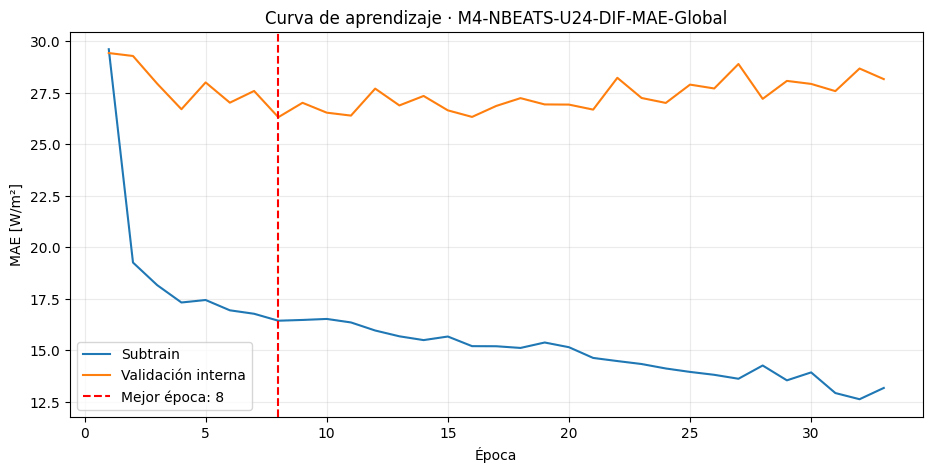

In [ ]:
plt.figure(figsize=(11, 5))
plt.plot(historial_nbeats["epoca"], historial_nbeats["MAE_train"], label="Subtrain")
plt.plot(
    historial_nbeats["epoca"],
    historial_nbeats["MAE_validacion_interna"],
    label="Validación interna",
)
plt.axvline(mejor_epoca, color="red", linestyle="--", label=f"Mejor época: {mejor_epoca}")
plt.xlabel("Época")
plt.ylabel("MAE [W/m²]")
plt.title("Curva de aprendizaje · M4-NBEATS-U24-DIF-MAE-Global")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

**Resultados.** El menor MAE de validación interna (26,3 W/m²) se alcanza en la época 8 y el entrenamiento se detiene en la época 33. A partir de la época 8, el MAE del subtrain sigue disminuyendo (13,93 W/m² en la época 30), mientras que el de la validación interna aumenta (27,93 W/m²), lo que indica sobreajuste.

### 4.8 Reajuste con todo el entrenamiento y evaluación

Se crea un modelo nuevo, se recalcula el escalado con todo el conjunto de entrenamiento y se entrena durante las 8 épocas seleccionadas, sin parada temprana. Después se predicen las horas de validación y se calculan las métricas en total, en operación y por régimen solar.

In [ ]:
media_DIF_train_completo = float(np.mean(y_train_nbeats))
std_DIF_train_completo = float(np.std(y_train_nbeats, ddof=0))
X_train_final_escalado = (X_train_nbeats - media_DIF_train_completo) / std_DIF_train_completo
y_train_final_escalado = (y_train_nbeats - media_DIF_train_completo) / std_DIF_train_completo
X_validation_final_escalado = (
    X_validation_nbeats - media_DIF_train_completo
) / std_DIF_train_completo
dataset_train_final = TensorDataset(
    torch.tensor(X_train_final_escalado, dtype=torch.float32),
    torch.tensor(y_train_final_escalado, dtype=torch.float32).reshape(-1, 1),
)
generador_final = torch.Generator()
generador_final.manual_seed(SEMILLA)
loader_train_final = DataLoader(
    dataset_train_final,
    batch_size=batch_size,
    shuffle=True,
    generator=generador_final,
    drop_last=False,
)
modelo_nbeats_final = crear_modelo_nbeats()
optimizador_final = torch.optim.Adam(modelo_nbeats_final.parameters(), lr=1e-3, weight_decay=1e-5)
for epoca in range(1, mejor_epoca + 1):
    modelo_nbeats_final.train()
    for X_lote, y_lote in loader_train_final:
        X_lote = X_lote.to(dispositivo)
        y_lote = y_lote.to(dispositivo)
        optimizador_final.zero_grad()
        prediccion = modelo_nbeats_final(X_lote)
        perdida = funcion_perdida(prediccion, y_lote)
        perdida.backward()
        torch.nn.utils.clip_grad_norm_(modelo_nbeats_final.parameters(), max_norm=1.0)
        optimizador_final.step()

    if epoca == 1 or epoca % 10 == 0:
        print(f"Reajuste final: época " f"{epoca}/{mejor_epoca}")

print("Reajuste final completado.")

Reajuste final: época 1/8
Reajuste final completado.


In [ ]:
modelo_nbeats_final.eval()
X_validation_tensor = torch.tensor(X_validation_final_escalado, dtype=torch.float32)
loader_prediccion = DataLoader(TensorDataset(X_validation_tensor), batch_size=256, shuffle=False)
predicciones_escaladas = []
with torch.no_grad():
    for (X_lote,) in loader_prediccion:
        X_lote = X_lote.to(dispositivo)
        pred_lote = modelo_nbeats_final(X_lote)
        predicciones_escaladas.append(pred_lote.cpu().numpy().reshape(-1))

predicciones_escaladas = np.concatenate(predicciones_escaladas)
pred_M4_NBEATS = predicciones_escaladas * std_DIF_train_completo + media_DIF_train_completo
nombre_modelo_nbeats = "M4-NBEATS-U24-DIF-MAE-Global"
resultados_validation_nbeats = meta_validation_nbeats.copy()
resultados_validation_nbeats["DIF_real"] = y_validation_nbeats
resultados_validation_nbeats[nombre_modelo_nbeats] = pred_M4_NBEATS
resultados_validation_nbeats["error"] = (
    resultados_validation_nbeats[nombre_modelo_nbeats] - resultados_validation_nbeats["DIF_real"]
)
resultados_validation_nbeats["error_absoluto"] = resultados_validation_nbeats["error"].abs()
print(
    resultados_validation_nbeats[
        ["instante_objetivo", "regimen_solar_objetivo", "DIF_real", nombre_modelo_nbeats, "error"]
    ].head()
)

          instante_objetivo regimen_solar_objetivo   DIF_real  \
0 2024-08-01 00:00:00+00:00                  noche  -1.000000   
1 2024-08-01 01:00:00+00:00                  noche  -1.000000   
2 2024-08-01 02:00:00+00:00                  noche  -1.000000   
3 2024-08-01 03:00:00+00:00                  noche   0.400000   
4 2024-08-01 04:00:00+00:00             transicion  28.799999   

   M4-NBEATS-U24-DIF-MAE-Global     error  
0                      0.332359  1.332359  
1                      2.700928  3.700928  
2                      0.628242  1.628242  
3                      5.544312  5.144311  
4                     31.430965  2.630966  


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def mascara_regimen(df, regimen):
    serie = df["regimen_solar_objetivo"].astype(str)
    if regimen == "total":
        return np.ones(len(df), dtype=bool)

    if regimen == "operacional":
        return serie.isin(["completamente_diurna", "transicion"]).to_numpy()

    return (serie == regimen).to_numpy()

def metricas_modelo(y_real, y_pred, modelo, regimen):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    errores = y_pred - y_real
    errores_absolutos = np.abs(errores)
    mae = np.mean(errores_absolutos)
    media_real = np.mean(y_real)
    return {
        "modelo": modelo,
        "regimen": regimen,
        "n": len(y_real),
        "media_DIF_real": media_real,
        "mediana_DIF_real": np.median(y_real),
        "MAE": mae,
        "nMAE_pct": (100 * mae / media_real if media_real != 0 else np.nan),
        "RMSE": np.sqrt(np.mean(errores**2)),
        "sesgo": np.mean(errores),
        "R2": (r2_score(y_real, y_pred) if len(y_real) > 1 else np.nan),
        "p95_error_absoluto": np.quantile(errores_absolutos, 0.95),
        "p99_error_absoluto": np.quantile(errores_absolutos, 0.99),
    }

regimenes = ["total", "operacional", "completamente_diurna", "transicion", "noche"]
filas_metricas = []
for regimen in regimenes:
    mascara = mascara_regimen(resultados_validation_nbeats, regimen)
    filas_metricas.append(
        metricas_modelo(
            resultados_validation_nbeats.loc[mascara, "DIF_real"],
            resultados_validation_nbeats.loc[mascara, nombre_modelo_nbeats],
            nombre_modelo_nbeats,
            regimen,
        )
    )

metricas_M4_NBEATS = pd.DataFrame(filas_metricas)
display(metricas_M4_NBEATS.round(4))

,modelo,regimen,n,media_DIF_real,mediana_DIF_real,MAE,nMAE_pct,RMSE,sesgo,R2,p95_error_absoluto,p99_error_absoluto
0,M4-NBEATS-U24-DIF-MAE-Global,total,1464,85.2333,30.5917,18.7116,21.9534,34.1018,2.8730,0.9005,71.1930,130.3875
1,M4-NBEATS-U24-DIF-MAE-Global,operacional,884,141.7976,127.7333,29.2961,20.6605,43.7932,3.0939,0.8300,97.5571,154.5432
2,M4-NBEATS-U24-DIF-MAE-Global,completamente_diurna,765,162.7231,145.6833,32.5305,19.9913,46.8920,2.3126,0.7751,99.7992,161.0472
3,M4-NBEATS-U24-DIF-MAE-Global,transicion,119,7.2764,4.8500,8.5037,116.8672,10.5500,8.1166,-1.2140,22.1078,31.0751
4,M4-NBEATS-U24-DIF-MAE-Global,noche,580,-0.9785,-1.0000,2.5793,-263.6005,3.5128,2.5362,-121.6166,6.0826,14.3615


**Resultados.** En validación, `M4-NBEATS-U24-DIF-MAE-Global` obtiene un MAE total de 18,71 W/m² (R² = 0,90) y de 29,30 W/m² en operación (884 horas).

- Horas completamente diurnas: MAE de 32,53 W/m².
- Transición: MAE de 8,50 W/m² y R² negativo (−1,21).
- Noche: MAE de 2,58 W/m², con una DIF real media de −0,98 W/m².
- El sesgo es positivo en todos los regímenes (+2,31 W/m² en horas completamente diurnas y +8,12 W/m² en transición), es decir, el modelo tiende a sobreestimar la DIF.

### 4.9 Comparación del HGB y la N-BEATS

Se comparan de forma pareada, sobre las mismas 1.464 horas de validación, el HGB de 9 variables con pérdida absoluta (`M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global`) y la N-BEATS univariante. Además de las métricas por régimen, se calcula el porcentaje de horas en que cada modelo tiene menor error absoluto.

In [ ]:
nombre_HGB = "M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global"
nombre_NBEATS = "M4-NBEATS-U24-DIF-MAE-Global"
if "predicciones_validation" not in globals():
    raise NameError(
        "No existe predicciones_validation. Debe proceder del experimento HGB DIR/SWD."
    )

if nombre_HGB not in predicciones_validation.columns:
    print("Columnas disponibles:")
    print(predicciones_validation.columns.tolist())
    raise KeyError(f"No se encuentra la predicción de {nombre_HGB}")

# Datos de N-BEATS
comparacion_nbeats = resultados_validation_nbeats[
    ["instante_objetivo", "regimen_solar_objetivo", "DIF_real", nombre_NBEATS]
].copy()

# Datos de HGB
comparacion_hgb = predicciones_validation[["instante_objetivo", nombre_HGB]].copy()
comparacion_nbeats["instante_objetivo"] = pd.to_datetime(
    comparacion_nbeats["instante_objetivo"], utc=True
)
comparacion_hgb["instante_objetivo"] = pd.to_datetime(
    comparacion_hgb["instante_objetivo"], utc=True
)
comparacion_modelos = comparacion_nbeats.merge(
    comparacion_hgb, on="instante_objetivo", how="inner", validate="one_to_one"
)
if len(comparacion_modelos) != 1464:
    raise ValueError(
        "La comparación no conserva las 1.464 horas "
        f"de validation: quedan {len(comparacion_modelos)}."
    )

comparacion_modelos = comparacion_modelos.sort_values("instante_objetivo").reset_index(drop=True)

# Errores firmados
comparacion_modelos["error_HGB"] = comparacion_modelos[nombre_HGB] - comparacion_modelos["DIF_real"]
comparacion_modelos["error_NBEATS"] = (
    comparacion_modelos[nombre_NBEATS] - comparacion_modelos["DIF_real"]
)

# Errores absolutos
comparacion_modelos["error_abs_HGB"] = comparacion_modelos["error_HGB"].abs()
comparacion_modelos["error_abs_NBEATS"] = comparacion_modelos["error_NBEATS"].abs()

# Diferencia positiva = N-BEATS mejora
comparacion_modelos["ventaja_NBEATS"] = (
    comparacion_modelos["error_abs_HGB"] - comparacion_modelos["error_abs_NBEATS"]
)
print("COMPROBACIÓN")
print(f"Horas comparadas: {len(comparacion_modelos):,}")
print("Primera hora:", comparacion_modelos["instante_objetivo"].min())
print("Última hora:", comparacion_modelos["instante_objetivo"].max())
display(comparacion_modelos.head())

COMPROBACIÓN
Horas comparadas: 1,464
Primera hora: 2024-08-01 00:00:00+00:00
Última hora: 2024-09-30 23:00:00+00:00


,instante_objetivo,regimen_solar_objetivo,DIF_real,M4-NBEATS-U24-DIF-MAE-Global,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global,error_HGB,error_NBEATS,error_abs_HGB,error_abs_NBEATS,ventaja_NBEATS
0,2024-08-01 00:00:00+00:00,noche,-1.000000,0.332359,-0.998188,0.001812,1.332359,0.001812,1.332359,-1.330547
1,2024-08-01 01:00:00+00:00,noche,-1.000000,2.700928,-0.998188,0.001812,3.700928,0.001812,3.700928,-3.699116
2,2024-08-01 02:00:00+00:00,noche,-1.000000,0.628242,-0.998188,0.001812,1.628242,0.001812,1.628242,-1.626431
3,2024-08-01 03:00:00+00:00,noche,0.400000,5.544312,-0.064409,-0.464409,5.144311,0.464409,5.144311,-4.679902
4,2024-08-01 04:00:00+00:00,transicion,28.799999,31.430965,18.037250,-10.762749,2.630966,10.762749,2.630966,8.131783


In [ ]:
from sklearn.metrics import r2_score

def obtener_mascara_comparacion(df, regimen):
    serie = df["regimen_solar_objetivo"].astype(str)
    if regimen == "total":
        return np.ones(len(df), dtype=bool)

    if regimen == "operacional":
        return serie.isin(["completamente_diurna", "transicion"]).to_numpy()

    return (serie == regimen).to_numpy()

def calcular_metricas_comparables(df, columna_prediccion, nombre_modelo, regimen):
    mascara = obtener_mascara_comparacion(df, regimen)
    y_real = df.loc[mascara, "DIF_real"].to_numpy(dtype=float)
    y_pred = df.loc[mascara, columna_prediccion].to_numpy(dtype=float)
    errores = y_pred - y_real
    errores_absolutos = np.abs(errores)
    mae = np.mean(errores_absolutos)
    media_real = np.mean(y_real)
    return {
        "modelo": nombre_modelo,
        "regimen": regimen,
        "n": len(y_real),
        "media_DIF_real": media_real,
        "mediana_DIF_real": np.median(y_real),
        "MAE": mae,
        "nMAE_pct": (100 * mae / media_real if media_real != 0 else np.nan),
        "RMSE": np.sqrt(np.mean(errores**2)),
        "sesgo": np.mean(errores),
        "R2": (r2_score(y_real, y_pred) if len(y_real) > 1 else np.nan),
        "p50_error_absoluto": np.quantile(errores_absolutos, 0.50),
        "p90_error_absoluto": np.quantile(errores_absolutos, 0.90),
        "p95_error_absoluto": np.quantile(errores_absolutos, 0.95),
        "p99_error_absoluto": np.quantile(errores_absolutos, 0.99),
    }

regimenes_comparacion = ["total", "operacional", "completamente_diurna", "transicion", "noche"]
filas = []
for regimen in regimenes_comparacion:
    filas.append(calcular_metricas_comparables(comparacion_modelos, nombre_HGB, "HGB-9V", regimen))
    filas.append(
        calcular_metricas_comparables(comparacion_modelos, nombre_NBEATS, "NBEATS-U24", regimen)
    )

metricas_HGB_NBEATS = pd.DataFrame(filas)
display(metricas_HGB_NBEATS.round(4))

,modelo,regimen,n,media_DIF_real,mediana_DIF_real,MAE,nMAE_pct,RMSE,sesgo,R2,p50_error_absoluto,p90_error_absoluto,p95_error_absoluto,p99_error_absoluto
0,HGB-9V,total,1464,85.2333,30.5917,16.5624,19.4319,33.0427,0.0420,0.9066,2.7840,49.4260,71.8006,125.8068
1,NBEATS-U24,total,1464,85.2333,30.5917,18.7116,21.9534,34.1018,2.8730,0.9005,6.3578,51.3909,71.1930,130.3875
2,HGB-9V,operacional,884,141.7976,127.7333,27.3534,19.2905,42.5220,0.0465,0.8397,16.4417,67.6866,90.2509,166.5698
3,NBEATS-U24,operacional,884,141.7976,127.7333,29.2961,20.6605,43.7932,3.0939,0.8300,18.3119,67.2293,97.5571,154.5432
4,HGB-9V,completamente_diurna,765,162.7231,145.6833,31.2125,19.1814,45.6836,-0.0729,0.7866,20.8235,70.6497,95.1998,167.7711
5,NBEATS-U24,completamente_diurna,765,162.7231,145.6833,32.5305,19.9913,46.8920,2.3126,0.7751,22.6151,70.7114,99.7992,161.0472
6,HGB-9V,transicion,119,7.2764,4.8500,2.5450,34.9759,3.9242,0.8143,0.6937,1.4840,7.4775,9.0572,11.9130
7,NBEATS-U24,transicion,119,7.2764,4.8500,8.5037,116.8672,10.5500,8.1166,-1.2140,7.1715,15.5684,22.1078,31.0751
8,HGB-9V,noche,580,-0.9785,-1.0000,0.1154,-11.7961,0.2919,0.0350,0.1531,0.0018,0.3583,0.6703,1.3263
9,NBEATS-U24,noche,580,-0.9785,-1.0000,2.5793,-263.6005,3.5128,2.5362,-121.6166,2.2086,4.3506,6.0826,14.3615


In [ ]:
tabla_HGB = metricas_HGB_NBEATS.query("modelo == 'HGB-9V'").set_index("regimen")
tabla_NBEATS = metricas_HGB_NBEATS.query("modelo == 'NBEATS-U24'").set_index("regimen")
comparacion_resumen = pd.DataFrame(
    {
        "n": tabla_HGB["n"],
        "media_DIF_real": tabla_HGB["media_DIF_real"],
        "MAE_HGB": tabla_HGB["MAE"],
        "MAE_NBEATS": tabla_NBEATS["MAE"],
        "mejora_MAE_NBEATS": tabla_HGB["MAE"] - tabla_NBEATS["MAE"],
        "mejora_pct_NBEATS": 100 * (tabla_HGB["MAE"] - tabla_NBEATS["MAE"]) / tabla_HGB["MAE"],
        "RMSE_HGB": tabla_HGB["RMSE"],
        "RMSE_NBEATS": tabla_NBEATS["RMSE"],
        "sesgo_HGB": tabla_HGB["sesgo"],
        "sesgo_NBEATS": tabla_NBEATS["sesgo"],
        "R2_HGB": tabla_HGB["R2"],
        "R2_NBEATS": tabla_NBEATS["R2"],
        "p95_HGB": tabla_HGB["p95_error_absoluto"],
        "p95_NBEATS": tabla_NBEATS["p95_error_absoluto"],
    }
)
comparacion_resumen = comparacion_resumen.loc[regimenes_comparacion].reset_index()
display(comparacion_resumen.round(4))

,regimen,n,media_DIF_real,MAE_HGB,MAE_NBEATS,mejora_MAE_NBEATS,mejora_pct_NBEATS,RMSE_HGB,RMSE_NBEATS,sesgo_HGB,sesgo_NBEATS,R2_HGB,R2_NBEATS,p95_HGB,p95_NBEATS
0,total,1464,85.2333,16.5624,18.7116,-2.1492,-12.9765,33.0427,34.1018,0.0420,2.8730,0.9066,0.9005,71.8006,71.1930
1,operacional,884,141.7976,27.3534,29.2961,-1.9427,-7.1024,42.5220,43.7932,0.0465,3.0939,0.8397,0.8300,90.2509,97.5571
2,completamente_diurna,765,162.7231,31.2125,32.5305,-1.3180,-4.2228,45.6836,46.8920,-0.0729,2.3126,0.7866,0.7751,95.1998,99.7992
3,transicion,119,7.2764,2.5450,8.5037,-5.9588,-234.1360,3.9242,10.5500,0.8143,8.1166,0.6937,-1.2140,9.0572,22.1078
4,noche,580,-0.9785,0.1154,2.5793,-2.4639,-2134.6460,0.2919,3.5128,0.0350,2.5362,0.1531,-121.6166,0.6703,6.0826


In [ ]:
filas_horas_ganadas = []
for regimen in regimenes_comparacion:
    mascara = obtener_mascara_comparacion(comparacion_modelos, regimen)
    datos = comparacion_modelos.loc[mascara]
    gana_HGB = datos["error_abs_HGB"] < datos["error_abs_NBEATS"]
    gana_NBEATS = datos["error_abs_NBEATS"] < datos["error_abs_HGB"]
    empate = datos["error_abs_NBEATS"] == datos["error_abs_HGB"]
    filas_horas_ganadas.append(
        {
            "regimen": regimen,
            "n": len(datos),
            "pct_horas_gana_HGB": 100 * gana_HGB.mean(),
            "pct_horas_gana_NBEATS": 100 * gana_NBEATS.mean(),
            "pct_empate": 100 * empate.mean(),
            "ventaja_media_NBEATS_Wm2": datos["ventaja_NBEATS"].mean(),
            "mediana_ventaja_NBEATS_Wm2": datos["ventaja_NBEATS"].median(),
        }
    )

tabla_horas_ganadas = pd.DataFrame(filas_horas_ganadas)
display(tabla_horas_ganadas.round(4))

,regimen,n,pct_horas_gana_HGB,pct_horas_gana_NBEATS,pct_empate,ventaja_media_NBEATS_Wm2,mediana_ventaja_NBEATS_Wm2
0,total,1464,75.0000,25.0000,0.0,-2.1492,-2.1921
1,operacional,884,59.5023,40.4977,0.0,-1.9427,-2.5703
2,completamente_diurna,765,54.6405,45.3595,0.0,-1.3180,-1.3450
3,transicion,119,90.7563,9.2437,0.0,-5.9588,-5.9445
4,noche,580,98.6207,1.3793,0.0,-2.4639,-2.1259


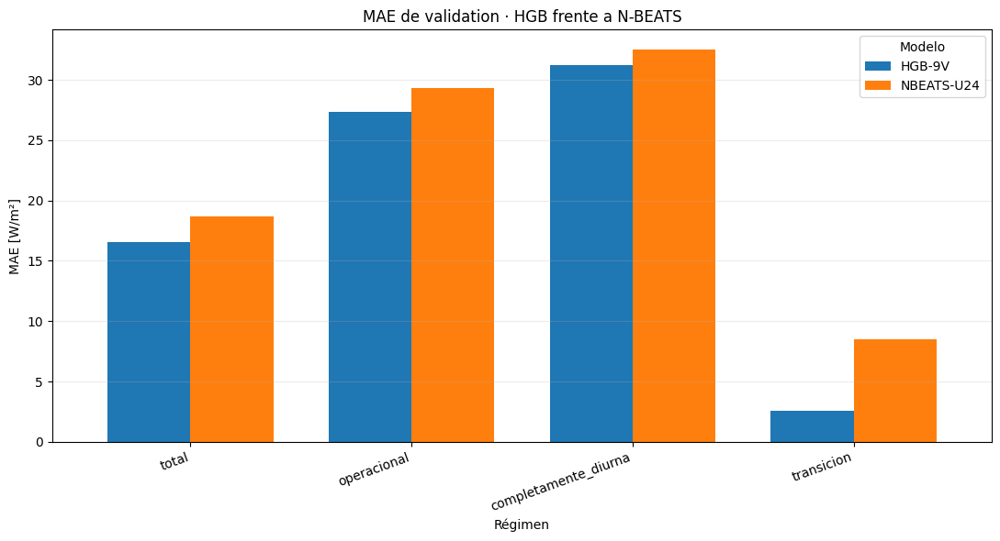

In [ ]:
orden_grafico = ["total", "operacional", "completamente_diurna", "transicion"]
datos_grafico = metricas_HGB_NBEATS[metricas_HGB_NBEATS["regimen"].isin(orden_grafico)].copy()
datos_grafico["regimen"] = pd.Categorical(
    datos_grafico["regimen"], categories=orden_grafico, ordered=True
)
datos_grafico = datos_grafico.sort_values(["regimen", "modelo"])
tabla_grafico = datos_grafico.pivot(index="regimen", columns="modelo", values="MAE").loc[
    orden_grafico
]
ax = tabla_grafico.plot(kind="bar", figsize=(11, 6), width=0.75)
ax.set_title("MAE de validation · HGB frente a N-BEATS")
ax.set_xlabel("Régimen")
ax.set_ylabel("MAE [W/m²]")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Modelo")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Resultados.** El HGB obtiene un MAE menor en todos los regímenes: 16,56 frente a 18,71 W/m² en total y 27,35 frente a 29,30 W/m² en operación.

- En horas completamente diurnas la diferencia es de 1,32 W/m² y la N-BEATS tiene menor error absoluto en el 45,36 % de las horas.
- En transición (2,54 frente a 8,50 W/m²) y en noche (0,12 frente a 2,58 W/m²) la diferencia es mucho mayor.
- En horas completamente diurnas, la N-BEATS presenta un p95 del error mayor (99,80 frente a 95,20 W/m²), pero un p99 menor (161,05 frente a 167,77 W/m²).

### 4.10 Diagnóstico de errores de la N-BEATS

Se analiza en qué situaciones se concentran los errores de la N-BEATS en validación según el mes, la hora, el régimen solar, la elevación, el nivel de DIF y la magnitud y el signo del cambio respecto a la hora anterior, con el HGB como referencia. Para ello se construye una tabla que reúne, para cada hora, las predicciones y los errores de ambos modelos junto con los retardos de la DIF.

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Recuperar retardos desde las ventanas de N-BEATS

# Orden de X:
# posición 0  = T-24
# posición 21 = T-3
# posición 22 = T-2
# posición 23 = T-1
historia_validation = pd.DataFrame(
    {
        "instante_objetivo": meta_validation_nbeats["instante_objetivo"],
        "DIF_lag1": X_validation_nbeats[:, 23, 0],
        "DIF_lag2": X_validation_nbeats[:, 22, 0],
        "DIF_lag3": X_validation_nbeats[:, 21, 0],
        "DIF_lag24": X_validation_nbeats[:, 0, 0],
    }
)
historia_validation["instante_objetivo"] = pd.to_datetime(
    historia_validation["instante_objetivo"], utc=True
)

# 2. Recuperar geometría solar del checkpoint
columnas_geometria_candidatas = [
    "instante_objetivo",
    "elevacion_media_objetivo",
    "elevacion_minima_objetivo",
    "elevacion_maxima_objetivo",
    "fraccion_minutos_dia_objetivo",
]
columnas_geometria_disponibles = [
    columna for columna in columnas_geometria_candidatas if columna in validation_hgb.columns
]
geometria_validation = validation_hgb[columnas_geometria_disponibles].copy()
geometria_validation["instante_objetivo"] = pd.to_datetime(
    geometria_validation["instante_objetivo"], utc=True
)
geometria_validation = geometria_validation.drop_duplicates("instante_objetivo")

# 3. Unir toda la información
diagnostico_nbeats = comparacion_modelos.merge(
    historia_validation, on="instante_objetivo", how="left", validate="one_to_one"
).merge(geometria_validation, on="instante_objetivo", how="left", validate="one_to_one")
if len(diagnostico_nbeats) != 1464:
    raise ValueError("La tabla de diagnóstico no conserva las 1.464 observaciones.")

# 4. Variables diagnósticas
diagnostico_nbeats["mes"] = diagnostico_nbeats["instante_objetivo"].dt.to_period("M").astype(str)
diagnostico_nbeats["fecha"] = diagnostico_nbeats["instante_objetivo"].dt.date
diagnostico_nbeats["hora"] = diagnostico_nbeats["instante_objetivo"].dt.hour

# Cambio realmente ocurrido entre la última hora conocida
# y la hora objetivo.
diagnostico_nbeats["cambio_DIF_real"] = (
    diagnostico_nbeats["DIF_real"] - diagnostico_nbeats["DIF_lag1"]
)
diagnostico_nbeats["magnitud_cambio_DIF"] = diagnostico_nbeats["cambio_DIF_real"].abs()
diagnostico_nbeats["cambio_DIF_previo"] = (
    diagnostico_nbeats["DIF_lag1"] - diagnostico_nbeats["DIF_lag2"]
)
diagnostico_nbeats["diferencia_diaria_real"] = (
    diagnostico_nbeats["DIF_real"] - diagnostico_nbeats["DIF_lag24"]
)
diagnostico_nbeats["direccion_cambio"] = np.select(
    [diagnostico_nbeats["cambio_DIF_real"] > 1, diagnostico_nbeats["cambio_DIF_real"] < -1],
    ["aumento", "descenso"],
    default="estable_±1",
)
diagnostico_nbeats["modelo_ganador"] = np.where(
    diagnostico_nbeats["error_abs_NBEATS"] < diagnostico_nbeats["error_abs_HGB"], "NBEATS", "HGB"
)

# Diferencia positiva: N-BEATS comete más error.
diagnostico_nbeats["exceso_error_NBEATS"] = (
    diagnostico_nbeats["error_abs_NBEATS"] - diagnostico_nbeats["error_abs_HGB"]
)
print("Tabla maestra construida:", diagnostico_nbeats.shape)
display(diagnostico_nbeats.head())

Tabla maestra construida: (1464, 28)


,instante_objetivo,regimen_solar_objetivo,DIF_real,M4-NBEATS-U24-DIF-MAE-Global,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global,error_HGB,error_NBEATS,error_abs_HGB,error_abs_NBEATS,ventaja_NBEATS,...,mes,fecha,hora,cambio_DIF_real,magnitud_cambio_DIF,cambio_DIF_previo,diferencia_diaria_real,direccion_cambio,modelo_ganador,exceso_error_NBEATS
0,2024-08-01 00:00:00+00:00,noche,-1.000000,0.332359,-0.998188,0.001812,1.332359,0.001812,1.332359,-1.330547,...,2024-08,2024-08-01,0,0.0,0.0,0.0,0.000000,estable_±1,HGB,1.330547
1,2024-08-01 01:00:00+00:00,noche,-1.000000,2.700928,-0.998188,0.001812,3.700928,0.001812,3.700928,-3.699116,...,2024-08,2024-08-01,1,0.0,0.0,0.0,0.000000,estable_±1,HGB,3.699116
2,2024-08-01 02:00:00+00:00,noche,-1.000000,0.628242,-0.998188,0.001812,1.628242,0.001812,1.628242,-1.626431,...,2024-08,2024-08-01,2,0.0,0.0,0.0,0.000000,estable_±1,HGB,1.626431
3,2024-08-01 03:00:00+00:00,noche,0.400000,5.544312,-0.064409,-0.464409,5.144311,0.464409,5.144311,-4.679902,...,2024-08,2024-08-01,3,1.4,1.4,0.0,0.300000,aumento,HGB,4.679902
4,2024-08-01 04:00:00+00:00,transicion,28.799999,31.430965,18.037250,-10.762749,2.630966,10.762749,2.630966,8.131783,...,2024-08,2024-08-01,4,28.4,28.4,1.4,9.166666,aumento,NBEATS,-8.131783


### 4.11 Error por mes, régimen, hora y elevación

Para cada grupo se resumen el MAE, el RMSE, el sesgo y el p95 del error de la N-BEATS, junto con el MAE del HGB y el porcentaje de horas en que la N-BEATS tiene menor error absoluto.

In [ ]:
def resumir_errores_por_grupo(df, columna_grupo):
    filas = []
    for valor_grupo, datos in df.groupby(columna_grupo, observed=True, sort=True):
        error_nbeats = datos["error_NBEATS"].to_numpy()
        error_hgb = datos["error_HGB"].to_numpy()
        abs_nbeats = np.abs(error_nbeats)
        abs_hgb = np.abs(error_hgb)
        filas.append(
            {
                columna_grupo: valor_grupo,
                "n": len(datos),
                "media_DIF_real": datos["DIF_real"].mean(),
                "mediana_DIF_real": datos["DIF_real"].median(),
                "MAE_NBEATS": abs_nbeats.mean(),
                "RMSE_NBEATS": np.sqrt(np.mean(error_nbeats**2)),
                "sesgo_NBEATS": error_nbeats.mean(),
                "p95_NBEATS": np.quantile(abs_nbeats, 0.95),
                "MAE_HGB": abs_hgb.mean(),
                "diferencia_MAE_NBEATS_menos_HGB": abs_nbeats.mean() - abs_hgb.mean(),
                "pct_horas_gana_NBEATS": 100 * np.mean(abs_nbeats < abs_hgb),
                "magnitud_media_cambio_DIF": datos["magnitud_cambio_DIF"].mean(),
            }
        )

    return pd.DataFrame(filas)

In [ ]:
tabla_error_mes = resumir_errores_por_grupo(diagnostico_nbeats, "mes")
tabla_error_hora = resumir_errores_por_grupo(diagnostico_nbeats, "hora")
tabla_error_regimen = resumir_errores_por_grupo(diagnostico_nbeats, "regimen_solar_objetivo")
print("ERROR POR MES")
display(tabla_error_mes.round(4))
print("\nERROR POR RÉGIMEN SOLAR")
display(tabla_error_regimen.round(4))
print("\nERROR POR HORA")
display(tabla_error_hora.round(4))

ERROR POR MES


,mes,n,media_DIF_real,mediana_DIF_real,MAE_NBEATS,RMSE_NBEATS,sesgo_NBEATS,p95_NBEATS,MAE_HGB,diferencia_MAE_NBEATS_menos_HGB,pct_horas_gana_NBEATS,magnitud_media_cambio_DIF
0,2024-08,744,99.521896,53.3667,21.0228,38.0746,2.3404,78.162102,18.8258,2.1971,26.8817,30.852800
1,2024-09,720,70.468300,11.1167,16.3234,29.4384,3.4233,64.961700,14.2236,2.0998,23.0556,24.169701



ERROR POR RÉGIMEN SOLAR


,regimen_solar_objetivo,n,media_DIF_real,mediana_DIF_real,MAE_NBEATS,RMSE_NBEATS,sesgo_NBEATS,p95_NBEATS,MAE_HGB,diferencia_MAE_NBEATS_menos_HGB,pct_horas_gana_NBEATS,magnitud_media_cambio_DIF
0,completamente_diurna,765,162.723099,145.6833,32.530499,46.891998,2.3126,99.799202,31.2125,1.3180,45.3595,48.3363
1,noche,580,-0.978500,-1.0000,2.579300,3.512800,2.5362,6.082600,0.1154,2.4639,1.3793,0.9449
2,transicion,119,7.276400,4.8500,8.503700,10.550000,8.1166,22.107800,2.5450,5.9588,9.2437,23.7936



ERROR POR HORA


,hora,n,media_DIF_real,mediana_DIF_real,MAE_NBEATS,RMSE_NBEATS,sesgo_NBEATS,p95_NBEATS,MAE_HGB,diferencia_MAE_NBEATS_menos_HGB,pct_horas_gana_NBEATS,magnitud_media_cambio_DIF
0,0,61,-1.015800,-1.0000,2.377900,2.513700,2.3050,3.623600,0.1295,2.2484,0.0000,0.113900
1,1,61,-1.043200,-1.0000,2.448300,2.674000,2.4483,4.815800,0.1326,2.3157,1.6393,0.107700
2,2,61,-1.024300,-1.0000,1.903400,2.286800,1.8658,4.152300,0.1262,1.7772,3.2787,0.093700
3,3,61,-0.935200,-1.0000,4.570100,5.746200,4.5510,11.728400,0.1607,4.4094,0.0000,0.130600
4,4,61,3.142600,0.2167,8.680800,9.941700,8.4785,17.998100,1.4103,7.2705,1.6393,4.111200
5,5,61,29.671301,24.1833,11.360700,14.369300,4.2175,28.716801,8.8302,2.5305,34.4262,26.528700
6,6,61,75.251198,69.0167,18.381001,23.910000,2.9269,44.128399,15.5062,2.8748,47.5410,45.579899
7,7,61,136.571503,127.6500,30.859900,39.611500,-6.9085,83.441200,30.5733,0.2866,42.6230,61.347599
8,8,61,189.492004,187.3667,35.826302,44.478699,-4.3019,77.582298,37.1200,-1.2937,52.4590,55.945000
9,9,61,218.794907,210.5593,37.769600,49.090900,1.5127,97.478897,37.1957,0.5740,42.6230,42.513199


In [ ]:
if "elevacion_media_objetivo" in diagnostico_nbeats.columns:
    limites_elevacion = [-np.inf, 0, 10, 20, 30, 40, np.inf]
    etiquetas_elevacion = ["<0°", "0–10°", "10–20°", "20–30°", "30–40°", "≥40°"]
    diagnostico_nbeats["banda_elevacion"] = pd.cut(
        diagnostico_nbeats["elevacion_media_objetivo"],
        bins=limites_elevacion,
        labels=etiquetas_elevacion,
        right=False,
    )
    tabla_error_elevacion = resumir_errores_por_grupo(diagnostico_nbeats, "banda_elevacion")
    display(tabla_error_elevacion.round(4))

else:
    tabla_error_elevacion = pd.DataFrame()
    print("No se encontró elevacion_media_objetivo.")

,banda_elevacion,n,media_DIF_real,mediana_DIF_real,MAE_NBEATS,RMSE_NBEATS,sesgo_NBEATS,p95_NBEATS,MAE_HGB,diferencia_MAE_NBEATS_menos_HGB,pct_horas_gana_NBEATS,magnitud_media_cambio_DIF
0,<0°,644,-0.645900,-1.0000,3.097500,4.408500,3.0466,9.429500,0.2400,2.8574,1.3975,2.872900
1,0–10°,138,28.341600,24.5417,9.953100,12.848900,4.6473,27.231800,7.2945,2.6586,35.5072,36.066799
2,10–20°,137,81.362999,79.3833,20.189100,25.294100,2.4696,46.955299,16.7083,3.4808,37.2263,46.216000
3,20–30°,147,143.267700,140.3833,32.151901,41.818298,2.2658,83.988297,32.8045,-0.6526,49.6599,58.222900
4,30–40°,193,195.163803,192.1667,36.247799,47.899899,5.7695,105.114098,34.9633,1.2845,45.5959,44.672501
5,≥40°,205,250.793396,243.4500,46.524200,65.507004,-0.8890,136.711105,45.0094,1.5148,46.8293,48.864498


**Resultados.** Ambos modelos muestran errores mayores en agosto y a mayor elevación solar.

- Agosto: MAE de la N-BEATS de 21,02 W/m² (16,32 W/m² en septiembre), con mayor magnitud media del cambio horario (30,85 frente a 24,17 W/m²).
- Por encima de 40° de elevación, el MAE llega a 46,52 W/m² (N-BEATS) y 45,01 W/m² (HGB).
- La desventaja de la N-BEATS es mayor por debajo de 20° (diferencias de 2,86, 2,66 y 3,48 W/m² en las tres primeras bandas) y, en términos relativos, con el sol bajo el horizonte (3,10 frente a 0,24 W/m²).
- Entre 20° y 30°, la N-BEATS obtiene un MAE algo menor que el HGB (32,15 frente a 32,80 W/m²).

### 4.12 Error según el nivel y la dinámica de la DIF

En las horas de operación se agrupan los errores por quintiles del nivel real de la DIF, por quintiles de la magnitud del cambio respecto a la hora anterior y por dirección del cambio. Además, se examinan los episodios en que el error absoluto de la N-BEATS supera su percentil 95.

In [ ]:
mascara_operacional = diagnostico_nbeats["regimen_solar_objetivo"].isin(
    ["completamente_diurna", "transicion"]
)
diagnostico_operacional = diagnostico_nbeats.loc[mascara_operacional].copy()
diagnostico_operacional["quintil_DIF_real"] = pd.qcut(
    diagnostico_operacional["DIF_real"], q=5, duplicates="drop"
)
diagnostico_operacional["quintil_magnitud_cambio"] = pd.qcut(
    diagnostico_operacional["magnitud_cambio_DIF"], q=5, duplicates="drop"
)
tabla_error_quintil_DIF = resumir_errores_por_grupo(diagnostico_operacional, "quintil_DIF_real")
tabla_error_quintil_cambio = resumir_errores_por_grupo(
    diagnostico_operacional, "quintil_magnitud_cambio"
)
tabla_error_direccion = resumir_errores_por_grupo(diagnostico_operacional, "direccion_cambio")
print("ERROR POR QUINTIL DE DIF REAL")
display(tabla_error_quintil_DIF.round(4))
print("\nERROR POR QUINTIL DE MAGNITUD DEL CAMBIO")
display(tabla_error_quintil_cambio.round(4))
print("\nERROR POR DIRECCIÓN DEL CAMBIO")
display(tabla_error_direccion.round(4))

ERROR POR QUINTIL DE DIF REAL


,quintil_DIF_real,n,media_DIF_real,mediana_DIF_real,MAE_NBEATS,RMSE_NBEATS,sesgo_NBEATS,p95_NBEATS,MAE_HGB,diferencia_MAE_NBEATS_menos_HGB,pct_horas_gana_NBEATS,magnitud_media_cambio_DIF
0,"(-1.0679999999999998, 41.877]",177,13.846600,10.4000,10.454300,15.366700,9.0363,29.379200,5.8676,4.5867,20.3390,28.356501
1,"(41.877, 95.38]",177,69.787598,70.9833,23.266701,33.256401,14.1810,69.289398,19.8975,3.3692,39.5480,41.856098
2,"(95.38, 152.627]",176,126.435898,127.7333,32.347198,49.198299,16.7644,101.352798,30.6698,1.6774,42.6136,47.077099
3,"(152.627, 232.883]",177,190.673492,188.8333,32.208401,41.014301,3.9927,83.872101,32.2934,-0.0850,50.8475,47.254501
4,"(232.883, 507.1]",177,308.157501,290.9167,48.221401,64.399399,-28.4275,129.479095,48.0575,0.1639,49.1525,60.629601



ERROR POR QUINTIL DE MAGNITUD DEL CAMBIO


,quintil_magnitud_cambio,n,media_DIF_real,mediana_DIF_real,MAE_NBEATS,RMSE_NBEATS,sesgo_NBEATS,p95_NBEATS,MAE_HGB,diferencia_MAE_NBEATS_menos_HGB,pct_horas_gana_NBEATS,magnitud_media_cambio_DIF
0,"(0.099, 12.343]",177,117.300697,112.2667,18.295200,23.953899,6.7916,51.715099,14.1153,4.1799,31.0734,5.587300
1,"(12.343, 28.407]",177,128.702194,105.4167,21.612200,27.814600,8.3628,54.812801,17.1132,4.4990,34.4633,20.435900
2,"(28.407, 44.61]",176,122.477798,99.3833,18.353901,26.159599,3.1988,61.112801,16.9516,1.4023,42.0455,36.590599
3,"(44.61, 68.99]",177,144.171707,126.1333,21.637100,29.690001,-1.3326,63.358398,22.8187,-1.1816,48.5876,55.230598
4,"(68.99, 301.133]",177,196.226303,180.3500,66.520500,81.663803,-1.5504,154.700302,65.7094,0.8111,46.3277,107.270203



ERROR POR DIRECCIÓN DEL CAMBIO


,direccion_cambio,n,media_DIF_real,mediana_DIF_real,MAE_NBEATS,RMSE_NBEATS,sesgo_NBEATS,p95_NBEATS,MAE_HGB,diferencia_MAE_NBEATS_menos_HGB,pct_horas_gana_NBEATS,magnitud_media_cambio_DIF
0,aumento,467,156.737503,143.4167,29.396400,43.281799,-14.6473,97.701698,27.4500,1.9464,40.2570,43.132999
1,descenso,397,124.567299,112.0000,29.381800,44.853600,24.0271,97.972900,27.6879,1.6939,41.0579,49.509399
2,estable_±1,20,134.970795,121.3417,25.255699,33.038502,1.8271,57.539398,18.4583,6.7974,35.0000,0.517500


In [ ]:
umbral_p95_nbeats = diagnostico_nbeats["error_abs_NBEATS"].quantile(0.95)
diagnostico_nbeats["extremo_NBEATS_p95"] = (
    diagnostico_nbeats["error_abs_NBEATS"] >= umbral_p95_nbeats
)
columnas_extremos = [
    "instante_objetivo",
    "mes",
    "hora",
    "regimen_solar_objetivo",
    "elevacion_media_objetivo",
    "DIF_real",
    nombre_NBEATS,
    nombre_HGB,
    "error_NBEATS",
    "error_HGB",
    "error_abs_NBEATS",
    "error_abs_HGB",
    "DIF_lag1",
    "DIF_lag2",
    "DIF_lag3",
    "DIF_lag24",
    "cambio_DIF_real",
    "magnitud_cambio_DIF",
    "diferencia_diaria_real",
    "modelo_ganador",
]
columnas_extremos = [
    columna for columna in columnas_extremos if columna in diagnostico_nbeats.columns
]
episodios_extremos_nbeats = (
    diagnostico_nbeats.loc[diagnostico_nbeats["extremo_NBEATS_p95"], columnas_extremos]
    .sort_values("error_abs_NBEATS", ascending=False)
    .reset_index(drop=True)
)
top30_errores_nbeats = episodios_extremos_nbeats.head(30).copy()
print(f"Umbral p95 N-BEATS: " f"{umbral_p95_nbeats:.3f} W/m²")
print(f"Número de episodios extremos: " f"{len(episodios_extremos_nbeats)}")
display(top30_errores_nbeats.round(4))

Umbral p95 N-BEATS: 71.193 W/m²
Número de episodios extremos: 74


,instante_objetivo,mes,hora,regimen_solar_objetivo,elevacion_media_objetivo,DIF_real,M4-NBEATS-U24-DIF-MAE-Global,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global,error_NBEATS,error_HGB,error_abs_NBEATS,error_abs_HGB,DIF_lag1,DIF_lag2,DIF_lag3,DIF_lag24,cambio_DIF_real,magnitud_cambio_DIF,diferencia_diaria_real,modelo_ganador
0,2024-08-20 13:00:00+00:00,2024-08,13,completamente_diurna,44.7413,147.550003,408.678802,370.3025,261.128815,222.7525,261.128815,222.7525,448.683289,383.066711,369.316711,282.816711,-301.133301,301.133301,-135.266693,HGB
1,2024-08-10 12:00:00+00:00,2024-08,12,completamente_diurna,52.1833,129.716705,361.414001,368.0100,231.697403,238.2933,231.697403,238.2933,392.316711,130.649994,270.783295,304.616699,-262.600006,262.600006,-174.899994,NBEATS
2,2024-08-10 11:00:00+00:00,2024-08,11,completamente_diurna,53.0738,392.316711,169.453506,164.4435,-222.863205,-227.8732,222.863205,227.8732,130.649994,270.783295,286.000000,374.466705,261.666687,261.666687,17.850000,NBEATS
3,2024-08-10 14:00:00+00:00,2024-08,14,completamente_diurna,40.9863,401.866699,186.975006,223.4221,-214.891602,-178.4445,214.891602,178.4445,194.566696,129.716705,392.316711,142.183304,207.300003,207.300003,259.683411,HGB
4,2024-08-03 13:00:00+00:00,2024-08,13,completamente_diurna,49.7030,455.700012,247.328796,242.8772,-208.371201,-212.8228,208.371201,212.8228,255.216599,424.983398,418.016693,318.733307,200.483398,200.483398,136.966705,NBEATS
5,2024-08-02 11:00:00+00:00,2024-08,11,completamente_diurna,55.2699,507.100006,312.789795,321.3764,-194.310196,-185.7236,194.310196,185.7236,321.816711,332.799988,220.750000,358.850006,185.283295,185.283295,148.250000,HGB
6,2024-09-10 11:00:00+00:00,2024-09,11,completamente_diurna,42.5291,87.050003,253.655197,264.1456,166.605194,177.0956,166.605194,177.0956,253.600006,183.733307,264.149994,208.316696,-166.550003,166.550003,-121.266701,NBEATS
7,2024-09-07 11:00:00+00:00,2024-09,11,completamente_diurna,43.6512,140.050003,304.932404,306.3792,164.882401,166.3292,164.882401,166.3292,317.183289,291.399994,258.483307,247.100006,-177.133301,177.133301,-107.050003,NBEATS
8,2024-09-03 14:00:00+00:00,2024-09,14,completamente_diurna,33.2967,290.200012,131.310104,122.4555,-158.889999,-167.7445,158.889999,167.7445,130.300003,268.192993,269.500000,184.316696,159.899994,159.899994,105.883400,NBEATS
9,2024-08-10 10:00:00+00:00,2024-08,10,completamente_diurna,50.2502,130.649994,284.303009,283.6976,153.653000,153.0476,153.653000,153.0476,270.783295,286.000000,156.433304,312.203400,-140.133301,140.133301,-181.553406,HGB


In [ ]:
tabla_extremos_regimen = resumir_errores_por_grupo(
    diagnostico_nbeats.loc[diagnostico_nbeats["extremo_NBEATS_p95"]], "regimen_solar_objetivo"
)
tabla_extremos_mes = resumir_errores_por_grupo(
    diagnostico_nbeats.loc[diagnostico_nbeats["extremo_NBEATS_p95"]], "mes"
)
tabla_extremos_direccion = resumir_errores_por_grupo(
    diagnostico_nbeats.loc[diagnostico_nbeats["extremo_NBEATS_p95"]], "direccion_cambio"
)
print("EXTREMOS POR RÉGIMEN")
display(tabla_extremos_regimen.round(4))
print("\nEXTREMOS POR MES")
display(tabla_extremos_mes.round(4))
print("\nEXTREMOS POR DIRECCIÓN DEL CAMBIO")
display(tabla_extremos_direccion.round(4))

EXTREMOS POR RÉGIMEN


,regimen_solar_objetivo,n,media_DIF_real,mediana_DIF_real,MAE_NBEATS,RMSE_NBEATS,sesgo_NBEATS,p95_NBEATS,MAE_HGB,diferencia_MAE_NBEATS_menos_HGB,pct_horas_gana_NBEATS,magnitud_media_cambio_DIF
0,completamente_diurna,74,241.000397,229.4333,112.397598,119.509201,4.4265,210.653305,104.0524,8.3453,32.4324,121.5737



EXTREMOS POR MES


,mes,n,media_DIF_real,mediana_DIF_real,MAE_NBEATS,RMSE_NBEATS,sesgo_NBEATS,p95_NBEATS,MAE_HGB,diferencia_MAE_NBEATS_menos_HGB,pct_horas_gana_NBEATS,magnitud_media_cambio_DIF
0,2024-08,48,265.151001,278.6667,114.692703,123.656502,-14.358600,220.073105,109.2417,5.4511,35.4167,129.200699
1,2024-09,26,196.414795,181.7833,108.160599,111.447998,39.106499,163.384293,94.4721,13.6884,26.9231,107.493202



EXTREMOS POR DIRECCIÓN DEL CAMBIO


,direccion_cambio,n,media_DIF_real,mediana_DIF_real,MAE_NBEATS,RMSE_NBEATS,sesgo_NBEATS,p95_NBEATS,MAE_HGB,diferencia_MAE_NBEATS_menos_HGB,pct_horas_gana_NBEATS,magnitud_media_cambio_DIF
0,aumento,35,334.706604,340.5500,116.357597,122.879402,-111.924301,210.327301,108.3151,8.0425,34.2857,120.464699
1,descenso,39,156.905106,144.7321,108.843803,116.401604,108.843803,173.114395,100.2268,8.6170,30.7692,122.569000


In [ ]:
carpeta_figuras_nbeats = Path("/content/figuras_diagnostico_nbeats")
carpeta_figuras_nbeats.mkdir(parents=True, exist_ok=True)
print(carpeta_figuras_nbeats)

/content/figuras_diagnostico_nbeats


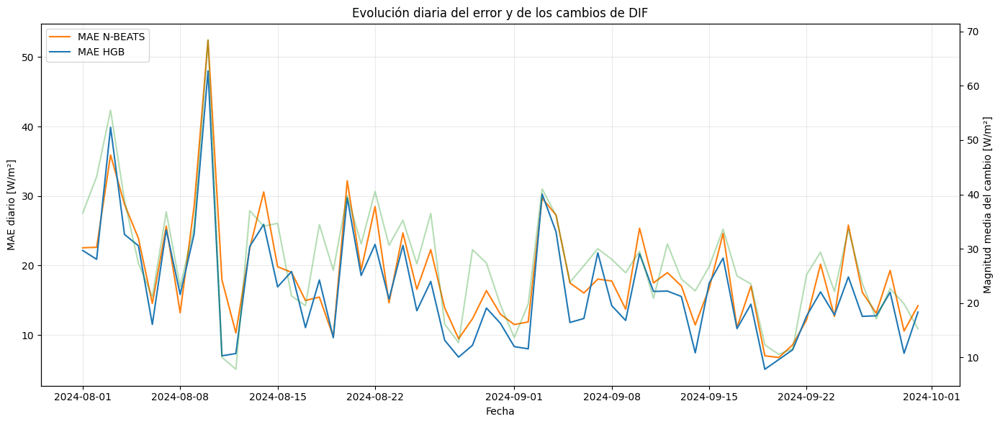

In [ ]:
error_diario = diagnostico_nbeats.groupby("fecha", as_index=False).agg(
    MAE_NBEATS=("error_abs_NBEATS", "mean"),
    MAE_HGB=("error_abs_HGB", "mean"),
    magnitud_media_cambio=("magnitud_cambio_DIF", "mean"),
)
error_diario["fecha"] = pd.to_datetime(error_diario["fecha"])
fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.plot(error_diario["fecha"], error_diario["MAE_NBEATS"], label="MAE N-BEATS", color="tab:orange")
ax1.plot(error_diario["fecha"], error_diario["MAE_HGB"], label="MAE HGB", color="tab:blue")
ax1.set_ylabel("MAE diario [W/m²]")
ax1.set_xlabel("Fecha")
ax1.grid(alpha=0.25)
ax1.legend(loc="upper left")
ax2 = ax1.twinx()
ax2.plot(
    error_diario["fecha"],
    error_diario["magnitud_media_cambio"],
    label="Cambio medio de DIF",
    color="tab:green",
    alpha=0.35,
)
ax2.set_ylabel("Magnitud media del cambio [W/m²]")
plt.title("Evolución diaria del error y de los cambios de DIF")
fig.tight_layout()
ruta_figura = carpeta_figuras_nbeats / "01_MAE_diario_HGB_NBEATS.png"
plt.savefig(ruta_figura, dpi=180, bbox_inches="tight")
plt.show()

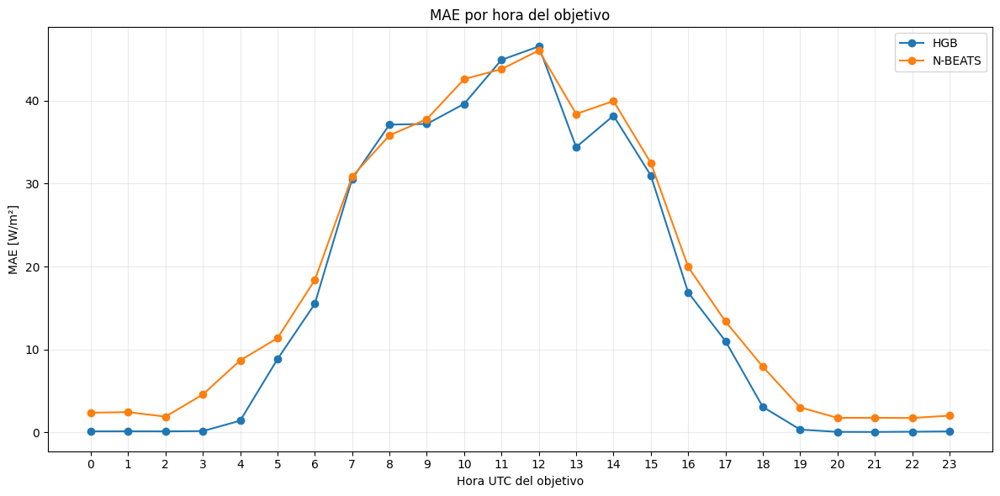

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(tabla_error_hora["hora"], tabla_error_hora["MAE_HGB"], marker="o", label="HGB")
ax.plot(tabla_error_hora["hora"], tabla_error_hora["MAE_NBEATS"], marker="o", label="N-BEATS")
ax.set_xlabel("Hora UTC del objetivo")
ax.set_ylabel("MAE [W/m²]")
ax.set_title("MAE por hora del objetivo")
ax.set_xticks(range(24))
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(carpeta_figuras_nbeats / "02_MAE_por_hora.png", dpi=180, bbox_inches="tight")
plt.show()

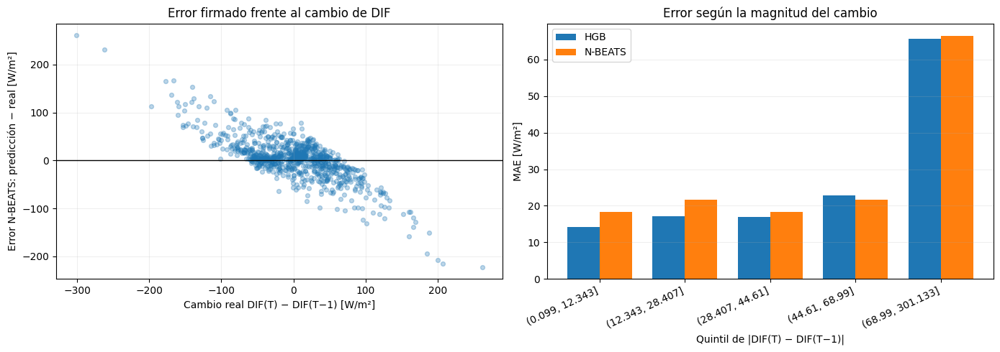

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(
    diagnostico_operacional["cambio_DIF_real"],
    diagnostico_operacional["error_NBEATS"],
    alpha=0.30,
    s=18,
)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set_xlabel("Cambio real DIF(T) − DIF(T−1) [W/m²]")
axes[0].set_ylabel("Error N-BEATS: predicción − real [W/m²]")
axes[0].set_title("Error firmado frente al cambio de DIF")
axes[0].grid(alpha=0.20)
posiciones = np.arange(len(tabla_error_quintil_cambio))
ancho = 0.38
axes[1].bar(posiciones - ancho / 2, tabla_error_quintil_cambio["MAE_HGB"], width=ancho, label="HGB")
axes[1].bar(
    posiciones + ancho / 2, tabla_error_quintil_cambio["MAE_NBEATS"], width=ancho, label="N-BEATS"
)
axes[1].set_xticks(posiciones)
axes[1].set_xticklabels(
    [str(valor) for valor in tabla_error_quintil_cambio["quintil_magnitud_cambio"]],
    rotation=25,
    ha="right",
)
axes[1].set_ylabel("MAE [W/m²]")
axes[1].set_xlabel("Quintil de |DIF(T) − DIF(T−1)|")
axes[1].set_title("Error según la magnitud del cambio")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.20)
plt.tight_layout()
plt.savefig(carpeta_figuras_nbeats / "03_error_segun_cambio_DIF.png", dpi=180, bbox_inches="tight")
plt.show()

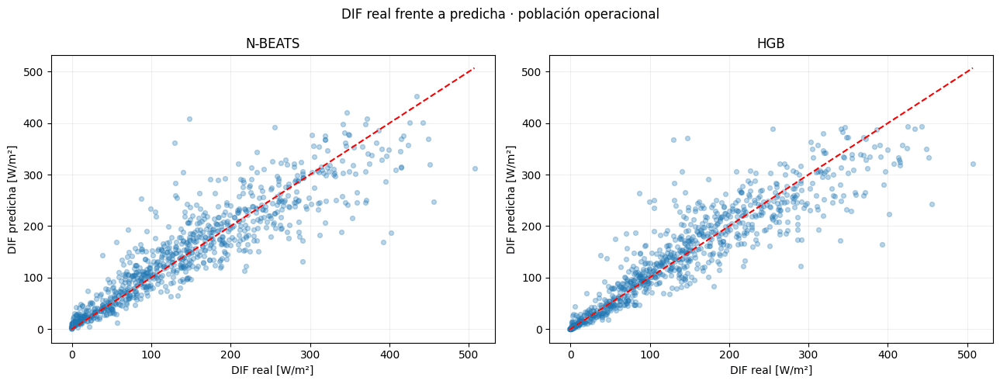

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
limite_minimo = min(
    diagnostico_operacional["DIF_real"].min(),
    diagnostico_operacional[nombre_NBEATS].min(),
    diagnostico_operacional[nombre_HGB].min(),
)
limite_maximo = max(
    diagnostico_operacional["DIF_real"].max(),
    diagnostico_operacional[nombre_NBEATS].max(),
    diagnostico_operacional[nombre_HGB].max(),
)
axes[0].scatter(
    diagnostico_operacional["DIF_real"], diagnostico_operacional[nombre_NBEATS], alpha=0.30, s=18
)
axes[0].plot(
    [limite_minimo, limite_maximo], [limite_minimo, limite_maximo], linestyle="--", color="red"
)
axes[0].set_title("N-BEATS")
axes[0].set_xlabel("DIF real [W/m²]")
axes[0].set_ylabel("DIF predicha [W/m²]")
axes[0].grid(alpha=0.20)
axes[1].scatter(
    diagnostico_operacional["DIF_real"], diagnostico_operacional[nombre_HGB], alpha=0.30, s=18
)
axes[1].plot(
    [limite_minimo, limite_maximo], [limite_minimo, limite_maximo], linestyle="--", color="red"
)
axes[1].set_title("HGB")
axes[1].set_xlabel("DIF real [W/m²]")
axes[1].set_ylabel("DIF predicha [W/m²]")
axes[1].grid(alpha=0.20)
plt.suptitle("DIF real frente a predicha · población operacional")
plt.tight_layout()
plt.savefig(carpeta_figuras_nbeats / "04_real_frente_predicha.png", dpi=180, bbox_inches="tight")
plt.show()

**Resultados.** En operación, el error depende sobre todo de la magnitud del cambio respecto a la hora anterior.

- En el quintil de cambios más intensos, el MAE es de 66,52 W/m² (N-BEATS) y 65,71 W/m² (HGB); en los demás quintiles no supera 22,82 W/m².
- Frente al HGB, la mayor desventaja aparece con DIF baja (10,45 frente a 5,87 W/m² en el primer quintil); en los dos quintiles superiores los MAE son casi iguales.
- La N-BEATS infraestima los aumentos (sesgo de −14,65 W/m²) y sobreestima los descensos (+24,03 W/m²).
- Los 74 episodios por encima del p95 (71,19 W/m²) son horas completamente diurnas, con sesgos de −111,92 W/m² en aumentos y +108,84 W/m² en descensos.

### 4.13 Guardado del experimento N-BEATS

Se guardan el modelo N-BEATS con su escalado y su historial de entrenamiento, las predicciones pareadas con el HGB y las tablas y figuras del diagnóstico de errores.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import shutil
import sys
import numpy as np
import pandas as pd
import torch
import sklearn
from google.colab import files

# 1. Comprobar los objetos fundamentales
objetos_fundamentales = [
    "modelo_nbeats_final",
    "historial_nbeats",
    "mejor_epoca",
    "X_train_nbeats",
    "y_train_nbeats",
    "X_validation_nbeats",
    "y_validation_nbeats",
    "meta_train_nbeats",
    "meta_validation_nbeats",
    "resultados_validation_nbeats",
    "comparacion_modelos",
    "metricas_HGB_NBEATS",
    "comparacion_resumen",
    "tabla_horas_ganadas",
    "diagnostico_nbeats",
]
objetos_ausentes = [nombre for nombre in objetos_fundamentales if nombre not in globals()]
if objetos_ausentes:
    raise NameError(
        "Faltan objetos fundamentales:\n" + "\n".join(f"- {nombre}" for nombre in objetos_ausentes)
    )

# 2. Crear carpetas
momento = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%dT%H%M%S")
nombre_experimento = f"experimento_NBEATS_U24_HGB_diagnostico_{momento}"
carpeta_salida = Path("/content") / nombre_experimento
if carpeta_salida.exists():
    shutil.rmtree(carpeta_salida)

carpeta_salida.mkdir(parents=True, exist_ok=True)
carpeta_tablas = carpeta_salida / "tablas"
carpeta_figuras = carpeta_salida / "figuras"
carpeta_modelo = carpeta_salida / "modelo"
carpeta_datos = carpeta_salida / "datos_compactos"
for carpeta in [carpeta_tablas, carpeta_figuras, carpeta_modelo, carpeta_datos]:
    carpeta.mkdir(exist_ok=True)

# 3. Funciones auxiliares
indice_archivos = []

def registrar_archivo(ruta, descripcion):
    indice_archivos.append(
        {
            "archivo": str(ruta.relative_to(carpeta_salida)),
            "descripcion": descripcion,
            "tamano_KB": round(ruta.stat().st_size / 1024, 2),
        }
    )

def guardar_dataframe(nombre_objeto, nombre_archivo, descripcion, guardar_parquet=False):
    if nombre_objeto not in globals():
        print(f"AVISO: no existe {nombre_objeto}; " "no se exporta.")
        return

    objeto = globals()[nombre_objeto]
    if not isinstance(objeto, pd.DataFrame):
        print(f"AVISO: {nombre_objeto} no es DataFrame.")
        return

    ruta_csv = carpeta_tablas / f"{nombre_archivo}.csv"
    objeto.to_csv(ruta_csv, index=False)
    registrar_archivo(ruta_csv, descripcion)
    if guardar_parquet:
        ruta_parquet = carpeta_datos / f"{nombre_archivo}.parquet"
        objeto.to_parquet(ruta_parquet, index=False)
        registrar_archivo(ruta_parquet, descripcion + " · formato parquet")


# 4. Guardar modelo N-BEATS
configuracion_arquitectura = {
    "nombre_modelo": "M4-NBEATS-U24-DIF-MAE-Global",
    "tipo": "N-BEATS genérico univariante",
    "longitud_entrada": 24,
    "horizonte": 1,
    "n_stacks": 2,
    "bloques_por_stack": 3,
    "numero_bloques": 6,
    "capas_densas_por_bloque": 3,
    "unidades_ocultas": 128,
    "activacion": "ReLU",
    "funcion_perdida": "MAE / L1Loss",
    "optimizador": "Adam",
    "learning_rate": 1e-3,
    "weight_decay": 1e-5,
    "batch_size": 128,
    "semilla": 42,
    "mejor_epoca": int(mejor_epoca),
    "n_parametros_entrenables": int(
        sum(
            parametro.numel()
            for parametro in modelo_nbeats_final.parameters()
            if parametro.requires_grad
        )
    ),
}
estado_cpu = {
    nombre: tensor.detach().cpu() for nombre, tensor in modelo_nbeats_final.state_dict().items()
}
ruta_modelo = carpeta_modelo / "M4_NBEATS_U24_DIF_MAE_Global_state_dict.pt"
torch.save(
    {
        "state_dict": estado_cpu,
        "configuracion": configuracion_arquitectura,
        "media_DIF_train": float(media_DIF_train_completo),
        "std_DIF_train": float(std_DIF_train_completo),
        "mejor_epoca": int(mejor_epoca),
    },
    ruta_modelo,
)
registrar_archivo(ruta_modelo, "Pesos, arquitectura y escalado de N-BEATS")
ruta_configuracion = carpeta_modelo / "configuracion_arquitectura.json"
with open(ruta_configuracion, "w", encoding="utf-8") as archivo:
    json.dump(configuracion_arquitectura, archivo, ensure_ascii=False, indent=2)

registrar_archivo(ruta_configuracion, "Configuración de la arquitectura N-BEATS")
ruta_arquitectura_txt = carpeta_modelo / "arquitectura_modelo.txt"
with open(ruta_arquitectura_txt, "w", encoding="utf-8") as archivo:
    archivo.write(str(modelo_nbeats_final))

registrar_archivo(ruta_arquitectura_txt, "Representación textual de la red")

# 5. Historial de entrenamiento
guardar_dataframe(
    "historial_nbeats",
    "01_historial_entrenamiento",
    "MAE de subtrain y validación interna por época",
)

# 6. Resultados principales
guardar_dataframe(
    "resultados_validation_nbeats",
    "02_predicciones_NBEATS_validation",
    "Predicciones y errores de N-BEATS",
    guardar_parquet=True,
)
guardar_dataframe(
    "comparacion_modelos",
    "03_predicciones_comparadas_HGB_NBEATS",
    "Predicciones pareadas de HGB y N-BEATS",
    guardar_parquet=True,
)
guardar_dataframe(
    "metricas_M4_NBEATS", "04_metricas_NBEATS_por_regimen", "Métricas de N-BEATS por régimen"
)
guardar_dataframe(
    "metricas_HGB_NBEATS", "05_metricas_HGB_NBEATS_por_regimen", "Comparación completa de métricas"
)
guardar_dataframe(
    "comparacion_resumen",
    "06_resumen_comparacion_HGB_NBEATS",
    "Diferencias de MAE, RMSE, sesgo y R2",
)
guardar_dataframe(
    "tabla_horas_ganadas",
    "07_porcentaje_horas_ganadas",
    "Porcentaje de horas ganado por cada modelo",
)

# 7. Diagnóstico completo
guardar_dataframe(
    "diagnostico_nbeats",
    "08_diagnostico_completo_validation",
    "Tabla maestra del diagnóstico",
    guardar_parquet=True,
)
guardar_dataframe("tabla_error_mes", "09_error_por_mes", "Errores de N-BEATS y HGB por mes")
guardar_dataframe("tabla_error_hora", "10_error_por_hora", "Errores de N-BEATS y HGB por hora")
guardar_dataframe("tabla_error_regimen", "11_error_por_regimen", "Errores por régimen solar")
guardar_dataframe(
    "tabla_error_elevacion", "12_error_por_banda_elevacion", "Errores por banda de elevación"
)
guardar_dataframe(
    "tabla_error_quintil_DIF", "13_error_por_quintil_DIF", "Errores según el nivel de DIF"
)
guardar_dataframe(
    "tabla_error_quintil_cambio",
    "14_error_por_quintil_cambio",
    "Errores según la magnitud del cambio",
)
guardar_dataframe(
    "tabla_error_direccion",
    "15_error_por_direccion_cambio",
    "Errores según aumento, descenso o estabilidad",
)
guardar_dataframe(
    "episodios_extremos_nbeats",
    "16_episodios_extremos_p95",
    "Observaciones por encima del p95 de error",
    guardar_parquet=True,
)
guardar_dataframe("top30_errores_nbeats", "17_top30_errores_NBEATS", "Treinta errores más elevados")
guardar_dataframe(
    "tabla_extremos_regimen", "18_extremos_por_regimen", "Episodios extremos por régimen"
)
guardar_dataframe("tabla_extremos_mes", "19_extremos_por_mes", "Episodios extremos por mes")
guardar_dataframe(
    "tabla_extremos_direccion",
    "20_extremos_por_direccion",
    "Episodios extremos por dirección del cambio",
)
guardar_dataframe("error_diario", "21_error_diario", "Evolución diaria del MAE")

# 8. Ventanas secuenciales y metadatos
ruta_arrays = carpeta_datos / "ventanas_NBEATS_train_validation.npz"
np.savez_compressed(
    ruta_arrays,
    X_train=X_train_nbeats,
    y_train=y_train_nbeats,
    X_validation=X_validation_nbeats,
    y_validation=y_validation_nbeats,
)
registrar_archivo(ruta_arrays, "Ventanas completas de train y validation")
ruta_meta_train = carpeta_datos / "metadatos_train.parquet"
meta_train_nbeats.to_parquet(ruta_meta_train, index=False)
registrar_archivo(ruta_meta_train, "Timestamps y metadatos de train")
ruta_meta_validation = carpeta_datos / "metadatos_validation.parquet"
meta_validation_nbeats.to_parquet(ruta_meta_validation, index=False)
registrar_archivo(ruta_meta_validation, "Timestamps y metadatos de validation")

# 9. Copiar figuras
if "carpeta_figuras_nbeats" in globals() and Path(carpeta_figuras_nbeats).exists():
    for figura in Path(carpeta_figuras_nbeats).glob("*.png"):
        destino = carpeta_figuras / figura.name
        shutil.copy2(figura, destino)
        registrar_archivo(destino, "Figura del diagnóstico de errores")

else:
    print("AVISO: no se encontró la carpeta de figuras del diagnóstico.")

# 10. Metadatos generales
metadatos_experimento = {
    "nombre_experimento": nombre_experimento,
    "fecha_exportacion_Europe_Madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "modelo_NBEATS": "M4-NBEATS-U24-DIF-MAE-Global",
    "modelo_HGB_referencia": "M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global",
    "objetivo": "DIF(t+1)",
    "horizonte": "una hora",
    "ventana": "24 horas",
    "variables_predictoras": ["24 valores horarios anteriores de DIF"],
    "incluye_fecha_como_predictor": False,
    "incluye_hora_como_predictor": False,
    "incluye_geometria_como_predictor": False,
    "n_train": int(len(X_train_nbeats)),
    "n_validation": int(len(X_validation_nbeats)),
    "n_subtrain": int(mascara_subtrain.sum()),
    "n_validacion_interna": int(mascara_validacion_interna.sum()),
    "corte_validacion_interna": corte_interno.isoformat(),
    "mejor_epoca": int(mejor_epoca),
    "mejor_MAE_interno_Wm2": float(mejor_MAE_interno),
    "media_DIF_subtrain": float(media_DIF_subtrain),
    "std_DIF_subtrain": float(std_DIF_subtrain),
    "media_DIF_train_completo": float(media_DIF_train_completo),
    "std_DIF_train_completo": float(std_DIF_train_completo),
    "version_python": sys.version,
    "version_numpy": np.__version__,
    "version_pandas": pd.__version__,
    "version_torch": torch.__version__,
    "version_sklearn": sklearn.__version__,
}
ruta_metadatos = carpeta_salida / "metadatos_experimento.json"
with open(ruta_metadatos, "w", encoding="utf-8") as archivo:
    json.dump(metadatos_experimento, archivo, ensure_ascii=False, indent=2)

registrar_archivo(ruta_metadatos, "Metadatos metodológicos y versiones")

# 11. README
texto_readme = f"""
EXPERIMENTO N-BEATS U24 Y COMPARACIÓN CON HGB
=============================================

Modelo:
M4-NBEATS-U24-DIF-MAE-Global

Entrada:
24 valores horarios anteriores de DIF.

Objetivo:
DIF de la hora siguiente.

Arquitectura:
N-BEATS genérico con 2 stacks, 3 bloques por stack,
3 capas densas por bloque y 128 unidades ocultas.

Selección temporal:
- Subtrain: {int(mascara_subtrain.sum())} observaciones.
- Validación interna: {int(mascara_validacion_interna.sum())}.
- Mejor época: {int(mejor_epoca)}.
- MAE interno: {float(mejor_MAE_interno):.4f} W/m².

Evaluación externa:
1.464 horas de agosto y septiembre de 2024.

Modelo de comparación:
M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global.

Contenido:
- pesos y configuración;
- historial de entrenamiento;
- ventanas secuenciales;
- predicciones;
- métricas;
- comparación pareada;
- diagnóstico de errores;
- episodios extremos;
- figuras.

Pendiente:
La importancia de los 24 retardos todavía no está incluida.
Se calculará en el siguiente bloque mediante permutación temporal.

El parquet minutal original no está incluido.
"""
ruta_readme = carpeta_salida / "README.txt"
with open(ruta_readme, "w", encoding="utf-8") as archivo:
    archivo.write(texto_readme.strip())

registrar_archivo(ruta_readme, "Descripción y contenido del experimento")

# 12. Índice final de archivos
tabla_indice = pd.DataFrame(indice_archivos).sort_values("archivo")
ruta_indice = carpeta_salida / "indice_archivos.csv"
tabla_indice.to_csv(ruta_indice, index=False)

# 13. Comprimir y descargar
ruta_zip = shutil.make_archive(str(carpeta_salida), "zip", root_dir=carpeta_salida)
tamano_MB = Path(ruta_zip).stat().st_size / 1024**2
print("EXPORTACIÓN COMPLETADA")
print("----------------------")
print("Archivo:", ruta_zip)
print(f"Tamaño: {tamano_MB:.2f} MB")
print(f"Elementos registrados: {len(tabla_indice)}")
display(tabla_indice)
files.download(ruta_zip)

EXPORTACIÓN COMPLETADA
----------------------
Archivo: /content/experimento_NBEATS_U24_HGB_diagnostico_20261005T134615.zip
Tamaño: 2.29 MB
Elementos registrados: 37


,archivo,descripcion,tamano_KB
36,README.txt,Descripción y contenido del experimento,0.98
5,datos_compactos/02_predicciones_NBEATS_validat...,Predicciones y errores de N-BEATS · formato pa...,74.51
7,datos_compactos/03_predicciones_comparadas_HGB...,Predicciones pareadas de HGB y N-BEATS · forma...,90.77
13,datos_compactos/08_diagnostico_completo_valida...,Tabla maestra del diagnóstico · formato parquet,201.74
22,datos_compactos/16_episodios_extremos_p95.parquet,Observaciones por encima del p95 de error · fo...,19.88
29,datos_compactos/metadatos_train.parquet,Timestamps y metadatos de train,137.52
30,datos_compactos/metadatos_validation.parquet,Timestamps y metadatos de validation,43.89
28,datos_compactos/ventanas_NBEATS_train_validati...,Ventanas completas de train y validation,36.27
34,figuras/01_MAE_diario_HGB_NBEATS.png,Figura del diagnóstico de errores,290.84
32,figuras/02_MAE_por_hora.png,Figura del diagnóstico de errores,119.50


### 4.14 Importancia de los 24 retardos de la N-BEATS

Se estima la importancia de cada retardo mediante permutación condicionada sobre el modelo ya entrenado: se desordena un único paso de la ventana dentro de grupos con la misma hora y el mismo régimen solar, se vuelve a predecir y se mide el aumento del MAE. El cálculo se repite para el total, la operación, las horas completamente diurnas, la transición y los episodios por encima del p95, separados en aumentos y descensos. Se trata de una medida de sensibilidad predictiva, no causal.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Orden exacto de las ventanas:
# posición 0  -> lag24
# posición 23 -> lag1
diagnostico_alineado = meta_validation_nbeats[["instante_objetivo"]].copy()
diagnostico_alineado["instante_objetivo"] = pd.to_datetime(
    diagnostico_alineado["instante_objetivo"], utc=True
)
diagnostico_alineado = diagnostico_alineado.merge(
    diagnostico_nbeats, on="instante_objetivo", how="left", validate="one_to_one"
)
if len(diagnostico_alineado) != len(X_validation_nbeats):
    raise ValueError("No coincide el número de ventanas con el diagnóstico.")

if diagnostico_alineado["DIF_real"].isna().any():
    raise ValueError("Hay objetivos ausentes después de la unión.")

diferencia_y = np.max(
    np.abs(
        diagnostico_alineado["DIF_real"].to_numpy(dtype=float) - y_validation_nbeats.astype(float)
    )
)
print(f"Diferencia máxima del objetivo: " f"{diferencia_y:.10f}")
if diferencia_y > 1e-6:
    raise ValueError("El objetivo no está correctamente alineado.")

regimen = diagnostico_alineado["regimen_solar_objetivo"].astype(str)
hora_objetivo = pd.to_datetime(diagnostico_alineado["instante_objetivo"], utc=True).dt.hour

# Grupos dentro de los cuales se permutará.
grupos_permutacion = pd.DataFrame({"regimen": regimen, "hora": hora_objetivo})
indices_por_grupo = [
    indices.to_numpy()
    for _, indices in grupos_permutacion.groupby(["regimen", "hora"]).groups.items()
    if len(indices) > 1
]

# Máscaras de evaluación
mascaras_importancia = {
    "total": np.ones(len(diagnostico_alineado), dtype=bool),
    "operacional": regimen.isin(["completamente_diurna", "transicion"]).to_numpy(),
    "completamente_diurna": (regimen == "completamente_diurna").to_numpy(),
    "transicion": (regimen == "transicion").to_numpy(),
    "extremos_p95": diagnostico_alineado["extremo_NBEATS_p95"].astype(bool).to_numpy(),
    "extremos_aumento": (
        diagnostico_alineado["extremo_NBEATS_p95"].astype(bool)
        & (diagnostico_alineado["direccion_cambio"] == "aumento")
    ).to_numpy(),
    "extremos_descenso": (
        diagnostico_alineado["extremo_NBEATS_p95"].astype(bool)
        & (diagnostico_alineado["direccion_cambio"] == "descenso")
    ).to_numpy(),
}
print("\nSOPORTES")
for nombre, mascara in mascaras_importancia.items():
    print(f"{nombre:25s}: " f"{mascara.sum():4d}")

Diferencia máxima del objetivo: 0.0000000000

SOPORTES
total                    : 1464
operacional              :  884
completamente_diurna     :  765
transicion               :  119
extremos_p95             :   74
extremos_aumento         :   35
extremos_descenso        :   39


In [ ]:
modelo_nbeats_final.eval()

def predecir_nbeats_desde_ventanas(X_sin_escalar):
    X_escalado = (X_sin_escalar - media_DIF_train_completo) / std_DIF_train_completo
    tensor_X = torch.tensor(X_escalado, dtype=torch.float32, device=dispositivo)
    with torch.no_grad():
        prediccion_escalada = modelo_nbeats_final(tensor_X).detach().cpu().numpy().reshape(-1)

    prediccion_original = prediccion_escalada * std_DIF_train_completo + media_DIF_train_completo
    return prediccion_original

prediccion_base_recalculada = predecir_nbeats_desde_ventanas(X_validation_nbeats)
prediccion_base_guardada = diagnostico_alineado[nombre_NBEATS].to_numpy(dtype=float)
diferencia_prediccion = np.max(np.abs(prediccion_base_recalculada - prediccion_base_guardada))
print(
    "Diferencia máxima entre predicción "
    f"recalculada y guardada: "
    f"{diferencia_prediccion:.10f}"
)
if diferencia_prediccion > 1e-4:
    raise ValueError("La predicción recalculada no coincide con la guardada.")

Diferencia máxima entre predicción recalculada y guardada: 0.0000152588


In [ ]:
y_real_importancia = diagnostico_alineado["DIF_real"].to_numpy(dtype=float)
errores_base_abs = np.abs(prediccion_base_recalculada - y_real_importancia)
filas_base = []
for poblacion, mascara in mascaras_importancia.items():
    filas_base.append(
        {
            "poblacion": poblacion,
            "n": int(mascara.sum()),
            "MAE_base": float(errores_base_abs[mascara].mean()),
            "p95_error_base": float(np.quantile(errores_base_abs[mascara], 0.95)),
        }
    )

tabla_base_importancia = pd.DataFrame(filas_base)
display(tabla_base_importancia.round(4))

,poblacion,n,MAE_base,p95_error_base
0,total,1464,18.7116,71.1930
1,operacional,884,29.2961,97.5571
2,completamente_diurna,765,32.5305,99.7992
3,transicion,119,8.5037,22.1078
4,extremos_p95,74,112.3976,210.6533
5,extremos_aumento,35,116.3576,210.3273
6,extremos_descenso,39,108.8438,173.1145


### 4.15 Permutación individual de los retardos

Cada uno de los 24 retardos se permuta 10 veces sin reentrenar el modelo y se resume, para cada población, el aumento medio del MAE respecto a las predicciones originales.

In [ ]:
n_repeticiones = 10
resultados_permutacion_lags = []
MAE_base_por_poblacion = {
    nombre: float(errores_base_abs[mascara].mean())
    for nombre, mascara in mascaras_importancia.items()
}
for lag in range(1, 25):

    # X está ordenado como lag24,...,lag1.
    posicion = 24 - lag
    print(f"Procesando lag {lag:02d}/24")
    for repeticion in range(1, n_repeticiones + 1):
        rng = np.random.default_rng(42 + lag * 1000 + repeticion)
        X_permutado = X_validation_nbeats.copy()
        for indices_grupo in indices_por_grupo:
            indices_permutados = rng.permutation(indices_grupo)
            X_permutado[indices_grupo, posicion, 0] = X_validation_nbeats[
                indices_permutados, posicion, 0
            ]

        prediccion_permutada = predecir_nbeats_desde_ventanas(X_permutado)
        error_permutado_abs = np.abs(prediccion_permutada - y_real_importancia)
        for poblacion, mascara in mascaras_importancia.items():
            mae_permutado = float(error_permutado_abs[mascara].mean())
            resultados_permutacion_lags.append(
                {
                    "lag": lag,
                    "repeticion": repeticion,
                    "poblacion": poblacion,
                    "n": int(mascara.sum()),
                    "MAE_base": MAE_base_por_poblacion[poblacion],
                    "MAE_permutado": mae_permutado,
                    "incremento_MAE": mae_permutado - MAE_base_por_poblacion[poblacion],
                }
            )

resultados_permutacion_lags = pd.DataFrame(resultados_permutacion_lags)
print("Permutaciones finalizadas.")
print(resultados_permutacion_lags.shape)

Procesando lag 01/24
Procesando lag 02/24
Procesando lag 03/24
Procesando lag 04/24
Procesando lag 05/24
Procesando lag 06/24
Procesando lag 07/24
Procesando lag 08/24
Procesando lag 09/24
Procesando lag 10/24
Procesando lag 11/24
Procesando lag 12/24
Procesando lag 13/24
Procesando lag 14/24
Procesando lag 15/24
Procesando lag 16/24
Procesando lag 17/24
Procesando lag 18/24
Procesando lag 19/24
Procesando lag 20/24
Procesando lag 21/24
Procesando lag 22/24
Procesando lag 23/24
Procesando lag 24/24
Permutaciones finalizadas.
(1680, 7)


In [ ]:
resumen_importancia_lags = resultados_permutacion_lags.groupby(
    ["lag", "poblacion"], as_index=False
).agg(
    n=("n", "first"),
    MAE_base=("MAE_base", "first"),
    incremento_MAE_medio=("incremento_MAE", "mean"),
    incremento_MAE_std=("incremento_MAE", "std"),
    incremento_MAE_min=("incremento_MAE", "min"),
    incremento_MAE_max=("incremento_MAE", "max"),
    pct_repeticiones_incrementa_MAE=("incremento_MAE", lambda x: 100 * np.mean(x > 0)),
)
tabla_importancia_operacional = resumen_importancia_lags.query(
    "poblacion == 'operacional'"
).sort_values("incremento_MAE_medio", ascending=False)
tabla_importancia_diurna = resumen_importancia_lags.query(
    "poblacion == 'completamente_diurna'"
).sort_values("incremento_MAE_medio", ascending=False)
tabla_importancia_extremos = resumen_importancia_lags.query(
    "poblacion == 'extremos_p95'"
).sort_values("incremento_MAE_medio", ascending=False)
print("IMPORTANCIA OPERACIONAL")
display(tabla_importancia_operacional.round(4))
print("\nIMPORTANCIA COMPLETAMENTE DIURNA")
display(tabla_importancia_diurna.round(4))
print("\nIMPORTANCIA EN LOS ERRORES EXTREMOS")
display(tabla_importancia_extremos.round(4))

IMPORTANCIA OPERACIONAL


,lag,poblacion,n,MAE_base,incremento_MAE_medio,incremento_MAE_std,incremento_MAE_min,incremento_MAE_max,pct_repeticiones_incrementa_MAE
4,1,operacional,884,29.2961,29.4616,2.1455,26.7784,32.9588,100.0
123,18,operacional,884,29.2961,0.5808,0.1017,0.4211,0.7177,100.0
32,5,operacional,884,29.2961,0.4010,0.0538,0.3357,0.4864,100.0
46,7,operacional,884,29.2961,0.2286,0.0797,0.1395,0.3590,100.0
130,19,operacional,884,29.2961,0.1805,0.0991,0.0408,0.3626,100.0
11,2,operacional,884,29.2961,0.1584,0.1065,-0.0380,0.2976,90.0
137,20,operacional,884,29.2961,0.1506,0.0703,0.0052,0.2478,100.0
165,24,operacional,884,29.2961,0.1465,0.1471,-0.1659,0.2979,90.0
158,23,operacional,884,29.2961,0.1416,0.1298,-0.0750,0.3237,90.0
53,8,operacional,884,29.2961,0.1404,0.0444,0.0793,0.2056,100.0



IMPORTANCIA COMPLETAMENTE DIURNA


,lag,poblacion,n,MAE_base,incremento_MAE_medio,incremento_MAE_std,incremento_MAE_min,incremento_MAE_max,pct_repeticiones_incrementa_MAE
0,1,completamente_diurna,765,32.5305,33.8973,2.4610,30.7498,37.9509,100.0
119,18,completamente_diurna,765,32.5305,0.5015,0.1232,0.3376,0.6552,100.0
28,5,completamente_diurna,765,32.5305,0.4139,0.0592,0.3444,0.5046,100.0
42,7,completamente_diurna,765,32.5305,0.2125,0.0897,0.1040,0.3463,100.0
7,2,completamente_diurna,765,32.5305,0.1801,0.1227,-0.0496,0.3427,90.0
161,24,completamente_diurna,765,32.5305,0.1572,0.1680,-0.1990,0.3441,90.0
154,23,completamente_diurna,765,32.5305,0.1420,0.1434,-0.1147,0.3228,90.0
49,8,completamente_diurna,765,32.5305,0.1355,0.0474,0.0783,0.2072,100.0
126,19,completamente_diurna,765,32.5305,0.0943,0.1097,-0.0560,0.2851,80.0
133,20,completamente_diurna,765,32.5305,0.0835,0.0825,-0.1003,0.2244,90.0



IMPORTANCIA EN LOS ERRORES EXTREMOS


,lag,poblacion,n,MAE_base,incremento_MAE_medio,incremento_MAE_std,incremento_MAE_min,incremento_MAE_max,pct_repeticiones_incrementa_MAE
31,5,extremos_p95,74,112.3976,0.4555,0.3701,0.0200,1.0093,100.0
10,2,extremos_p95,74,112.3976,0.1628,0.6738,-1.1682,1.1325,60.0
108,16,extremos_p95,74,112.3976,0.1457,0.1309,-0.1140,0.3476,90.0
38,6,extremos_p95,74,112.3976,0.0928,0.3242,-0.3058,0.5156,50.0
52,8,extremos_p95,74,112.3976,0.0859,0.3027,-0.4887,0.5477,50.0
66,10,extremos_p95,74,112.3976,0.0726,0.0418,0.0136,0.1405,100.0
115,17,extremos_p95,74,112.3976,0.0689,0.0962,-0.0934,0.2020,80.0
80,12,extremos_p95,74,112.3976,-0.0010,0.0022,-0.0065,0.0015,30.0
73,11,extremos_p95,74,112.3976,-0.0073,0.0352,-0.0585,0.0432,50.0
59,9,extremos_p95,74,112.3976,-0.0107,0.0265,-0.0654,0.0171,40.0


In [ ]:
tabla_importancia_extremos_direccion = (
    resumen_importancia_lags[
        resumen_importancia_lags["poblacion"].isin(["extremos_aumento", "extremos_descenso"])
    ]
    .pivot(index="lag", columns="poblacion", values="incremento_MAE_medio")
    .reset_index()
)
tabla_importancia_extremos_direccion["diferencia_aumento_menos_descenso"] = (
    tabla_importancia_extremos_direccion["extremos_aumento"]
    - tabla_importancia_extremos_direccion["extremos_descenso"]
)
display(
    tabla_importancia_extremos_direccion.sort_values("extremos_aumento", ascending=False).round(4)
)

poblacion,lag,extremos_aumento,extremos_descenso,diferencia_aumento_menos_descenso
0,1,25.4445,-26.6119,52.0564
3,4,1.4148,-4.0638,5.4786
5,6,0.6683,-0.4237,1.0920
2,3,0.3801,-1.9706,2.3506
20,21,0.2778,-1.4522,1.7300
15,16,0.2339,0.0665,0.1674
9,10,0.2025,-0.0440,0.2466
16,17,-0.0012,0.1318,-0.1331
11,12,-0.0019,-0.0002,-0.0017
10,11,-0.0539,0.0345,-0.0883


In [ ]:
tabla_mapa_importancia = resumen_importancia_lags.pivot(
    index="lag", columns="poblacion", values="incremento_MAE_medio"
).sort_index()
display(tabla_mapa_importancia.round(4))

poblacion,completamente_diurna,extremos_aumento,extremos_descenso,extremos_p95,operacional,total,transicion
lag,,,,,,,
1,33.8973,25.4445,-26.6119,-1.9906,29.4616,17.8010,0.9464
2,0.1801,-0.7619,0.9927,0.1628,0.1584,0.1047,0.0187
3,-0.0064,0.3801,-1.9706,-0.8588,-0.0086,0.0017,-0.0231
4,0.0711,1.4148,-4.0638,-1.4725,0.0671,0.0446,0.0413
5,0.4139,-0.7437,1.5316,0.4555,0.4010,0.2627,0.3182
6,-0.0063,0.6683,-0.4237,0.0928,0.0371,0.0261,0.3166
7,0.2125,-0.9654,0.8294,-0.0195,0.2286,0.1413,0.3325
8,0.1355,-0.5175,0.6274,0.0859,0.1404,0.0783,0.1720
9,-0.0383,-0.0559,0.0298,-0.0107,-0.0056,0.0062,0.2050


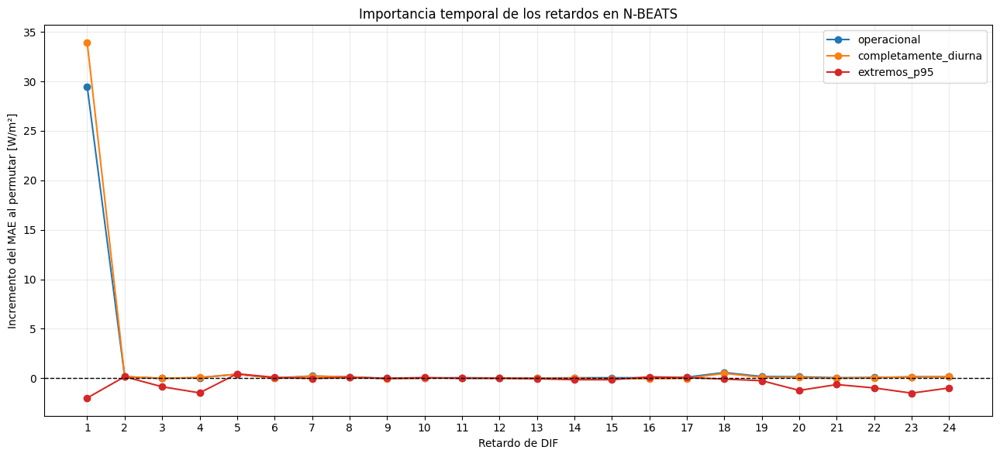

In [ ]:
carpeta_figuras_importancia = Path("/content/figuras_importancia_lags_nbeats")
carpeta_figuras_importancia.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(13, 6))
colores = {
    "operacional": "tab:blue",
    "completamente_diurna": "tab:orange",
    "extremos_p95": "tab:red",
}
for poblacion in ["operacional", "completamente_diurna", "extremos_p95"]:
    datos = resumen_importancia_lags.query("poblacion == @poblacion").sort_values("lag")
    ax.plot(
        datos["lag"],
        datos["incremento_MAE_medio"],
        marker="o",
        label=poblacion,
        color=colores[poblacion],
    )

ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set_xticks(range(1, 25))
ax.set_xlabel("Retardo de DIF")
ax.set_ylabel("Incremento del MAE al permutar [W/m²]")
ax.set_title("Importancia temporal de los retardos en N-BEATS")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(
    carpeta_figuras_importancia / "01_importancia_lags_operacional_extremos.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

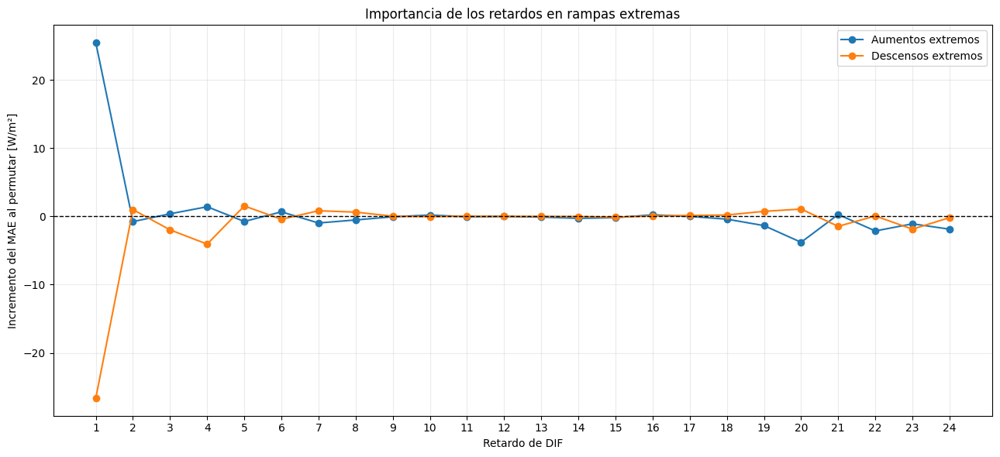

In [ ]:
datos_aumento = resumen_importancia_lags.query("poblacion == 'extremos_aumento'").sort_values("lag")
datos_descenso = resumen_importancia_lags.query("poblacion == 'extremos_descenso'").sort_values(
    "lag"
)
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(
    datos_aumento["lag"],
    datos_aumento["incremento_MAE_medio"],
    marker="o",
    label="Aumentos extremos",
)
ax.plot(
    datos_descenso["lag"],
    datos_descenso["incremento_MAE_medio"],
    marker="o",
    label="Descensos extremos",
)
ax.axhline(0, color="black", linewidth=1, linestyle="--")
ax.set_xticks(range(1, 25))
ax.set_xlabel("Retardo de DIF")
ax.set_ylabel("Incremento del MAE al permutar [W/m²]")
ax.set_title("Importancia de los retardos en rampas extremas")
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.savefig(
    carpeta_figuras_importancia / "02_importancia_lags_extremos_direccion.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

**Resultados.** La N-BEATS depende casi por completo del retardo de una hora.

- Al permutarlo, el MAE aumenta 17,80 W/m² en total, 29,46 W/m² en operación y 33,90 W/m² en horas completamente diurnas; en operación, el siguiente retardo (18 horas) solo lo aumenta 0,58 W/m² y los próximos a 24 horas, 0,15 W/m² o menos.
- En transición la importancia está más repartida: el máximo corresponde al retardo de 18 horas (1,09 W/m²), seguido del de una hora (0,95 W/m²).
- En los episodios extremos, permutar el retardo de una hora aumenta el MAE de los aumentos en 25,44 W/m² y reduce el de los descensos en 26,61 W/m².

### 4.16 N-BEATS con objetivo de cambio

Se entrena una variante (`M4b-NBEATS-U24-DeltaTarget-MAE-Global`) que, con la misma ventana, arquitectura y procedimiento, predice el cambio de la DIF respecto a la hora anterior; la predicción final se obtiene sumando ese cambio al último valor observado. Se compara con la N-BEATS directa y el HGB por régimen, por quintil de cambio y en los 74 episodios extremos.

In [ ]:
nombre_modelo_delta = "M4b-NBEATS-U24-DeltaTarget-MAE-Global"
DIF_lag1_train = X_train_nbeats[:, -1, 0]
DIF_lag1_validation = X_validation_nbeats[:, -1, 0]
delta_DIF_train = y_train_nbeats - DIF_lag1_train
delta_DIF_validation = y_validation_nbeats - DIF_lag1_validation
print("OBJETIVO ORIGINAL")
print(pd.Series(y_train_nbeats).describe().round(4))
print("\nOBJETIVO RESIDUAL")
print(pd.Series(delta_DIF_train).describe().round(4))
print("\nComprobación de reconstrucción:")
diferencia_reconstruccion = np.max(
    np.abs(DIF_lag1_validation + delta_DIF_validation - y_validation_nbeats)
)
print(f"Diferencia máxima: " f"{diferencia_reconstruccion:.10f}")

OBJETIVO ORIGINAL
count    5149.0000
mean       80.2951
std       112.1808
min        -2.3333
25%        -1.0000
50%        15.8500
75%       134.0500
max       555.1500
dtype: float64

OBJETIVO RESIDUAL
count    5149.0000
mean       -0.0354
std        46.3164
min      -321.2500
25%        -9.0667
50%         0.0000
75%        10.5333
max       269.0000
dtype: float64

Comprobación de reconstrucción:
Diferencia máxima: 0.0000152588


In [ ]:
# Se reutilizan exactamente las mismas máscaras temporales.
X_subtrain_delta = X_train_nbeats[mascara_subtrain]
X_val_interna_delta = X_train_nbeats[mascara_validacion_interna]
delta_subtrain = delta_DIF_train[mascara_subtrain]
delta_val_interna = delta_DIF_train[mascara_validacion_interna]

# Escalado de las entradas:
# se mantienen los parámetros de DIF del subtrain.
X_subtrain_delta_escalado = (X_subtrain_delta - media_DIF_subtrain) / std_DIF_subtrain
X_val_interna_delta_escalado = (X_val_interna_delta - media_DIF_subtrain) / std_DIF_subtrain

# El objetivo residual necesita su propio escalado.
media_delta_subtrain = float(np.mean(delta_subtrain))
std_delta_subtrain = float(np.std(delta_subtrain, ddof=0))
if std_delta_subtrain <= 0:
    raise ValueError("La desviación del objetivo residual no es positiva.")

delta_subtrain_escalado = (delta_subtrain - media_delta_subtrain) / std_delta_subtrain
delta_val_interna_escalado = (delta_val_interna - media_delta_subtrain) / std_delta_subtrain
dataset_subtrain_delta = TensorDataset(
    torch.tensor(X_subtrain_delta_escalado, dtype=torch.float32),
    torch.tensor(delta_subtrain_escalado, dtype=torch.float32).reshape(-1, 1),
)
dataset_val_interna_delta = TensorDataset(
    torch.tensor(X_val_interna_delta_escalado, dtype=torch.float32),
    torch.tensor(delta_val_interna_escalado, dtype=torch.float32).reshape(-1, 1),
)
generador_delta = torch.Generator()
generador_delta.manual_seed(SEMILLA)
loader_subtrain_delta = DataLoader(
    dataset_subtrain_delta, batch_size=128, shuffle=True, generator=generador_delta, drop_last=False
)
loader_val_interna_delta = DataLoader(
    dataset_val_interna_delta, batch_size=128, shuffle=False, drop_last=False
)
print(f"Media delta subtrain: {media_delta_subtrain:.4f}")
print(f"Std delta subtrain:   {std_delta_subtrain:.4f}")
print(f"Subtrain:             {len(delta_subtrain):,}")
print(f"Validación interna:   {len(delta_val_interna):,}")

Media delta subtrain: -0.0411
Std delta subtrain:   44.3264
Subtrain:             4,428
Validación interna:   721


In [ ]:
modelo_delta_seleccion = crear_modelo_nbeats()
optimizador_delta = torch.optim.Adam(
    modelo_delta_seleccion.parameters(), lr=1e-3, weight_decay=1e-5
)
funcion_perdida_delta = nn.L1Loss()
max_epocas_delta = 300
paciencia_delta = 25
mejora_minima_delta = 1e-5
mejor_perdida_delta = np.inf
mejor_estado_delta = None
mejor_epoca_delta = None
epocas_sin_mejora_delta = 0
filas_historial_delta = []
for epoca in range(1, max_epocas_delta + 1):
    modelo_delta_seleccion.train()
    perdida_train_acumulada = 0.0
    n_train_epoca = 0
    for X_lote, y_lote in loader_subtrain_delta:
        X_lote = X_lote.to(dispositivo)
        y_lote = y_lote.to(dispositivo)
        optimizador_delta.zero_grad()
        pred_delta = modelo_delta_seleccion(X_lote)
        perdida = funcion_perdida_delta(pred_delta, y_lote)
        perdida.backward()
        torch.nn.utils.clip_grad_norm_(modelo_delta_seleccion.parameters(), max_norm=1.0)
        optimizador_delta.step()
        tamano = len(X_lote)
        perdida_train_acumulada += perdida.item() * tamano
        n_train_epoca += tamano

    perdida_train_escalada = perdida_train_acumulada / n_train_epoca
    perdida_val_escalada = perdida_media_loader(
        modelo_delta_seleccion, loader_val_interna_delta, funcion_perdida_delta
    )
    mae_delta_train = perdida_train_escalada * std_delta_subtrain
    mae_delta_interno = perdida_val_escalada * std_delta_subtrain
    filas_historial_delta.append(
        {
            "epoca": epoca,
            "MAE_delta_train": mae_delta_train,
            "MAE_delta_validacion_interna": mae_delta_interno,
        }
    )
    if perdida_val_escalada < mejor_perdida_delta - mejora_minima_delta:
        mejor_perdida_delta = perdida_val_escalada
        mejor_estado_delta = copy.deepcopy(modelo_delta_seleccion.state_dict())
        mejor_epoca_delta = epoca
        epocas_sin_mejora_delta = 0

    else:
        epocas_sin_mejora_delta += 1

    if epoca == 1 or epoca % 10 == 0:
        print(
            f"Época {epoca:03d} | "
            f"MAE Δ train={mae_delta_train:.3f} | "
            f"MAE Δ interno={mae_delta_interno:.3f}"
        )

    if epocas_sin_mejora_delta >= paciencia_delta:
        print(f"\nEarly stopping en época " f"{epoca}.")
        break

if mejor_estado_delta is None:
    raise RuntimeError("No se almacenó ningún estado.")

modelo_delta_seleccion.load_state_dict(mejor_estado_delta)
historial_nbeats_delta = pd.DataFrame(filas_historial_delta)
mejor_MAE_delta_interno = mejor_perdida_delta * std_delta_subtrain
print("\nSELECCIÓN DEL MODELO RESIDUAL")
print(f"Mejor época: " f"{mejor_epoca_delta}")
print(f"Mejor MAE interno del cambio: " f"{mejor_MAE_delta_interno:.3f} W/m²")

Época 001 | MAE Δ train=20.496 | MAE Δ interno=27.866
Época 010 | MAE Δ train=15.976 | MAE Δ interno=26.192
Época 020 | MAE Δ train=15.301 | MAE Δ interno=26.179
Época 030 | MAE Δ train=13.870 | MAE Δ interno=26.995

Early stopping en época 33.

SELECCIÓN DEL MODELO RESIDUAL
Mejor época: 8
Mejor MAE interno del cambio: 25.701 W/m²


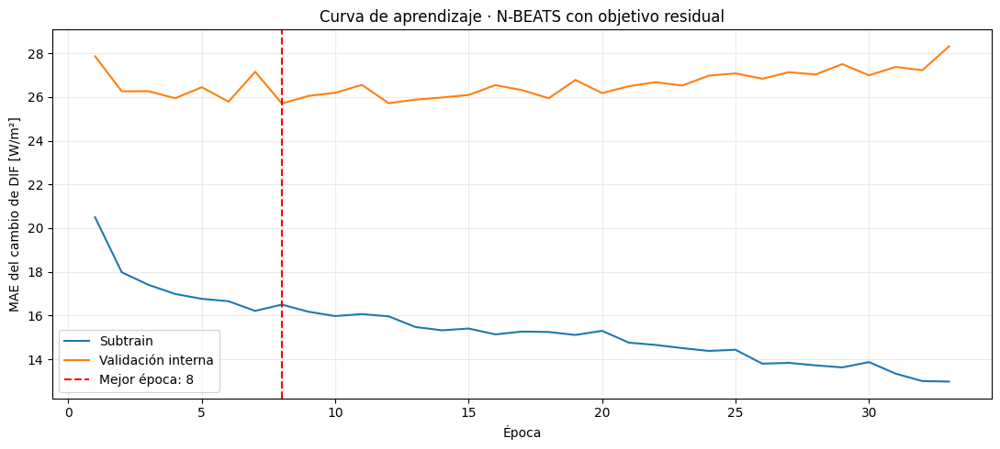

In [ ]:
plt.figure(figsize=(11, 5))
plt.plot(
    historial_nbeats_delta["epoca"], historial_nbeats_delta["MAE_delta_train"], label="Subtrain"
)
plt.plot(
    historial_nbeats_delta["epoca"],
    historial_nbeats_delta["MAE_delta_validacion_interna"],
    label="Validación interna",
)
plt.axvline(
    mejor_epoca_delta, color="red", linestyle="--", label=(f"Mejor época: " f"{mejor_epoca_delta}")
)
plt.xlabel("Época")
plt.ylabel("MAE del cambio de DIF [W/m²]")
plt.title("Curva de aprendizaje · N-BEATS con objetivo residual")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
# Escalado de entradas con todo train.
X_train_delta_final_escalado = (X_train_nbeats - media_DIF_train_completo) / std_DIF_train_completo
X_validation_delta_final_escalado = (
    X_validation_nbeats - media_DIF_train_completo
) / std_DIF_train_completo

# Escalado del objetivo residual con todo train.
media_delta_train_completo = float(np.mean(delta_DIF_train))
std_delta_train_completo = float(np.std(delta_DIF_train, ddof=0))
delta_train_final_escalado = (
    delta_DIF_train - media_delta_train_completo
) / std_delta_train_completo
dataset_train_delta_final = TensorDataset(
    torch.tensor(X_train_delta_final_escalado, dtype=torch.float32),
    torch.tensor(delta_train_final_escalado, dtype=torch.float32).reshape(-1, 1),
)
generador_delta_final = torch.Generator()
generador_delta_final.manual_seed(SEMILLA)
loader_train_delta_final = DataLoader(
    dataset_train_delta_final,
    batch_size=128,
    shuffle=True,
    generator=generador_delta_final,
    drop_last=False,
)
modelo_nbeats_delta_final = crear_modelo_nbeats()
optimizador_delta_final = torch.optim.Adam(
    modelo_nbeats_delta_final.parameters(), lr=1e-3, weight_decay=1e-5
)
for epoca in range(1, mejor_epoca_delta + 1):
    modelo_nbeats_delta_final.train()
    for X_lote, y_lote in loader_train_delta_final:
        X_lote = X_lote.to(dispositivo)
        y_lote = y_lote.to(dispositivo)
        optimizador_delta_final.zero_grad()
        pred_delta = modelo_nbeats_delta_final(X_lote)
        perdida = funcion_perdida_delta(pred_delta, y_lote)
        perdida.backward()
        torch.nn.utils.clip_grad_norm_(modelo_nbeats_delta_final.parameters(), max_norm=1.0)
        optimizador_delta_final.step()

    if epoca == 1 or epoca % 10 == 0:
        print(f"Reajuste residual: " f"{epoca}/{mejor_epoca_delta}")

print("Reajuste residual completado.")

Reajuste residual: 1/8
Reajuste residual completado.


In [ ]:
modelo_nbeats_delta_final.eval()
tensor_validation_delta = torch.tensor(
    X_validation_delta_final_escalado, dtype=torch.float32, device=dispositivo
)
with torch.no_grad():
    pred_delta_escalada = (
        modelo_nbeats_delta_final(tensor_validation_delta).cpu().numpy().reshape(-1)
    )

pred_delta_DIF = pred_delta_escalada * std_delta_train_completo + media_delta_train_completo
pred_M4b_NBEATS_Delta = DIF_lag1_validation + pred_delta_DIF
resultados_validation_nbeats_delta = meta_validation_nbeats.copy()
resultados_validation_nbeats_delta["DIF_real"] = y_validation_nbeats
resultados_validation_nbeats_delta["DIF_lag1"] = DIF_lag1_validation
resultados_validation_nbeats_delta["delta_DIF_real"] = delta_DIF_validation
resultados_validation_nbeats_delta["delta_DIF_predicho"] = pred_delta_DIF
resultados_validation_nbeats_delta[nombre_modelo_delta] = pred_M4b_NBEATS_Delta
resultados_validation_nbeats_delta["error_delta_modelo"] = (
    pred_M4b_NBEATS_Delta - y_validation_nbeats
)
display(resultados_validation_nbeats_delta.head())

,instante_objetivo,regimen_solar_objetivo,instante_primera_entrada,instante_ultima_entrada,nombre_conjunto,DIF_real,DIF_lag1,delta_DIF_real,delta_DIF_predicho,M4b-NBEATS-U24-DeltaTarget-MAE-Global,error_delta_modelo
0,2024-08-01 00:00:00+00:00,noche,2024-07-31 00:00:00+00:00,2024-07-31 23:00:00+00:00,validation,-1.000000,-1.0,0.0,0.420442,-0.579558,0.420442
1,2024-08-01 01:00:00+00:00,noche,2024-07-31 01:00:00+00:00,2024-08-01 00:00:00+00:00,validation,-1.000000,-1.0,0.0,0.378845,-0.621155,0.378845
2,2024-08-01 02:00:00+00:00,noche,2024-07-31 02:00:00+00:00,2024-08-01 01:00:00+00:00,validation,-1.000000,-1.0,0.0,0.673306,-0.326694,0.673306
3,2024-08-01 03:00:00+00:00,noche,2024-07-31 03:00:00+00:00,2024-08-01 02:00:00+00:00,validation,0.400000,-1.0,1.4,7.697993,6.697993,6.297993
4,2024-08-01 04:00:00+00:00,transicion,2024-07-31 04:00:00+00:00,2024-08-01 03:00:00+00:00,validation,28.799999,0.4,28.4,35.328289,35.728291,6.928291


In [ ]:
comparacion_tres_modelos = comparacion_modelos.merge(
    resultados_validation_nbeats_delta[
        ["instante_objetivo", "delta_DIF_real", "delta_DIF_predicho", nombre_modelo_delta]
    ],
    on="instante_objetivo",
    how="left",
    validate="one_to_one",
)
modelos_comparar = {
    "HGB-9V": nombre_HGB,
    "NBEATS-directo": nombre_NBEATS,
    "NBEATS-delta": nombre_modelo_delta,
}
filas_metricas_delta = []
for regimen_actual in ["total", "operacional", "completamente_diurna", "transicion", "noche"]:
    mascara = obtener_mascara_comparacion(comparacion_tres_modelos, regimen_actual)
    for etiqueta, columna_pred in modelos_comparar.items():
        filas_metricas_delta.append(
            metricas_modelo(
                comparacion_tres_modelos.loc[mascara, "DIF_real"],
                comparacion_tres_modelos.loc[mascara, columna_pred],
                etiqueta,
                regimen_actual,
            )
        )

metricas_tres_modelos = pd.DataFrame(filas_metricas_delta)
display(metricas_tres_modelos.round(4))

,modelo,regimen,n,media_DIF_real,mediana_DIF_real,MAE,nMAE_pct,RMSE,sesgo,R2,p95_error_absoluto,p99_error_absoluto
0,HGB-9V,total,1464,85.2333,30.5917,16.5624,19.4319,33.0427,0.0420,0.9066,71.8006,125.8068
1,NBEATS-directo,total,1464,85.2333,30.5917,18.7116,21.9534,34.1018,2.8730,0.9005,71.1930,130.3875
2,NBEATS-delta,total,1464,85.2333,30.5917,18.0398,21.1652,33.9658,1.7645,0.9013,72.4739,131.1769
3,HGB-9V,operacional,884,141.7976,127.7333,27.3534,19.2905,42.5220,0.0465,0.8397,90.2509,166.5698
4,NBEATS-directo,operacional,884,141.7976,127.7333,29.2961,20.6605,43.7932,3.0939,0.8300,97.5571,154.5432
5,NBEATS-delta,operacional,884,141.7976,127.7333,29.1032,20.5245,43.6810,2.3605,0.8309,95.3548,158.6895
6,HGB-9V,completamente_diurna,765,162.7231,145.6833,31.2125,19.1814,45.6836,-0.0729,0.7866,95.1998,167.7711
7,NBEATS-directo,completamente_diurna,765,162.7231,145.6833,32.5305,19.9913,46.8920,2.3126,0.7751,99.7992,161.0472
8,NBEATS-delta,completamente_diurna,765,162.7231,145.6833,32.2611,19.8258,46.7626,1.4912,0.7763,103.0545,164.4001
9,HGB-9V,transicion,119,7.2764,4.8500,2.5450,34.9759,3.9242,0.8143,0.6937,9.0572,11.9130


In [ ]:
diagnostico_delta = diagnostico_nbeats.merge(
    resultados_validation_nbeats_delta[["instante_objetivo", nombre_modelo_delta]],
    on="instante_objetivo",
    how="left",
    validate="one_to_one",
)
diagnostico_delta["error_NBEATS_delta"] = (
    diagnostico_delta[nombre_modelo_delta] - diagnostico_delta["DIF_real"]
)
diagnostico_delta["error_abs_NBEATS_delta"] = diagnostico_delta["error_NBEATS_delta"].abs()
diagnostico_delta_operacional = diagnostico_delta[
    diagnostico_delta["regimen_solar_objetivo"].isin(["completamente_diurna", "transicion"])
].copy()

# Reutilizamos exactamente los intervalos de cambio
# definidos para el diagnóstico anterior.
diagnostico_delta_operacional["quintil_magnitud_cambio"] = pd.qcut(
    diagnostico_delta_operacional["magnitud_cambio_DIF"], q=5, duplicates="drop"
)
filas_rampas = []
for grupo, datos in diagnostico_delta_operacional.groupby("quintil_magnitud_cambio", observed=True):
    filas_rampas.append(
        {
            "quintil_cambio": str(grupo),
            "n": len(datos),
            "cambio_medio": datos["magnitud_cambio_DIF"].mean(),
            "MAE_HGB": datos["error_abs_HGB"].mean(),
            "MAE_NBEATS_directo": datos["error_abs_NBEATS"].mean(),
            "MAE_NBEATS_delta": datos["error_abs_NBEATS_delta"].mean(),
        }
    )

tabla_rampas_tres_modelos = pd.DataFrame(filas_rampas)
display(tabla_rampas_tres_modelos.round(4))

,quintil_cambio,n,cambio_medio,MAE_HGB,MAE_NBEATS_directo,MAE_NBEATS_delta
0,"(0.099, 12.343]",177,5.587300,14.1153,18.295200,17.254999
1,"(12.343, 28.407]",177,20.435900,17.1132,21.612200,20.677500
2,"(28.407, 44.61]",176,36.590599,16.9516,18.353901,18.367201
3,"(44.61, 68.99]",177,55.230598,22.8187,21.637100,21.941999
4,"(68.99, 301.133]",177,107.270203,65.7094,66.520500,67.213799


In [ ]:
filas_direccion_delta = []
for direccion, datos in diagnostico_delta_operacional.groupby("direccion_cambio"):
    filas_direccion_delta.append(
        {
            "direccion": direccion,
            "n": len(datos),
            "MAE_NBEATS_directo": datos["error_abs_NBEATS"].mean(),
            "MAE_NBEATS_delta": datos["error_abs_NBEATS_delta"].mean(),
            "sesgo_NBEATS_directo": datos["error_NBEATS"].mean(),
            "sesgo_NBEATS_delta": datos["error_NBEATS_delta"].mean(),
        }
    )

tabla_direccion_delta = pd.DataFrame(filas_direccion_delta)
mascara_extremos_fijos = diagnostico_delta["extremo_NBEATS_p95"].astype(bool)
tabla_extremos_delta = pd.DataFrame(
    [
        {
            "n_extremos": int(mascara_extremos_fijos.sum()),
            "MAE_HGB": diagnostico_delta.loc[mascara_extremos_fijos, "error_abs_HGB"].mean(),
            "MAE_NBEATS_directo": diagnostico_delta.loc[
                mascara_extremos_fijos, "error_abs_NBEATS"
            ].mean(),
            "MAE_NBEATS_delta": diagnostico_delta.loc[
                mascara_extremos_fijos, "error_abs_NBEATS_delta"
            ].mean(),
            "sesgo_NBEATS_directo": diagnostico_delta.loc[
                mascara_extremos_fijos, "error_NBEATS"
            ].mean(),
            "sesgo_NBEATS_delta": diagnostico_delta.loc[
                mascara_extremos_fijos, "error_NBEATS_delta"
            ].mean(),
        }
    ]
)
print("DIRECCIÓN DEL CAMBIO")
display(tabla_direccion_delta.round(4))
print("\n74 EXTREMOS ORIGINALES")
display(tabla_extremos_delta.round(4))

DIRECCIÓN DEL CAMBIO


,direccion,n,MAE_NBEATS_directo,MAE_NBEATS_delta,sesgo_NBEATS_directo,sesgo_NBEATS_delta
0,aumento,467,29.396400,28.946100,-14.6473,-15.8185
1,descenso,397,29.381800,29.521999,24.0271,23.8887
2,estable_±1,20,25.255699,24.458900,1.8271,-0.4928



74 EXTREMOS ORIGINALES


,n_extremos,MAE_HGB,MAE_NBEATS_directo,MAE_NBEATS_delta,sesgo_NBEATS_directo,sesgo_NBEATS_delta
0,74,104.0524,112.397598,111.7416,4.4265,4.403


**Resultados.** La variante también selecciona la época 8 y reduce ligeramente el MAE de la N-BEATS directa: 18,04 frente a 18,71 W/m² en total y 29,10 frente a 29,30 W/m² en operación, con la mayor mejora en la noche (1,18 frente a 2,58 W/m²). En cambio, empeora en transición (8,80 frente a 8,50 W/m²), en el quintil de cambios más intensos (67,21 frente a 66,52 W/m²) y en el p95 y el p99 diurnos (103,05 y 164,40 frente a 99,80 y 161,05 W/m²). En los 74 episodios extremos apenas varía (111,74 frente a 112,40 W/m²) y sigue por encima del HGB (104,05 W/m²).

### 4.17 LSTM univariante con ventana de 24 horas

Se entrena una LSTM (`M5-LSTM-U24-DIF-MAE-Global`) con las mismas ventanas de DIF, el mismo escalado, la misma división temporal y la misma pérdida MAE que la N-BEATS. La red tiene una capa LSTM de 64 unidades y una cabeza densa de 32 neuronas con dropout de 0,1 (19.265 parámetros entrenables), y se compara con el HGB y las dos variantes de N-BEATS.

In [ ]:
class LSTMUnivariante(nn.Module):
    def __init__(self, input_size=1, hidden_size=64, num_layers=1, dropout_head=0.10):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size, num_layers=num_layers, batch_first=True
        )
        self.cabeza = nn.Sequential(
            nn.Linear(hidden_size, 32), nn.ReLU(), nn.Dropout(dropout_head), nn.Linear(32, 1)
        )

    def forward(self, x):

        # x: batch × 24 horas × 1 variable
        salida_secuencia, (estado_oculto, estado_celda) = self.lstm(x)

        # Último estado oculto de la última capa.
        representacion = estado_oculto[-1]
        prediccion = self.cabeza(representacion)
        return prediccion

def crear_modelo_lstm():
    torch.manual_seed(SEMILLA)
    modelo = LSTMUnivariante(input_size=1, hidden_size=64, num_layers=1, dropout_head=0.10)
    return modelo.to(dispositivo)

modelo_lstm_seleccion = crear_modelo_lstm()
parametros_lstm = sum(
    parametro.numel() for parametro in modelo_lstm_seleccion.parameters() if parametro.requires_grad
)
print(modelo_lstm_seleccion)
print(f"\nParámetros entrenables: " f"{parametros_lstm:,}")

LSTMUnivariante(
  (lstm): LSTM(1, 64, batch_first=True)
  (cabeza): Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.1, inplace=False)
    (3): Linear(in_features=32, out_features=1, bias=True)
  )
)

Parámetros entrenables: 19,265


In [ ]:
generador_lstm = torch.Generator()
generador_lstm.manual_seed(SEMILLA)
loader_subtrain_lstm = DataLoader(
    dataset_subtrain, batch_size=128, shuffle=True, generator=generador_lstm, drop_last=False
)
loader_val_interna_lstm = DataLoader(
    dataset_val_interna, batch_size=128, shuffle=False, drop_last=False
)
print("Subtrain:", len(dataset_subtrain))
print("Validación interna:", len(dataset_val_interna))
print("Lotes subtrain:", len(loader_subtrain_lstm))
print("Lotes validación interna:", len(loader_val_interna_lstm))

Subtrain: 4428
Validación interna: 721
Lotes subtrain: 35
Lotes validación interna: 6


In [ ]:
funcion_perdida_lstm = nn.L1Loss()
optimizador_lstm = torch.optim.Adam(modelo_lstm_seleccion.parameters(), lr=1e-3, weight_decay=1e-5)
max_epocas_lstm = 300
paciencia_lstm = 25
mejora_minima_lstm = 1e-5
mejor_perdida_lstm = np.inf
mejor_estado_lstm = None
mejor_epoca_lstm = None
epocas_sin_mejora_lstm = 0
filas_historial_lstm = []
for epoca in range(1, max_epocas_lstm + 1):
    modelo_lstm_seleccion.train()
    perdida_train_acumulada = 0.0
    n_train_epoca = 0
    for X_lote, y_lote in loader_subtrain_lstm:
        X_lote = X_lote.to(dispositivo)
        y_lote = y_lote.to(dispositivo)
        optimizador_lstm.zero_grad()
        prediccion = modelo_lstm_seleccion(X_lote)
        perdida = funcion_perdida_lstm(prediccion, y_lote)
        perdida.backward()
        torch.nn.utils.clip_grad_norm_(modelo_lstm_seleccion.parameters(), max_norm=1.0)
        optimizador_lstm.step()
        tamano = len(X_lote)
        perdida_train_acumulada += perdida.item() * tamano
        n_train_epoca += tamano

    perdida_train_escalada = perdida_train_acumulada / n_train_epoca
    perdida_val_escalada = perdida_media_loader(
        modelo_lstm_seleccion, loader_val_interna_lstm, funcion_perdida_lstm
    )
    mae_train_lstm = perdida_train_escalada * std_DIF_subtrain
    mae_interno_lstm = perdida_val_escalada * std_DIF_subtrain
    filas_historial_lstm.append(
        {"epoca": epoca, "MAE_train": mae_train_lstm, "MAE_validacion_interna": mae_interno_lstm}
    )
    if perdida_val_escalada < mejor_perdida_lstm - mejora_minima_lstm:
        mejor_perdida_lstm = perdida_val_escalada
        mejor_estado_lstm = copy.deepcopy(modelo_lstm_seleccion.state_dict())
        mejor_epoca_lstm = epoca
        epocas_sin_mejora_lstm = 0

    else:
        epocas_sin_mejora_lstm += 1

    if epoca == 1 or epoca % 10 == 0:
        print(
            f"Época {epoca:03d} | "
            f"MAE train={mae_train_lstm:.3f} | "
            f"MAE interno={mae_interno_lstm:.3f}"
        )

    if epocas_sin_mejora_lstm >= paciencia_lstm:
        print(f"\nEarly stopping en " f"época {epoca}.")
        break

if mejor_estado_lstm is None:
    raise RuntimeError("No se almacenó ningún estado LSTM.")

modelo_lstm_seleccion.load_state_dict(mejor_estado_lstm)
historial_lstm = pd.DataFrame(filas_historial_lstm)
mejor_MAE_interno_lstm = mejor_perdida_lstm * std_DIF_subtrain
print("\nSELECCIÓN LSTM")
print(f"Mejor época: " f"{mejor_epoca_lstm}")
print(f"Mejor MAE interno: " f"{mejor_MAE_interno_lstm:.3f} W/m²")

Época 001 | MAE train=72.529 | MAE interno=82.217
Época 010 | MAE train=20.438 | MAE interno=26.496
Época 020 | MAE train=19.139 | MAE interno=25.696
Época 030 | MAE train=18.564 | MAE interno=25.791
Época 040 | MAE train=18.301 | MAE interno=25.852
Época 050 | MAE train=18.293 | MAE interno=24.867
Época 060 | MAE train=18.041 | MAE interno=25.215
Época 070 | MAE train=17.752 | MAE interno=25.826
Época 080 | MAE train=17.613 | MAE interno=24.454
Época 090 | MAE train=17.625 | MAE interno=24.746
Época 100 | MAE train=17.418 | MAE interno=25.867
Época 110 | MAE train=17.244 | MAE interno=25.008
Época 120 | MAE train=17.172 | MAE interno=24.794
Época 130 | MAE train=17.186 | MAE interno=24.522
Época 140 | MAE train=17.299 | MAE interno=24.455

Early stopping en época 143.

SELECCIÓN LSTM
Mejor época: 118
Mejor MAE interno: 24.344 W/m²


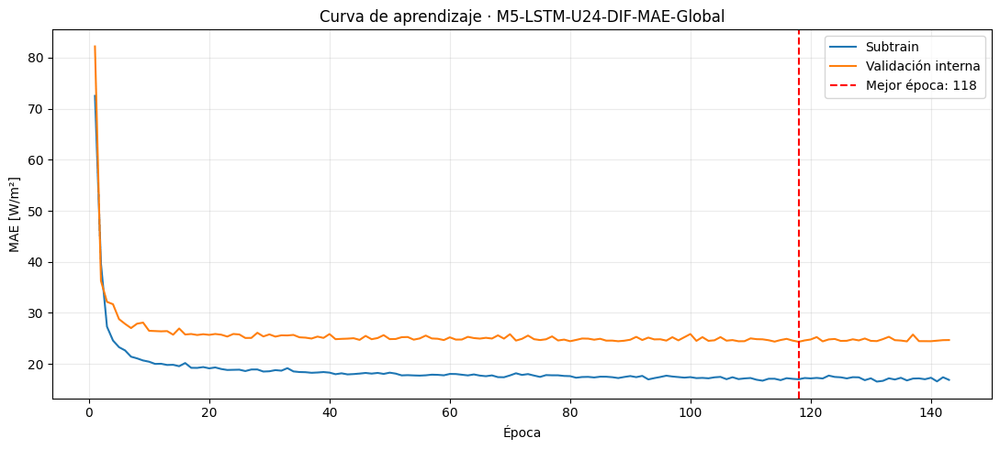

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))
plt.plot(historial_lstm["epoca"], historial_lstm["MAE_train"], label="Subtrain")
plt.plot(
    historial_lstm["epoca"], historial_lstm["MAE_validacion_interna"], label="Validación interna"
)
plt.axvline(
    mejor_epoca_lstm, color="red", linestyle="--", label=(f"Mejor época: " f"{mejor_epoca_lstm}")
)
plt.xlabel("Época")
plt.ylabel("MAE [W/m²]")
plt.title("Curva de aprendizaje · M5-LSTM-U24-DIF-MAE-Global")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [ ]:
# Reutilizamos dataset_train_final:
# - todo train;
# - ventana 24;
# - objetivo DIF;
# - escalado con todo train.
generador_lstm_final = torch.Generator()
generador_lstm_final.manual_seed(SEMILLA)
loader_train_lstm_final = DataLoader(
    dataset_train_final,
    batch_size=128,
    shuffle=True,
    generator=generador_lstm_final,
    drop_last=False,
)
modelo_lstm_final = crear_modelo_lstm()
optimizador_lstm_final = torch.optim.Adam(
    modelo_lstm_final.parameters(), lr=1e-3, weight_decay=1e-5
)
for epoca in range(1, mejor_epoca_lstm + 1):
    modelo_lstm_final.train()
    for X_lote, y_lote in loader_train_lstm_final:
        X_lote = X_lote.to(dispositivo)
        y_lote = y_lote.to(dispositivo)
        optimizador_lstm_final.zero_grad()
        prediccion = modelo_lstm_final(X_lote)
        perdida = funcion_perdida_lstm(prediccion, y_lote)
        perdida.backward()
        torch.nn.utils.clip_grad_norm_(modelo_lstm_final.parameters(), max_norm=1.0)
        optimizador_lstm_final.step()

    if epoca == 1 or epoca % 10 == 0:
        print(f"Reajuste final LSTM: " f"{epoca}/{mejor_epoca_lstm}")

print("Reajuste final LSTM completado.")

Reajuste final LSTM: 1/118
Reajuste final LSTM: 10/118
Reajuste final LSTM: 20/118
Reajuste final LSTM: 30/118
Reajuste final LSTM: 40/118
Reajuste final LSTM: 50/118
Reajuste final LSTM: 60/118
Reajuste final LSTM: 70/118
Reajuste final LSTM: 80/118
Reajuste final LSTM: 90/118
Reajuste final LSTM: 100/118
Reajuste final LSTM: 110/118
Reajuste final LSTM completado.


In [ ]:
nombre_modelo_lstm = "M5-LSTM-U24-DIF-MAE-Global"
modelo_lstm_final.eval()
tensor_validation_lstm = torch.tensor(
    X_validation_final_escalado, dtype=torch.float32, device=dispositivo
)
with torch.no_grad():
    pred_lstm_escalada = (
        modelo_lstm_final(tensor_validation_lstm).detach().cpu().numpy().reshape(-1)
    )

pred_M5_LSTM = pred_lstm_escalada * std_DIF_train_completo + media_DIF_train_completo
resultados_validation_lstm = meta_validation_nbeats.copy()
resultados_validation_lstm["instante_objetivo"] = pd.to_datetime(
    resultados_validation_lstm["instante_objetivo"], utc=True
)
resultados_validation_lstm["DIF_real"] = y_validation_nbeats
resultados_validation_lstm[nombre_modelo_lstm] = pred_M5_LSTM
resultados_validation_lstm["error_LSTM"] = (
    resultados_validation_lstm[nombre_modelo_lstm] - resultados_validation_lstm["DIF_real"]
)
resultados_validation_lstm["error_abs_LSTM"] = resultados_validation_lstm["error_LSTM"].abs()
print("PREDICCIÓN LSTM COMPLETADA")
print(f"Modelo: {nombre_modelo_lstm}")
print(f"Observaciones: " f"{len(resultados_validation_lstm):,}")
print(f"Primera hora: " f"{resultados_validation_lstm['instante_objetivo'].min()}")
print(f"Última hora: " f"{resultados_validation_lstm['instante_objetivo'].max()}")
display(
    resultados_validation_lstm[
        [
            "instante_objetivo",
            "regimen_solar_objetivo",
            "DIF_real",
            nombre_modelo_lstm,
            "error_LSTM",
        ]
    ].head()
)

PREDICCIÓN LSTM COMPLETADA
Modelo: M5-LSTM-U24-DIF-MAE-Global
Observaciones: 1,464
Primera hora: 2024-08-01 00:00:00+00:00
Última hora: 2024-09-30 23:00:00+00:00


,instante_objetivo,regimen_solar_objetivo,DIF_real,M5-LSTM-U24-DIF-MAE-Global,error_LSTM
0,2024-08-01 00:00:00+00:00,noche,-1.000000,-0.784447,0.215553
1,2024-08-01 01:00:00+00:00,noche,-1.000000,-0.786552,0.213448
2,2024-08-01 02:00:00+00:00,noche,-1.000000,-0.829376,0.170624
3,2024-08-01 03:00:00+00:00,noche,0.400000,-0.425858,-0.825858
4,2024-08-01 04:00:00+00:00,transicion,28.799999,20.636662,-8.163338


In [ ]:
comparacion_cuatro_modelos = comparacion_tres_modelos.merge(
    resultados_validation_lstm[["instante_objetivo", nombre_modelo_lstm]],
    on="instante_objetivo",
    how="left",
    validate="one_to_one",
)
modelos_comparacion_final = {
    "HGB-9V": nombre_HGB,
    "NBEATS-directo": nombre_NBEATS,
    "NBEATS-delta": nombre_modelo_delta,
    "LSTM-U24": nombre_modelo_lstm,
}
filas_metricas_cuatro = []
for regimen_actual in ["total", "operacional", "completamente_diurna", "transicion", "noche"]:
    mascara = obtener_mascara_comparacion(comparacion_cuatro_modelos, regimen_actual)
    for etiqueta, columna_pred in modelos_comparacion_final.items():
        filas_metricas_cuatro.append(
            metricas_modelo(
                comparacion_cuatro_modelos.loc[mascara, "DIF_real"],
                comparacion_cuatro_modelos.loc[mascara, columna_pred],
                etiqueta,
                regimen_actual,
            )
        )

metricas_cuatro_modelos = pd.DataFrame(filas_metricas_cuatro)
display(metricas_cuatro_modelos.round(4))

,modelo,regimen,n,media_DIF_real,mediana_DIF_real,MAE,nMAE_pct,RMSE,sesgo,R2,p95_error_absoluto,p99_error_absoluto
0,HGB-9V,total,1464,85.2333,30.5917,16.5624,19.4319,33.0427,0.0420,0.9066,71.8006,125.8068
1,NBEATS-directo,total,1464,85.2333,30.5917,18.7116,21.9534,34.1018,2.8730,0.9005,71.1930,130.3875
2,NBEATS-delta,total,1464,85.2333,30.5917,18.0398,21.1652,33.9658,1.7645,0.9013,72.4739,131.1769
3,LSTM-U24,total,1464,85.2333,30.5917,17.0423,19.9948,33.0630,-0.8732,0.9065,70.5177,126.0245
4,HGB-9V,operacional,884,141.7976,127.7333,27.3534,19.2905,42.5220,0.0465,0.8397,90.2509,166.5698
5,NBEATS-directo,operacional,884,141.7976,127.7333,29.2961,20.6605,43.7932,3.0939,0.8300,97.5571,154.5432
6,NBEATS-delta,operacional,884,141.7976,127.7333,29.1032,20.5245,43.6810,2.3605,0.8309,95.3548,158.6895
7,LSTM-U24,operacional,884,141.7976,127.7333,28.0004,19.7467,42.5473,-1.6206,0.8396,88.0505,169.3760
8,HGB-9V,completamente_diurna,765,162.7231,145.6833,31.2125,19.1814,45.6836,-0.0729,0.7866,95.1998,167.7711
9,NBEATS-directo,completamente_diurna,765,162.7231,145.6833,32.5305,19.9913,46.8920,2.3126,0.7751,99.7992,161.0472


In [ ]:
diagnostico_lstm = diagnostico_delta.merge(
    resultados_validation_lstm[["instante_objetivo", nombre_modelo_lstm]],
    on="instante_objetivo",
    how="left",
    validate="one_to_one",
)
diagnostico_lstm["error_LSTM"] = diagnostico_lstm[nombre_modelo_lstm] - diagnostico_lstm["DIF_real"]
diagnostico_lstm["error_abs_LSTM"] = diagnostico_lstm["error_LSTM"].abs()
diagnostico_lstm_operacional = diagnostico_lstm[
    diagnostico_lstm["regimen_solar_objetivo"].isin(["completamente_diurna", "transicion"])
].copy()
diagnostico_lstm_operacional["quintil_magnitud_cambio"] = pd.qcut(
    diagnostico_lstm_operacional["magnitud_cambio_DIF"], q=5, duplicates="drop"
)
filas_rampas_lstm = []
for grupo, datos in diagnostico_lstm_operacional.groupby("quintil_magnitud_cambio", observed=True):
    filas_rampas_lstm.append(
        {
            "quintil_cambio": str(grupo),
            "n": len(datos),
            "cambio_medio": datos["magnitud_cambio_DIF"].mean(),
            "MAE_HGB": datos["error_abs_HGB"].mean(),
            "MAE_NBEATS_directo": datos["error_abs_NBEATS"].mean(),
            "MAE_NBEATS_delta": datos["error_abs_NBEATS_delta"].mean(),
            "MAE_LSTM": datos["error_abs_LSTM"].mean(),
        }
    )

tabla_rampas_cuatro_modelos = pd.DataFrame(filas_rampas_lstm)
mascara_extremos_originales = diagnostico_lstm["extremo_NBEATS_p95"].astype(bool)
tabla_extremos_cuatro_modelos = pd.DataFrame(
    [
        {
            "n_extremos": int(mascara_extremos_originales.sum()),
            "MAE_HGB": diagnostico_lstm.loc[mascara_extremos_originales, "error_abs_HGB"].mean(),
            "MAE_NBEATS_directo": diagnostico_lstm.loc[
                mascara_extremos_originales, "error_abs_NBEATS"
            ].mean(),
            "MAE_NBEATS_delta": diagnostico_lstm.loc[
                mascara_extremos_originales, "error_abs_NBEATS_delta"
            ].mean(),
            "MAE_LSTM": diagnostico_lstm.loc[mascara_extremos_originales, "error_abs_LSTM"].mean(),
        }
    ]
)
print("ERROR SEGÚN LA MAGNITUD DEL CAMBIO")
display(tabla_rampas_cuatro_modelos.round(4))
print("\n74 EPISODIOS EXTREMOS ORIGINALES")
display(tabla_extremos_cuatro_modelos.round(4))

ERROR SEGÚN LA MAGNITUD DEL CAMBIO


,quintil_cambio,n,cambio_medio,MAE_HGB,MAE_NBEATS_directo,MAE_NBEATS_delta,MAE_LSTM
0,"(0.099, 12.343]",177,5.587300,14.1153,18.295200,17.254999,18.867399
1,"(12.343, 28.407]",177,20.435900,17.1132,21.612200,20.677500,19.852100
2,"(28.407, 44.61]",176,36.590599,16.9516,18.353901,18.367201,18.912701
3,"(44.61, 68.99]",177,55.230598,22.8187,21.637100,21.941999,21.831900
4,"(68.99, 301.133]",177,107.270203,65.7094,66.520500,67.213799,60.486401



74 EPISODIOS EXTREMOS ORIGINALES


,n_extremos,MAE_HGB,MAE_NBEATS_directo,MAE_NBEATS_delta,MAE_LSTM
0,74,104.0524,112.397598,111.7416,105.931999


**Resultados.** En validación, la LSTM (mejor época interna: 118, con 24,34 W/m²) obtiene un MAE de 17,04 W/m² en total y de 28,00 W/m² en operación, por debajo de ambas N-BEATS y por encima del HGB (16,56 y 27,35 W/m²), con el mismo R² operacional que este (0,84).

- Transición: 4,10 W/m², frente a 8,50 W/m² de la N-BEATS directa y 2,54 W/m² del HGB.
- Quintil de cambios más intensos: es el modelo con menor MAE (60,49 W/m², frente a 65,71 W/m² del HGB).
- En los 74 episodios extremos de la N-BEATS, su MAE (105,93 W/m²) queda próximo al del HGB (104,05 W/m²).

### 4.18 Diagnóstico comparativo de HGB, N-BEATS y LSTM

Sobre las mismas 1.464 horas de validación se comparan el HGB, la N-BEATS directa y la LSTM por contexto (régimen, mes, hora, elevación, nivel de DIF y magnitud y dirección del cambio), por su capacidad para reproducir el signo y la amplitud de los cambios y por la coincidencia de sus errores. También se calculan una media simple HGB–LSTM y un oráculo diagnóstico, que elige a posteriori la predicción con menor error, como cota de lo que podría aportar una combinación de modelos.

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score

# 1. Configuración común
UMBRAL_CAMBIO_ESTABLE = 1.0  # misma definición ya utilizada
TOLERANCIA_NUMERICA = 5e-5
modelos_principales = {
    "HGB": nombre_HGB,
    "NBEATS_directo": nombre_NBEATS,
    "LSTM": nombre_modelo_lstm,
}
modelos_secundarios = {"NBEATS_delta": nombre_modelo_delta}
modelos_todos = {**modelos_principales, **modelos_secundarios}
if "diagnostico_lstm" not in globals():
    raise NameError(
        "No existe 'diagnostico_lstm'. Ejecuta primero las celdas de comparación de la LSTM."
    )

# 2. Copia ordenada de las 1.464 horas de validation
comparativa_modelos = (
    diagnostico_lstm.copy().sort_values("instante_objetivo").reset_index(drop=True)
)
comparativa_modelos["instante_objetivo"] = pd.to_datetime(
    comparativa_modelos["instante_objetivo"], utc=True
)
columnas_obligatorias = [
    "instante_objetivo",
    "regimen_solar_objetivo",
    "DIF_real",
    "DIF_lag1",
    "cambio_DIF_real",
    "magnitud_cambio_DIF",
    "elevacion_media_objetivo",
    "banda_elevacion",
    "extremo_NBEATS_p95",
    *modelos_todos.values(),
]
columnas_ausentes = [
    columna for columna in columnas_obligatorias if columna not in comparativa_modelos.columns
]
if columnas_ausentes:
    raise KeyError("Faltan columnas necesarias:\n" f"{columnas_ausentes}")

# 3. Controles de integridad temporal
if len(comparativa_modelos) != 1464:
    raise ValueError(
        "La tabla no contiene las 1.464 horas esperadas: " f"contiene {len(comparativa_modelos)}."
    )

if comparativa_modelos["instante_objetivo"].duplicated().any():
    raise ValueError("Existen timestamps objetivo duplicados.")

if not comparativa_modelos["instante_objetivo"].is_monotonic_increasing:
    raise ValueError("Los timestamps no están ordenados.")

inicio_esperado = pd.Timestamp("2024-08-01 00:00:00", tz="UTC")
fin_esperado = pd.Timestamp("2024-09-30 23:00:00", tz="UTC")
if comparativa_modelos["instante_objetivo"].min() != inicio_esperado:
    raise ValueError("La primera hora no coincide con el inicio de validation.")

if comparativa_modelos["instante_objetivo"].max() != fin_esperado:
    raise ValueError("La última hora no coincide con el final de validation.")

diferencias_temporales = comparativa_modelos["instante_objetivo"].diff().dropna()
if not diferencias_temporales.eq(pd.Timedelta(hours=1)).all():
    raise ValueError("La serie de validation no es horaria y continua.")

cambio_recalculado = comparativa_modelos["DIF_real"] - comparativa_modelos["DIF_lag1"]
diferencia_cambio = np.max(
    np.abs(
        cambio_recalculado.to_numpy(dtype=float)
        - comparativa_modelos["cambio_DIF_real"].to_numpy(dtype=float)
    )
)
if diferencia_cambio > TOLERANCIA_NUMERICA:
    raise ValueError("cambio_DIF_real no coincide con DIF_real - DIF_lag1.")

# 4. Errores y cambios predichos
def clasificar_direccion_cambio(valores):
    valores = np.asarray(valores, dtype=float)
    return np.select(
        [valores > UMBRAL_CAMBIO_ESTABLE, valores < -UMBRAL_CAMBIO_ESTABLE],
        ["aumento", "descenso"],
        default="estable_±1",
    )

comparativa_modelos["direccion_real"] = clasificar_direccion_cambio(
    comparativa_modelos["cambio_DIF_real"]
)
for etiqueta, columna_prediccion in modelos_todos.items():
    prediccion = pd.to_numeric(comparativa_modelos[columna_prediccion], errors="coerce")
    if prediccion.isna().any():
        raise ValueError(f"El modelo {etiqueta} contiene " "predicciones ausentes.")

    if not np.isfinite(prediccion.to_numpy(dtype=float)).all():
        raise ValueError(f"El modelo {etiqueta} contiene " "predicciones no finitas.")

    # Error de nivel.
    comparativa_modelos[f"error_{etiqueta}"] = prediccion - comparativa_modelos["DIF_real"]
    comparativa_modelos[f"error_abs_{etiqueta}"] = comparativa_modelos[f"error_{etiqueta}"].abs()

    # Cambio predicho respecto a la última DIF conocida.
    comparativa_modelos[f"delta_pred_{etiqueta}"] = prediccion - comparativa_modelos["DIF_lag1"]
    comparativa_modelos[f"error_delta_{etiqueta}"] = (
        comparativa_modelos[f"delta_pred_{etiqueta}"] - comparativa_modelos["cambio_DIF_real"]
    )
    comparativa_modelos[f"direccion_pred_{etiqueta}"] = clasificar_direccion_cambio(
        comparativa_modelos[f"delta_pred_{etiqueta}"]
    )

    # Identidad algebraica:
    # error_delta = error de la predicción de nivel.
    diferencia_identidad = np.max(
        np.abs(
            comparativa_modelos[f"error_delta_{etiqueta}"].to_numpy(dtype=float)
            - comparativa_modelos[f"error_{etiqueta}"].to_numpy(dtype=float)
        )
    )
    if diferencia_identidad > TOLERANCIA_NUMERICA:
        raise ValueError(
            "No se cumple la identidad entre el " f"error de nivel y de cambio para {etiqueta}."
        )

# 5. Variables contextuales comunes
comparativa_modelos["mes"] = comparativa_modelos["instante_objetivo"].dt.strftime("%Y-%m")
comparativa_modelos["hora_UTC"] = comparativa_modelos["instante_objetivo"].dt.hour
comparativa_modelos["es_operacional"] = comparativa_modelos["regimen_solar_objetivo"].isin(
    ["completamente_diurna", "transicion"]
)
mascara_operacional = comparativa_modelos["es_operacional"]
etiquetas_quintiles = ["Q1", "Q2", "Q3", "Q4", "Q5"]
comparativa_modelos["quintil_DIF_operacional"] = pd.NA
comparativa_modelos.loc[mascara_operacional, "quintil_DIF_operacional"] = pd.qcut(
    comparativa_modelos.loc[mascara_operacional, "DIF_real"],
    q=5,
    labels=etiquetas_quintiles,
    duplicates="drop",
).astype(str)
comparativa_modelos["quintil_cambio_operacional"] = pd.NA
comparativa_modelos.loc[mascara_operacional, "quintil_cambio_operacional"] = pd.qcut(
    comparativa_modelos.loc[mascara_operacional, "magnitud_cambio_DIF"],
    q=5,
    labels=etiquetas_quintiles,
    duplicates="drop",
).astype(str)

# Modelo principal ganador en cada timestamp.
columnas_error_principales = [f"error_abs_{modelo}" for modelo in modelos_principales]
comparativa_modelos["modelo_principal_ganador"] = (
    comparativa_modelos[columnas_error_principales]
    .idxmin(axis=1)
    .str.replace("error_abs_", "", regex=False)
)

# 6. Comprobaciones finales
recuento_regimenes = comparativa_modelos["regimen_solar_objetivo"].value_counts()
recuentos_esperados = {"completamente_diurna": 765, "transicion": 119, "noche": 580}
for regimen, n_esperado in recuentos_esperados.items():
    n_observado = int(recuento_regimenes.get(regimen, 0))
    if n_observado != n_esperado:
        raise ValueError(
            f"El régimen {regimen} contiene "
            f"{n_observado} observaciones; "
            f"se esperaban {n_esperado}."
        )

n_extremos_historicos = int(comparativa_modelos["extremo_NBEATS_p95"].astype(bool).sum())
if n_extremos_historicos != 74:
    raise ValueError(
        "No se conservan los 74 extremos históricos "
        f"de N-BEATS: aparecen {n_extremos_historicos}."
    )

print("TABLA MAESTRA VALIDADA")
print("-" * 60)
print(f"Filas: {len(comparativa_modelos):,}")
print(
    "Periodo:",
    comparativa_modelos["instante_objetivo"].min(),
    "—",
    comparativa_modelos["instante_objetivo"].max(),
)
print(f"Operacional: " f"{int(mascara_operacional.sum()):,}")
print(f"Completamente diurna: " f"{recuento_regimenes['completamente_diurna']:,}")
print(f"Transición: " f"{recuento_regimenes['transicion']:,}")
print(f"Noche: " f"{recuento_regimenes['noche']:,}")
print(f"Extremos históricos N-BEATS p95: " f"{n_extremos_historicos}")
print(f"Máxima discrepancia de cambio: " f"{diferencia_cambio:.10f}")
display(
    comparativa_modelos[
        [
            "instante_objetivo",
            "regimen_solar_objetivo",
            "DIF_lag1",
            "DIF_real",
            "cambio_DIF_real",
            *modelos_principales.values(),
            "modelo_principal_ganador",
        ]
    ].head()
)

TABLA MAESTRA VALIDADA
------------------------------------------------------------
Filas: 1,464
Periodo: 2024-08-01 00:00:00+00:00 — 2024-09-30 23:00:00+00:00
Operacional: 884
Completamente diurna: 765
Transición: 119
Noche: 580
Extremos históricos N-BEATS p95: 74
Máxima discrepancia de cambio: 0.0000000000


,instante_objetivo,regimen_solar_objetivo,DIF_lag1,DIF_real,cambio_DIF_real,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global,M4-NBEATS-U24-DIF-MAE-Global,M5-LSTM-U24-DIF-MAE-Global,modelo_principal_ganador
0,2024-08-01 00:00:00+00:00,noche,-1.0,-1.000000,0.0,-0.998188,0.332359,-0.784447,HGB
1,2024-08-01 01:00:00+00:00,noche,-1.0,-1.000000,0.0,-0.998188,2.700928,-0.786552,HGB
2,2024-08-01 02:00:00+00:00,noche,-1.0,-1.000000,0.0,-0.998188,0.628242,-0.829376,HGB
3,2024-08-01 03:00:00+00:00,noche,-1.0,0.400000,1.4,-0.064409,5.544312,-0.425858,HGB
4,2024-08-01 04:00:00+00:00,transicion,0.4,28.799999,28.4,18.037250,31.430965,20.636662,NBEATS_directo


In [ ]:
from sklearn.metrics import r2_score

def calcular_metricas_contexto(datos, etiqueta_modelo):
    error = datos[f"error_{etiqueta_modelo}"].to_numpy(dtype=float)
    error_abs = np.abs(error)
    y_real = datos["DIF_real"].to_numpy(dtype=float)
    y_pred = datos[modelos_todos[etiqueta_modelo]].to_numpy(dtype=float)
    return {
        "n": len(datos),
        "DIF_media": np.mean(y_real),
        "DIF_mediana": np.median(y_real),
        "MAE": np.mean(error_abs),
        "RMSE": np.sqrt(np.mean(error**2)),
        "sesgo": np.mean(error),
        "p95_error_abs": np.quantile(error_abs, 0.95),
        "p99_error_abs": np.quantile(error_abs, 0.99),
        "R2": (r2_score(y_real, y_pred) if (len(y_real) > 1 and np.var(y_real) > 0) else np.nan),
    }

def resumir_por_contexto(df, columna_contexto, mascara, nombre_contexto, modelos=None):
    if modelos is None:
        modelos = modelos_principales

    datos_base = df.loc[mascara].copy()
    filas = []
    for valor, grupo in datos_base.groupby(
        columna_contexto, observed=True, sort=True, dropna=False
    ):
        for modelo in modelos:
            filas.append(
                {
                    "contexto": nombre_contexto,
                    "valor_contexto": str(valor),
                    "modelo": modelo,
                    **calcular_metricas_contexto(grupo, modelo),
                }
            )

    return pd.DataFrame(filas)

mascara_total = pd.Series(True, index=comparativa_modelos.index)

# El nivel de DIF y los cambios se estudian sobre la
# población operacional para evitar que la noche domine.
tablas_contexto = {
    "regimen": resumir_por_contexto(
        comparativa_modelos, "regimen_solar_objetivo", mascara_total, "régimen solar"
    ),
    "mes_operacional": resumir_por_contexto(
        comparativa_modelos, "mes", mascara_operacional, "mes · operacional"
    ),
    "hora_operacional": resumir_por_contexto(
        comparativa_modelos, "hora_UTC", mascara_operacional, "hora UTC · operacional"
    ),
    "elevacion": resumir_por_contexto(
        comparativa_modelos, "banda_elevacion", mascara_total, "banda de elevación"
    ),
    "nivel_DIF_operacional": resumir_por_contexto(
        comparativa_modelos,
        "quintil_DIF_operacional",
        mascara_operacional,
        "quintil DIF · operacional",
    ),
    "magnitud_cambio_operacional": resumir_por_contexto(
        comparativa_modelos,
        "quintil_cambio_operacional",
        mascara_operacional,
        "quintil |ΔDIF| · operacional",
    ),
    "direccion_operacional": resumir_por_contexto(
        comparativa_modelos, "direccion_real", mascara_operacional, "dirección · operacional"
    ),
}
tabla_metricas_contexto = pd.concat(tablas_contexto.values(), ignore_index=True)
for nombre, tabla in tablas_contexto.items():
    print("\n" + "=" * 70)
    print(nombre.upper())
    print("=" * 70)
    tabla_mae = tabla.pivot(index="valor_contexto", columns="modelo", values="MAE")
    display(tabla_mae.round(3))

print("\nTABLA COMPLETA EN FORMATO LARGO")
display(tabla_metricas_contexto.round(4))


REGIMEN


modelo,HGB,LSTM,NBEATS_directo
valor_contexto,,,
completamente_diurna,31.212,31.718,32.531
noche,0.115,0.341,2.579
transicion,2.545,4.102,8.504



MES_OPERACIONAL


modelo,HGB,LSTM,NBEATS_directo
valor_contexto,,,
2024-08,29.110,29.640,31.386
2024-09,25.266,26.052,26.814



HORA_OPERACIONAL


modelo,HGB,LSTM,NBEATS_directo
valor_contexto,,,
10,39.616,41.997,42.606
11,44.925,43.365,43.806
12,46.542,45.452,46.060
13,34.403,36.699,38.404
14,38.195,35.773,39.959
15,30.991,27.498,32.505
16,16.881,25.417,19.960
17,11.012,13.864,13.373
18,4.401,6.144,10.417


... (6 outputs left out)


DIRECCION_OPERACIONAL


modelo,HGB,LSTM,NBEATS_directo
valor_contexto,,,
aumento,27.450,27.432,29.396
descenso,27.688,28.627,29.382
estable_±1,18.458,28.831,25.256



TABLA COMPLETA EN FORMATO LARGO


,contexto,valor_contexto,modelo,n,DIF_media,DIF_mediana,MAE,RMSE,sesgo,p95_error_abs,p99_error_abs,R2
0,régimen solar,completamente_diurna,HGB,765,162.7231,145.6833,31.2125,45.6836,-0.0729,95.1998,167.7711,0.7866
1,régimen solar,completamente_diurna,NBEATS_directo,765,162.7231,145.6833,32.5305,46.8920,2.3126,99.7992,161.0472,0.7751
2,régimen solar,completamente_diurna,LSTM,765,162.7231,145.6833,31.7180,45.6784,-1.6524,95.7054,171.9836,0.7866
3,régimen solar,noche,HGB,580,-0.9785,-1.0000,0.1154,0.2919,0.0350,0.6703,1.3263,0.1531
4,régimen solar,noche,NBEATS_directo,580,-0.9785,-1.0000,2.5793,3.5128,2.5362,6.0826,14.3615,-121.6166
...,...,...,...,...,...,...,...,...,...,...,...,...
115,dirección · operacional,descenso,NBEATS_directo,397,124.5673,112.0000,29.3818,44.8536,24.0271,97.9729,154.1021,0.7760
116,dirección · operacional,descenso,LSTM,397,124.5673,112.0000,28.6265,43.8563,16.1653,96.1711,170.4476,0.7859
117,dirección · operacional,estable_±1,HGB,20,134.9708,121.3417,18.4583,22.9993,0.6486,39.4206,42.4432,0.9185
118,dirección · operacional,estable_±1,NBEATS_directo,20,134.9708,121.3417,25.2557,33.0385,1.8271,57.5394,64.5827,0.8318


In [ ]:
def metricas_cambio_modelo(datos, modelo, poblacion):
    delta_real = datos["cambio_DIF_real"].to_numpy(dtype=float)
    delta_pred = datos[f"delta_pred_{modelo}"].to_numpy(dtype=float)
    error_delta = delta_pred - delta_real
    direccion_real = datos["direccion_real"].astype(str).to_numpy()
    direccion_pred = datos[f"direccion_pred_{modelo}"].astype(str).to_numpy()
    mascara_aumento = delta_real > UMBRAL_CAMBIO_ESTABLE
    mascara_descenso = delta_real < -UMBRAL_CAMBIO_ESTABLE
    resultado = {
        "poblacion": poblacion,
        "modelo": modelo,
        "n": len(datos),
        # Coincide algebraicamente con el MAE de nivel.
        "MAE_delta": np.mean(np.abs(error_delta)),
        "RMSE_delta": np.sqrt(np.mean(error_delta**2)),
        "sesgo_delta": np.mean(error_delta),
        "correlacion_Pearson_delta": pd.Series(delta_real).corr(
            pd.Series(delta_pred), method="pearson"
        ),
        "correlacion_Spearman_delta": pd.Series(delta_real).corr(
            pd.Series(delta_pred), method="spearman"
        ),
        "exactitud_direccion_pct": 100 * np.mean(direccion_real == direccion_pred),
        "n_aumentos": int(mascara_aumento.sum()),
        "n_descensos": int(mascara_descenso.sum()),
    }
    if mascara_aumento.any():
        resultado.update(
            {
                "pct_aumentos_infraestimados": 100
                * np.mean(delta_pred[mascara_aumento] < delta_real[mascara_aumento]),
                "error_medio_en_aumentos": np.mean(error_delta[mascara_aumento]),
                "captura_mediana_aumentos_pct": 100
                * np.median(delta_pred[mascara_aumento] / delta_real[mascara_aumento]),
            }
        )

    if mascara_descenso.any():
        resultado.update(
            {
                # Predicción menos negativa que el descenso real.
                "pct_descensos_suavizados": 100
                * np.mean(delta_pred[mascara_descenso] > delta_real[mascara_descenso]),
                "error_medio_en_descensos": np.mean(error_delta[mascara_descenso]),
                "captura_mediana_descensos_pct": 100
                * np.median(
                    np.abs(delta_pred[mascara_descenso]) / np.abs(delta_real[mascara_descenso])
                ),
            }
        )

    return resultado

poblaciones_cambio = {
    "total": mascara_total,
    "operacional": mascara_operacional,
    "completamente_diurna": comparativa_modelos["regimen_solar_objetivo"].eq(
        "completamente_diurna"
    ),
    "transicion": comparativa_modelos["regimen_solar_objetivo"].eq("transicion"),
}
filas_cambio = []
for poblacion, mascara in poblaciones_cambio.items():
    datos = comparativa_modelos.loc[mascara].copy()
    for modelo in modelos_principales:
        filas_cambio.append(metricas_cambio_modelo(datos, modelo, poblacion))

tabla_metricas_cambio = pd.DataFrame(filas_cambio)
print("RESUMEN DE LA PREDICCIÓN DE CAMBIOS")
display(tabla_metricas_cambio.round(3))

# Matrices de dirección sobre la población operacional
orden_direcciones = ["aumento", "estable_±1", "descenso"]
matrices_direccion = {}
for modelo in modelos_principales:
    matriz = pd.crosstab(
        comparativa_modelos.loc[mascara_operacional, "direccion_real"],
        comparativa_modelos.loc[mascara_operacional, f"direccion_pred_{modelo}"],
        rownames=["dirección real"],
        colnames=["dirección predicha"],
        dropna=False,
    )
    matriz = matriz.reindex(index=orden_direcciones, columns=orden_direcciones, fill_value=0)
    matrices_direccion[modelo] = matriz
    print("\n" + "=" * 70)
    print(f"MATRIZ DE DIRECCIÓN — {modelo} " "(OPERACIONAL)")
    print("=" * 70)
    display(matriz)
    print("PORCENTAJES POR DIRECCIÓN REAL")
    display((100 * matriz.div(matriz.sum(axis=1), axis=0)).round(2))

# Resultados por quintil de magnitud del cambio
filas_quintiles_cambio = []
datos_operacionales = comparativa_modelos.loc[mascara_operacional].copy()
for quintil, datos in datos_operacionales.groupby(
    "quintil_cambio_operacional", observed=True, sort=True
):
    fila = {
        "quintil": str(quintil),
        "n": len(datos),
        "cambio_abs_medio": datos["magnitud_cambio_DIF"].mean(),
    }
    for modelo in modelos_principales:
        fila[f"MAE_{modelo}"] = datos[f"error_abs_{modelo}"].mean()
        fila[f"direccion_correcta_{modelo}_pct"] = (
            100 * (datos[f"direccion_pred_{modelo}"] == datos["direccion_real"]).mean()
        )

    filas_quintiles_cambio.append(fila)

tabla_cambio_por_quintil = pd.DataFrame(filas_quintiles_cambio)
print("\nRESULTADOS POR QUINTIL DE |ΔDIF|")
display(tabla_cambio_por_quintil.round(3))

RESUMEN DE LA PREDICCIÓN DE CAMBIOS


,poblacion,modelo,n,MAE_delta,RMSE_delta,sesgo_delta,correlacion_Pearson_delta,correlacion_Spearman_delta,exactitud_direccion_pct,n_aumentos,n_descensos,pct_aumentos_infraestimados,error_medio_en_aumentos,captura_mediana_aumentos_pct,pct_descensos_suavizados,error_medio_en_descensos,captura_mediana_descensos_pct
0,total,HGB,1464,16.562,33.043,0.042,0.711,0.730,87.227,468,451,66.026,-18.849,75.610,73.392,19.622,95.585
1,total,NBEATS_directo,1464,18.712,34.102,2.873,0.686,0.722,57.855,468,451,53.632,-14.605,86.813,80.266,21.419,76.563
2,total,LSTM,1464,17.042,33.063,-0.873,0.705,0.739,87.363,468,451,63.248,-16.706,72.702,60.089,14.256,99.457
3,operacional,HGB,884,27.353,42.522,0.046,0.710,0.757,80.769,467,397,65.953,-18.888,75.855,73.552,22.289,90.328
4,operacional,NBEATS_directo,884,29.296,43.793,3.094,0.686,0.749,81.222,467,397,53.747,-14.647,86.545,78.086,24.027,77.415
5,operacional,LSTM,884,28.000,42.547,-1.621,0.705,0.760,81.674,467,397,63.169,-16.740,72.782,58.690,16.165,101.665
6,completamente_diurna,HGB,765,31.212,45.684,-0.073,0.697,0.728,78.170,409,338,67.971,-21.644,70.478,73.964,25.995,81.695
7,completamente_diurna,NBEATS_directo,765,32.531,46.892,2.313,0.672,0.722,78.824,409,338,60.636,-17.982,76.611,75.148,26.953,75.486
8,completamente_diurna,LSTM,765,31.718,45.678,-1.652,0.691,0.734,80.915,409,338,62.592,-18.909,74.940,61.834,19.238,101.555
9,transicion,HGB,119,2.545,3.924,0.814,0.990,0.973,97.479,58,59,51.724,0.547,98.396,71.186,1.057,98.147



MATRIZ DE DIRECCIÓN — HGB (OPERACIONAL)


dirección predicha,aumento,estable_±1,descenso
dirección real,,,
aumento,402,7,58
estable_±1,12,0,8
descenso,79,6,312


PORCENTAJES POR DIRECCIÓN REAL


dirección predicha,aumento,estable_±1,descenso
dirección real,,,
aumento,86.08,1.50,12.42
estable_±1,60.00,0.00,40.00
descenso,19.90,1.51,78.59


... (6 outputs left out)

PORCENTAJES POR DIRECCIÓN REAL


dirección predicha,aumento,estable_±1,descenso
dirección real,,,
aumento,86.51,4.28,9.21
estable_±1,45.00,10.00,45.00
descenso,20.40,0.00,79.60



RESULTADOS POR QUINTIL DE |ΔDIF|


,quintil,n,cambio_abs_medio,MAE_HGB,direccion_correcta_HGB_pct,MAE_NBEATS_directo,direccion_correcta_NBEATS_directo_pct,MAE_LSTM,direccion_correcta_LSTM_pct
0,Q1,177,5.587000,14.115,62.712,18.295000,62.147,18.867001,57.062
1,Q2,177,20.436001,17.113,77.401,21.612000,79.661,19.851999,81.921
2,Q3,176,36.591000,16.952,84.659,18.354000,85.795,18.913000,85.227
3,Q4,177,55.230999,22.819,89.266,21.636999,90.960,21.832001,93.785
4,Q5,177,107.269997,65.709,89.831,66.519997,87.571,60.486000,90.395


In [ ]:
from itertools import combinations

TOLERANCIA_EMPATE = 1e-9
UMBRAL_VENTAJA_CLARA = 10.0  # W/m²

# 1. Poblaciones de análisis
poblaciones_complementariedad = {
    "total": mascara_total,
    "operacional": mascara_operacional,
    "completamente_diurna": comparativa_modelos["regimen_solar_objetivo"].eq(
        "completamente_diurna"
    ),
    "transicion": comparativa_modelos["regimen_solar_objetivo"].eq("transicion"),
    "noche": comparativa_modelos["regimen_solar_objetivo"].eq("noche"),
}
pares_modelos = list(combinations(modelos_principales.keys(), 2))

# 2. Correlación entre errores
filas_correlaciones = []
for poblacion, mascara in poblaciones_complementariedad.items():
    datos = comparativa_modelos.loc[mascara]
    for tipo_error, prefijo in {"firmado": "error_", "absoluto": "error_abs_"}.items():
        tabla_errores = pd.DataFrame(
            {
                modelo: datos[f"{prefijo}{modelo}"].to_numpy(dtype=float)
                for modelo in modelos_principales
            }
        )
        for metodo in ["pearson", "spearman"]:
            matriz = tabla_errores.corr(method=metodo)
            for modelo_1, modelo_2 in pares_modelos:
                filas_correlaciones.append(
                    {
                        "poblacion": poblacion,
                        "tipo_error": tipo_error,
                        "metodo": metodo,
                        "modelo_1": modelo_1,
                        "modelo_2": modelo_2,
                        "par": (f"{modelo_1} vs " f"{modelo_2}"),
                        "correlacion": matriz.loc[modelo_1, modelo_2],
                    }
                )

tabla_correlaciones_errores = pd.DataFrame(filas_correlaciones)
print("CORRELACIONES — POBLACIÓN OPERACIONAL")
display(
    tabla_correlaciones_errores.loc[tabla_correlaciones_errores["poblacion"].eq("operacional")]
    .pivot_table(index=["tipo_error", "metodo"], columns="par", values="correlacion")
    .round(4)
)

# 3. Modelo ganador en cada timestamp
columnas_error_abs_principales = [f"error_abs_{modelo}" for modelo in modelos_principales]
nombres_modelos_principales = np.array(list(modelos_principales.keys()))
matriz_errores_abs = comparativa_modelos[columnas_error_abs_principales].to_numpy(dtype=float)
error_minimo = matriz_errores_abs.min(axis=1)
es_minimo = np.isclose(matriz_errores_abs, error_minimo[:, None], atol=TOLERANCIA_EMPATE, rtol=0)
numero_ganadores = es_minimo.sum(axis=1)
indice_ganador = matriz_errores_abs.argmin(axis=1)
ganador = np.where(numero_ganadores == 1, nombres_modelos_principales[indice_ganador], "Empate")
errores_ordenados = np.sort(matriz_errores_abs, axis=1)
comparativa_modelos["modelo_principal_ganador"] = ganador

# Diferencia entre el segundo mejor error y el mejor.
comparativa_modelos["margen_victoria_principal"] = errores_ordenados[:, 1] - errores_ordenados[:, 0]
filas_ganadores = []
for poblacion, mascara in poblaciones_complementariedad.items():
    datos = comparativa_modelos.loc[mascara]
    recuentos = datos["modelo_principal_ganador"].value_counts()
    for modelo in [*modelos_principales.keys(), "Empate"]:
        n_ganadas = int(recuentos.get(modelo, 0))
        filas_ganadores.append(
            {
                "poblacion": poblacion,
                "modelo_ganador": modelo,
                "n_horas": n_ganadas,
                "pct_horas": 100 * n_ganadas / len(datos),
                "margen_mediano_victoria": (
                    datos.loc[
                        datos["modelo_principal_ganador"].eq(modelo), "margen_victoria_principal"
                    ].median()
                    if n_ganadas > 0
                    else np.nan
                ),
            }
        )

tabla_horas_ganadas = pd.DataFrame(filas_ganadores)
print("\nHORAS GANADAS POR CADA MODELO")
display(
    tabla_horas_ganadas.pivot(
        index="poblacion", columns="modelo_ganador", values="pct_horas"
    ).round(2)
)

# 4. Comparaciones por pares
filas_comparaciones_pares = []
filas_sensibilidad_ventaja = []
umbrales_ventaja = [5.0, 10.0, 20.0]
for poblacion, mascara in poblaciones_complementariedad.items():
    datos = comparativa_modelos.loc[mascara]
    for modelo_1, modelo_2 in pares_modelos:
        error_1 = datos[f"error_abs_{modelo_1}"].to_numpy(dtype=float)
        error_2 = datos[f"error_abs_{modelo_2}"].to_numpy(dtype=float)

        # Positivo: mejora modelo_2.
        # Negativo: mejora modelo_1.
        ventaja_modelo_2 = error_1 - error_2
        gana_1 = ventaja_modelo_2 < -TOLERANCIA_EMPATE
        gana_2 = ventaja_modelo_2 > TOLERANCIA_EMPATE
        empate = ~(gana_1 | gana_2)
        filas_comparaciones_pares.append(
            {
                "poblacion": poblacion,
                "modelo_1": modelo_1,
                "modelo_2": modelo_2,
                "n": len(datos),
                f"pct_gana_{modelo_1}": 100 * gana_1.mean(),
                f"pct_gana_{modelo_2}": 100 * gana_2.mean(),
                "pct_empate": 100 * empate.mean(),
                f"ventaja_media_{modelo_2}_Wm2": ventaja_modelo_2.mean(),
                f"ventaja_mediana_{modelo_2}_Wm2": np.median(ventaja_modelo_2),
                "p10_ventaja_modelo_2": np.quantile(ventaja_modelo_2, 0.10),
                "p90_ventaja_modelo_2": np.quantile(ventaja_modelo_2, 0.90),
            }
        )
        for umbral in umbrales_ventaja:
            claro_1 = ventaja_modelo_2 <= -umbral
            claro_2 = ventaja_modelo_2 >= umbral
            diferencia_menor = ~(claro_1 | claro_2)
            filas_sensibilidad_ventaja.append(
                {
                    "poblacion": poblacion,
                    "modelo_1": modelo_1,
                    "modelo_2": modelo_2,
                    "umbral_Wm2": umbral,
                    f"pct_ventaja_clara_{modelo_1}": 100 * claro_1.mean(),
                    f"pct_ventaja_clara_{modelo_2}": 100 * claro_2.mean(),
                    "pct_diferencia_menor_umbral": 100 * diferencia_menor.mean(),
                }
            )

tabla_comparaciones_pares = pd.DataFrame(filas_comparaciones_pares)
tabla_sensibilidad_ventaja = pd.DataFrame(filas_sensibilidad_ventaja)
print("\nCOMPARACIÓN DIRECTA HGB FRENTE A LSTM")
columnas_hgb_lstm = [
    "poblacion",
    "n",
    "pct_gana_HGB",
    "pct_gana_LSTM",
    "pct_empate",
    "ventaja_media_LSTM_Wm2",
    "ventaja_mediana_LSTM_Wm2",
    "p10_ventaja_modelo_2",
    "p90_ventaja_modelo_2",
]
display(
    tabla_comparaciones_pares.loc[
        tabla_comparaciones_pares["modelo_1"].eq("HGB")
        & tabla_comparaciones_pares["modelo_2"].eq("LSTM"),
        columnas_hgb_lstm,
    ].round(3)
)
print("\nSENSIBILIDAD DEL UMBRAL DE VENTAJA HGB–LSTM")
display(
    tabla_sensibilidad_ventaja.loc[
        tabla_sensibilidad_ventaja["modelo_1"].eq("HGB")
        & tabla_sensibilidad_ventaja["modelo_2"].eq("LSTM")
    ].round(3)
)

# 5. Contexto de las ventajas HGB–LSTM
comparativa_modelos["ventaja_LSTM_sobre_HGB"] = (
    comparativa_modelos["error_abs_HGB"] - comparativa_modelos["error_abs_LSTM"]
)
comparativa_modelos["clase_ventaja_HGB_LSTM"] = np.select(
    [
        comparativa_modelos["ventaja_LSTM_sobre_HGB"] >= UMBRAL_VENTAJA_CLARA,
        comparativa_modelos["ventaja_LSTM_sobre_HGB"] <= -UMBRAL_VENTAJA_CLARA,
    ],
    ["LSTM_mejora_≥10", "HGB_mejora_≥10"],
    default="diferencia_<10",
)

def resumir_ventaja_por_contexto(df, columna_contexto, mascara, nombre_contexto):
    filas = []
    datos_base = df.loc[mascara].copy()
    for valor, datos in datos_base.groupby(
        columna_contexto, observed=True, sort=True, dropna=False
    ):
        ventaja = datos["ventaja_LSTM_sobre_HGB"].to_numpy(dtype=float)
        filas.append(
            {
                "contexto": nombre_contexto,
                "valor_contexto": str(valor),
                "n": len(datos),
                "MAE_HGB": datos["error_abs_HGB"].mean(),
                "MAE_LSTM": datos["error_abs_LSTM"].mean(),
                "ventaja_media_LSTM": ventaja.mean(),
                "pct_gana_LSTM": 100 * np.mean(ventaja > 0),
                "pct_LSTM_mejora_≥10": 100 * np.mean(ventaja >= UMBRAL_VENTAJA_CLARA),
                "pct_HGB_mejora_≥10": 100 * np.mean(ventaja <= -UMBRAL_VENTAJA_CLARA),
            }
        )

    return pd.DataFrame(filas)

tablas_contexto_ventaja = {
    "regimen": resumir_ventaja_por_contexto(
        comparativa_modelos, "regimen_solar_objetivo", mascara_total, "régimen"
    ),
    "mes_operacional": resumir_ventaja_por_contexto(
        comparativa_modelos, "mes", mascara_operacional, "mes · operacional"
    ),
    "hora_operacional": resumir_ventaja_por_contexto(
        comparativa_modelos, "hora_UTC", mascara_operacional, "hora UTC · operacional"
    ),
    "elevacion": resumir_ventaja_por_contexto(
        comparativa_modelos, "banda_elevacion", mascara_total, "elevación"
    ),
    "nivel_DIF_operacional": resumir_ventaja_por_contexto(
        comparativa_modelos,
        "quintil_DIF_operacional",
        mascara_operacional,
        "nivel DIF · operacional",
    ),
    "cambio_operacional": resumir_ventaja_por_contexto(
        comparativa_modelos,
        "quintil_cambio_operacional",
        mascara_operacional,
        "|ΔDIF| · operacional",
    ),
    "direccion_operacional": resumir_ventaja_por_contexto(
        comparativa_modelos, "direccion_real", mascara_operacional, "dirección · operacional"
    ),
}
tabla_contexto_ventajas = pd.concat(tablas_contexto_ventaja.values(), ignore_index=True)
for nombre, tabla in tablas_contexto_ventaja.items():
    print("\n" + "=" * 70)
    print("VENTAJA LSTM FRENTE A HGB —", nombre.upper())
    print("=" * 70)
    display(tabla.round(3))

# 6. Casos con mayor diferencia HGB–LSTM
columnas_casos = [
    "instante_objetivo",
    "regimen_solar_objetivo",
    "banda_elevacion",
    "DIF_lag1",
    "DIF_real",
    "cambio_DIF_real",
    nombre_HGB,
    nombre_NBEATS,
    nombre_modelo_lstm,
    "error_abs_HGB",
    "error_abs_NBEATS_directo",
    "error_abs_LSTM",
    "direccion_real",
    "modelo_principal_ganador",
    "ventaja_LSTM_sobre_HGB",
]
casos_mayor_ventaja_LSTM = (
    comparativa_modelos.loc[mascara_operacional, columnas_casos]
    .sort_values("ventaja_LSTM_sobre_HGB", ascending=False)
    .head(30)
    .reset_index(drop=True)
)
casos_mayor_ventaja_HGB = (
    comparativa_modelos.loc[mascara_operacional, columnas_casos]
    .sort_values("ventaja_LSTM_sobre_HGB", ascending=True)
    .head(30)
    .reset_index(drop=True)
)
print("\n15 CASOS DONDE MÁS MEJORA LSTM")
display(casos_mayor_ventaja_LSTM.head(15).round(3))
print("\n15 CASOS DONDE MÁS MEJORA HGB")
display(casos_mayor_ventaja_HGB.head(15).round(3))

CORRELACIONES — POBLACIÓN OPERACIONAL


par                  HGB vs LSTM  HGB vs NBEATS_directo  \
tipo_error metodo                                         
absoluto   pearson        0.9141                 0.9044   
           spearman       0.7850                 0.7390   
firmado    pearson        0.9395                 0.9338   
           spearman       0.8895                 0.8660   

par                  NBEATS_directo vs LSTM  
tipo_error metodo                            
absoluto   pearson                   0.9248  
           spearman                  0.7515  
firmado    pearson                   0.9556  
           spearman                  0.9133


HORAS GANADAS POR CADA MODELO


modelo_ganador,Empate,HGB,LSTM,NBEATS_directo
poblacion,,,,
completamente_diurna,0.0,38.56,30.07,31.37
noche,0.0,89.14,10.17,0.69
operacional,0.0,41.52,30.32,28.17
total,0.0,60.38,22.34,17.28
transicion,0.0,60.50,31.93,7.56



COMPARACIÓN DIRECTA HGB FRENTE A LSTM


,poblacion,n,pct_gana_HGB,pct_gana_LSTM,pct_empate,ventaja_media_LSTM_Wm2,ventaja_mediana_LSTM_Wm2,p10_ventaja_modelo_2,p90_ventaja_modelo_2
1,total,1464,69.057,30.943,0.0,-0.480,-0.281,-11.051,9.626
4,operacional,884,55.430,44.570,0.0,-0.647,-0.790,-14.608,15.427
7,completamente_diurna,765,53.595,46.405,0.0,-0.505,-0.776,-15.394,16.306
10,transicion,119,67.227,32.773,0.0,-1.557,-0.965,-6.378,1.924
13,noche,580,89.828,10.172,0.0,-0.225,-0.268,-0.383,0.001


... (16 outputs left out)


15 CASOS DONDE MÁS MEJORA LSTM


,instante_objetivo,regimen_solar_objetivo,banda_elevacion,DIF_lag1,DIF_real,cambio_DIF_real,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global,M4-NBEATS-U24-DIF-MAE-Global,M5-LSTM-U24-DIF-MAE-Global,error_abs_HGB,error_abs_NBEATS_directo,error_abs_LSTM,direccion_real,modelo_principal_ganador,ventaja_LSTM_sobre_HGB
0,2024-09-11 15:00:00+00:00,completamente_diurna,20–30°,165.182999,45.349998,-119.833000,137.488,97.436996,71.408997,92.138,52.087002,26.059000,descenso,LSTM,66.079
1,2024-08-13 08:00:00+00:00,completamente_diurna,30–40°,290.916992,329.282990,38.367001,272.936,311.058990,329.290985,56.348,18.224001,0.008000,aumento,LSTM,56.340
2,2024-08-04 08:00:00+00:00,completamente_diurna,30–40°,258.149994,329.750000,71.599998,246.281,300.226990,298.312988,83.469,29.523001,31.437000,aumento,NBEATS_directo,52.032
3,2024-08-03 08:00:00+00:00,completamente_diurna,30–40°,271.333008,330.899994,59.567001,260.210,303.634003,306.962006,70.690,27.266001,23.938999,aumento,LSTM,46.752
4,2024-09-07 14:00:00+00:00,completamente_diurna,30–40°,175.382996,139.800003,-35.583000,204.428,171.313995,161.654999,64.628,31.514000,21.855000,descenso,LSTM,42.773
5,2024-09-07 09:00:00+00:00,completamente_diurna,30–40°,258.483002,291.399994,32.917000,246.732,294.627014,289.362000,44.668,3.227000,2.038000,aumento,LSTM,42.630
6,2024-08-02 12:00:00+00:00,completamente_diurna,≥40°,507.100006,433.967010,-73.133003,389.522,451.994995,430.963989,44.444,18.028999,3.002000,descenso,LSTM,41.442
7,2024-08-20 14:00:00+00:00,completamente_diurna,30–40°,147.550003,87.883003,-59.667000,147.861,151.223999,106.820000,59.977,63.341000,18.937000,descenso,LSTM,41.041
8,2024-09-28 14:00:00+00:00,completamente_diurna,20–30°,223.983002,113.383003,-110.599998,182.067,145.544998,141.479004,68.684,32.160999,28.094999,descenso,LSTM,40.589
9,2024-08-04 07:00:00+00:00,completamente_diurna,20–30°,187.000000,258.149994,71.150002,218.188,240.718002,258.058014,39.962,17.431999,0.092000,aumento,LSTM,39.869



15 CASOS DONDE MÁS MEJORA HGB


,instante_objetivo,regimen_solar_objetivo,banda_elevacion,DIF_lag1,DIF_real,cambio_DIF_real,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global,M4-NBEATS-U24-DIF-MAE-Global,M5-LSTM-U24-DIF-MAE-Global,error_abs_HGB,error_abs_NBEATS_directo,error_abs_LSTM,direccion_real,modelo_principal_ganador,ventaja_LSTM_sobre_HGB
0,2024-09-18 10:00:00+00:00,completamente_diurna,30–40°,280.372986,192.949997,-87.422997,237.920,292.531006,298.421997,44.970,99.581001,105.472000,descenso,HGB,-60.502
1,2024-08-21 16:00:00+00:00,completamente_diurna,20–30°,171.617004,121.733002,-49.882999,116.159,107.282997,58.317001,5.575,14.450000,63.417000,descenso,HGB,-57.842
2,2024-08-14 08:00:00+00:00,completamente_diurna,30–40°,286.644012,280.132996,-6.511000,273.084,315.218994,339.731995,7.049,35.085999,59.598999,descenso,HGB,-52.550
3,2024-08-25 16:00:00+00:00,completamente_diurna,10–20°,167.667007,127.817001,-39.849998,124.586,112.213997,73.072998,3.231,15.603000,54.743999,descenso,HGB,-51.513
4,2024-09-10 09:00:00+00:00,completamente_diurna,30–40°,264.149994,183.733002,-80.417000,250.780,289.226990,296.309998,67.047,105.492996,112.577003,descenso,HGB,-45.530
5,2024-09-28 13:00:00+00:00,completamente_diurna,30–40°,204.182999,223.983002,19.799999,203.160,150.520004,165.026001,20.824,73.462997,58.957001,aumento,HGB,-38.134
6,2024-09-28 15:00:00+00:00,completamente_diurna,10–20°,113.383003,111.467003,-1.917000,89.081,71.848000,52.511002,22.386,39.618999,58.956001,descenso,HGB,-36.570
7,2024-08-26 09:00:00+00:00,completamente_diurna,≥40°,273.899994,241.699997,-32.200001,269.990,310.563995,305.917999,28.290,68.863998,64.218002,descenso,HGB,-35.928
8,2024-08-04 16:00:00+00:00,completamente_diurna,20–30°,216.399994,235.149994,18.750000,166.444,150.927002,130.774002,68.706,84.223000,104.375999,aumento,HGB,-35.670
9,2024-09-05 16:00:00+00:00,completamente_diurna,10–20°,127.432999,92.667000,-34.766998,92.849,81.055000,58.428001,0.183,11.612000,34.238998,descenso,HGB,-34.057


In [ ]:
from sklearn.metrics import r2_score

# 1. Media simple HGB–LSTM
comparativa_modelos["pred_media_HGB_LSTM"] = (
    comparativa_modelos[nombre_HGB] + comparativa_modelos[nombre_modelo_lstm]
) / 2.0
comparativa_modelos["error_Media_HGB_LSTM"] = (
    comparativa_modelos["pred_media_HGB_LSTM"] - comparativa_modelos["DIF_real"]
)
comparativa_modelos["error_abs_Media_HGB_LSTM"] = comparativa_modelos["error_Media_HGB_LSTM"].abs()

# 2. Oráculo entre los tres modelos principales
# El oráculo selecciona a posteriori la predicción con menor
# error absoluto. No es un modelo utilizable en producción.
columnas_prediccion_principales = [modelos_principales[modelo] for modelo in modelos_principales]
matriz_predicciones = comparativa_modelos[columnas_prediccion_principales].to_numpy(dtype=float)
matriz_errores_absolutos = np.abs(
    matriz_predicciones - comparativa_modelos["DIF_real"].to_numpy(dtype=float)[:, None]
)
indice_oraculo = matriz_errores_absolutos.argmin(axis=1)
comparativa_modelos["pred_oraculo_principales"] = matriz_predicciones[
    np.arange(len(comparativa_modelos)), indice_oraculo
]
comparativa_modelos["modelo_elegido_oraculo"] = np.array(list(modelos_principales.keys()))[
    indice_oraculo
]
comparativa_modelos["error_Oraculo"] = (
    comparativa_modelos["pred_oraculo_principales"] - comparativa_modelos["DIF_real"]
)
comparativa_modelos["error_abs_Oraculo"] = comparativa_modelos["error_Oraculo"].abs()

# 3. Configuración de modelos evaluados
predicciones_combinacion = {
    "HGB": nombre_HGB,
    "NBEATS_directo": nombre_NBEATS,
    "LSTM": nombre_modelo_lstm,
    "Media_HGB_LSTM": "pred_media_HGB_LSTM",
    "Oraculo": "pred_oraculo_principales",
}

# 4. Función común de métricas
def metricas_prediccion_generica(datos, columna_prediccion, modelo, poblacion):
    y_real = datos["DIF_real"].to_numpy(dtype=float)
    y_pred = datos[columna_prediccion].to_numpy(dtype=float)
    error = y_pred - y_real
    error_abs = np.abs(error)
    return {
        "poblacion": poblacion,
        "modelo": modelo,
        "n": len(datos),
        "DIF_media": np.mean(y_real),
        "MAE": np.mean(error_abs),
        "RMSE": np.sqrt(np.mean(error**2)),
        "sesgo": np.mean(error),
        "R2": (r2_score(y_real, y_pred) if (len(y_real) > 1 and np.var(y_real) > 0) else np.nan),
        "p50_error_abs": np.quantile(error_abs, 0.50),
        "p90_error_abs": np.quantile(error_abs, 0.90),
        "p95_error_abs": np.quantile(error_abs, 0.95),
        "p99_error_abs": np.quantile(error_abs, 0.99),
    }


# 5. Métricas generales y por régimen
filas_metricas_combinacion = []
for poblacion, mascara in poblaciones_complementariedad.items():
    datos = comparativa_modelos.loc[mascara]
    for modelo, columna_prediccion in predicciones_combinacion.items():
        filas_metricas_combinacion.append(
            metricas_prediccion_generica(datos, columna_prediccion, modelo, poblacion)
        )

tabla_metricas_combinacion = pd.DataFrame(filas_metricas_combinacion)
print("MAE — MODELOS, MEDIA Y ORÁCULO")
display(
    tabla_metricas_combinacion.pivot(index="poblacion", columns="modelo", values="MAE").round(3)
)
print("\nRMSE")
display(
    tabla_metricas_combinacion.pivot(index="poblacion", columns="modelo", values="RMSE").round(3)
)
print("\nP95 DEL ERROR ABSOLUTO")
display(
    tabla_metricas_combinacion.pivot(
        index="poblacion", columns="modelo", values="p95_error_abs"
    ).round(3)
)
print("\nP99 DEL ERROR ABSOLUTO")
display(
    tabla_metricas_combinacion.pivot(
        index="poblacion", columns="modelo", values="p99_error_abs"
    ).round(3)
)

# 6. Mejora frente al mejor modelo individual
filas_limite_combinacion = []
for poblacion, mascara in poblaciones_complementariedad.items():
    metricas_poblacion = tabla_metricas_combinacion.loc[
        tabla_metricas_combinacion["poblacion"].eq(poblacion)
    ].set_index("modelo")
    modelos_individuales = ["HGB", "NBEATS_directo", "LSTM"]
    mae_individuales = metricas_poblacion.loc[modelos_individuales, "MAE"]
    mejor_modelo_individual = mae_individuales.idxmin()
    mejor_mae_individual = mae_individuales.min()
    mae_media = metricas_poblacion.loc["Media_HGB_LSTM", "MAE"]
    mae_oraculo = metricas_poblacion.loc["Oraculo", "MAE"]
    filas_limite_combinacion.append(
        {
            "poblacion": poblacion,
            "mejor_modelo_individual": mejor_modelo_individual,
            "MAE_mejor_individual": mejor_mae_individual,
            "MAE_media_HGB_LSTM": mae_media,
            "mejora_media_Wm2": mejor_mae_individual - mae_media,
            "mejora_media_pct": 100 * (mejor_mae_individual - mae_media) / mejor_mae_individual,
            "MAE_oraculo": mae_oraculo,
            "mejora_oraculo_Wm2": mejor_mae_individual - mae_oraculo,
            "mejora_oraculo_pct": 100 * (mejor_mae_individual - mae_oraculo) / mejor_mae_individual,
            "brecha_media_hasta_oraculo": mae_media - mae_oraculo,
        }
    )

tabla_limite_combinacion = pd.DataFrame(filas_limite_combinacion)
print("\nMEJORA DE LA MEDIA Y LÍMITE DIAGNÓSTICO DEL ORÁCULO")
display(tabla_limite_combinacion.round(3))

# 7. ¿Con qué frecuencia mejora la media?
filas_aportacion_media = []
for poblacion, mascara in poblaciones_complementariedad.items():
    datos = comparativa_modelos.loc[mascara]
    error_hgb = datos["error_abs_HGB"].to_numpy(dtype=float)
    error_lstm = datos["error_abs_LSTM"].to_numpy(dtype=float)
    error_media = datos["error_abs_Media_HGB_LSTM"].to_numpy(dtype=float)
    mejor_individual_hgb_lstm = np.minimum(error_hgb, error_lstm)
    peor_individual_hgb_lstm = np.maximum(error_hgb, error_lstm)
    filas_aportacion_media.append(
        {
            "poblacion": poblacion,
            "n": len(datos),
            "pct_media_mejora_HGB": 100 * np.mean(error_media < error_hgb),
            "pct_media_mejora_LSTM": 100 * np.mean(error_media < error_lstm),
            "pct_media_mejora_ambos": 100 * np.mean(error_media < mejor_individual_hgb_lstm),
            "pct_media_peor_que_ambos": 100 * np.mean(error_media > peor_individual_hgb_lstm),
            "ventaja_media_sobre_HGB": np.mean(error_hgb - error_media),
            "ventaja_media_sobre_LSTM": np.mean(error_lstm - error_media),
        }
    )

tabla_aportacion_media = pd.DataFrame(filas_aportacion_media)
print("\nFRECUENCIA CON LA QUE LA MEDIA MEJORA LOS MODELOS INDIVIDUALES")
display(tabla_aportacion_media.round(3))

# 8. Media y oráculo por magnitud del cambio
filas_combinacion_cambio = []
datos_operacionales = comparativa_modelos.loc[mascara_operacional]
for quintil, datos in datos_operacionales.groupby(
    "quintil_cambio_operacional", observed=True, sort=True
):
    fila = {
        "quintil_cambio": str(quintil),
        "n": len(datos),
        "cambio_abs_medio": datos["magnitud_cambio_DIF"].mean(),
    }
    for modelo, columna_prediccion in predicciones_combinacion.items():
        error_abs = np.abs(datos[columna_prediccion] - datos["DIF_real"])
        fila[f"MAE_{modelo}"] = error_abs.mean()

    filas_combinacion_cambio.append(fila)

tabla_combinacion_por_cambio = pd.DataFrame(filas_combinacion_cambio)
print("\nMEDIA Y ORÁCULO POR QUINTIL DE |ΔDIF|")
display(tabla_combinacion_por_cambio.round(3))

# 9. Media y oráculo por régimen
filas_combinacion_regimen = []
for regimen, datos in comparativa_modelos.groupby(
    "regimen_solar_objetivo", observed=True, sort=True
):
    fila = {"regimen": str(regimen), "n": len(datos)}
    for modelo, columna_prediccion in predicciones_combinacion.items():
        fila[f"MAE_{modelo}"] = np.mean(np.abs(datos[columna_prediccion] - datos["DIF_real"]))

    filas_combinacion_regimen.append(fila)

tabla_combinacion_por_regimen = pd.DataFrame(filas_combinacion_regimen)
print("\nMEDIA Y ORÁCULO POR RÉGIMEN")
display(tabla_combinacion_por_regimen.round(3))

MAE — MODELOS, MEDIA Y ORÁCULO


modelo,HGB,LSTM,Media_HGB_LSTM,NBEATS_directo,Oraculo
poblacion,,,,,
completamente_diurna,31.212,31.718,30.866,32.531,24.072
noche,0.115,0.341,0.221,2.579,0.095
operacional,27.353,28.000,27.102,29.296,21.051
total,16.562,17.042,16.452,18.712,12.749
transicion,2.545,4.102,2.907,8.504,1.626



RMSE


modelo,HGB,LSTM,Media_HGB_LSTM,NBEATS_directo,Oraculo
poblacion,,,,,
completamente_diurna,45.684,45.678,44.987,46.892,39.754
noche,0.292,0.436,0.337,3.513,0.266
operacional,42.522,42.547,41.879,43.793,36.993
total,33.043,33.063,32.543,34.102,28.746
transicion,3.924,5.864,4.263,10.550,2.458



P95 DEL ERROR ABSOLUTO


modelo,HGB,LSTM,Media_HGB_LSTM,NBEATS_directo,Oraculo
poblacion,,,,,
completamente_diurna,95.200,95.705,93.064,99.799,84.986
noche,0.670,0.781,0.700,6.083,0.520
operacional,90.251,88.051,88.648,97.557,79.768
total,71.801,70.518,69.639,71.193,60.913
transicion,9.057,12.584,9.497,22.108,5.949


... (6 outputs left out)


MEDIA Y ORÁCULO POR QUINTIL DE |ΔDIF|


,quintil_cambio,n,cambio_abs_medio,MAE_HGB,MAE_NBEATS_directo,MAE_LSTM,MAE_Media_HGB_LSTM,MAE_Oraculo
0,Q1,177,5.587000,14.115,18.295000,18.867001,16.017,10.428
1,Q2,177,20.436001,17.113,21.612000,19.851999,17.562,12.981
2,Q3,176,36.591000,16.952,18.354000,18.913000,17.429,11.659
3,Q4,177,55.230999,22.819,21.636999,21.832001,21.563,15.075
4,Q5,177,107.269997,65.709,66.519997,60.486000,62.884,55.056



MEDIA Y ORÁCULO POR RÉGIMEN


,regimen,n,MAE_HGB,MAE_NBEATS_directo,MAE_LSTM,MAE_Media_HGB_LSTM,MAE_Oraculo
0,completamente_diurna,765,31.212,32.530998,31.718,30.866,24.072
1,noche,580,0.115,2.579000,0.341,0.221,0.095
2,transicion,119,2.545,8.504000,4.102,2.907,1.626


In [ ]:
# 1. Umbrales p99 propios de cada modelo
# Cada modelo se considera extremo según el p99 de su propia
# distribución de errores. Así la comparación es simétrica.
poblaciones_p99 = {"total": mascara_total, "operacional": mascara_operacional}
filas_umbrales_p99 = []
for poblacion, mascara in poblaciones_p99.items():
    for modelo in modelos_principales:
        columna_error = f"error_abs_{modelo}"
        umbral = comparativa_modelos.loc[mascara, columna_error].quantile(0.99)
        columna_extremo = f"p99_{poblacion}_{modelo}"
        comparativa_modelos[columna_extremo] = mascara & (
            comparativa_modelos[columna_error] >= umbral
        )
        filas_umbrales_p99.append(
            {
                "poblacion": poblacion,
                "modelo": modelo,
                "n_poblacion": int(mascara.sum()),
                "umbral_p99_Wm2": umbral,
                "n_extremos": int(comparativa_modelos[columna_extremo].sum()),
            }
        )

tabla_umbrales_p99 = pd.DataFrame(filas_umbrales_p99)
print("UMBRALES P99 PROPIOS")
display(tabla_umbrales_p99.round(3))

# 2. Patrones de coincidencia de extremos
def crear_patron_extremos(fila, poblacion):
    modelos_extremos = []
    for modelo in modelos_principales:
        if fila[f"p99_{poblacion}_{modelo}"]:
            modelos_extremos.append(modelo)

    if not modelos_extremos:
        return "no_p99"

    return "+".join(modelos_extremos)

for poblacion in poblaciones_p99:
    comparativa_modelos[f"patron_p99_{poblacion}"] = comparativa_modelos.apply(
        crear_patron_extremos, axis=1, poblacion=poblacion
    )

filas_patrones_p99 = []
for poblacion, mascara in poblaciones_p99.items():
    columna_patron = f"patron_p99_{poblacion}"
    datos_extremos = comparativa_modelos.loc[
        mascara & comparativa_modelos[columna_patron].ne("no_p99")
    ]
    for patron, datos in datos_extremos.groupby(columna_patron, observed=True, sort=True):
        filas_patrones_p99.append(
            {
                "poblacion": poblacion,
                "patron_extremo": patron,
                "n": len(datos),
                "pct_union_extremos": 100 * len(datos) / len(datos_extremos),
                "cambio_abs_medio": datos["magnitud_cambio_DIF"].mean(),
                "DIF_media": datos["DIF_real"].mean(),
                "MAE_HGB": datos["error_abs_HGB"].mean(),
                "MAE_NBEATS_directo": datos["error_abs_NBEATS_directo"].mean(),
                "MAE_LSTM": datos["error_abs_LSTM"].mean(),
            }
        )

tabla_patrones_p99 = pd.DataFrame(filas_patrones_p99)
print("\nSOLAPAMIENTO DE EXTREMOS P99")
display(tabla_patrones_p99.round(3))

# 3. Detalle de extremos p99 operacionales
columnas_p99_operacional = [f"p99_operacional_{modelo}" for modelo in modelos_principales]
mascara_union_p99_operacional = comparativa_modelos[columnas_p99_operacional].any(axis=1)
columnas_detalle_extremos = [
    "instante_objetivo",
    "regimen_solar_objetivo",
    "banda_elevacion",
    "DIF_lag1",
    "DIF_real",
    "cambio_DIF_real",
    "magnitud_cambio_DIF",
    nombre_HGB,
    nombre_NBEATS,
    nombre_modelo_lstm,
    "error_abs_HGB",
    "error_abs_NBEATS_directo",
    "error_abs_LSTM",
    "direccion_real",
    "modelo_principal_ganador",
    "patron_p99_operacional",
    *columnas_p99_operacional,
]
tabla_extremos_p99_operacional = (
    comparativa_modelos.loc[mascara_union_p99_operacional, columnas_detalle_extremos]
    .sort_values(["patron_p99_operacional", "magnitud_cambio_DIF"], ascending=[True, False])
    .reset_index(drop=True)
)
print("\nDETALLE DE LA UNIÓN DE EXTREMOS P99 OPERACIONALES")
display(tabla_extremos_p99_operacional.round(3))

# 4. Agrupar extremos consecutivos en episodios
episodios_p99_operacional = tabla_extremos_p99_operacional.sort_values("instante_objetivo").copy()
if len(episodios_p99_operacional) > 0:
    nuevo_episodio = episodios_p99_operacional["instante_objetivo"].diff().ne(pd.Timedelta(hours=1))
    episodios_p99_operacional["id_episodio_p99"] = nuevo_episodio.cumsum()
    tabla_episodios_p99 = episodios_p99_operacional.groupby("id_episodio_p99", as_index=False).agg(
        inicio=("instante_objetivo", "min"),
        fin=("instante_objetivo", "max"),
        n_horas=("instante_objetivo", "size"),
        cambio_abs_maximo=("magnitud_cambio_DIF", "max"),
        error_max_HGB=("error_abs_HGB", "max"),
        error_max_NBEATS=("error_abs_NBEATS_directo", "max"),
        error_max_LSTM=("error_abs_LSTM", "max"),
    )

else:
    tabla_episodios_p99 = pd.DataFrame()

print("\nEPISODIOS P99 OPERACIONALES")
display(tabla_episodios_p99.round(3))

# 5. Mantener separados los 74 extremos históricos
mascara_extremos_legacy = comparativa_modelos["extremo_NBEATS_p95"].astype(bool)
filas_extremos_legacy = []
for modelo in modelos_todos:
    datos = comparativa_modelos.loc[mascara_extremos_legacy]
    filas_extremos_legacy.append(
        {
            "modelo": modelo,
            "n_extremos_legacy": len(datos),
            "MAE": datos[f"error_abs_{modelo}"].mean(),
            "RMSE": np.sqrt(np.mean(datos[f"error_{modelo}"].to_numpy(dtype=float) ** 2)),
            "sesgo": datos[f"error_{modelo}"].mean(),
            "p95_error_abs": datos[f"error_abs_{modelo}"].quantile(0.95),
        }
    )

tabla_extremos_legacy = pd.DataFrame(filas_extremos_legacy)
print("\n74 EXTREMOS HISTÓRICOS BASADOS EN N-BEATS DIRECTO")
display(tabla_extremos_legacy.round(3))

# 6. Grandes rampas reales
# Se consideran grandes rampas las pertenecientes al 5 %
# superior de |ΔDIF| dentro de la población operacional.
umbral_gran_rampa = comparativa_modelos.loc[mascara_operacional, "magnitud_cambio_DIF"].quantile(
    0.95
)
comparativa_modelos["gran_rampa_p95_operacional"] = mascara_operacional & (
    comparativa_modelos["magnitud_cambio_DIF"] >= umbral_gran_rampa
)
mascara_grandes_rampas = comparativa_modelos["gran_rampa_p95_operacional"]
comparativa_modelos["LSTM_gana_gran_rampa"] = mascara_grandes_rampas & comparativa_modelos[
    "modelo_principal_ganador"
].eq("LSTM")
comparativa_modelos["LSTM_signo_correcto_gran_rampa"] = mascara_grandes_rampas & (
    comparativa_modelos["direccion_pred_LSTM"] == comparativa_modelos["direccion_real"]
)
print(f"\nUmbral de gran rampa operacional: " f"{umbral_gran_rampa:.3f} W/m²")
print("Número de grandes rampas:", int(mascara_grandes_rampas.sum()))

# 7. Resumen de grandes rampas
filas_grandes_rampas = []
datos_grandes_rampas = comparativa_modelos.loc[mascara_grandes_rampas]
for direccion, datos in datos_grandes_rampas.groupby("direccion_real", observed=True, sort=True):
    fila = {
        "direccion": direccion,
        "n": len(datos),
        "cambio_abs_medio": datos["magnitud_cambio_DIF"].mean(),
        "cambio_abs_maximo": datos["magnitud_cambio_DIF"].max(),
    }
    for modelo in modelos_principales:
        fila[f"MAE_{modelo}"] = datos[f"error_abs_{modelo}"].mean()
        fila[f"pct_gana_{modelo}"] = 100 * datos["modelo_principal_ganador"].eq(modelo).mean()
        fila[f"pct_signo_correcto_{modelo}"] = (
            100 * (datos[f"direccion_pred_{modelo}"] == datos["direccion_real"]).mean()
        )

    filas_grandes_rampas.append(fila)

tabla_grandes_rampas = pd.DataFrame(filas_grandes_rampas)
print("\nRESULTADOS EN GRANDES RAMPAS")
display(tabla_grandes_rampas.round(3))

# 8. Grandes rampas en las que LSTM destaca o falla
columnas_rampas_detalle = [
    "instante_objetivo",
    "regimen_solar_objetivo",
    "banda_elevacion",
    "DIF_lag1",
    "DIF_real",
    "cambio_DIF_real",
    nombre_HGB,
    nombre_NBEATS,
    nombre_modelo_lstm,
    "error_abs_HGB",
    "error_abs_NBEATS_directo",
    "error_abs_LSTM",
    "direccion_real",
    "direccion_pred_HGB",
    "direccion_pred_NBEATS_directo",
    "direccion_pred_LSTM",
    "modelo_principal_ganador",
    "ventaja_LSTM_sobre_HGB",
]
grandes_rampas_LSTM_destaca = (
    comparativa_modelos.loc[
        mascara_grandes_rampas & comparativa_modelos["modelo_principal_ganador"].eq("LSTM"),
        columnas_rampas_detalle,
    ]
    .sort_values("ventaja_LSTM_sobre_HGB", ascending=False)
    .reset_index(drop=True)
)
grandes_rampas_LSTM_falla = (
    comparativa_modelos.loc[mascara_grandes_rampas, columnas_rampas_detalle]
    .sort_values("error_abs_LSTM", ascending=False)
    .head(30)
    .reset_index(drop=True)
)
print("\nGRANDES RAMPAS DONDE LSTM ES EL MEJOR DE LOS TRES")
display(grandes_rampas_LSTM_destaca.head(15).round(3))
print("\nGRANDES RAMPAS CON MAYOR ERROR DE LSTM")
display(grandes_rampas_LSTM_falla.head(15).round(3))

UMBRALES P99 PROPIOS


,poblacion,modelo,n_poblacion,umbral_p99_Wm2,n_extremos
0,total,HGB,1464,125.807,15
1,total,NBEATS_directo,1464,130.388,15
2,total,LSTM,1464,126.024,15
3,operacional,HGB,884,166.570,9
4,operacional,NBEATS_directo,884,154.543,9
5,operacional,LSTM,884,169.376,9



SOLAPAMIENTO DE EXTREMOS P99


,poblacion,patron_extremo,n,pct_union_extremos,cambio_abs_medio,DIF_media,MAE_HGB,MAE_NBEATS_directo,MAE_LSTM
0,total,HGB,1,5.882,196.899994,105.583000,129.186,112.697998,106.356003
1,total,HGB+LSTM,1,5.882,110.099998,105.000000,146.012,122.648003,141.615997
2,total,HGB+NBEATS_directo+LSTM,13,76.471,195.029007,259.721008,183.132,184.623993,185.682007
3,total,NBEATS_directo,1,5.882,101.532997,451.016998,117.780,131.451996,115.389000
4,total,NBEATS_directo+LSTM,1,5.882,166.033005,353.399994,123.822,138.175995,127.290001
5,operacional,HGB,1,9.091,187.983002,339.483002,167.818,151.339005,153.022003
6,operacional,HGB+NBEATS_directo,1,9.091,159.899994,290.200012,167.745,158.889999,169.195999
7,operacional,HGB+NBEATS_directo+LSTM,7,63.636,226.431000,303.042999,206.144,214.266998,209.692993
8,operacional,LSTM,1,9.091,140.132996,130.649994,153.048,153.653000,170.255997
9,operacional,NBEATS_directo+LSTM,1,9.091,177.132996,140.050003,166.329,164.882004,175.056000



DETALLE DE LA UNIÓN DE EXTREMOS P99 OPERACIONALES


,instante_objetivo,regimen_solar_objetivo,banda_elevacion,DIF_lag1,DIF_real,cambio_DIF_real,magnitud_cambio_DIF,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global,M4-NBEATS-U24-DIF-MAE-Global,M5-LSTM-U24-DIF-MAE-Global,error_abs_HGB,error_abs_NBEATS_directo,error_abs_LSTM,direccion_real,modelo_principal_ganador,patron_p99_operacional,p99_operacional_HGB,p99_operacional_NBEATS_directo,p99_operacional_LSTM
0,2024-08-22 09:00:00+00:00,completamente_diurna,≥40°,151.500000,339.483002,187.983002,187.983002,171.665,188.145004,186.460999,167.818,151.339005,153.022003,aumento,NBEATS_directo,HGB,True,False,False
1,2024-09-03 14:00:00+00:00,completamente_diurna,30–40°,130.300003,290.200012,159.899994,159.899994,122.455,131.309998,121.003998,167.745,158.889999,169.195999,aumento,NBEATS_directo,HGB+NBEATS_directo,True,True,False
2,2024-08-20 13:00:00+00:00,completamente_diurna,≥40°,448.683014,147.550003,-301.132996,301.132996,370.302,408.678986,376.595001,222.752,261.128998,229.044998,descenso,HGB,HGB+NBEATS_directo+LSTM,True,True,True
3,2024-08-10 12:00:00+00:00,completamente_diurna,≥40°,392.316986,129.716995,-262.600006,262.600006,368.010,361.414001,367.846985,238.293,231.697006,238.130005,descenso,NBEATS_directo,HGB+NBEATS_directo+LSTM,True,True,True
4,2024-08-10 11:00:00+00:00,completamente_diurna,≥40°,130.649994,392.316986,261.666992,261.666992,164.443,169.453003,166.845993,227.873,222.863007,225.470001,aumento,NBEATS_directo,HGB+NBEATS_directo+LSTM,True,True,True
5,2024-08-10 14:00:00+00:00,completamente_diurna,≥40°,194.567001,401.867004,207.300003,207.300003,223.422,186.975006,208.604996,178.445,214.891998,193.261993,aumento,HGB,HGB+NBEATS_directo+LSTM,True,True,True
6,2024-08-03 13:00:00+00:00,completamente_diurna,≥40°,255.216995,455.700012,200.483002,200.483002,242.877,247.328995,232.750000,212.823,208.371002,222.949997,aumento,NBEATS_directo,HGB+NBEATS_directo+LSTM,True,True,True
7,2024-08-02 11:00:00+00:00,completamente_diurna,≥40°,321.816986,507.100006,185.283005,185.283005,321.376,312.790009,329.601990,185.724,194.309998,177.498001,aumento,LSTM,HGB+NBEATS_directo+LSTM,True,True,True
8,2024-09-10 11:00:00+00:00,completamente_diurna,≥40°,253.600006,87.050003,-166.550003,166.550003,264.146,253.654999,268.549988,177.096,166.604996,181.500000,descenso,NBEATS_directo,HGB+NBEATS_directo+LSTM,True,True,True
9,2024-08-10 10:00:00+00:00,completamente_diurna,≥40°,270.782990,130.649994,-140.132996,140.132996,283.698,284.303009,300.906006,153.048,153.653000,170.255997,descenso,HGB,LSTM,False,False,True


... (6 outputs left out)


GRANDES RAMPAS DONDE LSTM ES EL MEJOR DE LOS TRES


,instante_objetivo,regimen_solar_objetivo,banda_elevacion,DIF_lag1,DIF_real,cambio_DIF_real,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global,M4-NBEATS-U24-DIF-MAE-Global,M5-LSTM-U24-DIF-MAE-Global,error_abs_HGB,error_abs_NBEATS_directo,error_abs_LSTM,direccion_real,direccion_pred_HGB,direccion_pred_NBEATS_directo,direccion_pred_LSTM,modelo_principal_ganador,ventaja_LSTM_sobre_HGB
0,2024-09-12 14:00:00+00:00,completamente_diurna,20–30°,321.617004,195.033005,-126.583000,261.725,241.785995,225.035004,66.692,46.751999,30.002001,descenso,descenso,descenso,descenso,LSTM,36.690
1,2024-08-10 15:00:00+00:00,completamente_diurna,30–40°,401.867004,252.317001,-149.550003,303.490,325.338013,274.382996,51.174,73.021004,22.066000,descenso,descenso,descenso,descenso,LSTM,29.107
2,2024-08-14 07:00:00+00:00,completamente_diurna,20–30°,124.883003,286.644012,161.761002,173.689,179.233994,201.626999,112.955,107.410004,85.016998,aumento,aumento,aumento,aumento,LSTM,27.939
3,2024-09-25 15:00:00+00:00,completamente_diurna,10–20°,221.483002,87.400002,-134.082993,145.990,156.076996,119.681000,58.590,68.677002,32.280998,descenso,descenso,descenso,descenso,LSTM,26.309
4,2024-08-04 17:00:00+00:00,completamente_diurna,10–20°,235.149994,108.699997,-126.449997,145.761,155.509003,122.026001,37.061,46.808998,13.326000,descenso,descenso,descenso,descenso,LSTM,23.735
5,2024-08-03 15:00:00+00:00,completamente_diurna,30–40°,302.483002,105.583000,-196.899994,234.769,218.281998,211.938995,129.186,112.697998,106.356003,descenso,descenso,descenso,descenso,LSTM,22.830
6,2024-08-07 08:00:00+00:00,completamente_diurna,30–40°,187.766998,347.750000,159.983002,231.652,240.828995,253.332001,116.098,106.920998,94.417999,aumento,aumento,aumento,aumento,LSTM,21.680
7,2024-08-14 17:00:00+00:00,completamente_diurna,10–20°,217.667007,92.516998,-125.150002,136.815,135.395004,116.752998,44.298,42.879002,24.236000,descenso,descenso,descenso,descenso,LSTM,20.062
8,2024-08-04 15:00:00+00:00,completamente_diurna,30–40°,369.649994,216.399994,-153.250000,276.994,285.578003,256.972992,60.594,69.178001,40.573002,descenso,descenso,descenso,descenso,LSTM,20.021
9,2024-08-15 15:00:00+00:00,completamente_diurna,30–40°,290.450012,156.882996,-133.567001,234.389,241.380005,218.171997,77.506,84.497002,61.287998,descenso,descenso,descenso,descenso,LSTM,16.217



GRANDES RAMPAS CON MAYOR ERROR DE LSTM


,instante_objetivo,regimen_solar_objetivo,banda_elevacion,DIF_lag1,DIF_real,cambio_DIF_real,M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global,M4-NBEATS-U24-DIF-MAE-Global,M5-LSTM-U24-DIF-MAE-Global,error_abs_HGB,error_abs_NBEATS_directo,error_abs_LSTM,direccion_real,direccion_pred_HGB,direccion_pred_NBEATS_directo,direccion_pred_LSTM,modelo_principal_ganador,ventaja_LSTM_sobre_HGB
0,2024-08-10 12:00:00+00:00,completamente_diurna,≥40°,392.316986,129.716995,-262.600006,368.010,361.414001,367.846985,238.293,231.697006,238.130005,descenso,descenso,descenso,descenso,NBEATS_directo,0.163
1,2024-08-20 13:00:00+00:00,completamente_diurna,≥40°,448.683014,147.550003,-301.132996,370.302,408.678986,376.595001,222.752,261.128998,229.044998,descenso,descenso,descenso,descenso,HGB,-6.293
2,2024-08-10 11:00:00+00:00,completamente_diurna,≥40°,130.649994,392.316986,261.666992,164.443,169.453003,166.845993,227.873,222.863007,225.470001,aumento,aumento,aumento,aumento,NBEATS_directo,2.403
3,2024-08-03 13:00:00+00:00,completamente_diurna,≥40°,255.216995,455.700012,200.483002,242.877,247.328995,232.750000,212.823,208.371002,222.949997,aumento,descenso,descenso,descenso,NBEATS_directo,-10.127
4,2024-08-10 14:00:00+00:00,completamente_diurna,≥40°,194.567001,401.867004,207.300003,223.422,186.975006,208.604996,178.445,214.891998,193.261993,aumento,aumento,descenso,aumento,HGB,-14.817
5,2024-09-10 11:00:00+00:00,completamente_diurna,≥40°,253.600006,87.050003,-166.550003,264.146,253.654999,268.549988,177.096,166.604996,181.500000,descenso,aumento,estable_±1,aumento,NBEATS_directo,-4.404
6,2024-08-02 11:00:00+00:00,completamente_diurna,≥40°,321.816986,507.100006,185.283005,321.376,312.790009,329.601990,185.724,194.309998,177.498001,aumento,estable_±1,descenso,aumento,LSTM,8.226
7,2024-09-07 11:00:00+00:00,completamente_diurna,≥40°,317.183014,140.050003,-177.132996,306.379,304.932007,315.105988,166.329,164.882004,175.056000,descenso,descenso,descenso,descenso,NBEATS_directo,-8.726
8,2024-08-10 10:00:00+00:00,completamente_diurna,≥40°,270.782990,130.649994,-140.132996,283.698,284.303009,300.906006,153.048,153.653000,170.255997,descenso,aumento,aumento,aumento,HGB,-17.208
9,2024-09-03 14:00:00+00:00,completamente_diurna,30–40°,130.300003,290.200012,159.899994,122.455,131.309998,121.003998,167.745,158.889999,169.195999,aumento,descenso,aumento,descenso,NBEATS_directo,-1.451


In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import json
import shutil
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import torch
from google.colab import files

# 1. Comprobar los objetos fundamentales
objetos_fundamentales = [
    "comparativa_modelos",
    "tabla_metricas_contexto",
    "tabla_metricas_cambio",
    "tabla_cambio_por_quintil",
    "tabla_correlaciones_errores",
    "tabla_horas_ganadas",
    "tabla_comparaciones_pares",
    "tabla_sensibilidad_ventaja",
    "tabla_contexto_ventajas",
    "tabla_metricas_combinacion",
    "tabla_limite_combinacion",
    "tabla_aportacion_media",
    "tabla_combinacion_por_cambio",
    "tabla_combinacion_por_regimen",
    "tabla_umbrales_p99",
    "tabla_patrones_p99",
    "tabla_extremos_p99_operacional",
    "tabla_episodios_p99",
    "tabla_extremos_legacy",
    "tabla_grandes_rampas",
    "grandes_rampas_LSTM_destaca",
    "grandes_rampas_LSTM_falla",
    "modelo_nbeats_final",
    "modelo_nbeats_delta_final",
    "modelo_lstm_final",
]
objetos_ausentes = [nombre for nombre in objetos_fundamentales if nombre not in globals()]
if objetos_ausentes:
    raise NameError(
        "Faltan objetos necesarios para crear "
        "el checkpoint final:\n" + "\n".join(f"- {nombre}" for nombre in objetos_ausentes)
    )

# Confirmar que solo contiene validation.
if len(comparativa_modelos) != 1464:
    raise ValueError("comparativa_modelos no contiene las 1.464 horas de validation.")

inicio_validation = pd.to_datetime(comparativa_modelos["instante_objetivo"], utc=True).min()
fin_validation = pd.to_datetime(comparativa_modelos["instante_objetivo"], utc=True).max()
if inicio_validation != pd.Timestamp("2024-08-01 00:00:00", tz="UTC"):
    raise ValueError("El checkpoint no comienza en el inicio esperado de validation.")

if fin_validation != pd.Timestamp("2024-09-30 23:00:00", tz="UTC"):
    raise ValueError("El checkpoint no termina en el final esperado de validation.")


# 2. Recuperar el modelo HGB congelado
modelo_hgb_exportar = None
if "modelo_nucleo_congelado" in globals():
    modelo_hgb_exportar = modelo_nucleo_congelado

elif "modelos_hgb_entrenados" in globals() and nombre_HGB in modelos_hgb_entrenados:
    modelo_hgb_exportar = modelos_hgb_entrenados[nombre_HGB]

if modelo_hgb_exportar is None:
    raise NameError("No se ha encontrado el objeto del modelo HGB congelado.")


# 3. Crear estructura de salida
momento = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%dT%H%M%S")
nombre_checkpoint = "diagnostico_comparativo_" f"HGB_NBEATS_LSTM_{momento}"
carpeta_base = Path("/content")
carpeta_salida = carpeta_base / nombre_checkpoint
carpeta_salida.mkdir(parents=True, exist_ok=False)
carpeta_datos = carpeta_salida / "datos_predicciones"
carpeta_tablas = carpeta_salida / "tablas_diagnostico"
carpeta_figuras = carpeta_salida / "figuras"
carpeta_modelos = carpeta_salida / "modelos"
carpeta_configuracion = carpeta_salida / "configuracion"
for carpeta in [
    carpeta_datos,
    carpeta_tablas,
    carpeta_figuras,
    carpeta_modelos,
    carpeta_configuracion,
]:
    carpeta.mkdir(exist_ok=False)

indice_archivos = []

def registrar_archivo(ruta, descripcion):
    indice_archivos.append(
        {
            "archivo": str(ruta.relative_to(carpeta_salida)),
            "descripcion": descripcion,
            "tamano_KB": round(ruta.stat().st_size / 1024, 2),
        }
    )

def guardar_dataframe(dataframe, nombre_archivo, descripcion, carpeta=None, parquet=False):
    if carpeta is None:
        carpeta = carpeta_tablas

    if not isinstance(dataframe, pd.DataFrame):
        raise TypeError(f"{nombre_archivo} no es DataFrame.")

    ruta_csv = carpeta / f"{nombre_archivo}.csv"
    dataframe.to_csv(ruta_csv, index=False)
    registrar_archivo(ruta_csv, descripcion)
    if parquet:
        ruta_parquet = carpeta / f"{nombre_archivo}.parquet"
        dataframe.to_parquet(ruta_parquet, index=False)
        registrar_archivo(ruta_parquet, descripcion + " · Parquet")


# 4. Tabla maestra de predicciones y diagnóstico
guardar_dataframe(
    comparativa_modelos,
    "00_tabla_maestra_validation",
    ("Tabla maestra pareada con predicciones, errores, cambios y contexto"),
    carpeta=carpeta_datos,
    parquet=True,
)

# Predicciones compactas.
columnas_predicciones = [
    "instante_objetivo",
    "regimen_solar_objetivo",
    "DIF_real",
    "DIF_lag1",
    "cambio_DIF_real",
    nombre_HGB,
    nombre_NBEATS,
    nombre_modelo_delta,
    nombre_modelo_lstm,
    "pred_media_HGB_LSTM",
    "pred_oraculo_principales",
]
tabla_predicciones_compacta = comparativa_modelos[columnas_predicciones].copy()
guardar_dataframe(
    tabla_predicciones_compacta,
    "01_predicciones_pareadas_validation",
    "Predicciones pareadas de todos los modelos",
    carpeta=carpeta_datos,
    parquet=True,
)


# 5. Exportar todas las tablas de diagnóstico
tablas_exportar = {
    "01_metricas_por_contexto": tabla_metricas_contexto,
    "02_metricas_prediccion_cambios": tabla_metricas_cambio,
    "03_cambios_por_quintil": tabla_cambio_por_quintil,
    "04_correlaciones_errores": tabla_correlaciones_errores,
    "05_horas_ganadas": tabla_horas_ganadas,
    "06_comparaciones_por_pares": tabla_comparaciones_pares,
    "07_sensibilidad_ventaja": tabla_sensibilidad_ventaja,
    "08_contexto_ventajas_HGB_LSTM": tabla_contexto_ventajas,
    "09_metricas_media_oraculo": tabla_metricas_combinacion,
    "10_limite_combinacion": tabla_limite_combinacion,
    "11_aportacion_media_HGB_LSTM": tabla_aportacion_media,
    "12_combinacion_por_cambio": tabla_combinacion_por_cambio,
    "13_combinacion_por_regimen": tabla_combinacion_por_regimen,
    "14_umbrales_p99": tabla_umbrales_p99,
    "15_patrones_extremos_p99": tabla_patrones_p99,
    "16_extremos_p99_operacionales": tabla_extremos_p99_operacional,
    "17_episodios_p99_operacionales": tabla_episodios_p99,
    "18_extremos_legacy_NBEATS_p95": tabla_extremos_legacy,
    "19_grandes_rampas_resumen": tabla_grandes_rampas,
    "20_grandes_rampas_LSTM_destaca": grandes_rampas_LSTM_destaca,
    "21_grandes_rampas_LSTM_falla": grandes_rampas_LSTM_falla,
    "22_casos_mayor_ventaja_LSTM": casos_mayor_ventaja_LSTM,
    "23_casos_mayor_ventaja_HGB": casos_mayor_ventaja_HGB,
}
tablas_previas_opcionales = {
    "24_metricas_cuatro_modelos_regimen": "metricas_cuatro_modelos",
    "25_rampas_cuatro_modelos": "tabla_rampas_cuatro_modelos",
    "26_extremos_74_cuatro_modelos": "tabla_extremos_cuatro_modelos",
    "27_historial_LSTM": "historial_lstm",
    "28_historial_NBEATS_directo": "historial_nbeats",
    "29_historial_NBEATS_delta": "historial_nbeats_delta",
}
for nombre_archivo, nombre_objeto in tablas_previas_opcionales.items():
    if nombre_objeto in globals() and isinstance(globals()[nombre_objeto], pd.DataFrame):
        tablas_exportar[nombre_archivo] = globals()[nombre_objeto]

for nombre_archivo, dataframe in tablas_exportar.items():
    guardar_dataframe(
        dataframe, nombre_archivo, ("Tabla del diagnóstico comparativo: " f"{nombre_archivo}")
    )


# 6. Matrices de dirección
for modelo, matriz in matrices_direccion.items():
    guardar_dataframe(
        matriz.reset_index(),
        ("30_matriz_direccion_" f"{modelo}"),
        ("Matriz de dirección real frente " f"a predicha de {modelo}"),
    )


# 7. Guardar el modelo HGB
ruta_hgb = carpeta_modelos / "M3_HGB_9V_DIF_Elevacion_Delta1.joblib"
joblib.dump(modelo_hgb_exportar, ruta_hgb)
registrar_archivo(ruta_hgb, "Modelo HGB-9V congelado")
variables_hgb = (
    VARIABLES_NUCLEO_CONGELADO
    if "VARIABLES_NUCLEO_CONGELADO" in globals()
    else [
        "DIF_lag_1",
        "DIF_lag_2",
        "DIF_lag_3",
        "DIF_lag_24",
        "elevacion_media_lag1",
        "elevacion_media_lag2",
        "elevacion_media_lag3",
        "elevacion_media_lag24",
        "delta_DIF_t",
    ]
)


# 8. Guardar redes PyTorch
def guardar_modelo_torch(
    modelo, nombre_archivo, nombre_modelo, mejor_epoca=None, informacion_adicional=None
):
    estado_cpu = {nombre: tensor.detach().cpu() for nombre, tensor in modelo.state_dict().items()}
    contenido = {
        "nombre_modelo": nombre_modelo,
        "state_dict": estado_cpu,
        "arquitectura": str(modelo),
        "n_parametros_entrenables": int(
            sum(parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad)
        ),
        "mejor_epoca": (int(mejor_epoca) if mejor_epoca is not None else None),
        "informacion_adicional": informacion_adicional or {},
    }
    ruta = carpeta_modelos / nombre_archivo
    torch.save(contenido, ruta)
    registrar_archivo(ruta, f"Pesos y configuración de {nombre_modelo}")
    ruta_txt = ruta.with_suffix(".txt")
    with open(ruta_txt, "w", encoding="utf-8") as archivo:
        archivo.write(str(modelo))

    registrar_archivo(ruta_txt, f"Arquitectura textual de {nombre_modelo}")

informacion_escalado = {
    "media_DIF_train": float(media_DIF_train_completo),
    "std_DIF_train": float(std_DIF_train_completo),
    "longitud_ventana": 24,
    "horizonte": 1,
}
guardar_modelo_torch(
    modelo_nbeats_final,
    "M4_NBEATS_U24_directo.pt",
    nombre_NBEATS,
    mejor_epoca=(mejor_epoca if "mejor_epoca" in globals() else None),
    informacion_adicional={**informacion_escalado, "objetivo": "DIF(t+1)"},
)
guardar_modelo_torch(
    modelo_nbeats_delta_final,
    "M4b_NBEATS_U24_delta.pt",
    nombre_modelo_delta,
    mejor_epoca=(mejor_epoca_delta if "mejor_epoca_delta" in globals() else None),
    informacion_adicional={**informacion_escalado, "objetivo": ("DIF(t+1) - DIF(t)")},
)
guardar_modelo_torch(
    modelo_lstm_final,
    "M5_LSTM_U24_DIF.pt",
    nombre_modelo_lstm,
    mejor_epoca=(mejor_epoca_lstm if "mejor_epoca_lstm" in globals() else None),
    informacion_adicional={**informacion_escalado, "objetivo": "DIF(t+1)"},
)


# 9. Crear figuras comparativas
plt.style.use("seaborn-v0_8-whitegrid")
colores_modelos = {
    "HGB": "#1f77b4",
    "NBEATS_directo": "#ff7f0e",
    "LSTM": "#2ca02c",
    "Media_HGB_LSTM": "#9467bd",
    "Oraculo": "#555555",
}

def guardar_figura(figura, nombre, descripcion):
    ruta = carpeta_figuras / nombre
    figura.savefig(ruta, dpi=180, bbox_inches="tight")
    plt.close(figura)
    registrar_archivo(ruta, descripcion)


# Figura 1: MAE por población.
orden_poblaciones = ["total", "operacional", "completamente_diurna", "transicion", "noche"]
orden_modelos_figura = ["HGB", "NBEATS_directo", "LSTM", "Media_HGB_LSTM", "Oraculo"]
tabla_figura_mae = tabla_metricas_combinacion.pivot(
    index="poblacion", columns="modelo", values="MAE"
).reindex(orden_poblaciones)[orden_modelos_figura]
fig, ax = plt.subplots(figsize=(13, 6))
tabla_figura_mae.plot(kind="bar", ax=ax, color=[colores_modelos[m] for m in orden_modelos_figura])
ax.set_title("MAE por población de validation")
ax.set_xlabel("")
ax.set_ylabel("MAE [W/m²]")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Modelo", ncol=3)
guardar_figura(
    fig,
    "01_MAE_modelos_media_oraculo.png",
    ("MAE de los modelos, la media y el oráculo por población"),
)


# Figura 2: MAE por quintil de cambio.
columnas_quintiles_figura = {
    "MAE_HGB": "HGB",
    "MAE_NBEATS_directo": "NBEATS_directo",
    "MAE_LSTM": "LSTM",
    "MAE_Media_HGB_LSTM": "Media_HGB_LSTM",
    "MAE_Oraculo": "Oraculo",
}
datos_quintiles_figura = tabla_combinacion_por_cambio.set_index("quintil_cambio")[
    list(columnas_quintiles_figura)
].rename(columns=columnas_quintiles_figura)
fig, ax = plt.subplots(figsize=(12, 6))
datos_quintiles_figura.plot(
    kind="bar", ax=ax, color=[colores_modelos[m] for m in datos_quintiles_figura.columns]
)
ax.set_title("MAE según la magnitud del cambio")
ax.set_xlabel("Quintil de |ΔDIF|")
ax.set_ylabel("MAE [W/m²]")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Modelo", ncol=3)
guardar_figura(fig, "02_MAE_por_quintil_cambio.png", "MAE por quintil de magnitud del cambio")


# Figura 3: correlación de errores absolutos operacionales.
columnas_abs = {
    "error_abs_HGB": "HGB",
    "error_abs_NBEATS_directo": "N-BEATS",
    "error_abs_LSTM": "LSTM",
}
matriz_correlacion_abs = (
    comparativa_modelos.loc[mascara_operacional, list(columnas_abs)]
    .rename(columns=columnas_abs)
    .corr(method="pearson")
)
fig, ax = plt.subplots(figsize=(7, 6))
imagen = ax.imshow(matriz_correlacion_abs, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(matriz_correlacion_abs)), matriz_correlacion_abs.columns)
ax.set_yticks(range(len(matriz_correlacion_abs)), matriz_correlacion_abs.index)
for i in range(len(matriz_correlacion_abs)):
    for j in range(len(matriz_correlacion_abs)):
        ax.text(j, i, (f"{matriz_correlacion_abs.iloc[i, j]:.3f}"), ha="center", va="center")

ax.set_title("Correlación de errores absolutos · operacional")
fig.colorbar(imagen, ax=ax, label="Correlación de Pearson")
guardar_figura(
    fig, "03_correlacion_errores_absolutos.png", "Correlación operacional de errores absolutos"
)


# Figura 4: ventaja LSTM frente a HGB por cambio.
ventaja_cambio = tabla_contexto_ventajas.loc[
    tabla_contexto_ventajas["contexto"].eq("|ΔDIF| · operacional")
].set_index("valor_contexto")
fig, ax = plt.subplots(figsize=(9, 5))
colores_ventaja = np.where(ventaja_cambio["ventaja_media_LSTM"] >= 0, "#2ca02c", "#1f77b4")
ax.bar(ventaja_cambio.index, ventaja_cambio["ventaja_media_LSTM"], color=colores_ventaja)
ax.axhline(0, color="black", linewidth=1)
ax.set_title("Ventaja media de LSTM frente a HGB")
ax.set_xlabel("Quintil de |ΔDIF|")
ax.set_ylabel("Error HGB − error LSTM [W/m²]")
guardar_figura(
    fig, "04_ventaja_LSTM_HGB_por_cambio.png", "Ventaja media LSTM–HGB por quintil de cambio"
)


# Figura 5: cambio real frente a cambio predicho.
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharex=True, sharey=True)
datos_operacionales = comparativa_modelos.loc[mascara_operacional]
limite_delta = float(np.nanmax(np.abs(datos_operacionales["cambio_DIF_real"])))
for ax, modelo in zip(axes, modelos_principales):
    ax.hexbin(
        datos_operacionales["cambio_DIF_real"],
        datos_operacionales[f"delta_pred_{modelo}"],
        gridsize=35,
        mincnt=1,
        cmap="viridis",
    )
    ax.plot(
        [-limite_delta, limite_delta],
        [-limite_delta, limite_delta],
        linestyle="--",
        color="red",
        linewidth=1,
    )
    ax.set_title(modelo)
    ax.set_xlabel("ΔDIF real [W/m²]")

axes[0].set_ylabel("ΔDIF predicho [W/m²]")
fig.suptitle("Cambio real frente a cambio predicho · operacional")
fig.tight_layout()
guardar_figura(fig, "05_cambio_real_frente_predicho.png", "Cambio real y predicho por modelo")


# Figura 6: extremos p99 operacionales.
datos_p99_figura = tabla_extremos_p99_operacional.sort_values("instante_objetivo")
fig, ax = plt.subplots(figsize=(14, 6))
for modelo, color in [("HGB", "#1f77b4"), ("NBEATS_directo", "#ff7f0e"), ("LSTM", "#2ca02c")]:
    ax.plot(
        datos_p99_figura["instante_objetivo"],
        datos_p99_figura[f"error_abs_{modelo}"],
        marker="o",
        label=modelo,
        color=color,
    )

ax.set_title("Errores en la unión de extremos p99 operacionales")
ax.set_xlabel("Timestamp objetivo")
ax.set_ylabel("Error absoluto [W/m²]")
ax.legend()
ax.tick_params(axis="x", rotation=45)
guardar_figura(fig, "06_extremos_p99_operacionales.png", "Errores de los modelos en extremos p99")


# Figura 7: porcentaje de horas ganadas.
tabla_ganadores_figura = tabla_horas_ganadas.pivot(
    index="poblacion", columns="modelo_ganador", values="pct_horas"
).reindex(orden_poblaciones)
columnas_ganadores = [
    columna
    for columna in ["HGB", "NBEATS_directo", "LSTM", "Empate"]
    if columna in tabla_ganadores_figura.columns
]
fig, ax = plt.subplots(figsize=(11, 6))
tabla_ganadores_figura[columnas_ganadores].plot(kind="bar", stacked=True, ax=ax)
ax.set_title("Modelo con menor error en cada hora")
ax.set_xlabel("")
ax.set_ylabel("Porcentaje de horas")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="Modelo ganador")
guardar_figura(
    fig, "07_porcentaje_horas_ganadas.png", "Distribución del modelo ganador por población"
)


# 10. Configuración metodológica
def convertir_json(valor):
    if isinstance(valor, (np.integer,)):
        return int(valor)

    if isinstance(valor, (np.floating,)):
        return float(valor)

    if isinstance(valor, (np.bool_,)):
        return bool(valor)

    if isinstance(valor, (pd.Timestamp, datetime)):
        return valor.isoformat()

    if isinstance(valor, np.ndarray):
        return valor.tolist()

    raise TypeError(f"No serializable: {type(valor)}")

configuracion_diagnostico = {
    "nombre_checkpoint": nombre_checkpoint,
    "fecha_exportacion_Europe_Madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "objetivo": "DIF(t+1)",
    "frecuencia": "horaria",
    "ventana_secuencial": 24,
    "horizonte": 1,
    "particion_evaluada": "validation",
    "inicio_validation": inicio_validation,
    "fin_validation": fin_validation,
    "n_validation": int(len(comparativa_modelos)),
    "test_abierto": False,
    "modelos_principales": {
        "HGB": nombre_HGB,
        "NBEATS_directo": nombre_NBEATS,
        "LSTM": nombre_modelo_lstm,
    },
    "modelo_secundario": {"NBEATS_delta": nombre_modelo_delta},
    "variables_HGB": variables_hgb,
    "entrada_NBEATS_LSTM": "24 valores horarios históricos de DIF",
    "regimen_operacional": ["completamente_diurna", "transicion"],
    "umbral_cambio_estable_Wm2": float(UMBRAL_CAMBIO_ESTABLE),
    "tolerancia_numerica": float(TOLERANCIA_NUMERICA),
    "umbral_ventaja_clara_Wm2": float(UMBRAL_VENTAJA_CLARA),
    "umbral_gran_rampa_Wm2": float(umbral_gran_rampa),
    "extremos_historicos": (
        "74 observaciones seleccionadas por el p95 del error de N-BEATS directo"
    ),
    "extremos_simétricos": ("p99 propio de cada modelo, calculado sobre la misma población"),
    "media_HGB_LSTM": ("(pred_HGB + pred_LSTM) / 2"),
    "oraculo": (
        "Selecciona a posteriori la predicción "
        "con menor error absoluto. Es solo un "
        "límite diagnóstico y no un modelo "
        "desplegable."
    ),
    "versiones": {
        "python": sys.version,
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "sklearn": sklearn.__version__,
        "torch": torch.__version__,
    },
    "umbrales_p99": (tabla_umbrales_p99.to_dict(orient="records")),
}
ruta_configuracion = carpeta_configuracion / "configuracion_diagnostico.json"
with open(ruta_configuracion, "w", encoding="utf-8") as archivo:
    json.dump(
        configuracion_diagnostico, archivo, ensure_ascii=False, indent=2, default=convertir_json
    )

registrar_archivo(ruta_configuracion, "Configuración metodológica del diagnóstico")


# 11. README
texto_readme = f"""
DIAGNÓSTICO COMPARATIVO HGB, N-BEATS Y LSTM
===========================================

Periodo evaluado
----------------
Validation: 2024-08-01 00:00 UTC a
2024-09-30 23:00 UTC.

Número de observaciones
-----------------------
1.464 horas.

Test
----
El test no se ha abierto ni utilizado.

Modelos principales
--------------------
1. {nombre_HGB}
2. {nombre_NBEATS}
3. {nombre_modelo_lstm}

Modelo secundario
-----------------
{nombre_modelo_delta}

Contrato predictivo
-------------------
Objetivo: DIF de la hora siguiente.
Frecuencia: horaria.
Ventana secuencial: 24 horas.
Predicción causal.

Contenido
---------
- tabla maestra pareada;
- predicciones en CSV y Parquet;
- métricas por contexto;
- diagnóstico de cambios;
- matrices de dirección;
- correlaciones de errores;
- horas ganadas;
- ventajas HGB–LSTM;
- media simple HGB–LSTM;
- límite diagnóstico del oráculo;
- extremos históricos N-BEATS p95;
- extremos simétricos p99;
- grandes rampas;
- figuras;
- modelos entrenados;
- configuración metodológica;
- manifiesto de archivos.

Advertencia sobre el oráculo
----------------------------
El oráculo conoce a posteriori qué modelo produjo el menor
error. No representa un modelo utilizable ni un resultado
predictivo alcanzado. Solo mide el margen máximo de
complementariedad entre los modelos.

Notas
-----
N-BEATS delta se conserva como variante secundaria.
Las conclusiones deben apoyarse principalmente en HGB-9V,
N-BEATS directo y LSTM-U24.
"""
ruta_readme = carpeta_salida / "README.txt"
with open(ruta_readme, "w", encoding="utf-8") as archivo:
    archivo.write(texto_readme.strip())

registrar_archivo(ruta_readme, "Descripción del checkpoint")


# 12. Manifiesto final
tabla_manifiesto = pd.DataFrame(indice_archivos).sort_values("archivo").reset_index(drop=True)
ruta_manifiesto = carpeta_salida / "MANIFIESTO_EXPORTACION.csv"
tabla_manifiesto.to_csv(ruta_manifiesto, index=False)
indice_archivos.append(
    {
        "archivo": "MANIFIESTO_EXPORTACION.csv",
        "descripcion": "Índice de archivos exportados",
        "tamano_KB": round(ruta_manifiesto.stat().st_size / 1024, 2),
    }
)
tabla_manifiesto = pd.DataFrame(indice_archivos).sort_values("archivo").reset_index(drop=True)
tabla_manifiesto.to_csv(ruta_manifiesto, index=False)


# 13. Comprimir y descargar
ruta_zip = shutil.make_archive(str(carpeta_salida), "zip", root_dir=carpeta_salida)
tamano_zip_MB = Path(ruta_zip).stat().st_size / 1024**2
print("=" * 70)
print("CHECKPOINT FINAL CREADO")
print("=" * 70)
print("Archivo:", ruta_zip)
print(f"Tamaño: {tamano_zip_MB:.2f} MB")
print("Archivos registrados:", len(tabla_manifiesto))
print("Periodo:", inicio_validation, "—", fin_validation)
print("Observaciones:", len(comparativa_modelos))
print("Test utilizado: NO")
display(tabla_manifiesto)
files.download(ruta_zip)

CHECKPOINT FINAL CREADO
Archivo: /content/diagnostico_comparativo_HGB_NBEATS_LSTM_20261005T162656.zip
Tamaño: 3.15 MB
Archivos registrados: 53
Periodo: 2024-08-01 00:00:00+00:00 — 2024-09-30 23:00:00+00:00
Observaciones: 1464
Test utilizado: NO


,archivo,descripcion,tamano_KB
0,MANIFIESTO_EXPORTACION.csv,Índice de archivos exportados,5.54
1,README.txt,Descripción del checkpoint,1.52
2,configuracion/configuracion_diagnostico.json,Configuración metodológica del diagnóstico,2.76
3,datos_predicciones/00_tabla_maestra_validation...,"Tabla maestra pareada con predicciones, errore...",1204.27
4,datos_predicciones/00_tabla_maestra_validation...,"Tabla maestra pareada con predicciones, errore...",451.90
5,datos_predicciones/01_predicciones_pareadas_va...,Predicciones pareadas de todos los modelos,216.58
6,datos_predicciones/01_predicciones_pareadas_va...,Predicciones pareadas de todos los modelos · P...,90.94
7,figuras/01_MAE_modelos_media_oraculo.png,"MAE de los modelos, la media y el oráculo por ...",73.77
8,figuras/02_MAE_por_quintil_cambio.png,MAE por quintil de magnitud del cambio,50.39
9,figuras/03_correlacion_errores_absolutos.png,Correlación operacional de errores absolutos,54.62


**Resultados.** Los tres modelos tienden a fallar en las mismas horas.

- En operación, la correlación de Pearson entre errores absolutos oscila entre 0,90 y 0,92 en los tres pares, y el 63,64 % de los extremos p99 son comunes a los tres modelos.
- Entre los tres, el HGB tiene el menor error absoluto en el 41,52 % de las horas de operación, la LSTM en el 30,32 % y la N-BEATS en el 28,17 %.
- La LSTM suaviza el 58,69 % de los descensos de operación (HGB: 73,55 %; N-BEATS: 78,09 %).
- La media HGB–LSTM apenas mejora el MAE operacional del HGB (27,10 frente a 27,35 W/m²); el oráculo lo bajaría a 21,05 W/m².

### 4.19 Redes secuenciales con elevación, geometría y SWD

Se recuperan las predicciones de HGB, N-BEATS y LSTM y se amplían ambas redes de forma incremental con la elevación solar de las 24 horas anteriores, con la geometría solar de la hora objetivo y con un bloque de SWD con tres canales horarios (media, desviación típica media y rango). Todas las configuraciones siguen el mismo protocolo de selección de épocas con validación interna y reentrenamiento con todo el entrenamiento; en el bloque SWD, las épocas se eligen por el MAE interno de las horas de operación.

> *El ZIP `tfm_secuencial_completo_NBEATS_LSTM_20261005T153752.zip`, que se carga al inicio de esta subsección, se generó en una celda que no se conserva en el cuaderno; el archivo está en la carpeta de resultados.*

In [ ]:
from google.colab import files
from pathlib import Path
import json
import shutil
import zipfile
import numpy as np
import pandas as pd
import torch

# 1. Subir ZIP
NOMBRE_ZIP_ESPERADO = "tfm_secuencial_completo_NBEATS_LSTM_20261005T153752.zip"
print("Selecciona el archivo:")
print(NOMBRE_ZIP_ESPERADO)
archivos_subidos = files.upload()
if len(archivos_subidos) != 1:
    raise ValueError("Debes seleccionar exactamente un ZIP.")

nombre_zip = next(iter(archivos_subidos))
if not nombre_zip.lower().endswith(".zip"):
    raise ValueError("El archivo seleccionado no es un ZIP.")

if nombre_zip != NOMBRE_ZIP_ESPERADO:
    print("AVISO: el nombre no coincide exactamente con el checkpoint esperado.")
    print("Seleccionado:", nombre_zip)


# 2. Extraer en una carpeta controlada
carpeta_checkpoint = Path("/content/checkpoint_secuencial_completo")
if carpeta_checkpoint.exists():
    shutil.rmtree(carpeta_checkpoint)

carpeta_checkpoint.mkdir(parents=True, exist_ok=False)
with zipfile.ZipFile(nombre_zip, "r") as archivo_zip:
    archivo_zip.extractall(carpeta_checkpoint)

print("\nZIP extraído correctamente.")


# 3. Localizar la raíz interna
rutas_configuracion = list(carpeta_checkpoint.rglob("configuracion_experimentos.json"))
if len(rutas_configuracion) != 1:
    raise FileNotFoundError(
        "No se ha localizado exactamente un configuracion_experimentos.json."
    )

ruta_configuracion = rutas_configuracion[0]
raiz_checkpoint = ruta_configuracion.parent
print("Raíz del checkpoint:", raiz_checkpoint)


# 4. Leer configuración
with open(ruta_configuracion, "r", encoding="utf-8") as archivo:
    configuracion_secuencial = json.load(archivo)

nombre_HGB = configuracion_secuencial["modelos_evaluados"]["HGB-9V"]
nombre_NBEATS = configuracion_secuencial["modelos_evaluados"]["NBEATS-directo"]
nombre_modelo_delta = configuracion_secuencial["modelos_evaluados"]["NBEATS-delta"]
nombre_modelo_lstm = configuracion_secuencial["modelos_evaluados"]["LSTM-U24"]
mejor_epoca = int(configuracion_secuencial["mejores_epocas"]["NBEATS-directo"])
mejor_epoca_delta = int(configuracion_secuencial["mejores_epocas"]["NBEATS-delta"])
mejor_epoca_lstm = int(configuracion_secuencial["mejores_epocas"]["LSTM-U24"])
media_DIF_train_completo = float(configuracion_secuencial["escalados"]["DIF_media_train"])
std_DIF_train_completo = float(configuracion_secuencial["escalados"]["DIF_std_train"])


# 5. Función robusta para cargar tablas
def cargar_tabla_checkpoint(nombre_sin_extension):
    rutas_parquet = list(raiz_checkpoint.rglob(f"{nombre_sin_extension}.parquet"))
    rutas_csv = list(raiz_checkpoint.rglob(f"{nombre_sin_extension}.csv"))
    if len(rutas_parquet) == 1:
        try:
            tabla = pd.read_parquet(rutas_parquet[0])
            print(f"Cargado Parquet: " f"{nombre_sin_extension}")
            return tabla

        except Exception as error:
            print("No se pudo leer el Parquet; se intentará el CSV.")
            print(type(error).__name__, str(error)[:150])

    if len(rutas_csv) == 1:
        tabla = pd.read_csv(rutas_csv[0])
        print(f"Cargado CSV: " f"{nombre_sin_extension}")
        return tabla

    raise FileNotFoundError("No se ha encontrado una copia única de " f"{nombre_sin_extension}.")

def convertir_columnas_temporales(tabla):
    tabla = tabla.copy()
    columnas_temporales = [
        columna
        for columna in tabla.columns
        if ("instante" in columna.lower() or columna.lower() == "fecha")
    ]
    for columna in columnas_temporales:
        if columna.lower() == "fecha":
            continue

        tabla[columna] = pd.to_datetime(tabla[columna], utc=True, errors="raise")

    return tabla


# 6. Cargar predicciones y diagnósticos
comparacion_cuatro_modelos = convertir_columnas_temporales(
    cargar_tabla_checkpoint("comparacion_cuatro_modelos_validation")
)
resultados_validation_nbeats = convertir_columnas_temporales(
    cargar_tabla_checkpoint("resultados_validation_nbeats_directo")
)
resultados_validation_nbeats_delta = convertir_columnas_temporales(
    cargar_tabla_checkpoint("resultados_validation_nbeats_delta")
)
resultados_validation_lstm = convertir_columnas_temporales(
    cargar_tabla_checkpoint("resultados_validation_lstm")
)
diagnostico_nbeats = convertir_columnas_temporales(
    cargar_tabla_checkpoint("diagnostico_nbeats_completo")
)
diagnostico_lstm = convertir_columnas_temporales(
    cargar_tabla_checkpoint("diagnostico_lstm_completo")
)


# 7. Cargar ventanas secuenciales
rutas_ventanas = list(raiz_checkpoint.rglob("ventanas_secuenciales_24h.npz"))
if len(rutas_ventanas) != 1:
    raise FileNotFoundError("No se ha localizado exactamente un ventanas_secuenciales_24h.npz.")

arrays_secuenciales = np.load(rutas_ventanas[0], allow_pickle=False)
claves_esperadas = {"X_train", "y_train", "X_validation", "y_validation"}
if set(arrays_secuenciales.files) != claves_esperadas:
    raise ValueError(
        "Las claves del NPZ no coinciden con las esperadas:\n" f"{arrays_secuenciales.files}"
    )

X_train_nbeats = arrays_secuenciales["X_train"]
y_train_nbeats = arrays_secuenciales["y_train"]
X_validation_nbeats = arrays_secuenciales["X_validation"]
y_validation_nbeats = arrays_secuenciales["y_validation"]

# Alias comunes para LSTM y N-BEATS.
X_train_secuencial = X_train_nbeats
y_train_secuencial = y_train_nbeats
X_validation_secuencial = X_validation_nbeats
y_validation_secuencial = y_validation_nbeats


# 8. Cargar historiales de entrenamiento
historial_lstm = cargar_tabla_checkpoint("14_historial_lstm")
historial_nbeats = cargar_tabla_checkpoint("15_historial_nbeats_directo")
historial_nbeats_delta = cargar_tabla_checkpoint("16_historial_nbeats_delta")
metricas_cuatro_modelos = cargar_tabla_checkpoint("01_metricas_cuatro_modelos_regimen")


# 9. Localizar los pesos
def localizar_archivo_unico(nombre_archivo):
    rutas = list(raiz_checkpoint.rglob(nombre_archivo))
    if len(rutas) != 1:
        raise FileNotFoundError("No se ha localizado exactamente un " f"{nombre_archivo}.")

    return rutas[0]

ruta_modelo_nbeats = localizar_archivo_unico("M4_NBEATS_U24_directo.pt")
ruta_modelo_nbeats_delta = localizar_archivo_unico("M4b_NBEATS_U24_delta.pt")
ruta_modelo_lstm = localizar_archivo_unico("M5_LSTM_U24_DIF.pt")

# Cargar únicamente los checkpoints de pesos.
# Las redes se reconstruirán con sus clases antes
# de aplicar load_state_dict.
checkpoint_nbeats = torch.load(ruta_modelo_nbeats, map_location="cpu", weights_only=False)
checkpoint_nbeats_delta = torch.load(
    ruta_modelo_nbeats_delta, map_location="cpu", weights_only=False
)
checkpoint_lstm = torch.load(ruta_modelo_lstm, map_location="cpu", weights_only=False)


# 10. Comprobaciones
if X_train_secuencial.shape != (5149, 24, 1):
    raise ValueError("X_train no tiene la forma esperada: " f"{X_train_secuencial.shape}")

if X_validation_secuencial.shape != (1464, 24, 1):
    raise ValueError("X_validation no tiene la forma esperada: " f"{X_validation_secuencial.shape}")

if len(diagnostico_lstm) != 1464:
    raise ValueError("El diagnóstico no contiene 1.464 horas.")

if diagnostico_lstm["instante_objetivo"].duplicated().any():
    raise ValueError("Existen timestamps duplicados.")

columnas_modelos = [nombre_HGB, nombre_NBEATS, nombre_modelo_delta, nombre_modelo_lstm]
columnas_ausentes = [
    columna for columna in columnas_modelos if columna not in diagnostico_lstm.columns
]
if columnas_ausentes:
    raise KeyError("Faltan predicciones:\n" f"{columnas_ausentes}")

inicio_validation = diagnostico_lstm["instante_objetivo"].min()
fin_validation = diagnostico_lstm["instante_objetivo"].max()
if inicio_validation != pd.Timestamp("2024-08-01 00:00:00", tz="UTC"):
    raise ValueError("Inicio de validation inesperado.")

if fin_validation != pd.Timestamp("2024-09-30 23:00:00", tz="UTC"):
    raise ValueError("Final de validation inesperado.")


# 11. Resumen
print("\n" + "=" * 70)
print("CHECKPOINT SECUENCIAL RESTAURADO")
print("=" * 70)
print("Train secuencial:", X_train_secuencial.shape, y_train_secuencial.shape)
print("Validation secuencial:", X_validation_secuencial.shape, y_validation_secuencial.shape)
print("Periodo validation:", inicio_validation, "—", fin_validation)
print("Modelos:", "\n - " + "\n - ".join(columnas_modelos))
print("\nÉpocas seleccionadas:")
print(" - N-BEATS directo:", mejor_epoca)
print(" - N-BEATS delta:", mejor_epoca_delta)
print(" - LSTM:", mejor_epoca_lstm)
print("\nEscalado train:")
print(" - Media DIF:", media_DIF_train_completo)
print(" - Desviación DIF:", std_DIF_train_completo)
print("\nTest cargado: NO")
display(metricas_cuatro_modelos.round(4))

Selecciona el archivo:
tfm_secuencial_completo_NBEATS_LSTM_20261005T153752.zip



ZIP extraído correctamente.
Raíz del checkpoint: /content/checkpoint_secuencial_completo/tfm_secuencial_completo_NBEATS_LSTM_20261005T153752
Cargado Parquet: comparacion_cuatro_modelos_validation
Cargado Parquet: resultados_validation_nbeats_directo
Cargado Parquet: resultados_validation_nbeats_delta
Cargado Parquet: resultados_validation_lstm
Cargado Parquet: diagnostico_nbeats_completo
Cargado Parquet: diagnostico_lstm_completo
Cargado CSV: 14_historial_lstm
Cargado CSV: 15_historial_nbeats_directo
Cargado CSV: 16_historial_nbeats_delta
Cargado CSV: 01_metricas_cuatro_modelos_regimen

CHECKPOINT SECUENCIAL RESTAURADO
Train secuencial: (5149, 24, 1) (5149,)
Validation secuencial: (1464, 24, 1) (1464,)
Periodo validation: 2024-08-01 00:00:00+00:00 — 2024-09-30 23:00:00+00:00
Modelos: 
 - M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global
 - M4-NBEATS-U24-DIF-MAE-Global
 - M4b-NBEATS-U24-DeltaTarget-MAE-Global
 - M5-LSTM-U24-DIF-MAE-Global

Épocas seleccionadas:
 - N-BEATS directo: 8


,modelo,regimen,n,media_DIF_real,mediana_DIF_real,MAE,nMAE_pct,RMSE,sesgo,R2,p95_error_absoluto,p99_error_absoluto
0,HGB-9V,total,1464,85.2333,30.5917,16.5624,19.4319,33.0427,0.0420,0.9066,71.8006,125.8068
1,NBEATS-directo,total,1464,85.2333,30.5917,18.7116,21.9534,34.1018,2.8730,0.9005,71.1930,130.3875
2,NBEATS-delta,total,1464,85.2333,30.5917,18.0398,21.1652,33.9658,1.7645,0.9013,72.4739,131.1769
3,LSTM-U24,total,1464,85.2333,30.5917,17.0423,19.9948,33.0630,-0.8732,0.9065,70.5177,126.0245
4,HGB-9V,operacional,884,141.7976,127.7333,27.3534,19.2905,42.5220,0.0465,0.8397,90.2509,166.5698
5,NBEATS-directo,operacional,884,141.7976,127.7333,29.2961,20.6605,43.7932,3.0939,0.8300,97.5571,154.5432
6,NBEATS-delta,operacional,884,141.7976,127.7333,29.1032,20.5245,43.6810,2.3605,0.8309,95.3548,158.6895
7,LSTM-U24,operacional,884,141.7976,127.7333,28.0004,19.7467,42.5473,-1.6206,0.8396,88.0505,169.3760
8,HGB-9V,completamente_diurna,765,162.7231,145.6833,31.2125,19.1814,45.6836,-0.0729,0.7866,95.1998,167.7711
9,NBEATS-directo,completamente_diurna,765,162.7231,145.6833,32.5305,19.9913,46.8920,2.3126,0.7751,99.7992,161.0472


In [ ]:
import re
import numpy as np
import pandas as pd

def auditar_dataframe(nombre):
    existe = nombre in globals()
    print(f"\n{'=' * 70}")
    print(f"{nombre}: {'DISPONIBLE' if existe else 'NO DISPONIBLE'}")
    if not existe:
        return None

    df = globals()[nombre]
    if not isinstance(df, pd.DataFrame):
        print(f"Tipo: {type(df)}")
        return None

    print(f"Dimensiones: {df.shape}")
    print(f"Índice único: {df.index.is_unique}")

    # Columnas temporales
    columnas_tiempo = [
        c
        for c in df.columns
        if any(x in c.lower() for x in ["instante", "fecha", "timestamp", "datetime"])
    ]
    print(f"Columnas temporales: {columnas_tiempo}")
    for columna in columnas_tiempo:
        fechas = pd.to_datetime(df[columna], errors="coerce", utc=True)
        if fechas.notna().any():
            print(
                f"  {columna}: "
                f"{fechas.min()} -> {fechas.max()} | "
                f"nulos={fechas.isna().sum()} | "
                f"duplicados={fechas.duplicated().sum()}"
            )

    # Columnas relacionadas con DIF
    columnas_dif = [c for c in df.columns if "dif" in c.lower()]
    print(f"\nColumnas DIF ({len(columnas_dif)}):")
    print(columnas_dif)

    # Columnas relacionadas con elevación/geometría
    columnas_geometria = [
        c
        for c in df.columns
        if any(
            x in c.lower() for x in ["elev", "zenit", "azimut", "solar", "amanecer", "atardecer"]
        )
    ]
    print(f"\nColumnas de geometría/elevación ({len(columnas_geometria)}):")
    print(columnas_geometria)
    lags_elevacion = {}
    for columna in columnas_geometria:
        coincidencia = re.search(r"lag_?(\d+)", columna.lower())
        if coincidencia:
            lags_elevacion[int(coincidencia.group(1))] = columna

    lags_detectados = sorted(lags_elevacion)
    print(f"\nLags de elevación detectados: {lags_detectados}")
    faltantes_24 = sorted(set(range(1, 25)) - set(lags_detectados))
    if not faltantes_24:
        print("✓ Están disponibles los 24 lags históricos de elevación.")
    else:
        print("⚠ No aparecen directamente los 24 lags de elevación.")
        print(f"  Lags ausentes: {faltantes_24}")

    # Columnas candidatas a geometría conocida del objetivo
    columnas_objetivo = [
        c for c in columnas_geometria if any(x in c.lower() for x in ["objetivo", "target", "t1"])
    ]
    print("\nGeometría conocida del instante objetivo:")
    print(columnas_objetivo if columnas_objetivo else "No detectada claramente")
    return df


# 1. Comprobación principal
train_hgb_auditado = auditar_dataframe("train_hgb")
validation_hgb_auditado = auditar_dataframe("validation_hgb")


# 2. Comprobación de alineación con los datos secuenciales
def buscar_columna_objetivo(df):
    candidatos_exactos = ["DIF_objetivo_t1", "DIF_objetivo", "DIF_target", "y"]
    for columna in candidatos_exactos:
        if columna in df.columns:
            return columna

    candidatos = [
        c
        for c in df.columns
        if "dif" in c.lower()
        and any(x in c.lower() for x in ["objetivo", "target", "t1"])
        and "pred" not in c.lower()
    ]
    return candidatos[0] if len(candidatos) == 1 else None

def comprobar_alineacion(nombre_df, nombre_y):
    if nombre_df not in globals() or nombre_y not in globals():
        print(f"\n{nombre_df} ↔ {nombre_y}: no se puede comprobar.")
        return

    df = globals()[nombre_df]
    y = np.asarray(globals()[nombre_y]).reshape(-1)
    print(f"\n{'-' * 70}")
    print(f"Alineación {nombre_df} ↔ {nombre_y}")
    print(f"Filas del DataFrame: {len(df)}")
    print(f"Valores del objetivo secuencial: {len(y)}")
    print(f"Misma longitud: {len(df) == len(y)}")
    columna_objetivo = buscar_columna_objetivo(df)
    print(f"Columna objetivo detectada: {columna_objetivo}")
    if columna_objetivo is not None and len(df) == len(y):
        y_df = pd.to_numeric(df[columna_objetivo], errors="coerce").to_numpy()
        mascara = np.isfinite(y_df) & np.isfinite(y)
        if mascara.any():
            diferencias = np.abs(y_df[mascara] - y[mascara])
            print(f"Diferencia máxima: {diferencias.max():.8f}")
            print(f"Diferencia media: {diferencias.mean():.8f}")
            print(
                "Alineación numérica: "
                + (
                    "✓ CORRECTA"
                    if np.allclose(y_df[mascara], y[mascara], rtol=1e-5, atol=1e-4)
                    else "⚠ NO COINCIDE EXACTAMENTE"
                )
            )

comprobar_alineacion("train_hgb", "y_train_secuencial")
comprobar_alineacion("validation_hgb", "y_validation_secuencial")


# 3. Buscar otros DataFrames que puedan contener la geometría
print(f"\n{'=' * 70}")
print("OTROS DATAFRAMES CON ELEVACIÓN O GEOMETRÍA EN MEMORIA")
candidatos_geometria = []
for nombre, objeto in list(globals().items()):
    if not isinstance(objeto, pd.DataFrame):
        continue

    columnas = [str(c) for c in objeto.columns]
    relacionadas = [
        c for c in columnas if any(x in c.lower() for x in ["elev", "zenit", "azimut", "solar"])
    ]
    if relacionadas:
        candidatos_geometria.append(
            {
                "objeto": nombre,
                "filas": len(objeto),
                "columnas": len(objeto.columns),
                "columnas_geometria": relacionadas,
            }
        )

if candidatos_geometria:
    for candidato in candidatos_geometria:
        print(
            f"\n{candidato['objeto']}: "
            f"{candidato['filas']} filas × "
            f"{candidato['columnas']} columnas"
        )
        print(candidato["columnas_geometria"])
else:
    print("No se encontró ningún DataFrame con geometría solar.")


# 4. Diagnóstico final
print(f"\n{'=' * 70}")
print("DIAGNÓSTICO FINAL")
if "train_hgb" in globals() and "validation_hgb" in globals():
    print("✓ train_hgb y validation_hgb están cargados.")
    print("Revisa arriba si coinciden con los objetivos secuenciales.")
else:
    print("⚠ Falta al menos uno de los DataFrames HGB.")
    print("Será necesario cargar el checkpoint/dataset usado para HGB.")


train_hgb: NO DISPONIBLE

validation_hgb: NO DISPONIBLE

train_hgb ↔ y_train_secuencial: no se puede comprobar.

validation_hgb ↔ y_validation_secuencial: no se puede comprobar.

OTROS DATAFRAMES CON ELEVACIÓN O GEOMETRÍA EN MEMORIA

comparacion_cuatro_modelos: 1464 filas × 14 columnas
['regimen_solar_objetivo', 'M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global']

resultados_validation_nbeats: 1464 filas × 9 columnas
['regimen_solar_objetivo']

resultados_validation_nbeats_delta: 1464 filas × 11 columnas
['regimen_solar_objetivo']

resultados_validation_lstm: 1464 filas × 9 columnas
['regimen_solar_objetivo']

diagnostico_nbeats: 1464 filas × 30 columnas
['regimen_solar_objetivo', 'M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global', 'elevacion_media_objetivo', 'elevacion_minima_objetivo', 'elevacion_maxima_objetivo', 'banda_elevacion']

diagnostico_lstm: 1464 filas × 36 columnas
['regimen_solar_objetivo', 'M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global', 'elevacion_media_obj

In [ ]:
from pathlib import Path

raiz = Path("/content")
extensiones = {".zip", ".parquet", ".csv", ".pkl", ".pickle", ".joblib", ".feather", ".npz"}
palabras_clave = [
    "hgb",
    "checkpoint",
    "congelado",
    "nucleo",
    "train",
    "validation",
    "modelado",
    "dataset",
]
archivos = []
for ruta in raiz.rglob("*"):
    if not ruta.is_file():
        continue

    # Evitar recorrer Google Drive si está montado
    if "drive/MyDrive" in str(ruta):
        continue

    if ruta.suffix.lower() not in extensiones:
        continue

    nombre = ruta.name.lower()
    if any(palabra in nombre for palabra in palabras_clave):
        archivos.append(
            {
                "archivo": ruta.name,
                "ruta": str(ruta),
                "extension": ruta.suffix.lower(),
                "tamaño_MB": round(ruta.stat().st_size / 1024**2, 3),
            }
        )

print(f"Archivos candidatos encontrados: {len(archivos)}")
if archivos:
    for archivo in sorted(archivos, key=lambda x: x["ruta"]):
        print("\nArchivo:", archivo["archivo"])
        print("Ruta:", archivo["ruta"])
        print("Tipo:", archivo["extension"])
        print("Tamaño:", archivo["tamaño_MB"], "MB")
else:
    print("No se han encontrado archivos candidatos en /content.")

Archivos candidatos encontrados: 12

Archivo: comparacion_cuatro_modelos_validation.csv
Ruta: /content/checkpoint_secuencial_completo/tfm_secuencial_completo_NBEATS_LSTM_20261005T153752/datos_predicciones/comparacion_cuatro_modelos_validation.csv
Tipo: .csv
Tamaño: 0.272 MB

Archivo: comparacion_cuatro_modelos_validation.parquet
Ruta: /content/checkpoint_secuencial_completo/tfm_secuencial_completo_NBEATS_LSTM_20261005T153752/datos_predicciones/comparacion_cuatro_modelos_validation.parquet
Tipo: .parquet
Tamaño: 0.119 MB

Archivo: resultados_validation_lstm.csv
Ruta: /content/checkpoint_secuencial_completo/tfm_secuencial_completo_NBEATS_LSTM_20261005T153752/datos_predicciones/resultados_validation_lstm.csv
Tipo: .csv
Tamaño: 0.198 MB

Archivo: resultados_validation_lstm.parquet
Ruta: /content/checkpoint_secuencial_completo/tfm_secuencial_completo_NBEATS_LSTM_20261005T153752/datos_predicciones/resultados_validation_lstm.parquet
Tipo: .parquet
Tamaño: 0.073 MB

Archivo: resultados_validat

In [ ]:
from pathlib import Path
import zipfile
import numpy as np
import pandas as pd

# 1. Localizar el ZIP
candidatos = sorted(Path("/content").rglob("experimento_HGB_DIR_SWD_*.zip"))
if not candidatos:
    raise FileNotFoundError(
        "No se encontró experimento_HGB_DIR_SWD_*.zip en /content. "
        "Debes subirlo primero a Colab."
    )

zip_hgb = max(candidatos, key=lambda p: p.stat().st_mtime)
print("ZIP seleccionado:")
print(zip_hgb)

# 2. Extraer los dos soportes
directorio_hgb = Path("/content/checkpoint_soporte_hgb")
directorio_hgb.mkdir(parents=True, exist_ok=True)
with zipfile.ZipFile(zip_hgb, "r") as zf:
    miembros = zf.namelist()

    def extraer_por_nombre(nombre):
        coincidencias = [m for m in miembros if m.endswith(nombre)]
        if len(coincidencias) != 1:
            raise RuntimeError(
                f"Se esperaba un archivo llamado {nombre}, " f"pero se encontraron: {coincidencias}"
            )

        zf.extract(coincidencias[0], directorio_hgb)
        return directorio_hgb / coincidencias[0]

    ruta_train = extraer_por_nombre("08_train_soporte_compacto.parquet")
    ruta_validation = extraer_por_nombre("09_validation_soporte_compacto.parquet")

# 3. Cargar en memoria
train_hgb = pd.read_parquet(ruta_train)
validation_hgb = pd.read_parquet(ruta_validation)
train_hgb["instante_objetivo"] = pd.to_datetime(train_hgb["instante_objetivo"], utc=True)
validation_hgb["instante_objetivo"] = pd.to_datetime(validation_hgb["instante_objetivo"], utc=True)
print("\nSoporte HGB cargado:")
print("train_hgb:", train_hgb.shape)
print("validation_hgb:", validation_hgb.shape)
print("\nTrain:", train_hgb["instante_objetivo"].min(), "→", train_hgb["instante_objetivo"].max())
print(
    "Validation:",
    validation_hgb["instante_objetivo"].min(),
    "→",
    validation_hgb["instante_objetivo"].max(),
)

# 4. Comparar objetivos
def comprobar_objetivo(df, nombre_y):
    if nombre_y not in globals():
        print(f"\n⚠ {nombre_y} no está disponible.")
        return

    y_secuencial = np.asarray(globals()[nombre_y]).reshape(-1)
    y_hgb = df["DIF_objetivo_t1"].to_numpy()
    print(f"\n{nombre_y}:")
    print("Misma longitud:", len(y_hgb) == len(y_secuencial))
    if len(y_hgb) == len(y_secuencial):
        diferencia = np.abs(y_hgb - y_secuencial)
        print(f"Diferencia máxima: {diferencia.max():.10f}")
        print("Coincidencia:", np.allclose(y_hgb, y_secuencial, rtol=1e-6, atol=1e-5))

comprobar_objetivo(train_hgb, "y_train_secuencial")
comprobar_objetivo(validation_hgb, "y_validation_secuencial")

# 5. Comparar ventanas DIF con los lags HGB
def comprobar_ventanas(df, nombre_X):
    if nombre_X not in globals():
        print(f"\n⚠ {nombre_X} no está disponible.")
        return

    X = np.asarray(globals()[nombre_X])
    if X.ndim == 3:
        X = X[:, :, 0]

    print(f"\nAlineación de {nombre_X}:")
    print("Forma:", X.shape)
    print("Mismo número de muestras:", len(X) == len(df))
    if len(X) != len(df) or X.shape[1] != 24:
        return

    # Orden temporal:
    # posición 0  = lag 24
    # posición 21 = lag 3
    # posición 22 = lag 2
    # posición 23 = lag 1
    correspondencias = {"DIF_lag_24": 0, "DIF_lag_3": 21, "DIF_lag_2": 22, "DIF_lag_1": 23}
    for columna, posicion in correspondencias.items():
        diferencia = np.abs(X[:, posicion] - df[columna].to_numpy())
        print(
            f"{columna:12s} ↔ X[:, {posicion:2d}] | "
            f"máxima={diferencia.max():.10f} | "
            f"coincide={np.allclose(diferencia, 0, atol=1e-5)}"
        )

comprobar_ventanas(train_hgb, "X_train_secuencial")
comprobar_ventanas(validation_hgb, "X_validation_secuencial")

# 6. Resumen de variables recuperadas
print("\nColumnas disponibles:")
for columna in train_hgb.columns:
    print(" -", columna)

ZIP seleccionado:
/content/experimento_HGB_DIR_SWD_20261005T121321.zip

Soporte HGB cargado:
train_hgb: (5149, 20)
validation_hgb: (1464, 20)

Train: 2023-12-30 00:00:00+00:00 → 2024-07-31 23:00:00+00:00
Validation: 2024-08-01 00:00:00+00:00 → 2024-09-30 23:00:00+00:00

y_train_secuencial:
Misma longitud: True
Diferencia máxima: 0.0000244141
Coincidencia: True

y_validation_secuencial:
Misma longitud: True
Diferencia máxima: 0.0000142415
Coincidencia: True

Alineación de X_train_secuencial:
Forma: (5149, 24)
Mismo número de muestras: True
DIF_lag_24   ↔ X[:,  0] | máxima=0.0000244141 | coincide=False
DIF_lag_3    ↔ X[:, 21] | máxima=0.0000244141 | coincide=False
DIF_lag_2    ↔ X[:, 22] | máxima=0.0000244141 | coincide=False
DIF_lag_1    ↔ X[:, 23] | máxima=0.0000244141 | coincide=False

Alineación de X_validation_secuencial:
Forma: (1464, 24)
Mismo número de muestras: True
DIF_lag_24   ↔ X[:,  0] | máxima=0.0000142415 | coincide=False
DIF_lag_3    ↔ X[:, 21] | máxima=0.0000142415 | coi

In [ ]:
import sys
import numpy as np
import pandas as pd

# Verificar e instalar pvlib automáticamente si no está disponible
try:
    import pvlib
except ImportError:
    print("Instalando pvlib...")
    !pip install -q pvlib
    import pvlib

LATITUD = 51.971
LONGITUD = 4.927
ALTITUD = 0
ZONA_HORARIA = "UTC"

# 1. Comprobar objetos necesarios
objetos_necesarios = [
    "train_hgb",
    "validation_hgb",
    "X_train_secuencial",
    "X_validation_secuencial",
]
faltantes = [nombre for nombre in objetos_necesarios if nombre not in globals()]
if faltantes:
    raise RuntimeError(f"Faltan objetos necesarios: {faltantes}")

train_hgb["instante_objetivo"] = pd.to_datetime(train_hgb["instante_objetivo"], utc=True)
validation_hgb["instante_objetivo"] = pd.to_datetime(validation_hgb["instante_objetivo"], utc=True)

# 2. Definir el intervalo minutal necesario
todos_objetivos = pd.concat(
    [train_hgb["instante_objetivo"], validation_hgb["instante_objetivo"]], ignore_index=True
)

# Necesitamos desde T-24 para el primer objetivo
inicio_minutal = todos_objetivos.min().floor("h") - pd.Timedelta(hours=24)

# Incluimos todos los minutos de la última hora objetivo
fin_exclusivo = todos_objetivos.max().floor("h") + pd.Timedelta(hours=1)
tiempos_minutales = pd.date_range(
    start=inicio_minutal, end=fin_exclusivo, freq="min", inclusive="left", tz=ZONA_HORARIA
)
print("Intervalo minutal:")
print("Inicio:", tiempos_minutales.min())
print("Final:", tiempos_minutales.max())
print("Número de minutos:", len(tiempos_minutales))

# 3. Calcular posición solar minutal
posicion_solar = pvlib.solarposition.get_solarposition(
    time=tiempos_minutales,
    latitude=LATITUD,
    longitude=LONGITUD,
    altitude=ALTITUD,
    method="nrel_numpy",
)
geometria_minutal = pd.DataFrame(
    {"elevacion_solar": (posicion_solar["apparent_elevation"].to_numpy())}, index=tiempos_minutales
)
geometria_minutal["minuto_diurno"] = (geometria_minutal["elevacion_solar"] > 0).astype(float)

# 4. Agregación horaria original
geometria_horaria = geometria_minutal.resample("h", closed="left", label="left").agg(
    elevacion_media=("elevacion_solar", "mean"),
    elevacion_minima=("elevacion_solar", "min"),
    elevacion_maxima=("elevacion_solar", "max"),
    fraccion_minutos_dia=("minuto_diurno", "mean"),
    numero_minutos=("elevacion_solar", "size"),
)
if not (geometria_horaria["numero_minutos"] == 60).all():
    raise RuntimeError("Se han encontrado horas que no contienen exactamente 60 minutos.")

print("\nGeometría horaria reconstruida:")
print(geometria_horaria.shape)
display(geometria_horaria.head())

# 5. Construir las 24 elevaciones históricas
# Orden:
# posición 0  = T-24
# posición 23 = T-1
retardos_24h = pd.to_timedelta(np.arange(24, 0, -1), unit="h")

def construir_ventanas_elevacion(df):
    objetivos = pd.DatetimeIndex(df["instante_objetivo"])
    ventanas = []
    for instante_objetivo in objetivos:
        horas_entrada = instante_objetivo - retardos_24h
        valores = geometria_horaria.reindex(horas_entrada)["elevacion_media"]
        if valores.isna().any():
            horas_faltantes = list(horas_entrada[valores.isna()])
            raise RuntimeError(
                "No se pudo construir una ventana solar. "
                f"Objetivo: {instante_objetivo}. "
                f"Horas faltantes: {horas_faltantes}"
            )

        ventanas.append(valores.to_numpy())

    return np.vstack(ventanas)

X_elevacion_train_24h = construir_ventanas_elevacion(train_hgb)
X_elevacion_validation_24h = construir_ventanas_elevacion(validation_hgb)
print("\nVentanas históricas de elevación:")
print("X_elevacion_train_24h:", X_elevacion_train_24h.shape)
print("X_elevacion_validation_24h:", X_elevacion_validation_24h.shape)

# 6. Validar contra los lags guardados en HGB
def validar_lags_elevacion(df, X_elevacion, conjunto):
    correspondencias = {
        "elevacion_media_lag24": 0,
        "elevacion_media_lag3": 21,
        "elevacion_media_lag2": 22,
        "elevacion_media_lag1": 23,
    }
    print(f"\nValidación solar: {conjunto}")
    todo_correcto = True
    for columna, posicion in correspondencias.items():
        observado = df[columna].to_numpy()
        reconstruido = X_elevacion[:, posicion]
        diferencia = np.abs(observado - reconstruido)
        coincide = np.allclose(observado, reconstruido, rtol=1e-7, atol=1e-6)
        todo_correcto &= coincide
        print(
            f"{columna:24s} ↔ posición {posicion:2d} | "
            f"máxima={diferencia.max():.10f} | "
            f"media={diferencia.mean():.10f} | "
            f"coincide={coincide}"
        )

    print("Resultado:", "✓ RECONSTRUCCIÓN EXACTA" if todo_correcto else "⚠ REVISAR DIFERENCIAS")

validar_lags_elevacion(train_hgb, X_elevacion_train_24h, "train")
validar_lags_elevacion(validation_hgb, X_elevacion_validation_24h, "validation")

# 7. Obtener geometría conocida de cada instante objetivo
def obtener_geometria_objetivo(df):
    objetivos = pd.DatetimeIndex(df["instante_objetivo"])
    resultado = geometria_horaria.reindex(objetivos)[
        ["elevacion_media", "elevacion_minima", "elevacion_maxima", "fraccion_minutos_dia"]
    ].copy()
    resultado.insert(0, "instante_objetivo", objetivos)
    return resultado.reset_index(drop=True)

geometria_objetivo_train = obtener_geometria_objetivo(train_hgb)
geometria_objetivo_validation = obtener_geometria_objetivo(validation_hgb)
print("\nGeometría objetivo:")
print("Train:", geometria_objetivo_train.shape)
print("Validation:", geometria_objetivo_validation.shape)
display(geometria_objetivo_train.head())

# 8. Formar entradas multivariantes DIF + elevación
# Todavía son datos sin estandarizar.
# El escalado se ajustará posteriormente solo con los datos
# permitidos en cada fase del entrenamiento.
def asegurar_3d(X):
    X = np.asarray(X)
    if X.ndim == 2:
        X = X[:, :, None]

    if X.ndim != 3:
        raise ValueError(f"Forma secuencial no válida: {X.shape}")

    return X

X_DIF_train_raw = asegurar_3d(X_train_secuencial)
X_DIF_validation_raw = asegurar_3d(X_validation_secuencial)
X_train_DIF_elevacion_raw = np.concatenate(
    [X_DIF_train_raw.astype(np.float32), X_elevacion_train_24h[:, :, None].astype(np.float32)],
    axis=2,
)
X_validation_DIF_elevacion_raw = np.concatenate(
    [
        X_DIF_validation_raw.astype(np.float32),
        X_elevacion_validation_24h[:, :, None].astype(np.float32),
    ],
    axis=2,
)
print("\nEntradas multivariantes construidas:")
print("X_train_DIF_elevacion_raw:", X_train_DIF_elevacion_raw.shape)
print("X_validation_DIF_elevacion_raw:", X_validation_DIF_elevacion_raw.shape)
print("\nCanal 0: DIF histórica")
print("Canal 1: elevación histórica")
print("Escalado: todavía no aplicado")

Instalando pvlib...
Intervalo minutal:
Inicio: 2023-12-29 00:00:00+00:00
Final: 2024-09-30 23:59:00+00:00
Número de minutos: 398880

Geometría horaria reconstruida:
(6648, 5)


,elevacion_media,elevacion_minima,elevacion_maxima,fraccion_minutos_dia,numero_minutos
2023-12-29 00:00:00+00:00,-59.702225,-61.075238,-57.705037,0.0,60
2023-12-29 01:00:00+00:00,-54.569748,-57.617224,-51.149358,0.0,60
2023-12-29 02:00:00+00:00,-47.038796,-51.022160,-42.874663,0.0,60
2023-12-29 03:00:00+00:00,-38.316379,-42.728300,-33.837864,0.0,60
2023-12-29 04:00:00+00:00,-29.147448,-33.684422,-24.616213,0.0,60



Ventanas históricas de elevación:
X_elevacion_train_24h: (5149, 24)
X_elevacion_validation_24h: (1464, 24)

Validación solar: train
elevacion_media_lag24    ↔ posición  0 | máxima=0.0000000000 | media=0.0000000000 | coincide=True
elevacion_media_lag3     ↔ posición 21 | máxima=0.0000000000 | media=0.0000000000 | coincide=True
elevacion_media_lag2     ↔ posición 22 | máxima=0.0000000000 | media=0.0000000000 | coincide=True
elevacion_media_lag1     ↔ posición 23 | máxima=0.0000000000 | media=0.0000000000 | coincide=True
Resultado: ✓ RECONSTRUCCIÓN EXACTA

Validación solar: validation
elevacion_media_lag24    ↔ posición  0 | máxima=0.0000000000 | media=0.0000000000 | coincide=True
elevacion_media_lag3     ↔ posición 21 | máxima=0.0000000000 | media=0.0000000000 | coincide=True
elevacion_media_lag2     ↔ posición 22 | máxima=0.0000000000 | media=0.0000000000 | coincide=True
elevacion_media_lag1     ↔ posición 23 | máxima=0.0000000000 | media=0.0000000000 | coincide=True
Resultado: ✓ RECON

,instante_objetivo,elevacion_media,elevacion_minima,elevacion_maxima,fraccion_minutos_dia
0,2023-12-30 00:00:00+00:00,-59.674119,-61.029066,-57.693779,0.0
1,2023-12-30 01:00:00+00:00,-54.571896,-57.606476,-51.162345,0.0
2,2023-12-30 02:00:00+00:00,-47.059070,-51.035444,-42.900400,0.0
3,2023-12-30 03:00:00+00:00,-38.345095,-42.754174,-33.868411,0.0
4,2023-12-30 04:00:00+00:00,-29.178068,-33.714998,-24.646152,0.0



Entradas multivariantes construidas:
X_train_DIF_elevacion_raw: (5149, 24, 2)
X_validation_DIF_elevacion_raw: (1464, 24, 2)

Canal 0: DIF histórica
Canal 1: elevación histórica
Escalado: todavía no aplicado


Dispositivo: cpu
Python: 3.13.16
PyTorch: 2.11.0+cpu
CPU: x86_64
Hilos PyTorch: 1

División temporal:
Subtrain: (4428, 24, 2)
Validación interna: (721, 24, 2)
Subtrain objetivo: 2023-12-30 00:00:00+00:00 → 2024-07-01 22:00:00+00:00
Validación interna: 2024-07-01 23:00:00+00:00 → 2024-07-31 23:00:00+00:00

Escaladores ajustados con subtrain:
media_DIF: 74.5056686401
std_DIF: 107.8000259399
media_elevacion: 2.3595964909
std_elevacion: 29.8884906769

NBEATS-U24-DIF-ElevHist
Parámetros entrenables: 255126
Época   1 | MAE subtrain= 30.3126 | MAE interna= 33.4184 | mejor= 33.4184 (época 1)
Época   2 | MAE subtrain= 19.8633 | MAE interna= 27.7534 | mejor= 27.7534 (época 2)
Época   3 | MAE subtrain= 17.5779 | MAE interna= 26.3195 | mejor= 26.3195 (época 3)
Época   6 | MAE subtrain= 16.8459 | MAE interna= 26.0243 | mejor= 26.0243 (época 6)
Época   8 | MAE subtrain= 16.6643 | MAE interna= 25.4446 | mejor= 25.4446 (época 8)
Época  10 | MAE subtrain= 16.2437 | MAE interna= 28.2152 | mejor= 25.4446

,modelo,mejor_epoca,mejor_MAE_interno,epocas_ejecutadas,tiempo_seleccion_s,tiempo_por_epoca_s,parametros_entrenables,rss_pico_MB,incremento_rss_MB,gpu_pico_MB
0,NBEATS-U24-DIF-ElevHist,15,24.897926,40,40.804431,1.020111,255126,570.378906,7.648438,0.0
1,LSTM-U24-DIF-ElevHist,35,24.238621,60,48.153225,0.802554,19521,593.273438,22.898438,0.0


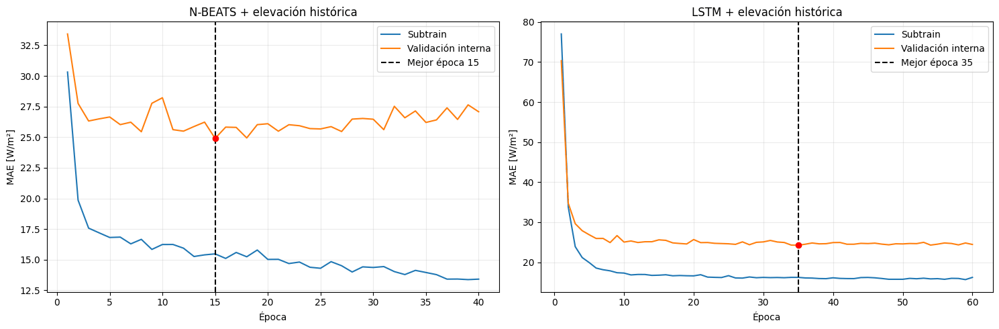

In [ ]:
import os
import gc
import time
import random
import platform
import threading
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 1. Configuración reproducible
SEMILLA = 42
N_VALIDACION_INTERNA = 721
BATCH_SIZE = 128
MAX_EPOCHS = 300
PATIENCE = 25
MIN_DELTA = 1e-5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
CLIP_NORM = 1.0
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DIRECTORIO_RESULTADOS_ELEVACION = Path("/content/experimento_secuencial_elevacion")
DIRECTORIO_RESULTADOS_ELEVACION.mkdir(parents=True, exist_ok=True)

def fijar_semilla(semilla=42):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(semilla)
        torch.cuda.manual_seed_all(semilla)

    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

fijar_semilla(SEMILLA)
print("Dispositivo:", DEVICE)
print("Python:", platform.python_version())
print("PyTorch:", torch.__version__)
print("CPU:", platform.processor() or platform.machine())
print("Hilos PyTorch:", torch.get_num_threads())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# 2. Comprobar y preparar datos
objetos_necesarios = ["X_train_DIF_elevacion_raw", "y_train_secuencial"]
faltantes = [nombre for nombre in objetos_necesarios if nombre not in globals()]
if faltantes:
    raise RuntimeError(f"Faltan objetos necesarios: {faltantes}")

X_train_multivariante = np.asarray(X_train_DIF_elevacion_raw, dtype=np.float32)
y_train_multivariante = np.asarray(y_train_secuencial, dtype=np.float32).reshape(-1)
assert X_train_multivariante.shape == (5149, 24, 2)
assert y_train_multivariante.shape == (5149,)
assert np.isfinite(X_train_multivariante).all()
assert np.isfinite(y_train_multivariante).all()
N_TRAIN = len(X_train_multivariante)
N_SUBTRAIN = N_TRAIN - N_VALIDACION_INTERNA
X_subtrain_raw = X_train_multivariante[:N_SUBTRAIN]
y_subtrain_raw = y_train_multivariante[:N_SUBTRAIN]
X_interna_raw = X_train_multivariante[N_SUBTRAIN:]
y_interna_raw = y_train_multivariante[N_SUBTRAIN:]
print("\nDivisión temporal:")
print("Subtrain:", X_subtrain_raw.shape)
print("Validación interna:", X_interna_raw.shape)
if "train_hgb" in globals():
    print(
        "Subtrain objetivo:",
        train_hgb["instante_objetivo"].iloc[0],
        "→",
        train_hgb["instante_objetivo"].iloc[N_SUBTRAIN - 1],
    )
    print(
        "Validación interna:",
        train_hgb["instante_objetivo"].iloc[N_SUBTRAIN],
        "→",
        train_hgb["instante_objetivo"].iloc[-1],
    )

# 3. Escalado ajustado exclusivamente con subtrain
# DIF conserva la metodología anterior:
# media/std calculadas sobre y_subtrain.
# Elevación:
# media/std calculadas sobre las elevaciones históricas
# disponibles en X_subtrain.
def ajustar_escaladores(X, y):
    parametros = {
        "media_DIF": float(np.mean(y)),
        "std_DIF": float(np.std(y, ddof=0)),
        "media_elevacion": float(np.mean(X[:, :, 1])),
        "std_elevacion": float(np.std(X[:, :, 1], ddof=0)),
    }
    if parametros["std_DIF"] <= 0:
        raise ValueError("Desviación de DIF no válida.")

    if parametros["std_elevacion"] <= 0:
        raise ValueError("Desviación de elevación no válida.")

    return parametros

def transformar_X(X, parametros):
    X_transformado = np.asarray(X, dtype=np.float32).copy()
    X_transformado[:, :, 0] = (X_transformado[:, :, 0] - parametros["media_DIF"]) / parametros[
        "std_DIF"
    ]
    X_transformado[:, :, 1] = (
        X_transformado[:, :, 1] - parametros["media_elevacion"]
    ) / parametros["std_elevacion"]
    return X_transformado

def transformar_y(y, parametros):
    return (
        (np.asarray(y, dtype=np.float32) - parametros["media_DIF"]) / parametros["std_DIF"]
    ).astype(np.float32)

escaladores_subtrain_elevacion = ajustar_escaladores(X_subtrain_raw, y_subtrain_raw)
X_subtrain = transformar_X(X_subtrain_raw, escaladores_subtrain_elevacion)
X_interna = transformar_X(X_interna_raw, escaladores_subtrain_elevacion)
y_subtrain = transformar_y(y_subtrain_raw, escaladores_subtrain_elevacion)
y_interna = transformar_y(y_interna_raw, escaladores_subtrain_elevacion)
print("\nEscaladores ajustados con subtrain:")
for clave, valor in escaladores_subtrain_elevacion.items():
    print(f"{clave}: {valor:.10f}")

# Las cifras de DIF deberían coincidir aproximadamente con:
# media = 74.50566864
# std   = 107.80002594

# 4. DataLoaders
def crear_loader(X, y, shuffle, semilla=42):
    dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    generador = torch.Generator()
    generador.manual_seed(semilla)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        generator=generador if shuffle else None,
    )


# 5. N-BEATS con elevación histórica exógena
class BloqueNBEATSExogeno(nn.Module):
    def __init__(
        self,
        longitud_backcast=24,
        dimension_exogena=24,
        unidades_ocultas=128,
        capas_densas=3,
        horizonte=1,
    ):
        super().__init__()
        dimension_entrada = longitud_backcast + dimension_exogena
        capas = []
        for indice in range(capas_densas):
            entrada = dimension_entrada if indice == 0 else unidades_ocultas
            capas.extend([nn.Linear(entrada, unidades_ocultas), nn.ReLU()])

        self.red_densa = nn.Sequential(*capas)
        self.cabeza_backcast = nn.Linear(unidades_ocultas, longitud_backcast)
        self.cabeza_forecast = nn.Linear(unidades_ocultas, horizonte)

    def forward(self, residual_DIF, elevacion_historica):
        entrada = torch.cat([residual_DIF, elevacion_historica], dim=1)
        representacion = self.red_densa(entrada)
        backcast = self.cabeza_backcast(representacion)
        forecast = self.cabeza_forecast(representacion)
        return backcast, forecast

class NBEATSElevacionHistorica(nn.Module):
    def __init__(
        self,
        longitud_backcast=24,
        horizonte=1,
        n_stacks=2,
        bloques_por_stack=3,
        capas_densas=3,
        unidades_ocultas=128,
    ):
        super().__init__()
        numero_bloques = n_stacks * bloques_por_stack
        self.bloques = nn.ModuleList(
            [
                BloqueNBEATSExogeno(
                    longitud_backcast=longitud_backcast,
                    dimension_exogena=longitud_backcast,
                    unidades_ocultas=unidades_ocultas,
                    capas_densas=capas_densas,
                    horizonte=horizonte,
                )
                for _ in range(numero_bloques)
            ]
        )

    def forward(self, X):
        # Canal 0: DIF histórica
        # Canal 1: elevación histórica
        residual_DIF = X[:, :, 0]
        elevacion_historica = X[:, :, 1]
        forecast_total = torch.zeros((X.shape[0], 1), dtype=X.dtype, device=X.device)
        for bloque in self.bloques:
            backcast, forecast = bloque(residual_DIF, elevacion_historica)
            residual_DIF = residual_DIF - backcast
            forecast_total = forecast_total + forecast

        return forecast_total.squeeze(-1)


# 6. LSTM con dos canales
class LSTMElevacionHistorica(nn.Module):
    def __init__(self, input_size=2, hidden_size=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size, num_layers=num_layers, batch_first=True
        )
        self.cabeza = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, X):
        salida_secuencial, _ = self.lstm(X)
        ultimo_estado = salida_secuencial[:, -1, :]
        return self.cabeza(ultimo_estado).squeeze(-1)


# 7. Medición de tiempo y memoria
class MedidorRecursos:
    def __enter__(self):
        gc.collect()
        self.proceso = psutil.Process(os.getpid())
        self.rss_inicial = self.proceso.memory_info().rss
        self.rss_maximo = self.rss_inicial
        self.detener = threading.Event()

        def monitorizar():
            while not self.detener.is_set():
                rss = self.proceso.memory_info().rss
                self.rss_maximo = max(self.rss_maximo, rss)
                time.sleep(0.05)

        self.hilo = threading.Thread(target=monitorizar, daemon=True)
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
            torch.cuda.reset_peak_memory_stats()
            torch.cuda.synchronize()

        self.hilo.start()
        self.inicio = time.perf_counter()
        return self

    def __exit__(self, exc_type, exc_value, traceback):
        if torch.cuda.is_available():
            torch.cuda.synchronize()

        self.tiempo_s = time.perf_counter() - self.inicio
        self.detener.set()
        self.hilo.join()
        self.rss_pico_MB = self.rss_maximo / 1024**2
        self.incremento_rss_MB = (self.rss_maximo - self.rss_inicial) / 1024**2
        self.gpu_pico_MB = (
            torch.cuda.max_memory_allocated() / 1024**2 if torch.cuda.is_available() else 0.0
        )


# 8. Entrenamiento y validación de una época
def entrenar_una_epoca(modelo, loader, optimizador, criterio, std_DIF):
    modelo.train()
    error_absoluto_escalado = 0.0
    numero_observaciones = 0
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(DEVICE, non_blocking=True)
        y_batch = y_batch.to(DEVICE, non_blocking=True)
        optimizador.zero_grad(set_to_none=True)
        prediccion = modelo(X_batch)
        perdida = criterio(prediccion, y_batch)
        perdida.backward()
        nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=CLIP_NORM)
        optimizador.step()
        error_absoluto_escalado += torch.abs(prediccion.detach() - y_batch).sum().item()
        numero_observaciones += len(y_batch)

    return error_absoluto_escalado / numero_observaciones * std_DIF

@torch.no_grad()
def evaluar_modelo(modelo, loader, std_DIF):
    modelo.eval()
    error_absoluto_escalado = 0.0
    numero_observaciones = 0
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(DEVICE, non_blocking=True)
        y_batch = y_batch.to(DEVICE, non_blocking=True)
        prediccion = modelo(X_batch)
        error_absoluto_escalado += torch.abs(prediccion - y_batch).sum().item()
        numero_observaciones += len(y_batch)

    return error_absoluto_escalado / numero_observaciones * std_DIF


# 9. Selección de época con early stopping
def seleccionar_epoca(nombre_modelo, fabrica_modelo):
    fijar_semilla(SEMILLA)
    loader_subtrain = crear_loader(X_subtrain, y_subtrain, shuffle=True, semilla=SEMILLA)
    loader_interna = crear_loader(X_interna, y_interna, shuffle=False)
    modelo = fabrica_modelo().to(DEVICE)
    numero_parametros = sum(
        parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad
    )
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterio = nn.L1Loss()
    mejor_MAE = np.inf
    mejor_epoca = None
    contador_paciencia = 0
    historial = []
    print(f"\n{'=' * 72}")
    print(nombre_modelo)
    print("Parámetros entrenables:", numero_parametros)
    print(f"{'=' * 72}")
    with MedidorRecursos() as medidor:
        for epoca in range(1, MAX_EPOCHS + 1):
            MAE_train = entrenar_una_epoca(
                modelo=modelo,
                loader=loader_subtrain,
                optimizador=optimizador,
                criterio=criterio,
                std_DIF=escaladores_subtrain_elevacion["std_DIF"],
            )
            MAE_interno = evaluar_modelo(
                modelo=modelo,
                loader=loader_interna,
                std_DIF=escaladores_subtrain_elevacion["std_DIF"],
            )
            historial.append(
                {
                    "modelo": nombre_modelo,
                    "epoca": epoca,
                    "MAE_subtrain": MAE_train,
                    "MAE_validacion_interna": MAE_interno,
                }
            )
            if MAE_interno < mejor_MAE - MIN_DELTA:
                mejor_MAE = MAE_interno
                mejor_epoca = epoca
                contador_paciencia = 0
            else:
                contador_paciencia += 1

            if epoca == 1 or epoca % 10 == 0 or epoca == mejor_epoca:
                print(
                    f"Época {epoca:3d} | "
                    f"MAE subtrain={MAE_train:8.4f} | "
                    f"MAE interna={MAE_interno:8.4f} | "
                    f"mejor={mejor_MAE:8.4f} "
                    f"(época {mejor_epoca})"
                )

            if contador_paciencia >= PATIENCE:
                print("\nEarly stopping en época", epoca)
                break

    historial = pd.DataFrame(historial)
    resultado = {
        "modelo": nombre_modelo,
        "mejor_epoca": int(mejor_epoca),
        "mejor_MAE_interno": float(mejor_MAE),
        "epocas_ejecutadas": int(len(historial)),
        "tiempo_seleccion_s": float(medidor.tiempo_s),
        "tiempo_por_epoca_s": float(medidor.tiempo_s / len(historial)),
        "parametros_entrenables": int(numero_parametros),
        "rss_pico_MB": float(medidor.rss_pico_MB),
        "incremento_rss_MB": float(medidor.incremento_rss_MB),
        "gpu_pico_MB": float(medidor.gpu_pico_MB),
    }
    del modelo
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return resultado, historial


# 10. Ejecutar selección para N-BEATS
resultado_seleccion_nbeats_elevacion, historial_nbeats_elevacion = seleccionar_epoca(
    nombre_modelo="NBEATS-U24-DIF-ElevHist", fabrica_modelo=lambda: NBEATSElevacionHistorica()
)

# 11. Ejecutar selección para LSTM
resultado_seleccion_lstm_elevacion, historial_lstm_elevacion = seleccionar_epoca(
    nombre_modelo="LSTM-U24-DIF-ElevHist", fabrica_modelo=lambda: LSTMElevacionHistorica()
)

# 12. Resumen de selección
resumen_seleccion_elevacion = pd.DataFrame(
    [resultado_seleccion_nbeats_elevacion, resultado_seleccion_lstm_elevacion]
)
display(resumen_seleccion_elevacion)
historial_nbeats_elevacion.to_csv(
    DIRECTORIO_RESULTADOS_ELEVACION / "historial_seleccion_NBEATS_elevacion.csv", index=False
)
historial_lstm_elevacion.to_csv(
    DIRECTORIO_RESULTADOS_ELEVACION / "historial_seleccion_LSTM_elevacion.csv", index=False
)
resumen_seleccion_elevacion.to_csv(
    DIRECTORIO_RESULTADOS_ELEVACION / "resumen_seleccion_epoca.csv", index=False
)

# 13. Curvas comparativas
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for eje, historial, resultado, titulo in [
    (
        ejes[0],
        historial_nbeats_elevacion,
        resultado_seleccion_nbeats_elevacion,
        "N-BEATS + elevación histórica",
    ),
    (
        ejes[1],
        historial_lstm_elevacion,
        resultado_seleccion_lstm_elevacion,
        "LSTM + elevación histórica",
    ),
]:
    eje.plot(historial["epoca"], historial["MAE_subtrain"], label="Subtrain")
    eje.plot(historial["epoca"], historial["MAE_validacion_interna"], label="Validación interna")
    eje.axvline(
        resultado["mejor_epoca"],
        color="black",
        linestyle="--",
        label=("Mejor época " f"{resultado['mejor_epoca']}"),
    )
    eje.scatter([resultado["mejor_epoca"]], [resultado["mejor_MAE_interno"]], color="red", zorder=5)
    eje.set_title(titulo)
    eje.set_xlabel("Época")
    eje.set_ylabel("MAE [W/m²]")
    eje.grid(alpha=0.25)
    eje.legend()

plt.tight_layout()
plt.show()

In [ ]:
import json
import statistics

# 1. Preparar train completo y validation externa
X_train_final_raw = np.asarray(X_train_DIF_elevacion_raw, dtype=np.float32)
X_validation_final_raw = np.asarray(X_validation_DIF_elevacion_raw, dtype=np.float32)
y_train_final_raw = np.asarray(y_train_secuencial, dtype=np.float32).reshape(-1)
y_validation_final_raw = np.asarray(y_validation_secuencial, dtype=np.float32).reshape(-1)
assert X_train_final_raw.shape == (5149, 24, 2)
assert X_validation_final_raw.shape == (1464, 24, 2)
assert y_train_final_raw.shape == (5149,)
assert y_validation_final_raw.shape == (1464,)

# 2. Reajustar escaladores exclusivamente con todo train
escaladores_train_completo_elevacion = ajustar_escaladores(X_train_final_raw, y_train_final_raw)
X_train_final = transformar_X(X_train_final_raw, escaladores_train_completo_elevacion)
X_validation_final = transformar_X(X_validation_final_raw, escaladores_train_completo_elevacion)
y_train_final = transformar_y(y_train_final_raw, escaladores_train_completo_elevacion)
y_validation_final = transformar_y(y_validation_final_raw, escaladores_train_completo_elevacion)
print("Escaladores ajustados con todo train:")
for clave, valor in escaladores_train_completo_elevacion.items():
    print(f"{clave}: {valor:.10f}")

# DIF debería reproducir aproximadamente:
# media = 80.29508209
# std   = 112.17021179
with open(
    DIRECTORIO_RESULTADOS_ELEVACION / "escaladores_train_completo.json", "w", encoding="utf-8"
) as archivo:
    json.dump(escaladores_train_completo_elevacion, archivo, ensure_ascii=False, indent=2)

# 3. Predicción por lotes
def crear_loader_prediccion(X, batch_size=512):
    dataset = TensorDataset(torch.from_numpy(np.asarray(X, dtype=np.float32)))
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

@torch.no_grad()
def predecir_escalado(modelo, loader):
    modelo.eval()
    predicciones = []
    for (X_batch,) in loader:
        X_batch = X_batch.to(DEVICE, non_blocking=True)
        prediccion = modelo(X_batch)
        predicciones.append(prediccion.detach().cpu().numpy())

    return np.concatenate(predicciones)


# 4. Reentrenamiento final de un modelo
def reentrenar_modelo_final(nombre_modelo, fabrica_modelo, numero_epocas, nombre_checkpoint):
    fijar_semilla(SEMILLA)
    loader_train = crear_loader(X_train_final, y_train_final, shuffle=True, semilla=SEMILLA)
    loader_validation_prediccion = crear_loader_prediccion(X_validation_final, batch_size=512)
    modelo = fabrica_modelo().to(DEVICE)
    numero_parametros = sum(
        parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad
    )
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterio = nn.L1Loss()
    historial_final = []
    print(f"\n{'=' * 74}")
    print("Reajuste final:", nombre_modelo)
    print("Épocas:", numero_epocas)
    print("Parámetros:", numero_parametros)
    print(f"{'=' * 74}")

    # Entrenamiento final
    with MedidorRecursos() as medidor_reajuste:
        for epoca in range(1, numero_epocas + 1):
            MAE_train = entrenar_una_epoca(
                modelo=modelo,
                loader=loader_train,
                optimizador=optimizador,
                criterio=criterio,
                std_DIF=(escaladores_train_completo_elevacion["std_DIF"]),
            )
            historial_final.append(
                {"modelo": nombre_modelo, "epoca": epoca, "MAE_train_completo": MAE_train}
            )
            if epoca == 1 or epoca % 5 == 0 or epoca == numero_epocas:
                print(f"Época {epoca:3d}/{numero_epocas} | " f"MAE train={MAE_train:.4f}")

    historial_final = pd.DataFrame(historial_final)

    # Inferencia: primera pasada y 30 repeticiones calientes
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    inicio_primera = time.perf_counter()
    prediccion_escalada = predecir_escalado(modelo, loader_validation_prediccion)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    tiempo_primera_pasada = time.perf_counter() - inicio_primera
    tiempos_inferencia = []
    with MedidorRecursos() as medidor_inferencia:
        for _ in range(30):
            if torch.cuda.is_available():
                torch.cuda.synchronize()

            inicio = time.perf_counter()
            prediccion_escalada = predecir_escalado(modelo, loader_validation_prediccion)
            if torch.cuda.is_available():
                torch.cuda.synchronize()

            tiempos_inferencia.append(time.perf_counter() - inicio)

    tiempo_inferencia_mediana = float(statistics.median(tiempos_inferencia))
    tiempo_inferencia_media = float(np.mean(tiempos_inferencia))
    prediccion_real = (
        prediccion_escalada * escaladores_train_completo_elevacion["std_DIF"]
        + escaladores_train_completo_elevacion["media_DIF"]
    )
    prediccion_real = prediccion_real.astype(np.float64)
    MAE_validation = float(np.mean(np.abs(prediccion_real - y_validation_final_raw)))
    RMSE_validation = float(np.sqrt(np.mean((prediccion_real - y_validation_final_raw) ** 2)))
    sesgo_validation = float(np.mean(prediccion_real - y_validation_final_raw))
    denominador_R2 = np.sum((y_validation_final_raw - y_validation_final_raw.mean()) ** 2)
    R2_validation = float(
        1 - np.sum((y_validation_final_raw - prediccion_real) ** 2) / denominador_R2
    )

    # Guardar checkpoint reproducible
    ruta_checkpoint = DIRECTORIO_RESULTADOS_ELEVACION / nombre_checkpoint
    checkpoint = {
        "nombre_modelo": nombre_modelo,
        "state_dict": modelo.state_dict(),
        "numero_epocas": int(numero_epocas),
        "semilla": SEMILLA,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "clip_norm": CLIP_NORM,
        "escaladores": (escaladores_train_completo_elevacion),
        "forma_entrada": [24, 2],
        "canales": ["DIF_historica", "elevacion_historica"],
        "parametros_entrenables": (numero_parametros),
    }
    torch.save(checkpoint, ruta_checkpoint)
    tamaño_checkpoint_MB = ruta_checkpoint.stat().st_size / 1024**2
    resultado = {
        "modelo": nombre_modelo,
        "epocas_reajuste": int(numero_epocas),
        "parametros_entrenables": int(numero_parametros),
        "tiempo_reajuste_s": float(medidor_reajuste.tiempo_s),
        "tiempo_reajuste_por_epoca_s": float(medidor_reajuste.tiempo_s / numero_epocas),
        "rss_pico_reajuste_MB": float(medidor_reajuste.rss_pico_MB),
        "incremento_rss_reajuste_MB": float(medidor_reajuste.incremento_rss_MB),
        "gpu_pico_reajuste_MB": float(medidor_reajuste.gpu_pico_MB),
        "tiempo_primera_inferencia_s": float(tiempo_primera_pasada),
        "tiempo_inferencia_mediana_s": float(tiempo_inferencia_mediana),
        "tiempo_inferencia_media_s": float(tiempo_inferencia_media),
        "inferencia_microsegundos_muestra": float(
            tiempo_inferencia_mediana / len(X_validation_final) * 1e6
        ),
        "rss_pico_inferencia_MB": float(medidor_inferencia.rss_pico_MB),
        "gpu_pico_inferencia_MB": float(medidor_inferencia.gpu_pico_MB),
        "tamaño_checkpoint_MB": float(tamaño_checkpoint_MB),
        "MAE_validation": MAE_validation,
        "RMSE_validation": RMSE_validation,
        "R2_validation": R2_validation,
        "sesgo_validation": sesgo_validation,
    }
    print("\nResultado final:")
    print(f"MAE validation: {MAE_validation:.4f}")
    print(f"RMSE validation: {RMSE_validation:.4f}")
    print(f"R² validation: {R2_validation:.6f}")
    print(f"Sesgo validation: {sesgo_validation:.4f}")
    print("Tiempo reajuste:", f"{medidor_reajuste.tiempo_s:.3f} s")
    print("Inferencia mediana:", f"{tiempo_inferencia_mediana:.6f} s")
    print("Checkpoint:", f"{tamaño_checkpoint_MB:.3f} MB")
    return (modelo, prediccion_real, resultado, historial_final)


# 5. Reajustar N-BEATS desde cero durante 15 épocas
(
    modelo_nbeats_elevacion_final,
    prediccion_nbeats_elevacion_validation,
    resultado_final_nbeats_elevacion,
    historial_final_nbeats_elevacion,
) = reentrenar_modelo_final(
    nombre_modelo="NBEATS-U24-DIF-ElevHist",
    fabrica_modelo=lambda: NBEATSElevacionHistorica(),
    numero_epocas=(resultado_seleccion_nbeats_elevacion["mejor_epoca"]),
    nombre_checkpoint=("NBEATS_U24_DIF_ElevHist_final.pt"),
)

# 6. Reajustar LSTM desde cero durante 35 épocas
(
    modelo_lstm_elevacion_final,
    prediccion_lstm_elevacion_validation,
    resultado_final_lstm_elevacion,
    historial_final_lstm_elevacion,
) = reentrenar_modelo_final(
    nombre_modelo="LSTM-U24-DIF-ElevHist",
    fabrica_modelo=lambda: LSTMElevacionHistorica(),
    numero_epocas=(resultado_seleccion_lstm_elevacion["mejor_epoca"]),
    nombre_checkpoint=("LSTM_U24_DIF_ElevHist_final.pt"),
)

# 7. Resumen conjunto de coste y rendimiento
resumen_final_elevacion = pd.DataFrame(
    [
        {**resultado_seleccion_nbeats_elevacion, **resultado_final_nbeats_elevacion},
        {**resultado_seleccion_lstm_elevacion, **resultado_final_lstm_elevacion},
    ]
)
display(resumen_final_elevacion)

# 8. Tabla de predicciones
predicciones_validation_elevacion = (
    validation_hgb[["instante_objetivo", "DIF_objetivo_t1", "regimen_solar_objetivo", "DIF_lag_1"]]
    .copy()
    .reset_index(drop=True)
)
predicciones_validation_elevacion.rename(columns={"DIF_objetivo_t1": "DIF_real"}, inplace=True)
predicciones_validation_elevacion["NBEATS_DIF_ElevHist"] = prediccion_nbeats_elevacion_validation
predicciones_validation_elevacion["LSTM_DIF_ElevHist"] = prediccion_lstm_elevacion_validation
for nombre in ["NBEATS_DIF_ElevHist", "LSTM_DIF_ElevHist"]:
    predicciones_validation_elevacion[f"error_{nombre}"] = (
        predicciones_validation_elevacion[nombre] - predicciones_validation_elevacion["DIF_real"]
    )
    predicciones_validation_elevacion[f"error_abs_{nombre}"] = np.abs(
        predicciones_validation_elevacion[f"error_{nombre}"]
    )

display(predicciones_validation_elevacion.head())

# 9. Guardar resultados intermedios
historial_final_nbeats_elevacion.to_csv(
    DIRECTORIO_RESULTADOS_ELEVACION / "historial_reajuste_NBEATS_elevacion.csv", index=False
)
historial_final_lstm_elevacion.to_csv(
    DIRECTORIO_RESULTADOS_ELEVACION / "historial_reajuste_LSTM_elevacion.csv", index=False
)
resumen_final_elevacion.to_csv(
    DIRECTORIO_RESULTADOS_ELEVACION / "resumen_coste_rendimiento_elevacion.csv", index=False
)
predicciones_validation_elevacion.to_parquet(
    DIRECTORIO_RESULTADOS_ELEVACION / "predicciones_validation_elevacion.parquet", index=False
)
predicciones_validation_elevacion.to_csv(
    DIRECTORIO_RESULTADOS_ELEVACION / "predicciones_validation_elevacion.csv", index=False
)
print("\nResultados guardados en:", DIRECTORIO_RESULTADOS_ELEVACION)

Escaladores ajustados con todo train:
media_DIF: 80.2950820923
std_DIF: 112.1702117920
media_elevacion: 4.6184706688
std_elevacion: 29.9171199799

Reajuste final: NBEATS-U24-DIF-ElevHist
Épocas: 15
Parámetros: 255126
Época   1/15 | MAE train=31.5602
Época   5/15 | MAE train=18.7370
Época  10/15 | MAE train=17.1017
Época  15/15 | MAE train=16.6511

Resultado final:
MAE validation: 16.8836
RMSE validation: 32.9200
R² validation: 0.907290
Sesgo validation: 1.7294
Tiempo reajuste: 19.028 s
Inferencia mediana: 0.039214 s
Checkpoint: 0.995 MB

Reajuste final: LSTM-U24-DIF-ElevHist
Épocas: 35
Parámetros: 19521
Época   1/35 | MAE train=76.5342
Época   5/35 | MAE train=21.1498
Época  10/35 | MAE train=18.4049
Época  15/35 | MAE train=17.7302
Época  20/35 | MAE train=17.8405
Época  25/35 | MAE train=17.4874
Época  30/35 | MAE train=17.4971
Época  35/35 | MAE train=17.3480

Resultado final:
MAE validation: 16.7831
RMSE validation: 33.0681
R² validation: 0.906455
Sesgo validation: -0.9390
Tiempo r

,modelo,mejor_epoca,mejor_MAE_interno,epocas_ejecutadas,tiempo_seleccion_s,tiempo_por_epoca_s,parametros_entrenables,rss_pico_MB,incremento_rss_MB,gpu_pico_MB,...,tiempo_inferencia_mediana_s,tiempo_inferencia_media_s,inferencia_microsegundos_muestra,rss_pico_inferencia_MB,gpu_pico_inferencia_MB,tamaño_checkpoint_MB,MAE_validation,RMSE_validation,R2_validation,sesgo_validation
0,NBEATS-U24-DIF-ElevHist,15,24.897926,40,40.804431,1.020111,255126,570.378906,7.648438,0.0,...,0.039214,0.043429,26.785826,596.265625,0.0,0.995387,16.883628,32.920020,0.907290,1.729359
1,LSTM-U24-DIF-ElevHist,35,24.238621,60,48.153225,0.802554,19521,593.273438,22.898438,0.0,...,0.085472,0.089524,58.382490,605.980469,0.0,0.078710,16.783111,33.068067,0.906455,-0.938955


,instante_objetivo,DIF_real,regimen_solar_objetivo,DIF_lag_1,NBEATS_DIF_ElevHist,LSTM_DIF_ElevHist,error_NBEATS_DIF_ElevHist,error_abs_NBEATS_DIF_ElevHist,error_LSTM_DIF_ElevHist,error_abs_LSTM_DIF_ElevHist
0,2024-08-01 00:00:00+00:00,-1.0,noche,-1.0,-1.091835,-0.641632,-0.091835,0.091835,0.358368,0.358368
1,2024-08-01 01:00:00+00:00,-1.0,noche,-1.0,-1.544518,-0.712273,-0.544518,0.544518,0.287727,0.287727
2,2024-08-01 02:00:00+00:00,-1.0,noche,-1.0,-1.941582,-0.759819,-0.941582,0.941582,0.240181,0.240181
3,2024-08-01 03:00:00+00:00,0.4,noche,-1.0,-1.084389,0.635307,-1.484389,1.484389,0.235307,0.235307
4,2024-08-01 04:00:00+00:00,28.8,transicion,0.4,18.906086,16.915913,-9.893914,9.893914,-11.884087,11.884087



Resultados guardados en: /content/experimento_secuencial_elevacion


Número de timestamps: 1464
Diferencia máxima entre objetivos: 1.4241536462122895e-05

Regímenes encontrados:
regimen_solar_objetivo
completamente_diurna    765
noche                   580
transicion              119
Name: count, dtype: int64

Recuentos por máscara:
Total                   : 1464
Operacional             : 884
Completamente diurno    : 765
Transición              : 119
Noche                   : 580

MAE POR RÉGIMEN


modelo,HGB-9V,N-BEATS-U24 DIF,LSTM-U24 DIF,N-BEATS-U24 DIF+Elev,LSTM-U24 DIF+Elev
regimen,,,,,
Total,16.5624,18.7116,17.0423,16.8836,16.7831
Operacional,27.3534,29.2961,28.0004,27.6235,27.4197
Completamente diurno,31.2125,32.5305,31.7180,31.3692,31.1945
Transición,2.5450,8.5037,4.1015,3.5436,3.1528
Noche,0.1154,2.5793,0.3406,0.5146,0.5716



MÉTRICAS COMPLETAS


,regimen,modelo,n,media_DIF_real,mediana_DIF_real,MAE,nMAE_porcentaje,RMSE,sesgo_pred_menos_real,mediana_error_absoluto,p90_error_absoluto,p95_error_absoluto,p99_error_absoluto,R2
0,Total,HGB-9V,1464,85.233276,30.591666,16.562404,19.431852,33.042724,0.041954,2.783955,49.426008,71.800561,125.806842,0.906598
1,Total,N-BEATS-U24 DIF,1464,85.233276,30.591666,18.711623,21.953425,34.101751,2.872980,6.357832,51.390910,71.192993,130.387508,0.900515
2,Total,LSTM-U24 DIF,1464,85.233276,30.591666,17.042265,19.994849,33.062990,-0.873235,3.945393,49.243214,70.517744,126.024454,0.906483
3,Total,N-BEATS-U24 DIF+Elev,1464,85.233276,30.591666,16.883628,19.808729,32.920020,1.729359,3.754698,47.290470,71.093285,134.527751,0.907290
4,Total,LSTM-U24 DIF+Elev,1464,85.233276,30.591666,16.783111,19.690797,33.068067,-0.938955,3.644508,50.060265,69.508662,134.270002,0.906455
5,Operacional,HGB-9V,884,141.797567,127.733334,27.353409,19.290464,42.521985,0.046495,16.441674,67.686600,90.250864,166.569802,0.839748
6,Operacional,N-BEATS-U24 DIF,884,141.797567,127.733334,29.296149,20.660544,43.793165,3.093925,18.311878,67.229260,97.557095,154.543244,0.830023
7,Operacional,LSTM-U24 DIF,884,141.797567,127.733334,28.000364,19.746717,42.547261,-1.620577,17.917969,64.311717,88.050530,169.375969,0.839557
8,Operacional,N-BEATS-U24 DIF+Elev,884,141.797567,127.733334,27.623462,19.480914,42.360924,2.876547,18.606986,65.749539,89.729581,152.439744,0.840959
9,Operacional,LSTM-U24 DIF+Elev,884,141.797567,127.733334,27.419652,19.337181,42.550746,-1.660616,17.110282,64.433628,92.278760,161.497776,0.839531



APORTACIÓN DE LA ELEVACIÓN HISTÓRICA


,regimen,arquitectura,MAE_solo_DIF,MAE_DIF_mas_elevacion,mejora_absoluta_Wm2,mejora_porcentual
0,Total,N-BEATS,18.7116,16.8836,1.8280,9.7693
1,Total,LSTM,17.0423,16.7831,0.2592,1.5207
2,Operacional,N-BEATS,29.2961,27.6235,1.6727,5.7096
3,Operacional,LSTM,28.0004,27.4197,0.5807,2.0739
4,Completamente diurno,N-BEATS,32.5305,31.3692,1.1613,3.5699
5,Completamente diurno,LSTM,31.7180,31.1945,0.5235,1.6504
6,Transición,N-BEATS,8.5037,3.5436,4.9601,58.3286
7,Transición,LSTM,4.1015,3.1528,0.9488,23.1320
8,Noche,N-BEATS,2.5793,0.5146,2.0647,80.0476
9,Noche,LSTM,0.3406,0.5716,-0.2309,-67.8037


... (2 outputs left out)


CAPACIDAD PARA PREDECIR CAMBIOS


,modelo,exactitud_direccion_porcentaje,MAE_delta,sesgo_delta_aumentos,sesgo_delta_descensos,n_aumentos,n_descensos
0,HGB-9V,80.7692,27.3534,-18.8879,22.2891,467,397
1,N-BEATS-U24 DIF,81.2217,29.2961,-14.6473,24.0271,467,397
2,LSTM-U24 DIF,81.6742,28.0004,-16.7396,16.1653,467,397
3,N-BEATS-U24 DIF+Elev,82.3529,27.6235,-10.3707,18.3689,467,397
4,LSTM-U24 DIF+Elev,82.6923,27.4197,-20.3640,20.2946,467,397



COSTE COMPUTACIONAL DISPONIBLE


,modelo,mejor_epoca,parametros_entrenables,tiempo_seleccion_s,tiempo_reajuste_s,tiempo_inferencia_mediana_s,tamaño_checkpoint_MB,observacion
0,HGB-9V,NaN,NaN,NaN,NaN,NaN,0.282013,Tiempos no registrados; requiere reentrenamien...
1,N-BEATS-U24 DIF,8.0,236694.0,NaN,NaN,NaN,0.922252,Tiempos no registrados retrospectivamente.
2,LSTM-U24 DIF,118.0,19265.0,NaN,NaN,NaN,0.077451,Tiempos no registrados retrospectivamente.
3,N-BEATS-U24 DIF+Elev,15.0,255126.0,40.804431,19.027521,0.039214,0.995387,Medición completa.
4,LSTM-U24 DIF+Elev,35.0,19521.0,48.153225,43.194844,0.085472,0.078710,Medición completa.


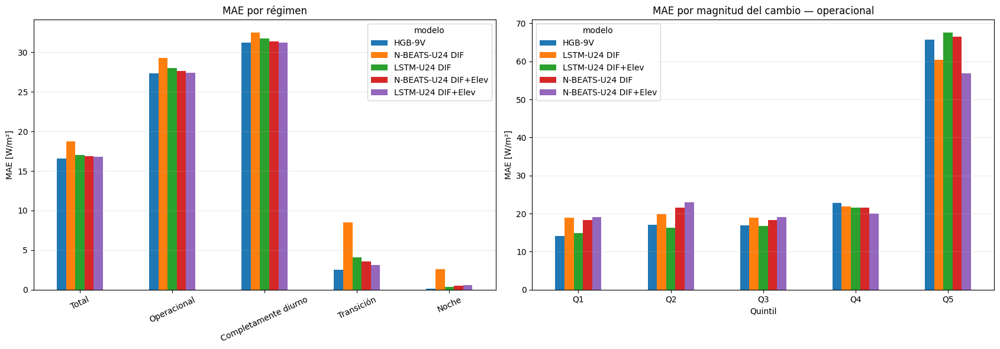


Resultados guardados en: /content/experimento_secuencial_elevacion/comparacion_cinco_modelos


In [ ]:
from collections import OrderedDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Localizar la tabla comparativa anterior
if "comparacion_cuatro_modelos" in globals():
    tabla_anterior = comparacion_cuatro_modelos.copy()

elif "comparacion_cuatro_modelos_validation" in globals():
    tabla_anterior = comparacion_cuatro_modelos_validation.copy()

else:
    raise RuntimeError(
        "No se encontró comparacion_cuatro_modelos ni comparacion_cuatro_modelos_validation."
    )

if "predicciones_validation_elevacion" not in globals():
    raise RuntimeError("No está cargada predicciones_validation_elevacion.")

tabla_nueva = predicciones_validation_elevacion.copy()

# 2. Nombres de columnas originales
COLUMNA_HGB = "M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global"
COLUMNA_NBEATS_DIF = "M4-NBEATS-U24-DIF-MAE-Global"
COLUMNA_LSTM_DIF = "M5-LSTM-U24-DIF-MAE-Global"
COLUMNA_NBEATS_ELEV = "NBEATS_DIF_ElevHist"
COLUMNA_LSTM_ELEV = "LSTM_DIF_ElevHist"
columnas_requeridas_anteriores = [
    "instante_objetivo",
    "regimen_solar_objetivo",
    "DIF_real",
    COLUMNA_HGB,
    COLUMNA_NBEATS_DIF,
    COLUMNA_LSTM_DIF,
]
columnas_requeridas_nuevas = [
    "instante_objetivo",
    "DIF_real",
    "DIF_lag_1",
    COLUMNA_NBEATS_ELEV,
    COLUMNA_LSTM_ELEV,
]
for columna in columnas_requeridas_anteriores:
    if columna not in tabla_anterior.columns:
        raise KeyError(f"Falta {columna} en la tabla anterior.")

for columna in columnas_requeridas_nuevas:
    if columna not in tabla_nueva.columns:
        raise KeyError(f"Falta {columna} en la tabla nueva.")

# 3. Normalizar timestamps y unir
tabla_anterior["instante_objetivo"] = pd.to_datetime(tabla_anterior["instante_objetivo"], utc=True)
tabla_nueva["instante_objetivo"] = pd.to_datetime(tabla_nueva["instante_objetivo"], utc=True)
tabla_comparacion_elevacion = (
    tabla_anterior[columnas_requeridas_anteriores]
    .merge(
        tabla_nueva[columnas_requeridas_nuevas],
        on="instante_objetivo",
        how="inner",
        validate="one_to_one",
        suffixes=("_anterior", "_nuevo"),
    )
    .sort_values("instante_objetivo")
    .reset_index(drop=True)
)
assert len(tabla_comparacion_elevacion) == 1464
diferencia_objetivo = np.abs(
    tabla_comparacion_elevacion["DIF_real_anterior"] - tabla_comparacion_elevacion["DIF_real_nuevo"]
)
print("Número de timestamps:", len(tabla_comparacion_elevacion))
print("Diferencia máxima entre objetivos:", diferencia_objetivo.max())
if not np.allclose(
    tabla_comparacion_elevacion["DIF_real_anterior"],
    tabla_comparacion_elevacion["DIF_real_nuevo"],
    rtol=1e-6,
    atol=1e-4,
):
    raise RuntimeError("Los objetivos anteriores y nuevos no coinciden.")

tabla_comparacion_elevacion.rename(columns={"DIF_real_anterior": "DIF_real"}, inplace=True)
tabla_comparacion_elevacion.drop(columns=["DIF_real_nuevo"], inplace=True)

# 4. Renombrar modelos de forma legible
MAPA_MODELOS = OrderedDict(
    {
        "HGB-9V": COLUMNA_HGB,
        "N-BEATS-U24 DIF": COLUMNA_NBEATS_DIF,
        "LSTM-U24 DIF": COLUMNA_LSTM_DIF,
        "N-BEATS-U24 DIF+Elev": COLUMNA_NBEATS_ELEV,
        "LSTM-U24 DIF+Elev": COLUMNA_LSTM_ELEV,
    }
)
print("\nRegímenes encontrados:")
print(tabla_comparacion_elevacion["regimen_solar_objetivo"].value_counts(dropna=False))

# 5. Máscaras de evaluación
regimen_normalizado = (
    tabla_comparacion_elevacion["regimen_solar_objetivo"].astype(str).str.lower().str.strip()
)
mascara_diurna = regimen_normalizado.str.contains("completamente")
mascara_transicion = regimen_normalizado.str.contains("trans")
mascara_noche = regimen_normalizado.str.contains("noche")
mascara_operacional = mascara_diurna | mascara_transicion
MASCARAS = OrderedDict(
    {
        "Total": np.ones(len(tabla_comparacion_elevacion), dtype=bool),
        "Operacional": mascara_operacional.to_numpy(),
        "Completamente diurno": mascara_diurna.to_numpy(),
        "Transición": mascara_transicion.to_numpy(),
        "Noche": mascara_noche.to_numpy(),
    }
)
print("\nRecuentos por máscara:")
for nombre, mascara in MASCARAS.items():
    print(f"{nombre:24s}: {mascara.sum()}")

# 6. Función común de métricas
def calcular_metricas(y_real, y_predicha):
    y_real = np.asarray(y_real, dtype=float)
    y_predicha = np.asarray(y_predicha, dtype=float)
    error = y_predicha - y_real
    error_absoluto = np.abs(error)
    MAE = float(np.mean(error_absoluto))
    RMSE = float(np.sqrt(np.mean(error**2)))
    sesgo = float(np.mean(error))
    media_real = float(np.mean(y_real))
    mediana_real = float(np.median(y_real))
    nMAE = 100 * MAE / media_real if abs(media_real) > 1e-12 else np.nan
    suma_cuadrados_total = np.sum((y_real - media_real) ** 2)
    R2 = float(1 - np.sum(error**2) / suma_cuadrados_total) if suma_cuadrados_total > 0 else np.nan
    return {
        "n": len(y_real),
        "media_DIF_real": media_real,
        "mediana_DIF_real": mediana_real,
        "MAE": MAE,
        "nMAE_porcentaje": nMAE,
        "RMSE": RMSE,
        "sesgo_pred_menos_real": sesgo,
        "mediana_error_absoluto": float(np.median(error_absoluto)),
        "p90_error_absoluto": float(np.quantile(error_absoluto, 0.90)),
        "p95_error_absoluto": float(np.quantile(error_absoluto, 0.95)),
        "p99_error_absoluto": float(np.quantile(error_absoluto, 0.99)),
        "R2": R2,
    }


# 7. Métricas por régimen
filas_metricas = []
for nombre_regimen, mascara in MASCARAS.items():
    y_real = tabla_comparacion_elevacion.loc[mascara, "DIF_real"].to_numpy()
    for nombre_modelo, columna_prediccion in MAPA_MODELOS.items():
        y_predicha = tabla_comparacion_elevacion.loc[mascara, columna_prediccion].to_numpy()
        metricas = calcular_metricas(y_real, y_predicha)
        filas_metricas.append({"regimen": nombre_regimen, "modelo": nombre_modelo, **metricas})

metricas_cinco_modelos_regimen = pd.DataFrame(filas_metricas)
orden_regimen = list(MASCARAS.keys())
orden_modelos = list(MAPA_MODELOS.keys())
metricas_cinco_modelos_regimen["regimen"] = pd.Categorical(
    metricas_cinco_modelos_regimen["regimen"], categories=orden_regimen, ordered=True
)
metricas_cinco_modelos_regimen["modelo"] = pd.Categorical(
    metricas_cinco_modelos_regimen["modelo"], categories=orden_modelos, ordered=True
)
metricas_cinco_modelos_regimen.sort_values(["regimen", "modelo"], inplace=True)
tabla_MAE_regimen = metricas_cinco_modelos_regimen.pivot(
    index="regimen", columns="modelo", values="MAE"
).reindex(orden_regimen)
print("\nMAE POR RÉGIMEN")
display(tabla_MAE_regimen.round(4))
print("\nMÉTRICAS COMPLETAS")
display(metricas_cinco_modelos_regimen)

# 8. Mejora aportada por la elevación histórica
comparaciones_arquitectura = [
    ("N-BEATS", "N-BEATS-U24 DIF", "N-BEATS-U24 DIF+Elev"),
    ("LSTM", "LSTM-U24 DIF", "LSTM-U24 DIF+Elev"),
]
filas_mejora = []
for regimen in orden_regimen:
    for arquitectura, modelo_base, modelo_elevacion in comparaciones_arquitectura:
        MAE_base = float(tabla_MAE_regimen.loc[regimen, modelo_base])
        MAE_elevacion = float(tabla_MAE_regimen.loc[regimen, modelo_elevacion])
        mejora_absoluta = MAE_base - MAE_elevacion
        mejora_porcentual = 100 * mejora_absoluta / MAE_base if MAE_base != 0 else np.nan
        filas_mejora.append(
            {
                "regimen": regimen,
                "arquitectura": arquitectura,
                "MAE_solo_DIF": MAE_base,
                "MAE_DIF_mas_elevacion": MAE_elevacion,
                "mejora_absoluta_Wm2": mejora_absoluta,
                "mejora_porcentual": mejora_porcentual,
            }
        )

mejora_por_elevacion = pd.DataFrame(filas_mejora)
print("\nAPORTACIÓN DE LA ELEVACIÓN HISTÓRICA")
display(mejora_por_elevacion.round(4))

# 9. Cambio real y quintiles operacionales
tabla_comparacion_elevacion["delta_DIF_real"] = (
    tabla_comparacion_elevacion["DIF_real"] - tabla_comparacion_elevacion["DIF_lag_1"]
)
tabla_comparacion_elevacion["magnitud_cambio_DIF"] = np.abs(
    tabla_comparacion_elevacion["delta_DIF_real"]
)
tabla_operacional = tabla_comparacion_elevacion.loc[mascara_operacional].copy()
try:
    tabla_operacional["quintil_cambio"] = pd.qcut(
        tabla_operacional["magnitud_cambio_DIF"], q=5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
    )

except ValueError:
    # Respaldo ante posibles empates en los límites
    tabla_operacional["quintil_cambio"] = pd.qcut(
        tabla_operacional["magnitud_cambio_DIF"].rank(method="first"),
        q=5,
        labels=["Q1", "Q2", "Q3", "Q4", "Q5"],
    )

filas_quintiles = []
for quintil in ["Q1", "Q2", "Q3", "Q4", "Q5"]:
    subconjunto = tabla_operacional[tabla_operacional["quintil_cambio"] == quintil]
    for nombre_modelo, columna_prediccion in MAPA_MODELOS.items():
        MAE = np.mean(np.abs(subconjunto[columna_prediccion] - subconjunto["DIF_real"]))
        filas_quintiles.append(
            {
                "quintil_cambio": quintil,
                "modelo": nombre_modelo,
                "n": len(subconjunto),
                "magnitud_cambio_min": (subconjunto["magnitud_cambio_DIF"].min()),
                "magnitud_cambio_max": (subconjunto["magnitud_cambio_DIF"].max()),
                "MAE": MAE,
            }
        )

MAE_por_quintil_cambio = pd.DataFrame(filas_quintiles)
tabla_MAE_quintiles = MAE_por_quintil_cambio.pivot(
    index="quintil_cambio", columns="modelo", values="MAE"
).reindex(["Q1", "Q2", "Q3", "Q4", "Q5"])
print("\nMAE POR QUINTIL DE CAMBIO — HORAS OPERACIONALES")
display(tabla_MAE_quintiles.round(4))

# 10. Capacidad para anticipar la dirección del cambio
def clasificar_direccion(delta, umbral=1.0):
    delta = np.asarray(delta)
    return np.select(
        [delta > umbral, delta < -umbral], ["aumento", "descenso"], default="estable_±1"
    )

direccion_real = clasificar_direccion(tabla_operacional["delta_DIF_real"])
filas_cambio = []
for nombre_modelo, columna_prediccion in MAPA_MODELOS.items():
    delta_predicho = (
        tabla_operacional[columna_prediccion] - tabla_operacional["DIF_lag_1"]
    ).to_numpy()
    delta_real = tabla_operacional["delta_DIF_real"].to_numpy()
    direccion_predicha = clasificar_direccion(delta_predicho)
    mascara_aumento = delta_real > 1
    mascara_descenso = delta_real < -1
    filas_cambio.append(
        {
            "modelo": nombre_modelo,
            "exactitud_direccion_porcentaje": (100 * np.mean(direccion_predicha == direccion_real)),
            "MAE_delta": float(np.mean(np.abs(delta_predicho - delta_real))),
            "sesgo_delta_aumentos": float(
                np.mean(delta_predicho[mascara_aumento] - delta_real[mascara_aumento])
            ),
            "sesgo_delta_descensos": float(
                np.mean(delta_predicho[mascara_descenso] - delta_real[mascara_descenso])
            ),
            "n_aumentos": int(mascara_aumento.sum()),
            "n_descensos": int(mascara_descenso.sum()),
        }
    )

metricas_prediccion_cambios = pd.DataFrame(filas_cambio)
print("\nCAPACIDAD PARA PREDECIR CAMBIOS")
display(metricas_prediccion_cambios.round(4))

# Interpretación de los sesgos:
# - aumentos: valor negativo = infraestimación del aumento;
# - descensos: valor positivo = descenso excesivamente suavizado.

# 11. Coste computacional disponible
coste_computacional_modelos = pd.DataFrame(
    [
        {
            "modelo": "HGB-9V",
            "mejor_epoca": np.nan,
            "parametros_entrenables": np.nan,
            "tiempo_seleccion_s": np.nan,
            "tiempo_reajuste_s": np.nan,
            "tiempo_inferencia_mediana_s": np.nan,
            "tamaño_checkpoint_MB": 295712 / 1024**2,
            "observacion": ("Tiempos no registrados; requiere reentrenamiento instrumentado."),
        },
        {
            "modelo": "N-BEATS-U24 DIF",
            "mejor_epoca": 8,
            "parametros_entrenables": 236694,
            "tiempo_seleccion_s": np.nan,
            "tiempo_reajuste_s": np.nan,
            "tiempo_inferencia_mediana_s": np.nan,
            "tamaño_checkpoint_MB": 967051 / 1024**2,
            "observacion": ("Tiempos no registrados retrospectivamente."),
        },
        {
            "modelo": "LSTM-U24 DIF",
            "mejor_epoca": 118,
            "parametros_entrenables": 19265,
            "tiempo_seleccion_s": np.nan,
            "tiempo_reajuste_s": np.nan,
            "tiempo_inferencia_mediana_s": np.nan,
            "tamaño_checkpoint_MB": 81213 / 1024**2,
            "observacion": ("Tiempos no registrados retrospectivamente."),
        },
        {
            "modelo": "N-BEATS-U24 DIF+Elev",
            "mejor_epoca": (resultado_seleccion_nbeats_elevacion["mejor_epoca"]),
            "parametros_entrenables": (resultado_final_nbeats_elevacion["parametros_entrenables"]),
            "tiempo_seleccion_s": (resultado_seleccion_nbeats_elevacion["tiempo_seleccion_s"]),
            "tiempo_reajuste_s": (resultado_final_nbeats_elevacion["tiempo_reajuste_s"]),
            "tiempo_inferencia_mediana_s": (
                resultado_final_nbeats_elevacion["tiempo_inferencia_mediana_s"]
            ),
            "tamaño_checkpoint_MB": (resultado_final_nbeats_elevacion["tamaño_checkpoint_MB"]),
            "observacion": "Medición completa.",
        },
        {
            "modelo": "LSTM-U24 DIF+Elev",
            "mejor_epoca": (resultado_seleccion_lstm_elevacion["mejor_epoca"]),
            "parametros_entrenables": (resultado_final_lstm_elevacion["parametros_entrenables"]),
            "tiempo_seleccion_s": (resultado_seleccion_lstm_elevacion["tiempo_seleccion_s"]),
            "tiempo_reajuste_s": (resultado_final_lstm_elevacion["tiempo_reajuste_s"]),
            "tiempo_inferencia_mediana_s": (
                resultado_final_lstm_elevacion["tiempo_inferencia_mediana_s"]
            ),
            "tamaño_checkpoint_MB": (resultado_final_lstm_elevacion["tamaño_checkpoint_MB"]),
            "observacion": "Medición completa.",
        },
    ]
)
print("\nCOSTE COMPUTACIONAL DISPONIBLE")
display(coste_computacional_modelos.round(6))

# 12. Figuras principales
fig, ejes = plt.subplots(1, 2, figsize=(17, 6))
tabla_MAE_regimen.plot(kind="bar", ax=ejes[0])
ejes[0].set_title("MAE por régimen")
ejes[0].set_xlabel("")
ejes[0].set_ylabel("MAE [W/m²]")
ejes[0].tick_params(axis="x", rotation=25)
ejes[0].grid(axis="y", alpha=0.25)
tabla_MAE_quintiles.plot(kind="bar", ax=ejes[1])
ejes[1].set_title("MAE por magnitud del cambio — operacional")
ejes[1].set_xlabel("Quintil")
ejes[1].set_ylabel("MAE [W/m²]")
ejes[1].tick_params(axis="x", rotation=0)
ejes[1].grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 13. Guardar resultados
DIRECTORIO_COMPARACION_ELEVACION = DIRECTORIO_RESULTADOS_ELEVACION / "comparacion_cinco_modelos"
DIRECTORIO_COMPARACION_ELEVACION.mkdir(parents=True, exist_ok=True)
tabla_comparacion_elevacion.to_parquet(
    DIRECTORIO_COMPARACION_ELEVACION / "tabla_maestra_cinco_modelos.parquet", index=False
)
tabla_comparacion_elevacion.to_csv(
    DIRECTORIO_COMPARACION_ELEVACION / "tabla_maestra_cinco_modelos.csv", index=False
)
metricas_cinco_modelos_regimen.to_csv(
    DIRECTORIO_COMPARACION_ELEVACION / "metricas_cinco_modelos_por_regimen.csv", index=False
)
mejora_por_elevacion.to_csv(
    DIRECTORIO_COMPARACION_ELEVACION / "mejora_por_elevacion.csv", index=False
)
MAE_por_quintil_cambio.to_csv(
    DIRECTORIO_COMPARACION_ELEVACION / "MAE_por_quintil_cambio.csv", index=False
)
metricas_prediccion_cambios.to_csv(
    DIRECTORIO_COMPARACION_ELEVACION / "metricas_prediccion_cambios.csv", index=False
)
coste_computacional_modelos.to_csv(
    DIRECTORIO_COMPARACION_ELEVACION / "coste_computacional_modelos.csv", index=False
)
print("\nResultados guardados en:", DIRECTORIO_COMPARACION_ELEVACION)

Subtrain secuencial: (4428, 24, 2)
Subtrain geometría: (4428, 4)
Validación interna secuencial: (721, 24, 2)
Validación interna geometría: (721, 4)

Escaladores de geometría objetivo:
elevacion_media           | media=2.403388 | std=29.880447
elevacion_minima          | media=-0.710847 | std=29.759382
elevacion_maxima          | media=5.520658 | std=29.822617
fraccion_minutos_dia      | media=0.526735 | std=0.485113

NBEATS-U24-DIF-ElevHist-GeomT
Parámetros entrenables: 258198
Época   1 | MAE subtrain= 29.1823 | MAE interna= 32.8231 | mejor= 32.8231 (época 1)
Época   2 | MAE subtrain= 19.2457 | MAE interna= 27.2833 | mejor= 27.2833 (época 2)
Época   3 | MAE subtrain= 17.7599 | MAE interna= 26.3317 | mejor= 26.3317 (época 3)
Época   4 | MAE subtrain= 17.0978 | MAE interna= 25.8546 | mejor= 25.8546 (época 4)
Época   5 | MAE subtrain= 17.0335 | MAE interna= 25.7385 | mejor= 25.7385 (época 5)
Época   6 | MAE subtrain= 16.3236 | MAE interna= 25.4441 | mejor= 25.4441 (época 6)
Época  10 | MA

,modelo,mejor_epoca,mejor_MAE_interno,epocas_ejecutadas,tiempo_seleccion_s,tiempo_por_epoca_s,parametros_entrenables,rss_pico_MB,incremento_rss_MB,gpu_pico_MB
0,NBEATS-U24-DIF-ElevHist-GeomT,18,25.206942,43,65.647459,1.526685,258198,608.238281,0.031250,0.0
1,LSTM-U24-DIF-ElevHist-GeomT,75,23.825189,100,88.887712,0.888877,19649,618.085938,9.851562,0.0


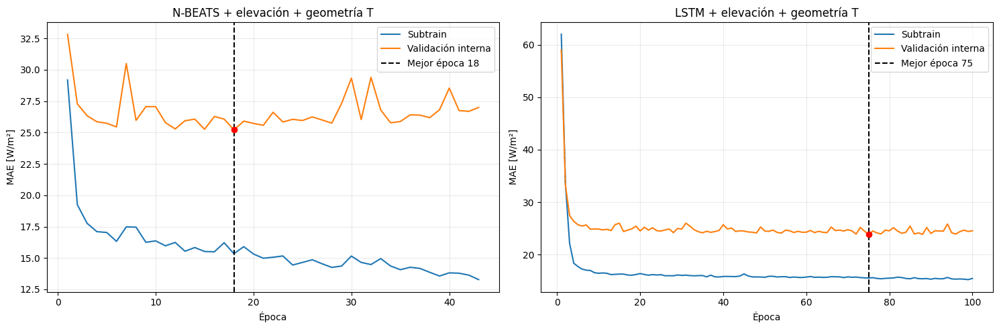

In [ ]:
# 1. Preparar geometría conocida del objetivo
COLUMNAS_GEOMETRIA_OBJETIVO = [
    "elevacion_media",
    "elevacion_minima",
    "elevacion_maxima",
    "fraccion_minutos_dia",
]
objetos_necesarios = [
    "X_train_DIF_elevacion_raw",
    "y_train_secuencial",
    "geometria_objetivo_train",
    "train_hgb",
]
faltantes = [nombre for nombre in objetos_necesarios if nombre not in globals()]
if faltantes:
    raise RuntimeError(f"Faltan objetos necesarios: {faltantes}")

tiempos_geometria = pd.to_datetime(geometria_objetivo_train["instante_objetivo"], utc=True)
tiempos_train = pd.to_datetime(train_hgb["instante_objetivo"], utc=True)
if not tiempos_geometria.equals(tiempos_train.reset_index(drop=True)):
    raise RuntimeError("La geometría objetivo no está alineada con train_hgb.")

X_train_secuencia_raw = np.asarray(X_train_DIF_elevacion_raw, dtype=np.float32)
G_train_objetivo_raw = geometria_objetivo_train[COLUMNAS_GEOMETRIA_OBJETIVO].to_numpy(
    dtype=np.float32
)
y_train_contexto_raw = np.asarray(y_train_secuencial, dtype=np.float32).reshape(-1)
assert X_train_secuencia_raw.shape == (5149, 24, 2)
assert G_train_objetivo_raw.shape == (5149, 4)
assert y_train_contexto_raw.shape == (5149,)
assert np.isfinite(X_train_secuencia_raw).all()
assert np.isfinite(G_train_objetivo_raw).all()
assert np.isfinite(y_train_contexto_raw).all()

# 2. Misma división cronológica anterior
N_TRAIN = len(y_train_contexto_raw)
N_SUBTRAIN = N_TRAIN - N_VALIDACION_INTERNA
X_subtrain_contexto_raw = X_train_secuencia_raw[:N_SUBTRAIN]
X_interna_contexto_raw = X_train_secuencia_raw[N_SUBTRAIN:]
G_subtrain_raw = G_train_objetivo_raw[:N_SUBTRAIN]
G_interna_raw = G_train_objetivo_raw[N_SUBTRAIN:]
y_subtrain_contexto_raw = y_train_contexto_raw[:N_SUBTRAIN]
y_interna_contexto_raw = y_train_contexto_raw[N_SUBTRAIN:]
print("Subtrain secuencial:", X_subtrain_contexto_raw.shape)
print("Subtrain geometría:", G_subtrain_raw.shape)
print("Validación interna secuencial:", X_interna_contexto_raw.shape)
print("Validación interna geometría:", G_interna_raw.shape)

# 3. Escalado sin fuga

# DIF y elevación histórica
escaladores_subtrain_geometria = ajustar_escaladores(
    X_subtrain_contexto_raw, y_subtrain_contexto_raw
)
X_subtrain_contexto = transformar_X(X_subtrain_contexto_raw, escaladores_subtrain_geometria)
X_interna_contexto = transformar_X(X_interna_contexto_raw, escaladores_subtrain_geometria)
y_subtrain_contexto = transformar_y(y_subtrain_contexto_raw, escaladores_subtrain_geometria)
y_interna_contexto = transformar_y(y_interna_contexto_raw, escaladores_subtrain_geometria)

# Geometría del objetivo: escalado columna a columna
media_geometria_subtrain = G_subtrain_raw.mean(axis=0)
std_geometria_subtrain = G_subtrain_raw.std(axis=0, ddof=0)
if np.any(std_geometria_subtrain <= 0):
    raise ValueError("Alguna variable geométrica tiene desviación nula.")

G_subtrain = ((G_subtrain_raw - media_geometria_subtrain) / std_geometria_subtrain).astype(
    np.float32
)
G_interna = ((G_interna_raw - media_geometria_subtrain) / std_geometria_subtrain).astype(np.float32)
escaladores_geometria_objetivo_subtrain = {
    columna: {"media": float(media), "std": float(std)}
    for columna, media, std in zip(
        COLUMNAS_GEOMETRIA_OBJETIVO, media_geometria_subtrain, std_geometria_subtrain
    )
}
print("\nEscaladores de geometría objetivo:")
for columna, valores in escaladores_geometria_objetivo_subtrain.items():
    print(f"{columna:25s} | " f"media={valores['media']:.6f} | " f"std={valores['std']:.6f}")

# 4. DataLoaders con secuencia, geometría y objetivo
def crear_loader_contexto(X, G, y, shuffle, semilla=42):
    dataset = TensorDataset(
        torch.from_numpy(np.asarray(X, dtype=np.float32)),
        torch.from_numpy(np.asarray(G, dtype=np.float32)),
        torch.from_numpy(np.asarray(y, dtype=np.float32)),
    )
    generador = torch.Generator()
    generador.manual_seed(semilla)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        generator=generador if shuffle else None,
    )


# 5. N-BEATS con contexto geométrico objetivo
class BloqueNBEATSGeometriaObjetivo(nn.Module):
    def __init__(
        self,
        longitud_backcast=24,
        dimension_elevacion_historica=24,
        dimension_geometria_objetivo=4,
        unidades_ocultas=128,
        capas_densas=3,
        horizonte=1,
    ):
        super().__init__()
        dimension_entrada = (
            longitud_backcast + dimension_elevacion_historica + dimension_geometria_objetivo
        )
        capas = []
        for indice in range(capas_densas):
            dimension_capa = dimension_entrada if indice == 0 else unidades_ocultas
            capas.extend([nn.Linear(dimension_capa, unidades_ocultas), nn.ReLU()])

        self.red_densa = nn.Sequential(*capas)
        self.cabeza_backcast = nn.Linear(unidades_ocultas, longitud_backcast)
        self.cabeza_forecast = nn.Linear(unidades_ocultas, horizonte)

    def forward(self, residual_DIF, elevacion_historica, geometria_objetivo):
        entrada = torch.cat([residual_DIF, elevacion_historica, geometria_objetivo], dim=1)
        representacion = self.red_densa(entrada)
        backcast = self.cabeza_backcast(representacion)
        forecast = self.cabeza_forecast(representacion)
        return backcast, forecast

class NBEATSGeometriaObjetivo(nn.Module):
    def __init__(
        self,
        longitud_backcast=24,
        dimension_geometria_objetivo=4,
        horizonte=1,
        n_stacks=2,
        bloques_por_stack=3,
        capas_densas=3,
        unidades_ocultas=128,
    ):
        super().__init__()
        numero_bloques = n_stacks * bloques_por_stack
        self.bloques = nn.ModuleList(
            [
                BloqueNBEATSGeometriaObjetivo(
                    longitud_backcast=longitud_backcast,
                    dimension_elevacion_historica=(longitud_backcast),
                    dimension_geometria_objetivo=(dimension_geometria_objetivo),
                    unidades_ocultas=unidades_ocultas,
                    capas_densas=capas_densas,
                    horizonte=horizonte,
                )
                for _ in range(numero_bloques)
            ]
        )

    def forward(self, X, G):
        residual_DIF = X[:, :, 0]
        elevacion_historica = X[:, :, 1]
        forecast_total = torch.zeros((X.shape[0], 1), dtype=X.dtype, device=X.device)
        for bloque in self.bloques:
            backcast, forecast = bloque(residual_DIF, elevacion_historica, G)
            residual_DIF = residual_DIF - backcast
            forecast_total = forecast_total + forecast

        return forecast_total.squeeze(-1)


# 6. LSTM con geometría objetivo en la cabeza
class LSTMGeometriaObjetivo(nn.Module):
    def __init__(self, input_size=2, hidden_size=64, num_layers=1, dimension_geometria_objetivo=4):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_size, hidden_size=hidden_size, num_layers=num_layers, batch_first=True
        )
        self.cabeza = nn.Sequential(
            nn.Linear(hidden_size + dimension_geometria_objetivo, 32), nn.ReLU(), nn.Linear(32, 1)
        )

    def forward(self, X, G):
        salida_secuencial, _ = self.lstm(X)
        ultimo_estado = salida_secuencial[:, -1, :]
        contexto_completo = torch.cat([ultimo_estado, G], dim=1)
        return self.cabeza(contexto_completo).squeeze(-1)


# 7. Entrenamiento y validación
def entrenar_una_epoca_contexto(modelo, loader, optimizador, criterio, std_DIF):
    modelo.train()
    error_absoluto_escalado = 0.0
    numero_observaciones = 0
    for X_batch, G_batch, y_batch in loader:
        X_batch = X_batch.to(DEVICE, non_blocking=True)
        G_batch = G_batch.to(DEVICE, non_blocking=True)
        y_batch = y_batch.to(DEVICE, non_blocking=True)
        optimizador.zero_grad(set_to_none=True)
        prediccion = modelo(X_batch, G_batch)
        perdida = criterio(prediccion, y_batch)
        perdida.backward()
        nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=CLIP_NORM)
        optimizador.step()
        error_absoluto_escalado += torch.abs(prediccion.detach() - y_batch).sum().item()
        numero_observaciones += len(y_batch)

    return error_absoluto_escalado / numero_observaciones * std_DIF

@torch.no_grad()
def evaluar_modelo_contexto(modelo, loader, std_DIF):
    modelo.eval()
    error_absoluto_escalado = 0.0
    numero_observaciones = 0
    for X_batch, G_batch, y_batch in loader:
        X_batch = X_batch.to(DEVICE, non_blocking=True)
        G_batch = G_batch.to(DEVICE, non_blocking=True)
        y_batch = y_batch.to(DEVICE, non_blocking=True)
        prediccion = modelo(X_batch, G_batch)
        error_absoluto_escalado += torch.abs(prediccion - y_batch).sum().item()
        numero_observaciones += len(y_batch)

    return error_absoluto_escalado / numero_observaciones * std_DIF


# 8. Selección de época
def seleccionar_epoca_contexto(nombre_modelo, fabrica_modelo):
    fijar_semilla(SEMILLA)
    loader_subtrain = crear_loader_contexto(
        X_subtrain_contexto, G_subtrain, y_subtrain_contexto, shuffle=True, semilla=SEMILLA
    )
    loader_interna = crear_loader_contexto(
        X_interna_contexto, G_interna, y_interna_contexto, shuffle=False
    )
    modelo = fabrica_modelo().to(DEVICE)
    numero_parametros = sum(
        parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad
    )
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterio = nn.L1Loss()
    mejor_MAE = np.inf
    mejor_epoca = None
    contador_paciencia = 0
    historial = []
    print(f"\n{'=' * 74}")
    print(nombre_modelo)
    print("Parámetros entrenables:", numero_parametros)
    print(f"{'=' * 74}")
    with MedidorRecursos() as medidor:
        for epoca in range(1, MAX_EPOCHS + 1):
            MAE_subtrain = entrenar_una_epoca_contexto(
                modelo=modelo,
                loader=loader_subtrain,
                optimizador=optimizador,
                criterio=criterio,
                std_DIF=(escaladores_subtrain_geometria["std_DIF"]),
            )
            MAE_interno = evaluar_modelo_contexto(
                modelo=modelo,
                loader=loader_interna,
                std_DIF=(escaladores_subtrain_geometria["std_DIF"]),
            )
            historial.append(
                {
                    "modelo": nombre_modelo,
                    "epoca": epoca,
                    "MAE_subtrain": MAE_subtrain,
                    "MAE_validacion_interna": (MAE_interno),
                }
            )
            if MAE_interno < mejor_MAE - MIN_DELTA:
                mejor_MAE = MAE_interno
                mejor_epoca = epoca
                contador_paciencia = 0
            else:
                contador_paciencia += 1

            if epoca == 1 or epoca % 10 == 0 or epoca == mejor_epoca:
                print(
                    f"Época {epoca:3d} | "
                    f"MAE subtrain={MAE_subtrain:8.4f} | "
                    f"MAE interna={MAE_interno:8.4f} | "
                    f"mejor={mejor_MAE:8.4f} "
                    f"(época {mejor_epoca})"
                )

            if contador_paciencia >= PATIENCE:
                print("\nEarly stopping en época", epoca)
                break

    historial = pd.DataFrame(historial)
    resultado = {
        "modelo": nombre_modelo,
        "mejor_epoca": int(mejor_epoca),
        "mejor_MAE_interno": float(mejor_MAE),
        "epocas_ejecutadas": int(len(historial)),
        "tiempo_seleccion_s": float(medidor.tiempo_s),
        "tiempo_por_epoca_s": float(medidor.tiempo_s / len(historial)),
        "parametros_entrenables": int(numero_parametros),
        "rss_pico_MB": float(medidor.rss_pico_MB),
        "incremento_rss_MB": float(medidor.incremento_rss_MB),
        "gpu_pico_MB": float(medidor.gpu_pico_MB),
    }
    del modelo
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return resultado, historial


# 9. Ejecutar selección de N-BEATS
resultado_seleccion_nbeats_geometria, historial_nbeats_geometria = seleccionar_epoca_contexto(
    nombre_modelo=("NBEATS-U24-DIF-ElevHist-GeomT"),
    fabrica_modelo=lambda: (NBEATSGeometriaObjetivo()),
)

# 10. Ejecutar selección de LSTM
resultado_seleccion_lstm_geometria, historial_lstm_geometria = seleccionar_epoca_contexto(
    nombre_modelo=("LSTM-U24-DIF-ElevHist-GeomT"), fabrica_modelo=lambda: (LSTMGeometriaObjetivo())
)

# 11. Resumen
resumen_seleccion_geometria = pd.DataFrame(
    [resultado_seleccion_nbeats_geometria, resultado_seleccion_lstm_geometria]
)
display(resumen_seleccion_geometria)

# 12. Guardar historiales
DIRECTORIO_GEOMETRIA_OBJETIVO = DIRECTORIO_RESULTADOS_ELEVACION / "geometria_objetivo"
DIRECTORIO_GEOMETRIA_OBJETIVO.mkdir(parents=True, exist_ok=True)
historial_nbeats_geometria.to_csv(
    DIRECTORIO_GEOMETRIA_OBJETIVO / "historial_seleccion_NBEATS_geometria.csv", index=False
)
historial_lstm_geometria.to_csv(
    DIRECTORIO_GEOMETRIA_OBJETIVO / "historial_seleccion_LSTM_geometria.csv", index=False
)
resumen_seleccion_geometria.to_csv(
    DIRECTORIO_GEOMETRIA_OBJETIVO / "resumen_seleccion_geometria.csv", index=False
)

# 13. Curvas de selección
fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
for eje, historial, resultado, titulo in [
    (
        ejes[0],
        historial_nbeats_geometria,
        resultado_seleccion_nbeats_geometria,
        "N-BEATS + elevación + geometría T",
    ),
    (
        ejes[1],
        historial_lstm_geometria,
        resultado_seleccion_lstm_geometria,
        "LSTM + elevación + geometría T",
    ),
]:
    eje.plot(historial["epoca"], historial["MAE_subtrain"], label="Subtrain")
    eje.plot(historial["epoca"], historial["MAE_validacion_interna"], label="Validación interna")
    eje.axvline(
        resultado["mejor_epoca"],
        color="black",
        linestyle="--",
        label=(f"Mejor época " f"{resultado['mejor_epoca']}"),
    )
    eje.scatter([resultado["mejor_epoca"]], [resultado["mejor_MAE_interno"]], color="red", zorder=5)
    eje.set_title(titulo)
    eje.set_xlabel("Época")
    eje.set_ylabel("MAE [W/m²]")
    eje.grid(alpha=0.25)
    eje.legend()

plt.tight_layout()
plt.show()

In [ ]:
import json
import statistics

# 1. Preparar geometría de train y validation
objetos_necesarios = [
    "X_train_DIF_elevacion_raw",
    "X_validation_DIF_elevacion_raw",
    "geometria_objetivo_train",
    "geometria_objetivo_validation",
    "y_train_secuencial",
    "y_validation_secuencial",
    "resultado_seleccion_nbeats_geometria",
    "resultado_seleccion_lstm_geometria",
]
faltantes = [nombre for nombre in objetos_necesarios if nombre not in globals()]
if faltantes:
    raise RuntimeError(f"Faltan objetos necesarios: {faltantes}")

X_train_geometria_raw = np.asarray(X_train_DIF_elevacion_raw, dtype=np.float32)
X_validation_geometria_raw = np.asarray(X_validation_DIF_elevacion_raw, dtype=np.float32)
G_train_geometria_raw = geometria_objetivo_train[COLUMNAS_GEOMETRIA_OBJETIVO].to_numpy(
    dtype=np.float32
)
G_validation_geometria_raw = geometria_objetivo_validation[COLUMNAS_GEOMETRIA_OBJETIVO].to_numpy(
    dtype=np.float32
)
y_train_geometria_raw = np.asarray(y_train_secuencial, dtype=np.float32).reshape(-1)
y_validation_geometria_raw = np.asarray(y_validation_secuencial, dtype=np.float32).reshape(-1)
assert X_train_geometria_raw.shape == (5149, 24, 2)
assert X_validation_geometria_raw.shape == (1464, 24, 2)
assert G_train_geometria_raw.shape == (5149, 4)
assert G_validation_geometria_raw.shape == (1464, 4)

# 2. Comprobar alineación temporal de validation
tiempos_geometria_validation = pd.to_datetime(
    geometria_objetivo_validation["instante_objetivo"], utc=True
)
tiempos_validation_hgb = pd.to_datetime(validation_hgb["instante_objetivo"], utc=True)
if not tiempos_geometria_validation.equals(tiempos_validation_hgb.reset_index(drop=True)):
    raise RuntimeError("La geometría de validation no está alineada.")

# 3. Escaladores ajustados únicamente con todo train
escaladores_train_geometria = ajustar_escaladores(X_train_geometria_raw, y_train_geometria_raw)
X_train_geometria = transformar_X(X_train_geometria_raw, escaladores_train_geometria)
X_validation_geometria = transformar_X(X_validation_geometria_raw, escaladores_train_geometria)
y_train_geometria = transformar_y(y_train_geometria_raw, escaladores_train_geometria)

# Geometría objetivo
media_G_train = G_train_geometria_raw.mean(axis=0)
std_G_train = G_train_geometria_raw.std(axis=0, ddof=0)
if np.any(std_G_train <= 0):
    raise ValueError("Alguna variable geométrica tiene desviación nula.")

G_train_geometria = ((G_train_geometria_raw - media_G_train) / std_G_train).astype(np.float32)
G_validation_geometria = ((G_validation_geometria_raw - media_G_train) / std_G_train).astype(
    np.float32
)
escaladores_G_train = {
    columna: {"media": float(media), "std": float(std)}
    for columna, media, std in zip(COLUMNAS_GEOMETRIA_OBJETIVO, media_G_train, std_G_train)
}
print("Escaladores secuenciales:")
for clave, valor in escaladores_train_geometria.items():
    print(f"{clave}: {valor:.10f}")

print("\nEscaladores de geometría objetivo:")
for columna, valores in escaladores_G_train.items():
    print(f"{columna:25s} | " f"media={valores['media']:.6f} | " f"std={valores['std']:.6f}")

DIRECTORIO_GEOMETRIA_OBJETIVO.mkdir(parents=True, exist_ok=True)
with open(
    DIRECTORIO_GEOMETRIA_OBJETIVO / "escaladores_train_geometria_objetivo.json",
    "w",
    encoding="utf-8",
) as archivo:
    json.dump(
        {"secuencia": escaladores_train_geometria, "geometria_objetivo": escaladores_G_train},
        archivo,
        ensure_ascii=False,
        indent=2,
    )

# 4. Loader de inferencia
def crear_loader_prediccion_contexto(X, G, batch_size=512):
    dataset = TensorDataset(
        torch.from_numpy(np.asarray(X, dtype=np.float32)),
        torch.from_numpy(np.asarray(G, dtype=np.float32)),
    )
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )

@torch.no_grad()
def predecir_contexto_escalado(modelo, loader):
    modelo.eval()
    predicciones = []
    for X_batch, G_batch in loader:
        X_batch = X_batch.to(DEVICE, non_blocking=True)
        G_batch = G_batch.to(DEVICE, non_blocking=True)
        prediccion = modelo(X_batch, G_batch)
        predicciones.append(prediccion.detach().cpu().numpy())

    return np.concatenate(predicciones)


# 5. Reajuste final de un modelo
def reentrenar_contexto_final(nombre_modelo, fabrica_modelo, numero_epocas, nombre_checkpoint):
    fijar_semilla(SEMILLA)
    loader_train = crear_loader_contexto(
        X_train_geometria, G_train_geometria, y_train_geometria, shuffle=True, semilla=SEMILLA
    )
    loader_validation = crear_loader_prediccion_contexto(
        X_validation_geometria, G_validation_geometria, batch_size=512
    )
    modelo = fabrica_modelo().to(DEVICE)
    numero_parametros = sum(
        parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad
    )
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterio = nn.L1Loss()
    historial_final = []
    print(f"\n{'=' * 76}")
    print("Reajuste final:", nombre_modelo)
    print("Épocas:", numero_epocas)
    print("Parámetros:", numero_parametros)
    print(f"{'=' * 76}")

    # Entrenamiento
    with MedidorRecursos() as medidor_reajuste:
        for epoca in range(1, numero_epocas + 1):
            MAE_train = entrenar_una_epoca_contexto(
                modelo=modelo,
                loader=loader_train,
                optimizador=optimizador,
                criterio=criterio,
                std_DIF=(escaladores_train_geometria["std_DIF"]),
            )
            historial_final.append(
                {"modelo": nombre_modelo, "epoca": epoca, "MAE_train_completo": MAE_train}
            )
            if epoca == 1 or epoca % 5 == 0 or epoca == numero_epocas:
                print(f"Época {epoca:3d}/{numero_epocas} | " f"MAE train={MAE_train:.4f}")

    historial_final = pd.DataFrame(historial_final)

    # Primera inferencia
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    inicio_primera = time.perf_counter()
    prediccion_escalada = predecir_contexto_escalado(modelo, loader_validation)
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    tiempo_primera_inferencia = time.perf_counter() - inicio_primera

    # Inferencia repetida
    tiempos_inferencia = []
    with MedidorRecursos() as medidor_inferencia:
        for _ in range(30):
            if torch.cuda.is_available():
                torch.cuda.synchronize()

            inicio = time.perf_counter()
            prediccion_escalada = predecir_contexto_escalado(modelo, loader_validation)
            if torch.cuda.is_available():
                torch.cuda.synchronize()

            tiempos_inferencia.append(time.perf_counter() - inicio)

    tiempo_inferencia_mediana = float(statistics.median(tiempos_inferencia))
    tiempo_inferencia_media = float(np.mean(tiempos_inferencia))

    # Desescalar y evaluar
    prediccion_real = (
        prediccion_escalada * escaladores_train_geometria["std_DIF"]
        + escaladores_train_geometria["media_DIF"]
    ).astype(np.float64)
    error = prediccion_real - y_validation_geometria_raw
    MAE_validation = float(np.mean(np.abs(error)))
    RMSE_validation = float(np.sqrt(np.mean(error**2)))
    sesgo_validation = float(np.mean(error))
    denominador_R2 = np.sum((y_validation_geometria_raw - y_validation_geometria_raw.mean()) ** 2)
    R2_validation = float(1 - np.sum(error**2) / denominador_R2)

    # Guardar checkpoint
    ruta_checkpoint = DIRECTORIO_GEOMETRIA_OBJETIVO / nombre_checkpoint
    checkpoint = {
        "nombre_modelo": nombre_modelo,
        "state_dict": modelo.state_dict(),
        "numero_epocas": int(numero_epocas),
        "semilla": SEMILLA,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "clip_norm": CLIP_NORM,
        "escaladores_secuencia": (escaladores_train_geometria),
        "escaladores_geometria_objetivo": (escaladores_G_train),
        "columnas_geometria_objetivo": (COLUMNAS_GEOMETRIA_OBJETIVO),
        "forma_secuencia": [24, 2],
        "dimension_geometria_objetivo": 4,
        "parametros_entrenables": (numero_parametros),
    }
    torch.save(checkpoint, ruta_checkpoint)
    tamaño_checkpoint_MB = ruta_checkpoint.stat().st_size / 1024**2
    resultado = {
        "modelo": nombre_modelo,
        "epocas_reajuste": int(numero_epocas),
        "parametros_entrenables": int(numero_parametros),
        "tiempo_reajuste_s": float(medidor_reajuste.tiempo_s),
        "tiempo_reajuste_por_epoca_s": float(medidor_reajuste.tiempo_s / numero_epocas),
        "rss_pico_reajuste_MB": float(medidor_reajuste.rss_pico_MB),
        "incremento_rss_reajuste_MB": float(medidor_reajuste.incremento_rss_MB),
        "gpu_pico_reajuste_MB": float(medidor_reajuste.gpu_pico_MB),
        "tiempo_primera_inferencia_s": float(tiempo_primera_inferencia),
        "tiempo_inferencia_mediana_s": float(tiempo_inferencia_mediana),
        "tiempo_inferencia_media_s": float(tiempo_inferencia_media),
        "inferencia_microsegundos_muestra": float(
            tiempo_inferencia_mediana / len(X_validation_geometria) * 1e6
        ),
        "rss_pico_inferencia_MB": float(medidor_inferencia.rss_pico_MB),
        "gpu_pico_inferencia_MB": float(medidor_inferencia.gpu_pico_MB),
        "tamaño_checkpoint_MB": float(tamaño_checkpoint_MB),
        "MAE_validation": MAE_validation,
        "RMSE_validation": RMSE_validation,
        "R2_validation": R2_validation,
        "sesgo_validation": sesgo_validation,
    }
    print("\nResultado final:")
    print(f"MAE validation: {MAE_validation:.4f}")
    print(f"RMSE validation: {RMSE_validation:.4f}")
    print(f"R² validation: {R2_validation:.6f}")
    print(f"Sesgo validation: {sesgo_validation:.4f}")
    print("Tiempo reajuste:", f"{medidor_reajuste.tiempo_s:.3f} s")
    print("Inferencia mediana:", f"{tiempo_inferencia_mediana:.6f} s")
    print("Checkpoint:", f"{tamaño_checkpoint_MB:.3f} MB")
    return (modelo, prediccion_real, resultado, historial_final)


# 6. N-BEATS: reajuste durante 18 épocas
(
    modelo_nbeats_geometria_final,
    prediccion_nbeats_geometria_validation,
    resultado_final_nbeats_geometria,
    historial_final_nbeats_geometria,
) = reentrenar_contexto_final(
    nombre_modelo=("NBEATS-U24-DIF-ElevHist-GeomT"),
    fabrica_modelo=lambda: (NBEATSGeometriaObjetivo()),
    numero_epocas=(resultado_seleccion_nbeats_geometria["mejor_epoca"]),
    nombre_checkpoint=("NBEATS_U24_DIF_ElevHist_GeomT_final.pt"),
)

# 7. LSTM: reajuste durante 75 épocas
(
    modelo_lstm_geometria_final,
    prediccion_lstm_geometria_validation,
    resultado_final_lstm_geometria,
    historial_final_lstm_geometria,
) = reentrenar_contexto_final(
    nombre_modelo=("LSTM-U24-DIF-ElevHist-GeomT"),
    fabrica_modelo=lambda: (LSTMGeometriaObjetivo()),
    numero_epocas=(resultado_seleccion_lstm_geometria["mejor_epoca"]),
    nombre_checkpoint=("LSTM_U24_DIF_ElevHist_GeomT_final.pt"),
)

# 8. Resumen
resumen_final_geometria = pd.DataFrame(
    [
        {**resultado_seleccion_nbeats_geometria, **resultado_final_nbeats_geometria},
        {**resultado_seleccion_lstm_geometria, **resultado_final_lstm_geometria},
    ]
)
display(resumen_final_geometria)

# 9. Tabla de predicciones
predicciones_validation_geometria = (
    validation_hgb[["instante_objetivo", "DIF_objetivo_t1", "regimen_solar_objetivo", "DIF_lag_1"]]
    .copy()
    .reset_index(drop=True)
)
predicciones_validation_geometria.rename(columns={"DIF_objetivo_t1": "DIF_real"}, inplace=True)
predicciones_validation_geometria["NBEATS_DIF_ElevHist_GeomT"] = (
    prediccion_nbeats_geometria_validation
)
predicciones_validation_geometria["LSTM_DIF_ElevHist_GeomT"] = prediccion_lstm_geometria_validation
for modelo in ["NBEATS_DIF_ElevHist_GeomT", "LSTM_DIF_ElevHist_GeomT"]:
    predicciones_validation_geometria[f"error_{modelo}"] = (
        predicciones_validation_geometria[modelo] - predicciones_validation_geometria["DIF_real"]
    )
    predicciones_validation_geometria[f"error_abs_{modelo}"] = np.abs(
        predicciones_validation_geometria[f"error_{modelo}"]
    )

display(predicciones_validation_geometria.head())

# 10. Guardar
historial_final_nbeats_geometria.to_csv(
    DIRECTORIO_GEOMETRIA_OBJETIVO / "historial_reajuste_NBEATS_geometria.csv", index=False
)
historial_final_lstm_geometria.to_csv(
    DIRECTORIO_GEOMETRIA_OBJETIVO / "historial_reajuste_LSTM_geometria.csv", index=False
)
resumen_final_geometria.to_csv(
    DIRECTORIO_GEOMETRIA_OBJETIVO / "resumen_final_geometria.csv", index=False
)
predicciones_validation_geometria.to_parquet(
    DIRECTORIO_GEOMETRIA_OBJETIVO / "predicciones_validation_geometria.parquet", index=False
)
predicciones_validation_geometria.to_csv(
    DIRECTORIO_GEOMETRIA_OBJETIVO / "predicciones_validation_geometria.csv", index=False
)
print("\nResultados guardados en:", DIRECTORIO_GEOMETRIA_OBJETIVO)

Escaladores secuenciales:
media_DIF: 80.2950820923
std_DIF: 112.1702117920
media_elevacion: 4.6184706688
std_elevacion: 29.9171199799

Escaladores de geometría objetivo:
elevacion_media           | media=4.638996 | std=29.901457
elevacion_minima          | media=1.525886 | std=29.747791
elevacion_maxima          | media=7.755438 | std=29.875500
fraccion_minutos_dia      | media=0.546559 | std=0.483797

Reajuste final: NBEATS-U24-DIF-ElevHist-GeomT
Épocas: 18
Parámetros: 258198
Época   1/18 | MAE train=31.0438
Época   5/18 | MAE train=18.5600
Época  10/18 | MAE train=17.1453
Época  15/18 | MAE train=16.9139
Época  18/18 | MAE train=17.3747

Resultado final:
MAE validation: 17.8262
RMSE validation: 33.0240
R² validation: 0.906704
Sesgo validation: 5.0486
Tiempo reajuste: 26.014 s
Inferencia mediana: 0.046685 s
Checkpoint: 1.008 MB

Reajuste final: LSTM-U24-DIF-ElevHist-GeomT
Épocas: 75
Parámetros: 19649
Época   1/75 | MAE train=62.5756
Época   5/75 | MAE train=18.6275
Época  10/75 | MAE 

,modelo,mejor_epoca,mejor_MAE_interno,epocas_ejecutadas,tiempo_seleccion_s,tiempo_por_epoca_s,parametros_entrenables,rss_pico_MB,incremento_rss_MB,gpu_pico_MB,...,tiempo_inferencia_mediana_s,tiempo_inferencia_media_s,inferencia_microsegundos_muestra,rss_pico_inferencia_MB,gpu_pico_inferencia_MB,tamaño_checkpoint_MB,MAE_validation,RMSE_validation,R2_validation,sesgo_validation
0,NBEATS-U24-DIF-ElevHist-GeomT,18,25.206942,43,65.647459,1.526685,258198,608.238281,0.031250,0.0,...,0.046685,0.047233,31.888341,597.878906,0.0,1.007850,17.826234,33.023980,0.906704,5.048550
1,LSTM-U24-DIF-ElevHist-GeomT,75,23.825189,100,88.887712,0.888877,19649,618.085938,9.851562,0.0,...,0.098585,0.106552,67.339379,609.945312,0.0,0.079583,16.265980,32.285251,0.910831,0.640672


,instante_objetivo,DIF_real,regimen_solar_objetivo,DIF_lag_1,NBEATS_DIF_ElevHist_GeomT,LSTM_DIF_ElevHist_GeomT,error_NBEATS_DIF_ElevHist_GeomT,error_abs_NBEATS_DIF_ElevHist_GeomT,error_LSTM_DIF_ElevHist_GeomT,error_abs_LSTM_DIF_ElevHist_GeomT
0,2024-08-01 00:00:00+00:00,-1.0,noche,-1.0,-0.965263,-0.443344,0.034737,0.034737,0.556656,0.556656
1,2024-08-01 01:00:00+00:00,-1.0,noche,-1.0,-0.830811,-0.543213,0.169189,0.169189,0.456787,0.456787
2,2024-08-01 02:00:00+00:00,-1.0,noche,-1.0,-0.044846,-0.584274,0.955154,0.955154,0.415726,0.415726
3,2024-08-01 03:00:00+00:00,0.4,noche,-1.0,0.958237,-0.482300,0.558237,0.558237,-0.882300,0.882300
4,2024-08-01 04:00:00+00:00,28.8,transicion,0.4,27.239040,15.560349,-1.560960,1.560960,-13.239651,13.239651



Resultados guardados en: /content/experimento_secuencial_elevacion/geometria_objetivo


Diferencia máxima entre objetivos: 1.4241536462122895e-05

MAE DE LOS SIETE MODELOS


modelo,HGB-9V,N-BEATS DIF,LSTM DIF,N-BEATS DIF+Elev,LSTM DIF+Elev,N-BEATS DIF+Elev+GeomT,LSTM DIF+Elev+GeomT
regimen,,,,,,,
Total,16.5624,18.7116,17.0423,16.8836,16.7831,17.8262,16.2660
Operacional,27.3534,29.2961,28.0004,27.6235,27.4197,28.4121,26.5408
Completamente diurno,31.2125,32.5305,31.7180,31.3692,31.1945,31.9064,30.2528
Transición,2.5450,8.5037,4.1015,3.5436,3.1528,5.9489,2.6778
Noche,0.1154,2.5793,0.3406,0.5146,0.5716,1.6919,0.6058



RMSE DE LOS SIETE MODELOS


modelo,HGB-9V,N-BEATS DIF,LSTM DIF,N-BEATS DIF+Elev,LSTM DIF+Elev,N-BEATS DIF+Elev+GeomT,LSTM DIF+Elev+GeomT
regimen,,,,,,,
Total,33.0427,34.1018,33.0630,32.9200,33.0681,33.0240,32.2853
Operacional,42.5220,43.7932,42.5473,42.3609,42.5507,42.4617,41.5442
Completamente diurno,45.6836,46.8920,45.6784,45.4848,45.7098,45.5507,44.6344
Transición,3.9242,10.5500,5.8635,5.5084,4.2589,7.4344,3.7404
Noche,0.2919,3.5128,0.4356,0.7015,0.7649,2.1828,0.6755



R² DE LOS SIETE MODELOS


modelo,HGB-9V,N-BEATS DIF,LSTM DIF,N-BEATS DIF+Elev,LSTM DIF+Elev,N-BEATS DIF+Elev+GeomT,LSTM DIF+Elev+GeomT
regimen,,,,,,,
Total,0.906598,0.900515,0.906483,0.907290,0.906455,0.906704,0.910831
Operacional,0.839748,0.830023,0.839557,0.840959,0.839531,0.840202,0.847033
Completamente diurno,0.786551,0.775109,0.786599,0.788405,0.786306,0.787791,0.796243
Transición,0.693680,-1.214040,0.316087,0.396429,0.639188,-0.099447,0.721702
Noche,0.153143,-121.616582,-0.885633,-3.890174,-4.813636,-46.345449,-3.534399


... (3 outputs left out)

modelo,HGB-9V,LSTM DIF,LSTM DIF+Elev,LSTM DIF+Elev+GeomT,N-BEATS DIF,N-BEATS DIF+Elev,N-BEATS DIF+Elev+GeomT
quintil_cambio,,,,,,,
Q1,14.1153,18.8674,14.9252,16.2614,18.2952,19.0175,18.4068
Q2,17.1132,19.8521,16.2306,17.9209,21.6122,22.9932,22.6883
Q3,16.9516,18.9127,16.7395,15.9355,18.3539,19.1593,18.7806
Q4,22.8187,21.8319,21.4953,20.3625,21.6371,19.9719,20.4186
Q5,65.7094,60.4864,67.6473,62.1636,66.5205,56.9276,61.7119



BOOTSTRAP DIARIO DE DIFERENCIAS DE MAE


,regimen,comparacion,referencia,candidato,diferencia_MAE_ref_menos_candidato,IC95_inferior,IC95_superior,probabilidad_mejora,numero_dias
0,Total,HGB vs LSTM final,HGB-9V,LSTM DIF+Elev+GeomT,0.29642,-0.13895,0.72670,0.9038,61
1,Total,N-BEATS Elev vs +GeomT,N-BEATS DIF+Elev,N-BEATS DIF+Elev+GeomT,-0.94261,-1.17805,-0.70249,0.0000,61
2,Total,LSTM Elev vs +GeomT,LSTM DIF+Elev,LSTM DIF+Elev+GeomT,0.51713,0.20028,0.82476,0.9996,61
3,Operacional,HGB vs LSTM final,HGB-9V,LSTM DIF+Elev+GeomT,0.81266,0.10133,1.52604,0.9886,61
4,Operacional,N-BEATS Elev vs +GeomT,N-BEATS DIF+Elev,N-BEATS DIF+Elev+GeomT,-0.78867,-1.18270,-0.38942,0.0000,61
5,Operacional,LSTM Elev vs +GeomT,LSTM DIF+Elev,LSTM DIF+Elev+GeomT,0.87890,0.35669,1.38771,0.9998,61
6,Completamente diurno,HGB vs LSTM final,HGB-9V,LSTM DIF+Elev+GeomT,0.95973,0.16280,1.75506,0.9922,61
7,Completamente diurno,N-BEATS Elev vs +GeomT,N-BEATS DIF+Elev,N-BEATS DIF+Elev+GeomT,-0.53721,-1.01939,-0.04714,0.0146,61
8,Completamente diurno,LSTM Elev vs +GeomT,LSTM DIF+Elev,LSTM DIF+Elev+GeomT,0.94174,0.34237,1.52781,0.9994,61
9,Transición,HGB vs LSTM final,HGB-9V,LSTM DIF+Elev+GeomT,-0.13283,-0.51432,0.27335,0.2426,61


,modelo,mejor_epoca,parametros_entrenables,tiempo_seleccion_s,tiempo_reajuste_s,tiempo_inferencia_mediana_s,tamaño_checkpoint_MB,observacion
0,HGB-9V,NaN,NaN,NaN,NaN,NaN,0.282013,Tiempos no registrados; requiere reentrenamien...
1,N-BEATS-U24 DIF,8.0,236694.0,NaN,NaN,NaN,0.922252,Tiempos no registrados retrospectivamente.
2,LSTM-U24 DIF,118.0,19265.0,NaN,NaN,NaN,0.077451,Tiempos no registrados retrospectivamente.
3,N-BEATS-U24 DIF+Elev,15.0,255126.0,40.804431,19.027521,0.039214,0.995387,Medición completa.
4,LSTM-U24 DIF+Elev,35.0,19521.0,48.153225,43.194844,0.085472,0.078710,Medición completa.
5,N-BEATS DIF+Elev+GeomT,18.0,258198.0,65.647459,26.013912,0.046685,1.007850,NaN
6,LSTM DIF+Elev+GeomT,75.0,19649.0,88.887712,81.565635,0.098585,0.079583,NaN


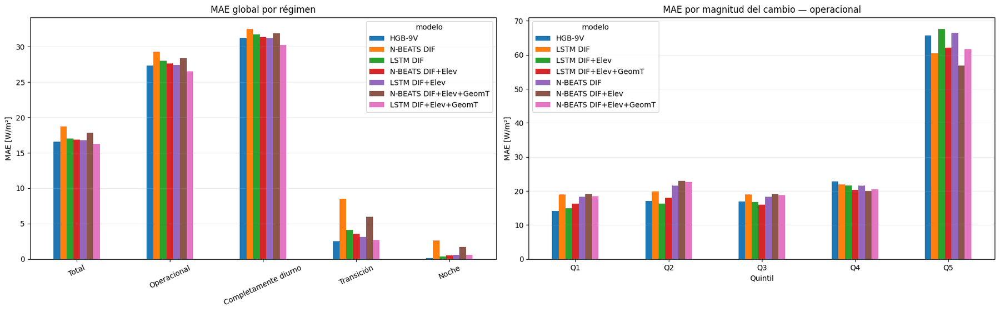


Comparación global guardada en: /content/experimento_secuencial_elevacion/geometria_objetivo/comparacion_global_siete_modelos


In [ ]:
from collections import OrderedDict

# 1. Integrar las nuevas predicciones
if "tabla_comparacion_elevacion" not in globals():
    raise RuntimeError("No está disponible tabla_comparacion_elevacion.")

if "predicciones_validation_geometria" not in globals():
    raise RuntimeError("No está disponible predicciones_validation_geometria.")

tabla_base_siete = tabla_comparacion_elevacion.copy()
tabla_geometria = predicciones_validation_geometria.copy()
tabla_base_siete["instante_objetivo"] = pd.to_datetime(
    tabla_base_siete["instante_objetivo"], utc=True
)
tabla_geometria["instante_objetivo"] = pd.to_datetime(
    tabla_geometria["instante_objetivo"], utc=True
)
columnas_geometria = [
    "instante_objetivo",
    "DIF_real",
    "NBEATS_DIF_ElevHist_GeomT",
    "LSTM_DIF_ElevHist_GeomT",
]
tabla_siete_modelos = (
    tabla_base_siete.merge(
        tabla_geometria[columnas_geometria],
        on="instante_objetivo",
        how="inner",
        validate="one_to_one",
        suffixes=("", "_geometria"),
    )
    .sort_values("instante_objetivo")
    .reset_index(drop=True)
)
assert len(tabla_siete_modelos) == 1464
diferencia_objetivo = np.abs(
    tabla_siete_modelos["DIF_real"] - tabla_siete_modelos["DIF_real_geometria"]
)
print("Diferencia máxima entre objetivos:", diferencia_objetivo.max())
if not np.allclose(
    tabla_siete_modelos["DIF_real"], tabla_siete_modelos["DIF_real_geometria"], rtol=1e-6, atol=1e-4
):
    raise RuntimeError("Los objetivos no están correctamente alineados.")

tabla_siete_modelos.drop(columns=["DIF_real_geometria"], inplace=True)

# 2. Mapa de los siete modelos
MAPA_SIETE_MODELOS = OrderedDict(
    {
        "HGB-9V": ("M3-HGB-9V-DIF-Elevacion-Delta1-AbsoluteError-Global"),
        "N-BEATS DIF": ("M4-NBEATS-U24-DIF-MAE-Global"),
        "LSTM DIF": ("M5-LSTM-U24-DIF-MAE-Global"),
        "N-BEATS DIF+Elev": ("NBEATS_DIF_ElevHist"),
        "LSTM DIF+Elev": ("LSTM_DIF_ElevHist"),
        "N-BEATS DIF+Elev+GeomT": ("NBEATS_DIF_ElevHist_GeomT"),
        "LSTM DIF+Elev+GeomT": ("LSTM_DIF_ElevHist_GeomT"),
    }
)
for modelo, columna in MAPA_SIETE_MODELOS.items():
    if columna not in tabla_siete_modelos.columns:
        raise KeyError(f"Falta la columna de {modelo}: {columna}")

# 3. Máscaras comunes
regimen_normalizado = (
    tabla_siete_modelos["regimen_solar_objetivo"].astype(str).str.lower().str.strip()
)
mascara_diurna = regimen_normalizado.str.contains("completamente").to_numpy()
mascara_transicion = regimen_normalizado.str.contains("trans").to_numpy()
mascara_noche = regimen_normalizado.str.contains("noche").to_numpy()
mascara_operacional = mascara_diurna | mascara_transicion
MASCARAS_SIETE = OrderedDict(
    {
        "Total": np.ones(len(tabla_siete_modelos), dtype=bool),
        "Operacional": mascara_operacional,
        "Completamente diurno": mascara_diurna,
        "Transición": mascara_transicion,
        "Noche": mascara_noche,
    }
)

# 4. Función de métricas
def metricas_globales(y_real, y_predicha):
    y_real = np.asarray(y_real, dtype=float)
    y_predicha = np.asarray(y_predicha, dtype=float)
    error = y_predicha - y_real
    error_absoluto = np.abs(error)
    MAE = float(np.mean(error_absoluto))
    RMSE = float(np.sqrt(np.mean(error**2)))
    sesgo = float(np.mean(error))
    media_real = float(np.mean(y_real))
    suma_total = np.sum((y_real - media_real) ** 2)
    R2 = float(1 - np.sum(error**2) / suma_total) if suma_total > 0 else np.nan
    return {
        "n": len(y_real),
        "MAE": MAE,
        "RMSE": RMSE,
        "R2": R2,
        "sesgo_pred_menos_real": sesgo,
        "mediana_error_absoluto": float(np.median(error_absoluto)),
        "p90_error_absoluto": float(np.quantile(error_absoluto, 0.90)),
        "p95_error_absoluto": float(np.quantile(error_absoluto, 0.95)),
        "p99_error_absoluto": float(np.quantile(error_absoluto, 0.99)),
    }


# 5. Métricas de los siete modelos por régimen
filas_metricas = []
for nombre_regimen, mascara in MASCARAS_SIETE.items():
    y_real = tabla_siete_modelos.loc[mascara, "DIF_real"]
    for nombre_modelo, columna in MAPA_SIETE_MODELOS.items():
        metricas = metricas_globales(y_real, tabla_siete_modelos.loc[mascara, columna])
        filas_metricas.append({"regimen": nombre_regimen, "modelo": nombre_modelo, **metricas})

metricas_siete_modelos = pd.DataFrame(filas_metricas)
orden_regimen = list(MASCARAS_SIETE.keys())
orden_modelos = list(MAPA_SIETE_MODELOS.keys())
metricas_siete_modelos["regimen"] = pd.Categorical(
    metricas_siete_modelos["regimen"], categories=orden_regimen, ordered=True
)
metricas_siete_modelos["modelo"] = pd.Categorical(
    metricas_siete_modelos["modelo"], categories=orden_modelos, ordered=True
)
metricas_siete_modelos.sort_values(["regimen", "modelo"], inplace=True)
tabla_MAE_siete = metricas_siete_modelos.pivot(
    index="regimen", columns="modelo", values="MAE"
).reindex(orden_regimen)
tabla_RMSE_siete = metricas_siete_modelos.pivot(
    index="regimen", columns="modelo", values="RMSE"
).reindex(orden_regimen)
tabla_R2_siete = metricas_siete_modelos.pivot(
    index="regimen", columns="modelo", values="R2"
).reindex(orden_regimen)
print("\nMAE DE LOS SIETE MODELOS")
display(tabla_MAE_siete.round(4))
print("\nRMSE DE LOS SIETE MODELOS")
display(tabla_RMSE_siete.round(4))
print("\nR² DE LOS SIETE MODELOS")
display(tabla_R2_siete.round(6))

# 6. Efectos incrementales de cada bloque
CONFIGURACIONES = {
    "N-BEATS": {
        "Solo DIF": "N-BEATS DIF",
        "+ ElevHist": "N-BEATS DIF+Elev",
        "+ GeomT": "N-BEATS DIF+Elev+GeomT",
    },
    "LSTM": {
        "Solo DIF": "LSTM DIF",
        "+ ElevHist": "LSTM DIF+Elev",
        "+ GeomT": "LSTM DIF+Elev+GeomT",
    },
}
filas_efectos = []
for regimen in orden_regimen:
    for arquitectura, modelos in CONFIGURACIONES.items():
        MAE_base = float(tabla_MAE_siete.loc[regimen, modelos["Solo DIF"]])
        MAE_elevacion = float(tabla_MAE_siete.loc[regimen, modelos["+ ElevHist"]])
        MAE_geometria = float(tabla_MAE_siete.loc[regimen, modelos["+ GeomT"]])
        filas_efectos.append(
            {
                "regimen": regimen,
                "arquitectura": arquitectura,
                "MAE_solo_DIF": MAE_base,
                "MAE_DIF_ElevHist": MAE_elevacion,
                "MAE_DIF_ElevHist_GeomT": MAE_geometria,
                "mejora_ElevHist_absoluta": (MAE_base - MAE_elevacion),
                "mejora_ElevHist_porcentaje": (100 * (MAE_base - MAE_elevacion) / MAE_base),
                "mejora_GeomT_absoluta": (MAE_elevacion - MAE_geometria),
                "mejora_GeomT_porcentaje": (100 * (MAE_elevacion - MAE_geometria) / MAE_elevacion),
                "mejora_total_absoluta": (MAE_base - MAE_geometria),
                "mejora_total_porcentaje": (100 * (MAE_base - MAE_geometria) / MAE_base),
            }
        )

efectos_incrementales = pd.DataFrame(filas_efectos)
print("\nEFECTOS INCREMENTALES")
display(efectos_incrementales.round(4))

# 7. Quintiles operacionales del cambio
tabla_operacional_siete = tabla_siete_modelos.loc[mascara_operacional].copy()
tabla_operacional_siete["delta_DIF_real"] = (
    tabla_operacional_siete["DIF_real"] - tabla_operacional_siete["DIF_lag_1"]
)
tabla_operacional_siete["magnitud_cambio_DIF"] = np.abs(tabla_operacional_siete["delta_DIF_real"])
try:
    tabla_operacional_siete["quintil_cambio"] = pd.qcut(
        tabla_operacional_siete["magnitud_cambio_DIF"], q=5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
    )

except ValueError:
    tabla_operacional_siete["quintil_cambio"] = pd.qcut(
        tabla_operacional_siete["magnitud_cambio_DIF"].rank(method="first"),
        q=5,
        labels=["Q1", "Q2", "Q3", "Q4", "Q5"],
    )

filas_quintiles = []
for quintil in ["Q1", "Q2", "Q3", "Q4", "Q5"]:
    subconjunto = tabla_operacional_siete[tabla_operacional_siete["quintil_cambio"] == quintil]
    for modelo, columna in MAPA_SIETE_MODELOS.items():
        filas_quintiles.append(
            {
                "quintil_cambio": quintil,
                "modelo": modelo,
                "n": len(subconjunto),
                "MAE": float(np.mean(np.abs(subconjunto[columna] - subconjunto["DIF_real"]))),
            }
        )

MAE_quintiles_siete = pd.DataFrame(filas_quintiles)
tabla_MAE_quintiles_siete = MAE_quintiles_siete.pivot(
    index="quintil_cambio", columns="modelo", values="MAE"
).reindex(["Q1", "Q2", "Q3", "Q4", "Q5"])
print("\nMAE POR QUINTIL OPERACIONAL")
display(tabla_MAE_quintiles_siete.round(4))

# 8. Comparación temporal por bootstrap diario
# Diferencia positiva:
# el modelo candidato mejora al modelo de referencia.
def bootstrap_diario_diferencia_MAE(
    tabla, mascara, columna_referencia, columna_candidata, repeticiones=5000, semilla=42
):
    subconjunto = tabla.loc[
        mascara, ["instante_objetivo", "DIF_real", columna_referencia, columna_candidata]
    ].copy()
    subconjunto["fecha"] = subconjunto["instante_objetivo"].dt.floor("D")
    subconjunto["error_ref"] = np.abs(subconjunto[columna_referencia] - subconjunto["DIF_real"])
    subconjunto["error_candidato"] = np.abs(
        subconjunto[columna_candidata] - subconjunto["DIF_real"]
    )
    diario = subconjunto.groupby("fecha", as_index=False).agg(
        suma_error_ref=("error_ref", "sum"),
        suma_error_candidato=("error_candidato", "sum"),
        n=("DIF_real", "size"),
    )
    suma_ref = diario["suma_error_ref"].to_numpy()
    suma_candidato = diario["suma_error_candidato"].to_numpy()
    n_diario = diario["n"].to_numpy()
    numero_dias = len(diario)
    generador = np.random.default_rng(semilla)
    indices = generador.integers(0, numero_dias, size=(repeticiones, numero_dias))
    MAE_ref_boot = suma_ref[indices].sum(axis=1) / n_diario[indices].sum(axis=1)
    MAE_candidato_boot = suma_candidato[indices].sum(axis=1) / n_diario[indices].sum(axis=1)
    diferencias = MAE_ref_boot - MAE_candidato_boot
    estimacion = subconjunto["error_ref"].mean() - subconjunto["error_candidato"].mean()
    return {
        "diferencia_MAE_ref_menos_candidato": float(estimacion),
        "IC95_inferior": float(np.quantile(diferencias, 0.025)),
        "IC95_superior": float(np.quantile(diferencias, 0.975)),
        "probabilidad_mejora": float(np.mean(diferencias > 0)),
        "numero_dias": numero_dias,
    }

comparaciones_bootstrap = [
    ("HGB vs LSTM final", "HGB-9V", "LSTM DIF+Elev+GeomT"),
    ("N-BEATS Elev vs +GeomT", "N-BEATS DIF+Elev", "N-BEATS DIF+Elev+GeomT"),
    ("LSTM Elev vs +GeomT", "LSTM DIF+Elev", "LSTM DIF+Elev+GeomT"),
]
filas_bootstrap = []
for regimen, mascara in MASCARAS_SIETE.items():
    for nombre, referencia, candidato in comparaciones_bootstrap:
        resultado = bootstrap_diario_diferencia_MAE(
            tabla=tabla_siete_modelos,
            mascara=mascara,
            columna_referencia=(MAPA_SIETE_MODELOS[referencia]),
            columna_candidata=(MAPA_SIETE_MODELOS[candidato]),
            repeticiones=5000,
            semilla=SEMILLA,
        )
        filas_bootstrap.append(
            {
                "regimen": regimen,
                "comparacion": nombre,
                "referencia": referencia,
                "candidato": candidato,
                **resultado,
            }
        )

bootstrap_comparaciones = pd.DataFrame(filas_bootstrap)
print("\nBOOTSTRAP DIARIO DE DIFERENCIAS DE MAE")
display(bootstrap_comparaciones.round(5))

# 9. Coste computacional ampliado
filas_coste_geometria = [
    {
        "modelo": "N-BEATS DIF+Elev+GeomT",
        "mejor_epoca": (resultado_seleccion_nbeats_geometria["mejor_epoca"]),
        "parametros_entrenables": (resultado_final_nbeats_geometria["parametros_entrenables"]),
        "tiempo_seleccion_s": (resultado_seleccion_nbeats_geometria["tiempo_seleccion_s"]),
        "tiempo_reajuste_s": (resultado_final_nbeats_geometria["tiempo_reajuste_s"]),
        "tiempo_inferencia_mediana_s": (
            resultado_final_nbeats_geometria["tiempo_inferencia_mediana_s"]
        ),
        "tamaño_checkpoint_MB": (resultado_final_nbeats_geometria["tamaño_checkpoint_MB"]),
    },
    {
        "modelo": "LSTM DIF+Elev+GeomT",
        "mejor_epoca": (resultado_seleccion_lstm_geometria["mejor_epoca"]),
        "parametros_entrenables": (resultado_final_lstm_geometria["parametros_entrenables"]),
        "tiempo_seleccion_s": (resultado_seleccion_lstm_geometria["tiempo_seleccion_s"]),
        "tiempo_reajuste_s": (resultado_final_lstm_geometria["tiempo_reajuste_s"]),
        "tiempo_inferencia_mediana_s": (
            resultado_final_lstm_geometria["tiempo_inferencia_mediana_s"]
        ),
        "tamaño_checkpoint_MB": (resultado_final_lstm_geometria["tamaño_checkpoint_MB"]),
    },
]
coste_geometria = pd.DataFrame(filas_coste_geometria)
coste_siete_modelos = pd.concat([coste_computacional_modelos, coste_geometria], ignore_index=True)
display(coste_siete_modelos.round(6))

# 10. Figuras
fig, ejes = plt.subplots(1, 2, figsize=(19, 6))
tabla_MAE_siete.plot(kind="bar", ax=ejes[0])
ejes[0].set_title("MAE global por régimen")
ejes[0].set_xlabel("")
ejes[0].set_ylabel("MAE [W/m²]")
ejes[0].tick_params(axis="x", rotation=25)
ejes[0].grid(axis="y", alpha=0.25)
tabla_MAE_quintiles_siete.plot(kind="bar", ax=ejes[1])
ejes[1].set_title("MAE por magnitud del cambio — operacional")
ejes[1].set_xlabel("Quintil")
ejes[1].set_ylabel("MAE [W/m²]")
ejes[1].tick_params(axis="x", rotation=0)
ejes[1].grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

# 11. Guardar comparación global
DIRECTORIO_COMPARACION_GLOBAL = DIRECTORIO_GEOMETRIA_OBJETIVO / "comparacion_global_siete_modelos"
DIRECTORIO_COMPARACION_GLOBAL.mkdir(parents=True, exist_ok=True)
tabla_siete_modelos.to_parquet(
    DIRECTORIO_COMPARACION_GLOBAL / "tabla_maestra_siete_modelos.parquet", index=False
)
tabla_siete_modelos.to_csv(
    DIRECTORIO_COMPARACION_GLOBAL / "tabla_maestra_siete_modelos.csv", index=False
)
metricas_siete_modelos.to_csv(
    DIRECTORIO_COMPARACION_GLOBAL / "metricas_siete_modelos_por_regimen.csv", index=False
)
efectos_incrementales.to_csv(
    DIRECTORIO_COMPARACION_GLOBAL / "efectos_incrementales.csv", index=False
)
MAE_quintiles_siete.to_csv(
    DIRECTORIO_COMPARACION_GLOBAL / "MAE_quintiles_siete_modelos.csv", index=False
)
bootstrap_comparaciones.to_csv(
    DIRECTORIO_COMPARACION_GLOBAL / "bootstrap_diario_comparaciones.csv", index=False
)
coste_siete_modelos.to_csv(DIRECTORIO_COMPARACION_GLOBAL / "coste_siete_modelos.csv", index=False)
print("\nComparación global guardada en:", DIRECTORIO_COMPARACION_GLOBAL)

In [ ]:
import shutil
from google.colab import files
from pathlib import Path

# Ruta a la carpeta que queremos comprimir
ruta_geometria_objetivo = Path("/content/experimento_secuencial_elevacion/geometria_objetivo")

# Nombre del archivo ZIP de salida
nombre_zip = "/content/geometria_objetivo"
if ruta_geometria_objetivo.exists():
    shutil.make_archive(
        nombre_zip,
        "zip",
        root_dir=ruta_geometria_objetivo.parent,
        base_dir=ruta_geometria_objetivo.name,
    )
    print(f"Carpeta comprimida correctamente en: {nombre_zip}.zip")
    files.download(f"{nombre_zip}.zip")
else:
    print(f"Error: No se encontró la carpeta en {ruta_geometria_objetivo}")

Carpeta comprimida correctamente en: /content/geometria_objetivo.zip


In [ ]:
from google.colab import files
from pathlib import Path
import pandas as pd

print("Selecciona el archivo Parquet del dataset minutal.")
archivos_subidos = files.upload()
parquets = [nombre for nombre in archivos_subidos if nombre.lower().endswith((".parquet", ".pq"))]
if len(parquets) == 0:
    raise RuntimeError("No se ha subido ningún archivo Parquet.")

if len(parquets) > 1:
    raise RuntimeError("Se ha subido más de un Parquet. " f"Archivos encontrados: {parquets}")

nombre_parquet = parquets[0]
ruta_parquet_minutal = Path("/content") / nombre_parquet

# files.upload suele guardarlo directamente en /content.
# Esta comprobación cubre posibles cambios de directorio.
if not ruta_parquet_minutal.exists():
    ruta_parquet_minutal = Path(nombre_parquet)

print("\nArchivo seleccionado:")
print(ruta_parquet_minutal)
datos_minutales = pd.read_parquet(ruta_parquet_minutal)
print("\nParquet cargado correctamente.")
print("Dimensiones:", datos_minutales.shape)
print(
    "Memoria aproximada:", round(datos_minutales.memory_usage(deep=True).sum() / 1024**2, 2), "MB"
)
print("\nColumnas disponibles:")
for indice, columna in enumerate(datos_minutales.columns):
    print(f"{indice:3d}: " f"{columna!r} | " f"{datos_minutales[columna].dtype}")

display(datos_minutales.head())

Selecciona el archivo Parquet del dataset minutal.



Archivo seleccionado:
/content/radiation_data_completo.parquet

Parquet cargado correctamente.
Dimensiones: (570240, 31)
Memoria aproximada: 199.04 MB

Columnas disponibles:
  0: 'Date/Time' | datetime64[ns]
  1: 'Height [m]' | int64
  2: 'SWD [W/m**2]' | float64
  3: 'SWD std dev [W/m**2]' | float64
  4: 'SWD min [W/m**2]' | float64
  5: 'SWD max [W/m**2]' | float64
  6: 'DIR [W/m**2]' | float64
  7: 'DIR std dev [W/m**2]' | float64
  8: 'DIR min [W/m**2]' | float64
  9: 'DIR max [W/m**2]' | float64
 10: 'DIF [W/m**2]' | float64
 11: 'DIF std dev [W/m**2]' | float64
 12: 'DIF min [W/m**2]' | float64
 13: 'DIF max [W/m**2]' | float64
 14: 'LWD [W/m**2]' | float64
 15: 'LWD std dev [W/m**2]' | float64
 16: 'LWD min [W/m**2]' | float64
 17: 'LWD max [W/m**2]' | float64
 18: 'SWU [W/m**2]' | float64
 19: 'SWU std dev [W/m**2]' | float64
 20: 'SWU min [W/m**2]' | float64
 21: 'SWU max [W/m**2]' | float64
 22: 'LWU [W/m**2]' | float64
 23: 'LWU std dev [W/m**2]' | float64
 24: 'LWU min [W/

,Date/Time,Height [m],SWD [W/m**2],SWD std dev [W/m**2],SWD min [W/m**2],SWD max [W/m**2],DIR [W/m**2],DIR std dev [W/m**2],DIR min [W/m**2],DIR max [W/m**2],...,SWU max [W/m**2],LWU [W/m**2],LWU std dev [W/m**2],LWU min [W/m**2],LWU max [W/m**2],T2 [°C],RH [%],PoPoPoPo [hPa],source_file,year_month
0,2023-11-01 00:00:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,369.0,0.1,369.0,370.0,11.7,94.0,1003.0,CAB_radiation_2023-11 (2).tab,2023-11
1,2023-11-01 00:01:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,370.0,0.1,369.0,370.0,11.7,94.0,1003.0,CAB_radiation_2023-11 (2).tab,2023-11
2,2023-11-01 00:02:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,369.0,0.1,369.0,369.0,11.7,94.2,1003.0,CAB_radiation_2023-11 (2).tab,2023-11
3,2023-11-01 00:03:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,369.0,0.1,369.0,369.0,11.7,94.0,1003.0,CAB_radiation_2023-11 (2).tab,2023-11
4,2023-11-01 00:04:00,2,-1.0,0.1,-1.0,-1.0,1.0,0.0,1.0,1.0,...,0.0,369.0,0.1,369.0,369.0,11.7,94.2,1003.0,CAB_radiation_2023-11 (2).tab,2023-11


In [ ]:
candidatas_tiempo = [
    columna
    for columna in datos_minutales.columns
    if (
        pd.api.types.is_datetime64_any_dtype(datos_minutales[columna])
        or any(
            texto in str(columna).lower()
            for texto in ["fecha", "instante", "timestamp", "datetime", "time"]
        )
    )
]
print("Columnas temporales candidatas:")
print(candidatas_tiempo)
if len(candidatas_tiempo) == 1:
    COLUMNA_TIEMPO = candidatas_tiempo[0]
    datos_minutales[COLUMNA_TIEMPO] = pd.to_datetime(
        datos_minutales[COLUMNA_TIEMPO], utc=True, errors="coerce"
    )
    print("\nCOLUMNA_TIEMPO seleccionada:", COLUMNA_TIEMPO)
    print(
        "Cobertura:",
        datos_minutales[COLUMNA_TIEMPO].min(),
        "→",
        datos_minutales[COLUMNA_TIEMPO].max(),
    )

elif len(candidatas_tiempo) == 0:
    print("\nNo se detectó automáticamente la columna temporal.")

else:
    print("\nHay varias candidatas. Selecciona manualmente con:")
    print("COLUMNA_TIEMPO = 'NOMBRE_CORRECTO'")

Columnas temporales candidatas:
['Date/Time']

COLUMNA_TIEMPO seleccionada: Date/Time
Cobertura: 2023-11-01 00:00:00+00:00 → 2024-11-30 23:59:00+00:00


In [ ]:
# 1. Definición exacta de columnas originales
COLUMNA_TIEMPO = "Date/Time"
COLUMNA_SWD_CENTRAL = "SWD [W/m**2]"
COLUMNA_SWD_STD = "SWD std dev [W/m**2]"
COLUMNA_SWD_MIN = "SWD min [W/m**2]"
COLUMNA_SWD_MAX = "SWD max [W/m**2]"
COLUMNAS_NECESARIAS_SWD = [
    COLUMNA_TIEMPO,
    COLUMNA_SWD_CENTRAL,
    COLUMNA_SWD_STD,
    COLUMNA_SWD_MIN,
    COLUMNA_SWD_MAX,
]
faltantes = [
    columna for columna in COLUMNAS_NECESARIAS_SWD if columna not in datos_minutales.columns
]
if faltantes:
    raise KeyError(f"Faltan columnas necesarias: {faltantes}")

print("Columnas SWD seleccionadas:")
for columna in COLUMNAS_NECESARIAS_SWD:
    print(" -", columna)

# 2. Preparar copia de las variables originales
swd_minutal = datos_minutales[COLUMNAS_NECESARIAS_SWD].copy()
swd_minutal[COLUMNA_TIEMPO] = pd.to_datetime(swd_minutal[COLUMNA_TIEMPO], utc=True, errors="coerce")
if swd_minutal[COLUMNA_TIEMPO].isna().any():
    raise RuntimeError("Se encontraron timestamps inválidos.")

for columna in [COLUMNA_SWD_CENTRAL, COLUMNA_SWD_STD, COLUMNA_SWD_MIN, COLUMNA_SWD_MAX]:
    swd_minutal[columna] = pd.to_numeric(swd_minutal[columna], errors="coerce")

duplicados = swd_minutal[COLUMNA_TIEMPO].duplicated().sum()
if duplicados:
    raise RuntimeError(f"Hay {duplicados} timestamps duplicados.")

swd_minutal.sort_values(COLUMNA_TIEMPO, inplace=True)
swd_minutal.set_index(COLUMNA_TIEMPO, inplace=True)
print("\nCobertura temporal:")
print(swd_minutal.index.min())
print(swd_minutal.index.max())
print("\nValores ausentes:")
for columna in [COLUMNA_SWD_CENTRAL, COLUMNA_SWD_STD, COLUMNA_SWD_MIN, COLUMNA_SWD_MAX]:
    print(f"{columna}: " f"{swd_minutal[columna].isna().sum()}")

# 3. Agregación horaria de las variables originales
# SWD_media:
#   media horaria de SWD central.
# SWD_std_media:
#   media horaria de la desviación estándar original
#   registrada para cada minuto.
# SWD_rango:
#   máximo horario de SWD max
#   menos mínimo horario de SWD min.
swd_horaria = swd_minutal.resample("h", closed="left", label="left").agg(
    SWD_media=(COLUMNA_SWD_CENTRAL, "mean"),
    SWD_std_media=(COLUMNA_SWD_STD, "mean"),
    SWD_minimo=(COLUMNA_SWD_MIN, "min"),
    SWD_maximo=(COLUMNA_SWD_MAX, "max"),
    n_SWD_central=(COLUMNA_SWD_CENTRAL, "count"),
    n_SWD_std=(COLUMNA_SWD_STD, "count"),
    n_SWD_min=(COLUMNA_SWD_MIN, "count"),
    n_SWD_max=(COLUMNA_SWD_MAX, "count"),
)
swd_horaria["SWD_rango"] = swd_horaria["SWD_maximo"] - swd_horaria["SWD_minimo"]
print("\nPrimeras horas agregadas:")
display(swd_horaria.head())
print("\nDescriptivos de las variables horarias:")
display(swd_horaria[["SWD_media", "SWD_std_media", "SWD_rango"]].describe())
print("\nHoras con menos de 60 valores válidos:")
for columna_recuento in ["n_SWD_central", "n_SWD_std", "n_SWD_min", "n_SWD_max"]:
    print(f"{columna_recuento}: " f"{(swd_horaria[columna_recuento] < 60).sum()}")

# 4. Validar la media contra los lags de HGB
CORRESPONDENCIA_LAGS_SWD = {
    "SWD_media_lag1": 1,
    "SWD_media_lag2": 2,
    "SWD_media_lag3": 3,
    "SWD_media_lag24": 24,
}

def validar_SWD_media(df_hgb, nombre_conjunto):
    objetivos = pd.DatetimeIndex(pd.to_datetime(df_hgb["instante_objetivo"], utc=True))
    print(f"\nValidación SWD media: " f"{nombre_conjunto}")
    todo_correcto = True
    for columna_hgb, lag in CORRESPONDENCIA_LAGS_SWD.items():
        horas = objetivos - pd.Timedelta(hours=lag)
        reconstruido = swd_horaria.reindex(horas)["SWD_media"].to_numpy()
        guardado = df_hgb[columna_hgb].to_numpy(dtype=float)
        mascara_valida = np.isfinite(reconstruido) & np.isfinite(guardado)
        if not mascara_valida.all():
            print(f"{columna_hgb}: " f"{(~mascara_valida).sum()} " "comparaciones no válidas")
            todo_correcto = False
            continue

        diferencia = np.abs(reconstruido - guardado)
        coincide = np.allclose(reconstruido, guardado, rtol=1e-7, atol=1e-6)
        todo_correcto &= coincide
        print(
            f"{columna_hgb:18s} | "
            f"máxima={diferencia.max():.10f} | "
            f"media={diferencia.mean():.10f} | "
            f"coincide={coincide}"
        )

    print("Resultado:", "RECONSTRUCCIÓN EXACTA" if todo_correcto else "REVISAR RECONSTRUCCIÓN")
    return todo_correcto

validacion_train = validar_SWD_media(train_hgb, "train")
validacion_validation = validar_SWD_media(validation_hgb, "validation")
if not (validacion_train and validacion_validation):
    raise RuntimeError("La media horaria de SWD no coincide con los lags empleados en HGB.")

# 5. Construir ventanas históricas de 24 horas
COLUMNAS_BLOQUE_SWD = ["SWD_media", "SWD_std_media", "SWD_rango"]
retardos_24h = pd.to_timedelta(np.arange(24, 0, -1), unit="h")

def construir_ventanas_SWD_original(df_objetivos, nombre_conjunto):
    objetivos = pd.DatetimeIndex(pd.to_datetime(df_objetivos["instante_objetivo"], utc=True))
    ventanas = []
    for instante_objetivo in objetivos:
        horas_entrada = instante_objetivo - retardos_24h
        bloque = swd_horaria.reindex(horas_entrada)[COLUMNAS_BLOQUE_SWD]
        if bloque.isna().any().any():
            faltantes = bloque[bloque.isna().any(axis=1)]
            raise RuntimeError(
                "Se encontraron valores SWD ausentes.\n"
                f"Conjunto: {nombre_conjunto}\n"
                f"Objetivo: {instante_objetivo}\n"
                f"Horas problemáticas:\n{faltantes}"
            )

        ventanas.append(bloque.to_numpy(dtype=np.float32))

    return np.stack(ventanas)

X_SWD_train_24h_raw = construir_ventanas_SWD_original(train_hgb, "train")
X_SWD_validation_24h_raw = construir_ventanas_SWD_original(validation_hgb, "validation")
print("\nVentanas SWD:")
print("Train:", X_SWD_train_24h_raw.shape)
print("Validation:", X_SWD_validation_24h_raw.shape)

# 6. Unir con DIF y elevación histórica
# Canales:
# 0 DIF
# 1 elevación
# 2 SWD media original agregada
# 3 media horaria de SWD std dev original
# 4 rango extremo horario de SWD
X_train_DIF_elev_SWD_raw = np.concatenate(
    [np.asarray(X_train_DIF_elevacion_raw, dtype=np.float32), X_SWD_train_24h_raw], axis=2
)
X_validation_DIF_elev_SWD_raw = np.concatenate(
    [np.asarray(X_validation_DIF_elevacion_raw, dtype=np.float32), X_SWD_validation_24h_raw], axis=2
)
NOMBRES_CANALES_DIF_ELEV_SWD = ["DIF", "elevacion", "SWD_media", "SWD_std_media", "SWD_rango"]
print("\nEntradas multivariantes construidas:")
print("Train:", X_train_DIF_elev_SWD_raw.shape)
print("Validation:", X_validation_DIF_elev_SWD_raw.shape)
print("Canales:", NOMBRES_CANALES_DIF_ELEV_SWD)
assert X_train_DIF_elev_SWD_raw.shape == (5149, 24, 5)
assert X_validation_DIF_elev_SWD_raw.shape == (1464, 24, 5)
assert np.isfinite(X_train_DIF_elev_SWD_raw).all()
assert np.isfinite(X_validation_DIF_elev_SWD_raw).all()
print("\nBloque SWD original preparado correctamente.")
print("Todavía no se ha aplicado escalado.")

Columnas SWD seleccionadas:
 - Date/Time
 - SWD [W/m**2]
 - SWD std dev [W/m**2]
 - SWD min [W/m**2]
 - SWD max [W/m**2]

Cobertura temporal:
2023-11-01 00:00:00+00:00
2024-11-30 23:59:00+00:00

Valores ausentes:
SWD [W/m**2]: 929
SWD std dev [W/m**2]: 929
SWD min [W/m**2]: 929
SWD max [W/m**2]: 929

Primeras horas agregadas:


,SWD_media,SWD_std_media,SWD_minimo,SWD_maximo,n_SWD_central,n_SWD_std,n_SWD_min,n_SWD_max,SWD_rango
Date/Time,,,,,,,,,
2023-11-01 00:00:00+00:00,-1.0,0.065000,-1.0,-1.0,60,60,60,60,0.0
2023-11-01 01:00:00+00:00,-1.0,0.073333,-2.0,-1.0,60,60,60,60,1.0
2023-11-01 02:00:00+00:00,-1.0,0.071667,-1.0,-1.0,60,60,60,60,0.0
2023-11-01 03:00:00+00:00,-1.0,0.070000,-1.0,0.0,60,60,60,60,1.0
2023-11-01 04:00:00+00:00,-1.0,0.081667,-1.0,-1.0,60,60,60,60,0.0



Descriptivos de las variables horarias:


,SWD_media,SWD_std_media,SWD_rango
count,9503.000000,9503.000000,9503.000000
mean,114.460448,5.353767,128.305798
std,191.165636,14.569409,224.497472
min,-3.000000,0.008333,0.000000
25%,-0.966667,0.065000,1.000000
50%,3.150000,0.123333,12.000000
75%,154.183333,2.047895,145.000000
max,929.033333,159.581667,1367.000000



Horas con menos de 60 valores válidos:
n_SWD_central: 240
n_SWD_std: 240
n_SWD_min: 240
n_SWD_max: 240

Validación SWD media: train
SWD_media_lag1     | máxima=0.0000000000 | media=0.0000000000 | coincide=True
SWD_media_lag2     | máxima=0.0000000000 | media=0.0000000000 | coincide=True
SWD_media_lag3     | máxima=0.0000000000 | media=0.0000000000 | coincide=True
SWD_media_lag24    | máxima=0.0000000000 | media=0.0000000000 | coincide=True
Resultado: RECONSTRUCCIÓN EXACTA

Validación SWD media: validation
SWD_media_lag1     | máxima=0.0000000000 | media=0.0000000000 | coincide=True
SWD_media_lag2     | máxima=0.0000000000 | media=0.0000000000 | coincide=True
SWD_media_lag3     | máxima=0.0000000000 | media=0.0000000000 | coincide=True
SWD_media_lag24    | máxima=0.0000000000 | media=0.0000000000 | coincide=True
Resultado: RECONSTRUCCIÓN EXACTA

Ventanas SWD:
Train: (5149, 24, 3)
Validation: (1464, 24, 3)

Entradas multivariantes construidas:
Train: (5149, 24, 5)
Validation: (1464, 24,

División temporal:
Subtrain: 4428
Validación interna: 721

Observaciones operacionales:
Subtrain: 2518
Validación interna: 509
Media DIF operacional interna: 164.481644

Ventanas train que contienen alguna hora SWD con menos de 60 minutos: 2640
Porcentaje: 51.272 %

NBEATS-DIF-Elev-SeleccionOp
Canales: ['DIF', 'elevacion']
Parámetros: 255126
Criterio de selección: MAE operacional interno
Época   1 | MAE total= 33.4184 | MAE op= 45.3404 | nMAE op= 27.566% | mejor época=1
Época   2 | MAE total= 27.7534 | MAE op= 38.3235 | nMAE op= 23.300% | mejor época=2
Época   3 | MAE total= 26.3195 | MAE op= 36.6032 | nMAE op= 22.254% | mejor época=3
Época   5 | MAE total= 26.6475 | MAE op= 36.2136 | nMAE op= 22.017% | mejor época=5
Época   6 | MAE total= 26.0243 | MAE op= 35.6006 | nMAE op= 21.644% | mejor época=6
Época   8 | MAE total= 25.4446 | MAE op= 35.5727 | nMAE op= 21.627% | mejor época=8
Época  10 | MAE total= 28.2152 | MAE op= 39.5207 | nMAE op= 24.027% | mejor época=8
Época  12 | MAE total

,modelo,numero_canales,mejor_epoca,mejor_MAE_interno_operacional,mejor_nMAE_interno_operacional,epocas_ejecutadas,tiempo_seleccion_s,tiempo_por_epoca_s,parametros_entrenables,rss_pico_MB,incremento_rss_MB,gpu_pico_MB
0,NBEATS-DIF-Elev-SeleccionOp,2,15,35.003911,21.281348,40,62.043281,1.551082,255126,975.253906,1.308594,0.0
1,LSTM-DIF-Elev-SeleccionOp,2,62,33.986366,20.662710,87,82.720293,0.950808,19521,997.984375,22.734375,0.0
2,NBEATS-DIF-Elev-SWD-SeleccionOp,5,8,36.753569,22.345088,33,20.481294,0.620645,310422,998.042969,0.062500,0.0
3,LSTM-DIF-Elev-SWD-SeleccionOp,5,59,33.128328,20.141049,84,70.651230,0.841086,20289,1000.378906,2.339844,0.0


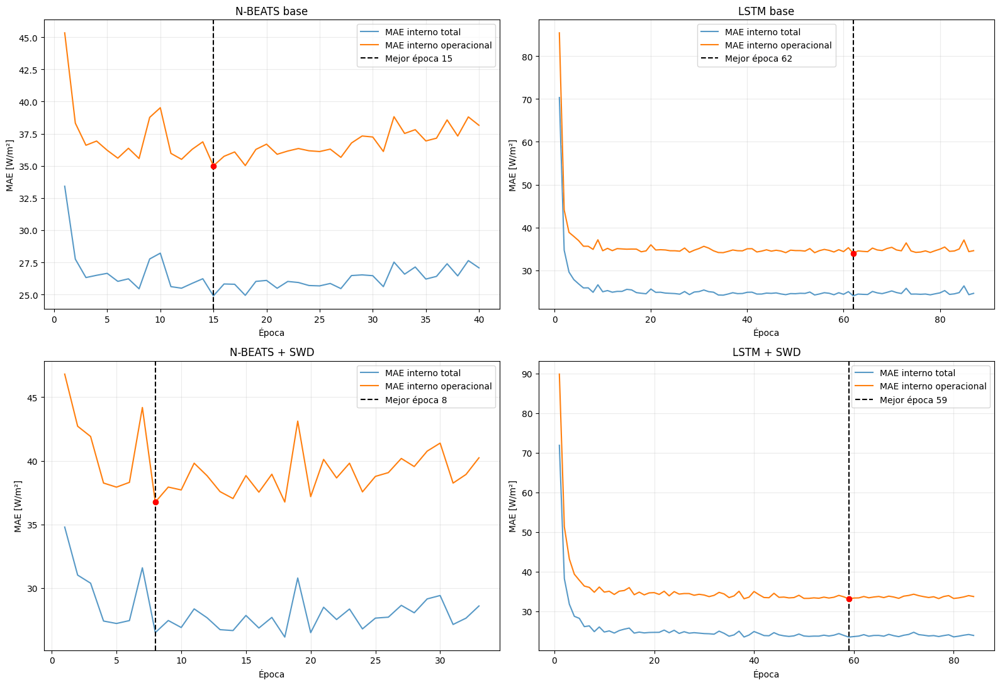

In [ ]:
# 1. Comprobaciones
objetos_necesarios = [
    "X_train_DIF_elevacion_raw",
    "X_train_DIF_elev_SWD_raw",
    "y_train_secuencial",
    "train_hgb",
    "fijar_semilla",
    "MedidorRecursos",
]
faltantes = [nombre for nombre in objetos_necesarios if nombre not in globals()]
if faltantes:
    raise RuntimeError(f"Faltan objetos necesarios: {faltantes}")

X_base_raw = np.asarray(X_train_DIF_elevacion_raw, dtype=np.float32)
X_SWD_raw = np.asarray(X_train_DIF_elev_SWD_raw, dtype=np.float32)
y_train_operacional_raw = np.asarray(y_train_secuencial, dtype=np.float32).reshape(-1)
assert X_base_raw.shape == (5149, 24, 2)
assert X_SWD_raw.shape == (5149, 24, 5)
assert y_train_operacional_raw.shape == (5149,)

# 2. División cronológica y máscara operacional
N_TRAIN = len(y_train_operacional_raw)
N_SUBTRAIN = N_TRAIN - N_VALIDACION_INTERNA
regimen_train = train_hgb["regimen_solar_objetivo"].astype(str).str.lower().str.strip()
mascara_operacional_train = (
    regimen_train.str.contains("completamente") | regimen_train.str.contains("trans")
).to_numpy()
mascara_operacional_subtrain = mascara_operacional_train[:N_SUBTRAIN]
mascara_operacional_interna = mascara_operacional_train[N_SUBTRAIN:]
y_subtrain_raw = y_train_operacional_raw[:N_SUBTRAIN]
y_interna_raw = y_train_operacional_raw[N_SUBTRAIN:]
media_DIF_operacional_interna = float(y_interna_raw[mascara_operacional_interna].mean())
print("División temporal:")
print("Subtrain:", N_SUBTRAIN)
print("Validación interna:", N_VALIDACION_INTERNA)
print("\nObservaciones operacionales:")
print("Subtrain:", mascara_operacional_subtrain.sum())
print("Validación interna:", mascara_operacional_interna.sum())
print("Media DIF operacional interna:", f"{media_DIF_operacional_interna:.6f}")
if media_DIF_operacional_interna <= 0:
    raise ValueError("La media operacional de DIF no es positiva.")

# 3. Auditar horas SWD incompletas utilizadas
objetivos_train = pd.DatetimeIndex(pd.to_datetime(train_hgb["instante_objetivo"], utc=True))
horas_incompletas_swd = set(
    swd_horaria.index[
        (
            (swd_horaria["n_SWD_central"] < 60)
            | (swd_horaria["n_SWD_std"] < 60)
            | (swd_horaria["n_SWD_min"] < 60)
            | (swd_horaria["n_SWD_max"] < 60)
        )
    ]
)
ventanas_afectadas = 0
for instante_objetivo in objetivos_train:
    horas_entrada = instante_objetivo - retardos_24h
    if any(hora in horas_incompletas_swd for hora in horas_entrada):
        ventanas_afectadas += 1

print(
    "\nVentanas train que contienen alguna hora SWD con menos de 60 minutos:", ventanas_afectadas
)
print("Porcentaje:", round(100 * ventanas_afectadas / len(objetivos_train), 3), "%")

# 4. Escalado general multicanal
# Canal DIF:
# media/std calculadas sobre y_subtrain,
# igual que en los modelos anteriores.
# Resto de canales:
# media/std propias calculadas solo con X_subtrain.
def ajustar_escaladores_multicanal(X_subtrain_raw, y_subtrain_raw, nombres_canales):
    if X_subtrain_raw.shape[2] != len(nombres_canales):
        raise ValueError("El número de canales no coincide con sus nombres.")

    parametros = {
        "DIF": {
            "media": float(np.mean(y_subtrain_raw)),
            "std": float(np.std(y_subtrain_raw, ddof=0)),
        }
    }
    for indice, nombre in enumerate(nombres_canales[1:], start=1):
        parametros[nombre] = {
            "media": float(np.mean(X_subtrain_raw[:, :, indice])),
            "std": float(np.std(X_subtrain_raw[:, :, indice], ddof=0)),
        }

    for nombre, valores in parametros.items():
        if valores["std"] <= 0:
            raise ValueError(f"Desviación no válida en {nombre}.")

    return parametros

def transformar_X_multicanal(X, parametros, nombres_canales):
    X_transformado = np.asarray(X, dtype=np.float32).copy()
    for indice, nombre in enumerate(nombres_canales):
        X_transformado[:, :, indice] = (
            X_transformado[:, :, indice] - parametros[nombre]["media"]
        ) / parametros[nombre]["std"]

    return X_transformado

def transformar_y_multicanal(y, parametros):
    return (
        (np.asarray(y, dtype=np.float32) - parametros["DIF"]["media"]) / parametros["DIF"]["std"]
    ).astype(np.float32)


# 5. N-BEATS multicanal genérico
# Solo DIF forma parte del residual.
# Todos los demás canales permanecen como contexto exógeno.
class BloqueNBEATSMulticanal(nn.Module):
    def __init__(
        self, longitud_backcast, numero_canales, unidades_ocultas=128, capas_densas=3, horizonte=1
    ):
        super().__init__()
        dimension_exogena = longitud_backcast * (numero_canales - 1)
        dimension_entrada = longitud_backcast + dimension_exogena
        capas = []
        for indice in range(capas_densas):
            dimension_capa = dimension_entrada if indice == 0 else unidades_ocultas
            capas.extend([nn.Linear(dimension_capa, unidades_ocultas), nn.ReLU()])

        self.red_densa = nn.Sequential(*capas)
        self.cabeza_backcast = nn.Linear(unidades_ocultas, longitud_backcast)
        self.cabeza_forecast = nn.Linear(unidades_ocultas, horizonte)

    def forward(self, residual_DIF, contexto_exogeno):
        entrada = torch.cat([residual_DIF, contexto_exogeno], dim=1)
        representacion = self.red_densa(entrada)
        return (self.cabeza_backcast(representacion), self.cabeza_forecast(representacion))

class NBEATSMulticanal(nn.Module):
    def __init__(
        self,
        numero_canales,
        longitud_backcast=24,
        horizonte=1,
        n_stacks=2,
        bloques_por_stack=3,
        capas_densas=3,
        unidades_ocultas=128,
    ):
        super().__init__()
        self.numero_canales = numero_canales
        self.longitud_backcast = longitud_backcast
        numero_bloques = n_stacks * bloques_por_stack
        self.bloques = nn.ModuleList(
            [
                BloqueNBEATSMulticanal(
                    longitud_backcast=longitud_backcast,
                    numero_canales=numero_canales,
                    unidades_ocultas=unidades_ocultas,
                    capas_densas=capas_densas,
                    horizonte=horizonte,
                )
                for _ in range(numero_bloques)
            ]
        )

    def forward(self, X):
        residual_DIF = X[:, :, 0]
        contexto_exogeno = X[:, :, 1:].reshape(X.shape[0], -1)
        forecast_total = torch.zeros((X.shape[0], 1), dtype=X.dtype, device=X.device)
        for bloque in self.bloques:
            backcast, forecast = bloque(residual_DIF, contexto_exogeno)
            residual_DIF = residual_DIF - backcast
            forecast_total = forecast_total + forecast

        return forecast_total.squeeze(-1)


# 6. LSTM multicanal genérica
class LSTMMulticanal(nn.Module):
    def __init__(self, numero_canales, hidden_size=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=numero_canales,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
        )
        self.cabeza = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, X):
        salida, _ = self.lstm(X)
        ultimo_estado = salida[:, -1, :]
        return self.cabeza(ultimo_estado).squeeze(-1)


# 7. DataLoader
def crear_loader_operacional(X, y, shuffle, semilla=42):
    dataset = TensorDataset(
        torch.from_numpy(np.asarray(X, dtype=np.float32)),
        torch.from_numpy(np.asarray(y, dtype=np.float32)),
    )
    generador = torch.Generator()
    generador.manual_seed(semilla)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        generator=generador if shuffle else None,
    )


# 8. Entrenamiento y evaluación
def entrenar_epoca_operacional(modelo, loader, optimizador, criterio, std_DIF):
    modelo.train()
    suma_error = 0.0
    n = 0
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(DEVICE, non_blocking=True)
        y_batch = y_batch.to(DEVICE, non_blocking=True)
        optimizador.zero_grad(set_to_none=True)
        prediccion = modelo(X_batch)
        perdida = criterio(prediccion, y_batch)
        perdida.backward()
        nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=CLIP_NORM)
        optimizador.step()
        suma_error += torch.abs(prediccion.detach() - y_batch).sum().item()
        n += len(y_batch)

    return suma_error / n * std_DIF

@torch.no_grad()
def evaluar_MAE_operacional(modelo, loader, std_DIF):
    modelo.eval()
    suma_error = 0.0
    n = 0
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(DEVICE, non_blocking=True)
        y_batch = y_batch.to(DEVICE, non_blocking=True)
        prediccion = modelo(X_batch)
        suma_error += torch.abs(prediccion - y_batch).sum().item()
        n += len(y_batch)

    return suma_error / n * std_DIF


# 9. Selección de época operacional
def seleccionar_epoca_operacional(nombre_modelo, X_raw, nombres_canales, fabrica_modelo):
    fijar_semilla(SEMILLA)
    X_subtrain_raw = X_raw[:N_SUBTRAIN]
    X_interna_raw = X_raw[N_SUBTRAIN:]
    parametros_escalado = ajustar_escaladores_multicanal(
        X_subtrain_raw, y_subtrain_raw, nombres_canales
    )
    X_subtrain = transformar_X_multicanal(X_subtrain_raw, parametros_escalado, nombres_canales)
    X_interna = transformar_X_multicanal(X_interna_raw, parametros_escalado, nombres_canales)
    y_subtrain = transformar_y_multicanal(y_subtrain_raw, parametros_escalado)
    y_interna = transformar_y_multicanal(y_interna_raw, parametros_escalado)

    # Entrenamiento con todo subtrain
    loader_subtrain = crear_loader_operacional(
        X_subtrain, y_subtrain, shuffle=True, semilla=SEMILLA
    )

    # Validación interna total
    loader_interna_total = crear_loader_operacional(X_interna, y_interna, shuffle=False)

    # Validación interna operacional
    loader_interna_operacional = crear_loader_operacional(
        X_interna[mascara_operacional_interna],
        y_interna[mascara_operacional_interna],
        shuffle=False,
    )
    modelo = fabrica_modelo().to(DEVICE)
    numero_parametros = sum(
        parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad
    )
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterio = nn.L1Loss()
    mejor_MAE_operacional = np.inf
    mejor_nMAE_operacional = np.inf
    mejor_epoca = None
    contador_paciencia = 0
    historial = []
    print(f"\n{'=' * 78}")
    print(nombre_modelo)
    print("Canales:", nombres_canales)
    print("Parámetros:", numero_parametros)
    print("Criterio de selección: MAE operacional interno")
    print(f"{'=' * 78}")
    with MedidorRecursos() as medidor:
        for epoca in range(1, MAX_EPOCHS + 1):
            MAE_subtrain = entrenar_epoca_operacional(
                modelo=modelo,
                loader=loader_subtrain,
                optimizador=optimizador,
                criterio=criterio,
                std_DIF=(parametros_escalado["DIF"]["std"]),
            )
            MAE_interno_total = evaluar_MAE_operacional(
                modelo=modelo,
                loader=loader_interna_total,
                std_DIF=(parametros_escalado["DIF"]["std"]),
            )
            MAE_interno_operacional = evaluar_MAE_operacional(
                modelo=modelo,
                loader=(loader_interna_operacional),
                std_DIF=(parametros_escalado["DIF"]["std"]),
            )
            nMAE_interno_operacional = 100 * MAE_interno_operacional / media_DIF_operacional_interna
            historial.append(
                {
                    "modelo": nombre_modelo,
                    "epoca": epoca,
                    "MAE_subtrain_total": (MAE_subtrain),
                    "MAE_interno_total": (MAE_interno_total),
                    "MAE_interno_operacional": (MAE_interno_operacional),
                    "nMAE_interno_operacional": (nMAE_interno_operacional),
                }
            )
            if MAE_interno_operacional < mejor_MAE_operacional - MIN_DELTA:
                mejor_MAE_operacional = MAE_interno_operacional
                mejor_nMAE_operacional = nMAE_interno_operacional
                mejor_epoca = epoca
                contador_paciencia = 0

            else:
                contador_paciencia += 1

            if epoca == 1 or epoca % 10 == 0 or epoca == mejor_epoca:
                print(
                    f"Época {epoca:3d} | "
                    f"MAE total={MAE_interno_total:8.4f} | "
                    f"MAE op={MAE_interno_operacional:8.4f} | "
                    f"nMAE op={nMAE_interno_operacional:7.3f}% | "
                    f"mejor época={mejor_epoca}"
                )

            if contador_paciencia >= PATIENCE:
                print("\nEarly stopping en época", epoca)
                break

    historial = pd.DataFrame(historial)
    resultado = {
        "modelo": nombre_modelo,
        "numero_canales": len(nombres_canales),
        "mejor_epoca": int(mejor_epoca),
        "mejor_MAE_interno_operacional": float(mejor_MAE_operacional),
        "mejor_nMAE_interno_operacional": float(mejor_nMAE_operacional),
        "epocas_ejecutadas": int(len(historial)),
        "tiempo_seleccion_s": float(medidor.tiempo_s),
        "tiempo_por_epoca_s": float(medidor.tiempo_s / len(historial)),
        "parametros_entrenables": int(numero_parametros),
        "rss_pico_MB": float(medidor.rss_pico_MB),
        "incremento_rss_MB": float(medidor.incremento_rss_MB),
        "gpu_pico_MB": float(medidor.gpu_pico_MB),
    }
    del modelo
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return (resultado, historial, parametros_escalado)


# 10. Ejecutar las cuatro selecciones
NOMBRES_BASE = ["DIF", "elevacion"]
NOMBRES_SWD = ["DIF", "elevacion", "SWD_media", "SWD_std_media", "SWD_rango"]

# N-BEATS base
(
    seleccion_nbeats_base_operacional,
    historial_nbeats_base_operacional,
    escaladores_nbeats_base_operacional,
) = seleccionar_epoca_operacional(
    nombre_modelo=("NBEATS-DIF-Elev-SeleccionOp"),
    X_raw=X_base_raw,
    nombres_canales=NOMBRES_BASE,
    fabrica_modelo=lambda: (NBEATSMulticanal(numero_canales=2)),
)

# LSTM base
(
    seleccion_lstm_base_operacional,
    historial_lstm_base_operacional,
    escaladores_lstm_base_operacional,
) = seleccionar_epoca_operacional(
    nombre_modelo=("LSTM-DIF-Elev-SeleccionOp"),
    X_raw=X_base_raw,
    nombres_canales=NOMBRES_BASE,
    fabrica_modelo=lambda: (LSTMMulticanal(numero_canales=2)),
)

# N-BEATS + SWD
(
    seleccion_nbeats_swd_operacional,
    historial_nbeats_swd_operacional,
    escaladores_nbeats_swd_operacional,
) = seleccionar_epoca_operacional(
    nombre_modelo=("NBEATS-DIF-Elev-SWD-SeleccionOp"),
    X_raw=X_SWD_raw,
    nombres_canales=NOMBRES_SWD,
    fabrica_modelo=lambda: (NBEATSMulticanal(numero_canales=5)),
)

# LSTM + SWD
(
    seleccion_lstm_swd_operacional,
    historial_lstm_swd_operacional,
    escaladores_lstm_swd_operacional,
) = seleccionar_epoca_operacional(
    nombre_modelo=("LSTM-DIF-Elev-SWD-SeleccionOp"),
    X_raw=X_SWD_raw,
    nombres_canales=NOMBRES_SWD,
    fabrica_modelo=lambda: (LSTMMulticanal(numero_canales=5)),
)

# 11. Resumen
resumen_seleccion_SWD_operacional = pd.DataFrame(
    [
        seleccion_nbeats_base_operacional,
        seleccion_lstm_base_operacional,
        seleccion_nbeats_swd_operacional,
        seleccion_lstm_swd_operacional,
    ]
)
display(resumen_seleccion_SWD_operacional)

# 12. Guardar resultados
DIRECTORIO_SWD = Path("/content/experimento_secuencial_SWD")
DIRECTORIO_SWD.mkdir(parents=True, exist_ok=True)
historiales_SWD = {
    "NBEATS_base": (historial_nbeats_base_operacional),
    "LSTM_base": (historial_lstm_base_operacional),
    "NBEATS_SWD": (historial_nbeats_swd_operacional),
    "LSTM_SWD": (historial_lstm_swd_operacional),
}
for nombre, historial in historiales_SWD.items():
    historial.to_csv(DIRECTORIO_SWD / f"historial_seleccion_{nombre}.csv", index=False)

resumen_seleccion_SWD_operacional.to_csv(
    DIRECTORIO_SWD / "resumen_seleccion_operacional.csv", index=False
)

# 13. Curvas operacionales
fig, ejes = plt.subplots(2, 2, figsize=(16, 11))
configuraciones_grafico = [
    (
        ejes[0, 0],
        historial_nbeats_base_operacional,
        seleccion_nbeats_base_operacional,
        "N-BEATS base",
    ),
    (ejes[0, 1], historial_lstm_base_operacional, seleccion_lstm_base_operacional, "LSTM base"),
    (
        ejes[1, 0],
        historial_nbeats_swd_operacional,
        seleccion_nbeats_swd_operacional,
        "N-BEATS + SWD",
    ),
    (ejes[1, 1], historial_lstm_swd_operacional, seleccion_lstm_swd_operacional, "LSTM + SWD"),
]
for eje, historial, resultado, titulo in configuraciones_grafico:
    eje.plot(
        historial["epoca"], historial["MAE_interno_total"], label="MAE interno total", alpha=0.75
    )
    eje.plot(
        historial["epoca"], historial["MAE_interno_operacional"], label="MAE interno operacional"
    )
    eje.axvline(
        resultado["mejor_epoca"],
        color="black",
        linestyle="--",
        label=("Mejor época " f"{resultado['mejor_epoca']}"),
    )
    eje.scatter(
        [resultado["mejor_epoca"]],
        [resultado["mejor_MAE_interno_operacional"]],
        color="red",
        zorder=5,
    )
    eje.set_title(titulo)
    eje.set_xlabel("Época")
    eje.set_ylabel("MAE [W/m²]")
    eje.grid(alpha=0.25)
    eje.legend()

plt.tight_layout()
plt.show()

In [ ]:
import os
import gc
import time
import random
import tempfile
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

try:
    import psutil
except ImportError:
    psutil = None

warnings.filterwarnings("ignore")

# 1. Configuración
SEMILLA = 42
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
CLIP_NORM = 1.0
EPOCAS_FINALES = {
    "NBEATS_DIF_ELEV": 15,
    "LSTM_DIF_ELEV": 62,
    "NBEATS_DIF_ELEV_SWD": 8,
    "LSTM_DIF_ELEV_SWD": 59,
}
CARPETA_RESULTADOS = Path("/content/experimento_secuencial_SWD/reentrenamiento_final")
CARPETA_RESULTADOS.mkdir(parents=True, exist_ok=True)
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Dispositivo:", DISPOSITIVO)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

def fijar_semilla(semilla=42):
    random.seed(semilla)
    np.random.seed(semilla)
    torch.manual_seed(semilla)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(semilla)
        torch.cuda.manual_seed_all(semilla)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def sincronizar():
    if torch.cuda.is_available():
        torch.cuda.synchronize()

def rss_actual_mb():
    if psutil is None:
        return np.nan

    proceso = psutil.Process(os.getpid())
    return proceso.memory_info().rss / 1024**2


# 2. Recuperar y comprobar matrices

# Matrices completas:
# canales = [DIF, elevación, SWD_media, SWD_std_media, SWD_rango]
X_train_swd = np.asarray(X_train_DIF_elev_SWD_raw, dtype=np.float32)
X_validation_swd = np.asarray(X_validation_DIF_elev_SWD_raw, dtype=np.float32)

# El modelo base utiliza solamente los dos primeros canales:
# [DIF, elevación]
X_train_base = X_train_swd[:, :, :2].copy()
X_validation_base = X_validation_swd[:, :, :2].copy()
y_train_final = np.asarray(y_train_secuencial, dtype=np.float32).reshape(-1)
y_validation_final = np.asarray(y_validation_secuencial, dtype=np.float32).reshape(-1)
assert X_train_base.shape == (len(y_train_final), 24, 2)
assert X_validation_base.shape == (len(y_validation_final), 24, 2)
assert X_train_swd.shape == (len(y_train_final), 24, 5)
assert X_validation_swd.shape == (len(y_validation_final), 24, 5)
for nombre, matriz in {
    "X_train_base": X_train_base,
    "X_validation_base": X_validation_base,
    "X_train_swd": X_train_swd,
    "X_validation_swd": X_validation_swd,
    "y_train": y_train_final,
    "y_validation": y_validation_final,
}.items():
    assert np.isfinite(matriz).all(), f"{nombre} contiene NaN o infinitos."

print("\nFormas comprobadas:")
print("Base train      :", X_train_base.shape)
print("Base validation :", X_validation_base.shape)
print("SWD train       :", X_train_swd.shape)
print("SWD validation  :", X_validation_swd.shape)
print("\nCanales base: [DIF, elevación]")
print("Canales SWD : [DIF, elevación, SWD_media, SWD_std_media, SWD_rango]")


# 3. Escalado
# DIF histórico y objetivo:
#   misma media/desviación, calculadas exclusivamente en y_train.
# Resto de canales:
#   escalado independiente por canal usando únicamente train.
def ajustar_escalador(X_train, y_train):
    media_dif = float(np.mean(y_train))
    escala_dif = float(np.std(y_train))
    if escala_dif < 1e-8:
        escala_dif = 1.0

    medias_canales = []
    escalas_canales = []
    for canal in range(1, X_train.shape[2]):
        media = float(np.mean(X_train[:, :, canal]))
        escala = float(np.std(X_train[:, :, canal]))
        if escala < 1e-8:
            escala = 1.0

        medias_canales.append(media)
        escalas_canales.append(escala)

    return {
        "media_dif": media_dif,
        "escala_dif": escala_dif,
        "medias_canales": np.asarray(medias_canales, dtype=np.float32),
        "escalas_canales": np.asarray(escalas_canales, dtype=np.float32),
    }

def transformar_X(X, escalador):
    X_escalada = np.array(X, dtype=np.float32, copy=True)

    # Canal 0: DIF
    X_escalada[:, :, 0] = (X_escalada[:, :, 0] - escalador["media_dif"]) / escalador["escala_dif"]

    # Canales restantes
    for canal in range(1, X_escalada.shape[2]):
        indice = canal - 1
        X_escalada[:, :, canal] = (
            X_escalada[:, :, canal] - escalador["medias_canales"][indice]
        ) / escalador["escalas_canales"][indice]

    return X_escalada

def transformar_y(y, escalador):
    return ((y - escalador["media_dif"]) / escalador["escala_dif"]).astype(np.float32)

def desescalar_y(y_escalada, escalador):
    return y_escalada * escalador["escala_dif"] + escalador["media_dif"]


# 4. Arquitectura N-BEATS multicanal
# - El residuo se aplica solamente a DIF.
# - Elevación y SWD actúan como contexto exógeno.
# - 6 bloques.
# - 3 capas densas por bloque.
# - 128 unidades.
class BloqueNBEATSContexto(nn.Module):
    def __init__(self, longitud_ventana, numero_canales, unidades=128):
        super().__init__()
        dimension_contexto = longitud_ventana * (numero_canales - 1)
        dimension_entrada = longitud_ventana + dimension_contexto
        self.longitud_ventana = longitud_ventana
        self.red = nn.Sequential(
            nn.Linear(dimension_entrada, unidades),
            nn.ReLU(),
            nn.Linear(unidades, unidades),
            nn.ReLU(),
            nn.Linear(unidades, unidades),
            nn.ReLU(),
        )
        self.salida = nn.Linear(unidades, longitud_ventana + 1)

    def forward(self, residuo_dif, contexto):
        entrada = torch.cat([residuo_dif, contexto], dim=1)
        representacion = self.red(entrada)
        parametros = self.salida(representacion)
        backcast = parametros[:, : self.longitud_ventana]
        forecast = parametros[:, self.longitud_ventana :]
        return backcast, forecast

class NBEATSContexto(nn.Module):
    def __init__(self, longitud_ventana=24, numero_canales=2, numero_bloques=6, unidades=128):
        super().__init__()
        self.longitud_ventana = longitud_ventana
        self.numero_canales = numero_canales
        self.bloques = nn.ModuleList(
            [
                BloqueNBEATSContexto(
                    longitud_ventana=longitud_ventana,
                    numero_canales=numero_canales,
                    unidades=unidades,
                )
                for _ in range(numero_bloques)
            ]
        )

    def forward(self, X):
        residuo = X[:, :, 0]
        if self.numero_canales > 1:
            contexto = X[:, :, 1:].reshape(X.shape[0], -1)
        else:
            contexto = torch.empty((X.shape[0], 0), dtype=X.dtype, device=X.device)

        prediccion = torch.zeros((X.shape[0], 1), dtype=X.dtype, device=X.device)
        for bloque in self.bloques:
            backcast, forecast = bloque(residuo, contexto)
            residuo = residuo - backcast
            prediccion = prediccion + forecast

        return prediccion.squeeze(1)


# 5. Arquitectura LSTM multicanal
class LSTMContexto(nn.Module):
    def __init__(self, numero_canales, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=numero_canales, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.cabeza = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, X):
        salida, _ = self.lstm(X)
        ultimo_estado = salida[:, -1, :]
        return self.cabeza(ultimo_estado).squeeze(1)


# 6. Entrenamiento final con número fijo de épocas
def contar_parametros(modelo):
    return sum(parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad)

def entrenar_modelo_final(nombre, arquitectura, X_train, X_validation, y_train, epocas):
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()

    fijar_semilla(SEMILLA)
    escalador = ajustar_escalador(X_train, y_train)
    X_train_escalada = transformar_X(X_train, escalador)
    X_validation_escalada = transformar_X(X_validation, escalador)
    y_train_escalada = transformar_y(y_train, escalador)
    dataset_train = TensorDataset(
        torch.from_numpy(X_train_escalada), torch.from_numpy(y_train_escalada)
    )
    generador = torch.Generator()
    generador.manual_seed(SEMILLA)
    loader_train = DataLoader(
        dataset_train,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generador,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
        drop_last=False,
    )
    if arquitectura == "NBEATS":
        modelo = NBEATSContexto(
            longitud_ventana=X_train.shape[1],
            numero_canales=X_train.shape[2],
            numero_bloques=6,
            unidades=128,
        )
    elif arquitectura == "LSTM":
        modelo = LSTMContexto(numero_canales=X_train.shape[2], hidden_size=64)
    else:
        raise ValueError("Arquitectura no reconocida.")

    modelo = modelo.to(DISPOSITIVO)
    optimizador = torch.optim.AdamW(
        modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY
    )
    funcion_perdida = nn.L1Loss()
    historial_train = []
    rss_inicial = rss_actual_mb()
    sincronizar()
    inicio_entrenamiento = time.perf_counter()
    for epoca in range(1, epocas + 1):
        modelo.train()
        suma_perdida = 0.0
        numero_observaciones = 0
        for X_batch, y_batch in loader_train:
            X_batch = X_batch.to(DISPOSITIVO, non_blocking=True)
            y_batch = y_batch.to(DISPOSITIVO, non_blocking=True)
            optimizador.zero_grad(set_to_none=True)
            prediccion = modelo(X_batch)
            perdida = funcion_perdida(prediccion, y_batch)
            perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), CLIP_NORM)
            optimizador.step()
            tamanio_batch = X_batch.shape[0]
            suma_perdida += perdida.item() * tamanio_batch
            numero_observaciones += tamanio_batch

        perdida_media = suma_perdida / numero_observaciones
        historial_train.append({"epoca": epoca, "MAE_train_escalado": perdida_media})
        if epoca == 1 or epoca == epocas or epoca % 10 == 0:
            print(
                f"{nombre:24s} | "
                f"época {epoca:3d}/{epocas:3d} | "
                f"L1 escalada = {perdida_media:.6f}"
            )

    sincronizar()
    tiempo_entrenamiento = time.perf_counter() - inicio_entrenamiento

    # Predicción de validation
    X_validation_tensor = torch.from_numpy(X_validation_escalada)
    loader_validation = DataLoader(
        TensorDataset(X_validation_tensor),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=torch.cuda.is_available(),
    )
    modelo.eval()

    def ejecutar_inferencia():
        resultados = []
        with torch.inference_mode():
            for (X_batch,) in loader_validation:
                X_batch = X_batch.to(DISPOSITIVO, non_blocking=True)
                resultados.append(modelo(X_batch).detach().cpu().numpy())

        return np.concatenate(resultados)

    # Calentamiento
    for _ in range(5):
        _ = ejecutar_inferencia()

    sincronizar()
    tiempos_inferencia = []
    for _ in range(30):
        inicio_inferencia = time.perf_counter()
        prediccion_escalada = ejecutar_inferencia()
        sincronizar()
        tiempos_inferencia.append(time.perf_counter() - inicio_inferencia)

    prediccion_validation = desescalar_y(prediccion_escalada, escalador).astype(np.float32)
    tiempo_inferencia_mediana = float(np.median(tiempos_inferencia))
    tiempo_por_muestra_ms = tiempo_inferencia_mediana / len(X_validation) * 1000
    parametros = contar_parametros(modelo)
    gpu_pico_mb = torch.cuda.max_memory_allocated() / 1024**2 if torch.cuda.is_available() else 0.0
    rss_final = rss_actual_mb()
    incremento_rss = (
        rss_final - rss_inicial if np.isfinite(rss_final) and np.isfinite(rss_inicial) else np.nan
    )

    # Guardar modelo
    ruta_modelo = CARPETA_RESULTADOS / f"{nombre}.pt"
    checkpoint = {
        "nombre": nombre,
        "arquitectura": arquitectura,
        "epocas": epocas,
        "numero_canales": X_train.shape[2],
        "longitud_ventana": X_train.shape[1],
        "state_dict": {clave: valor.detach().cpu() for clave, valor in modelo.state_dict().items()},
        "escalador": escalador,
        "configuracion": {
            "semilla": SEMILLA,
            "batch_size": BATCH_SIZE,
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "clip_norm": CLIP_NORM,
        },
    }
    torch.save(checkpoint, ruta_modelo)
    tamanio_modelo_mb = ruta_modelo.stat().st_size / 1024**2
    historial_train = pd.DataFrame(historial_train)
    historial_train.to_csv(CARPETA_RESULTADOS / f"historial_{nombre}.csv", index=False)
    resultado_coste = {
        "modelo": nombre,
        "arquitectura": arquitectura,
        "numero_canales": X_train.shape[2],
        "epocas_finales": epocas,
        "parametros_entrenables": parametros,
        "tiempo_entrenamiento_s": tiempo_entrenamiento,
        "tiempo_por_epoca_s": (tiempo_entrenamiento / epocas),
        "inferencia_validation_mediana_s": tiempo_inferencia_mediana,
        "inferencia_por_muestra_ms": tiempo_por_muestra_ms,
        "rss_final_MB": rss_final,
        "incremento_rss_MB": incremento_rss,
        "gpu_pico_MB": gpu_pico_mb,
        "tamanio_checkpoint_MB": tamanio_modelo_mb,
    }
    modelo = modelo.cpu()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    gc.collect()
    return {
        "modelo": modelo,
        "prediccion_validation": prediccion_validation,
        "escalador": escalador,
        "historial": historial_train,
        "coste": resultado_coste,
        "ruta_modelo": str(ruta_modelo),
    }


# 7. Ejecutar los cuatro reentrenamientos
resultado_nbeats_base_final = entrenar_modelo_final(
    nombre="NBEATS_DIF_ELEV",
    arquitectura="NBEATS",
    X_train=X_train_base,
    X_validation=X_validation_base,
    y_train=y_train_final,
    epocas=EPOCAS_FINALES["NBEATS_DIF_ELEV"],
)
resultado_lstm_base_final = entrenar_modelo_final(
    nombre="LSTM_DIF_ELEV",
    arquitectura="LSTM",
    X_train=X_train_base,
    X_validation=X_validation_base,
    y_train=y_train_final,
    epocas=EPOCAS_FINALES["LSTM_DIF_ELEV"],
)
resultado_nbeats_swd_final = entrenar_modelo_final(
    nombre="NBEATS_DIF_ELEV_SWD",
    arquitectura="NBEATS",
    X_train=X_train_swd,
    X_validation=X_validation_swd,
    y_train=y_train_final,
    epocas=EPOCAS_FINALES["NBEATS_DIF_ELEV_SWD"],
)
resultado_lstm_swd_final = entrenar_modelo_final(
    nombre="LSTM_DIF_ELEV_SWD",
    arquitectura="LSTM",
    X_train=X_train_swd,
    X_validation=X_validation_swd,
    y_train=y_train_final,
    epocas=EPOCAS_FINALES["LSTM_DIF_ELEV_SWD"],
)


# 8. Extraer predicciones con nombres claros
pred_validation_nbeats_base_op = resultado_nbeats_base_final["prediccion_validation"]
pred_validation_lstm_base_op = resultado_lstm_base_final["prediccion_validation"]
pred_validation_nbeats_swd = resultado_nbeats_swd_final["prediccion_validation"]
pred_validation_lstm_swd = resultado_lstm_swd_final["prediccion_validation"]


# 9. Resumen del coste computacional
resumen_coste_final_SWD = pd.DataFrame(
    [
        resultado_nbeats_base_final["coste"],
        resultado_lstm_base_final["coste"],
        resultado_nbeats_swd_final["coste"],
        resultado_lstm_swd_final["coste"],
    ]
)
resumen_coste_final_SWD.to_csv(CARPETA_RESULTADOS / "resumen_coste_final_SWD.csv", index=False)
np.savez_compressed(
    CARPETA_RESULTADOS / "predicciones_validation_SWD.npz",
    y_validation=y_validation_final,
    pred_nbeats_base=pred_validation_nbeats_base_op,
    pred_lstm_base=pred_validation_lstm_base_op,
    pred_nbeats_swd=pred_validation_nbeats_swd,
    pred_lstm_swd=pred_validation_lstm_swd,
)
print("\nReentrenamiento final completado.")
print("Resultados guardados en:")
print(CARPETA_RESULTADOS)
display(resumen_coste_final_SWD.round(6))

Dispositivo: cpu

Formas comprobadas:
Base train      : (5149, 24, 2)
Base validation : (1464, 24, 2)
SWD train       : (5149, 24, 5)
SWD validation  : (1464, 24, 5)

Canales base: [DIF, elevación]
Canales SWD : [DIF, elevación, SWD_media, SWD_std_media, SWD_rango]
NBEATS_DIF_ELEV          | época   1/ 15 | L1 escalada = 0.258880
NBEATS_DIF_ELEV          | época  10/ 15 | L1 escalada = 0.151183
NBEATS_DIF_ELEV          | época  15/ 15 | L1 escalada = 0.150601
LSTM_DIF_ELEV            | época   1/ 62 | L1 escalada = 0.680765
LSTM_DIF_ELEV            | época  10/ 62 | L1 escalada = 0.162112
LSTM_DIF_ELEV            | época  20/ 62 | L1 escalada = 0.155497
LSTM_DIF_ELEV            | época  30/ 62 | L1 escalada = 0.155946
LSTM_DIF_ELEV            | época  40/ 62 | L1 escalada = 0.152492
LSTM_DIF_ELEV            | época  50/ 62 | L1 escalada = 0.155063
LSTM_DIF_ELEV            | época  60/ 62 | L1 escalada = 0.150263
LSTM_DIF_ELEV            | época  62/ 62 | L1 escalada = 0.151510
NBEATS_D

,modelo,arquitectura,numero_canales,epocas_finales,parametros_entrenables,tiempo_entrenamiento_s,tiempo_por_epoca_s,inferencia_validation_mediana_s,inferencia_por_muestra_ms,rss_final_MB,incremento_rss_MB,gpu_pico_MB,tamanio_checkpoint_MB
0,NBEATS_DIF_ELEV,NBEATS,2,15,255126,16.521672,1.101445,0.094456,0.064519,1002.621094,0.082031,0.0,0.988223
1,LSTM_DIF_ELEV,LSTM,2,62,19521,87.453297,1.410537,0.090222,0.061627,1005.917969,3.296875,0.0,0.078462
2,NBEATS_DIF_ELEV_SWD,NBEATS,5,8,310422,5.785319,0.723165,0.032047,0.021890,1005.929688,0.011719,0.0,1.199428
3,LSTM_DIF_ELEV_SWD,LSTM,5,59,20289,51.800717,0.877978,0.089825,0.061356,1014.335938,8.406250,0.0,0.081506


Observaciones por régimen:
Total                   : 1464 (100.00 %)
Operacional             :  884 ( 60.38 %)
Completamente diurno    :  765 ( 52.25 %)
Transición              :  119 (  8.13 %)
Noche                   :  580 ( 39.62 %)

MÉTRICAS COMPLETAS:


,modelo,regimen,n,MAE,nMAE_pct,RMSE,R2,sesgo,p95_error_abs,p99_error_abs
0,N-BEATS DIF+Elev,Total,1464,17.1859,20.163,32.9096,0.90735,-0.7215,71.4605,133.4740
1,LSTM DIF+Elev,Total,1464,17.6223,20.675,34.1634,0.90015,5.6646,74.5978,140.1067
2,N-BEATS DIF+Elev+SWD,Total,1464,17.6662,20.727,34.1408,0.90029,-4.2308,76.4285,136.9405
3,LSTM DIF+Elev+SWD,Total,1464,15.9880,18.758,32.4979,0.90965,-0.9618,73.3357,129.8976
4,N-BEATS DIF+Elev,Operacional,884,27.7632,19.579,42.3398,0.84112,-0.5745,87.2572,161.0605
5,LSTM DIF+Elev,Operacional,884,28.8573,20.351,43.9615,0.82871,9.1123,89.6899,158.1395
6,N-BEATS DIF+Elev+SWD,Operacional,884,28.2332,19.911,43.9091,0.82912,-6.1245,98.1741,166.2678
7,LSTM DIF+Elev+SWD,Operacional,884,26.0363,18.362,41.8156,0.84503,-1.7125,89.8239,156.4870
8,N-BEATS DIF+Elev,Completamente diurno,765,31.4506,19.328,45.4553,0.78868,-0.5999,91.5182,166.7165
9,LSTM DIF+Elev,Completamente diurno,765,32.7118,20.103,47.2105,0.77204,10.4756,93.2529,167.1942



MAE POR RÉGIMEN [W/m²]:


modelo,N-BEATS DIF+Elev,LSTM DIF+Elev,N-BEATS DIF+Elev+SWD,LSTM DIF+Elev+SWD
regimen,,,,
Total,17.186,17.622,17.666,15.988
Operacional,27.763,28.857,28.233,26.036
Completamente diurno,31.451,32.712,32.042,29.562
Transición,4.059,4.078,3.746,3.371
Noche,1.065,0.499,1.561,0.673



nMAE POR RÉGIMEN [%]:


modelo,N-BEATS DIF+Elev,LSTM DIF+Elev,N-BEATS DIF+Elev+SWD,LSTM DIF+Elev+SWD
regimen,,,,
Total,20.163,20.675,20.727,18.758
Operacional,19.579,20.351,19.911,18.362
Completamente diurno,19.328,20.103,19.691,18.167
Transición,55.777,56.050,51.483,46.327
Noche,NaN,NaN,NaN,NaN


... (6 outputs left out)


EFECTO DE SWD EN LAS RAMPAS Q5:


,arquitectura,MAE_Q5_base,MAE_Q5_SWD,mejora_Q5,mejora_Q5_pct
0,N-BEATS,56.930,63.009,-6.079,-10.679
1,LSTM,65.822,60.984,4.838,7.350



COSTE COMPUTACIONAL:


,modelo,arquitectura,numero_canales,epocas_finales,parametros_entrenables,tiempo_entrenamiento_s,tiempo_por_epoca_s,inferencia_validation_mediana_s,inferencia_por_muestra_ms,rss_final_MB,incremento_rss_MB,gpu_pico_MB,tamanio_checkpoint_MB
0,NBEATS_DIF_ELEV,NBEATS,2,15,255126,16.521672,1.101445,0.094456,0.064519,1002.621094,0.082031,0.0,0.988223
1,LSTM_DIF_ELEV,LSTM,2,62,19521,87.453297,1.410537,0.090222,0.061627,1005.917969,3.296875,0.0,0.078462
2,NBEATS_DIF_ELEV_SWD,NBEATS,5,8,310422,5.785319,0.723165,0.032047,0.021890,1005.929688,0.011719,0.0,1.199428
3,LSTM_DIF_ELEV_SWD,LSTM,5,59,20289,51.800717,0.877978,0.089825,0.061356,1014.335938,8.406250,0.0,0.081506


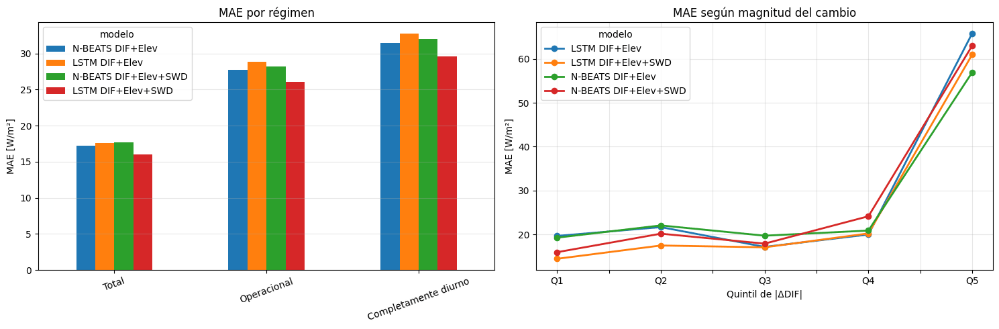


Evaluación guardada correctamente en: /content/experimento_secuencial_SWD/reentrenamiento_final


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Datos y predicciones
y_real = np.asarray(y_validation_secuencial, dtype=float).reshape(-1)
predicciones = {
    "N-BEATS DIF+Elev": np.asarray(pred_validation_nbeats_base_op, dtype=float).reshape(-1),
    "LSTM DIF+Elev": np.asarray(pred_validation_lstm_base_op, dtype=float).reshape(-1),
    "N-BEATS DIF+Elev+SWD": np.asarray(pred_validation_nbeats_swd, dtype=float).reshape(-1),
    "LSTM DIF+Elev+SWD": np.asarray(pred_validation_lstm_swd, dtype=float).reshape(-1),
}
for nombre, prediccion in predicciones.items():
    assert len(prediccion) == len(y_real), f"Longitud incorrecta en {nombre}"
    assert np.isfinite(prediccion).all(), f"{nombre} contiene NaN o infinitos."

assert np.isfinite(y_real).all()


# 2. Máscaras
regimenes = {
    "Total": np.ones(len(y_real), dtype=bool),
    "Operacional": np.asarray(mascara_operacional, dtype=bool),
    "Completamente diurno": np.asarray(mascara_diurna, dtype=bool),
    "Transición": np.asarray(mascara_transicion, dtype=bool),
    "Noche": np.asarray(mascara_noche, dtype=bool),
}
for nombre, mascara in regimenes.items():
    assert len(mascara) == len(y_real), f"Máscara incorrecta: {nombre}"

print("Observaciones por régimen:")
for nombre, mascara in regimenes.items():
    print(f"{nombre:24s}: " f"{mascara.sum():4d} " f"({100 * mascara.mean():6.2f} %)")


# 3. Función de métricas
def calcular_metricas(y, pred):
    error = pred - y
    error_absoluto = np.abs(error)
    mae = mean_absolute_error(y, pred)
    rmse = np.sqrt(mean_squared_error(y, pred))

    # Normalización por la media del valor real.
    # No se interpreta si la media es demasiado próxima a cero.
    media_real = np.mean(y)
    nmae = 100 * mae / media_real if media_real > 1.0 else np.nan
    r2 = r2_score(y, pred) if len(y) > 1 and np.std(y) > 0 else np.nan
    return {
        "n": len(y),
        "MAE": mae,
        "nMAE_pct": nmae,
        "RMSE": rmse,
        "R2": r2,
        "sesgo": np.mean(error),
        "p95_error_abs": np.quantile(error_absoluto, 0.95),
        "p99_error_abs": np.quantile(error_absoluto, 0.99),
    }


# 4. Métricas por régimen
filas_metricas = []
for modelo, prediccion in predicciones.items():
    for regimen, mascara in regimenes.items():
        metricas = calcular_metricas(y_real[mascara], prediccion[mascara])
        filas_metricas.append({"modelo": modelo, "regimen": regimen, **metricas})

metricas_validation_SWD = pd.DataFrame(filas_metricas)
orden_modelos = list(predicciones.keys())
orden_regimenes = list(regimenes.keys())
metricas_validation_SWD["modelo"] = pd.Categorical(
    metricas_validation_SWD["modelo"], categories=orden_modelos, ordered=True
)
metricas_validation_SWD["regimen"] = pd.Categorical(
    metricas_validation_SWD["regimen"], categories=orden_regimenes, ordered=True
)
metricas_validation_SWD = metricas_validation_SWD.sort_values(["regimen", "modelo"]).reset_index(
    drop=True
)
print("\nMÉTRICAS COMPLETAS:")
display(
    metricas_validation_SWD.round(
        {
            "MAE": 4,
            "nMAE_pct": 3,
            "RMSE": 4,
            "R2": 5,
            "sesgo": 4,
            "p95_error_abs": 4,
            "p99_error_abs": 4,
        }
    )
)


# 5. Tabla compacta de MAE y nMAE
tabla_MAE = metricas_validation_SWD.pivot(index="regimen", columns="modelo", values="MAE").reindex(
    orden_regimenes
)
tabla_nMAE = metricas_validation_SWD.pivot(
    index="regimen", columns="modelo", values="nMAE_pct"
).reindex(orden_regimenes)
print("\nMAE POR RÉGIMEN [W/m²]:")
display(tabla_MAE.round(3))
print("\nnMAE POR RÉGIMEN [%]:")
display(tabla_nMAE.round(3))


# 6. Mejora aportada por SWD
# Mejora positiva = SWD reduce el error.
# Mejora negativa = SWD empeora el error.
pares = {
    "N-BEATS": ("N-BEATS DIF+Elev", "N-BEATS DIF+Elev+SWD"),
    "LSTM": ("LSTM DIF+Elev", "LSTM DIF+Elev+SWD"),
}
filas_mejora = []
for arquitectura, (modelo_base, modelo_swd) in pares.items():
    for regimen in orden_regimenes:
        fila_base = metricas_validation_SWD[
            (metricas_validation_SWD["modelo"] == modelo_base)
            & (metricas_validation_SWD["regimen"] == regimen)
        ].iloc[0]
        fila_swd = metricas_validation_SWD[
            (metricas_validation_SWD["modelo"] == modelo_swd)
            & (metricas_validation_SWD["regimen"] == regimen)
        ].iloc[0]
        mejora_mae = fila_base["MAE"] - fila_swd["MAE"]
        mejora_relativa = 100 * mejora_mae / fila_base["MAE"]
        filas_mejora.append(
            {
                "arquitectura": arquitectura,
                "regimen": regimen,
                "MAE_base": fila_base["MAE"],
                "MAE_SWD": fila_swd["MAE"],
                "mejora_MAE": mejora_mae,
                "mejora_relativa_pct": mejora_relativa,
                "nMAE_base_pct": fila_base["nMAE_pct"],
                "nMAE_SWD_pct": fila_swd["nMAE_pct"],
                "reduccion_nMAE_pp": (fila_base["nMAE_pct"] - fila_swd["nMAE_pct"]),
            }
        )

mejora_SWD = pd.DataFrame(filas_mejora)
print("\nEFECTO DE INTRODUCIR SWD:")
print("Valores positivos indican mejora.\n")
display(
    mejora_SWD.round(
        {
            "MAE_base": 4,
            "MAE_SWD": 4,
            "mejora_MAE": 4,
            "mejora_relativa_pct": 2,
            "nMAE_base_pct": 3,
            "nMAE_SWD_pct": 3,
            "reduccion_nMAE_pp": 3,
        }
    )
)


# 7. Cambios y rampas
# ΔDIF(T) = DIF(T) - DIF(T-1)
# Δpred(T) = pred(T) - DIF(T-1)
dif_lag1_validation = np.asarray(X_validation_base[:, -1, 0], dtype=float).reshape(-1)
assert len(dif_lag1_validation) == len(y_real)
delta_real = y_real - dif_lag1_validation
magnitud_cambio = np.abs(delta_real)
mascara_op = regimenes["Operacional"]

# Quintiles definidos únicamente con la magnitud real del cambio
# dentro del régimen operacional.
quintiles_operacionales = pd.qcut(
    magnitud_cambio[mascara_op], q=5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"], duplicates="raise"
)
filas_quintiles = []
for modelo, prediccion in predicciones.items():
    delta_predicho = prediccion - dif_lag1_validation
    error_absoluto = np.abs(prediccion - y_real)
    for quintil in ["Q1", "Q2", "Q3", "Q4", "Q5"]:
        mascara_q_op = np.asarray(quintiles_operacionales) == quintil
        indices_op = np.flatnonzero(mascara_op)
        indices_q = indices_op[mascara_q_op]
        filas_quintiles.append(
            {
                "modelo": modelo,
                "quintil": quintil,
                "n": len(indices_q),
                "MAE_DIF": np.mean(error_absoluto[indices_q]),
                "MAE_delta": np.mean(np.abs(delta_predicho[indices_q] - delta_real[indices_q])),
                "sesgo_delta": np.mean(delta_predicho[indices_q] - delta_real[indices_q]),
            }
        )

metricas_quintiles_SWD = pd.DataFrame(filas_quintiles)
tabla_quintiles = metricas_quintiles_SWD.pivot(
    index="quintil", columns="modelo", values="MAE_DIF"
).reindex(["Q1", "Q2", "Q3", "Q4", "Q5"])
print("\nMAE POR QUINTIL DE |ΔDIF| — RÉGIMEN OPERACIONAL:")
display(tabla_quintiles.round(3))


# 8. Dirección del cambio
# Se ignoran cambios de magnitud <= 1 W/m² para evitar que
# pequeñas oscilaciones instrumentales dominen la tasa de signo.
UMBRAL_CAMBIO = 1.0
filas_direccion = []
for modelo, prediccion in predicciones.items():
    delta_predicho = prediccion - dif_lag1_validation
    mascara_cambio = mascara_op & (np.abs(delta_real) > UMBRAL_CAMBIO)
    mascara_subida = mascara_op & (delta_real > UMBRAL_CAMBIO)
    mascara_descenso = mascara_op & (delta_real < -UMBRAL_CAMBIO)
    signo_correcto = np.mean(
        np.sign(delta_predicho[mascara_cambio]) == np.sign(delta_real[mascara_cambio])
    )

    # Negativo en subidas:
    # el modelo infraestima el aumento.
    sesgo_subidas = np.mean(delta_predicho[mascara_subida] - delta_real[mascara_subida])

    # Positivo en descensos:
    # el descenso predicho es menos intenso que el real.
    sesgo_descensos = np.mean(delta_predicho[mascara_descenso] - delta_real[mascara_descenso])

    # Signo correcto exclusivamente en Q5
    indices_op = np.flatnonzero(mascara_op)
    mascara_q5_op = np.asarray(quintiles_operacionales) == "Q5"
    indices_q5 = indices_op[mascara_q5_op]
    signo_correcto_q5 = np.mean(
        np.sign(delta_predicho[indices_q5]) == np.sign(delta_real[indices_q5])
    )
    filas_direccion.append(
        {
            "modelo": modelo,
            "n_cambios_evaluados": mascara_cambio.sum(),
            "signo_correcto_pct": 100 * signo_correcto,
            "signo_correcto_Q5_pct": (100 * signo_correcto_q5),
            "sesgo_delta_subidas": sesgo_subidas,
            "sesgo_delta_descensos": sesgo_descensos,
        }
    )

metricas_direccion_SWD = pd.DataFrame(filas_direccion)
print("\nCAPACIDAD PARA PREDECIR LA DIRECCIÓN DEL CAMBIO:")
display(metricas_direccion_SWD.round(3))


# 9. Mejora específica en Q5
filas_q5 = []
for arquitectura, (modelo_base, modelo_swd) in pares.items():
    mae_base_q5 = metricas_quintiles_SWD.loc[
        (metricas_quintiles_SWD["modelo"] == modelo_base)
        & (metricas_quintiles_SWD["quintil"] == "Q5"),
        "MAE_DIF",
    ].iloc[0]
    mae_swd_q5 = metricas_quintiles_SWD.loc[
        (metricas_quintiles_SWD["modelo"] == modelo_swd)
        & (metricas_quintiles_SWD["quintil"] == "Q5"),
        "MAE_DIF",
    ].iloc[0]
    filas_q5.append(
        {
            "arquitectura": arquitectura,
            "MAE_Q5_base": mae_base_q5,
            "MAE_Q5_SWD": mae_swd_q5,
            "mejora_Q5": (mae_base_q5 - mae_swd_q5),
            "mejora_Q5_pct": (100 * (mae_base_q5 - mae_swd_q5) / mae_base_q5),
        }
    )

mejora_Q5_SWD = pd.DataFrame(filas_q5)
print("\nEFECTO DE SWD EN LAS RAMPAS Q5:")
display(mejora_Q5_SWD.round(3))


# 10. Coste computacional junto a resultados
print("\nCOSTE COMPUTACIONAL:")
display(resumen_coste_final_SWD.round(6))


# 11. Figuras compactas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
tabla_MAE.loc[["Total", "Operacional", "Completamente diurno"]].plot(kind="bar", ax=axes[0])
axes[0].set_title("MAE por régimen")
axes[0].set_ylabel("MAE [W/m²]")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(axis="y", alpha=0.3)
tabla_quintiles.plot(marker="o", linewidth=2, ax=axes[1])
axes[1].set_title("MAE según magnitud del cambio")
axes[1].set_ylabel("MAE [W/m²]")
axes[1].set_xlabel("Quintil de |ΔDIF|")
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()


# 12. Guardar resultados
metricas_validation_SWD.to_csv(
    CARPETA_RESULTADOS / "metricas_validation_por_regimen.csv", index=False
)
mejora_SWD.to_csv(CARPETA_RESULTADOS / "mejora_SWD_frente_base.csv", index=False)
metricas_quintiles_SWD.to_csv(CARPETA_RESULTADOS / "metricas_quintiles_cambio.csv", index=False)
metricas_direccion_SWD.to_csv(CARPETA_RESULTADOS / "metricas_direccion_cambio.csv", index=False)
mejora_Q5_SWD.to_csv(CARPETA_RESULTADOS / "mejora_Q5_SWD.csv", index=False)
print("\nEvaluación guardada correctamente en:", CARPETA_RESULTADOS)

In [ ]:
import os
import re
import json
import shutil
import zipfile
import platform
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import torch
from google.colab import files

# 1. Configuración
RAIZ_CONTENT = Path("/content")
MARCA_TIEMPO = datetime.now().strftime("%Y%m%d_%H%M%S")
CARPETA_TEMPORAL = RAIZ_CONTENT / f"TFM_exportacion_resultados_{MARCA_TIEMPO}"
RUTA_ZIP = RAIZ_CONTENT / f"TFM_resultados_completos_{MARCA_TIEMPO}.zip"
CARPETA_TABLAS = CARPETA_TEMPORAL / "tablas_memoria"
CARPETA_ARRAYS = CARPETA_TEMPORAL / "arrays_memoria"
CARPETA_METADATOS = CARPETA_TEMPORAL / "metadatos"
for carpeta in [CARPETA_TABLAS, CARPETA_ARRAYS, CARPETA_METADATOS]:
    carpeta.mkdir(parents=True, exist_ok=True)


# 2. Utilidades
def limpiar_nombre(nombre):
    nombre = str(nombre)
    nombre = re.sub(r"[^a-zA-Z0-9_.-]+", "_", nombre)
    return nombre[:180]

def convertir_json(objeto):
    if isinstance(objeto, (np.integer, np.floating, np.bool_)):
        return objeto.item()

    if isinstance(objeto, np.ndarray):
        return objeto.tolist()

    if isinstance(objeto, Path):
        return str(objeto)

    if isinstance(objeto, pd.Timestamp):
        return objeto.isoformat()

    if isinstance(objeto, torch.device):
        return str(objeto)

    return str(objeto)

inventario = {
    "fecha_exportacion": datetime.now().isoformat(),
    "directorios_incluidos": [],
    "archivos_content_incluidos": [],
    "tablas_memoria_exportadas": [],
    "series_memoria_exportadas": [],
    "arrays_memoria_exportados": [],
    "objetos_excluidos": [],
    "errores_exportacion": [],
}


# 3. Exportar DataFrames y Series que siguen en memoria

# Se excluye únicamente el dataset minutal completo.
NOMBRES_EXCLUIDOS_MEMORIA = {"datos_minutales"}
MAX_FILAS_TABLA = 200_000
for nombre, objeto in sorted(list(globals().items())):
    nombre_limpio = limpiar_nombre(nombre)
    try:
        if nombre in NOMBRES_EXCLUIDOS_MEMORIA:
            inventario["objetos_excluidos"].append(
                {"nombre": nombre, "motivo": "dataset fuente minutal"}
            )
            continue

        if isinstance(objeto, pd.DataFrame):
            if len(objeto) > MAX_FILAS_TABLA:
                inventario["objetos_excluidos"].append(
                    {
                        "nombre": nombre,
                        "tipo": "DataFrame",
                        "shape": list(objeto.shape),
                        "motivo": (f"más de {MAX_FILAS_TABLA} filas"),
                    }
                )
                continue

            ruta_csv = CARPETA_TABLAS / f"{nombre_limpio}.csv"
            objeto.to_csv(ruta_csv, index=True)
            inventario["tablas_memoria_exportadas"].append(
                {"nombre": nombre, "shape": list(objeto.shape), "archivo": ruta_csv.name}
            )

        elif isinstance(objeto, pd.Series):
            if len(objeto) > MAX_FILAS_TABLA:
                inventario["objetos_excluidos"].append(
                    {
                        "nombre": nombre,
                        "tipo": "Series",
                        "shape": list(objeto.shape),
                        "motivo": (f"más de {MAX_FILAS_TABLA} filas"),
                    }
                )
                continue

            ruta_csv = CARPETA_TABLAS / f"{nombre_limpio}.csv"
            objeto.to_frame(name=objeto.name or nombre).to_csv(ruta_csv, index=True)
            inventario["series_memoria_exportadas"].append(
                {"nombre": nombre, "shape": list(objeto.shape), "archivo": ruta_csv.name}
            )

    except Exception as error:
        inventario["errores_exportacion"].append(
            {"nombre": nombre, "fase": "tablas_memoria", "error": str(error)}
        )


# 4. Exportar arrays NumPy y tensores
MAX_BYTES_ARRAY = 100 * 1024**2  # 100 MB por objeto
for nombre, objeto in sorted(list(globals().items())):
    nombre_limpio = limpiar_nombre(nombre)
    try:
        array = None
        if isinstance(objeto, np.ndarray):
            array = objeto

        elif torch.is_tensor(objeto):
            array = objeto.detach().cpu().numpy()

        if array is None:
            continue

        if array.dtype == object:
            inventario["objetos_excluidos"].append(
                {"nombre": nombre, "tipo": "array", "motivo": "dtype object"}
            )
            continue

        if array.nbytes > MAX_BYTES_ARRAY:
            inventario["objetos_excluidos"].append(
                {
                    "nombre": nombre,
                    "tipo": "array",
                    "shape": list(array.shape),
                    "MB": array.nbytes / 1024**2,
                    "motivo": "supera 100 MB",
                }
            )
            continue

        ruta_array = CARPETA_ARRAYS / f"{nombre_limpio}.npy"
        np.save(ruta_array, array, allow_pickle=False)
        inventario["arrays_memoria_exportados"].append(
            {
                "nombre": nombre,
                "shape": list(array.shape),
                "dtype": str(array.dtype),
                "MB": array.nbytes / 1024**2,
                "archivo": ruta_array.name,
            }
        )

    except Exception as error:
        inventario["errores_exportacion"].append(
            {"nombre": nombre, "fase": "arrays_memoria", "error": str(error)}
        )


# 5. Guardar configuración y épocas seleccionadas
configuracion_experimento = {
    "semilla": globals().get("SEMILLA", 42),
    "batch_size": globals().get("BATCH_SIZE", 128),
    "learning_rate": globals().get("LEARNING_RATE", 1e-3),
    "weight_decay": globals().get("WEIGHT_DECAY", 1e-5),
    "clip_norm": globals().get("CLIP_NORM", 1.0),
    "epocas_finales": globals().get("EPOCAS_FINALES", {}),
    "dispositivo": str(globals().get("DISPOSITIVO", "desconocido")),
    "python": platform.python_version(),
    "pytorch": torch.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "cuda_disponible": torch.cuda.is_available(),
    "gpu": (torch.cuda.get_device_name(0) if torch.cuda.is_available() else None),
}
with open(CARPETA_METADATOS / "configuracion_experimento.json", "w", encoding="utf-8") as archivo:
    json.dump(
        configuracion_experimento, archivo, ensure_ascii=False, indent=2, default=convertir_json
    )


# 6. Detectar directorios de resultados en /content
PREFIJOS_DIRECTORIOS_RESULTADOS = (
    "experimento",
    "checkpoint",
    "resultado",
    "resultados",
    "comparacion",
    "diagnostico",
    "modelo",
    "modelos",
)
DIRECTORIOS_EXCLUIDOS = {"sample_data", CARPETA_TEMPORAL.name}
directorios_resultados = []
for ruta in RAIZ_CONTENT.iterdir():
    if not ruta.is_dir():
        continue

    nombre_minusculas = ruta.name.lower()
    if ruta.name in DIRECTORIOS_EXCLUIDOS:
        continue

    if nombre_minusculas.startswith(PREFIJOS_DIRECTORIOS_RESULTADOS):
        directorios_resultados.append(ruta)

directorios_resultados = sorted(set(directorios_resultados))
print("Directorios que se incluirán:")
for ruta in directorios_resultados:
    print(" -", ruta)


# 7. Detectar archivos sueltos de resultados
EXTENSIONES_RESULTADOS = {
    ".csv",
    ".json",
    ".npz",
    ".npy",
    ".pt",
    ".pth",
    ".pkl",
    ".pickle",
    ".joblib",
    ".parquet",
    ".zip",
    ".txt",
    ".png",
    ".pdf",
}
ARCHIVOS_EXCLUIDOS = {"radiation_data_completo.parquet", RUTA_ZIP.name}
archivos_resultados = []
for ruta in RAIZ_CONTENT.iterdir():
    if not ruta.is_file():
        continue

    if ruta.name in ARCHIVOS_EXCLUIDOS:
        continue

    if ruta.suffix.lower() in EXTENSIONES_RESULTADOS:
        archivos_resultados.append(ruta)

archivos_resultados = sorted(set(archivos_resultados))
print("\nArchivos sueltos que se incluirán:")
for ruta in archivos_resultados:
    print(" -", ruta.name)


# 8. Crear inventario preliminar
inventario["directorios_incluidos"] = [str(ruta) for ruta in directorios_resultados]
inventario["archivos_content_incluidos"] = [str(ruta) for ruta in archivos_resultados]
inventario["objetos_excluidos"].append(
    {
        "nombre": "radiation_data_completo.parquet",
        "motivo": "dataset fuente original; no es un resultado",
    }
)
inventario["objetos_excluidos"].append(
    {"nombre": "sample_data", "motivo": "directorio estándar de Colab"}
)
with open(CARPETA_METADATOS / "inventario.json", "w", encoding="utf-8") as archivo:
    json.dump(inventario, archivo, ensure_ascii=False, indent=2, default=convertir_json)


# 9. Crear ZIP
def anadir_archivo_al_zip(zip_destino, ruta_origen, ruta_interna):
    zip_destino.write(ruta_origen, arcname=str(ruta_interna))

with zipfile.ZipFile(
    RUTA_ZIP, mode="w", compression=zipfile.ZIP_DEFLATED, compresslevel=6, allowZip64=True
) as zip_destino:

    # Exportaciones realizadas desde la memoria
    for ruta in CARPETA_TEMPORAL.rglob("*"):
        if ruta.is_file():
            ruta_interna = Path("exportacion_memoria") / ruta.relative_to(CARPETA_TEMPORAL)
            anadir_archivo_al_zip(zip_destino, ruta, ruta_interna)

    # Directorios completos de resultados
    for directorio in directorios_resultados:
        for ruta in directorio.rglob("*"):
            if ruta.is_file():
                ruta_interna = (
                    Path("resultados_content") / directorio.name / ruta.relative_to(directorio)
                )
                anadir_archivo_al_zip(zip_destino, ruta, ruta_interna)

    # Archivos sueltos, incluidos ZIP anteriores
    for ruta in archivos_resultados:
        ruta_interna = Path("archivos_content") / ruta.name
        anadir_archivo_al_zip(zip_destino, ruta, ruta_interna)


# 10. Verificación del ZIP
with zipfile.ZipFile(RUTA_ZIP, mode="r") as zip_comprobacion:
    archivos_zip = zip_comprobacion.namelist()
    archivo_corrupto = zip_comprobacion.testzip()
    if archivo_corrupto is not None:
        raise RuntimeError(f"Archivo corrupto dentro del ZIP: " f"{archivo_corrupto}")

tamanio_zip_mb = RUTA_ZIP.stat().st_size / 1024**2
print("\n" + "=" * 70)
print("EXPORTACIÓN COMPLETADA")
print("=" * 70)
print("ZIP:", RUTA_ZIP)
print("Tamaño:", round(tamanio_zip_mb, 2), "MB")
print("Archivos incluidos:", len(archivos_zip))
print("Integridad ZIP: correcta")
print("Tablas exportadas:", len(inventario["tablas_memoria_exportadas"]))
print("Series exportadas:", len(inventario["series_memoria_exportadas"]))
print("Arrays exportados:", len(inventario["arrays_memoria_exportados"]))
print("Errores durante la exportación:", len(inventario["errores_exportacion"]))


# 11. Descargar
files.download(str(RUTA_ZIP))

Directorios que se incluirán:
 - /content/checkpoint_secuencial_completo
 - /content/checkpoint_soporte_hgb
 - /content/experimento_secuencial_SWD
 - /content/experimento_secuencial_elevacion

Archivos sueltos que se incluirán:
 - experimento_HGB_DIR_SWD_20261005T121321.zip
 - geometria_objetivo.zip
 - tfm_secuencial_completo_NBEATS_LSTM_20261005T153752.zip

EXPORTACIÓN COMPLETADA
ZIP: /content/TFM_resultados_completos_20261005_194124.zip
Tamaño: 19.28 MB
Archivos incluidos: 297
Integridad ZIP: correcta
Tablas exportadas: 72
Series exportadas: 10
Arrays exportados: 111
Errores durante la exportación: 0


**Resultados.** La elevación histórica mejora ambas redes, pero la geometría objetivo y el SWD solo reducen el MAE operacional de la LSTM.

- Con elevación histórica, el MAE operacional baja a 27,62 W/m² en la N-BEATS (29,30 sin ella) y a 27,42 W/m² en la LSTM (28,00 sin ella), frente a 27,35 W/m² del HGB.
- Con geometría objetivo, la LSTM obtiene 26,54 W/m² en operación y 30,25 W/m² en horas completamente diurnas (HGB: 31,21 W/m²), y la N-BEATS empeora (28,41 W/m² en operación).
- Con épocas elegidas por el MAE operacional interno, el SWD reduce el MAE operacional de la LSTM de 28,86 a 26,04 W/m² (9,78 %) y eleva el de la N-BEATS de 27,76 a 28,23 W/m².

## 5. Entorno persistente en Google Drive

> *Infraestructura: crea la carpeta persistente en Google Drive, el módulo `entorno_tfm.py` y el gestor de ejecuciones `gestor_ejecuciones.py`, que usan todas las secciones de la parte 6.*

### 5.1 Configuración del entorno persistente

Se conecta Google Drive y se localizan, mediante sus identificadores, la carpeta del proyecto y el cuaderno, sin crear ni modificar ningún archivo.

In [ ]:
from pathlib import Path
from collections import Counter
from datetime import datetime
from google.colab import drive, auth
from google.auth import default
from googleapiclient.discovery import build

# Identificadores verificados
PROJECT_FOLDER_ID = "1RAdZp9VKXm_-GrwgchKEL_YY-olFP0oz"
NOTEBOOK_ID = "1lOtlZn1Z3DJrQzt9pYhUJnYYkdiap15M"
DRIVE_MOUNT = Path("/content/drive")
MY_DRIVE_ROOT = DRIVE_MOUNT / "MyDrive"

# 1. Montar Google Drive
drive.mount(str(DRIVE_MOUNT), force_remount=False)

# 2. Autenticar el acceso a la API de Drive
#    Permite resolver rutas a partir de IDs sin buscar por nombres ambiguos.
auth.authenticate_user()
credentials, _ = default()
drive_service = build("drive", "v3", credentials=credentials, cache_discovery=False)

# 3. Identificar la cuenta conectada
account = drive_service.about().get(fields="user(displayName,emailAddress)").execute()["user"]

def mask_email(email):
    """Oculta parcialmente el correo para poder compartir la salida."""
    local, domain = email.split("@", 1)
    visible = local[:2]
    return f"{visible}{'*' * max(1, len(local) - 2)}@{domain}"

def get_drive_metadata(file_id):
    """Obtiene metadatos sin descargar el contenido del archivo."""
    return (
        drive_service.files()
        .get(
            fileId=file_id,
            fields=("id,name,mimeType,parents,trashed,size,createdTime,modifiedTime,driveId"),
            supportsAllDrives=True,
        )
        .execute()
    )

DRIVE_ROOT_ID = drive_service.files().get(fileId="root", fields="id").execute()["id"]

def resolve_mounted_path(file_id):
    """
    Reconstruye la ruta local de un elemento situado en Mi unidad
    siguiendo exclusivamente su cadena de padres.
    """
    parts = []
    current_id = file_id
    visited = set()
    while current_id != DRIVE_ROOT_ID:
        if current_id in visited:
            raise RuntimeError("Se detectó un ciclo en la cadena de padres.")

        visited.add(current_id)
        metadata = get_drive_metadata(current_id)
        parts.append(metadata["name"])
        parents = metadata.get("parents", [])
        if not parents:
            raise RuntimeError(
                f"No se pudo llegar a la raíz de Mi unidad desde "
                f"{metadata['name']!r}. Puede estar en una unidad compartida."
            )

        current_id = parents[0]

    return MY_DRIVE_ROOT.joinpath(*reversed(parts))


# 4. Resolver la carpeta del proyecto y el notebook por sus IDs
project_metadata = get_drive_metadata(PROJECT_FOLDER_ID)
notebook_metadata = get_drive_metadata(NOTEBOOK_ID)
PROJECT_ROOT = resolve_mounted_path(PROJECT_FOLDER_ID)
NOTEBOOK_PATH = resolve_mounted_path(NOTEBOOK_ID)

# 5. Validaciones estrictas y de solo lectura
expected_folder_mime = "application/vnd.google-apps.folder"
if project_metadata["mimeType"] != expected_folder_mime:
    raise TypeError(
        f"El ID del proyecto no corresponde a una carpeta: " f"{project_metadata['mimeType']}"
    )

if project_metadata.get("trashed", False):
    raise RuntimeError("La carpeta del proyecto está en la papelera.")

if notebook_metadata.get("trashed", False):
    raise RuntimeError("El notebook está en la papelera.")

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(
        "La API localizó la carpeta, pero no aparece en el montaje de Drive:\n"
        f"{PROJECT_ROOT}\n"
        "Comprueba que Colab y la autorización de Drive usan la misma cuenta."
    )

if not NOTEBOOK_PATH.is_file():
    raise FileNotFoundError(
        "La API localizó el notebook, pero no aparece en el montaje:\n"
        f"{NOTEBOOK_PATH}\n"
        "Comprueba que Colab y la autorización de Drive usan la misma cuenta."
    )

# 6. Inspección superficial: solo nombres y metadatos del sistema de archivos
direct_entries = sorted(
    PROJECT_ROOT.iterdir(), key=lambda path: (path.is_file(), path.name.lower())
)
direct_files = [path for path in direct_entries if path.is_file()]
direct_directories = [path for path in direct_entries if path.is_dir()]
extension_counts = Counter(
    path.suffix.lower() if path.suffix else "[sin extensión]" for path in direct_files
)
total_size_mb = sum(path.stat().st_size for path in direct_files) / 1024**2

# 7. Informe de validación
print("=" * 72)
print("ENTORNO PERSISTENTE VALIDADO")
print("=" * 72)
print(f"Cuenta:              {mask_email(account['emailAddress'])}")
print(f"Carpeta Drive:       {project_metadata['name']}")
print(f"PROJECT_ROOT:        {PROJECT_ROOT}")
print(f"Notebook:            {notebook_metadata['name']}")
print(f"NOTEBOOK_PATH:       {NOTEBOOK_PATH}")
print(f"Notebook fuera de la carpeta del proyecto: " f"{NOTEBOOK_PATH.parent != PROJECT_ROOT}")
print()
print(f"Archivos directos:   {len(direct_files)}")
print(f"Subcarpetas directas:{len(direct_directories):>4}")
print(f"Tamaño directo:      {total_size_mb:.2f} MiB")
print(f"Extensiones:         {dict(sorted(extension_counts.items()))}")
print()
print("La celda no ha creado, movido, renombrado ni abierto archivos.")
print("No se ha accedido al conjunto de test.")
print("=" * 72)

Mounted at /content/drive


ENTORNO PERSISTENTE VALIDADO
Cuenta:              sa************@gmail.com
Carpeta Drive:       03. Modelado
PROJECT_ROOT:        /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado
Notebook:            Modelado.ipynb
NOTEBOOK_PATH:       /content/drive/MyDrive/Colab Notebooks/Modelado.ipynb
Notebook fuera de la carpeta del proyecto: True

Archivos directos:   24
Subcarpetas directas:   0
Tamaño directo:      53.33 MiB
Extensiones:         {'.csv': 6, '.parquet': 1, '.png': 2, '.zip': 15}

La celda no ha creado, movido, renombrado ni abierto archivos.
No se ha accedido al conjunto de test.


### 5.2 Inventario del entorno

Se genera un inventario de los archivos existentes en la carpeta del proyecto a partir de los metadatos de Google Drive, sin abrir su contenido.

In [ ]:
import json
import mimetypes
from pathlib import Path
from datetime import datetime, timezone
import pandas as pd
from IPython.display import display

required_objects = [
    "PROJECT_FOLDER_ID",
    "PROJECT_ROOT",
    "NOTEBOOK_ID",
    "NOTEBOOK_PATH",
    "drive_service",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Faltan objetos de la celda 0.1: "
        + ", ".join(missing_objects)
        + ". Ejecuta primero la celda de conexión."
    )

DRIVE_FOLDER_MIME = "application/vnd.google-apps.folder"

def list_drive_children(folder_id):
    """
    Lista todos los hijos directos de una carpeta usando únicamente
    metadatos de Google Drive. Gestiona automáticamente la paginación.
    """
    items = []
    page_token = None
    while True:
        response = (
            drive_service.files()
            .list(
                q=f"'{folder_id}' in parents and trashed = false",
                spaces="drive",
                pageSize=1000,
                pageToken=page_token,
                fields=(
                    "nextPageToken,"
                    "files("
                    "id,name,mimeType,size,createdTime,modifiedTime,"
                    "parents,trashed,md5Checksum"
                    ")"
                ),
                orderBy="name",
                supportsAllDrives=True,
                includeItemsFromAllDrives=True,
            )
            .execute()
        )
        items.extend(response.get("files", []))
        page_token = response.get("nextPageToken")
        if not page_token:
            break

    return items

def build_drive_inventory(folder_id, relative_parent=Path(".")):
    """
    Recorre la estructura de Drive de forma recursiva sin descargar
    ni abrir el contenido de los archivos.
    """
    records = []
    for item in list_drive_children(folder_id):
        relative_path = relative_parent / item["name"]
        is_folder = item["mimeType"] == DRIVE_FOLDER_MIME
        size_bytes = int(item["size"]) if item.get("size") is not None else None
        guessed_mime, _ = mimetypes.guess_type(item["name"])
        records.append(
            {
                "drive_id": item["id"],
                "ruta_relativa": relative_path.as_posix(),
                "nombre": item["name"],
                "tipo": "carpeta" if is_folder else "archivo",
                "extension": ("" if is_folder else Path(item["name"]).suffix.lower()),
                "mime_drive": item["mimeType"],
                "mime_estimado_nombre": guessed_mime,
                "tamano_bytes": size_bytes,
                "tamano_mib": (round(size_bytes / 1024**2, 4) if size_bytes is not None else None),
                "fecha_creacion_utc": item.get("createdTime"),
                "fecha_modificacion_utc": item.get("modifiedTime"),
                # Google solo proporciona MD5 para ciertos archivos binarios.
                "md5_drive": item.get("md5Checksum"),
            }
        )
        if is_folder:
            records.extend(
                build_drive_inventory(folder_id=item["id"], relative_parent=relative_path)
            )

    return records


# 1. Construir el inventario exclusivamente con metadatos
inventory_records = build_drive_inventory(PROJECT_FOLDER_ID)
inventory_df = (
    pd.DataFrame(inventory_records)
    .sort_values(["tipo", "ruta_relativa"], kind="stable")
    .reset_index(drop=True)
)

# 2. Resumen
file_mask = inventory_df["tipo"].eq("archivo")
folder_mask = inventory_df["tipo"].eq("carpeta")
file_count = int(file_mask.sum())
folder_count = int(folder_mask.sum())
total_size_bytes = int(inventory_df.loc[file_mask, "tamano_bytes"].fillna(0).sum())
extension_summary = (
    inventory_df.loc[file_mask, "extension"]
    .replace("", "[sin extensión]")
    .value_counts()
    .sort_index()
    .to_dict()
)

# 3. Preparar una copia provisional en /content
#    No se escribe todavía dentro de Google Drive.
generated_at_utc = datetime.now(timezone.utc)
timestamp_utc = generated_at_utc.strftime("%Y%m%dT%H%M%SZ")
TEMP_INVENTORY_DIR = Path("/content/tfm_inventory_preview")
TEMP_INVENTORY_DIR.mkdir(parents=True, exist_ok=True)
TEMP_INVENTORY_CSV = TEMP_INVENTORY_DIR / f"inventario_drive_{timestamp_utc}.csv"
TEMP_INVENTORY_JSON = TEMP_INVENTORY_DIR / f"inventario_drive_{timestamp_utc}.json"
inventory_df.to_csv(TEMP_INVENTORY_CSV, index=False, encoding="utf-8")
inventory_manifest = {
    "schema_version": 1,
    "generated_at_utc": generated_at_utc.isoformat(),
    "generation_method": ("Google Drive API metadata only; file contents were not opened"),
    "project": {"folder_id": PROJECT_FOLDER_ID, "mounted_path": str(PROJECT_ROOT)},
    "notebook": {
        "file_id": NOTEBOOK_ID,
        "name": NOTEBOOK_PATH.name,
        "mounted_path": str(NOTEBOOK_PATH),
        "inside_project_folder": (NOTEBOOK_PATH.parent == PROJECT_ROOT),
    },
    "summary": {
        "files": file_count,
        "folders": folder_count,
        "total_size_bytes": total_size_bytes,
        "total_size_mib": round(total_size_bytes / 1024**2, 4),
        "extensions": extension_summary,
    },
    "items": inventory_records,
}
with TEMP_INVENTORY_JSON.open("w", encoding="utf-8") as file:
    json.dump(inventory_manifest, file, ensure_ascii=False, indent=2)

# 4. Mostrar resultados
print("=" * 78)
print("INVENTARIO PRELIMINAR COMPLETADO")
print("=" * 78)
print(f"Raíz inventariada:     {PROJECT_ROOT}")
print(f"Archivos:              {file_count}")
print(f"Carpetas:              {folder_count}")
print(f"Tamaño total:          {total_size_bytes / 1024**2:.2f} MiB")
print(f"Extensiones:           {extension_summary}")
print(f"CSV temporal:          {TEMP_INVENTORY_CSV}")
print(f"JSON temporal:         {TEMP_INVENTORY_JSON}")
print()
print("No se ha escrito ningún archivo en Google Drive.")
print("No se ha abierto ningún ZIP, modelo o dataset.")
print("No se ha accedido al conjunto de test.")
print("=" * 78)
display(
    inventory_df[
        ["ruta_relativa", "extension", "tamano_mib", "fecha_modificacion_utc", "mime_drive"]
    ]
)

INVENTARIO PRELIMINAR COMPLETADO
Raíz inventariada:     /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado
Archivos:              24
Carpetas:              0
Tamaño total:          53.33 MiB
Extensiones:           {'.csv': 6, '.parquet': 1, '.png': 2, '.zip': 15}
CSV temporal:          /content/tfm_inventory_preview/inventario_drive_20261006T074137Z.csv
JSON temporal:         /content/tfm_inventory_preview/inventario_drive_20261006T074137Z.json

No se ha escrito ningún archivo en Google Drive.
No se ha abierto ningún ZIP, modelo o dataset.
No se ha accedido al conjunto de test.


,ruta_relativa,extension,tamano_mib,fecha_modificacion_utc,mime_drive
0,MAE_por_quintil_cambio.csv,.csv,0.0019,2026-10-05T18:09:43.811Z,text/csv
1,Punto inicial modelado.png,.png,0.0852,2026-09-30T19:09:37.619Z,image/png
2,TFM_resultados_completos_20261005_194124.zip,.zip,19.2844,2026-10-05T19:41:50.261Z,application/zip
3,checkpoint_M3_Kd_indicadores_20261002T175603.zip,.zip,2.3182,2026-10-02T15:56:09.364Z,application/zip
4,checkpoint_TFM_Ridge_20261001T212344.zip,.zip,4.8658,2026-10-01T19:23:48.882Z,application/zip
5,checkpoint_modelado_M0_RidgeG0_20260930T232532...,.zip,1.7788,2026-09-30T21:26:11.300Z,application/zip
6,checkpoint_modelado_diurno_geometria_ablacione...,.zip,6.5989,2026-10-03T14:45:16.023Z,application/zip
7,comparacion_global_Ridge_HGB_20261003T163105.zip,.zip,0.9147,2026-10-03T16:31:10.275Z,application/zip
8,coste_computacional_modelos.csv,.csv,0.0006,2026-10-05T18:09:45.452Z,text/csv
9,diagnostico_comparativo_HGB_NBEATS_LSTM_202610...,.zip,3.1548,2026-10-05T14:27:08.995Z,application/zip


### 5.3 Organización de las rutas persistentes

Se definen carpetas funcionales para los artefactos futuros (datos, modelos, resultados, comparativas, exportaciones y documentación) y los archivos existentes se clasifican como resultados históricos que permanecen sin cambios.

In [ ]:
from pathlib import Path
import pandas as pd
from IPython.display import display

required_objects = ["PROJECT_ROOT", "NOTEBOOK_PATH", "inventory_df"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos de las celdas anteriores: " + ", ".join(missing_objects))

# 1. Ubicaciones existentes: no se moverán ni renombrarán
EXISTING_PATHS = {
    "raiz_proyecto": PROJECT_ROOT,
    "notebook_activo": NOTEBOOK_PATH,
    "resultados_historicos": PROJECT_ROOT,
}

# 2. Propuesta para artefactos FUTUROS
#    Estas rutas todavía no se crean.
PROPOSED_PATHS = {
    "datos": PROJECT_ROOT / "datos",
    "modelos": PROJECT_ROOT / "modelos",
    "resultados": PROJECT_ROOT / "resultados",
    "ejecuciones": PROJECT_ROOT / "resultados" / "ejecuciones",
    "comparativas": PROJECT_ROOT / "comparativas",
    "exportaciones": PROJECT_ROOT / "exportaciones",
    "documentacion": PROJECT_ROOT / "documentacion",
    "inventarios": PROJECT_ROOT / "documentacion" / "inventarios",
    # El notebook permanece en su carpeta actual.
    "notebooks": NOTEBOOK_PATH.parent,
}

# Área rápida y no persistente para entrenamientos pesados
TEMP_ROOT = Path("/content/tfm_runs")

# 3. Comprobar si alguna ruta ya existe
path_rows = []
for purpose, path in PROPOSED_PATHS.items():
    path_rows.append(
        {
            "finalidad": purpose,
            "ruta": str(path),
            "existe_actualmente": path.exists(),
            "dentro_raiz_proyecto": (path == PROJECT_ROOT or PROJECT_ROOT in path.parents),
            "se_creara_ahora": False,
        }
    )

paths_proposal_df = pd.DataFrame(path_rows)

# 4. Resumir los archivos históricos por tipo conceptual
#    Solo se usan nombres y extensiones del inventario.
def classify_existing_artifact(row):
    name = row["nombre"].lower()
    extension = row["extension"].lower()
    if extension == ".zip":
        if name.startswith("checkpoint"):
            return "checkpoint histórico comprimido"
        if "diagnostico" in name:
            return "diagnóstico histórico comprimido"
        if "experimento" in name:
            return "experimento histórico comprimido"
        if "resultado" in name:
            return "resultados históricos comprimidos"
        if "comparacion" in name:
            return "comparativa histórica comprimida"
        return "archivo histórico comprimido"

    if extension in {".csv", ".parquet"}:
        return "tabla histórica"

    if extension == ".png":
        return "figura histórica"

    return "otro artefacto histórico"

historical_inventory_df = inventory_df.copy()
historical_inventory_df["categoria_conceptual"] = historical_inventory_df.apply(
    classify_existing_artifact, axis=1
)
category_summary = (
    historical_inventory_df["categoria_conceptual"]
    .value_counts()
    .rename_axis("categoria")
    .reset_index(name="numero_archivos")
)

# 5. Validaciones
if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"La raíz del proyecto ya no está accesible: {PROJECT_ROOT}")

if not NOTEBOOK_PATH.is_file():
    raise FileNotFoundError(f"El notebook ya no está accesible: {NOTEBOOK_PATH}")

# Ninguna ruta propuesta debe coincidir con un archivo existente
collisions = [
    (purpose, path) for purpose, path in PROPOSED_PATHS.items() if path.exists() and path.is_file()
]
if collisions:
    raise RuntimeError("Hay rutas propuestas que colisionan con archivos: " + repr(collisions))

# 6. Mostrar la propuesta
print("=" * 78)
print("PROPUESTA DE RUTAS — SOLO LECTURA")
print("=" * 78)
print(f"Raíz existente:       {PROJECT_ROOT}")
print(f"Notebook existente:   {NOTEBOOK_PATH}")
print(f"Área temporal futura: {TEMP_ROOT}")
print()
print("Los 24 archivos históricos permanecerán en la raíz.")
print("No se ha creado ninguna carpeta.")
print("No se ha movido, renombrado ni sobrescrito ningún archivo.")
print("No se ha accedido al conjunto de test.")
print("=" * 78)
print("\nRutas propuestas para artefactos futuros:")
display(paths_proposal_df)
print("\nClasificación conceptual de los archivos existentes:")
display(category_summary)
print("\nArchivos históricos identificados:")
display(
    historical_inventory_df[
        ["ruta_relativa", "categoria_conceptual", "tamano_mib", "fecha_modificacion_utc"]
    ]
)

PROPUESTA DE RUTAS — SOLO LECTURA
Raíz existente:       /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado
Notebook existente:   /content/drive/MyDrive/Colab Notebooks/Modelado.ipynb
Área temporal futura: /content/tfm_runs

Los 24 archivos históricos permanecerán en la raíz.
No se ha creado ninguna carpeta.
No se ha movido, renombrado ni sobrescrito ningún archivo.
No se ha accedido al conjunto de test.

Rutas propuestas para artefactos futuros:


,finalidad,ruta,existe_actualmente,dentro_raiz_proyecto,se_creara_ahora
0,datos,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,False,True,False
1,modelos,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,False,True,False
2,resultados,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,False,True,False
3,ejecuciones,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,False,True,False
4,comparativas,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,False,True,False
5,exportaciones,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,False,True,False
6,documentacion,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,False,True,False
7,inventarios,/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode...,False,True,False
8,notebooks,/content/drive/MyDrive/Colab Notebooks,True,False,False



Clasificación conceptual de los archivos existentes:


,categoria,numero_archivos
0,tabla histórica,7
1,checkpoint histórico comprimido,4
2,resultados históricos comprimidos,3
3,diagnóstico histórico comprimido,3
4,figura histórica,2
5,experimento histórico comprimido,2
6,archivo histórico comprimido,2
7,comparativa histórica comprimida,1



Archivos históricos identificados:


,ruta_relativa,categoria_conceptual,tamano_mib,fecha_modificacion_utc
0,MAE_por_quintil_cambio.csv,tabla histórica,0.0019,2026-10-05T18:09:43.811Z
1,Punto inicial modelado.png,figura histórica,0.0852,2026-09-30T19:09:37.619Z
2,TFM_resultados_completos_20261005_194124.zip,resultados históricos comprimidos,19.2844,2026-10-05T19:41:50.261Z
3,checkpoint_M3_Kd_indicadores_20261002T175603.zip,checkpoint histórico comprimido,2.3182,2026-10-02T15:56:09.364Z
4,checkpoint_TFM_Ridge_20261001T212344.zip,checkpoint histórico comprimido,4.8658,2026-10-01T19:23:48.882Z
5,checkpoint_modelado_M0_RidgeG0_20260930T232532...,checkpoint histórico comprimido,1.7788,2026-09-30T21:26:11.300Z
6,checkpoint_modelado_diurno_geometria_ablacione...,checkpoint histórico comprimido,6.5989,2026-10-03T14:45:16.023Z
7,comparacion_global_Ridge_HGB_20261003T163105.zip,comparativa histórica comprimida,0.9147,2026-10-03T16:31:10.275Z
8,coste_computacional_modelos.csv,tabla histórica,0.0006,2026-10-05T18:09:45.452Z
9,diagnostico_comparativo_HGB_NBEATS_LSTM_202610...,diagnóstico histórico comprimido,3.1548,2026-10-05T14:27:08.995Z


### 5.4 Creación de la estructura persistente

Se crean las carpetas definidas y se guarda una copia del inventario y de la configuración del entorno, sin sobrescribir ningún archivo existente.

In [ ]:
import json
import shutil
import hashlib
from pathlib import Path
from datetime import datetime, timezone

required_objects = ["PROJECT_ROOT", "NOTEBOOK_PATH", "TEMP_INVENTORY_CSV", "TEMP_INVENTORY_JSON"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos de las celdas anteriores: " + ", ".join(missing_objects))

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(f"La raíz del proyecto no está disponible: {PROJECT_ROOT}")

if not TEMP_INVENTORY_CSV.is_file():
    raise FileNotFoundError(f"No se encuentra el inventario CSV temporal: " f"{TEMP_INVENTORY_CSV}")

if not TEMP_INVENTORY_JSON.is_file():
    raise FileNotFoundError(
        f"No se encuentra el inventario JSON temporal: " f"{TEMP_INVENTORY_JSON}"
    )

# 1. Registro oficial de rutas
PATHS = {
    "root": PROJECT_ROOT,
    "data": PROJECT_ROOT / "datos",
    "models_promoted": PROJECT_ROOT / "modelos",
    "results": PROJECT_ROOT / "resultados",
    "runs": PROJECT_ROOT / "resultados" / "ejecuciones",
    "comparisons": PROJECT_ROOT / "comparativas",
    "exports": PROJECT_ROOT / "exportaciones",
    "documentation": PROJECT_ROOT / "documentacion",
    "inventories": PROJECT_ROOT / "documentacion" / "inventarios",
    "notebooks": NOTEBOOK_PATH.parent,
    "notebook_active": NOTEBOOK_PATH,
    "temp_runs": Path("/content/tfm_runs"),
}

# Carpetas persistentes que sí deben crearse
PERSISTENT_DIRECTORIES = [
    PATHS["data"],
    PATHS["models_promoted"],
    PATHS["results"],
    PATHS["runs"],
    PATHS["comparisons"],
    PATHS["exports"],
    PATHS["documentation"],
    PATHS["inventories"],
]

# 2. Protección frente a colisiones con archivos
file_collisions = [path for path in PERSISTENT_DIRECTORIES if path.exists() and not path.is_dir()]
if file_collisions:
    raise RuntimeError(
        "No se pueden crear las carpetas porque estas rutas "
        "ya corresponden a archivos:\n" + "\n".join(str(path) for path in file_collisions)
    )

# 3. Crear exclusivamente las carpetas confirmadas
for directory in PERSISTENT_DIRECTORIES:
    directory.mkdir(parents=True, exist_ok=True)

# El área temporal rápida se crea en /content, no en Drive.
PATHS["temp_runs"].mkdir(parents=True, exist_ok=True)

# 4. Funciones de escritura segura
def next_available_path(destination):
    """
    Devuelve una ruta libre. Nunca reemplaza un archivo existente.
    """
    destination = Path(destination)
    if not destination.exists():
        return destination

    counter = 1
    while True:
        candidate = destination.parent / f"{destination.stem}__v{counter:02d}{destination.suffix}"
        if not candidate.exists():
            return candidate

        counter += 1

def copy_without_overwrite(source, destination_directory):
    """
    Copia un archivo en modo exclusivo, sin posibilidad de sobrescritura.
    """
    source = Path(source)
    destination_directory = Path(destination_directory)
    destination = next_available_path(destination_directory / source.name)
    with source.open("rb") as source_file:
        with destination.open("xb") as destination_file:
            shutil.copyfileobj(source_file, destination_file, length=1024 * 1024)

    shutil.copystat(source, destination)
    return destination

def sha256_file(path, chunk_size=1024 * 1024):
    """
    Calcula SHA-256 leyendo el archivo por bloques.
    Se aplicará solo a los pequeños archivos de metadatos.
    """
    digest = hashlib.sha256()
    with Path(path).open("rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            digest.update(chunk)

    return digest.hexdigest()


# 5. Persistir el inventario inicial sin sobrescribir
persistent_inventory_csv = copy_without_overwrite(TEMP_INVENTORY_CSV, PATHS["inventories"])
persistent_inventory_json = copy_without_overwrite(TEMP_INVENTORY_JSON, PATHS["inventories"])

# 6. Guardar una configuración versionada del entorno
created_at = datetime.now(timezone.utc)
environment_timestamp = created_at.strftime("%Y%m%dT%H%M%SZ")
environment_config = {
    "schema_version": 1,
    "created_at_utc": created_at.isoformat(),
    "project_root": str(PATHS["root"]),
    "active_notebook": str(PATHS["notebook_active"]),
    "run_id_format": ("YYYYMMDDTHHMMSSZ__arquitectura__variante"),
    "storage_policy": {
        "historical_files": ("Permanecen sin cambios en la raíz del proyecto."),
        "runs": (
            "Cada ejecución se guarda autocontenida dentro de resultados/ejecuciones/<run_id>."
        ),
        "promoted_models": (
            "La carpeta modelos se reserva para modelos seleccionados o finales."
        ),
        "temporary_training": (
            "Los entrenamientos pesados se realizan primero en /content/tfm_runs."
        ),
        "overwrite_existing_files": False,
        "test_access_allowed": False,
    },
    "paths": {key: str(path) for key, path in PATHS.items()},
    "initial_inventory": {
        "csv": str(persistent_inventory_csv),
        "csv_sha256": sha256_file(persistent_inventory_csv),
        "json": str(persistent_inventory_json),
        "json_sha256": sha256_file(persistent_inventory_json),
    },
}
environment_config_path = next_available_path(
    PATHS["documentation"] / f"configuracion_entorno_{environment_timestamp}.json"
)
with environment_config_path.open("x", encoding="utf-8") as file:
    json.dump(environment_config, file, ensure_ascii=False, indent=2)

# 7. Verificación final
missing_directories = [path for path in PERSISTENT_DIRECTORIES if not path.is_dir()]
if missing_directories:
    raise RuntimeError(
        "No se pudieron verificar estas carpetas:\n"
        + "\n".join(str(path) for path in missing_directories)
    )

print("=" * 78)
print("ESTRUCTURA PERSISTENTE CREADA Y VERIFICADA")
print("=" * 78)
for key in [
    "data",
    "models_promoted",
    "results",
    "runs",
    "comparisons",
    "exports",
    "documentation",
    "inventories",
    "notebooks",
    "temp_runs",
]:
    print(f"{key:18s}: {PATHS[key]}")

print()
print("Archivos de control guardados:")
print(f"- Inventario CSV:  {persistent_inventory_csv}")
print(f"- Inventario JSON: {persistent_inventory_json}")
print(f"- Configuración:   {environment_config_path}")
print()
print("Los archivos históricos de la raíz no se han modificado.")
print("No se ha sobrescrito ningún archivo.")
print("No se ha accedido al conjunto de test.")
print("=" * 78)

ESTRUCTURA PERSISTENTE CREADA Y VERIFICADA
data              : /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/datos
models_promoted   : /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/modelos
results           : /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados
runs              : /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones
comparisons       : /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/comparativas
exports           : /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/exportaciones
documentation     : /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion
inventories       : /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/inventarios
notebooks         : /content/drive/MyDrive/Colab Notebooks

### 5.5 Inicialización entre sesiones

Se guarda un módulo de configuración que permite reconstruir y validar las rutas del proyecto al iniciar cada nueva sesión de Colab.

In [ ]:
import hashlib
import importlib.util
from pathlib import Path

required_objects = ["PATHS", "PROJECT_ROOT", "NOTEBOOK_PATH"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos de las celdas anteriores: " + ", ".join(missing_objects))

ENVIRONMENT_MODULE_PATH = PATHS["documentation"] / "entorno_tfm.py"
module_source = f'''\
"""
Configuración persistente del entorno del TFM.

Este módulo no carga datasets, modelos ni resultados.
Tampoco accede al conjunto de test.
"""

from pathlib import Path

PROJECT_FOLDER_ID = {PROJECT_FOLDER_ID!r}
NOTEBOOK_ID = {NOTEBOOK_ID!r}

PROJECT_ROOT = Path({str(PROJECT_ROOT)!r})
NOTEBOOK_PATH = Path({str(NOTEBOOK_PATH)!r})

PATHS = {{
    "root": PROJECT_ROOT,
    "data": PROJECT_ROOT / "datos",
    "models_promoted": PROJECT_ROOT / "modelos",
    "results": PROJECT_ROOT / "resultados",
    "runs": PROJECT_ROOT / "resultados" / "ejecuciones",
    "comparisons": PROJECT_ROOT / "comparativas",
    "exports": PROJECT_ROOT / "exportaciones",
    "documentation": PROJECT_ROOT / "documentacion",
    "inventories": PROJECT_ROOT / "documentacion" / "inventarios",
    "notebooks": NOTEBOOK_PATH.parent,
    "notebook_active": NOTEBOOK_PATH,
    "temp_runs": Path("/content/tfm_runs"),
}}

PERSISTENT_KEYS = (
    "root",
    "data",
    "models_promoted",
    "results",
    "runs",
    "comparisons",
    "exports",
    "documentation",
    "inventories",
    "notebooks",
)


def initialize_environment(create_temp=True):
    """
    Valida las rutas persistentes y reconstruye el área temporal.

    Debe llamarse después de montar Google Drive.
    No crea ni modifica archivos persistentes.
    """
    missing = [
        str(PATHS[key])
        for key in PERSISTENT_KEYS
        if not PATHS[key].is_dir()
    ]

    if not NOTEBOOK_PATH.is_file():
        missing.append(str(NOTEBOOK_PATH))

    if missing:
        raise FileNotFoundError(
            "Faltan rutas persistentes o Google Drive no está montado:\\n"
            + "\\n".join(missing)
        )

    if create_temp:
        PATHS["temp_runs"].mkdir(
            parents=True,
            exist_ok=True,
        )

    return PATHS.copy()


def environment_status():
    """
    Devuelve un resumen sin leer el contenido de ningún archivo.
    """
    return {{
        "project_root_available": PROJECT_ROOT.is_dir(),
        "notebook_available": NOTEBOOK_PATH.is_file(),
        "persistent_paths_available": {{
            key: PATHS[key].is_dir()
            for key in PERSISTENT_KEYS
        }},
        "temporary_area_available": (
            PATHS["temp_runs"].is_dir()
        ),
        "test_accessed": False,
    }}
'''

def sha256_text(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

expected_hash = sha256_text(module_source)

# Escritura segura e idempotente:
# - si no existe, se crea;
# - si ya existe y es idéntico, se conserva;
# - si existe con otro contenido, no se sobrescribe.
if ENVIRONMENT_MODULE_PATH.exists():
    existing_source = ENVIRONMENT_MODULE_PATH.read_text(encoding="utf-8")
    existing_hash = sha256_text(existing_source)
    if existing_hash != expected_hash:
        raise FileExistsError(
            "Ya existe entorno_tfm.py con un contenido diferente. "
            "No se ha sobrescrito. Debe revisarse antes de actualizarlo."
        )

    module_action = "Ya existía y coincide; no se modificó."

else:
    with ENVIRONMENT_MODULE_PATH.open("x", encoding="utf-8") as file:
        file.write(module_source)

    module_action = "Creado correctamente."

spec = importlib.util.spec_from_file_location("entorno_tfm", ENVIRONMENT_MODULE_PATH)
entorno_tfm = importlib.util.module_from_spec(spec)
spec.loader.exec_module(entorno_tfm)
PATHS = entorno_tfm.initialize_environment(create_temp=True)
status = entorno_tfm.environment_status()
print("=" * 78)
print("INICIALIZACIÓN PERSISTENTE CONFIGURADA")
print("=" * 78)
print(f"Módulo: {ENVIRONMENT_MODULE_PATH}")
print(f"Estado: {module_action}")
print(f"SHA-256: {expected_hash}")
print()
print(f"Raíz disponible:        {status['project_root_available']}")
print(f"Notebook disponible:    {status['notebook_available']}")
print(f"Área temporal preparada:{status['temporary_area_available']}")
print("Rutas persistentes:")
for key, available in status["persistent_paths_available"].items():
    print(f"  - {key:18s}: {available}")
print()
print("No se ha cargado ningún dataset o modelo.")
print("No se ha accedido al conjunto de test.")
print("=" * 78)

INICIALIZACIÓN PERSISTENTE CONFIGURADA
Módulo: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/entorno_tfm.py
Estado: Ya existía y coincide; no se modificó.
SHA-256: 0ea0b1fe9f14d1093f63bab2b9fd82d99417414c75ffd735e09b4b5b3b3e8668

Raíz disponible:        True
Notebook disponible:    True
Área temporal preparada:True
Rutas persistentes:
  - root              : True
  - data              : True
  - models_promoted   : True
  - results           : True
  - runs              : True
  - comparisons       : True
  - exports           : True
  - documentation     : True
  - inventories       : True
  - notebooks         : True

No se ha cargado ningún dataset o modelo.
No se ha accedido al conjunto de test.


### 5.6 Gestor de ejecuciones

Se define un gestor que organiza cada entrenamiento como una ejecución autocontenida (configuración, modelo, predicciones, métricas y tiempos) y la archiva en Google Drive sin sobrescribir ejecuciones previas; a continuación se cataloga, sin extraerlo, el contenido de los resultados históricos comprimidos.

In [ ]:
import sys
import hashlib
import importlib
import importlib.util
from pathlib import Path

required_objects = ["PATHS", "entorno_tfm"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Faltan objetos de la inicialización persistente: " + ", ".join(missing_objects)
    )

DOCUMENTATION_PATH = PATHS["documentation"]
RUN_MANAGER_PATH = DOCUMENTATION_PATH / "gestor_ejecuciones.py"
module_source = r'''
"""
Gestor reproducible de ejecuciones del TFM.

Los entrenamientos se desarrollan en /content y se archivan
posteriormente en Google Drive sin sobrescribir ejecuciones previas.
"""

from __future__ import annotations

import hashlib
import json
import pickle
import platform
import re
import shutil
import sys

from datetime import datetime, timezone
from pathlib import Path
from typing import Any

from entorno_tfm import PATHS


RUN_SUBDIRECTORIES = (
    "configuracion",
    "modelo",
    "escaladores",
    "predicciones",
    "metricas",
    "tablas",
    "tiempos",
    "logs",
)


def _utc_now():
    return datetime.now(timezone.utc)


def _slug(value):
    value = str(value).strip().lower()
    value = re.sub(r"[^a-z0-9._-]+", "-", value)
    value = re.sub(r"-{2,}", "-", value)
    value = value.strip("-._")

    if not value:
        raise ValueError("El identificador no puede quedar vacío.")

    return value


def _json_default(value):
    if isinstance(value, Path):
        return str(value)

    if isinstance(value, datetime):
        return value.isoformat()

    if hasattr(value, "item"):
        return value.item()

    if hasattr(value, "tolist"):
        return value.tolist()

    raise TypeError(
        f"Objeto no serializable en JSON: {type(value).__name__}"
    )


def _safe_destination(run_directory, relative_path):
    run_directory = Path(run_directory).resolve()
    destination = (run_directory / relative_path).resolve()

    if destination != run_directory and run_directory not in destination.parents:
        raise ValueError(
            "La ruta solicitada queda fuera de la ejecución."
        )

    destination.parent.mkdir(parents=True, exist_ok=True)
    return destination


def _write_json_exclusive(path, data):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    with path.open("x", encoding="utf-8") as file:
        json.dump(
            data,
            file,
            ensure_ascii=False,
            indent=2,
            default=_json_default,
        )

    return path


def sha256_file(path, chunk_size=1024 * 1024):
    digest = hashlib.sha256()

    with Path(path).open("rb") as file:
        for chunk in iter(
            lambda: file.read(chunk_size),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


def start_run(
    architecture,
    variant,
    configuration,
    seeds,
    selected_epoch=None,
    split_policy=None,
    notes=None,
):
    """
    Crea una ejecución nueva en /content.

    No escribe todavía resultados de entrenamiento en Google Drive.
    """
    architecture_slug = _slug(architecture)
    variant_slug = _slug(variant)

    created_at = _utc_now()
    timestamp = created_at.strftime("%Y%m%dT%H%M%S%fZ")

    run_id = (
        f"{timestamp}__{architecture_slug}__{variant_slug}"
    )

    run_directory = PATHS["temp_runs"] / run_id

    # Garantiza que nunca se reutiliza una ejecución previa.
    run_directory.mkdir(
        parents=True,
        exist_ok=False,
    )

    for subdirectory in RUN_SUBDIRECTORIES:
        (run_directory / subdirectory).mkdir(
            parents=False,
            exist_ok=False,
        )

    metadata = {
        "schema_version": 1,
        "run_id": run_id,
        "status": "initialized",
        "created_at_utc": created_at.isoformat(),
        "architecture": architecture,
        "variant": variant,
        "selected_epoch": selected_epoch,
        "split_policy": split_policy,
        "notes": notes,
        "storage": {
            "temporary_directory": str(run_directory),
            "archive_root": str(PATHS["runs"]),
        },
        "runtime": {
            "python": sys.version,
            "platform": platform.platform(),
        },
        "test_accessed": False,
    }

    _write_json_exclusive(
        run_directory / "configuracion" / "metadata_ejecucion.json",
        metadata,
    )

    _write_json_exclusive(
        run_directory / "configuracion" / "configuracion.json",
        configuration,
    )

    _write_json_exclusive(
        run_directory / "configuracion" / "semillas.json",
        seeds,
    )

    return {
        "run_id": run_id,
        "run_directory": run_directory,
        "paths": {
            name: run_directory / name
            for name in RUN_SUBDIRECTORIES
        },
    }


def save_json(run_directory, relative_path, data):
    destination = _safe_destination(
        run_directory,
        relative_path,
    )
    return _write_json_exclusive(destination, data)


def save_text(run_directory, relative_path, text):
    destination = _safe_destination(
        run_directory,
        relative_path,
    )

    with destination.open("x", encoding="utf-8") as file:
        file.write(str(text))

    return destination


def save_pickle(run_directory, relative_path, obj):
    """
    Adecuado para escaladores y objetos auxiliares controlados.
    """
    destination = _safe_destination(
        run_directory,
        relative_path,
    )

    with destination.open("xb") as file:
        pickle.dump(
            obj,
            file,
            protocol=pickle.HIGHEST_PROTOCOL,
        )

    return destination


def save_table(
    run_directory,
    relative_path,
    dataframe,
    index=False,
):
    """
    Guarda DataFrames en CSV o Parquet según la extensión.
    """
    destination = _safe_destination(
        run_directory,
        relative_path,
    )

    suffix = destination.suffix.lower()

    if suffix == ".csv":
        dataframe.to_csv(
            destination,
            index=index,
            encoding="utf-8",
        )

    elif suffix == ".parquet":
        dataframe.to_parquet(
            destination,
            index=index,
        )

    else:
        raise ValueError(
            "Las tablas deben guardarse como .csv o .parquet."
        )

    return destination


def record_timing(
    run_directory,
    phase,
    seconds,
    extra=None,
):
    """
    Registra una fase: selección, reentrenamiento, inferencia, etc.
    """
    phase_slug = _slug(phase)

    payload = {
        "phase": phase,
        "seconds": float(seconds),
        "recorded_at_utc": _utc_now().isoformat(),
        "extra": extra or {},
    }

    return save_json(
        run_directory,
        f"tiempos/{phase_slug}.json",
        payload,
    )


def save_model_information(
    run_directory,
    architecture,
    hyperparameters,
    selected_epoch,
    number_parameters=None,
    trainable_parameters=None,
    estimated_parameter_memory_bytes=None,
    checkpoint_path=None,
    extra=None,
):
    """
    Registra arquitectura, hiperparámetros, época, parámetros,
    memoria estimada y tamaño del checkpoint.
    """
    checkpoint_size_bytes = None
    checkpoint_relative_path = None

    if checkpoint_path is not None:
        checkpoint_path = Path(checkpoint_path)

        if not checkpoint_path.is_file():
            raise FileNotFoundError(checkpoint_path)

        checkpoint_size_bytes = checkpoint_path.stat().st_size

        try:
            checkpoint_relative_path = str(
                checkpoint_path.relative_to(
                    Path(run_directory)
                )
            )
        except ValueError:
            checkpoint_relative_path = str(checkpoint_path)

    payload = {
        "architecture": architecture,
        "hyperparameters": hyperparameters,
        "selected_epoch": selected_epoch,
        "number_parameters": number_parameters,
        "trainable_parameters": trainable_parameters,
        "estimated_parameter_memory_bytes": (
            estimated_parameter_memory_bytes
        ),
        "checkpoint": {
            "path": checkpoint_relative_path,
            "size_bytes": checkpoint_size_bytes,
            "size_mib": (
                checkpoint_size_bytes / 1024**2
                if checkpoint_size_bytes is not None
                else None
            ),
        },
        "extra": extra or {},
    }

    return save_json(
        run_directory,
        "modelo/informacion_modelo.json",
        payload,
    )


def build_manifest(run_directory):
    """
    Genera el manifiesto de integridad de la ejecución.
    """
    run_directory = Path(run_directory)

    if not run_directory.is_dir():
        raise FileNotFoundError(run_directory)

    manifest_path = run_directory / "manifest.json"

    if manifest_path.exists():
        raise FileExistsError(
            "La ejecución ya tiene un manifiesto."
        )

    files = []

    for path in sorted(run_directory.rglob("*")):
        if not path.is_file():
            continue

        relative_path = path.relative_to(
            run_directory
        ).as_posix()

        files.append({
            "relative_path": relative_path,
            "size_bytes": path.stat().st_size,
            "sha256": sha256_file(path),
        })

    manifest = {
        "schema_version": 1,
        "generated_at_utc": _utc_now().isoformat(),
        "run_id": run_directory.name,
        "file_count": len(files),
        "total_size_bytes": sum(
            item["size_bytes"] for item in files
        ),
        "files": files,
    }

    _write_json_exclusive(
        manifest_path,
        manifest,
    )

    return manifest_path, manifest


def _file_size_map(directory):
    directory = Path(directory)

    return {
        path.relative_to(directory).as_posix(): path.stat().st_size
        for path in directory.rglob("*")
        if path.is_file()
    }


def archive_run(
    run_directory,
    status="completed",
    summary=None,
):
    """
    Archiva una ejecución desde /content a Google Drive.

    La copia se realiza primero en una ruta temporal de Drive.
    Solo después de verificar archivos y tamaños se renombra
    a su nombre definitivo. Nunca sobrescribe ejecuciones.
    """
    run_directory = Path(run_directory)

    if not run_directory.is_dir():
        raise FileNotFoundError(run_directory)

    if PATHS["temp_runs"].resolve() not in run_directory.resolve().parents:
        raise ValueError(
            "Solo se archivan ejecuciones creadas dentro de "
            "/content/tfm_runs."
        )

    run_id = run_directory.name
    final_destination = PATHS["runs"] / run_id
    copying_destination = PATHS["runs"] / f"{run_id}__copiando"

    if final_destination.exists():
        raise FileExistsError(
            f"La ejecución ya está archivada: {final_destination}"
        )

    if copying_destination.exists():
        raise FileExistsError(
            "Existe una copia incompleta anterior que debe revisarse: "
            f"{copying_destination}"
        )

    finalization = {
        "run_id": run_id,
        "status": status,
        "archived_at_utc": _utc_now().isoformat(),
        "summary": summary or {},
        "test_accessed": False,
    }

    _write_json_exclusive(
        run_directory / "finalizacion.json",
        finalization,
    )

    manifest_path, manifest = build_manifest(
        run_directory
    )

    shutil.copytree(
        run_directory,
        copying_destination,
    )

    source_sizes = _file_size_map(run_directory)
    copied_sizes = _file_size_map(copying_destination)

    if source_sizes != copied_sizes:
        raise RuntimeError(
            "La verificación por rutas y tamaños ha fallado. "
            f"La copia incompleta permanece en: {copying_destination}"
        )

    copying_destination.rename(final_destination)

    return {
        "run_id": run_id,
        "archive_directory": final_destination,
        "manifest": final_destination / manifest_path.name,
        "file_count": manifest["file_count"] + 1,
        "total_size_bytes_before_manifest": (
            manifest["total_size_bytes"]
        ),
        "verified": True,
    }
'''

def sha256_text(text):
    return hashlib.sha256(text.encode("utf-8")).hexdigest()

expected_hash = sha256_text(module_source)

# Escritura idempotente y sin sobrescritura
if RUN_MANAGER_PATH.exists():
    existing_source = RUN_MANAGER_PATH.read_text(encoding="utf-8")
    existing_hash = sha256_text(existing_source)
    if existing_hash != expected_hash:
        raise FileExistsError(
            "Ya existe gestor_ejecuciones.py con contenido diferente. No se ha sobrescrito."
        )

    module_action = "Ya existía y coincide; no se modificó."

else:
    with RUN_MANAGER_PATH.open("x", encoding="utf-8") as file:
        file.write(module_source)

    module_action = "Creado correctamente."

documentation_string = str(DOCUMENTATION_PATH)
if documentation_string not in sys.path:
    sys.path.insert(0, documentation_string)

importlib.invalidate_caches()
if "gestor_ejecuciones" in sys.modules:
    run_manager = importlib.reload(sys.modules["gestor_ejecuciones"])
else:
    run_manager = importlib.import_module("gestor_ejecuciones")

required_functions = [
    "start_run",
    "save_json",
    "save_text",
    "save_pickle",
    "save_table",
    "record_timing",
    "save_model_information",
    "build_manifest",
    "archive_run",
]
missing_functions = [name for name in required_functions if not hasattr(run_manager, name)]
if missing_functions:
    raise RuntimeError(
        "El gestor no contiene las funciones requeridas: " + ", ".join(missing_functions)
    )

print("=" * 78)
print("GESTOR PERSISTENTE DE EJECUCIONES CONFIGURADO")
print("=" * 78)
print(f"Módulo: {RUN_MANAGER_PATH}")
print(f"Estado: {module_action}")
print(f"SHA-256: {expected_hash}")
print()
print("Funciones disponibles:")
for function_name in required_functions:
    print(f"  - {function_name}")
print()
print("No se ha creado ninguna ejecución.")
print("No se ha cargado ningún dataset o modelo.")
print("No se ha accedido al conjunto de test.")
print("=" * 78)

GESTOR PERSISTENTE DE EJECUCIONES CONFIGURADO
Módulo: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/gestor_ejecuciones.py
Estado: Creado correctamente.
SHA-256: 3977ca3adb6350266663ee5be7069a194084b4ea233d2bc980cd74a7fb1fd39a

Funciones disponibles:
  - start_run
  - save_json
  - save_text
  - save_pickle
  - save_table
  - record_timing
  - save_model_information
  - build_manifest
  - archive_run

No se ha creado ninguna ejecución.
No se ha cargado ningún dataset o modelo.
No se ha accedido al conjunto de test.


In [ ]:
import re
import zipfile
from pathlib import Path
import pandas as pd
from IPython.display import display

if "PROJECT_ROOT" not in globals():
    raise RuntimeError(
        "No está definido PROJECT_ROOT. Ejecuta primero la inicialización del entorno."
    )

zip_paths = sorted(PROJECT_ROOT.glob("*.zip"))
if not zip_paths:
    raise FileNotFoundError(f"No se encontraron ZIP en {PROJECT_ROOT}")

# Palabras relacionadas con el experimento que queremos recuperar.
relevant_patterns = (
    "swd",
    "nbeats",
    "lstm",
    "validation",
    "metrica",
    "metricas",
    "predic",
    "regimen",
    "rampa",
    "quintil",
    "coste",
    "tiempo",
    "config",
    "manifest",
)

# Detecta "test" como componente del nombre, no dentro de otras palabras.
test_pattern = re.compile(r"(^|[/_.\-])test($|[/_.\-])", flags=re.IGNORECASE)
zip_records = []
zip_summary = []
zip_errors = []
for zip_path in zip_paths:
    try:
        with zipfile.ZipFile(zip_path, mode="r") as archive:
            members = archive.infolist()
            relevant_count = 0
            excluded_test_count = 0
            for member in members:
                member_name = member.filename
                member_lower = member_name.lower()
                is_directory = member.is_dir()
                references_test = bool(test_pattern.search(member_lower))
                is_relevant = not is_directory and any(
                    pattern in member_lower for pattern in relevant_patterns
                )
                if references_test:
                    excluded_test_count += 1

                if is_relevant and not references_test:
                    relevant_count += 1

                zip_records.append(
                    {
                        "zip_origen": zip_path.name,
                        "miembro": member_name,
                        "es_directorio": is_directory,
                        "tamano_bytes": member.file_size,
                        "tamano_mib": round(member.file_size / 1024**2, 5),
                        "tamano_comprimido_bytes": member.compress_size,
                        "es_relevante_swd_modelado": (is_relevant and not references_test),
                        "excluido_por_test": references_test,
                    }
                )

            zip_summary.append(
                {
                    "zip_origen": zip_path.name,
                    "tamano_zip_mib": round(zip_path.stat().st_size / 1024**2, 4),
                    "numero_miembros": len(members),
                    "candidatos_relevantes": relevant_count,
                    "miembros_excluidos_por_test": excluded_test_count,
                    "integridad_indice": "correcta",
                }
            )

    except zipfile.BadZipFile as error:
        zip_errors.append({"zip_origen": zip_path.name, "error": repr(error)})

zip_inventory_df = pd.DataFrame(zip_records)
zip_summary_df = pd.DataFrame(zip_summary)
if zip_inventory_df.empty:
    raise RuntimeError("Los ZIP existen, pero no se pudo inventariar ningún miembro.")

swd_candidates_df = (
    zip_inventory_df.loc[zip_inventory_df["es_relevante_swd_modelado"]]
    .copy()
    .sort_values(["zip_origen", "miembro"], kind="stable")
    .reset_index(drop=True)
)

# Priorización de los ZIP cuyo propio nombre sugiere relación con
# el bloque SWD o con los modelos secuenciales.
priority_zip_mask = (
    zip_summary_df["zip_origen"]
    .str.lower()
    .str.contains(r"swd|nbeats|lstm|tfm_resultados_completos", regex=True)
)
priority_zip_summary_df = (
    zip_summary_df.loc[priority_zip_mask]
    .sort_values(["candidatos_relevantes", "zip_origen"], ascending=[False, True], kind="stable")
    .reset_index(drop=True)
)

# Guardar el catálogo completo solo en /content.
ZIP_CATALOG_DIR = Path("/content/tfm_zip_catalog")
ZIP_CATALOG_DIR.mkdir(parents=True, exist_ok=True)
ZIP_SUMMARY_CSV = ZIP_CATALOG_DIR / "resumen_zips.csv"
ZIP_MEMBERS_CSV = ZIP_CATALOG_DIR / "miembros_zips.csv"
SWD_CANDIDATES_CSV = ZIP_CATALOG_DIR / "candidatos_swd_modelado.csv"
zip_summary_df.to_csv(ZIP_SUMMARY_CSV, index=False, encoding="utf-8")
zip_inventory_df.to_csv(ZIP_MEMBERS_CSV, index=False, encoding="utf-8")
swd_candidates_df.to_csv(SWD_CANDIDATES_CSV, index=False, encoding="utf-8")
print("=" * 78)
print("CATÁLOGO DE ZIP COMPLETADO SIN EXTRACCIÓN")
print("=" * 78)
print(f"ZIP examinados:                   {len(zip_paths)}")
print(f"Miembros internos catalogados:    {len(zip_inventory_df)}")
print(f"Candidatos relevantes sin test:   {len(swd_candidates_df)}")
print("Referencias a test no seleccionadas:", int(zip_inventory_df["excluido_por_test"].sum()))
print(f"ZIP dañados o ilegibles:           {len(zip_errors)}")
print()
print(f"Catálogo temporal: {ZIP_CATALOG_DIR}")
print("No se ha extraído ni cargado ningún archivo interno.")
print("No se ha utilizado el conjunto de test.")
print("=" * 78)
print("\nZIP prioritarios para el bloque SWD:")
display(priority_zip_summary_df)
print("\nPrimeros candidatos relevantes:")
display(swd_candidates_df[["zip_origen", "miembro", "tamano_mib"]].head(150))
if zip_errors:
    print("\nErrores encontrados:")
    display(pd.DataFrame(zip_errors))

CATÁLOGO DE ZIP COMPLETADO SIN EXTRACCIÓN
ZIP examinados:                   15
Miembros internos catalogados:    817
Candidatos relevantes sin test:   429
Referencias a test no seleccionadas: 0
ZIP dañados o ilegibles:           0

Catálogo temporal: /content/tfm_zip_catalog
No se ha extraído ni cargado ningún archivo interno.
No se ha utilizado el conjunto de test.

ZIP prioritarios para el bloque SWD:


,zip_origen,tamano_zip_mib,numero_miembros,candidatos_relevantes,miembros_excluidos_por_test,integridad_indice
0,TFM_resultados_completos_20261005_194124.zip,19.2844,297,180,0,correcta
1,tfm_secuencial_completo_NBEATS_LSTM_20261005T1...,3.8187,46,41,0,correcta
2,diagnostico_comparativo_HGB_NBEATS_LSTM_202610...,3.1548,58,33,0,correcta
3,resultados_M2_SWD_20261001T215603.zip,1.6714,30,29,0,correcta
4,experimento_NBEATS_U24_HGB_diagnostico_2026100...,2.2900,42,20,0,correcta
5,experimento_HGB_DIR_SWD_20261005T121321.zip,1.1448,22,6,0,correcta



Primeros candidatos relevantes:


,zip_origen,miembro,tamano_mib
0,TFM_resultados_completos_20261005_194124.zip,archivos_content/experimento_HGB_DIR_SWD_20261...,1.14484
1,TFM_resultados_completos_20261005_194124.zip,archivos_content/tfm_secuencial_completo_NBEAT...,3.81868
2,TFM_resultados_completos_20261005_194124.zip,exportacion_memoria/arrays_memoria/G_validatio...,0.02246
3,TFM_resultados_completos_20261005_194124.zip,exportacion_memoria/arrays_memoria/G_validatio...,0.02246
4,TFM_resultados_completos_20261005_194124.zip,exportacion_memoria/arrays_memoria/X_DIF_valid...,0.13416
...,...,...,...
145,TFM_resultados_completos_20261005_194124.zip,resultados_content/experimento_secuencial_SWD/...,0.00129
146,TFM_resultados_completos_20261005_194124.zip,resultados_content/experimento_secuencial_SWD/...,0.00034
147,TFM_resultados_completos_20261005_194124.zip,resultados_content/experimento_secuencial_SWD/...,0.00019
148,TFM_resultados_completos_20261005_194124.zip,resultados_content/experimento_secuencial_SWD/...,0.00021


## 6. Cribado de bloques de variables con N-BEATS y LSTM

> *Se utiliza en la memoria: apartado 5.3.1 e hipótesis H4 (variantes con más variables de radiación y meteorológicas). Cada bloque sigue el mismo esquema: preparación de los datos, selección interna de épocas solo con entrenamiento, reentrenamiento con todo el entrenamiento y evaluación externa en validación.*

### 6.1 Recuperación del experimento SWD

Se recuperan las matrices secuenciales de entrenamiento y validación con DIF y elevación, con y sin el bloque histórico SWD, junto con los objetivos y el resumen de la selección de épocas anterior, sin cargar modelos ni acceder al test.

In [ ]:
import io
import zipfile
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

if "PROJECT_ROOT" not in globals():
    raise RuntimeError(
        "PROJECT_ROOT no está definido. Ejecuta primero la inicialización persistente."
    )

RESULTS_ZIP = PROJECT_ROOT / "TFM_resultados_completos_20261005_194124.zip"
if not RESULTS_ZIP.is_file():
    raise FileNotFoundError(f"No se encuentra el ZIP persistente:\n{RESULTS_ZIP}")

ARRAY_PREFIX = "exportacion_memoria/arrays_memoria/"
TABLE_PREFIX = "exportacion_memoria/tablas_memoria/"
required_members = {
    "X_train_DIF_elevacion_raw": (ARRAY_PREFIX + "X_train_DIF_elevacion_raw.npy"),
    "X_validation_DIF_elevacion_raw": (ARRAY_PREFIX + "X_validation_DIF_elevacion_raw.npy"),
    "X_train_DIF_elev_SWD_raw": (ARRAY_PREFIX + "X_train_DIF_elev_SWD_raw.npy"),
    "X_validation_DIF_elev_SWD_raw": (ARRAY_PREFIX + "X_validation_DIF_elev_SWD_raw.npy"),
    "y_train_secuencial": (ARRAY_PREFIX + "y_train_secuencial.npy"),
    "y_validation_secuencial": (ARRAY_PREFIX + "y_validation_secuencial.npy"),
    "dif_lag1_validation": (ARRAY_PREFIX + "dif_lag1_validation.npy"),
    "resumen_seleccion": (TABLE_PREFIX + "resumen_seleccion_SWD_operacional.csv"),
    "train_hgb": (TABLE_PREFIX + "train_hgb.csv"),
    "validation_hgb": (TABLE_PREFIX + "validation_hgb.csv"),
}

def load_npy_from_zip(archive, member):
    """
    Carga un único array NPY sin extraer el ZIP completo.
    """
    raw_bytes = archive.read(member)
    return np.load(io.BytesIO(raw_bytes), allow_pickle=False)

def load_csv_from_zip(archive, member):
    """
    Carga únicamente el CSV solicitado.
    """
    with archive.open(member, mode="r") as file:
        return pd.read_csv(file)

with zipfile.ZipFile(RESULTS_ZIP, mode="r") as archive:
    available_members = set(archive.namelist())
    missing_members = {
        name: member for name, member in required_members.items() if member not in available_members
    }
    if missing_members:
        raise KeyError(
            "Faltan elementos requeridos dentro del ZIP:\n"
            + "\n".join(f"- {name}: {member}" for name, member in missing_members.items())
        )

    # Matrices estrictamente necesarias
    X_train_DIF_elevacion_raw = load_npy_from_zip(
        archive, required_members["X_train_DIF_elevacion_raw"]
    ).astype(np.float32, copy=False)
    X_validation_DIF_elevacion_raw = load_npy_from_zip(
        archive, required_members["X_validation_DIF_elevacion_raw"]
    ).astype(np.float32, copy=False)
    X_train_DIF_elev_SWD_raw = load_npy_from_zip(
        archive, required_members["X_train_DIF_elev_SWD_raw"]
    ).astype(np.float32, copy=False)
    X_validation_DIF_elev_SWD_raw = load_npy_from_zip(
        archive, required_members["X_validation_DIF_elev_SWD_raw"]
    ).astype(np.float32, copy=False)
    y_train_secuencial = (
        load_npy_from_zip(archive, required_members["y_train_secuencial"])
        .astype(np.float32, copy=False)
        .reshape(-1)
    )
    y_validation_secuencial = (
        load_npy_from_zip(archive, required_members["y_validation_secuencial"])
        .astype(np.float32, copy=False)
        .reshape(-1)
    )
    dif_lag1_validation = (
        load_npy_from_zip(archive, required_members["dif_lag1_validation"])
        .astype(np.float32, copy=False)
        .reshape(-1)
    )

    # Tablas de soporte y selección
    resumen_seleccion_SWD_operacional = load_csv_from_zip(
        archive, required_members["resumen_seleccion"]
    )
    train_hgb = load_csv_from_zip(archive, required_members["train_hgb"])
    validation_hgb = load_csv_from_zip(archive, required_members["validation_hgb"])

# Reconstruir los diccionarios de selección
def selection_row(model_name):
    rows = resumen_seleccion_SWD_operacional.loc[
        resumen_seleccion_SWD_operacional["modelo"].eq(model_name)
    ]
    if len(rows) != 1:
        raise RuntimeError(
            f"Se esperaba una fila para {model_name!r}, " f"pero se encontraron {len(rows)}."
        )

    return rows.iloc[0].to_dict()

seleccion_nbeats_base_operacional = selection_row("NBEATS-DIF-Elev-SeleccionOp")
seleccion_lstm_base_operacional = selection_row("LSTM-DIF-Elev-SeleccionOp")
seleccion_nbeats_swd_operacional = selection_row("NBEATS-DIF-Elev-SWD-SeleccionOp")
seleccion_lstm_swd_operacional = selection_row("LSTM-DIF-Elev-SWD-SeleccionOp")
selected_epochs = {
    "NBEATS_DIF_ELEV": int(seleccion_nbeats_base_operacional["mejor_epoca"]),
    "LSTM_DIF_ELEV": int(seleccion_lstm_base_operacional["mejor_epoca"]),
    "NBEATS_DIF_ELEV_SWD": int(seleccion_nbeats_swd_operacional["mejor_epoca"]),
    "LSTM_DIF_ELEV_SWD": int(seleccion_lstm_swd_operacional["mejor_epoca"]),
}

# Restaurar índices temporales si están disponibles
for dataframe_name, dataframe in {"train_hgb": train_hgb, "validation_hgb": validation_hgb}.items():
    temporal_candidates = [
        column
        for column in dataframe.columns
        if any(
            token in column.lower() for token in ["fecha", "date", "time", "instante", "timestamp"]
        )
    ]
    for column in temporal_candidates:
        converted = pd.to_datetime(dataframe[column], utc=True, errors="coerce")
        if converted.notna().all():
            dataframe[column] = converted

# Validaciones
expected_shapes = {
    "X_train_DIF_elevacion_raw": (5149, 24, 2),
    "X_validation_DIF_elevacion_raw": (1464, 24, 2),
    "X_train_DIF_elev_SWD_raw": (5149, 24, 5),
    "X_validation_DIF_elev_SWD_raw": (1464, 24, 5),
    "y_train_secuencial": (5149,),
    "y_validation_secuencial": (1464,),
    "dif_lag1_validation": (1464,),
}
recovered_objects = {
    "X_train_DIF_elevacion_raw": X_train_DIF_elevacion_raw,
    "X_validation_DIF_elevacion_raw": (X_validation_DIF_elevacion_raw),
    "X_train_DIF_elev_SWD_raw": X_train_DIF_elev_SWD_raw,
    "X_validation_DIF_elev_SWD_raw": (X_validation_DIF_elev_SWD_raw),
    "y_train_secuencial": y_train_secuencial,
    "y_validation_secuencial": y_validation_secuencial,
    "dif_lag1_validation": dif_lag1_validation,
}
for name, expected_shape in expected_shapes.items():
    actual_shape = recovered_objects[name].shape
    if actual_shape != expected_shape:
        raise ValueError(f"{name}: forma {actual_shape}; " f"se esperaba {expected_shape}.")

    if not np.isfinite(recovered_objects[name]).all():
        raise ValueError(f"{name} contiene valores no finitos.")

max_difference_train = float(
    np.max(np.abs(X_train_DIF_elevacion_raw - X_train_DIF_elev_SWD_raw[:, :, :2]))
)
max_difference_validation = float(
    np.max(np.abs(X_validation_DIF_elevacion_raw - X_validation_DIF_elev_SWD_raw[:, :, :2]))
)
expected_epochs = {
    "NBEATS_DIF_ELEV": 15,
    "LSTM_DIF_ELEV": 62,
    "NBEATS_DIF_ELEV_SWD": 8,
    "LSTM_DIF_ELEV_SWD": 59,
}
if selected_epochs != expected_epochs:
    raise ValueError(
        "Las épocas recuperadas no coinciden con las documentadas.\n"
        f"Recuperadas: {selected_epochs}\n"
        f"Esperadas:   {expected_epochs}"
    )

print("=" * 78)
print("SOPORTE DEL EXPERIMENTO SWD RECUPERADO")
print("=" * 78)
for name, value in recovered_objects.items():
    print(f"{name:38s}: {value.shape} | {value.dtype}")

print()
print(f"train_hgb:      {train_hgb.shape}")
print(f"validation_hgb: {validation_hgb.shape}")
print()
print("Coincidencia de los canales base:")
print(f"  Diferencia máxima train:      {max_difference_train:.12g}")
print(f"  Diferencia máxima validation: {max_difference_validation:.12g}")
print()
print("Épocas operacionales recuperadas:")
for model_name, epochs in selected_epochs.items():
    print(f"  {model_name:24s}: {epochs}")

print()
print("Resumen de selección:")
display(resumen_seleccion_SWD_operacional)
print("No se ha cargado el conjunto de test.")
print("No se ha entrenado ningún modelo.")
print("=" * 78)

SOPORTE DEL EXPERIMENTO SWD RECUPERADO
X_train_DIF_elevacion_raw             : (5149, 24, 2) | float32
X_validation_DIF_elevacion_raw        : (1464, 24, 2) | float32
X_train_DIF_elev_SWD_raw              : (5149, 24, 5) | float32
X_validation_DIF_elev_SWD_raw         : (1464, 24, 5) | float32
y_train_secuencial                    : (5149,) | float32
y_validation_secuencial               : (1464,) | float32
dif_lag1_validation                   : (1464,) | float32

train_hgb:      (5149, 21)
validation_hgb: (1464, 21)

Coincidencia de los canales base:
  Diferencia máxima train:      0
  Diferencia máxima validation: 0

Épocas operacionales recuperadas:
  NBEATS_DIF_ELEV         : 15
  LSTM_DIF_ELEV           : 62
  NBEATS_DIF_ELEV_SWD     : 8
  LSTM_DIF_ELEV_SWD       : 59

Resumen de selección:


,Unnamed: 0,modelo,numero_canales,mejor_epoca,mejor_MAE_interno_operacional,mejor_nMAE_interno_operacional,epocas_ejecutadas,tiempo_seleccion_s,tiempo_por_epoca_s,parametros_entrenables,rss_pico_MB,incremento_rss_MB,gpu_pico_MB
0,0,NBEATS-DIF-Elev-SeleccionOp,2,15,35.003911,21.281348,40,62.043281,1.551082,255126,975.253906,1.308594,0.0
1,1,LSTM-DIF-Elev-SeleccionOp,2,62,33.986366,20.662710,87,82.720293,0.950808,19521,997.984375,22.734375,0.0
2,2,NBEATS-DIF-Elev-SWD-SeleccionOp,5,8,36.753569,22.345088,33,20.481294,0.620645,310422,998.042969,0.062500,0.0
3,3,LSTM-DIF-Elev-SWD-SeleccionOp,5,59,33.128328,20.141049,84,70.651230,0.841086,20289,1000.378906,2.339844,0.0


No se ha cargado el conjunto de test.
No se ha entrenado ningún modelo.


### 6.2 Selección de épocas con el bloque SWD

Se selecciona el número de épocas de N-BEATS y LSTM con DIF, elevación y SWD mediante el mismo protocolo aplicado a la base DIF + elevación: división cronológica del entrenamiento en subtrain y validación interna, MAE total interno como criterio, optimizador Adam con pérdida L1 y parada temprana con una paciencia de 25 épocas. Las arquitecturas se mantienen fijas y solo se adapta el número de canales de entrada.

In [ ]:
import gc
import random
import statistics
import time
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from IPython.display import display

# 1. Comprobaciones
required_objects = ["X_train_DIF_elev_SWD_raw", "y_train_secuencial", "run_manager"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos necesarios:\n- " + "\n- ".join(missing_objects))

X_train_swd_raw = np.asarray(X_train_DIF_elev_SWD_raw, dtype=np.float32)
y_train_raw = np.asarray(y_train_secuencial, dtype=np.float32).reshape(-1)
if X_train_swd_raw.shape != (5149, 24, 5):
    raise ValueError(f"Forma inesperada de X_train: " f"{X_train_swd_raw.shape}")

if y_train_raw.shape != (5149,):
    raise ValueError(f"Forma inesperada de y_train: " f"{y_train_raw.shape}")

if not np.isfinite(X_train_swd_raw).all():
    raise ValueError("X_train_DIF_elev_SWD_raw contiene valores no finitos.")

if not np.isfinite(y_train_raw).all():
    raise ValueError("y_train_secuencial contiene valores no finitos.")

# 2. Configuración idéntica al protocolo original
SEED = 42
N_INTERNAL = 721
N_SUBTRAIN = len(y_train_raw) - N_INTERNAL
BATCH_SIZE = 128
MAX_EPOCHS = 300
PATIENCE = 25
MIN_DELTA = 1e-5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
CLIP_NORM = 1.0

# Se fuerza CPU porque la selección original se realizó en CPU.
DEVICE = torch.device("cpu")
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True, warn_only=True)
X_subtrain_raw = X_train_swd_raw[:N_SUBTRAIN]
X_internal_raw = X_train_swd_raw[N_SUBTRAIN:]
y_subtrain_raw = y_train_raw[:N_SUBTRAIN]
y_internal_raw = y_train_raw[N_SUBTRAIN:]
assert X_subtrain_raw.shape == (4428, 24, 5)
assert X_internal_raw.shape == (721, 24, 5)
assert y_subtrain_raw.shape == (4428,)
assert y_internal_raw.shape == (721,)

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


# 3. Escalado ajustado exclusivamente con subtrain
def fit_scaler(X, y):
    mean_dif = float(np.mean(y))
    std_dif = float(np.std(y, ddof=0))
    if std_dif <= 0:
        raise ValueError("La desviación del objetivo no es positiva.")

    channel_means = []
    channel_stds = []
    for channel in range(1, X.shape[2]):
        mean = float(np.mean(X[:, :, channel]))
        std = float(np.std(X[:, :, channel], ddof=0))
        if std <= 0:
            raise ValueError(f"Desviación no válida en canal {channel}.")

        channel_means.append(mean)
        channel_stds.append(std)

    return {
        "mean_dif": mean_dif,
        "std_dif": std_dif,
        "channel_means": channel_means,
        "channel_stds": channel_stds,
    }

def transform_X(X, scaler):
    transformed = np.asarray(X, dtype=np.float32).copy()
    transformed[:, :, 0] = (transformed[:, :, 0] - scaler["mean_dif"]) / scaler["std_dif"]
    for channel in range(1, transformed.shape[2]):
        index = channel - 1
        transformed[:, :, channel] = (
            transformed[:, :, channel] - scaler["channel_means"][index]
        ) / scaler["channel_stds"][index]

    return transformed

def transform_y(y, scaler):
    return ((np.asarray(y, dtype=np.float32) - scaler["mean_dif"]) / scaler["std_dif"]).astype(
        np.float32
    )

def inverse_transform_y(y_scaled, scaler):
    return np.asarray(y_scaled) * scaler["std_dif"] + scaler["mean_dif"]

selection_scaler_swd = fit_scaler(X_subtrain_raw, y_subtrain_raw)
X_subtrain = transform_X(X_subtrain_raw, selection_scaler_swd)
X_internal = transform_X(X_internal_raw, selection_scaler_swd)
y_subtrain = transform_y(y_subtrain_raw, selection_scaler_swd)

# 4. Arquitecturas comparables
class NBEATSBlockSWD(nn.Module):
    def __init__(self, window_length, number_channels, hidden_units=128, dense_layers=3, horizon=1):
        super().__init__()
        context_dimension = window_length * (number_channels - 1)
        input_dimension = window_length + context_dimension
        layers = []
        for layer_index in range(dense_layers):
            layer_input = input_dimension if layer_index == 0 else hidden_units
            layers.extend([nn.Linear(layer_input, hidden_units), nn.ReLU()])

        self.dense_network = nn.Sequential(*layers)
        self.backcast_head = nn.Linear(hidden_units, window_length)
        self.forecast_head = nn.Linear(hidden_units, horizon)

    def forward(self, residual_dif, exogenous_context):
        model_input = torch.cat([residual_dif, exogenous_context], dim=1)
        representation = self.dense_network(model_input)
        return (self.backcast_head(representation), self.forecast_head(representation))

class NBEATSSWD(nn.Module):
    def __init__(
        self,
        number_channels=5,
        window_length=24,
        horizon=1,
        number_stacks=2,
        blocks_per_stack=3,
        dense_layers=3,
        hidden_units=128,
    ):
        super().__init__()
        number_blocks = number_stacks * blocks_per_stack
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockSWD(
                    window_length=window_length,
                    number_channels=number_channels,
                    hidden_units=hidden_units,
                    dense_layers=dense_layers,
                    horizon=horizon,
                )
                for _ in range(number_blocks)
            ]
        )

    def forward(self, X):
        residual_dif = X[:, :, 0]
        exogenous_context = X[:, :, 1:].reshape(X.shape[0], -1)
        total_forecast = torch.zeros((X.shape[0], 1), dtype=X.dtype, device=X.device)
        for block in self.blocks:
            backcast, forecast = block(residual_dif, exogenous_context)
            residual_dif = residual_dif - backcast
            total_forecast = total_forecast + forecast

        return total_forecast.squeeze(-1)

class LSTMSWD(nn.Module):
    def __init__(self, number_channels=5, hidden_size=64, number_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=number_channels,
            hidden_size=hidden_size,
            num_layers=number_layers,
            batch_first=True,
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, X):
        sequence_output, _ = self.lstm(X)
        last_state = sequence_output[:, -1, :]
        return self.head(last_state).squeeze(-1)


# 5. DataLoaders
def create_train_loader():
    dataset = TensorDataset(torch.from_numpy(X_subtrain), torch.from_numpy(y_subtrain))
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        drop_last=False,
    )

internal_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_internal)), batch_size=512, shuffle=False, num_workers=0
)

@torch.no_grad()
def internal_mae(model):
    model.eval()
    predictions = []
    for (X_batch,) in internal_loader:
        predictions.append(model(X_batch.to(DEVICE)).detach().cpu().numpy())

    predictions_scaled = np.concatenate(predictions)
    predictions_original = inverse_transform_y(predictions_scaled, selection_scaler_swd)
    return float(np.mean(np.abs(y_internal_raw - predictions_original)))


# 6. Selección de época
def select_epoch(model_name, model_factory, expected_parameters):
    gc.collect()
    set_seed(SEED)
    train_loader = create_train_loader()
    model = model_factory().to(DEVICE)
    number_parameters = sum(
        parameter.numel() for parameter in model.parameters() if parameter.requires_grad
    )
    if number_parameters != expected_parameters:
        raise RuntimeError(
            f"{model_name}: {number_parameters} parámetros; " f"se esperaban {expected_parameters}."
        )

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.L1Loss()
    best_mae = np.inf
    best_epoch = None
    patience_counter = 0
    history = []
    selection_start = time.perf_counter()
    print("\n" + "=" * 78)
    print(model_name)
    print(f"Parámetros: {number_parameters}")
    print("Criterio: MAE total de validación interna")
    print("Optimizador: Adam")
    print("=" * 78)
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        accumulated_loss = 0.0
        observations = 0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = model(X_batch)
            loss = loss_function(prediction, y_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), CLIP_NORM)
            optimizer.step()
            batch_size = X_batch.shape[0]
            accumulated_loss += loss.item() * batch_size
            observations += batch_size

        train_loss = accumulated_loss / observations
        mae_internal = internal_mae(model)
        improved = mae_internal < best_mae - MIN_DELTA
        if improved:
            best_mae = mae_internal
            best_epoch = epoch
            patience_counter = 0
        else:
            patience_counter += 1

        history.append(
            {
                "epoch": epoch,
                "scaled_train_L1": train_loss,
                "internal_total_MAE": mae_internal,
                "best_internal_total_MAE": best_mae,
                "best_epoch": best_epoch,
                "patience_counter": patience_counter,
            }
        )
        if epoch == 1 or epoch % 10 == 0 or improved:
            print(
                f"Época {epoch:3d} | "
                f"L1 train={train_loss:.6f} | "
                f"MAE interno={mae_internal:8.4f} | "
                f"mejor={best_mae:8.4f} "
                f"(época {best_epoch})"
            )

        if patience_counter >= PATIENCE:
            print(f"Early stopping en época {epoch}.")
            break

    selection_seconds = time.perf_counter() - selection_start
    result = {
        "model": model_name,
        "number_channels": 5,
        "best_epoch": int(best_epoch),
        "best_internal_total_MAE": float(best_mae),
        "epochs_executed": int(len(history)),
        "selection_seconds": float(selection_seconds),
        "seconds_per_epoch": float(selection_seconds / len(history)),
        "trainable_parameters": int(number_parameters),
        "selection_metric": ("internal_total_MAE"),
        "optimizer": "Adam",
    }
    del model
    gc.collect()
    return result, pd.DataFrame(history)


# 7. Ejecutar las dos selecciones SWD
SELECTION_RUN = run_manager.start_run(
    architecture="NBEATS_LSTM",
    variant="seleccion_epocas_SWD_MAE_total",
    configuration={
        "objective": "DIF(t+1)",
        "window_hours": 24,
        "channels": ["DIF", "elevacion", "SWD_media", "SWD_std_media", "SWD_rango"],
        "selection_metric": ("MAE total de validación interna"),
        "optimizer": "Adam",
        "loss": "L1Loss",
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "clip_norm": CLIP_NORM,
        "max_epochs": MAX_EPOCHS,
        "patience": PATIENCE,
        "min_delta": MIN_DELTA,
        "device": str(DEVICE),
    },
    seeds={"python": SEED, "numpy": SEED, "torch": SEED, "dataloader": SEED},
    selected_epoch=None,
    split_policy={
        "train_total": 5149,
        "subtrain": 4428,
        "internal_validation": 721,
        "internal_validation_position": ("últimas 721 observaciones de train"),
        "external_validation_used": False,
        "test_used": False,
    },
)
selection_run_directory = SELECTION_RUN["run_directory"]
selection_nbeats_swd_total, history_nbeats_swd_total = select_epoch(
    model_name="NBEATS_DIF_ELEV_SWD",
    model_factory=lambda: NBEATSSWD(number_channels=5),
    expected_parameters=310422,
)
selection_lstm_swd_total, history_lstm_swd_total = select_epoch(
    model_name="LSTM_DIF_ELEV_SWD",
    model_factory=lambda: LSTMSWD(number_channels=5),
    expected_parameters=20289,
)
selection_summary_swd_total = pd.DataFrame([selection_nbeats_swd_total, selection_lstm_swd_total])
selected_epochs_swd_total = {
    "NBEATS_DIF_ELEV_SWD": int(selection_nbeats_swd_total["best_epoch"]),
    "LSTM_DIF_ELEV_SWD": int(selection_lstm_swd_total["best_epoch"]),
}

# 8. Guardar y archivar la selección
run_manager.save_table(
    selection_run_directory, "logs/historial_NBEATS_DIF_ELEV_SWD.csv", history_nbeats_swd_total
)
run_manager.save_table(
    selection_run_directory, "logs/historial_LSTM_DIF_ELEV_SWD.csv", history_lstm_swd_total
)
run_manager.save_table(
    selection_run_directory,
    "metricas/resumen_seleccion_SWD_MAE_total.csv",
    selection_summary_swd_total,
)
run_manager.save_json(
    selection_run_directory, "configuracion/epocas_seleccionadas.json", selected_epochs_swd_total
)
selection_archive = run_manager.archive_run(
    selection_run_directory,
    status="selection_completed",
    summary={
        "selected_epochs": (selected_epochs_swd_total),
        "selection_metric": ("MAE total de validación interna"),
        "external_validation_used": False,
        "test_used": False,
    },
)
print("\n" + "=" * 78)
print("SELECCIÓN SWD COMPLETADA Y ARCHIVADA")
print("=" * 78)
display(selection_summary_swd_total)
print("\nÉpocas seleccionadas:", selected_epochs_swd_total)
print("Archivo persistente:", selection_archive["archive_directory"])
print("Validación externa utilizada: False")
print("Test utilizado: False")
print("=" * 78)


NBEATS_DIF_ELEV_SWD
Parámetros: 310422
Criterio: MAE total de validación interna
Optimizador: Adam
Época   1 | L1 train=0.284766 | MAE interno= 34.7938 | mejor= 34.7938 (época 1)
Época   2 | L1 train=0.192652 | MAE interno= 31.0198 | mejor= 31.0198 (época 2)
Época   3 | L1 train=0.171188 | MAE interno= 30.3836 | mejor= 30.3836 (época 3)
Época   4 | L1 train=0.164965 | MAE interno= 27.4110 | mejor= 27.4110 (época 4)
Época   5 | L1 train=0.157412 | MAE interno= 27.2188 | mejor= 27.2188 (época 5)
Época   8 | L1 train=0.153301 | MAE interno= 26.5051 | mejor= 26.5051 (época 8)
Época  10 | L1 train=0.134786 | MAE interno= 26.9026 | mejor= 26.5051 (época 8)
Época  18 | L1 train=0.120111 | MAE interno= 26.1509 | mejor= 26.1509 (época 18)
Época  20 | L1 train=0.117783 | MAE interno= 26.4999 | mejor= 26.1509 (época 18)
Época  30 | L1 train=0.101120 | MAE interno= 29.4163 | mejor= 26.1509 (época 18)
Época  40 | L1 train=0.083728 | MAE interno= 28.0638 | mejor= 26.1509 (época 18)
Early stopping e

,model,number_channels,best_epoch,best_internal_total_MAE,epochs_executed,selection_seconds,seconds_per_epoch,trainable_parameters,selection_metric,optimizer
0,NBEATS_DIF_ELEV_SWD,5,18,26.15086,43,26.559510,0.617663,310422,internal_total_MAE,Adam
1,LSTM_DIF_ELEV_SWD,5,59,23.51166,84,74.579415,0.887850,20289,internal_total_MAE,Adam



Épocas seleccionadas: {'NBEATS_DIF_ELEV_SWD': 18, 'LSTM_DIF_ELEV_SWD': 59}
Archivo persistente: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/20261006T085954459191Z__nbeats_lstm__seleccion_epocas_swd_mae_total
Validación externa utilizada: False
Test utilizado: False


**Resultados.** Se seleccionan 18 épocas para N-BEATS (MAE interno total de 26,15 W/m²) y 59 para LSTM (23,51 W/m²); la parada temprana se activa en las épocas 43 y 84, respectivamente. La LSTM tiene 20.289 parámetros entrenables, frente a los 310.422 de N-BEATS.

### 6.3 Verificación previa al reentrenamiento con SWD

Antes de reentrenar los modelos se comprueba que están disponibles las matrices de entrada, los objetivos, las clases de ambas arquitecturas, las épocas seleccionadas (18 para N-BEATS y 59 para LSTM) y las predicciones de referencia con DIF y elevación.

In [ ]:
from pathlib import Path
import inspect
import zipfile
import numpy as np

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
ZIP_HISTORICO = PROJECT_ROOT / "TFM_resultados_completos_20261005_194124.zip"
objetos_requeridos = [
    "X_train_DIF_elev_SWD_raw",
    "X_validation_DIF_elev_SWD_raw",
    "y_train_secuencial",
    "y_validation_secuencial",
    "dif_lag1_validation",
    "validation_hgb",
    "NBEATSSWD",
    "LSTMSWD",
]
print("VERIFICACIÓN DEL ENTORNO")
print("=" * 70)
print(f"Raíz del proyecto: {PROJECT_ROOT}")
print(f"Existe: {PROJECT_ROOT.exists()}")
print(f"ZIP histórico: {ZIP_HISTORICO.name}")
print(f"Existe: {ZIP_HISTORICO.exists()}")
print("\nOBJETOS EN MEMORIA")
print("-" * 70)
faltantes = []
for nombre in objetos_requeridos:
    if nombre not in globals():
        faltantes.append(nombre)
        print(f"[FALTA] {nombre}")
        continue

    objeto = globals()[nombre]
    if hasattr(objeto, "shape"):
        print(f"[OK] {nombre}: " f"tipo={type(objeto).__name__}, shape={objeto.shape}")
    else:
        print(f"[OK] {nombre}: tipo={type(objeto).__name__}")

print("\nÉPOCAS SELECCIONADAS")
print("-" * 70)
epocas_esperadas = {"NBEATS_DIF_ELEV_SWD": 18, "LSTM_DIF_ELEV_SWD": 59}
if "selected_epochs_swd_total" in globals():
    print("Objeto existente:", selected_epochs_swd_total)
    for modelo, epoca in epocas_esperadas.items():
        valor = selected_epochs_swd_total.get(modelo)
        estado = "OK" if valor == epoca else "REVISAR"
        print(f"[{estado}] {modelo}: {valor} (esperado: {epoca})")
else:
    # Se define únicamente a partir de la selección que acabamos de validar.
    selected_epochs_swd_total = epocas_esperadas.copy()
    print("Objeto reconstruido:", selected_epochs_swd_total)

print("\nFIRMAS DE LAS ARQUITECTURAS")
print("-" * 70)
for nombre_clase in ["NBEATSSWD", "LSTMSWD"]:
    if nombre_clase in globals():
        clase = globals()[nombre_clase]
        try:
            print(f"{nombre_clase}{inspect.signature(clase)}")
        except Exception as exc:
            print(f"{nombre_clase}: no se pudo leer la firma ({exc})")

        try:
            fuente = inspect.getsource(clase)
            print(f"\nCódigo fuente de {nombre_clase}:\n")
            print(fuente)
        except Exception as exc:
            print(f"No se pudo recuperar su código fuente: {exc}")

        print("-" * 70)

print("\nPREDICCIONES BASE DENTRO DEL ZIP")
print("-" * 70)
miembros_objetivo = {
    "exportacion_memoria/arrays_memoria/prediccion_nbeats_elevacion_validation.npy",
    "exportacion_memoria/arrays_memoria/prediccion_lstm_elevacion_validation.npy",
}
if ZIP_HISTORICO.exists():
    with zipfile.ZipFile(ZIP_HISTORICO, "r") as zf:
        miembros = set(zf.namelist())

    for ruta in sorted(miembros_objetivo):
        estado = "OK" if ruta in miembros else "FALTA"
        print(f"[{estado}] {ruta}")
else:
    print("[FALTA] No se encuentra el ZIP histórico.")

print("\nRESULTADO FINAL")
print("-" * 70)
if faltantes:
    print("Faltan objetos necesarios:")
    for nombre in faltantes:
        print(f"  - {nombre}")
    print("\nNo ejecutar todavía el reentrenamiento.")
else:
    assert len(X_train_DIF_elev_SWD_raw) == len(y_train_secuencial)
    assert len(X_validation_DIF_elev_SWD_raw) == len(y_validation_secuencial)
    assert X_train_DIF_elev_SWD_raw.shape[-1] == 5
    assert X_validation_DIF_elev_SWD_raw.shape[-1] == 5
    assert selected_epochs_swd_total == epocas_esperadas
    print("[OK] Entorno preparado para el reentrenamiento final.")
    print("[OK] N-BEATS se reentrenará desde cero durante 18 épocas.")
    print("[OK] LSTM se reentrenará desde cero durante 59 épocas.")
    print("[OK] El conjunto de test no se ha utilizado.")

VERIFICACIÓN DEL ENTORNO
Raíz del proyecto: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado
Existe: True
ZIP histórico: TFM_resultados_completos_20261005_194124.zip
Existe: True

OBJETOS EN MEMORIA
----------------------------------------------------------------------
[OK] X_train_DIF_elev_SWD_raw: tipo=ndarray, shape=(5149, 24, 5)
[OK] X_validation_DIF_elev_SWD_raw: tipo=ndarray, shape=(1464, 24, 5)
[OK] y_train_secuencial: tipo=ndarray, shape=(5149,)
[OK] y_validation_secuencial: tipo=ndarray, shape=(1464,)
[OK] dif_lag1_validation: tipo=ndarray, shape=(1464,)
[OK] validation_hgb: tipo=DataFrame, shape=(1464, 21)
[OK] NBEATSSWD: tipo=type
[OK] LSTMSWD: tipo=type

ÉPOCAS SELECCIONADAS
----------------------------------------------------------------------
Objeto existente: {'NBEATS_DIF_ELEV_SWD': 18, 'LSTM_DIF_ELEV_SWD': 59}
[OK] NBEATS_DIF_ELEV_SWD: 18 (esperado: 18)
[OK] LSTM_DIF_ELEV_SWD: 59 (esperado: 59)

FIRMAS DE LAS ARQUITECTURAS
------------------

### 6.4 Reentrenamiento con DIF, elevación y SWD

Ambos modelos se reinicializan y se reentrenan desde cero con todo el conjunto de entrenamiento durante las épocas seleccionadas, con la misma arquitectura y configuración (semilla 42, pérdida MAE, Adam, tasa de aprendizaje 0,001 y lotes de 128). Las entradas y el objetivo se estandarizan con estadísticas de entrenamiento y se generan las predicciones de validación.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import os
import pickle
import random
import resource
import shutil
import time
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# 1. CONFIGURACIÓN FIJA
SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0
DEVICE = torch.device("cpu")
SELECTED_EPOCHS = {"NBEATS_DIF_ELEV_SWD": 18, "LSTM_DIF_ELEV_SWD": 59}
EXPECTED_PARAMETERS = {"NBEATS_DIF_ELEV_SWD": 310_422, "LSTM_DIF_ELEV_SWD": 20_289}
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
RUNS_ROOT = PROJECT_ROOT / "resultados" / "ejecuciones"
TEMP_ROOT = Path("/content/tfm_runs")
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
run_id = f"reentrenamiento_swd_mae_total_{timestamp}"
temp_run_dir = TEMP_ROOT / run_id
drive_run_dir = RUNS_ROOT / run_id
drive_staging_dir = RUNS_ROOT / f".{run_id}_incompleto"
for directory in [
    temp_run_dir,
    temp_run_dir / "modelos",
    temp_run_dir / "predicciones",
    temp_run_dir / "metricas",
    temp_run_dir / "tablas",
]:
    directory.mkdir(parents=True, exist_ok=False)

RUNS_ROOT.mkdir(parents=True, exist_ok=True)
if drive_run_dir.exists() or drive_staging_dir.exists():
    raise FileExistsError(f"Ya existe una ejecución con el identificador {run_id}")


# 2. COMPROBACIONES PREVIAS
required_objects = [
    "X_train_DIF_elev_SWD_raw",
    "X_validation_DIF_elev_SWD_raw",
    "y_train_secuencial",
    "y_validation_secuencial",
    "NBEATSSWD",
    "LSTMSWD",
]
missing = [name for name in required_objects if name not in globals()]
if missing:
    raise RuntimeError(
        "Faltan objetos en memoria: "
        + ", ".join(missing)
        + ". Vuelve a ejecutar las celdas de recuperación y selección."
    )

X_train_raw = np.asarray(X_train_DIF_elev_SWD_raw, dtype=np.float32)
X_validation_raw = np.asarray(X_validation_DIF_elev_SWD_raw, dtype=np.float32)
y_train_raw = np.asarray(y_train_secuencial, dtype=np.float32).reshape(-1)
y_validation_raw = np.asarray(y_validation_secuencial, dtype=np.float32).reshape(-1)
assert X_train_raw.shape == (5149, 24, 5)
assert X_validation_raw.shape == (1464, 24, 5)
assert y_train_raw.shape == (5149,)
assert y_validation_raw.shape == (1464,)
assert np.isfinite(X_train_raw).all()
assert np.isfinite(X_validation_raw).all()
assert np.isfinite(y_train_raw).all()
assert np.isfinite(y_validation_raw).all()


# 3. REPRODUCIBILIDAD
def set_reproducible_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_reproducible_seed(SEED)


# 4. ESCALADO CALCULADO EXCLUSIVAMENTE CON TRAIN
x_mean = X_train_raw.mean(axis=(0, 1), keepdims=True)
x_std = X_train_raw.std(axis=(0, 1), keepdims=True)
if np.any(x_std <= 0):
    raise ValueError("Existe al menos un canal de entrada con desviación nula.")

y_mean = float(y_train_raw.mean())
y_std = float(y_train_raw.std())
if y_std <= 0:
    raise ValueError("El objetivo de train tiene desviación nula.")

X_train_scaled = ((X_train_raw - x_mean) / x_std).astype(np.float32)
X_validation_scaled = ((X_validation_raw - x_mean) / x_std).astype(np.float32)
y_train_scaled = ((y_train_raw - y_mean) / y_std).astype(np.float32)
scalers = {
    "feature_order": ["DIF", "elevacion", "SWD_media", "SWD_std_media", "SWD_rango"],
    "x_mean": x_mean.reshape(-1).astype(float).tolist(),
    "x_std": x_std.reshape(-1).astype(float).tolist(),
    "y_mean": y_mean,
    "y_std": y_std,
    "fit_partition": "train_completo",
}
with open(temp_run_dir / "scalers.pkl", "wb") as file:
    pickle.dump(scalers, file)

with open(temp_run_dir / "scalers.json", "w", encoding="utf-8") as file:
    json.dump(scalers, file, indent=2, ensure_ascii=False)


# 5. UTILIDADES DE ENTRENAMIENTO
def extract_prediction(model_output, batch_size):
    """Extrae el pronóstico incluso si N-BEATS devuelve una tupla."""
    if isinstance(model_output, dict):
        for key in ["forecast", "prediction", "pred", "output"]:
            if key in model_output:
                model_output = model_output[key]
                break

    if isinstance(model_output, (tuple, list)):
        tensors = [
            value
            for value in model_output
            if torch.is_tensor(value) and value.shape[0] == batch_size
        ]
        unit_outputs = [value for value in tensors if value.numel() == batch_size]
        if unit_outputs:
            model_output = unit_outputs[-1]
        elif tensors:
            model_output = tensors[-1]
        else:
            raise TypeError("La salida del modelo no contiene un tensor reconocible.")

    if not torch.is_tensor(model_output):
        raise TypeError(f"Salida del modelo no reconocida: {type(model_output)}")

    return model_output.reshape(batch_size, -1)[:, 0]

def make_train_loader():
    dataset = TensorDataset(torch.from_numpy(X_train_scaled), torch.from_numpy(y_train_scaled))
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        drop_last=False,
    )

def model_parameter_count(model):
    return int(sum(parameter.numel() for parameter in model.parameters()))

def inference_repeated(model, X, repeats=5):
    tensor = torch.from_numpy(X).to(DEVICE)
    predictions = []
    durations = []
    model.eval()
    with torch.no_grad():
        for _ in range(repeats):
            start = time.perf_counter()
            output = extract_prediction(model(tensor), len(tensor))
            durations.append(time.perf_counter() - start)
            predictions.append(output.cpu().numpy())

    prediction_scaled = predictions[-1]
    return (prediction_scaled, float(np.median(durations)), durations)

def train_final_model(model_name, model_factory, epochs):
    set_reproducible_seed(SEED)
    model = model_factory().to(DEVICE)
    parameter_count = model_parameter_count(model)
    expected = EXPECTED_PARAMETERS[model_name]
    if parameter_count != expected:
        raise RuntimeError(
            f"{model_name}: se esperaban {expected:,} parámetros "
            f"y se han obtenido {parameter_count:,}. "
            "No se inicia el entrenamiento."
        )

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.L1Loss()
    loader = make_train_loader()
    history = []
    rss_start_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
    train_start = time.perf_counter()
    for epoch in range(1, epochs + 1):
        model.train()
        accumulated_loss = 0.0
        observed = 0
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = extract_prediction(model(X_batch), len(X_batch))
            loss = criterion(prediction, y_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            accumulated_loss += loss.item() * len(X_batch)
            observed += len(X_batch)

        epoch_mae_scaled = accumulated_loss / observed
        history.append(
            {
                "modelo": model_name,
                "epoca": epoch,
                "mae_train_escalado": epoch_mae_scaled,
                "mae_train_W_m2_aprox": epoch_mae_scaled * y_std,
            }
        )
        if epoch == 1 or epoch == epochs or epoch % 10 == 0:
            print(
                f"{model_name} | época {epoch:>3}/{epochs} | "
                f"MAE train escalado: {epoch_mae_scaled:.6f}"
            )

    training_seconds = time.perf_counter() - train_start
    prediction_scaled, inference_median, inference_repeats = inference_repeated(
        model, X_validation_scaled, repeats=5
    )
    prediction = (prediction_scaled * y_std + y_mean).astype(np.float32)
    validation_mae = float(np.mean(np.abs(prediction - y_validation_raw)))
    checkpoint_path = temp_run_dir / "modelos" / f"{model_name}.pt"
    torch.save(
        {
            "model_name": model_name,
            "state_dict": model.state_dict(),
            "selected_epoch": epochs,
            "architecture": str(model),
            "parameter_count": parameter_count,
            "feature_order": scalers["feature_order"],
            "scalers": scalers,
            "optimizer": "Adam",
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "batch_size": BATCH_SIZE,
            "gradient_clip": GRAD_CLIP,
            "seed": SEED,
        },
        checkpoint_path,
    )
    checkpoint_size_mb = checkpoint_path.stat().st_size / (1024**2)
    rss_peak_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
    np.save(
        temp_run_dir / "predicciones" / f"prediccion_{model_name.lower()}_validation.npy",
        prediction,
        allow_pickle=False,
    )
    pd.DataFrame(history).to_csv(
        temp_run_dir / "tablas" / f"historial_{model_name.lower()}.csv", index=False
    )
    model_information = {
        "modelo": model_name,
        "epocas_reentrenamiento": epochs,
        "parametros_entrenables": parameter_count,
        "memoria_parametros_MB": (parameter_count * 4 / (1024**2)),
        "checkpoint_MB": checkpoint_size_mb,
        "tiempo_reentrenamiento_s": training_seconds,
        "segundos_por_epoca": training_seconds / epochs,
        "tiempo_inferencia_mediano_s": inference_median,
        "tiempos_inferencia_repeticiones_s": inference_repeats,
        "filas_inferencia": len(X_validation_scaled),
        "microsegundos_por_prediccion": (inference_median / len(X_validation_scaled) * 1e6),
        "memoria_maxima_proceso_inicio_MB": rss_start_mb,
        "memoria_maxima_proceso_final_MB": rss_peak_mb,
        "mae_total_validation_W_m2": validation_mae,
    }
    return model, prediction, history, model_information


# 6. CONFIGURACIÓN Y ARQUITECTURAS
configuration = {
    "run_id": run_id,
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "purpose": (
        "Reentrenamiento final de variantes DIF+elevacion+SWD "
        "tras seleccionar epocas mediante MAE total interno."
    ),
    "selection_criterion": "MAE total de validacion interna",
    "retraining_partition": "train completo",
    "external_evaluation_partition": "validation",
    "test_used": False,
    "seed": SEED,
    "device": str(DEVICE),
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "L1Loss",
    "gradient_clip": GRAD_CLIP,
    "selected_epochs": SELECTED_EPOCHS,
    "train_shape": list(X_train_raw.shape),
    "validation_shape": list(X_validation_raw.shape),
    "architectures": {
        "NBEATS_DIF_ELEV_SWD": {
            "class": "NBEATSSWD",
            "number_channels": 5,
            "window_length": 24,
            "horizon": 1,
            "number_stacks": 2,
            "blocks_per_stack": 3,
            "dense_layers": 3,
            "hidden_units": 128,
        },
        "LSTM_DIF_ELEV_SWD": {
            "class": "LSTMSWD",
            "number_channels": 5,
            "hidden_size": 64,
            "number_layers": 1,
        },
    },
}
with open(temp_run_dir / "configuracion.json", "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=2, ensure_ascii=False)


# 7. REENTRENAMIENTO DESDE CERO
print(f"Ejecución: {run_id}")
print(f"Área temporal: {temp_run_dir}")
print("\nInicio del reentrenamiento\n")
nbeats_model, prediction_nbeats_swd, _, info_nbeats = train_final_model(
    model_name="NBEATS_DIF_ELEV_SWD",
    model_factory=lambda: NBEATSSWD(
        number_channels=5,
        window_length=24,
        horizon=1,
        number_stacks=2,
        blocks_per_stack=3,
        dense_layers=3,
        hidden_units=128,
    ),
    epochs=SELECTED_EPOCHS["NBEATS_DIF_ELEV_SWD"],
)
print()
lstm_model, prediction_lstm_swd, _, info_lstm = train_final_model(
    model_name="LSTM_DIF_ELEV_SWD",
    model_factory=lambda: LSTMSWD(number_channels=5, hidden_size=64, number_layers=1),
    epochs=SELECTED_EPOCHS["LSTM_DIF_ELEV_SWD"],
)


# 8. GUARDADO DE PREDICCIONES Y COSTES
predictions_table = pd.DataFrame(
    {
        "fila_validation": np.arange(len(y_validation_raw)),
        "valor_real_DIF": y_validation_raw,
        "prediccion_NBEATS_DIF_ELEV_SWD": prediction_nbeats_swd,
        "prediccion_LSTM_DIF_ELEV_SWD": prediction_lstm_swd,
    }
)
predictions_table.to_csv(temp_run_dir / "predicciones" / "predicciones_validation.csv", index=False)
np.savez_compressed(
    temp_run_dir / "predicciones" / "predicciones_validation.npz",
    y_validation=y_validation_raw,
    prediccion_nbeats=prediction_nbeats_swd,
    prediccion_lstm=prediction_lstm_swd,
)
cost_table = pd.DataFrame([info_nbeats, info_lstm])
cost_table.to_csv(temp_run_dir / "tablas" / "coste_computacional.csv", index=False)
preliminary_metrics = cost_table[
    [
        "modelo",
        "epocas_reentrenamiento",
        "mae_total_validation_W_m2",
        "tiempo_reentrenamiento_s",
        "tiempo_inferencia_mediano_s",
        "parametros_entrenables",
        "checkpoint_MB",
    ]
].copy()
preliminary_metrics.to_csv(
    temp_run_dir / "metricas" / "metricas_preliminares_validation.csv", index=False
)


# 9. MANIFIESTO DE LA EJECUCIÓN
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

manifest_files = []
for path in sorted(temp_run_dir.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append(
            {
                "ruta_relativa": str(path.relative_to(temp_run_dir)),
                "tamano_bytes": path.stat().st_size,
                "sha256": sha256_file(path),
            }
        )

manifest = {
    "run_id": run_id,
    "status": "completed",
    "test_used": False,
    "number_of_files_excluding_manifest": len(manifest_files),
    "files": manifest_files,
}
with open(temp_run_dir / "manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)


# 10. ARCHIVADO VERSIONADO EN DRIVE
shutil.copytree(temp_run_dir, drive_staging_dir)
drive_staging_dir.rename(drive_run_dir)
print("\n" + "=" * 80)
print("REENTRENAMIENTO Y ARCHIVADO COMPLETADOS")
print("=" * 80)
display(
    preliminary_metrics.style.format(
        {
            "mae_total_validation_W_m2": "{:.6f}",
            "tiempo_reentrenamiento_s": "{:.3f}",
            "tiempo_inferencia_mediano_s": "{:.6f}",
            "checkpoint_MB": "{:.3f}",
        }
    )
)
print(f"\nEjecución persistente:\n{drive_run_dir}")
print(f"Archivos registrados: {len(manifest_files) + 1}")
print("Test utilizado: NO")

Ejecución: reentrenamiento_swd_mae_total_20261006_110229
Área temporal: /content/tfm_runs/reentrenamiento_swd_mae_total_20261006_110229

Inicio del reentrenamiento

NBEATS_DIF_ELEV_SWD | época   1/18 | MAE train escalado: 0.269009
NBEATS_DIF_ELEV_SWD | época  10/18 | MAE train escalado: 0.143250
NBEATS_DIF_ELEV_SWD | época  18/18 | MAE train escalado: 0.132001

LSTM_DIF_ELEV_SWD | época   1/59 | MAE train escalado: 0.680113
LSTM_DIF_ELEV_SWD | época  10/59 | MAE train escalado: 0.158898
LSTM_DIF_ELEV_SWD | época  20/59 | MAE train escalado: 0.150877
LSTM_DIF_ELEV_SWD | época  30/59 | MAE train escalado: 0.150355
LSTM_DIF_ELEV_SWD | época  40/59 | MAE train escalado: 0.145824
LSTM_DIF_ELEV_SWD | época  50/59 | MAE train escalado: 0.146212
LSTM_DIF_ELEV_SWD | época  59/59 | MAE train escalado: 0.143894

REENTRENAMIENTO Y ARCHIVADO COMPLETADOS


,modelo,epocas_reentrenamiento,mae_total_validation_W_m2,tiempo_reentrenamiento_s,tiempo_inferencia_mediano_s,parametros_entrenables,checkpoint_MB
0,NBEATS_DIF_ELEV_SWD,18,18.443829,23.154,0.060235,310422,1.206
1,LSTM_DIF_ELEV_SWD,59,15.867524,88.821,0.218712,20289,0.082



Ejecución persistente:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_swd_mae_total_20261006_110229
Archivos registrados: 14
Test utilizado: NO


**Resultados.** En validación, la LSTM con SWD obtiene un MAE total de 15,87 W/m² y la N-BEATS con SWD, de 18,44 W/m². El reentrenamiento requiere 88,82 s en la LSTM (59 épocas) y 23,15 s en N-BEATS (18 épocas), y la inferencia mediana sobre validación, 0,22 s y 0,06 s, respectivamente.

### 6.5 Efecto del bloque SWD en validación

Se comparan en validación las predicciones de N-BEATS y LSTM con DIF y elevación con las de sus variantes con SWD, mediante métricas globales, regímenes solares, quintiles de la magnitud del cambio real de DIF y diagnósticos de dirección y sesgo de las rampas. El nMAE se calcula con la media de la DIF real de cada subconjunto y se omite cuando esta es igual o inferior a 1 W/m².

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import io
import json
import shutil
import unicodedata
import zipfile
import numpy as np
import pandas as pd

# 1. LOCALIZACIÓN DE FUENTES
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
ZIP_HISTORICO = PROJECT_ROOT / "TFM_resultados_completos_20261005_194124.zip"
RUNS_ROOT = PROJECT_ROOT / "resultados" / "ejecuciones"
COMPARATIVAS_ROOT = PROJECT_ROOT / "comparativas"
runs_swd = sorted(RUNS_ROOT.glob("reentrenamiento_swd_mae_total_*"))
if not runs_swd:
    raise FileNotFoundError("No se encuentra el reentrenamiento final de los modelos SWD.")

swd_run_dir = runs_swd[-1]
new_predictions_path = swd_run_dir / "predicciones" / "predicciones_validation.npz"
if not ZIP_HISTORICO.exists():
    raise FileNotFoundError(ZIP_HISTORICO)

if not new_predictions_path.exists():
    raise FileNotFoundError(new_predictions_path)

timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
comparison_id = f"comparacion_externa_swd_{timestamp}"
temporary_dir = Path("/content/tfm_runs") / comparison_id
persistent_dir = COMPARATIVAS_ROOT / comparison_id
staging_dir = COMPARATIVAS_ROOT / f".{comparison_id}_incompleto"
temporary_dir.mkdir(parents=True, exist_ok=False)
COMPARATIVAS_ROOT.mkdir(parents=True, exist_ok=True)
if persistent_dir.exists() or staging_dir.exists():
    raise FileExistsError(comparison_id)

print(f"Ejecución SWD recuperada: {swd_run_dir.name}")


# 2. RECUPERACIÓN DE PREDICCIONES
with np.load(new_predictions_path, allow_pickle=False) as data:
    y_real = np.asarray(data["y_validation"], dtype=float).reshape(-1)
    predictions = {
        "NBEATS_DIF_ELEV_SWD": np.asarray(data["prediccion_nbeats"], dtype=float).reshape(-1),
        "LSTM_DIF_ELEV_SWD": np.asarray(data["prediccion_lstm"], dtype=float).reshape(-1),
    }

base_members = {
    "NBEATS_DIF_ELEV": (
        "exportacion_memoria/arrays_memoria/prediccion_nbeats_elevacion_validation.npy"
    ),
    "LSTM_DIF_ELEV": (
        "exportacion_memoria/arrays_memoria/prediccion_lstm_elevacion_validation.npy"
    ),
}
with zipfile.ZipFile(ZIP_HISTORICO, "r") as archive:
    archive_members = set(archive.namelist())
    for model_name, member in base_members.items():
        if member not in archive_members:
            raise FileNotFoundError(f"No se encuentra dentro del ZIP: {member}")

        predictions[model_name] = (
            np.load(io.BytesIO(archive.read(member)), allow_pickle=False).astype(float).reshape(-1)
        )

for model_name, prediction in predictions.items():
    if len(prediction) != len(y_real):
        raise ValueError(
            f"{model_name}: {len(prediction)} predicciones, "
            f"pero validation tiene {len(y_real)} filas."
        )

    if not np.isfinite(prediction).all():
        raise ValueError(f"{model_name} contiene predicciones no finitas.")

if "y_validation_secuencial" in globals():
    y_memory = np.asarray(y_validation_secuencial, dtype=float).reshape(-1)
    if not np.allclose(y_real, y_memory, atol=1e-6):
        raise ValueError(
            "El objetivo de validation archivado no coincide "
            "con el objetivo actualmente en memoria."
        )


# 3. COMPROBACIÓN DE INTEGRIDAD DE LOS MODELOS BASE
expected_base_mae = {"NBEATS_DIF_ELEV": 16.8836284, "LSTM_DIF_ELEV": 16.7831110}
print("\nCOMPROBACIÓN DE PREDICCIONES BASE")
print("-" * 72)
for model_name, expected_mae in expected_base_mae.items():
    recovered_mae = float(np.mean(np.abs(predictions[model_name] - y_real)))
    difference = abs(recovered_mae - expected_mae)
    print(
        f"{model_name}: MAE recuperado={recovered_mae:.7f} | "
        f"MAE esperado={expected_mae:.7f} | "
        f"diferencia={difference:.8f}"
    )
    if difference > 0.01:
        raise RuntimeError(
            f"Las predicciones recuperadas de {model_name} " "no reproducen el resultado original."
        )


# 4. CONSTRUCCIÓN DE LOS REGÍMENES
if "validation_hgb" not in globals():
    raise RuntimeError("validation_hgb no está disponible en memoria.")

if len(validation_hgb) != len(y_real):
    raise ValueError("validation_hgb no está alineado con las predicciones.")

def normalize_text(value):
    value = unicodedata.normalize("NFKD", str(value))
    value = "".join(character for character in value if not unicodedata.combining(character))
    return value.strip().lower().replace(" ", "_")

regime_candidates = [
    column for column in validation_hgb.columns if "regimen" in normalize_text(column)
]
if not regime_candidates:
    raise KeyError(
        "No se ha encontrado la columna del régimen solar. "
        f"Columnas disponibles: {list(validation_hgb.columns)}"
    )

regime_column = regime_candidates[0]
regime_values = validation_hgb[regime_column].map(normalize_text).to_numpy()
mask_diurnal = np.array(
    [
        (
            ("diurn" in value or "dia_completo" in value)
            and "trans" not in value
            and "noche" not in value
        )
        for value in regime_values
    ]
)
mask_transition = np.array(["trans" in value for value in regime_values])
mask_night = np.array(
    [("noche" in value or "noct" in value or "night" in value) for value in regime_values]
)
mask_operational = mask_diurnal | mask_transition
if not np.all(mask_diurnal | mask_transition | mask_night):
    unidentified = sorted(set(regime_values[~(mask_diurnal | mask_transition | mask_night)]))
    raise ValueError("Hay regímenes no identificados: " + ", ".join(unidentified))

regime_masks = {
    "Total": np.ones(len(y_real), dtype=bool),
    "Operacional": mask_operational,
    "Completamente_diurna": mask_diurnal,
    "Transicion": mask_transition,
    "Noche": mask_night,
}
print(f"\nColumna de régimen: {regime_column}")
for regime_name, mask in regime_masks.items():
    print(f"{regime_name}: {mask.sum()} observaciones")


# 5. FUNCIONES DE MÉTRICAS
def calculate_metrics(y_true, y_pred, mask):
    actual = y_true[mask]
    predicted = y_pred[mask]
    if len(actual) == 0:
        return {
            "n": 0,
            "MAE": np.nan,
            "nMAE_pct": np.nan,
            "denominador_nMAE_media_real": np.nan,
            "RMSE": np.nan,
            "R2": np.nan,
            "sesgo": np.nan,
            "p95_error_absoluto": np.nan,
            "p99_error_absoluto": np.nan,
        }

    error = predicted - actual
    absolute_error = np.abs(error)
    mae = float(np.mean(absolute_error))
    denominator = float(np.mean(actual))
    nmae = 100.0 * mae / denominator if denominator > 1.0 else np.nan
    residual_sum = float(np.sum(error**2))
    total_sum = float(np.sum((actual - np.mean(actual)) ** 2))
    r2 = 1.0 - residual_sum / total_sum if total_sum > 0 else np.nan
    return {
        "n": int(len(actual)),
        "MAE": mae,
        "nMAE_pct": nmae,
        "denominador_nMAE_media_real": denominator,
        "RMSE": float(np.sqrt(np.mean(error**2))),
        "R2": r2,
        "sesgo": float(np.mean(error)),
        "p95_error_absoluto": float(np.percentile(absolute_error, 95)),
        "p99_error_absoluto": float(np.percentile(absolute_error, 99)),
    }


# 6. MÉTRICAS POR RÉGIMEN
metric_rows = []
model_order = ["NBEATS_DIF_ELEV", "NBEATS_DIF_ELEV_SWD", "LSTM_DIF_ELEV", "LSTM_DIF_ELEV_SWD"]
for model_name in model_order:
    for regime_name, mask in regime_masks.items():
        row = {"modelo": model_name, "regimen": regime_name}
        row.update(calculate_metrics(y_real, predictions[model_name], mask))
        metric_rows.append(row)

metrics_by_regime = pd.DataFrame(metric_rows)


# 7. CAMBIO DE MÉTRICAS AL INCORPORAR SWD
model_pairs = [
    ("NBEATS", "NBEATS_DIF_ELEV", "NBEATS_DIF_ELEV_SWD"),
    ("LSTM", "LSTM_DIF_ELEV", "LSTM_DIF_ELEV_SWD"),
]
improvement_rows = []
for architecture, base_name, swd_name in model_pairs:
    for regime_name in regime_masks:
        base_row = metrics_by_regime[
            (metrics_by_regime["modelo"] == base_name)
            & (metrics_by_regime["regimen"] == regime_name)
        ].iloc[0]
        swd_row = metrics_by_regime[
            (metrics_by_regime["modelo"] == swd_name)
            & (metrics_by_regime["regimen"] == regime_name)
        ].iloc[0]
        improvement_rows.append(
            {
                "arquitectura": architecture,
                "regimen": regime_name,
                "MAE_base": base_row["MAE"],
                "MAE_con_SWD": swd_row["MAE"],
                "mejora_MAE_W_m2": (base_row["MAE"] - swd_row["MAE"]),
                "mejora_MAE_pct": (100.0 * (base_row["MAE"] - swd_row["MAE"]) / base_row["MAE"]),
                "cambio_RMSE": (swd_row["RMSE"] - base_row["RMSE"]),
                "cambio_R2": (swd_row["R2"] - base_row["R2"]),
                "cambio_abs_sesgo": (abs(swd_row["sesgo"]) - abs(base_row["sesgo"])),
                "cambio_p95": (swd_row["p95_error_absoluto"] - base_row["p95_error_absoluto"]),
                "cambio_p99": (swd_row["p99_error_absoluto"] - base_row["p99_error_absoluto"]),
            }
        )

improvements = pd.DataFrame(improvement_rows)


# 8. QUINTILES DE LA MAGNITUD DE ΔDIF
if "dif_lag1_validation" not in globals():
    raise RuntimeError("dif_lag1_validation no está disponible en memoria.")

dif_lag1 = np.asarray(dif_lag1_validation, dtype=float).reshape(-1)
if len(dif_lag1) != len(y_real):
    raise ValueError("dif_lag1_validation no está alineado con validation.")

delta_real = y_real - dif_lag1
absolute_delta = np.abs(delta_real)
operational_indices = np.flatnonzero(mask_operational)
quintile_operational = pd.qcut(
    pd.Series(absolute_delta[mask_operational], index=operational_indices),
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"],
    duplicates="raise",
)
quintile_labels = np.full(len(y_real), "", dtype=object)
quintile_labels[operational_indices] = quintile_operational.astype(str).to_numpy()
quintile_rows = []
for model_name in model_order:
    prediction = predictions[model_name]
    delta_predicted = prediction - dif_lag1
    for quintile in ["Q1", "Q2", "Q3", "Q4", "Q5"]:
        mask = mask_operational & (quintile_labels == quintile)
        target_metrics = calculate_metrics(y_real, prediction, mask)
        ramp_error = delta_predicted[mask] - delta_real[mask]
        valid_direction = mask & (absolute_delta > 1.0)
        correct_direction = np.sign(delta_predicted[valid_direction]) == np.sign(
            delta_real[valid_direction]
        )
        quintile_rows.append(
            {
                "modelo": model_name,
                "quintil_delta_DIF": quintile,
                "n": int(mask.sum()),
                "delta_abs_min": float(absolute_delta[mask].min()),
                "delta_abs_max": float(absolute_delta[mask].max()),
                "MAE_objetivo": target_metrics["MAE"],
                "RMSE_objetivo": target_metrics["RMSE"],
                "sesgo_objetivo": target_metrics["sesgo"],
                "p95_error_absoluto": (target_metrics["p95_error_absoluto"]),
                "p99_error_absoluto": (target_metrics["p99_error_absoluto"]),
                "MAE_delta": float(np.mean(np.abs(ramp_error))),
                "sesgo_delta": float(np.mean(ramp_error)),
                "direccion_correcta_pct": (
                    100.0 * np.mean(correct_direction) if valid_direction.sum() > 0 else np.nan
                ),
            }
        )

metrics_by_quintile = pd.DataFrame(quintile_rows)


# 9. MEJORA POR QUINTIL
quintile_improvement_rows = []
for architecture, base_name, swd_name in model_pairs:
    for quintile in ["Q1", "Q2", "Q3", "Q4", "Q5"]:
        base_row = metrics_by_quintile[
            (metrics_by_quintile["modelo"] == base_name)
            & (metrics_by_quintile["quintil_delta_DIF"] == quintile)
        ].iloc[0]
        swd_row = metrics_by_quintile[
            (metrics_by_quintile["modelo"] == swd_name)
            & (metrics_by_quintile["quintil_delta_DIF"] == quintile)
        ].iloc[0]
        quintile_improvement_rows.append(
            {
                "arquitectura": architecture,
                "quintil_delta_DIF": quintile,
                "MAE_base": base_row["MAE_objetivo"],
                "MAE_con_SWD": swd_row["MAE_objetivo"],
                "mejora_MAE_W_m2": (base_row["MAE_objetivo"] - swd_row["MAE_objetivo"]),
                "mejora_MAE_pct": (
                    100.0
                    * (base_row["MAE_objetivo"] - swd_row["MAE_objetivo"])
                    / base_row["MAE_objetivo"]
                ),
                "cambio_MAE_delta": (swd_row["MAE_delta"] - base_row["MAE_delta"]),
                "cambio_direccion_correcta_pp": (
                    swd_row["direccion_correcta_pct"] - base_row["direccion_correcta_pct"]
                ),
            }
        )

quintile_improvements = pd.DataFrame(quintile_improvement_rows)


# 10. DIRECCIÓN Y SESGO DE LAS RAMPAS
direction_rows = []
significant_change = mask_operational & (absolute_delta > 1.0)
q5_mask = mask_operational & (quintile_labels == "Q5") & (absolute_delta > 1.0)
rise_mask = mask_operational & (delta_real > 1.0)
fall_mask = mask_operational & (delta_real < -1.0)
for model_name in model_order:
    prediction = predictions[model_name]
    delta_predicted = prediction - dif_lag1
    ramp_error = delta_predicted - delta_real
    correct_total = np.sign(delta_predicted[significant_change]) == np.sign(
        delta_real[significant_change]
    )
    correct_q5 = np.sign(delta_predicted[q5_mask]) == np.sign(delta_real[q5_mask])
    direction_rows.append(
        {
            "modelo": model_name,
            "n_cambios_operacionales_mayor_1": int(significant_change.sum()),
            "direccion_correcta_pct": (100.0 * np.mean(correct_total)),
            "n_Q5_mayor_1": int(q5_mask.sum()),
            "direccion_correcta_Q5_pct": (100.0 * np.mean(correct_q5)),
            "n_aumentos": int(rise_mask.sum()),
            "sesgo_delta_aumentos": float(np.mean(ramp_error[rise_mask])),
            "MAE_delta_aumentos": float(np.mean(np.abs(ramp_error[rise_mask]))),
            "n_descensos": int(fall_mask.sum()),
            "sesgo_delta_descensos": float(np.mean(ramp_error[fall_mask])),
            "MAE_delta_descensos": float(np.mean(np.abs(ramp_error[fall_mask]))),
        }
    )

direction_metrics = pd.DataFrame(direction_rows)


# 11. COSTE COMPUTACIONAL NUEVO Y COSTE BASE ARCHIVADO
new_cost_path = swd_run_dir / "tablas" / "coste_computacional.csv"
new_cost = pd.read_csv(new_cost_path)
base_cost = None
base_cost_member = (
    "resultados_content/experimento_secuencial_elevacion/resumen_coste_rendimiento_elevacion.csv"
)
with zipfile.ZipFile(ZIP_HISTORICO, "r") as archive:
    if base_cost_member in archive.namelist():
        base_cost = pd.read_csv(io.BytesIO(archive.read(base_cost_member)))


# 12. GUARDADO DE RESULTADOS
metrics_by_regime.to_csv(temporary_dir / "metricas_por_regimen.csv", index=False)
improvements.to_csv(temporary_dir / "cambio_swd_frente_base_por_regimen.csv", index=False)
metrics_by_quintile.to_csv(temporary_dir / "metricas_por_quintil_delta_DIF.csv", index=False)
quintile_improvements.to_csv(temporary_dir / "cambio_swd_frente_base_por_quintil.csv", index=False)
direction_metrics.to_csv(temporary_dir / "direccion_y_sesgo_rampas.csv", index=False)
new_cost.to_csv(temporary_dir / "coste_modelos_swd.csv", index=False)
if base_cost is not None:
    base_cost.to_csv(temporary_dir / "coste_modelos_base_recuperado.csv", index=False)

comparison_config = {
    "comparison_id": comparison_id,
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "source_swd_run": str(swd_run_dir),
    "source_base_archive": str(ZIP_HISTORICO),
    "models": model_order,
    "nmae_definition": (
        "100 * MAE / media de DIF real dentro del subconjunto; NaN si la media real es <= 1 W/m2"
    ),
    "operational_definition": ("horas completamente diurnas y de transición"),
    "significant_ramp_threshold_W_m2": 1.0,
    "test_used": False,
}
with open(temporary_dir / "configuracion_comparacion.json", "w", encoding="utf-8") as file:
    json.dump(comparison_config, file, indent=2, ensure_ascii=False)


# 13. MANIFIESTO Y ARCHIVADO
def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

manifest_files = []
for path in sorted(temporary_dir.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append(
            {
                "ruta_relativa": str(path.relative_to(temporary_dir)),
                "tamano_bytes": path.stat().st_size,
                "sha256": file_sha256(path),
            }
        )

manifest = {
    "comparison_id": comparison_id,
    "status": "completed",
    "test_used": False,
    "files": manifest_files,
}
with open(temporary_dir / "manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)

shutil.copytree(temporary_dir, staging_dir)
staging_dir.rename(persistent_dir)


# 14. SALIDA RESUMIDA PARA REVISIÓN
print("\n" + "=" * 80)
print("MAE POR RÉGIMEN")
print("=" * 80)
display(
    metrics_by_regime.pivot(index="modelo", columns="regimen", values="MAE")
    .reindex(model_order)
    .style.format("{:.4f}")
)
print("\n" + "=" * 80)
print("CAMBIO AL INCORPORAR SWD")
print("Valores positivos en 'mejora' indican reducción del MAE.")
print("=" * 80)
display(
    improvements[
        [
            "arquitectura",
            "regimen",
            "MAE_base",
            "MAE_con_SWD",
            "mejora_MAE_W_m2",
            "mejora_MAE_pct",
            "cambio_RMSE",
            "cambio_R2",
            "cambio_abs_sesgo",
            "cambio_p95",
            "cambio_p99",
        ]
    ].style.format(
        {
            "MAE_base": "{:.4f}",
            "MAE_con_SWD": "{:.4f}",
            "mejora_MAE_W_m2": "{:+.4f}",
            "mejora_MAE_pct": "{:+.2f}%",
            "cambio_RMSE": "{:+.4f}",
            "cambio_R2": "{:+.4f}",
            "cambio_abs_sesgo": "{:+.4f}",
            "cambio_p95": "{:+.4f}",
            "cambio_p99": "{:+.4f}",
        }
    )
)
print("\n" + "=" * 80)
print("COMPARACIÓN EN Q5")
print("=" * 80)
display(
    quintile_improvements[quintile_improvements["quintil_delta_DIF"] == "Q5"].style.format(
        {
            "MAE_base": "{:.4f}",
            "MAE_con_SWD": "{:.4f}",
            "mejora_MAE_W_m2": "{:+.4f}",
            "mejora_MAE_pct": "{:+.2f}%",
            "cambio_MAE_delta": "{:+.4f}",
            "cambio_direccion_correcta_pp": "{:+.2f}",
        }
    )
)
print("\n" + "=" * 80)
print("DIRECCIÓN Y SESGO DE LAS RAMPAS")
print("=" * 80)
display(
    direction_metrics.style.format(
        {
            "direccion_correcta_pct": "{:.2f}%",
            "direccion_correcta_Q5_pct": "{:.2f}%",
            "sesgo_delta_aumentos": "{:+.4f}",
            "MAE_delta_aumentos": "{:.4f}",
            "sesgo_delta_descensos": "{:+.4f}",
            "MAE_delta_descensos": "{:.4f}",
        }
    )
)
print(f"\nComparativa persistente:\n{persistent_dir}")
print("Test utilizado: NO")

Ejecución SWD recuperada: reentrenamiento_swd_mae_total_20261006_110229

COMPROBACIÓN DE PREDICCIONES BASE
------------------------------------------------------------------------
NBEATS_DIF_ELEV: MAE recuperado=16.8836284 | MAE esperado=16.8836284 | diferencia=0.00000003
LSTM_DIF_ELEV: MAE recuperado=16.7831110 | MAE esperado=16.7831110 | diferencia=0.00000003

Columna de régimen: regimen_solar_objetivo
Total: 1464 observaciones
Operacional: 884 observaciones
Completamente_diurna: 765 observaciones
Transicion: 119 observaciones
Noche: 580 observaciones

MAE POR RÉGIMEN


regimen,Completamente_diurna,Noche,Operacional,Total,Transicion
modelo,,,,,
NBEATS_DIF_ELEV,31.3692,0.5146,27.6235,16.8836,3.5436
NBEATS_DIF_ELEV_SWD,34.4575,0.3840,30.2930,18.4438,3.5211
LSTM_DIF_ELEV,31.1945,0.5716,27.4197,16.7831,3.1528
LSTM_DIF_ELEV_SWD,29.5484,0.3969,26.0179,15.8675,3.3219



CAMBIO AL INCORPORAR SWD
Valores positivos en 'mejora' indican reducción del MAE.


,arquitectura,regimen,MAE_base,MAE_con_SWD,mejora_MAE_W_m2,mejora_MAE_pct,cambio_RMSE,cambio_R2,cambio_abs_sesgo,cambio_p95,cambio_p99
0,NBEATS,Total,16.8836,18.4438,-1.5602,-9.24%,+2.5859,-0.0151,+5.9764,+8.2605,+4.7926
1,NBEATS,Operacional,27.6235,30.2930,-2.6696,-9.66%,+3.3294,-0.0260,+9.9759,+7.6699,+10.8260
2,NBEATS,Completamente_diurna,31.3692,34.4575,-3.0883,-9.85%,+3.5841,-0.0347,+11.3752,+8.0592,-1.0956
3,NBEATS,Transicion,3.5436,3.5211,+0.0225,+0.63%,-0.0751,+0.0163,+0.9806,-0.8181,-2.0724
4,NBEATS,Noche,0.5146,0.3840,+0.1306,+25.38%,-0.1519,+1.8885,+0.1194,-0.0863,-0.5928
5,LSTM,Total,16.7831,15.8675,+0.9156,+5.46%,-0.6841,+0.0038,-0.0524,+5.3621,+1.2918
6,LSTM,Operacional,27.4197,26.0179,+1.4017,+5.11%,-0.8789,+0.0066,-0.0721,-6.0143,-7.0024
7,LSTM,Completamente_diurna,31.1945,29.5484,+1.6461,+5.28%,-0.9482,+0.0088,-0.0132,-7.2935,-0.9104
8,LSTM,Transicion,3.1528,3.3219,-0.1691,-5.36%,+0.1764,-0.0305,+0.4506,-0.4629,+0.1093
9,LSTM,Noche,0.5716,0.3969,+0.1746,+30.56%,-0.1430,+1.9710,+0.0224,-0.4610,+0.0685



COMPARACIÓN EN Q5


,arquitectura,quintil_delta_DIF,MAE_base,MAE_con_SWD,mejora_MAE_W_m2,mejora_MAE_pct,cambio_MAE_delta,cambio_direccion_correcta_pp
4,NBEATS,Q5,56.9276,57.0198,-0.0922,-0.16%,+0.0922,+0.00
9,LSTM,Q5,67.6473,60.9779,+6.6694,+9.86%,-6.6694,+2.26



DIRECCIÓN Y SESGO DE LAS RAMPAS


,modelo,n_cambios_operacionales_mayor_1,direccion_correcta_pct,n_Q5_mayor_1,direccion_correcta_Q5_pct,n_aumentos,sesgo_delta_aumentos,MAE_delta_aumentos,n_descensos,sesgo_delta_descensos,MAE_delta_descensos
0,NBEATS_DIF_ELEV,864,84.61%,177,89.83%,467,-10.3707,27.9313,397,+18.3689,27.2097
1,NBEATS_DIF_ELEV_SWD,864,82.52%,177,89.83%,467,-1.5572,26.9593,397,+29.9276,34.4815
2,LSTM_DIF_ELEV,864,85.19%,177,88.14%,467,-20.3640,28.2486,397,+20.2946,26.7270
3,LSTM_DIF_ELEV_SWD,864,86.11%,177,90.40%,467,-18.2956,26.9136,397,+18.1430,25.3325



Comparativa persistente:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/comparativas/comparacion_externa_swd_20261006_110803
Test utilizado: NO


**Resultados.** El bloque SWD tiene un efecto opuesto en las dos arquitecturas:
- LSTM: el MAE baja de 16,78 a 15,87 W/m² en total (5,46 %) y de 27,42 a 26,02 W/m² en operación; en transición sube de 3,15 a 3,32 W/m².
- N-BEATS: el MAE sube de 16,88 a 18,44 W/m² en total (9,24 %) y de 27,62 a 30,29 W/m² en operación.
- En Q5, la LSTM reduce el MAE de 67,65 a 60,98 W/m² y la dirección correcta pasa del 88,14 % al 90,40 %; N-BEATS apenas varía (56,93 y 57,02 W/m²).
- En los descensos de DIF, el sesgo de N-BEATS aumenta de 18,37 a 29,93 W/m².

### 6.6 Plan de cribado de bloques de variables

Se define el procedimiento de cribado: cada bloque candidato se añade por separado a la base DIF + elevación, con las arquitecturas de N-BEATS y LSTM fijas, para medir su aportación marginal en condiciones comparables. En cada bloque, las épocas se seleccionan solo con subtrain y validación interna, y los modelos se reentrenan con todo el entrenamiento antes de evaluarse en validación; los bloques más útiles se combinan después en pocas configuraciones.

> *La ejecución de esta celda se interrumpió con el error que se muestra al final de su salida. Se conserva porque la celda siguiente usa los objetos que creó antes de interrumpirse (rutas del proyecto y función de detección de bloques) y corrige el inventario.*

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import re
import unicodedata
import numpy as np
import pandas as pd

# 1. RUTAS Y VERSIÓN
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
DOCUMENTATION_DIR = PROJECT_ROOT / "documentacion"
INVENTORY_DIR = DOCUMENTATION_DIR / "inventarios"
DOCUMENTATION_DIR.mkdir(parents=True, exist_ok=True)
INVENTORY_DIR.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
plan_path = DOCUMENTATION_DIR / f"plan_cribado_bloques_variables_{timestamp}.md"
inventory_columns_path = INVENTORY_DIR / f"inventario_columnas_bloques_{timestamp}.csv"
inventory_objects_path = INVENTORY_DIR / f"inventario_objetos_secuenciales_{timestamp}.csv"
summary_path = INVENTORY_DIR / f"resumen_bloques_detectados_{timestamp}.json"
manifest_path = INVENTORY_DIR / f"manifiesto_inventario_bloques_{timestamp}.json"


# 2. PLAN METODOLÓGICO QUE QUEDA FIJADO EN DRIVE
plan_text = f"""# Plan de cribado de bloques y optimización de modelos

Fecha de creación: {datetime.now(ZoneInfo("Europe/Madrid")).isoformat()}

## Objetivo

Seleccionar de forma reproducible los bloques de variables históricas que
aportan información a N-BEATS y LSTM para la predicción horaria de irradiancia
difusa, manteniendo reservado el conjunto de test hasta la comparación final.

## Estado de partida

Se dispone de resultados comparables para:

- N-BEATS con DIF y elevación histórica.
- LSTM con DIF y elevación histórica.
- N-BEATS con DIF, elevación y bloque SWD.
- LSTM con DIF, elevación y bloque SWD.

El bloque SWD completo mejora LSTM en validation, especialmente en el régimen
operacional, las horas completamente diurnas y Q5. El mismo bloque perjudica
N-BEATS en su arquitectura actual. Esto demuestra que la utilidad de una
variable puede depender de la arquitectura.

## Principio metodológico

La selección de variables se realizará antes de la optimización arquitectónica.

Durante el cribado se mantendrán congeladas las arquitecturas actuales y se
utilizarán las mismas particiones, semillas, escalado, optimizador y criterio
de selección.

La época se seleccionará mediante el MAE total de validación interna. Las
métricas operacionales, diurnas, de transición, Q5, dirección y sesgos de
rampa se conservarán como diagnósticos secundarios.

## Etapa 1: aportación marginal de cada bloque

Cada bloque se añadirá individualmente a la base común:

DIF histórica + elevación histórica + bloque candidato

Cada bloque se probará por separado en:

- N-BEATS.
- LSTM.

En esta etapa solo se utilizarán subtrain y validación interna. No se
reentrenará con todo train ni se consultará validation externa después de
cada bloque.

Bloques que deben inventariarse y verificarse:

- SWD.
- LWD.
- LWU.
- DIR.
- SWU.
- Albedo.
- Humedad relativa.
- Presión.
- Otros bloques justificados por el EDA y disponibles en los datos.

## Etapa 2: selección reducida y combinaciones

Una vez finalizado el cribado individual, cada arquitectura conservará como
máximo dos o tres bloques candidatos. Se estudiarán pocas combinaciones
acumulativas y previamente definidas.

No se realizará una búsqueda combinatoria exhaustiva.

## Etapa 3: robustez interna

Las configuraciones internas finalistas se confirmarán con varias semillas.
Las decisiones no se basarán en una única ejecución si las diferencias entre
variantes son pequeñas.

## Etapa 4: optimización arquitectónica limitada

Con las entradas ya fijadas se evaluará un presupuesto pequeño y equivalente
de configuraciones arquitectónicas para N-BEATS y LSTM.

El objetivo no se formulará como óptimo global, sino como mejor configuración
encontrada bajo un protocolo y presupuesto de búsqueda definidos.

## Etapa 5: evaluación externa

Se seleccionará una configuración final de cada familia. Cada modelo se
reinicializará y reentrenará desde cero con todo train durante el número de
épocas seleccionado internamente.

Validation externa se utilizará únicamente para comparar configuraciones ya
fijadas, no para continuar ajustando hiperparámetros.

## Etapa 6: test final

Después de congelar HGB, N-BEATS y LSTM, el conjunto de test se abrirá una
sola vez para la comparación final.

## Comparaciones que se conservarán

1. Comparación controlada N-BEATS frente a LSTM con DIF + elevación.
2. Comparación controlada N-BEATS frente a LSTM con DIF + elevación + SWD.
3. Comparación entre la mejor variante final de cada arquitectura.
4. Comparación final con HGB.
5. Coste computacional y complejidad de cada finalista.

## Calendario de referencia

- 6–9 de octubre: cribado interno de bloques.
- 9–10 de octubre: combinaciones reducidas y robustez.
- 10–11 de octubre: optimización arquitectónica limitada.
- 11–12 de octubre: reentrenamiento y validation externa.
- 12–13 de octubre: congelación y test final.
- Hasta el 18 de octubre: redacción, revisión y anexos.

## Restricciones

- No utilizar test durante el desarrollo.
- No calcular escaladores fuera de train.
- No modificar ni sobrescribir resultados anteriores.
- No inferir que un bloque ayuda a una arquitectura porque ayude a otra.
- Registrar configuraciones, semillas, épocas, predicciones, métricas,
  tiempos, parámetros, checkpoints y manifiestos.
"""
plan_path.write_text(plan_text, encoding="utf-8")


# 3. NORMALIZACIÓN Y CLASIFICACIÓN DE NOMBRES
def normalize_name(value):
    value = unicodedata.normalize("NFKD", str(value))
    value = "".join(character for character in value if not unicodedata.combining(character))
    value = value.lower()
    value = re.sub(r"[^a-z0-9]+", "_", value)
    return value.strip("_")

def detect_blocks(name):
    normalized = normalize_name(name)
    detected = []
    patterns = {
        "SWD": [r"(^|_)swd($|_)", r"shortwave_down", r"onda_corta_descendente"],
        "LWD": [r"(^|_)lwd($|_)", r"longwave_down", r"onda_larga_descendente"],
        "LWU": [r"(^|_)lwu($|_)", r"longwave_up", r"onda_larga_ascendente"],
        "DIR": [r"(^|_)dir($|_)", r"directa", r"direct_irradiance"],
        "SWU": [r"(^|_)swu($|_)", r"shortwave_up", r"onda_corta_ascendente"],
        "ALBEDO": [r"albedo"],
        "RH": [r"(^|_)rh($|_)", r"humedad_relativa", r"relative_humidity"],
        "PRESION": [r"presion", r"pressure", r"barometric"],
        "DIF": [r"(^|_)dif($|_)", r"difusa", r"diffuse"],
        "ELEVACION": [r"elevacion", r"elevation", r"altura_solar"],
    }
    for block, expressions in patterns.items():
        if any(re.search(expression, normalized) for expression in expressions):
            detected.append(block)

    return detected


# 4. INVENTARIO DE DATAFRAMES EN MEMORIA
column_rows = []
dataframe_summary = []
for object_name, object_value in sorted(globals().copy().items()):
    normalized_object_name = normalize_name(object_name)

    # Prohibición explícita de inspeccionar objetos de test.
    if "test" in normalized_object_name:
        continue

    if not isinstance(object_value, pd.DataFrame):
        continue

    dataframe_summary.append(
        {
            "objeto": object_name,
            "filas": int(object_value.shape[0]),
            "columnas": int(object_value.shape[1]),
        }
    )
    for column in object_value.columns:
        series = object_value[column]
        blocks = detect_blocks(column)
        row = {
            "objeto": object_name,
            "n_filas": int(len(object_value)),
            "columna": str(column),
            "columna_normalizada": normalize_name(column),
            "bloques_detectados": "|".join(blocks),
            "dtype": str(series.dtype),
            "n_ausentes": int(series.isna().sum()),
            "pct_ausentes": float(100 * series.isna().mean()),
            "n_unicos": int(series.nunique(dropna=True)),
            "minimo": np.nan,
            "maximo": np.nan,
            "media": np.nan,
            "desviacion": np.nan,
        }
        if pd.api.types.is_numeric_dtype(series):
            numeric = pd.to_numeric(series, errors="coerce")
            if numeric.notna().any():
                row.update(
                    {
                        "minimo": float(numeric.min()),
                        "maximo": float(numeric.max()),
                        "media": float(numeric.mean()),
                        "desviacion": float(numeric.std()),
                    }
                )

        column_rows.append(row)

inventory_columns = pd.DataFrame(column_rows)
if not inventory_columns.empty:
    inventory_columns.to_csv(inventory_columns_path, index=False)
else:
    pd.DataFrame(
        columns=[
            "objeto",
            "n_filas",
            "columna",
            "columna_normalizada",
            "bloques_detectados",
            "dtype",
        ]
    ).to_csv(inventory_columns_path, index=False)


# 5. INVENTARIO DE ARRAYS Y OBJETOS SECUENCIALES
object_rows = []
interesting_terms = [
    "train",
    "validation",
    "secuencial",
    "sequence",
    "swd",
    "lwd",
    "lwu",
    "dir",
    "swu",
    "albedo",
    "rh",
    "humedad",
    "presion",
    "pressure",
    "dif",
    "elev",
]
for object_name, object_value in sorted(globals().copy().items()):
    normalized_object_name = normalize_name(object_name)
    if "test" in normalized_object_name:
        continue

    if not any(term in normalized_object_name for term in interesting_terms):
        continue

    if isinstance(object_value, np.ndarray):
        blocks = detect_blocks(object_name)
        object_rows.append(
            {
                "objeto": object_name,
                "tipo": "ndarray",
                "shape": str(tuple(object_value.shape)),
                "dtype": str(object_value.dtype),
                "n_elementos": int(object_value.size),
                "bloques_detectados": "|".join(blocks),
                "contiene_no_finitos": (
                    bool(not np.isfinite(object_value).all())
                    if np.issubdtype(object_value.dtype, np.number)
                    else None
                ),
            }
        )

    elif torch.is_tensor(object_value):
        blocks = detect_blocks(object_name)
        object_rows.append(
            {
                "objeto": object_name,
                "tipo": "torch.Tensor",
                "shape": str(tuple(object_value.shape)),
                "dtype": str(object_value.dtype),
                "n_elementos": int(object_value.numel()),
                "bloques_detectados": "|".join(blocks),
                "contiene_no_finitos": (
                    bool(not torch.isfinite(object_value).all().item())
                    if object_value.is_floating_point()
                    else None
                ),
            }
        )

inventory_objects = pd.DataFrame(object_rows)
if not inventory_objects.empty:
    inventory_objects.to_csv(inventory_objects_path, index=False)
else:
    pd.DataFrame(
        columns=["objeto", "tipo", "shape", "dtype", "n_elementos", "bloques_detectados"]
    ).to_csv(inventory_objects_path, index=False)


# 6. RESUMEN DE BLOQUES DETECTADOS
candidate_blocks = ["SWD", "LWD", "LWU", "DIR", "SWU", "ALBEDO", "RH", "PRESION"]
block_summary = {}
for block in candidate_blocks:
    if inventory_columns.empty:
        matching_columns = []
    else:
        matching = inventory_columns[
            inventory_columns["bloques_detectados"]
            .fillna("")
            .str.split("|")
            .apply(lambda values: block in values)
        ]
        matching_columns = (
            matching[["objeto", "columna", "dtype", "pct_ausentes"]]
            .drop_duplicates()
            .to_dict(orient="records")
        )

    matching_objects = []
    if not inventory_objects.empty:
        matching = inventory_objects[
            inventory_objects["bloques_detectados"]
            .fillna("")
            .str.split("|")
            .apply(lambda values: block in values)
        ]
        matching_objects = (
            matching[["objeto", "tipo", "shape", "dtype"]]
            .drop_duplicates()
            .to_dict(orient="records")
        )

    block_summary[block] = {
        "columnas_detectadas": matching_columns,
        "objetos_detectados": matching_objects,
        "n_columnas_detectadas": len(matching_columns),
        "n_objetos_detectados": len(matching_objects),
    }

summary = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "project_root": str(PROJECT_ROOT),
    "test_inspected": False,
    "dataframes_detected": dataframe_summary,
    "blocks": block_summary,
}
summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")


# 7. MANIFIESTO
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

created_files = [plan_path, inventory_columns_path, inventory_objects_path, summary_path]
manifest = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "test_used": False,
    "files": [
        {"ruta": str(path), "tamano_bytes": path.stat().st_size, "sha256": sha256_file(path)}
        for path in created_files
    ],
}
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")


# 8. SALIDA PARA REVISIÓN
print("PLAN E INVENTARIO GUARDADOS")
print("=" * 80)
print(f"Plan metodológico:\n{plan_path}")
print(f"\nInventario de columnas:\n{inventory_columns_path}")
print(f"\nInventario de objetos:\n{inventory_objects_path}")
print(f"\nResumen por bloques:\n{summary_path}")
print(f"\nManifiesto:\n{manifest_path}")
print("\nTest inspeccionado: NO")
print("\n" + "=" * 80)
print("DATAFRAMES DETECTADOS")
print("=" * 80)
display(pd.DataFrame(dataframe_summary))
print("\n" + "=" * 80)
print("COLUMNAS CANDIDATAS DETECTADAS")
print("=" * 80)
if inventory_columns.empty:
    print("No se detectaron DataFrames.")
else:
    candidate_columns = inventory_columns[inventory_columns["bloques_detectados"] != ""].copy()
    display(
        candidate_columns[
            [
                "objeto",
                "columna",
                "bloques_detectados",
                "dtype",
                "n_ausentes",
                "pct_ausentes",
                "minimo",
                "maximo",
            ]
        ].sort_values(["bloques_detectados", "objeto", "columna"])
    )

print("\n" + "=" * 80)
print("OBJETOS SECUENCIALES CANDIDATOS")
print("=" * 80)
if inventory_objects.empty:
    print("No se detectaron arrays candidatos.")
else:
    display(inventory_objects)

print("\n" + "=" * 80)
print("RESUMEN POR BLOQUE")
print("=" * 80)
block_summary_table = pd.DataFrame(
    [
        {
            "bloque": block,
            "columnas_detectadas": information["n_columnas_detectadas"],
            "objetos_detectados": information["n_objetos_detectados"],
        }
        for block, information in block_summary.items()
    ]
)
display(block_summary_table)

TypeError: unhashable type: 'list'

### 6.7 Inventario de variables disponibles

Se inventarían las columnas y los objetos secuenciales disponibles y se asignan a bloques de variables; las columnas que contienen listas se convierten a una representación estable solo para contar sus valores únicos, sin modificar los datos.

In [ ]:
import json
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import torch

# 1. FUNCIÓN SEGURA PARA CONTAR VALORES ÚNICOS
def stable_representation(value):
    """Representación comparable sin modificar el objeto original."""
    if isinstance(value, np.ndarray):
        return json.dumps(value.tolist(), ensure_ascii=False, default=str)

    if isinstance(value, (list, tuple, dict, set)):
        try:
            serializable = sorted(value) if isinstance(value, set) else value
            return json.dumps(serializable, ensure_ascii=False, sort_keys=True, default=str)
        except Exception:
            return repr(value)

    try:
        hash(value)
        return value
    except TypeError:
        return repr(value)

def safe_nunique(series):
    try:
        return int(series.nunique(dropna=True))
    except TypeError:
        non_null = series[series.notna()]
        represented = non_null.map(stable_representation)
        return int(represented.nunique(dropna=True))


# 2. RECONSTRUCCIÓN DEL INVENTARIO DE DATAFRAMES
column_rows = []
dataframe_summary = []
non_hashable_columns = []
for object_name, object_value in sorted(globals().copy().items()):
    normalized_object_name = normalize_name(object_name)

    # No se inspecciona ningún objeto de test.
    if "test" in normalized_object_name:
        continue

    if not isinstance(object_value, pd.DataFrame):
        continue

    dataframe_summary.append(
        {
            "objeto": object_name,
            "filas": int(object_value.shape[0]),
            "columnas": int(object_value.shape[1]),
        }
    )
    for column in object_value.columns:
        series = object_value[column]
        blocks = detect_blocks(column)
        try:
            unique_count = int(series.nunique(dropna=True))
        except TypeError:
            unique_count = safe_nunique(series)
            non_hashable_columns.append(
                {"objeto": object_name, "columna": str(column), "dtype": str(series.dtype)}
            )

        row = {
            "objeto": object_name,
            "n_filas": int(len(object_value)),
            "columna": str(column),
            "columna_normalizada": normalize_name(column),
            "bloques_detectados": "|".join(blocks),
            "dtype": str(series.dtype),
            "n_ausentes": int(series.isna().sum()),
            "pct_ausentes": float(100 * series.isna().mean()),
            "n_unicos": unique_count,
            "minimo": np.nan,
            "maximo": np.nan,
            "media": np.nan,
            "desviacion": np.nan,
        }
        if pd.api.types.is_numeric_dtype(series):
            numeric = pd.to_numeric(series, errors="coerce")
            if numeric.notna().any():
                row.update(
                    {
                        "minimo": float(numeric.min()),
                        "maximo": float(numeric.max()),
                        "media": float(numeric.mean()),
                        "desviacion": float(numeric.std()),
                    }
                )

        column_rows.append(row)

inventory_columns = pd.DataFrame(column_rows)
if inventory_columns.empty:
    inventory_columns = pd.DataFrame(
        columns=[
            "objeto",
            "n_filas",
            "columna",
            "columna_normalizada",
            "bloques_detectados",
            "dtype",
            "n_ausentes",
            "pct_ausentes",
            "n_unicos",
            "minimo",
            "maximo",
            "media",
            "desviacion",
        ]
    )

inventory_columns.to_csv(inventory_columns_path, index=False)


# 3. INVENTARIO DE ARRAYS Y TENSORES
object_rows = []
interesting_terms = [
    "train",
    "validation",
    "secuencial",
    "sequence",
    "swd",
    "lwd",
    "lwu",
    "dir",
    "swu",
    "albedo",
    "rh",
    "humedad",
    "presion",
    "pressure",
    "dif",
    "elev",
]
for object_name, object_value in sorted(globals().copy().items()):
    normalized_object_name = normalize_name(object_name)
    if "test" in normalized_object_name:
        continue

    if not any(term in normalized_object_name for term in interesting_terms):
        continue

    if isinstance(object_value, np.ndarray):
        blocks = detect_blocks(object_name)
        is_numeric = np.issubdtype(object_value.dtype, np.number)
        object_rows.append(
            {
                "objeto": object_name,
                "tipo": "ndarray",
                "shape": str(tuple(object_value.shape)),
                "dtype": str(object_value.dtype),
                "n_elementos": int(object_value.size),
                "bloques_detectados": "|".join(blocks),
                "contiene_no_finitos": (
                    bool(not np.isfinite(object_value).all()) if is_numeric else None
                ),
            }
        )

    elif torch.is_tensor(object_value):
        blocks = detect_blocks(object_name)
        object_rows.append(
            {
                "objeto": object_name,
                "tipo": "torch.Tensor",
                "shape": str(tuple(object_value.shape)),
                "dtype": str(object_value.dtype),
                "n_elementos": int(object_value.numel()),
                "bloques_detectados": "|".join(blocks),
                "contiene_no_finitos": (
                    bool(not torch.isfinite(object_value).all().item())
                    if object_value.is_floating_point()
                    else None
                ),
            }
        )

inventory_objects = pd.DataFrame(object_rows)
if inventory_objects.empty:
    inventory_objects = pd.DataFrame(
        columns=[
            "objeto",
            "tipo",
            "shape",
            "dtype",
            "n_elementos",
            "bloques_detectados",
            "contiene_no_finitos",
        ]
    )

inventory_objects.to_csv(inventory_objects_path, index=False)


# 4. RESUMEN POR BLOQUE
candidate_blocks = ["SWD", "LWD", "LWU", "DIR", "SWU", "ALBEDO", "RH", "PRESION"]
block_summary = {}
for block in candidate_blocks:
    matching_columns = inventory_columns[
        inventory_columns["bloques_detectados"]
        .fillna("")
        .str.split("|")
        .apply(lambda values: block in values)
    ]
    matching_objects = inventory_objects[
        inventory_objects["bloques_detectados"]
        .fillna("")
        .str.split("|")
        .apply(lambda values: block in values)
    ]
    block_summary[block] = {
        "columnas_detectadas": (
            matching_columns[["objeto", "columna", "dtype", "pct_ausentes"]]
            .drop_duplicates()
            .to_dict(orient="records")
        ),
        "objetos_detectados": (
            matching_objects[["objeto", "tipo", "shape", "dtype"]]
            .drop_duplicates()
            .to_dict(orient="records")
        ),
        "n_columnas_detectadas": int(len(matching_columns)),
        "n_objetos_detectados": int(len(matching_objects)),
    }

summary = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "project_root": str(PROJECT_ROOT),
    "test_inspected": False,
    "dataframes_detected": dataframe_summary,
    "columns_with_non_hashable_values": (non_hashable_columns),
    "blocks": block_summary,
}
summary_path.write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")


# 5. MANIFIESTO
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

created_files = [plan_path, inventory_columns_path, inventory_objects_path, summary_path]
manifest = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "test_used": False,
    "files": [
        {"ruta": str(path), "tamano_bytes": path.stat().st_size, "sha256": sha256_file(path)}
        for path in created_files
    ],
}
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")


# 6. SALIDA
print("INVENTARIO CORREGIDO Y GUARDADO")
print("=" * 80)
print(f"Plan metodológico:\n{plan_path}")
print(f"\nInventario de columnas:\n{inventory_columns_path}")
print(f"\nInventario de objetos:\n{inventory_objects_path}")
print(f"\nResumen por bloques:\n{summary_path}")
print(f"\nManifiesto:\n{manifest_path}")
print("\nTest inspeccionado: NO")
print("\n" + "=" * 80)
print("COLUMNAS CON VALORES NO HASHABLES")
print("=" * 80)
if non_hashable_columns:
    display(pd.DataFrame(non_hashable_columns))
else:
    print("Ninguna.")

print("\n" + "=" * 80)
print("COLUMNAS CANDIDATAS DETECTADAS")
print("=" * 80)
candidate_columns = inventory_columns[inventory_columns["bloques_detectados"] != ""].copy()
if candidate_columns.empty:
    print("No se detectaron columnas candidatas.")
else:
    display(
        candidate_columns[
            [
                "objeto",
                "columna",
                "bloques_detectados",
                "dtype",
                "n_ausentes",
                "pct_ausentes",
                "minimo",
                "maximo",
            ]
        ].sort_values(["bloques_detectados", "objeto", "columna"])
    )

print("\n" + "=" * 80)
print("OBJETOS SECUENCIALES CANDIDATOS")
print("=" * 80)
display(inventory_objects)
print("\n" + "=" * 80)
print("RESUMEN POR BLOQUE")
print("=" * 80)
block_summary_table = pd.DataFrame(
    [
        {
            "bloque": block,
            "columnas_detectadas": information["n_columnas_detectadas"],
            "objetos_detectados": information["n_objetos_detectados"],
        }
        for block, information in block_summary.items()
    ]
)
display(block_summary_table)

INVENTARIO CORREGIDO Y GUARDADO
Plan metodológico:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/plan_cribado_bloques_variables_20261006_113114.md

Inventario de columnas:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/inventarios/inventario_columnas_bloques_20261006_113114.csv

Inventario de objetos:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/inventarios/inventario_objetos_secuenciales_20261006_113114.csv

Resumen por bloques:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/inventarios/resumen_bloques_detectados_20261006_113114.json

Manifiesto:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/inventarios/manifiesto_inventario_bloques_20261006_113114.json

Test inspeccionado: NO

COLUMNAS CON VALORES NO HASHABLES


,objeto,columna,dtype
0,cost_table,tiempos_inferencia_repeticiones_s,object
1,object_value,tiempos_inferencia_repeticiones_s,object



COLUMNAS CANDIDATAS DETECTADAS


,objeto,columna,bloques_detectados,dtype,n_ausentes,pct_ausentes,minimo,maximo
47,dataframe,DIF_lag_1,DIF,float64,0,0.0,-3.000000,507.100000
48,dataframe,DIF_lag_2,DIF,float64,0,0.0,-3.000000,507.100000
49,dataframe,DIF_lag_24,DIF,float64,0,0.0,-3.000000,507.100000
50,dataframe,DIF_lag_3,DIF,float64,0,0.0,-3.000000,507.100000
45,dataframe,DIF_objetivo_t1,DIF,float64,0,0.0,-3.000000,507.100000
...,...,...,...,...,...,...,...,...
271,validation_hgb,SWD_media_lag24,SWD,float64,0,0.0,-3.000000,854.983333
272,validation_hgb,SWD_media_lag3,SWD,float64,0,0.0,-3.000000,854.983333
284,zip_inventory_df,es_relevante_swd_modelado,SWD,bool,0,0.0,0.000000,1.000000
183,predictions_table,prediccion_LSTM_DIF_ELEV_SWD,SWD|DIF,float32,0,0.0,-3.050133,416.853912



OBJETOS SECUENCIALES CANDIDATOS


,objeto,tipo,shape,dtype,n_elementos,bloques_detectados,contiene_no_finitos
0,X_subtrain,ndarray,"(4428, 24, 5)",float32,531360,,False
1,X_subtrain_raw,ndarray,"(4428, 24, 5)",float32,531360,,False
2,X_train_DIF_elev_SWD_raw,ndarray,"(5149, 24, 5)",float32,617880,SWD|DIF,False
3,X_train_DIF_elevacion_raw,ndarray,"(5149, 24, 2)",float32,247152,DIF|ELEVACION,False
4,X_train_raw,ndarray,"(5149, 24, 5)",float32,617880,,False
5,X_train_scaled,ndarray,"(5149, 24, 5)",float32,617880,,False
6,X_train_swd_raw,ndarray,"(5149, 24, 5)",float32,617880,SWD,False
7,X_validation_DIF_elev_SWD_raw,ndarray,"(1464, 24, 5)",float32,175680,SWD|DIF,False
8,X_validation_DIF_elevacion_raw,ndarray,"(1464, 24, 2)",float32,70272,DIF|ELEVACION,False
9,X_validation_raw,ndarray,"(1464, 24, 5)",float32,175680,,False



RESUMEN POR BLOQUE


,bloque,columnas_detectadas,objetos_detectados
0,SWD,18,5
1,LWD,0,0
2,LWU,0,0
3,DIR,12,0
4,SWU,0,0
5,ALBEDO,0,0
6,RH,0,0
7,PRESION,0,0


**Resultados.** Entre los objetos disponibles solo se detectan columnas de los bloques SWD (18 columnas y 5 objetos secuenciales) y DIR (12 columnas, sin objetos secuenciales). Los bloques LWD, LWU, SWU, albedo, humedad relativa y presión no aparecen en ninguna tabla ni matriz.

### 6.8 Esquema del conjunto de datos multivariante

Se inspecciona el esquema del conjunto de datos minutal original (columnas, tipos y metadatos), sin cargar observaciones, para identificar los bloques de variables disponibles.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import re
import unicodedata
import pandas as pd
import pyarrow.parquet as pq

# 1. RUTAS
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
PARQUET_PATH = PROJECT_ROOT / "radiation_data_completo.parquet"
INVENTORY_DIR = PROJECT_ROOT / "documentacion" / "inventarios"
INVENTORY_DIR.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
schema_path = INVENTORY_DIR / f"esquema_radiation_data_completo_{timestamp}.csv"
metadata_path = INVENTORY_DIR / f"metadatos_radiation_data_completo_{timestamp}.json"
manifest_path = INVENTORY_DIR / f"manifiesto_esquema_parquet_{timestamp}.json"
if not PARQUET_PATH.exists():
    raise FileNotFoundError(f"No se encuentra el archivo:\n{PARQUET_PATH}")


# 2. APERTURA DEL ESQUEMA, SIN LEER FILAS
parquet_file = pq.ParquetFile(PARQUET_PATH)
arrow_schema = parquet_file.schema_arrow
parquet_metadata = parquet_file.metadata
print("Archivo localizado correctamente.")
print(f"Ruta: {PARQUET_PATH}")
print(f"Tamaño: " f"{PARQUET_PATH.stat().st_size / (1024 ** 2):.2f} MB")
print(f"Número de columnas: {len(arrow_schema)}")
print(f"Número de filas según metadatos: {parquet_metadata.num_rows}")
print(f"Número de row groups: {parquet_metadata.num_row_groups}")


# 3. CLASIFICACIÓN PRELIMINAR DE NOMBRES
#    No constituye una definición aprobada de los bloques.
def normalize_text(value):
    value = unicodedata.normalize("NFKD", str(value))
    value = "".join(character for character in value if not unicodedata.combining(character))
    value = value.lower()
    value = re.sub(r"[^a-z0-9]+", "_", value)
    return value.strip("_")

candidate_patterns = {
    "DIF": [r"(^|_)dif($|_)", r"difusa", r"diffuse"],
    "SWD": [r"(^|_)swd($|_)", r"shortwave_down"],
    "LWD": [r"(^|_)lwd($|_)", r"longwave_down"],
    "LWU": [r"(^|_)lwu($|_)", r"longwave_up"],
    "DIR": [r"(^|_)dir($|_)", r"directa", r"direct_irradiance"],
    "SWU": [r"(^|_)swu($|_)", r"shortwave_up"],
    "ALBEDO": [r"albedo"],
    "RH": [r"(^|_)rh($|_)", r"humedad_relativa", r"relative_humidity"],
    "PRESION": [r"presion", r"pressure", r"barometric"],
    "ELEVACION": [r"elevacion", r"elevation", r"altura_solar"],
    "TIEMPO": [r"fecha", r"timestamp", r"datetime", r"tiempo", r"date"],
    "PARTICION": [r"particion", r"partition", r"split", r"conjunto"],
}

def preliminary_classification(column_name):
    normalized = normalize_text(column_name)
    matches = []
    for block, patterns in candidate_patterns.items():
        if any(re.search(pattern, normalized) for pattern in patterns):
            matches.append(block)

    return "|".join(matches)

schema_rows = []
for position, field in enumerate(arrow_schema):
    schema_rows.append(
        {
            "posicion": position,
            "columna": field.name,
            "tipo_arrow": str(field.type),
            "nullable": bool(field.nullable),
            "clasificacion_preliminar": (preliminary_classification(field.name)),
            "clasificacion_aprobada": False,
        }
    )

schema_table = pd.DataFrame(schema_rows)
schema_table.to_csv(schema_path, index=False)


# 4. METADATOS DOCUMENTADOS
metadata = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "source_file": str(PARQUET_PATH),
    "file_size_bytes": PARQUET_PATH.stat().st_size,
    "number_of_rows_metadata_only": (parquet_metadata.num_rows),
    "number_of_columns": len(arrow_schema),
    "number_of_row_groups": (parquet_metadata.num_row_groups),
    "rows_loaded": 0,
    "test_used": False,
    "blocks_created": False,
    "note": (
        "La clasificación por nombre es preliminar. "
        "La composición de cada bloque debe ser confirmada "
        "por el usuario antes de construir variables."
    ),
}
metadata_path.write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")


# 5. MANIFIESTO
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

created_files = [schema_path, metadata_path]
manifest = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "test_used": False,
    "rows_loaded": 0,
    "files": [
        {"ruta": str(path), "tamano_bytes": path.stat().st_size, "sha256": sha256_file(path)}
        for path in created_files
    ],
}
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")


# 6. SALIDA
print("\n" + "=" * 90)
print("ESQUEMA COMPLETO DEL PARQUET")
print("=" * 90)
display(schema_table)
print("\n" + "=" * 90)
print("COLUMNAS AGRUPADAS PRELIMINARMENTE")
print("=" * 90)
classified = schema_table[schema_table["clasificacion_preliminar"] != ""].copy()
if classified.empty:
    print("No se detectaron columnas mediante los nombres.")
else:
    for classification in sorted(classified["clasificacion_preliminar"].unique()):
        subset = classified[classified["clasificacion_preliminar"] == classification]
        print(f"\n{classification}:")
        for column in subset["columna"]:
            print(f"  - {column}")

print("\n" + "=" * 90)
print("DOCUMENTACIÓN GUARDADA")
print("=" * 90)
print(schema_path)
print(metadata_path)
print(manifest_path)
print("\nFilas cargadas: 0")
print("Bloques creados: NO")
print("Test utilizado: NO")

Archivo localizado correctamente.
Ruta: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/radiation_data_completo.parquet
Tamaño: 12.94 MB
Número de columnas: 31
Número de filas según metadatos: 570240
Número de row groups: 1

ESQUEMA COMPLETO DEL PARQUET


,posicion,columna,tipo_arrow,nullable,clasificacion_preliminar,clasificacion_aprobada
0,0,Date/Time,timestamp[ns],True,TIEMPO,False
1,1,Height [m],int64,True,,False
2,2,SWD [W/m**2],double,True,SWD,False
3,3,SWD std dev [W/m**2],double,True,SWD,False
4,4,SWD min [W/m**2],double,True,SWD,False
5,5,SWD max [W/m**2],double,True,SWD,False
6,6,DIR [W/m**2],double,True,DIR,False
7,7,DIR std dev [W/m**2],double,True,DIR,False
8,8,DIR min [W/m**2],double,True,DIR,False
9,9,DIR max [W/m**2],double,True,DIR,False



COLUMNAS AGRUPADAS PRELIMINARMENTE

DIF:
  - DIF [W/m**2]
  - DIF std dev [W/m**2]
  - DIF min [W/m**2]
  - DIF max [W/m**2]

DIR:
  - DIR [W/m**2]
  - DIR std dev [W/m**2]
  - DIR min [W/m**2]
  - DIR max [W/m**2]

LWD:
  - LWD [W/m**2]
  - LWD std dev [W/m**2]
  - LWD min [W/m**2]
  - LWD max [W/m**2]

LWU:
  - LWU [W/m**2]
  - LWU std dev [W/m**2]
  - LWU min [W/m**2]
  - LWU max [W/m**2]

RH:
  - RH [%]

SWD:
  - SWD [W/m**2]
  - SWD std dev [W/m**2]
  - SWD min [W/m**2]
  - SWD max [W/m**2]

SWU:
  - SWU [W/m**2]
  - SWU std dev [W/m**2]
  - SWU min [W/m**2]
  - SWU max [W/m**2]

TIEMPO:
  - Date/Time

DOCUMENTACIÓN GUARDADA
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/inventarios/esquema_radiation_data_completo_20261006_114422.csv
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/inventarios/metadatos_radiation_data_completo_20261006_114422.json
/content/drive/MyDrive/TFM Aghmir/TFM/02. Mode

**Resultados.** El conjunto tiene 31 columnas y 570.240 filas. Cada magnitud radiativa (SWD, DIR, DIF, LWD, SWU y LWU) dispone de cuatro columnas: valor, desviación estándar, mínimo y máximo. Además, se incluyen la temperatura, la humedad relativa y la presión.

### 6.9 Definición del bloque LWD

Se define el bloque histórico LWD con tres canales horarios: la media de LWD, la media de su desviación estándar y el rango, calculado como el máximo de `LWD max` menos el mínimo de `LWD min`. Antes de construir las secuencias se examina el eje temporal de entrenamiento, validación y del conjunto minutal, para reproducir exactamente las particiones existentes sin acceder al periodo de test.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import re
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# 1. RUTAS
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
PARQUET_PATH = PROJECT_ROOT / "radiation_data_completo.parquet"
DOCUMENTATION_DIR = PROJECT_ROOT / "documentacion"
DOCUMENTATION_DIR.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
definition_path = DOCUMENTATION_DIR / f"definicion_bloque_LWD_{timestamp}.json"
diagnostic_path = DOCUMENTATION_DIR / "inventarios" / f"diagnostico_temporal_LWD_{timestamp}.json"
manifest_path = DOCUMENTATION_DIR / "inventarios" / f"manifiesto_diagnostico_LWD_{timestamp}.json"
diagnostic_path.parent.mkdir(parents=True, exist_ok=True)


# 2. DEFINICIÓN APROBADA DEL BLOQUE
lwd_definition = {
    "block_name": "LWD",
    "status": "composicion_confirmada_pendiente_construccion",
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "source_file": str(PARQUET_PATH),
    "source_columns": {
        "LWD_media": "LWD [W/m**2]",
        "LWD_std_media": "LWD std dev [W/m**2]",
        "LWD_min_source": "LWD min [W/m**2]",
        "LWD_max_source": "LWD max [W/m**2]",
    },
    "hourly_transformations": {
        "LWD_media": ("media horaria de LWD [W/m**2]"),
        "LWD_std_media": ("media horaria de LWD std dev [W/m**2]"),
        "LWD_rango": (
            "maximo horario de LWD max [W/m**2] menos minimo horario de LWD min [W/m**2]"
        ),
    },
    "history_window_hours": 24,
    "forecast_horizon_hours": 1,
    "base_inputs": ["DIF histórica", "elevación histórica"],
    "candidate_inputs": [
        "DIF histórica",
        "elevación histórica",
        "LWD_media histórica",
        "LWD_std_media histórica",
        "LWD_rango histórico",
    ],
    "architectures": ["N-BEATS congelada", "LSTM congelada"],
    "selection_partition": "validacion interna de train",
    "selection_criterion": "MAE total interno",
    "external_validation_used_during_screening": False,
    "test_used": False,
}
definition_path.write_text(
    json.dumps(lwd_definition, indent=2, ensure_ascii=False), encoding="utf-8"
)


# 3. COMPROBACIÓN DE OBJETOS EN MEMORIA
required_dataframes = ["train_hgb", "validation_hgb"]
missing = [name for name in required_dataframes if name not in globals()]
if missing:
    raise RuntimeError("Faltan DataFrames necesarios: " + ", ".join(missing))

def dataframe_time_diagnostic(name, dataframe):
    temporal_columns = [
        column
        for column in dataframe.columns
        if re.search(r"date|time|fecha|hora|timestamp", str(column), flags=re.IGNORECASE)
    ]
    result = {
        "name": name,
        "shape": list(dataframe.shape),
        "index_type": type(dataframe.index).__name__,
        "index_name": str(dataframe.index.name),
        "index_is_unique": bool(dataframe.index.is_unique),
        "index_is_monotonic_increasing": bool(dataframe.index.is_monotonic_increasing),
        "temporal_columns": [str(column) for column in temporal_columns],
    }
    if len(dataframe) > 0:
        result["index_first"] = str(dataframe.index[0])
        result["index_last"] = str(dataframe.index[-1])

    temporal_details = {}
    for column in temporal_columns:
        series = dataframe[column]
        temporal_details[str(column)] = {
            "dtype": str(series.dtype),
            "first_value": (str(series.iloc[0]) if len(series) else None),
            "last_value": (str(series.iloc[-1]) if len(series) else None),
            "n_unique": int(series.astype(str).nunique()),
        }

    result["temporal_details"] = temporal_details
    return result

train_diagnostic = dataframe_time_diagnostic("train_hgb", train_hgb)
validation_diagnostic = dataframe_time_diagnostic("validation_hgb", validation_hgb)


# 4. ESQUEMA Y METADATOS TEMPORALES DEL PARQUET
#    No se cargan filas.
parquet_file = pq.ParquetFile(PARQUET_PATH)
arrow_schema = parquet_file.schema_arrow
parquet_metadata = parquet_file.metadata
required_parquet_columns = [
    "Date/Time",
    "LWD [W/m**2]",
    "LWD std dev [W/m**2]",
    "LWD min [W/m**2]",
    "LWD max [W/m**2]",
]
missing_parquet_columns = [
    column for column in required_parquet_columns if column not in arrow_schema.names
]
if missing_parquet_columns:
    raise KeyError("Faltan columnas en el Parquet: " + ", ".join(missing_parquet_columns))

datetime_field = arrow_schema.field("Date/Time")
row_group_time_statistics = []
try:
    datetime_position = parquet_file.schema.names.index("Date/Time")
    for row_group_number in range(parquet_metadata.num_row_groups):
        column_metadata = parquet_metadata.row_group(row_group_number).column(datetime_position)
        statistics = column_metadata.statistics
        row_group_time_statistics.append(
            {
                "row_group": row_group_number,
                "n_rows": int(parquet_metadata.row_group(row_group_number).num_rows),
                "has_statistics": bool(statistics is not None),
                "minimum": (
                    str(statistics.min)
                    if statistics is not None and statistics.has_min_max
                    else None
                ),
                "maximum": (
                    str(statistics.max)
                    if statistics is not None and statistics.has_min_max
                    else None
                ),
            }
        )

except Exception as exc:
    row_group_time_statistics = [{"metadata_error": (f"{type(exc).__name__}: {exc}")}]


# 5. COMPROBACIÓN DE ALINEACIÓN DE TAMAÑOS
alignment = {
    "train_hgb_rows": int(len(train_hgb)),
    "validation_hgb_rows": int(len(validation_hgb)),
    "X_train_DIF_elev_rows": (
        int(len(X_train_DIF_elevacion_raw)) if "X_train_DIF_elevacion_raw" in globals() else None
    ),
    "X_validation_DIF_elev_rows": (
        int(len(X_validation_DIF_elevacion_raw))
        if "X_validation_DIF_elevacion_raw" in globals()
        else None
    ),
    "y_train_rows": (int(len(y_train_secuencial)) if "y_train_secuencial" in globals() else None),
    "y_validation_rows": (
        int(len(y_validation_secuencial)) if "y_validation_secuencial" in globals() else None
    ),
}


# 6. GUARDADO DEL DIAGNÓSTICO
diagnostic = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "train": train_diagnostic,
    "validation": validation_diagnostic,
    "parquet": {
        "path": str(PARQUET_PATH),
        "number_of_rows_metadata_only": int(parquet_metadata.num_rows),
        "number_of_row_groups": int(parquet_metadata.num_row_groups),
        "datetime_column": "Date/Time",
        "datetime_arrow_type": str(datetime_field.type),
        "required_lwd_columns_present": True,
        "row_group_time_statistics": (row_group_time_statistics),
    },
    "alignment": alignment,
    "parquet_rows_loaded": 0,
    "blocks_created": False,
    "test_used": False,
}
diagnostic_path.write_text(json.dumps(diagnostic, indent=2, ensure_ascii=False), encoding="utf-8")


# 7. MANIFIESTO
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

documented_files = [definition_path, diagnostic_path]
manifest = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "test_used": False,
    "files": [
        {"ruta": str(path), "tamano_bytes": path.stat().st_size, "sha256": sha256_file(path)}
        for path in documented_files
    ],
}
manifest_path.write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")


# 8. SALIDA
print("DEFINICIÓN LWD DOCUMENTADA")
print("=" * 80)
print(json.dumps(lwd_definition["hourly_transformations"], indent=2, ensure_ascii=False))
print("\n" + "=" * 80)
print("EJE TEMPORAL DE TRAIN")
print("=" * 80)
print(json.dumps(train_diagnostic, indent=2, ensure_ascii=False))
print("\n" + "=" * 80)
print("EJE TEMPORAL DE VALIDATION")
print("=" * 80)
print(json.dumps(validation_diagnostic, indent=2, ensure_ascii=False))
print("\n" + "=" * 80)
print("METADATOS TEMPORALES DEL PARQUET")
print("=" * 80)
print(f"Tipo de Date/Time: {datetime_field.type}")
print(f"Filas según metadatos: " f"{parquet_metadata.num_rows}")
print(f"Row groups: " f"{parquet_metadata.num_row_groups}")
display(pd.DataFrame(row_group_time_statistics))
print("\n" + "=" * 80)
print("ALINEACIÓN DE TAMAÑOS")
print("=" * 80)
display(pd.DataFrame([alignment]))
print("\nDocumentación guardada:")
print(definition_path)
print(diagnostic_path)
print(manifest_path)
print("\nFilas del Parquet cargadas: 0")
print("Bloques construidos: NO")
print("Test utilizado: NO")

DEFINICIÓN LWD DOCUMENTADA
{
  "LWD_media": "media horaria de LWD [W/m**2]",
  "LWD_std_media": "media horaria de LWD std dev [W/m**2]",
  "LWD_rango": "maximo horario de LWD max [W/m**2] menos minimo horario de LWD min [W/m**2]"
}

EJE TEMPORAL DE TRAIN
{
  "name": "train_hgb",
  "shape": [
    5149,
    21
  ],
  "index_type": "RangeIndex",
  "index_name": "None",
  "index_is_unique": true,
  "index_is_monotonic_increasing": true,
  "temporal_columns": [],
  "index_first": "0",
  "index_last": "5148",
  "temporal_details": {}
}

EJE TEMPORAL DE VALIDATION
{
  "name": "validation_hgb",
  "shape": [
    1464,
    21
  ],
  "index_type": "RangeIndex",
  "index_name": "None",
  "index_is_unique": true,
  "index_is_monotonic_increasing": true,
  "temporal_columns": [],
  "index_first": "0",
  "index_last": "1463",
  "temporal_details": {}
}

METADATOS TEMPORALES DEL PARQUET
Tipo de Date/Time: timestamp[ns]
Filas según metadatos: 570240
Row groups: 1


,row_group,n_rows,has_statistics,minimum,maximum
0,0,570240,True,2023-11-01 00:00:00,2024-11-30 23:59:00



ALINEACIÓN DE TAMAÑOS


,train_hgb_rows,validation_hgb_rows,X_train_DIF_elev_rows,X_validation_DIF_elev_rows,y_train_rows,y_validation_rows
0,5149,1464,5149,1464,5149,1464



Documentación guardada:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/definicion_bloque_LWD_20261006_114942.json
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/inventarios/diagnostico_temporal_LWD_20261006_114942.json
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/inventarios/manifiesto_diagnostico_LWD_20261006_114942.json

Filas del Parquet cargadas: 0
Bloques construidos: NO
Test utilizado: NO


### 6.10 Construcción del bloque histórico LWD

A partir de los datos minutales se calculan `LWD_media`, `LWD_std_media` y `LWD_rango` y, para cada hora objetivo, se recuperan las 24 horas anteriores, conservando el orden y el soporte de las 5.149 observaciones de entrenamiento y las 1.464 de validación. La lectura se limita al periodo anterior al test y no se aplica escalado.

> *La ejecución de esta celda se detuvo en la comprobación de valores ausentes de LWD, con el error que se muestra al final de su salida. Se conserva porque las secciones siguientes usan los objetos que creó antes de detenerse (serie horaria de LWD, objetivos y matrices base de entrenamiento y validación) y tratan esos valores ausentes.*

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import shutil
import numpy as np
import pandas as pd

# 1. CONFIGURACIÓN
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
PARQUET_PATH = PROJECT_ROOT / "radiation_data_completo.parquet"
RUNS_ROOT = PROJECT_ROOT / "resultados" / "ejecuciones"
TEMP_ROOT = Path("/content/tfm_runs")
INICIO_TEST = pd.Timestamp("2024-10-01 00:00:00", tz="UTC")
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
run_id = f"preparacion_bloque_LWD_{timestamp}"
temporary_dir = TEMP_ROOT / run_id
persistent_dir = RUNS_ROOT / run_id
staging_dir = RUNS_ROOT / f".{run_id}_incompleto"
temporary_dir.mkdir(parents=True, exist_ok=False)
RUNS_ROOT.mkdir(parents=True, exist_ok=True)
if persistent_dir.exists() or staging_dir.exists():
    raise FileExistsError(run_id)


# 2. COMPROBACIÓN DE OBJETOS NECESARIOS
required_objects = [
    "train_hgb",
    "validation_hgb",
    "X_train_DIF_elevacion_raw",
    "X_validation_DIF_elevacion_raw",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos en memoria: " + ", ".join(missing_objects))

if "instante_objetivo" not in train_hgb.columns:
    raise KeyError("train_hgb no contiene instante_objetivo.")

if "instante_objetivo" not in validation_hgb.columns:
    raise KeyError("validation_hgb no contiene instante_objetivo.")

X_base_train = np.asarray(X_train_DIF_elevacion_raw, dtype=np.float32)
X_base_validation = np.asarray(X_validation_DIF_elevacion_raw, dtype=np.float32)
assert X_base_train.shape == (5149, 24, 2)
assert X_base_validation.shape == (1464, 24, 2)


# 3. OBJETIVOS TEMPORALES EXACTOS
targets_train = pd.DatetimeIndex(
    pd.to_datetime(train_hgb["instante_objetivo"], utc=True, errors="raise")
)
targets_validation = pd.DatetimeIndex(
    pd.to_datetime(validation_hgb["instante_objetivo"], utc=True, errors="raise")
)
if targets_train.has_duplicates:
    raise RuntimeError("train contiene instantes objetivo duplicados.")

if targets_validation.has_duplicates:
    raise RuntimeError("validation contiene instantes objetivo duplicados.")

if not targets_train.is_monotonic_increasing:
    raise RuntimeError("Los objetivos de train no están ordenados.")

if not targets_validation.is_monotonic_increasing:
    raise RuntimeError("Los objetivos de validation no están ordenados.")

if targets_train.min() < pd.Timestamp("2023-12-28 00:00:00", tz="UTC"):
    raise RuntimeError("Train comienza antes del límite previsto.")

if targets_train.max() >= pd.Timestamp("2024-08-01 00:00:00", tz="UTC"):
    raise RuntimeError("Train alcanza el periodo de validation.")

if targets_validation.min() != pd.Timestamp("2024-08-01 00:00:00", tz="UTC"):
    raise RuntimeError("Inicio inesperado de validation.")

if targets_validation.max() != pd.Timestamp("2024-09-30 23:00:00", tz="UTC"):
    raise RuntimeError("Final inesperado de validation.")

if targets_validation.max() >= INICIO_TEST:
    raise RuntimeError("Validation alcanza el periodo de test.")

# Primera hora necesaria para las ventanas históricas.
source_start_utc = min(targets_train.min(), targets_validation.min()) - pd.Timedelta(hours=24)
source_end_utc = INICIO_TEST
print("Objetivos exactos:")
print("Train:", targets_train.min(), "→", targets_train.max(), f"({len(targets_train)} filas)")
print(
    "Validation:",
    targets_validation.min(),
    "→",
    targets_validation.max(),
    f"({len(targets_validation)} filas)",
)
print("\nPeriodo máximo autorizado del Parquet:")
print(source_start_utc, "→", source_end_utc)
print("El extremo final es exclusivo.")


# 4. LECTURA SELECTIVA DEL PARQUET
COLUMNA_TIEMPO = "Date/Time"
COLUMNA_LWD_CENTRAL = "LWD [W/m**2]"
COLUMNA_LWD_STD = "LWD std dev [W/m**2]"
COLUMNA_LWD_MIN = "LWD min [W/m**2]"
COLUMNA_LWD_MAX = "LWD max [W/m**2]"
COLUMNAS_LWD = [
    COLUMNA_TIEMPO,
    COLUMNA_LWD_CENTRAL,
    COLUMNA_LWD_STD,
    COLUMNA_LWD_MIN,
    COLUMNA_LWD_MAX,
]

# El Parquet almacena Date/Time sin zona horaria.
source_start_naive = source_start_utc.tz_convert("UTC").tz_localize(None).to_pydatetime()
source_end_naive = source_end_utc.tz_convert("UTC").tz_localize(None).to_pydatetime()
lwd_minutal = pd.read_parquet(
    PARQUET_PATH,
    columns=COLUMNAS_LWD,
    filters=[(COLUMNA_TIEMPO, ">=", source_start_naive), (COLUMNA_TIEMPO, "<", source_end_naive)],
)
lwd_minutal[COLUMNA_TIEMPO] = pd.to_datetime(lwd_minutal[COLUMNA_TIEMPO], utc=True, errors="coerce")
if lwd_minutal[COLUMNA_TIEMPO].isna().any():
    raise RuntimeError("Se encontraron timestamps inválidos.")

if (lwd_minutal[COLUMNA_TIEMPO] >= INICIO_TEST).any():
    raise RuntimeError("Se ha cargado al menos una observación de test.")

for column in [COLUMNA_LWD_CENTRAL, COLUMNA_LWD_STD, COLUMNA_LWD_MIN, COLUMNA_LWD_MAX]:
    lwd_minutal[column] = pd.to_numeric(lwd_minutal[column], errors="coerce")

duplicated_timestamps = int(lwd_minutal[COLUMNA_TIEMPO].duplicated().sum())
if duplicated_timestamps:
    raise RuntimeError(f"Hay {duplicated_timestamps} timestamps duplicados.")

lwd_minutal.sort_values(COLUMNA_TIEMPO, inplace=True)
lwd_minutal.set_index(COLUMNA_TIEMPO, inplace=True)
print("\nDatos LWD minutales cargados:")
print("Filas:", len(lwd_minutal))
print("Cobertura:", lwd_minutal.index.min(), "→", lwd_minutal.index.max())
print("\nValores ausentes minutales:")
for column in [COLUMNA_LWD_CENTRAL, COLUMNA_LWD_STD, COLUMNA_LWD_MIN, COLUMNA_LWD_MAX]:
    print(f"{column}: " f"{lwd_minutal[column].isna().sum()}")


# 5. AGREGACIÓN HORARIA
lwd_hourly = lwd_minutal.resample("h", closed="left", label="left").agg(
    LWD_media=(COLUMNA_LWD_CENTRAL, "mean"),
    LWD_std_media=(COLUMNA_LWD_STD, "mean"),
    LWD_minimo=(COLUMNA_LWD_MIN, "min"),
    LWD_maximo=(COLUMNA_LWD_MAX, "max"),
    n_LWD_central=(COLUMNA_LWD_CENTRAL, "count"),
    n_LWD_std=(COLUMNA_LWD_STD, "count"),
    n_LWD_min=(COLUMNA_LWD_MIN, "count"),
    n_LWD_max=(COLUMNA_LWD_MAX, "count"),
)
lwd_hourly["LWD_rango"] = lwd_hourly["LWD_maximo"] - lwd_hourly["LWD_minimo"]
LWD_CHANNELS = ["LWD_media", "LWD_std_media", "LWD_rango"]
print("\nPrimeras horas LWD:")
display(lwd_hourly.head())
print("\nDescriptivos horarios:")
display(lwd_hourly[LWD_CHANNELS].describe())
print("\nHoras con menos de 60 valores válidos:")
count_columns = ["n_LWD_central", "n_LWD_std", "n_LWD_min", "n_LWD_max"]
for column in count_columns:
    print(f"{column}: " f"{(lwd_hourly[column] < 60).sum()}")


# 6. CONSTRUCCIÓN DE VENTANAS DE 24 HORAS
history_offsets = pd.to_timedelta(np.arange(24, 0, -1), unit="h")

def build_lwd_windows(target_timestamps, dataset_name):
    windows = []
    affected_by_incomplete_hour = 0
    incomplete_hours = set(
        lwd_hourly.index[
            (
                (lwd_hourly["n_LWD_central"] < 60)
                | (lwd_hourly["n_LWD_std"] < 60)
                | (lwd_hourly["n_LWD_min"] < 60)
                | (lwd_hourly["n_LWD_max"] < 60)
            )
        ]
    )
    for target_timestamp in target_timestamps:
        input_hours = target_timestamp - history_offsets
        block = lwd_hourly.reindex(input_hours)[LWD_CHANNELS]
        if block.isna().any().any():
            problematic = block[block.isna().any(axis=1)]
            raise RuntimeError(
                "Se encontraron valores LWD ausentes.\n"
                f"Conjunto: {dataset_name}\n"
                f"Objetivo: {target_timestamp}\n"
                f"Horas problemáticas:\n{problematic}"
            )

        if any(hour in incomplete_hours for hour in input_hours):
            affected_by_incomplete_hour += 1

        windows.append(block.to_numpy(dtype=np.float32))

    return (np.stack(windows), affected_by_incomplete_hour)

X_LWD_train_24h_raw, incomplete_train_windows = build_lwd_windows(targets_train, "train")
X_LWD_validation_24h_raw, incomplete_validation_windows = build_lwd_windows(
    targets_validation, "validation"
)
assert X_LWD_train_24h_raw.shape == (5149, 24, 3)
assert X_LWD_validation_24h_raw.shape == (1464, 24, 3)
assert np.isfinite(X_LWD_train_24h_raw).all()
assert np.isfinite(X_LWD_validation_24h_raw).all()


# 7. UNIÓN CON DIF Y ELEVACIÓN
X_train_DIF_elev_LWD_raw = np.concatenate([X_base_train, X_LWD_train_24h_raw], axis=2).astype(
    np.float32
)
X_validation_DIF_elev_LWD_raw = np.concatenate(
    [X_base_validation, X_LWD_validation_24h_raw], axis=2
).astype(np.float32)
NOMBRES_CANALES_DIF_ELEV_LWD = ["DIF", "elevacion", "LWD_media", "LWD_std_media", "LWD_rango"]
assert X_train_DIF_elev_LWD_raw.shape == (5149, 24, 5)
assert X_validation_DIF_elev_LWD_raw.shape == (1464, 24, 5)

# Los dos primeros canales deben ser copias exactas de la base.
maximum_base_difference_train = float(
    np.max(np.abs(X_train_DIF_elev_LWD_raw[:, :, :2] - X_base_train))
)
maximum_base_difference_validation = float(
    np.max(np.abs(X_validation_DIF_elev_LWD_raw[:, :, :2] - X_base_validation))
)
assert maximum_base_difference_train == 0.0
assert maximum_base_difference_validation == 0.0


# 8. GUARDADO PERSISTENTE
np.savez_compressed(
    temporary_dir / "ventanas_LWD_train_validation.npz",
    X_LWD_train_24h_raw=X_LWD_train_24h_raw,
    X_LWD_validation_24h_raw=(X_LWD_validation_24h_raw),
    X_train_DIF_elev_LWD_raw=(X_train_DIF_elev_LWD_raw),
    X_validation_DIF_elev_LWD_raw=(X_validation_DIF_elev_LWD_raw),
)
hourly_export = lwd_hourly.reset_index()
hourly_export.to_parquet(temporary_dir / "LWD_horaria_autorizada.parquet", index=False)
configuration = {
    "run_id": run_id,
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "source_file": str(PARQUET_PATH),
    "source_columns": COLUMNAS_LWD,
    "source_period_inclusive_start": (source_start_utc.isoformat()),
    "source_period_exclusive_end": (source_end_utc.isoformat()),
    "train_targets": {
        "n": len(targets_train),
        "first": targets_train.min().isoformat(),
        "last": targets_train.max().isoformat(),
    },
    "validation_targets": {
        "n": len(targets_validation),
        "first": (targets_validation.min().isoformat()),
        "last": (targets_validation.max().isoformat()),
    },
    "hourly_channels": LWD_CHANNELS,
    "combined_channels": (NOMBRES_CANALES_DIF_ELEV_LWD),
    "history_hours": 24,
    "forecast_horizon_hours": 1,
    "aggregation": {
        "LWD_media": "mean(LWD central)",
        "LWD_std_media": "mean(LWD std dev)",
        "LWD_rango": ("max(LWD max) - min(LWD min)"),
    },
    "incomplete_train_windows": int(incomplete_train_windows),
    "incomplete_validation_windows": int(incomplete_validation_windows),
    "scaling_applied": False,
    "models_trained": False,
    "test_used": False,
}
config_path = temporary_dir / "configuracion.json"
config_path.write_text(json.dumps(configuration, indent=2, ensure_ascii=False), encoding="utf-8")


# 9. MANIFIESTO Y ARCHIVADO EN DRIVE
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

manifest_files = []
for path in sorted(temporary_dir.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append(
            {
                "ruta_relativa": str(path.relative_to(temporary_dir)),
                "tamano_bytes": path.stat().st_size,
                "sha256": sha256_file(path),
            }
        )

manifest = {"run_id": run_id, "status": "completed", "test_used": False, "files": manifest_files}
(temporary_dir / "manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
)
shutil.copytree(temporary_dir, staging_dir)
staging_dir.rename(persistent_dir)


# 10. SALIDA
print("\n" + "=" * 80)
print("BLOQUE LWD CONSTRUIDO Y ARCHIVADO")
print("=" * 80)
print("\nVentanas LWD:")
print("Train:", X_LWD_train_24h_raw.shape)
print("Validation:", X_LWD_validation_24h_raw.shape)
print("\nEntradas combinadas:")
print("Train:", X_train_DIF_elev_LWD_raw.shape)
print("Validation:", X_validation_DIF_elev_LWD_raw.shape)
print("Canales:", NOMBRES_CANALES_DIF_ELEV_LWD)
print("\nVentanas con alguna hora incompleta:")
print(
    "Train:",
    incomplete_train_windows,
    f"({100 * incomplete_train_windows / len(targets_train):.3f} %)",
)
print(
    "Validation:",
    incomplete_validation_windows,
    f"({100 * incomplete_validation_windows / len(targets_validation):.3f} %)",
)
print("\nDiferencia máxima en canales base:")
print("Train:", maximum_base_difference_train)
print("Validation:", maximum_base_difference_validation)
print(f"\nEjecución persistente:\n{persistent_dir}")
print("Escalado aplicado: NO")
print("Modelos entrenados: NO")
print("Test utilizado: NO")

Objetivos exactos:
Train: 2023-12-30 00:00:00+00:00 → 2024-07-31 23:00:00+00:00 (5149 filas)
Validation: 2024-08-01 00:00:00+00:00 → 2024-09-30 23:00:00+00:00 (1464 filas)

Periodo máximo autorizado del Parquet:
2023-12-29 00:00:00+00:00 → 2024-10-01 00:00:00+00:00
El extremo final es exclusivo.

Datos LWD minutales cargados:
Filas: 398880
Cobertura: 2023-12-29 00:00:00+00:00 → 2024-09-30 23:59:00+00:00

Valores ausentes minutales:
LWD [W/m**2]: 518
LWD std dev [W/m**2]: 518
LWD min [W/m**2]: 518
LWD max [W/m**2]: 518

Primeras horas LWD:


,LWD_media,LWD_std_media,LWD_minimo,LWD_maximo,n_LWD_central,n_LWD_std,n_LWD_min,n_LWD_max,LWD_rango
Date/Time,,,,,,,,,
2023-12-29 00:00:00+00:00,348.283333,0.868333,329.0,355.0,60,60,60,60,26.0
2023-12-29 01:00:00+00:00,347.050000,0.683333,335.0,354.0,60,60,60,60,19.0
2023-12-29 02:00:00+00:00,351.200000,0.568333,330.0,357.0,60,60,60,60,27.0
2023-12-29 03:00:00+00:00,339.883333,1.395000,311.0,355.0,60,60,60,60,44.0
2023-12-29 04:00:00+00:00,333.350000,0.703333,322.0,346.0,60,60,60,60,24.0



Descriptivos horarios:


,LWD_media,LWD_std_media,LWD_rango
count,6647.000000,6647.000000,6647.000000
mean,333.508974,0.357897,21.162028
std,39.881696,0.315018,19.229057
min,194.433333,0.030000,0.000000
25%,312.158333,0.136667,6.000000
50%,338.683333,0.248333,14.000000
75%,361.291667,0.460000,32.000000
max,424.583333,3.030000,106.000000



Horas con menos de 60 valores válidos:
n_LWD_central: 161
n_LWD_std: 161
n_LWD_min: 161
n_LWD_max: 161


RuntimeError: Se encontraron valores LWD ausentes.
Conjunto: train
Objetivo: 2024-03-15 11:00:00+00:00
Horas problemáticas:
                           LWD_media  LWD_std_media  LWD_rango
2024-03-15 10:00:00+00:00        NaN            NaN        NaN

### 6.11 Diagnóstico de los valores ausentes de LWD

Se caracterizan las ausencias de LWD a escala minutal y horaria: intervalos consecutivos de nulos, horas parcial o totalmente vacías, distribución mensual y ventanas históricas afectadas en entrenamiento y validación. Se distinguen las horas con al menos 30 minutos válidos de las que tienen una cobertura insuficiente.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import numpy as np
import pandas as pd

# 1. COMPROBACIONES
required_objects = [
    "lwd_minutal",
    "lwd_hourly",
    "targets_train",
    "targets_validation",
    "history_offsets",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos de la celda anterior: " + ", ".join(missing_objects))

LWD_SOURCE_COLUMNS = [
    "LWD [W/m**2]",
    "LWD std dev [W/m**2]",
    "LWD min [W/m**2]",
    "LWD max [W/m**2]",
]
LWD_COUNT_COLUMNS = ["n_LWD_central", "n_LWD_std", "n_LWD_min", "n_LWD_max"]
for column in LWD_SOURCE_COLUMNS:
    if column not in lwd_minutal.columns:
        raise KeyError(column)

for column in LWD_COUNT_COLUMNS:
    if column not in lwd_hourly.columns:
        raise KeyError(column)

INICIO_TEST = pd.Timestamp("2024-10-01 00:00:00", tz="UTC")
if lwd_minutal.index.max() >= INICIO_TEST:
    raise RuntimeError("El objeto minutal contiene observaciones de test.")


# 2. PATRONES DE AUSENCIA ENTRE COLUMNAS
missing_matrix = lwd_minutal[LWD_SOURCE_COLUMNS].isna()
pattern_rows = []
for pattern, count in missing_matrix.value_counts(dropna=False).items():
    row = {column: bool(value) for column, value in zip(LWD_SOURCE_COLUMNS, pattern)}
    row["n_minutos"] = int(count)
    pattern_rows.append(row)

missing_patterns = (
    pd.DataFrame(pattern_rows).sort_values("n_minutos", ascending=False).reset_index(drop=True)
)


# 3. INTERVALOS CONSECUTIVOS DE MINUTOS AUSENTES
any_missing = missing_matrix.any(axis=1)
missing_timestamps = lwd_minutal.index[any_missing]
if len(missing_timestamps):
    missing_series = pd.Series(missing_timestamps, index=missing_timestamps)
    run_id = missing_series.diff().ne(pd.Timedelta(minutes=1)).cumsum()
    missing_runs = (
        missing_series.groupby(run_id)
        .agg(inicio="min", fin="max", n_minutos="size")
        .reset_index(drop=True)
    )
    missing_runs["duracion_calendario_min"] = (
        (missing_runs["fin"] - missing_runs["inicio"]) / pd.Timedelta(minutes=1) + 1
    ).astype(int)

else:
    missing_runs = pd.DataFrame(columns=["inicio", "fin", "n_minutos", "duracion_calendario_min"])


# 4. CALIDAD HORARIA
hourly_quality = lwd_hourly[LWD_COUNT_COLUMNS].copy()
hourly_quality["minutos_validos_minimo"] = hourly_quality[LWD_COUNT_COLUMNS].min(axis=1).astype(int)
hourly_quality["minutos_ausentes_maximo"] = 60 - hourly_quality["minutos_validos_minimo"]
hourly_quality["clasificacion"] = np.select(
    [
        hourly_quality["minutos_validos_minimo"].eq(60),
        hourly_quality["minutos_validos_minimo"].between(30, 59),
        hourly_quality["minutos_validos_minimo"].between(1, 29),
        hourly_quality["minutos_validos_minimo"].eq(0),
    ],
    ["completa_60", "parcial_suficiente_30_59", "parcial_insuficiente_1_29", "vacia_0"],
    default="revisar",
)
hourly_quality = hourly_quality.reset_index()
hourly_summary = (
    hourly_quality.groupby("clasificacion", dropna=False)
    .agg(
        n_horas=("Date/Time", "size"),
        minutos_validos_min=("minutos_validos_minimo", "min"),
        minutos_validos_mediana=("minutos_validos_minimo", "median"),
        minutos_validos_max=("minutos_validos_minimo", "max"),
    )
    .reset_index()
)
incomplete_hours = hourly_quality[hourly_quality["minutos_validos_minimo"] < 60].copy()
empty_hours = hourly_quality[hourly_quality["minutos_validos_minimo"] == 0].copy()
insufficient_hours = hourly_quality[hourly_quality["minutos_validos_minimo"] < 30].copy()
incomplete_hours["mes"] = incomplete_hours["Date/Time"].dt.strftime("%Y-%m")
monthly_missing = (
    incomplete_hours.groupby("mes")
    .agg(
        horas_incompletas=("Date/Time", "size"),
        horas_menos_30=("minutos_validos_minimo", lambda values: int((values < 30).sum())),
        horas_vacias=("minutos_validos_minimo", lambda values: int((values == 0).sum())),
        minutos_ausentes=("minutos_ausentes_maximo", "sum"),
    )
    .reset_index()
)


# 5. VENTANAS AFECTADAS
hourly_valid_minutes = pd.Series(
    hourly_quality["minutos_validos_minimo"].to_numpy(),
    index=pd.DatetimeIndex(hourly_quality["Date/Time"]),
)

def analyse_affected_windows(targets, partition_name):
    rows = []
    for target in targets:
        input_hours = target - history_offsets
        valid_minutes = hourly_valid_minutes.reindex(input_hours)
        missing_hour_in_index = valid_minutes.isna().any()
        rows.append(
            {
                "particion": partition_name,
                "instante_objetivo": target,
                "horas_incompletas": int((valid_minutes < 60).sum()),
                "horas_menos_30_minutos": int((valid_minutes < 30).sum()),
                "horas_completamente_vacias": int((valid_minutes == 0).sum()),
                "hora_no_localizada": bool(missing_hour_in_index),
                "minima_cobertura_ventana": (
                    float(valid_minutes.min()) if valid_minutes.notna().any() else np.nan
                ),
            }
        )

    return pd.DataFrame(rows)

affected_train = analyse_affected_windows(targets_train, "train")
affected_validation = analyse_affected_windows(targets_validation, "validation")
affected_windows = pd.concat([affected_train, affected_validation], ignore_index=True)
affected_summary = (
    affected_windows.groupby("particion")
    .agg(
        n_objetivos=("instante_objetivo", "size"),
        ventanas_con_hora_incompleta=("horas_incompletas", lambda values: int((values > 0).sum())),
        ventanas_con_hora_menos_30=(
            "horas_menos_30_minutos",
            lambda values: int((values > 0).sum()),
        ),
        ventanas_con_hora_vacia=(
            "horas_completamente_vacias",
            lambda values: int((values > 0).sum()),
        ),
        max_horas_incompletas_por_ventana=("horas_incompletas", "max"),
        minima_cobertura_observada=("minima_cobertura_ventana", "min"),
    )
    .reset_index()
)


# 6. DOCUMENTACIÓN PERSISTENTE
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
INVENTORY_DIR = PROJECT_ROOT / "documentacion" / "inventarios"
INVENTORY_DIR.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
paths = {
    "patrones": (INVENTORY_DIR / f"LWD_patrones_nulos_{timestamp}.csv"),
    "intervalos": (INVENTORY_DIR / f"LWD_intervalos_nulos_{timestamp}.csv"),
    "horas": (INVENTORY_DIR / f"LWD_calidad_horaria_{timestamp}.csv"),
    "meses": (INVENTORY_DIR / f"LWD_nulos_por_mes_{timestamp}.csv"),
    "ventanas": (INVENTORY_DIR / f"LWD_ventanas_afectadas_{timestamp}.csv"),
    "resumen": (INVENTORY_DIR / f"LWD_resumen_nulos_{timestamp}.json"),
    "manifiesto": (INVENTORY_DIR / f"LWD_manifiesto_nulos_{timestamp}.json"),
}
missing_patterns.to_csv(paths["patrones"], index=False)
missing_runs.to_csv(paths["intervalos"], index=False)
hourly_quality.to_csv(paths["horas"], index=False)
monthly_missing.to_csv(paths["meses"], index=False)
affected_windows.to_csv(paths["ventanas"], index=False)
summary = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "minute_missing_counts": {
        column: int(lwd_minutal[column].isna().sum()) for column in LWD_SOURCE_COLUMNS
    },
    "number_of_missing_runs": int(len(missing_runs)),
    "number_of_incomplete_hours": int(len(incomplete_hours)),
    "number_of_hours_below_30_minutes": int(len(insufficient_hours)),
    "number_of_empty_hours": int(len(empty_hours)),
    "affected_windows": (affected_summary.to_dict(orient="records")),
    "imputation_applied": False,
    "test_used": False,
}
paths["resumen"].write_text(
    json.dumps(summary, indent=2, ensure_ascii=False, default=str), encoding="utf-8"
)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

documented_paths = [value for key, value in paths.items() if key != "manifiesto"]
manifest = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "test_used": False,
    "files": [
        {"ruta": str(path), "tamano_bytes": path.stat().st_size, "sha256": sha256_file(path)}
        for path in documented_paths
    ],
}
paths["manifiesto"].write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")


# 7. SALIDA
print("PATRONES DE AUSENCIA")
print("=" * 80)
display(missing_patterns)
print("\nINTERVALOS CONSECUTIVOS DE NULOS")
print("=" * 80)
display(missing_runs)
print("\nRESUMEN DE CALIDAD HORARIA")
print("=" * 80)
display(hourly_summary)
print("\nDISTRIBUCIÓN MENSUAL")
print("=" * 80)
display(monthly_missing)
print("\nHORAS COMPLETAMENTE VACÍAS")
print("=" * 80)
if empty_hours.empty:
    print("Ninguna.")
else:
    display(empty_hours)

print("\nPEORES HORAS PARCIALES")
print("=" * 80)
display(
    incomplete_hours[incomplete_hours["minutos_validos_minimo"] > 0]
    .sort_values(["minutos_validos_minimo", "Date/Time"])
    .head(30)
)
print("\nVENTANAS AFECTADAS")
print("=" * 80)
display(affected_summary)
print("\nImputación aplicada: NO")
print("Test utilizado: NO")
print(f"Documentación: {paths['resumen']}")

PATRONES DE AUSENCIA


,LWD [W/m**2],LWD std dev [W/m**2],LWD min [W/m**2],LWD max [W/m**2],n_minutos
0,False,False,False,False,398362
1,True,True,True,True,518



INTERVALOS CONSECUTIVOS DE NULOS


,inicio,fin,n_minutos,duracion_calendario_min
0,2023-12-29 09:21:00+00:00,2023-12-29 09:21:00+00:00,1,1
1,2024-01-02 11:10:00+00:00,2024-01-02 11:11:00+00:00,2,2
2,2024-01-05 08:59:00+00:00,2024-01-05 08:59:00+00:00,1,1
3,2024-01-08 09:38:00+00:00,2024-01-08 09:38:00+00:00,1,1
4,2024-01-09 09:24:00+00:00,2024-01-09 09:25:00+00:00,2,2
...,...,...,...,...
161,2024-09-23 08:22:00+00:00,2024-09-23 08:23:00+00:00,2,2
162,2024-09-25 11:10:00+00:00,2024-09-25 11:12:00+00:00,3,3
163,2024-09-26 07:59:00+00:00,2024-09-26 08:00:00+00:00,2,2
164,2024-09-27 06:52:00+00:00,2024-09-27 06:59:00+00:00,8,8



RESUMEN DE CALIDAD HORARIA


,clasificacion,n_horas,minutos_validos_min,minutos_validos_mediana,minutos_validos_max
0,completa_60,6487,60,60.0,60
1,parcial_insuficiente_1_29,1,28,28.0,28
2,parcial_suficiente_30_59,159,38,58.0,59
3,vacia_0,1,0,0.0,0


... (5 outputs left out)

,Date/Time,n_LWD_central,n_LWD_std,n_LWD_min,n_LWD_max,minutos_validos_minimo,minutos_ausentes_maximo,clasificacion,mes
3820,2024-06-05 04:00:00+00:00,28,28,28,28,28,32,parcial_insuficiente_1_29,2024-06
276,2024-01-09 12:00:00+00:00,38,38,38,38,38,22,parcial_suficiente_30_59,2024-01
944,2024-02-06 08:00:00+00:00,39,39,39,39,39,21,parcial_suficiente_30_59,2024-02
943,2024-02-06 07:00:00+00:00,41,41,41,41,41,19,parcial_suficiente_30_59,2024-02
1857,2024-03-15 09:00:00+00:00,42,42,42,42,42,18,parcial_suficiente_30_59,2024-03
1977,2024-03-20 09:00:00+00:00,46,46,46,46,46,14,parcial_suficiente_30_59,2024-03
1859,2024-03-15 11:00:00+00:00,49,49,49,49,49,11,parcial_suficiente_30_59,2024-03
2359,2024-04-05 07:00:00+00:00,50,50,50,50,50,10,parcial_suficiente_30_59,2024-04
2289,2024-04-02 09:00:00+00:00,51,51,51,51,51,9,parcial_suficiente_30_59,2024-04
2937,2024-04-29 09:00:00+00:00,51,51,51,51,51,9,parcial_suficiente_30_59,2024-04



VENTANAS AFECTADAS


,particion,n_objetivos,ventanas_con_hora_incompleta,ventanas_con_hora_menos_30,ventanas_con_hora_vacia,max_horas_incompletas_por_ventana,minima_cobertura_observada
0,train,5149,2396,48,24,4,0.0
1,validation,1464,729,0,0,3,52.0



Imputación aplicada: NO
Test utilizado: NO
Documentación: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/inventarios/LWD_resumen_nulos_20261006_120152.json


**Resultados.** Los 518 minutos ausentes afectan a la vez a las cuatro columnas de LWD. De las horas del periodo, 6.487 están completas, 159 tienen entre 30 y 59 minutos válidos, una tiene 28 minutos (5 de junio de 2024, 04:00 UTC) y solo una está vacía (15 de marzo de 2024, 10:00 UTC). En entrenamiento, 24 ventanas contienen la hora vacía y 2.396 alguna hora incompleta; en validación, ninguna ventana contiene horas vacías ni con menos de 30 minutos, y 729 contienen alguna hora incompleta.

### 6.12 Tratamiento causal de los valores ausentes de LWD

Las horas parcialmente observadas conservan los agregados calculados con los minutos disponibles, y la única hora vacía se imputa con los valores de la hora anterior, sin usar información posterior. Se registran indicadores de las ventanas afectadas, que no se usan como entradas: el bloque sigue formado por `LWD_media`, `LWD_std_media` y `LWD_rango`.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import shutil
import numpy as np
import pandas as pd

# 1. CONFIGURACIÓN
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
RUNS_ROOT = PROJECT_ROOT / "resultados" / "ejecuciones"
TEMP_ROOT = Path("/content/tfm_runs")
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
run_id = f"preparacion_bloque_LWD_imputado_{timestamp}"
temporary_dir = TEMP_ROOT / run_id
persistent_dir = RUNS_ROOT / run_id
staging_dir = RUNS_ROOT / f".{run_id}_incompleto"
temporary_dir.mkdir(parents=True, exist_ok=False)
RUNS_ROOT.mkdir(parents=True, exist_ok=True)
if persistent_dir.exists() or staging_dir.exists():
    raise FileExistsError(run_id)


# 2. COMPROBACIONES
required_objects = [
    "lwd_hourly",
    "targets_train",
    "targets_validation",
    "history_offsets",
    "X_base_train",
    "X_base_validation",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos necesarios: " + ", ".join(missing_objects))

LWD_CHANNELS = ["LWD_media", "LWD_std_media", "LWD_rango"]
LWD_COUNT_COLUMNS = ["n_LWD_central", "n_LWD_std", "n_LWD_min", "n_LWD_max"]
for column in LWD_CHANNELS + LWD_COUNT_COLUMNS:
    if column not in lwd_hourly.columns:
        raise KeyError(column)


# 3. IDENTIFICACIÓN EXACTA DE HORAS CRÍTICAS
minimum_valid_minutes = lwd_hourly[LWD_COUNT_COLUMNS].min(axis=1).astype(int)
empty_hours_index = lwd_hourly.index[minimum_valid_minutes == 0]
below_30_nonempty_index = lwd_hourly.index[
    (minimum_valid_minutes > 0) & (minimum_valid_minutes < 30)
]
if len(empty_hours_index) != 1:
    raise RuntimeError(
        "Se esperaba exactamente una hora vacía, " f"pero se encontraron {len(empty_hours_index)}."
    )

if len(below_30_nonempty_index) != 1:
    raise RuntimeError(
        "Se esperaba exactamente una hora no vacía "
        "con menos de 30 minutos, pero se encontraron "
        f"{len(below_30_nonempty_index)}."
    )

empty_hour = empty_hours_index[0]
below_30_hour = below_30_nonempty_index[0]
expected_empty_hour = pd.Timestamp("2024-03-15 10:00:00", tz="UTC")
expected_below_30_hour = pd.Timestamp("2024-06-05 04:00:00", tz="UTC")
if empty_hour != expected_empty_hour:
    raise RuntimeError(f"Hora vacía inesperada: {empty_hour}")

if below_30_hour != expected_below_30_hour:
    raise RuntimeError("Hora con cobertura inferior a 30 inesperada: " f"{below_30_hour}")

print("Hora completamente vacía:", empty_hour)
print("Hora con 28 minutos válidos:", below_30_hour)


# 4. IMPUTACIÓN CAUSAL DE LA ÚNICA HORA VACÍA
lwd_hourly_clean = lwd_hourly.copy()
lwd_hourly_clean["LWD_hora_vacia_imputada"] = False
lwd_hourly_clean["LWD_cobertura_minima"] = minimum_valid_minutes / 60.0
source_hour = empty_hour - pd.Timedelta(hours=1)
if source_hour not in lwd_hourly_clean.index:
    raise RuntimeError("No existe la hora anterior necesaria.")

source_values = lwd_hourly_clean.loc[source_hour, LWD_CHANNELS].astype(float)
if not np.isfinite(source_values.to_numpy()).all():
    raise RuntimeError("La hora anterior contiene valores no finitos.")

# Arrastre causal limitado a una única hora.
lwd_hourly_clean.loc[empty_hour, LWD_CHANNELS] = source_values.to_numpy()
lwd_hourly_clean.loc[empty_hour, "LWD_hora_vacia_imputada"] = True
if lwd_hourly_clean[LWD_CHANNELS].isna().any().any():
    remaining_missing = lwd_hourly_clean[LWD_CHANNELS].isna().sum()
    raise RuntimeError("Persisten valores ausentes:\n" f"{remaining_missing}")

imputation_log = pd.DataFrame(
    [
        {
            "hora_imputada": empty_hour,
            "metodo": "arrastre_causal_hora_anterior",
            "hora_fuente": source_hour,
            "LWD_media_imputada": float(source_values["LWD_media"]),
            "LWD_std_media_imputada": float(source_values["LWD_std_media"]),
            "LWD_rango_imputado": float(source_values["LWD_rango"]),
            "utiliza_informacion_futura": False,
        }
    ]
)


# 5. CONSTRUCCIÓN DE VENTANAS E INDICADORES
def build_lwd_windows_and_quality(target_timestamps, partition_name):
    windows = []
    contains_imputed_hour = []
    contains_below_30_hour = []
    contains_incomplete_hour = []
    for target_timestamp in target_timestamps:
        input_hours = target_timestamp - history_offsets
        block = lwd_hourly_clean.reindex(input_hours)
        if block[LWD_CHANNELS].isna().any().any():
            problematic = block[block[LWD_CHANNELS].isna().any(axis=1)]
            raise RuntimeError(
                "Persisten valores LWD ausentes.\n"
                f"Partición: {partition_name}\n"
                f"Objetivo: {target_timestamp}\n"
                f"{problematic}"
            )

        windows.append(block[LWD_CHANNELS].to_numpy(dtype=np.float32))
        contains_imputed_hour.append(empty_hour in input_hours)
        contains_below_30_hour.append(below_30_hour in input_hours)
        contains_incomplete_hour.append(bool((block["LWD_cobertura_minima"] < 1.0).any()))

    return (
        np.stack(windows),
        np.asarray(contains_imputed_hour, dtype=bool),
        np.asarray(contains_below_30_hour, dtype=bool),
        np.asarray(contains_incomplete_hour, dtype=bool),
    )

(
    X_LWD_train_24h_raw,
    train_contains_imputed_hour,
    train_contains_below_30_hour,
    train_contains_incomplete_hour,
) = build_lwd_windows_and_quality(targets_train, "train")
(
    X_LWD_validation_24h_raw,
    validation_contains_imputed_hour,
    validation_contains_below_30_hour,
    validation_contains_incomplete_hour,
) = build_lwd_windows_and_quality(targets_validation, "validation")
assert X_LWD_train_24h_raw.shape == (5149, 24, 3)
assert X_LWD_validation_24h_raw.shape == (1464, 24, 3)
assert np.isfinite(X_LWD_train_24h_raw).all()
assert np.isfinite(X_LWD_validation_24h_raw).all()


# 6. UNIÓN CON DIF Y ELEVACIÓN
X_train_DIF_elev_LWD_raw = np.concatenate(
    [np.asarray(X_base_train, dtype=np.float32), X_LWD_train_24h_raw], axis=2
)
X_validation_DIF_elev_LWD_raw = np.concatenate(
    [np.asarray(X_base_validation, dtype=np.float32), X_LWD_validation_24h_raw], axis=2
)
NOMBRES_CANALES_DIF_ELEV_LWD = ["DIF", "elevacion", "LWD_media", "LWD_std_media", "LWD_rango"]
assert X_train_DIF_elev_LWD_raw.shape == (5149, 24, 5)
assert X_validation_DIF_elev_LWD_raw.shape == (1464, 24, 5)
assert np.isfinite(X_train_DIF_elev_LWD_raw).all()
assert np.isfinite(X_validation_DIF_elev_LWD_raw).all()
assert np.array_equal(
    X_train_DIF_elev_LWD_raw[:, :, :2], np.asarray(X_base_train, dtype=np.float32)
)
assert np.array_equal(
    X_validation_DIF_elev_LWD_raw[:, :, :2], np.asarray(X_base_validation, dtype=np.float32)
)


# 7. TABLA DE CALIDAD POR OBJETIVO
quality_train = pd.DataFrame(
    {
        "particion": "train",
        "instante_objetivo": targets_train,
        "contiene_hora_imputada": (train_contains_imputed_hour),
        "contiene_hora_menos_30": (train_contains_below_30_hour),
        "contiene_hora_incompleta": (train_contains_incomplete_hour),
    }
)
quality_validation = pd.DataFrame(
    {
        "particion": "validation",
        "instante_objetivo": targets_validation,
        "contiene_hora_imputada": (validation_contains_imputed_hour),
        "contiene_hora_menos_30": (validation_contains_below_30_hour),
        "contiene_hora_incompleta": (validation_contains_incomplete_hour),
    }
)
quality_by_target = pd.concat([quality_train, quality_validation], ignore_index=True)
quality_summary = (
    quality_by_target.groupby("particion")
    .agg(
        n_objetivos=("instante_objetivo", "size"),
        ventanas_con_hora_imputada=("contiene_hora_imputada", "sum"),
        ventanas_con_hora_menos_30=("contiene_hora_menos_30", "sum"),
        ventanas_con_hora_incompleta=("contiene_hora_incompleta", "sum"),
    )
    .reset_index()
)


# 8. GUARDADO PERSISTENTE
np.savez_compressed(
    temporary_dir / "ventanas_LWD_train_validation.npz",
    X_LWD_train_24h_raw=(X_LWD_train_24h_raw),
    X_LWD_validation_24h_raw=(X_LWD_validation_24h_raw),
    X_train_DIF_elev_LWD_raw=(X_train_DIF_elev_LWD_raw),
    X_validation_DIF_elev_LWD_raw=(X_validation_DIF_elev_LWD_raw),
    train_contains_imputed_hour=(train_contains_imputed_hour),
    train_contains_below_30_hour=(train_contains_below_30_hour),
    train_contains_incomplete_hour=(train_contains_incomplete_hour),
    validation_contains_imputed_hour=(validation_contains_imputed_hour),
    validation_contains_below_30_hour=(validation_contains_below_30_hour),
    validation_contains_incomplete_hour=(validation_contains_incomplete_hour),
)
lwd_hourly_clean.reset_index().to_parquet(
    temporary_dir / "LWD_horaria_tratada.parquet", index=False
)
imputation_log.to_csv(temporary_dir / "registro_imputacion.csv", index=False)
quality_by_target.to_parquet(temporary_dir / "calidad_LWD_por_objetivo.parquet", index=False)
quality_summary.to_csv(temporary_dir / "resumen_calidad_ventanas.csv", index=False)
configuration = {
    "run_id": run_id,
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "block": "LWD",
    "input_channels": (NOMBRES_CANALES_DIF_ELEV_LWD),
    "partial_hours": {
        "rule": ("conservar agregados calculados con los minutos observados"),
        "hours_with_30_to_59_minutes": 159,
        "hours_with_1_to_29_minutes": 1,
        "minimum_nonzero_minutes": 28,
    },
    "empty_hours": {
        "count": 1,
        "timestamp": empty_hour.isoformat(),
        "method": ("arrastre causal de la hora anterior"),
        "source_timestamp": (source_hour.isoformat()),
    },
    "missingness_indicators_used_as_model_inputs": False,
    "sensitivity_masks_saved": True,
    "scaling_applied": False,
    "models_trained": False,
    "test_used": False,
}
(temporary_dir / "configuracion.json").write_text(
    json.dumps(configuration, indent=2, ensure_ascii=False), encoding="utf-8"
)


# 9. MANIFIESTO Y ARCHIVADO
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

manifest_files = []
for path in sorted(temporary_dir.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append(
            {
                "ruta_relativa": str(path.relative_to(temporary_dir)),
                "tamano_bytes": path.stat().st_size,
                "sha256": sha256_file(path),
            }
        )

manifest = {"run_id": run_id, "status": "completed", "test_used": False, "files": manifest_files}
(temporary_dir / "manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
)
shutil.copytree(temporary_dir, staging_dir)
staging_dir.rename(persistent_dir)


# 10. SALIDA
print("IMPUTACIÓN LWD")
print("=" * 80)
display(imputation_log)
print("\nCALIDAD DE LAS VENTANAS")
print("=" * 80)
display(quality_summary)
print("\nFORMAS FINALES")
print("=" * 80)
print("LWD train:", X_LWD_train_24h_raw.shape)
print("LWD validation:", X_LWD_validation_24h_raw.shape)
print("DIF + elevación + LWD train:", X_train_DIF_elev_LWD_raw.shape)
print("DIF + elevación + LWD validation:", X_validation_DIF_elev_LWD_raw.shape)
print("Canales:", NOMBRES_CANALES_DIF_ELEV_LWD)
print(f"\nEjecución persistente:\n{persistent_dir}")
print("Escalado aplicado: NO")
print("Modelos entrenados: NO")
print("Test utilizado: NO")

Hora completamente vacía: 2024-03-15 10:00:00+00:00
Hora con 28 minutos válidos: 2024-06-05 04:00:00+00:00
IMPUTACIÓN LWD


,hora_imputada,metodo,hora_fuente,LWD_media_imputada,LWD_std_media_imputada,LWD_rango_imputado,utiliza_informacion_futura
0,2024-03-15 10:00:00+00:00,arrastre_causal_hora_anterior,2024-03-15 09:00:00+00:00,342.309524,1.740476,65.0,False



CALIDAD DE LAS VENTANAS


,particion,n_objetivos,ventanas_con_hora_imputada,ventanas_con_hora_menos_30,ventanas_con_hora_incompleta
0,train,5149,24,24,2396
1,validation,1464,0,0,729



FORMAS FINALES
LWD train: (5149, 24, 3)
LWD validation: (1464, 24, 3)
DIF + elevación + LWD train: (5149, 24, 5)
DIF + elevación + LWD validation: (1464, 24, 5)
Canales: ['DIF', 'elevacion', 'LWD_media', 'LWD_std_media', 'LWD_rango']

Ejecución persistente:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_bloque_LWD_imputado_20261006_121045
Escalado aplicado: NO
Modelos entrenados: NO
Test utilizado: NO


**Resultados.** La hora del 15 de marzo de 2024 a las 10:00 UTC toma los valores de las 09:00 (`LWD_media` de 342,31 W/m², `LWD_std_media` de 1,74 W/m² y `LWD_rango` de 65 W/m²). Esta hora aparece en 24 ventanas de entrenamiento y en ninguna de validación. Las matrices resultantes tienen cinco canales: DIF, elevación y los tres de LWD.

### 6.13 Comparación de imputaciones causales para LWD

Se comparan cinco métodos causales simulando horas ausentes sobre las horas completas de subtrain: último valor disponible, medianas de las 3, 6 y 24 horas anteriores y valor de la misma hora del día anterior. El error de cada variable se normaliza con su desviación estándar en subtrain para poder agregarlo.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import numpy as np
import pandas as pd

# 1. COMPROBACIONES Y PERIODO DE SUBTRAIN
required_objects = ["lwd_hourly", "targets_train"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos necesarios: " + ", ".join(missing_objects))

LWD_CHANNELS = ["LWD_media", "LWD_std_media", "LWD_rango"]
LWD_COUNT_COLUMNS = ["n_LWD_central", "n_LWD_std", "n_LWD_min", "n_LWD_max"]
N_INTERNAL_VALIDATION = 721
if len(targets_train) != 5149:
    raise RuntimeError("Número inesperado de objetivos de train.")

internal_start = targets_train[len(targets_train) - N_INTERNAL_VALIDATION]
empty_hour = pd.Timestamp("2024-03-15 10:00:00", tz="UTC")
print("Comienzo de validación interna:", internal_start)
print("Hora que debe imputarse:", empty_hour)


# 2. CONTEXTO TEMPORAL DE LA HORA AUSENTE
context_start = empty_hour - pd.Timedelta(hours=8)
context_end = empty_hour + pd.Timedelta(hours=8)
context = lwd_hourly.loc[context_start:context_end, LWD_CHANNELS + LWD_COUNT_COLUMNS].copy()
context["es_hora_ausente"] = context.index == empty_hour
print("\nCONTEXTO ±8 HORAS")
print("=" * 90)
display(context)


# 3. ESTIMACIONES CAUSALES CANDIDATAS
observed = lwd_hourly[LWD_CHANNELS].copy()
candidate_estimations = {
    "ultimo_valor_h1": observed.shift(1),
    "mediana_pasadas_3h": (observed.shift(1).rolling(window=3, min_periods=3).median()),
    "mediana_pasadas_6h": (observed.shift(1).rolling(window=6, min_periods=6).median()),
    "mediana_pasadas_24h": (observed.shift(1).rolling(window=24, min_periods=24).median()),
    "misma_hora_dia_anterior": (observed.shift(24)),
}


# 4. HORAS VÁLIDAS PARA EL BACKTEST
minimum_valid_minutes = lwd_hourly[LWD_COUNT_COLUMNS].min(axis=1)
complete_hour = minimum_valid_minutes.eq(60)
subtrain_period = (lwd_hourly.index >= targets_train.min()) & (lwd_hourly.index < internal_start)
evaluation_mask_base = complete_hour & subtrain_period & observed.notna().all(axis=1)
print("\nHoras completas disponibles para evaluación:", int(evaluation_mask_base.sum()))


# 5. BACKTEST DE LOS MÉTODOS CAUSALES
metric_rows = []
feature_standard_deviations = observed.loc[evaluation_mask_base, LWD_CHANNELS].std(ddof=0)
for method_name, estimation in candidate_estimations.items():
    for feature in LWD_CHANNELS:
        valid_mask = evaluation_mask_base & estimation[feature].notna()
        actual = observed.loc[valid_mask, feature].to_numpy(dtype=float)
        predicted = estimation.loc[valid_mask, feature].to_numpy(dtype=float)
        error = predicted - actual
        mae = float(np.mean(np.abs(error)))
        rmse = float(np.sqrt(np.mean(error**2)))
        bias = float(np.mean(error))
        feature_std = float(feature_standard_deviations[feature])
        normalized_mae = mae / feature_std if feature_std > 0 else np.nan
        metric_rows.append(
            {
                "metodo": method_name,
                "variable": feature,
                "n_evaluado": int(len(actual)),
                "MAE": mae,
                "RMSE": rmse,
                "sesgo": bias,
                "std_referencia_subtrain": feature_std,
                "MAE_normalizado_por_std": (normalized_mae),
            }
        )

backtest_metrics = pd.DataFrame(metric_rows)
method_ranking = (
    backtest_metrics.groupby("metodo")
    .agg(
        media_MAE_normalizado=("MAE_normalizado_por_std", "mean"),
        max_MAE_normalizado=("MAE_normalizado_por_std", "max"),
        media_abs_sesgo_normalizado=("sesgo", lambda values: float(np.mean(np.abs(values)))),
    )
    .sort_values("media_MAE_normalizado")
    .reset_index()
)
best_method_by_feature = (
    backtest_metrics.sort_values(["variable", "MAE_normalizado_por_std", "RMSE"])
    .groupby("variable", as_index=False)
    .first()
)


# 6. VALORES QUE PROPONDRÍA CADA MÉTODO
candidate_value_rows = []
for method_name, estimation in candidate_estimations.items():
    row = {"metodo": method_name, "hora_imputada": empty_hour}
    for feature in LWD_CHANNELS:
        row[feature] = float(estimation.loc[empty_hour, feature])

    candidate_value_rows.append(row)

candidate_values = pd.DataFrame(candidate_value_rows)
previous_hour_values = observed.loc[empty_hour - pd.Timedelta(hours=1)]
next_hour_values = observed.loc[empty_hour + pd.Timedelta(hours=1)]
neighbour_reference = pd.DataFrame(
    [
        {"referencia": "hora_anterior_h9", **previous_hour_values.to_dict()},
        {
            "referencia": ("hora_posterior_h11_solo_diagnostico_no_imputar"),
            **next_hour_values.to_dict(),
        },
    ]
)


# 7. DOCUMENTACIÓN
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
INVENTORY_DIR = PROJECT_ROOT / "documentacion" / "inventarios"
INVENTORY_DIR.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
paths = {
    "contexto": (INVENTORY_DIR / f"LWD_contexto_hora_ausente_{timestamp}.csv"),
    "metricas": (INVENTORY_DIR / f"LWD_backtest_imputacion_{timestamp}.csv"),
    "ranking": (INVENTORY_DIR / f"LWD_ranking_imputacion_{timestamp}.csv"),
    "mejor_por_variable": (INVENTORY_DIR / f"LWD_mejor_imputacion_variable_{timestamp}.csv"),
    "valores_candidatos": (INVENTORY_DIR / f"LWD_valores_imputacion_{timestamp}.csv"),
    "metadatos": (INVENTORY_DIR / f"LWD_metadatos_backtest_{timestamp}.json"),
    "manifiesto": (INVENTORY_DIR / f"LWD_manifiesto_backtest_{timestamp}.json"),
}
context.reset_index().to_csv(paths["contexto"], index=False)
backtest_metrics.to_csv(paths["metricas"], index=False)
method_ranking.to_csv(paths["ranking"], index=False)
best_method_by_feature.to_csv(paths["mejor_por_variable"], index=False)
candidate_values.to_csv(paths["valores_candidatos"], index=False)
metadata = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "empty_hour": empty_hour.isoformat(),
    "internal_validation_start": (internal_start.isoformat()),
    "selection_data": "subtrain",
    "methods_are_causal": True,
    "future_hour_used_for_imputation": False,
    "imputation_modified": False,
    "test_used": False,
}
paths["metadatos"].write_text(json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8")

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

documented_paths = [value for key, value in paths.items() if key != "manifiesto"]
manifest = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "test_used": False,
    "files": [
        {"ruta": str(path), "tamano_bytes": path.stat().st_size, "sha256": sha256_file(path)}
        for path in documented_paths
    ],
}
paths["manifiesto"].write_text(json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8")


# 8. SALIDA
print("\nRANKING GLOBAL DE MÉTODOS")
print("=" * 90)
display(method_ranking)
print("\nMEJOR MÉTODO POR VARIABLE")
print("=" * 90)
display(best_method_by_feature)
print("\nVALORES PROPUESTOS PARA LA HORA AUSENTE")
print("=" * 90)
display(candidate_values)
print("\nHORAS VECINAS")
print("=" * 90)
display(neighbour_reference)
print("\nImputación modificada: NO")
print("Test utilizado: NO")
print(f"Documentación: {paths['metadatos']}")

Comienzo de validación interna: 2024-07-01 23:00:00+00:00
Hora que debe imputarse: 2024-03-15 10:00:00+00:00

CONTEXTO ±8 HORAS


,LWD_media,LWD_std_media,LWD_rango,n_LWD_central,n_LWD_std,n_LWD_min,n_LWD_max,es_hora_ausente
Date/Time,,,,,,,,
2024-03-15 02:00:00+00:00,363.533333,0.396667,23.0,60,60,60,60,False
2024-03-15 03:00:00+00:00,359.716667,0.726667,36.0,60,60,60,60,False
2024-03-15 04:00:00+00:00,364.816667,0.575000,25.0,60,60,60,60,False
2024-03-15 05:00:00+00:00,366.766667,0.305000,13.0,60,60,60,60,False
2024-03-15 06:00:00+00:00,347.666667,1.121667,48.0,60,60,60,60,False
2024-03-15 07:00:00+00:00,355.516667,0.763333,36.0,60,60,60,60,False
2024-03-15 08:00:00+00:00,323.400000,1.481667,66.0,60,60,60,60,False
2024-03-15 09:00:00+00:00,342.309524,1.740476,65.0,42,42,42,42,False
2024-03-15 10:00:00+00:00,NaN,NaN,NaN,0,0,0,0,True



Horas completas disponibles para evaluación: 4334

RANKING GLOBAL DE MÉTODOS


,metodo,media_MAE_normalizado,max_MAE_normalizado,media_abs_sesgo_normalizado
0,ultimo_valor_h1,0.417275,0.573742,0.025902
1,mediana_pasadas_3h,0.468859,0.607236,0.288989
2,mediana_pasadas_6h,0.520563,0.641342,0.565461
3,mediana_pasadas_24h,0.629628,0.707241,1.635775
4,misma_hora_dia_anterior,0.877672,0.978239,0.063730



MEJOR MÉTODO POR VARIABLE


,variable,metodo,n_evaluado,MAE,RMSE,sesgo,std_referencia_subtrain,MAE_normalizado_por_std
0,LWD_media,ultimo_valor_h1,4334,8.596293,13.166185,-0.025700,39.518302,0.217527
1,LWD_rango,ultimo_valor_h1,4334,11.323489,17.493647,0.051223,19.736197,0.573742
2,LWD_std_media,ultimo_valor_h1,4334,0.151410,0.257062,0.000784,0.328754,0.460556



VALORES PROPUESTOS PARA LA HORA AUSENTE


,metodo,hora_imputada,LWD_media,LWD_std_media,LWD_rango
0,ultimo_valor_h1,2024-03-15 10:00:00+00:00,342.309524,1.740476,65.0
1,mediana_pasadas_3h,2024-03-15 10:00:00+00:00,342.309524,1.481667,65.0
2,mediana_pasadas_6h,2024-03-15 10:00:00+00:00,351.591667,0.942500,42.0
3,mediana_pasadas_24h,2024-03-15 10:00:00+00:00,328.725000,0.368333,30.5
4,misma_hora_dia_anterior,2024-03-15 10:00:00+00:00,285.000000,0.151667,8.0



HORAS VECINAS


,referencia,LWD_media,LWD_std_media,LWD_rango
0,hora_anterior_h9,342.309524,1.740476,65.0
1,hora_posterior_h11_solo_diagnostico_no_imputar,364.285714,0.716327,28.0



Imputación modificada: NO
Test utilizado: NO
Documentación: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/inventarios/LWD_metadatos_backtest_20261006_121421.json


**Resultados.** Sobre 4.334 horas completas, el último valor disponible obtiene el menor MAE normalizado medio (0,42), por delante de las medianas de 3 h (0,47), 6 h (0,52) y 24 h (0,63) y de la misma hora del día anterior (0,88). Es también el mejor método en las tres variables, con un sesgo prácticamente nulo; en `LWD_media`, su MAE es de 8,60 W/m². La imputación aplicada, que coincide con este método, no se modifica.

### 6.14 Selección de épocas con el bloque LWD

Se seleccionan las épocas de N-BEATS y LSTM con DIF, elevación y los tres canales de LWD mediante el protocolo anterior: división cronológica del entrenamiento en 4.428 observaciones de subtrain y 721 de validación interna, escaladores ajustados con subtrain y MAE total interno como criterio. El MAE de operación se registra solo como diagnóstico.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import copy
import hashlib
import json
import os
import pickle
import random
import resource
import shutil
import time
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# 1. CONFIGURACIÓN FIJA Y COMPARABLE
SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0
MAX_EPOCHS = 300
PATIENCE = 25
MIN_DELTA = 1e-5
N_INTERNAL_VALIDATION = 721
DEVICE = torch.device("cpu")
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
RUNS_ROOT = PROJECT_ROOT / "resultados" / "ejecuciones"
TEMP_ROOT = Path("/content/tfm_runs")
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
run_id = f"seleccion_interna_LWD_MAE_total_{timestamp}"
temporary_dir = TEMP_ROOT / run_id
persistent_dir = RUNS_ROOT / run_id
staging_dir = RUNS_ROOT / f".{run_id}_incompleto"
for directory in [
    temporary_dir,
    temporary_dir / "historiales",
    temporary_dir / "checkpoints_seleccion",
    temporary_dir / "predicciones_internas",
]:
    directory.mkdir(parents=True, exist_ok=False)

RUNS_ROOT.mkdir(parents=True, exist_ok=True)
if persistent_dir.exists() or staging_dir.exists():
    raise FileExistsError(run_id)


# 2. COMPROBACIONES
required_objects = [
    "X_train_DIF_elev_LWD_raw",
    "y_train_secuencial",
    "train_hgb",
    "NBEATSSWD",
    "LSTMSWD",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos necesarios: " + ", ".join(missing_objects))

X_train_raw = np.asarray(X_train_DIF_elev_LWD_raw, dtype=np.float32)
y_train_raw = np.asarray(y_train_secuencial, dtype=np.float32).reshape(-1)
if X_train_raw.shape != (5149, 24, 5):
    raise ValueError(f"Forma inesperada de X: {X_train_raw.shape}")

if y_train_raw.shape != (5149,):
    raise ValueError(f"Forma inesperada de y: {y_train_raw.shape}")

if not np.isfinite(X_train_raw).all():
    raise ValueError("Las entradas LWD contienen valores no finitos.")

if not np.isfinite(y_train_raw).all():
    raise ValueError("El objetivo contiene valores no finitos.")

N_TRAIN = len(y_train_raw)
N_SUBTRAIN = N_TRAIN - N_INTERNAL_VALIDATION
X_subtrain_raw = X_train_raw[:N_SUBTRAIN]
X_internal_raw = X_train_raw[N_SUBTRAIN:]
y_subtrain_raw = y_train_raw[:N_SUBTRAIN]
y_internal_raw = y_train_raw[N_SUBTRAIN:]
CHANNEL_NAMES = ["DIF", "elevacion", "LWD_media", "LWD_std_media", "LWD_rango"]
regime_train = train_hgb["regimen_solar_objetivo"].astype(str).str.lower().str.strip()
operational_mask_train = (
    regime_train.str.contains("completamente") | regime_train.str.contains("trans")
).to_numpy()
operational_mask_internal = operational_mask_train[N_SUBTRAIN:]
if len(operational_mask_internal) != N_INTERNAL_VALIDATION:
    raise RuntimeError("La máscara operacional no está alineada.")

if operational_mask_internal.sum() == 0:
    raise RuntimeError("No hay observaciones operacionales internas.")

print("División cronológica:")
print("Subtrain:", N_SUBTRAIN)
print("Validación interna:", N_INTERNAL_VALIDATION)
print("Observaciones operacionales internas:", int(operational_mask_internal.sum()))


# 3. REPRODUCIBILIDAD
def set_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(SEED)


# 4. ESCALADO AJUSTADO SOLO CON SUBTRAIN
scalers = {"DIF": {"mean": float(y_subtrain_raw.mean()), "std": float(y_subtrain_raw.std(ddof=0))}}
for channel_index, channel_name in enumerate(CHANNEL_NAMES[1:], start=1):
    channel_values = X_subtrain_raw[:, :, channel_index]
    scalers[channel_name] = {
        "mean": float(channel_values.mean()),
        "std": float(channel_values.std(ddof=0)),
    }

for channel_name, parameters in scalers.items():
    if parameters["std"] <= 0:
        raise ValueError(f"Desviación no válida en {channel_name}.")

def transform_X(X):
    transformed = np.asarray(X, dtype=np.float32).copy()
    for channel_index, channel_name in enumerate(CHANNEL_NAMES):
        transformed[:, :, channel_index] = (
            transformed[:, :, channel_index] - scalers[channel_name]["mean"]
        ) / scalers[channel_name]["std"]

    return transformed

def transform_y(y):
    return (
        (np.asarray(y, dtype=np.float32) - scalers["DIF"]["mean"]) / scalers["DIF"]["std"]
    ).astype(np.float32)

def inverse_y(y_scaled):
    return np.asarray(y_scaled) * scalers["DIF"]["std"] + scalers["DIF"]["mean"]

X_subtrain = transform_X(X_subtrain_raw)
X_internal = transform_X(X_internal_raw)
y_subtrain = transform_y(y_subtrain_raw)
y_internal = transform_y(y_internal_raw)
with open(temporary_dir / "escaladores_subtrain.pkl", "wb") as file:
    pickle.dump(scalers, file)

(temporary_dir / "escaladores_subtrain.json").write_text(
    json.dumps(scalers, indent=2, ensure_ascii=False), encoding="utf-8"
)


# 5. DATA LOADERS
def make_loader(X, y, shuffle, seed=SEED):
    dataset = TensorDataset(
        torch.from_numpy(np.asarray(X, dtype=np.float32)),
        torch.from_numpy(np.asarray(y, dtype=np.float32)),
    )
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        num_workers=0,
        drop_last=False,
        generator=generator if shuffle else None,
    )

def make_training_loader():
    return make_loader(X_subtrain, y_subtrain, shuffle=True, seed=SEED)

internal_loader = make_loader(X_internal, y_internal, shuffle=False)
internal_operational_loader = make_loader(
    X_internal[operational_mask_internal], y_internal[operational_mask_internal], shuffle=False
)


# 6. UTILIDADES DE MODELO
def extract_prediction(model_output, batch_size):
    if isinstance(model_output, dict):
        for key in ["forecast", "prediction", "pred", "output"]:
            if key in model_output:
                model_output = model_output[key]
                break

    if isinstance(model_output, (tuple, list)):
        tensor_outputs = [
            value
            for value in model_output
            if torch.is_tensor(value) and value.shape[0] == batch_size
        ]
        unit_outputs = [value for value in tensor_outputs if value.numel() == batch_size]
        if unit_outputs:
            model_output = unit_outputs[-1]
        elif tensor_outputs:
            model_output = tensor_outputs[-1]
        else:
            raise TypeError("No se encontró un tensor de predicción.")

    if not torch.is_tensor(model_output):
        raise TypeError(f"Salida no reconocida: {type(model_output)}")

    return model_output.reshape(batch_size, -1)[:, 0]

def count_parameters(model):
    return int(
        sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    )

@torch.no_grad()
def predict_scaled(model, loader):
    model.eval()
    predictions = []
    for X_batch, _ in loader:
        X_batch = X_batch.to(DEVICE)
        output = extract_prediction(model(X_batch), len(X_batch))
        predictions.append(output.cpu().numpy())

    return np.concatenate(predictions)

def calculate_mae_real_units(model, loader, real_targets):
    prediction_scaled = predict_scaled(model, loader)
    prediction = inverse_y(prediction_scaled)
    return float(np.mean(np.abs(prediction - np.asarray(real_targets))))


# 7. SELECCIÓN POR MAE TOTAL INTERNO
def select_epochs(model_name, model_factory, expected_parameters):
    set_seed(SEED)
    training_loader = make_training_loader()
    model = model_factory().to(DEVICE)
    parameter_count = count_parameters(model)
    if parameter_count != expected_parameters:
        raise RuntimeError(
            f"{model_name}: se esperaban "
            f"{expected_parameters:,} parámetros y "
            f"se obtuvieron {parameter_count:,}."
        )

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.L1Loss()
    best_total_mae = np.inf
    best_operational_mae = np.nan
    best_epoch = None
    best_state = None
    patience_counter = 0
    history = []
    rss_start_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
    selection_start = time.perf_counter()
    print("\n" + "=" * 80)
    print(model_name)
    print("Canales:", CHANNEL_NAMES)
    print("Parámetros:", f"{parameter_count:,}")
    print("Criterio de selección: MAE total de validación interna")
    print("=" * 80)
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        accumulated_loss = 0.0
        observed = 0
        for X_batch, y_batch in training_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = extract_prediction(model(X_batch), len(X_batch))
            loss = criterion(prediction, y_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            accumulated_loss += loss.item() * len(X_batch)
            observed += len(X_batch)

        train_mae = accumulated_loss / observed * scalers["DIF"]["std"]
        internal_total_mae = calculate_mae_real_units(model, internal_loader, y_internal_raw)
        internal_operational_mae = calculate_mae_real_units(
            model, internal_operational_loader, y_internal_raw[operational_mask_internal]
        )
        history.append(
            {
                "modelo": model_name,
                "epoca": epoch,
                "MAE_subtrain_total": train_mae,
                "MAE_interno_total": (internal_total_mae),
                "MAE_interno_operacional": (internal_operational_mae),
            }
        )
        improved = internal_total_mae < best_total_mae - MIN_DELTA
        if improved:
            best_total_mae = internal_total_mae
            best_operational_mae = internal_operational_mae
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if epoch == 1 or epoch % 10 == 0 or improved:
            print(
                f"Época {epoch:3d} | "
                f"MAE train={train_mae:8.4f} | "
                f"MAE interno total="
                f"{internal_total_mae:8.4f} | "
                f"MAE interno op="
                f"{internal_operational_mae:8.4f} | "
                f"mejor={best_epoch}"
            )

        if patience_counter >= PATIENCE:
            print(f"Early stopping en época {epoch}.")
            break

    selection_seconds = time.perf_counter() - selection_start
    model.load_state_dict(best_state)
    best_internal_prediction_scaled = predict_scaled(model, internal_loader)
    best_internal_prediction = inverse_y(best_internal_prediction_scaled).astype(np.float32)
    checkpoint_path = temporary_dir / "checkpoints_seleccion" / f"{model_name}.pt"
    torch.save(
        {
            "model_name": model_name,
            "state_dict": best_state,
            "best_epoch": best_epoch,
            "best_internal_total_mae": (best_total_mae),
            "best_internal_operational_mae": (best_operational_mae),
            "parameter_count": parameter_count,
            "channel_names": CHANNEL_NAMES,
            "scalers_fit_on": "subtrain",
            "scalers": scalers,
            "seed": SEED,
            "optimizer": "Adam",
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
        },
        checkpoint_path,
    )
    history_table = pd.DataFrame(history)
    history_table.to_csv(temporary_dir / "historiales" / f"historial_{model_name}.csv", index=False)
    rss_final_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
    result = {
        "modelo": model_name,
        "mejor_epoca": int(best_epoch),
        "mejor_MAE_interno_total": float(best_total_mae),
        "MAE_operacional_en_mejor_epoca": float(best_operational_mae),
        "epocas_ejecutadas": int(len(history_table)),
        "tiempo_seleccion_s": float(selection_seconds),
        "segundos_por_epoca": float(selection_seconds / len(history_table)),
        "parametros_entrenables": parameter_count,
        "checkpoint_MB": float(checkpoint_path.stat().st_size / (1024**2)),
        "rss_inicio_MB": float(rss_start_mb),
        "rss_final_MB": float(rss_final_mb),
    }
    return (result, best_internal_prediction)


# 8. EJECUTAR LAS DOS SELECCIONES
nbeats_result, nbeats_internal_prediction = select_epochs(
    model_name="NBEATS_DIF_ELEV_LWD",
    model_factory=lambda: NBEATSSWD(
        number_channels=5,
        window_length=24,
        horizon=1,
        number_stacks=2,
        blocks_per_stack=3,
        dense_layers=3,
        hidden_units=128,
    ),
    expected_parameters=310_422,
)
lstm_result, lstm_internal_prediction = select_epochs(
    model_name="LSTM_DIF_ELEV_LWD",
    model_factory=lambda: LSTMSWD(number_channels=5, hidden_size=64, number_layers=1),
    expected_parameters=20_289,
)
selection_summary = pd.DataFrame([nbeats_result, lstm_result])
selected_epochs_lwd_total = {
    "NBEATS_DIF_ELEV_LWD": int(nbeats_result["mejor_epoca"]),
    "LSTM_DIF_ELEV_LWD": int(lstm_result["mejor_epoca"]),
}
selection_summary.to_csv(temporary_dir / "resumen_seleccion.csv", index=False)
np.savez_compressed(
    temporary_dir / "predicciones_internas" / "predicciones_validacion_interna.npz",
    y_real=y_internal_raw,
    prediccion_nbeats=(nbeats_internal_prediction),
    prediccion_lstm=(lstm_internal_prediction),
    mascara_operacional=(operational_mask_internal),
)
configuration = {
    "run_id": run_id,
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "block": "LWD",
    "channel_names": CHANNEL_NAMES,
    "input_shape": list(X_train_raw.shape),
    "subtrain_rows": N_SUBTRAIN,
    "internal_validation_rows": (N_INTERNAL_VALIDATION),
    "selection_criterion": ("MAE total de validacion interna"),
    "diagnostic_metric": ("MAE operacional interno"),
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "gradient_clip": GRAD_CLIP,
    "maximum_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "minimum_delta": MIN_DELTA,
    "selected_epochs": (selected_epochs_lwd_total),
    "imputation": {
        "empty_hour": ("2024-03-15T10:00:00+00:00"),
        "method": ("arrastre causal de la hora anterior"),
        "selected_by": ("backtest causal sobre subtrain"),
        "quality_indicators_used_as_inputs": False,
    },
    "external_validation_used": False,
    "test_used": False,
}
(temporary_dir / "configuracion.json").write_text(
    json.dumps(configuration, indent=2, ensure_ascii=False), encoding="utf-8"
)


# 9. MANIFIESTO Y ARCHIVADO
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

manifest_files = []
for path in sorted(temporary_dir.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append(
            {
                "ruta_relativa": str(path.relative_to(temporary_dir)),
                "tamano_bytes": path.stat().st_size,
                "sha256": sha256_file(path),
            }
        )

manifest = {
    "run_id": run_id,
    "status": "completed",
    "external_validation_used": False,
    "test_used": False,
    "files": manifest_files,
}
(temporary_dir / "manifest.json").write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
)
shutil.copytree(temporary_dir, staging_dir)
staging_dir.rename(persistent_dir)


# 10. SALIDA
print("\n" + "=" * 80)
print("SELECCIÓN INTERNA LWD COMPLETADA")
print("=" * 80)
display(
    selection_summary.style.format(
        {
            "mejor_MAE_interno_total": "{:.6f}",
            "MAE_operacional_en_mejor_epoca": ("{:.6f}"),
            "tiempo_seleccion_s": "{:.3f}",
            "segundos_por_epoca": "{:.3f}",
            "checkpoint_MB": "{:.3f}",
        }
    )
)
print("\nÉpocas seleccionadas:", selected_epochs_lwd_total)
print(f"\nEjecución persistente:\n{persistent_dir}")
print("Validation externa utilizada: NO")
print("Test utilizado: NO")

División cronológica:
Subtrain: 4428
Validación interna: 721
Observaciones operacionales internas: 509

NBEATS_DIF_ELEV_LWD
Canales: ['DIF', 'elevacion', 'LWD_media', 'LWD_std_media', 'LWD_rango']
Parámetros: 310,422
Criterio de selección: MAE total de validación interna
Época   1 | MAE train= 33.9644 | MAE interno total= 35.1842 | MAE interno op= 47.8914 | mejor=1
Época   2 | MAE train= 20.2192 | MAE interno total= 30.2031 | MAE interno op= 41.3079 | mejor=2
Época   3 | MAE train= 17.9982 | MAE interno total= 28.7179 | MAE interno op= 39.1316 | mejor=3
Época   4 | MAE train= 17.2839 | MAE interno total= 28.1878 | MAE interno op= 39.0362 | mejor=4
Época   5 | MAE train= 16.3715 | MAE interno total= 27.4759 | MAE interno op= 38.2001 | mejor=5
Época   6 | MAE train= 15.2577 | MAE interno total= 26.0207 | MAE interno op= 36.2583 | mejor=6
Época  10 | MAE train= 12.4292 | MAE interno total= 27.0519 | MAE interno op= 37.8862 | mejor=6
Época  20 | MAE train=  9.0198 | MAE interno total= 27.8

,modelo,mejor_epoca,mejor_MAE_interno_total,MAE_operacional_en_mejor_epoca,epocas_ejecutadas,tiempo_seleccion_s,segundos_por_epoca,parametros_entrenables,checkpoint_MB,rss_inicio_MB,rss_final_MB
0,NBEATS_DIF_ELEV_LWD,6,26.020737,36.258289,31,37.226,1.201,310422,1.206,617.421875,617.421875
1,LSTM_DIF_ELEV_LWD,43,23.823633,33.588081,68,61.859,0.910,20289,0.082,617.421875,617.421875



Épocas seleccionadas: {'NBEATS_DIF_ELEV_LWD': 6, 'LSTM_DIF_ELEV_LWD': 43}

Ejecución persistente:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/seleccion_interna_LWD_MAE_total_20261006_122007
Validation externa utilizada: NO
Test utilizado: NO


**Resultados.** Se seleccionan 6 épocas para N-BEATS (MAE interno total de 26,02 W/m²) y 43 para LSTM (23,82 W/m²). En N-BEATS, a partir de la época 6 el MAE interno crece hasta 30,70 W/m² en la época 30, mientras el de entrenamiento baja hasta 6,49 W/m².

### 6.15 Reentrenamiento con DIF, elevación y LWD

Ambos modelos se reinicializan y se reentrenan desde cero con las 5.149 observaciones de entrenamiento durante las épocas seleccionadas (6 para N-BEATS y 43 para LSTM), con escaladores recalculados solo con entrenamiento, y se evalúan en validación sin modificar después épocas ni arquitecturas.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import os
import pickle
import random
import resource
import shutil
import time
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# 1. CONFIGURACIÓN FIJA
SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0
DEVICE = torch.device("cpu")

# Fijadas previamente mediante validación interna.
SELECTED_EPOCHS = {"NBEATS_DIF_ELEV_LWD": 6, "LSTM_DIF_ELEV_LWD": 43}
EXPECTED_PARAMETERS = {"NBEATS_DIF_ELEV_LWD": 310_422, "LSTM_DIF_ELEV_LWD": 20_289}
CHANNEL_NAMES = ["DIF", "elevacion", "LWD_media", "LWD_std_media", "LWD_rango"]
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
RUNS_ROOT = PROJECT_ROOT / "resultados" / "ejecuciones"
TEMP_ROOT = Path("/content/tfm_runs")
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
run_id = f"reentrenamiento_lwd_mae_total_{timestamp}"
temp_run_dir = TEMP_ROOT / run_id
drive_run_dir = RUNS_ROOT / run_id
drive_staging_dir = RUNS_ROOT / f".{run_id}_incompleto"
for directory in [
    temp_run_dir,
    temp_run_dir / "modelos",
    temp_run_dir / "predicciones",
    temp_run_dir / "metricas",
    temp_run_dir / "tablas",
]:
    directory.mkdir(parents=True, exist_ok=False)

RUNS_ROOT.mkdir(parents=True, exist_ok=True)
if drive_run_dir.exists() or drive_staging_dir.exists():
    raise FileExistsError(f"Ya existe una ejecución con el identificador {run_id}")


# 2. COMPROBACIONES PREVIAS
required_objects = [
    "X_train_DIF_elev_LWD_raw",
    "X_validation_DIF_elev_LWD_raw",
    "y_train_secuencial",
    "y_validation_secuencial",
    "NBEATSSWD",
    "LSTMSWD",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(
        "Faltan objetos en memoria: "
        + ", ".join(missing_objects)
        + ". Vuelve a ejecutar las celdas de construcción "
        "y selección interna de LWD."
    )

X_train_raw = np.asarray(X_train_DIF_elev_LWD_raw, dtype=np.float32)
X_validation_raw = np.asarray(X_validation_DIF_elev_LWD_raw, dtype=np.float32)
y_train_raw = np.asarray(y_train_secuencial, dtype=np.float32).reshape(-1)
y_validation_raw = np.asarray(y_validation_secuencial, dtype=np.float32).reshape(-1)
expected_shapes = {
    "X_train": (5149, 24, 5),
    "X_validation": (1464, 24, 5),
    "y_train": (5149,),
    "y_validation": (1464,),
}
observed_shapes = {
    "X_train": X_train_raw.shape,
    "X_validation": X_validation_raw.shape,
    "y_train": y_train_raw.shape,
    "y_validation": y_validation_raw.shape,
}
for name, expected_shape in expected_shapes.items():
    if observed_shapes[name] != expected_shape:
        raise ValueError(
            f"{name}: forma {observed_shapes[name]}, " f"pero se esperaba {expected_shape}."
        )

arrays_to_check = {
    "X_train": X_train_raw,
    "X_validation": X_validation_raw,
    "y_train": y_train_raw,
    "y_validation": y_validation_raw,
}
for name, values in arrays_to_check.items():
    if not np.isfinite(values).all():
        raise ValueError(f"{name} contiene valores no finitos.")

print("Formas verificadas:")
print("X_train:", X_train_raw.shape)
print("X_validation:", X_validation_raw.shape)
print("y_train:", y_train_raw.shape)
print("y_validation:", y_validation_raw.shape)


# 3. REPRODUCIBILIDAD
def set_reproducible_seed(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_reproducible_seed(SEED)


# 4. ESCALADO AJUSTADO EXCLUSIVAMENTE CON TRAIN
x_mean = X_train_raw.mean(axis=(0, 1), keepdims=True)
x_std = X_train_raw.std(axis=(0, 1), keepdims=True)
if np.any(x_std <= 0):
    raise ValueError("Existe al menos un canal con desviación nula.")

y_mean = float(y_train_raw.mean())
y_std = float(y_train_raw.std(ddof=0))
if y_std <= 0:
    raise ValueError("El objetivo de train tiene desviación nula.")

X_train_scaled = ((X_train_raw - x_mean) / x_std).astype(np.float32)
X_validation_scaled = ((X_validation_raw - x_mean) / x_std).astype(np.float32)
y_train_scaled = ((y_train_raw - y_mean) / y_std).astype(np.float32)
scalers = {
    "feature_order": CHANNEL_NAMES,
    "x_mean": (x_mean.reshape(-1).astype(float).tolist()),
    "x_std": (x_std.reshape(-1).astype(float).tolist()),
    "y_mean": y_mean,
    "y_std": y_std,
    "fit_partition": "train_completo",
}
with open(temp_run_dir / "escaladores_train.pkl", "wb") as file:
    pickle.dump(scalers, file)

with open(temp_run_dir / "escaladores_train.json", "w", encoding="utf-8") as file:
    json.dump(scalers, file, indent=2, ensure_ascii=False)


# 5. UTILIDADES
def extract_prediction(model_output, batch_size):
    if isinstance(model_output, dict):
        for key in ["forecast", "prediction", "pred", "output"]:
            if key in model_output:
                model_output = model_output[key]
                break

    if isinstance(model_output, (tuple, list)):
        tensor_outputs = [
            value
            for value in model_output
            if torch.is_tensor(value) and value.shape[0] == batch_size
        ]
        unit_outputs = [value for value in tensor_outputs if value.numel() == batch_size]
        if unit_outputs:
            model_output = unit_outputs[-1]
        elif tensor_outputs:
            model_output = tensor_outputs[-1]
        else:
            raise TypeError("No se encontró un tensor de predicción.")

    if not torch.is_tensor(model_output):
        raise TypeError(f"Salida no reconocida: {type(model_output)}")

    return model_output.reshape(batch_size, -1)[:, 0]

def make_train_loader():
    dataset = TensorDataset(torch.from_numpy(X_train_scaled), torch.from_numpy(y_train_scaled))
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0,
        drop_last=False,
    )

def count_parameters(model):
    return int(
        sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    )

def repeated_inference(model, X, repetitions=5):
    tensor = torch.from_numpy(X).to(DEVICE)
    predictions = []
    durations = []
    model.eval()
    with torch.no_grad():
        for _ in range(repetitions):
            start = time.perf_counter()
            output = extract_prediction(model(tensor), len(tensor))
            durations.append(time.perf_counter() - start)
            predictions.append(output.cpu().numpy())

    return (predictions[-1], float(np.median(durations)), durations)


# 6. REENTRENAMIENTO DE UN MODELO
def train_full_model(model_name, model_factory, number_epochs):
    set_reproducible_seed(SEED)
    model = model_factory().to(DEVICE)
    parameter_count = count_parameters(model)
    expected_parameters = EXPECTED_PARAMETERS[model_name]
    if parameter_count != expected_parameters:
        raise RuntimeError(
            f"{model_name}: se esperaban "
            f"{expected_parameters:,} parámetros y "
            f"se obtuvieron {parameter_count:,}."
        )

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.L1Loss()
    train_loader = make_train_loader()
    history = []
    rss_start_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
    training_start = time.perf_counter()
    print("\n" + "=" * 80)
    print(model_name)
    print("Épocas fijadas:", number_epochs)
    print("Parámetros:", f"{parameter_count:,}")
    print("=" * 80)
    for epoch in range(1, number_epochs + 1):
        model.train()
        accumulated_loss = 0.0
        observed = 0
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = extract_prediction(model(X_batch), len(X_batch))
            loss = criterion(prediction, y_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            accumulated_loss += loss.item() * len(X_batch)
            observed += len(X_batch)

        epoch_mae_scaled = accumulated_loss / observed
        history.append(
            {
                "modelo": model_name,
                "epoca": epoch,
                "MAE_train_escalado": (epoch_mae_scaled),
                "MAE_train_W_m2_aproximado": (epoch_mae_scaled * y_std),
            }
        )
        if epoch == 1 or epoch == number_epochs or epoch % 10 == 0:
            print(
                f"Época {epoch:>3}/{number_epochs} | "
                f"MAE train escalado="
                f"{epoch_mae_scaled:.6f}"
            )

    training_seconds = time.perf_counter() - training_start
    prediction_scaled, inference_median, inference_repetitions = repeated_inference(
        model, X_validation_scaled, repetitions=5
    )
    prediction = (prediction_scaled * y_std + y_mean).astype(np.float32)
    validation_mae = float(np.mean(np.abs(prediction - y_validation_raw)))
    validation_rmse = float(np.sqrt(np.mean((prediction - y_validation_raw) ** 2)))
    validation_bias = float(np.mean(prediction - y_validation_raw))
    checkpoint_path = temp_run_dir / "modelos" / f"{model_name}.pt"
    torch.save(
        {
            "model_name": model_name,
            "state_dict": model.state_dict(),
            "selected_epoch": number_epochs,
            "selection_criterion": ("MAE total de validación interna"),
            "parameter_count": parameter_count,
            "feature_order": CHANNEL_NAMES,
            "scalers": scalers,
            "optimizer": "Adam",
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
            "batch_size": BATCH_SIZE,
            "gradient_clip": GRAD_CLIP,
            "seed": SEED,
            "training_partition": "train completo",
            "evaluation_partition": "validation externa",
            "test_used": False,
        },
        checkpoint_path,
    )
    np.save(
        temp_run_dir / "predicciones" / f"prediccion_{model_name.lower()}_validation.npy",
        prediction,
        allow_pickle=False,
    )
    pd.DataFrame(history).to_csv(
        temp_run_dir / "tablas" / f"historial_{model_name.lower()}.csv", index=False
    )
    checkpoint_size_mb = checkpoint_path.stat().st_size / (1024**2)
    rss_final_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
    information = {
        "modelo": model_name,
        "epocas_reentrenamiento": number_epochs,
        "parametros_entrenables": parameter_count,
        "memoria_parametros_MB": (parameter_count * 4 / (1024**2)),
        "checkpoint_MB": checkpoint_size_mb,
        "tiempo_reentrenamiento_s": (training_seconds),
        "segundos_por_epoca": (training_seconds / number_epochs),
        "tiempo_inferencia_mediano_s": (inference_median),
        "tiempos_inferencia_repeticiones_s": (inference_repetitions),
        "filas_inferencia": (len(X_validation_scaled)),
        "microsegundos_por_prediccion": (inference_median / len(X_validation_scaled) * 1e6),
        "memoria_maxima_inicio_MB": (rss_start_mb),
        "memoria_maxima_final_MB": (rss_final_mb),
        "MAE_total_validation_W_m2": (validation_mae),
        "RMSE_total_validation_W_m2": (validation_rmse),
        "sesgo_total_validation_W_m2": (validation_bias),
    }
    return model, prediction, information


# 7. CONFIGURACIÓN DOCUMENTADA
configuration = {
    "run_id": run_id,
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "purpose": (
        "Reentrenamiento confirmatorio de N-BEATS y LSTM con DIF, elevacion y bloque LWD."
    ),
    "block": "LWD",
    "channel_names": CHANNEL_NAMES,
    "selection_criterion": ("MAE total de validacion interna"),
    "selected_epochs": SELECTED_EPOCHS,
    "retraining_partition": "train completo",
    "external_evaluation_partition": "validation",
    "external_validation_role": (
        "comparacion confirmatoria del bloque; no se reajustan epocas ni arquitectura"
    ),
    "train_shape": list(X_train_raw.shape),
    "validation_shape": list(X_validation_raw.shape),
    "seed": SEED,
    "device": str(DEVICE),
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "L1Loss",
    "gradient_clip": GRAD_CLIP,
    "imputation": {
        "empty_hour": ("2024-03-15T10:00:00+00:00"),
        "method": ("arrastre causal de la hora anterior"),
        "selected_by": ("backtest causal sobre subtrain"),
        "quality_indicators_used_as_inputs": False,
    },
    "test_used": False,
}
with open(temp_run_dir / "configuracion.json", "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=2, ensure_ascii=False)


# 8. REENTRENAMIENTO DESDE CERO
print(f"Ejecución: {run_id}")
print(f"Área temporal: {temp_run_dir}")
print("\nInicio del reentrenamiento con LWD.")
nbeats_lwd_model, prediction_nbeats_lwd, info_nbeats_lwd = train_full_model(
    model_name="NBEATS_DIF_ELEV_LWD",
    model_factory=lambda: NBEATSSWD(
        number_channels=5,
        window_length=24,
        horizon=1,
        number_stacks=2,
        blocks_per_stack=3,
        dense_layers=3,
        hidden_units=128,
    ),
    number_epochs=(SELECTED_EPOCHS["NBEATS_DIF_ELEV_LWD"]),
)
lstm_lwd_model, prediction_lstm_lwd, info_lstm_lwd = train_full_model(
    model_name="LSTM_DIF_ELEV_LWD",
    model_factory=lambda: LSTMSWD(number_channels=5, hidden_size=64, number_layers=1),
    number_epochs=(SELECTED_EPOCHS["LSTM_DIF_ELEV_LWD"]),
)


# 9. PREDICCIONES Y MÉTRICAS
predictions_table = pd.DataFrame(
    {
        "fila_validation": np.arange(len(y_validation_raw)),
        "valor_real_DIF": y_validation_raw,
        "prediccion_NBEATS_DIF_ELEV_LWD": (prediction_nbeats_lwd),
        "prediccion_LSTM_DIF_ELEV_LWD": (prediction_lstm_lwd),
    }
)
predictions_table.to_csv(temp_run_dir / "predicciones" / "predicciones_validation.csv", index=False)
np.savez_compressed(
    temp_run_dir / "predicciones" / "predicciones_validation.npz",
    y_validation=y_validation_raw,
    prediccion_nbeats=prediction_nbeats_lwd,
    prediccion_lstm=prediction_lstm_lwd,
)
metrics_table = pd.DataFrame([info_nbeats_lwd, info_lstm_lwd])
metrics_table.to_csv(temp_run_dir / "metricas" / "metricas_validation.csv", index=False)
cost_columns = [
    "modelo",
    "epocas_reentrenamiento",
    "tiempo_reentrenamiento_s",
    "segundos_por_epoca",
    "tiempo_inferencia_mediano_s",
    "microsegundos_por_prediccion",
    "parametros_entrenables",
    "checkpoint_MB",
    "memoria_maxima_inicio_MB",
    "memoria_maxima_final_MB",
]
metrics_table[cost_columns].to_csv(temp_run_dir / "tablas" / "coste_computacional.csv", index=False)


# 10. MANIFIESTO DE INTEGRIDAD
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

manifest_files = []
for path in sorted(temp_run_dir.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append(
            {
                "ruta_relativa": str(path.relative_to(temp_run_dir)),
                "tamano_bytes": path.stat().st_size,
                "sha256": sha256_file(path),
            }
        )

manifest = {
    "run_id": run_id,
    "status": "completed",
    "external_validation_used": True,
    "test_used": False,
    "number_of_files_excluding_manifest": (len(manifest_files)),
    "files": manifest_files,
}
with open(temp_run_dir / "manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)


# 11. ARCHIVADO VERSIONADO EN DRIVE
shutil.copytree(temp_run_dir, drive_staging_dir)
drive_staging_dir.rename(drive_run_dir)


# 12. SALIDA
print("\n" + "=" * 80)
print("REENTRENAMIENTO LWD COMPLETADO")
print("=" * 80)
display(
    metrics_table[
        [
            "modelo",
            "epocas_reentrenamiento",
            "MAE_total_validation_W_m2",
            "RMSE_total_validation_W_m2",
            "sesgo_total_validation_W_m2",
            "tiempo_reentrenamiento_s",
            "parametros_entrenables",
            "checkpoint_MB",
        ]
    ].style.format(
        {
            "MAE_total_validation_W_m2": "{:.6f}",
            "RMSE_total_validation_W_m2": "{:.6f}",
            "sesgo_total_validation_W_m2": "{:.6f}",
            "tiempo_reentrenamiento_s": "{:.3f}",
            "checkpoint_MB": "{:.3f}",
        }
    )
)
print(f"\nEjecución persistente:\n{drive_run_dir}")
print("Archivos registrados:", len(manifest_files) + 1)
print("Validation externa utilizada: SÍ")
print("Test utilizado: NO")

Formas verificadas:
X_train: (5149, 24, 5)
X_validation: (1464, 24, 5)
y_train: (5149,)
y_validation: (1464,)
Ejecución: reentrenamiento_lwd_mae_total_20261006_125836
Área temporal: /content/tfm_runs/reentrenamiento_lwd_mae_total_20261006_125836

Inicio del reentrenamiento con LWD.

NBEATS_DIF_ELEV_LWD
Épocas fijadas: 6
Parámetros: 310,422
Época   1/6 | MAE train escalado=0.292533
Época   6/6 | MAE train escalado=0.143711

LSTM_DIF_ELEV_LWD
Épocas fijadas: 43
Parámetros: 20,289
Época   1/43 | MAE train escalado=0.714136
Época  10/43 | MAE train escalado=0.156916
Época  20/43 | MAE train escalado=0.151835
Época  30/43 | MAE train escalado=0.149668
Época  40/43 | MAE train escalado=0.145575
Época  43/43 | MAE train escalado=0.144710

REENTRENAMIENTO LWD COMPLETADO


,modelo,epocas_reentrenamiento,MAE_total_validation_W_m2,RMSE_total_validation_W_m2,sesgo_total_validation_W_m2,tiempo_reentrenamiento_s,parametros_entrenables,checkpoint_MB
0,NBEATS_DIF_ELEV_LWD,6,20.116634,35.991089,8.357660,9.481,310422,1.206
1,LSTM_DIF_ELEV_LWD,43,17.044270,33.346615,4.504468,50.208,20289,0.082



Ejecución persistente:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_lwd_mae_total_20261006_125836
Archivos registrados: 14
Validation externa utilizada: SÍ
Test utilizado: NO


**Resultados.** En validación, la LSTM con LWD obtiene un MAE de 17,04 W/m², un RMSE de 33,35 W/m² y un sesgo de 4,50 W/m²; la N-BEATS con LWD, un MAE de 20,12 W/m², un RMSE de 35,99 W/m² y un sesgo de 8,36 W/m².

### 6.16 Comparación entre los bloques LWD y SWD

Se comparan en validación las variantes con LWD y con SWD de cada arquitectura sobre las mismas 1.464 horas, por régimen solar, quintil del cambio de DIF y dirección y sesgo de las rampas. Además, los errores absolutos se comparan de forma pareada y la diferencia de MAE se acompaña de un intervalo de confianza del 95 % obtenido por bootstrap de bloques diarios.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import shutil
import unicodedata
import numpy as np
import pandas as pd

# 1. RUTAS Y EJECUCIONES DE ORIGEN
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
RUNS_ROOT = PROJECT_ROOT / "resultados" / "ejecuciones"
COMPARATIVAS_ROOT = PROJECT_ROOT / "comparativas"
TEMP_ROOT = Path("/content/tfm_runs")
runs_swd = sorted(RUNS_ROOT.glob("reentrenamiento_swd_mae_total_*"))
runs_lwd = sorted(RUNS_ROOT.glob("reentrenamiento_lwd_mae_total_*"))
if not runs_swd:
    raise FileNotFoundError("No se encuentra el reentrenamiento SWD.")

if not runs_lwd:
    raise FileNotFoundError("No se encuentra el reentrenamiento LWD.")

swd_run_dir = runs_swd[-1]
lwd_run_dir = runs_lwd[-1]
swd_predictions_path = swd_run_dir / "predicciones" / "predicciones_validation.npz"
lwd_predictions_path = lwd_run_dir / "predicciones" / "predicciones_validation.npz"
for path in [swd_predictions_path, lwd_predictions_path]:
    if not path.exists():
        raise FileNotFoundError(path)

timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
comparison_id = f"comparacion_externa_swd_lwd_{timestamp}"
temporary_dir = TEMP_ROOT / comparison_id
persistent_dir = COMPARATIVAS_ROOT / comparison_id
staging_dir = COMPARATIVAS_ROOT / f".{comparison_id}_incompleto"
temporary_dir.mkdir(parents=True, exist_ok=False)
COMPARATIVAS_ROOT.mkdir(parents=True, exist_ok=True)
if persistent_dir.exists() or staging_dir.exists():
    raise FileExistsError(comparison_id)

print("Ejecución SWD:", swd_run_dir.name)
print("Ejecución LWD:", lwd_run_dir.name)


# 2. RECUPERACIÓN Y ALINEACIÓN DE PREDICCIONES
with np.load(swd_predictions_path, allow_pickle=False) as data:
    y_swd = np.asarray(data["y_validation"], dtype=float).reshape(-1)
    prediction_nbeats_swd = np.asarray(data["prediccion_nbeats"], dtype=float).reshape(-1)
    prediction_lstm_swd = np.asarray(data["prediccion_lstm"], dtype=float).reshape(-1)

with np.load(lwd_predictions_path, allow_pickle=False) as data:
    y_lwd = np.asarray(data["y_validation"], dtype=float).reshape(-1)
    prediction_nbeats_lwd = np.asarray(data["prediccion_nbeats"], dtype=float).reshape(-1)
    prediction_lstm_lwd = np.asarray(data["prediccion_lstm"], dtype=float).reshape(-1)

if y_swd.shape != (1464,):
    raise ValueError(f"Forma inesperada del objetivo: {y_swd.shape}")

if not np.allclose(y_swd, y_lwd, atol=1e-6):
    raise RuntimeError("SWD y LWD no se evaluaron sobre el mismo objetivo.")

y_real = y_swd
predictions = {
    "NBEATS_DIF_ELEV_SWD": prediction_nbeats_swd,
    "NBEATS_DIF_ELEV_LWD": prediction_nbeats_lwd,
    "LSTM_DIF_ELEV_SWD": prediction_lstm_swd,
    "LSTM_DIF_ELEV_LWD": prediction_lstm_lwd,
}
for model_name, prediction in predictions.items():
    if prediction.shape != y_real.shape:
        raise ValueError(f"{model_name}: forma {prediction.shape}; " f"se esperaba {y_real.shape}.")

    if not np.isfinite(prediction).all():
        raise ValueError(f"{model_name} contiene valores no finitos.")

if "y_validation_secuencial" in globals():
    y_memory = np.asarray(y_validation_secuencial, dtype=float).reshape(-1)
    if not np.allclose(y_real, y_memory, atol=1e-6):
        raise RuntimeError("El objetivo archivado no coincide con y_validation_secuencial.")

print("\nPredicciones correctamente alineadas.")
print("Observaciones:", len(y_real))


# 3. REGÍMENES SOLARES
if "validation_hgb" not in globals():
    raise RuntimeError("validation_hgb no está disponible en memoria.")

if len(validation_hgb) != len(y_real):
    raise ValueError("validation_hgb no está alineado con validation.")

def normalize_text(value):
    value = unicodedata.normalize("NFKD", str(value))
    value = "".join(character for character in value if not unicodedata.combining(character))
    return value.strip().lower().replace(" ", "_")

regime_candidates = [
    column for column in validation_hgb.columns if "regimen" in normalize_text(column)
]
if not regime_candidates:
    raise KeyError("No se encontró la columna de régimen solar.")

regime_column = regime_candidates[0]
regime_values = validation_hgb[regime_column].map(normalize_text).to_numpy()
mask_diurnal = np.array(
    [
        (
            ("diurn" in value or "dia_completo" in value)
            and "trans" not in value
            and "noche" not in value
        )
        for value in regime_values
    ]
)
mask_transition = np.array(["trans" in value for value in regime_values])
mask_night = np.array(
    [("noche" in value or "noct" in value or "night" in value) for value in regime_values]
)
mask_operational = mask_diurnal | mask_transition
identified = mask_diurnal | mask_transition | mask_night
if not np.all(identified):
    unidentified = sorted(set(regime_values[~identified]))
    raise ValueError("Regímenes no identificados: " + ", ".join(unidentified))

regime_masks = {
    "Total": np.ones(len(y_real), dtype=bool),
    "Operacional": mask_operational,
    "Completamente_diurna": mask_diurnal,
    "Transicion": mask_transition,
    "Noche": mask_night,
}
print("\nColumna de régimen:", regime_column)
for regime_name, mask in regime_masks.items():
    print(f"{regime_name}: " f"{int(mask.sum())} observaciones")


# 4. MÉTRICAS GENERALES
def calculate_metrics(y_true, y_pred, mask):
    actual = y_true[mask]
    predicted = y_pred[mask]
    if len(actual) == 0:
        return {
            "n": 0,
            "MAE": np.nan,
            "nMAE_pct": np.nan,
            "RMSE": np.nan,
            "R2": np.nan,
            "sesgo": np.nan,
            "p95_error_absoluto": np.nan,
            "p99_error_absoluto": np.nan,
        }

    error = predicted - actual
    absolute_error = np.abs(error)
    mae = float(np.mean(absolute_error))
    mean_actual = float(np.mean(actual))
    residual_sum = float(np.sum(error**2))
    total_sum = float(np.sum((actual - np.mean(actual)) ** 2))
    return {
        "n": int(len(actual)),
        "MAE": mae,
        "nMAE_pct": (100.0 * mae / mean_actual if mean_actual > 1.0 else np.nan),
        "RMSE": float(np.sqrt(np.mean(error**2))),
        "R2": (1.0 - residual_sum / total_sum if total_sum > 0 else np.nan),
        "sesgo": float(np.mean(error)),
        "p95_error_absoluto": float(np.percentile(absolute_error, 95)),
        "p99_error_absoluto": float(np.percentile(absolute_error, 99)),
    }

model_order = [
    "NBEATS_DIF_ELEV_SWD",
    "NBEATS_DIF_ELEV_LWD",
    "LSTM_DIF_ELEV_SWD",
    "LSTM_DIF_ELEV_LWD",
]
metric_rows = []
for model_name in model_order:
    for regime_name, mask in regime_masks.items():
        row = {"modelo": model_name, "regimen": regime_name}
        row.update(calculate_metrics(y_real, predictions[model_name], mask))
        metric_rows.append(row)

metrics_by_regime = pd.DataFrame(metric_rows)


# 5. COMPARACIÓN LWD FRENTE A SWD POR RÉGIMEN
model_pairs = [
    ("NBEATS", "NBEATS_DIF_ELEV_SWD", "NBEATS_DIF_ELEV_LWD"),
    ("LSTM", "LSTM_DIF_ELEV_SWD", "LSTM_DIF_ELEV_LWD"),
]
comparison_rows = []
for architecture, swd_name, lwd_name in model_pairs:
    for regime_name in regime_masks:
        swd_row = metrics_by_regime[
            (metrics_by_regime["modelo"] == swd_name)
            & (metrics_by_regime["regimen"] == regime_name)
        ].iloc[0]
        lwd_row = metrics_by_regime[
            (metrics_by_regime["modelo"] == lwd_name)
            & (metrics_by_regime["regimen"] == regime_name)
        ].iloc[0]
        comparison_rows.append(
            {
                "arquitectura": architecture,
                "regimen": regime_name,
                "n": int(lwd_row["n"]),
                "MAE_SWD": swd_row["MAE"],
                "MAE_LWD": lwd_row["MAE"],
                "mejora_LWD_MAE_W_m2": (swd_row["MAE"] - lwd_row["MAE"]),
                "mejora_LWD_MAE_pct": (100.0 * (swd_row["MAE"] - lwd_row["MAE"]) / swd_row["MAE"]),
                "cambio_LWD_RMSE": (lwd_row["RMSE"] - swd_row["RMSE"]),
                "cambio_LWD_R2": (lwd_row["R2"] - swd_row["R2"]),
                "cambio_LWD_abs_sesgo": (abs(lwd_row["sesgo"]) - abs(swd_row["sesgo"])),
                "cambio_LWD_p95": (lwd_row["p95_error_absoluto"] - swd_row["p95_error_absoluto"]),
                "cambio_LWD_p99": (lwd_row["p99_error_absoluto"] - swd_row["p99_error_absoluto"]),
            }
        )

comparison_by_regime = pd.DataFrame(comparison_rows)


# 6. QUINTILES DE LA MAGNITUD DEL CAMBIO DE DIF
if "dif_lag1_validation" not in globals():
    raise RuntimeError("dif_lag1_validation no está disponible.")

dif_lag1 = np.asarray(dif_lag1_validation, dtype=float).reshape(-1)
if len(dif_lag1) != len(y_real):
    raise ValueError("dif_lag1_validation no está alineado.")

delta_real = y_real - dif_lag1
absolute_delta = np.abs(delta_real)
operational_indices = np.flatnonzero(mask_operational)
quintile_operational = pd.qcut(
    pd.Series(absolute_delta[mask_operational], index=operational_indices),
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"],
    duplicates="raise",
)
quintile_labels = np.full(len(y_real), "", dtype=object)
quintile_labels[operational_indices] = quintile_operational.astype(str).to_numpy()
quintile_rows = []
for model_name in model_order:
    prediction = predictions[model_name]
    delta_predicted = prediction - dif_lag1
    for quintile in ["Q1", "Q2", "Q3", "Q4", "Q5"]:
        mask = mask_operational & (quintile_labels == quintile)
        target_metrics = calculate_metrics(y_real, prediction, mask)
        ramp_error = delta_predicted[mask] - delta_real[mask]
        valid_direction = mask & (absolute_delta > 1.0)
        correct_direction = np.sign(delta_predicted[valid_direction]) == np.sign(
            delta_real[valid_direction]
        )
        quintile_rows.append(
            {
                "modelo": model_name,
                "quintil_delta_DIF": quintile,
                "n": int(mask.sum()),
                "delta_abs_min": float(absolute_delta[mask].min()),
                "delta_abs_max": float(absolute_delta[mask].max()),
                "MAE_objetivo": (target_metrics["MAE"]),
                "RMSE_objetivo": (target_metrics["RMSE"]),
                "sesgo_objetivo": (target_metrics["sesgo"]),
                "p95_error_absoluto": (target_metrics["p95_error_absoluto"]),
                "p99_error_absoluto": (target_metrics["p99_error_absoluto"]),
                "MAE_delta": float(np.mean(np.abs(ramp_error))),
                "sesgo_delta": float(np.mean(ramp_error)),
                "direccion_correcta_pct": (
                    100.0 * np.mean(correct_direction) if valid_direction.sum() > 0 else np.nan
                ),
            }
        )

metrics_by_quintile = pd.DataFrame(quintile_rows)


# 7. COMPARACIÓN LWD FRENTE A SWD POR QUINTIL
quintile_comparison_rows = []
for architecture, swd_name, lwd_name in model_pairs:
    for quintile in ["Q1", "Q2", "Q3", "Q4", "Q5"]:
        swd_row = metrics_by_quintile[
            (metrics_by_quintile["modelo"] == swd_name)
            & (metrics_by_quintile["quintil_delta_DIF"] == quintile)
        ].iloc[0]
        lwd_row = metrics_by_quintile[
            (metrics_by_quintile["modelo"] == lwd_name)
            & (metrics_by_quintile["quintil_delta_DIF"] == quintile)
        ].iloc[0]
        quintile_comparison_rows.append(
            {
                "arquitectura": architecture,
                "quintil_delta_DIF": quintile,
                "n": int(lwd_row["n"]),
                "MAE_SWD": (swd_row["MAE_objetivo"]),
                "MAE_LWD": (lwd_row["MAE_objetivo"]),
                "mejora_LWD_MAE_W_m2": (swd_row["MAE_objetivo"] - lwd_row["MAE_objetivo"]),
                "mejora_LWD_MAE_pct": (
                    100.0
                    * (swd_row["MAE_objetivo"] - lwd_row["MAE_objetivo"])
                    / swd_row["MAE_objetivo"]
                ),
                "cambio_LWD_MAE_delta": (lwd_row["MAE_delta"] - swd_row["MAE_delta"]),
                "cambio_LWD_direccion_pp": (
                    lwd_row["direccion_correcta_pct"] - swd_row["direccion_correcta_pct"]
                ),
            }
        )

comparison_by_quintile = pd.DataFrame(quintile_comparison_rows)


# 8. DIRECCIÓN Y SESGO DE LAS RAMPAS
significant_change = mask_operational & (absolute_delta > 1.0)
q5_mask = mask_operational & (quintile_labels == "Q5") & (absolute_delta > 1.0)
rise_mask = mask_operational & (delta_real > 1.0)
fall_mask = mask_operational & (delta_real < -1.0)
direction_rows = []
for model_name in model_order:
    prediction = predictions[model_name]
    delta_predicted = prediction - dif_lag1
    ramp_error = delta_predicted - delta_real
    correct_total = np.sign(delta_predicted[significant_change]) == np.sign(
        delta_real[significant_change]
    )
    correct_q5 = np.sign(delta_predicted[q5_mask]) == np.sign(delta_real[q5_mask])
    direction_rows.append(
        {
            "modelo": model_name,
            "n_cambios_operacionales_mayor_1": (int(significant_change.sum())),
            "direccion_correcta_pct": (100.0 * np.mean(correct_total)),
            "n_Q5_mayor_1": int(q5_mask.sum()),
            "direccion_correcta_Q5_pct": (100.0 * np.mean(correct_q5)),
            "n_aumentos": int(rise_mask.sum()),
            "sesgo_delta_aumentos": float(np.mean(ramp_error[rise_mask])),
            "MAE_delta_aumentos": float(np.mean(np.abs(ramp_error[rise_mask]))),
            "n_descensos": int(fall_mask.sum()),
            "sesgo_delta_descensos": float(np.mean(ramp_error[fall_mask])),
            "MAE_delta_descensos": float(np.mean(np.abs(ramp_error[fall_mask]))),
        }
    )

direction_metrics = pd.DataFrame(direction_rows)


# 9. COMPARACIÓN PAREADA Y BOOTSTRAP POR DÍAS
BOOTSTRAP_REPETITIONS = 10_000
BOOTSTRAP_SEED = 42

# Validation contiene 61 días completos.
if len(y_real) % 24 != 0:
    raise RuntimeError("Validation no contiene un número entero de días.")

day_index = np.arange(len(y_real)) // 24
unique_days = np.unique(day_index)

def paired_block_bootstrap(
    absolute_error_swd,
    absolute_error_lwd,
    mask,
    repetitions=BOOTSTRAP_REPETITIONS,
    seed=BOOTSTRAP_SEED,
):
    """
    Diferencia = error absoluto SWD - error absoluto LWD.
    Un valor positivo favorece a LWD.
    """
    difference = absolute_error_swd - absolute_error_lwd
    observed = float(np.mean(difference[mask]))
    rng = np.random.default_rng(seed)
    bootstrap_values = np.empty(repetitions, dtype=float)
    day_positions = {day: np.flatnonzero((day_index == day) & mask) for day in unique_days}
    for repetition in range(repetitions):
        sampled_days = rng.choice(unique_days, size=len(unique_days), replace=True)
        sampled_positions = np.concatenate(
            [day_positions[day] for day in sampled_days if len(day_positions[day]) > 0]
        )
        bootstrap_values[repetition] = np.mean(difference[sampled_positions])

    lower, upper = np.percentile(bootstrap_values, [2.5, 97.5])
    probability_lwd_better = float(np.mean(bootstrap_values > 0))
    return {
        "diferencia_MAE_SWD_menos_LWD": (observed),
        "IC95_inferior": float(lower),
        "IC95_superior": float(upper),
        "probabilidad_bootstrap_LWD_mejor": (probability_lwd_better),
    }

paired_subsets = {
    "Total": regime_masks["Total"],
    "Operacional": mask_operational,
    "Completamente_diurna": mask_diurnal,
    "Transicion": mask_transition,
    "Noche": mask_night,
    "Q5_operacional": q5_mask,
}
paired_rows = []
hourly_error_rows = []
for architecture, swd_name, lwd_name in model_pairs:
    absolute_error_swd = np.abs(predictions[swd_name] - y_real)
    absolute_error_lwd = np.abs(predictions[lwd_name] - y_real)
    error_difference = absolute_error_swd - absolute_error_lwd
    for subset_name, mask in paired_subsets.items():
        subset_difference = error_difference[mask]
        n_lwd_wins = int(np.sum(subset_difference > 0))
        n_swd_wins = int(np.sum(subset_difference < 0))
        n_ties = int(np.sum(np.isclose(subset_difference, 0.0, atol=1e-10)))
        bootstrap_result = paired_block_bootstrap(absolute_error_swd, absolute_error_lwd, mask)
        paired_rows.append(
            {
                "arquitectura": architecture,
                "subconjunto": subset_name,
                "n": int(mask.sum()),
                "MAE_SWD": float(absolute_error_swd[mask].mean()),
                "MAE_LWD": float(absolute_error_lwd[mask].mean()),
                "mediana_diferencia_error_abs": float(np.median(subset_difference)),
                "LWD_mejor_n": n_lwd_wins,
                "SWD_mejor_n": n_swd_wins,
                "empates_n": n_ties,
                "LWD_mejor_pct": (100.0 * n_lwd_wins / int(mask.sum())),
                **bootstrap_result,
            }
        )

    for row_index in range(len(y_real)):
        hourly_error_rows.append(
            {
                "fila_validation": row_index,
                "dia_validation": int(day_index[row_index]),
                "arquitectura": architecture,
                "valor_real_DIF": (y_real[row_index]),
                "error_absoluto_SWD": (absolute_error_swd[row_index]),
                "error_absoluto_LWD": (absolute_error_lwd[row_index]),
                "diferencia_SWD_menos_LWD": (error_difference[row_index]),
                "regimen": (
                    "Completamente_diurna"
                    if mask_diurnal[row_index]
                    else "Transicion" if mask_transition[row_index] else "Noche"
                ),
                "quintil_delta_DIF": (quintile_labels[row_index]),
            }
        )

paired_comparison = pd.DataFrame(paired_rows)
hourly_error_comparison = pd.DataFrame(hourly_error_rows)


# 10. COSTE COMPUTACIONAL
swd_cost_path = swd_run_dir / "tablas" / "coste_computacional.csv"
lwd_cost_path = lwd_run_dir / "tablas" / "coste_computacional.csv"
if not swd_cost_path.exists():
    raise FileNotFoundError(swd_cost_path)

if not lwd_cost_path.exists():
    raise FileNotFoundError(lwd_cost_path)

swd_cost = pd.read_csv(swd_cost_path)
lwd_cost = pd.read_csv(lwd_cost_path)


# 11. GUARDADO DE RESULTADOS
metrics_by_regime.to_csv(temporary_dir / "metricas_swd_lwd_por_regimen.csv", index=False)
comparison_by_regime.to_csv(
    temporary_dir / "comparacion_lwd_frente_swd_por_regimen.csv", index=False
)
metrics_by_quintile.to_csv(temporary_dir / "metricas_swd_lwd_por_quintil.csv", index=False)
comparison_by_quintile.to_csv(
    temporary_dir / "comparacion_lwd_frente_swd_por_quintil.csv", index=False
)
direction_metrics.to_csv(temporary_dir / "direccion_y_sesgo_rampas_swd_lwd.csv", index=False)
paired_comparison.to_csv(temporary_dir / "comparacion_pareada_bootstrap_swd_lwd.csv", index=False)
hourly_error_comparison.to_csv(temporary_dir / "errores_pareados_por_hora_swd_lwd.csv", index=False)
swd_cost.to_csv(temporary_dir / "coste_modelos_swd.csv", index=False)
lwd_cost.to_csv(temporary_dir / "coste_modelos_lwd.csv", index=False)
comparison_configuration = {
    "comparison_id": comparison_id,
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "source_swd_run": str(swd_run_dir),
    "source_lwd_run": str(lwd_run_dir),
    "models": model_order,
    "comparison_direction": ("SWD minus LWD; positive values favor LWD"),
    "operational_definition": ("horas completamente diurnas y de transicion"),
    "quintiles_defined_on": (
        "magnitud absoluta del cambio real de DIF en observaciones operacionales"
    ),
    "significant_ramp_threshold_W_m2": 1.0,
    "bootstrap": {
        "method": ("remuestreo pareado por bloques diarios"),
        "number_days": int(len(unique_days)),
        "repetitions": BOOTSTRAP_REPETITIONS,
        "seed": BOOTSTRAP_SEED,
    },
    "models_refitted_after_external_validation": False,
    "test_used": False,
}
with open(temporary_dir / "configuracion_comparacion.json", "w", encoding="utf-8") as file:
    json.dump(comparison_configuration, file, indent=2, ensure_ascii=False)


# 12. MANIFIESTO Y ARCHIVADO
def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

manifest_files = []
for path in sorted(temporary_dir.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append(
            {
                "ruta_relativa": str(path.relative_to(temporary_dir)),
                "tamano_bytes": (path.stat().st_size),
                "sha256": file_sha256(path),
            }
        )

manifest = {
    "comparison_id": comparison_id,
    "status": "completed",
    "external_validation_used": True,
    "test_used": False,
    "files": manifest_files,
}
with open(temporary_dir / "manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)

shutil.copytree(temporary_dir, staging_dir)
staging_dir.rename(persistent_dir)


# 13. SALIDA PARA REVISIÓN
print("\n" + "=" * 90)
print("MAE POR RÉGIMEN")
print("=" * 90)
display(
    metrics_by_regime.pivot(index="modelo", columns="regimen", values="MAE")
    .reindex(model_order)
    .style.format("{:.4f}")
)
print("\n" + "=" * 90)
print("LWD FRENTE A SWD POR RÉGIMEN")
print("Mejora positiva: LWD reduce el MAE respecto a SWD.")
print("=" * 90)
display(
    comparison_by_regime.style.format(
        {
            "MAE_SWD": "{:.4f}",
            "MAE_LWD": "{:.4f}",
            "mejora_LWD_MAE_W_m2": "{:+.4f}",
            "mejora_LWD_MAE_pct": "{:+.2f}%",
            "cambio_LWD_RMSE": "{:+.4f}",
            "cambio_LWD_R2": "{:+.4f}",
            "cambio_LWD_abs_sesgo": "{:+.4f}",
            "cambio_LWD_p95": "{:+.4f}",
            "cambio_LWD_p99": "{:+.4f}",
        }
    )
)
print("\n" + "=" * 90)
print("LWD FRENTE A SWD POR QUINTIL DE CAMBIO")
print("=" * 90)
display(
    comparison_by_quintile.style.format(
        {
            "MAE_SWD": "{:.4f}",
            "MAE_LWD": "{:.4f}",
            "mejora_LWD_MAE_W_m2": "{:+.4f}",
            "mejora_LWD_MAE_pct": "{:+.2f}%",
            "cambio_LWD_MAE_delta": "{:+.4f}",
            "cambio_LWD_direccion_pp": "{:+.2f}",
        }
    )
)
print("\n" + "=" * 90)
print("DIRECCIÓN Y SESGO DE LAS RAMPAS")
print("=" * 90)
display(
    direction_metrics.style.format(
        {
            "direccion_correcta_pct": "{:.2f}%",
            "direccion_correcta_Q5_pct": "{:.2f}%",
            "sesgo_delta_aumentos": "{:+.4f}",
            "MAE_delta_aumentos": "{:.4f}",
            "sesgo_delta_descensos": "{:+.4f}",
            "MAE_delta_descensos": "{:.4f}",
        }
    )
)
print("\n" + "=" * 90)
print("COMPARACIÓN PAREADA Y BOOTSTRAP DIARIO")
print("Diferencia positiva e IC positivo favorecen a LWD.")
print("=" * 90)
display(
    paired_comparison.style.format(
        {
            "MAE_SWD": "{:.4f}",
            "MAE_LWD": "{:.4f}",
            "mediana_diferencia_error_abs": "{:+.4f}",
            "LWD_mejor_pct": "{:.2f}%",
            "diferencia_MAE_SWD_menos_LWD": "{:+.4f}",
            "IC95_inferior": "{:+.4f}",
            "IC95_superior": "{:+.4f}",
            "probabilidad_bootstrap_LWD_mejor": "{:.3f}",
        }
    )
)
print(f"\nComparativa persistente:\n{persistent_dir}")
print("Validation externa utilizada: SÍ")
print("Modelos reajustados tras validation: NO")
print("Test utilizado: NO")

Ejecución SWD: reentrenamiento_swd_mae_total_20261006_110229
Ejecución LWD: reentrenamiento_lwd_mae_total_20261006_125836

Predicciones correctamente alineadas.
Observaciones: 1464

Columna de régimen: regimen_solar_objetivo
Total: 1464 observaciones
Operacional: 884 observaciones
Completamente_diurna: 765 observaciones
Transicion: 119 observaciones
Noche: 580 observaciones

MAE POR RÉGIMEN


regimen,Completamente_diurna,Noche,Operacional,Total,Transicion
modelo,,,,,
NBEATS_DIF_ELEV_SWD,34.4575,0.3840,30.2930,18.4438,3.5211
NBEATS_DIF_ELEV_LWD,35.4594,2.1152,31.9275,20.1166,9.2228
LSTM_DIF_ELEV_SWD,29.5484,0.3969,26.0179,15.8675,3.3219
LSTM_DIF_ELEV_LWD,31.3007,0.8699,27.6564,17.0443,4.2287



LWD FRENTE A SWD POR RÉGIMEN
Mejora positiva: LWD reduce el MAE respecto a SWD.


,arquitectura,regimen,n,MAE_SWD,MAE_LWD,mejora_LWD_MAE_W_m2,mejora_LWD_MAE_pct,cambio_LWD_RMSE,cambio_LWD_R2,cambio_LWD_abs_sesgo,cambio_LWD_p95,cambio_LWD_p99
0,NBEATS,Total,1464,18.4438,20.1166,-1.6728,-9.07%,+0.4852,-0.0030,+0.6519,-1.3008,-5.7632
1,NBEATS,Operacional,884,30.2930,31.9275,-1.6345,-5.40%,+0.5596,-0.0046,+0.5566,-0.4480,-1.6700
2,NBEATS,Completamente_diurna,765,34.4575,35.4594,-1.0018,-2.91%,+0.3392,-0.0034,-0.3911,-1.4375,+5.6874
3,NBEATS,Transicion,119,3.5211,9.2228,-5.7016,-161.93%,+8.6017,-3.3311,+6.6486,+20.1701,+22.5605
4,NBEATS,Noche,580,0.3840,2.1152,-1.7312,-450.81%,+2.5241,-90.8791,+0.5202,+3.6128,+10.9615
5,LSTM,Total,1464,15.8675,17.0443,-1.1767,-7.42%,+0.9627,-0.0054,+3.6179,-2.3877,-3.7266
6,LSTM,Operacional,884,26.0179,27.6564,-1.6385,-6.30%,+1.2328,-0.0092,+5.3178,+3.2287,+7.7053
7,LSTM,Completamente_diurna,765,29.5484,31.3007,-1.7523,-5.93%,+1.3072,-0.0121,+5.5711,+7.3498,+1.7724
8,LSTM,Transicion,119,3.3219,4.2287,-0.9068,-27.30%,+1.1236,-0.2234,+0.1180,+0.9786,+5.3703
9,LSTM,Noche,580,0.3969,0.8699,-0.4730,-119.17%,+0.4724,-8.0563,+0.6604,+0.8413,+0.9039



LWD FRENTE A SWD POR QUINTIL DE CAMBIO


,arquitectura,quintil_delta_DIF,n,MAE_SWD,MAE_LWD,mejora_LWD_MAE_W_m2,mejora_LWD_MAE_pct,cambio_LWD_MAE_delta,cambio_LWD_direccion_pp
0,NBEATS,Q1,177,20.9995,27.8704,-6.8710,-32.72%,+6.8710,+5.10
1,NBEATS,Q2,177,28.9797,30.7804,-1.8007,-6.21%,+1.8007,+4.52
2,NBEATS,Q3,176,21.2501,24.6141,-3.3641,-15.83%,+3.3641,-1.70
3,NBEATS,Q4,177,23.1650,24.4768,-1.3118,-5.66%,+1.3118,+1.69
4,NBEATS,Q5,177,57.0198,51.8545,+5.1653,+9.06%,-5.1653,+1.13
5,LSTM,Q1,177,13.5825,18.3364,-4.7539,-35.00%,+4.7539,-7.01
6,LSTM,Q2,177,17.4627,22.3658,-4.9031,-28.08%,+4.9031,-4.52
7,LSTM,Q3,176,17.2836,18.2252,-0.9416,-5.45%,+0.9416,-1.14
8,LSTM,Q4,177,20.7336,19.4819,+1.2516,+6.04%,-1.2516,+0.00
9,LSTM,Q5,177,60.9779,59.8194,+1.1585,+1.90%,-1.1585,+0.56



DIRECCIÓN Y SESGO DE LAS RAMPAS


,modelo,n_cambios_operacionales_mayor_1,direccion_correcta_pct,n_Q5_mayor_1,direccion_correcta_Q5_pct,n_aumentos,sesgo_delta_aumentos,MAE_delta_aumentos,n_descensos,sesgo_delta_descensos,MAE_delta_descensos
0,NBEATS_DIF_ELEV_SWD,864,82.52%,177,89.83%,467,-1.5572,26.9593,397,+29.9276,34.4815
1,NBEATS_DIF_ELEV_LWD,864,84.61%,177,90.96%,467,+3.7450,30.3485,397,+24.6974,33.6472
2,LSTM_DIF_ELEV_SWD,864,86.11%,177,90.40%,467,-18.2956,26.9136,397,+18.1430,25.3325
3,LSTM_DIF_ELEV_LWD,864,83.80%,177,90.96%,467,-9.7566,24.7473,397,+26.5730,31.3228



COMPARACIÓN PAREADA Y BOOTSTRAP DIARIO
Diferencia positiva e IC positivo favorecen a LWD.


,arquitectura,subconjunto,n,MAE_SWD,MAE_LWD,mediana_diferencia_error_abs,LWD_mejor_n,SWD_mejor_n,empates_n,LWD_mejor_pct,diferencia_MAE_SWD_menos_LWD,IC95_inferior,IC95_superior,probabilidad_bootstrap_LWD_mejor
0,NBEATS,Total,1464,18.4438,20.1166,-1.2894,483,981,0,32.99%,-1.6728,-2.7473,-0.6364,0.001
1,NBEATS,Operacional,884,30.2930,31.9275,-1.1796,412,472,0,46.61%,-1.6345,-3.3960,+0.0789,0.032
2,NBEATS,Completamente_diurna,765,34.4575,35.4594,+0.0650,385,380,0,50.33%,-1.0018,-3.0010,+0.9440,0.158
3,NBEATS,Transicion,119,3.5211,9.2228,-2.3174,27,92,0,22.69%,-5.7016,-7.2446,-4.2557,0.000
4,NBEATS,Noche,580,0.3840,2.1152,-1.3227,71,509,0,12.24%,-1.7312,-1.8887,-1.5808,0.000
5,NBEATS,Q5_operacional,177,57.0198,51.8545,+5.7726,113,64,0,63.84%,+5.1653,+2.3256,+7.9276,1.000
6,LSTM,Total,1464,15.8675,17.0443,-0.5596,502,962,0,34.29%,-1.1767,-1.7792,-0.5879,0.000
7,LSTM,Operacional,884,26.0179,27.6564,-1.3516,381,503,0,43.10%,-1.6385,-2.6441,-0.6587,0.001
8,LSTM,Completamente_diurna,765,29.5484,31.3007,-1.8357,335,430,0,43.79%,-1.7523,-2.9067,-0.6227,0.001
9,LSTM,Transicion,119,3.3219,4.2287,-0.7020,46,73,0,38.66%,-0.9068,-1.4979,-0.3287,0.001



Comparativa persistente:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/comparativas/comparacion_externa_swd_lwd_20261006_130515
Validation externa utilizada: SÍ
Modelos reajustados tras validation: NO
Test utilizado: NO


**Resultados.** LWD da un error mayor que SWD en ambas arquitecturas, salvo en Q5:
- MAE total: 20,12 frente a 18,44 W/m² en N-BEATS y 17,04 frente a 15,87 W/m² en LSTM; los intervalos bootstrap de la diferencia no contienen el cero.
- En N-BEATS, el deterioro es máximo en transición (9,22 frente a 3,52 W/m²).
- En Q5, el MAE de N-BEATS baja de 57,02 a 51,85 W/m² (IC95 % de la mejora: [2,33; 7,93] W/m²); en LSTM baja de 60,98 a 59,82 W/m², pero el intervalo incluye el cero.
- La dirección correcta en Q5 apenas cambia (90,96 % con LWD, frente a 89,83 % y 90,40 % con SWD).

### 6.17 Decisión sobre el bloque LWD

A partir de la comparación con SWD, se registra la decisión de descartar provisionalmente LWD como bloque individual y de anotar su posible aportación en los mayores cambios de DIF (Q5). Esta señal no se analiza con más detalle sobre validación para no condicionar la selección de variables.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json

PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
DOCUMENTATION_DIR = PROJECT_ROOT / "documentacion"
DOCUMENTATION_DIR.mkdir(parents=True, exist_ok=True)
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
decision = {
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "block": "LWD",
    "status": ("descartado_provisionalmente_como_bloque_individual"),
    "reference_block": "SWD",
    "main_conclusion": ("LWD empeora el rendimiento global frente a SWD en N-BEATS y LSTM."),
    "secondary_finding": {
        "subset": "Q5 de la magnitud del cambio de DIF",
        "n_observations": 177,
        "NBEATS": {
            "MAE_SWD": 57.01979657081561,
            "MAE_LWD": 51.8545192082723,
            "improvement_W_m2": 5.165277362543307,
            "improvement_pct": 9.058743933132595,
            "bootstrap_CI95": [2.3256454473976196, 7.927638534532789],
            "conclusion": ("mejora consistente en validation"),
        },
        "LSTM": {
            "MAE_SWD": 60.977899923162944,
            "MAE_LWD": 59.81936716090488,
            "improvement_W_m2": 1.1585327622580621,
            "improvement_pct": 1.8999223714130964,
            "bootstrap_CI95": [-0.8966653447886863, 3.357123065872751],
            "conclusion": ("diferencia no concluyente"),
        },
    },
    "interpretation": (
        "La señal de LWD parece afectar principalmente a "
        "la magnitud de algunos cambios extremos y no a "
        "la identificación de la dirección de las rampas."
    ),
    "physical_hypothesis_status": ("plausible_pero_no_demostrada"),
    "pending_analyses": [
        "Separar Q5 en aumentos y descensos.",
        "Estratificar Q5 por elevacion solar y hora.",
        "Comparar observaciones donde LWD gana y pierde.",
        "Caracterizar nivel, pendiente, desviacion y rango de LWD.",
        "Comprobar concentración de la mejora por episodios o días.",
        "Ablacion de canales LWD si reaparece en una combinación.",
        "Confirmación con varias semillas si vuelve a ser finalista.",
    ],
    "priority": "aplazado_hasta_finalizar_cribado_de_bloques",
    "next_block": "LWU",
    "external_validation_used": True,
    "models_modified_after_validation": False,
    "test_used": False,
}
output_path = DOCUMENTATION_DIR / f"decision_bloque_LWD_{timestamp}.json"
with open(output_path, "w", encoding="utf-8") as file:
    json.dump(decision, file, indent=2, ensure_ascii=False)

sha256 = hashlib.sha256(output_path.read_bytes()).hexdigest()
print("=" * 80)
print("DECISIÓN SOBRE LWD REGISTRADA")
print("=" * 80)
print("Estado: descartado provisionalmente como bloque individual")
print("Señal pendiente: posible mejora especializada en Q5")
print("Siguiente bloque:", decision["next_block"])
print("Documento:", output_path)
print("SHA-256:", sha256)
print("Test utilizado: NO")

DECISIÓN SOBRE LWD REGISTRADA
Estado: descartado provisionalmente como bloque individual
Señal pendiente: posible mejora especializada en Q5
Siguiente bloque: LWU
Documento: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/decision_bloque_LWD_20261006_132011.json
SHA-256: 295f7b4773e2425a404aca7020233de1f8329bef5e8472c6a1fd3eec2975ee89
Test utilizado: NO


### 6.18 Definición y diagnóstico del bloque DIR

Se define el bloque histórico DIR con la misma estructura que los bloques SWD y LWD (media horaria, media de la desviación estándar y rango horario) y se diagnostica su calidad antes de construir las matrices: cobertura minutal y horaria, valores negativos, coherencia entre mínimos y máximos y ventanas históricas afectadas. Los ceros nocturnos se consideran valores físicos y no ausencias.

> *La ejecución de esta celda se interrumpió con el error que se muestra al final de su salida. Se conserva porque las celdas siguientes usan los objetos que creó antes de interrumpirse (series minutal y horaria de DIR, columnas de origen y resumen de coherencia); la celda siguiente repite el diagnóstico.*

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import shutil
import numpy as np
import pandas as pd
import pyarrow.parquet as pq

# 1. CONFIGURACIÓN
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
PARQUET_PATH = PROJECT_ROOT / "radiation_data_completo.parquet"
RUNS_ROOT = PROJECT_ROOT / "resultados" / "ejecuciones"
DOCUMENTATION_DIR = PROJECT_ROOT / "documentacion"
TEMP_ROOT = Path("/content/tfm_runs")
INICIO_TEST = pd.Timestamp("2024-10-01 00:00:00", tz="UTC")
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
run_id = f"diagnostico_bloque_DIR_{timestamp}"
temporary_dir = TEMP_ROOT / run_id
persistent_dir = RUNS_ROOT / run_id
staging_dir = RUNS_ROOT / f".{run_id}_incompleto"
temporary_dir.mkdir(parents=True, exist_ok=False)
RUNS_ROOT.mkdir(parents=True, exist_ok=True)
DOCUMENTATION_DIR.mkdir(parents=True, exist_ok=True)
if persistent_dir.exists() or staging_dir.exists():
    raise FileExistsError(run_id)

if not PARQUET_PATH.exists():
    raise FileNotFoundError(PARQUET_PATH)


# 2. OBJETOS TEMPORALES NECESARIOS
required_objects = ["targets_train", "targets_validation", "history_offsets"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos de las celdas anteriores: " + ", ".join(missing_objects))

targets_train_dir = pd.DatetimeIndex(targets_train)
targets_validation_dir = pd.DatetimeIndex(targets_validation)
if targets_train_dir.tz is None:
    targets_train_dir = targets_train_dir.tz_localize("UTC")
else:
    targets_train_dir = targets_train_dir.tz_convert("UTC")

if targets_validation_dir.tz is None:
    targets_validation_dir = targets_validation_dir.tz_localize("UTC")
else:
    targets_validation_dir = targets_validation_dir.tz_convert("UTC")

history_offsets_dir = np.asarray(history_offsets)
if len(history_offsets_dir) != 24:
    raise ValueError("Se esperaban 24 retardos históricos.")

history_start = min(targets_train_dir.min(), targets_validation_dir.min()) - pd.Timedelta(hours=24)
history_end_exclusive = max(targets_train_dir.max(), targets_validation_dir.max()) + pd.Timedelta(
    hours=1
)
if history_end_exclusive > INICIO_TEST:
    raise RuntimeError("La lectura solicitada alcanzaría test.")

print("Periodo requerido:")
print(history_start, "→", history_end_exclusive, "(extremo final exclusivo)")


# 3. COLUMNAS DIR DEL PARQUET
DIR_SOURCE_COLUMNS = [
    "DIR [W/m**2]",
    "DIR std dev [W/m**2]",
    "DIR min [W/m**2]",
    "DIR max [W/m**2]",
]
required_columns = ["Date/Time", *DIR_SOURCE_COLUMNS]
parquet_schema = pq.ParquetFile(PARQUET_PATH).schema_arrow
available_columns = set(parquet_schema.names)
missing_columns = [column for column in required_columns if column not in available_columns]
if missing_columns:
    raise KeyError("Columnas ausentes en el parquet: " + ", ".join(missing_columns))


# 4. LECTURA LIMITADA AL PERIODO AUTORIZADO

# Los timestamps del parquet están almacenados sin zona.
read_start = history_start.tz_convert("UTC").tz_localize(None)
read_end = history_end_exclusive.tz_convert("UTC").tz_localize(None)
dir_minutal = pd.read_parquet(
    PARQUET_PATH,
    columns=required_columns,
    filters=[("Date/Time", ">=", read_start), ("Date/Time", "<", read_end)],
)
dir_minutal["Date/Time"] = pd.to_datetime(dir_minutal["Date/Time"], utc=True, errors="coerce")
if dir_minutal["Date/Time"].isna().any():
    raise ValueError("Se encontraron timestamps no válidos.")

dir_minutal = dir_minutal.sort_values("Date/Time").set_index("Date/Time")
if dir_minutal.index.max() >= INICIO_TEST:
    raise RuntimeError("Se ha cargado información perteneciente a test.")

for column in DIR_SOURCE_COLUMNS:
    dir_minutal[column] = pd.to_numeric(dir_minutal[column], errors="coerce")

print("\nDatos minutales DIR cargados:")
print("Filas:", len(dir_minutal))
print("Cobertura:", dir_minutal.index.min(), "→", dir_minutal.index.max())


# 5. DIAGNÓSTICO MINUTAL
minute_summary_rows = []
for column in DIR_SOURCE_COLUMNS:
    values = dir_minutal[column]
    valid_values = values.dropna()
    minute_summary_rows.append(
        {
            "columna": column,
            "n_filas": int(len(values)),
            "n_validos": int(values.notna().sum()),
            "n_ausentes": int(values.isna().sum()),
            "pct_ausentes": float(100 * values.isna().mean()),
            "n_ceros": int((valid_values == 0).sum()),
            "pct_ceros_sobre_validos": float(100 * (valid_values == 0).mean()),
            "n_negativos": int((valid_values < 0).sum()),
            "pct_negativos_sobre_validos": float(100 * (valid_values < 0).mean()),
            "minimo": float(valid_values.min()),
            "p01": float(valid_values.quantile(0.01)),
            "mediana": float(valid_values.median()),
            "p99": float(valid_values.quantile(0.99)),
            "maximo": float(valid_values.max()),
        }
    )

minute_summary = pd.DataFrame(minute_summary_rows)
missing_pattern = (
    dir_minutal[DIR_SOURCE_COLUMNS]
    .isna()
    .value_counts(dropna=False)
    .rename("n_minutos")
    .reset_index()
)


# 6. CONSTRUCCIÓN HORARIA PROVISIONAL
dir_hourly = pd.DataFrame(
    {
        "DIR_media": (dir_minutal["DIR [W/m**2]"].resample("1h").mean()),
        "DIR_std_media": (dir_minutal["DIR std dev [W/m**2]"].resample("1h").mean()),
        "DIR_minimo": (dir_minutal["DIR min [W/m**2]"].resample("1h").min()),
        "DIR_maximo": (dir_minutal["DIR max [W/m**2]"].resample("1h").max()),
        "n_DIR_central": (dir_minutal["DIR [W/m**2]"].resample("1h").count()),
        "n_DIR_std": (dir_minutal["DIR std dev [W/m**2]"].resample("1h").count()),
        "n_DIR_min": (dir_minutal["DIR min [W/m**2]"].resample("1h").count()),
        "n_DIR_max": (dir_minutal["DIR max [W/m**2]"].resample("1h").count()),
    }
)
dir_hourly["DIR_rango"] = dir_hourly["DIR_maximo"] - dir_hourly["DIR_minimo"]
DIR_CHANNELS = ["DIR_media", "DIR_std_media", "DIR_rango"]
DIR_COUNT_COLUMNS = ["n_DIR_central", "n_DIR_std", "n_DIR_min", "n_DIR_max"]
dir_hourly["cobertura_minima"] = dir_hourly[DIR_COUNT_COLUMNS].min(axis=1)
dir_hourly["clasificacion_cobertura"] = pd.cut(
    dir_hourly["cobertura_minima"],
    bins=[-1, 0, 29, 59, 60],
    labels=["hora_vacia", "parcial_insuficiente_1_29", "parcial_suficiente_30_59", "completa_60"],
)
hourly_coverage_summary = (
    dir_hourly["clasificacion_cobertura"]
    .value_counts(dropna=False)
    .rename_axis("clasificacion")
    .reset_index(name="n_horas")
)
hourly_descriptives = (
    dir_hourly[DIR_CHANNELS].describe().T.reset_index().rename(columns={"index": "variable"})
)


# 7. COMPROBACIONES DE COHERENCIA
valid_min_max = dir_hourly["DIR_minimo"].notna() & dir_hourly["DIR_maximo"].notna()
negative_ranges = valid_min_max & (dir_hourly["DIR_rango"] < 0)
central_outside_bounds = (
    dir_hourly["DIR_media"].notna()
    & valid_min_max
    & (
        (dir_hourly["DIR_media"] < dir_hourly["DIR_minimo"])
        | (dir_hourly["DIR_media"] > dir_hourly["DIR_maximo"])
    )
)
coherence_summary = {
    "n_horas": int(len(dir_hourly)),
    "n_horas_rango_negativo": int(negative_ranges.sum()),
    "n_horas_media_fuera_limites_horarios": int(central_outside_bounds.sum()),
    "n_horas_DIR_media_negativa": int((dir_hourly["DIR_media"] < 0).sum()),
    "n_horas_DIR_rango_cero": int((dir_hourly["DIR_rango"] == 0).sum()),
    "n_horas_completamente_vacias": int((dir_hourly["cobertura_minima"] == 0).sum()),
    "n_horas_con_menos_30_validos": int((dir_hourly["cobertura_minima"] < 30).sum()),
    "n_horas_incompletas": int((dir_hourly["cobertura_minima"] < 60).sum()),
}


# 8. VENTANAS HISTÓRICAS AFECTADAS
def build_history_timestamps(targets):
    return (
        targets.to_numpy()[:, None]
        - pd.to_timedelta(history_offsets_dir, unit="h").to_numpy()[None, :]
    )

def summarize_affected_windows(targets, partition_name):
    history_timestamps = build_history_timestamps(targets)
    flat_timestamps = pd.DatetimeIndex(history_timestamps.reshape(-1))
    coverage = (
        dir_hourly["cobertura_minima"]
        .reindex(flat_timestamps)
        .to_numpy()
        .reshape(len(targets), len(history_offsets_dir))
    )
    if np.isnan(coverage).any():
        missing_timestamps = flat_timestamps[np.isnan(coverage.reshape(-1))].unique()
        raise RuntimeError(
            "Faltan horas en la serie horaria DIR: " + ", ".join(map(str, missing_timestamps[:10]))
        )

    return {
        "particion": partition_name,
        "n_objetivos": int(len(targets)),
        "ventanas_con_hora_incompleta": int(np.any(coverage < 60, axis=1).sum()),
        "ventanas_con_hora_menos_30": int(np.any(coverage < 30, axis=1).sum()),
        "ventanas_con_hora_vacia": int(np.any(coverage == 0, axis=1).sum()),
        "max_horas_incompletas_por_ventana": int(np.max(np.sum(coverage < 60, axis=1))),
        "minima_cobertura_observada": float(coverage.min()),
    }

affected_windows = pd.DataFrame(
    [
        summarize_affected_windows(targets_train_dir, "train"),
        summarize_affected_windows(targets_validation_dir, "validation"),
    ]
)


# 9. HORAS PROBLEMÁTICAS
problematic_hours = (
    dir_hourly.loc[
        dir_hourly["cobertura_minima"] < 60,
        [*DIR_CHANNELS, *DIR_COUNT_COLUMNS, "cobertura_minima", "clasificacion_cobertura"],
    ]
    .reset_index()
    .rename(columns={"Date/Time": "hora", "index": "hora"})
)
negative_hourly_values = (
    dir_hourly.loc[
        dir_hourly["DIR_media"] < 0,
        ["DIR_media", "DIR_std_media", "DIR_minimo", "DIR_maximo", "DIR_rango", "cobertura_minima"],
    ]
    .reset_index()
    .rename(columns={"Date/Time": "hora", "index": "hora"})
)


# 10. GUARDADO DEL DIAGNÓSTICO
minute_summary.to_csv(temporary_dir / "resumen_minutal_DIR.csv", index=False)
missing_pattern.to_csv(temporary_dir / "patrones_nulos_minutales_DIR.csv", index=False)
hourly_coverage_summary.to_csv(temporary_dir / "resumen_cobertura_horaria_DIR.csv", index=False)
hourly_descriptives.to_csv(temporary_dir / "descriptivos_horarios_DIR.csv", index=False)
affected_windows.to_csv(temporary_dir / "ventanas_afectadas_DIR.csv", index=False)
problematic_hours.to_csv(temporary_dir / "horas_incompletas_DIR.csv", index=False)
negative_hourly_values.to_csv(temporary_dir / "horas_DIR_media_negativa.csv", index=False)
configuration = {
    "run_id": run_id,
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "block": "DIR",
    "status": ("diagnostico_previo_sin_imputacion"),
    "source_file": str(PARQUET_PATH),
    "source_columns": DIR_SOURCE_COLUMNS,
    "provisional_hourly_channels": (DIR_CHANNELS),
    "history_window_hours": 24,
    "forecast_horizon_hours": 1,
    "read_start": str(history_start),
    "read_end_exclusive": str(history_end_exclusive),
    "coherence_summary": (coherence_summary),
    "zero_values_treated_as_missing": False,
    "negative_values_modified": False,
    "imputation_applied": False,
    "scaling_applied": False,
    "models_trained": False,
    "test_used": False,
}
with open(temporary_dir / "configuracion.json", "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=2, ensure_ascii=False)


# 11. MANIFIESTO Y ARCHIVADO
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

manifest_files = []
for path in sorted(temporary_dir.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append(
            {
                "ruta_relativa": str(path.relative_to(temporary_dir)),
                "tamano_bytes": (path.stat().st_size),
                "sha256": sha256_file(path),
            }
        )

manifest = {"run_id": run_id, "status": "completed", "test_used": False, "files": manifest_files}
with open(temporary_dir / "manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)

shutil.copytree(temporary_dir, staging_dir)
staging_dir.rename(persistent_dir)


# 12. SALIDA
print("\n" + "=" * 90)
print("RESUMEN MINUTAL DIR")
print("=" * 90)
display(minute_summary)
print("\n" + "=" * 90)
print("PATRONES DE AUSENCIA SIMULTÁNEA")
print("=" * 90)
display(missing_pattern)
print("\n" + "=" * 90)
print("COBERTURA HORARIA")
print("=" * 90)
display(hourly_coverage_summary)
print("\n" + "=" * 90)
print("DESCRIPTIVOS HORARIOS")
print("=" * 90)
display(hourly_descriptives)
print("\n" + "=" * 90)
print("COHERENCIA")
print("=" * 90)
display(pd.DataFrame([coherence_summary]).T.rename(columns={0: "valor"}))
print("\n" + "=" * 90)
print("VENTANAS HISTÓRICAS AFECTADAS")
print("=" * 90)
display(affected_windows)
print("\n" + "=" * 90)
print("PRIMERAS HORAS INCOMPLETAS")
print("=" * 90)
display(problematic_hours.head(30))
print("\n" + "=" * 90)
print("PRIMERAS HORAS CON DIR MEDIA NEGATIVA")
print("=" * 90)
display(negative_hourly_values.head(30))
print(f"\nEjecución persistente:\n{persistent_dir}")
print("Imputación aplicada: NO")
print("Escalado aplicado: NO")
print("Modelos entrenados: NO")
print("Test utilizado: NO")

Periodo requerido:
2023-12-29 00:00:00+00:00 → 2024-10-01 00:00:00+00:00 (extremo final exclusivo)

Datos minutales DIR cargados:
Filas: 398880
Cobertura: 2023-12-29 00:00:00+00:00 → 2024-09-30 23:59:00+00:00


UFuncTypeError: ufunc 'subtract' cannot use operands with types dtype('O') and dtype('<m8[ns]')

In [ ]:
required_objects = [
    "dir_minutal",
    "dir_hourly",
    "targets_train_dir",
    "targets_validation_dir",
    "history_offsets_dir",
    "minute_summary",
    "missing_pattern",
    "hourly_coverage_summary",
    "hourly_descriptives",
    "coherence_summary",
    "temporary_dir",
    "persistent_dir",
    "staging_dir",
    "run_id",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos de la celda anterior: " + ", ".join(missing_objects))


# 8. VENTANAS HISTÓRICAS AFECTADAS
if np.issubdtype(np.asarray(history_offsets_dir).dtype, np.number):
    offsets_timedelta = pd.to_timedelta(history_offsets_dir, unit="h")
else:
    offsets_timedelta = pd.to_timedelta(history_offsets_dir)

def build_history_timestamps(targets):
    """
    Construye una matriz datetime64[ns] evitando que los timestamps
    con zona horaria se conviertan en objetos Python.
    """
    targets = pd.DatetimeIndex(targets)
    if targets.tz is None:
        targets = targets.tz_localize("UTC")
    else:
        targets = targets.tz_convert("UTC")

    timestamp_ns = np.column_stack([(targets - offset).asi8 for offset in offsets_timedelta])
    return timestamp_ns

def summarize_affected_windows(targets, partition_name):
    history_timestamp_ns = build_history_timestamps(targets)
    flat_timestamps = pd.to_datetime(history_timestamp_ns.reshape(-1), utc=True)
    coverage_flat = dir_hourly["cobertura_minima"].reindex(flat_timestamps).to_numpy(dtype=float)
    if np.isnan(coverage_flat).any():
        missing_timestamps = flat_timestamps[np.isnan(coverage_flat)].unique()
        raise RuntimeError(
            "Faltan horas en la serie horaria DIR: " + ", ".join(map(str, missing_timestamps[:10]))
        )

    coverage = coverage_flat.reshape(len(targets), len(offsets_timedelta))
    return {
        "particion": partition_name,
        "n_objetivos": int(len(targets)),
        "ventanas_con_hora_incompleta": int(np.any(coverage < 60, axis=1).sum()),
        "ventanas_con_hora_menos_30": int(np.any(coverage < 30, axis=1).sum()),
        "ventanas_con_hora_vacia": int(np.any(coverage == 0, axis=1).sum()),
        "max_horas_incompletas_por_ventana": int(np.max(np.sum(coverage < 60, axis=1))),
        "minima_cobertura_observada": float(coverage.min()),
    }

affected_windows = pd.DataFrame(
    [
        summarize_affected_windows(targets_train_dir, "train"),
        summarize_affected_windows(targets_validation_dir, "validation"),
    ]
)


# 9. HORAS PROBLEMÁTICAS
problematic_hours = dir_hourly.loc[
    dir_hourly["cobertura_minima"] < 60,
    [*DIR_CHANNELS, *DIR_COUNT_COLUMNS, "cobertura_minima", "clasificacion_cobertura"],
].reset_index()
problematic_hours = problematic_hours.rename(columns={problematic_hours.columns[0]: "hora"})
negative_hourly_values = dir_hourly.loc[
    dir_hourly["DIR_media"] < 0,
    ["DIR_media", "DIR_std_media", "DIR_minimo", "DIR_maximo", "DIR_rango", "cobertura_minima"],
].reset_index()
negative_hourly_values = negative_hourly_values.rename(
    columns={negative_hourly_values.columns[0]: "hora"}
)


# 10. GUARDADO DEL DIAGNÓSTICO
minute_summary.to_csv(temporary_dir / "resumen_minutal_DIR.csv", index=False)
missing_pattern.to_csv(temporary_dir / "patrones_nulos_minutales_DIR.csv", index=False)
hourly_coverage_summary.to_csv(temporary_dir / "resumen_cobertura_horaria_DIR.csv", index=False)
hourly_descriptives.to_csv(temporary_dir / "descriptivos_horarios_DIR.csv", index=False)
affected_windows.to_csv(temporary_dir / "ventanas_afectadas_DIR.csv", index=False)
problematic_hours.to_csv(temporary_dir / "horas_incompletas_DIR.csv", index=False)
negative_hourly_values.to_csv(temporary_dir / "horas_DIR_media_negativa.csv", index=False)
configuration = {
    "run_id": run_id,
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "block": "DIR",
    "status": ("diagnostico_previo_sin_imputacion"),
    "source_file": str(PARQUET_PATH),
    "source_columns": DIR_SOURCE_COLUMNS,
    "provisional_hourly_channels": (DIR_CHANNELS),
    "history_window_hours": 24,
    "forecast_horizon_hours": 1,
    "read_start": str(history_start),
    "read_end_exclusive": str(history_end_exclusive),
    "coherence_summary": (coherence_summary),
    "zero_values_treated_as_missing": False,
    "negative_values_modified": False,
    "imputation_applied": False,
    "scaling_applied": False,
    "models_trained": False,
    "test_used": False,
}
with open(temporary_dir / "configuracion.json", "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=2, ensure_ascii=False)


# 11. MANIFIESTO Y ARCHIVADO
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

manifest_files = []
for path in sorted(temporary_dir.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append(
            {
                "ruta_relativa": str(path.relative_to(temporary_dir)),
                "tamano_bytes": (path.stat().st_size),
                "sha256": sha256_file(path),
            }
        )

manifest = {"run_id": run_id, "status": "completed", "test_used": False, "files": manifest_files}
with open(temporary_dir / "manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)

if persistent_dir.exists():
    raise FileExistsError(f"Ya existe el destino: {persistent_dir}")

if staging_dir.exists():
    raise FileExistsError(f"Ya existe el staging: {staging_dir}")

shutil.copytree(temporary_dir, staging_dir)
staging_dir.rename(persistent_dir)


# 12. SALIDA
print("\n" + "=" * 90)
print("RESUMEN MINUTAL DIR")
print("=" * 90)
display(minute_summary)
print("\n" + "=" * 90)
print("PATRONES DE AUSENCIA SIMULTÁNEA")
print("=" * 90)
display(missing_pattern)
print("\n" + "=" * 90)
print("COBERTURA HORARIA")
print("=" * 90)
display(hourly_coverage_summary)
print("\n" + "=" * 90)
print("DESCRIPTIVOS HORARIOS")
print("=" * 90)
display(hourly_descriptives)
print("\n" + "=" * 90)
print("COHERENCIA")
print("=" * 90)
display(pd.DataFrame([coherence_summary]).T.rename(columns={0: "valor"}))
print("\n" + "=" * 90)
print("VENTANAS HISTÓRICAS AFECTADAS")
print("=" * 90)
display(affected_windows)
print("\n" + "=" * 90)
print("PRIMERAS HORAS INCOMPLETAS")
print("=" * 90)
display(problematic_hours.head(30))
print("\n" + "=" * 90)
print("PRIMERAS HORAS CON DIR MEDIA NEGATIVA")
print("=" * 90)
display(negative_hourly_values.head(30))
print(f"\nEjecución persistente:\n{persistent_dir}")
print("Imputación aplicada: NO")
print("Escalado aplicado: NO")
print("Modelos entrenados: NO")
print("Test utilizado: NO")


RESUMEN MINUTAL DIR


,columna,n_filas,n_validos,n_ausentes,pct_ausentes,n_ceros,pct_ceros_sobre_validos,n_negativos,pct_negativos_sobre_validos,minimo,p01,mediana,p99,maximo
0,DIR [W/m**2],398880,398086,794,0.199057,149031,37.436885,6548,1.644871,-4.0,-1.0,1.0,877.000,969.0
1,DIR std dev [W/m**2],398880,398086,794,0.199057,82904,20.825651,0,0.000000,0.0,0.0,0.1,231.215,449.2
2,DIR min [W/m**2],398880,398086,794,0.199057,192103,48.256658,10670,2.680325,-4.0,-1.0,0.0,871.000,968.0
3,DIR max [W/m**2],398880,398086,794,0.199057,125538,31.535397,2503,0.628759,-4.0,0.0,1.0,890.000,972.0



PATRONES DE AUSENCIA SIMULTÁNEA


,DIR [W/m**2],DIR std dev [W/m**2],DIR min [W/m**2],DIR max [W/m**2],n_minutos
0,False,False,False,False,398086
1,True,True,True,True,794



COBERTURA HORARIA


,clasificacion,n_horas
0,completa_60,6512
1,parcial_suficiente_30_59,135
2,parcial_insuficiente_1_29,1
3,hora_vacia,0


... (7 outputs left out)

,hora,DIR_media,DIR_std_media,DIR_rango,n_DIR_central,n_DIR_std,n_DIR_min,n_DIR_max,cobertura_minima,clasificacion_cobertura
0,2024-01-01 14:00:00+00:00,52.533333,15.763333,253.0,30,30,30,30,30,parcial_suficiente_30_59
1,2024-01-09 12:00:00+00:00,846.100000,0.870000,34.0,50,50,50,50,50,parcial_suficiente_30_59
2,2024-01-10 12:00:00+00:00,742.457627,0.710169,55.0,59,59,59,59,59,parcial_suficiente_30_59
3,2024-01-15 10:00:00+00:00,287.067797,30.294915,695.0,59,59,59,59,59,parcial_suficiente_30_59
4,2024-01-19 10:00:00+00:00,649.448276,2.258621,232.0,58,58,58,58,58,parcial_suficiente_30_59
5,2024-01-24 11:00:00+00:00,116.694915,11.506780,254.0,59,59,59,59,59,parcial_suficiente_30_59
6,2024-01-29 13:00:00+00:00,138.350877,10.750877,375.0,57,57,57,57,57,parcial_suficiente_30_59
7,2024-02-06 07:00:00+00:00,0.585366,0.029268,1.0,41,41,41,41,41,parcial_suficiente_30_59
8,2024-02-06 08:00:00+00:00,0.846154,0.035897,1.0,39,39,39,39,39,parcial_suficiente_30_59
9,2024-02-06 11:00:00+00:00,0.436364,0.285455,13.0,55,55,55,55,55,parcial_suficiente_30_59



PRIMERAS HORAS CON DIR MEDIA NEGATIVA


,hora,DIR_media,DIR_std_media,DIR_minimo,DIR_maximo,DIR_rango,cobertura_minima
0,2023-12-29 14:00:00+00:00,-0.350000,0.056667,-1.0,1.0,2.0,60
1,2023-12-31 08:00:00+00:00,-0.050000,0.040000,-1.0,0.0,1.0,60
2,2023-12-31 09:00:00+00:00,-0.033333,0.046667,-1.0,1.0,2.0,60
3,2024-01-03 17:00:00+00:00,-0.133333,0.020000,-1.0,1.0,2.0,60
4,2024-02-13 16:00:00+00:00,-0.316667,0.040000,-1.0,0.0,1.0,60
5,2024-02-21 14:00:00+00:00,-0.033333,0.020000,-1.0,1.0,2.0,60
6,2024-03-01 23:00:00+00:00,-0.133333,0.043333,-1.0,1.0,2.0,60
7,2024-03-17 16:00:00+00:00,-0.266667,0.036667,-2.0,0.0,2.0,60
8,2024-03-24 18:00:00+00:00,-0.083333,0.038333,-1.0,1.0,2.0,60
9,2024-03-29 05:00:00+00:00,-0.100000,0.036667,-1.0,1.0,2.0,60



Ejecución persistente:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/diagnostico_bloque_DIR_20261006_132314
Imputación aplicada: NO
Escalado aplicado: NO
Modelos entrenados: NO
Test utilizado: NO


**Resultados.** Los 794 minutos ausentes (0,20 %) afectan a la vez a las cuatro columnas de DIR. De 6.648 horas, 6.512 están completas, 135 tienen entre 30 y 59 minutos válidos, una tiene menos de 30 y ninguna está vacía. No hay rangos negativos, y 209 horas tienen una media de DIR negativa, con un mínimo de −1,12 W/m². Hay 1.669 ventanas de entrenamiento y 626 de validación con alguna hora incompleta.

### 6.19 Coincidencia de los valores ausentes de DIR y DIF

Se compara minuto a minuto la máscara de valores ausentes de DIR con la de DIF para determinar si ambas variables comparten los mismos intervalos sin datos.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import shutil
import numpy as np
import pandas as pd

# 1. CONFIGURACIÓN
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
PARQUET_PATH = PROJECT_ROOT / "radiation_data_completo.parquet"
RUNS_ROOT = PROJECT_ROOT / "resultados" / "ejecuciones"
TEMP_ROOT = Path("/content/tfm_runs")
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
run_id = f"comparacion_nulos_DIR_DIF_{timestamp}"
temporary_dir = TEMP_ROOT / run_id
persistent_dir_comparison = RUNS_ROOT / run_id
staging_dir_comparison = RUNS_ROOT / f".{run_id}_incompleto"
temporary_dir.mkdir(parents=True, exist_ok=False)
if persistent_dir_comparison.exists() or staging_dir_comparison.exists():
    raise FileExistsError(run_id)


# 2. COMPROBACIONES
required_objects = ["dir_minutal", "history_start", "history_end_exclusive"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos del diagnóstico DIR: " + ", ".join(missing_objects))

dif_columns = ["DIF [W/m**2]", "DIF std dev [W/m**2]", "DIF min [W/m**2]", "DIF max [W/m**2]"]
read_start = pd.Timestamp(history_start).tz_convert("UTC").tz_localize(None)
read_end = pd.Timestamp(history_end_exclusive).tz_convert("UTC").tz_localize(None)


# 3. LECTURA DE DIF EN EL MISMO PERIODO
dif_minutal_comparison = pd.read_parquet(
    PARQUET_PATH,
    columns=["Date/Time", *dif_columns],
    filters=[("Date/Time", ">=", read_start), ("Date/Time", "<", read_end)],
)
dif_minutal_comparison["Date/Time"] = pd.to_datetime(
    dif_minutal_comparison["Date/Time"], utc=True, errors="coerce"
)
dif_minutal_comparison = dif_minutal_comparison.sort_values("Date/Time").set_index("Date/Time")
if not dir_minutal.index.equals(dif_minutal_comparison.index):
    raise RuntimeError("DIR y DIF no tienen exactamente el mismo eje temporal.")


# 4. MÁSCARAS DE AUSENCIA
dir_missing = dir_minutal["DIR [W/m**2]"].isna()
dif_missing = dif_minutal_comparison["DIF [W/m**2]"].isna()
both_missing = dir_missing & dif_missing
only_dir_missing = dir_missing & ~dif_missing
only_dif_missing = ~dir_missing & dif_missing
both_observed = ~dir_missing & ~dif_missing
comparison_summary = pd.DataFrame(
    [
        {
            "n_minutos": int(len(dir_missing)),
            "nulos_DIR": int(dir_missing.sum()),
            "nulos_DIF": int(dif_missing.sum()),
            "nulos_simultaneos": int(both_missing.sum()),
            "nulos_solo_DIR": int(only_dir_missing.sum()),
            "nulos_solo_DIF": int(only_dif_missing.sum()),
            "ambos_observados": int(both_observed.sum()),
            "mascaras_exactamente_iguales": bool(dir_missing.equals(dif_missing)),
            "coincidencia_nulos_DIR_pct": (
                100.0 * both_missing.sum() / dir_missing.sum() if dir_missing.sum() > 0 else np.nan
            ),
            "coincidencia_nulos_DIF_pct": (
                100.0 * both_missing.sum() / dif_missing.sum() if dif_missing.sum() > 0 else np.nan
            ),
        }
    ]
)
disagreement_rows = pd.DataFrame(
    {
        "hora": dir_minutal.index[only_dir_missing | only_dif_missing],
        "DIR_ausente": dir_missing[only_dir_missing | only_dif_missing].to_numpy(),
        "DIF_ausente": dif_missing[only_dir_missing | only_dif_missing].to_numpy(),
    }
)


# 5. COMPARACIÓN DE COBERTURA HORARIA
hourly_coverage_comparison = pd.DataFrame(
    {
        "n_DIR": (dir_minutal["DIR [W/m**2]"].resample("1h").count()),
        "n_DIF": (dif_minutal_comparison["DIF [W/m**2]"].resample("1h").count()),
    }
)
hourly_coverage_comparison["diferencia_DIR_menos_DIF"] = (
    hourly_coverage_comparison["n_DIR"] - hourly_coverage_comparison["n_DIF"]
)
hourly_summary = pd.DataFrame(
    [
        {
            "n_horas": int(len(hourly_coverage_comparison)),
            "horas_misma_cobertura": int(
                (hourly_coverage_comparison["diferencia_DIR_menos_DIF"] == 0).sum()
            ),
            "horas_cobertura_distinta": int(
                (hourly_coverage_comparison["diferencia_DIR_menos_DIF"] != 0).sum()
            ),
            "min_cobertura_DIR": int(hourly_coverage_comparison["n_DIR"].min()),
            "min_cobertura_DIF": int(hourly_coverage_comparison["n_DIF"].min()),
        }
    ]
)
minimum_coverage_hours = hourly_coverage_comparison.loc[
    (hourly_coverage_comparison["n_DIR"] == hourly_coverage_comparison["n_DIR"].min())
    | (hourly_coverage_comparison["n_DIF"] == hourly_coverage_comparison["n_DIF"].min())
].reset_index()
minimum_coverage_hours = minimum_coverage_hours.rename(
    columns={minimum_coverage_hours.columns[0]: "hora"}
)


# 6. GUARDADO
comparison_summary.to_csv(temporary_dir / "resumen_coincidencia_nulos_DIR_DIF.csv", index=False)
disagreement_rows.to_csv(temporary_dir / "minutos_nulos_no_coincidentes.csv", index=False)
hourly_coverage_comparison.to_csv(temporary_dir / "cobertura_horaria_DIR_DIF.csv")
hourly_summary.to_csv(temporary_dir / "resumen_cobertura_horaria_DIR_DIF.csv", index=False)
minimum_coverage_hours.to_csv(temporary_dir / "horas_cobertura_minima_DIR_DIF.csv", index=False)
configuration = {
    "run_id": run_id,
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "purpose": (
        "Comparar exactamente los patrones de ausencia de DIR y DIF en el periodo de modelado."
    ),
    "period_start": str(history_start),
    "period_end_exclusive": str(history_end_exclusive),
    "values_modified": False,
    "imputation_applied": False,
    "test_used": False,
}
with open(temporary_dir / "configuracion.json", "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=2, ensure_ascii=False)


# 7. MANIFIESTO Y ARCHIVADO
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

manifest_files = []
for path in sorted(temporary_dir.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append(
            {
                "ruta_relativa": str(path.relative_to(temporary_dir)),
                "tamano_bytes": (path.stat().st_size),
                "sha256": sha256_file(path),
            }
        )

manifest = {"run_id": run_id, "status": "completed", "test_used": False, "files": manifest_files}
with open(temporary_dir / "manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)

shutil.copytree(temporary_dir, staging_dir_comparison)
staging_dir_comparison.rename(persistent_dir_comparison)


# 8. SALIDA
print("\n" + "=" * 90)
print("COINCIDENCIA MINUTAL DE NULOS DIR–DIF")
print("=" * 90)
display(comparison_summary)
print("\n" + "=" * 90)
print("COBERTURA HORARIA DIR–DIF")
print("=" * 90)
display(hourly_summary)
print("\n" + "=" * 90)
print("HORAS DE COBERTURA MÍNIMA")
print("=" * 90)
display(minimum_coverage_hours)
print("\n" + "=" * 90)
print("PRIMERAS DISCREPANCIAS MINUTALES")
print("=" * 90)
if disagreement_rows.empty:
    print("No existen discrepancias.")
else:
    display(disagreement_rows.head(30))

print(f"\nEjecución persistente:\n" f"{persistent_dir_comparison}")
print("Valores modificados: NO")
print("Imputación aplicada: NO")
print("Test utilizado: NO")


COINCIDENCIA MINUTAL DE NULOS DIR–DIF


,n_minutos,nulos_DIR,nulos_DIF,nulos_simultaneos,nulos_solo_DIR,nulos_solo_DIF,ambos_observados,mascaras_exactamente_iguales,coincidencia_nulos_DIR_pct,coincidencia_nulos_DIF_pct
0,398880,794,447,148,646,299,397787,False,18.639798,33.10962



COBERTURA HORARIA DIR–DIF


,n_horas,horas_misma_cobertura,horas_cobertura_distinta,min_cobertura_DIR,min_cobertura_DIF
0,6648,6452,196,29,39



HORAS DE COBERTURA MÍNIMA


,hora,n_DIR,n_DIF,diferencia_DIR_menos_DIF
0,2024-02-06 08:00:00+00:00,39,39,0
1,2024-04-15 16:00:00+00:00,29,60,-31



PRIMERAS DISCREPANCIAS MINUTALES


,hora,DIR_ausente,DIF_ausente
0,2023-12-29 09:21:00+00:00,False,True
1,2024-01-01 14:00:00+00:00,True,False
2,2024-01-01 14:01:00+00:00,True,False
3,2024-01-01 14:02:00+00:00,True,False
4,2024-01-01 14:03:00+00:00,True,False
5,2024-01-01 14:04:00+00:00,True,False
6,2024-01-01 14:05:00+00:00,True,False
7,2024-01-01 14:06:00+00:00,True,False
8,2024-01-01 14:07:00+00:00,True,False
9,2024-01-01 14:08:00+00:00,True,False



Ejecución persistente:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/comparacion_nulos_DIR_DIF_20261006_132929
Valores modificados: NO
Imputación aplicada: NO
Test utilizado: NO


**Resultados.** Las máscaras no coinciden: de los 794 minutos ausentes en DIR, solo 148 lo están también en DIF, mientras que 299 minutos faltan únicamente en DIF. A escala horaria, 6.452 de las 6.648 horas tienen la misma cobertura en ambas variables y 196 difieren; la cobertura mínima es de 29 minutos en DIR y de 39 en DIF.

### 6.20 Construcción del bloque histórico DIR

Como ninguna hora está completamente vacía, los agregados horarios se calculan con los minutos disponibles, sin imputación y sin modificar los pequeños valores negativos. Para cada hora objetivo se recuperan las 24 horas anteriores de `DIR_media`, `DIR_std_media` y `DIR_rango`; los indicadores de cobertura se guardan para análisis de sensibilidad, pero no se usan como entradas.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import json
import shutil
import numpy as np
import pandas as pd

# 1. CONFIGURACIÓN
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
RUNS_ROOT = PROJECT_ROOT / "resultados" / "ejecuciones"
TEMP_ROOT = Path("/content/tfm_runs")
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
run_id = f"preparacion_bloque_DIR_{timestamp}"
temporary_dir = TEMP_ROOT / run_id
persistent_dir_dir = RUNS_ROOT / run_id
staging_dir_dir = RUNS_ROOT / f".{run_id}_incompleto"
temporary_dir.mkdir(parents=True, exist_ok=False)
RUNS_ROOT.mkdir(parents=True, exist_ok=True)
if persistent_dir_dir.exists() or staging_dir_dir.exists():
    raise FileExistsError(run_id)


# 2. COMPROBACIONES
required_objects = [
    "dir_hourly",
    "targets_train",
    "targets_validation",
    "history_offsets",
    "X_base_train",
    "X_base_validation",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos necesarios: " + ", ".join(missing_objects))

DIR_CHANNELS = ["DIR_media", "DIR_std_media", "DIR_rango"]
DIR_COUNT_COLUMNS = ["n_DIR_central", "n_DIR_std", "n_DIR_min", "n_DIR_max"]
for column in [*DIR_CHANNELS, *DIR_COUNT_COLUMNS, "cobertura_minima"]:
    if column not in dir_hourly.columns:
        raise KeyError(column)

targets_train_dir = pd.DatetimeIndex(targets_train)
targets_validation_dir = pd.DatetimeIndex(targets_validation)
for name, targets in [("train", targets_train_dir), ("validation", targets_validation_dir)]:
    if targets.tz is None:
        raise ValueError(f"Los objetivos de {name} no tienen zona horaria.")

history_offsets_dir = np.asarray(history_offsets)
if len(history_offsets_dir) != 24:
    raise ValueError("Se esperaban 24 retardos históricos.")

if np.issubdtype(history_offsets_dir.dtype, np.number):
    offsets_timedelta = pd.to_timedelta(history_offsets_dir, unit="h")
else:
    offsets_timedelta = pd.to_timedelta(history_offsets_dir)


# 3. CONSTRUCCIÓN DE SECUENCIAS
def build_historical_block(hourly_data, targets, channels):
    targets = pd.DatetimeIndex(targets)
    if targets.tz is None:
        targets = targets.tz_localize("UTC")
    else:
        targets = targets.tz_convert("UTC")

    timestamp_matrix_ns = np.column_stack([(targets - offset).asi8 for offset in offsets_timedelta])
    flat_timestamps = pd.to_datetime(timestamp_matrix_ns.reshape(-1), utc=True)
    block_values = hourly_data[channels].reindex(flat_timestamps).to_numpy(dtype=np.float32)
    if np.isnan(block_values).any():
        missing_rows = np.flatnonzero(np.isnan(block_values).any(axis=1))
        missing_hours = flat_timestamps[missing_rows].unique()
        raise RuntimeError(
            "El bloque DIR contiene horas sin agregados: " + ", ".join(map(str, missing_hours[:10]))
        )

    return block_values.reshape(len(targets), len(offsets_timedelta), len(channels))

X_DIR_train_raw = build_historical_block(dir_hourly, targets_train_dir, DIR_CHANNELS)
X_DIR_validation_raw = build_historical_block(dir_hourly, targets_validation_dir, DIR_CHANNELS)
X_base_train_array = np.asarray(X_base_train, dtype=np.float32)
X_base_validation_array = np.asarray(X_base_validation, dtype=np.float32)
if X_base_train_array.shape != (5149, 24, 2):
    raise ValueError("Forma inesperada de X_base_train: " f"{X_base_train_array.shape}")

if X_base_validation_array.shape != (1464, 24, 2):
    raise ValueError("Forma inesperada de X_base_validation: " f"{X_base_validation_array.shape}")

X_train_DIF_elev_DIR_raw = np.concatenate([X_base_train_array, X_DIR_train_raw], axis=2).astype(
    np.float32
)
X_validation_DIF_elev_DIR_raw = np.concatenate(
    [X_base_validation_array, X_DIR_validation_raw], axis=2
).astype(np.float32)
CHANNEL_NAMES_DIR = ["DIF", "elevacion", *DIR_CHANNELS]
if X_train_DIF_elev_DIR_raw.shape != (5149, 24, 5):
    raise RuntimeError("Forma final inesperada en train.")

if X_validation_DIF_elev_DIR_raw.shape != (1464, 24, 5):
    raise RuntimeError("Forma final inesperada en validation.")

if not np.isfinite(X_train_DIF_elev_DIR_raw).all():
    raise ValueError("El bloque final de train contiene valores no finitos.")

if not np.isfinite(X_validation_DIF_elev_DIR_raw).all():
    raise ValueError("El bloque final de validation contiene valores no finitos.")


# 4. INDICADORES DE CALIDAD DE LAS VENTANAS
def build_coverage_matrix(targets):
    targets = pd.DatetimeIndex(targets)
    if targets.tz is None:
        targets = targets.tz_localize("UTC")
    else:
        targets = targets.tz_convert("UTC")

    timestamp_matrix_ns = np.column_stack([(targets - offset).asi8 for offset in offsets_timedelta])
    flat_timestamps = pd.to_datetime(timestamp_matrix_ns.reshape(-1), utc=True)
    coverage = (
        dir_hourly["cobertura_minima"]
        .reindex(flat_timestamps)
        .to_numpy(dtype=float)
        .reshape(len(targets), len(offsets_timedelta))
    )
    if np.isnan(coverage).any():
        raise RuntimeError("No se pudo recuperar la cobertura de todas las horas DIR.")

    return coverage

coverage_train_DIR = build_coverage_matrix(targets_train_dir)
coverage_validation_DIR = build_coverage_matrix(targets_validation_dir)
quality_train_DIR = pd.DataFrame(
    {
        "objetivo": targets_train_dir,
        "contiene_hora_incompleta": (np.any(coverage_train_DIR < 60, axis=1)),
        "contiene_hora_menos_30": (np.any(coverage_train_DIR < 30, axis=1)),
        "numero_horas_incompletas": (np.sum(coverage_train_DIR < 60, axis=1)),
        "cobertura_minima_ventana": (coverage_train_DIR.min(axis=1)),
    }
)
quality_validation_DIR = pd.DataFrame(
    {
        "objetivo": targets_validation_dir,
        "contiene_hora_incompleta": (np.any(coverage_validation_DIR < 60, axis=1)),
        "contiene_hora_menos_30": (np.any(coverage_validation_DIR < 30, axis=1)),
        "numero_horas_incompletas": (np.sum(coverage_validation_DIR < 60, axis=1)),
        "cobertura_minima_ventana": (coverage_validation_DIR.min(axis=1)),
    }
)
quality_summary = pd.DataFrame(
    [
        {
            "particion": "train",
            "n_ventanas": len(quality_train_DIR),
            "ventanas_hora_incompleta": int(quality_train_DIR["contiene_hora_incompleta"].sum()),
            "ventanas_hora_menos_30": int(quality_train_DIR["contiene_hora_menos_30"].sum()),
            "cobertura_minima": float(quality_train_DIR["cobertura_minima_ventana"].min()),
        },
        {
            "particion": "validation",
            "n_ventanas": len(quality_validation_DIR),
            "ventanas_hora_incompleta": int(
                quality_validation_DIR["contiene_hora_incompleta"].sum()
            ),
            "ventanas_hora_menos_30": int(quality_validation_DIR["contiene_hora_menos_30"].sum()),
            "cobertura_minima": float(quality_validation_DIR["cobertura_minima_ventana"].min()),
        },
    ]
)


# 5. GUARDADO
np.savez_compressed(
    temporary_dir / "bloque_DIR_secuencial.npz",
    X_DIR_train=X_DIR_train_raw,
    X_DIR_validation=(X_DIR_validation_raw),
    X_train_DIF_elev_DIR=(X_train_DIF_elev_DIR_raw),
    X_validation_DIF_elev_DIR=(X_validation_DIF_elev_DIR_raw),
    coverage_train=coverage_train_DIR,
    coverage_validation=(coverage_validation_DIR),
)
quality_train_DIR.to_csv(temporary_dir / "calidad_ventanas_train_DIR.csv", index=False)
quality_validation_DIR.to_csv(temporary_dir / "calidad_ventanas_validation_DIR.csv", index=False)
quality_summary.to_csv(temporary_dir / "resumen_calidad_ventanas_DIR.csv", index=False)
configuration = {
    "run_id": run_id,
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "block": "DIR",
    "status": "bloque_construido",
    "channel_names": CHANNEL_NAMES_DIR,
    "DIR_channels": DIR_CHANNELS,
    "history_window_hours": 24,
    "forecast_horizon_hours": 1,
    "train_shape": list(X_train_DIF_elev_DIR_raw.shape),
    "validation_shape": list(X_validation_DIF_elev_DIR_raw.shape),
    "missing_value_treatment": (
        "agregados calculados con los minutos disponibles; ninguna hora vacia"
    ),
    "negative_values_modified": False,
    "quality_indicators_used_as_inputs": False,
    "scaling_applied": False,
    "models_trained": False,
    "test_used": False,
}
with open(temporary_dir / "configuracion.json", "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=2, ensure_ascii=False)


# 6. MANIFIESTO Y ARCHIVADO
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

manifest_files = []
for path in sorted(temporary_dir.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append(
            {
                "ruta_relativa": str(path.relative_to(temporary_dir)),
                "tamano_bytes": (path.stat().st_size),
                "sha256": sha256_file(path),
            }
        )

manifest = {
    "run_id": run_id,
    "status": "completed",
    "external_validation_used": False,
    "test_used": False,
    "files": manifest_files,
}
with open(temporary_dir / "manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)

shutil.copytree(temporary_dir, staging_dir_dir)
staging_dir_dir.rename(persistent_dir_dir)


# 7. SALIDA
print("\n" + "=" * 90)
print("BLOQUE DIR CONSTRUIDO")
print("=" * 90)
print("Canales DIR:", DIR_CHANNELS)
print("DIR train:", X_DIR_train_raw.shape)
print("DIR validation:", X_DIR_validation_raw.shape)
print("DIF + elevación + DIR train:", X_train_DIF_elev_DIR_raw.shape)
print("DIF + elevación + DIR validation:", X_validation_DIF_elev_DIR_raw.shape)
print("\nCalidad de las ventanas:")
display(quality_summary)
print(f"\nEjecución persistente:\n{persistent_dir_dir}")
print("Imputación aplicada: NO")
print("Indicadores de calidad como entradas: NO")
print("Escalado aplicado: NO")
print("Modelos entrenados: NO")
print("Test utilizado: NO")


BLOQUE DIR CONSTRUIDO
Canales DIR: ['DIR_media', 'DIR_std_media', 'DIR_rango']
DIR train: (5149, 24, 3)
DIR validation: (1464, 24, 3)
DIF + elevación + DIR train: (5149, 24, 5)
DIF + elevación + DIR validation: (1464, 24, 5)

Calidad de las ventanas:


,particion,n_ventanas,ventanas_hora_incompleta,ventanas_hora_menos_30,cobertura_minima
0,train,5149,1669,24,29.0
1,validation,1464,626,0,39.0



Ejecución persistente:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_bloque_DIR_20261006_134545
Imputación aplicada: NO
Indicadores de calidad como entradas: NO
Escalado aplicado: NO
Modelos entrenados: NO
Test utilizado: NO


### 6.21 Selección de épocas con el bloque DIR

Se seleccionan las épocas de N-BEATS y LSTM con DIF, elevación y los tres canales de DIR, con la misma división cronológica en subtrain (4.428 observaciones) y validación interna (721), escaladores ajustados con subtrain y MAE total interno como criterio.

In [ ]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import copy
import hashlib
import json
import os
import pickle
import random
import resource
import shutil
import time
import numpy as np
import pandas as pd
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# 1. CONFIGURACIÓN
SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0
MAX_EPOCHS = 300
PATIENCE = 25
MIN_DELTA = 1e-5
N_INTERNAL_VALIDATION = 721
DEVICE = torch.device("cpu")
CHANNEL_NAMES_DIR = ["DIF", "elevacion", "DIR_media", "DIR_std_media", "DIR_rango"]
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
RUNS_ROOT = PROJECT_ROOT / "resultados" / "ejecuciones"
TEMP_ROOT = Path("/content/tfm_runs")
timestamp = datetime.now(ZoneInfo("Europe/Madrid")).strftime("%Y%m%d_%H%M%S")
run_id = f"seleccion_interna_DIR_MAE_total_{timestamp}"
temporary_dir = TEMP_ROOT / run_id
persistent_dir_selection_dir = RUNS_ROOT / run_id
staging_dir_selection_dir = RUNS_ROOT / f".{run_id}_incompleto"
for directory in [
    temporary_dir,
    temporary_dir / "historiales",
    temporary_dir / "checkpoints_seleccion",
    temporary_dir / "predicciones_internas",
]:
    directory.mkdir(parents=True, exist_ok=False)

RUNS_ROOT.mkdir(parents=True, exist_ok=True)
if persistent_dir_selection_dir.exists() or staging_dir_selection_dir.exists():
    raise FileExistsError(run_id)


# 2. DATOS Y DIVISIÓN CRONOLÓGICA
required_objects = [
    "X_train_DIF_elev_DIR_raw",
    "y_train_secuencial",
    "train_hgb",
    "NBEATSSWD",
    "LSTMSWD",
]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError("Faltan objetos necesarios: " + ", ".join(missing_objects))

X_train_raw_DIR = np.asarray(X_train_DIF_elev_DIR_raw, dtype=np.float32)
y_train_raw_DIR = np.asarray(y_train_secuencial, dtype=np.float32).reshape(-1)
if X_train_raw_DIR.shape != (5149, 24, 5):
    raise ValueError("Forma inesperada de X: " f"{X_train_raw_DIR.shape}")

if y_train_raw_DIR.shape != (5149,):
    raise ValueError("Forma inesperada de y: " f"{y_train_raw_DIR.shape}")

if not np.isfinite(X_train_raw_DIR).all():
    raise ValueError("Las entradas contienen valores no finitos.")

if not np.isfinite(y_train_raw_DIR).all():
    raise ValueError("El objetivo contiene valores no finitos.")

N_TRAIN = len(y_train_raw_DIR)
N_SUBTRAIN = N_TRAIN - N_INTERNAL_VALIDATION
X_subtrain_raw_DIR = X_train_raw_DIR[:N_SUBTRAIN]
X_internal_raw_DIR = X_train_raw_DIR[N_SUBTRAIN:]
y_subtrain_raw_DIR = y_train_raw_DIR[:N_SUBTRAIN]
y_internal_raw_DIR = y_train_raw_DIR[N_SUBTRAIN:]
regime_train = train_hgb["regimen_solar_objetivo"].astype(str).str.lower().str.strip()
operational_mask_train = (
    regime_train.str.contains("completamente") | regime_train.str.contains("trans")
).to_numpy()
operational_mask_internal_DIR = operational_mask_train[N_SUBTRAIN:]
if len(operational_mask_internal_DIR) != N_INTERNAL_VALIDATION:
    raise RuntimeError("La máscara operacional no está alineada.")

print("División cronológica:")
print("Subtrain:", N_SUBTRAIN)
print("Validación interna:", N_INTERNAL_VALIDATION)
print("Observaciones operacionales:", int(operational_mask_internal_DIR.sum()))


# 3. REPRODUCIBILIDAD
def set_seed_DIR(seed):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.use_deterministic_algorithms(True, warn_only=True)
    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed_DIR(SEED)


# 4. ESCALADO AJUSTADO SOLO CON SUBTRAIN
scalers_DIR = {
    "DIF": {"mean": float(y_subtrain_raw_DIR.mean()), "std": float(y_subtrain_raw_DIR.std(ddof=0))}
}
for channel_index, channel_name in enumerate(CHANNEL_NAMES_DIR[1:], start=1):
    values = X_subtrain_raw_DIR[:, :, channel_index]
    scalers_DIR[channel_name] = {"mean": float(values.mean()), "std": float(values.std(ddof=0))}

for channel_name, parameters in scalers_DIR.items():
    if parameters["std"] <= 0:
        raise ValueError(f"Desviación no válida en " f"{channel_name}.")

def transform_X_DIR(X):
    transformed = np.asarray(X, dtype=np.float32).copy()
    for channel_index, channel_name in enumerate(CHANNEL_NAMES_DIR):
        transformed[:, :, channel_index] = (
            transformed[:, :, channel_index] - scalers_DIR[channel_name]["mean"]
        ) / scalers_DIR[channel_name]["std"]

    return transformed

def transform_y_DIR(y):
    return (
        (np.asarray(y, dtype=np.float32) - scalers_DIR["DIF"]["mean"]) / scalers_DIR["DIF"]["std"]
    ).astype(np.float32)

def inverse_y_DIR(y_scaled):
    return np.asarray(y_scaled) * scalers_DIR["DIF"]["std"] + scalers_DIR["DIF"]["mean"]

X_subtrain_DIR = transform_X_DIR(X_subtrain_raw_DIR)
X_internal_DIR = transform_X_DIR(X_internal_raw_DIR)
y_subtrain_DIR = transform_y_DIR(y_subtrain_raw_DIR)
y_internal_DIR = transform_y_DIR(y_internal_raw_DIR)
with open(temporary_dir / "escaladores_subtrain.pkl", "wb") as file:
    pickle.dump(scalers_DIR, file)

with open(temporary_dir / "escaladores_subtrain.json", "w", encoding="utf-8") as file:
    json.dump(scalers_DIR, file, indent=2, ensure_ascii=False)


# 5. DATA LOADERS
def make_loader_DIR(X, y, shuffle, seed=SEED):
    dataset = TensorDataset(
        torch.from_numpy(np.asarray(X, dtype=np.float32)),
        torch.from_numpy(np.asarray(y, dtype=np.float32)),
    )
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=(generator if shuffle else None),
        num_workers=0,
        drop_last=False,
    )

def make_training_loader_DIR():
    return make_loader_DIR(X_subtrain_DIR, y_subtrain_DIR, shuffle=True)

internal_loader_DIR = make_loader_DIR(X_internal_DIR, y_internal_DIR, shuffle=False)
internal_operational_loader_DIR = make_loader_DIR(
    X_internal_DIR[operational_mask_internal_DIR],
    y_internal_DIR[operational_mask_internal_DIR],
    shuffle=False,
)


# 6. UTILIDADES DE MODELO
def extract_prediction_DIR(model_output, batch_size):
    if isinstance(model_output, dict):
        for key in ["forecast", "prediction", "pred", "output"]:
            if key in model_output:
                model_output = model_output[key]
                break

    if isinstance(model_output, (tuple, list)):
        tensor_outputs = [
            value
            for value in model_output
            if torch.is_tensor(value) and value.shape[0] == batch_size
        ]
        unit_outputs = [value for value in tensor_outputs if value.numel() == batch_size]
        if unit_outputs:
            model_output = unit_outputs[-1]
        elif tensor_outputs:
            model_output = tensor_outputs[-1]
        else:
            raise TypeError("No se encontró un tensor de predicción.")

    if not torch.is_tensor(model_output):
        raise TypeError("Salida no reconocida: " f"{type(model_output)}")

    return model_output.reshape(batch_size, -1)[:, 0]

def count_parameters_DIR(model):
    return int(
        sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
    )

@torch.no_grad()
def predict_scaled_DIR(model, loader):
    model.eval()
    predictions = []
    for X_batch, _ in loader:
        X_batch = X_batch.to(DEVICE)
        output = extract_prediction_DIR(model(X_batch), len(X_batch))
        predictions.append(output.cpu().numpy())

    return np.concatenate(predictions)

def calculate_mae_DIR(model, loader, real_targets):
    prediction_scaled = predict_scaled_DIR(model, loader)
    prediction = inverse_y_DIR(prediction_scaled)
    return float(np.mean(np.abs(prediction - np.asarray(real_targets))))


# 7. SELECCIÓN DE ÉPOCAS
def select_epochs_DIR(model_name, model_factory, expected_parameters):
    set_seed_DIR(SEED)
    training_loader = make_training_loader_DIR()
    model = model_factory().to(DEVICE)
    parameter_count = count_parameters_DIR(model)
    if parameter_count != expected_parameters:
        raise RuntimeError(
            f"{model_name}: se esperaban "
            f"{expected_parameters:,} parámetros "
            f"y se obtuvieron "
            f"{parameter_count:,}."
        )

    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.L1Loss()
    best_total_mae = np.inf
    best_operational_mae = np.nan
    best_epoch = None
    best_state = None
    patience_counter = 0
    history = []
    rss_start_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024
    selection_start = time.perf_counter()
    print("\n" + "=" * 80)
    print(model_name)
    print("Canales:", CHANNEL_NAMES_DIR)
    print("Parámetros:", f"{parameter_count:,}")
    print("Criterio: MAE total interno")
    print("=" * 80)
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        accumulated_loss = 0.0
        observed = 0
        for X_batch, y_batch in training_loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = extract_prediction_DIR(model(X_batch), len(X_batch))
            loss = criterion(prediction, y_batch)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            optimizer.step()
            accumulated_loss += loss.item() * len(X_batch)
            observed += len(X_batch)

        train_mae = accumulated_loss / observed * scalers_DIR["DIF"]["std"]
        internal_total_mae = calculate_mae_DIR(model, internal_loader_DIR, y_internal_raw_DIR)
        internal_operational_mae = calculate_mae_DIR(
            model,
            internal_operational_loader_DIR,
            y_internal_raw_DIR[operational_mask_internal_DIR],
        )
        history.append(
            {
                "modelo": model_name,
                "epoca": epoch,
                "MAE_subtrain_total": train_mae,
                "MAE_interno_total": (internal_total_mae),
                "MAE_interno_operacional": (internal_operational_mae),
            }
        )
        improved = internal_total_mae < best_total_mae - MIN_DELTA
        if improved:
            best_total_mae = internal_total_mae
            best_operational_mae = internal_operational_mae
            best_epoch = epoch
            best_state = copy.deepcopy(model.state_dict())
            patience_counter = 0
        else:
            patience_counter += 1

        if epoch == 1 or epoch % 10 == 0 or improved:
            print(
                f"Época {epoch:3d} | "
                f"MAE train="
                f"{train_mae:8.4f} | "
                f"MAE interno total="
                f"{internal_total_mae:8.4f} | "
                f"MAE interno op="
                f"{internal_operational_mae:8.4f} | "
                f"mejor={best_epoch}"
            )

        if patience_counter >= PATIENCE:
            print("Early stopping en " f"época {epoch}.")
            break

    selection_seconds = time.perf_counter() - selection_start
    model.load_state_dict(best_state)
    best_prediction_scaled = predict_scaled_DIR(model, internal_loader_DIR)
    best_prediction = inverse_y_DIR(best_prediction_scaled).astype(np.float32)
    checkpoint_path = temporary_dir / "checkpoints_seleccion" / f"{model_name}.pt"
    torch.save(
        {
            "model_name": model_name,
            "state_dict": best_state,
            "best_epoch": best_epoch,
            "best_internal_total_mae": (best_total_mae),
            "best_internal_operational_mae": (best_operational_mae),
            "parameter_count": parameter_count,
            "channel_names": CHANNEL_NAMES_DIR,
            "scalers_fit_on": "subtrain",
            "scalers": scalers_DIR,
            "seed": SEED,
            "optimizer": "Adam",
            "learning_rate": LEARNING_RATE,
            "weight_decay": WEIGHT_DECAY,
        },
        checkpoint_path,
    )
    history_table = pd.DataFrame(history)
    history_table.to_csv(temporary_dir / "historiales" / f"historial_{model_name}.csv", index=False)
    result = {
        "modelo": model_name,
        "mejor_epoca": int(best_epoch),
        "mejor_MAE_interno_total": float(best_total_mae),
        "MAE_operacional_en_mejor_epoca": float(best_operational_mae),
        "epocas_ejecutadas": int(len(history_table)),
        "tiempo_seleccion_s": float(selection_seconds),
        "segundos_por_epoca": float(selection_seconds / len(history_table)),
        "parametros_entrenables": (parameter_count),
        "checkpoint_MB": float(checkpoint_path.stat().st_size / (1024**2)),
        "rss_inicio_MB": float(rss_start_mb),
        "rss_final_MB": float(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024),
    }
    return result, best_prediction


# 8. EJECUCIÓN
nbeats_result_DIR, nbeats_internal_prediction_DIR = select_epochs_DIR(
    model_name="NBEATS_DIF_ELEV_DIR",
    model_factory=lambda: NBEATSSWD(
        number_channels=5,
        window_length=24,
        horizon=1,
        number_stacks=2,
        blocks_per_stack=3,
        dense_layers=3,
        hidden_units=128,
    ),
    expected_parameters=310_422,
)
lstm_result_DIR, lstm_internal_prediction_DIR = select_epochs_DIR(
    model_name="LSTM_DIF_ELEV_DIR",
    model_factory=lambda: LSTMSWD(number_channels=5, hidden_size=64, number_layers=1),
    expected_parameters=20_289,
)
selection_summary_DIR = pd.DataFrame([nbeats_result_DIR, lstm_result_DIR])
selected_epochs_DIR_total = {
    "NBEATS_DIF_ELEV_DIR": int(nbeats_result_DIR["mejor_epoca"]),
    "LSTM_DIF_ELEV_DIR": int(lstm_result_DIR["mejor_epoca"]),
}
selection_summary_DIR.to_csv(temporary_dir / "resumen_seleccion.csv", index=False)
np.savez_compressed(
    temporary_dir / "predicciones_internas" / "predicciones_validacion_interna.npz",
    y_real=y_internal_raw_DIR,
    prediccion_nbeats=(nbeats_internal_prediction_DIR),
    prediccion_lstm=(lstm_internal_prediction_DIR),
    mascara_operacional=(operational_mask_internal_DIR),
)


# 9. CONFIGURACIÓN
configuration = {
    "run_id": run_id,
    "created_at_europe_madrid": datetime.now(ZoneInfo("Europe/Madrid")).isoformat(),
    "block": "DIR",
    "channel_names": CHANNEL_NAMES_DIR,
    "input_shape": list(X_train_raw_DIR.shape),
    "subtrain_rows": N_SUBTRAIN,
    "internal_validation_rows": (N_INTERNAL_VALIDATION),
    "selection_criterion": ("MAE total de validacion interna"),
    "diagnostic_metric": ("MAE operacional interno"),
    "selected_epochs": (selected_epochs_DIR_total),
    "missing_value_treatment": (
        "agregados horarios con los minutos disponibles; sin imputacion"
    ),
    "quality_indicators_used_as_inputs": False,
    "seed": SEED,
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "gradient_clip": GRAD_CLIP,
    "maximum_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "minimum_delta": MIN_DELTA,
    "external_validation_used": False,
    "test_used": False,
}
with open(temporary_dir / "configuracion.json", "w", encoding="utf-8") as file:
    json.dump(configuration, file, indent=2, ensure_ascii=False)


# 10. MANIFIESTO Y ARCHIVADO
def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as file:
        for block in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(block)

    return digest.hexdigest()

manifest_files = []
for path in sorted(temporary_dir.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        manifest_files.append(
            {
                "ruta_relativa": str(path.relative_to(temporary_dir)),
                "tamano_bytes": (path.stat().st_size),
                "sha256": sha256_file(path),
            }
        )

manifest = {
    "run_id": run_id,
    "status": "completed",
    "external_validation_used": False,
    "test_used": False,
    "files": manifest_files,
}
with open(temporary_dir / "manifest.json", "w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=2, ensure_ascii=False)

shutil.copytree(temporary_dir, staging_dir_selection_dir)
staging_dir_selection_dir.rename(persistent_dir_selection_dir)


# 11. SALIDA
print("\n" + "=" * 80)
print("SELECCIÓN INTERNA DIR COMPLETADA")
print("=" * 80)
display(
    selection_summary_DIR.style.format(
        {
            "mejor_MAE_interno_total": ("{:.6f}"),
            "MAE_operacional_en_mejor_epoca": ("{:.6f}"),
            "tiempo_seleccion_s": "{:.3f}",
            "segundos_por_epoca": "{:.3f}",
            "checkpoint_MB": "{:.3f}",
        }
    )
)
print("\nÉpocas seleccionadas:", selected_epochs_DIR_total)
print(f"\nEjecución persistente:\n" f"{persistent_dir_selection_dir}")
print("Validation externa utilizada: NO")
print("Test utilizado: NO")

División cronológica:
Subtrain: 4428
Validación interna: 721
Observaciones operacionales: 509

NBEATS_DIF_ELEV_DIR
Canales: ['DIF', 'elevacion', 'DIR_media', 'DIR_std_media', 'DIR_rango']
Parámetros: 310,422
Criterio: MAE total interno
Época   1 | MAE train= 31.6123 | MAE interno total= 33.2384 | MAE interno op= 44.2856 | mejor=1
Época   2 | MAE train= 19.2875 | MAE interno total= 30.1282 | MAE interno op= 41.4000 | mejor=2
Época   3 | MAE train= 17.9806 | MAE interno total= 28.8007 | MAE interno op= 39.6126 | mejor=3
Época   4 | MAE train= 16.8810 | MAE interno total= 28.0023 | MAE interno op= 38.4754 | mejor=4
Época   5 | MAE train= 16.0845 | MAE interno total= 26.6441 | MAE interno op= 37.1338 | mejor=5
Época   7 | MAE train= 14.8003 | MAE interno total= 26.4311 | MAE interno op= 36.9332 | mejor=7
Época  10 | MAE train= 13.4479 | MAE interno total= 28.7061 | MAE interno op= 40.2070 | mejor=7
Época  20 | MAE train= 10.6009 | MAE interno total= 28.1639 | MAE interno op= 39.5854 | mejo

,modelo,mejor_epoca,mejor_MAE_interno_total,MAE_operacional_en_mejor_epoca,epocas_ejecutadas,tiempo_seleccion_s,segundos_por_epoca,parametros_entrenables,checkpoint_MB,rss_inicio_MB,rss_final_MB
0,NBEATS_DIF_ELEV_DIR,7,26.431101,36.933178,32,38.692,1.209,310422,1.206,683.398438,683.398438
1,LSTM_DIF_ELEV_DIR,53,23.218323,32.653473,78,72.427,0.929,20289,0.082,683.398438,695.023438



Épocas seleccionadas: {'NBEATS_DIF_ELEV_DIR': 7, 'LSTM_DIF_ELEV_DIR': 53}

Ejecución persistente:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/seleccion_interna_DIR_MAE_total_20261006_133602
Validation externa utilizada: NO
Test utilizado: NO


**Resultados.** Se seleccionan 7 épocas para N-BEATS (MAE interno total de 26,43 W/m²) y 53 para LSTM (23,22 W/m²); la parada temprana se activa en las épocas 32 y 78, respectivamente.

### 6.22 Reentrenamiento con DIF, elevación y DIR

Ambos modelos se reinicializan y se reentrenan con todo el conjunto de entrenamiento durante las épocas seleccionadas internamente (7 para N-BEATS y 53 para LSTM), sin parada temprana y con escaladores ajustados solo con entrenamiento. Después se evalúan una única vez en validación y se comparan con las variantes con SWD y LWD.

Dispositivo: cpu
Directorio de ejecución:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_nbeats_lstm_dir_mae_total_20261006_115330
Objetivos recuperados:
  train:      y_train_raw
  validation: y_validation_raw

Formas verificadas:
X_train:      (5149, 24, 5)
y_train:      (5149,)
X_validation: (1464, 24, 5)
y_validation: (1464,)

Escaladores ajustados y guardados.
Plantilla NBEATS encontrada en memoria: nbeats_lwd_model
Plantilla LSTM encontrada en memoria: lstm_lwd_model

Arquitecturas verificadas:
N-BEATS: 310,422 parámetros
LSTM:    20,289 parámetros

Entrenando N-BEATS durante 7 épocas...
N-BEATS | época 001/007 | MAE escalada: 0.268526
N-BEATS | época 002/007 | MAE escalada: 0.188961
N-BEATS | época 003/007 | MAE escalada: 0.173036
N-BEATS | época 004/007 | MAE escalada: 0.157840
N-BEATS | época 005/007 | MAE escalada: 0.151041
N-BEATS | época 006/007 | MAE escalada: 0.153357
N-BEATS | época 007/007 | MAE escal

,bloque,modelo,ambito,n,MAE,RMSE,R2,sesgo
0,DIF_Elev_DIR,LSTM,total,1464,16.325878,32.826323,0.907817,0.872132
1,DIF_Elev_DIR,N-BEATS,total,1464,19.389965,36.462485,0.886264,-7.047612



COMPARACIÓN CON SWD Y LWD


,bloque,modelo,MAE_validation_total,ranking_modelo
0,DIF_Elev_SWD,LSTM,15.867500,1
1,DIF_Elev_DIR,LSTM,16.325878,2
2,DIF_Elev_LWD,LSTM,17.044300,3
3,DIF_Elev_SWD,N-BEATS,18.443800,1
4,DIF_Elev_DIR,N-BEATS,19.389965,2
5,DIF_Elev_LWD,N-BEATS,20.116600,3


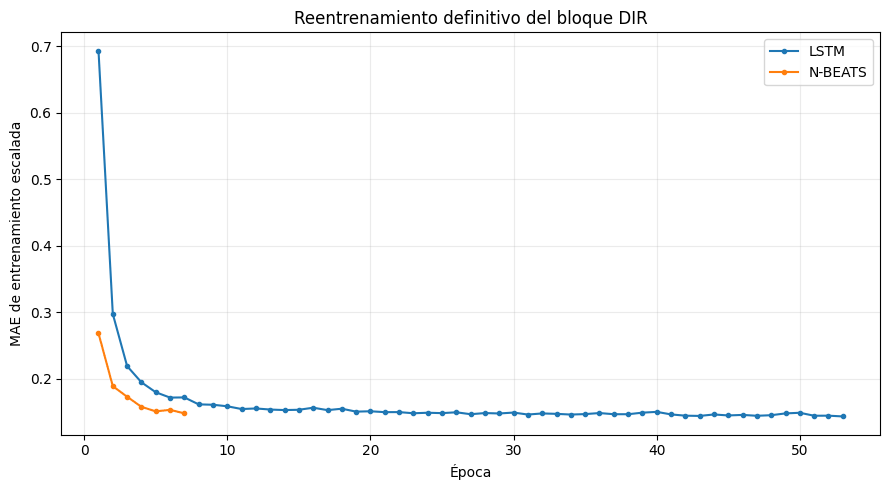

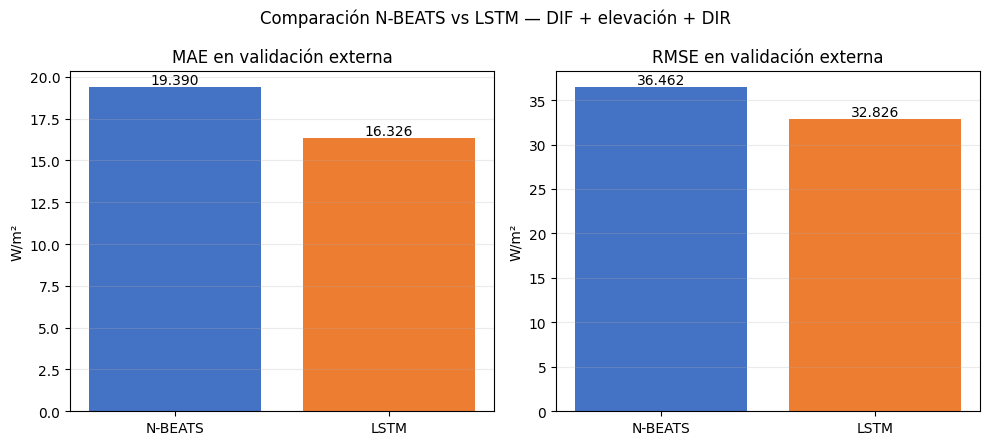


REENTRENAMIENTO DIR COMPLETADO

Resultados externos:


,bloque,modelo,ambito,n,MAE,RMSE,R2,sesgo
0,DIF_Elev_DIR,LSTM,total,1464,16.325878,32.826323,0.907817,0.872132
1,DIF_Elev_DIR,N-BEATS,total,1464,19.389965,36.462485,0.886264,-7.047612



Comparación histórica:


,bloque,modelo,MAE_validation_total,ranking_modelo
0,DIF_Elev_SWD,LSTM,15.867500,1
1,DIF_Elev_DIR,LSTM,16.325878,2
2,DIF_Elev_LWD,LSTM,17.044300,3
3,DIF_Elev_SWD,N-BEATS,18.443800,1
4,DIF_Elev_DIR,N-BEATS,19.389965,2
5,DIF_Elev_LWD,N-BEATS,20.116600,3



Archivos guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_nbeats_lstm_dir_mae_total_20261006_115330

El conjunto test NO ha sido utilizado.


In [ ]:
import os
import json
import copy
import random
import hashlib
import inspect
import unicodedata
from pathlib import Path
from datetime import datetime
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Configuración
SEED = 42
DEVICE = torch.device("cpu")
WINDOW = 24
HORIZON = 1
N_FEATURES = 5
EPOCHS_NBEATS = 7
EPOCHS_LSTM = 53
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0
EXPECTED_PARAMS = {"NBEATS": 310_422, "LSTM": 20_289}
CHANNEL_NAMES = ["DIF", "elevacion", "DIR_media", "DIR_std_media", "DIR_rango"]
BASE_MODELADO = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_NAME = f"reentrenamiento_nbeats_lstm_dir_mae_total_{TIMESTAMP}"
RUN_DIR = BASE_MODELADO / "resultados" / "ejecuciones" / RUN_NAME
MODELOS_DIR = RUN_DIR / "modelos"
SCALERS_DIR = RUN_DIR / "scalers"
PREDICCIONES_DIR = RUN_DIR / "predicciones"
METRICAS_DIR = RUN_DIR / "metricas"
FIGURAS_DIR = RUN_DIR / "figuras"
for directory in [RUN_DIR, MODELOS_DIR, SCALERS_DIR, PREDICCIONES_DIR, METRICAS_DIR, FIGURAS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Dispositivo:", DEVICE)
print("Directorio de ejecución:")
print(RUN_DIR)


# 2. Reproducibilidad
def fijar_semilla(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

fijar_semilla(SEED)


# 3. Recuperación y validación de los arrays preparados

# Las matrices DIR ya existen con estos nombres.
X_train_raw = np.asarray(X_train_DIF_elev_DIR_raw, dtype=np.float32)
X_validation_raw = np.asarray(X_validation_DIF_elev_DIR_raw, dtype=np.float32)

def convertir_objetivo(objeto, longitud_esperada):
    """Convierte Series, arrays o tensores en un vector 1D válido."""
    if torch.is_tensor(objeto):
        array = objeto.detach().cpu().numpy()
    elif isinstance(objeto, (pd.Series, pd.Index, np.ndarray, list, tuple)):
        array = np.asarray(objeto)
    else:
        return None

    array = np.asarray(array)
    if array.size != longitud_esperada:
        return None

    try:
        array = array.astype(np.float32).reshape(-1)
    except (TypeError, ValueError):
        return None

    if not np.isfinite(array).all():
        return None

    return array

def resolver_objetivo(particion, longitud_esperada):
    """
    Recupera el objetivo ya preparado, aunque en el notebook no se
    denomine literalmente y_train o y_validation.
    """
    if particion == "train":
        nombres_prioritarios = [
            "y_train",
            "y_train_raw",
            "y_train_seq",
            "y_train_dir",
            "y_train_swd",
            "y_train_lwd",
            "y_train_hgb",
            "y_train_target",
            "target_train",
            "objetivo_train",
        ]
        dataframes_posibles = ["train_hgb", "df_train_hgb", "train_modelado", "df_train"]

    elif particion == "validation":
        nombres_prioritarios = [
            "y_validation",
            "y_validation_raw",
            "y_validation_seq",
            "y_validation_dir",
            "y_validation_swd",
            "y_validation_lwd",
            "y_validation_hgb",
            "y_validation_target",
            "target_validation",
            "objetivo_validation",
            "y_val",
            "y_val_raw",
        ]
        dataframes_posibles = [
            "validation_hgb",
            "df_validation_hgb",
            "validation_modelado",
            "df_validation",
            "val_hgb",
        ]

    else:
        raise ValueError(particion)

    # 1. Buscar primero los nombres más probables.
    for nombre in nombres_prioritarios:
        if nombre in globals():
            objetivo = convertir_objetivo(globals()[nombre], longitud_esperada)
            if objetivo is not None:
                return objetivo, nombre

    # 2. Buscar otras variables compatibles de la sesión.
    candidatos = []
    palabras_excluidas = [
        "pred",
        "prediction",
        "prediccion",
        "mask",
        "mascara",
        "error",
        "scaled",
        "escalad",
        "indice",
        "index",
    ]
    for nombre, objeto in list(globals().items()):
        nombre_lower = nombre.lower()
        if particion not in nombre_lower:
            continue

        if not (
            nombre_lower.startswith("y") or "target" in nombre_lower or "objetivo" in nombre_lower
        ):
            continue

        if any(palabra in nombre_lower for palabra in palabras_excluidas):
            continue

        objetivo = convertir_objetivo(objeto, longitud_esperada)
        if objetivo is not None:
            candidatos.append((nombre, objetivo))

    if len(candidatos) == 1:
        return candidatos[0][1], candidatos[0][0]

    # 3. Como último recurso, buscar el objetivo en la tabla HGB
    # ya alineada con las ventanas secuenciales.
    columnas_objetivo = [
        "DIF_objetivo",
        "dif_objetivo",
        "DIF_target",
        "dif_target",
        "y",
        "target",
        "DIF",
    ]
    for nombre_df in dataframes_posibles:
        if nombre_df not in globals():
            continue

        dataframe = globals()[nombre_df]
        if not isinstance(dataframe, pd.DataFrame):
            continue

        if len(dataframe) != longitud_esperada:
            continue

        for columna in columnas_objetivo:
            if columna in dataframe.columns:
                objetivo = convertir_objetivo(dataframe[columna], longitud_esperada)
                if objetivo is not None:
                    return (objetivo, f"{nombre_df}['{columna}']")

    # Si hay varios candidatos, no se elige uno arbitrariamente.
    if len(candidatos) > 1:
        nombres = [nombre for nombre, _ in candidatos]
        raise RuntimeError(
            f"Se han encontrado varios posibles objetivos de "
            f"{particion}: {nombres}\n"
            "No se selecciona ninguno automáticamente para evitar "
            "usar una serie incorrecta."
        )

    raise RuntimeError(
        f"No se ha localizado el objetivo de {particion} con "
        f"{longitud_esperada} observaciones.\n"
        "Las matrices DIR sí existen; únicamente falta identificar "
        "el nombre utilizado para el vector objetivo."
    )

y_train_raw, fuente_y_train = resolver_objetivo(
    particion="train", longitud_esperada=len(X_train_raw)
)
y_validation_raw, fuente_y_validation = resolver_objetivo(
    particion="validation", longitud_esperada=len(X_validation_raw)
)
print("Objetivos recuperados:")
print("  train:     ", fuente_y_train)
print("  validation:", fuente_y_validation)


# Comprobaciones de dimensiones y contenido
assert X_train_raw.ndim == 3
assert X_validation_raw.ndim == 3
assert X_train_raw.shape[1:] == (
    WINDOW,
    N_FEATURES,
), f"Forma inesperada de train: {X_train_raw.shape}"
assert X_validation_raw.shape[1:] == (
    WINDOW,
    N_FEATURES,
), f"Forma inesperada de validation: {X_validation_raw.shape}"
assert len(X_train_raw) == len(y_train_raw)
assert len(X_validation_raw) == len(y_validation_raw)
if not np.isfinite(X_train_raw).all():
    raise ValueError("X_train contiene NaN o infinitos.")

if not np.isfinite(X_validation_raw).all():
    raise ValueError("X_validation contiene NaN o infinitos.")

print("\nFormas verificadas:")
print("X_train:     ", X_train_raw.shape)
print("y_train:     ", y_train_raw.shape)
print("X_validation:", X_validation_raw.shape)
print("y_validation:", y_validation_raw.shape)


# 4. Escalado ajustado exclusivamente con train completo
scaler_X = StandardScaler()
scaler_y = StandardScaler()
X_train_scaled = (
    scaler_X.fit_transform(X_train_raw.reshape(-1, N_FEATURES))
    .reshape(X_train_raw.shape)
    .astype(np.float32)
)
X_validation_scaled = (
    scaler_X.transform(X_validation_raw.reshape(-1, N_FEATURES))
    .reshape(X_validation_raw.shape)
    .astype(np.float32)
)
y_train_scaled = scaler_y.fit_transform(y_train_raw.reshape(-1, 1)).reshape(-1).astype(np.float32)
joblib.dump(scaler_X, SCALERS_DIR / "scaler_X_DIF_elev_DIR.joblib")
joblib.dump(scaler_y, SCALERS_DIR / "scaler_y_DIF.joblib")
print("\nEscaladores ajustados y guardados.")


# 5. Creación de modelos nuevos con la arquitectura congelada
def contar_parametros(modelo):
    return sum(parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad)

def reinicializar_pesos(modelo):
    """
    Reinicializa las capas internas de una copia de la arquitectura.
    No conserva los pesos obtenidos durante la selección interna.
    """
    for modulo in modelo.modules():
        if modulo is modelo:
            continue

        if hasattr(modulo, "reset_parameters"):
            modulo.reset_parameters()

    return modelo

def buscar_plantilla_modelo(tipo, parametros_esperados):
    """
    Busca en memoria un modelo de la arquitectura congelada,
    lo copia y reinicializa todos sus pesos.
    """
    candidatos = []
    for nombre, objeto in list(globals().items()):
        if not isinstance(objeto, nn.Module):
            continue

        nombre_modelo = (nombre + " " + objeto.__class__.__name__).lower()
        if tipo.lower() not in nombre_modelo:
            continue

        numero_parametros = contar_parametros(objeto)
        if numero_parametros == parametros_esperados:
            candidatos.append((nombre, objeto))

    if not candidatos:
        return None

    nombre_plantilla, plantilla = candidatos[-1]
    print(f"Plantilla {tipo} encontrada en memoria: " f"{nombre_plantilla}")
    modelo_nuevo = copy.deepcopy(plantilla)
    modelo_nuevo = reinicializar_pesos(modelo_nuevo)
    return modelo_nuevo

def intentar_instanciar_clase(nombre_clase, tipo, parametros_esperados):
    """
    Alternativa si no queda un modelo previo en memoria.
    Prueba las firmas habituales utilizadas en el notebook.
    """
    if nombre_clase not in globals():
        return None

    clase = globals()[nombre_clase]
    intentos = [
        {},
        {"n_features": N_FEATURES},
        {"num_features": N_FEATURES},
        {"input_size": N_FEATURES},
        {"input_dim": N_FEATURES},
        {"n_features": N_FEATURES, "window_size": WINDOW, "horizon": HORIZON},
        {"num_features": N_FEATURES, "window_size": WINDOW, "horizon": HORIZON},
        {"input_size": N_FEATURES, "seq_len": WINDOW, "horizon": HORIZON},
    ]
    errores = []
    for kwargs in intentos:
        try:
            modelo = clase(**kwargs)
            numero_parametros = contar_parametros(modelo)
            if numero_parametros == parametros_esperados:
                print(f"{tipo} creado mediante {nombre_clase}" f" con argumentos {kwargs}")
                return modelo

        except Exception as exc:
            errores.append(str(exc))

    return None

def crear_modelo_nuevo(tipo):
    fijar_semilla(SEED)
    if tipo == "NBEATS":
        esperado = EXPECTED_PARAMS["NBEATS"]
        nombre_clase = "NBEATSSWD"
    elif tipo == "LSTM":
        esperado = EXPECTED_PARAMS["LSTM"]
        nombre_clase = "LSTMSWD"
    else:
        raise ValueError(f"Tipo de modelo desconocido: {tipo}")

    modelo = buscar_plantilla_modelo(tipo, esperado)
    if modelo is None:
        modelo = intentar_instanciar_clase(
            nombre_clase=nombre_clase, tipo=tipo, parametros_esperados=esperado
        )

    if modelo is None:
        raise RuntimeError(
            f"No se ha podido reconstruir {tipo} con la arquitectura "
            f"congelada de {esperado:,} parámetros.\n"
            "Ejecuta primero la celda de definición y selección interna "
            "de modelos DIR, sin reiniciar el entorno de Colab."
        )

    numero_parametros = contar_parametros(modelo)
    if numero_parametros != esperado:
        raise RuntimeError(
            f"{tipo}: se esperaban {esperado:,} parámetros, "
            f"pero se han encontrado {numero_parametros:,}."
        )

    return modelo.to(DEVICE)

modelo_nbeats = crear_modelo_nuevo("NBEATS")
modelo_lstm = crear_modelo_nuevo("LSTM")
print("\nArquitecturas verificadas:")
print("N-BEATS:", f"{contar_parametros(modelo_nbeats):,}", "parámetros")
print("LSTM:   ", f"{contar_parametros(modelo_lstm):,}", "parámetros")


# 6. Funciones de entrenamiento e inferencia
def extraer_prediccion(salida):
    """
    Admite salida tensor, tupla/lista o diccionario.
    """
    if isinstance(salida, dict):
        for clave in ["forecast", "prediction", "prediccion", "output", "y_hat"]:
            if clave in salida:
                salida = salida[clave]
                break
        else:
            raise ValueError("No se reconoce la salida tipo diccionario.")

    if isinstance(salida, (tuple, list)):
        tensores = [elemento for elemento in salida if torch.is_tensor(elemento)]
        if not tensores:
            raise ValueError("La salida del modelo no contiene tensores.")

        # En N-BEATS, el pronóstico suele ser el último tensor.
        salida = tensores[-1]

    if not torch.is_tensor(salida):
        raise TypeError(f"Salida no reconocida: {type(salida)}")

    if salida.ndim == 1:
        return salida

    salida = salida.reshape(salida.shape[0], -1)
    if salida.shape[1] != HORIZON:
        raise ValueError(
            "La salida del modelo no coincide con el horizonte 1: " f"{tuple(salida.shape)}"
        )

    return salida[:, 0]

def entrenar_epocas_fijas(modelo, nombre_modelo, numero_epocas):
    """
    Entrenamiento definitivo con todo train.
    No utiliza validación ni early stopping.
    """
    fijar_semilla(SEED)
    X_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
    y_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)
    dataset = TensorDataset(X_tensor, y_tensor)
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generador,
        num_workers=0,
        pin_memory=False,
        drop_last=False,
    )
    criterio = nn.L1Loss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    historial = []
    print(f"\nEntrenando {nombre_modelo} " f"durante {numero_epocas} épocas...")
    for epoca in range(1, numero_epocas + 1):
        modelo.train()
        perdida_acumulada = 0.0
        numero_muestras = 0
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            salida = modelo(X_batch)
            prediccion = extraer_prediccion(salida)
            perdida = criterio(prediccion, y_batch)
            perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=GRAD_CLIP)
            optimizador.step()
            batch_n = X_batch.shape[0]
            perdida_acumulada += perdida.item() * batch_n
            numero_muestras += batch_n

        perdida_epoca = perdida_acumulada / numero_muestras
        historial.append(
            {"modelo": nombre_modelo, "epoca": epoca, "mae_train_escalada": perdida_epoca}
        )
        print(
            f"{nombre_modelo} | "
            f"época {epoca:03d}/{numero_epocas:03d} | "
            f"MAE escalada: {perdida_epoca:.6f}"
        )

    return pd.DataFrame(historial)

@torch.no_grad()
def predecir_validation(modelo):
    modelo.eval()
    X_tensor = torch.tensor(X_validation_scaled, dtype=torch.float32)
    loader = DataLoader(
        TensorDataset(X_tensor), batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )
    predicciones_escaladas = []
    for (X_batch,) in loader:
        X_batch = X_batch.to(DEVICE)
        salida = modelo(X_batch)
        prediccion = extraer_prediccion(salida)
        predicciones_escaladas.append(prediccion.cpu().numpy())

    predicciones_escaladas = np.concatenate(predicciones_escaladas)
    predicciones = scaler_y.inverse_transform(predicciones_escaladas.reshape(-1, 1)).reshape(-1)
    return predicciones.astype(np.float32)


# 7. Reentrenamiento definitivo
historial_nbeats = entrenar_epocas_fijas(
    modelo=modelo_nbeats, nombre_modelo="N-BEATS", numero_epocas=EPOCHS_NBEATS
)
historial_lstm = entrenar_epocas_fijas(
    modelo=modelo_lstm, nombre_modelo="LSTM", numero_epocas=EPOCHS_LSTM
)
historial = pd.concat([historial_nbeats, historial_lstm], ignore_index=True)
historial.to_csv(METRICAS_DIR / "historial_entrenamiento.csv", index=False)


# 8. Evaluación única sobre validación externa
pred_nbeats = predecir_validation(modelo_nbeats)
pred_lstm = predecir_validation(modelo_lstm)
assert len(pred_nbeats) == len(y_validation_raw)
assert len(pred_lstm) == len(y_validation_raw)

def calcular_metricas(y_real, y_pred):
    error = y_pred - y_real
    return {
        "n": int(len(y_real)),
        "MAE": float(mean_absolute_error(y_real, y_pred)),
        "RMSE": float(mean_squared_error(y_real, y_pred) ** 0.5),
        "R2": float(r2_score(y_real, y_pred)),
        "sesgo": float(np.mean(error)),
    }

metricas_total = []
for nombre, prediccion in [("N-BEATS", pred_nbeats), ("LSTM", pred_lstm)]:
    fila = {
        "bloque": "DIF_Elev_DIR",
        "modelo": nombre,
        "ambito": "total",
        **calcular_metricas(y_validation_raw, prediccion),
    }
    metricas_total.append(fila)


# 9. Detección opcional de la máscara operativa
def normalizar_texto(valor):
    texto = str(valor).strip().lower()
    texto = "".join(
        caracter
        for caracter in unicodedata.normalize("NFD", texto)
        if unicodedata.category(caracter) != "Mn"
    )
    return texto

def recuperar_mascara_operativa(n):
    nombres_posibles = [
        "mask_operational_validation",
        "mask_operativo_validation",
        "mascara_operativa_validation",
        "validation_operational_mask",
        "mask_validation_operativo",
    ]
    for nombre in nombres_posibles:
        if nombre in globals():
            mascara = np.asarray(globals()[nombre]).reshape(-1)
            if len(mascara) == n:
                print("Máscara operativa recuperada desde:", nombre)
                return mascara.astype(bool)

    if "validation_hgb" in globals():
        datos = validation_hgb
        if (
            hasattr(datos, "columns")
            and "regimen_solar_objetivo" in datos.columns
            and len(datos) == n
        ):
            serie = datos["regimen_solar_objetivo"]
            if pd.api.types.is_bool_dtype(serie):
                return serie.to_numpy(dtype=bool)

            if pd.api.types.is_numeric_dtype(serie):
                valores = serie.to_numpy()
                if set(np.unique(valores)).issubset({0, 1}):
                    return valores.astype(bool)

            etiquetas = serie.map(normalizar_texto)
            etiquetas_operativas = {
                "operativo",
                "operational",
                "regimen operativo",
                "solar operativo",
                "diurno",
                "day",
            }
            mascara = etiquetas.isin(etiquetas_operativas).to_numpy()
            if mascara.any():
                print(
                    "Máscara operativa recuperada desde "
                    "validation_hgb['regimen_solar_objetivo']."
                )
                return mascara

    return None

mascara_operativa = recuperar_mascara_operativa(len(y_validation_raw))
metricas_filas = list(metricas_total)
if mascara_operativa is not None and mascara_operativa.any():
    for nombre, prediccion in [("N-BEATS", pred_nbeats), ("LSTM", pred_lstm)]:
        fila = {
            "bloque": "DIF_Elev_DIR",
            "modelo": nombre,
            "ambito": "operativo",
            **calcular_metricas(y_validation_raw[mascara_operativa], prediccion[mascara_operativa]),
        }
        metricas_filas.append(fila)
else:
    print(
        "\nAviso: no se ha podido recuperar automáticamente "
        "la máscara operativa. Se guardarán las métricas totales."
    )

df_metricas = pd.DataFrame(metricas_filas)
df_metricas.to_csv(METRICAS_DIR / "metricas_validation.csv", index=False)
print("\nMÉTRICAS DE VALIDACIÓN EXTERNA")
display(df_metricas.sort_values(["ambito", "MAE"]).reset_index(drop=True))


# 10. Comparación con los bloques ya evaluados
referencias_previas = pd.DataFrame(
    [
        {"bloque": "DIF_Elev_SWD", "modelo": "N-BEATS", "MAE_validation_total": 18.4438},
        {"bloque": "DIF_Elev_SWD", "modelo": "LSTM", "MAE_validation_total": 15.8675},
        {"bloque": "DIF_Elev_LWD", "modelo": "N-BEATS", "MAE_validation_total": 20.1166},
        {"bloque": "DIF_Elev_LWD", "modelo": "LSTM", "MAE_validation_total": 17.0443},
    ]
)
resultados_dir = df_metricas[df_metricas["ambito"] == "total"][["bloque", "modelo", "MAE"]].rename(
    columns={"MAE": "MAE_validation_total"}
)
comparacion_historica = pd.concat([referencias_previas, resultados_dir], ignore_index=True)
comparacion_historica["ranking_modelo"] = (
    comparacion_historica.groupby("modelo")["MAE_validation_total"].rank(method="min").astype(int)
)
comparacion_historica.to_csv(METRICAS_DIR / "comparacion_mae_bloques.csv", index=False)
print("\nCOMPARACIÓN CON SWD Y LWD")
display(
    comparacion_historica.sort_values(["modelo", "MAE_validation_total"]).reset_index(drop=True)
)


# 11. Predicciones y errores
def recuperar_indice_validation(n):
    if "validation_hgb" in globals():
        try:
            indice = pd.Index(validation_hgb.index)
            if len(indice) == n:
                return indice
        except Exception:
            pass

    return pd.RangeIndex(start=0, stop=n, name="muestra")

indice_validation = recuperar_indice_validation(len(y_validation_raw))
df_predicciones = pd.DataFrame(
    {
        "timestamp": indice_validation.astype(str),
        "y_real": y_validation_raw,
        "prediccion_nbeats": pred_nbeats,
        "prediccion_lstm": pred_lstm,
        "error_nbeats": pred_nbeats - y_validation_raw,
        "error_lstm": pred_lstm - y_validation_raw,
        "error_absoluto_nbeats": np.abs(pred_nbeats - y_validation_raw),
        "error_absoluto_lstm": np.abs(pred_lstm - y_validation_raw),
    }
)
if mascara_operativa is not None:
    df_predicciones["es_operativo"] = mascara_operativa.astype(bool)

df_predicciones.to_csv(PREDICCIONES_DIR / "predicciones_validation.csv", index=False)
np.savez_compressed(
    PREDICCIONES_DIR / "predicciones_validation.npz",
    y_validation=y_validation_raw,
    prediccion_nbeats=pred_nbeats,
    prediccion_lstm=pred_lstm,
    mascara_operativa=(
        mascara_operativa if mascara_operativa is not None else np.array([], dtype=bool)
    ),
)


# 12. Guardado de los modelos
torch.save(
    {
        "model_state_dict": modelo_nbeats.state_dict(),
        "modelo": "N-BEATS",
        "bloque": "DIF_Elev_DIR",
        "epocas": EPOCHS_NBEATS,
        "n_parametros": contar_parametros(modelo_nbeats),
        "canales": CHANNEL_NAMES,
        "window": WINDOW,
        "horizon": HORIZON,
        "seed": SEED,
    },
    MODELOS_DIR / "nbeats_DIF_elev_DIR.pt",
)
torch.save(
    {
        "model_state_dict": modelo_lstm.state_dict(),
        "modelo": "LSTM",
        "bloque": "DIF_Elev_DIR",
        "epocas": EPOCHS_LSTM,
        "n_parametros": contar_parametros(modelo_lstm),
        "canales": CHANNEL_NAMES,
        "window": WINDOW,
        "horizon": HORIZON,
        "seed": SEED,
    },
    MODELOS_DIR / "lstm_DIF_elev_DIR.pt",
)
with open(MODELOS_DIR / "arquitectura_nbeats.txt", "w", encoding="utf-8") as archivo:
    archivo.write(str(modelo_nbeats))

with open(MODELOS_DIR / "arquitectura_lstm.txt", "w", encoding="utf-8") as archivo:
    archivo.write(str(modelo_lstm))


# 13. Figuras
plt.figure(figsize=(9, 5))
for nombre, grupo in historial.groupby("modelo"):
    plt.plot(
        grupo["epoca"],
        grupo["mae_train_escalada"],
        marker="o",
        markersize=3,
        linewidth=1.5,
        label=nombre,
    )

plt.xlabel("Época")
plt.ylabel("MAE de entrenamiento escalada")
plt.title("Reentrenamiento definitivo del bloque DIR")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.savefig(FIGURAS_DIR / "curvas_entrenamiento.png", dpi=180, bbox_inches="tight")
plt.show()
metricas_grafico = (
    df_metricas[df_metricas["ambito"] == "total"].set_index("modelo").loc[["N-BEATS", "LSTM"]]
)
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
colores = ["#4472C4", "#ED7D31"]
for ax, metrica in zip(axes, ["MAE", "RMSE"]):
    valores = metricas_grafico[metrica]
    barras = ax.bar(valores.index, valores.values, color=colores)
    ax.set_title(f"{metrica} en validación externa")
    ax.set_ylabel("W/m²")
    ax.grid(axis="y", alpha=0.25)
    for barra, valor in zip(barras, valores.values):
        ax.text(
            barra.get_x() + barra.get_width() / 2,
            barra.get_height(),
            f"{valor:.3f}",
            ha="center",
            va="bottom",
        )

fig.suptitle("Comparación N-BEATS vs LSTM — DIF + elevación + DIR")
fig.tight_layout()
fig.savefig(FIGURAS_DIR / "comparacion_nbeats_lstm_validation.png", dpi=180, bbox_inches="tight")
plt.show()


# 14. Configuración y trazabilidad
configuracion = {
    "run_name": RUN_NAME,
    "timestamp": TIMESTAMP,
    "directorio_base": str(BASE_MODELADO),
    "directorio_ejecucion": str(RUN_DIR),
    "bloque": "DIF_Elev_DIR",
    "canales": CHANNEL_NAMES,
    "n_canales": N_FEATURES,
    "window": WINDOW,
    "horizon": HORIZON,
    "criterio_seleccion_interna": "MAE total",
    "seleccion_interna": {
        "N-BEATS": {
            "epoca_seleccionada": EPOCHS_NBEATS,
            "MAE_interna_total": 26.4311008453,
            "MAE_interna_operativa": 36.9331779480,
        },
        "LSTM": {
            "epoca_seleccionada": EPOCHS_LSTM,
            "MAE_interna_total": 23.2183227539,
            "MAE_interna_operativa": 32.6534729004,
        },
    },
    "entrenamiento": {
        "seed": SEED,
        "batch_size": BATCH_SIZE,
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "gradient_clip": GRAD_CLIP,
        "loss": "MAE/L1 sobre objetivo escalado",
        "device": str(DEVICE),
        "early_stopping": False,
    },
    "arquitecturas": {
        "N-BEATS": {
            "parametros": contar_parametros(modelo_nbeats),
            "epocas_reentrenamiento": EPOCHS_NBEATS,
        },
        "LSTM": {
            "parametros": contar_parametros(modelo_lstm),
            "epocas_reentrenamiento": EPOCHS_LSTM,
        },
    },
    "particiones": {
        "n_train": int(len(y_train_raw)),
        "n_validation": int(len(y_validation_raw)),
        "test_utilizado": False,
    },
    "nota_metodologica": (
        "Se reentrenan N-BEATS y LSTM para mantener un "
        "protocolo simétrico. N-BEATS se conserva aunque "
        "su resultado interno no mejoró los bloques previos."
    ),
}
with open(RUN_DIR / "configuracion.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, indent=2, ensure_ascii=False)


# 15. Manifiesto con integridad de archivos
def calcular_sha256(ruta):
    hash_sha256 = hashlib.sha256()
    with open(ruta, "rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            hash_sha256.update(bloque)

    return hash_sha256.hexdigest()

archivos_generados = []
for ruta in sorted(RUN_DIR.rglob("*")):
    if ruta.is_file() and ruta.name != "manifest.json":
        archivos_generados.append(
            {
                "ruta_relativa": str(ruta.relative_to(RUN_DIR)),
                "tamano_bytes": int(ruta.stat().st_size),
                "sha256": calcular_sha256(ruta),
            }
        )

manifest = {
    "run_name": RUN_NAME,
    "n_archivos": len(archivos_generados),
    "archivos": archivos_generados,
}
with open(RUN_DIR / "manifest.json", "w", encoding="utf-8") as archivo:
    json.dump(manifest, archivo, indent=2, ensure_ascii=False)


# 16. Resumen final
print("\n" + "=" * 70)
print("REENTRENAMIENTO DIR COMPLETADO")
print("=" * 70)
print("\nResultados externos:")
display(df_metricas.sort_values(["ambito", "MAE"]).reset_index(drop=True))
print("\nComparación histórica:")
display(
    comparacion_historica.sort_values(["modelo", "MAE_validation_total"]).reset_index(drop=True)
)
print("\nArchivos guardados en:")
print(RUN_DIR)
print("\nEl conjunto test NO ha sido utilizado.")

**Resultados.** En validación, la LSTM con DIR obtiene un MAE de 16,33 W/m², un R² de 0,91 y un sesgo de 0,87 W/m²; la N-BEATS con DIR, un MAE de 19,39 W/m², un R² de 0,89 y un sesgo de −7,05 W/m². En ambas arquitecturas, el orden por MAE es SWD, DIR y LWD (LSTM: 15,87; 16,33 y 17,04 W/m²; N-BEATS: 18,44; 19,39 y 20,12 W/m²). Las métricas se calculan solo sobre el total de horas, ya que la máscara de operación no se recupera en esta ejecución.

### 6.23 Combinaciones de SWD, DIR y fracción difusa

Se preparan tres extensiones del bloque SWD: SWD + DIR, SWD + fracción difusa histórica y SWD + DIR + fracción difusa. La fracción difusa se calcula como DIF/SWD en cada una de las 24 horas de entrada, solo cuando la elevación solar es positiva y la SWD es de al menos 20 W/m², y vale cero en el resto; los valores válidos se acotan al intervalo [0; 1,2]. Al usar solo horas históricas, no interviene la DIF de la hora objetivo.

Directorio de resultados:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_combinaciones_swd_dir_fd_20261006_120612

Coincidencia en train:
  diferencia máxima DIF:       0.0000000000
  diferencia máxima elevación: 0.0000000000

Coincidencia en validation:
  diferencia máxima DIF:       0.0000000000
  diferencia máxima elevación: 0.0000000000

Diagnóstico de posibles umbrales:


,particion,umbral_SWD,n_total,n_validos,porcentaje_valido,kd_p01,kd_p05,kd_mediana,kd_p95,kd_p99,porcentaje_kd_negativo,porcentaje_kd_mayor_1,porcentaje_kd_mayor_1_2
0,train,5.0,123576,66166,53.542759,0.140562,0.219436,0.873239,1.008850,1.034632,0.0,13.056555,0.000000
1,train,10.0,123576,64031,51.815077,0.133808,0.216592,0.858381,1.006783,1.022715,0.0,12.292483,0.000000
2,train,20.0,123576,61107,49.448922,0.132879,0.214431,0.843694,1.004981,1.015326,0.0,10.995467,0.000000
3,train,50.0,123576,53501,43.294005,0.130751,0.206518,0.778926,1.002032,1.006783,0.0,7.267154,0.000000
4,validation,5.0,35136,19512,55.532787,0.120332,0.207333,0.653061,0.994937,0.999606,0.0,0.861009,0.123001
5,validation,10.0,35136,19289,54.898110,0.120332,0.207333,0.647040,0.995158,0.999606,0.0,0.870963,0.124423
6,validation,20.0,35136,18473,52.575706,0.118819,0.206598,0.631317,0.995158,0.999606,0.0,0.779516,0.129919
7,validation,50.0,35136,16948,48.235428,0.118819,0.202226,0.574950,0.994862,0.997273,0.0,0.424829,0.000000



Construcción definitiva de la fracción difusa:


,particion,n_total,n_validos,porcentaje_valido,n_no_validos_asignados_cero,n_recorte_inferior,n_recorte_superior,porcentaje_recortado_superior_sobre_validos
0,train,123576,61107,49.448922,62469,0,0,0.000000
1,validation,35136,18473,52.575706,16663,0,24,0.129919



Matrices combinadas:


,matriz,n_muestras,ventana,n_canales,n_nan,n_inf
0,SWD_DIR_train,5149,24,8,0,0
1,SWD_DIR_validation,1464,24,8,0,0
2,SWD_FD_train,5149,24,6,0,0
3,SWD_FD_validation,1464,24,6,0,0
4,SWD_DIR_FD_train,5149,24,9,0,0
5,SWD_DIR_FD_validation,1464,24,9,0,0


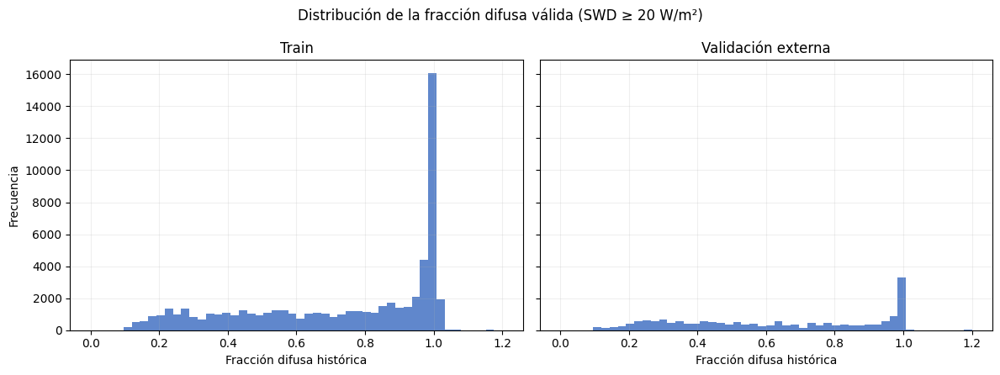


Preparación completada.
Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_combinaciones_swd_dir_fd_20261006_120612

Objetos disponibles para la selección interna:
X_train_DIF_elev_SWD_DIR_raw: (5149, 24, 8)
X_train_DIF_elev_SWD_FD_raw: (5149, 24, 6)
X_train_DIF_elev_SWD_DIR_FD_raw: (5149, 24, 9)


In [ ]:
import json
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Configuración
BASE_MODELADO = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
TIMESTAMP_COMB = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_PREP_COMB = (
    BASE_MODELADO
    / "resultados"
    / "ejecuciones"
    / f"preparacion_combinaciones_swd_dir_fd_{TIMESTAMP_COMB}"
)
RUN_PREP_COMB.mkdir(parents=True, exist_ok=True)
UMBRAL_SWD_FD = 20.0
ELEVACION_MIN_FD = 0.0
KD_MIN = 0.0
KD_MAX = 1.2
print("Directorio de resultados:")
print(RUN_PREP_COMB)


# 2. Comprobar los bloques previamente preparados
variables_necesarias = [
    "X_train_DIF_elev_SWD_raw",
    "X_validation_DIF_elev_SWD_raw",
    "X_train_DIF_elev_DIR_raw",
    "X_validation_DIF_elev_DIR_raw",
]
faltantes = [nombre for nombre in variables_necesarias if nombre not in globals()]
if faltantes:
    raise RuntimeError(
        "Faltan matrices preparadas en memoria:\n"
        f"{faltantes}\n\n"
        "Ejecuta las celdas de preparación de SWD y DIR."
    )

X_SWD_train = np.asarray(X_train_DIF_elev_SWD_raw, dtype=np.float32)
X_SWD_validation = np.asarray(X_validation_DIF_elev_SWD_raw, dtype=np.float32)
X_DIR_train = np.asarray(X_train_DIF_elev_DIR_raw, dtype=np.float32)
X_DIR_validation = np.asarray(X_validation_DIF_elev_DIR_raw, dtype=np.float32)
assert X_SWD_train.shape[1:] == (24, 5)
assert X_SWD_validation.shape[1:] == (24, 5)
assert X_DIR_train.shape[1:] == (24, 5)
assert X_DIR_validation.shape[1:] == (24, 5)
assert X_SWD_train.shape[:2] == X_DIR_train.shape[:2]
assert X_SWD_validation.shape[:2] == X_DIR_validation.shape[:2]
if not all(
    [
        np.isfinite(X_SWD_train).all(),
        np.isfinite(X_SWD_validation).all(),
        np.isfinite(X_DIR_train).all(),
        np.isfinite(X_DIR_validation).all(),
    ]
):
    raise ValueError("Alguna matriz contiene NaN o infinitos.")


# 3. Verificar que DIF y elevación coinciden
for particion, swd, dire in [
    ("train", X_SWD_train, X_DIR_train),
    ("validation", X_SWD_validation, X_DIR_validation),
]:
    diferencia_dif = np.max(np.abs(swd[:, :, 0] - dire[:, :, 0]))
    diferencia_elevacion = np.max(np.abs(swd[:, :, 1] - dire[:, :, 1]))
    print(f"\nCoincidencia en {particion}:")
    print(f"  diferencia máxima DIF:       {diferencia_dif:.10f}")
    print(f"  diferencia máxima elevación: {diferencia_elevacion:.10f}")
    if not np.allclose(swd[:, :, 0], dire[:, :, 0], atol=1e-6, rtol=0):
        raise RuntimeError(f"DIF no coincide entre SWD y DIR en {particion}.")

    if not np.allclose(swd[:, :, 1], dire[:, :, 1], atol=1e-6, rtol=0):
        raise RuntimeError(f"La elevación no coincide entre bloques en {particion}.")


# Orden asumido y ya utilizado en los bloques individuales:
#
# SWD:
# 0 DIF
# 1 elevación
# 2 SWD_media
# 3 SWD_std_media
# 4 SWD_rango
#
# DIR:
# 0 DIF
# 1 elevación
# 2 DIR_media
# 3 DIR_std_media
# 4 DIR_rango


# 4. Diagnóstico del cociente DIF/SWD
def diagnosticar_fraccion(X, particion, umbrales=(5.0, 10.0, 20.0, 50.0)):
    dif = X[:, :, 0].astype(np.float64)
    elevacion = X[:, :, 1].astype(np.float64)
    swd = X[:, :, 2].astype(np.float64)
    filas = []
    for umbral in umbrales:
        mascara = (elevacion > ELEVACION_MIN_FD) & (swd >= umbral)
        ratio = dif[mascara] / swd[mascara]
        if len(ratio) == 0:
            continue

        filas.append(
            {
                "particion": particion,
                "umbral_SWD": umbral,
                "n_total": int(dif.size),
                "n_validos": int(mascara.sum()),
                "porcentaje_valido": float(100 * mascara.mean()),
                "kd_p01": float(np.percentile(ratio, 1)),
                "kd_p05": float(np.percentile(ratio, 5)),
                "kd_mediana": float(np.median(ratio)),
                "kd_p95": float(np.percentile(ratio, 95)),
                "kd_p99": float(np.percentile(ratio, 99)),
                "porcentaje_kd_negativo": float(100 * np.mean(ratio < 0)),
                "porcentaje_kd_mayor_1": float(100 * np.mean(ratio > 1)),
                "porcentaje_kd_mayor_1_2": float(100 * np.mean(ratio > 1.2)),
            }
        )

    return pd.DataFrame(filas)

diagnostico_fd = pd.concat(
    [
        diagnosticar_fraccion(X_SWD_train, "train"),
        diagnosticar_fraccion(X_SWD_validation, "validation"),
    ],
    ignore_index=True,
)
diagnostico_fd.to_csv(RUN_PREP_COMB / "diagnostico_umbrales_fraccion_difusa.csv", index=False)
print("\nDiagnóstico de posibles umbrales:")
display(diagnostico_fd)


# 5. Construcción definitiva de la fracción difusa
def construir_fraccion_difusa(X):
    dif = X[:, :, 0].astype(np.float64)
    elevacion = X[:, :, 1].astype(np.float64)
    swd = X[:, :, 2].astype(np.float64)
    mascara_valida = (elevacion > ELEVACION_MIN_FD) & (swd >= UMBRAL_SWD_FD)
    kd_sin_recortar = np.zeros_like(dif, dtype=np.float64)
    kd_sin_recortar[mascara_valida] = dif[mascara_valida] / swd[mascara_valida]
    mascara_recorte_inferior = mascara_valida & (kd_sin_recortar < KD_MIN)
    mascara_recorte_superior = mascara_valida & (kd_sin_recortar > KD_MAX)
    kd = np.clip(kd_sin_recortar, KD_MIN, KD_MAX).astype(np.float32)
    resumen = {
        "n_total": int(kd.size),
        "n_validos": int(mascara_valida.sum()),
        "porcentaje_valido": float(100 * mascara_valida.mean()),
        "n_no_validos_asignados_cero": int((~mascara_valida).sum()),
        "n_recorte_inferior": int(mascara_recorte_inferior.sum()),
        "n_recorte_superior": int(mascara_recorte_superior.sum()),
        "porcentaje_recortado_superior_sobre_validos": float(
            100 * mascara_recorte_superior.sum() / max(mascara_valida.sum(), 1)
        ),
    }
    return kd, mascara_valida, resumen

kd_train, mask_kd_train, resumen_kd_train = construir_fraccion_difusa(X_SWD_train)
kd_validation, mask_kd_validation, resumen_kd_validation = construir_fraccion_difusa(
    X_SWD_validation
)
print("\nConstrucción definitiva de la fracción difusa:")
display(
    pd.DataFrame(
        [
            {"particion": "train", **resumen_kd_train},
            {"particion": "validation", **resumen_kd_validation},
        ]
    )
)


# 6. Construcción de las tres combinaciones

# Variante A: DIF + elevación + SWD + DIR
X_train_DIF_elev_SWD_DIR_raw = np.concatenate([X_SWD_train, X_DIR_train[:, :, 2:5]], axis=2).astype(
    np.float32
)
X_validation_DIF_elev_SWD_DIR_raw = np.concatenate(
    [X_SWD_validation, X_DIR_validation[:, :, 2:5]], axis=2
).astype(np.float32)


# Variante B: DIF + elevación + SWD + fracción difusa
X_train_DIF_elev_SWD_FD_raw = np.concatenate([X_SWD_train, kd_train[:, :, None]], axis=2).astype(
    np.float32
)
X_validation_DIF_elev_SWD_FD_raw = np.concatenate(
    [X_SWD_validation, kd_validation[:, :, None]], axis=2
).astype(np.float32)


# Variante C: DIF + elevación + SWD + DIR + fracción difusa
X_train_DIF_elev_SWD_DIR_FD_raw = np.concatenate(
    [X_SWD_train, X_DIR_train[:, :, 2:5], kd_train[:, :, None]], axis=2
).astype(np.float32)
X_validation_DIF_elev_SWD_DIR_FD_raw = np.concatenate(
    [X_SWD_validation, X_DIR_validation[:, :, 2:5], kd_validation[:, :, None]], axis=2
).astype(np.float32)
NOMBRES_CANALES_COMBINACIONES = {
    "SWD": ["DIF", "elevacion", "SWD_media", "SWD_std_media", "SWD_rango"],
    "SWD_DIR": [
        "DIF",
        "elevacion",
        "SWD_media",
        "SWD_std_media",
        "SWD_rango",
        "DIR_media",
        "DIR_std_media",
        "DIR_rango",
    ],
    "SWD_FD": ["DIF", "elevacion", "SWD_media", "SWD_std_media", "SWD_rango", "fraccion_difusa"],
    "SWD_DIR_FD": [
        "DIF",
        "elevacion",
        "SWD_media",
        "SWD_std_media",
        "SWD_rango",
        "DIR_media",
        "DIR_std_media",
        "DIR_rango",
        "fraccion_difusa",
    ],
}


# 7. Validaciones finales
matrices = {
    "SWD_DIR_train": X_train_DIF_elev_SWD_DIR_raw,
    "SWD_DIR_validation": X_validation_DIF_elev_SWD_DIR_raw,
    "SWD_FD_train": X_train_DIF_elev_SWD_FD_raw,
    "SWD_FD_validation": X_validation_DIF_elev_SWD_FD_raw,
    "SWD_DIR_FD_train": X_train_DIF_elev_SWD_DIR_FD_raw,
    "SWD_DIR_FD_validation": X_validation_DIF_elev_SWD_DIR_FD_raw,
}
resumen_matrices = []
for nombre, matriz in matrices.items():
    if not np.isfinite(matriz).all():
        raise ValueError(f"{nombre} contiene NaN o infinitos.")

    resumen_matrices.append(
        {
            "matriz": nombre,
            "n_muestras": matriz.shape[0],
            "ventana": matriz.shape[1],
            "n_canales": matriz.shape[2],
            "n_nan": int(np.isnan(matriz).sum()),
            "n_inf": int(np.isinf(matriz).sum()),
        }
    )

df_resumen_matrices = pd.DataFrame(resumen_matrices)
df_resumen_matrices.to_csv(RUN_PREP_COMB / "resumen_matrices.csv", index=False)
print("\nMatrices combinadas:")
display(df_resumen_matrices)


# 8. Figura diagnóstica
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, kd, mascara, titulo in [
    (axes[0], kd_train, mask_kd_train, "Train"),
    (axes[1], kd_validation, mask_kd_validation, "Validación externa"),
]:
    ax.hist(kd[mascara].reshape(-1), bins=50, range=(0, KD_MAX), color="#4472C4", alpha=0.85)
    ax.set_title(titulo)
    ax.set_xlabel("Fracción difusa histórica")
    ax.grid(alpha=0.20)

axes[0].set_ylabel("Frecuencia")
fig.suptitle("Distribución de la fracción difusa válida " f"(SWD ≥ {UMBRAL_SWD_FD:.0f} W/m²)")
fig.tight_layout()
fig.savefig(RUN_PREP_COMB / "distribucion_fraccion_difusa.png", dpi=180, bbox_inches="tight")
plt.show()


# 9. Guardado reproducible
np.savez_compressed(
    RUN_PREP_COMB / "matrices_combinaciones.npz",
    X_train_SWD_DIR=X_train_DIF_elev_SWD_DIR_raw,
    X_validation_SWD_DIR=(X_validation_DIF_elev_SWD_DIR_raw),
    X_train_SWD_FD=X_train_DIF_elev_SWD_FD_raw,
    X_validation_SWD_FD=(X_validation_DIF_elev_SWD_FD_raw),
    X_train_SWD_DIR_FD=(X_train_DIF_elev_SWD_DIR_FD_raw),
    X_validation_SWD_DIR_FD=(X_validation_DIF_elev_SWD_DIR_FD_raw),
    kd_train=kd_train,
    kd_validation=kd_validation,
    mask_kd_train=mask_kd_train,
    mask_kd_validation=mask_kd_validation,
)
configuracion = {
    "timestamp": TIMESTAMP_COMB,
    "directorio_base": str(BASE_MODELADO),
    "umbral_SWD_fraccion_difusa": UMBRAL_SWD_FD,
    "elevacion_minima": ELEVACION_MIN_FD,
    "limites_fraccion_difusa": [KD_MIN, KD_MAX],
    "fraccion_calculada_solo_con_historia": True,
    "usa_objetivo_t": False,
    "canales": NOMBRES_CANALES_COMBINACIONES,
    "formas": {nombre: list(matriz.shape) for nombre, matriz in matrices.items()},
    "resumen_train": resumen_kd_train,
    "resumen_validation": resumen_kd_validation,
}
with open(RUN_PREP_COMB / "configuracion.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, indent=2, ensure_ascii=False)

print("\nPreparación completada.")
print("Resultados guardados en:")
print(RUN_PREP_COMB)
print("\nObjetos disponibles para la selección interna:")
print("X_train_DIF_elev_SWD_DIR_raw:", X_train_DIF_elev_SWD_DIR_raw.shape)
print("X_train_DIF_elev_SWD_FD_raw:", X_train_DIF_elev_SWD_FD_raw.shape)
print("X_train_DIF_elev_SWD_DIR_FD_raw:", X_train_DIF_elev_SWD_DIR_FD_raw.shape)

**Resultados.** Con el umbral de 20 W/m², la fracción difusa es válida en el 49,45 % de las horas históricas de entrenamiento y en el 52,58 % de las de validación. Su mediana es de 0,84 en entrenamiento y de 0,63 en validación, y supera 1 en el 11,00 % de los valores válidos de entrenamiento, frente al 0,78 % en validación. El recorte afecta solo a 24 valores de validación, y las tres matrices combinadas (8, 6 y 9 canales) no contienen valores no finitos.

### 6.24 Selección de épocas para las combinaciones

Se seleccionan las épocas de N-BEATS y LSTM para las tres combinaciones con el mismo protocolo: subtrain con las primeras 4.428 observaciones de entrenamiento, validación interna con las 721 últimas, escalado ajustado con subtrain, pérdida MAE y MAE total interno como criterio. Las arquitecturas no cambian; solo varía el número de canales de entrada y, con él, el de parámetros.

Dispositivo: cpu
Directorio de ejecución:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/seleccion_interna_combinaciones_swd_dir_fd_mae_total_20261006_121216

Objetivo recuperado desde:
y_train_raw

Bloques:
SWD_DIR     : (5149, 24, 8)
SWD_FD      : (5149, 24, 6)
SWD_DIR_FD  : (5149, 24, 9)
Objetivo:     (5149,)

Arquitecturas verificadas:
N-BEATS con 5 canales: 310.422 parámetros
LSTM con 5 canales:     20.289 parámetros
No se ha encontrado máscara operativa. La selección seguirá correctamente basada en MAE total.

N-BEATS | SWD_DIR | 8 canales | 365,718 parámetros
Época 001 | MAE total=36.0183 | MAE operativa=NA | mejor=36.0183 (época 1)
Época 002 | MAE total=32.3074 | MAE operativa=NA | mejor=32.3074 (época 2)
Época 003 | MAE total=31.4925 | MAE operativa=NA | mejor=31.4925 (época 3)
Época 004 | MAE total=29.2829 | MAE operativa=NA | mejor=29.2829 (época 4)
Época 005 | MAE total=28.3849 | MAE operativa=NA | mejor=28.3849 (época 5

,bloque,modelo,n_canales,n_parametros,epoca_seleccionada,mae_internal_total,mae_internal_operativa,epocas_ejecutadas,ranking_modelo
0,SWD_DIR,LSTM,8,21057,47,23.353537,NaN,72,1
1,SWD_FD,LSTM,6,20545,38,23.406107,NaN,63,2
2,SWD_DIR_FD,LSTM,9,21313,38,23.418901,NaN,63,3
3,SWD_FD,N-BEATS,6,328854,16,25.624718,NaN,41,1
4,SWD_DIR_FD,N-BEATS,9,384150,18,27.050928,NaN,43,2
5,SWD_DIR,N-BEATS,8,365718,14,27.484018,NaN,39,3



COMPARACIÓN CON LOS BLOQUES ANTERIORES


,bloque,modelo,epoca_seleccionada,mae_internal_total,mae_internal_operativa,tipo,ranking_modelo
0,DIR,LSTM,53,23.218323,32.653473,referencia previa,1
1,SWD_DIR,LSTM,47,23.353537,NaN,combinación nueva,2
2,SWD_FD,LSTM,38,23.406107,NaN,combinación nueva,3
3,SWD_DIR_FD,LSTM,38,23.418901,NaN,combinación nueva,4
4,SWD,LSTM,59,23.511660,NaN,referencia previa,5
5,LWD,LSTM,43,23.823600,33.588100,referencia previa,6
6,SWD_FD,N-BEATS,16,25.624718,NaN,combinación nueva,1
7,LWD,N-BEATS,6,26.020700,36.258300,referencia previa,2
8,SWD,N-BEATS,18,26.150860,NaN,referencia previa,3
9,DIR,N-BEATS,7,26.431101,36.933178,referencia previa,4


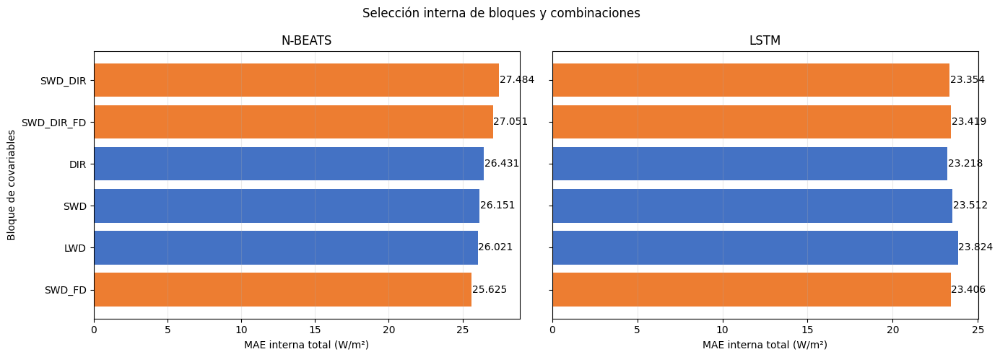


Selección interna completada.
Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/seleccion_interna_combinaciones_swd_dir_fd_mae_total_20261006_121216

La validación externa y test NO se han utilizado.


In [ ]:
import os
import json
import copy
import random
import unicodedata
from pathlib import Path
from datetime import datetime
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error

# 1. Configuración
SEED = 42
DEVICE = torch.device("cpu")
N_SUBTRAIN = 4428
N_INTERNAL_VALIDATION = 721
WINDOW = 24
HORIZON = 1
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0
MAX_EPOCHS = 300
PATIENCE = 25
MIN_DELTA = 1e-5
BASE_MODELADO = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
TIMESTAMP_SEL = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_SELECTION = (
    BASE_MODELADO
    / "resultados"
    / "ejecuciones"
    / f"seleccion_interna_combinaciones_swd_dir_fd_mae_total_{TIMESTAMP_SEL}"
)
RUN_SELECTION.mkdir(parents=True, exist_ok=True)
print("Dispositivo:", DEVICE)
print("Directorio de ejecución:")
print(RUN_SELECTION)


# 2. Reproducibilidad
def fijar_semilla(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

fijar_semilla(SEED)


# 3. Recuperar matrices y objetivo
MATRICES_REQUERIDAS = {
    "SWD_DIR": "X_train_DIF_elev_SWD_DIR_raw",
    "SWD_FD": "X_train_DIF_elev_SWD_FD_raw",
    "SWD_DIR_FD": "X_train_DIF_elev_SWD_DIR_FD_raw",
}
faltantes = [
    nombre_variable
    for nombre_variable in MATRICES_REQUERIDAS.values()
    if nombre_variable not in globals()
]
if faltantes:
    raise RuntimeError(
        "Faltan las siguientes matrices:\n"
        f"{faltantes}\n"
        "Ejecuta antes la preparación de combinaciones."
    )

bloques = {
    bloque: np.asarray(globals()[nombre_variable], dtype=np.float32)
    for bloque, nombre_variable in MATRICES_REQUERIDAS.items()
}

def recuperar_y_train(longitud):
    nombres = [
        "y_train_raw",
        "y_train",
        "y_train_seq",
        "y_train_swd",
        "y_train_dir",
        "y_train_hgb",
        "y_train_target",
        "target_train",
    ]
    for nombre in nombres:
        if nombre not in globals():
            continue

        objeto = globals()[nombre]
        if torch.is_tensor(objeto):
            array = objeto.detach().cpu().numpy()
        else:
            array = np.asarray(objeto)

        if array.size == longitud:
            try:
                array = array.astype(np.float32).reshape(-1)
            except (TypeError, ValueError):
                continue

            if np.isfinite(array).all():
                return array, nombre

    if "train_hgb" in globals():
        dataframe = train_hgb
        if len(dataframe) == longitud:
            for columna in ["DIF_objetivo", "dif_objetivo", "DIF_target", "target", "DIF"]:
                if columna in dataframe.columns:
                    array = dataframe[columna].to_numpy(dtype=np.float32)
                    if np.isfinite(array).all():
                        return (array, f"train_hgb['{columna}']")

    raise RuntimeError("No se ha localizado el objetivo de train.")

n_train = next(iter(bloques.values())).shape[0]
y_train_completo, fuente_objetivo = recuperar_y_train(n_train)
print("\nObjetivo recuperado desde:")
print(fuente_objetivo)
for nombre, X in bloques.items():
    assert X.shape[0] == n_train
    assert X.shape[1] == WINDOW
    assert np.isfinite(X).all()

assert len(y_train_completo) == n_train
assert N_SUBTRAIN + N_INTERNAL_VALIDATION == n_train
print("\nBloques:")
for nombre, X in bloques.items():
    print(f"{nombre:12s}: {X.shape}")

print("Objetivo:    ", y_train_completo.shape)


# 4. Arquitecturas congeladas y generalizadas
class NBEATSBlockMultivariante(nn.Module):
    def __init__(self, n_features, window=24, horizon=1, hidden_size=128, n_dense_layers=3):
        super().__init__()
        input_size = window * n_features
        capas = [nn.Linear(input_size, hidden_size), nn.ReLU()]
        for _ in range(n_dense_layers - 1):
            capas.extend([nn.Linear(hidden_size, hidden_size), nn.ReLU()])

        self.fc = nn.Sequential(*capas)
        self.backcast_head = nn.Linear(hidden_size, window)
        self.forecast_head = nn.Linear(hidden_size, horizon)

    def forward(self, x):
        h = self.fc(x)
        backcast = self.backcast_head(h)
        forecast = self.forecast_head(h)
        return backcast, forecast

class NBEATSMultivariante(nn.Module):
    def __init__(
        self,
        n_features,
        window=24,
        horizon=1,
        n_stacks=2,
        blocks_per_stack=3,
        hidden_size=128,
        n_dense_layers=3,
    ):
        super().__init__()
        self.n_features = n_features
        self.window = window
        self.horizon = horizon
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockMultivariante(
                    n_features=n_features,
                    window=window,
                    horizon=horizon,
                    hidden_size=hidden_size,
                    n_dense_layers=n_dense_layers,
                )
                for _ in range(n_stacks * blocks_per_stack)
            ]
        )

    def forward(self, x):
        # Residuo sobre la historia de DIF.
        residual_dif = x[:, :, 0]

        # Covariables históricas que permanecen disponibles
        # en todos los bloques.
        covariables = x[:, :, 1:]
        forecast_total = torch.zeros((x.shape[0], self.horizon), device=x.device, dtype=x.dtype)
        for block in self.blocks:
            entrada_bloque = torch.cat([residual_dif.unsqueeze(-1), covariables], dim=2).reshape(
                x.shape[0], -1
            )
            backcast, forecast = block(entrada_bloque)
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast

        return forecast_total

class LSTMMultivariante(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=num_layers, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        ultimo_estado = salida[:, -1, :]
        return self.head(ultimo_estado)

def contar_parametros(modelo):
    return sum(parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad)


# Comprobación contra las arquitecturas originales de cinco canales.
modelo_control_nbeats = NBEATSMultivariante(n_features=5)
modelo_control_lstm = LSTMMultivariante(n_features=5)
assert contar_parametros(modelo_control_nbeats) == 310_422, (
    "La arquitectura N-BEATS no reproduce los 310.422 parámetros originales."
)
assert contar_parametros(modelo_control_lstm) == 20_289, (
    "La arquitectura LSTM no reproduce los 20.289 parámetros originales."
)
del modelo_control_nbeats
del modelo_control_lstm
print("\nArquitecturas verificadas:")
print("N-BEATS con 5 canales: 310.422 parámetros")
print("LSTM con 5 canales:     20.289 parámetros")


# 5. Máscara operativa interna, si está disponible
def normalizar_texto(valor):
    texto = str(valor).strip().lower()
    return "".join(
        caracter
        for caracter in unicodedata.normalize("NFD", texto)
        if unicodedata.category(caracter) != "Mn"
    )

def recuperar_mascara_operativa_train(n):
    nombres = [
        "mask_operational_train",
        "mask_operativo_train",
        "mascara_operativa_train",
        "train_operational_mask",
        "mask_train_operativo",
    ]
    for nombre in nombres:
        if nombre not in globals():
            continue

        mascara = np.asarray(globals()[nombre]).reshape(-1)
        if len(mascara) == n:
            print("Máscara operativa recuperada desde:", nombre)
            return mascara.astype(bool)

    if "train_hgb" in globals():
        dataframe = train_hgb
        if (
            isinstance(dataframe, pd.DataFrame)
            and len(dataframe) == n
            and "regimen_solar_objetivo" in dataframe.columns
        ):
            serie = dataframe["regimen_solar_objetivo"]
            if pd.api.types.is_bool_dtype(serie):
                return serie.to_numpy(dtype=bool)

            if pd.api.types.is_numeric_dtype(serie):
                valores = serie.to_numpy()
                if set(np.unique(valores)).issubset({0, 1}):
                    return valores.astype(bool)

            etiquetas = serie.map(normalizar_texto)
            mascara = etiquetas.isin(
                {
                    "operativo",
                    "operational",
                    "regimen operativo",
                    "solar operativo",
                    "diurno",
                    "day",
                }
            ).to_numpy()
            if mascara.any():
                print("Máscara operativa recuperada desde train_hgb['regimen_solar_objetivo'].")
                return mascara

    print(
        "No se ha encontrado máscara operativa. "
        "La selección seguirá correctamente basada "
        "en MAE total."
    )
    return None

mascara_operativa_train = recuperar_mascara_operativa_train(n_train)
if mascara_operativa_train is not None:
    mascara_operativa_interna = mascara_operativa_train[N_SUBTRAIN:]
else:
    mascara_operativa_interna = None


# 6. Preparación de cada bloque
def preparar_bloque(X_raw, nombre_bloque):
    X_subtrain_raw = X_raw[:N_SUBTRAIN]
    X_internal_raw = X_raw[N_SUBTRAIN:]
    y_subtrain_raw = y_train_completo[:N_SUBTRAIN]
    y_internal_raw = y_train_completo[N_SUBTRAIN:]
    n_features = X_raw.shape[2]
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    X_subtrain_scaled = (
        scaler_X.fit_transform(X_subtrain_raw.reshape(-1, n_features))
        .reshape(X_subtrain_raw.shape)
        .astype(np.float32)
    )
    X_internal_scaled = (
        scaler_X.transform(X_internal_raw.reshape(-1, n_features))
        .reshape(X_internal_raw.shape)
        .astype(np.float32)
    )
    y_subtrain_scaled = (
        scaler_y.fit_transform(y_subtrain_raw.reshape(-1, 1)).reshape(-1).astype(np.float32)
    )
    directorio_bloque = RUN_SELECTION / nombre_bloque
    directorio_bloque.mkdir(parents=True, exist_ok=True)
    joblib.dump(scaler_X, directorio_bloque / "scaler_X.joblib")
    joblib.dump(scaler_y, directorio_bloque / "scaler_y.joblib")
    return {
        "X_subtrain": X_subtrain_scaled,
        "X_internal": X_internal_scaled,
        "y_subtrain": y_subtrain_scaled,
        "y_internal_raw": y_internal_raw,
        "scaler_X": scaler_X,
        "scaler_y": scaler_y,
        "n_features": n_features,
        "directorio": directorio_bloque,
    }

bloques_preparados = {nombre: preparar_bloque(X, nombre) for nombre, X in bloques.items()}


# 7. Entrenamiento con early stopping
@torch.no_grad()
def predecir_escalado(modelo, X):
    modelo.eval()
    dataset = TensorDataset(torch.tensor(X, dtype=torch.float32))
    loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    predicciones = []
    for (X_batch,) in loader:
        salida = modelo(X_batch.to(DEVICE))
        salida = salida.reshape(salida.shape[0], -1)[:, 0]
        predicciones.append(salida.cpu().numpy())

    return np.concatenate(predicciones)

def entrenar_seleccion(nombre_bloque, nombre_modelo, datos):
    fijar_semilla(SEED)
    n_features = datos["n_features"]
    if nombre_modelo == "N-BEATS":
        modelo = NBEATSMultivariante(n_features=n_features)
    elif nombre_modelo == "LSTM":
        modelo = LSTMMultivariante(n_features=n_features)
    else:
        raise ValueError(nombre_modelo)

    modelo = modelo.to(DEVICE)
    X_tensor = torch.tensor(datos["X_subtrain"], dtype=torch.float32)
    y_tensor = torch.tensor(datos["y_subtrain"], dtype=torch.float32)
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader = DataLoader(
        TensorDataset(X_tensor, y_tensor),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generador,
        num_workers=0,
        drop_last=False,
    )
    criterio = nn.L1Loss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    mejor_mae = np.inf
    mejor_mae_operativa = np.nan
    mejor_epoca = None
    mejor_estado = None
    mejor_prediccion = None
    contador_paciencia = 0
    historial = []
    print(
        f"\n{'=' * 65}\n"
        f"{nombre_modelo} | {nombre_bloque} | "
        f"{n_features} canales | "
        f"{contar_parametros(modelo):,} parámetros\n"
        f"{'=' * 65}"
    )
    for epoca in range(1, MAX_EPOCHS + 1):
        modelo.train()
        perdida_acumulada = 0.0
        n_observaciones = 0
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            salida = modelo(X_batch).reshape(X_batch.shape[0], -1)[:, 0]
            perdida = criterio(salida, y_batch)
            perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), GRAD_CLIP)
            optimizador.step()
            batch_n = X_batch.shape[0]
            perdida_acumulada += perdida.item() * batch_n
            n_observaciones += batch_n

        mae_train_escalada = perdida_acumulada / n_observaciones
        prediccion_escalada = predecir_escalado(modelo, datos["X_internal"])
        prediccion_original = (
            datos["scaler_y"].inverse_transform(prediccion_escalada.reshape(-1, 1)).reshape(-1)
        )
        mae_total = mean_absolute_error(datos["y_internal_raw"], prediccion_original)
        if mascara_operativa_interna is not None and mascara_operativa_interna.any():
            mae_operativa = mean_absolute_error(
                datos["y_internal_raw"][mascara_operativa_interna],
                prediccion_original[mascara_operativa_interna],
            )
        else:
            mae_operativa = np.nan

        historial.append(
            {
                "bloque": nombre_bloque,
                "modelo": nombre_modelo,
                "epoca": epoca,
                "mae_train_escalada": (mae_train_escalada),
                "mae_internal_total": mae_total,
                "mae_internal_operativa": (mae_operativa),
            }
        )
        mejora = mae_total < mejor_mae - MIN_DELTA
        if mejora:
            mejor_mae = float(mae_total)
            mejor_mae_operativa = float(mae_operativa)
            mejor_epoca = epoca
            mejor_estado = {
                clave: valor.detach().cpu().clone() for clave, valor in modelo.state_dict().items()
            }
            mejor_prediccion = prediccion_original.copy()
            contador_paciencia = 0
        else:
            contador_paciencia += 1

        if epoca == 1 or epoca % 10 == 0 or mejora:
            texto_operativo = f"{mae_operativa:.4f}" if np.isfinite(mae_operativa) else "NA"
            print(
                f"Época {epoca:03d} | "
                f"MAE total={mae_total:.4f} | "
                f"MAE operativa={texto_operativo} | "
                f"mejor={mejor_mae:.4f} "
                f"(época {mejor_epoca})"
            )

        if contador_paciencia >= PATIENCE:
            print(f"Early stopping en época {epoca}. " f"Mejor época: {mejor_epoca}.")
            break

    modelo.load_state_dict(mejor_estado)
    directorio_modelo = datos["directorio"] / nombre_modelo.lower().replace("-", "")
    directorio_modelo.mkdir(parents=True, exist_ok=True)
    df_historial = pd.DataFrame(historial)
    df_historial.to_csv(directorio_modelo / "historial_seleccion.csv", index=False)
    np.savez_compressed(
        directorio_modelo / "prediccion_mejor_epoca.npz",
        y_internal=datos["y_internal_raw"],
        prediccion_internal=mejor_prediccion,
        mascara_operativa=(
            mascara_operativa_interna
            if mascara_operativa_interna is not None
            else np.array([], dtype=bool)
        ),
    )
    torch.save(
        {
            "model_state_dict": mejor_estado,
            "bloque": nombre_bloque,
            "modelo": nombre_modelo,
            "n_features": n_features,
            "n_parametros": (contar_parametros(modelo)),
            "mejor_epoca": mejor_epoca,
            "mae_internal_total": mejor_mae,
            "mae_internal_operativa": (mejor_mae_operativa),
            "seed": SEED,
        },
        directorio_modelo / "mejor_modelo_internal.pt",
    )
    resultado = {
        "bloque": nombre_bloque,
        "modelo": nombre_modelo,
        "n_canales": n_features,
        "n_parametros": contar_parametros(modelo),
        "epoca_seleccionada": mejor_epoca,
        "mae_internal_total": mejor_mae,
        "mae_internal_operativa": (mejor_mae_operativa),
        "epocas_ejecutadas": len(historial),
    }
    return resultado, df_historial


# 8. Ejecutar las seis selecciones internas
resultados = []
historiales = []
orden_bloques = ["SWD_DIR", "SWD_FD", "SWD_DIR_FD"]
orden_modelos = ["N-BEATS", "LSTM"]
for nombre_bloque in orden_bloques:
    for nombre_modelo in orden_modelos:
        resultado, historial = entrenar_seleccion(
            nombre_bloque=nombre_bloque,
            nombre_modelo=nombre_modelo,
            datos=bloques_preparados[nombre_bloque],
        )
        resultados.append(resultado)
        historiales.append(historial)


# 9. Resumen y comparación con bloques anteriores
df_resultados = pd.DataFrame(resultados)
df_resultados["ranking_modelo"] = (
    df_resultados.groupby("modelo")["mae_internal_total"].rank(method="min").astype(int)
)
df_resultados = df_resultados.sort_values(["modelo", "mae_internal_total"]).reset_index(drop=True)
df_resultados.to_csv(RUN_SELECTION / "resumen_seleccion_interna.csv", index=False)
df_historial_completo = pd.concat(historiales, ignore_index=True)
df_historial_completo.to_csv(RUN_SELECTION / "historial_completo.csv", index=False)
print("\n" + "=" * 80)
print("RESULTADOS DE LA SELECCIÓN INTERNA")
print("=" * 80)
display(df_resultados)
referencias_anteriores = pd.DataFrame(
    [
        {
            "bloque": "SWD",
            "modelo": "N-BEATS",
            "epoca_seleccionada": 18,
            "mae_internal_total": 26.1508598,
            "mae_internal_operativa": np.nan,
            "tipo": "referencia previa",
        },
        {
            "bloque": "LWD",
            "modelo": "N-BEATS",
            "epoca_seleccionada": 6,
            "mae_internal_total": 26.0207,
            "mae_internal_operativa": 36.2583,
            "tipo": "referencia previa",
        },
        {
            "bloque": "DIR",
            "modelo": "N-BEATS",
            "epoca_seleccionada": 7,
            "mae_internal_total": 26.4311008,
            "mae_internal_operativa": 36.9331779,
            "tipo": "referencia previa",
        },
        {
            "bloque": "SWD",
            "modelo": "LSTM",
            "epoca_seleccionada": 59,
            "mae_internal_total": 23.5116596,
            "mae_internal_operativa": np.nan,
            "tipo": "referencia previa",
        },
        {
            "bloque": "LWD",
            "modelo": "LSTM",
            "epoca_seleccionada": 43,
            "mae_internal_total": 23.8236,
            "mae_internal_operativa": 33.5881,
            "tipo": "referencia previa",
        },
        {
            "bloque": "DIR",
            "modelo": "LSTM",
            "epoca_seleccionada": 53,
            "mae_internal_total": 23.2183228,
            "mae_internal_operativa": 32.6534729,
            "tipo": "referencia previa",
        },
    ]
)
nuevos_resultados = df_resultados[
    ["bloque", "modelo", "epoca_seleccionada", "mae_internal_total", "mae_internal_operativa"]
].copy()
nuevos_resultados["tipo"] = "combinación nueva"
comparacion_completa = pd.concat([referencias_anteriores, nuevos_resultados], ignore_index=True)
comparacion_completa["ranking_modelo"] = (
    comparacion_completa.groupby("modelo")["mae_internal_total"].rank(method="min").astype(int)
)
comparacion_completa = comparacion_completa.sort_values(
    ["modelo", "mae_internal_total"]
).reset_index(drop=True)
comparacion_completa.to_csv(RUN_SELECTION / "comparacion_interna_completa.csv", index=False)
print("\nCOMPARACIÓN CON LOS BLOQUES ANTERIORES")
display(comparacion_completa)


# 10. Figura comparativa
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, modelo in zip(axes, ["N-BEATS", "LSTM"]):
    tabla = comparacion_completa[comparacion_completa["modelo"] == modelo].sort_values(
        "mae_internal_total"
    )
    colores = ["#ED7D31" if tipo == "combinación nueva" else "#4472C4" for tipo in tabla["tipo"]]
    barras = ax.barh(tabla["bloque"], tabla["mae_internal_total"], color=colores)
    ax.invert_yaxis()
    ax.set_title(modelo)
    ax.set_xlabel("MAE interna total (W/m²)")
    ax.grid(axis="x", alpha=0.25)
    for barra, valor in zip(barras, tabla["mae_internal_total"]):
        ax.text(valor + 0.03, barra.get_y() + barra.get_height() / 2, f"{valor:.3f}", va="center")

axes[0].set_ylabel("Bloque de covariables")
fig.suptitle("Selección interna de bloques y combinaciones")
fig.tight_layout()
fig.savefig(RUN_SELECTION / "comparacion_seleccion_interna.png", dpi=180, bbox_inches="tight")
plt.show()


# 11. Configuración
configuracion = {
    "timestamp": TIMESTAMP_SEL,
    "criterio_seleccion": "MAE interna total",
    "n_subtrain": N_SUBTRAIN,
    "n_internal_validation": (N_INTERNAL_VALIDATION),
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "min_delta": MIN_DELTA,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "gradient_clip": GRAD_CLIP,
    "seed": SEED,
    "device": str(DEVICE),
    "validation_externa_utilizada": False,
    "test_utilizado": False,
    "arquitecturas_control": {"N-BEATS_5_canales": 310422, "LSTM_5_canales": 20289},
    "bloques": {
        nombre: {"shape": list(X.shape), "n_canales": int(X.shape[2])}
        for nombre, X in bloques.items()
    },
}
with open(RUN_SELECTION / "configuracion.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, indent=2, ensure_ascii=False)

print("\nSelección interna completada.")
print("Resultados guardados en:")
print(RUN_SELECTION)
print("\nLa validación externa y test NO se han utilizado.")

**Resultados.** En la LSTM, las tres combinaciones obtienen un MAE interno total de entre 23,35 y 23,42 W/m² (47, 38 y 38 épocas para SWD + DIR, SWD + fracción difusa y SWD + DIR + fracción difusa), por debajo del bloque SWD (23,51 W/m²) y por encima del bloque DIR (23,22 W/m²). En N-BEATS, SWD + fracción difusa alcanza el menor MAE interno de la arquitectura (25,62 W/m², 16 épocas), mientras que SWD + DIR + fracción difusa (27,05 W/m², 18 épocas) y SWD + DIR (27,48 W/m², 14 épocas) quedan por encima de todos los bloques individuales.

### 6.25 Reentrenamiento y evaluación de las combinaciones

Cada modelo se reinicializa y se reentrena con todo el conjunto de entrenamiento durante el número de épocas seleccionado internamente, con escaladores ajustados solo con entrenamiento. Después se evalúa una única vez en validación y se compara con los bloques individuales SWD, DIR y LWD.

Dispositivo: cpu
Directorio de ejecución:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_combinaciones_swd_dir_fd_20261006_122214

Objetivos recuperados:
train:      y_train_raw
validation: y_validation_raw
y_train:      (5149,)
y_validation: (1464,)

N-BEATS | SWD_DIR | 14 épocas
Época 001/014 | MAE escalada: 0.286038
Época 002/014 | MAE escalada: 0.192853
Época 003/014 | MAE escalada: 0.180685
Época 004/014 | MAE escalada: 0.164013
Época 005/014 | MAE escalada: 0.153929
Época 006/014 | MAE escalada: 0.153515
Época 007/014 | MAE escalada: 0.155299
Época 008/014 | MAE escalada: 0.146228
Época 009/014 | MAE escalada: 0.141103
Época 010/014 | MAE escalada: 0.139513
Época 011/014 | MAE escalada: 0.134264
Época 012/014 | MAE escalada: 0.135882
Época 013/014 | MAE escalada: 0.134231
Época 014/014 | MAE escalada: 0.123609

LSTM | SWD_DIR | 47 épocas
Época 001/047 | MAE escalada: 0.603031
Época 002/047 | MAE escalada: 0.270

,bloque,modelo,epocas,n_canales,n_parametros,n,MAE,RMSE,R2,sesgo,ranking_modelo
0,SWD_DIR_FD,LSTM,38,9,21313,1464,15.885435,32.348013,0.910484,-1.134845,1
1,SWD_FD,LSTM,38,6,20545,1464,16.230541,32.715552,0.908438,1.256038,2
2,SWD_DIR,LSTM,47,8,21057,1464,16.350744,33.400176,0.904566,0.766572,3
3,SWD_FD,N-BEATS,16,6,328854,1464,18.468481,35.225158,0.893852,1.077317,1
4,SWD_DIR,N-BEATS,14,8,365718,1464,18.595570,35.334557,0.893192,2.815677,2
5,SWD_DIR_FD,N-BEATS,18,9,384150,1464,20.789492,38.154770,0.875462,9.140726,3



COMPARACIÓN EXTERNA COMPLETA


,bloque,modelo,MAE,tipo,delta_MAE_vs_SWD,delta_pct_vs_SWD,ranking_modelo
0,SWD,LSTM,15.867500,bloque individual,0.000000,0.000000,1
1,SWD_DIR_FD,LSTM,15.885435,combinación nueva,0.017935,0.113030,2
2,SWD_FD,LSTM,16.230541,combinación nueva,0.363041,2.287955,3
3,DIR,LSTM,16.325878,bloque individual,0.458378,2.888785,4
4,SWD_DIR,LSTM,16.350744,combinación nueva,0.483244,3.045497,5
5,LWD,LSTM,17.044300,bloque individual,1.176800,7.416417,6
6,SWD,N-BEATS,18.443800,bloque individual,0.000000,0.000000,1
7,SWD_FD,N-BEATS,18.468481,combinación nueva,0.024681,0.133818,2
8,SWD_DIR,N-BEATS,18.595570,combinación nueva,0.151770,0.822876,3
9,DIR,N-BEATS,19.389965,bloque individual,0.946165,5.129989,4


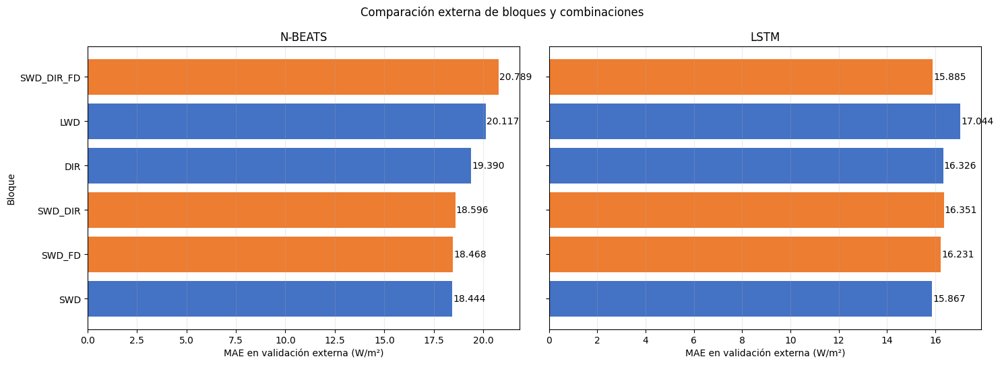


Reentrenamiento completado.
Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_combinaciones_swd_dir_fd_20261006_122214

El conjunto test NO ha sido utilizado.


In [ ]:
import os
import json
import random
from pathlib import Path
from datetime import datetime
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Configuración
SEED = 42
DEVICE = torch.device("cpu")
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0
EPOCAS_SELECCIONADAS = {
    ("SWD_DIR", "N-BEATS"): 14,
    ("SWD_DIR", "LSTM"): 47,
    ("SWD_FD", "N-BEATS"): 16,
    ("SWD_FD", "LSTM"): 38,
    ("SWD_DIR_FD", "N-BEATS"): 18,
    ("SWD_DIR_FD", "LSTM"): 38,
}
BASE_MODELADO = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
TIMESTAMP_FULL = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_FULL = (
    BASE_MODELADO
    / "resultados"
    / "ejecuciones"
    / f"reentrenamiento_combinaciones_swd_dir_fd_{TIMESTAMP_FULL}"
)
RUN_FULL.mkdir(parents=True, exist_ok=True)
print("Dispositivo:", DEVICE)
print("Directorio de ejecución:")
print(RUN_FULL)


# 2. Comprobar que siguen disponibles las arquitecturas
clases_necesarias = ["NBEATSMultivariante", "LSTMMultivariante"]
faltan_clases = [nombre for nombre in clases_necesarias if nombre not in globals()]
if faltan_clases:
    raise RuntimeError(
        "Faltan las clases de los modelos:\n"
        f"{faltan_clases}\n"
        "Ejecuta antes la celda de selección interna."
    )

def fijar_semilla(seed=42):
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    if hasattr(torch.backends, "cudnn"):
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

def contar_parametros(modelo):
    return sum(parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad)

fijar_semilla(SEED)


# 3. Recuperar matrices
NOMBRES_MATRICES = {
    "SWD_DIR": ("X_train_DIF_elev_SWD_DIR_raw", "X_validation_DIF_elev_SWD_DIR_raw"),
    "SWD_FD": ("X_train_DIF_elev_SWD_FD_raw", "X_validation_DIF_elev_SWD_FD_raw"),
    "SWD_DIR_FD": ("X_train_DIF_elev_SWD_DIR_FD_raw", "X_validation_DIF_elev_SWD_DIR_FD_raw"),
}
faltantes = []
for nombres in NOMBRES_MATRICES.values():
    for nombre in nombres:
        if nombre not in globals():
            faltantes.append(nombre)

if faltantes:
    raise RuntimeError(
        "Faltan matrices en memoria:\n"
        f"{faltantes}\n"
        "Ejecuta antes la preparación de combinaciones."
    )

bloques_full = {}
for bloque, (nombre_train, nombre_validation) in NOMBRES_MATRICES.items():
    X_train_bloque = np.asarray(globals()[nombre_train], dtype=np.float32)
    X_validation_bloque = np.asarray(globals()[nombre_validation], dtype=np.float32)
    assert X_train_bloque.shape[1] == 24
    assert X_validation_bloque.shape[1] == 24
    assert np.isfinite(X_train_bloque).all()
    assert np.isfinite(X_validation_bloque).all()
    bloques_full[bloque] = {
        "X_train_raw": X_train_bloque,
        "X_validation_raw": (X_validation_bloque),
        "n_features": X_train_bloque.shape[2],
    }


# 4. Recuperar objetivos
def convertir_objetivo(objeto, longitud):
    if torch.is_tensor(objeto):
        array = objeto.detach().cpu().numpy()
    else:
        try:
            array = np.asarray(objeto)
        except Exception:
            return None

    if array.size != longitud:
        return None

    try:
        array = array.astype(np.float32).reshape(-1)
    except (TypeError, ValueError):
        return None

    if not np.isfinite(array).all():
        return None

    return array

def recuperar_objetivo(particion, longitud):
    if particion == "train":
        nombres = [
            "y_train_raw",
            "y_train",
            "y_train_seq",
            "y_train_swd",
            "y_train_dir",
            "y_train_hgb",
            "target_train",
        ]
        dataframes = ["train_hgb", "df_train_hgb"]

    else:
        nombres = [
            "y_validation_raw",
            "y_validation",
            "y_validation_seq",
            "y_validation_swd",
            "y_validation_dir",
            "y_validation_hgb",
            "y_val",
            "target_validation",
        ]
        dataframes = ["validation_hgb", "df_validation_hgb"]

    for nombre in nombres:
        if nombre in globals():
            objetivo = convertir_objetivo(globals()[nombre], longitud)
            if objetivo is not None:
                return objetivo, nombre

    for nombre_df in dataframes:
        if nombre_df not in globals():
            continue

        dataframe = globals()[nombre_df]
        if not isinstance(dataframe, pd.DataFrame) or len(dataframe) != longitud:
            continue

        for columna in ["DIF_objetivo", "dif_objetivo", "DIF_target", "target", "DIF"]:
            if columna in dataframe.columns:
                objetivo = convertir_objetivo(dataframe[columna], longitud)
                if objetivo is not None:
                    return (objetivo, f"{nombre_df}['{columna}']")

    raise RuntimeError(f"No se ha localizado el objetivo de {particion}.")

primer_bloque = bloques_full["SWD_DIR"]
y_train_full, fuente_train = recuperar_objetivo("train", len(primer_bloque["X_train_raw"]))
y_validation_full, fuente_validation = recuperar_objetivo(
    "validation", len(primer_bloque["X_validation_raw"])
)
print("\nObjetivos recuperados:")
print("train:     ", fuente_train)
print("validation:", fuente_validation)
print("y_train:     ", y_train_full.shape)
print("y_validation:", y_validation_full.shape)


# 5. Escalado por bloque
for bloque, datos in bloques_full.items():
    X_train_raw = datos["X_train_raw"]
    X_validation_raw = datos["X_validation_raw"]
    n_features = datos["n_features"]
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()
    X_train_scaled = (
        scaler_X.fit_transform(X_train_raw.reshape(-1, n_features))
        .reshape(X_train_raw.shape)
        .astype(np.float32)
    )
    X_validation_scaled = (
        scaler_X.transform(X_validation_raw.reshape(-1, n_features))
        .reshape(X_validation_raw.shape)
        .astype(np.float32)
    )
    y_train_scaled = (
        scaler_y.fit_transform(y_train_full.reshape(-1, 1)).reshape(-1).astype(np.float32)
    )
    directorio_bloque = RUN_FULL / bloque
    (directorio_bloque / "modelos").mkdir(parents=True, exist_ok=True)
    (directorio_bloque / "scalers").mkdir(parents=True, exist_ok=True)
    (directorio_bloque / "predicciones").mkdir(parents=True, exist_ok=True)
    (directorio_bloque / "metricas").mkdir(parents=True, exist_ok=True)
    joblib.dump(scaler_X, directorio_bloque / "scalers" / "scaler_X.joblib")
    joblib.dump(scaler_y, directorio_bloque / "scalers" / "scaler_y.joblib")
    datos.update(
        {
            "X_train_scaled": X_train_scaled,
            "X_validation_scaled": (X_validation_scaled),
            "y_train_scaled": y_train_scaled,
            "scaler_X": scaler_X,
            "scaler_y": scaler_y,
            "directorio": directorio_bloque,
        }
    )


# 6. Entrenamiento por número fijo de épocas
def crear_modelo(nombre_modelo, n_features):
    fijar_semilla(SEED)
    if nombre_modelo == "N-BEATS":
        modelo = NBEATSMultivariante(n_features=n_features)
    elif nombre_modelo == "LSTM":
        modelo = LSTMMultivariante(n_features=n_features)
    else:
        raise ValueError(nombre_modelo)

    return modelo.to(DEVICE)

def entrenar_modelo(modelo, X_train, y_train, n_epochs, nombre_modelo, nombre_bloque):
    fijar_semilla(SEED)
    dataset = TensorDataset(
        torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.float32)
    )
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader = DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generador,
        num_workers=0,
        drop_last=False,
    )
    criterio = nn.L1Loss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    historial = []
    print(f"\n{nombre_modelo} | {nombre_bloque} | " f"{n_epochs} épocas")
    for epoca in range(1, n_epochs + 1):
        modelo.train()
        perdida_acumulada = 0.0
        n_observaciones = 0
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            prediccion = modelo(X_batch).reshape(X_batch.shape[0], -1)[:, 0]
            perdida = criterio(prediccion, y_batch)
            perdida.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), GRAD_CLIP)
            optimizador.step()
            batch_n = X_batch.shape[0]
            perdida_acumulada += perdida.item() * batch_n
            n_observaciones += batch_n

        mae_train = perdida_acumulada / n_observaciones
        historial.append(
            {
                "bloque": nombre_bloque,
                "modelo": nombre_modelo,
                "epoca": epoca,
                "mae_train_escalada": mae_train,
            }
        )
        print(f"Época {epoca:03d}/{n_epochs:03d} | " f"MAE escalada: {mae_train:.6f}")

    return pd.DataFrame(historial)

@torch.no_grad()
def predecir(modelo, X, scaler_y):
    modelo.eval()
    loader = DataLoader(
        TensorDataset(torch.tensor(X, dtype=torch.float32)),
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0,
    )
    predicciones = []
    for (X_batch,) in loader:
        salida = modelo(X_batch.to(DEVICE)).reshape(X_batch.shape[0], -1)[:, 0]
        predicciones.append(salida.cpu().numpy())

    predicciones_escaladas = np.concatenate(predicciones)
    return (
        scaler_y.inverse_transform(predicciones_escaladas.reshape(-1, 1))
        .reshape(-1)
        .astype(np.float32)
    )

def calcular_metricas(y_real, y_pred):
    return {
        "n": int(len(y_real)),
        "MAE": float(mean_absolute_error(y_real, y_pred)),
        "RMSE": float(mean_squared_error(y_real, y_pred) ** 0.5),
        "R2": float(r2_score(y_real, y_pred)),
        "sesgo": float(np.mean(y_pred - y_real)),
    }


# 7. Ejecutar los seis reentrenamientos
resultados = []
historiales = []
predicciones = {}
for bloque in ["SWD_DIR", "SWD_FD", "SWD_DIR_FD"]:
    datos = bloques_full[bloque]
    for nombre_modelo in ["N-BEATS", "LSTM"]:
        n_epochs = EPOCAS_SELECCIONADAS[(bloque, nombre_modelo)]
        modelo = crear_modelo(nombre_modelo, datos["n_features"])
        historial = entrenar_modelo(
            modelo=modelo,
            X_train=datos["X_train_scaled"],
            y_train=datos["y_train_scaled"],
            n_epochs=n_epochs,
            nombre_modelo=nombre_modelo,
            nombre_bloque=bloque,
        )
        prediccion = predecir(modelo, datos["X_validation_scaled"], datos["scaler_y"])
        metricas = calcular_metricas(y_validation_full, prediccion)
        resultados.append(
            {
                "bloque": bloque,
                "modelo": nombre_modelo,
                "epocas": n_epochs,
                "n_canales": (datos["n_features"]),
                "n_parametros": (contar_parametros(modelo)),
                **metricas,
            }
        )
        clave = f"{bloque}_{nombre_modelo}".replace("-", "")
        predicciones[clave] = prediccion
        historiales.append(historial)
        nombre_archivo = nombre_modelo.lower().replace("-", "")
        torch.save(
            {
                "model_state_dict": (modelo.state_dict()),
                "bloque": bloque,
                "modelo": nombre_modelo,
                "epocas": n_epochs,
                "n_features": (datos["n_features"]),
                "n_parametros": (contar_parametros(modelo)),
                "seed": SEED,
            },
            datos["directorio"] / "modelos" / f"{nombre_archivo}.pt",
        )
        np.savez_compressed(
            datos["directorio"] / "predicciones" / f"{nombre_archivo}_validation.npz",
            y_validation=y_validation_full,
            prediccion=prediccion,
        )
        historial.to_csv(
            datos["directorio"] / "metricas" / f"historial_{nombre_archivo}.csv", index=False
        )


# 8. Resultados externos
df_resultados = pd.DataFrame(resultados)
df_resultados["ranking_modelo"] = (
    df_resultados.groupby("modelo")["MAE"].rank(method="min").astype(int)
)
df_resultados = df_resultados.sort_values(["modelo", "MAE"]).reset_index(drop=True)
df_resultados.to_csv(RUN_FULL / "metricas_validation_combinaciones.csv", index=False)
pd.concat(historiales, ignore_index=True).to_csv(
    RUN_FULL / "historial_entrenamiento_completo.csv", index=False
)
print("\n" + "=" * 80)
print("RESULTADOS EN VALIDACIÓN EXTERNA")
print("=" * 80)
display(df_resultados)


# 9. Comparación con los bloques anteriores
referencias = pd.DataFrame(
    [
        {"bloque": "SWD", "modelo": "N-BEATS", "MAE": 18.4438, "tipo": "bloque individual"},
        {"bloque": "DIR", "modelo": "N-BEATS", "MAE": 19.389965, "tipo": "bloque individual"},
        {"bloque": "LWD", "modelo": "N-BEATS", "MAE": 20.1166, "tipo": "bloque individual"},
        {"bloque": "SWD", "modelo": "LSTM", "MAE": 15.8675, "tipo": "bloque individual"},
        {"bloque": "DIR", "modelo": "LSTM", "MAE": 16.325878, "tipo": "bloque individual"},
        {"bloque": "LWD", "modelo": "LSTM", "MAE": 17.0443, "tipo": "bloque individual"},
    ]
)
nuevos = df_resultados[["bloque", "modelo", "MAE"]].copy()
nuevos["tipo"] = "combinación nueva"
comparacion = pd.concat([referencias, nuevos], ignore_index=True)
referencia_swd = {"N-BEATS": 18.4438, "LSTM": 15.8675}
comparacion["delta_MAE_vs_SWD"] = comparacion.apply(
    lambda fila: (fila["MAE"] - referencia_swd[fila["modelo"]]), axis=1
)
comparacion["delta_pct_vs_SWD"] = (
    100 * comparacion["delta_MAE_vs_SWD"] / comparacion["modelo"].map(referencia_swd)
)
comparacion["ranking_modelo"] = comparacion.groupby("modelo")["MAE"].rank(method="min").astype(int)
comparacion = comparacion.sort_values(["modelo", "MAE"]).reset_index(drop=True)
comparacion.to_csv(RUN_FULL / "comparacion_externa_completa.csv", index=False)
print("\nCOMPARACIÓN EXTERNA COMPLETA")
display(comparacion)


# 10. Guardar predicciones conjuntas
if "validation_hgb" in globals() and len(validation_hgb) == len(y_validation_full):
    indice_validation = validation_hgb.index.astype(str)
else:
    indice_validation = np.arange(len(y_validation_full)).astype(str)

df_predicciones = pd.DataFrame({"timestamp": indice_validation, "y_real": y_validation_full})
for clave, prediccion in predicciones.items():
    df_predicciones[f"pred_{clave}"] = prediccion

df_predicciones.to_csv(RUN_FULL / "predicciones_validation_combinaciones.csv", index=False)
np.savez_compressed(
    RUN_FULL / "predicciones_validation_combinaciones.npz",
    y_validation=y_validation_full,
    **predicciones,
)


# 11. Figuras
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), sharey=True)
for ax, modelo in zip(axes, ["N-BEATS", "LSTM"]):
    tabla = comparacion[comparacion["modelo"] == modelo].sort_values("MAE")
    colores = ["#ED7D31" if tipo == "combinación nueva" else "#4472C4" for tipo in tabla["tipo"]]
    barras = ax.barh(tabla["bloque"], tabla["MAE"], color=colores)
    ax.invert_yaxis()
    ax.set_title(modelo)
    ax.set_xlabel("MAE en validación externa (W/m²)")
    ax.grid(axis="x", alpha=0.25)
    for barra, valor in zip(barras, tabla["MAE"]):
        ax.text(valor + 0.03, barra.get_y() + barra.get_height() / 2, f"{valor:.3f}", va="center")

axes[0].set_ylabel("Bloque")
fig.suptitle("Comparación externa de bloques y combinaciones")
fig.tight_layout()
fig.savefig(RUN_FULL / "comparacion_mae_validation.png", dpi=180, bbox_inches="tight")
plt.show()


# 12. Configuración
configuracion = {
    "timestamp": TIMESTAMP_FULL,
    "directorio": str(RUN_FULL),
    "epocas_seleccionadas": {
        f"{bloque}__{modelo}": epocas for (bloque, modelo), epocas in EPOCAS_SELECCIONADAS.items()
    },
    "criterio_seleccion_epocas": ("MAE total de validación interna"),
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "gradient_clip": GRAD_CLIP,
    "seed": SEED,
    "device": str(DEVICE),
    "n_train": int(len(y_train_full)),
    "n_validation": int(len(y_validation_full)),
    "test_utilizado": False,
}
with open(RUN_FULL / "configuracion.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, indent=2, ensure_ascii=False)

print("\nReentrenamiento completado.")
print("Resultados guardados en:")
print(RUN_FULL)
print("\nEl conjunto test NO ha sido utilizado.")

**Resultados.** Ninguna combinación reduce el MAE de validación del bloque SWD:
- LSTM: SWD + DIR + fracción difusa obtiene 15,89 W/m², 0,02 W/m² (0,11 %) más que SWD (15,87 W/m²); SWD + fracción difusa, 16,23 W/m², y SWD + DIR, 16,35 W/m².
- N-BEATS: SWD + fracción difusa obtiene 18,47 W/m², frente a 18,44 W/m² con SWD, y SWD + DIR, 18,60 W/m².
- La N-BEATS con SWD + DIR + fracción difusa es la variante con mayor error (20,79 W/m²) y presenta un sesgo de 9,14 W/m².

### 6.26 Punto de control de continuidad

Se guarda el estado mínimo necesario para reconstruir el entorno de modelado en una sesión posterior: objetivos de entrenamiento y validación, matrices históricas de SWD, LWD y DIR, fracción difusa con sus máscaras de validez, protocolo experimental, épocas seleccionadas y resultados externos principales.

In [ ]:
import sys
import json
import hashlib
import platform
from pathlib import Path
from datetime import datetime
import numpy as np
import pandas as pd
import sklearn
import torch

# 1. Rutas
BASE_MODELADO = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
TIMESTAMP_CHECKPOINT = datetime.now().strftime("%Y%m%d_%H%M%S")
CHECKPOINT_DIR = (
    BASE_MODELADO / "documentacion" / f"checkpoint_continuidad_modelado_{TIMESTAMP_CHECKPOINT}"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=False)
print("Checkpoint:")
print(CHECKPOINT_DIR)


# 2. Funciones de recuperación segura
def convertir_array(objeto):
    if torch.is_tensor(objeto):
        objeto = objeto.detach().cpu().numpy()

    try:
        array = np.asarray(objeto)
    except Exception:
        return None

    if array.size == 0:
        return None

    return array

def buscar_array(nombres, ndim=None, ultimo_eje=None, longitud=None):
    for nombre in nombres:
        if nombre not in globals():
            continue

        array = convertir_array(globals()[nombre])
        if array is None:
            continue

        if ndim is not None and array.ndim != ndim:
            continue

        if ultimo_eje is not None and array.shape[-1] != ultimo_eje:
            continue

        if longitud is not None and len(array) != longitud:
            continue

        return (np.asarray(array), nombre)

    return None, None


# 3. Recuperar matrices fundamentales
X_train_SWD, fuente_train_SWD = buscar_array(
    ["X_train_DIF_elev_SWD_raw", "X_train_DIF_elev_SWD"], ndim=3, ultimo_eje=5
)
X_validation_SWD, fuente_validation_SWD = buscar_array(
    ["X_validation_DIF_elev_SWD_raw", "X_validation_DIF_elev_SWD"], ndim=3, ultimo_eje=5
)
X_train_LWD, fuente_train_LWD = buscar_array(
    ["X_train_DIF_elev_LWD_raw", "X_train_DIF_elev_LWD"], ndim=3, ultimo_eje=5
)
X_validation_LWD, fuente_validation_LWD = buscar_array(
    ["X_validation_DIF_elev_LWD_raw", "X_validation_DIF_elev_LWD"], ndim=3, ultimo_eje=5
)
X_train_DIR, fuente_train_DIR = buscar_array(
    ["X_train_DIF_elev_DIR_raw", "X_train_DIF_elev_DIR"], ndim=3, ultimo_eje=5
)
X_validation_DIR, fuente_validation_DIR = buscar_array(
    ["X_validation_DIF_elev_DIR_raw", "X_validation_DIF_elev_DIR"], ndim=3, ultimo_eje=5
)
matrices_obligatorias = {
    "X_train_DIF_elev_SWD_raw": X_train_SWD,
    "X_validation_DIF_elev_SWD_raw": (X_validation_SWD),
    "X_train_DIF_elev_LWD_raw": X_train_LWD,
    "X_validation_DIF_elev_LWD_raw": (X_validation_LWD),
    "X_train_DIF_elev_DIR_raw": X_train_DIR,
    "X_validation_DIF_elev_DIR_raw": (X_validation_DIR),
}
faltantes = [nombre for nombre, array in matrices_obligatorias.items() if array is None]
if faltantes:
    raise RuntimeError(
        "No se crea un checkpoint incompleto.\n"
        "Faltan estas matrices en memoria:\n"
        f"{faltantes}"
    )

n_train = len(X_train_SWD)
n_validation = len(X_validation_SWD)
assert n_train == 5149
assert n_validation == 1464
for nombre, array in matrices_obligatorias.items():
    if not np.isfinite(array).all():
        raise ValueError(f"{nombre} contiene NaN o infinitos.")


# 4. Recuperar objetivos
def recuperar_objetivo(particion, longitud):
    if particion == "train":
        nombres = [
            "y_train_full",
            "y_train_completo",
            "y_train_raw",
            "y_train",
            "y_train_seq",
            "y_train_swd",
            "y_train_dir",
            "y_train_hgb",
            "target_train",
        ]
        dataframes = ["train_hgb", "df_train_hgb"]

    else:
        nombres = [
            "y_validation_full",
            "y_validation_raw",
            "y_validation",
            "y_validation_seq",
            "y_validation_swd",
            "y_validation_dir",
            "y_validation_hgb",
            "y_val",
            "target_validation",
        ]
        dataframes = ["validation_hgb", "df_validation_hgb"]

    for nombre in nombres:
        if nombre not in globals():
            continue

        array = convertir_array(globals()[nombre])
        if array is None or array.size != longitud:
            continue

        try:
            array = array.astype(np.float32).reshape(-1)
        except (TypeError, ValueError):
            continue

        if np.isfinite(array).all():
            return array, nombre

    for nombre_df in dataframes:
        if nombre_df not in globals():
            continue

        dataframe = globals()[nombre_df]
        if not isinstance(dataframe, pd.DataFrame) or len(dataframe) != longitud:
            continue

        for columna in ["DIF_objetivo", "dif_objetivo", "DIF_target", "target", "DIF"]:
            if columna not in dataframe.columns:
                continue

            array = dataframe[columna].to_numpy(dtype=np.float32)
            if np.isfinite(array).all():
                return (array, f"{nombre_df}['{columna}']")

    raise RuntimeError(f"No se ha podido recuperar el objetivo " f"de {particion}.")

y_train_checkpoint, fuente_y_train = recuperar_objetivo("train", n_train)
y_validation_checkpoint, fuente_y_validation = recuperar_objetivo("validation", n_validation)
print("\nFuentes recuperadas:")
print("SWD train:     ", fuente_train_SWD)
print("LWD train:     ", fuente_train_LWD)
print("DIR train:     ", fuente_train_DIR)
print("y train:       ", fuente_y_train)
print("y validation:  ", fuente_y_validation)


# 5. Recuperar o reconstruir fracción difusa
kd_train_checkpoint, fuente_kd_train = buscar_array(["kd_train"], ndim=2, longitud=n_train)
kd_validation_checkpoint, fuente_kd_validation = buscar_array(
    ["kd_validation"], ndim=2, longitud=n_validation
)
mask_kd_train_checkpoint, _ = buscar_array(["mask_kd_train"], ndim=2, longitud=n_train)
mask_kd_validation_checkpoint, _ = buscar_array(
    ["mask_kd_validation"], ndim=2, longitud=n_validation
)

def reconstruir_kd(X):
    dif = X[:, :, 0].astype(np.float64)
    elevacion = X[:, :, 1].astype(np.float64)
    swd = X[:, :, 2].astype(np.float64)
    mascara = (elevacion > 0) & (swd >= 20.0)
    kd = np.zeros_like(dif, dtype=np.float32)
    kd[mascara] = (dif[mascara] / swd[mascara]).astype(np.float32)
    kd = np.clip(kd, 0.0, 1.2).astype(np.float32)
    return kd, mascara

if kd_train_checkpoint is None:
    kd_train_checkpoint, mask_kd_train_checkpoint = reconstruir_kd(X_train_SWD)
    fuente_kd_train = "reconstruida"

if kd_validation_checkpoint is None:
    kd_validation_checkpoint, mask_kd_validation_checkpoint = reconstruir_kd(X_validation_SWD)
    fuente_kd_validation = "reconstruida"

if mask_kd_train_checkpoint is None:
    _, mask_kd_train_checkpoint = reconstruir_kd(X_train_SWD)

if mask_kd_validation_checkpoint is None:
    _, mask_kd_validation_checkpoint = reconstruir_kd(X_validation_SWD)


# 6. Guardar arrays mínimos
RUTA_ARRAYS = CHECKPOINT_DIR / "estado_arrays_modelado.npz"
np.savez_compressed(
    RUTA_ARRAYS,
    y_train=y_train_checkpoint.astype(np.float32),
    y_validation=(y_validation_checkpoint.astype(np.float32)),
    X_train_DIF_elev_SWD_raw=(X_train_SWD.astype(np.float32)),
    X_validation_DIF_elev_SWD_raw=(X_validation_SWD.astype(np.float32)),
    X_train_DIF_elev_LWD_raw=(X_train_LWD.astype(np.float32)),
    X_validation_DIF_elev_LWD_raw=(X_validation_LWD.astype(np.float32)),
    X_train_DIF_elev_DIR_raw=(X_train_DIR.astype(np.float32)),
    X_validation_DIF_elev_DIR_raw=(X_validation_DIR.astype(np.float32)),
    kd_train=kd_train_checkpoint.astype(np.float32),
    kd_validation=(kd_validation_checkpoint.astype(np.float32)),
    mask_kd_train=(mask_kd_train_checkpoint.astype(bool)),
    mask_kd_validation=(mask_kd_validation_checkpoint.astype(bool)),
)


# 7. Guardar tablas auxiliares
tablas_guardadas = {}
for nombre_df in ["train_hgb", "validation_hgb"]:
    if nombre_df in globals() and isinstance(globals()[nombre_df], pd.DataFrame):
        ruta = CHECKPOINT_DIR / f"{nombre_df}.parquet"
        try:
            globals()[nombre_df].to_parquet(ruta, index=True)
            tablas_guardadas[nombre_df] = str(ruta.name)

        except Exception:
            ruta = CHECKPOINT_DIR / f"{nombre_df}.pkl"
            globals()[nombre_df].to_pickle(ruta)
            tablas_guardadas[nombre_df] = str(ruta.name)


# 8. Registro principal de modelos ya completados
MEDIA_DIF_VALIDATION = float(np.mean(y_validation_checkpoint))
modelos_principales = [
    # Baselines y referencias tabulares
    ["Persistencia diaria", "Baseline", 33.954598, 65.709091, 0.630635],
    ["Persistencia inmediata", "Baseline", 27.566062, 46.605047, 0.814189],
    ["Persistencia híbrida", "Baseline", 25.661801, 45.727105, 0.821124],
    ["Ridge G0", "Ridge", 21.504970, 36.794284, 0.884185],
    ["HGB-9V", "HGB", 16.562404, 33.042724, 0.906598],
    # Modelos secuenciales previos
    ["N-BEATS DIF", "N-BEATS", 18.711623, 34.101751, 0.900515],
    ["N-BEATS delta", "N-BEATS", 18.039769, 33.965806, 0.901306],
    ["LSTM DIF", "LSTM", 17.042265, 33.062990, 0.906483],
    ["N-BEATS DIF+Elev", "N-BEATS", 16.883628, 32.920020, 0.907290],
    ["LSTM DIF+Elev", "LSTM", 16.783111, 33.068067, 0.906455],
    ["N-BEATS DIF+Elev+GeomT", "N-BEATS", 17.826234, 33.023980, 0.906704],
    ["LSTM DIF+Elev+GeomT", "LSTM", 16.265980, 32.285251, 0.910831],
    # Bloques radiométricos
    ["N-BEATS SWD", "N-BEATS", 18.443828, 35.505901, 0.892154],
    ["LSTM SWD", "LSTM", 15.867523, 32.383934, 0.910285],
    ["N-BEATS LWD", "N-BEATS", 20.116635, 35.991087, 0.889186],
    ["LSTM LWD", "LSTM", 17.044269, 33.346616, 0.904872],
    ["N-BEATS DIR", "N-BEATS", 19.389965, 36.462485, 0.886264],
    ["LSTM DIR", "LSTM", 16.325878, 32.826323, 0.907817],
    # Combinaciones
    ["N-BEATS SWD+DIR", "N-BEATS", 18.595570, 35.334557, 0.893192],
    ["LSTM SWD+DIR", "LSTM", 16.350744, 33.400176, 0.904566],
    ["N-BEATS SWD+FD", "N-BEATS", 18.468481, 35.225158, 0.893852],
    ["LSTM SWD+FD", "LSTM", 16.230541, 32.715552, 0.908438],
    ["N-BEATS SWD+DIR+FD", "N-BEATS", 20.789492, 38.154770, 0.875462],
    ["LSTM SWD+DIR+FD", "LSTM", 15.885435, 32.348013, 0.910484],
]
df_modelos_principales = pd.DataFrame(
    modelos_principales, columns=["modelo", "familia", "MAE", "RMSE", "R2"]
)
df_modelos_principales["nMAE_pct"] = 100 * df_modelos_principales["MAE"] / MEDIA_DIF_VALIDATION
df_modelos_principales = df_modelos_principales.sort_values("MAE").reset_index(drop=True)
df_modelos_principales["ranking_MAE"] = np.arange(1, len(df_modelos_principales) + 1)
df_modelos_principales.to_csv(CHECKPOINT_DIR / "inventario_modelos_principales.csv", index=False)


# 9. Estado metodológico y rutas relevantes
epocas_seleccionadas = {
    "NBEATS_SWD": 18,
    "LSTM_SWD": 59,
    "NBEATS_LWD": 6,
    "LSTM_LWD": 43,
    "NBEATS_DIR": 7,
    "LSTM_DIR": 53,
    "NBEATS_SWD_DIR": 14,
    "LSTM_SWD_DIR": 47,
    "NBEATS_SWD_FD": 16,
    "LSTM_SWD_FD": 38,
    "NBEATS_SWD_DIR_FD": 18,
    "LSTM_SWD_DIR_FD": 38,
}
estado = {
    "timestamp_checkpoint": (TIMESTAMP_CHECKPOINT),
    "directorio_base": str(BASE_MODELADO),
    "directorio_checkpoint": str(CHECKPOINT_DIR),
    "colab": ("1lOtlZn1Z3DJrQzt9pYhUJnYYkdiap15M"),
    "particiones": {
        "train": {"n": 5149, "fin": "2024-07-31"},
        "validation": {"n": 1464, "inicio": "2024-08-01", "fin": "2024-09-30"},
        "test": {"inicio": "2024-10-01", "utilizado": False},
    },
    "protocolo": {
        "ventana_horas": 24,
        "horizonte_horas": 1,
        "seed": 42,
        "batch_size": 128,
        "learning_rate": 1e-3,
        "weight_decay": 1e-5,
        "gradient_clip": 1.0,
        "seleccion_epocas": ("MAE total en validación interna"),
        "subtrain_n": 4428,
        "validacion_interna_n": 721,
    },
    "fraccion_difusa": {
        "umbral_SWD_W_m2": 20.0,
        "elevacion_minima": 0.0,
        "limites": [0.0, 1.2],
        "fuente_train": fuente_kd_train,
        "fuente_validation": (fuente_kd_validation),
    },
    "epocas_seleccionadas": (epocas_seleccionadas),
    "estado_modelado": {
        "bloques_completados": [
            "DIF",
            "DIF+Elevacion",
            "DIF+Elevacion+GeomT",
            "SWD",
            "LWD",
            "DIR",
            "SWD+DIR",
            "SWD+FD",
            "SWD+DIR+FD",
        ],
        "bloques_no_entrenados": ["LWU"],
        "mejor_MAE": {"modelo": "LSTM SWD", "MAE": 15.867523},
        "mejor_RMSE_R2": {"modelo": ("LSTM DIF+Elev+GeomT"), "RMSE": 32.285251, "R2": 0.910831},
        "candidatos_preliminares": ["LSTM SWD", "LSTM SWD+DIR+FD", "LSTM DIF+Elev+GeomT", "HGB-9V"],
        "regimenes_pendientes": True,
    },
    "siguiente_punto_recomendado": (
        "Completar el inventario global y, "
        "si se retoma la selección de variables, "
        "diagnosticar y entrenar LWU por separado."
    ),
    "tablas_guardadas": (tablas_guardadas),
    "versiones": {
        "python": sys.version,
        "platform": platform.platform(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "sklearn": sklearn.__version__,
        "torch": torch.__version__,
    },
}
with open(CHECKPOINT_DIR / "estado_modelado.json", "w", encoding="utf-8") as archivo:
    json.dump(estado, archivo, indent=2, ensure_ascii=False)


# 10. Documento humano de reanudación
texto_reanudacion = f"""
# Punto de reanudación del modelado

Checkpoint creado: {TIMESTAMP_CHECKPOINT}

## Estado

Se han completado los modelos DIF, elevación histórica, geometría objetivo,
SWD, LWD, DIR y las combinaciones SWD+DIR, SWD+FD y SWD+DIR+FD con
N-BEATS y LSTM.

El mejor MAE externo observado es LSTM+SWD:

- MAE: 15.867523 W/m²
- nMAE: 18.6166 %
- RMSE: 32.383934 W/m²
- R²: 0.910285

LSTM+SWD+DIR+FD queda prácticamente empatado en MAE y mejora ligeramente
RMSE y R².

LSTM+DIF+elevación histórica+GeomT presenta el mejor RMSE y R².

El conjunto test no se ha utilizado.

## Próxima reanudación

1. Conectar un runtime nuevo.
2. Montar Google Drive.
3. Ejecutar la celda «RESTAURAR CHECKPOINT».
4. Verificar el mensaje `ENTORNO RESTAURADO CORRECTAMENTE`.
5. Continuar sin repetir entrenamientos.

## Pendiente

- Consolidación definitiva del inventario completo.
- LWU todavía no se ha entrenado.
- Comparación por regímenes reservada para los candidatos finales.
"""
(CHECKPOINT_DIR / "PUNTO_REANUDACION.md").write_text(texto_reanudacion.strip(), encoding="utf-8")


# 11. Puntero estable al último checkpoint
puntero = {
    "checkpoint_dir": str(CHECKPOINT_DIR),
    "timestamp": TIMESTAMP_CHECKPOINT,
    "archivo_arrays": ("estado_arrays_modelado.npz"),
    "archivo_estado": ("estado_modelado.json"),
}
RUTA_PUNTERO = BASE_MODELADO / "documentacion" / "ULTIMO_CHECKPOINT_MODELADO.json"
with open(RUTA_PUNTERO, "w", encoding="utf-8") as archivo:
    json.dump(puntero, archivo, indent=2, ensure_ascii=False)


# 12. Manifiesto de integridad
def sha256_archivo(ruta):
    resumen = hashlib.sha256()
    with open(ruta, "rb") as archivo:
        for bloque in iter(lambda: archivo.read(1024 * 1024), b""):
            resumen.update(bloque)

    return resumen.hexdigest()

archivos_manifest = []
for ruta in sorted(CHECKPOINT_DIR.rglob("*")):
    if ruta.is_file() and ruta.name != "manifest.json":
        archivos_manifest.append(
            {
                "archivo": str(ruta.relative_to(CHECKPOINT_DIR)),
                "tamano_bytes": int(ruta.stat().st_size),
                "sha256": sha256_archivo(ruta),
            }
        )

manifest = {
    "timestamp": TIMESTAMP_CHECKPOINT,
    "n_archivos": len(archivos_manifest),
    "archivos": archivos_manifest,
}
with open(CHECKPOINT_DIR / "manifest.json", "w", encoding="utf-8") as archivo:
    json.dump(manifest, archivo, indent=2, ensure_ascii=False)


# 13. Verificación mediante recarga real
with np.load(RUTA_ARRAYS, allow_pickle=False) as prueba:
    claves_esperadas = {
        "y_train",
        "y_validation",
        "X_train_DIF_elev_SWD_raw",
        "X_validation_DIF_elev_SWD_raw",
        "X_train_DIF_elev_LWD_raw",
        "X_validation_DIF_elev_LWD_raw",
        "X_train_DIF_elev_DIR_raw",
        "X_validation_DIF_elev_DIR_raw",
        "kd_train",
        "kd_validation",
        "mask_kd_train",
        "mask_kd_validation",
    }
    assert claves_esperadas.issubset(set(prueba.files))
    assert prueba["X_train_DIF_elev_SWD_raw"].shape == (5149, 24, 5)
    assert prueba["X_validation_DIF_elev_SWD_raw"].shape == (1464, 24, 5)
    assert prueba["y_train"].shape == (5149,)
    assert prueba["y_validation"].shape == (1464,)
    for clave in prueba.files:
        array = prueba[clave]
        if array.dtype != bool:
            assert np.isfinite(array).all()

assert RUTA_PUNTERO.exists()
assert (CHECKPOINT_DIR / "estado_modelado.json").exists()
assert (CHECKPOINT_DIR / "PUNTO_REANUDACION.md").exists()
assert (CHECKPOINT_DIR / "manifest.json").exists()
print("\n" + "=" * 72)
print("CHECKPOINT VERIFICADO CORRECTAMENTE")
print("=" * 72)
print("\nDirectorio:")
print(CHECKPOINT_DIR)
print("\nTamaño total:")
tamano_total = sum(ruta.stat().st_size for ruta in CHECKPOINT_DIR.rglob("*") if ruta.is_file())
print(f"{tamano_total / 1024**2:.2f} MB")
print("\nPuntero de restauración:")
print(RUTA_PUNTERO)
print("\nEl conjunto test NO ha sido utilizado.")

Checkpoint:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/checkpoint_continuidad_modelado_20261006_125123

Fuentes recuperadas:
SWD train:      X_train_DIF_elev_SWD_raw
LWD train:      X_train_DIF_elev_LWD_raw
DIR train:      X_train_DIF_elev_DIR_raw
y train:        y_train_full
y validation:   y_validation_full

CHECKPOINT VERIFICADO CORRECTAMENTE

Directorio:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/checkpoint_continuidad_modelado_20261006_125123

Tamaño total:
1.14 MB

Puntero de restauración:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/ULTIMO_CHECKPOINT_MODELADO.json

El conjunto test NO ha sido utilizado.


### 6.27 Reanudación de la sesión

Se restaura el estado del modelado guardado antes de la desconexión de la sesión de Colab, de modo que el cribado de bloques continúa sin repetir los entrenamientos previos.

> *Celda de reanudación: restaura el estado guardado en el punto de control anterior tras una desconexión de Colab. Se ejecutó en este punto, antes del bloque LWU.*

In [ ]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

# 1. Montar Drive si es necesario
RUTA_MYDRIVE = Path("/content/drive/MyDrive")
if not RUTA_MYDRIVE.exists():
    from google.colab import drive
    drive.mount("/content/drive")

BASE_MODELADO = Path(
    "/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado"
)
RUTA_PUNTERO = BASE_MODELADO / "documentacion" / "ULTIMO_CHECKPOINT_MODELADO.json"
if not RUTA_PUNTERO.exists():
    raise FileNotFoundError("No existe el puntero al último checkpoint:\n" f"{RUTA_PUNTERO}")

with open(RUTA_PUNTERO, "r", encoding="utf-8") as archivo:
    puntero = json.load(archivo)

CHECKPOINT_DIR = Path(puntero["checkpoint_dir"])
if not CHECKPOINT_DIR.exists():
    raise FileNotFoundError("No existe el directorio del checkpoint:\n" f"{CHECKPOINT_DIR}")


# 2. Cargar estado documental
with open(CHECKPOINT_DIR / "estado_modelado.json", "r", encoding="utf-8") as archivo:
    ESTADO_MODELADO = json.load(archivo)


# 3. Restaurar arrays
ruta_arrays = CHECKPOINT_DIR / "estado_arrays_modelado.npz"
with np.load(ruta_arrays, allow_pickle=False) as datos:
    y_train_raw = datos["y_train"].copy()
    y_validation_raw = datos["y_validation"].copy()
    X_train_DIF_elev_SWD_raw = datos["X_train_DIF_elev_SWD_raw"].copy()
    X_validation_DIF_elev_SWD_raw = datos["X_validation_DIF_elev_SWD_raw"].copy()
    X_train_DIF_elev_LWD_raw = datos["X_train_DIF_elev_LWD_raw"].copy()
    X_validation_DIF_elev_LWD_raw = datos["X_validation_DIF_elev_LWD_raw"].copy()
    X_train_DIF_elev_DIR_raw = datos["X_train_DIF_elev_DIR_raw"].copy()
    X_validation_DIF_elev_DIR_raw = datos["X_validation_DIF_elev_DIR_raw"].copy()
    kd_train = datos["kd_train"].copy()
    kd_validation = datos["kd_validation"].copy()
    mask_kd_train = datos["mask_kd_train"].copy()
    mask_kd_validation = datos["mask_kd_validation"].copy()


# Alias utilizados en distintas celdas anteriores
y_train = y_train_raw
y_validation = y_validation_raw
y_train_full = y_train_raw
y_validation_full = y_validation_raw
y_train_completo = y_train_raw


# 4. Reconstruir combinaciones
X_train_DIF_elev_SWD_DIR_raw = np.concatenate(
    [X_train_DIF_elev_SWD_raw, X_train_DIF_elev_DIR_raw[:, :, 2:5]], axis=2
).astype(np.float32)
X_validation_DIF_elev_SWD_DIR_raw = np.concatenate(
    [X_validation_DIF_elev_SWD_raw, X_validation_DIF_elev_DIR_raw[:, :, 2:5]], axis=2
).astype(np.float32)
X_train_DIF_elev_SWD_FD_raw = np.concatenate(
    [X_train_DIF_elev_SWD_raw, kd_train[:, :, None]], axis=2
).astype(np.float32)
X_validation_DIF_elev_SWD_FD_raw = np.concatenate(
    [X_validation_DIF_elev_SWD_raw, kd_validation[:, :, None]], axis=2
).astype(np.float32)
X_train_DIF_elev_SWD_DIR_FD_raw = np.concatenate(
    [X_train_DIF_elev_SWD_raw, X_train_DIF_elev_DIR_raw[:, :, 2:5], kd_train[:, :, None]], axis=2
).astype(np.float32)
X_validation_DIF_elev_SWD_DIR_FD_raw = np.concatenate(
    [
        X_validation_DIF_elev_SWD_raw,
        X_validation_DIF_elev_DIR_raw[:, :, 2:5],
        kd_validation[:, :, None],
    ],
    axis=2,
).astype(np.float32)


# 5. Restaurar tablas auxiliares
for nombre_df in ["train_hgb", "validation_hgb"]:
    ruta_parquet = CHECKPOINT_DIR / f"{nombre_df}.parquet"
    ruta_pickle = CHECKPOINT_DIR / f"{nombre_df}.pkl"
    if ruta_parquet.exists():
        globals()[nombre_df] = pd.read_parquet(ruta_parquet)

    elif ruta_pickle.exists():
        globals()[nombre_df] = pd.read_pickle(ruta_pickle)


# 6. Arquitecturas genéricas
class NBEATSBlockMultivariante(nn.Module):
    def __init__(self, n_features, window=24, horizon=1, hidden_size=128, n_dense_layers=3):
        super().__init__()
        input_size = window * n_features
        capas = [nn.Linear(input_size, hidden_size), nn.ReLU()]
        for _ in range(n_dense_layers - 1):
            capas.extend([nn.Linear(hidden_size, hidden_size), nn.ReLU()])

        self.fc = nn.Sequential(*capas)
        self.backcast_head = nn.Linear(hidden_size, window)
        self.forecast_head = nn.Linear(hidden_size, horizon)

    def forward(self, x):
        h = self.fc(x)
        return (self.backcast_head(h), self.forecast_head(h))

class NBEATSMultivariante(nn.Module):
    def __init__(
        self,
        n_features,
        window=24,
        horizon=1,
        n_stacks=2,
        blocks_per_stack=3,
        hidden_size=128,
        n_dense_layers=3,
    ):
        super().__init__()
        self.horizon = horizon
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockMultivariante(
                    n_features=n_features,
                    window=window,
                    horizon=horizon,
                    hidden_size=hidden_size,
                    n_dense_layers=n_dense_layers,
                )
                for _ in range(n_stacks * blocks_per_stack)
            ]
        )

    def forward(self, x):
        residual_dif = x[:, :, 0]
        covariables = x[:, :, 1:]
        forecast_total = torch.zeros((x.shape[0], self.horizon), device=x.device, dtype=x.dtype)
        for block in self.blocks:
            entrada = torch.cat([residual_dif.unsqueeze(-1), covariables], dim=2).reshape(
                x.shape[0], -1
            )
            backcast, forecast = block(entrada)
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast

        return forecast_total

class LSTMMultivariante(nn.Module):
    def __init__(self, n_features, hidden_size=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=num_layers, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :])


# 7. Verificación final
def contar_parametros(modelo):
    return sum(parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad)

assert contar_parametros(NBEATSMultivariante(5)) == 310_422
assert contar_parametros(LSTMMultivariante(5)) == 20_289
formas_esperadas = {
    "SWD train": (X_train_DIF_elev_SWD_raw.shape, (5149, 24, 5)),
    "LWD train": (X_train_DIF_elev_LWD_raw.shape, (5149, 24, 5)),
    "DIR train": (X_train_DIF_elev_DIR_raw.shape, (5149, 24, 5)),
    "SWD+DIR train": (X_train_DIF_elev_SWD_DIR_raw.shape, (5149, 24, 8)),
    "SWD+FD train": (X_train_DIF_elev_SWD_FD_raw.shape, (5149, 24, 6)),
    "SWD+DIR+FD train": (X_train_DIF_elev_SWD_DIR_FD_raw.shape, (5149, 24, 9)),
}
for nombre, (forma_real, forma_esperada) in formas_esperadas.items():
    assert forma_real == forma_esperada, f"{nombre}: {forma_real} != " f"{forma_esperada}"

print("\n" + "=" * 72)
print("ENTORNO RESTAURADO CORRECTAMENTE")
print("=" * 72)
print("\nCheckpoint:")
print(CHECKPOINT_DIR)
print("\nMejor modelo por MAE:")
print(ESTADO_MODELADO["estado_modelado"]["mejor_MAE"])
print("\nBloques completados:")
for bloque in ESTADO_MODELADO["estado_modelado"]["bloques_completados"]:
    print(" -", bloque)

print("\nBloques todavía no entrenados:")
for bloque in ESTADO_MODELADO["estado_modelado"]["bloques_no_entrenados"]:
    print(" -", bloque)

print("\nSiguiente punto:")
print(ESTADO_MODELADO["siguiente_punto_recomendado"])
print("\nEl conjunto test continúa sin utilizarse.")

Mounted at /content/drive

ENTORNO RESTAURADO CORRECTAMENTE

Checkpoint:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/checkpoint_continuidad_modelado_20261006_125123

Mejor modelo por MAE:
{'modelo': 'LSTM SWD', 'MAE': 15.867523}

Bloques completados:
 - DIF
 - DIF+Elevacion
 - DIF+Elevacion+GeomT
 - SWD
 - LWD
 - DIR
 - SWD+DIR
 - SWD+FD
 - SWD+DIR+FD

Bloques todavía no entrenados:
 - LWU

Siguiente punto:
Completar el inventario global y, si se retoma la selección de variables, diagnosticar y entrenar LWU por separado.

El conjunto test continúa sin utilizarse.


### 6.28 Bloque LWU (onda larga ascendente)

Se evalúa la aportación de la radiación de onda larga ascendente (LWU), resumida en su media, su rango y su desviación estándar horarios, como canales adicionales a la DIF y la elevación solar en ventanas de 24 horas. Antes de construir las matrices se analiza la disponibilidad horaria de estas variables en entrenamiento y validación.

In [ ]:
from pathlib import Path
from datetime import datetime
import pandas as pd
import numpy as np

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
assert PARQUET.exists(), f"No existe: {PARQUET}"
columnas = {
    "fecha": "Date/Time",
    "media": "LWU [W/m**2]",
    "std": "LWU std dev [W/m**2]",
    "min": "LWU min [W/m**2]",
    "max": "LWU max [W/m**2]",
}
raw = pd.read_parquet(PARQUET, columns=list(columnas.values()))
raw[columnas["fecha"]] = pd.to_datetime(raw[columnas["fecha"]], errors="raise")
for col in columnas.values():
    if col != columnas["fecha"]:
        raw[col] = pd.to_numeric(raw[col], errors="coerce")

raw = raw.sort_values(columnas["fecha"]).set_index(columnas["fecha"])

# Agregación definida metodológicamente para LWU
LWU_HORARIO = raw.resample("1h").agg(
    n_observaciones=(columnas["media"], "count"),
    LWU_media=(columnas["media"], "mean"),
    LWU_std=(columnas["std"], "mean"),
    LWU_min=(columnas["min"], "min"),
    LWU_max=(columnas["max"], "max"),
)
LWU_HORARIO["LWU_rango"] = LWU_HORARIO["LWU_max"] - LWU_HORARIO["LWU_min"]
LWU_HORARIO = LWU_HORARIO[
    ["n_observaciones", "LWU_media", "LWU_rango", "LWU_std", "LWU_min", "LWU_max"]
]

# Test permanece cerrado
LWU_HORARIO = LWU_HORARIO.loc[LWU_HORARIO.index < pd.Timestamp("2024-10-01")].copy()
LWU_VARIABLES = ["LWU_media", "LWU_rango", "LWU_std"]
nulos = LWU_HORARIO[LWU_VARIABLES].isna()
horas_vacias = LWU_HORARIO["n_observaciones"].eq(0)
horas_incompletas = LWU_HORARIO["n_observaciones"].between(1, 29)
print("Periodo:", LWU_HORARIO.index.min(), "→", LWU_HORARIO.index.max())
print("Horas totales:", len(LWU_HORARIO))
print("Horas completamente vacías:", int(horas_vacias.sum()))
print("Horas con 1–29 observaciones:", int(horas_incompletas.sum()))
print("Horas con algún nulo:", int(nulos.any(axis=1).sum()))
print("\nNulos por variable:")
display(pd.DataFrame({"n_nulos": nulos.sum(), "pct_nulos": nulos.mean() * 100}))
print("\nHoras problemáticas:")
horas_problematicas = LWU_HORARIO.loc[horas_vacias | horas_incompletas | nulos.any(axis=1)]
display(horas_problematicas)

# Resumen train/validation
resumen = []
periodos = {
    "train": (LWU_HORARIO.index.min(), pd.Timestamp("2024-08-01")),
    "validation": (pd.Timestamp("2024-08-01"), pd.Timestamp("2024-10-01")),
}
for nombre, (inicio, fin) in periodos.items():
    parte = LWU_HORARIO.loc[(LWU_HORARIO.index >= inicio) & (LWU_HORARIO.index < fin)]
    ausencia = parte[LWU_VARIABLES].isna()
    resumen.append(
        {
            "particion": nombre,
            "inicio": parte.index.min(),
            "fin": parte.index.max(),
            "n_horas": len(parte),
            "horas_vacias": int(parte["n_observaciones"].eq(0).sum()),
            "horas_1_29_observaciones": int(parte["n_observaciones"].between(1, 29).sum()),
            "horas_con_algun_nulo": int(ausencia.any(axis=1).sum()),
        }
    )

resumen = pd.DataFrame(resumen)
print("\nResumen por partición:")
display(resumen)

# Guardado
OUT_DIR = (
    BASE_DIR / "resultados" / "comparativas" / f"preparacion_lwu_{datetime.now():%Y%m%d_%H%M%S}"
)
OUT_DIR.mkdir(parents=True, exist_ok=True)
LWU_HORARIO.to_parquet(OUT_DIR / "lwu_horario_pretest.parquet")
horas_problematicas.to_csv(OUT_DIR / "horas_problematicas_lwu.csv", encoding="utf-8-sig")
resumen.to_csv(OUT_DIR / "resumen_disponibilidad_lwu.csv", index=False, encoding="utf-8-sig")
print("\nGuardado en:", OUT_DIR)
print("PREPARACIÓN LWU COMPLETADA CORRECTAMENTE")

Periodo: 2023-11-01 00:00:00 → 2024-09-30 23:00:00
Horas totales: 8040
Horas completamente vacías: 1
Horas con 1–29 observaciones: 2
Horas con algún nulo: 1

Nulos por variable:


,n_nulos,pct_nulos
LWU_media,1,0.012438
LWU_rango,1,0.012438
LWU_std,1,0.012438



Horas problemáticas:


,n_observaciones,LWU_media,LWU_rango,LWU_std,LWU_min,LWU_max
Date/Time,,,,,,
2023-12-20 07:00:00,23,347.521739,1.0,0.117391,347.0,348.0
2023-12-20 08:00:00,0,NaN,NaN,NaN,NaN,NaN
2023-12-20 09:00:00,4,353.250000,1.0,0.100000,353.0,354.0



Resumen por partición:


,particion,inicio,fin,n_horas,horas_vacias,horas_1_29_observaciones,horas_con_algun_nulo
0,train,2023-11-01,2024-07-31 23:00:00,6576,1,2,1
1,validation,2024-08-01,2024-09-30 23:00:00,1464,0,0,0



Guardado en: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas/preparacion_lwu_20261006_160923
PREPARACIÓN LWU COMPLETADA CORRECTAMENTE


> *La ejecución de esta celda se interrumpió con el error que se muestra al final de su salida. Se conserva porque las secciones siguientes usan los objetivos de entrenamiento y validación que creó antes de interrumpirse (`y_train_raw` e `y_validation_raw`); la subsección siguiente prepara el bloque LWU.*

In [ ]:
from pathlib import Path
import numpy as np

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
checkpoints = sorted(
    (BASE_DIR / "documentacion").glob("checkpoint_continuidad_modelado_*"),
    key=lambda p: p.stat().st_mtime,
    reverse=True,
)
if not checkpoints:
    raise FileNotFoundError("No se encontró ningún checkpoint de continuidad.")

CHECKPOINT_DIR = checkpoints[0]
archivos_npy = list(CHECKPOINT_DIR.rglob("*.npy"))
print("Checkpoint utilizado:")
print(CHECKPOINT_DIR)

def cargar_swd(n_filas, particion):
    candidatos = []
    for ruta in archivos_npy:
        nombre = ruta.name.lower()
        if "swd" not in nombre:
            continue

        try:
            array = np.load(ruta, mmap_mode="r", allow_pickle=False)
        except Exception:
            continue

        if array.shape == (n_filas, 24, 5):
            puntuacion = 0
            puntuacion += 10 if "raw" in nombre else 0
            puntuacion += 10 if particion in nombre else 0
            if particion == "validation":
                puntuacion += 8 if "val" in nombre else 0

            if particion == "train":
                puntuacion += 8 if "train" in nombre else 0

            candidatos.append((puntuacion, ruta))

    if not candidatos:
        raise RuntimeError(f"No se encontró SWD {particion} " f"con forma ({n_filas}, 24, 5).")

    candidatos.sort(reverse=True)
    ruta = candidatos[0][1]
    array = np.load(ruta, allow_pickle=False)
    print(f"SWD {particion}: {ruta.name} {array.shape}")
    return array.astype(np.float32)

def cargar_target(n_filas, particion):
    candidatos = []
    for ruta in archivos_npy:
        nombre = ruta.name.lower()
        if not any(x in nombre for x in ("y_", "target")):
            continue

        if any(x in nombre for x in ("pred", "prediction")):
            continue

        try:
            array = np.load(ruta, mmap_mode="r", allow_pickle=False)
        except Exception:
            continue

        if array.size == n_filas and array.ndim <= 2 and np.issubdtype(array.dtype, np.number):
            puntuacion = 0
            puntuacion += 10 if "raw" in nombre else 0
            puntuacion += 10 if particion in nombre else 0
            puntuacion += 8 if nombre.startswith("y") else 0
            if particion == "validation":
                puntuacion += 8 if "val" in nombre else 0

            if particion == "train":
                puntuacion += 8 if "train" in nombre else 0

            candidatos.append((puntuacion, ruta))

    if not candidatos:
        raise RuntimeError(f"No se encontró el target {particion} " f"con {n_filas} valores.")

    candidatos.sort(reverse=True)
    ruta = candidatos[0][1]
    array = np.load(ruta, allow_pickle=False).reshape(-1)
    print(f"Target {particion}: {ruta.name} {array.shape}")
    return array.astype(np.float32)


# Nombres esperados por la celda de reconstrucción
X_train_swd_raw = cargar_swd(5149, "train")
X_validation_swd_raw = cargar_swd(1464, "validation")
y_train_raw = cargar_target(5149, "train")
y_validation_raw = cargar_target(1464, "validation")
assert X_train_swd_raw.shape == (5149, 24, 5)
assert X_validation_swd_raw.shape == (1464, 24, 5)
assert y_train_raw.shape == (5149,)
assert y_validation_raw.shape == (1464,)
assert np.isfinite(X_train_swd_raw).all()
assert np.isfinite(X_validation_swd_raw).all()
assert np.isfinite(y_train_raw).all()
assert np.isfinite(y_validation_raw).all()
print("\nMATRICES BASE Y TARGETS CARGADOS CORRECTAMENTE")

Checkpoint utilizado:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/checkpoint_continuidad_modelado_20261006_125123


RuntimeError: No se encontró SWD train con forma (5149, 24, 5).

**Resultados.** De las 8.040 horas analizadas, solo una está completamente vacía (20 de diciembre de 2023, 08:00) y dos tienen observaciones parciales (23 y 4 registros), todas en entrenamiento; cada variable presenta un único nulo (0,01 %). La validación no tiene ausencias.

### 6.29 Preparación del bloque LWU

Se construyen las matrices de entrada con cinco canales (DIF, elevación solar y media, rango y desviación estándar de LWU) sobre las 24 horas previas a cada instante objetivo, y se verifica su alineación con los retardos de la DIF y con los objetivos.

In [ ]:
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
RUN_ID_LWU = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_PREPARACION_LWU = (
    BASE_DIR / "resultados" / "ejecuciones" / f"preparacion_bloque_lwu_{RUN_ID_LWU}"
)
OUT_PREPARACION_LWU.mkdir(parents=True, exist_ok=True)
assert PARQUET.exists(), f"No existe: {PARQUET}"


# 1. Objetos exactos existentes
X_base_train = np.asarray(X_train_DIF_elev_SWD_raw, dtype=np.float32)
X_base_validation = np.asarray(X_validation_DIF_elev_SWD_raw, dtype=np.float32)
y_train_lwu = np.asarray(y_train_raw, dtype=np.float32).reshape(-1)
y_validation_lwu = np.asarray(y_validation_raw, dtype=np.float32).reshape(-1)
assert X_base_train.shape == (5149, 24, 5)
assert X_base_validation.shape == (1464, 24, 5)
assert y_train_lwu.shape == (5149,)
assert y_validation_lwu.shape == (1464,)


# 2. Fechas objetivo exactas
fechas_train_lwu = pd.DatetimeIndex(pd.to_datetime(train_hgb["instante_objetivo"], errors="raise"))
fechas_validation_lwu = pd.DatetimeIndex(
    pd.to_datetime(validation_hgb["instante_objetivo"], errors="raise")
)
if fechas_train_lwu.tz is not None:
    fechas_train_lwu = fechas_train_lwu.tz_localize(None)

if fechas_validation_lwu.tz is not None:
    fechas_validation_lwu = fechas_validation_lwu.tz_localize(None)

assert len(fechas_train_lwu) == 5149
assert len(fechas_validation_lwu) == 1464
assert fechas_train_lwu.is_monotonic_increasing
assert fechas_validation_lwu.is_monotonic_increasing
assert not fechas_train_lwu.duplicated().any()
assert not fechas_validation_lwu.duplicated().any()
assert fechas_train_lwu.max() < pd.Timestamp("2024-08-01")
assert fechas_validation_lwu.min() >= pd.Timestamp("2024-08-01")
assert fechas_validation_lwu.max() < pd.Timestamp("2024-10-01")
print("Fechas recuperadas:")
print("Train:     ", fechas_train_lwu.min(), "→", fechas_train_lwu.max())
print("Validation:", fechas_validation_lwu.min(), "→", fechas_validation_lwu.max())


# 3. Verificar alineación de la matriz base
comprobaciones = {
    "DIF lag 1 train": np.allclose(
        X_base_train[:, -1, 0], train_hgb["DIF_lag_1"].to_numpy(float), atol=1e-4
    ),
    "DIF lag 2 train": np.allclose(
        X_base_train[:, -2, 0], train_hgb["DIF_lag_2"].to_numpy(float), atol=1e-4
    ),
    "DIF lag 24 train": np.allclose(
        X_base_train[:, 0, 0], train_hgb["DIF_lag_24"].to_numpy(float), atol=1e-4
    ),
    "Elevación lag 1 train": np.allclose(
        X_base_train[:, -1, 1], train_hgb["elevacion_media_lag1"].to_numpy(float), atol=1e-4
    ),
    "DIF lag 1 validation": np.allclose(
        X_base_validation[:, -1, 0], validation_hgb["DIF_lag_1"].to_numpy(float), atol=1e-4
    ),
    "Elevación lag 1 validation": np.allclose(
        X_base_validation[:, -1, 1],
        validation_hgb["elevacion_media_lag1"].to_numpy(float),
        atol=1e-4,
    ),
}
print("\nComprobaciones de alineación:")
for nombre, resultado in comprobaciones.items():
    print(f"{nombre}: {resultado}")

if not all(comprobaciones.values()):
    raise RuntimeError("La matriz base no coincide con los lags de las tablas HGB.")

assert np.allclose(y_train_lwu, train_hgb["DIF_objetivo_t1"].to_numpy(float), atol=1e-4)
assert np.allclose(y_validation_lwu, validation_hgb["DIF_objetivo_t1"].to_numpy(float), atol=1e-4)
print("Targets train y validation: alineados")


# 4. Cargar las cuatro variables originales LWU
columnas_lwu_originales = [
    "Date/Time",
    "LWU [W/m**2]",
    "LWU std dev [W/m**2]",
    "LWU min [W/m**2]",
    "LWU max [W/m**2]",
]
raw_lwu = pd.read_parquet(PARQUET, columns=columnas_lwu_originales)
raw_lwu["Date/Time"] = pd.to_datetime(raw_lwu["Date/Time"], errors="raise")
for columna in columnas_lwu_originales[1:]:
    raw_lwu[columna] = pd.to_numeric(raw_lwu[columna], errors="coerce")

raw_lwu = raw_lwu.sort_values("Date/Time").set_index("Date/Time")


# 5. Crear las variables horarias según su definición
lwu_horario_modelado = raw_lwu.resample("1h").agg(
    n_observaciones=("LWU [W/m**2]", "count"),
    LWU_media=("LWU [W/m**2]", "mean"),
    LWU_std=("LWU std dev [W/m**2]", "mean"),
    LWU_min=("LWU min [W/m**2]", "min"),
    LWU_max=("LWU max [W/m**2]", "max"),
)
lwu_horario_modelado["LWU_rango"] = (
    lwu_horario_modelado["LWU_max"] - lwu_horario_modelado["LWU_min"]
)
VARIABLES_LWU = ["LWU_media", "LWU_rango", "LWU_std"]


# 6. Imputación causal de horas completamente vacías
# El diagnóstico anterior mostró una sola hora:
# 2023-12-20 08:00.
mascara_totalmente_vacia = lwu_horario_modelado[VARIABLES_LWU].isna().all(axis=1)

# Solo interesa el periodo utilizado por train y validation.
limite_inicial = fechas_train_lwu.min() - pd.Timedelta(hours=24)
limite_final = fechas_validation_lwu.max()
mascara_vacia_modelado = (
    mascara_totalmente_vacia
    & (lwu_horario_modelado.index >= limite_inicial)
    & (lwu_horario_modelado.index <= limite_final)
)
horas_imputadas_lwu = lwu_horario_modelado.index[mascara_vacia_modelado]
valores_arrastrados = lwu_horario_modelado[VARIABLES_LWU].ffill()
lwu_horario_modelado.loc[mascara_vacia_modelado, VARIABLES_LWU] = valores_arrastrados.loc[
    mascara_vacia_modelado, VARIABLES_LWU
]
print("\nHoras imputadas causalmente:")
print(list(horas_imputadas_lwu))
print("\nHoras vacías dentro de las ventanas del modelado:")
print(list(horas_imputadas_lwu))
if len(horas_imputadas_lwu) == 0:
    print(
        "No se requiere imputación: la hora vacía "
        "2023-12-20 08:00 queda fuera de todas las "
        "ventanas de train y validation."
    )
else:
    print(f"Se imputaron causalmente " f"{len(horas_imputadas_lwu)} horas.")


# 7. Construir ventanas t-24,...,t-1
def construir_ventanas_lwu(fechas_objetivo, tabla_lwu):
    ventanas = np.empty((len(fechas_objetivo), 24, len(VARIABLES_LWU)), dtype=np.float32)
    for i, fecha_objetivo in enumerate(fechas_objetivo):
        horas_historia = pd.date_range(
            end=(fecha_objetivo - pd.Timedelta(hours=1)), periods=24, freq="1h"
        )
        bloque = tabla_lwu.reindex(horas_historia)[VARIABLES_LWU]
        if bloque.isna().any().any():
            horas_faltantes = bloque.index[bloque.isna().any(axis=1)].tolist()
            raise RuntimeError(
                f"Ventana incompleta para " f"{fecha_objetivo}: " f"{horas_faltantes}"
            )

        ventanas[i] = bloque.to_numpy(dtype=np.float32)

    return ventanas

bloque_lwu_train = construir_ventanas_lwu(fechas_train_lwu, lwu_horario_modelado)
bloque_lwu_validation = construir_ventanas_lwu(fechas_validation_lwu, lwu_horario_modelado)


# 8. Crear matrices finales de cinco canales
# Los canales 0 y 1 de la matriz SWD ya verificada
# son DIF y elevación.
X_train_DIF_elev_LWU_raw = np.concatenate(
    [X_base_train[:, :, :2], bloque_lwu_train], axis=2
).astype(np.float32)
X_validation_DIF_elev_LWU_raw = np.concatenate(
    [X_base_validation[:, :, :2], bloque_lwu_validation], axis=2
).astype(np.float32)
assert X_train_DIF_elev_LWU_raw.shape == (5149, 24, 5)
assert X_validation_DIF_elev_LWU_raw.shape == (1464, 24, 5)
assert np.isfinite(X_train_DIF_elev_LWU_raw).all()
assert np.isfinite(X_validation_DIF_elev_LWU_raw).all()


# 9. Resumen final
resumen_preparacion_lwu = pd.DataFrame(
    [
        {
            "particion": "train",
            "n_muestras": len(X_train_DIF_elev_LWU_raw),
            "ventana": 24,
            "n_canales": 5,
            "inicio_objetivo": fechas_train_lwu.min(),
            "fin_objetivo": fechas_train_lwu.max(),
            "n_nulos": int(np.isnan(X_train_DIF_elev_LWU_raw).sum()),
        },
        {
            "particion": "validation",
            "n_muestras": len(X_validation_DIF_elev_LWU_raw),
            "ventana": 24,
            "n_canales": 5,
            "inicio_objetivo": fechas_validation_lwu.min(),
            "fin_objetivo": fechas_validation_lwu.max(),
            "n_nulos": int(np.isnan(X_validation_DIF_elev_LWU_raw).sum()),
        },
    ]
)
print("\nResumen de matrices:")
display(resumen_preparacion_lwu)
print("\nCanales:")
print("0=DIF, 1=elevación, 2=LWU_media, 3=LWU_rango, 4=LWU_std")


# 10. Guardar preparación
np.savez_compressed(
    OUT_PREPARACION_LWU / "matrices_DIF_elev_LWU.npz",
    X_train_DIF_elev_LWU_raw=(X_train_DIF_elev_LWU_raw),
    X_validation_DIF_elev_LWU_raw=(X_validation_DIF_elev_LWU_raw),
    y_train_raw=y_train_lwu,
    y_validation_raw=y_validation_lwu,
    fechas_train=(fechas_train_lwu.to_numpy(dtype="datetime64[ns]")),
    fechas_validation=(fechas_validation_lwu.to_numpy(dtype="datetime64[ns]")),
)
lwu_horario_modelado.loc[limite_inicial:limite_final].to_parquet(
    OUT_PREPARACION_LWU / "variables_lwu_horarias.parquet"
)
resumen_preparacion_lwu.to_csv(
    OUT_PREPARACION_LWU / "resumen_preparacion_lwu.csv", index=False, encoding="utf-8-sig"
)
configuracion_preparacion = {
    "run_id": RUN_ID_LWU,
    "canales": ["DIF", "elevacion", "LWU_media", "LWU_rango", "LWU_std"],
    "definiciones": {
        "LWU_media": "Media horaria de LWU [W/m**2]",
        "LWU_rango": "Máximo horario de LWU max menos mínimo horario de LWU min",
        "LWU_std": "Media horaria de LWU std dev [W/m**2]",
    },
    "imputacion": "Arrastre causal exclusivamente para horas completamente vacías",
    "horas_imputadas": [str(fecha) for fecha in horas_imputadas_lwu],
    "test_utilizado": False,
}
with open(
    OUT_PREPARACION_LWU / "configuracion_preparacion_lwu.json", "w", encoding="utf-8"
) as archivo:
    json.dump(configuracion_preparacion, archivo, ensure_ascii=False, indent=2)

print("\nPreparación guardada en:")
print(OUT_PREPARACION_LWU)
print("\nPREPARACIÓN DEL BLOQUE LWU COMPLETADA CORRECTAMENTE")

Fechas recuperadas:
Train:      2023-12-30 00:00:00 → 2024-07-31 23:00:00
Validation: 2024-08-01 00:00:00 → 2024-09-30 23:00:00

Comprobaciones de alineación:
DIF lag 1 train: True
DIF lag 2 train: True
DIF lag 24 train: True
Elevación lag 1 train: True
DIF lag 1 validation: True
Elevación lag 1 validation: True
Targets train y validation: alineados

Horas imputadas causalmente:
[]

Horas vacías dentro de las ventanas del modelado:
[]
No se requiere imputación: la hora vacía 2023-12-20 08:00 queda fuera de todas las ventanas de train y validation.

Resumen de matrices:


,particion,n_muestras,ventana,n_canales,inicio_objetivo,fin_objetivo,n_nulos
0,train,5149,24,5,2023-12-30,2024-07-31 23:00:00,0
1,validation,1464,24,5,2024-08-01,2024-09-30 23:00:00,0



Canales:
0=DIF, 1=elevación, 2=LWU_media, 3=LWU_rango, 4=LWU_std

Preparación guardada en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_bloque_lwu_20261006_164647

PREPARACIÓN DEL BLOQUE LWU COMPLETADA CORRECTAMENTE


**Resultados.** La alineación con los retardos de la DIF y con los objetivos es exacta en entrenamiento y validación. La única hora vacía (20 de diciembre de 2023, 08:00) queda fuera de todas las ventanas, por lo que no se requiere imputación, y las matrices resultantes (5.149 muestras de entrenamiento y 1.464 de validación) no contienen nulos.

### 6.30 Selección interna de épocas del bloque LWU

El entrenamiento se divide cronológicamente en subtrain (4.428 muestras) y validación interna (721). Con el escalado ajustado solo en subtrain, N-BEATS y LSTM se entrenan con parada temprana tras 25 épocas sin mejora y se elige la época de menor MAE interno.

División interna:
Subtrain: 4428 muestras | 2023-12-30 00:00:00 → 2024-07-01 22:00:00
Validación interna: 721 muestras | 2024-07-01 23:00:00 → 2024-07-31 23:00:00

Escalado ajustado exclusivamente con subtrain:
Media X: [7.4261444e+01 2.3595340e+00 3.6501804e+02 1.0601476e+01 3.0102128e-01]
Std X:   [107.409      29.887674   34.08115    10.530986    0.3879185]
Media y: 74.50566864013672
Std y:   107.8000259399414

Parámetros:
N-BEATS: 310422
LSTM:    20289

SELECCIÓN INTERNA N-BEATS LWU
NBEATS_LWU | época   1 | nuevo mínimo MAE: 36.758121
NBEATS_LWU | época   2 | nuevo mínimo MAE: 34.188301
NBEATS_LWU | época   3 | nuevo mínimo MAE: 30.366369
NBEATS_LWU | época   4 | nuevo mínimo MAE: 28.430298
NBEATS_LWU | época   6 | nuevo mínimo MAE: 28.145460
NBEATS_LWU | época   8 | nuevo mínimo MAE: 26.877651
NBEATS_LWU | época   9 | nuevo mínimo MAE: 26.676180
NBEATS_LWU | época  10 | MAE: 27.701342 | mínimo: 26.676180 (época 9) | sin mejora: 1/25
NBEATS_LWU | época  11 | nuevo mínimo MAE: 26.56

,modelo,epoca_seleccionada,mae_interno_minimo,ultima_epoca_ejecutada,paciencia,parametros,tiempo_s
0,NBEATS_DIF_Elev_LWU,13,26.397146,38,25,310422,42.189063
1,LSTM_DIF_Elev_LWU,32,24.173435,57,25,20289,50.168426


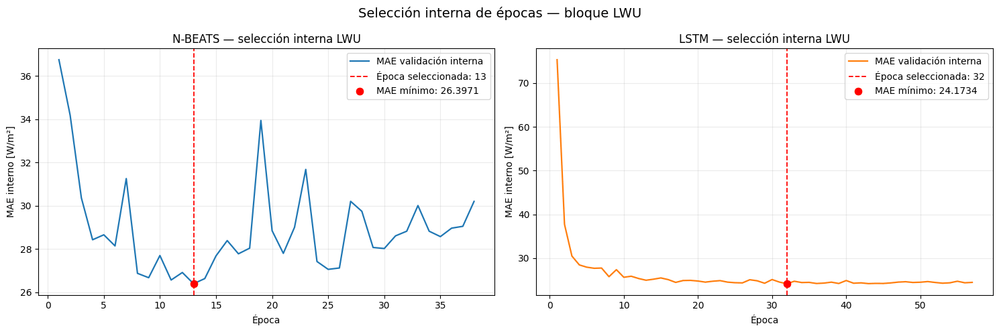


Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_bloque_lwu_20261006_164647/seleccion_interna

ÉPOCAS SELECCIONADAS
N-BEATS: 13
LSTM:    32

SELECCIÓN INTERNA LWU COMPLETADA CORRECTAMENTE


In [ ]:
from pathlib import Path
import copy
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 0. Configuración idéntica a los experimentos anteriores
SEED = 42
N_SUBTRAIN = 4428
N_VALIDACION_INTERNA = 721
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
CLIP_GRAD = 1.0
MAX_EPOCHS = 300
PATIENCE = 25
MIN_DELTA = 1e-5
DEVICE = torch.device("cpu")

def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)


# 1. Recuperar carpeta y matrices preparadas
if "OUT_PREPARACION_LWU" not in globals():
    carpetas = sorted(
        (BASE_DIR / "resultados" / "ejecuciones").glob("preparacion_bloque_lwu_*"),
        key=lambda p: p.stat().st_mtime,
        reverse=True,
    )
    if not carpetas:
        raise FileNotFoundError("No se encontró la preparación LWU.")

    OUT_PREPARACION_LWU = carpetas[0]

if "X_train_DIF_elev_LWU_raw" not in globals():
    archivo_matrices = OUT_PREPARACION_LWU / "matrices_DIF_elev_LWU.npz"
    datos_lwu = np.load(archivo_matrices, allow_pickle=False)
    X_train_DIF_elev_LWU_raw = datos_lwu["X_train_DIF_elev_LWU_raw"]
    y_train_lwu = datos_lwu["y_train_raw"]

X_train_lwu_subtrain = np.asarray(X_train_DIF_elev_LWU_raw, dtype=np.float32)
y_train_lwu_subtrain = np.asarray(y_train_lwu, dtype=np.float32).reshape(-1)
assert X_train_lwu_subtrain.shape == (5149, 24, 5)
assert y_train_lwu_subtrain.shape == (5149,)
assert np.isfinite(X_train_lwu_subtrain).all()
assert np.isfinite(y_train_lwu_subtrain).all()


# 2. División cronológica interna
X_subtrain = X_train_lwu_subtrain[:N_SUBTRAIN]
y_subtrain = y_train_lwu_subtrain[:N_SUBTRAIN]
X_validacion_interna = X_train_lwu_subtrain[N_SUBTRAIN:]
y_validacion_interna = y_train_lwu_subtrain[N_SUBTRAIN:]
assert X_subtrain.shape == (4428, 24, 5)
assert X_validacion_interna.shape == (721, 24, 5)
fecha_fin_subtrain = fechas_train_lwu[N_SUBTRAIN - 1]
fecha_inicio_validacion_interna = fechas_train_lwu[N_SUBTRAIN]
print("División interna:")
print(
    f"Subtrain: {len(X_subtrain)} muestras | " f"{fechas_train_lwu[0]} → " f"{fecha_fin_subtrain}"
)
print(
    f"Validación interna: "
    f"{len(X_validacion_interna)} muestras | "
    f"{fecha_inicio_validacion_interna} → "
    f"{fechas_train_lwu[-1]}"
)


# 3. Escalado ajustado solo con subtrain
X_MEDIA_INTERNA = X_subtrain.mean(axis=(0, 1)).astype(np.float32)
X_STD_INTERNA = X_subtrain.std(axis=(0, 1)).astype(np.float32)
X_STD_INTERNA[X_STD_INTERNA < 1e-8] = 1.0
Y_MEDIA_INTERNA = float(y_subtrain.mean())
Y_STD_INTERNA = float(y_subtrain.std())
if Y_STD_INTERNA < 1e-8:
    Y_STD_INTERNA = 1.0

def escalar_X(X):
    return ((X - X_MEDIA_INTERNA.reshape(1, 1, -1)) / X_STD_INTERNA.reshape(1, 1, -1)).astype(
        np.float32
    )

def escalar_y(y):
    return ((y - Y_MEDIA_INTERNA) / Y_STD_INTERNA).astype(np.float32)

X_subtrain_escalado = escalar_X(X_subtrain)
X_validacion_interna_escalado = escalar_X(X_validacion_interna)
y_subtrain_escalado = escalar_y(y_subtrain)
print("\nEscalado ajustado exclusivamente con subtrain:")
print("Media X:", X_MEDIA_INTERNA)
print("Std X:  ", X_STD_INTERNA)
print("Media y:", Y_MEDIA_INTERNA)
print("Std y:  ", Y_STD_INTERNA)


# 4. Arquitectura N-BEATS
class BloqueNBEATSLWU(nn.Module):
    def __init__(self, input_size=120, hidden_size=128, backcast_size=24):
        super().__init__()
        self.dense_network = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
        )
        self.backcast_head = nn.Linear(hidden_size, backcast_size)
        self.forecast_head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.dense_network(x)
        return (self.backcast_head(h), self.forecast_head(h))

class NBEATSLWU(nn.Module):
    def __init__(self, n_features=5, window=24, n_stacks=2, blocks_per_stack=3, hidden_size=128):
        super().__init__()
        self.window = window
        self.n_features = n_features
        self.blocks = nn.ModuleList(
            [
                BloqueNBEATSLWU(
                    input_size=(window * n_features), hidden_size=hidden_size, backcast_size=window
                )
                for _ in range(n_stacks * blocks_per_stack)
            ]
        )

    def forward(self, x):
        # Residuo únicamente sobre DIF.
        residual_dif = x[:, :, 0]

        # Covariables históricas constantes
        # durante los bloques.
        covariables = x[:, :, 1:].permute(0, 2, 1).reshape(x.shape[0], -1)
        forecast_total = torch.zeros((x.shape[0], 1), dtype=x.dtype, device=x.device)
        for bloque in self.blocks:
            entrada_bloque = torch.cat([residual_dif, covariables], dim=1)
            backcast, forecast = bloque(entrada_bloque)
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast

        return forecast_total.squeeze(-1)


# 5. Arquitectura LSTM
class LSTMLWU(nn.Module):
    def __init__(self, n_features=5, hidden_size=64, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=num_layers, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)

def crear_nbeats_lwu():
    return NBEATSLWU()

def crear_lstm_lwu():
    return LSTMLWU()

PARAMETROS_NBEATS_LWU = sum(p.numel() for p in crear_nbeats_lwu().parameters())
PARAMETROS_LSTM_LWU = sum(p.numel() for p in crear_lstm_lwu().parameters())
assert PARAMETROS_NBEATS_LWU == 310_422
assert PARAMETROS_LSTM_LWU == 20_289
print("\nParámetros:")
print("N-BEATS:", PARAMETROS_NBEATS_LWU)
print("LSTM:   ", PARAMETROS_LSTM_LWU)


# 6. Predicción auxiliar
@torch.no_grad()
def predecir_interno(modelo, X, batch_size=512):
    modelo.eval()
    loader = DataLoader(TensorDataset(torch.from_numpy(X)), batch_size=batch_size, shuffle=False)
    predicciones = []
    for (xb,) in loader:
        pred = modelo(xb.to(DEVICE))
        predicciones.append(pred.cpu().numpy())

    return np.concatenate(predicciones)


# 7. Selección con paciencia de 25 épocas
def seleccionar_epoca(nombre_modelo, constructor_modelo):
    fijar_semilla()
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader_subtrain = DataLoader(
        TensorDataset(torch.from_numpy(X_subtrain_escalado), torch.from_numpy(y_subtrain_escalado)),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generador,
        drop_last=False,
    )
    modelo = constructor_modelo().to(DEVICE)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)

    # Mismo loss que el entrenamiento SWD anterior.
    criterio = nn.L1Loss()
    mejor_mae = np.inf
    mejor_epoca = None
    mejor_estado = None
    epocas_sin_mejora = 0
    historial = []
    inicio = time.perf_counter()
    for epoca in range(1, MAX_EPOCHS + 1):
        modelo.train()
        perdidas_train = []
        for xb, yb in loader_subtrain:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            pred = modelo(xb)
            perdida = criterio(pred, yb)
            perdida.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), CLIP_GRAD)
            optimizador.step()
            perdidas_train.append(perdida.item())

        loss_train = float(np.mean(perdidas_train))
        pred_interna_escalada = predecir_interno(modelo, X_validacion_interna_escalado)
        pred_interna = pred_interna_escalada * Y_STD_INTERNA + Y_MEDIA_INTERNA
        mae_interno = float(np.mean(np.abs(y_validacion_interna - pred_interna)))
        mejora = mae_interno < mejor_mae - MIN_DELTA
        if mejora:
            mejor_mae = mae_interno
            mejor_epoca = epoca
            mejor_estado = copy.deepcopy(modelo.state_dict())
            epocas_sin_mejora = 0
        else:
            epocas_sin_mejora += 1

        historial.append(
            {
                "modelo": nombre_modelo,
                "epoca": epoca,
                "loss_subtrain_escalado": loss_train,
                "mae_validacion_interna": mae_interno,
                "mejor_mae_hasta_epoca": mejor_mae,
                "mejor_epoca_hasta_epoca": mejor_epoca,
                "epocas_sin_mejora": epocas_sin_mejora,
            }
        )
        if mejora:
            print(
                f"{nombre_modelo} | "
                f"época {epoca:3d} | "
                f"nuevo mínimo MAE: "
                f"{mae_interno:.6f}"
            )
        elif epoca % 10 == 0:
            print(
                f"{nombre_modelo} | "
                f"época {epoca:3d} | "
                f"MAE: {mae_interno:.6f} | "
                f"mínimo: {mejor_mae:.6f} "
                f"(época {mejor_epoca}) | "
                f"sin mejora: "
                f"{epocas_sin_mejora}/"
                f"{PATIENCE}"
            )

        if epocas_sin_mejora >= PATIENCE:
            print(
                f"\nPARADA TEMPRANA {nombre_modelo}: "
                f"han transcurrido {PATIENCE} "
                f"épocas sin mejorar el mínimo."
            )
            print(f"Última época ejecutada: {epoca}")
            print(f"Época seleccionada: " f"{mejor_epoca}")
            print(f"MAE interno mínimo: " f"{mejor_mae:.6f} W/m²\n")
            break

    else:
        print(f"\n{nombre_modelo} alcanzó " f"{MAX_EPOCHS} épocas.")
        print(f"Época seleccionada: " f"{mejor_epoca}")
        print(f"MAE interno mínimo: " f"{mejor_mae:.6f} W/m²\n")

    tiempo_total = time.perf_counter() - inicio
    modelo.load_state_dict(mejor_estado)
    return {
        "nombre": nombre_modelo,
        "modelo_mejor": modelo,
        "historial": pd.DataFrame(historial),
        "mejor_epoca": int(mejor_epoca),
        "mejor_mae": float(mejor_mae),
        "ultima_epoca": int(historial[-1]["epoca"]),
        "tiempo_s": float(tiempo_total),
    }


# 8. Ejecutar selección de N-BEATS y LSTM
print("\n" + "=" * 70)
print("SELECCIÓN INTERNA N-BEATS LWU")
print("=" * 70)
resultado_subtrain_nbeats_lwu = seleccionar_epoca("NBEATS_LWU", crear_nbeats_lwu)
print("\n" + "=" * 70)
print("SELECCIÓN INTERNA LSTM LWU")
print("=" * 70)
resultado_subtrain_lstm_lwu = seleccionar_epoca("LSTM_LWU", crear_lstm_lwu)


# Variables que utilizaremos en el reentrenamiento final
EPOCA_NBEATS_LWU = resultado_subtrain_nbeats_lwu["mejor_epoca"]
EPOCA_LSTM_LWU = resultado_subtrain_lstm_lwu["mejor_epoca"]


# 9. Resumen
resumen_seleccion_lwu = pd.DataFrame(
    [
        {
            "modelo": "NBEATS_DIF_Elev_LWU",
            "epoca_seleccionada": EPOCA_NBEATS_LWU,
            "mae_interno_minimo": resultado_subtrain_nbeats_lwu["mejor_mae"],
            "ultima_epoca_ejecutada": resultado_subtrain_nbeats_lwu["ultima_epoca"],
            "paciencia": PATIENCE,
            "parametros": PARAMETROS_NBEATS_LWU,
            "tiempo_s": resultado_subtrain_nbeats_lwu["tiempo_s"],
        },
        {
            "modelo": "LSTM_DIF_Elev_LWU",
            "epoca_seleccionada": EPOCA_LSTM_LWU,
            "mae_interno_minimo": resultado_subtrain_lstm_lwu["mejor_mae"],
            "ultima_epoca_ejecutada": resultado_subtrain_lstm_lwu["ultima_epoca"],
            "paciencia": PATIENCE,
            "parametros": PARAMETROS_LSTM_LWU,
            "tiempo_s": resultado_subtrain_lstm_lwu["tiempo_s"],
        },
    ]
)
print("\nRESUMEN DE SELECCIÓN INTERNA")
display(resumen_seleccion_lwu)


# 10. Gráficas por pantalla
hist_nbeats = resultado_subtrain_nbeats_lwu["historial"]
hist_lstm = resultado_subtrain_lstm_lwu["historial"]
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, historial, resultado, titulo, color in [
    (
        axes[0],
        hist_nbeats,
        resultado_subtrain_nbeats_lwu,
        "N-BEATS — selección interna LWU",
        "tab:blue",
    ),
    (axes[1], hist_lstm, resultado_subtrain_lstm_lwu, "LSTM — selección interna LWU", "tab:orange"),
]:
    ax.plot(
        historial["epoca"],
        historial["mae_validacion_interna"],
        color=color,
        linewidth=1.6,
        label="MAE validación interna",
    )
    ax.axvline(
        resultado["mejor_epoca"],
        color="red",
        linestyle="--",
        linewidth=1.3,
        label=("Época seleccionada: " f"{resultado['mejor_epoca']}"),
    )
    ax.scatter(
        resultado["mejor_epoca"],
        resultado["mejor_mae"],
        color="red",
        s=55,
        zorder=5,
        label=(f"MAE mínimo: " f"{resultado['mejor_mae']:.4f}"),
    )
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.set_ylabel("MAE interno [W/m²]")
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle("Selección interna de épocas — bloque LWU", fontsize=14)
fig.tight_layout()
CARPETA_SELECCION_LWU = OUT_PREPARACION_LWU / "seleccion_interna"
CARPETA_SELECCION_LWU.mkdir(parents=True, exist_ok=True)
ruta_figura = CARPETA_SELECCION_LWU / "curvas_mae_seleccion_interna_lwu.png"
fig.savefig(ruta_figura, dpi=180, bbox_inches="tight")
plt.show()


# 11. Guardar resultados de la selección
hist_nbeats.to_csv(CARPETA_SELECCION_LWU / "historial_nbeats_lwu.csv", index=False)
hist_lstm.to_csv(CARPETA_SELECCION_LWU / "historial_lstm_lwu.csv", index=False)
resumen_seleccion_lwu.to_csv(
    CARPETA_SELECCION_LWU / "resumen_seleccion_lwu.csv", index=False, encoding="utf-8-sig"
)
torch.save(
    {
        "state_dict": resultado_subtrain_nbeats_lwu["modelo_mejor"].state_dict(),
        "epoca_seleccionada": EPOCA_NBEATS_LWU,
        "mae_interno_minimo": resultado_subtrain_nbeats_lwu["mejor_mae"],
        "x_mean": X_MEDIA_INTERNA,
        "x_std": X_STD_INTERNA,
        "y_mean": Y_MEDIA_INTERNA,
        "y_std": Y_STD_INTERNA,
    },
    CARPETA_SELECCION_LWU / "mejor_nbeats_lwu_subtrain.pt",
)
torch.save(
    {
        "state_dict": resultado_subtrain_lstm_lwu["modelo_mejor"].state_dict(),
        "epoca_seleccionada": EPOCA_LSTM_LWU,
        "mae_interno_minimo": resultado_subtrain_lstm_lwu["mejor_mae"],
        "x_mean": X_MEDIA_INTERNA,
        "x_std": X_STD_INTERNA,
        "y_mean": Y_MEDIA_INTERNA,
        "y_std": Y_STD_INTERNA,
    },
    CARPETA_SELECCION_LWU / "mejor_lstm_lwu_subtrain.pt",
)
configuracion_seleccion = {
    "criterio_seleccion": "MAE total de validación interna",
    "loss_entrenamiento": "L1Loss",
    "subtrain": 4428,
    "validacion_interna": 721,
    "paciencia": 25,
    "max_epocas": 300,
    "min_delta": 1e-5,
    "seed": 42,
    "validation_externa_utilizada": False,
    "test_utilizado": False,
    "epoca_nbeats": EPOCA_NBEATS_LWU,
    "epoca_lstm": EPOCA_LSTM_LWU,
}
with open(
    CARPETA_SELECCION_LWU / "configuracion_seleccion_lwu.json", "w", encoding="utf-8"
) as archivo:
    json.dump(configuracion_seleccion, archivo, ensure_ascii=False, indent=2)

print("\nResultados guardados en:")
print(CARPETA_SELECCION_LWU)
print("\nÉPOCAS SELECCIONADAS")
print(f"N-BEATS: {EPOCA_NBEATS_LWU}")
print(f"LSTM:    {EPOCA_LSTM_LWU}")
print("\nSELECCIÓN INTERNA LWU COMPLETADA CORRECTAMENTE")

**Resultados.** N-BEATS alcanza su mínimo en la época 13 (MAE interno de 26,40 W/m²) y la LSTM en la época 32 (24,17 W/m²), con 310.422 y 20.289 parámetros, respectivamente.

### 6.31 Reentrenamiento y evaluación externa del bloque LWU

Ambos modelos se reentrenan desde cero con todo el entrenamiento durante las épocas seleccionadas (13 para N-BEATS y 32 para la LSTM), con escaladores ajustados solo con el entrenamiento, y se evalúan una única vez en validación.

Escaladores ajustados con train completo:
Media X: [8.0136559e+01 4.6184330e+00 3.7124435e+02 1.1478143e+01 3.3328110e-01]
Std X:   [111.865265   29.91618    36.924908   11.162361    0.4277066]
Media y: 80.29508209228516
Std y:   112.17021179199219

REENTRENAMIENTO N-BEATS LWU — 13 ÉPOCAS
NBEATS_DIF_Elev_LWU | época   1/13 | L1 train escalado: 0.270045
NBEATS_DIF_Elev_LWU | época   5/13 | L1 train escalado: 0.165017
NBEATS_DIF_Elev_LWU | época  10/13 | L1 train escalado: 0.140989
NBEATS_DIF_Elev_LWU | época  13/13 | L1 train escalado: 0.132647

REENTRENAMIENTO LSTM LWU — 32 ÉPOCAS
LSTM_DIF_Elev_LWU | época   1/32 | L1 train escalado: 0.675837
LSTM_DIF_Elev_LWU | época   5/32 | L1 train escalado: 0.183927
LSTM_DIF_Elev_LWU | época  10/32 | L1 train escalado: 0.157987
LSTM_DIF_Elev_LWU | época  15/32 | L1 train escalado: 0.158406
LSTM_DIF_Elev_LWU | época  20/32 | L1 train escalado: 0.155154
LSTM_DIF_Elev_LWU | época  25/32 | L1 train escalado: 0.152106
LSTM_DIF_Elev_LWU | época  30/32 |

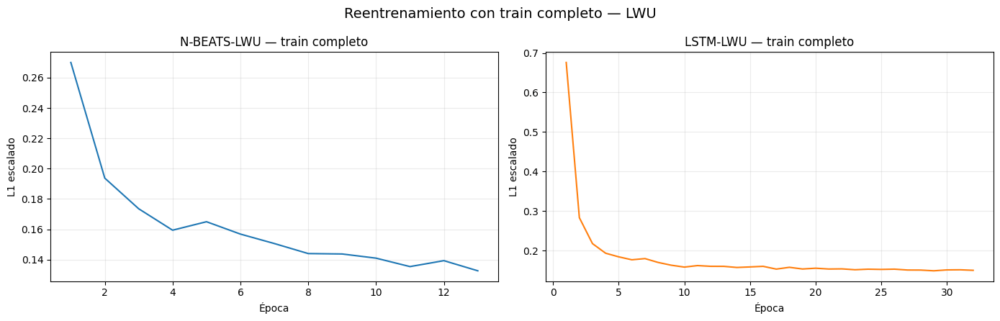


RESULTADOS EXTERNOS EN VALIDATION


,modelo,epocas,parametros,MAE,nMAE_pct,RMSE,R2,bias,tiempo_entrenamiento_s
0,LSTM_DIF_Elev_LWU,32,20289,16.84096,19.758667,33.422958,0.904436,-0.592998,46.328503
1,NBEATS_DIF_Elev_LWU,13,310422,20.19537,23.694231,37.929848,0.876926,-5.227646,18.752416



Media de DIF en validation usada para nMAE: 85.2332763671875

Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_lwu_mae_total_20261006_165727

REENTRENAMIENTO Y VALIDACIÓN LWU COMPLETADOS CORRECTAMENTE


In [ ]:
from pathlib import Path
from datetime import datetime
import json
import random
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# 0. Comprobaciones
assert EPOCA_NBEATS_LWU == 13
assert EPOCA_LSTM_LWU == 32
assert X_train_DIF_elev_LWU_raw.shape == (5149, 24, 5)
assert X_validation_DIF_elev_LWU_raw.shape == (1464, 24, 5)
assert y_train_lwu.shape == (5149,)
assert y_validation_lwu.shape == (1464,)
assert len(fechas_validation_lwu) == 1464
DEVICE = torch.device("cpu")

def fijar_semilla_final(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)


# 1. Ajustar escaladores con todo train
X_MEDIA_COMPLETO = X_train_DIF_elev_LWU_raw.mean(axis=(0, 1)).astype(np.float32)
X_STD_COMPLETO = X_train_DIF_elev_LWU_raw.std(axis=(0, 1)).astype(np.float32)
X_STD_COMPLETO[X_STD_COMPLETO < 1e-8] = 1.0
Y_MEDIA_COMPLETO = float(y_train_lwu.mean())
Y_STD_COMPLETO = float(y_train_lwu.std())
if Y_STD_COMPLETO < 1e-8:
    Y_STD_COMPLETO = 1.0

def escalar_X_completo(X):
    return ((X - X_MEDIA_COMPLETO.reshape(1, 1, -1)) / X_STD_COMPLETO.reshape(1, 1, -1)).astype(
        np.float32
    )

def escalar_y_completo(y):
    return ((y - Y_MEDIA_COMPLETO) / Y_STD_COMPLETO).astype(np.float32)

X_train_lwu_escalado = escalar_X_completo(X_train_DIF_elev_LWU_raw)
X_validation_lwu_escalado = escalar_X_completo(X_validation_DIF_elev_LWU_raw)
y_train_lwu_escalado = escalar_y_completo(y_train_lwu)
print("Escaladores ajustados con train completo:")
print("Media X:", X_MEDIA_COMPLETO)
print("Std X:  ", X_STD_COMPLETO)
print("Media y:", Y_MEDIA_COMPLETO)
print("Std y:  ", Y_STD_COMPLETO)


# 2. Entrenamiento durante un número fijo de épocas
def reentrenar_modelo_completo(nombre_modelo, constructor_modelo, numero_epocas):
    fijar_semilla_final(SEED)
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader = DataLoader(
        TensorDataset(
            torch.from_numpy(X_train_lwu_escalado), torch.from_numpy(y_train_lwu_escalado)
        ),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generador,
        drop_last=False,
    )

    # Reinicio completo del modelo.
    modelo = constructor_modelo().to(DEVICE)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterio = nn.L1Loss()
    historial = []
    inicio = time.perf_counter()
    for epoca in range(1, numero_epocas + 1):
        modelo.train()
        perdidas = []
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            pred = modelo(xb)
            perdida = criterio(pred, yb)
            perdida.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), CLIP_GRAD)
            optimizador.step()
            perdidas.append(perdida.item())

        loss_epoca = float(np.mean(perdidas))
        historial.append(
            {"modelo": nombre_modelo, "epoca": epoca, "loss_train_escalado": loss_epoca}
        )
        if epoca == 1 or epoca % 5 == 0 or epoca == numero_epocas:
            print(
                f"{nombre_modelo} | "
                f"época {epoca:3d}/"
                f"{numero_epocas} | "
                f"L1 train escalado: "
                f"{loss_epoca:.6f}"
            )

    tiempo = time.perf_counter() - inicio
    return {"modelo": modelo, "historial": pd.DataFrame(historial), "tiempo_s": float(tiempo)}

print("\n" + "=" * 70)
print("REENTRENAMIENTO N-BEATS LWU — 13 ÉPOCAS")
print("=" * 70)
resultado_final_nbeats_lwu = reentrenar_modelo_completo(
    "NBEATS_DIF_Elev_LWU", crear_nbeats_lwu, EPOCA_NBEATS_LWU
)
print("\n" + "=" * 70)
print("REENTRENAMIENTO LSTM LWU — 32 ÉPOCAS")
print("=" * 70)
resultado_final_lstm_lwu = reentrenar_modelo_completo(
    "LSTM_DIF_Elev_LWU", crear_lstm_lwu, EPOCA_LSTM_LWU
)


# 3. Curvas del reentrenamiento
historial_final_nbeats_lwu = resultado_final_nbeats_lwu["historial"]
historial_final_lstm_lwu = resultado_final_lstm_lwu["historial"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(
    historial_final_nbeats_lwu["epoca"],
    historial_final_nbeats_lwu["loss_train_escalado"],
    color="tab:blue",
)
axes[0].set_title("N-BEATS-LWU — train completo")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("L1 escalado")
axes[0].grid(alpha=0.25)
axes[1].plot(
    historial_final_lstm_lwu["epoca"],
    historial_final_lstm_lwu["loss_train_escalado"],
    color="tab:orange",
)
axes[1].set_title("LSTM-LWU — train completo")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("L1 escalado")
axes[1].grid(alpha=0.25)
fig.suptitle("Reentrenamiento con train completo — LWU", fontsize=14)
fig.tight_layout()
plt.show()


# 4. Predicción externa sobre validation
@torch.no_grad()
def predecir_validation(modelo, X_escalado):
    modelo.eval()
    loader = DataLoader(TensorDataset(torch.from_numpy(X_escalado)), batch_size=512, shuffle=False)
    predicciones = []
    for (xb,) in loader:
        pred = modelo(xb.to(DEVICE))
        predicciones.append(pred.cpu().numpy())

    predicciones = np.concatenate(predicciones)
    return (predicciones * Y_STD_COMPLETO + Y_MEDIA_COMPLETO).astype(np.float32)

pred_nbeats_lwu_validation = predecir_validation(
    resultado_final_nbeats_lwu["modelo"], X_validation_lwu_escalado
)
pred_lstm_lwu_validation = predecir_validation(
    resultado_final_lstm_lwu["modelo"], X_validation_lwu_escalado
)
assert pred_nbeats_lwu_validation.shape == (1464,)
assert pred_lstm_lwu_validation.shape == (1464,)
assert np.isfinite(pred_nbeats_lwu_validation).all()
assert np.isfinite(pred_lstm_lwu_validation).all()


# 5. Métricas externas
def calcular_metricas_externas(y_real, y_pred):
    error = y_real - y_pred
    mae = float(np.mean(np.abs(error)))
    rmse = float(np.sqrt(np.mean(error**2)))
    media_objetivo = float(np.mean(y_real))
    nmae = float(100 * mae / media_objetivo)
    r2 = float(1 - np.sum(error**2) / np.sum((y_real - media_objetivo) ** 2))
    bias = float(np.mean(y_pred - y_real))
    return {"MAE": mae, "nMAE_pct": nmae, "RMSE": rmse, "R2": r2, "bias": bias}

metricas_nbeats_lwu = calcular_metricas_externas(y_validation_lwu, pred_nbeats_lwu_validation)
metricas_lstm_lwu = calcular_metricas_externas(y_validation_lwu, pred_lstm_lwu_validation)
tabla_metricas_lwu = (
    pd.DataFrame(
        [
            {
                "modelo": "NBEATS_DIF_Elev_LWU",
                "epocas": EPOCA_NBEATS_LWU,
                "parametros": PARAMETROS_NBEATS_LWU,
                **metricas_nbeats_lwu,
                "tiempo_entrenamiento_s": resultado_final_nbeats_lwu["tiempo_s"],
            },
            {
                "modelo": "LSTM_DIF_Elev_LWU",
                "epocas": EPOCA_LSTM_LWU,
                "parametros": PARAMETROS_LSTM_LWU,
                **metricas_lstm_lwu,
                "tiempo_entrenamiento_s": resultado_final_lstm_lwu["tiempo_s"],
            },
        ]
    )
    .sort_values("MAE")
    .reset_index(drop=True)
)
print("\nRESULTADOS EXTERNOS EN VALIDATION")
display(tabla_metricas_lwu)
print("\nMedia de DIF en validation usada para nMAE:", float(y_validation_lwu.mean()))


# 6. Guardar resultados
RUN_FINAL_LWU = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_FINAL_LWU = (
    BASE_DIR / "resultados" / "ejecuciones" / f"reentrenamiento_lwu_mae_total_" f"{RUN_FINAL_LWU}"
)
for subcarpeta in ["modelos", "metricas", "predicciones", "tablas", "figuras", "datos"]:
    (OUT_FINAL_LWU / subcarpeta).mkdir(parents=True, exist_ok=True)


# Historiales
historial_final_nbeats_lwu.to_csv(
    OUT_FINAL_LWU / "tablas" / "historial_nbeats_lwu.csv", index=False
)
historial_final_lstm_lwu.to_csv(OUT_FINAL_LWU / "tablas" / "historial_lstm_lwu.csv", index=False)
tabla_metricas_lwu.to_csv(
    OUT_FINAL_LWU / "metricas" / "metricas_validation_lwu.csv", index=False, encoding="utf-8-sig"
)


# Predicciones
tabla_predicciones_lwu = pd.DataFrame(
    {
        "instante_objetivo": fechas_validation_lwu,
        "valor_real_DIF": y_validation_lwu,
        "prediccion_NBEATS_DIF_Elev_LWU": pred_nbeats_lwu_validation,
        "prediccion_LSTM_DIF_Elev_LWU": pred_lstm_lwu_validation,
    }
)
tabla_predicciones_lwu.to_csv(
    OUT_FINAL_LWU / "predicciones" / "predicciones_validation_lwu.csv",
    index=False,
    encoding="utf-8-sig",
)
np.savez_compressed(
    OUT_FINAL_LWU / "predicciones" / "predicciones_validation_lwu.npz",
    fechas_validation=(fechas_validation_lwu.to_numpy(dtype="datetime64[ns]")),
    y_real=y_validation_lwu,
    pred_nbeats=(pred_nbeats_lwu_validation),
    pred_lstm=(pred_lstm_lwu_validation),
)


# Modelos y escaladores
datos_comunes_modelo = {
    "x_mean": X_MEDIA_COMPLETO,
    "x_std": X_STD_COMPLETO,
    "y_mean": Y_MEDIA_COMPLETO,
    "y_std": Y_STD_COMPLETO,
    "canales": ["DIF", "elevacion", "LWU_media", "LWU_rango", "LWU_std"],
}
torch.save(
    {
        "model_name": "NBEATS_DIF_ELEV_LWU",
        "state_dict": resultado_final_nbeats_lwu["modelo"].state_dict(),
        "epochs": EPOCA_NBEATS_LWU,
        **datos_comunes_modelo,
    },
    OUT_FINAL_LWU / "modelos" / "NBEATS_DIF_ELEV_LWU.pt",
)
torch.save(
    {
        "model_name": "LSTM_DIF_ELEV_LWU",
        "state_dict": resultado_final_lstm_lwu["modelo"].state_dict(),
        "epochs": EPOCA_LSTM_LWU,
        **datos_comunes_modelo,
    },
    OUT_FINAL_LWU / "modelos" / "LSTM_DIF_ELEV_LWU.pt",
)
with open(OUT_FINAL_LWU / "scalers.json", "w", encoding="utf-8") as archivo:
    json.dump(
        {
            "feature_order": datos_comunes_modelo["canales"],
            "x_mean": X_MEDIA_COMPLETO.tolist(),
            "x_std": X_STD_COMPLETO.tolist(),
            "y_mean": Y_MEDIA_COMPLETO,
            "y_std": Y_STD_COMPLETO,
            "fit_partition": "train_completo",
        },
        archivo,
        ensure_ascii=False,
        indent=2,
    )


# Matrices necesarias para reproducir LWU
np.savez_compressed(
    OUT_FINAL_LWU / "datos" / "matrices_lwu_modelado.npz",
    X_train_DIF_elev_LWU_raw=(X_train_DIF_elev_LWU_raw),
    X_validation_DIF_elev_LWU_raw=(X_validation_DIF_elev_LWU_raw),
    y_train_raw=y_train_lwu,
    y_validation_raw=y_validation_lwu,
    fechas_train=(fechas_train_lwu.to_numpy(dtype="datetime64[ns]")),
    fechas_validation=(fechas_validation_lwu.to_numpy(dtype="datetime64[ns]")),
)


# Configuración
configuracion_final_lwu = {
    "purpose": "Reentrenamiento final de DIF+elevacion+LWU",
    "selection_criterion": "MAE total de validación interna",
    "retraining_partition": "train completo",
    "external_evaluation_partition": "validation",
    "test_used": False,
    "seed": SEED,
    "device": str(DEVICE),
    "batch_size": BATCH_SIZE,
    "optimizer": "Adam",
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "L1Loss",
    "gradient_clip": CLIP_GRAD,
    "selected_epochs": {
        "NBEATS_DIF_ELEV_LWU": EPOCA_NBEATS_LWU,
        "LSTM_DIF_ELEV_LWU": EPOCA_LSTM_LWU,
    },
    "train_shape": list(X_train_DIF_elev_LWU_raw.shape),
    "validation_shape": list(X_validation_DIF_elev_LWU_raw.shape),
}
with open(OUT_FINAL_LWU / "configuracion.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion_final_lwu, archivo, ensure_ascii=False, indent=2)


# Figura del reentrenamiento
fig.savefig(
    OUT_FINAL_LWU / "figuras" / "curvas_reentrenamiento_lwu.png", dpi=180, bbox_inches="tight"
)
print("\nResultados guardados en:")
print(OUT_FINAL_LWU)
print("\nREENTRENAMIENTO Y VALIDACIÓN LWU COMPLETADOS CORRECTAMENTE")

**Resultados.** `LSTM_DIF_Elev_LWU` obtiene un MAE de 16,84 W/m² (RMSE 33,42 W/m²; R² 0,90; sesgo −0,59 W/m²), frente a 20,20 W/m² de `NBEATS_DIF_Elev_LWU` (RMSE 37,93 W/m²; R² 0,88; sesgo −5,23 W/m²).

### 6.32 LWU por régimen solar y comparación global

Se desglosan las métricas de validación de los dos modelos LWU en global, operación (884 horas), completamente diurno, transición y noche, se cuantifica la parte del error absoluto que aporta la noche y se actualiza la clasificación global de modelos por MAE.

Distribución de validation:
Global:                  1464
Operación:               884
  Completamente diurna:  765
  Transición:            119
Noche:                   580

MÉTRICAS POR ÁMBITO


,ambito,modelo,n_muestras,media_DIF,MAE,nMAE_ref_global_pct,nMAE_ambito_pct,RMSE,R2,bias
0,Global,LSTM_DIF_Elev_LWU,1464,85.2333,16.8410,19.7587,19.7587,33.4230,0.9044,-0.5930
1,Global,NBEATS_DIF_Elev_LWU,1464,85.2333,20.1954,23.6942,23.6942,37.9299,0.8769,-5.2276
2,Operación,LSTM_DIF_Elev_LWU,884,141.7976,27.3957,32.1420,19.3203,43.0043,0.8361,-0.8885
3,Operación,NBEATS_DIF_Elev_LWU,884,141.7976,32.7147,38.3826,23.0714,48.7920,0.7890,-8.9949
4,Completamente diurna,LSTM_DIF_Elev_LWU,765,162.7231,30.7613,36.0907,18.9041,46.1319,0.7823,-1.7935
5,Completamente diurna,NBEATS_DIF_Elev_LWU,765,162.7231,36.2907,42.5781,22.3021,52.2416,0.7209,-11.8422
6,Transición,LSTM_DIF_Elev_LWU,119,7.2764,5.7595,6.7573,79.1522,7.5625,-0.1377,4.9295
7,Transición,NBEATS_DIF_Elev_LWU,119,7.2764,9.7264,11.4115,133.6699,11.8378,-1.7876,9.3097
8,Noche,LSTM_DIF_Elev_LWU,580,-0.9785,0.7541,0.8848,nan,1.0045,-9.0260,-0.1426
9,Noche,NBEATS_DIF_Elev_LWU,580,-0.9785,1.1141,1.3072,nan,1.7197,-28.3873,0.5141



IMPACTO DE LA NOCHE EN EL ERROR GLOBAL


,modelo,MAE_global,MAE_operacion,MAE_noche,diferencia_global_menos_operacion,pct_error_absoluto_operacion,pct_error_absoluto_noche,aporte_operacion_al_MAE_global,aporte_noche_al_MAE_global
0,NBEATS_DIF_Elev_LWU,20.1954,32.7147,1.1141,-12.5194,97.81%,2.19%,19.7540,0.4414
1,LSTM_DIF_Elev_LWU,16.8410,27.3957,0.7541,-10.5547,98.23%,1.77%,16.5422,0.2988


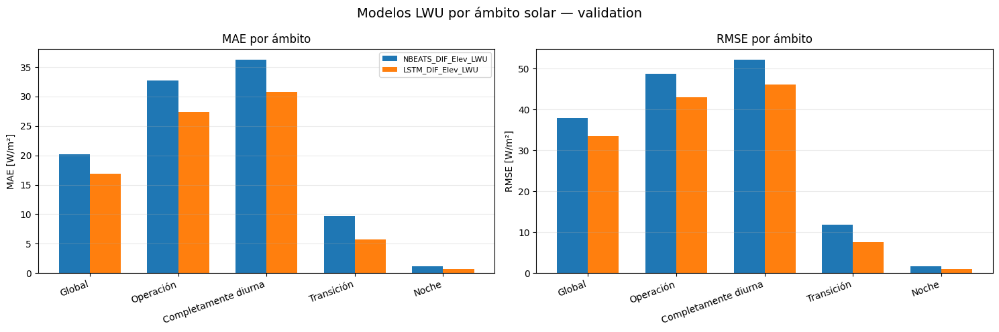


Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_lwu_mae_total_20261006_165727

ANÁLISIS DE OPERACIÓN Y NOCHE COMPLETADO CORRECTAMENTE


In [ ]:
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# 1. Preparar tabla de predicciones
def normalizar_regimen(texto):
    texto = unicodedata.normalize("NFKD", str(texto))
    texto = "".join(c for c in texto if not unicodedata.combining(c))
    return re.sub(r"[^a-z0-9]+", "_", texto.lower()).strip("_")

regimen_original = (
    validation_hgb["regimen_solar_objetivo"]
    .astype(str)
    .map(normalizar_regimen)
    .reset_index(drop=True)
)
datos_ambitos_lwu = pd.DataFrame(
    {
        "instante_objetivo": fechas_validation_lwu,
        "regimen_original": regimen_original,
        "valor_real_DIF": y_validation_lwu,
        "pred_NBEATS_LWU": pred_nbeats_lwu_validation,
        "pred_LSTM_LWU": pred_lstm_lwu_validation,
    }
)
mascara_diurna = datos_ambitos_lwu["regimen_original"].str.contains(
    "completamente_diurna", na=False
)
mascara_transicion = datos_ambitos_lwu["regimen_original"].str.contains("trans", na=False)
mascara_noche = datos_ambitos_lwu["regimen_original"].str.contains("noche", na=False)

# Operación incluye completamente diurna y transición.
mascara_operacion = mascara_diurna | mascara_transicion

# Todas las muestras deben pertenecer a uno de
# los tres regímenes elementales.
assert (mascara_diurna | mascara_transicion | mascara_noche).all()
assert not (mascara_operacion & mascara_noche).any()
assert int(mascara_diurna.sum()) == 765
assert int(mascara_transicion.sum()) == 119
assert int(mascara_noche.sum()) == 580
assert int(mascara_operacion.sum()) == 884
print("Distribución de validation:")
print("Global:                 ", len(datos_ambitos_lwu))
print("Operación:              ", int(mascara_operacion.sum()))
print("  Completamente diurna: ", int(mascara_diurna.sum()))
print("  Transición:           ", int(mascara_transicion.sum()))
print("Noche:                  ", int(mascara_noche.sum()))


# 2. Definir ámbitos de evaluación
ambitos = {
    "Global": np.ones(len(datos_ambitos_lwu), dtype=bool),
    "Operación": mascara_operacion.to_numpy(),
    "Completamente diurna": mascara_diurna.to_numpy(),
    "Transición": mascara_transicion.to_numpy(),
    "Noche": mascara_noche.to_numpy(),
}
modelos = {"NBEATS_DIF_Elev_LWU": "pred_NBEATS_LWU", "LSTM_DIF_Elev_LWU": "pred_LSTM_LWU"}
MEDIA_GLOBAL_VALIDATION = float(y_validation_lwu.mean())


# 3. Métricas
def calcular_metricas_ambito(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    error = y_real - y_pred
    error_absoluto = np.abs(error)
    mae = float(error_absoluto.mean())
    rmse = float(np.sqrt(np.mean(error**2)))
    bias = float(np.mean(y_pred - y_real))
    media_target = float(y_real.mean())
    suma_cuadrados_total = float(np.sum((y_real - media_target) ** 2))
    r2 = float(1 - np.sum(error**2) / suma_cuadrados_total) if suma_cuadrados_total > 0 else np.nan

    # Normalización con referencia común.
    nmae_ref_global = float(100 * mae / MEDIA_GLOBAL_VALIDATION)

    # Normalización propia del ámbito.
    # No se interpreta en noche si la media
    # es próxima a cero.
    nmae_ambito = float(100 * mae / media_target) if media_target > 1.0 else np.nan
    return {
        "n_muestras": len(y_real),
        "media_DIF": media_target,
        "MAE": mae,
        "nMAE_ref_global_pct": nmae_ref_global,
        "nMAE_ambito_pct": nmae_ambito,
        "RMSE": rmse,
        "R2": r2,
        "bias": bias,
        "suma_error_absoluto": float(error_absoluto.sum()),
    }

filas = []
for ambito, mascara in ambitos.items():
    parte = datos_ambitos_lwu.loc[mascara]
    for modelo, columna_pred in modelos.items():
        metricas = calcular_metricas_ambito(parte["valor_real_DIF"], parte[columna_pred])
        filas.append({"ambito": ambito, "modelo": modelo, **metricas})

metricas_ambitos_lwu = pd.DataFrame(filas)
orden_ambitos = list(ambitos.keys())
metricas_ambitos_lwu["ambito"] = pd.Categorical(
    metricas_ambitos_lwu["ambito"], categories=orden_ambitos, ordered=True
)
metricas_ambitos_lwu = metricas_ambitos_lwu.sort_values(["ambito", "modelo"]).reset_index(drop=True)
print("\nMÉTRICAS POR ÁMBITO")
display(
    metricas_ambitos_lwu[
        [
            "ambito",
            "modelo",
            "n_muestras",
            "media_DIF",
            "MAE",
            "nMAE_ref_global_pct",
            "nMAE_ambito_pct",
            "RMSE",
            "R2",
            "bias",
        ]
    ].style.format(
        {
            "media_DIF": "{:.4f}",
            "MAE": "{:.4f}",
            "nMAE_ref_global_pct": "{:.4f}",
            "nMAE_ambito_pct": "{:.4f}",
            "RMSE": "{:.4f}",
            "R2": "{:.4f}",
            "bias": "{:.4f}",
        }
    )
)


# 4. Cuantificar el efecto de la noche
filas_impacto = []
for modelo in modelos:
    tabla_modelo = metricas_ambitos_lwu.loc[metricas_ambitos_lwu["modelo"] == modelo].set_index(
        "ambito"
    )
    error_global = float(tabla_modelo.loc["Global", "suma_error_absoluto"])
    error_operacion = float(tabla_modelo.loc["Operación", "suma_error_absoluto"])
    error_noche = float(tabla_modelo.loc["Noche", "suma_error_absoluto"])
    filas_impacto.append(
        {
            "modelo": modelo,
            "MAE_global": tabla_modelo.loc["Global", "MAE"],
            "MAE_operacion": tabla_modelo.loc["Operación", "MAE"],
            "MAE_noche": tabla_modelo.loc["Noche", "MAE"],
            "diferencia_global_menos_operacion": (
                tabla_modelo.loc["Global", "MAE"] - tabla_modelo.loc["Operación", "MAE"]
            ),
            "pct_error_absoluto_operacion": 100 * error_operacion / error_global,
            "pct_error_absoluto_noche": 100 * error_noche / error_global,
            "aporte_operacion_al_MAE_global": error_operacion / len(datos_ambitos_lwu),
            "aporte_noche_al_MAE_global": error_noche / len(datos_ambitos_lwu),
        }
    )

impacto_noche_lwu = pd.DataFrame(filas_impacto)
print("\nIMPACTO DE LA NOCHE EN EL ERROR GLOBAL")
display(
    impacto_noche_lwu.style.format(
        {
            "MAE_global": "{:.4f}",
            "MAE_operacion": "{:.4f}",
            "MAE_noche": "{:.4f}",
            "diferencia_global_menos_operacion": "{:.4f}",
            "pct_error_absoluto_operacion": "{:.2f}%",
            "pct_error_absoluto_noche": "{:.2f}%",
            "aporte_operacion_al_MAE_global": "{:.4f}",
            "aporte_noche_al_MAE_global": "{:.4f}",
        }
    )
)

# Comprobación de la descomposición exacta.
for _, fila in impacto_noche_lwu.iterrows():
    assert np.isclose(
        fila["MAE_global"],
        (fila["aporte_operacion_al_MAE_global"] + fila["aporte_noche_al_MAE_global"]),
        atol=1e-8,
    )


# 5. Gráficas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(orden_ambitos))
ancho = 0.35
for desplazamiento, (modelo, _) in zip([-ancho / 2, ancho / 2], modelos.items()):
    tabla_modelo = (
        metricas_ambitos_lwu.loc[metricas_ambitos_lwu["modelo"] == modelo]
        .set_index("ambito")
        .reindex(orden_ambitos)
    )
    axes[0].bar(x + desplazamiento, tabla_modelo["MAE"], width=ancho, label=modelo)
    axes[1].bar(x + desplazamiento, tabla_modelo["RMSE"], width=ancho, label=modelo)

axes[0].set_title("MAE por ámbito")
axes[0].set_ylabel("MAE [W/m²]")
axes[1].set_title("RMSE por ámbito")
axes[1].set_ylabel("RMSE [W/m²]")
for ax in axes:
    ax.set_xticks(x, orden_ambitos, rotation=20, ha="right")
    ax.grid(axis="y", alpha=0.25)

axes[0].legend(fontsize=8)
fig.suptitle("Modelos LWU por ámbito solar — validation", fontsize=14)
fig.tight_layout()


# 6. Guardar
metricas_ambitos_lwu.to_csv(
    OUT_FINAL_LWU / "metricas" / "metricas_ambitos_validation_lwu.csv",
    index=False,
    encoding="utf-8-sig",
)
impacto_noche_lwu.to_csv(
    OUT_FINAL_LWU / "metricas" / "impacto_noche_validation_lwu.csv",
    index=False,
    encoding="utf-8-sig",
)
datos_ambitos_lwu.to_csv(
    OUT_FINAL_LWU / "predicciones" / "predicciones_ambitos_validation_lwu.csv",
    index=False,
    encoding="utf-8-sig",
)
fig.savefig(OUT_FINAL_LWU / "figuras" / "comparacion_ambitos_lwu.png", dpi=180, bbox_inches="tight")
plt.show()
print("\nResultados guardados en:")
print(OUT_FINAL_LWU)
print("\nANÁLISIS DE OPERACIÓN Y NOCHE COMPLETADO CORRECTAMENTE")

In [ ]:
from pathlib import Path
import json

CARPETA_DOCUMENTACION_LWU = OUT_FINAL_LWU / "documentacion"
CARPETA_DOCUMENTACION_LWU.mkdir(parents=True, exist_ok=True)
texto_conclusion = """# Conclusión sobre LWU por ámbito solar

## Resultado principal

La evaluación externa muestra que las métricas globales de los modelos LWU
están fuertemente favorecidas por la inclusión de las horas nocturnas.

### LSTM-LWU

- MAE global: 16.8410 W/m².
- MAE en operación: 27.3957 W/m².
- MAE nocturno: 0.7541 W/m².
- RMSE global: 33.4230 W/m².
- RMSE en operación: 43.0043 W/m².
- RMSE nocturno: 1.0045 W/m².
- La noche aporta únicamente el 1.77 % del error absoluto global.
- La operación aporta el 98.23 %.

### N-BEATS-LWU

- MAE global: 20.1954 W/m².
- MAE en operación: 32.7147 W/m².
- MAE nocturno: 1.1141 W/m².
- RMSE global: 37.9299 W/m².
- RMSE en operación: 48.7920 W/m².
- RMSE nocturno: 1.7197 W/m².
- La noche aporta únicamente el 2.19 % del error absoluto global.
- La operación aporta el 97.81 %.

## Lectura por régimen

El mayor error se concentra en las horas completamente diurnas:

- LSTM-LWU: MAE de 30.7613 W/m².
- N-BEATS-LWU: MAE de 36.2907 W/m².

En transición los errores son menores:

- LSTM-LWU: MAE de 5.7595 W/m².
- N-BEATS-LWU: MAE de 9.7264 W/m².

La noche presenta errores absolutos muy reducidos y un sesgo próximo a cero,
especialmente en LSTM. El R² nocturno no debe utilizarse para valorar estos
modelos, ya que la variabilidad del target durante la noche es extremadamente
pequeña y su media es próxima a cero.

## Conclusión metodológica

La mejora aparente de las métricas globales de LWU se explica en gran medida
por la facilidad de las horas nocturnas. Cuando se excluye la noche y se evalúa
únicamente el periodo de operación, los errores aumentan notablemente.

Por tanto, las métricas globales no son suficientes para valorar la capacidad
predictiva útil de los modelos. En la comparación final deberá darse prioridad
al rendimiento durante operación y, dentro de ella, al régimen completamente
diurno.

Estos resultados todavía no demuestran que LWU aporte una mejora nocturna
respecto a SWD, LWD, DIR u otros bloques. Esa afirmación requerirá comparar los
mismos regímenes entre modelos y queda reservada para el análisis detallado de
los candidatos finales.

El conjunto test no se ha utilizado.
"""
ruta_conclusion = CARPETA_DOCUMENTACION_LWU / "CONCLUSION_LWU_AMBITOS_SOLARES.md"
ruta_conclusion.write_text(texto_conclusion, encoding="utf-8")
resumen_numerico = {
    "LSTM_DIF_Elev_LWU": {
        "MAE_global": 16.84096,
        "MAE_operacion": 27.3957,
        "MAE_noche": 0.7541,
        "RMSE_global": 33.422958,
        "RMSE_operacion": 43.0043,
        "RMSE_noche": 1.0045,
        "pct_error_operacion": 98.23,
        "pct_error_noche": 1.77,
    },
    "NBEATS_DIF_Elev_LWU": {
        "MAE_global": 20.19537,
        "MAE_operacion": 32.7147,
        "MAE_noche": 1.1141,
        "RMSE_global": 37.929848,
        "RMSE_operacion": 48.7920,
        "RMSE_noche": 1.7197,
        "pct_error_operacion": 97.81,
        "pct_error_noche": 2.19,
    },
    "conclusion": (
        "Las métricas globales están favorecidas por las "
        "horas nocturnas; el rendimiento operativo es "
        "considerablemente peor."
    ),
    "comparacion_entre_bloques_pendiente": True,
    "test_utilizado": False,
}
with open(
    CARPETA_DOCUMENTACION_LWU / "resumen_lwu_ambitos_solares.json", "w", encoding="utf-8"
) as archivo:
    json.dump(resumen_numerico, archivo, ensure_ascii=False, indent=2)

print("Conclusión registrada en:")
print(ruta_conclusion)
print("\nCONCLUSIÓN LWU REGISTRADA CORRECTAMENTE")

Conclusión registrada en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_lwu_mae_total_20261006_165727/documentacion/CONCLUSION_LWU_AMBITOS_SOLARES.md

CONCLUSIÓN LWU REGISTRADA CORRECTAMENTE


Media común de DIF en validation: 85.2332763671875

CLASIFICACIÓN GLOBAL POR MAE


,posicion_MAE,modelo,familia,MAE,nMAE_pct,RMSE,R2,rank_RMSE,rank_R2,candidato_preliminar
0,1,LSTM-SWD,LSTM,15.8675,18.6166,32.3839,0.9103,3,3,True
1,2,LSTM-SWD+DIR+FD,LSTM,15.8854,18.6376,32.3480,0.9105,2,2,True
2,3,LSTM-SWD+FD,LSTM,16.2305,19.0425,32.7156,0.9084,4,4,False
3,4,LSTM-GeomT,LSTM,16.2660,19.0841,32.2853,0.9108,1,1,True
4,5,LSTM-DIR,LSTM,16.3259,19.1543,32.8263,0.9078,5,5,False
5,6,LSTM-SWD+DIR,LSTM,16.3507,19.1835,33.4002,0.9046,12,12,False
6,7,HGB-9V,HGB,16.5624,19.4319,33.0427,0.9066,8,8,True
7,8,LSTM-DIF+Elevación,LSTM,16.7831,19.6908,33.0681,0.9065,10,10,False
8,9,LSTM-LWU,LSTM,16.8410,19.7587,33.4230,0.9044,13,13,False
9,10,NBEATS-DIF+Elevación,N-BEATS,16.8836,19.8087,32.9200,0.9073,6,6,False



MEJOR MODELO POR MÉTRICA


,metrica,modelo,valor
0,MAE,LSTM-SWD,15.867523
1,nMAE,LSTM-SWD,18.616582
2,RMSE,LSTM-GeomT,32.285250
3,R2,LSTM-GeomT,0.910831



COMPARACIÓN DIRECTA SWD FRENTE A LWU


,modelo,MAE,nMAE_pct,RMSE,R2,posicion_MAE
0,LSTM-SWD,15.8675,18.6166,32.3839,0.9103,1
1,LSTM-LWU,16.8410,19.7587,33.4230,0.9044,9
2,NBEATS-SWD,18.4438,21.6392,35.5059,0.8922,16
3,NBEATS-LWU,20.1954,23.6942,37.9298,0.8769,22


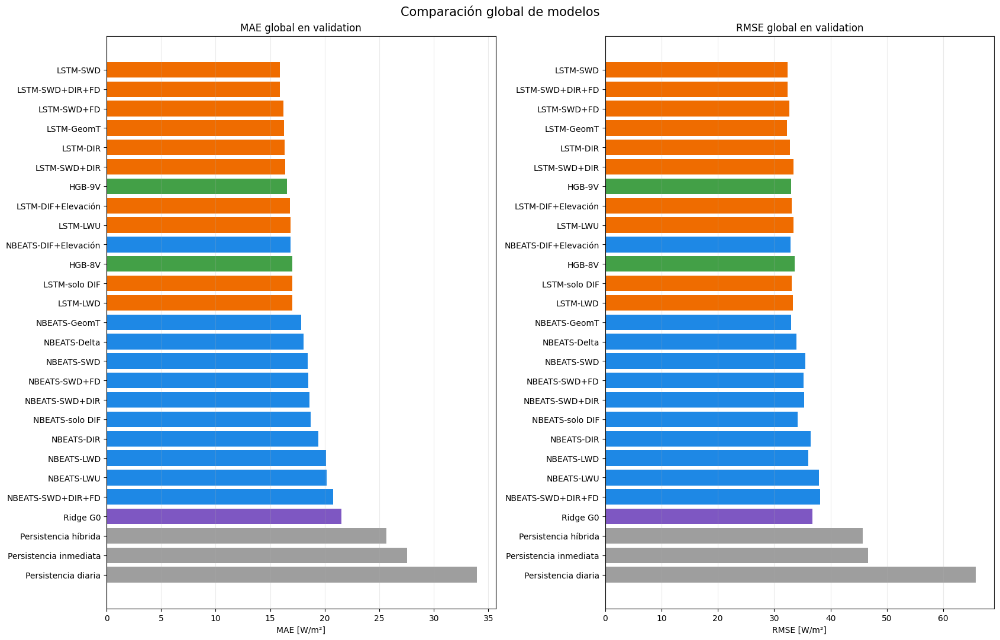


Comparación guardada en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas/comparacion_global_modelos_20261006_172035

COMPARACIÓN GLOBAL ACTUALIZADA CORRECTAMENTE


In [ ]:
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MEDIA_DIF_VALIDATION = float(y_validation_lwu.mean())

# Resultados externos sobre la misma validation.
resultados_globales = [
    # Baselines
    {
        "modelo": "Persistencia diaria",
        "familia": "Baseline",
        "variables": "DIF t-24",
        "MAE": 33.9545983,
        "RMSE": 65.7090900,
        "R2": 0.6306350,
    },
    {
        "modelo": "Persistencia inmediata",
        "familia": "Baseline",
        "variables": "DIF t-1",
        "MAE": 27.5660617,
        "RMSE": 46.6050470,
        "R2": 0.8141890,
    },
    {
        "modelo": "Persistencia híbrida",
        "familia": "Baseline",
        "variables": "Persistencia combinada",
        "MAE": 25.6618010,
        "RMSE": 45.7271050,
        "R2": 0.8211240,
    },
    {
        "modelo": "Ridge G0",
        "familia": "Ridge",
        "variables": "Configuración G0",
        "MAE": 21.5049702,
        "RMSE": 36.7942835,
        "R2": 0.8841850,
    },
    # HGB
    {
        "modelo": "HGB-9V",
        "familia": "HGB",
        "variables": "Elevación + DIF",
        "MAE": 16.5624043,
        "RMSE": 33.0427239,
        "R2": 0.9065979,
    },
    {
        "modelo": "HGB-8V",
        "familia": "HGB",
        "variables": "Configuración histórica 8V",
        "MAE": 17.0340,
        "RMSE": 33.6350,
        "R2": 0.9032,
    },
    # LSTM
    {
        "modelo": "LSTM-SWD",
        "familia": "LSTM",
        "variables": "DIF + elevación + SWD",
        "MAE": 15.8675230,
        "RMSE": 32.3839344,
        "R2": 0.9102852,
    },
    {
        "modelo": "LSTM-SWD+DIR+FD",
        "familia": "LSTM",
        "variables": "DIF + elevación + SWD + DIR + FD",
        "MAE": 15.8854351,
        "RMSE": 32.3480126,
        "R2": 0.9104841,
    },
    {
        "modelo": "LSTM-SWD+FD",
        "familia": "LSTM",
        "variables": "DIF + elevación + SWD + FD",
        "MAE": 16.2305412,
        "RMSE": 32.7155525,
        "R2": 0.9084384,
    },
    {
        "modelo": "LSTM-GeomT",
        "familia": "LSTM",
        "variables": "DIF + elevación histórica + GeomT",
        "MAE": 16.2659796,
        "RMSE": 32.2852505,
        "R2": 0.9108311,
    },
    {
        "modelo": "LSTM-DIR",
        "familia": "LSTM",
        "variables": "DIF + elevación + DIR",
        "MAE": 16.3258781,
        "RMSE": 32.8263234,
        "R2": 0.9078173,
    },
    {
        "modelo": "LSTM-SWD+DIR",
        "familia": "LSTM",
        "variables": "DIF + elevación + SWD + DIR",
        "MAE": 16.3507442,
        "RMSE": 33.4001763,
        "R2": 0.9045662,
    },
    {
        "modelo": "LSTM-DIF+Elevación",
        "familia": "LSTM",
        "variables": "DIF + elevación histórica",
        "MAE": 16.7831110,
        "RMSE": 33.0680667,
        "R2": 0.9064546,
    },
    {
        "modelo": "LSTM-LWU",
        "familia": "LSTM",
        "variables": "DIF + elevación + LWU",
        "MAE": float(metricas_lstm_lwu["MAE"]),
        "RMSE": float(metricas_lstm_lwu["RMSE"]),
        "R2": float(metricas_lstm_lwu["R2"]),
    },
    {
        "modelo": "LSTM-solo DIF",
        "familia": "LSTM",
        "variables": "DIF",
        "MAE": 17.0422648,
        "RMSE": 33.0629904,
        "R2": 0.9064833,
    },
    {
        "modelo": "LSTM-LWD",
        "familia": "LSTM",
        "variables": "DIF + elevación + LWD",
        "MAE": 17.0442691,
        "RMSE": 33.3466158,
        "R2": 0.9048720,
    },
    # N-BEATS
    {
        "modelo": "NBEATS-DIF+Elevación",
        "familia": "N-BEATS",
        "variables": "DIF + elevación histórica",
        "MAE": 16.8836284,
        "RMSE": 32.9200201,
        "R2": 0.9072903,
    },
    {
        "modelo": "NBEATS-GeomT",
        "familia": "N-BEATS",
        "variables": "DIF + elevación histórica + GeomT",
        "MAE": 17.8262339,
        "RMSE": 33.0239805,
        "R2": 0.9067039,
    },
    {
        "modelo": "NBEATS-Delta",
        "familia": "N-BEATS",
        "variables": "Objetivo delta",
        "MAE": 18.0397694,
        "RMSE": 33.9658056,
        "R2": 0.9013065,
    },
    {
        "modelo": "NBEATS-SWD",
        "familia": "N-BEATS",
        "variables": "DIF + elevación + SWD",
        "MAE": 18.4438283,
        "RMSE": 35.5059012,
        "R2": 0.8921535,
    },
    {
        "modelo": "NBEATS-SWD+FD",
        "familia": "N-BEATS",
        "variables": "DIF + elevación + SWD + FD",
        "MAE": 18.4684811,
        "RMSE": 35.2251582,
        "R2": 0.8938522,
    },
    {
        "modelo": "NBEATS-SWD+DIR",
        "familia": "N-BEATS",
        "variables": "DIF + elevación + SWD + DIR",
        "MAE": 18.5955696,
        "RMSE": 35.3345565,
        "R2": 0.8931919,
    },
    {
        "modelo": "NBEATS-solo DIF",
        "familia": "N-BEATS",
        "variables": "DIF",
        "MAE": 18.7116229,
        "RMSE": 34.1017507,
        "R2": 0.9005149,
    },
    {
        "modelo": "NBEATS-DIR",
        "familia": "N-BEATS",
        "variables": "DIF + elevación + DIR",
        "MAE": 19.3899651,
        "RMSE": 36.4624851,
        "R2": 0.8862641,
    },
    {
        "modelo": "NBEATS-LWD",
        "familia": "N-BEATS",
        "variables": "DIF + elevación + LWD",
        "MAE": 20.1166354,
        "RMSE": 35.9910865,
        "R2": 0.8891860,
    },
    {
        "modelo": "NBEATS-LWU",
        "familia": "N-BEATS",
        "variables": "DIF + elevación + LWU",
        "MAE": float(metricas_nbeats_lwu["MAE"]),
        "RMSE": float(metricas_nbeats_lwu["RMSE"]),
        "R2": float(metricas_nbeats_lwu["R2"]),
    },
    {
        "modelo": "NBEATS-SWD+DIR+FD",
        "familia": "N-BEATS",
        "variables": "DIF + elevación + SWD + DIR + FD",
        "MAE": 20.7894917,
        "RMSE": 38.1547703,
        "R2": 0.8754618,
    },
]


# 1. Construir tabla homogénea
comparacion_global_modelos = pd.DataFrame(resultados_globales)

# Recalcular nMAE con el mismo denominador
# para todos los modelos.
comparacion_global_modelos["nMAE_pct"] = (
    100 * comparacion_global_modelos["MAE"] / MEDIA_DIF_VALIDATION
)
comparacion_global_modelos["rank_MAE"] = (
    comparacion_global_modelos["MAE"].rank(method="min", ascending=True).astype(int)
)
comparacion_global_modelos["rank_RMSE"] = (
    comparacion_global_modelos["RMSE"].rank(method="min", ascending=True).astype(int)
)
comparacion_global_modelos["rank_R2"] = (
    comparacion_global_modelos["R2"].rank(method="min", ascending=False).astype(int)
)
candidatos_preliminares = {"LSTM-SWD", "LSTM-SWD+DIR+FD", "LSTM-GeomT", "HGB-9V"}
comparacion_global_modelos["candidato_preliminar"] = comparacion_global_modelos["modelo"].isin(
    candidatos_preliminares
)
comparacion_global_modelos = comparacion_global_modelos.sort_values(
    ["MAE", "RMSE"], ascending=[True, True]
).reset_index(drop=True)
comparacion_global_modelos.insert(
    0, "posicion_MAE", np.arange(1, len(comparacion_global_modelos) + 1)
)
print("Media común de DIF en validation:", MEDIA_DIF_VALIDATION)
print("\nCLASIFICACIÓN GLOBAL POR MAE")
display(
    comparacion_global_modelos[
        [
            "posicion_MAE",
            "modelo",
            "familia",
            "MAE",
            "nMAE_pct",
            "RMSE",
            "R2",
            "rank_RMSE",
            "rank_R2",
            "candidato_preliminar",
        ]
    ].style.format({"MAE": "{:.4f}", "nMAE_pct": "{:.4f}", "RMSE": "{:.4f}", "R2": "{:.4f}"})
)


# 2. Mejores modelos por métrica
mejores_por_metrica = pd.DataFrame(
    [
        {
            "metrica": "MAE",
            "modelo": (comparacion_global_modelos.sort_values("MAE").iloc[0]["modelo"]),
            "valor": (comparacion_global_modelos["MAE"].min()),
        },
        {
            "metrica": "nMAE",
            "modelo": (comparacion_global_modelos.sort_values("nMAE_pct").iloc[0]["modelo"]),
            "valor": (comparacion_global_modelos["nMAE_pct"].min()),
        },
        {
            "metrica": "RMSE",
            "modelo": (comparacion_global_modelos.sort_values("RMSE").iloc[0]["modelo"]),
            "valor": (comparacion_global_modelos["RMSE"].min()),
        },
        {
            "metrica": "R2",
            "modelo": (
                comparacion_global_modelos.sort_values("R2", ascending=False).iloc[0]["modelo"]
            ),
            "valor": (comparacion_global_modelos["R2"].max()),
        },
    ]
)
print("\nMEJOR MODELO POR MÉTRICA")
display(mejores_por_metrica)


# 3. Comparación de LWU con SWD
comparacion_lwu_swd = (
    comparacion_global_modelos.loc[
        comparacion_global_modelos["modelo"].isin(
            ["LSTM-SWD", "LSTM-LWU", "NBEATS-SWD", "NBEATS-LWU"]
        ),
        ["modelo", "MAE", "nMAE_pct", "RMSE", "R2", "posicion_MAE"],
    ]
    .sort_values("MAE")
    .reset_index(drop=True)
)
print("\nCOMPARACIÓN DIRECTA SWD FRENTE A LWU")
display(
    comparacion_lwu_swd.style.format(
        {"MAE": "{:.4f}", "nMAE_pct": "{:.4f}", "RMSE": "{:.4f}", "R2": "{:.4f}"}
    )
)


# 4. Gráfica global
tabla_grafica = comparacion_global_modelos.sort_values("MAE", ascending=False)
colores_familia = {
    "Baseline": "#9e9e9e",
    "Ridge": "#7e57c2",
    "HGB": "#43a047",
    "LSTM": "#ef6c00",
    "N-BEATS": "#1e88e5",
}
colores = [colores_familia[familia] for familia in tabla_grafica["familia"]]
fig, axes = plt.subplots(1, 2, figsize=(17, 11))
axes[0].barh(tabla_grafica["modelo"], tabla_grafica["MAE"], color=colores)
axes[0].set_title("MAE global en validation")
axes[0].set_xlabel("MAE [W/m²]")
axes[0].grid(axis="x", alpha=0.25)
axes[1].barh(tabla_grafica["modelo"], tabla_grafica["RMSE"], color=colores)
axes[1].set_title("RMSE global en validation")
axes[1].set_xlabel("RMSE [W/m²]")
axes[1].grid(axis="x", alpha=0.25)
fig.suptitle("Comparación global de modelos", fontsize=15)
fig.tight_layout()


# 5. Guardar comparación
RUN_COMPARACION = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_COMPARACION_GLOBAL = (
    BASE_DIR / "resultados" / "comparativas" / f"comparacion_global_modelos_" f"{RUN_COMPARACION}"
)
OUT_COMPARACION_GLOBAL.mkdir(parents=True, exist_ok=True)
comparacion_global_modelos.to_csv(
    OUT_COMPARACION_GLOBAL / "comparacion_global_modelos.csv", index=False, encoding="utf-8-sig"
)
mejores_por_metrica.to_csv(
    OUT_COMPARACION_GLOBAL / "mejores_por_metrica.csv", index=False, encoding="utf-8-sig"
)
comparacion_lwu_swd.to_csv(
    OUT_COMPARACION_GLOBAL / "comparacion_lwu_swd.csv", index=False, encoding="utf-8-sig"
)
fig.savefig(
    OUT_COMPARACION_GLOBAL / "comparacion_global_mae_rmse.png", dpi=180, bbox_inches="tight"
)
plt.show()


# 6. Registrar candidatos
resumen_candidatos = {
    "criterio": ("Complementariedad entre MAE, RMSE, R2 y familia de modelo"),
    "candidatos_preliminares": ["LSTM-SWD", "LSTM-SWD+DIR+FD", "LSTM-GeomT", "HGB-9V"],
    "mejor_MAE": "LSTM-SWD",
    "mejor_nMAE": "LSTM-SWD",
    "mejor_RMSE": "LSTM-GeomT",
    "mejor_R2": "LSTM-GeomT",
    "decision_LWU": (
        "No seleccionado como candidato preliminar. "
        "LSTM-LWU es competitivo, pero no mejora "
        "los modelos LSTM principales. "
        "N-BEATS-LWU presenta un deterioro claro."
    ),
    "test_utilizado": False,
}
with open(OUT_COMPARACION_GLOBAL / "resumen_candidatos.json", "w", encoding="utf-8") as archivo:
    json.dump(resumen_candidatos, archivo, ensure_ascii=False, indent=2)

print("\nComparación guardada en:")
print(OUT_COMPARACION_GLOBAL)
print("\nCOMPARACIÓN GLOBAL ACTUALIZADA CORRECTAMENTE")

**Resultados.**

- En operación, el MAE es de 27,40 W/m² para `LSTM_DIF_Elev_LWU` y de 32,71 W/m² para `NBEATS_DIF_Elev_LWU`; la noche aporta solo el 1,77 % y el 2,19 % de su error absoluto, respectivamente.
- En la clasificación global, `LSTM-LWU` ocupa el puesto 9 y `NBEATS-LWU` el 22, de 27 modelos.
- `LSTM-SWD` mantiene el menor MAE (15,87 W/m²) y `LSTM-GeomT`, el menor RMSE (32,29 W/m²).

### 6.33 Preparación del bloque SWU

Se construye el bloque de radiación de onda corta reflejada (SWU) con su media, su rango y su desviación estándar horarios, que junto con la DIF y la elevación solar forman matrices de cinco canales sobre ventanas de 24 horas. Previamente se comprueba la disponibilidad de SWU en todas las horas que intervienen en las ventanas de entrenamiento y validación.

In [ ]:
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd

BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PARQUET = BASE_DIR / "radiation_data_completo.parquet"
RUN_ID_SWU = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_PREPARACION_SWU = (
    BASE_DIR / "resultados" / "ejecuciones" / f"preparacion_bloque_swu_{RUN_ID_SWU}"
)
OUT_PREPARACION_SWU.mkdir(parents=True, exist_ok=True)
assert PARQUET.exists(), f"No existe: {PARQUET}"


# 1. Recuperar matrices base, targets y fechas
X_base_train_swu = np.asarray(X_train_DIF_elev_SWD_raw, dtype=np.float32)
X_base_validation_swu = np.asarray(X_validation_DIF_elev_SWD_raw, dtype=np.float32)
y_train_swu = np.asarray(y_train_raw, dtype=np.float32).reshape(-1)
y_validation_swu = np.asarray(y_validation_raw, dtype=np.float32).reshape(-1)
fechas_train_swu = pd.DatetimeIndex(pd.to_datetime(train_hgb["instante_objetivo"], errors="raise"))
fechas_validation_swu = pd.DatetimeIndex(
    pd.to_datetime(validation_hgb["instante_objetivo"], errors="raise")
)
if fechas_train_swu.tz is not None:
    fechas_train_swu = fechas_train_swu.tz_localize(None)

if fechas_validation_swu.tz is not None:
    fechas_validation_swu = fechas_validation_swu.tz_localize(None)

assert X_base_train_swu.shape == (5149, 24, 5)
assert X_base_validation_swu.shape == (1464, 24, 5)
assert y_train_swu.shape == (5149,)
assert y_validation_swu.shape == (1464,)
assert len(fechas_train_swu) == 5149
assert len(fechas_validation_swu) == 1464
assert fechas_train_swu.max() < pd.Timestamp("2024-08-01")
assert fechas_validation_swu.min() >= pd.Timestamp("2024-08-01")
assert fechas_validation_swu.max() < pd.Timestamp("2024-10-01")
print("Fechas objetivo:")
print("Train:     ", fechas_train_swu.min(), "→", fechas_train_swu.max())
print("Validation:", fechas_validation_swu.min(), "→", fechas_validation_swu.max())


# 2. Verificar alineación de los canales comunes
comprobaciones_swu = {
    "DIF lag 1 train": np.allclose(
        X_base_train_swu[:, -1, 0], train_hgb["DIF_lag_1"].to_numpy(float), atol=1e-4
    ),
    "DIF lag 24 train": np.allclose(
        X_base_train_swu[:, 0, 0], train_hgb["DIF_lag_24"].to_numpy(float), atol=1e-4
    ),
    "Elevación lag 1 train": np.allclose(
        X_base_train_swu[:, -1, 1], train_hgb["elevacion_media_lag1"].to_numpy(float), atol=1e-4
    ),
    "DIF lag 1 validation": np.allclose(
        X_base_validation_swu[:, -1, 0], validation_hgb["DIF_lag_1"].to_numpy(float), atol=1e-4
    ),
    "Elevación lag 1 validation": np.allclose(
        X_base_validation_swu[:, -1, 1],
        validation_hgb["elevacion_media_lag1"].to_numpy(float),
        atol=1e-4,
    ),
}
print("\nAlineación:")
for nombre, resultado in comprobaciones_swu.items():
    print(f"{nombre}: {resultado}")

if not all(comprobaciones_swu.values()):
    raise RuntimeError("La matriz base no está alineada.")

assert np.allclose(y_train_swu, train_hgb["DIF_objetivo_t1"].to_numpy(float), atol=1e-4)
assert np.allclose(y_validation_swu, validation_hgb["DIF_objetivo_t1"].to_numpy(float), atol=1e-4)
print("Targets: alineados")


# 3. Cargar variables originales SWU
COLUMNAS_SWU = [
    "Date/Time",
    "SWU [W/m**2]",
    "SWU std dev [W/m**2]",
    "SWU min [W/m**2]",
    "SWU max [W/m**2]",
]
columnas_parquet = pd.read_parquet(PARQUET).columns.tolist()
faltantes_swu = [columna for columna in COLUMNAS_SWU if columna not in columnas_parquet]
if faltantes_swu:
    raise RuntimeError("Faltan columnas SWU en el parquet: " f"{faltantes_swu}")

raw_swu = pd.read_parquet(PARQUET, columns=COLUMNAS_SWU)
raw_swu["Date/Time"] = pd.to_datetime(raw_swu["Date/Time"], errors="raise")
for columna in COLUMNAS_SWU[1:]:
    raw_swu[columna] = pd.to_numeric(raw_swu[columna], errors="coerce")

raw_swu = raw_swu.sort_values("Date/Time").set_index("Date/Time")


# 4. Agregación horaria correcta
SWU_HORARIO = raw_swu.resample("1h").agg(
    n_observaciones=("SWU [W/m**2]", "count"),
    SWU_media=("SWU [W/m**2]", "mean"),
    SWU_std=("SWU std dev [W/m**2]", "mean"),
    SWU_min=("SWU min [W/m**2]", "min"),
    SWU_max=("SWU max [W/m**2]", "max"),
)
SWU_HORARIO["SWU_rango"] = SWU_HORARIO["SWU_max"] - SWU_HORARIO["SWU_min"]
VARIABLES_SWU = ["SWU_media", "SWU_rango", "SWU_std"]


# 5. Obtener exactamente las horas usadas por las ventanas
def horas_requeridas(fechas_objetivo):
    bloques = [
        pd.date_range(end=(fecha - pd.Timedelta(hours=1)), periods=24, freq="1h").to_numpy()
        for fecha in fechas_objetivo
    ]
    return pd.DatetimeIndex(np.unique(np.concatenate(bloques)))

horas_train_requeridas = horas_requeridas(fechas_train_swu)
horas_validation_requeridas = horas_requeridas(fechas_validation_swu)
horas_totales_requeridas = horas_train_requeridas.union(horas_validation_requeridas).sort_values()
swu_requerido = SWU_HORARIO.reindex(horas_totales_requeridas)
nulos_requeridos = swu_requerido[VARIABLES_SWU].isna()
horas_vacias = nulos_requeridos.all(axis=1)
horas_con_algun_nulo = nulos_requeridos.any(axis=1)
horas_parciales = swu_requerido["n_observaciones"].between(1, 29)
print("\nDisponibilidad en las ventanas:")
print("Horas requeridas:", len(horas_totales_requeridas))
print("Horas completamente vacías:", int(horas_vacias.sum()))
print("Horas con algún estadístico nulo:", int(horas_con_algun_nulo.sum()))
print("Horas con 1–29 observaciones:", int(horas_parciales.sum()))
horas_problematicas_swu = swu_requerido.loc[horas_con_algun_nulo | horas_parciales]
print("\nHoras problemáticas dentro de las ventanas:")
display(horas_problematicas_swu)


# 6. Resumen por partición
def resumir_disponibilidad(nombre, horas):
    parte = SWU_HORARIO.reindex(horas)
    nulos = parte[VARIABLES_SWU].isna()
    return {
        "particion": nombre,
        "n_horas_requeridas": len(horas),
        "inicio": horas.min(),
        "fin": horas.max(),
        "horas_vacias": int(nulos.all(axis=1).sum()),
        "horas_con_algun_nulo": int(nulos.any(axis=1).sum()),
        "horas_1_29_observaciones": int(parte["n_observaciones"].between(1, 29).sum()),
    }

resumen_disponibilidad_swu = pd.DataFrame(
    [
        resumir_disponibilidad("train", horas_train_requeridas),
        resumir_disponibilidad("validation", horas_validation_requeridas),
    ]
)
print("\nResumen por partición:")
display(resumen_disponibilidad_swu)


# 7. Detenerse si existe un problema relevante
if horas_con_algun_nulo.any():
    raise RuntimeError(
        "Existen horas SWU con estadísticos nulos "
        "dentro de las ventanas. Deben revisarse "
        "antes de construir las matrices."
    )

if horas_parciales.any():
    raise RuntimeError(
        "Existen horas SWU con menos de 30 "
        "observaciones dentro de las ventanas. "
        "Deben revisarse antes de entrenar."
    )


# 8. Construir ventanas SWU
def construir_ventanas_swu(fechas_objetivo):
    ventanas = np.empty((len(fechas_objetivo), 24, 3), dtype=np.float32)
    for i, fecha_objetivo in enumerate(fechas_objetivo):
        historia = pd.date_range(
            end=(fecha_objetivo - pd.Timedelta(hours=1)), periods=24, freq="1h"
        )
        bloque = SWU_HORARIO.reindex(historia)[VARIABLES_SWU]
        ventanas[i] = bloque.to_numpy(dtype=np.float32)

    return ventanas

bloque_swu_train = construir_ventanas_swu(fechas_train_swu)
bloque_swu_validation = construir_ventanas_swu(fechas_validation_swu)


# 9. Matrices finales
X_train_DIF_elev_SWU_raw = np.concatenate(
    [X_base_train_swu[:, :, :2], bloque_swu_train], axis=2
).astype(np.float32)
X_validation_DIF_elev_SWU_raw = np.concatenate(
    [X_base_validation_swu[:, :, :2], bloque_swu_validation], axis=2
).astype(np.float32)
assert X_train_DIF_elev_SWU_raw.shape == (5149, 24, 5)
assert X_validation_DIF_elev_SWU_raw.shape == (1464, 24, 5)
assert np.isfinite(X_train_DIF_elev_SWU_raw).all()
assert np.isfinite(X_validation_DIF_elev_SWU_raw).all()


# 10. Guardar preparación
np.savez_compressed(
    OUT_PREPARACION_SWU / "matrices_DIF_elev_SWU.npz",
    X_train_DIF_elev_SWU_raw=(X_train_DIF_elev_SWU_raw),
    X_validation_DIF_elev_SWU_raw=(X_validation_DIF_elev_SWU_raw),
    y_train_raw=y_train_swu,
    y_validation_raw=y_validation_swu,
    fechas_train=(fechas_train_swu.to_numpy(dtype="datetime64[ns]")),
    fechas_validation=(fechas_validation_swu.to_numpy(dtype="datetime64[ns]")),
)
SWU_HORARIO.loc[horas_totales_requeridas.min() : horas_totales_requeridas.max()].to_parquet(
    OUT_PREPARACION_SWU / "variables_swu_horarias.parquet"
)
resumen_disponibilidad_swu.to_csv(
    OUT_PREPARACION_SWU / "resumen_disponibilidad_swu.csv", index=False, encoding="utf-8-sig"
)
configuracion_swu = {
    "canales": ["DIF", "elevacion", "SWU_media", "SWU_rango", "SWU_std"],
    "definiciones": {
        "SWU_media": "Media horaria de SWU",
        "SWU_rango": "Máximo horario de SWU max menos mínimo horario de SWU min",
        "SWU_std": "Media horaria de SWU std dev",
    },
    "imputacion_realizada": False,
    "test_utilizado": False,
}
with open(
    OUT_PREPARACION_SWU / "configuracion_preparacion_swu.json", "w", encoding="utf-8"
) as archivo:
    json.dump(configuracion_swu, archivo, ensure_ascii=False, indent=2)

print("\nMatrices generadas:")
print("Train:     ", X_train_DIF_elev_SWU_raw.shape)
print("Validation:", X_validation_DIF_elev_SWU_raw.shape)
print("Canales: DIF, elevación, SWU media, rango y std")
print("\nGuardado en:")
print(OUT_PREPARACION_SWU)
print("\nPREPARACIÓN DEL BLOQUE SWU COMPLETADA CORRECTAMENTE")

Fechas objetivo:
Train:      2023-12-30 00:00:00 → 2024-07-31 23:00:00
Validation: 2024-08-01 00:00:00 → 2024-09-30 23:00:00

Alineación:
DIF lag 1 train: True
DIF lag 24 train: True
Elevación lag 1 train: True
DIF lag 1 validation: True
Elevación lag 1 validation: True
Targets: alineados

Disponibilidad en las ventanas:
Horas requeridas: 6647
Horas completamente vacías: 0
Horas con algún estadístico nulo: 0
Horas con 1–29 observaciones: 0

Horas problemáticas dentro de las ventanas:


,n_observaciones,SWU_media,SWU_std,SWU_min,SWU_max,SWU_rango



Resumen por partición:


,particion,n_horas_requeridas,inicio,fin,horas_vacias,horas_con_algun_nulo,horas_1_29_observaciones
0,train,5183,2023-12-29,2024-07-31 22:00:00,0,0,0
1,validation,1487,2024-07-31,2024-09-30 22:00:00,0,0,0



Matrices generadas:
Train:      (5149, 24, 5)
Validation: (1464, 24, 5)
Canales: DIF, elevación, SWU media, rango y std

Guardado en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_bloque_swu_20261006_172349

PREPARACIÓN DEL BLOQUE SWU COMPLETADA CORRECTAMENTE


**Resultados.** Las 6.647 horas necesarias para las ventanas no presentan horas vacías, nulos ni observación parcial, por lo que no se requiere imputación. Las matrices resultantes tienen 5.149 muestras en entrenamiento y 1.464 en validación, y la alineación con los retardos de la DIF y con los objetivos es exacta.

### 6.34 Selección interna de épocas del bloque SWU

Con el mismo protocolo que en LWU (subtrain de 4.428 muestras, validación interna de 721, escalado ajustado solo en subtrain y parada temprana tras 25 épocas sin mejora), se selecciona para N-BEATS y LSTM la época de menor MAE interno.

=== DIVISIÓN INTERNA SWU ===
Subtrain: (4428, 24, 5) (4428,)
Validación interna: (721, 24, 5) (721,)
Validation externa utilizada: NO

SELECCIÓN INTERNA: NBEATS_SWU
Época 001 | MAE subtrain: 22.047028 | MAE interna: 34.029095  <-- nuevo mínimo
Época 002 | MAE subtrain: 18.327869 | MAE interna: 30.572670  <-- nuevo mínimo
Época 003 | MAE subtrain: 17.381126 | MAE interna: 29.420755  <-- nuevo mínimo
Época 004 | MAE subtrain: 16.106970 | MAE interna: 28.624203  <-- nuevo mínimo
Época 005 | MAE subtrain: 16.195570 | MAE interna: 29.312782
Época 006 | MAE subtrain: 16.828163 | MAE interna: 27.478567  <-- nuevo mínimo
Época 009 | MAE subtrain: 14.481565 | MAE interna: 27.293394  <-- nuevo mínimo
Época 010 | MAE subtrain: 14.545689 | MAE interna: 28.959370
Época 011 | MAE subtrain: 15.074777 | MAE interna: 26.648148  <-- nuevo mínimo
Época 013 | MAE subtrain: 12.508622 | MAE interna: 26.449955  <-- nuevo mínimo
Época 015 | MAE subtrain: 12.329123 | MAE interna: 27.336544
Época 020 | MAE subt

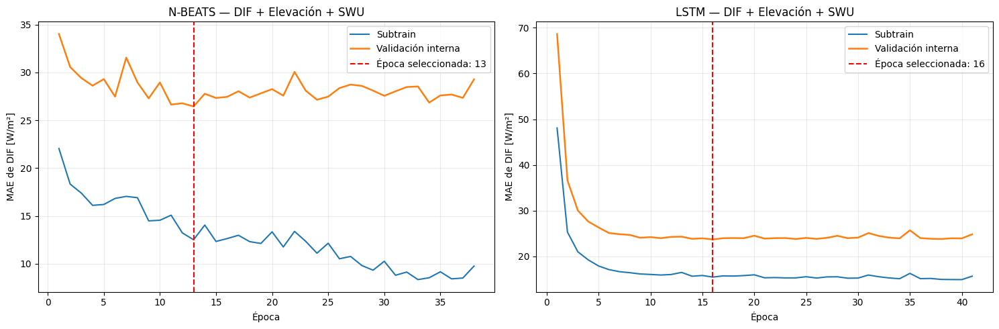


=== RESULTADO DE LA SELECCIÓN INTERNA SWU ===


,modelo,epoca_seleccionada,mae_validacion_interna
0,NBEATS_DIF_Elev_SWU,13,26.449955
1,LSTM_DIF_Elev_SWU,16,23.685919


N-BEATS se reentrenará durante 13 épocas.
LSTM se reentrenará durante 16 épocas.

Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/seleccion_interna_swu_20261006_172840

Validation externa utilizada: NO


In [ ]:
import copy
import json
import random
from datetime import datetime
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

# 1. Configuración
SEED = 42
N_SUBTRAIN = 4428
BATCH_SIZE = 128
MAX_EPOCHS = 300
PATIENCE = 25
MIN_DELTA = 1e-5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
DEVICE = torch.device("cpu")
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_SELECCION_SWU = BASE_DIR / "resultados" / "ejecuciones" / f"seleccion_interna_swu_{timestamp}"
OUT_SELECCION_SWU.mkdir(parents=True, exist_ok=True)

def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)

fijar_semilla()


# 2. Comprobaciones
assert "X_train_DIF_elev_SWU_raw" in globals(), (
    "No existe X_train_DIF_elev_SWU_raw. Ejecuta primero la celda de preparación de SWU."
)
X_swu = np.asarray(X_train_DIF_elev_SWU_raw, dtype=np.float32)

# Se utiliza el objetivo de train ya disponible en el notebook
if "y_train_swu" in globals():
    y_swu = np.asarray(y_train_swu, dtype=np.float32).reshape(-1)
elif "y_train_raw" in globals():
    y_swu = np.asarray(y_train_raw, dtype=np.float32).reshape(-1)
elif "y_train" in globals():
    y_swu = np.asarray(y_train, dtype=np.float32).reshape(-1)
else:
    raise NameError("No se encuentra y_train_swu, y_train_raw ni y_train.")

assert X_swu.shape == (
    5149,
    24,
    5,
), f"Forma inesperada para X_train_DIF_elev_SWU_raw: {X_swu.shape}"
assert len(y_swu) == len(X_swu), f"Longitudes incompatibles: X={len(X_swu)}, y={len(y_swu)}"
assert np.isfinite(X_swu).all(), "X contiene NaN o infinitos."
assert np.isfinite(y_swu).all(), "y contiene NaN o infinitos."
assert 0 < N_SUBTRAIN < len(X_swu)


# 3. División cronológica interna
X_sub_raw = X_swu[:N_SUBTRAIN]
y_sub_raw = y_swu[:N_SUBTRAIN]
X_int_raw = X_swu[N_SUBTRAIN:]
y_int_raw = y_swu[N_SUBTRAIN:]
print("=== DIVISIÓN INTERNA SWU ===")
print("Subtrain:", X_sub_raw.shape, y_sub_raw.shape)
print("Validación interna:", X_int_raw.shape, y_int_raw.shape)
print("Validation externa utilizada: NO")


# 4. Escalado ajustado únicamente con subtrain
n_features = X_sub_raw.shape[2]
scaler_X_swu = StandardScaler()
scaler_y_swu = StandardScaler()
scaler_X_swu.fit(X_sub_raw.reshape(-1, n_features))
scaler_y_swu.fit(y_sub_raw.reshape(-1, 1))

def transformar_X(X):
    forma = X.shape
    return scaler_X_swu.transform(X.reshape(-1, forma[2])).reshape(forma).astype(np.float32)

X_sub = transformar_X(X_sub_raw)
X_int = transformar_X(X_int_raw)
y_sub = scaler_y_swu.transform(y_sub_raw.reshape(-1, 1)).ravel().astype(np.float32)
y_int = scaler_y_swu.transform(y_int_raw.reshape(-1, 1)).ravel().astype(np.float32)
joblib.dump(scaler_X_swu, OUT_SELECCION_SWU / "scaler_X_subtrain.joblib")
joblib.dump(scaler_y_swu, OUT_SELECCION_SWU / "scaler_y_subtrain.joblib")


# 5. DataLoaders
train_dataset = TensorDataset(torch.from_numpy(X_sub), torch.from_numpy(y_sub))
internal_dataset = TensorDataset(torch.from_numpy(X_int), torch.from_numpy(y_int))
generator = torch.Generator()
generator.manual_seed(SEED)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generator, num_workers=0
)
train_eval_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
internal_loader = DataLoader(internal_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)


# 6. Arquitecturas
class NBEATSBlockSWU(nn.Module):
    def __init__(self, input_size=120, hidden_size=128, backcast_size=24):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
        )
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return self.backcast(h), self.forecast(h)

class NBEATSSWU(nn.Module):
    """
    Dos stacks de tres bloques.

    El residuo se aplica solamente al historial de DIF.
    Las covariables permanecen fijas en todos los bloques.
    """

    def __init__(self, lookback=24, n_features=5, hidden_size=128):
        super().__init__()
        input_size = lookback * n_features
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockSWU(
                    input_size=input_size, hidden_size=hidden_size, backcast_size=lookback
                )
                for _ in range(6)
            ]
        )

    def forward(self, x):
        residual_dif = x[:, :, 0]
        covariables = x[:, :, 1:].permute(0, 2, 1).contiguous().reshape(x.size(0), -1)
        forecast_total = torch.zeros((x.size(0), 1), device=x.device, dtype=x.dtype)
        for block in self.blocks:
            entrada_bloque = torch.cat([residual_dif, covariables], dim=1)
            backcast, forecast = block(entrada_bloque)
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast

        return forecast_total.squeeze(-1)

class LSTMSWU(nn.Module):
    def __init__(self, n_features=5, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        return self.head(salida[:, -1, :]).squeeze(-1)


# 7. Evaluación en unidades originales
def evaluar_mae_original(modelo, loader):
    modelo.eval()
    predicciones = []
    observaciones = []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            pred = modelo(xb).cpu().numpy()
            predicciones.append(pred)
            observaciones.append(yb.numpy())

    pred_scaled = np.concatenate(predicciones)
    y_scaled = np.concatenate(observaciones)
    pred_original = scaler_y_swu.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    y_original = scaler_y_swu.inverse_transform(y_scaled.reshape(-1, 1)).ravel()
    return float(np.mean(np.abs(y_original - pred_original)))


# 8. Entrenamiento con early stopping
def seleccionar_epoca(modelo, nombre):
    fijar_semilla()
    modelo = modelo.to(DEVICE)
    criterio = nn.L1Loss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    mejor_mae = np.inf
    mejor_epoca = None
    mejor_estado = None
    epocas_sin_mejora = 0
    historial = []
    print(f"\n{'=' * 65}")
    print(f"SELECCIÓN INTERNA: {nombre}")
    print(f"{'=' * 65}")
    for epoca in range(1, MAX_EPOCHS + 1):
        modelo.train()
        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            pred = modelo(xb)
            loss = criterio(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
            optimizador.step()

        mae_subtrain = evaluar_mae_original(modelo, train_eval_loader)
        mae_interno = evaluar_mae_original(modelo, internal_loader)
        historial.append(
            {"epoca": epoca, "mae_subtrain": mae_subtrain, "mae_validacion_interna": mae_interno}
        )
        if mae_interno < mejor_mae - MIN_DELTA:
            mejor_mae = mae_interno
            mejor_epoca = epoca
            mejor_estado = copy.deepcopy(modelo.state_dict())
            epocas_sin_mejora = 0
            indicador = "  <-- nuevo mínimo"
        else:
            epocas_sin_mejora += 1
            indicador = ""

        if epoca == 1 or epoca % 5 == 0 or indicador:
            print(
                f"Época {epoca:03d} | "
                f"MAE subtrain: {mae_subtrain:.6f} | "
                f"MAE interna: {mae_interno:.6f}"
                f"{indicador}"
            )

        if epocas_sin_mejora >= PATIENCE:
            print(f"\nEarly stopping: {PATIENCE} épocas sin mejorar " f"el mínimo observado.")
            print(f"Mejor época: {mejor_epoca} | " f"MAE interna mínimo: {mejor_mae:.6f}")
            break

    modelo.load_state_dict(mejor_estado)
    historial = pd.DataFrame(historial)
    historial.to_csv(OUT_SELECCION_SWU / f"historial_{nombre.lower()}.csv", index=False)
    torch.save(
        {
            "model_state_dict": mejor_estado,
            "mejor_epoca": mejor_epoca,
            "mejor_mae_interno": mejor_mae,
            "arquitectura": nombre,
            "bloque": "DIF_Elev_SWU",
            "canales": ["DIF", "elevacion", "SWU_media", "SWU_rango", "SWU_std"],
        },
        OUT_SELECCION_SWU / f"mejor_checkpoint_{nombre.lower()}.pt",
    )
    return modelo, historial, mejor_epoca, mejor_mae


# 9. Selección N-BEATS
modelo_nbeats_swu, historial_nbeats_swu, EPOCA_NBEATS_SWU, mae_nbeats_swu = seleccionar_epoca(
    NBEATSSWU(lookback=24, n_features=5, hidden_size=128), "NBEATS_SWU"
)


# 10. Selección LSTM
modelo_lstm_swu, historial_lstm_swu, EPOCA_LSTM_SWU, mae_lstm_swu = seleccionar_epoca(
    LSTMSWU(n_features=5, hidden_size=64), "LSTM_SWU"
)


# 11. Gráficas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, historial, nombre, mejor_epoca in [
    (axes[0], historial_nbeats_swu, "N-BEATS — DIF + Elevación + SWU", EPOCA_NBEATS_SWU),
    (axes[1], historial_lstm_swu, "LSTM — DIF + Elevación + SWU", EPOCA_LSTM_SWU),
]:
    ax.plot(historial["epoca"], historial["mae_subtrain"], label="Subtrain", linewidth=1.5)
    ax.plot(
        historial["epoca"],
        historial["mae_validacion_interna"],
        label="Validación interna",
        linewidth=1.8,
    )
    ax.axvline(mejor_epoca, color="red", linestyle="--", label=f"Época seleccionada: {mejor_epoca}")
    ax.set_title(nombre)
    ax.set_xlabel("Época")
    ax.set_ylabel("MAE de DIF [W/m²]")
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.savefig(OUT_SELECCION_SWU / "curvas_seleccion_interna_swu.png", dpi=180, bbox_inches="tight")
plt.show()


# 12. Resumen y registro
resumen_swu = pd.DataFrame(
    [
        {
            "modelo": "NBEATS_DIF_Elev_SWU",
            "epoca_seleccionada": EPOCA_NBEATS_SWU,
            "mae_validacion_interna": mae_nbeats_swu,
        },
        {
            "modelo": "LSTM_DIF_Elev_SWU",
            "epoca_seleccionada": EPOCA_LSTM_SWU,
            "mae_validacion_interna": mae_lstm_swu,
        },
    ]
)
resumen_swu.to_csv(OUT_SELECCION_SWU / "resumen_seleccion_interna_swu.csv", index=False)
configuracion = {
    "bloque": "DIF_Elev_SWU",
    "n_subtrain": int(N_SUBTRAIN),
    "n_validacion_interna": int(len(X_int_raw)),
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "min_delta": MIN_DELTA,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "L1Loss",
    "seed": SEED,
    "device": str(DEVICE),
    "validation_externa_utilizada": False,
    "epoca_nbeats": int(EPOCA_NBEATS_SWU),
    "epoca_lstm": int(EPOCA_LSTM_SWU),
}
with open(OUT_SELECCION_SWU / "configuracion_seleccion_swu.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion, archivo, indent=2, ensure_ascii=False)

print("\n=== RESULTADO DE LA SELECCIÓN INTERNA SWU ===")
display(resumen_swu)
print(f"N-BEATS se reentrenará durante {EPOCA_NBEATS_SWU} épocas.")
print(f"LSTM se reentrenará durante {EPOCA_LSTM_SWU} épocas.")
print(f"\nResultados guardados en:\n{OUT_SELECCION_SWU}")
print("\nValidation externa utilizada: NO")

**Resultados.** N-BEATS alcanza su mínimo en la época 13 (MAE interno de 26,45 W/m²) y la LSTM en la época 16 (23,69 W/m²).

### 6.35 Reentrenamiento y evaluación externa del bloque SWU

N-BEATS (13 épocas) y LSTM (16 épocas) se reentrenan desde cero con todo el entrenamiento, con escaladores ajustados solo con el entrenamiento, y se evalúan una única vez en validación.

Objetivo train: y_train_swu
Objetivo validation: y_validation_swu

=== DATOS DEL REENTRENAMIENTO SWU ===
Train: (5149, 24, 5) (5149,)
Validation externa: (1464, 24, 5) (1464,)
Canales: DIF, elevación, SWU_media, SWU_rango, SWU_std

REENTRENAMIENTO COMPLETO: NBEATS_SWU
Épocas fijadas: 13
Época 001/13 | MAE train: 23.289024 W/m²
Época 002/13 | MAE train: 21.015377 W/m²
Época 003/13 | MAE train: 18.048098 W/m²
Época 004/13 | MAE train: 18.807371 W/m²
Época 005/13 | MAE train: 19.177647 W/m²
Época 006/13 | MAE train: 17.358236 W/m²
Época 007/13 | MAE train: 17.134434 W/m²
Época 008/13 | MAE train: 15.254646 W/m²
Época 009/13 | MAE train: 15.716786 W/m²
Época 010/13 | MAE train: 16.722740 W/m²
Época 011/13 | MAE train: 14.868192 W/m²
Época 012/13 | MAE train: 15.505397 W/m²
Época 013/13 | MAE train: 14.467445 W/m²
Tiempo de entrenamiento: 21.34 s

REENTRENAMIENTO COMPLETO: LSTM_SWU
Épocas fijadas: 16
Época 001/16 | MAE train: 32.892521 W/m²
Época 002/16 | MAE train: 24.858898 W/m²
Época 003

,modelo,particion,epocas,tiempo_entrenamiento_s,MAE,nMAE_pct,RMSE,R2,bias
0,NBEATS_DIF_Elev_SWU,train,13,21.34,14.467445,17.861944,29.097717,0.932708,-4.379333
1,NBEATS_DIF_Elev_SWU,validation,13,21.34,17.232775,20.034420,32.982201,0.906940,-2.454525
2,LSTM_DIF_Elev_SWU,train,16,34.40,17.131540,21.151117,33.601336,0.910266,-4.358264
3,LSTM_DIF_Elev_SWU,validation,16,34.40,16.982195,19.743103,33.004581,0.906813,-3.740389


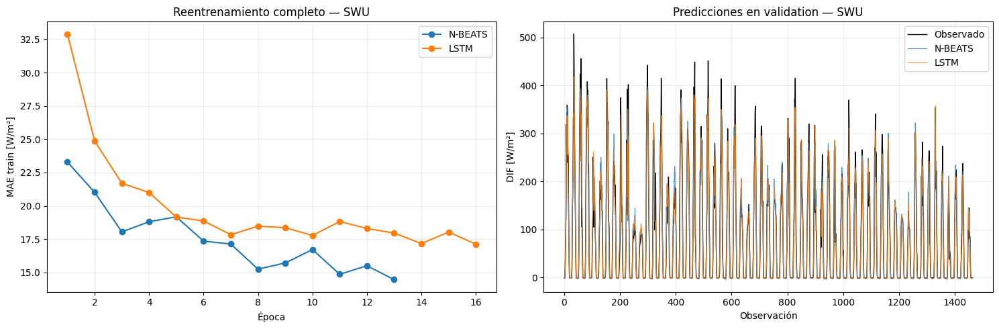


=== REENTRENAMIENTO SWU COMPLETADO ===
N-BEATS: 13 épocas
LSTM: 16 épocas
Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/modelado_swu_completo_20261006_173357

Validation externa utilizada únicamente para evaluación final.


In [ ]:
import json
import random
import time
from datetime import datetime
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Configuración fijada por la selección interna
SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
DEVICE = torch.device("cpu")

# Se recuperan de la celda anterior; los valores confirmados
# en la salida son 13 y 16.
EPOCA_NBEATS_SWU = int(globals().get("EPOCA_NBEATS_SWU", 13))
EPOCA_LSTM_SWU = int(globals().get("EPOCA_LSTM_SWU", 16))
assert EPOCA_NBEATS_SWU == 13, f"Se esperaba época 13 para N-BEATS, obtenida: {EPOCA_NBEATS_SWU}"
assert EPOCA_LSTM_SWU == 16, f"Se esperaba época 16 para LSTM, obtenida: {EPOCA_LSTM_SWU}"
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_SWU = BASE_DIR / "resultados" / "ejecuciones" / f"modelado_swu_completo_{timestamp}"
OUT_SWU.mkdir(parents=True, exist_ok=True)

def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)


# 2. Recuperación y comprobación de los datos
assert "X_train_DIF_elev_SWU_raw" in globals()
assert "X_validation_DIF_elev_SWU_raw" in globals()
assert "NBEATSSWU" in globals()
assert "LSTMSWU" in globals()
X_train_swu_raw = np.asarray(X_train_DIF_elev_SWU_raw, dtype=np.float32)
X_validation_swu_raw = np.asarray(X_validation_DIF_elev_SWU_raw, dtype=np.float32)

def recuperar_objetivo(particion):
    candidatos = {
        "train": ["y_train_swu", "y_train_raw", "y_train_completo", "y_train_full", "y_train"],
        "validation": [
            "y_validation_swu",
            "y_validation_raw",
            "y_validation_completo",
            "y_validation_full",
            "y_validation",
        ],
    }
    for nombre in candidatos[particion]:
        if nombre in globals():
            vector = np.asarray(globals()[nombre], dtype=np.float32).reshape(-1)
            longitud_esperada = (
                len(X_train_swu_raw) if particion == "train" else len(X_validation_swu_raw)
            )
            if len(vector) == longitud_esperada:
                print(f"Objetivo {particion}: {nombre}")
                return vector

    raise NameError(f"No se encontró un objetivo válido para {particion}.")

y_train_swu_raw = recuperar_objetivo("train")
y_validation_swu_raw = recuperar_objetivo("validation")
assert X_train_swu_raw.shape == (5149, 24, 5)
assert X_validation_swu_raw.shape == (1464, 24, 5)
assert len(y_train_swu_raw) == 5149
assert len(y_validation_swu_raw) == 1464
assert np.isfinite(X_train_swu_raw).all()
assert np.isfinite(X_validation_swu_raw).all()
assert np.isfinite(y_train_swu_raw).all()
assert np.isfinite(y_validation_swu_raw).all()
print("\n=== DATOS DEL REENTRENAMIENTO SWU ===")
print("Train:", X_train_swu_raw.shape, y_train_swu_raw.shape)
print("Validation externa:", X_validation_swu_raw.shape, y_validation_swu_raw.shape)
print("Canales: DIF, elevación, SWU_media, SWU_rango, SWU_std")


# 3. Escalado ajustado solamente con todo train
n_features = X_train_swu_raw.shape[2]
scaler_X_swu_final = StandardScaler()
scaler_y_swu_final = StandardScaler()
scaler_X_swu_final.fit(X_train_swu_raw.reshape(-1, n_features))
scaler_y_swu_final.fit(y_train_swu_raw.reshape(-1, 1))

def transformar_X(X):
    forma = X.shape
    return scaler_X_swu_final.transform(X.reshape(-1, forma[2])).reshape(forma).astype(np.float32)

X_train_swu = transformar_X(X_train_swu_raw)
X_validation_swu = transformar_X(X_validation_swu_raw)
y_train_swu = (
    scaler_y_swu_final.transform(y_train_swu_raw.reshape(-1, 1)).ravel().astype(np.float32)
)

# Se transforma validation, pero no se utiliza para entrenar
y_validation_swu = (
    scaler_y_swu_final.transform(y_validation_swu_raw.reshape(-1, 1)).ravel().astype(np.float32)
)
joblib.dump(scaler_X_swu_final, OUT_SWU / "scaler_X_train_completo.joblib")
joblib.dump(scaler_y_swu_final, OUT_SWU / "scaler_y_train_completo.joblib")


# 4. Funciones auxiliares
def crear_loader_train(X, y):
    dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    generador = torch.Generator()
    generador.manual_seed(SEED)
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generador, num_workers=0
    )

def crear_loader_evaluacion(X, y):
    dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

def predecir_original(modelo, loader):
    modelo.eval()
    predicciones = []
    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(DEVICE)
            predicciones.append(modelo(xb).cpu().numpy())

    pred_scaled = np.concatenate(predicciones)
    return scaler_y_swu_final.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()

def calcular_metricas(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    denominador = np.mean(np.abs(y_real))
    nmae = 100 * mae / denominador if denominador != 0 else np.nan
    return {
        "MAE": float(mae),
        "nMAE_pct": float(nmae),
        "RMSE": float(rmse),
        "R2": float(r2_score(y_real, y_pred)),
        "bias": float(np.mean(y_pred - y_real)),
    }


# 5. Reentrenamiento desde cero
def entrenar_modelo_final(modelo, nombre, numero_epocas):
    fijar_semilla()
    modelo = modelo.to(DEVICE)
    train_loader = crear_loader_train(X_train_swu, y_train_swu)
    train_eval_loader = crear_loader_evaluacion(X_train_swu, y_train_swu)
    criterio = nn.L1Loss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    historial = []
    inicio = time.perf_counter()
    print(f"\n{'=' * 65}")
    print(f"REENTRENAMIENTO COMPLETO: {nombre}")
    print(f"Épocas fijadas: {numero_epocas}")
    print(f"{'=' * 65}")
    for epoca in range(1, numero_epocas + 1):
        modelo.train()
        suma_loss = 0.0
        numero_elementos = 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            pred = modelo(xb)
            loss = criterio(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            optimizador.step()
            suma_loss += loss.item() * len(xb)
            numero_elementos += len(xb)

        # Evaluación únicamente sobre train
        pred_train = predecir_original(modelo, train_eval_loader)
        mae_train = mean_absolute_error(y_train_swu_raw, pred_train)
        historial.append(
            {
                "epoca": epoca,
                "loss_train_escalada": suma_loss / numero_elementos,
                "mae_train_original": mae_train,
            }
        )
        print(f"Época {epoca:03d}/{numero_epocas} | " f"MAE train: {mae_train:.6f} W/m²")

    tiempo = time.perf_counter() - inicio
    historial = pd.DataFrame(historial)
    historial.to_csv(OUT_SWU / f"historial_train_{nombre.lower()}.csv", index=False)
    print(f"Tiempo de entrenamiento: {tiempo:.2f} s")
    return modelo, historial, tiempo


# Instanciación nueva: no se reutilizan los pesos del subtrain
modelo_nbeats_swu_final = NBEATSSWU(lookback=24, n_features=5, hidden_size=128)
modelo_lstm_swu_final = LSTMSWU(n_features=5, hidden_size=64)
modelo_nbeats_swu_final, hist_nbeats_swu, tiempo_nbeats = entrenar_modelo_final(
    modelo_nbeats_swu_final, "NBEATS_SWU", EPOCA_NBEATS_SWU
)
modelo_lstm_swu_final, hist_lstm_swu, tiempo_lstm = entrenar_modelo_final(
    modelo_lstm_swu_final, "LSTM_SWU", EPOCA_LSTM_SWU
)


# 6. Predicción externa en validation
# Se ejecuta después de finalizar ambos entrenamientos
train_eval_loader = crear_loader_evaluacion(X_train_swu, y_train_swu)
validation_loader = crear_loader_evaluacion(X_validation_swu, y_validation_swu)
pred_train_nbeats = predecir_original(modelo_nbeats_swu_final, train_eval_loader)
pred_train_lstm = predecir_original(modelo_lstm_swu_final, train_eval_loader)
pred_validation_nbeats = predecir_original(modelo_nbeats_swu_final, validation_loader)
pred_validation_lstm = predecir_original(modelo_lstm_swu_final, validation_loader)


# 7. Métricas de train y validation
filas_metricas = []
for modelo, epocas, tiempo_entrenamiento, pred_train, pred_val in [
    (
        "NBEATS_DIF_Elev_SWU",
        EPOCA_NBEATS_SWU,
        tiempo_nbeats,
        pred_train_nbeats,
        pred_validation_nbeats,
    ),
    ("LSTM_DIF_Elev_SWU", EPOCA_LSTM_SWU, tiempo_lstm, pred_train_lstm, pred_validation_lstm),
]:
    metricas_train = calcular_metricas(y_train_swu_raw, pred_train)
    metricas_validation = calcular_metricas(y_validation_swu_raw, pred_val)
    filas_metricas.append(
        {
            "modelo": modelo,
            "particion": "train",
            "epocas": epocas,
            "tiempo_entrenamiento_s": tiempo_entrenamiento,
            **metricas_train,
        }
    )
    filas_metricas.append(
        {
            "modelo": modelo,
            "particion": "validation",
            "epocas": epocas,
            "tiempo_entrenamiento_s": tiempo_entrenamiento,
            **metricas_validation,
        }
    )

metricas_swu = pd.DataFrame(filas_metricas)
metricas_swu.to_csv(OUT_SWU / "metricas_train_validation_swu.csv", index=False)
print("\n=== MÉTRICAS TRAIN Y VALIDATION — SWU ===")
display(
    metricas_swu.style.format(
        {
            "tiempo_entrenamiento_s": "{:.2f}",
            "MAE": "{:.6f}",
            "nMAE_pct": "{:.6f}",
            "RMSE": "{:.6f}",
            "R2": "{:.6f}",
            "bias": "{:.6f}",
        }
    )
)


# 8. Predicciones de validation
if "validation_hgb" in globals() and len(validation_hgb) == len(y_validation_swu_raw):
    predicciones_validation_swu = pd.DataFrame(
        {
            "instante_objetivo": pd.to_datetime(validation_hgb["instante_objetivo"]),
            "regimen_solar_objetivo": validation_hgb["regimen_solar_objetivo"]
            .astype(str)
            .to_numpy(),
            "DIF_observado": y_validation_swu_raw,
            "pred_NBEATS_SWU": pred_validation_nbeats,
            "pred_LSTM_SWU": pred_validation_lstm,
        }
    )
else:
    predicciones_validation_swu = pd.DataFrame(
        {
            "indice_validation": np.arange(len(y_validation_swu_raw)),
            "DIF_observado": y_validation_swu_raw,
            "pred_NBEATS_SWU": pred_validation_nbeats,
            "pred_LSTM_SWU": pred_validation_lstm,
        }
    )

predicciones_validation_swu["error_NBEATS_SWU"] = (
    predicciones_validation_swu["pred_NBEATS_SWU"] - predicciones_validation_swu["DIF_observado"]
)
predicciones_validation_swu["error_LSTM_SWU"] = (
    predicciones_validation_swu["pred_LSTM_SWU"] - predicciones_validation_swu["DIF_observado"]
)
predicciones_validation_swu["error_abs_NBEATS_SWU"] = predicciones_validation_swu[
    "error_NBEATS_SWU"
].abs()
predicciones_validation_swu["error_abs_LSTM_SWU"] = predicciones_validation_swu[
    "error_LSTM_SWU"
].abs()
predicciones_validation_swu.to_csv(OUT_SWU / "predicciones_validation_swu.csv", index=False)


# 9. Guardado de modelos
torch.save(
    {
        "model_state_dict": modelo_nbeats_swu_final.state_dict(),
        "modelo": "NBEATS_DIF_Elev_SWU",
        "epocas": EPOCA_NBEATS_SWU,
        "lookback": 24,
        "n_features": 5,
        "hidden_size": 128,
        "n_stacks": 2,
        "blocks_per_stack": 3,
        "canales": ["DIF", "elevacion", "SWU_media", "SWU_rango", "SWU_std"],
    },
    OUT_SWU / "modelo_nbeats_swu_final.pt",
)
torch.save(
    {
        "model_state_dict": modelo_lstm_swu_final.state_dict(),
        "modelo": "LSTM_DIF_Elev_SWU",
        "epocas": EPOCA_LSTM_SWU,
        "lookback": 24,
        "n_features": 5,
        "hidden_size": 64,
        "num_layers": 1,
        "canales": ["DIF", "elevacion", "SWU_media", "SWU_rango", "SWU_std"],
    },
    OUT_SWU / "modelo_lstm_swu_final.pt",
)


# 10. Gráficas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].plot(
    hist_nbeats_swu["epoca"], hist_nbeats_swu["mae_train_original"], marker="o", label="N-BEATS"
)
axes[0].plot(hist_lstm_swu["epoca"], hist_lstm_swu["mae_train_original"], marker="o", label="LSTM")
axes[0].set_title("Reentrenamiento completo — SWU")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("MAE train [W/m²]")
axes[0].grid(alpha=0.25)
axes[0].legend()
indices = np.arange(len(y_validation_swu_raw))
axes[1].plot(indices, y_validation_swu_raw, color="black", linewidth=1, label="Observado")
axes[1].plot(indices, pred_validation_nbeats, linewidth=0.8, alpha=0.8, label="N-BEATS")
axes[1].plot(indices, pred_validation_lstm, linewidth=0.8, alpha=0.8, label="LSTM")
axes[1].set_title("Predicciones en validation — SWU")
axes[1].set_xlabel("Observación")
axes[1].set_ylabel("DIF [W/m²]")
axes[1].grid(alpha=0.25)
axes[1].legend()
plt.tight_layout()
plt.savefig(OUT_SWU / "entrenamiento_y_validation_swu.png", dpi=180, bbox_inches="tight")
plt.show()


# 11. Configuración y resumen final
configuracion_swu = {
    "bloque": "DIF_Elev_SWU",
    "canales": ["DIF", "elevacion", "SWU_media", "SWU_rango", "SWU_std"],
    "lookback": 24,
    "n_train": int(len(X_train_swu_raw)),
    "n_validation": int(len(X_validation_swu_raw)),
    "epocas_nbeats": EPOCA_NBEATS_SWU,
    "epocas_lstm": EPOCA_LSTM_SWU,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "L1Loss",
    "gradient_clipping": 1.0,
    "seed": SEED,
    "device": str(DEVICE),
    "scaler_fit": "train completo",
    "validation_usada_para_seleccion": False,
}
with open(OUT_SWU / "configuracion_modelado_swu.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion_swu, archivo, indent=2, ensure_ascii=False)

print("\n=== REENTRENAMIENTO SWU COMPLETADO ===")
print(f"N-BEATS: {EPOCA_NBEATS_SWU} épocas")
print(f"LSTM: {EPOCA_LSTM_SWU} épocas")
print(f"Resultados guardados en:\n{OUT_SWU}")
print("\nValidation externa utilizada únicamente para evaluación final.")

**Resultados.** En validación, `LSTM_DIF_Elev_SWU` obtiene un MAE de 16,98 W/m² y `NBEATS_DIF_Elev_SWU` de 17,23 W/m², con RMSE prácticamente iguales (33,00 y 32,98 W/m²) y R² de 0,91 en ambos casos. N-BEATS muestra una diferencia mayor entre entrenamiento y validación (MAE de 14,47 frente a 17,23 W/m²) que la LSTM (17,13 frente a 16,98 W/m²).

### 6.36 SWU por ámbito y régimen solar

Se desglosan las métricas de validación de los dos modelos SWU en global, operación, completamente diurno, transición y noche, y se calcula la contribución de cada régimen al error absoluto total, sin nuevos entrenamientos.

=== REGÍMENES ORIGINALES ===
regimen_solar_objetivo
completamente_diurna    765
noche                   580
transicion              119
Name: count, dtype: int64

=== REGÍMENES NORMALIZADOS ===
regimen_normalizado
completamente_diurna    765
noche                   580
transicion              119
Name: count, dtype: int64

=== RECUENTO DE ÁMBITOS ===
Global: 1464
Operación: 884
Completamente diurna: 765
Transición: 119
Noche: 580

=== MÉTRICAS SWU POR ÁMBITO Y RÉGIMEN ===


,modelo,ambito,n_observaciones,MAE,nMAE_pct,RMSE,R2,bias
0,LSTM_DIF_Elev_SWU,global,1464,16.982194,19.743102,33.004580,0.906813,-3.740389
1,LSTM_DIF_Elev_SWU,operacion,884,27.415261,19.332650,42.460865,0.840208,-5.756244
2,LSTM_DIF_Elev_SWU,completamente_diurna,765,30.951198,19.020779,45.587022,0.787452,-7.259821
3,LSTM_DIF_Elev_SWU,transicion,119,4.684239,63.691530,5.783666,0.334594,3.909613
4,LSTM_DIF_Elev_SWU,noche,580,1.080762,110.197803,1.281767,-15.325497,-0.667949
5,NBEATS_DIF_Elev_SWU,global,1464,17.232774,20.034421,32.982201,0.906940,-2.454525
6,NBEATS_DIF_Elev_SWU,operacion,884,27.938302,19.701487,42.434650,0.840405,-3.844147
7,NBEATS_DIF_Elev_SWU,completamente_diurna,765,31.716140,19.490868,45.565955,0.787649,-4.479721
8,NBEATS_DIF_Elev_SWU,transicion,119,3.652198,49.658876,5.409572,0.417889,0.241688
9,NBEATS_DIF_Elev_SWU,noche,580,0.916073,93.405672,1.143392,-11.990860,-0.336549



=== LSTM MENOS N-BEATS ===
Delta MAE/RMSE negativo implica menor error de LSTM.


,ambito,delta_MAE_LSTM_menos_NBEATS,delta_RMSE_LSTM_menos_NBEATS,delta_R2_LSTM_menos_NBEATS
0,global,-0.250580,+0.022380,-0.000126
1,operacion,-0.523041,+0.026215,-0.000197
2,completamente_diurna,-0.764943,+0.021067,-0.000196
3,transicion,+1.032042,+0.374095,-0.083295
4,noche,+0.164688,+0.138376,-3.334636



=== CONTRIBUCIÓN AL ERROR ABSOLUTO GLOBAL ===


,modelo,regimen,n_observaciones,suma_error_absoluto,contribucion_error_global_pct
0,NBEATS_DIF_Elev_SWU,completamente_diurna,765,24262.847656,96.17%
1,NBEATS_DIF_Elev_SWU,transicion,119,434.611542,1.72%
2,NBEATS_DIF_Elev_SWU,noche,580,531.322632,2.11%
3,LSTM_DIF_Elev_SWU,completamente_diurna,765,23677.667969,95.24%
4,LSTM_DIF_Elev_SWU,transicion,119,557.424438,2.24%
5,LSTM_DIF_Elev_SWU,noche,580,626.841797,2.52%



Control de suma de contribuciones:
modelo
LSTM_DIF_Elev_SWU       99.999997
NBEATS_DIF_Elev_SWU    100.000002
Name: contribucion_error_global_pct, dtype: float64


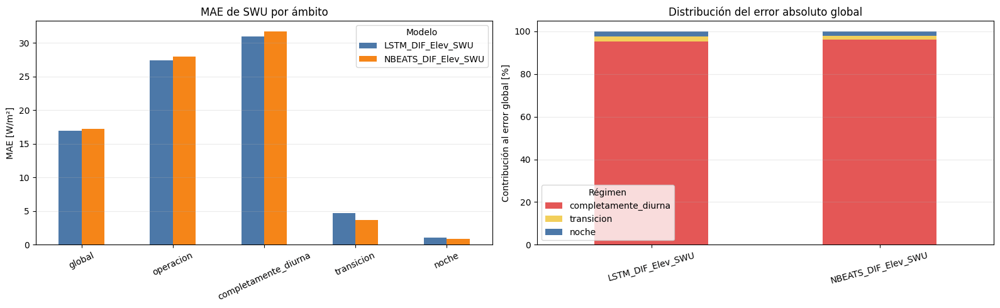


Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/modelado_swu_completo_20261006_173357

No se ha realizado ningún entrenamiento adicional.


In [ ]:
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Comprobaciones
assert "predicciones_validation_swu" in globals(), (
    "No existe predicciones_validation_swu. Ejecuta primero el reentrenamiento completo de SWU."
)
assert "OUT_SWU" in globals(), "No se encuentra la carpeta OUT_SWU."
df_swu = predicciones_validation_swu.copy()
columnas_necesarias = [
    "regimen_solar_objetivo",
    "DIF_observado",
    "pred_NBEATS_SWU",
    "pred_LSTM_SWU",
]
faltantes = [columna for columna in columnas_necesarias if columna not in df_swu.columns]
assert not faltantes, f"Faltan columnas: {faltantes}"


# 2. Normalización de las etiquetas de régimen
def normalizar_texto(valor):
    texto = str(valor).strip().lower()
    texto = "".join(
        caracter
        for caracter in unicodedata.normalize("NFD", texto)
        if unicodedata.category(caracter) != "Mn"
    )
    return texto.replace("-", "_").replace(" ", "_")

df_swu["regimen_normalizado"] = df_swu["regimen_solar_objetivo"].map(normalizar_texto)
print("=== REGÍMENES ORIGINALES ===")
print(df_swu["regimen_solar_objetivo"].value_counts(dropna=False))
print("\n=== REGÍMENES NORMALIZADOS ===")
print(df_swu["regimen_normalizado"].value_counts(dropna=False))


# Identificación robusta de las tres categorías
mask_noche = df_swu["regimen_normalizado"].str.contains("noche", na=False)
mask_transicion = df_swu["regimen_normalizado"].str.contains("transicion", na=False)
mask_diurna = df_swu["regimen_normalizado"].str.contains("completamente", na=False) & df_swu[
    "regimen_normalizado"
].str.contains("diurn", na=False)

# Operación = transición + completamente diurna
mask_operacion = mask_transicion | mask_diurna
mask_asignada = mask_noche | mask_transicion | mask_diurna
if not mask_asignada.all():
    etiquetas_no_reconocidas = df_swu.loc[~mask_asignada, "regimen_solar_objetivo"].value_counts(
        dropna=False
    )
    raise ValueError("Existen regímenes no reconocidos:\n" f"{etiquetas_no_reconocidas}")

assert not (mask_noche & mask_operacion).any(), "La noche no debe estar incluida en operación."
print("\n=== RECUENTO DE ÁMBITOS ===")
print("Global:", len(df_swu))
print("Operación:", int(mask_operacion.sum()))
print("Completamente diurna:", int(mask_diurna.sum()))
print("Transición:", int(mask_transicion.sum()))
print("Noche:", int(mask_noche.sum()))
assert int(mask_operacion.sum()) == (int(mask_diurna.sum()) + int(mask_transicion.sum()))
assert len(df_swu) == (int(mask_operacion.sum()) + int(mask_noche.sum()))


# 3. Función de métricas
def metricas_regimen(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    denominador = np.mean(np.abs(y_real))
    if len(y_real) >= 2 and np.var(y_real) > 0:
        r2 = r2_score(y_real, y_pred)
    else:
        r2 = np.nan

    return {
        "n_observaciones": int(len(y_real)),
        "MAE": float(mae),
        "nMAE_pct": (float(100 * mae / denominador) if denominador != 0 else np.nan),
        "RMSE": float(rmse),
        "R2": float(r2),
        "bias": float(np.mean(y_pred - y_real)),
    }


# 4. Métricas por ámbito
ambitos = {
    "global": np.ones(len(df_swu), dtype=bool),
    "operacion": mask_operacion.to_numpy(),
    "completamente_diurna": mask_diurna.to_numpy(),
    "transicion": mask_transicion.to_numpy(),
    "noche": mask_noche.to_numpy(),
}
modelos = {"NBEATS_DIF_Elev_SWU": "pred_NBEATS_SWU", "LSTM_DIF_Elev_SWU": "pred_LSTM_SWU"}
filas = []
for nombre_modelo, columna_pred in modelos.items():
    for nombre_ambito, mascara in ambitos.items():
        datos = df_swu.loc[mascara]
        resultado = metricas_regimen(datos["DIF_observado"], datos[columna_pred])
        filas.append({"modelo": nombre_modelo, "ambito": nombre_ambito, **resultado})

metricas_swu_regimen = pd.DataFrame(filas)
orden_ambitos = ["global", "operacion", "completamente_diurna", "transicion", "noche"]
metricas_swu_regimen["ambito"] = pd.Categorical(
    metricas_swu_regimen["ambito"], categories=orden_ambitos, ordered=True
)
metricas_swu_regimen = metricas_swu_regimen.sort_values(["modelo", "ambito"]).reset_index(drop=True)
metricas_swu_regimen.to_csv(OUT_SWU / "metricas_validation_swu_por_regimen.csv", index=False)
print("\n=== MÉTRICAS SWU POR ÁMBITO Y RÉGIMEN ===")
display(
    metricas_swu_regimen.style.format(
        {"MAE": "{:.6f}", "nMAE_pct": "{:.6f}", "RMSE": "{:.6f}", "R2": "{:.6f}", "bias": "{:.6f}"}
    )
)


# 5. Comparación directa LSTM frente a N-BEATS
# Valores negativos: LSTM presenta menor error
comparacion_swu = metricas_swu_regimen.pivot(
    index="ambito", columns="modelo", values=["MAE", "RMSE", "R2", "bias"]
)
comparacion_directa = pd.DataFrame({"ambito": orden_ambitos}).set_index("ambito")
comparacion_directa["delta_MAE_LSTM_menos_NBEATS"] = (
    comparacion_swu["MAE"]["LSTM_DIF_Elev_SWU"] - comparacion_swu["MAE"]["NBEATS_DIF_Elev_SWU"]
)
comparacion_directa["delta_RMSE_LSTM_menos_NBEATS"] = (
    comparacion_swu["RMSE"]["LSTM_DIF_Elev_SWU"] - comparacion_swu["RMSE"]["NBEATS_DIF_Elev_SWU"]
)
comparacion_directa["delta_R2_LSTM_menos_NBEATS"] = (
    comparacion_swu["R2"]["LSTM_DIF_Elev_SWU"] - comparacion_swu["R2"]["NBEATS_DIF_Elev_SWU"]
)
comparacion_directa = comparacion_directa.reset_index()
comparacion_directa.to_csv(OUT_SWU / "comparacion_lstm_nbeats_swu_por_regimen.csv", index=False)
print("\n=== LSTM MENOS N-BEATS ===")
print("Delta MAE/RMSE negativo implica menor error de LSTM.")
display(
    comparacion_directa.style.format(
        {
            "delta_MAE_LSTM_menos_NBEATS": "{:+.6f}",
            "delta_RMSE_LSTM_menos_NBEATS": "{:+.6f}",
            "delta_R2_LSTM_menos_NBEATS": "{:+.6f}",
        }
    )
)


# 6. Contribución al error absoluto global
# Se usan solo regímenes mutuamente excluyentes
regimenes_base = {
    "completamente_diurna": mask_diurna.to_numpy(),
    "transicion": mask_transicion.to_numpy(),
    "noche": mask_noche.to_numpy(),
}
filas_contribucion = []
for nombre_modelo, columna_pred in modelos.items():
    error_absoluto_global = np.abs(
        df_swu[columna_pred].to_numpy() - df_swu["DIF_observado"].to_numpy()
    )
    suma_global = error_absoluto_global.sum()
    for regimen, mascara in regimenes_base.items():
        error_regimen = error_absoluto_global[mascara].sum()
        filas_contribucion.append(
            {
                "modelo": nombre_modelo,
                "regimen": regimen,
                "n_observaciones": int(mascara.sum()),
                "suma_error_absoluto": float(error_regimen),
                "contribucion_error_global_pct": float(100 * error_regimen / suma_global),
            }
        )

contribucion_error_swu = pd.DataFrame(filas_contribucion)
contribucion_error_swu.to_csv(OUT_SWU / "contribucion_error_global_swu.csv", index=False)
print("\n=== CONTRIBUCIÓN AL ERROR ABSOLUTO GLOBAL ===")
display(
    contribucion_error_swu.style.format(
        {"suma_error_absoluto": "{:.6f}", "contribucion_error_global_pct": "{:.2f}%"}
    )
)
control_contribucion = contribucion_error_swu.groupby("modelo")[
    "contribucion_error_global_pct"
].sum()
print("\nControl de suma de contribuciones:")
print(control_contribucion)


# 7. Figuras
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# MAE por ámbito
tabla_mae = metricas_swu_regimen.pivot(index="ambito", columns="modelo", values="MAE").reindex(
    orden_ambitos
)
tabla_mae.plot(kind="bar", ax=axes[0], color=["#4C78A8", "#F58518"])
axes[0].set_title("MAE de SWU por ámbito")
axes[0].set_xlabel("")
axes[0].set_ylabel("MAE [W/m²]")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(title="Modelo")

# Contribución al error
tabla_contribucion = contribucion_error_swu.pivot(
    index="modelo", columns="regimen", values="contribucion_error_global_pct"
).reindex(columns=["completamente_diurna", "transicion", "noche"])
tabla_contribucion.plot(
    kind="bar", stacked=True, ax=axes[1], color=["#E45756", "#F2CF5B", "#4C78A8"]
)
axes[1].set_title("Distribución del error absoluto global")
axes[1].set_xlabel("")
axes[1].set_ylabel("Contribución al error global [%]")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(title="Régimen")
plt.tight_layout()
plt.savefig(OUT_SWU / "comparacion_swu_por_regimen.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"\nResultados guardados en:\n{OUT_SWU}")
print("\nNo se ha realizado ningún entrenamiento adicional.")

**Resultados.**

- En operación, la LSTM presenta un MAE de 27,42 W/m² frente a 27,94 W/m² de N-BEATS; en las horas completamente diurnas, 30,95 frente a 31,72 W/m².
- En transición y noche, el MAE de N-BEATS es menor (3,65 y 0,92 W/m²) que el de la LSTM (4,68 y 1,08 W/m²).
- Las horas completamente diurnas concentran el 95,24 % (LSTM) y el 96,17 % (N-BEATS) del error absoluto.

### 6.37 Tabla maestra de modelos por ámbito

Se incorporan los modelos SWU al registro global y todos los modelos se ordenan por MAE en cuatro ámbitos: total de validación, operación, horas completamente diurnas y transición. Los modelos sin métricas por régimen se mantienen en la clasificación total, sin posición en los demás ámbitos.

Comparación global recuperada desde:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas/comparacion_global_modelos_20261006_172035/comparacion_global_modelos.csv
Modelos anteriores: 27

=== CLASIFICACIÓN GLOBAL ACTUALIZADA ===


,posicion_MAE,modelo,familia,variables,MAE,nMAE_pct,RMSE,R2
0,1,LSTM-SWD,LSTM,DIF + elevación + SWD,15.867523,18.616582,32.383934,0.910285
1,2,LSTM-SWD+DIR+FD,LSTM,DIF + elevación + SWD + DIR + FD,15.885435,18.637598,32.348013,0.910484
2,3,LSTM-SWD+FD,LSTM,DIF + elevación + SWD + FD,16.230541,19.042494,32.715553,0.908438
3,4,LSTM-GeomT,LSTM,DIF + elevación histórica + GeomT,16.265980,19.084072,32.285250,0.910831
4,5,LSTM-DIR,LSTM,DIF + elevación + DIR,16.325878,19.154348,32.826323,0.907817
5,6,LSTM-SWD+DIR,LSTM,DIF + elevación + SWD + DIR,16.350744,19.183522,33.400176,0.904566
6,7,HGB-9V,HGB,Elevación + DIF,16.562404,19.431852,33.042724,0.906598
7,8,LSTM-DIF+Elevación,LSTM,DIF + elevación histórica,16.783111,19.690797,33.068067,0.906455
8,9,LSTM-LWU,LSTM,DIF + elevación + LWU,16.840960,19.758667,33.422958,0.904436
9,10,NBEATS-DIF+Elevación,N-BEATS,DIF + elevación histórica,16.883628,19.808729,32.920020,0.907290



CSV candidatos de métricas por régimen: 9

=== RANKING MAE — TOTAL ===


,puesto_MAE,modelo,n_observaciones,MAE,nMAE_pct,RMSE,R2,bias
0,1,LSTM-SWD,1464.000000,15.867523,18.616582,32.383934,0.910285,nan
1,2,LSTM-SWD+DIR+FD,1464.000000,15.885435,18.637598,32.348013,0.910484,nan
2,3,LSTM-SWD+FD,1464.000000,16.230541,19.042494,32.715553,0.908438,nan
3,4,LSTM-GeomT,1464.000000,16.265980,19.084072,32.285250,0.910831,nan
4,5,LSTM-DIR,1464.000000,16.325878,19.154348,32.826323,0.907817,nan
5,6,LSTM-SWD+DIR,1464.000000,16.350744,19.183522,33.400176,0.904566,nan
6,7,HGB-9V,1464.000000,16.562404,19.431852,33.042724,0.906598,nan
7,8,LSTM-DIF+Elevación,1464.000000,16.783111,19.690797,33.068067,0.906455,nan
8,9,LSTM-LWU,1464.000000,16.840960,19.758667,33.422958,0.904436,nan
9,10,NBEATS-DIF+Elevación,1464.000000,16.883628,19.808729,32.920020,0.907290,nan



=== RANKING MAE — OPERACION ===


,puesto_MAE,modelo,n_observaciones,MAE,nMAE_pct,RMSE,R2,bias
0,1,LSTM-SWD,884.000000,26.017927,18.348642,41.671803,0.846092,-1.588530
1,2,HGB-9V,884.000000,27.353409,19.290464,42.521985,0.839748,0.046495
2,3,LSTM-LWU,nan,27.395680,nan,43.004271,0.836092,-0.888516
3,4,LSTM-SWU,884.000000,27.415261,19.332650,42.460865,0.840208,-5.756244
4,5,LSTM-DIF+Elevación,884.000000,27.419652,19.337181,42.550746,0.839531,-1.660616
5,6,NBEATS-DIF+Elevación,884.000000,27.623462,19.480914,42.360924,0.840959,2.876547
6,7,LSTM-LWD,884.000000,27.656408,19.504149,42.904566,0.836851,6.906339
7,8,NBEATS-SWU,884.000000,27.938302,19.701487,42.434650,0.840405,-3.844147
8,9,LSTM-solo DIF,884.000000,28.000364,19.746717,42.547261,0.839557,-1.620577
9,10,NBEATS-solo DIF,884.000000,29.296149,20.660544,43.793165,0.830023,3.093925


... (5 outputs left out)

,modelo,familia,variables,puesto_total,MAE_total,puesto_operacion,MAE_operacion,puesto_completamente_diurno,MAE_completamente_diurno,puesto_transicion,MAE_transicion
0,LSTM-SWD,LSTM,DIF + elevación + SWD,1,15.867523,1,26.017927,1,29.548422,3,3.321888
1,LSTM-SWD+DIR+FD,LSTM,DIF + elevación + SWD + DIR + FD,2,15.885435,,nan,,nan,,nan
2,LSTM-SWD+FD,LSTM,DIF + elevación + SWD + FD,3,16.230541,,nan,,nan,,nan
3,LSTM-GeomT,LSTM,DIF + elevación histórica + GeomT,4,16.265980,,nan,,nan,,nan
4,LSTM-DIR,LSTM,DIF + elevación + DIR,5,16.325878,,nan,,nan,,nan
5,LSTM-SWD+DIR,LSTM,DIF + elevación + SWD + DIR,6,16.350744,,nan,,nan,,nan
6,HGB-9V,HGB,Elevación + DIF,7,16.562404,2,27.353409,5,31.212495,1,2.544995
7,LSTM-DIF+Elevación,LSTM,DIF + elevación histórica,8,16.783111,5,27.419652,4,31.194502,2,3.152761
8,LSTM-LWU,LSTM,DIF + elevación + LWU,9,16.840960,3,27.395680,2,30.761316,10,5.759450
9,NBEATS-DIF+Elevación,N-BEATS,DIF + elevación histórica,10,16.883628,6,27.623462,7,31.369213,5,3.543634



=== MODELOS SIN DESGLOSE COMPLETO POR RÉGIMEN ===


,modelo,MAE_total,MAE_operacion,MAE_completamente_diurno,MAE_transicion
1,LSTM-SWD+DIR+FD,15.885435,NaN,NaN,NaN
2,LSTM-SWD+FD,16.230541,NaN,NaN,NaN
3,LSTM-GeomT,16.265980,NaN,NaN,NaN
4,LSTM-DIR,16.325878,NaN,NaN,NaN
5,LSTM-SWD+DIR,16.350744,NaN,NaN,NaN
11,HGB-8V,17.034000,NaN,NaN,NaN
15,NBEATS-GeomT,17.826234,NaN,NaN,NaN
16,NBEATS-Delta,18.039769,NaN,NaN,NaN
18,NBEATS-SWD+FD,18.468481,NaN,NaN,NaN
19,NBEATS-SWD+DIR,18.595570,NaN,NaN,NaN



Estos modelos permanecen correctamente en el ranking global, pero no deben compararse en los ámbitos cuyos valores estén vacíos.


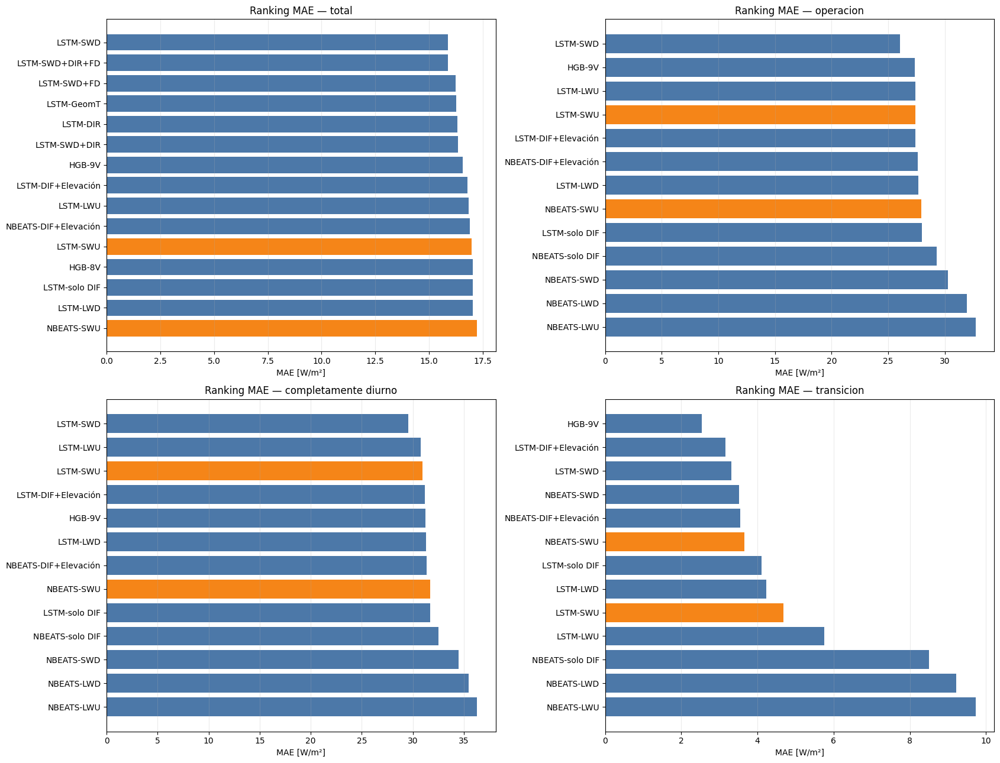


Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas/ranking_modelos_por_ambito_20261006_174709


In [ ]:
from datetime import datetime
from pathlib import Path
import re
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Rutas
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RESULTADOS_DIR = BASE_DIR / "resultados"
COMPARATIVAS_DIR = RESULTADOS_DIR / "comparativas"
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_RANKING = COMPARATIVAS_DIR / f"ranking_modelos_por_ambito_{timestamp}"
OUT_RANKING.mkdir(parents=True, exist_ok=True)


# 2. Funciones de normalización
def normalizar_texto(valor):
    texto = str(valor).strip().lower()
    texto = "".join(
        caracter
        for caracter in unicodedata.normalize("NFD", texto)
        if unicodedata.category(caracter) != "Mn"
    )
    return re.sub(r"[^a-z0-9]+", "_", texto).strip("_")

def normalizar_ambito(valor):
    texto = normalizar_texto(valor)
    if texto in {"total", "global"}:
        return "total"

    if "oper" in texto:
        return "operacion"

    if "completamente" in texto and "diurn" in texto:
        return "completamente_diurno"

    if "transicion" in texto:
        return "transicion"

    if "noche" in texto:
        return "noche"

    return None

def normalizar_modelo(nombre):
    texto = normalizar_texto(nombre)
    arquitectura = None
    if "nbeats" in texto or "n_beats" in texto:
        arquitectura = "NBEATS"
    elif "lstm" in texto:
        arquitectura = "LSTM"

    if arquitectura is not None:
        if "swu" in texto:
            return f"{arquitectura}-SWU"

        if "lwu" in texto:
            return f"{arquitectura}-LWU"

        if "lwd" in texto:
            return f"{arquitectura}-LWD"

        if "geom" in texto:
            return f"{arquitectura}-GeomT"

        if "delta" in texto:
            return f"{arquitectura}-Delta"

        tiene_swd = "swd" in texto
        tiene_dir = "dir" in texto
        tiene_fd = "_fd" in f"_{texto}" or "fraccion_difusa" in texto
        if tiene_swd and tiene_dir and tiene_fd:
            return f"{arquitectura}-SWD+DIR+FD"

        if tiene_swd and tiene_dir:
            return f"{arquitectura}-SWD+DIR"

        if tiene_swd and tiene_fd:
            return f"{arquitectura}-SWD+FD"

        if tiene_swd:
            return f"{arquitectura}-SWD"

        if tiene_dir:
            return f"{arquitectura}-DIR"

        if "elev" in texto:
            return f"{arquitectura}-DIF+Elevación"

        if "dif" in texto:
            return f"{arquitectura}-solo DIF"

    if "hgb" in texto and "9v" in texto:
        return "HGB-9V"

    if "hgb" in texto and "8v" in texto:
        return "HGB-8V"

    if texto in {"ridge_g0", "ridgeg0"}:
        return "Ridge G0"

    if "persistencia" in texto and "hibrid" in texto:
        return "Persistencia híbrida"

    if "persistencia" in texto and "inmediata" in texto:
        return "Persistencia inmediata"

    if "persistencia" in texto and "diaria" in texto:
        return "Persistencia diaria"

    return str(nombre).strip()

def buscar_columna(columnas, candidatos):
    mapa = {normalizar_texto(columna): columna for columna in columnas}
    for candidato in candidatos:
        candidato_normalizado = normalizar_texto(candidato)
        if candidato_normalizado in mapa:
            return mapa[candidato_normalizado]

    return None


# 3. Cargar la comparación global más reciente
archivos_globales = list(COMPARATIVAS_DIR.rglob("comparacion_global_modelos.csv"))
assert archivos_globales, (
    "No se encontró comparacion_global_modelos.csv dentro de resultados/comparativas."
)
archivo_global = max(archivos_globales, key=lambda ruta: ruta.stat().st_mtime)
tabla_global = pd.read_csv(archivo_global, encoding="utf-8-sig")
tabla_global["modelo"] = tabla_global["modelo"].map(normalizar_modelo)
print("Comparación global recuperada desde:")
print(archivo_global)
print("Modelos anteriores:", len(tabla_global))


# 4. Incorporar los dos modelos SWU
if "metricas_swu_regimen" in globals():
    metricas_swu_fuente = metricas_swu_regimen.copy()
else:
    archivos_swu = list(RESULTADOS_DIR.rglob("metricas_validation_swu_por_regimen.csv"))
    assert archivos_swu, "No se encontró metricas_validation_swu_por_regimen.csv."
    archivo_swu = max(archivos_swu, key=lambda ruta: ruta.stat().st_mtime)
    metricas_swu_fuente = pd.read_csv(archivo_swu)

metricas_swu_fuente["ambito_normalizado"] = (
    metricas_swu_fuente["ambito"].astype(str).map(normalizar_ambito)
)
swu_global = metricas_swu_fuente.loc[metricas_swu_fuente["ambito_normalizado"] == "total"].copy()
swu_global["modelo_normalizado"] = swu_global["modelo"].map(normalizar_modelo)

# Evitar duplicados si se vuelve a ejecutar la celda
tabla_global = tabla_global.loc[~tabla_global["modelo"].isin(["NBEATS-SWU", "LSTM-SWU"])].copy()
filas_swu_global = []
for _, fila in swu_global.iterrows():
    modelo = fila["modelo_normalizado"]
    familia = "LSTM" if modelo.startswith("LSTM") else "N-BEATS"
    filas_swu_global.append(
        {
            "posicion_MAE": np.nan,
            "modelo": modelo,
            "familia": familia,
            "variables": "DIF + elevación + SWU",
            "MAE": float(fila["MAE"]),
            "RMSE": float(fila["RMSE"]),
            "R2": float(fila["R2"]),
            "nMAE_pct": float(fila["nMAE_pct"]),
            "rank_MAE": np.nan,
            "rank_RMSE": np.nan,
            "rank_R2": np.nan,
            "candidato_preliminar": False,
        }
    )

tabla_global = pd.concat([tabla_global, pd.DataFrame(filas_swu_global)], ignore_index=True)
tabla_global["rank_MAE"] = tabla_global["MAE"].rank(method="min", ascending=True).astype("Int64")
tabla_global["rank_RMSE"] = tabla_global["RMSE"].rank(method="min", ascending=True).astype("Int64")
tabla_global["rank_R2"] = tabla_global["R2"].rank(method="min", ascending=False).astype("Int64")
tabla_global = tabla_global.sort_values(
    ["MAE", "RMSE", "modelo"], ascending=[True, True, True]
).reset_index(drop=True)
tabla_global["posicion_MAE"] = np.arange(1, len(tabla_global) + 1)
tabla_global.to_csv(OUT_RANKING / "comparacion_global_modelos_actualizada.csv", index=False)
print("\n=== CLASIFICACIÓN GLOBAL ACTUALIZADA ===")
display(
    tabla_global[
        ["posicion_MAE", "modelo", "familia", "variables", "MAE", "nMAE_pct", "RMSE", "R2"]
    ].style.format({"MAE": "{:.6f}", "nMAE_pct": "{:.6f}", "RMSE": "{:.6f}", "R2": "{:.6f}"})
)


# 5. Recuperar todos los CSV de métricas por régimen
archivos_regimen = set()
for patron in ["*regimen*.csv", "*ambito*.csv"]:
    archivos_regimen.update(BASE_DIR.rglob(patron))

print("\nCSV candidatos de métricas por régimen:", len(archivos_regimen))
filas_regimen = []
for archivo in sorted(archivos_regimen):
    try:
        tabla = pd.read_csv(archivo, encoding="utf-8-sig")
    except Exception:
        continue

    columna_modelo = buscar_columna(tabla.columns, ["modelo", "model"])
    columna_ambito = buscar_columna(tabla.columns, ["ambito", "regimen", "ámbito", "régimen"])
    columna_mae = buscar_columna(tabla.columns, ["MAE"])
    if columna_modelo is None or columna_ambito is None or columna_mae is None:
        continue

    columna_n = buscar_columna(tabla.columns, ["n_observaciones", "n", "numero_observaciones"])
    columna_nmae = buscar_columna(tabla.columns, ["nMAE_pct", "nMAE_porcentaje", "nMAE"])
    columna_rmse = buscar_columna(tabla.columns, ["RMSE"])
    columna_r2 = buscar_columna(tabla.columns, ["R2", "R²"])
    columna_bias = buscar_columna(tabla.columns, ["bias", "sesgo_pred_menos_real", "sesgo"])
    for _, fila in tabla.iterrows():
        ambito = normalizar_ambito(fila[columna_ambito])
        if ambito is None:
            continue

        try:
            mae = float(fila[columna_mae])
        except (TypeError, ValueError):
            continue

        filas_regimen.append(
            {
                "modelo": normalizar_modelo(fila[columna_modelo]),
                "ambito": ambito,
                "n_observaciones": (
                    pd.to_numeric(fila[columna_n], errors="coerce")
                    if columna_n is not None
                    else np.nan
                ),
                "MAE": mae,
                "nMAE_pct": (
                    pd.to_numeric(fila[columna_nmae], errors="coerce")
                    if columna_nmae is not None
                    else np.nan
                ),
                "RMSE": (
                    pd.to_numeric(fila[columna_rmse], errors="coerce")
                    if columna_rmse is not None
                    else np.nan
                ),
                "R2": (
                    pd.to_numeric(fila[columna_r2], errors="coerce")
                    if columna_r2 is not None
                    else np.nan
                ),
                "bias": (
                    pd.to_numeric(fila[columna_bias], errors="coerce")
                    if columna_bias is not None
                    else np.nan
                ),
                "fuente": str(archivo),
                "prioridad": archivo.stat().st_mtime,
            }
        )


# 6. Añadir en memoria el resultado SWU como fuente prioritaria
for _, fila in metricas_swu_fuente.iterrows():
    ambito = normalizar_ambito(fila["ambito"])
    if ambito is None:
        continue

    filas_regimen.append(
        {
            "modelo": normalizar_modelo(fila["modelo"]),
            "ambito": ambito,
            "n_observaciones": fila.get("n_observaciones", np.nan),
            "MAE": fila["MAE"],
            "nMAE_pct": fila.get("nMAE_pct", np.nan),
            "RMSE": fila.get("RMSE", np.nan),
            "R2": fila.get("R2", np.nan),
            "bias": fila.get("bias", np.nan),
            "fuente": "memoria_actual_swu",
            "prioridad": 1e30,
        }
    )

metricas_regimen_disponibles = pd.DataFrame(filas_regimen)
assert not metricas_regimen_disponibles.empty, "No se recuperaron métricas por régimen."

# Si un modelo y ámbito aparecen varias veces, conservar
# el resultado procedente de la fuente más reciente.
metricas_regimen_disponibles = (
    metricas_regimen_disponibles.sort_values("prioridad")
    .drop_duplicates(subset=["modelo", "ambito"], keep="last")
    .reset_index(drop=True)
)


# 7. El total se toma de la tabla global maestra
metricas_total = tabla_global[["modelo", "MAE", "nMAE_pct", "RMSE", "R2"]].copy()
metricas_total["ambito"] = "total"
metricas_total["n_observaciones"] = 1464
metricas_total["bias"] = np.nan
metricas_total["fuente"] = str(archivo_global)
metricas_otros_ambitos = metricas_regimen_disponibles.loc[
    metricas_regimen_disponibles["ambito"].isin(
        ["operacion", "completamente_diurno", "transicion"]
    ),
    ["modelo", "ambito", "n_observaciones", "MAE", "nMAE_pct", "RMSE", "R2", "bias", "fuente"],
]
metricas_por_ambito = pd.concat([metricas_total, metricas_otros_ambitos], ignore_index=True)
orden_ambitos = ["total", "operacion", "completamente_diurno", "transicion"]
metricas_por_ambito["ambito"] = pd.Categorical(
    metricas_por_ambito["ambito"], categories=orden_ambitos, ordered=True
)
metricas_por_ambito["puesto_MAE"] = (
    metricas_por_ambito.groupby("ambito", observed=True)["MAE"]
    .rank(method="min", ascending=True)
    .astype("Int64")
)
metricas_por_ambito = metricas_por_ambito.sort_values(
    ["ambito", "puesto_MAE", "modelo"]
).reset_index(drop=True)
metricas_por_ambito.to_csv(OUT_RANKING / "metricas_modelos_por_ambito.csv", index=False)


# 8. Guardar y mostrar cada ranking
rankings = {}
for ambito in orden_ambitos:
    ranking = (
        metricas_por_ambito.loc[
            metricas_por_ambito["ambito"] == ambito,
            ["puesto_MAE", "modelo", "n_observaciones", "MAE", "nMAE_pct", "RMSE", "R2", "bias"],
        ]
        .sort_values("puesto_MAE")
        .reset_index(drop=True)
    )
    rankings[ambito] = ranking
    ranking.to_csv(OUT_RANKING / f"ranking_mae_{ambito}.csv", index=False)
    print(f"\n=== RANKING MAE — {ambito.upper()} ===")
    display(
        ranking.style.format(
            {
                "MAE": "{:.6f}",
                "nMAE_pct": "{:.6f}",
                "RMSE": "{:.6f}",
                "R2": "{:.6f}",
                "bias": "{:.6f}",
            }
        )
    )


# 9. Tabla compacta para la toma de decisiones
tabla_mae_ancha = metricas_por_ambito.pivot(index="modelo", columns="ambito", values="MAE")
tabla_puesto_ancha = metricas_por_ambito.pivot(
    index="modelo", columns="ambito", values="puesto_MAE"
)
tabla_decision = pd.DataFrame(index=tabla_global["modelo"])
for ambito in orden_ambitos:
    tabla_decision[f"puesto_{ambito}"] = tabla_puesto_ancha.get(ambito)
    tabla_decision[f"MAE_{ambito}"] = tabla_mae_ancha.get(ambito)

tabla_decision = tabla_decision.reset_index()
tabla_decision = tabla_decision.merge(
    tabla_global[["modelo", "familia", "variables"]], on="modelo", how="left"
)
columnas_decision = [
    "modelo",
    "familia",
    "variables",
    "puesto_total",
    "MAE_total",
    "puesto_operacion",
    "MAE_operacion",
    "puesto_completamente_diurno",
    "MAE_completamente_diurno",
    "puesto_transicion",
    "MAE_transicion",
]
tabla_decision = (
    tabla_decision[columnas_decision]
    .sort_values(["puesto_total", "modelo"], na_position="last")
    .reset_index(drop=True)
)
for columna in [
    "puesto_total",
    "puesto_operacion",
    "puesto_completamente_diurno",
    "puesto_transicion",
]:
    tabla_decision[columna] = tabla_decision[columna].astype("Int64")

tabla_decision.to_csv(OUT_RANKING / "tabla_decision_mae_por_ambito.csv", index=False)
print("\n=== TABLA MAESTRA PARA LA TOMA DE DECISIONES ===")
display(
    tabla_decision.style.format(
        {
            "MAE_total": "{:.6f}",
            "MAE_operacion": "{:.6f}",
            "MAE_completamente_diurno": "{:.6f}",
            "MAE_transicion": "{:.6f}",
        }
    )
)


# 10. Informar de los modelos sin desglose completo
columnas_desglose = ["MAE_operacion", "MAE_completamente_diurno", "MAE_transicion"]
modelos_sin_desglose = tabla_decision.loc[
    tabla_decision[columnas_desglose].isna().any(axis=1),
    ["modelo", "MAE_total", *columnas_desglose],
]
print("\n=== MODELOS SIN DESGLOSE COMPLETO POR RÉGIMEN ===")
if modelos_sin_desglose.empty:
    print("Todos los modelos tienen los cuatro ámbitos evaluados.")
else:
    display(modelos_sin_desglose)
    print(
        "\nEstos modelos permanecen correctamente en el ranking global, "
        "pero no deben compararse en los ámbitos cuyos valores estén vacíos."
    )


# 11. Figura de los cuatro rankings
fig, axes = plt.subplots(2, 2, figsize=(17, 13))
axes = axes.ravel()
for ax, ambito in zip(axes, orden_ambitos):
    ranking = rankings[ambito].copy()

    # Máximo 15 modelos por panel para conservar legibilidad
    ranking_figura = ranking.head(15).sort_values("MAE", ascending=False)
    colores = ["#F58518" if "SWU" in modelo else "#4C78A8" for modelo in ranking_figura["modelo"]]
    ax.barh(ranking_figura["modelo"], ranking_figura["MAE"], color=colores)
    ax.set_title(f"Ranking MAE — {ambito.replace('_', ' ')}")
    ax.set_xlabel("MAE [W/m²]")
    ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig(OUT_RANKING / "rankings_mae_por_ambito.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"\nResultados guardados en:\n{OUT_RANKING}")

**Resultados.** En la clasificación total, `LSTM-SWU` ocupa el puesto 11 (MAE de 16,98 W/m²) y `NBEATS-SWU` el 15 (17,23 W/m²), de 29 modelos. `LSTM-SWD` mantiene el primer puesto (15,87 W/m²), seguida de `LSTM-SWD+DIR+FD` (15,89 W/m²), y encabeza también operación y horas completamente diurnas; en transición, el primer puesto corresponde a `HGB-9V` (HGB de 9 variables con pérdida absoluta).

### 6.38 Preparación del bloque de estadísticos históricos de la DIF

Se amplía el modelo base de DIF y elevación solar con dos estadísticos horarios de la propia DIF: la media horaria de su desviación estándar intraminutal (`DIF_std`) y su rango horario (`DIF_rango`). Se construyen matrices de cuatro canales sobre ventanas de 24 horas y se comprueban la disponibilidad y la alineación temporal.

> *Se utiliza en la memoria: LSTM-DIFstats con una semilla (25,70 W/m² en horas con sol) y primera N-BEATS, entrenada 18 épocas (apartado 5.3.1).*

In [ ]:
import json
import unicodedata
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd

# 1. Rutas
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
PARQUET_ORIGINAL = BASE_DIR / "radiation_data_completo.parquet"
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_PREPARACION_DIFSTATS = (
    BASE_DIR / "resultados" / "ejecuciones" / f"preparacion_bloque_difstats_{timestamp}"
)
OUT_PREPARACION_DIFSTATS.mkdir(parents=True, exist_ok=True)


# 2. Comprobar objetos necesarios
assert "train_hgb" in globals(), "No existe train_hgb."
assert "validation_hgb" in globals(), "No existe validation_hgb."
columnas_hgb_necesarias = [
    "instante_objetivo",
    "DIF_objetivo_t1",
    "DIF_lag_24",
    "DIF_lag_1",
    "elevacion_media_lag24",
    "elevacion_media_lag1",
]
for columna in columnas_hgb_necesarias:
    assert columna in train_hgb.columns, f"Falta {columna} en train_hgb."
    assert columna in validation_hgb.columns, f"Falta {columna} en validation_hgb."


# 3. Recuperar una matriz base DIF + elevación validada
candidatos_base = [
    ("X_train_DIF_elev_SWD_raw", "X_validation_DIF_elev_SWD_raw"),
    ("X_train_DIF_elev_SWU_raw", "X_validation_DIF_elev_SWU_raw"),
    ("X_train_DIF_elev_LWU_raw", "X_validation_DIF_elev_LWU_raw"),
    ("X_train_DIF_elev_LWD_raw", "X_validation_DIF_elev_LWD_raw"),
    ("X_train_DIF_elev_DIR_raw", "X_validation_DIF_elev_DIR_raw"),
]
nombre_train_base = None
nombre_validation_base = None
for candidato_train, candidato_validation in candidatos_base:
    if candidato_train in globals() and candidato_validation in globals():
        nombre_train_base = candidato_train
        nombre_validation_base = candidato_validation
        break

assert nombre_train_base is not None, (
    "No se encontró una matriz histórica validada "
    "con DIF y elevación en sus dos primeros canales."
)
X_train_base = np.asarray(globals()[nombre_train_base], dtype=np.float32)
X_validation_base = np.asarray(globals()[nombre_validation_base], dtype=np.float32)
assert X_train_base.shape[0:2] == (5149, 24), f"Forma inesperada en train: {X_train_base.shape}"
assert X_validation_base.shape[0:2] == (1464, 24), (
    f"Forma inesperada en validation: " f"{X_validation_base.shape}"
)
assert X_train_base.shape[2] >= 2
assert X_validation_base.shape[2] >= 2
print("Matriz base utilizada:", nombre_train_base)
print("Canales reutilizados: 0 = DIF; 1 = elevación")


# 4. Fechas y objetivos
def preparar_fechas_objetivo(serie, nombre):
    fechas = pd.to_datetime(serie, errors="raise")

    # Se mantiene la hora registrada y se elimina únicamente
    # la información de zona horaria.
    if getattr(fechas.dt, "tz", None) is not None:
        print(f"Zona horaria detectada en {nombre}:", fechas.dt.tz)
        fechas = fechas.dt.tz_localize(None)

    return fechas.reset_index(drop=True)

fechas_train_difstats = preparar_fechas_objetivo(train_hgb["instante_objetivo"], "train")
fechas_validation_difstats = preparar_fechas_objetivo(
    validation_hgb["instante_objetivo"], "validation"
)
y_train_difstats = pd.to_numeric(train_hgb["DIF_objetivo_t1"], errors="raise").to_numpy(
    dtype=np.float32
)
y_validation_difstats = pd.to_numeric(validation_hgb["DIF_objetivo_t1"], errors="raise").to_numpy(
    dtype=np.float32
)


# Tamaños
assert len(fechas_train_difstats) == 5149
assert len(fechas_validation_difstats) == 1464
assert len(y_train_difstats) == 5149
assert len(y_validation_difstats) == 1464


# Orden y duplicados
assert fechas_train_difstats.is_monotonic_increasing, "Las fechas de train no están ordenadas."
assert (
    fechas_validation_difstats.is_monotonic_increasing
), "Las fechas de validation no están ordenadas."
assert not fechas_train_difstats.duplicated().any(), "Existen fechas objetivo duplicadas en train."
assert (
    not fechas_validation_difstats.duplicated().any()
), "Existen fechas objetivo duplicadas en validation."


# Diagnóstico informativo de saltos
saltos_train = fechas_train_difstats.diff()
saltos_validation = fechas_validation_difstats.diff()
saltos_no_horarios_train = saltos_train[
    saltos_train.notna() & saltos_train.ne(pd.Timedelta(hours=1))
]
saltos_no_horarios_validation = saltos_validation[
    saltos_validation.notna() & saltos_validation.ne(pd.Timedelta(hours=1))
]
print("\n=== FECHAS REALES CONFIRMADAS ===")
print(
    "Train:",
    fechas_train_difstats.iloc[0],
    "→",
    fechas_train_difstats.iloc[-1],
    "| observaciones:",
    len(fechas_train_difstats),
)
print(
    "Validation:",
    fechas_validation_difstats.iloc[0],
    "→",
    fechas_validation_difstats.iloc[-1],
    "| observaciones:",
    len(fechas_validation_difstats),
)
print("Saltos no horarios en train:", len(saltos_no_horarios_train))
print("Saltos no horarios en validation:", len(saltos_no_horarios_validation))
if len(saltos_no_horarios_train) > 0:
    print("Los saltos de train proceden del filtrado previo de las observaciones modelables.")

diagnostico_saltos = pd.DataFrame(
    {
        "particion": (
            ["train"] * len(saltos_no_horarios_train)
            + ["validation"] * len(saltos_no_horarios_validation)
        ),
        "indice_fila": (
            saltos_no_horarios_train.index.tolist() + saltos_no_horarios_validation.index.tolist()
        ),
        "duracion_salto": (
            saltos_no_horarios_train.astype(str).tolist()
            + saltos_no_horarios_validation.astype(str).tolist()
        ),
    }
)
diagnostico_saltos.to_csv(
    OUT_PREPARACION_DIFSTATS / "diagnostico_saltos_fechas_objetivo.csv", index=False
)


# 5. Validar el orden temporal de la matriz base

# Primera posición de la ventana = t-24
assert np.allclose(
    X_train_base[:, 0, 0], train_hgb["DIF_lag_24"].to_numpy(dtype=np.float32), equal_nan=True
), ("El primer paso del canal DIF no coincide con DIF_lag_24.")

# Última posición de la ventana = t-1
assert np.allclose(
    X_train_base[:, -1, 0], train_hgb["DIF_lag_1"].to_numpy(dtype=np.float32), equal_nan=True
), ("El último paso del canal DIF no coincide con DIF_lag_1.")
assert np.allclose(
    X_train_base[:, 0, 1],
    train_hgb["elevacion_media_lag24"].to_numpy(dtype=np.float32),
    equal_nan=True,
), ("El primer paso del canal elevación no coincide con elevacion_media_lag24.")
assert np.allclose(
    X_train_base[:, -1, 1],
    train_hgb["elevacion_media_lag1"].to_numpy(dtype=np.float32),
    equal_nan=True,
), ("El último paso del canal elevación no coincide con elevacion_media_lag1.")
assert np.allclose(
    X_validation_base[:, 0, 0],
    validation_hgb["DIF_lag_24"].to_numpy(dtype=np.float32),
    equal_nan=True,
)
assert np.allclose(
    X_validation_base[:, -1, 0],
    validation_hgb["DIF_lag_1"].to_numpy(dtype=np.float32),
    equal_nan=True,
)
assert np.allclose(
    X_validation_base[:, 0, 1],
    validation_hgb["elevacion_media_lag24"].to_numpy(dtype=np.float32),
    equal_nan=True,
)
assert np.allclose(
    X_validation_base[:, -1, 1],
    validation_hgb["elevacion_media_lag1"].to_numpy(dtype=np.float32),
    equal_nan=True,
)
print("\nOrden temporal confirmado: t-24, ..., t-1")


# 6. Cargar el parquet original
assert PARQUET_ORIGINAL.exists(), f"No existe el parquet:\n{PARQUET_ORIGINAL}"
datos_dif_originales = pd.read_parquet(PARQUET_ORIGINAL)
print("\nParquet cargado:", PARQUET_ORIGINAL)
print("Forma original:", datos_dif_originales.shape)


# 7. Identificar la columna temporal
candidatos_fecha = [
    "Date/Time",
    "TIMESTAMP",
    "timestamp",
    "datetime",
    "DateTime",
    "fecha_hora",
    "fecha",
    "instante",
]
columna_fecha = next(
    (columna for columna in candidatos_fecha if columna in datos_dif_originales.columns), None
)
datos_dif_originales = datos_dif_originales.copy()
if columna_fecha is not None:
    datos_dif_originales["_instante_aux"] = pd.to_datetime(
        datos_dif_originales[columna_fecha], errors="coerce"
    )

elif isinstance(datos_dif_originales.index, pd.DatetimeIndex):
    datos_dif_originales["_instante_aux"] = pd.DatetimeIndex(datos_dif_originales.index)

else:
    raise KeyError(
        "No se encontró una columna temporal reconocible. "
        f"Columnas disponibles:\n"
        f"{datos_dif_originales.columns.tolist()}"
    )

n_fechas_invalidas = int(datos_dif_originales["_instante_aux"].isna().sum())
assert n_fechas_invalidas == 0, (
    f"Se encontraron {n_fechas_invalidas} " "fechas no válidas en el parquet."
)
if datos_dif_originales["_instante_aux"].dt.tz is not None:
    print("Zona horaria del parquet:", datos_dif_originales["_instante_aux"].dt.tz)
    datos_dif_originales["_instante_aux"] = datos_dif_originales["_instante_aux"].dt.tz_localize(
        None
    )

datos_dif_originales = datos_dif_originales.sort_values("_instante_aux").set_index("_instante_aux")
print("Columna temporal utilizada:", columna_fecha or "índice temporal")


# 8. Comprobar nombres exactos de las variables
COL_DIF_MEDIA = "DIF [W/m**2]"
COL_DIF_MAX = "DIF max [W/m**2]"
COL_DIF_MIN = "DIF min [W/m**2]"
COL_DIF_STD = "DIF std dev [W/m**2]"
columnas_dif_necesarias = [COL_DIF_MEDIA, COL_DIF_MAX, COL_DIF_MIN, COL_DIF_STD]
columnas_ausentes = [
    columna for columna in columnas_dif_necesarias if columna not in datos_dif_originales.columns
]
if columnas_ausentes:
    columnas_relacionadas = [
        columna for columna in datos_dif_originales.columns if "dif" in str(columna).lower()
    ]
    raise KeyError(
        f"Faltan columnas DIF: {columnas_ausentes}\n"
        f"Columnas DIF encontradas: "
        f"{columnas_relacionadas}"
    )

for columna in columnas_dif_necesarias:
    datos_dif_originales[columna] = pd.to_numeric(datos_dif_originales[columna], errors="coerce")

print("\nColumnas DIF confirmadas:")
for columna in columnas_dif_necesarias:
    print("-", columna)


# 9. Construir los estadísticos horarios
dif_horario = pd.DataFrame(
    {
        "n_observaciones_DIF": (datos_dif_originales[COL_DIF_MEDIA].resample("h").count()),
        # Media horaria del estadístico minutal
        "DIF_std": (datos_dif_originales[COL_DIF_STD].resample("h").mean()),
        # Máximo horario de DIF max menos mínimo de DIF min
        "DIF_rango": (
            datos_dif_originales[COL_DIF_MAX].resample("h").max()
            - datos_dif_originales[COL_DIF_MIN].resample("h").min()
        ),
    }
)
dif_horario.index.name = "instante_historico"
print("\n=== ESTADÍSTICOS HORARIOS CREADOS ===")
print("DIF_std = media horaria de " f"`{COL_DIF_STD}`")
print(
    "DIF_rango = máximo horario de " f"`{COL_DIF_MAX}` menos mínimo horario de " f"`{COL_DIF_MIN}`"
)


# 10. Crear los índices históricos de cada muestra
def crear_indices_historicos(fechas_objetivo):
    fechas = fechas_objetivo.to_numpy(dtype="datetime64[ns]")

    # 24 posiciones: t-24, t-23, ..., t-1
    retardos_horas = np.arange(24, 0, -1)
    retardos = retardos_horas.astype("timedelta64[h]")
    return fechas[:, None] - retardos[None, :]

indices_train = crear_indices_historicos(fechas_train_difstats)
indices_validation = crear_indices_historicos(fechas_validation_difstats)
assert indices_train.shape == (5149, 24)
assert indices_validation.shape == (1464, 24)


# 11. Horas realmente necesarias
horas_train_necesarias = pd.DatetimeIndex(np.unique(indices_train.reshape(-1)))
horas_validation_necesarias = pd.DatetimeIndex(np.unique(indices_validation.reshape(-1)))
horas_totales_necesarias = horas_train_necesarias.union(horas_validation_necesarias)
diagnostico_difstats = dif_horario.reindex(horas_totales_necesarias).copy()
diagnostico_difstats["hora_completamente_vacia"] = (
    diagnostico_difstats["n_observaciones_DIF"].fillna(0).eq(0)
)
diagnostico_difstats["hora_parcial_1_29"] = diagnostico_difstats["n_observaciones_DIF"].between(
    1, 29
)
diagnostico_difstats["algun_estadistico_nulo"] = (
    diagnostico_difstats[["DIF_std", "DIF_rango"]].isna().any(axis=1)
)
print("\n=== DISPONIBILIDAD EN TODAS LAS VENTANAS ===")
print("Horas requeridas:", len(diagnostico_difstats))
print("Completamente vacías:", int(diagnostico_difstats["hora_completamente_vacia"].sum()))
print("Con 1–29 observaciones:", int(diagnostico_difstats["hora_parcial_1_29"].sum()))
print("Con algún estadístico nulo:", int(diagnostico_difstats["algun_estadistico_nulo"].sum()))


# 12. Disponibilidad separada por partición
def resumen_particion(nombre, horas):
    tabla = dif_horario.reindex(horas)
    return {
        "particion": nombre,
        "horas_requeridas": int(len(horas)),
        "inicio": horas.min(),
        "fin": horas.max(),
        "horas_vacias": int(tabla["n_observaciones_DIF"].fillna(0).eq(0).sum()),
        "horas_parciales_1_29": int(tabla["n_observaciones_DIF"].between(1, 29).sum()),
        "horas_con_nulos": int(tabla[["DIF_std", "DIF_rango"]].isna().any(axis=1).sum()),
    }

resumen_disponibilidad = pd.DataFrame(
    [
        resumen_particion("train", horas_train_necesarias),
        resumen_particion("validation", horas_validation_necesarias),
    ]
)
print("\n=== DISPONIBILIDAD POR PARTICIÓN ===")
display(resumen_disponibilidad)


# 13. Mostrar horas problemáticas
horas_problematicas = diagnostico_difstats.loc[
    diagnostico_difstats[
        ["hora_completamente_vacia", "hora_parcial_1_29", "algun_estadistico_nulo"]
    ].any(axis=1)
].copy()
print("\n=== HORAS PROBLEMÁTICAS ===")
if horas_problematicas.empty:
    print("No existen horas problemáticas.")
else:
    display(horas_problematicas)


# No se aplica imputación automática
n_horas_nulas = int(diagnostico_difstats["algun_estadistico_nulo"].sum())
assert n_horas_nulas == 0, (
    f"Existen {n_horas_nulas} horas con DIF_std "
    "o DIF_rango nulos. No se ha aplicado imputación. "
    "Debemos revisarlas antes de entrenar."
)


# 14. Extraer los estadísticos para cada ventana
def extraer_estadisticos(indices_historicos):
    indice_plano = pd.DatetimeIndex(indices_historicos.reshape(-1))
    valores = dif_horario.reindex(indice_plano)[["DIF_std", "DIF_rango"]].to_numpy(dtype=np.float32)
    return valores.reshape(indices_historicos.shape[0], indices_historicos.shape[1], 2)

estadisticos_train = extraer_estadisticos(indices_train)
estadisticos_validation = extraer_estadisticos(indices_validation)
assert estadisticos_train.shape == (5149, 24, 2)
assert estadisticos_validation.shape == (1464, 24, 2)


# 15. Construcción de las matrices finales
X_train_DIF_elev_DIFstats_raw = np.concatenate(
    [X_train_base[:, :, :2], estadisticos_train], axis=2
).astype(np.float32)
X_validation_DIF_elev_DIFstats_raw = np.concatenate(
    [X_validation_base[:, :, :2], estadisticos_validation], axis=2
).astype(np.float32)


# 16. Comprobaciones finales
assert X_train_DIF_elev_DIFstats_raw.shape == (5149, 24, 4)
assert X_validation_DIF_elev_DIFstats_raw.shape == (1464, 24, 4)
assert np.isfinite(X_train_DIF_elev_DIFstats_raw).all(), "La matriz train contiene NaN o infinitos."
assert np.isfinite(
    X_validation_DIF_elev_DIFstats_raw
).all(), "La matriz validation contiene NaN o infinitos."
assert np.isfinite(y_train_difstats).all()
assert np.isfinite(y_validation_difstats).all()


# Los canales DIF y elevación deben permanecer intactos
assert np.array_equal(X_train_DIF_elev_DIFstats_raw[:, :, :2], X_train_base[:, :, :2])
assert np.array_equal(X_validation_DIF_elev_DIFstats_raw[:, :, :2], X_validation_base[:, :, :2])


# 17. Guardado persistente
np.savez_compressed(
    OUT_PREPARACION_DIFSTATS / "matrices_dif_elev_difstats.npz",
    X_train_DIF_elev_DIFstats_raw=(X_train_DIF_elev_DIFstats_raw),
    X_validation_DIF_elev_DIFstats_raw=(X_validation_DIF_elev_DIFstats_raw),
    y_train_difstats=y_train_difstats,
    y_validation_difstats=(y_validation_difstats),
    fechas_train=(fechas_train_difstats.to_numpy(dtype="datetime64[ns]")),
    fechas_validation=(fechas_validation_difstats.to_numpy(dtype="datetime64[ns]")),
)
dif_horario.to_csv(OUT_PREPARACION_DIFSTATS / "estadisticos_dif_horarios.csv")
diagnostico_difstats.to_csv(OUT_PREPARACION_DIFSTATS / "diagnostico_disponibilidad_difstats.csv")
resumen_disponibilidad.to_csv(
    OUT_PREPARACION_DIFSTATS / "resumen_disponibilidad_difstats.csv", index=False
)
horas_problematicas.to_csv(OUT_PREPARACION_DIFSTATS / "horas_problematicas_difstats.csv")
configuracion_difstats = {
    "bloque": "DIF_Elev_DIFstats",
    "canales": ["DIF_media", "elevacion", "DIF_std", "DIF_rango"],
    "definicion_DIF_std": ("Media horaria de DIF std dev [W/m**2]"),
    "definicion_DIF_rango": (
        "Máximo horario de DIF max [W/m**2] menos mínimo horario de DIF min [W/m**2]"
    ),
    "orden_ventana": "t-24 hasta t-1",
    "lookback": 24,
    "n_train": int(len(X_train_DIF_elev_DIFstats_raw)),
    "n_validation": int(len(X_validation_DIF_elev_DIFstats_raw)),
    "inicio_train": str(fechas_train_difstats.iloc[0]),
    "fin_train": str(fechas_train_difstats.iloc[-1]),
    "inicio_validation": str(fechas_validation_difstats.iloc[0]),
    "fin_validation": str(fechas_validation_difstats.iloc[-1]),
    "saltos_no_horarios_train": int(len(saltos_no_horarios_train)),
    "saltos_no_horarios_validation": int(len(saltos_no_horarios_validation)),
    "imputacion_aplicada": False,
    "matriz_base_utilizada": (nombre_train_base),
}
with open(
    OUT_PREPARACION_DIFSTATS / "configuracion_preparacion_difstats.json", "w", encoding="utf-8"
) as archivo:
    json.dump(configuracion_difstats, archivo, indent=2, ensure_ascii=False)


# 18. Resultado
print("\n=== MATRICES GENERADAS ===")
print("Train:", X_train_DIF_elev_DIFstats_raw.shape)
print("Validation:", X_validation_DIF_elev_DIFstats_raw.shape)
print("Objetivo train:", y_train_difstats.shape)
print("Objetivo validation:", y_validation_difstats.shape)
print("\nCanales:", ["DIF_media", "elevacion", "DIF_std", "DIF_rango"])
print(f"\nResultados guardados en:\n" f"{OUT_PREPARACION_DIFSTATS}")
print("\nPREPARACIÓN DEL BLOQUE DIFSTATS COMPLETADA CORRECTAMENTE.")

Matriz base utilizada: X_train_DIF_elev_SWD_raw
Canales reutilizados: 0 = DIF; 1 = elevación
Zona horaria detectada en train: UTC
Zona horaria detectada en validation: UTC

=== FECHAS REALES CONFIRMADAS ===
Train: 2023-12-30 00:00:00 → 2024-07-31 23:00:00 | observaciones: 5149
Validation: 2024-08-01 00:00:00 → 2024-09-30 23:00:00 | observaciones: 1464
Saltos no horarios en train: 3
Saltos no horarios en validation: 0
Los saltos de train proceden del filtrado previo de las observaciones modelables.

Orden temporal confirmado: t-24, ..., t-1

Parquet cargado: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/radiation_data_completo.parquet
Forma original: (570240, 31)
Columna temporal utilizada: Date/Time

Columnas DIF confirmadas:
- DIF [W/m**2]
- DIF max [W/m**2]
- DIF min [W/m**2]
- DIF std dev [W/m**2]

=== ESTADÍSTICOS HORARIOS CREADOS ===
DIF_std = media horaria de `DIF std dev [W/m**2]`
DIF_rango = máximo horario de `DIF max [W/m**2]` menos mínimo horar

,particion,horas_requeridas,inicio,fin,horas_vacias,horas_parciales_1_29,horas_con_nulos
0,train,5183,2023-12-29,2024-07-31 22:00:00,0,0,0
1,validation,1487,2024-07-31,2024-09-30 22:00:00,0,0,0



=== HORAS PROBLEMÁTICAS ===
No existen horas problemáticas.

=== MATRICES GENERADAS ===
Train: (5149, 24, 4)
Validation: (1464, 24, 4)
Objetivo train: (5149,)
Objetivo validation: (1464,)

Canales: ['DIF_media', 'elevacion', 'DIF_std', 'DIF_rango']

Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_bloque_difstats_20261006_180841

PREPARACIÓN DEL BLOQUE DIFSTATS COMPLETADA CORRECTAMENTE.


**Resultados.** Las 6.647 horas necesarias para las ventanas no presentan horas vacías, parciales ni nulos. Las matrices tienen 5.149 muestras en entrenamiento y 1.464 en validación; los tres saltos no horarios de entrenamiento proceden del filtrado previo de observaciones modelables.

### 6.39 Selección interna de épocas del bloque DIFstats

Con el protocolo común (subtrain de 4.428 observaciones, validación interna de 721, escalado ajustado solo en subtrain y parada temprana tras 25 épocas sin mejora), se selecciona para N-BEATS y LSTM la época de menor MAE interno con el bloque de DIF, elevación, `DIF_std` y `DIF_rango`.

=== BLOQUE DIFSTATS ===
X train: (5149, 24, 4)
y train: (5149,)
Canales: ['DIF_media', 'elevacion', 'DIF_std', 'DIF_rango']
Validation externa utilizada: NO

=== DIVISIÓN CRONOLÓGICA INTERNA ===
Subtrain: (4428, 24, 4)
Validación interna: (721, 24, 4)

SELECCIÓN INTERNA: NBEATS_DIF_Elev_DIFstats
Parámetros entrenables: 291990
Época 001 | MAE subtrain: 20.627365 | MAE interna: 30.958618  <-- nuevo mínimo
Época 002 | MAE subtrain: 18.857061 | MAE interna: 30.197653  <-- nuevo mínimo
Época 003 | MAE subtrain: 16.060614 | MAE interna: 27.069792  <-- nuevo mínimo
Época 004 | MAE subtrain: 15.030038 | MAE interna: 26.080200  <-- nuevo mínimo
Época 005 | MAE subtrain: 15.359474 | MAE interna: 26.418402
Época 009 | MAE subtrain: 13.839409 | MAE interna: 25.689825  <-- nuevo mínimo
Época 010 | MAE subtrain: 15.044515 | MAE interna: 27.718088
Época 011 | MAE subtrain: 13.795128 | MAE interna: 25.593191  <-- nuevo mínimo
Época 012 | MAE subtrain: 14.148999 | MAE interna: 25.553417  <-- nuevo míni

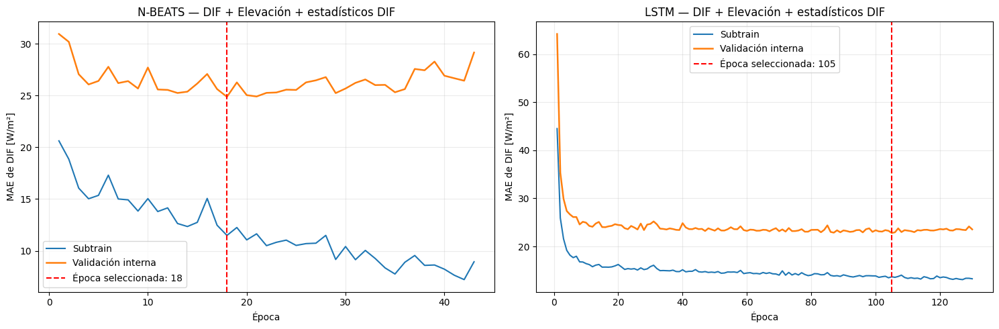


=== RESULTADO DE LA SELECCIÓN INTERNA DIFSTATS ===


,modelo,epoca_seleccionada,mae_validacion_interna,parametros_entrenables
0,NBEATS_DIF_Elev_DIFstats,18,24.883160,291990
1,LSTM_DIF_Elev_DIFstats,105,22.795378,20033


N-BEATS se reentrenará durante 18 épocas.
LSTM se reentrenará durante 105 épocas.

Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/seleccion_interna_difstats_20261006_181158

Validation externa utilizada: NO


In [ ]:
import copy
import json
import random
from datetime import datetime
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

# 1. Configuración
SEED = 42
N_SUBTRAIN = 4428
BATCH_SIZE = 128
MAX_EPOCHS = 300
PATIENCE = 25
MIN_DELTA = 1e-5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
DEVICE = torch.device("cpu")
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_SELECCION_DIFSTATS = (
    BASE_DIR / "resultados" / "ejecuciones" / f"seleccion_interna_difstats_{timestamp}"
)
OUT_SELECCION_DIFSTATS.mkdir(parents=True, exist_ok=True)

def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)

fijar_semilla()


# 2. Recuperación y comprobación de datos
assert "X_train_DIF_elev_DIFstats_raw" in globals(), (
    "No existe X_train_DIF_elev_DIFstats_raw. Ejecuta primero la preparación de DIFstats."
)
assert "y_train_difstats" in globals(), "No existe y_train_difstats."
X_difstats = np.asarray(X_train_DIF_elev_DIFstats_raw, dtype=np.float32)
y_difstats = np.asarray(y_train_difstats, dtype=np.float32).reshape(-1)
assert X_difstats.shape == (5149, 24, 4), f"Forma inesperada de X: {X_difstats.shape}"
assert y_difstats.shape == (5149,), f"Forma inesperada de y: {y_difstats.shape}"
assert np.isfinite(X_difstats).all()
assert np.isfinite(y_difstats).all()
print("=== BLOQUE DIFSTATS ===")
print("X train:", X_difstats.shape)
print("y train:", y_difstats.shape)
print("Canales:", ["DIF_media", "elevacion", "DIF_std", "DIF_rango"])
print("Validation externa utilizada: NO")


# 3. División cronológica interna
X_subtrain_raw = X_difstats[:N_SUBTRAIN]
y_subtrain_raw = y_difstats[:N_SUBTRAIN]
X_interna_raw = X_difstats[N_SUBTRAIN:]
y_interna_raw = y_difstats[N_SUBTRAIN:]
assert X_subtrain_raw.shape == (4428, 24, 4)
assert X_interna_raw.shape == (721, 24, 4)
print("\n=== DIVISIÓN CRONOLÓGICA INTERNA ===")
print("Subtrain:", X_subtrain_raw.shape)
print("Validación interna:", X_interna_raw.shape)


# 4. Escalado ajustado únicamente con subtrain
n_features = X_subtrain_raw.shape[2]
scaler_X_difstats = StandardScaler()
scaler_y_difstats = StandardScaler()
scaler_X_difstats.fit(X_subtrain_raw.reshape(-1, n_features))
scaler_y_difstats.fit(y_subtrain_raw.reshape(-1, 1))

def transformar_X(X):
    forma = X.shape
    return scaler_X_difstats.transform(X.reshape(-1, forma[2])).reshape(forma).astype(np.float32)

X_subtrain = transformar_X(X_subtrain_raw)
X_interna = transformar_X(X_interna_raw)
y_subtrain = scaler_y_difstats.transform(y_subtrain_raw.reshape(-1, 1)).ravel().astype(np.float32)
y_interna = scaler_y_difstats.transform(y_interna_raw.reshape(-1, 1)).ravel().astype(np.float32)
joblib.dump(scaler_X_difstats, OUT_SELECCION_DIFSTATS / "scaler_X_subtrain.joblib")
joblib.dump(scaler_y_difstats, OUT_SELECCION_DIFSTATS / "scaler_y_subtrain.joblib")


# 5. Arquitectura N-BEATS
class NBEATSBlockDIFStats(nn.Module):
    def __init__(self, input_size=96, hidden_size=128, backcast_size=24):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(input_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
            nn.Linear(hidden_size, hidden_size),
            nn.ReLU(),
        )
        self.backcast = nn.Linear(hidden_size, backcast_size)
        self.forecast = nn.Linear(hidden_size, 1)

    def forward(self, x):
        h = self.fc(x)
        return (self.backcast(h), self.forecast(h))

class NBEATSDIFStats(nn.Module):
    """
    Dos stacks de tres bloques.

    El residuo se aplica únicamente al historial de DIF.
    Elevación, DIF_std y DIF_rango se mantienen como
    covariables fijas en todos los bloques.
    """

    def __init__(self, lookback=24, n_features=4, hidden_size=128):
        super().__init__()
        input_size = lookback * n_features
        self.blocks = nn.ModuleList(
            [
                NBEATSBlockDIFStats(
                    input_size=input_size, hidden_size=hidden_size, backcast_size=lookback
                )
                for _ in range(6)
            ]
        )

    def forward(self, x):
        # Canal 0: historial de DIF
        residual_dif = x[:, :, 0]

        # Canales 1–3: elevación, DIF_std y DIF_rango
        covariables = x[:, :, 1:].permute(0, 2, 1).contiguous().reshape(x.size(0), -1)
        forecast_total = torch.zeros((x.size(0), 1), dtype=x.dtype, device=x.device)
        for bloque in self.blocks:
            entrada = torch.cat([residual_dif, covariables], dim=1)
            backcast, forecast = bloque(entrada)
            residual_dif = residual_dif - backcast
            forecast_total = forecast_total + forecast

        return forecast_total.squeeze(-1)


# 6. Arquitectura LSTM
class LSTMDIFStats(nn.Module):
    def __init__(self, n_features=4, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        ultimo_estado = salida[:, -1, :]
        return self.head(ultimo_estado).squeeze(-1)


# 7. Creación de DataLoaders
def crear_loaders():
    dataset_subtrain = TensorDataset(torch.from_numpy(X_subtrain), torch.from_numpy(y_subtrain))
    dataset_interna = TensorDataset(torch.from_numpy(X_interna), torch.from_numpy(y_interna))
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader_train = DataLoader(
        dataset_subtrain, batch_size=BATCH_SIZE, shuffle=True, generator=generador, num_workers=0
    )
    loader_train_eval = DataLoader(
        dataset_subtrain, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )
    loader_interna = DataLoader(
        dataset_interna, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )
    return (loader_train, loader_train_eval, loader_interna)


# 8. Evaluación en unidades originales
def evaluar_mae_original(modelo, loader):
    modelo.eval()
    predicciones = []
    observaciones = []
    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            pred = modelo(xb)
            predicciones.append(pred.cpu().numpy())
            observaciones.append(yb.numpy())

    pred_scaled = np.concatenate(predicciones)
    y_scaled = np.concatenate(observaciones)
    pred_original = scaler_y_difstats.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()
    y_original = scaler_y_difstats.inverse_transform(y_scaled.reshape(-1, 1)).ravel()
    mae = np.mean(np.abs(y_original - pred_original))
    return float(mae)


# 9. Selección interna con early stopping
def seleccionar_epoca(fabrica_modelo, nombre_modelo):
    # La semilla se fija antes de crear el modelo.
    fijar_semilla()
    modelo = fabrica_modelo().to(DEVICE)
    loader_train, loader_train_eval, loader_interna = crear_loaders()
    criterio = nn.L1Loss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    mejor_mae = np.inf
    mejor_epoca = None
    mejor_estado = None
    epocas_sin_mejora = 0
    historial = []
    numero_parametros = sum(
        parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad
    )
    print(f"\n{'=' * 70}")
    print(f"SELECCIÓN INTERNA: {nombre_modelo}")
    print("Parámetros entrenables:", numero_parametros)
    print(f"{'=' * 70}")
    for epoca in range(1, MAX_EPOCHS + 1):
        modelo.train()
        for xb, yb in loader_train:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            pred = modelo(xb)
            loss = criterio(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            optimizador.step()

        # Los dos errores se calculan después de terminar
        # la época y en unidades originales.
        mae_subtrain = evaluar_mae_original(modelo, loader_train_eval)
        mae_interna = evaluar_mae_original(modelo, loader_interna)
        historial.append(
            {"epoca": epoca, "mae_subtrain": mae_subtrain, "mae_validacion_interna": mae_interna}
        )
        if mae_interna < mejor_mae - MIN_DELTA:
            mejor_mae = mae_interna
            mejor_epoca = epoca
            mejor_estado = copy.deepcopy(modelo.state_dict())
            epocas_sin_mejora = 0
            indicador = "  <-- nuevo mínimo"

        else:
            epocas_sin_mejora += 1
            indicador = ""

        if epoca == 1 or epoca % 5 == 0 or indicador:
            print(
                f"Época {epoca:03d} | "
                f"MAE subtrain: "
                f"{mae_subtrain:.6f} | "
                f"MAE interna: "
                f"{mae_interna:.6f}"
                f"{indicador}"
            )

        if epocas_sin_mejora >= PATIENCE:
            print(f"\nEarly stopping: " f"{PATIENCE} épocas sin mejorar " "el mínimo observado.")
            print(f"Mejor época: {mejor_epoca} | " f"MAE interna mínimo: " f"{mejor_mae:.6f}")
            break

    assert mejor_estado is not None
    modelo.load_state_dict(mejor_estado)
    historial = pd.DataFrame(historial)
    nombre_archivo = nombre_modelo.lower().replace("-", "_").replace("+", "_")
    historial.to_csv(OUT_SELECCION_DIFSTATS / f"historial_{nombre_archivo}.csv", index=False)
    torch.save(
        {
            "model_state_dict": mejor_estado,
            "modelo": nombre_modelo,
            "bloque": "DIF_Elev_DIFstats",
            "mejor_epoca": int(mejor_epoca),
            "mejor_mae_interno": float(mejor_mae),
            "numero_parametros": int(numero_parametros),
            "lookback": 24,
            "n_features": 4,
            "canales": ["DIF_media", "elevacion", "DIF_std", "DIF_rango"],
        },
        OUT_SELECCION_DIFSTATS / f"checkpoint_{nombre_archivo}.pt",
    )
    return (modelo, historial, mejor_epoca, mejor_mae, numero_parametros)


# 10. Selección N-BEATS
(
    modelo_nbeats_difstats_seleccion,
    historial_nbeats_difstats,
    EPOCA_NBEATS_DIFSTATS,
    mae_interno_nbeats_difstats,
    parametros_nbeats_difstats,
) = seleccionar_epoca(
    lambda: NBEATSDIFStats(lookback=24, n_features=4, hidden_size=128), "NBEATS_DIF_Elev_DIFstats"
)


# 11. Selección LSTM
(
    modelo_lstm_difstats_seleccion,
    historial_lstm_difstats,
    EPOCA_LSTM_DIFSTATS,
    mae_interno_lstm_difstats,
    parametros_lstm_difstats,
) = seleccionar_epoca(lambda: LSTMDIFStats(n_features=4, hidden_size=64), "LSTM_DIF_Elev_DIFstats")


# 12. Gráficas
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
configuraciones_figura = [
    (
        axes[0],
        historial_nbeats_difstats,
        "N-BEATS — DIF + Elevación + estadísticos DIF",
        EPOCA_NBEATS_DIFSTATS,
    ),
    (
        axes[1],
        historial_lstm_difstats,
        "LSTM — DIF + Elevación + estadísticos DIF",
        EPOCA_LSTM_DIFSTATS,
    ),
]
for ax, historial, titulo, mejor_epoca in configuraciones_figura:
    ax.plot(historial["epoca"], historial["mae_subtrain"], label="Subtrain", linewidth=1.5)
    ax.plot(
        historial["epoca"],
        historial["mae_validacion_interna"],
        label="Validación interna",
        linewidth=1.8,
    )
    ax.axvline(
        mejor_epoca, color="red", linestyle="--", label=(f"Época seleccionada: " f"{mejor_epoca}")
    )
    ax.set_title(titulo)
    ax.set_xlabel("Época")
    ax.set_ylabel("MAE de DIF [W/m²]")
    ax.grid(alpha=0.25)
    ax.legend()

plt.tight_layout()
plt.savefig(
    OUT_SELECCION_DIFSTATS / "curvas_seleccion_interna_difstats.png", dpi=180, bbox_inches="tight"
)
plt.show()


# 13. Resumen final
resumen_seleccion_difstats = pd.DataFrame(
    [
        {
            "modelo": ("NBEATS_DIF_Elev_DIFstats"),
            "epoca_seleccionada": (EPOCA_NBEATS_DIFSTATS),
            "mae_validacion_interna": (mae_interno_nbeats_difstats),
            "parametros_entrenables": (parametros_nbeats_difstats),
        },
        {
            "modelo": ("LSTM_DIF_Elev_DIFstats"),
            "epoca_seleccionada": (EPOCA_LSTM_DIFSTATS),
            "mae_validacion_interna": (mae_interno_lstm_difstats),
            "parametros_entrenables": (parametros_lstm_difstats),
        },
    ]
)
resumen_seleccion_difstats.to_csv(
    OUT_SELECCION_DIFSTATS / "resumen_seleccion_interna_difstats.csv", index=False
)
configuracion_seleccion = {
    "bloque": "DIF_Elev_DIFstats",
    "canales": ["DIF_media", "elevacion", "DIF_std", "DIF_rango"],
    "n_subtrain": int(N_SUBTRAIN),
    "n_validacion_interna": int(len(X_interna_raw)),
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "min_delta": MIN_DELTA,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "L1Loss",
    "gradient_clipping": 1.0,
    "seed": SEED,
    "device": str(DEVICE),
    "validation_externa_utilizada": False,
    "epoca_nbeats": int(EPOCA_NBEATS_DIFSTATS),
    "epoca_lstm": int(EPOCA_LSTM_DIFSTATS),
}
with open(
    OUT_SELECCION_DIFSTATS / "configuracion_seleccion_difstats.json", "w", encoding="utf-8"
) as archivo:
    json.dump(configuracion_seleccion, archivo, indent=2, ensure_ascii=False)

print("\n=== RESULTADO DE LA SELECCIÓN INTERNA DIFSTATS ===")
display(resumen_seleccion_difstats.style.format({"mae_validacion_interna": "{:.6f}"}))
print(f"N-BEATS se reentrenará durante " f"{EPOCA_NBEATS_DIFSTATS} épocas.")
print(f"LSTM se reentrenará durante " f"{EPOCA_LSTM_DIFSTATS} épocas.")
print(f"\nResultados guardados en:\n" f"{OUT_SELECCION_DIFSTATS}")
print("\nValidation externa utilizada: NO")

**Resultados.** N-BEATS alcanza su mínimo en la época 18 (MAE interno de 24,88 W/m²). La LSTM sigue reduciendo el error durante más tiempo y alcanza su mínimo en la época 105 (22,80 W/m²). Los modelos tienen 291.990 y 20.033 parámetros, respectivamente.

### 6.40 Reentrenamiento y evaluación externa del bloque DIFstats

N-BEATS (18 épocas) y LSTM (105 épocas) se reentrenan desde cero con todo el entrenamiento, con escaladores ajustados solo con el entrenamiento, y se evalúan una única vez en validación.

=== DATOS DEL REENTRENAMIENTO DIFSTATS ===
Train: (5149, 24, 4)
Validation: (1464, 24, 4)
Canales: ['DIF_media', 'elevacion', 'DIF_std', 'DIF_rango']
Épocas N-BEATS: 18
Épocas LSTM: 105

REENTRENAMIENTO COMPLETO: NBEATS_DIFSTATS
Épocas fijadas: 18
Parámetros entrenables: 291990
Época 001/18 | MAE train: 23.147802 W/m²
Época 005/18 | MAE train: 16.670300 W/m²
Época 010/18 | MAE train: 14.708956 W/m²
Época 015/18 | MAE train: 13.009160 W/m²
Época 018/18 | MAE train: 12.578082 W/m²
Tiempo de entrenamiento: 30.60 s

REENTRENAMIENTO COMPLETO: LSTM_DIFSTATS
Épocas fijadas: 105
Parámetros entrenables: 20033
Época 001/105 | MAE train: 41.101311 W/m²
Época 005/105 | MAE train: 19.475216 W/m²
Época 010/105 | MAE train: 17.077459 W/m²
Época 015/105 | MAE train: 16.972597 W/m²
Época 020/105 | MAE train: 17.254499 W/m²
Época 025/105 | MAE train: 16.818615 W/m²
Época 030/105 | MAE train: 16.765587 W/m²
Época 035/105 | MAE train: 16.049364 W/m²
Época 040/105 | MAE train: 16.101902 W/m²
Época 045/105 

,modelo,particion,epocas,tiempo_entrenamiento_s,parametros_entrenables,MAE,nMAE_pct,RMSE,R2,bias
0,NBEATS_DIF_Elev_DIFstats,train,18,30.60,291990,12.578082,15.529281,25.899190,0.946689,-1.620182
1,NBEATS_DIF_Elev_DIFstats,validation,18,30.60,291990,17.584782,20.443655,33.633606,0.903228,2.143090
2,LSTM_DIF_Elev_DIFstats,train,105,154.39,20033,14.680059,18.124445,30.529450,0.925923,-2.850111
3,LSTM_DIF_Elev_DIFstats,validation,105,154.39,20033,15.699158,18.251472,31.879745,0.913057,-0.694994


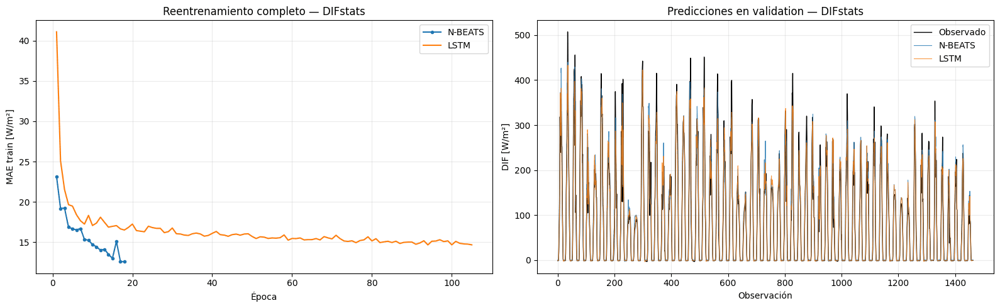


=== REENTRENAMIENTO DIFSTATS COMPLETADO ===
N-BEATS: 18 épocas
LSTM: 105 épocas

Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_difstats_20261006_182213

Validation externa utilizada únicamente para la evaluación final.


In [ ]:
import json
import random
import time
from datetime import datetime
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Configuración
SEED = 42
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
DEVICE = torch.device("cpu")
EPOCA_NBEATS_DIFSTATS = int(globals().get("EPOCA_NBEATS_DIFSTATS", 18))
EPOCA_LSTM_DIFSTATS = int(globals().get("EPOCA_LSTM_DIFSTATS", 105))
assert EPOCA_NBEATS_DIFSTATS == 18
assert EPOCA_LSTM_DIFSTATS == 105
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_DIFSTATS = BASE_DIR / "resultados" / "ejecuciones" / f"reentrenamiento_difstats_{timestamp}"
OUT_DIFSTATS.mkdir(parents=True, exist_ok=True)

def fijar_semilla(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)


# 2. Recuperar y comprobar los datos
assert "X_train_DIF_elev_DIFstats_raw" in globals()
assert "X_validation_DIF_elev_DIFstats_raw" in globals()
assert "y_train_difstats" in globals()
assert "y_validation_difstats" in globals()
assert "NBEATSDIFStats" in globals()
assert "LSTMDIFStats" in globals()
X_train_raw = np.asarray(X_train_DIF_elev_DIFstats_raw, dtype=np.float32)
X_validation_raw = np.asarray(X_validation_DIF_elev_DIFstats_raw, dtype=np.float32)
y_train_raw_difstats = np.asarray(y_train_difstats, dtype=np.float32).reshape(-1)
y_validation_raw_difstats = np.asarray(y_validation_difstats, dtype=np.float32).reshape(-1)
assert X_train_raw.shape == (5149, 24, 4)
assert X_validation_raw.shape == (1464, 24, 4)
assert y_train_raw_difstats.shape == (5149,)
assert y_validation_raw_difstats.shape == (1464,)
assert np.isfinite(X_train_raw).all()
assert np.isfinite(X_validation_raw).all()
assert np.isfinite(y_train_raw_difstats).all()
assert np.isfinite(y_validation_raw_difstats).all()
print("=== DATOS DEL REENTRENAMIENTO DIFSTATS ===")
print("Train:", X_train_raw.shape)
print("Validation:", X_validation_raw.shape)
print("Canales:", ["DIF_media", "elevacion", "DIF_std", "DIF_rango"])
print("Épocas N-BEATS:", EPOCA_NBEATS_DIFSTATS)
print("Épocas LSTM:", EPOCA_LSTM_DIFSTATS)


# 3. Escalado ajustado exclusivamente con train completo
n_features = X_train_raw.shape[2]
scaler_X_difstats_final = StandardScaler()
scaler_y_difstats_final = StandardScaler()
scaler_X_difstats_final.fit(X_train_raw.reshape(-1, n_features))
scaler_y_difstats_final.fit(y_train_raw_difstats.reshape(-1, 1))

def transformar_X(X):
    forma = X.shape
    return (
        scaler_X_difstats_final.transform(X.reshape(-1, forma[2])).reshape(forma).astype(np.float32)
    )

X_train_scaled = transformar_X(X_train_raw)
X_validation_scaled = transformar_X(X_validation_raw)
y_train_scaled = (
    scaler_y_difstats_final.transform(y_train_raw_difstats.reshape(-1, 1))
    .ravel()
    .astype(np.float32)
)
y_validation_scaled = (
    scaler_y_difstats_final.transform(y_validation_raw_difstats.reshape(-1, 1))
    .ravel()
    .astype(np.float32)
)
joblib.dump(scaler_X_difstats_final, OUT_DIFSTATS / "scaler_X_train_completo.joblib")
joblib.dump(scaler_y_difstats_final, OUT_DIFSTATS / "scaler_y_train_completo.joblib")


# 4. DataLoaders
def crear_loader_train():
    dataset = TensorDataset(torch.from_numpy(X_train_scaled), torch.from_numpy(y_train_scaled))
    generador = torch.Generator()
    generador.manual_seed(SEED)
    return DataLoader(
        dataset, batch_size=BATCH_SIZE, shuffle=True, generator=generador, num_workers=0
    )

def crear_loader_evaluacion(X, y):
    dataset = TensorDataset(torch.from_numpy(X), torch.from_numpy(y))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

train_eval_loader = crear_loader_evaluacion(X_train_scaled, y_train_scaled)
validation_loader = crear_loader_evaluacion(X_validation_scaled, y_validation_scaled)


# 5. Predicción en unidades originales
def predecir_original(modelo, loader):
    modelo.eval()
    predicciones = []
    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(DEVICE)
            predicciones.append(modelo(xb).cpu().numpy())

    pred_scaled = np.concatenate(predicciones)
    return scaler_y_difstats_final.inverse_transform(pred_scaled.reshape(-1, 1)).ravel()


# 6. Reentrenamiento desde cero
def entrenar_modelo_final(fabrica_modelo, nombre_modelo, numero_epocas):
    # La semilla se fija antes de crear el modelo.
    fijar_semilla()
    modelo = fabrica_modelo().to(DEVICE)
    train_loader = crear_loader_train()
    criterio = nn.L1Loss()
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    numero_parametros = sum(
        parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad
    )
    historial = []
    inicio = time.perf_counter()
    print(f"\n{'=' * 70}")
    print(f"REENTRENAMIENTO COMPLETO: {nombre_modelo}")
    print("Épocas fijadas:", numero_epocas)
    print("Parámetros entrenables:", numero_parametros)
    print(f"{'=' * 70}")
    for epoca in range(1, numero_epocas + 1):
        modelo.train()
        suma_loss = 0.0
        numero_elementos = 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            pred = modelo(xb)
            loss = criterio(pred, yb)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=1.0)
            optimizador.step()
            suma_loss += loss.item() * len(xb)
            numero_elementos += len(xb)

        # Evaluación exclusivamente sobre train
        pred_train_epoca = predecir_original(modelo, train_eval_loader)
        mae_train_epoca = mean_absolute_error(y_train_raw_difstats, pred_train_epoca)
        historial.append(
            {
                "epoca": epoca,
                "loss_train_escalada": (suma_loss / numero_elementos),
                "mae_train_original": (mae_train_epoca),
            }
        )
        if epoca == 1 or epoca % 5 == 0 or epoca == numero_epocas:
            print(
                f"Época {epoca:03d}/"
                f"{numero_epocas} | "
                f"MAE train: "
                f"{mae_train_epoca:.6f} W/m²"
            )

    tiempo_entrenamiento = time.perf_counter() - inicio
    historial = pd.DataFrame(historial)
    nombre_archivo = nombre_modelo.lower().replace("-", "_").replace("+", "_")
    historial.to_csv(OUT_DIFSTATS / f"historial_train_{nombre_archivo}.csv", index=False)
    print("Tiempo de entrenamiento:", f"{tiempo_entrenamiento:.2f} s")
    return (modelo, historial, tiempo_entrenamiento, numero_parametros)


# 7. Entrenar N-BEATS
(
    modelo_nbeats_difstats_final,
    historial_nbeats_difstats_final,
    tiempo_nbeats_difstats,
    parametros_nbeats_difstats_final,
) = entrenar_modelo_final(
    lambda: NBEATSDIFStats(lookback=24, n_features=4, hidden_size=128),
    "NBEATS_DIFSTATS",
    EPOCA_NBEATS_DIFSTATS,
)


# 8. Entrenar LSTM
(
    modelo_lstm_difstats_final,
    historial_lstm_difstats_final,
    tiempo_lstm_difstats,
    parametros_lstm_difstats_final,
) = entrenar_modelo_final(
    lambda: LSTMDIFStats(n_features=4, hidden_size=64), "LSTM_DIFSTATS", EPOCA_LSTM_DIFSTATS
)


# 9. Predicciones finales
# Validation se utiliza ahora por primera vez
pred_train_nbeats_difstats = predecir_original(modelo_nbeats_difstats_final, train_eval_loader)
pred_train_lstm_difstats = predecir_original(modelo_lstm_difstats_final, train_eval_loader)
pred_validation_nbeats_difstats = predecir_original(modelo_nbeats_difstats_final, validation_loader)
pred_validation_lstm_difstats = predecir_original(modelo_lstm_difstats_final, validation_loader)


# 10. Métricas
def calcular_metricas(y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    denominador = np.mean(np.abs(y_real))
    nmae = 100 * mae / denominador if denominador != 0 else np.nan
    return {
        "MAE": float(mae),
        "nMAE_pct": float(nmae),
        "RMSE": float(rmse),
        "R2": float(r2_score(y_real, y_pred)),
        "bias": float(np.mean(y_pred - y_real)),
    }

filas_metricas = []
configuraciones_metricas = [
    (
        "NBEATS_DIF_Elev_DIFstats",
        EPOCA_NBEATS_DIFSTATS,
        tiempo_nbeats_difstats,
        parametros_nbeats_difstats_final,
        pred_train_nbeats_difstats,
        pred_validation_nbeats_difstats,
    ),
    (
        "LSTM_DIF_Elev_DIFstats",
        EPOCA_LSTM_DIFSTATS,
        tiempo_lstm_difstats,
        parametros_lstm_difstats_final,
        pred_train_lstm_difstats,
        pred_validation_lstm_difstats,
    ),
]
for (
    nombre_modelo,
    epocas,
    tiempo_modelo,
    numero_parametros,
    pred_train,
    pred_validation,
) in configuraciones_metricas:
    filas_metricas.append(
        {
            "modelo": nombre_modelo,
            "particion": "train",
            "epocas": epocas,
            "tiempo_entrenamiento_s": (tiempo_modelo),
            "parametros_entrenables": (numero_parametros),
            **calcular_metricas(y_train_raw_difstats, pred_train),
        }
    )
    filas_metricas.append(
        {
            "modelo": nombre_modelo,
            "particion": "validation",
            "epocas": epocas,
            "tiempo_entrenamiento_s": (tiempo_modelo),
            "parametros_entrenables": (numero_parametros),
            **calcular_metricas(y_validation_raw_difstats, pred_validation),
        }
    )

metricas_difstats = pd.DataFrame(filas_metricas)
metricas_difstats.to_csv(OUT_DIFSTATS / "metricas_train_validation_difstats.csv", index=False)
print("\n=== MÉTRICAS TRAIN Y VALIDATION — DIFSTATS ===")
display(
    metricas_difstats.style.format(
        {
            "tiempo_entrenamiento_s": "{:.2f}",
            "MAE": "{:.6f}",
            "nMAE_pct": "{:.6f}",
            "RMSE": "{:.6f}",
            "R2": "{:.6f}",
            "bias": "{:.6f}",
        }
    )
)


# 11. Tabla de predicciones de validation
assert "validation_hgb" in globals()
assert len(validation_hgb) == 1464
predicciones_validation_difstats = pd.DataFrame(
    {
        "instante_objetivo": pd.to_datetime(validation_hgb["instante_objetivo"]),
        "regimen_solar_objetivo": (validation_hgb["regimen_solar_objetivo"].astype(str).to_numpy()),
        "DIF_observado": (y_validation_raw_difstats),
        "pred_NBEATS_DIFstats": (pred_validation_nbeats_difstats),
        "pred_LSTM_DIFstats": (pred_validation_lstm_difstats),
    }
)
for modelo in ["NBEATS_DIFstats", "LSTM_DIFstats"]:
    columna_pred = f"pred_{modelo}"
    predicciones_validation_difstats[f"error_{modelo}"] = (
        predicciones_validation_difstats[columna_pred]
        - predicciones_validation_difstats["DIF_observado"]
    )
    predicciones_validation_difstats[f"error_abs_{modelo}"] = predicciones_validation_difstats[
        f"error_{modelo}"
    ].abs()

predicciones_validation_difstats.to_csv(
    OUT_DIFSTATS / "predicciones_validation_difstats.csv", index=False
)


# 12. Guardar modelos finales
torch.save(
    {
        "model_state_dict": (modelo_nbeats_difstats_final.state_dict()),
        "modelo": ("NBEATS_DIF_Elev_DIFstats"),
        "epocas": (EPOCA_NBEATS_DIFSTATS),
        "lookback": 24,
        "n_features": 4,
        "hidden_size": 128,
        "n_stacks": 2,
        "blocks_per_stack": 3,
        "canales": ["DIF_media", "elevacion", "DIF_std", "DIF_rango"],
    },
    OUT_DIFSTATS / "modelo_nbeats_difstats_final.pt",
)
torch.save(
    {
        "model_state_dict": (modelo_lstm_difstats_final.state_dict()),
        "modelo": ("LSTM_DIF_Elev_DIFstats"),
        "epocas": (EPOCA_LSTM_DIFSTATS),
        "lookback": 24,
        "n_features": 4,
        "hidden_size": 64,
        "num_layers": 1,
        "canales": ["DIF_media", "elevacion", "DIF_std", "DIF_rango"],
    },
    OUT_DIFSTATS / "modelo_lstm_difstats_final.pt",
)


# 13. Figuras
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(
    historial_nbeats_difstats_final["epoca"],
    historial_nbeats_difstats_final["mae_train_original"],
    marker="o",
    markersize=3,
    label="N-BEATS",
)
axes[0].plot(
    historial_lstm_difstats_final["epoca"],
    historial_lstm_difstats_final["mae_train_original"],
    linewidth=1.5,
    label="LSTM",
)
axes[0].set_title("Reentrenamiento completo — DIFstats")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("MAE train [W/m²]")
axes[0].grid(alpha=0.25)
axes[0].legend()
indices = np.arange(len(y_validation_raw_difstats))
axes[1].plot(indices, y_validation_raw_difstats, color="black", linewidth=1, label="Observado")
axes[1].plot(indices, pred_validation_nbeats_difstats, linewidth=0.8, alpha=0.8, label="N-BEATS")
axes[1].plot(indices, pred_validation_lstm_difstats, linewidth=0.8, alpha=0.8, label="LSTM")
axes[1].set_title("Predicciones en validation — DIFstats")
axes[1].set_xlabel("Observación")
axes[1].set_ylabel("DIF [W/m²]")
axes[1].grid(alpha=0.25)
axes[1].legend()
plt.tight_layout()
plt.savefig(
    OUT_DIFSTATS / "reentrenamiento_y_validation_difstats.png", dpi=180, bbox_inches="tight"
)
plt.show()


# 14. Configuración final
configuracion_final = {
    "bloque": "DIF_Elev_DIFstats",
    "canales": ["DIF_media", "elevacion", "DIF_std", "DIF_rango"],
    "lookback": 24,
    "n_train": int(len(X_train_raw)),
    "n_validation": int(len(X_validation_raw)),
    "epocas_nbeats": int(EPOCA_NBEATS_DIFSTATS),
    "epocas_lstm": int(EPOCA_LSTM_DIFSTATS),
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "loss": "L1Loss",
    "gradient_clipping": 1.0,
    "seed": SEED,
    "device": str(DEVICE),
    "scaler_fit": "train completo",
    "validation_usada_para_seleccion": False,
}
with open(
    OUT_DIFSTATS / "configuracion_reentrenamiento_difstats.json", "w", encoding="utf-8"
) as archivo:
    json.dump(configuracion_final, archivo, indent=2, ensure_ascii=False)


# 15. Resultado
print("\n=== REENTRENAMIENTO DIFSTATS COMPLETADO ===")
print("N-BEATS:", EPOCA_NBEATS_DIFSTATS, "épocas")
print("LSTM:", EPOCA_LSTM_DIFSTATS, "épocas")
print(f"\nResultados guardados en:\n" f"{OUT_DIFSTATS}")
print("\nValidation externa utilizada únicamente para la evaluación final.")

**Resultados.** `LSTM_DIF_Elev_DIFstats` obtiene en validación un MAE de 15,70 W/m² (RMSE 31,88 W/m²; R² 0,91), frente a 17,58 W/m² de `NBEATS_DIF_Elev_DIFstats` (RMSE 33,63 W/m²; R² 0,90). El reentrenamiento de la LSTM requiere 154,39 s, frente a 30,60 s de N-BEATS.

### 6.41 DIFstats por régimen solar y coste computacional

Se desglosan las métricas de validación de los dos modelos DIFstats en global, operación, completamente diurno, transición y noche, se calcula la contribución de cada régimen al error absoluto y se registran el tiempo de entrenamiento, los parámetros y el tiempo de inferencia.

=== RECUENTO DE ÁMBITOS ===
Global: 1464
Operación: 884
Completamente diurna: 765
Transición: 119
Noche: 580

=== COSTE DE ENTRENAMIENTO REGISTRADO ===


,epocas,tiempo_entrenamiento_s,parametros_entrenables
modelo,,,
NBEATS_DIF_Elev_DIFstats,18,30.60,291990
LSTM_DIF_Elev_DIFstats,105,154.39,20033



=== MÉTRICAS DIFSTATS POR ÁMBITO ===


,modelo,ambito,epocas,tiempo_entrenamiento_s,segundos_por_epoca,parametros_entrenables,n_observaciones,MAE,nMAE_pct,RMSE,R2,bias
0,LSTM_DIF_Elev_DIFstats,global,105,154.39,1.4704,20033,1464,15.699158,18.251474,31.879744,0.913057,-0.694994
1,LSTM_DIF_Elev_DIFstats,operacion,105,154.39,1.4704,20033,884,25.698103,18.121747,41.023266,0.850845,-1.299884
2,LSTM_DIF_Elev_DIFstats,completamente_diurna,105,154.39,1.4704,20033,765,29.278937,17.993107,44.073050,0.801336,-1.399454
3,LSTM_DIF_Elev_DIFstats,transicion,105,154.39,1.4704,20033,119,2.678456,36.418919,3.811971,0.710946,-0.659792
4,LSTM_DIF_Elev_DIFstats,noche,105,154.39,1.4704,20033,580,0.459385,46.840299,0.585249,-2.403529,0.226941
5,NBEATS_DIF_Elev_DIFstats,global,18,30.60,1.7001,291990,1464,17.584780,20.443655,33.633605,0.903228,2.143090
6,NBEATS_DIF_Elev_DIFstats,operacion,18,30.60,1.7001,291990,884,28.332299,19.979325,43.268122,0.834074,2.811956
7,NBEATS_DIF_Elev_DIFstats,completamente_diurna,18,30.60,1.7001,291990,765,32.047423,19.694455,46.443778,0.779388,3.064728
8,NBEATS_DIF_Elev_DIFstats,transicion,18,30.60,1.7001,291990,119,4.449357,60.497838,6.377161,0.191025,1.186992
9,NBEATS_DIF_Elev_DIFstats,noche,18,30.60,1.7001,291990,580,1.204080,122.771710,1.403153,-18.564025,1.123646



=== LSTM MENOS N-BEATS ===
Delta MAE/RMSE negativo implica menor error de LSTM.


,ambito,delta_MAE_LSTM_menos_NBEATS,delta_RMSE_LSTM_menos_NBEATS,delta_R2_LSTM_menos_NBEATS
0,global,-1.885623,-1.753861,+0.009829
1,operacion,-2.634195,-2.244856,+0.016771
2,completamente_diurna,-2.768486,-2.370728,+0.021948
3,transicion,-1.770901,-2.565190,+0.519921
4,noche,-0.744695,-0.817904,+16.160496



=== CONTRIBUCIÓN AL ERROR GLOBAL ===


,modelo,regimen,n_observaciones,suma_error_absoluto,contribucion_error_global_pct
0,NBEATS_DIF_Elev_DIFstats,completamente_diurna,765,24516.277344,95.23%
1,NBEATS_DIF_Elev_DIFstats,transicion,119,529.473389,2.06%
2,NBEATS_DIF_Elev_DIFstats,noche,580,698.366455,2.71%
3,LSTM_DIF_Elev_DIFstats,completamente_diurna,765,22398.386719,97.45%
4,LSTM_DIF_Elev_DIFstats,transicion,119,318.736206,1.39%
5,LSTM_DIF_Elev_DIFstats,noche,580,266.443237,1.16%



=== BENCHMARK DE INFERENCIA ===


,modelo,dispositivo,hilos_torch,n_muestras_validation,repeticiones,tiempo_total_mediano_s,tiempo_total_media_s,tiempo_total_std_s,ms_por_muestra_mediana
0,NBEATS_DIF_Elev_DIFstats,cpu,1,1464,30,0.098294,0.138331,0.090783,0.067141
1,LSTM_DIF_Elev_DIFstats,cpu,1,1464,30,0.144962,0.158357,0.034696,0.099018


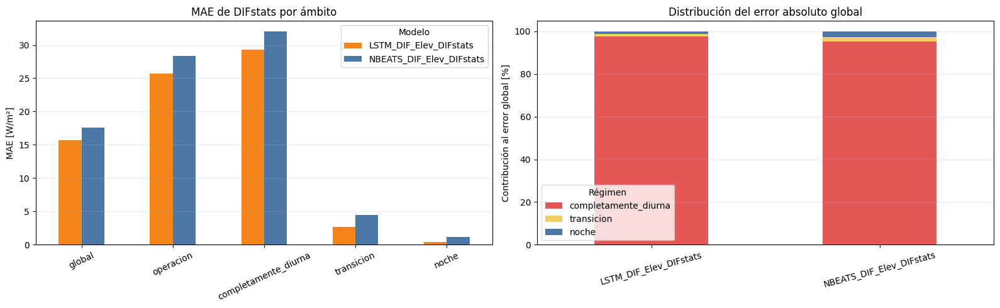


Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_difstats_20261006_182213

No se ha realizado entrenamiento adicional.


In [ ]:
import time
import unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Comprobaciones
assert "predicciones_validation_difstats" in globals()
assert "metricas_difstats" in globals()
assert "OUT_DIFSTATS" in globals()
assert "modelo_nbeats_difstats_final" in globals()
assert "modelo_lstm_difstats_final" in globals()
assert "validation_loader" in globals()
df = predicciones_validation_difstats.copy()
columnas_necesarias = [
    "regimen_solar_objetivo",
    "DIF_observado",
    "pred_NBEATS_DIFstats",
    "pred_LSTM_DIFstats",
]
faltantes = [columna for columna in columnas_necesarias if columna not in df.columns]
assert not faltantes, f"Faltan columnas: {faltantes}"


# 2. Normalización de los regímenes
def normalizar_texto(valor):
    texto = str(valor).strip().lower()
    texto = "".join(
        caracter
        for caracter in unicodedata.normalize("NFD", texto)
        if unicodedata.category(caracter) != "Mn"
    )
    return texto.replace("-", "_").replace(" ", "_")

df["regimen_normalizado"] = df["regimen_solar_objetivo"].map(normalizar_texto)
mask_noche = df["regimen_normalizado"].str.contains("noche", na=False)
mask_transicion = df["regimen_normalizado"].str.contains("transicion", na=False)
mask_diurna = df["regimen_normalizado"].str.contains("completamente", na=False) & df[
    "regimen_normalizado"
].str.contains("diurn", na=False)

# Operación = completamente diurna + transición
mask_operacion = mask_diurna | mask_transicion
mask_asignada = mask_noche | mask_transicion | mask_diurna
if not mask_asignada.all():
    no_reconocidos = df.loc[~mask_asignada, "regimen_solar_objetivo"].value_counts(dropna=False)
    raise ValueError("Regímenes no reconocidos:\n" f"{no_reconocidos}")

assert not (mask_noche & mask_operacion).any()
assert int(mask_operacion.sum()) == (int(mask_diurna.sum()) + int(mask_transicion.sum()))
assert len(df) == (int(mask_operacion.sum()) + int(mask_noche.sum()))
print("=== RECUENTO DE ÁMBITOS ===")
print("Global:", len(df))
print("Operación:", int(mask_operacion.sum()))
print("Completamente diurna:", int(mask_diurna.sum()))
print("Transición:", int(mask_transicion.sum()))
print("Noche:", int(mask_noche.sum()))


# 3. Información computacional ya registrada
coste_entrenamiento = (
    metricas_difstats.loc[
        metricas_difstats["particion"] == "validation",
        ["modelo", "epocas", "tiempo_entrenamiento_s", "parametros_entrenables"],
    ]
    .drop_duplicates("modelo")
    .set_index("modelo")
)
print("\n=== COSTE DE ENTRENAMIENTO REGISTRADO ===")
display(coste_entrenamiento.style.format({"tiempo_entrenamiento_s": "{:.2f}"}))


# 4. Función de métricas
def calcular_metricas(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    denominador = np.mean(np.abs(y_real))
    nmae = 100 * mae / denominador if denominador != 0 else np.nan
    r2 = r2_score(y_real, y_pred) if (len(y_real) >= 2 and np.var(y_real) > 0) else np.nan
    return {
        "n_observaciones": int(len(y_real)),
        "MAE": float(mae),
        "nMAE_pct": float(nmae),
        "RMSE": float(rmse),
        "R2": float(r2),
        "bias": float(np.mean(y_pred - y_real)),
    }


# 5. Métricas por ámbito
ambitos = {
    "global": np.ones(len(df), dtype=bool),
    "operacion": mask_operacion.to_numpy(),
    "completamente_diurna": mask_diurna.to_numpy(),
    "transicion": mask_transicion.to_numpy(),
    "noche": mask_noche.to_numpy(),
}
modelos = {
    "NBEATS_DIF_Elev_DIFstats": ("pred_NBEATS_DIFstats"),
    "LSTM_DIF_Elev_DIFstats": ("pred_LSTM_DIFstats"),
}
filas = []
for nombre_modelo, columna_pred in modelos.items():
    coste = coste_entrenamiento.loc[nombre_modelo]
    for nombre_ambito, mascara in ambitos.items():
        datos = df.loc[mascara]
        filas.append(
            {
                "modelo": nombre_modelo,
                "ambito": nombre_ambito,
                "epocas": int(coste["epocas"]),
                "tiempo_entrenamiento_s": float(coste["tiempo_entrenamiento_s"]),
                "segundos_por_epoca": float(coste["tiempo_entrenamiento_s"] / coste["epocas"]),
                "parametros_entrenables": int(coste["parametros_entrenables"]),
                **calcular_metricas(datos["DIF_observado"], datos[columna_pred]),
            }
        )

metricas_difstats_regimen = pd.DataFrame(filas)
orden_ambitos = ["global", "operacion", "completamente_diurna", "transicion", "noche"]
metricas_difstats_regimen["ambito"] = pd.Categorical(
    metricas_difstats_regimen["ambito"], categories=orden_ambitos, ordered=True
)
metricas_difstats_regimen = metricas_difstats_regimen.sort_values(["modelo", "ambito"]).reset_index(
    drop=True
)
metricas_difstats_regimen.to_csv(
    OUT_DIFSTATS / "metricas_validation_difstats_por_regimen.csv", index=False
)
print("\n=== MÉTRICAS DIFSTATS POR ÁMBITO ===")
display(
    metricas_difstats_regimen.style.format(
        {
            "tiempo_entrenamiento_s": "{:.2f}",
            "segundos_por_epoca": "{:.4f}",
            "MAE": "{:.6f}",
            "nMAE_pct": "{:.6f}",
            "RMSE": "{:.6f}",
            "R2": "{:.6f}",
            "bias": "{:.6f}",
        }
    )
)


# 6. Diferencias LSTM menos N-BEATS
tabla_comparacion = metricas_difstats_regimen.pivot(
    index="ambito", columns="modelo", values=["MAE", "RMSE", "R2"]
)
comparacion_difstats = pd.DataFrame(index=orden_ambitos)
comparacion_difstats["delta_MAE_LSTM_menos_NBEATS"] = (
    tabla_comparacion["MAE"]["LSTM_DIF_Elev_DIFstats"]
    - tabla_comparacion["MAE"]["NBEATS_DIF_Elev_DIFstats"]
)
comparacion_difstats["delta_RMSE_LSTM_menos_NBEATS"] = (
    tabla_comparacion["RMSE"]["LSTM_DIF_Elev_DIFstats"]
    - tabla_comparacion["RMSE"]["NBEATS_DIF_Elev_DIFstats"]
)
comparacion_difstats["delta_R2_LSTM_menos_NBEATS"] = (
    tabla_comparacion["R2"]["LSTM_DIF_Elev_DIFstats"]
    - tabla_comparacion["R2"]["NBEATS_DIF_Elev_DIFstats"]
)
comparacion_difstats.index.name = "ambito"
comparacion_difstats = comparacion_difstats.reset_index()
comparacion_difstats.to_csv(
    OUT_DIFSTATS / "comparacion_lstm_nbeats_difstats_por_regimen.csv", index=False
)
print("\n=== LSTM MENOS N-BEATS ===")
print("Delta MAE/RMSE negativo implica menor error de LSTM.")
display(
    comparacion_difstats.style.format(
        {
            "delta_MAE_LSTM_menos_NBEATS": "{:+.6f}",
            "delta_RMSE_LSTM_menos_NBEATS": "{:+.6f}",
            "delta_R2_LSTM_menos_NBEATS": "{:+.6f}",
        }
    )
)


# 7. Contribución al error absoluto global
# Regímenes mutuamente excluyentes
regimenes_base = {
    "completamente_diurna": (mask_diurna.to_numpy()),
    "transicion": (mask_transicion.to_numpy()),
    "noche": (mask_noche.to_numpy()),
}
filas_contribucion = []
for nombre_modelo, columna_pred in modelos.items():
    error_absoluto = np.abs(df[columna_pred].to_numpy() - df["DIF_observado"].to_numpy())
    suma_global = error_absoluto.sum()
    for nombre_regimen, mascara in regimenes_base.items():
        suma_regimen = error_absoluto[mascara].sum()
        filas_contribucion.append(
            {
                "modelo": nombre_modelo,
                "regimen": nombre_regimen,
                "n_observaciones": int(mascara.sum()),
                "suma_error_absoluto": float(suma_regimen),
                "contribucion_error_global_pct": float(100 * suma_regimen / suma_global),
            }
        )

contribucion_error_difstats = pd.DataFrame(filas_contribucion)
contribucion_error_difstats.to_csv(
    OUT_DIFSTATS / "contribucion_error_global_difstats.csv", index=False
)
print("\n=== CONTRIBUCIÓN AL ERROR GLOBAL ===")
display(
    contribucion_error_difstats.style.format(
        {"suma_error_absoluto": "{:.6f}", "contribucion_error_global_pct": "{:.2f}%"}
    )
)


# 8. Benchmark de inferencia
def medir_inferencia(modelo, loader, repeticiones=30, calentamientos=5):
    modelo.eval()

    def ejecutar():
        with torch.no_grad():
            for xb, _ in loader:
                xb = xb.to(DEVICE)
                _ = modelo(xb)

    for _ in range(calentamientos):
        ejecutar()

    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter()
        ejecutar()
        tiempos.append(time.perf_counter() - inicio)

    tiempos = np.asarray(tiempos)
    return {
        "repeticiones": repeticiones,
        "tiempo_total_mediano_s": float(np.median(tiempos)),
        "tiempo_total_media_s": float(np.mean(tiempos)),
        "tiempo_total_std_s": float(np.std(tiempos)),
        "ms_por_muestra_mediana": float(1000 * np.median(tiempos) / len(df)),
    }

benchmark_inferencia = []
for nombre_modelo, modelo in [
    ("NBEATS_DIF_Elev_DIFstats", modelo_nbeats_difstats_final),
    ("LSTM_DIF_Elev_DIFstats", modelo_lstm_difstats_final),
]:
    resultado = medir_inferencia(modelo, validation_loader)
    benchmark_inferencia.append(
        {
            "modelo": nombre_modelo,
            "dispositivo": str(DEVICE),
            "hilos_torch": torch.get_num_threads(),
            "n_muestras_validation": len(df),
            **resultado,
        }
    )

benchmark_inferencia = pd.DataFrame(benchmark_inferencia)
benchmark_inferencia.to_csv(OUT_DIFSTATS / "benchmark_inferencia_difstats.csv", index=False)
print("\n=== BENCHMARK DE INFERENCIA ===")
display(
    benchmark_inferencia.style.format(
        {
            "tiempo_total_mediano_s": "{:.6f}",
            "tiempo_total_media_s": "{:.6f}",
            "tiempo_total_std_s": "{:.6f}",
            "ms_por_muestra_mediana": "{:.6f}",
        }
    )
)


# 9. Figuras
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
tabla_mae = metricas_difstats_regimen.pivot(index="ambito", columns="modelo", values="MAE").reindex(
    orden_ambitos
)
tabla_mae.plot(kind="bar", ax=axes[0], color=["#F58518", "#4C78A8"])
axes[0].set_title("MAE de DIFstats por ámbito")
axes[0].set_xlabel("")
axes[0].set_ylabel("MAE [W/m²]")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(axis="y", alpha=0.25)
axes[0].legend(title="Modelo")
tabla_contribucion = contribucion_error_difstats.pivot(
    index="modelo", columns="regimen", values="contribucion_error_global_pct"
).reindex(columns=["completamente_diurna", "transicion", "noche"])
tabla_contribucion.plot(
    kind="bar", stacked=True, ax=axes[1], color=["#E45756", "#F2CF5B", "#4C78A8"]
)
axes[1].set_title("Distribución del error absoluto global")
axes[1].set_xlabel("")
axes[1].set_ylabel("Contribución al error global [%]")
axes[1].tick_params(axis="x", rotation=15)
axes[1].grid(axis="y", alpha=0.25)
axes[1].legend(title="Régimen")
plt.tight_layout()
plt.savefig(OUT_DIFSTATS / "comparacion_difstats_por_regimen.png", dpi=180, bbox_inches="tight")
plt.show()
print(f"\nResultados guardados en:\n{OUT_DIFSTATS}")
print("\nNo se ha realizado entrenamiento adicional.")

**Resultados.**

- La LSTM-DIFstats (`LSTM_DIF_Elev_DIFstats`) presenta en operación un MAE de 25,70 W/m², 2,63 W/m² menos que la primera N-BEATS con DIFstats (`NBEATS_DIF_Elev_DIFstats`, 28,33 W/m²).
- La LSTM obtiene menor MAE en los cinco ámbitos: 29,28 frente a 32,05 W/m² en horas completamente diurnas y 2,68 frente a 4,45 W/m² en transición.
- Las horas completamente diurnas concentran el 97,45 % del error absoluto de la LSTM.
- La inferencia requiere 0,10 ms por muestra con la LSTM y 0,07 ms con N-BEATS.

### 6.42 Comparación global con DIFstats

Se incorporan los dos modelos DIFstats a la tabla maestra y se recalculan las clasificaciones por MAE en el total de validación, operación, horas completamente diurnas y transición.


=== RANKING GLOBAL ACTUALIZADO ===


,posicion_MAE,modelo,familia,variables,MAE,nMAE_pct,RMSE,R2,candidato_preliminar
0,1,LSTM-DIFstats,LSTM,DIF + elevación + DIF std + DIF rango,15.699158,18.251474,31.879744,0.913057,True
1,2,LSTM-SWD,LSTM,DIF + elevación + SWD,15.867523,18.616582,32.383934,0.910285,True
2,3,LSTM-SWD+DIR+FD,LSTM,DIF + elevación + SWD + DIR + FD,15.885435,18.637598,32.348013,0.910484,True
3,4,LSTM-SWD+FD,LSTM,DIF + elevación + SWD + FD,16.230541,19.042494,32.715553,0.908438,False
4,5,LSTM-GeomT,LSTM,DIF + elevación histórica + GeomT,16.265980,19.084072,32.285250,0.910831,True
5,6,LSTM-DIR,LSTM,DIF + elevación + DIR,16.325878,19.154348,32.826323,0.907817,False
6,7,LSTM-SWD+DIR,LSTM,DIF + elevación + SWD + DIR,16.350744,19.183522,33.400176,0.904566,False
7,8,HGB-9V,HGB,Elevación + DIF,16.562404,19.431852,33.042724,0.906598,True
8,9,LSTM-DIF+Elevación,LSTM,DIF + elevación histórica,16.783111,19.690797,33.068067,0.906455,False
9,10,LSTM-LWU,LSTM,DIF + elevación + LWU,16.840960,19.758667,33.422958,0.904436,False



=== RANKING MAE — TOTAL ===


,puesto_MAE,modelo,n_observaciones,MAE,nMAE_pct,RMSE,R2,bias
0,1,LSTM-DIFstats,1464.000000,15.699158,18.251474,31.879744,0.913057,nan
1,2,LSTM-SWD,1464.000000,15.867523,18.616582,32.383934,0.910285,nan
2,3,LSTM-SWD+DIR+FD,1464.000000,15.885435,18.637598,32.348013,0.910484,nan
3,4,LSTM-SWD+FD,1464.000000,16.230541,19.042494,32.715553,0.908438,nan
4,5,LSTM-GeomT,1464.000000,16.265980,19.084072,32.285250,0.910831,nan
5,6,LSTM-DIR,1464.000000,16.325878,19.154348,32.826323,0.907817,nan
6,7,LSTM-SWD+DIR,1464.000000,16.350744,19.183522,33.400176,0.904566,nan
7,8,HGB-9V,1464.000000,16.562404,19.431852,33.042724,0.906598,nan
8,9,LSTM-DIF+Elevación,1464.000000,16.783111,19.690797,33.068067,0.906455,nan
9,10,LSTM-LWU,1464.000000,16.840960,19.758667,33.422958,0.904436,nan



=== RANKING MAE — OPERACION ===


,puesto_MAE,modelo,n_observaciones,MAE,nMAE_pct,RMSE,R2,bias
0,1,LSTM-DIFstats,884.000000,25.698103,18.121747,41.023266,0.850845,-1.299884
1,2,LSTM-SWD,884.000000,26.017927,18.348642,41.671803,0.846092,-1.588530
2,3,HGB-9V,884.000000,27.353409,19.290464,42.521985,0.839748,0.046495
3,4,LSTM-LWU,nan,27.395680,nan,43.004271,0.836092,-0.888516
4,5,LSTM-SWU,884.000000,27.415261,19.332650,42.460865,0.840208,-5.756244
5,6,LSTM-DIF+Elevación,884.000000,27.419652,19.337181,42.550746,0.839531,-1.660616
6,7,NBEATS-DIF+Elevación,884.000000,27.623462,19.480914,42.360924,0.840959,2.876547
7,8,LSTM-LWD,884.000000,27.656408,19.504149,42.904566,0.836851,6.906339
8,9,NBEATS-SWU,884.000000,27.938302,19.701487,42.434650,0.840405,-3.844147
9,10,LSTM-solo DIF,884.000000,28.000364,19.746717,42.547261,0.839557,-1.620577


... (6 outputs left out)


=== POSICIONES DE DIFSTATS ===


,modelo,familia,variables,puesto_total,MAE_total,RMSE,R2,puesto_operacion,MAE_operacion,puesto_completamente_diurno,MAE_completamente_diurno,puesto_transicion,MAE_transicion
0,LSTM-DIFstats,LSTM,DIF + elevación + DIF std + DIF rango,1,15.699158,31.879744,0.913057,1,25.698103,1,29.278937,2,2.678456
16,NBEATS-DIFstats,N-BEATS,DIF + elevación + DIF std + DIF rango,17,17.584780,33.633605,0.903228,11,28.332299,11,32.047423,10,4.449357



=== COSTE COMPUTACIONAL DIFSTATS ===


,modelo,epocas,tiempo_entrenamiento_s,segundos_por_epoca,parametros_entrenables,tiempo_total_mediano_s,ms_por_muestra_mediana
0,LSTM-DIFstats,105,154.39,1.4704,20033,0.144962,0.099018
1,NBEATS-DIFstats,18,30.60,1.7001,291990,0.098294,0.067141


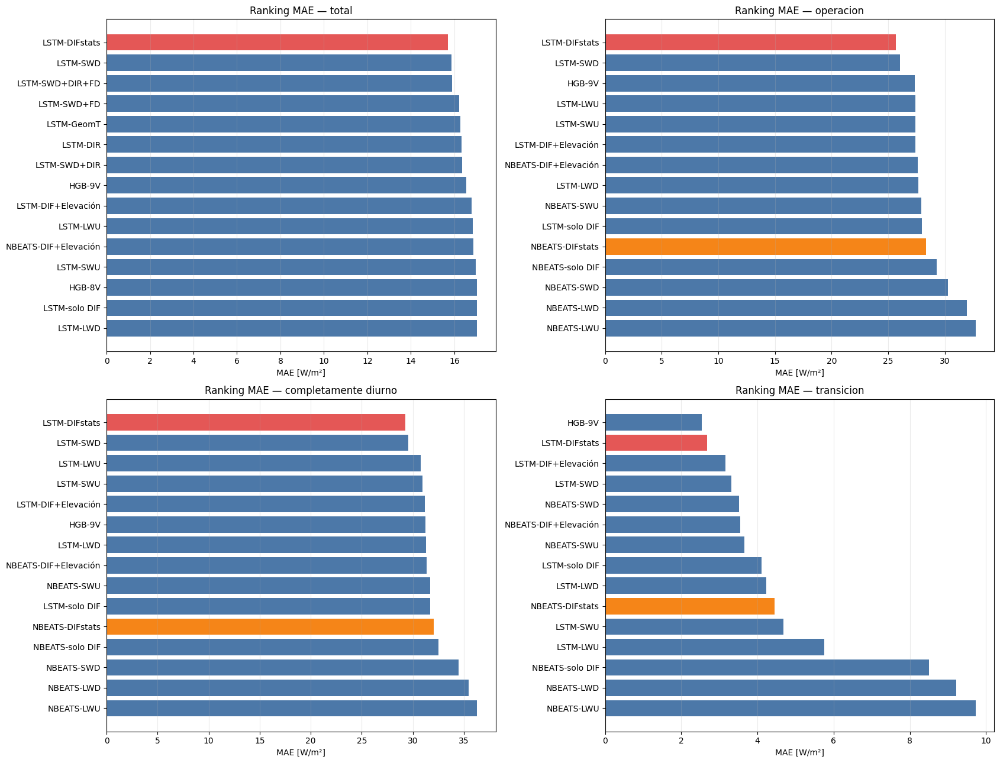


Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas/comparacion_global_con_difstats_20261006_183444


In [ ]:
from datetime import datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Rutas
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
RESULTADOS_DIR = BASE_DIR / "resultados"
COMPARATIVAS_DIR = RESULTADOS_DIR / "comparativas"
timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT_COMPARACION_DIFSTATS = COMPARATIVAS_DIR / f"comparacion_global_con_difstats_{timestamp}"
OUT_COMPARACION_DIFSTATS.mkdir(parents=True, exist_ok=True)
assert "metricas_difstats_regimen" in globals(), "No existe metricas_difstats_regimen."
assert "benchmark_inferencia" in globals(), "No existe benchmark_inferencia."


# 2. Recuperar la tabla global más completa
if "tabla_global" in globals():
    tabla_global_actualizada = tabla_global.copy()

else:
    archivos_globales = list(
        COMPARATIVAS_DIR.rglob("comparacion_global_modelos_actualizada.csv")
    ) + list(COMPARATIVAS_DIR.rglob("comparacion_global_modelos.csv"))
    assert archivos_globales, "No se encontró ninguna tabla global anterior."
    tablas_candidatas = []
    for archivo in archivos_globales:
        try:
            tabla = pd.read_csv(archivo, encoding="utf-8-sig")
            if {"modelo", "MAE", "RMSE", "R2"}.issubset(tabla.columns):
                tablas_candidatas.append((len(tabla), archivo.stat().st_mtime, archivo, tabla))

        except Exception:
            continue

    assert tablas_candidatas, "No se pudo leer una tabla global válida."

    # Priorizar la tabla con más modelos y, en empate,
    # la más reciente.
    _, _, archivo_global, tabla_global_actualizada = max(
        tablas_candidatas, key=lambda elemento: (elemento[0], elemento[1])
    )
    print("Tabla global recuperada desde:", archivo_global)


# 3. Incorporar métricas globales de DIFstats
mapa_nombres = {
    "NBEATS_DIF_Elev_DIFstats": ("NBEATS-DIFstats"),
    "LSTM_DIF_Elev_DIFstats": ("LSTM-DIFstats"),
}
modelos_difstats = list(mapa_nombres.values())

# Eliminar versiones anteriores para que la celda sea repetible
tabla_global_actualizada = tabla_global_actualizada.loc[
    ~tabla_global_actualizada["modelo"].isin(modelos_difstats)
].copy()
global_difstats = metricas_difstats_regimen.loc[
    metricas_difstats_regimen["ambito"].astype(str) == "global"
].copy()
filas_globales = []
for _, fila in global_difstats.iterrows():
    modelo = mapa_nombres[fila["modelo"]]
    familia = "LSTM" if modelo.startswith("LSTM") else "N-BEATS"
    filas_globales.append(
        {
            "posicion_MAE": np.nan,
            "modelo": modelo,
            "familia": familia,
            "variables": ("DIF + elevación + DIF std + DIF rango"),
            "MAE": float(fila["MAE"]),
            "RMSE": float(fila["RMSE"]),
            "R2": float(fila["R2"]),
            "nMAE_pct": float(fila["nMAE_pct"]),
            "rank_MAE": np.nan,
            "rank_RMSE": np.nan,
            "rank_R2": np.nan,
            "candidato_preliminar": (modelo == "LSTM-DIFstats"),
        }
    )

tabla_global_actualizada = pd.concat(
    [tabla_global_actualizada, pd.DataFrame(filas_globales)], ignore_index=True
)


# 4. Recalcular posiciones globales
tabla_global_actualizada["rank_MAE"] = (
    tabla_global_actualizada["MAE"].rank(method="min", ascending=True).astype("Int64")
)
tabla_global_actualizada["rank_RMSE"] = (
    tabla_global_actualizada["RMSE"].rank(method="min", ascending=True).astype("Int64")
)
tabla_global_actualizada["rank_R2"] = (
    tabla_global_actualizada["R2"].rank(method="min", ascending=False).astype("Int64")
)
tabla_global_actualizada = tabla_global_actualizada.sort_values(
    ["MAE", "RMSE", "modelo"], ascending=[True, True, True]
).reset_index(drop=True)
tabla_global_actualizada["posicion_MAE"] = np.arange(1, len(tabla_global_actualizada) + 1)
tabla_global_actualizada.to_csv(
    OUT_COMPARACION_DIFSTATS / "comparacion_global_modelos_actualizada.csv", index=False
)
print("\n=== RANKING GLOBAL ACTUALIZADO ===")
display(
    tabla_global_actualizada[
        [
            "posicion_MAE",
            "modelo",
            "familia",
            "variables",
            "MAE",
            "nMAE_pct",
            "RMSE",
            "R2",
            "candidato_preliminar",
        ]
    ].style.format({"MAE": "{:.6f}", "nMAE_pct": "{:.6f}", "RMSE": "{:.6f}", "R2": "{:.6f}"})
)


# 5. Recuperar la tabla anterior por ámbito
if "metricas_por_ambito" in globals():
    metricas_ambitos_previas = metricas_por_ambito.copy()

else:
    archivos_ambitos = list(COMPARATIVAS_DIR.rglob("metricas_modelos_por_ambito.csv"))
    assert archivos_ambitos, "No se encontró metricas_modelos_por_ambito.csv."
    archivo_ambitos = max(archivos_ambitos, key=lambda ruta: ruta.stat().st_mtime)
    metricas_ambitos_previas = pd.read_csv(archivo_ambitos, encoding="utf-8-sig")
    print("Tabla por ámbitos recuperada desde:", archivo_ambitos)


# 6. Normalizar nombres de ámbitos
def normalizar_ambito(valor):
    texto = str(valor).strip().lower().replace("á", "a").replace("ó", "o").replace(" ", "_")
    if texto in {"global", "total"}:
        return "total"

    if "oper" in texto:
        return "operacion"

    if "completamente" in texto and "diurn" in texto:
        return "completamente_diurno"

    if "transicion" in texto:
        return "transicion"

    if "noche" in texto:
        return "noche"

    return texto

metricas_ambitos_previas["ambito"] = (
    metricas_ambitos_previas["ambito"].astype(str).map(normalizar_ambito)
)


# 7. Sustituir la clasificación total por la tabla global

# Conservar de la tabla anterior solamente los ámbitos
# distintos de total.
metricas_otros_ambitos = metricas_ambitos_previas.loc[
    metricas_ambitos_previas["ambito"] != "total"
].copy()
metricas_otros_ambitos = metricas_otros_ambitos.loc[
    ~metricas_otros_ambitos["modelo"].isin(modelos_difstats)
].copy()
metricas_total = tabla_global_actualizada[["modelo", "MAE", "nMAE_pct", "RMSE", "R2"]].copy()
metricas_total["ambito"] = "total"
metricas_total["n_observaciones"] = 1464
metricas_total["bias"] = np.nan
metricas_total["fuente"] = "tabla_global_actualizada"


# 8. Preparar los ámbitos de DIFstats
ambitos_difstats = metricas_difstats_regimen.copy()
ambitos_difstats["modelo"] = ambitos_difstats["modelo"].map(mapa_nombres)
ambitos_difstats["ambito"] = ambitos_difstats["ambito"].astype(str).map(normalizar_ambito)
ambitos_difstats = ambitos_difstats.loc[
    ambitos_difstats["ambito"].isin(["operacion", "completamente_diurno", "transicion"]),
    [
        "modelo",
        "ambito",
        "n_observaciones",
        "MAE",
        "nMAE_pct",
        "RMSE",
        "R2",
        "bias",
        "epocas",
        "tiempo_entrenamiento_s",
        "segundos_por_epoca",
        "parametros_entrenables",
    ],
].copy()
ambitos_difstats["fuente"] = "evaluacion_difstats_actual"


# 9. Combinar todos los modelos
metricas_por_ambito_actualizadas = pd.concat(
    [metricas_total, metricas_otros_ambitos, ambitos_difstats], ignore_index=True, sort=False
)
orden_ambitos = ["total", "operacion", "completamente_diurno", "transicion"]
metricas_por_ambito_actualizadas = metricas_por_ambito_actualizadas.loc[
    metricas_por_ambito_actualizadas["ambito"].isin(orden_ambitos)
].copy()

# Si existe alguna duplicación histórica, conservar
# el último registro incorporado.
metricas_por_ambito_actualizadas = metricas_por_ambito_actualizadas.drop_duplicates(
    subset=["modelo", "ambito"], keep="last"
)
metricas_por_ambito_actualizadas["ambito"] = pd.Categorical(
    metricas_por_ambito_actualizadas["ambito"], categories=orden_ambitos, ordered=True
)
metricas_por_ambito_actualizadas["puesto_MAE"] = (
    metricas_por_ambito_actualizadas.groupby("ambito", observed=True)["MAE"]
    .rank(method="min", ascending=True)
    .astype("Int64")
)
metricas_por_ambito_actualizadas = metricas_por_ambito_actualizadas.sort_values(
    ["ambito", "puesto_MAE", "modelo"]
).reset_index(drop=True)
metricas_por_ambito_actualizadas.to_csv(
    OUT_COMPARACION_DIFSTATS / "metricas_modelos_por_ambito.csv", index=False
)


# 10. Mostrar los cuatro rankings
rankings_actualizados = {}
for ambito in orden_ambitos:
    ranking = (
        metricas_por_ambito_actualizadas.loc[
            metricas_por_ambito_actualizadas["ambito"] == ambito,
            ["puesto_MAE", "modelo", "n_observaciones", "MAE", "nMAE_pct", "RMSE", "R2", "bias"],
        ]
        .sort_values(["puesto_MAE", "modelo"])
        .reset_index(drop=True)
    )
    rankings_actualizados[ambito] = ranking
    ranking.to_csv(OUT_COMPARACION_DIFSTATS / f"ranking_mae_{ambito}.csv", index=False)
    print(f"\n=== RANKING MAE — " f"{ambito.upper()} ===")
    display(
        ranking.style.format(
            {
                "MAE": "{:.6f}",
                "nMAE_pct": "{:.6f}",
                "RMSE": "{:.6f}",
                "R2": "{:.6f}",
                "bias": "{:.6f}",
            }
        )
    )


# 11. Tabla compacta para decidir
tabla_mae = metricas_por_ambito_actualizadas.pivot(index="modelo", columns="ambito", values="MAE")
tabla_puesto = metricas_por_ambito_actualizadas.pivot(
    index="modelo", columns="ambito", values="puesto_MAE"
)
tabla_decision_actualizada = pd.DataFrame(index=tabla_global_actualizada["modelo"])
for ambito in orden_ambitos:
    tabla_decision_actualizada[f"puesto_{ambito}"] = tabla_puesto.get(ambito)
    tabla_decision_actualizada[f"MAE_{ambito}"] = tabla_mae.get(ambito)

tabla_decision_actualizada = tabla_decision_actualizada.reset_index()
tabla_decision_actualizada = tabla_decision_actualizada.merge(
    tabla_global_actualizada[["modelo", "familia", "variables", "RMSE", "R2"]],
    on="modelo",
    how="left",
)
columnas_decision = [
    "modelo",
    "familia",
    "variables",
    "puesto_total",
    "MAE_total",
    "RMSE",
    "R2",
    "puesto_operacion",
    "MAE_operacion",
    "puesto_completamente_diurno",
    "MAE_completamente_diurno",
    "puesto_transicion",
    "MAE_transicion",
]
tabla_decision_actualizada = (
    tabla_decision_actualizada[columnas_decision]
    .sort_values(["puesto_total", "modelo"], na_position="last")
    .reset_index(drop=True)
)
for columna in [
    "puesto_total",
    "puesto_operacion",
    "puesto_completamente_diurno",
    "puesto_transicion",
]:
    tabla_decision_actualizada[columna] = tabla_decision_actualizada[columna].astype("Int64")

tabla_decision_actualizada.to_csv(
    OUT_COMPARACION_DIFSTATS / "tabla_decision_modelos_actualizada.csv", index=False
)
print("\n=== TABLA ACTUALIZADA PARA LA TOMA DE DECISIONES ===")
display(
    tabla_decision_actualizada.style.format(
        {
            "MAE_total": "{:.6f}",
            "RMSE": "{:.6f}",
            "R2": "{:.6f}",
            "MAE_operacion": "{:.6f}",
            "MAE_completamente_diurno": "{:.6f}",
            "MAE_transicion": "{:.6f}",
        }
    )
)


# 12. Posiciones concretas de DIFstats
posiciones_difstats = tabla_decision_actualizada.loc[
    tabla_decision_actualizada["modelo"].isin(modelos_difstats)
].copy()
posiciones_difstats.to_csv(OUT_COMPARACION_DIFSTATS / "posiciones_difstats.csv", index=False)
print("\n=== POSICIONES DE DIFSTATS ===")
display(
    posiciones_difstats.style.format(
        {
            "MAE_total": "{:.6f}",
            "RMSE": "{:.6f}",
            "R2": "{:.6f}",
            "MAE_operacion": "{:.6f}",
            "MAE_completamente_diurno": "{:.6f}",
            "MAE_transicion": "{:.6f}",
        }
    )
)


# 13. Registrar el coste computacional de DIFstats
coste_difstats = metricas_difstats_regimen.loc[
    metricas_difstats_regimen["ambito"].astype(str) == "global",
    ["modelo", "epocas", "tiempo_entrenamiento_s", "segundos_por_epoca", "parametros_entrenables"],
].copy()
coste_difstats["modelo"] = coste_difstats["modelo"].map(mapa_nombres)
benchmark_coste = benchmark_inferencia[
    ["modelo", "tiempo_total_mediano_s", "ms_por_muestra_mediana"]
].copy()
benchmark_coste["modelo"] = benchmark_coste["modelo"].map(mapa_nombres)
coste_difstats = coste_difstats.merge(benchmark_coste, on="modelo", how="left")
coste_difstats.to_csv(OUT_COMPARACION_DIFSTATS / "coste_computacional_difstats.csv", index=False)
print("\n=== COSTE COMPUTACIONAL DIFSTATS ===")
display(
    coste_difstats.style.format(
        {
            "tiempo_entrenamiento_s": "{:.2f}",
            "segundos_por_epoca": "{:.4f}",
            "tiempo_total_mediano_s": "{:.6f}",
            "ms_por_muestra_mediana": "{:.6f}",
        }
    )
)


# 14. Figura de rankings
fig, axes = plt.subplots(2, 2, figsize=(17, 13))
axes = axes.ravel()
for ax, ambito in zip(axes, orden_ambitos):
    ranking = rankings_actualizados[ambito].head(15).sort_values("MAE", ascending=False)
    colores = [
        (
            "#E45756"
            if modelo == "LSTM-DIFstats"
            else "#F58518" if modelo == "NBEATS-DIFstats" else "#4C78A8"
        )
        for modelo in ranking["modelo"]
    ]
    ax.barh(ranking["modelo"], ranking["MAE"], color=colores)
    ax.set_title(f"Ranking MAE — " f"{ambito.replace('_', ' ')}")
    ax.set_xlabel("MAE [W/m²]")
    ax.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.savefig(
    OUT_COMPARACION_DIFSTATS / "rankings_mae_con_difstats.png", dpi=180, bbox_inches="tight"
)
plt.show()
print(f"\nResultados guardados en:\n" f"{OUT_COMPARACION_DIFSTATS}")

**Resultados.** `LSTM-DIFstats` pasa a ocupar el primer puesto de la clasificación total, con un MAE de 15,70 W/m² frente a 15,87 W/m² de `LSTM-SWD`, y presenta además el menor RMSE (31,88 W/m²) de los 31 modelos. `NBEATS-DIFstats` se sitúa en el puesto 17 (17,58 W/m²). `LSTM-DIFstats` encabeza también operación y horas completamente diurnas; en transición queda segunda, por detrás de `HGB-9V`.

### 6.43 Restauración del entorno tras la desconexión

Tras una nueva desconexión, se restablecen los datos minutales, las particiones de entrenamiento y validación y las matrices guardadas, y se verifica que las fechas de cada partición no han cambiado.

In [ ]:
from google.colab import drive

drive.mount("/content/drive", force_remount=False)
from pathlib import Path
import json
import os
import numpy as np
import pandas as pd

# 1. Directorio base único del modelado
BASE_DIR = Path("/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado")
if not BASE_DIR.exists():
    raise FileNotFoundError(
        "No se encuentra la carpeta base esperada:\n"
        f"{BASE_DIR}\n\n"
        "Comprueba que Drive se haya montado con la cuenta correcta."
    )

os.chdir(BASE_DIR)
DIR_DATOS = BASE_DIR / "datos"
DIR_MODELOS = BASE_DIR / "modelos"
DIR_RESULTADOS = BASE_DIR / "resultados"
DIR_EJECUCIONES = DIR_RESULTADOS / "ejecuciones"
DIR_COMPARATIVAS = DIR_RESULTADOS / "comparativas"
DIR_DOCUMENTACION = BASE_DIR / "documentacion"
DIR_EXPORTACIONES = BASE_DIR / "exportaciones"
print("Directorio de trabajo:")
print(Path.cwd())


# 2. Localizar y cargar el parquet original
PARQUET_ORIGINAL = BASE_DIR / "radiation_data_completo.parquet"
if not PARQUET_ORIGINAL.is_file():
    raise FileNotFoundError(
        "No aparece la copia del parquet dentro del entorno de modelado:\n" f"{PARQUET_ORIGINAL}"
    )

# Solo cargamos inicialmente las variables necesarias para el
# bloque meteorológico. Así evitamos duplicar innecesariamente
# todo el parquet en RAM.
COLUMNAS_METEO = ["Date/Time", "T2 [°C]", "RH [%]", "PoPoPoPo [hPa]"]
df_minutal_meteo = pd.read_parquet(PARQUET_ORIGINAL, columns=COLUMNAS_METEO)
df_minutal_meteo["Date/Time"] = pd.to_datetime(
    df_minutal_meteo["Date/Time"], utc=True, errors="raise"
)
df_minutal_meteo = df_minutal_meteo.sort_values("Date/Time").reset_index(drop=True)
print("\nParquet original cargado correctamente")
print(f"Ruta: {PARQUET_ORIGINAL}")
print(f"Filas: {len(df_minutal_meteo):,}")
print(f"Desde: {df_minutal_meteo['Date/Time'].min()}")
print(f"Hasta: {df_minutal_meteo['Date/Time'].max()}")
print(f"Columnas: {df_minutal_meteo.columns.tolist()}")


# 3. Localizar automáticamente el checkpoint de continuidad
CHECKPOINTS = sorted(
    [ruta for ruta in DIR_DOCUMENTACION.glob("checkpoint_continuidad_modelado_*") if ruta.is_dir()],
    key=lambda ruta: ruta.name,
)
if not CHECKPOINTS:
    raise FileNotFoundError(
        "No se ha encontrado ningún checkpoint de continuidad en:\n" f"{DIR_DOCUMENTACION}"
    )

CHECKPOINT_DIR = CHECKPOINTS[-1]
print("\nCheckpoint seleccionado:")
print(CHECKPOINT_DIR)


# 4. Restaurar train_hgb y validation_hgb
RUTA_TRAIN_HGB = CHECKPOINT_DIR / "train_hgb.parquet"
RUTA_VALIDATION_HGB = CHECKPOINT_DIR / "validation_hgb.parquet"
for ruta in [RUTA_TRAIN_HGB, RUTA_VALIDATION_HGB]:
    if not ruta.is_file():
        raise FileNotFoundError(f"Falta el archivo requerido: {ruta}")

train_hgb = pd.read_parquet(RUTA_TRAIN_HGB)
validation_hgb = pd.read_parquet(RUTA_VALIDATION_HGB)
for df in [train_hgb, validation_hgb]:
    df["instante_objetivo"] = pd.to_datetime(df["instante_objetivo"], utc=True, errors="raise")
    df.sort_values("instante_objetivo", inplace=True)
    df.reset_index(drop=True, inplace=True)

print("\nParticiones restauradas:")
print(
    "TRAIN:",
    train_hgb.shape,
    train_hgb["instante_objetivo"].min(),
    "→",
    train_hgb["instante_objetivo"].max(),
)
print(
    "VALIDATION:",
    validation_hgb.shape,
    validation_hgb["instante_objetivo"].min(),
    "→",
    validation_hgb["instante_objetivo"].max(),
)


# 5. Verificación estricta de las fechas acordadas
TRAIN_INICIO = pd.Timestamp("2023-12-30 00:00:00", tz="UTC")
TRAIN_FIN = pd.Timestamp("2024-07-31 23:00:00", tz="UTC")
VALIDATION_INICIO = pd.Timestamp("2024-08-01 00:00:00", tz="UTC")
VALIDATION_FIN = pd.Timestamp("2024-09-30 23:00:00", tz="UTC")
TEST_INICIO = pd.Timestamp("2024-10-01 00:00:00", tz="UTC")
assert len(train_hgb) == 5149, f"Train debería contener 5149 filas y contiene {len(train_hgb)}."
assert len(validation_hgb) == 1464, (
    "Validation debería contener 1464 filas y contiene " f"{len(validation_hgb)}."
)
assert train_hgb["instante_objetivo"].min() == TRAIN_INICIO
assert train_hgb["instante_objetivo"].max() == TRAIN_FIN
assert validation_hgb["instante_objetivo"].min() == VALIDATION_INICIO
assert validation_hgb["instante_objetivo"].max() == VALIDATION_FIN
assert validation_hgb["instante_objetivo"].max() < TEST_INICIO
print("\nFechas verificadas correctamente.")
print("El periodo de test continúa cerrado y no se ha cargado.")


# 6. Restaurar los arrays guardados en el checkpoint
RUTA_ARRAYS = CHECKPOINT_DIR / "estado_arrays_modelado.npz"
arrays_checkpoint = {}
if RUTA_ARRAYS.is_file():
    with np.load(RUTA_ARRAYS, allow_pickle=False) as archivo_npz:
        arrays_checkpoint = {nombre: archivo_npz[nombre].copy() for nombre in archivo_npz.files}

    # Recupera los nombres originales como variables del notebook.
    globals().update(arrays_checkpoint)
    print("\nArrays restaurados:")
    for nombre, array in arrays_checkpoint.items():
        print(f"  {nombre:<45} " f"shape={array.shape}, dtype={array.dtype}")
else:
    print("\nAVISO: no se encontró estado_arrays_modelado.npz")


# 7. Cargar metadatos e inventario del checkpoint
RUTA_ESTADO = CHECKPOINT_DIR / "estado_modelado.json"
RUTA_INVENTARIO = CHECKPOINT_DIR / "inventario_modelos_principales.csv"
RUTA_REANUDACION = CHECKPOINT_DIR / "PUNTO_REANUDACION.md"
estado_modelado = None
inventario_modelos_principales = None
punto_reanudacion = None
if RUTA_ESTADO.is_file():
    with open(RUTA_ESTADO, "r", encoding="utf-8") as archivo:
        estado_modelado = json.load(archivo)

if RUTA_INVENTARIO.is_file():
    inventario_modelos_principales = pd.read_csv(RUTA_INVENTARIO)

if RUTA_REANUDACION.is_file():
    punto_reanudacion = RUTA_REANUDACION.read_text(encoding="utf-8")

print("\nMetadatos del checkpoint:")
print(f"  Estado JSON:       {RUTA_ESTADO.is_file()}")
print(f"  Inventario:        {RUTA_INVENTARIO.is_file()}")
print(f"  Punto reanudación: {RUTA_REANUDACION.is_file()}")


# 8. Inventariar los resultados que permanecen en Drive
def inventariar_archivos(directorio):
    registros = []
    if not directorio.exists():
        return pd.DataFrame(columns=["nombre", "extension", "ruta", "tamano_MB"])

    for ruta in directorio.rglob("*"):
        if ruta.is_file():
            registros.append(
                {
                    "nombre": ruta.name,
                    "extension": ruta.suffix.lower(),
                    "ruta": str(ruta),
                    "tamano_MB": round(ruta.stat().st_size / (1024**2), 4),
                }
            )

    return pd.DataFrame(registros)

inventario_resultados_drive = inventariar_archivos(DIR_RESULTADOS)
inventario_modelos_drive = inventariar_archivos(DIR_MODELOS)
inventario_comparativas_drive = inventariar_archivos(DIR_COMPARATIVAS)
EXTENSIONES_MODELO = {".pt", ".pth", ".pkl", ".pickle", ".joblib", ".keras", ".h5", ".ckpt"}
modelos_en_todo_el_entorno = inventariar_archivos(BASE_DIR)
if not modelos_en_todo_el_entorno.empty:
    modelos_en_todo_el_entorno = modelos_en_todo_el_entorno[
        modelos_en_todo_el_entorno["extension"].isin(EXTENSIONES_MODELO)
    ].reset_index(drop=True)

print("\nInventario persistente encontrado:")
print(f"  Archivos en resultados: " f"{len(inventario_resultados_drive)}")
print(f"  Archivos en modelos/: " f"{len(inventario_modelos_drive)}")
print(f"  Archivos de modelo localizados en todo el entorno: " f"{len(modelos_en_todo_el_entorno)}")


# 9. Localizar ejecuciones y comparativas más recientes
carpetas_ejecuciones = (
    sorted([p for p in DIR_EJECUCIONES.iterdir() if p.is_dir()], key=lambda p: p.name)
    if DIR_EJECUCIONES.exists()
    else []
)
carpetas_comparativas = (
    sorted([p for p in DIR_COMPARATIVAS.iterdir() if p.is_dir()], key=lambda p: p.name)
    if DIR_COMPARATIVAS.exists()
    else []
)
print("\nCinco ejecuciones más recientes:")
for ruta in carpetas_ejecuciones[-5:]:
    print(" ", ruta.name)

print("\nCinco comparativas más recientes:")
for ruta in carpetas_comparativas[-5:]:
    print(" ", ruta.name)


# 10. Resumen final
print("\n" + "=" * 70)
print("ENTORNO RESTAURADO")
print("=" * 70)
print(f"Base:              {BASE_DIR}")
print(f"Parquet minutal:   {df_minutal_meteo.shape}")
print(f"Train HGB:         {train_hgb.shape}")
print(f"Validation HGB:    {validation_hgb.shape}")
print(f"Arrays restaurados:{len(arrays_checkpoint)}")
print(f"Checkpoint:        {CHECKPOINT_DIR.name}")
print(f"Ejecuciones Drive: {len(carpetas_ejecuciones)}")
print(f"Comparativas Drive:{len(carpetas_comparativas)}")
print("=" * 70)

Mounted at /content/drive
Directorio de trabajo:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado

Parquet original cargado correctamente
Ruta: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/radiation_data_completo.parquet
Filas: 570,240
Desde: 2023-11-01 00:00:00+00:00
Hasta: 2024-11-30 23:59:00+00:00
Columnas: ['Date/Time', 'T2 [°C]', 'RH [%]', 'PoPoPoPo [hPa]']

Checkpoint seleccionado:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/documentacion/checkpoint_continuidad_modelado_20261006_125123

Particiones restauradas:
TRAIN: (5149, 21) 2023-12-30 00:00:00+00:00 → 2024-07-31 23:00:00+00:00
VALIDATION: (1464, 21) 2024-08-01 00:00:00+00:00 → 2024-09-30 23:00:00+00:00

Fechas verificadas correctamente.
El periodo de test continúa cerrado y no se ha cargado.

Arrays restaurados:
  y_train                                       shape=(5149,), dtype=float32
  y_validation                             

### 6.44 Variables meteorológicas mediante ajuste cuadrático

Para la temperatura (T2), la humedad relativa (RH) y la presión (P) se ajusta en cada hora un polinomio de segundo grado sobre los registros minutales, del que se obtienen tres variables candidatas: media horaria, pendiente central y curvatura. La cobertura y la calidad del ajuste se calculan solo como diagnóstico.

Registros minutales: 570,240
Timestamps duplicados: 0

Horas que se van a procesar: 9,504
Procesadas 2,000 / 9,504 horas
Procesadas 4,000 / 9,504 horas
Procesadas 6,000 / 9,504 horas
Procesadas 8,000 / 9,504 horas
Procesadas 9,504 / 9,504 horas

Tabla horaria creada:
(9504, 29)
2023-11-01 00:00:00+00:00 → 2024-11-30 23:00:00+00:00

Variables candidatas:
['T2_media', 'T2_pendiente', 'T2_curvatura', 'RH_media', 'RH_pendiente', 'RH_curvatura', 'P_media', 'P_pendiente', 'P_curvatura']

Resumen de cobertura:


,variable,horas_totales,horas_60_min,horas_57_o_mas,horas_menos_57,horas_vacias,min_validos,cobertura_media_pct
0,T2,9504,9475,9487,17,1,0,99.936869
1,RH,9504,9479,9485,19,1,0,99.930906
2,P,9504,9485,9489,15,1,0,99.933186



Nulos en las variables candidatas:


,variable,n_nulos,porcentaje_nulos
0,T2_media,1,0.010522
1,T2_pendiente,1,0.010522
2,T2_curvatura,1,0.010522
3,RH_media,1,0.010522
4,RH_pendiente,1,0.010522
5,RH_curvatura,1,0.010522
6,P_media,1,0.010522
7,P_pendiente,1,0.010522
8,P_curvatura,1,0.010522



Horas con menos de 57 minutos válidos en al menos una variable: 25


,hora_inicio,hora_fin,T2_n_validos,RH_n_validos,P_n_validos
0,2023-11-28 09:00:00+00:00,2023-11-28 10:00:00+00:00,60,60,28
1,2023-11-28 10:00:00+00:00,2023-11-28 11:00:00+00:00,60,60,27
2,2023-11-28 11:00:00+00:00,2023-11-28 12:00:00+00:00,52,52,60
3,2023-11-28 12:00:00+00:00,2023-11-28 13:00:00+00:00,25,25,60
4,2023-12-01 11:00:00+00:00,2023-12-01 12:00:00+00:00,60,46,60
5,2023-12-20 07:00:00+00:00,2023-12-20 08:00:00+00:00,23,23,23
6,2023-12-20 08:00:00+00:00,2023-12-20 09:00:00+00:00,0,0,0
7,2023-12-20 09:00:00+00:00,2023-12-20 10:00:00+00:00,4,4,4
8,2023-12-20 11:00:00+00:00,2023-12-20 12:00:00+00:00,55,55,55
9,2024-01-29 16:00:00+00:00,2024-01-29 17:00:00+00:00,54,54,55


... (2 outputs left out)


Distribución de las variables candidatas:


,count,mean,std,min,1%,5%,50%,95%,99%,max
T2_media,9503.0,11.537489,6.095573,-7.250000,-2.168200,1.595667,1.114333e+01,21.870000,26.284233,30.950000
T2_pendiente,9503.0,-0.000250,0.912306,-11.319311,-2.544517,-1.489897,-2.797189e-15,1.492598,2.308771,4.383718
T2_curvatura,9503.0,0.001237,2.717869,-21.869646,-7.507474,-4.050486,-3.504867e-03,4.086430,8.321969,54.000000
RH_media,9503.0,85.000823,12.432403,39.600000,50.577533,59.690667,8.799000e+01,99.750000,100.000000,100.000000
RH_pendiente,9503.0,0.006488,4.633031,-24.969269,-12.424305,-7.222373,-3.253910e-14,7.657894,13.890438,38.043234
RH_curvatura,9503.0,-0.018743,15.077996,-152.154454,-46.061171,-23.003731,3.124482e-13,23.006268,44.815541,115.398907
P_media,9503.0,1012.751054,11.058733,969.000000,983.000000,994.000000,1.013000e+03,1030.000000,1034.166333,1039.000000
P_pendiente,9503.0,0.000319,0.699647,-3.142540,-1.498750,-1.393720,-1.806033e-13,1.393554,1.498750,3.831064
P_curvatura,9503.0,-0.017112,2.643782,-21.599091,-5.778580,-5.286786,2.126359e-12,5.139692,5.778580,11.645615



Calidad descriptiva de los ajustes:


,count,mean,std,min,1%,50%,99%,max
T2_resid_rmse,9503.0,0.103694,0.085660,0.000000e+00,2.209446e-02,7.721698e-02,0.421332,1.291095
T2_r2_ajuste,9482.0,0.684045,0.267104,1.090223e-04,3.018770e-02,7.677531e-01,0.989449,0.997773
RH_resid_rmse,9503.0,0.648930,0.445715,6.355287e-15,5.737385e-14,5.115650e-01,2.130327,5.023563
RH_r2_ajuste,9286.0,0.582504,0.283768,4.529028e-05,1.484060e-02,6.405931e-01,0.973329,0.992684
P_resid_rmse,9503.0,0.103705,0.124467,0.000000e+00,0.000000e+00,7.674212e-13,0.410499,0.604618
P_r2_ajuste,4193.0,0.571216,0.249579,4.129776e-03,2.074377e-02,6.954156e-01,0.834830,0.933501


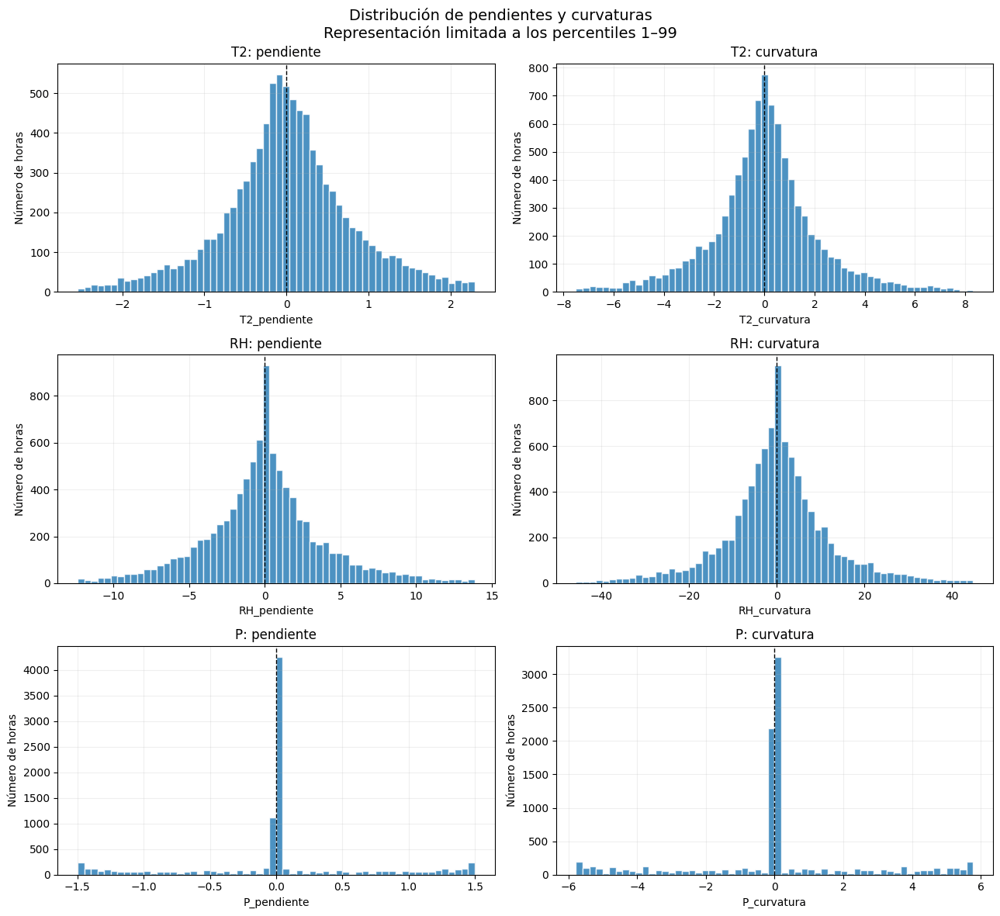


CÁLCULO TERMINADO; TODAVÍA NO SE HA GUARDADO NINGÚN ARCHIVO
Objeto completo:    meteo_cuadratico_horario (9504, 29)
Variables modelo:   variables_modelo_meteo (9504, 11)
Horas problemáticas: 25


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# 1. Comprobaciones iniciales
COLUMNAS_ORIGINALES = {"T2": "T2 [°C]", "RH": "RH [%]", "P": "PoPoPoPo [hPa]"}
columnas_necesarias = ["Date/Time"] + list(COLUMNAS_ORIGINALES.values())
faltantes = [columna for columna in columnas_necesarias if columna not in df_minutal_meteo.columns]
if faltantes:
    raise KeyError(f"Faltan columnas en el parquet: {faltantes}")

df_meteo = df_minutal_meteo[columnas_necesarias].copy()
df_meteo["Date/Time"] = pd.to_datetime(df_meteo["Date/Time"], utc=True, errors="raise")
df_meteo = df_meteo.sort_values("Date/Time").reset_index(drop=True)
n_duplicados = df_meteo["Date/Time"].duplicated().sum()
print(f"Registros minutales: {len(df_meteo):,}")
print(f"Timestamps duplicados: {n_duplicados:,}")
if n_duplicados != 0:
    raise ValueError(
        "Existen timestamps duplicados. No se eliminan automáticamente "
        "porque primero habría que estudiar su procedencia."
    )

for columna in COLUMNAS_ORIGINALES.values():
    df_meteo[columna] = pd.to_numeric(df_meteo[columna], errors="coerce")


# 2. Definir explícitamente las ventanas
# Una observación a las 09:00 pertenece a [09:00, 10:00)
# y la ventana termina a las 10:00.
#
# Conservamos:
#   - hora_inicio: etiqueta compatible con agregaciones floor("h")
#   - hora_fin: momento en el que la ventana ya está completamente disponible
df_meteo["hora_inicio"] = df_meteo["Date/Time"].dt.floor("h")
df_meteo["hora_fin"] = df_meteo["hora_inicio"] + pd.Timedelta(hours=1)


# 3. Función de ajuste cuadrático
def ajustar_curva_cuadratica(grupo, columna, hora_inicio, n_esperado=60):
    """
    Ajusta:

        X(tau) = beta0 + beta1*tau + 0.5*beta2*tau²

    tau se expresa en horas.

    Primero se toma como referencia el centro nominal de la hora.
    Después se corrige con la media de los tiempos realmente
    observados para que sum(tau) sea aproximadamente cero incluso
    si falta algún minuto.
    """
    datos = grupo[["Date/Time", columna]].dropna().copy()
    n_validos = len(datos)
    resultado = {
        "n_validos": n_validos,
        "cobertura_pct": 100.0 * n_validos / n_esperado,
        "media": np.nan,
        "beta0": np.nan,
        "pendiente": np.nan,
        "curvatura": np.nan,
        "resid_rmse": np.nan,
        "r2_ajuste": np.nan,
        "desplazamiento_centro_min": np.nan,
    }
    if n_validos == 0:
        return resultado

    y = datos[columna].to_numpy(dtype=np.float64)
    resultado["media"] = float(np.mean(y))

    # Hacen falta al menos tres puntos para estimar tres coeficientes.
    if n_validos < 3:
        return resultado

    centro_nominal = hora_inicio + pd.Timedelta(minutes=30)
    tau_nominal = (datos["Date/Time"] - centro_nominal).dt.total_seconds().to_numpy(
        dtype=np.float64
    ) / 3600.0

    # Centrado con los timestamps efectivamente disponibles.
    desplazamiento = float(np.mean(tau_nominal))
    tau = tau_nominal - desplazamiento
    resultado["desplazamiento_centro_min"] = desplazamiento * 60.0
    matriz_diseno = np.column_stack([np.ones(n_validos, dtype=np.float64), tau, 0.5 * tau**2])
    coeficientes, _, rango, _ = np.linalg.lstsq(matriz_diseno, y, rcond=None)
    if rango < 3:
        return resultado

    beta0, beta1, beta2 = coeficientes
    estimados = matriz_diseno @ coeficientes
    residuos = y - estimados
    ss_res = np.sum(residuos**2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    resid_rmse = np.sqrt(np.mean(residuos**2))

    # R² no está definido si todos los valores de la hora son iguales.
    r2 = 1.0 - ss_res / ss_tot if ss_tot > np.finfo(float).eps else np.nan
    resultado.update(
        {
            "beta0": float(beta0),
            "pendiente": float(beta1),
            "curvatura": float(beta2),
            "resid_rmse": float(resid_rmse),
            "r2_ajuste": float(r2) if np.isfinite(r2) else np.nan,
        }
    )
    return resultado


# 4. Ajustar las tres variables en cada intervalo horario
registros = []
grupos_horarios = df_meteo.groupby("hora_inicio", sort=True, observed=True)
n_horas = grupos_horarios.ngroups
print(f"\nHoras que se van a procesar: {n_horas:,}")
for numero, (hora_inicio, grupo) in enumerate(grupos_horarios, start=1):
    fila = {"hora_inicio": hora_inicio, "hora_fin": hora_inicio + pd.Timedelta(hours=1)}
    for prefijo, columna_original in COLUMNAS_ORIGINALES.items():
        ajuste = ajustar_curva_cuadratica(
            grupo=grupo, columna=columna_original, hora_inicio=hora_inicio, n_esperado=60
        )
        for nombre, valor in ajuste.items():
            fila[f"{prefijo}_{nombre}"] = valor

    registros.append(fila)
    if numero % 2000 == 0 or numero == n_horas:
        print(f"Procesadas {numero:,} / {n_horas:,} horas")

meteo_cuadratico_horario = pd.DataFrame(registros)
meteo_cuadratico_horario = meteo_cuadratico_horario.sort_values("hora_inicio").reset_index(
    drop=True
)
print("\nTabla horaria creada:")
print(meteo_cuadratico_horario.shape)
print(
    meteo_cuadratico_horario["hora_inicio"].min(),
    "→",
    meteo_cuadratico_horario["hora_inicio"].max(),
)


# 5. Variables candidatas para los modelos
VARIABLES_MODELO_METEO = [
    "T2_media",
    "T2_pendiente",
    "T2_curvatura",
    "RH_media",
    "RH_pendiente",
    "RH_curvatura",
    "P_media",
    "P_pendiente",
    "P_curvatura",
]
variables_modelo_meteo = meteo_cuadratico_horario[
    ["hora_inicio", "hora_fin"] + VARIABLES_MODELO_METEO
].copy()
print("\nVariables candidatas:")
print(VARIABLES_MODELO_METEO)


# 6. Auditoría de cobertura
resumen_cobertura = []
for prefijo in COLUMNAS_ORIGINALES:
    columna_n = f"{prefijo}_n_validos"
    columna_cobertura = f"{prefijo}_cobertura_pct"
    resumen_cobertura.append(
        {
            "variable": prefijo,
            "horas_totales": len(meteo_cuadratico_horario),
            "horas_60_min": int((meteo_cuadratico_horario[columna_n] == 60).sum()),
            "horas_57_o_mas": int((meteo_cuadratico_horario[columna_n] >= 57).sum()),
            "horas_menos_57": int((meteo_cuadratico_horario[columna_n] < 57).sum()),
            "horas_vacias": int((meteo_cuadratico_horario[columna_n] == 0).sum()),
            "min_validos": int(meteo_cuadratico_horario[columna_n].min()),
            "cobertura_media_pct": float(meteo_cuadratico_horario[columna_cobertura].mean()),
        }
    )

resumen_cobertura = pd.DataFrame(resumen_cobertura)
print("\nResumen de cobertura:")
display(resumen_cobertura)


# 7. Nulos en las nueve variables candidatas
resumen_nulos = pd.DataFrame(
    {
        "variable": VARIABLES_MODELO_METEO,
        "n_nulos": [
            variables_modelo_meteo[columna].isna().sum() for columna in VARIABLES_MODELO_METEO
        ],
        "porcentaje_nulos": [
            100.0 * variables_modelo_meteo[columna].isna().mean()
            for columna in VARIABLES_MODELO_METEO
        ],
    }
)
print("\nNulos en las variables candidatas:")
display(resumen_nulos)


# 8. Horas potencialmente problemáticas
mascara_problematica = np.zeros(len(meteo_cuadratico_horario), dtype=bool)
for prefijo in COLUMNAS_ORIGINALES:
    mascara_problematica |= meteo_cuadratico_horario[f"{prefijo}_n_validos"] < 57

horas_problematicas_meteo = meteo_cuadratico_horario.loc[
    mascara_problematica, ["hora_inicio", "hora_fin", "T2_n_validos", "RH_n_validos", "P_n_validos"]
].reset_index(drop=True)
print(
    "\nHoras con menos de 57 minutos válidos en al menos una variable:",
    len(horas_problematicas_meteo),
)
display(horas_problematicas_meteo.head(20))


# 9. Diagnóstico del centrado temporal
columnas_desplazamiento = [
    "T2_desplazamiento_centro_min",
    "RH_desplazamiento_centro_min",
    "P_desplazamiento_centro_min",
]
print("\nDesplazamiento del centro por minutos ausentes:")
display(meteo_cuadratico_horario[columnas_desplazamiento].describe(percentiles=[0.01, 0.5, 0.99]).T)


# 10. Distribución de las variables
print("\nDistribución de las variables candidatas:")
display(
    variables_modelo_meteo[VARIABLES_MODELO_METEO]
    .describe(percentiles=[0.01, 0.05, 0.5, 0.95, 0.99])
    .T
)


# 11. Calidad descriptiva del ajuste
columnas_calidad = []
for prefijo in COLUMNAS_ORIGINALES:
    columnas_calidad.extend([f"{prefijo}_resid_rmse", f"{prefijo}_r2_ajuste"])

print("\nCalidad descriptiva de los ajustes:")
display(meteo_cuadratico_horario[columnas_calidad].describe(percentiles=[0.01, 0.5, 0.99]).T)


# 12. Histogramas robustos de pendiente y curvatura
fig, axes = plt.subplots(nrows=3, ncols=2, figsize=(13, 12))
for fila, prefijo in enumerate(COLUMNAS_ORIGINALES):
    for columna_indice, estadistico in enumerate(["pendiente", "curvatura"]):
        columna = f"{prefijo}_{estadistico}"
        valores = meteo_cuadratico_horario[columna].replace([np.inf, -np.inf], np.nan).dropna()
        ax = axes[fila, columna_indice]
        if len(valores) > 0:
            limite_inferior, limite_superior = valores.quantile([0.01, 0.99])
            valores_grafica = valores[
                valores.between(limite_inferior, limite_superior, inclusive="both")
            ]
            ax.hist(valores_grafica, bins=60, color="#2C7FB8", alpha=0.85, edgecolor="white")

        ax.axvline(0, color="black", linewidth=1, linestyle="--")
        ax.set_title(f"{prefijo}: {estadistico}")
        ax.set_xlabel(columna)
        ax.set_ylabel("Número de horas")
        ax.grid(alpha=0.2)

plt.suptitle(
    "Distribución de pendientes y curvaturas\nRepresentación limitada a los percentiles 1–99",
    fontsize=14,
)
plt.tight_layout()
plt.show()


# 13. Estado final de esta etapa
print("\n" + "=" * 72)
print("CÁLCULO TERMINADO; TODAVÍA NO SE HA GUARDADO NINGÚN ARCHIVO")
print("=" * 72)
print("Objeto completo:    meteo_cuadratico_horario", meteo_cuadratico_horario.shape)
print("Variables modelo:   variables_modelo_meteo", variables_modelo_meteo.shape)
print("Horas problemáticas:", len(horas_problematicas_meteo))
print("=" * 72)

**Resultados.** Se procesan 9.504 horas, con una cobertura media de minutos válidos de entre el 99,93 % y el 99,94 % según la variable. Solo una hora carece de datos (un nulo por variable candidata, 0,01 %) y 25 horas tienen menos de 57 minutos válidos en al menos una variable.

### 6.45 Guardado del bloque meteorológico

Se guardan las nueve variables meteorológicas horarias, sin imputación, conservando el inicio y el final de cada intervalo como referencias temporales para su alineación posterior.

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import pandas as pd

# 1. Comprobar que existen los objetos necesarios
objetos_requeridos = [
    "meteo_cuadratico_horario",
    "variables_modelo_meteo",
    "resumen_cobertura",
    "horas_problematicas_meteo",
    "VARIABLES_MODELO_METEO",
]
faltan_objetos = [nombre for nombre in objetos_requeridos if nombre not in globals()]
if faltan_objetos:
    raise RuntimeError(f"Faltan objetos antes de guardar: {faltan_objetos}")


# 2. Crear una versión fechada
marca_temporal = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
DIR_METEO = BASE_DIR / "datos" / "meteorologia_cuadratica"
DIR_VERSION = DIR_METEO / f"version_{marca_temporal}"
DIR_METEO.mkdir(parents=True, exist_ok=True)
DIR_VERSION.mkdir(parents=True, exist_ok=False)
print("Directorio de guardado:")
print(DIR_VERSION)


# 3. Rutas de salida
RUTA_COMPLETA = DIR_VERSION / "meteo_cuadratico_horario_completo.parquet"
RUTA_VARIABLES = DIR_VERSION / "variables_modelo_meteo.parquet"
RUTA_COBERTURA = DIR_VERSION / "resumen_cobertura.csv"
RUTA_PROBLEMATICAS = DIR_VERSION / "horas_cobertura_inferior_57.csv"
RUTA_CONFIGURACION = DIR_VERSION / "configuracion_variables_meteo.json"
RUTA_MANIFEST = DIR_VERSION / "manifest_archivos.json"
RUTA_PUNTERO = DIR_METEO / "ULTIMA_VERSION.json"


# 4. Guardar tablas
meteo_cuadratico_horario.to_parquet(RUTA_COMPLETA, index=False)
variables_modelo_meteo.to_parquet(RUTA_VARIABLES, index=False)
resumen_cobertura.to_csv(RUTA_COBERTURA, index=False)
horas_problematicas_meteo.to_csv(RUTA_PROBLEMATICAS, index=False)


# 5. Guardar configuración metodológica
configuracion_meteo = {
    "fecha_creacion_utc": marca_temporal,
    "parquet_origen": str(PARQUET_ORIGINAL),
    "resolucion_origen": "nominalmente 1 minuto",
    "frecuencia_salida": "1 hora",
    "definicion_ventana": "[hora_inicio, hora_fin)",
    "longitud_nominal_ventana_minutos": 60,
    "centrado_temporal": (
        "centro nominal de la hora corregido por la media de "
        "los timestamps realmente disponibles"
    ),
    "modelo_ajuste": ("X(tau) = beta0 + beta1*tau + 0.5*beta2*tau**2"),
    "interpretacion": {
        "media": "media de los valores disponibles en la hora",
        "pendiente": ("primera derivada en el centro efectivo; unidades de variable por hora"),
        "curvatura": ("segunda derivada; unidades de variable por hora cuadrada"),
    },
    "columnas_originales": {"T2": "T2 [°C]", "RH": "RH [%]", "P": "PoPoPoPo [hPa]"},
    "variables_guardadas": VARIABLES_MODELO_METEO,
    "variables_propuestas_t2": ["T2_media", "T2_pendiente", "T2_curvatura"],
    "variables_propuestas_rh": ["RH_media", "RH_pendiente", "RH_curvatura"],
    "variables_presion_principal": ["P_media"],
    "variables_presion_ampliada": ["P_media", "P_pendiente", "P_curvatura"],
    "criterio_diagnostico_cobertura": ("se registra como cobertura reducida cuando n_validos < 57"),
    "imputacion_aplicada": False,
    "justificacion_no_imputacion": (
        "La única hora completamente vacía y la hora siguiente "
        "con cuatro valores se encuentran fuera de train, "
        "validation y test. Las restantes horas parciales "
        "permiten calcular los coeficientes."
    ),
    "particiones": {
        "train_inicio": "2023-12-30 00:00:00+00:00",
        "train_fin": "2024-07-31 23:00:00+00:00",
        "validation_inicio": "2024-08-01 00:00:00+00:00",
        "validation_fin": "2024-09-30 23:00:00+00:00",
        "test_inicio": "2024-10-01 00:00:00+00:00",
    },
    "alineacion_pendiente": (
        "Pendiente de verificar frente a DIF_lag_1 antes de construir las matrices secuenciales"
    ),
}
with open(RUTA_CONFIGURACION, "w", encoding="utf-8") as archivo:
    json.dump(configuracion_meteo, archivo, ensure_ascii=False, indent=2)


# 6. Calcular hashes para comprobar integridad
def calcular_sha256(ruta, bloque=1024 * 1024):
    sha = hashlib.sha256()
    with open(ruta, "rb") as archivo:
        while True:
            fragmento = archivo.read(bloque)
            if not fragmento:
                break

            sha.update(fragmento)

    return sha.hexdigest()

archivos_guardados = [
    RUTA_COMPLETA,
    RUTA_VARIABLES,
    RUTA_COBERTURA,
    RUTA_PROBLEMATICAS,
    RUTA_CONFIGURACION,
]
manifest = {
    "fecha_creacion_utc": marca_temporal,
    "directorio_version": str(DIR_VERSION),
    "archivos": [],
}
for ruta in archivos_guardados:
    manifest["archivos"].append(
        {
            "nombre": ruta.name,
            "ruta": str(ruta),
            "tamano_bytes": ruta.stat().st_size,
            "sha256": calcular_sha256(ruta),
        }
    )

with open(RUTA_MANIFEST, "w", encoding="utf-8") as archivo:
    json.dump(manifest, archivo, ensure_ascii=False, indent=2)


# 7. Crear puntero a la última versión
puntero_ultima_version = {
    "fecha_creacion_utc": marca_temporal,
    "directorio_version": str(DIR_VERSION),
    "archivo_variables_modelo": str(RUTA_VARIABLES),
    "archivo_completo": str(RUTA_COMPLETA),
    "archivo_configuracion": str(RUTA_CONFIGURACION),
    "archivo_manifest": str(RUTA_MANIFEST),
}
with open(RUTA_PUNTERO, "w", encoding="utf-8") as archivo:
    json.dump(puntero_ultima_version, archivo, ensure_ascii=False, indent=2)


# 8. Verificación mediante recarga desde Drive
variables_meteo_verificacion = pd.read_parquet(RUTA_VARIABLES)
assert variables_meteo_verificacion.shape == (variables_modelo_meteo.shape)
assert variables_meteo_verificacion.columns.tolist() == (variables_modelo_meteo.columns.tolist())
assert variables_meteo_verificacion[VARIABLES_MODELO_METEO].isna().sum().sum() == 9
print("\nArchivos guardados y verificados:")
for archivo in manifest["archivos"]:
    print(f"  {archivo['nombre']:<48} " f"{archivo['tamano_bytes'] / 1024:.2f} KB")

print("\nPuntero de continuidad:")
print(RUTA_PUNTERO)
print("\n" + "=" * 72)
print("BLOQUE METEOROLÓGICO GUARDADO CORRECTAMENTE")
print("=" * 72)
print(f"Versión: {DIR_VERSION.name}")
print(f"Filas: {len(variables_meteo_verificacion):,}")
print(f"Variables candidatas: {len(VARIABLES_MODELO_METEO)}")
print("Imputación aplicada: no")
print("Entrenamiento realizado: no")
print("=" * 72)

Directorio de guardado:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/datos/meteorologia_cuadratica/version_20261006T213853Z

Archivos guardados y verificados:
  meteo_cuadratico_horario_completo.parquet        1386.26 KB
  variables_modelo_meteo.parquet                   738.45 KB
  resumen_cobertura.csv                            0.23 KB
  horas_cobertura_inferior_57.csv                  1.54 KB
  configuracion_variables_meteo.json               2.10 KB

Puntero de continuidad:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/datos/meteorologia_cuadratica/ULTIMA_VERSION.json

BLOQUE METEOROLÓGICO GUARDADO CORRECTAMENTE
Versión: version_20261006T213853Z
Filas: 9,504
Variables candidatas: 9
Imputación aplicada: no
Entrenamiento realizado: no


### 6.46 Verificación temporal y alineación

Se comprueba que entrenamiento y validación conservan sus fechas sin solaparse y se determina qué intervalo horario reproduce `DIF_lag_1`, recalculando la media horaria de la DIF a partir de los datos minutales con distintos desfases.

In [ ]:
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
from IPython.display import display

# 1. Fechas oficiales del experimento
TRAIN_INICIO = pd.Timestamp("2023-12-30 00:00:00", tz="UTC")
TRAIN_FIN = pd.Timestamp("2024-07-31 23:00:00", tz="UTC")
VALIDATION_INICIO = pd.Timestamp("2024-08-01 00:00:00", tz="UTC")
VALIDATION_FIN = pd.Timestamp("2024-09-30 23:00:00", tz="UTC")
TEST_INICIO = pd.Timestamp("2024-10-01 00:00:00", tz="UTC")
TEST_FIN = pd.Timestamp("2024-11-30 23:00:00", tz="UTC")


# 2. Normalizar timestamps
for nombre_df, df in [("train_hgb", train_hgb), ("validation_hgb", validation_hgb)]:
    if "instante_objetivo" not in df.columns:
        raise KeyError(f"{nombre_df} no contiene 'instante_objetivo'.")

    if "DIF_lag_1" not in df.columns:
        raise KeyError(f"{nombre_df} no contiene 'DIF_lag_1'.")

    df["instante_objetivo"] = pd.to_datetime(df["instante_objetivo"], utc=True, errors="raise")


# 3. Comprobar las particiones
comprobacion_particiones = pd.DataFrame(
    [
        {
            "particion": "train",
            "n_filas": len(train_hgb),
            "inicio_observado": train_hgb["instante_objetivo"].min(),
            "fin_observado": train_hgb["instante_objetivo"].max(),
            "inicio_esperado": TRAIN_INICIO,
            "fin_esperado": TRAIN_FIN,
        },
        {
            "particion": "validation",
            "n_filas": len(validation_hgb),
            "inicio_observado": validation_hgb["instante_objetivo"].min(),
            "fin_observado": validation_hgb["instante_objetivo"].max(),
            "inicio_esperado": VALIDATION_INICIO,
            "fin_esperado": VALIDATION_FIN,
        },
    ]
)
comprobacion_particiones["inicio_correcto"] = (
    comprobacion_particiones["inicio_observado"] == comprobacion_particiones["inicio_esperado"]
)
comprobacion_particiones["fin_correcto"] = (
    comprobacion_particiones["fin_observado"] == comprobacion_particiones["fin_esperado"]
)
print("Comprobación de particiones:")
display(comprobacion_particiones)
assert len(train_hgb) == 5149
assert len(validation_hgb) == 1464
assert train_hgb["instante_objetivo"].min() == TRAIN_INICIO
assert train_hgb["instante_objetivo"].max() == TRAIN_FIN
assert validation_hgb["instante_objetivo"].min() == VALIDATION_INICIO
assert validation_hgb["instante_objetivo"].max() == VALIDATION_FIN
assert train_hgb["instante_objetivo"].max() < validation_hgb["instante_objetivo"].min()
assert validation_hgb["instante_objetivo"].max() < TEST_INICIO
print("Particiones correctas y sin solapamiento.")
print(f"Test reservado: {TEST_INICIO} → {TEST_FIN} " "(no cargado)")


# 4. Comprobar el esquema del parquet
esquema_parquet = pq.ParquetFile(PARQUET_ORIGINAL).schema.names
COLUMNA_DIF = "DIF [W/m**2]"
if COLUMNA_DIF not in esquema_parquet:
    candidatos_dif = [columna for columna in esquema_parquet if "DIF" in columna.upper()]
    raise KeyError(
        f"No se encontró la columna exacta {COLUMNA_DIF!r}.\n"
        f"Columnas candidatas: {candidatos_dif}"
    )

print(f"\nColumna DIF confirmada: {COLUMNA_DIF}")


# 5. Cargar únicamente timestamp y DIF
df_dif_minutal = pd.read_parquet(PARQUET_ORIGINAL, columns=["Date/Time", COLUMNA_DIF])
df_dif_minutal["Date/Time"] = pd.to_datetime(df_dif_minutal["Date/Time"], utc=True, errors="raise")
df_dif_minutal[COLUMNA_DIF] = pd.to_numeric(df_dif_minutal[COLUMNA_DIF], errors="coerce")
df_dif_minutal = df_dif_minutal.sort_values("Date/Time").reset_index(drop=True)
if df_dif_minutal["Date/Time"].duplicated().any():
    raise ValueError("Se encontraron timestamps duplicados en el parquet.")


# 6. Reconstruir la media horaria de DIF
# Cada etiqueta hora_inicio representa:
# [hora_inicio, hora_inicio + 1 hora)
df_dif_minutal["hora_inicio"] = df_dif_minutal["Date/Time"].dt.floor("h")
dif_horaria_reconstruida = (
    df_dif_minutal.groupby("hora_inicio", sort=True)[COLUMNA_DIF]
    .mean()
    .rename("DIF_media_reconstruida")
)
print("\nHoras DIF reconstruidas:", len(dif_horaria_reconstruida))


# 7. Comparar posibles alineaciones
# Se prueban varios desplazamientos alrededor del objetivo.
#
# Por ejemplo:
# offset = -1:
#   target 10:00 utiliza la hora_inicio 09:00,
#   es decir, el intervalo [09:00, 10:00).
def evaluar_offset(df, offset_horas, particion):
    timestamps_consulta = df["instante_objetivo"] + pd.to_timedelta(offset_horas, unit="h")
    reconstruido = dif_horaria_reconstruida.reindex(timestamps_consulta).to_numpy(dtype=np.float64)
    almacenado = df["DIF_lag_1"].to_numpy(dtype=np.float64)
    mascara = np.isfinite(reconstruido) & np.isfinite(almacenado)
    diferencias = reconstruido[mascara] - almacenado[mascara]
    if mascara.sum() == 0:
        return {
            "particion": particion,
            "offset_horas": offset_horas,
            "n_comparables": 0,
            "MAE": np.nan,
            "RMSE": np.nan,
            "max_abs": np.nan,
            "porcentaje_close": np.nan,
        }

    return {
        "particion": particion,
        "offset_horas": offset_horas,
        "n_comparables": int(mascara.sum()),
        "MAE": float(np.mean(np.abs(diferencias))),
        "RMSE": float(np.sqrt(np.mean(diferencias**2))),
        "max_abs": float(np.max(np.abs(diferencias))),
        "porcentaje_close": float(
            100.0
            * np.mean(np.isclose(reconstruido[mascara], almacenado[mascara], atol=1e-4, rtol=1e-6))
        ),
    }

resultados_alineacion = []
for particion, df in [("train", train_hgb), ("validation", validation_hgb)]:
    for offset in [-2, -1, 0, 1]:
        resultados_alineacion.append(
            evaluar_offset(df=df, offset_horas=offset, particion=particion)
        )

resultados_alineacion = pd.DataFrame(resultados_alineacion)
print("\nComparación de posibles alineaciones:")
display(resultados_alineacion.sort_values(["particion", "MAE"]).reset_index(drop=True))


# 8. Seleccionar el mejor offset por partición
mejor_por_particion = (
    resultados_alineacion.sort_values(["particion", "MAE"])
    .groupby("particion", as_index=False)
    .first()
)
print("\nMejor alineación encontrada:")
display(mejor_por_particion)
offset_train = int(
    mejor_por_particion.loc[mejor_por_particion["particion"] == "train", "offset_horas"].iloc[0]
)
offset_validation = int(
    mejor_por_particion.loc[mejor_por_particion["particion"] == "validation", "offset_horas"].iloc[
        0
    ]
)
assert offset_train == offset_validation, "Train y validation sugieren alineaciones diferentes."
OFFSET_DIF_LAG1 = offset_train
print("\nOffset candidato para DIF_lag_1:", OFFSET_DIF_LAG1, "horas respecto a instante_objetivo")


# 9. Determinar la referencia meteorológica correspondiente
if OFFSET_DIF_LAG1 == -1:
    interpretacion_alineacion = (
        "DIF_lag_1 del objetivo T corresponde al intervalo "
        "[T-1h, T), identificado por hora_inicio = T-1h "
        "y hora_fin = T."
    )
elif OFFSET_DIF_LAG1 == 0:
    interpretacion_alineacion = (
        "DIF_lag_1 del objetivo T corresponde al intervalo "
        "[T, T+1h), identificado por hora_inicio = T "
        "y hora_fin = T+1h."
    )
else:
    interpretacion_alineacion = (
        f"DIF_lag_1 utiliza hora_inicio = T"
        f"{OFFSET_DIF_LAG1:+d}h. Debe revisarse antes "
        "de construir las matrices."
    )

print("\nInterpretación:")
print(interpretacion_alineacion)


# 10. Estado final
print("\n" + "=" * 72)
print("VERIFICACIÓN TEMPORAL FINALIZADA")
print("=" * 72)
print(f"Train:      {TRAIN_INICIO} → {TRAIN_FIN}")
print(f"Validation: {VALIDATION_INICIO} " f"→ {VALIDATION_FIN}")
print(f"Test:       {TEST_INICIO} → {TEST_FIN} (cerrado)")
print(f"Offset candidato DIF_lag_1: {OFFSET_DIF_LAG1:+d} h")
print("Matrices meteorológicas construidas: no")
print("Entrenamiento realizado: no")
print("=" * 72)

Comprobación de particiones:


,particion,n_filas,inicio_observado,fin_observado,inicio_esperado,fin_esperado,inicio_correcto,fin_correcto
0,train,5149,2023-12-30 00:00:00+00:00,2024-07-31 23:00:00+00:00,2023-12-30 00:00:00+00:00,2024-07-31 23:00:00+00:00,True,True
1,validation,1464,2024-08-01 00:00:00+00:00,2024-09-30 23:00:00+00:00,2024-08-01 00:00:00+00:00,2024-09-30 23:00:00+00:00,True,True


Particiones correctas y sin solapamiento.
Test reservado: 2024-10-01 00:00:00+00:00 → 2024-11-30 23:00:00+00:00 (no cargado)

Columna DIF confirmada: DIF [W/m**2]

Horas DIF reconstruidas: 9504

Comparación de posibles alineaciones:


,particion,offset_horas,n_comparables,MAE,RMSE,max_abs,porcentaje_close
0,train,-1,5149,1.939299e-15,7.764469e-15,5.684342e-14,100.000000
1,train,-2,5149,2.682467e+01,4.631691e+01,3.212500e+02,20.139833
2,train,0,5149,2.682598e+01,4.631190e+01,3.212500e+02,20.159254
3,train,1,5149,4.549579e+01,7.331210e+01,3.856667e+02,16.139056
4,validation,-1,1464,1.774136e-15,7.469879e-15,5.684342e-14,100.000000
5,validation,-2,1464,2.756602e+01,4.660505e+01,3.011333e+02,23.155738
6,validation,0,1464,2.756606e+01,4.660505e+01,3.011333e+02,23.087432
7,validation,1,1464,4.748160e+01,7.418139e+01,3.608000e+02,19.398907



Mejor alineación encontrada:


,particion,offset_horas,n_comparables,MAE,RMSE,max_abs,porcentaje_close
0,train,-1,5149,1.939299e-15,7.764469e-15,5.684342e-14,100.0
1,validation,-1,1464,1.774136e-15,7.469879e-15,5.684342e-14,100.0



Offset candidato para DIF_lag_1: -1 horas respecto a instante_objetivo

Interpretación:
DIF_lag_1 del objetivo T corresponde al intervalo [T-1h, T), identificado por hora_inicio = T-1h y hora_fin = T.

VERIFICACIÓN TEMPORAL FINALIZADA
Train:      2023-12-30 00:00:00+00:00 → 2024-07-31 23:00:00+00:00
Validation: 2024-08-01 00:00:00+00:00 → 2024-09-30 23:00:00+00:00
Test:       2024-10-01 00:00:00+00:00 → 2024-11-30 23:00:00+00:00 (cerrado)
Offset candidato DIF_lag_1: -1 h
Matrices meteorológicas construidas: no
Entrenamiento realizado: no


**Resultados.** Las particiones coinciden con las fechas establecidas y no se solapan. Con un desfase de −1 h, la DIF reconstruida reproduce `DIF_lag_1` en el 100 % de las muestras de entrenamiento y validación; por tanto, `DIF_lag_1` del objetivo T corresponde al intervalo [T−1 h, T).

### 6.47 Matrices meteorológicas secuenciales

Para cada instante objetivo se construye una secuencia de las 24 horas previas (de T−24 h a T−1 h) en cuatro configuraciones: DIF y elevación con la terna cuadrática de temperatura (`DIF_elev_T2quad`), de humedad (`DIF_elev_RHquad`) o de presión (`DIF_elev_Pquad`), y con solo la presión media (`DIF_elev_Pmedia`). Las matrices se guardan en valores originales y el escalado se ajusta después en subtrain.

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import json
import numpy as np
import pandas as pd
from IPython.display import display

VENTANA = 24

# 1. Verificaciones de objetos
objetos_necesarios = [
    "variables_modelo_meteo",
    "X_train_DIF_elev_SWD_raw",
    "X_validation_DIF_elev_SWD_raw",
    "y_train",
    "y_validation",
    "train_hgb",
    "validation_hgb",
]
faltantes = [nombre for nombre in objetos_necesarios if nombre not in globals()]
if faltantes:
    raise RuntimeError(f"Faltan objetos requeridos: {faltantes}")

assert OFFSET_DIF_LAG1 == -1
assert len(train_hgb) == 5149
assert len(validation_hgb) == 1464
assert X_train_DIF_elev_SWD_raw.shape[:2] == (5149, 24)
assert X_validation_DIF_elev_SWD_raw.shape[:2] == (1464, 24)
assert len(y_train) == 5149
assert len(y_validation) == 1464


# 2. Recuperar los dos canales del baseline
# Los dos primeros canales de las matrices anteriores son:
# canal 0 = DIF
# canal 1 = elevación
X_train_DIF_elev_raw = X_train_DIF_elev_SWD_raw[:, :, :2].astype(np.float32, copy=True)
X_validation_DIF_elev_raw = X_validation_DIF_elev_SWD_raw[:, :, :2].astype(np.float32, copy=True)

# Comprobar que los distintos bloques anteriores compartían
# exactamente el mismo baseline DIF + elevación.
for nombre, matriz_train, matriz_validation in [
    ("LWD", X_train_DIF_elev_LWD_raw, X_validation_DIF_elev_LWD_raw),
    ("DIR", X_train_DIF_elev_DIR_raw, X_validation_DIF_elev_DIR_raw),
]:
    assert np.allclose(
        X_train_DIF_elev_raw, matriz_train[:, :, :2], equal_nan=True
    ), f"El baseline de train no coincide con {nombre}."
    assert np.allclose(
        X_validation_DIF_elev_raw, matriz_validation[:, :, :2], equal_nan=True
    ), f"El baseline de validation no coincide con {nombre}."

print("Baseline DIF + elevación verificado.")


# 3. Preparar la tabla meteorológica indexada
tabla_meteo = variables_modelo_meteo.copy()
tabla_meteo["hora_inicio"] = pd.to_datetime(tabla_meteo["hora_inicio"], utc=True, errors="raise")
tabla_meteo["hora_fin"] = pd.to_datetime(tabla_meteo["hora_fin"], utc=True, errors="raise")
if tabla_meteo["hora_inicio"].duplicated().any():
    raise ValueError("Existen horas duplicadas en variables_modelo_meteo.")

tabla_meteo = tabla_meteo.sort_values("hora_inicio").set_index("hora_inicio")


# 4. Función para construir secuencias T-24 ... T-1
def construir_secuencias_meteo(instantes_objetivo, columnas, ventana=24):
    instantes_objetivo = pd.DatetimeIndex(
        pd.to_datetime(instantes_objetivo, utc=True, errors="raise")
    )

    # Orden cronológico dentro de cada secuencia:
    # T-24, T-23, ..., T-2, T-1.
    retardos = np.arange(ventana, 0, -1, dtype=np.int64)
    timestamps_requeridos = pd.DatetimeIndex(
        np.concatenate(
            [
                (instante - pd.to_timedelta(retardos, unit="h")).to_numpy()
                for instante in instantes_objetivo
            ]
        )
    )
    datos = tabla_meteo.reindex(timestamps_requeridos)[columnas]
    secuencias = datos.to_numpy(dtype=np.float32).reshape(
        len(instantes_objetivo), ventana, len(columnas)
    )
    return secuencias, timestamps_requeridos


# 5. Definir las cuatro configuraciones
CONFIGURACIONES_METEO = {
    "T2quad": ["T2_media", "T2_pendiente", "T2_curvatura"],
    "RHquad": ["RH_media", "RH_pendiente", "RH_curvatura"],
    "Pmedia": ["P_media"],
    "Pquad": ["P_media", "P_pendiente", "P_curvatura"],
}
matrices_train_meteo = {}
matrices_validation_meteo = {}
for nombre, columnas in CONFIGURACIONES_METEO.items():
    matriz_train, timestamps_train = construir_secuencias_meteo(
        train_hgb["instante_objetivo"], columnas, ventana=VENTANA
    )
    matriz_validation, timestamps_validation = construir_secuencias_meteo(
        validation_hgb["instante_objetivo"], columnas, ventana=VENTANA
    )
    matrices_train_meteo[nombre] = matriz_train
    matrices_validation_meteo[nombre] = matriz_validation


# 6. Unir baseline y bloque meteorológico
X_train_DIF_elev_T2quad_raw = np.concatenate(
    [X_train_DIF_elev_raw, matrices_train_meteo["T2quad"]], axis=2
).astype(np.float32)
X_validation_DIF_elev_T2quad_raw = np.concatenate(
    [X_validation_DIF_elev_raw, matrices_validation_meteo["T2quad"]], axis=2
).astype(np.float32)
X_train_DIF_elev_RHquad_raw = np.concatenate(
    [X_train_DIF_elev_raw, matrices_train_meteo["RHquad"]], axis=2
).astype(np.float32)
X_validation_DIF_elev_RHquad_raw = np.concatenate(
    [X_validation_DIF_elev_raw, matrices_validation_meteo["RHquad"]], axis=2
).astype(np.float32)
X_train_DIF_elev_Pmedia_raw = np.concatenate(
    [X_train_DIF_elev_raw, matrices_train_meteo["Pmedia"]], axis=2
).astype(np.float32)
X_validation_DIF_elev_Pmedia_raw = np.concatenate(
    [X_validation_DIF_elev_raw, matrices_validation_meteo["Pmedia"]], axis=2
).astype(np.float32)
X_train_DIF_elev_Pquad_raw = np.concatenate(
    [X_train_DIF_elev_raw, matrices_train_meteo["Pquad"]], axis=2
).astype(np.float32)
X_validation_DIF_elev_Pquad_raw = np.concatenate(
    [X_validation_DIF_elev_raw, matrices_validation_meteo["Pquad"]], axis=2
).astype(np.float32)


# 7. Auditoría de formas y nulos
MATRICES_FINALES = {
    "DIF_elev_T2quad": (
        X_train_DIF_elev_T2quad_raw,
        X_validation_DIF_elev_T2quad_raw,
        ["DIF", "elevacion"] + CONFIGURACIONES_METEO["T2quad"],
    ),
    "DIF_elev_RHquad": (
        X_train_DIF_elev_RHquad_raw,
        X_validation_DIF_elev_RHquad_raw,
        ["DIF", "elevacion"] + CONFIGURACIONES_METEO["RHquad"],
    ),
    "DIF_elev_Pmedia": (
        X_train_DIF_elev_Pmedia_raw,
        X_validation_DIF_elev_Pmedia_raw,
        ["DIF", "elevacion"] + CONFIGURACIONES_METEO["Pmedia"],
    ),
    "DIF_elev_Pquad": (
        X_train_DIF_elev_Pquad_raw,
        X_validation_DIF_elev_Pquad_raw,
        ["DIF", "elevacion"] + CONFIGURACIONES_METEO["Pquad"],
    ),
}
auditoria_matrices = []
for nombre, (matriz_train, matriz_validation, canales) in MATRICES_FINALES.items():
    auditoria_matrices.append(
        {
            "configuracion": nombre,
            "canales": len(canales),
            "nombres_canales": ", ".join(canales),
            "shape_train": str(matriz_train.shape),
            "shape_validation": str(matriz_validation.shape),
            "nulos_train": int(np.isnan(matriz_train).sum()),
            "nulos_validation": int(np.isnan(matriz_validation).sum()),
            "inf_train": int(np.isinf(matriz_train).sum()),
            "inf_validation": int(np.isinf(matriz_validation).sum()),
        }
    )

auditoria_matrices = pd.DataFrame(auditoria_matrices)
print("\nAuditoría de matrices:")
display(auditoria_matrices)
for nombre, (matriz_train, matriz_validation, canales) in MATRICES_FINALES.items():
    assert matriz_train.shape == (5149, 24, len(canales))
    assert matriz_validation.shape == (1464, 24, len(canales))
    assert np.isfinite(matriz_train).all(), f"{nombre}: train contiene nulos o infinitos."
    assert np.isfinite(matriz_validation).all(), f"{nombre}: validation contiene nulos o infinitos."


# 8. Verificar extremos temporales de las secuencias
primera_fecha_train = train_hgb["instante_objetivo"].iloc[0]
ultima_fecha_train = train_hgb["instante_objetivo"].iloc[-1]
primera_fecha_validation = validation_hgb["instante_objetivo"].iloc[0]
ultima_fecha_validation = validation_hgb["instante_objetivo"].iloc[-1]
resumen_temporal = pd.DataFrame(
    [
        {
            "particion": "train",
            "primer_objetivo": primera_fecha_train,
            "primera_hora_historia": primera_fecha_train - pd.Timedelta(hours=24),
            "ultima_hora_historia": ultima_fecha_train - pd.Timedelta(hours=1),
        },
        {
            "particion": "validation",
            "primer_objetivo": primera_fecha_validation,
            "primera_hora_historia": primera_fecha_validation - pd.Timedelta(hours=24),
            "ultima_hora_historia": ultima_fecha_validation - pd.Timedelta(hours=1),
        },
    ]
)
print("\nExtremos temporales:")
display(resumen_temporal)


# 9. Guardar la preparación en Drive
marca_temporal = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
DIR_PREPARACION = (
    BASE_DIR / "resultados" / "ejecuciones" / f"preparacion_bloque_meteo_{marca_temporal}"
)
DIR_PREPARACION.mkdir(parents=True, exist_ok=False)
RUTA_MATRICES = DIR_PREPARACION / "matrices_meteo_train_validation.npz"
RUTA_AUDITORIA = DIR_PREPARACION / "auditoria_matrices.csv"
RUTA_CONFIGURACION = DIR_PREPARACION / "configuracion_preparacion.json"
np.savez_compressed(
    RUTA_MATRICES,
    X_train_DIF_elev_T2quad_raw=X_train_DIF_elev_T2quad_raw,
    X_validation_DIF_elev_T2quad_raw=X_validation_DIF_elev_T2quad_raw,
    X_train_DIF_elev_RHquad_raw=X_train_DIF_elev_RHquad_raw,
    X_validation_DIF_elev_RHquad_raw=X_validation_DIF_elev_RHquad_raw,
    X_train_DIF_elev_Pmedia_raw=X_train_DIF_elev_Pmedia_raw,
    X_validation_DIF_elev_Pmedia_raw=X_validation_DIF_elev_Pmedia_raw,
    X_train_DIF_elev_Pquad_raw=X_train_DIF_elev_Pquad_raw,
    X_validation_DIF_elev_Pquad_raw=X_validation_DIF_elev_Pquad_raw,
    y_train=np.asarray(y_train, dtype=np.float32),
    y_validation=np.asarray(y_validation, dtype=np.float32),
)
auditoria_matrices.to_csv(RUTA_AUDITORIA, index=False)
configuracion_preparacion = {
    "fecha_creacion_utc": marca_temporal,
    "ventana_horas": 24,
    "alineacion": {
        "offset_DIF_lag1_horas": -1,
        "secuencia": "T-24h hasta T-1h",
        "referencia_meteorologica": "hora_inicio",
        "coincidencia_DIF_lag1_pct": 100.0,
    },
    "particiones": {
        "train": {"inicio": str(TRAIN_INICIO), "fin": str(TRAIN_FIN), "n": 5149},
        "validation": {"inicio": str(VALIDATION_INICIO), "fin": str(VALIDATION_FIN), "n": 1464},
        "test": {"inicio": str(TEST_INICIO), "fin": str(TEST_FIN), "estado": "cerrado"},
    },
    "configuraciones": {nombre: canales for nombre, (_, _, canales) in MATRICES_FINALES.items()},
    "normalizacion_aplicada": False,
    "entrenamiento_realizado": False,
}
with open(RUTA_CONFIGURACION, "w", encoding="utf-8") as archivo:
    json.dump(configuracion_preparacion, archivo, ensure_ascii=False, indent=2)


# 10. Puntero para restauración
RUTA_PUNTERO = BASE_DIR / "documentacion" / "ULTIMA_PREPARACION_METEO.json"
puntero = {
    "fecha_creacion_utc": marca_temporal,
    "directorio": str(DIR_PREPARACION),
    "matrices": str(RUTA_MATRICES),
    "auditoria": str(RUTA_AUDITORIA),
    "configuracion": str(RUTA_CONFIGURACION),
}
with open(RUTA_PUNTERO, "w", encoding="utf-8") as archivo:
    json.dump(puntero, archivo, ensure_ascii=False, indent=2)


# 11. Verificación del archivo guardado
with np.load(RUTA_MATRICES, allow_pickle=False) as archivo_npz:
    claves_guardadas = archivo_npz.files
    assert archivo_npz["X_train_DIF_elev_T2quad_raw"].shape == (5149, 24, 5)
    assert archivo_npz["X_validation_DIF_elev_Pmedia_raw"].shape == (1464, 24, 3)

print("\nArchivo guardado y recargado correctamente.")
print(f"Directorio: {DIR_PREPARACION}")
print(f"Claves guardadas: {claves_guardadas}")
print("\n" + "=" * 72)
print("PREPARACIÓN METEOROLÓGICA FINALIZADA")
print("=" * 72)
print("Configuraciones: 4")
print("Train:           5.149 secuencias")
print("Validation:      1.464 secuencias")
print("Ventana:         24 horas")
print("Alineación:      T-24 ... T-1")
print("Normalización:   pendiente")
print("Entrenamiento:   no realizado")
print("Test:            cerrado")
print("=" * 72)

Baseline DIF + elevación verificado.

Auditoría de matrices:


,configuracion,canales,nombres_canales,shape_train,shape_validation,nulos_train,nulos_validation,inf_train,inf_validation
0,DIF_elev_T2quad,5,"DIF, elevacion, T2_media, T2_pendiente, T2_cur...","(5149, 24, 5)","(1464, 24, 5)",0,0,0,0
1,DIF_elev_RHquad,5,"DIF, elevacion, RH_media, RH_pendiente, RH_cur...","(5149, 24, 5)","(1464, 24, 5)",0,0,0,0
2,DIF_elev_Pmedia,3,"DIF, elevacion, P_media","(5149, 24, 3)","(1464, 24, 3)",0,0,0,0
3,DIF_elev_Pquad,5,"DIF, elevacion, P_media, P_pendiente, P_curvatura","(5149, 24, 5)","(1464, 24, 5)",0,0,0,0



Extremos temporales:


,particion,primer_objetivo,primera_hora_historia,ultima_hora_historia
0,train,2023-12-30 00:00:00+00:00,2023-12-29 00:00:00+00:00,2024-07-31 22:00:00+00:00
1,validation,2024-08-01 00:00:00+00:00,2024-07-31 00:00:00+00:00,2024-09-30 22:00:00+00:00



Archivo guardado y recargado correctamente.
Directorio: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/preparacion_bloque_meteo_20261006T214805Z
Claves guardadas: ['X_train_DIF_elev_T2quad_raw', 'X_validation_DIF_elev_T2quad_raw', 'X_train_DIF_elev_RHquad_raw', 'X_validation_DIF_elev_RHquad_raw', 'X_train_DIF_elev_Pmedia_raw', 'X_validation_DIF_elev_Pmedia_raw', 'X_train_DIF_elev_Pquad_raw', 'X_validation_DIF_elev_Pquad_raw', 'y_train', 'y_validation']

PREPARACIÓN METEOROLÓGICA FINALIZADA
Configuraciones: 4
Train:           5.149 secuencias
Validation:      1.464 secuencias
Ventana:         24 horas
Alineación:      T-24 ... T-1
Normalización:   pendiente
Entrenamiento:   no realizado
Test:            cerrado


**Resultados.** Las cuatro configuraciones generan 5.149 secuencias de entrenamiento y 1.464 de validación, sin valores nulos ni infinitos.

### 6.48 Selección interna de épocas del bloque meteorológico

Las cuatro configuraciones meteorológicas se entrenan con N-BEATS y LSTM sobre subtrain (4.428 observaciones) y se elige la época de menor MAE en la validación interna (721), con escalado ajustado solo en subtrain y parada temprana tras 25 épocas sin mejora.

Dispositivo: cpu
Subtrain: 4428
Validación interna: 721
Validation externa utilizada: no
Test utilizado: no

Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/seleccion_interna_meteo_20261006T215223Z

INICIO: DIF_elev_T2quad — NBEATS
DIF_elev_T2quad      NBEATS  | época   1 | MAE subtrain= 22.6584 | MAE interno= 35.3593 | mejor= 35.3593 (época 1) | espera= 0/25
DIF_elev_T2quad      NBEATS  | época  10 | MAE subtrain= 10.3703 | MAE interno= 29.0403 | mejor= 29.0403 (época 10) | espera= 0/25
DIF_elev_T2quad      NBEATS  | época  20 | MAE subtrain=  7.0482 | MAE interno= 29.9451 | mejor= 28.4016 (época 13) | espera= 7/25
DIF_elev_T2quad      NBEATS  | época  30 | MAE subtrain=  6.0793 | MAE interno= 29.1933 | mejor= 28.4016 (época 13) | espera=17/25
DIF_elev_T2quad      NBEATS  | época  38 | MAE subtrain=  5.1274 | MAE interno= 28.9346 | mejor= 28.4016 (época 13) | espera=25/25


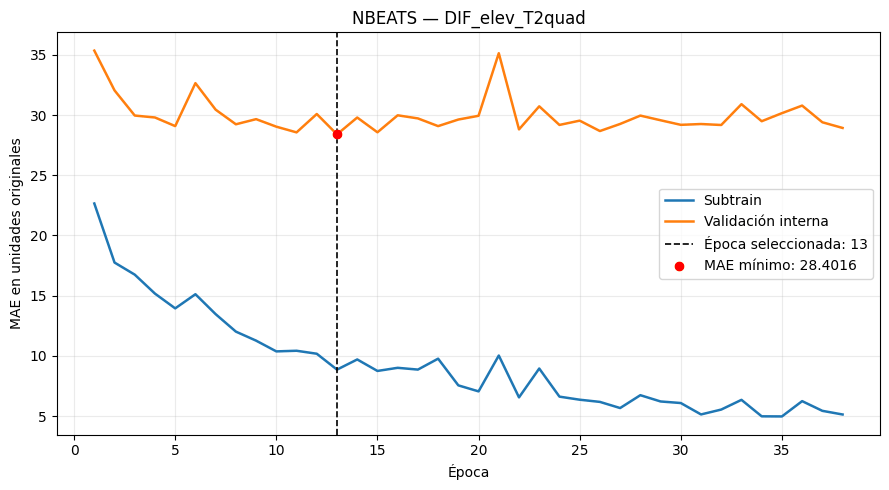


FINALIZADO: DIF_elev_T2quad — NBEATS
Época seleccionada: 13
MAE interno: 28.401617

INICIO: DIF_elev_T2quad — LSTM
DIF_elev_T2quad      LSTM    | época   1 | MAE subtrain= 52.3505 | MAE interno= 74.4025 | mejor= 74.4025 (época 1) | espera= 0/25
DIF_elev_T2quad      LSTM    | época  10 | MAE subtrain= 16.0741 | MAE interno= 24.6458 | mejor= 24.6458 (época 10) | espera= 0/25
DIF_elev_T2quad      LSTM    | época  20 | MAE subtrain= 15.8900 | MAE interno= 24.6668 | mejor= 24.2424 (época 17) | espera= 3/25
DIF_elev_T2quad      LSTM    | época  30 | MAE subtrain= 15.2393 | MAE interno= 24.1798 | mejor= 24.0641 (época 26) | espera= 4/25
DIF_elev_T2quad      LSTM    | época  40 | MAE subtrain= 15.6965 | MAE interno= 25.0588 | mejor= 23.8031 (época 39) | espera= 1/25
DIF_elev_T2quad      LSTM    | época  50 | MAE subtrain= 14.9284 | MAE interno= 24.0375 | mejor= 23.7510 (época 41) | espera= 9/25
DIF_elev_T2quad      LSTM    | época  60 | MAE subtrain= 14.5602 | MAE interno= 24.1445 | mejor= 23

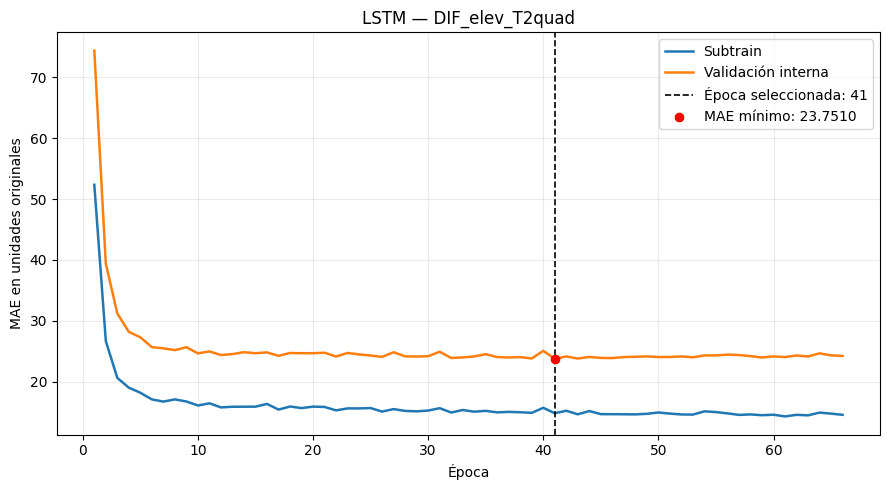


FINALIZADO: DIF_elev_T2quad — LSTM
Época seleccionada: 41
MAE interno: 23.750984

INICIO: DIF_elev_RHquad — NBEATS
DIF_elev_RHquad      NBEATS  | época   1 | MAE subtrain= 21.6755 | MAE interno= 33.7982 | mejor= 33.7982 (época 1) | espera= 0/25
DIF_elev_RHquad      NBEATS  | época  10 | MAE subtrain= 11.4047 | MAE interno= 30.4202 | mejor= 28.7458 (época 8) | espera= 2/25
DIF_elev_RHquad      NBEATS  | época  20 | MAE subtrain=  6.5376 | MAE interno= 29.4201 | mejor= 28.7458 (época 8) | espera=12/25
DIF_elev_RHquad      NBEATS  | época  30 | MAE subtrain=  6.3157 | MAE interno= 30.4398 | mejor= 28.7458 (época 8) | espera=22/25
DIF_elev_RHquad      NBEATS  | época  33 | MAE subtrain=  6.2977 | MAE interno= 30.2395 | mejor= 28.7458 (época 8) | espera=25/25


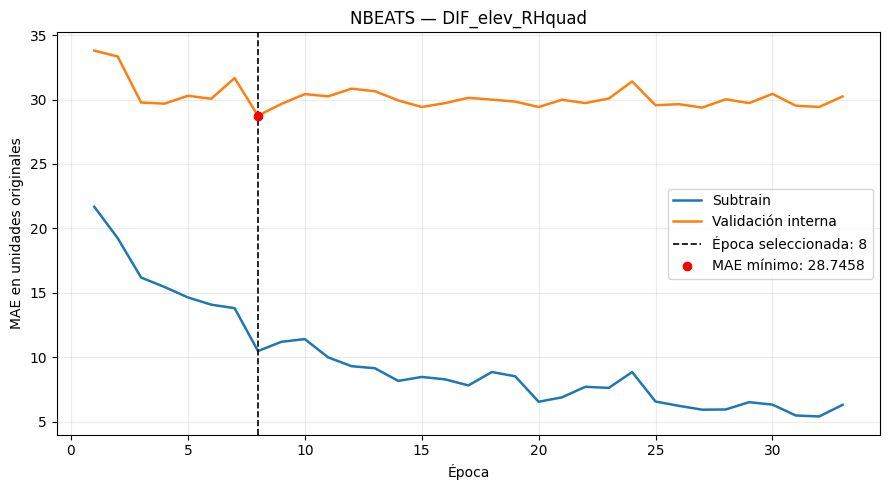


FINALIZADO: DIF_elev_RHquad — NBEATS
Época seleccionada: 8
MAE interno: 28.745817

INICIO: DIF_elev_RHquad — LSTM
DIF_elev_RHquad      LSTM    | época   1 | MAE subtrain= 59.3119 | MAE interno= 83.2721 | mejor= 83.2721 (época 1) | espera= 0/25
DIF_elev_RHquad      LSTM    | época  10 | MAE subtrain= 16.5883 | MAE interno= 25.0699 | mejor= 25.0153 (época 9) | espera= 1/25
DIF_elev_RHquad      LSTM    | época  20 | MAE subtrain= 16.2271 | MAE interno= 24.8634 | mejor= 24.1877 (época 19) | espera= 1/25
DIF_elev_RHquad      LSTM    | época  30 | MAE subtrain= 15.2858 | MAE interno= 23.7721 | mejor= 23.7721 (época 30) | espera= 0/25
DIF_elev_RHquad      LSTM    | época  40 | MAE subtrain= 15.8097 | MAE interno= 25.4253 | mejor= 23.7721 (época 30) | espera=10/25
DIF_elev_RHquad      LSTM    | época  50 | MAE subtrain= 15.0936 | MAE interno= 24.2397 | mejor= 23.7721 (época 30) | espera=20/25
DIF_elev_RHquad      LSTM    | época  55 | MAE subtrain= 14.7220 | MAE interno= 24.3790 | mejor= 23.7

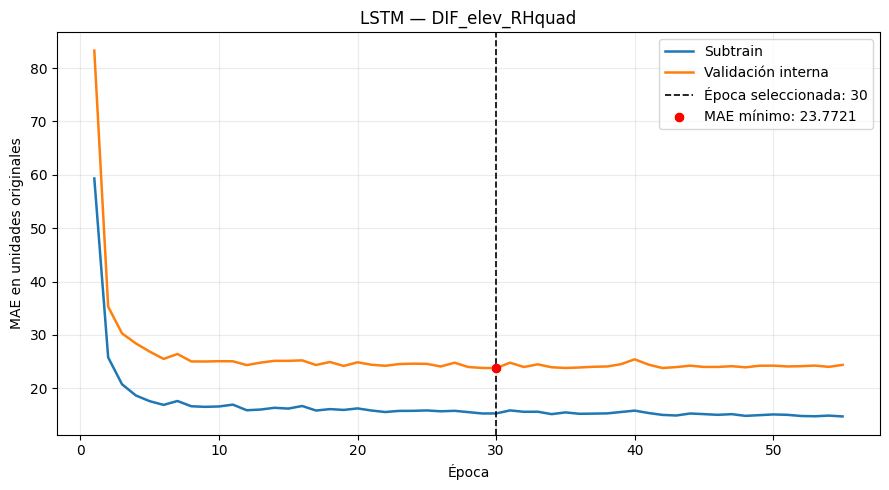


FINALIZADO: DIF_elev_RHquad — LSTM
Época seleccionada: 30
MAE interno: 23.772146

INICIO: DIF_elev_Pmedia — NBEATS
DIF_elev_Pmedia      NBEATS  | época   1 | MAE subtrain= 20.8171 | MAE interno= 30.2622 | mejor= 30.2622 (época 1) | espera= 0/25
DIF_elev_Pmedia      NBEATS  | época  10 | MAE subtrain= 15.4905 | MAE interno= 26.4053 | mejor= 25.5895 (época 8) | espera= 2/25
DIF_elev_Pmedia      NBEATS  | época  20 | MAE subtrain= 14.5325 | MAE interno= 26.0768 | mejor= 25.4391 (época 12) | espera= 8/25
DIF_elev_Pmedia      NBEATS  | época  30 | MAE subtrain= 13.1834 | MAE interno= 26.1339 | mejor= 25.4391 (época 12) | espera=18/25
DIF_elev_Pmedia      NBEATS  | época  37 | MAE subtrain= 12.5188 | MAE interno= 27.0398 | mejor= 25.4391 (época 12) | espera=25/25


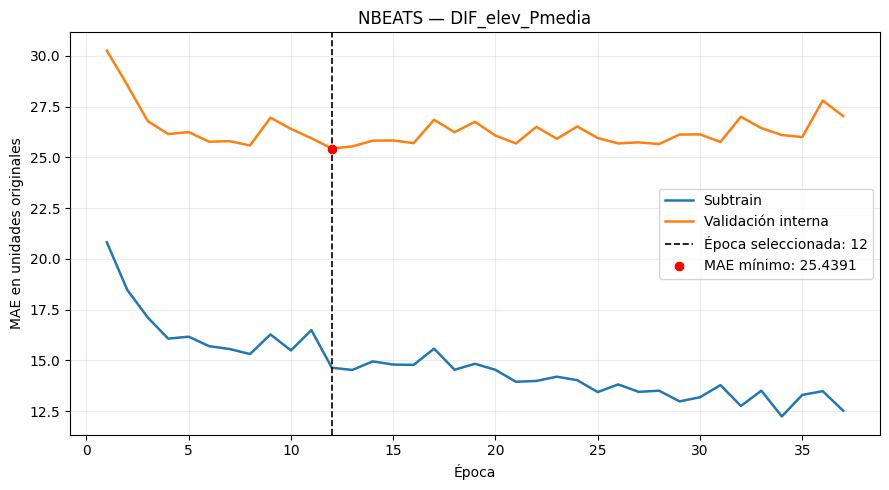


FINALIZADO: DIF_elev_Pmedia — NBEATS
Época seleccionada: 12
MAE interno: 25.439087

INICIO: DIF_elev_Pmedia — LSTM
DIF_elev_Pmedia      LSTM    | época   1 | MAE subtrain= 51.0692 | MAE interno= 75.6926 | mejor= 75.6926 (época 1) | espera= 0/25
DIF_elev_Pmedia      LSTM    | época  10 | MAE subtrain= 17.0037 | MAE interno= 25.9054 | mejor= 24.9563 (época 8) | espera= 2/25
DIF_elev_Pmedia      LSTM    | época  20 | MAE subtrain= 16.5734 | MAE interno= 25.1315 | mejor= 24.5158 (época 12) | espera= 8/25
DIF_elev_Pmedia      LSTM    | época  30 | MAE subtrain= 15.9866 | MAE interno= 24.4221 | mejor= 24.3334 (época 28) | espera= 2/25
DIF_elev_Pmedia      LSTM    | época  40 | MAE subtrain= 15.8083 | MAE interno= 25.0087 | mejor= 23.9806 (época 38) | espera= 2/25
DIF_elev_Pmedia      LSTM    | época  50 | MAE subtrain= 15.5026 | MAE interno= 24.1653 | mejor= 23.9804 (época 47) | espera= 3/25
DIF_elev_Pmedia      LSTM    | época  60 | MAE subtrain= 15.5046 | MAE interno= 24.4172 | mejor= 23.

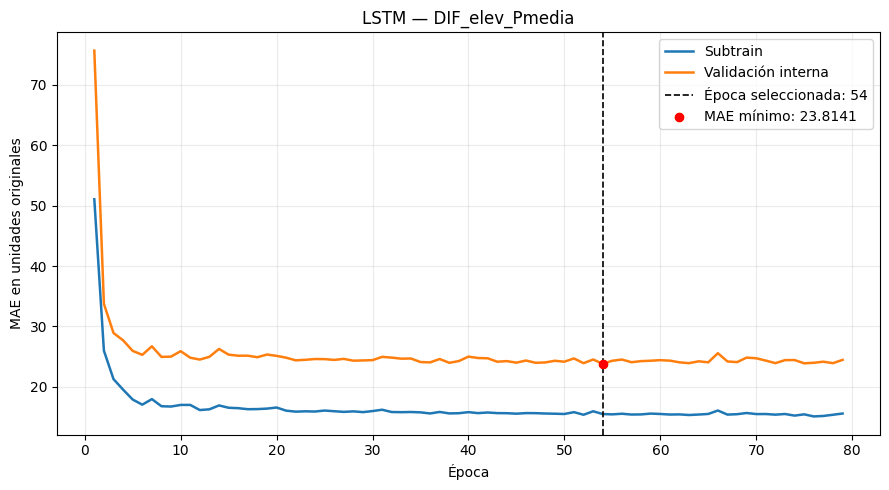


FINALIZADO: DIF_elev_Pmedia — LSTM
Época seleccionada: 54
MAE interno: 23.814137

INICIO: DIF_elev_Pquad — NBEATS
DIF_elev_Pquad       NBEATS  | época   1 | MAE subtrain= 23.8302 | MAE interno= 34.5602 | mejor= 34.5602 (época 1) | espera= 0/25
DIF_elev_Pquad       NBEATS  | época  10 | MAE subtrain= 10.2564 | MAE interno= 28.4595 | mejor= 26.9702 (época 8) | espera= 2/25
DIF_elev_Pquad       NBEATS  | época  20 | MAE subtrain=  7.0600 | MAE interno= 28.5355 | mejor= 26.9702 (época 8) | espera=12/25
DIF_elev_Pquad       NBEATS  | época  30 | MAE subtrain=  4.8827 | MAE interno= 28.3631 | mejor= 26.9702 (época 8) | espera=22/25
DIF_elev_Pquad       NBEATS  | época  33 | MAE subtrain=  4.8683 | MAE interno= 28.1936 | mejor= 26.9702 (época 8) | espera=25/25


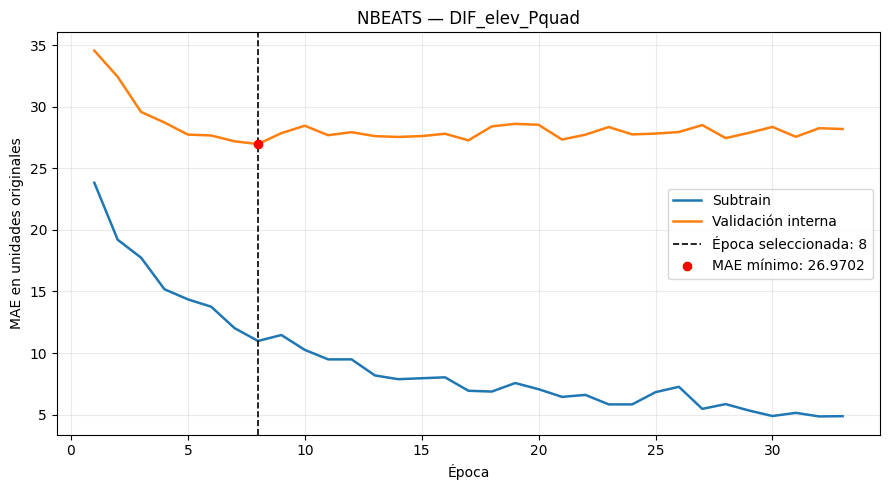


FINALIZADO: DIF_elev_Pquad — NBEATS
Época seleccionada: 8
MAE interno: 26.970245

INICIO: DIF_elev_Pquad — LSTM
DIF_elev_Pquad       LSTM    | época   1 | MAE subtrain= 56.4430 | MAE interno= 80.8314 | mejor= 80.8314 (época 1) | espera= 0/25
DIF_elev_Pquad       LSTM    | época  10 | MAE subtrain= 16.7870 | MAE interno= 25.1316 | mejor= 25.1316 (época 10) | espera= 0/25
DIF_elev_Pquad       LSTM    | época  20 | MAE subtrain= 16.2526 | MAE interno= 24.9583 | mejor= 24.5586 (época 18) | espera= 2/25
DIF_elev_Pquad       LSTM    | época  30 | MAE subtrain= 15.5877 | MAE interno= 24.4658 | mejor= 24.3914 (época 21) | espera= 9/25
DIF_elev_Pquad       LSTM    | época  40 | MAE subtrain= 16.0086 | MAE interno= 25.9480 | mejor= 24.1948 (época 35) | espera= 5/25
DIF_elev_Pquad       LSTM    | época  50 | MAE subtrain= 15.1498 | MAE interno= 24.8074 | mejor= 24.1948 (época 35) | espera=15/25
DIF_elev_Pquad       LSTM    | época  60 | MAE subtrain= 14.9467 | MAE interno= 24.8596 | mejor= 24.19

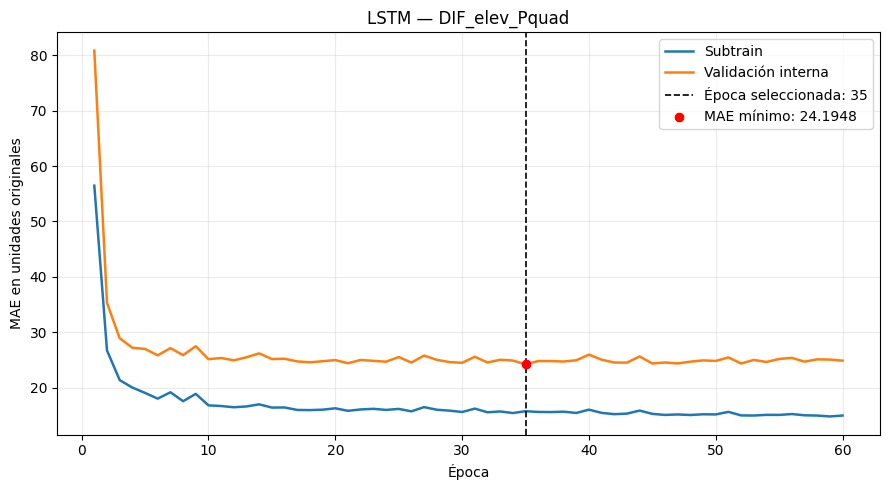


FINALIZADO: DIF_elev_Pquad — LSTM
Época seleccionada: 35
MAE interno: 24.194752

Ranking de selección interna:


,ranking_MAE,configuracion,arquitectura,n_canales,n_parametros,epoca_seleccionada,MAE_validacion_interna,epocas_ejecutadas,tiempo_seleccion_segundos,segundos_por_epoca,early_stopping
0,1,DIF_elev_T2quad,LSTM,5,20289,41,23.750984,66,79.087891,1.198301,True
1,2,DIF_elev_RHquad,LSTM,5,20289,30,23.772146,55,65.086022,1.183382,True
2,3,DIF_elev_Pmedia,LSTM,3,19777,54,23.814137,79,94.138013,1.191620,True
3,4,DIF_elev_Pquad,LSTM,5,20289,35,24.194752,60,71.342199,1.189037,True
4,5,DIF_elev_Pmedia,NBEATS,3,273558,12,25.439087,37,25.931100,0.700841,True
5,6,DIF_elev_Pquad,NBEATS,5,310422,8,26.970245,33,25.200110,0.763640,True
6,7,DIF_elev_T2quad,NBEATS,5,310422,13,28.401617,38,47.580741,1.252125,True
7,8,DIF_elev_RHquad,NBEATS,5,310422,8,28.745817,33,25.216905,0.764149,True


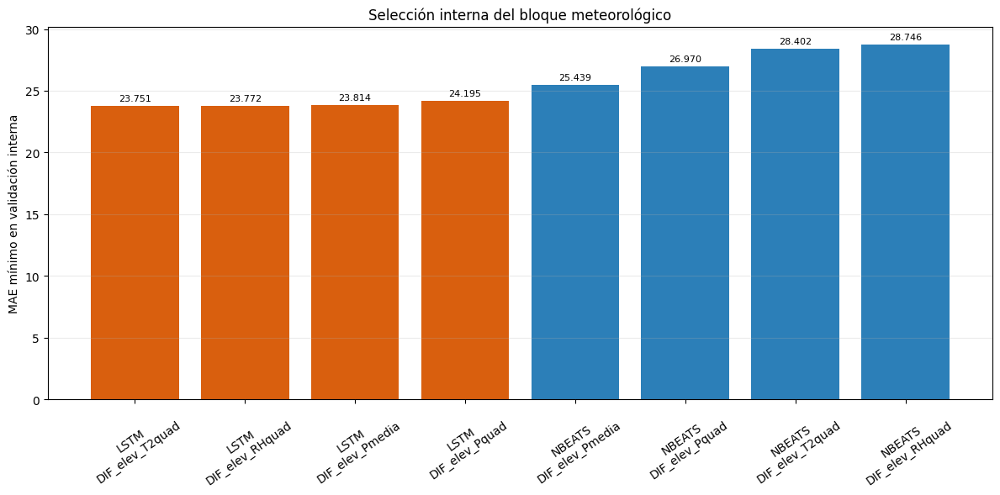


SELECCIÓN INTERNA METEOROLÓGICA COMPLETADA
Directorio: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/seleccion_interna_meteo_20261006T215223Z
Modelos seleccionados: 8
Validation externa utilizada: no
Test utilizado: no


In [ ]:
import gc
import json
import random
import time
from copy import deepcopy
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from torch.utils.data import DataLoader, TensorDataset

# 1. Configuración metodológica
SEED = 42
DEVICE = torch.device("cpu")
N_SUBTRAIN = 4428
N_VALIDACION_INTERNA = 721
BATCH_SIZE = 128
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-5
GRAD_CLIP = 1.0
MAX_EPOCHS = 300
PATIENCE = 25
MIN_DELTA = 1e-5
N_STACKS = 2
BLOCKS_PER_STACK = 3
NBEATS_HIDDEN = 128
LSTM_HIDDEN = 64
try:
    torch.set_num_threads(1)
    torch.set_num_interop_threads(1)
except RuntimeError:
    # Puede ocurrir si PyTorch ya inició el grupo de hilos.
    pass

torch.use_deterministic_algorithms(True)

def fijar_semilla(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

fijar_semilla(SEED)
assert DEVICE.type == "cpu"
assert N_SUBTRAIN + N_VALIDACION_INTERNA == len(y_train)
assert len(y_train) == 5149
print(f"Dispositivo: {DEVICE}")
print(f"Subtrain: {N_SUBTRAIN}")
print(f"Validación interna: {N_VALIDACION_INTERNA}")
print("Validation externa utilizada: no")
print("Test utilizado: no")


# 2. Configuraciones de entrada
CONFIGURACIONES_SELECCION = {
    "DIF_elev_T2quad": {
        "X": X_train_DIF_elev_T2quad_raw,
        "canales": ["DIF", "elevacion", "T2_media", "T2_pendiente", "T2_curvatura"],
    },
    "DIF_elev_RHquad": {
        "X": X_train_DIF_elev_RHquad_raw,
        "canales": ["DIF", "elevacion", "RH_media", "RH_pendiente", "RH_curvatura"],
    },
    "DIF_elev_Pmedia": {
        "X": X_train_DIF_elev_Pmedia_raw,
        "canales": ["DIF", "elevacion", "P_media"],
    },
    "DIF_elev_Pquad": {
        "X": X_train_DIF_elev_Pquad_raw,
        "canales": ["DIF", "elevacion", "P_media", "P_pendiente", "P_curvatura"],
    },
}
y_train_raw = np.asarray(y_train, dtype=np.float32).reshape(-1)
for nombre, info in CONFIGURACIONES_SELECCION.items():
    X = np.asarray(info["X"], dtype=np.float32)
    assert X.shape == (5149, 24, len(info["canales"]))
    assert np.isfinite(X).all()

assert np.isfinite(y_train_raw).all()


# 3. Normalización ajustada solo con subtrain
def preparar_datos_internos(X_raw, y_raw):
    X_sub_raw = X_raw[:N_SUBTRAIN]
    X_int_raw = X_raw[N_SUBTRAIN:]
    y_sub_raw = y_raw[:N_SUBTRAIN]
    y_int_raw = y_raw[N_SUBTRAIN:]
    x_mean = X_sub_raw.mean(axis=(0, 1), keepdims=True, dtype=np.float64).astype(np.float32)
    x_std = X_sub_raw.std(axis=(0, 1), keepdims=True, dtype=np.float64).astype(np.float32)
    x_std[x_std < 1e-8] = 1.0
    y_mean = np.float32(y_sub_raw.mean(dtype=np.float64))
    y_std = np.float32(y_sub_raw.std(dtype=np.float64))
    if y_std < 1e-8:
        raise ValueError("La desviación estándar del objetivo es nula.")

    X_sub = ((X_sub_raw - x_mean) / x_std).astype(np.float32)
    X_int = ((X_int_raw - x_mean) / x_std).astype(np.float32)
    y_sub = ((y_sub_raw - y_mean) / y_std).astype(np.float32)
    y_int = ((y_int_raw - y_mean) / y_std).astype(np.float32)
    escaladores = {"x_mean": x_mean, "x_std": x_std, "y_mean": y_mean, "y_std": y_std}
    return (X_sub, y_sub, X_int, y_int, y_sub_raw, y_int_raw, escaladores)


# 4. Arquitectura N-BEATS multivariante
class NBeatsBlockMultivariante(nn.Module):
    def __init__(self, ventana, n_canales, hidden=128):
        super().__init__()
        dimension_entrada = ventana + ventana * (n_canales - 1)
        self.mlp = nn.Sequential(
            nn.Linear(dimension_entrada, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
            nn.Linear(hidden, hidden),
            nn.ReLU(),
        )
        self.salida = nn.Linear(hidden, ventana + 1)
        self.ventana = ventana

    def forward(self, residual_dif, covariables):
        entrada = torch.cat([residual_dif, covariables.flatten(start_dim=1)], dim=1)
        theta = self.salida(self.mlp(entrada))
        backcast = theta[:, : self.ventana]
        forecast = theta[:, self.ventana :]
        return backcast, forecast

class NBeatsMultivariante(nn.Module):
    def __init__(self, ventana, n_canales, n_stacks=2, blocks_per_stack=3, hidden=128):
        super().__init__()
        self.stacks = nn.ModuleList(
            [
                nn.ModuleList(
                    [
                        NBeatsBlockMultivariante(
                            ventana=ventana, n_canales=n_canales, hidden=hidden
                        )
                        for _ in range(blocks_per_stack)
                    ]
                )
                for _ in range(n_stacks)
            ]
        )

    def forward(self, x):
        # Residual aplicado únicamente al canal DIF.
        residual_dif = x[:, :, 0]

        # Las covariables permanecen fijas en todos los bloques.
        covariables = x[:, :, 1:]
        forecast_total = torch.zeros((x.shape[0], 1), dtype=x.dtype, device=x.device)
        for stack in self.stacks:
            for bloque in stack:
                backcast, forecast = bloque(residual_dif, covariables)
                residual_dif = residual_dif - backcast
                forecast_total = forecast_total + forecast

        return forecast_total.squeeze(-1)


# 5. Arquitectura LSTM
class LSTMRegresor(nn.Module):
    def __init__(self, n_canales, hidden_size=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_canales, hidden_size=hidden_size, num_layers=1, batch_first=True
        )
        self.head = nn.Sequential(nn.Linear(hidden_size, 32), nn.ReLU(), nn.Linear(32, 1))

    def forward(self, x):
        salida, _ = self.lstm(x)
        ultimo_estado = salida[:, -1, :]
        return self.head(ultimo_estado).squeeze(-1)

def crear_modelo(arquitectura, n_canales):
    if arquitectura == "NBEATS":
        return NBeatsMultivariante(
            ventana=24,
            n_canales=n_canales,
            n_stacks=N_STACKS,
            blocks_per_stack=BLOCKS_PER_STACK,
            hidden=NBEATS_HIDDEN,
        )

    if arquitectura == "LSTM":
        return LSTMRegresor(n_canales=n_canales, hidden_size=LSTM_HIDDEN)

    raise ValueError(f"Arquitectura desconocida: {arquitectura}")

def contar_parametros(modelo):
    return sum(parametro.numel() for parametro in modelo.parameters() if parametro.requires_grad)


# 6. Evaluación en unidades originales
@torch.no_grad()
def evaluar_mae_original(modelo, loader, y_mean, y_std):
    modelo.eval()
    predicciones = []
    objetivos = []
    for X_batch, y_batch in loader:
        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)
        pred_std = modelo(X_batch)
        predicciones.append(pred_std.detach().cpu().numpy())
        objetivos.append(y_batch.detach().cpu().numpy())

    pred_std = np.concatenate(predicciones)
    y_std_real = np.concatenate(objetivos)
    pred_raw = pred_std * y_std + y_mean
    y_raw = y_std_real * y_std + y_mean
    return float(np.mean(np.abs(pred_raw - y_raw)))


# 7. Entrenamiento de una selección interna
def seleccionar_epoca(nombre_configuracion, arquitectura, X_raw, y_raw, canales, directorio_modelo):
    fijar_semilla(SEED)
    X_sub, y_sub, X_int, y_int, y_sub_raw, y_int_raw, escaladores = preparar_datos_internos(
        X_raw, y_raw
    )
    dataset_sub = TensorDataset(torch.from_numpy(X_sub), torch.from_numpy(y_sub))
    dataset_int = TensorDataset(torch.from_numpy(X_int), torch.from_numpy(y_int))
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader_train = DataLoader(
        dataset_sub, batch_size=BATCH_SIZE, shuffle=True, generator=generador, num_workers=0
    )
    loader_sub_eval = DataLoader(dataset_sub, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    loader_int_eval = DataLoader(dataset_int, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    modelo = crear_modelo(arquitectura=arquitectura, n_canales=X_raw.shape[2]).to(DEVICE)
    n_parametros = contar_parametros(modelo)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterio = nn.L1Loss()
    mejor_mae = np.inf
    mejor_epoca = None
    mejor_estado = None
    epocas_sin_mejora = 0
    historial = []
    inicio = time.perf_counter()
    for epoca in range(1, MAX_EPOCHS + 1):
        modelo.train()
        for X_batch, y_batch in loader_train:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            prediccion = modelo(X_batch)
            loss = criterio(prediccion, y_batch)
            loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=GRAD_CLIP)
            optimizador.step()

        mae_subtrain = evaluar_mae_original(
            modelo, loader_sub_eval, escaladores["y_mean"], escaladores["y_std"]
        )
        mae_interno = evaluar_mae_original(
            modelo, loader_int_eval, escaladores["y_mean"], escaladores["y_std"]
        )
        historial.append(
            {"epoca": epoca, "MAE_subtrain": mae_subtrain, "MAE_validacion_interna": mae_interno}
        )
        if mae_interno < mejor_mae - MIN_DELTA:
            mejor_mae = mae_interno
            mejor_epoca = epoca
            epocas_sin_mejora = 0
            mejor_estado = {
                clave: valor.detach().cpu().clone() for clave, valor in modelo.state_dict().items()
            }
        else:
            epocas_sin_mejora += 1

        if epoca == 1 or epoca % 10 == 0 or epocas_sin_mejora >= PATIENCE:
            print(
                f"{nombre_configuracion:<20} "
                f"{arquitectura:<7} | "
                f"época {epoca:>3} | "
                f"MAE subtrain={mae_subtrain:>8.4f} | "
                f"MAE interno={mae_interno:>8.4f} | "
                f"mejor={mejor_mae:>8.4f} "
                f"(época {mejor_epoca}) | "
                f"espera={epocas_sin_mejora:>2}/{PATIENCE}"
            )

        if epocas_sin_mejora >= PATIENCE:
            break

    tiempo_segundos = time.perf_counter() - inicio
    historial = pd.DataFrame(historial)
    historial.to_csv(directorio_modelo / "curva_seleccion.csv", index=False)
    np.savez_compressed(
        directorio_modelo / "escaladores_subtrain.npz",
        x_mean=escaladores["x_mean"],
        x_std=escaladores["x_std"],
        y_mean=np.asarray(escaladores["y_mean"]),
        y_std=np.asarray(escaladores["y_std"]),
    )
    torch.save(
        {
            "configuracion": nombre_configuracion,
            "arquitectura": arquitectura,
            "canales": canales,
            "epoca_seleccionada": mejor_epoca,
            "mae_interno": mejor_mae,
            "n_parametros": n_parametros,
            "model_state_dict": mejor_estado,
        },
        directorio_modelo / "mejor_checkpoint_interno.pt",
    )
    configuracion_modelo = {
        "configuracion": nombre_configuracion,
        "arquitectura": arquitectura,
        "canales": canales,
        "n_canales": len(canales),
        "n_parametros": n_parametros,
        "epoca_seleccionada": mejor_epoca,
        "mae_validacion_interna": mejor_mae,
        "epocas_ejecutadas": int(len(historial)),
        "early_stopping": bool(len(historial) < MAX_EPOCHS),
        "patience": PATIENCE,
        "min_delta": MIN_DELTA,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
        "gradient_clip": GRAD_CLIP,
        "seed": SEED,
        "dispositivo": str(DEVICE),
        "tiempo_seleccion_segundos": tiempo_segundos,
        "validation_externa_utilizada": False,
        "test_utilizado": False,
    }
    with open(directorio_modelo / "configuracion.json", "w", encoding="utf-8") as archivo:
        json.dump(configuracion_modelo, archivo, ensure_ascii=False, indent=2)

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(historial["epoca"], historial["MAE_subtrain"], label="Subtrain", linewidth=1.8)
    ax.plot(
        historial["epoca"],
        historial["MAE_validacion_interna"],
        label="Validación interna",
        linewidth=1.8,
    )
    ax.axvline(
        mejor_epoca,
        color="black",
        linestyle="--",
        linewidth=1.2,
        label=(f"Época seleccionada: {mejor_epoca}"),
    )
    ax.scatter(
        [mejor_epoca], [mejor_mae], color="red", zorder=5, label=f"MAE mínimo: {mejor_mae:.4f}"
    )
    ax.set_title(f"{arquitectura} — {nombre_configuracion}")
    ax.set_xlabel("Época")
    ax.set_ylabel("MAE en unidades originales")
    ax.grid(alpha=0.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(directorio_modelo / "curva_seleccion.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    resultado = {
        "configuracion": nombre_configuracion,
        "arquitectura": arquitectura,
        "n_canales": len(canales),
        "n_parametros": n_parametros,
        "epoca_seleccionada": mejor_epoca,
        "MAE_validacion_interna": mejor_mae,
        "epocas_ejecutadas": int(len(historial)),
        "tiempo_seleccion_segundos": tiempo_segundos,
        "segundos_por_epoca": tiempo_segundos / len(historial),
        "early_stopping": len(historial) < MAX_EPOCHS,
    }
    del modelo
    del loader_train
    del loader_sub_eval
    del loader_int_eval
    gc.collect()
    return resultado, historial


# 8. Directorio persistente de esta selección
marca_temporal = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
DIR_SELECCION_METEO = (
    BASE_DIR / "resultados" / "ejecuciones" / f"seleccion_interna_meteo_{marca_temporal}"
)
DIR_SELECCION_METEO.mkdir(parents=True, exist_ok=False)
print("\nResultados guardados en:")
print(DIR_SELECCION_METEO)


# 9. Ejecutar las ocho selecciones
resultados_seleccion_meteo = []
historiales_seleccion_meteo = {}
for nombre_configuracion, info in CONFIGURACIONES_SELECCION.items():
    for arquitectura in ["NBEATS", "LSTM"]:
        print("\n" + "=" * 80)
        print(f"INICIO: {nombre_configuracion} — " f"{arquitectura}")
        print("=" * 80)
        directorio_modelo = DIR_SELECCION_METEO / f"{arquitectura}_{nombre_configuracion}"
        directorio_modelo.mkdir(parents=True, exist_ok=False)
        resultado, historial = seleccionar_epoca(
            nombre_configuracion=nombre_configuracion,
            arquitectura=arquitectura,
            X_raw=info["X"],
            y_raw=y_train_raw,
            canales=info["canales"],
            directorio_modelo=directorio_modelo,
        )
        resultados_seleccion_meteo.append(resultado)
        historiales_seleccion_meteo[(nombre_configuracion, arquitectura)] = historial

        # Guardado incremental por si se desconecta Colab.
        pd.DataFrame(resultados_seleccion_meteo).to_csv(
            DIR_SELECCION_METEO / "resumen_seleccion_interna.csv", index=False
        )
        print(f"\nFINALIZADO: {nombre_configuracion} — " f"{arquitectura}")
        print(f"Época seleccionada: " f"{resultado['epoca_seleccionada']}")
        print(f"MAE interno: " f"{resultado['MAE_validacion_interna']:.6f}")


# 10. Resumen y ranking
resultados_seleccion_meteo = pd.DataFrame(resultados_seleccion_meteo)
resultados_seleccion_meteo = resultados_seleccion_meteo.sort_values(
    ["MAE_validacion_interna", "configuracion", "arquitectura"]
).reset_index(drop=True)
resultados_seleccion_meteo["ranking_MAE"] = np.arange(1, len(resultados_seleccion_meteo) + 1)
columnas_resumen = [
    "ranking_MAE",
    "configuracion",
    "arquitectura",
    "n_canales",
    "n_parametros",
    "epoca_seleccionada",
    "MAE_validacion_interna",
    "epocas_ejecutadas",
    "tiempo_seleccion_segundos",
    "segundos_por_epoca",
    "early_stopping",
]
resultados_seleccion_meteo[columnas_resumen].to_csv(
    DIR_SELECCION_METEO / "resumen_seleccion_interna.csv", index=False
)
print("\nRanking de selección interna:")
display(resultados_seleccion_meteo[columnas_resumen])


# 11. Comparación gráfica de los ocho mínimos
fig, ax = plt.subplots(figsize=(12, 6))
etiquetas = (
    resultados_seleccion_meteo["arquitectura"] + "\n" + resultados_seleccion_meteo["configuracion"]
)
colores = resultados_seleccion_meteo["arquitectura"].map({"NBEATS": "#2C7FB8", "LSTM": "#D95F0E"})
barras = ax.bar(etiquetas, resultados_seleccion_meteo["MAE_validacion_interna"], color=colores)
ax.bar_label(barras, fmt="%.3f", padding=3, fontsize=8)
ax.set_ylabel("MAE mínimo en validación interna")
ax.set_title("Selección interna del bloque meteorológico")
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
fig.savefig(DIR_SELECCION_METEO / "comparacion_minimos_MAE.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)


# 12. Guardar configuración global y puntero
configuracion_global = {
    "fecha_creacion_utc": marca_temporal,
    "seed": SEED,
    "dispositivo": str(DEVICE),
    "n_subtrain": N_SUBTRAIN,
    "n_validacion_interna": N_VALIDACION_INTERNA,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "gradient_clip": GRAD_CLIP,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "min_delta": MIN_DELTA,
    "criterio_entrenamiento": "L1Loss",
    "criterio_seleccion": "MAE de validación interna en unidades originales",
    "arquitectura_nbeats": {
        "n_stacks": N_STACKS,
        "blocks_per_stack": BLOCKS_PER_STACK,
        "hidden": NBEATS_HIDDEN,
        "dense_layers_per_block": 3,
        "residual": "solo canal DIF",
        "covariables": "fijas",
    },
    "arquitectura_lstm": {"num_layers": 1, "hidden_size": LSTM_HIDDEN, "head": "64 -> 32 -> 1"},
    "validation_externa_utilizada": False,
    "test_utilizado": False,
}
with open(DIR_SELECCION_METEO / "configuracion_global.json", "w", encoding="utf-8") as archivo:
    json.dump(configuracion_global, archivo, ensure_ascii=False, indent=2)

RUTA_PUNTERO_SELECCION = BASE_DIR / "documentacion" / "ULTIMA_SELECCION_INTERNA_METEO.json"
with open(RUTA_PUNTERO_SELECCION, "w", encoding="utf-8") as archivo:
    json.dump(
        {
            "fecha_creacion_utc": marca_temporal,
            "directorio": str(DIR_SELECCION_METEO),
            "resumen": str(DIR_SELECCION_METEO / "resumen_seleccion_interna.csv"),
            "estado": "seleccion interna completada",
            "validation_externa_utilizada": False,
            "test_utilizado": False,
        },
        archivo,
        ensure_ascii=False,
        indent=2,
    )

print("\n" + "=" * 80)
print("SELECCIÓN INTERNA METEOROLÓGICA COMPLETADA")
print("=" * 80)
print(f"Directorio: {DIR_SELECCION_METEO}")
print("Modelos seleccionados: 8")
print("Validation externa utilizada: no")
print("Test utilizado: no")
print("=" * 80)

**Resultados.** La LSTM obtiene menor MAE interno que N-BEATS: con temperatura, 23,75 frente a 28,40 W/m² (épocas 41 y 13), y con humedad, 23,77 frente a 28,75 W/m² (épocas 30 y 8). N-BEATS alcanza su mínimo en pocas épocas, mientras que su MAE de subtrain sigue disminuyendo.

### 6.49 Reentrenamiento y evaluación externa del bloque meteorológico

Cada uno de los ocho modelos se reentrena desde cero con todo el entrenamiento durante las épocas seleccionadas, con escaladores ajustados solo con el entrenamiento, y se evalúa una única vez en validación.

Épocas que se utilizarán:
  LSTM    DIF_elev_T2quad     : 41
  LSTM    DIF_elev_RHquad     : 30
  LSTM    DIF_elev_Pmedia     : 54
  LSTM    DIF_elev_Pquad      : 35
  NBEATS  DIF_elev_Pmedia     : 12
  NBEATS  DIF_elev_Pquad      : 8
  NBEATS  DIF_elev_T2quad     : 13
  NBEATS  DIF_elev_RHquad     : 8

Resultados guardados en:
/content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_meteo_20261006T220505Z

REENTRENAMIENTO: DIF_elev_T2quad — NBEATS
Épocas fijas: 13
DIF_elev_T2quad      NBEATS  | época   1/13  | MAE train=31.6617
DIF_elev_T2quad      NBEATS  | época  10/13  | MAE train=13.9212
DIF_elev_T2quad      NBEATS  | época  13/13  | MAE train=11.8398


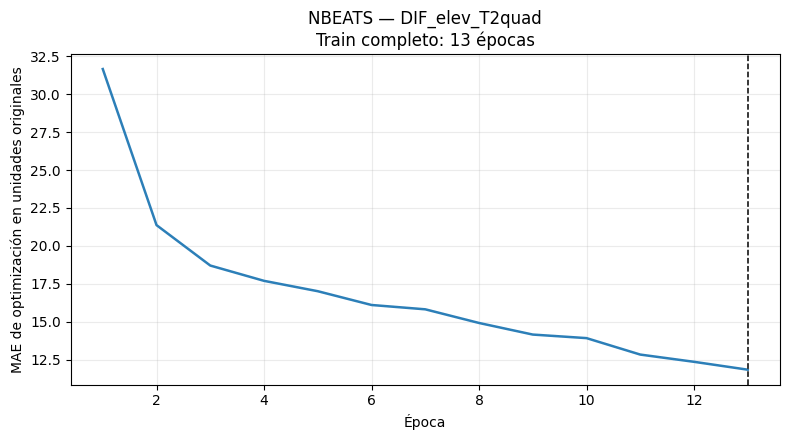


Métricas de validation:
MAE:  20.808873
nMAE: 24.191909 %
RMSE: 38.125834
R²:   0.875651

REENTRENAMIENTO: DIF_elev_T2quad — LSTM
Épocas fijas: 41
DIF_elev_T2quad      LSTM    | época   1/41  | MAE train=76.4624
DIF_elev_T2quad      LSTM    | época  10/41  | MAE train=17.3540
DIF_elev_T2quad      LSTM    | época  20/41  | MAE train=16.6067
DIF_elev_T2quad      LSTM    | época  30/41  | MAE train=16.3755
DIF_elev_T2quad      LSTM    | época  40/41  | MAE train=16.2580
DIF_elev_T2quad      LSTM    | época  41/41  | MAE train=16.1302


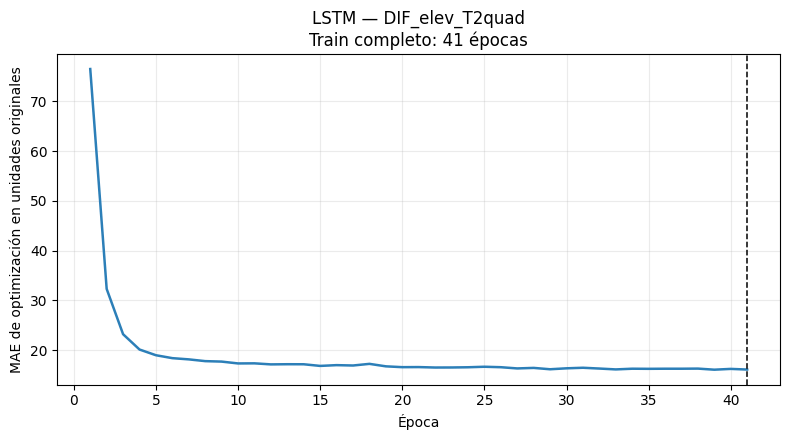


Métricas de validation:
MAE:  17.600156
nMAE: 20.461531 %
RMSE: 34.128767
R²:   0.900357

REENTRENAMIENTO: DIF_elev_RHquad — NBEATS
Épocas fijas: 8
DIF_elev_RHquad      NBEATS  | época   1/8   | MAE train=32.9164
DIF_elev_RHquad      NBEATS  | época   8/8   | MAE train=14.0956


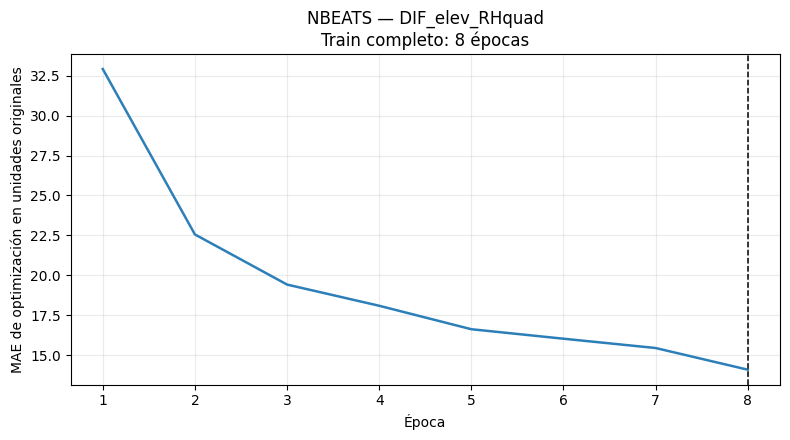


Métricas de validation:
MAE:  20.429828
nMAE: 23.751240 %
RMSE: 36.439670
R²:   0.886406

REENTRENAMIENTO: DIF_elev_RHquad — LSTM
Épocas fijas: 30
DIF_elev_RHquad      LSTM    | época   1/30  | MAE train=80.5357
DIF_elev_RHquad      LSTM    | época  10/30  | MAE train=17.5498
DIF_elev_RHquad      LSTM    | época  20/30  | MAE train=17.1002
DIF_elev_RHquad      LSTM    | época  30/30  | MAE train=17.0584


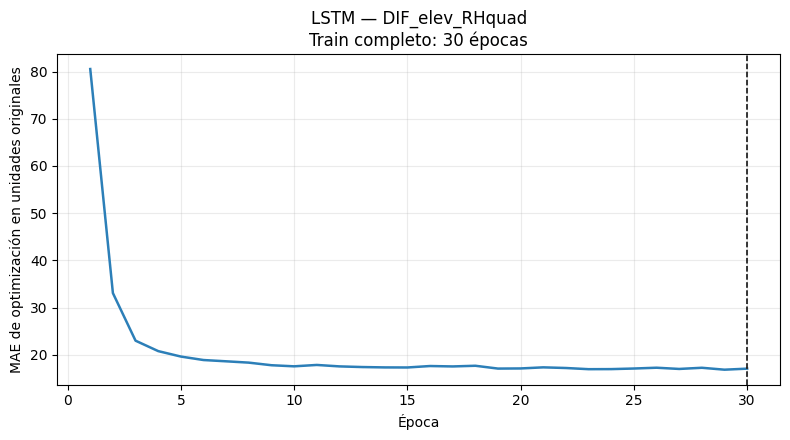


Métricas de validation:
MAE:  17.283995
nMAE: 20.093969 %
RMSE: 33.700336
R²:   0.902843

REENTRENAMIENTO: DIF_elev_Pmedia — NBEATS
Épocas fijas: 12
DIF_elev_Pmedia      NBEATS  | época   1/12  | MAE train=31.6998
DIF_elev_Pmedia      NBEATS  | época  10/12  | MAE train=17.0681
DIF_elev_Pmedia      NBEATS  | época  12/12  | MAE train=16.4400


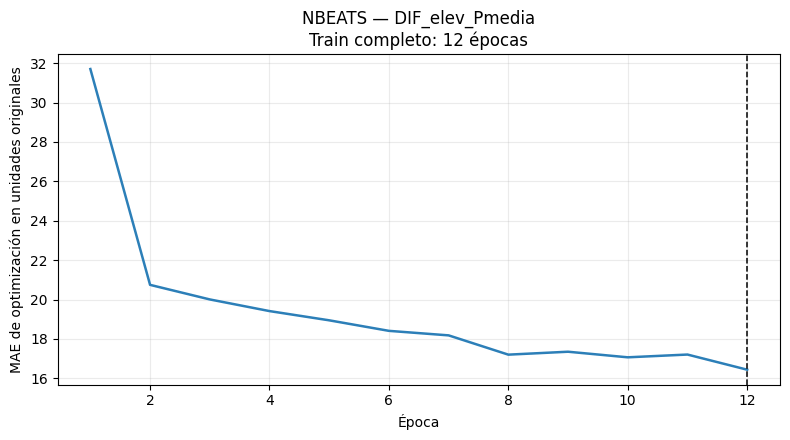


Métricas de validation:
MAE:  18.193908
nMAE: 21.151812 %
RMSE: 34.453695
R²:   0.898451

REENTRENAMIENTO: DIF_elev_Pmedia — LSTM
Épocas fijas: 54
DIF_elev_Pmedia      LSTM    | época   1/54  | MAE train=68.6463
DIF_elev_Pmedia      LSTM    | época  10/54  | MAE train=17.8414
DIF_elev_Pmedia      LSTM    | época  20/54  | MAE train=17.3129
DIF_elev_Pmedia      LSTM    | época  30/54  | MAE train=17.2401
DIF_elev_Pmedia      LSTM    | época  40/54  | MAE train=17.1093
DIF_elev_Pmedia      LSTM    | época  50/54  | MAE train=17.1018
DIF_elev_Pmedia      LSTM    | época  54/54  | MAE train=16.7127


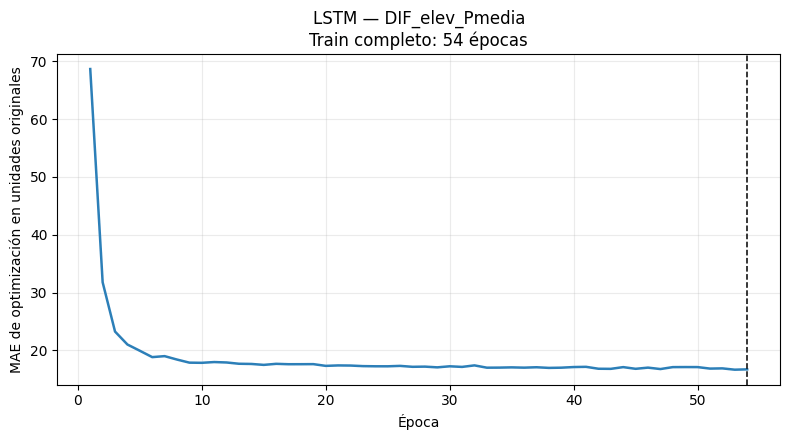


Métricas de validation:
MAE:  16.626987
nMAE: 19.330146 %
RMSE: 32.917950
R²:   0.907302

REENTRENAMIENTO: DIF_elev_Pquad — NBEATS
Épocas fijas: 8
DIF_elev_Pquad       NBEATS  | época   1/8   | MAE train=33.5956
DIF_elev_Pquad       NBEATS  | época   8/8   | MAE train=14.2156


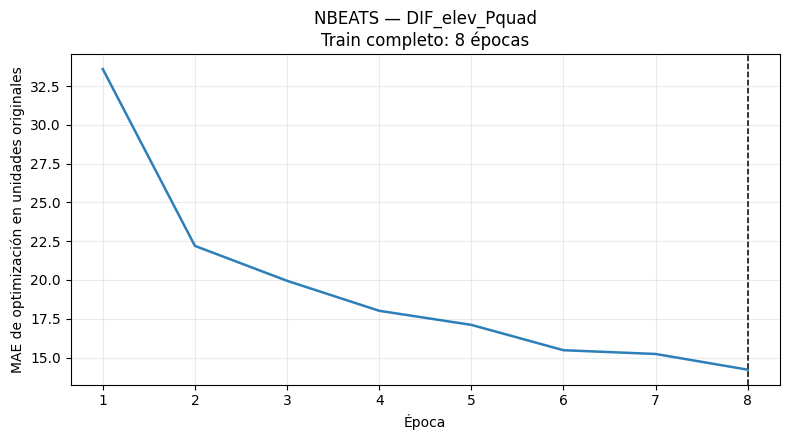


Métricas de validation:
MAE:  19.140656
nMAE: 22.252480 %
RMSE: 35.014656
R²:   0.895117

REENTRENAMIENTO: DIF_elev_Pquad — LSTM
Épocas fijas: 35
DIF_elev_Pquad       LSTM    | época   1/35  | MAE train=80.5767
DIF_elev_Pquad       LSTM    | época  10/35  | MAE train=17.9769
DIF_elev_Pquad       LSTM    | época  20/35  | MAE train=17.2738
DIF_elev_Pquad       LSTM    | época  30/35  | MAE train=17.3587
DIF_elev_Pquad       LSTM    | época  35/35  | MAE train=17.2280


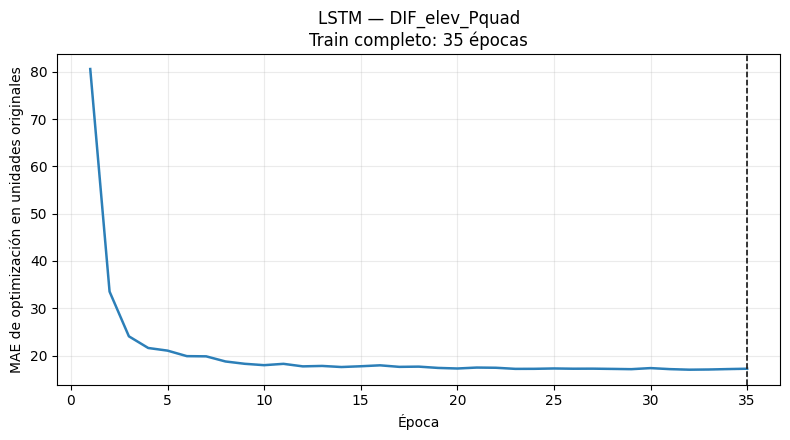


Métricas de validation:
MAE:  17.302745
nMAE: 20.115767 %
RMSE: 33.322478
R²:   0.905010

Ranking en validation externa:


,ranking_MAE,configuracion,arquitectura,epocas_reentrenamiento,MAE,nMAE_pct,RMSE,R2,bias,n_parametros,tiempo_entrenamiento_segundos,segundos_por_epoca,inferencia_ms_por_muestra,tamano_modelo_MB
0,1,DIF_elev_Pmedia,LSTM,54,16.626987,19.330146,32.917950,0.907302,-2.324406,19777,51.248444,0.949045,0.057974,0.079503
1,2,DIF_elev_RHquad,LSTM,30,17.283995,20.093969,33.700336,0.902843,-2.299922,20289,28.884730,0.962824,0.075560,0.081517
2,3,DIF_elev_Pquad,LSTM,35,17.302745,20.115767,33.322478,0.905010,1.948615,20289,32.997697,0.942791,0.056856,0.081517
3,4,DIF_elev_T2quad,LSTM,41,17.600156,20.461531,34.128767,0.900357,-2.496287,20289,54.701012,1.334171,0.058294,0.081517
4,5,DIF_elev_Pmedia,NBEATS,12,18.193908,21.151812,34.453695,0.898451,6.622400,273558,6.671185,0.555932,0.011324,1.061046
5,6,DIF_elev_Pquad,NBEATS,8,19.140656,22.252480,35.014656,0.895117,-2.027275,310422,4.837112,0.604639,0.021979,1.201732
6,7,DIF_elev_RHquad,NBEATS,8,20.429828,23.751240,36.439670,0.886406,-3.861525,310422,4.704688,0.588086,0.012913,1.201732
7,8,DIF_elev_T2quad,NBEATS,13,20.808873,24.191909,38.125834,0.875651,-3.452431,310422,20.975454,1.613496,0.020731,1.201732


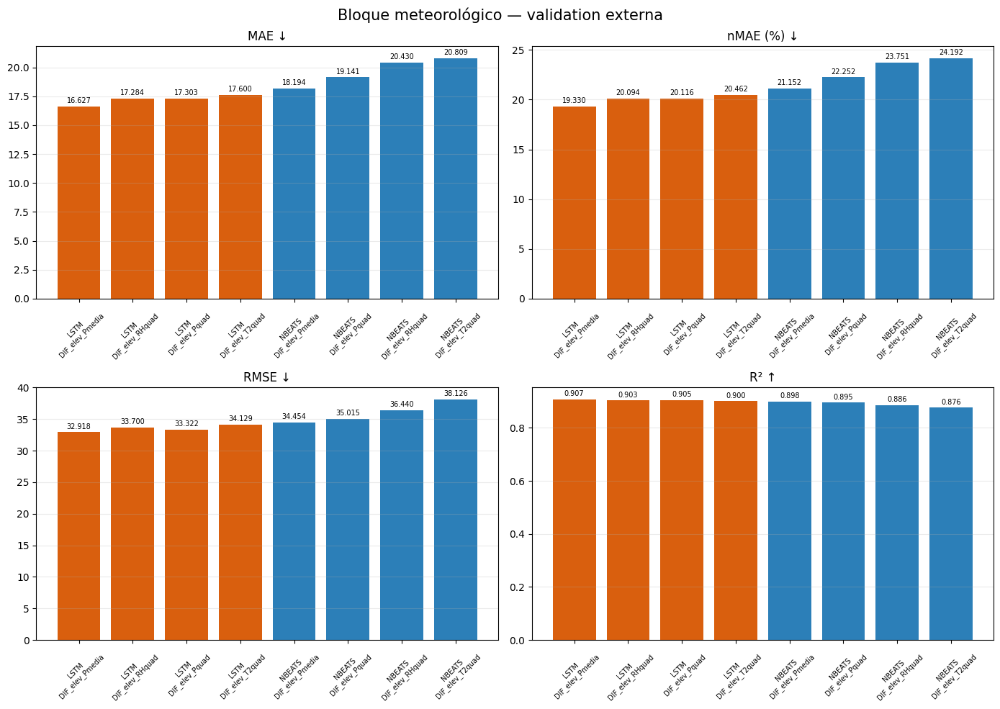


REENTRENAMIENTO METEOROLÓGICO COMPLETADO
Directorio: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_meteo_20261006T220505Z
Modelos reentrenados: 8
Validation externa evaluada: sí
Test utilizado: no


In [ ]:
import gc
import json
import time
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from IPython.display import display
from torch.utils.data import DataLoader, TensorDataset

# 1. Comprobar que continúa disponible la implementación
objetos_requeridos = [
    "crear_modelo",
    "fijar_semilla",
    "resultados_seleccion_meteo",
    "X_train_DIF_elev_T2quad_raw",
    "X_validation_DIF_elev_T2quad_raw",
    "X_train_DIF_elev_RHquad_raw",
    "X_validation_DIF_elev_RHquad_raw",
    "X_train_DIF_elev_Pmedia_raw",
    "X_validation_DIF_elev_Pmedia_raw",
    "X_train_DIF_elev_Pquad_raw",
    "X_validation_DIF_elev_Pquad_raw",
    "y_train",
    "y_validation",
]
faltantes = [nombre for nombre in objetos_requeridos if nombre not in globals()]
if faltantes:
    raise RuntimeError(f"Faltan objetos de la celda anterior: {faltantes}")

assert len(y_train) == 5149
assert len(y_validation) == 1464
assert DEVICE.type == "cpu"


# 2. Épocas seleccionadas
EPOCAS_ESPERADAS = {
    ("DIF_elev_T2quad", "NBEATS"): 13,
    ("DIF_elev_T2quad", "LSTM"): 41,
    ("DIF_elev_RHquad", "NBEATS"): 8,
    ("DIF_elev_RHquad", "LSTM"): 30,
    ("DIF_elev_Pmedia", "NBEATS"): 12,
    ("DIF_elev_Pmedia", "LSTM"): 54,
    ("DIF_elev_Pquad", "NBEATS"): 8,
    ("DIF_elev_Pquad", "LSTM"): 35,
}
epocas_seleccionadas = {}
for _, fila in resultados_seleccion_meteo.iterrows():
    clave = (fila["configuracion"], fila["arquitectura"])
    epocas_seleccionadas[clave] = int(fila["epoca_seleccionada"])

assert (
    epocas_seleccionadas == EPOCAS_ESPERADAS
), "Las épocas recuperadas no coinciden con las observadas."
print("Épocas que se utilizarán:")
for clave, epoca in epocas_seleccionadas.items():
    print(f"  {clave[1]:<7} {clave[0]:<20}: {epoca}")


# 3. Matrices train-validation
CONFIGURACIONES_REENTRENAMIENTO = {
    "DIF_elev_T2quad": {
        "X_train": X_train_DIF_elev_T2quad_raw,
        "X_validation": X_validation_DIF_elev_T2quad_raw,
        "canales": ["DIF", "elevacion", "T2_media", "T2_pendiente", "T2_curvatura"],
    },
    "DIF_elev_RHquad": {
        "X_train": X_train_DIF_elev_RHquad_raw,
        "X_validation": X_validation_DIF_elev_RHquad_raw,
        "canales": ["DIF", "elevacion", "RH_media", "RH_pendiente", "RH_curvatura"],
    },
    "DIF_elev_Pmedia": {
        "X_train": X_train_DIF_elev_Pmedia_raw,
        "X_validation": X_validation_DIF_elev_Pmedia_raw,
        "canales": ["DIF", "elevacion", "P_media"],
    },
    "DIF_elev_Pquad": {
        "X_train": X_train_DIF_elev_Pquad_raw,
        "X_validation": X_validation_DIF_elev_Pquad_raw,
        "canales": ["DIF", "elevacion", "P_media", "P_pendiente", "P_curvatura"],
    },
}
y_train_completo = np.asarray(y_train, dtype=np.float32).reshape(-1)
y_validation_externa = np.asarray(y_validation, dtype=np.float32).reshape(-1)
for nombre, info in CONFIGURACIONES_REENTRENAMIENTO.items():
    assert info["X_train"].shape == (5149, 24, len(info["canales"]))
    assert info["X_validation"].shape == (1464, 24, len(info["canales"]))
    assert np.isfinite(info["X_train"]).all()
    assert np.isfinite(info["X_validation"]).all()


# 4. Normalización ajustada únicamente con train completo
def normalizar_train_validation(X_train_raw, X_validation_raw, y_train_raw):
    x_mean = X_train_raw.mean(axis=(0, 1), keepdims=True, dtype=np.float64).astype(np.float32)
    x_std = X_train_raw.std(axis=(0, 1), keepdims=True, dtype=np.float64).astype(np.float32)
    x_std[x_std < 1e-8] = 1.0
    y_mean = np.float32(y_train_raw.mean(dtype=np.float64))
    y_std = np.float32(y_train_raw.std(dtype=np.float64))
    if y_std < 1e-8:
        raise ValueError("Desviación estándar nula en el objetivo.")

    X_train_normalizado = ((X_train_raw - x_mean) / x_std).astype(np.float32)
    X_validation_normalizado = ((X_validation_raw - x_mean) / x_std).astype(np.float32)
    y_train_normalizado = ((y_train_raw - y_mean) / y_std).astype(np.float32)
    escaladores = {"x_mean": x_mean, "x_std": x_std, "y_mean": y_mean, "y_std": y_std}
    return (X_train_normalizado, X_validation_normalizado, y_train_normalizado, escaladores)


# 5. Métricas
def calcular_metricas(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    errores = y_pred - y_real
    mae = np.mean(np.abs(errores))
    rmse = np.sqrt(np.mean(errores**2))
    denominador_nmae = np.mean(np.abs(y_real))
    nmae = 100.0 * mae / denominador_nmae if denominador_nmae > 0 else np.nan
    ss_res = np.sum(errores**2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
    return {
        "MAE": float(mae),
        "nMAE_pct": float(nmae),
        "RMSE": float(rmse),
        "R2": float(r2),
        "bias": float(np.mean(errores)),
    }


# 6. Entrenamiento fijo con todo train
def reentrenar_modelo_completo(
    nombre_configuracion,
    arquitectura,
    X_train_raw,
    X_validation_raw,
    y_train_raw,
    y_validation_raw,
    canales,
    n_epocas,
    directorio_modelo,
):
    fijar_semilla(SEED)
    X_train_norm, X_validation_norm, y_train_norm, escaladores = normalizar_train_validation(
        X_train_raw=X_train_raw, X_validation_raw=X_validation_raw, y_train_raw=y_train_raw
    )
    dataset_train = TensorDataset(torch.from_numpy(X_train_norm), torch.from_numpy(y_train_norm))
    generador = torch.Generator()
    generador.manual_seed(SEED)
    loader_train = DataLoader(
        dataset_train, batch_size=BATCH_SIZE, shuffle=True, generator=generador, num_workers=0
    )
    modelo = crear_modelo(arquitectura=arquitectura, n_canales=len(canales)).to(DEVICE)
    n_parametros = contar_parametros(modelo)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterio = nn.L1Loss()
    historial = []
    inicio_entrenamiento = time.perf_counter()
    for epoca in range(1, n_epocas + 1):
        modelo.train()
        suma_loss = 0.0
        n_observaciones = 0
        for X_batch, y_batch in loader_train:
            X_batch = X_batch.to(DEVICE)
            y_batch = y_batch.to(DEVICE)
            optimizador.zero_grad(set_to_none=True)
            prediccion = modelo(X_batch)
            loss = criterio(prediccion, y_batch)
            loss.backward()
            nn.utils.clip_grad_norm_(modelo.parameters(), max_norm=GRAD_CLIP)
            optimizador.step()
            tamano_batch = X_batch.shape[0]
            suma_loss += loss.item() * tamano_batch
            n_observaciones += tamano_batch

        # La transformación del MAE estandarizado a unidades
        # originales es exactamente multiplicar por y_std.
        mae_train_epoca = suma_loss / n_observaciones * float(escaladores["y_std"])
        historial.append({"epoca": epoca, "MAE_train_optimizacion": mae_train_epoca})
        if epoca == 1 or epoca % 10 == 0 or epoca == n_epocas:
            print(
                f"{nombre_configuracion:<20} "
                f"{arquitectura:<7} | "
                f"época {epoca:>3}/{n_epocas:<3} | "
                f"MAE train={mae_train_epoca:.4f}"
            )

    tiempo_entrenamiento = time.perf_counter() - inicio_entrenamiento
    historial = pd.DataFrame(historial)

    # Una única predicción de validation externa
    X_validation_tensor = torch.from_numpy(X_validation_norm).to(DEVICE)
    modelo.eval()
    with torch.no_grad():
        pred_validation_std = modelo(X_validation_tensor).detach().cpu().numpy()

    pred_validation = (pred_validation_std * escaladores["y_std"] + escaladores["y_mean"]).astype(
        np.float32
    )
    metricas = calcular_metricas(y_validation_raw, pred_validation)

    # Benchmark de inferencia
    with torch.no_grad():
        for _ in range(5):
            _ = modelo(X_validation_tensor)

    tiempos_inferencia = []
    with torch.no_grad():
        for _ in range(30):
            inicio_inferencia = time.perf_counter()
            _ = modelo(X_validation_tensor)
            tiempos_inferencia.append(time.perf_counter() - inicio_inferencia)

    tiempo_inferencia_mediano = float(np.median(tiempos_inferencia))

    # Guardar modelo y escaladores
    RUTA_MODELO = directorio_modelo / "modelo_final_train_completo.pt"
    torch.save(
        {
            "configuracion": nombre_configuracion,
            "arquitectura": arquitectura,
            "canales": canales,
            "n_epocas": n_epocas,
            "n_parametros": n_parametros,
            "model_state_dict": modelo.state_dict(),
            "metricas_validation": metricas,
        },
        RUTA_MODELO,
    )
    np.savez_compressed(
        directorio_modelo / "escaladores_train_completo.npz",
        x_mean=escaladores["x_mean"],
        x_std=escaladores["x_std"],
        y_mean=np.asarray(escaladores["y_mean"]),
        y_std=np.asarray(escaladores["y_std"]),
    )
    historial.to_csv(directorio_modelo / "curva_train_completo.csv", index=False)

    # Guardar predicciones individuales
    predicciones_df = pd.DataFrame(
        {
            "instante_objetivo": validation_hgb["instante_objetivo"].to_numpy(),
            "y_real": y_validation_raw,
            "y_pred": pred_validation,
            "error": pred_validation - y_validation_raw,
            "error_absoluto": np.abs(pred_validation - y_validation_raw),
            "error_cuadrado": (pred_validation - y_validation_raw) ** 2,
        }
    )
    if "regimen_solar_objetivo" in validation_hgb.columns:
        predicciones_df["regimen_solar_objetivo"] = validation_hgb[
            "regimen_solar_objetivo"
        ].to_numpy()

    predicciones_df.to_parquet(directorio_modelo / "predicciones_validation.parquet", index=False)
    predicciones_df.to_csv(directorio_modelo / "predicciones_validation.csv", index=False)

    # Gráfica del entrenamiento completo
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(historial["epoca"], historial["MAE_train_optimizacion"], color="#2C7FB8", linewidth=1.8)
    ax.axvline(n_epocas, color="black", linestyle="--", linewidth=1.1)
    ax.set_title(
        f"{arquitectura} — " f"{nombre_configuracion}\n" f"Train completo: {n_epocas} épocas"
    )
    ax.set_xlabel("Época")
    ax.set_ylabel("MAE de optimización en unidades originales")
    ax.grid(alpha=0.25)
    fig.tight_layout()
    fig.savefig(directorio_modelo / "curva_train_completo.png", dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    resultado = {
        "configuracion": nombre_configuracion,
        "arquitectura": arquitectura,
        "n_canales": len(canales),
        "n_parametros": n_parametros,
        "epocas_reentrenamiento": n_epocas,
        **metricas,
        "tiempo_entrenamiento_segundos": tiempo_entrenamiento,
        "segundos_por_epoca": tiempo_entrenamiento / n_epocas,
        "inferencia_validation_segundos": tiempo_inferencia_mediano,
        "inferencia_ms_por_muestra": (1000.0 * tiempo_inferencia_mediano / len(y_validation_raw)),
        "tamano_modelo_MB": RUTA_MODELO.stat().st_size / (1024**2),
    }
    with open(directorio_modelo / "resultado.json", "w", encoding="utf-8") as archivo:
        json.dump(resultado, archivo, ensure_ascii=False, indent=2)

    del modelo
    del X_validation_tensor
    del loader_train
    gc.collect()
    return resultado


# 7. Directorio persistente
marca_temporal = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
DIR_REENTRENAMIENTO_METEO = (
    BASE_DIR / "resultados" / "ejecuciones" / f"reentrenamiento_meteo_{marca_temporal}"
)
DIR_REENTRENAMIENTO_METEO.mkdir(parents=True, exist_ok=False)
print("\nResultados guardados en:")
print(DIR_REENTRENAMIENTO_METEO)


# 8. Reentrenar los ocho modelos
resultados_validation_meteo = []
for nombre_configuracion, info in CONFIGURACIONES_REENTRENAMIENTO.items():
    for arquitectura in ["NBEATS", "LSTM"]:
        n_epocas = epocas_seleccionadas[(nombre_configuracion, arquitectura)]
        print("\n" + "=" * 80)
        print(f"REENTRENAMIENTO: " f"{nombre_configuracion} — {arquitectura}")
        print(f"Épocas fijas: {n_epocas}")
        print("=" * 80)
        directorio_modelo = DIR_REENTRENAMIENTO_METEO / f"{arquitectura}_{nombre_configuracion}"
        directorio_modelo.mkdir(parents=True, exist_ok=False)
        resultado = reentrenar_modelo_completo(
            nombre_configuracion=nombre_configuracion,
            arquitectura=arquitectura,
            X_train_raw=info["X_train"],
            X_validation_raw=info["X_validation"],
            y_train_raw=y_train_completo,
            y_validation_raw=y_validation_externa,
            canales=info["canales"],
            n_epocas=n_epocas,
            directorio_modelo=directorio_modelo,
        )
        resultados_validation_meteo.append(resultado)

        # Guardado incremental.
        pd.DataFrame(resultados_validation_meteo).to_csv(
            DIR_REENTRENAMIENTO_METEO / "metricas_validation_meteo.csv", index=False
        )
        print("\nMétricas de validation:")
        print(f"MAE:  {resultado['MAE']:.6f}")
        print(f"nMAE: {resultado['nMAE_pct']:.6f} %")
        print(f"RMSE: {resultado['RMSE']:.6f}")
        print(f"R²:   {resultado['R2']:.6f}")


# 9. Ranking externo
resultados_validation_meteo = pd.DataFrame(resultados_validation_meteo)
resultados_validation_meteo = resultados_validation_meteo.sort_values(
    ["MAE", "RMSE"], ascending=True
).reset_index(drop=True)
resultados_validation_meteo["ranking_MAE"] = np.arange(1, len(resultados_validation_meteo) + 1)
columnas_ranking = [
    "ranking_MAE",
    "configuracion",
    "arquitectura",
    "epocas_reentrenamiento",
    "MAE",
    "nMAE_pct",
    "RMSE",
    "R2",
    "bias",
    "n_parametros",
    "tiempo_entrenamiento_segundos",
    "segundos_por_epoca",
    "inferencia_ms_por_muestra",
    "tamano_modelo_MB",
]
resultados_validation_meteo[columnas_ranking].to_csv(
    DIR_REENTRENAMIENTO_METEO / "metricas_validation_meteo.csv", index=False
)
print("\nRanking en validation externa:")
display(resultados_validation_meteo[columnas_ranking])


# 10. Comparación gráfica
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metricas_grafica = [
    ("MAE", "MAE ↓"),
    ("nMAE_pct", "nMAE (%) ↓"),
    ("RMSE", "RMSE ↓"),
    ("R2", "R² ↑"),
]
etiquetas = (
    resultados_validation_meteo["arquitectura"]
    + "\n"
    + resultados_validation_meteo["configuracion"]
)
colores = resultados_validation_meteo["arquitectura"].map({"NBEATS": "#2C7FB8", "LSTM": "#D95F0E"})
for ax, (metrica, titulo) in zip(axes.ravel(), metricas_grafica):
    barras = ax.bar(etiquetas, resultados_validation_meteo[metrica], color=colores)
    ax.bar_label(barras, fmt="%.3f", padding=2, fontsize=7)
    ax.set_title(titulo)
    ax.grid(axis="y", alpha=0.25)
    ax.tick_params(axis="x", rotation=45, labelsize=7)

fig.suptitle("Bloque meteorológico — validation externa", fontsize=15)
fig.tight_layout()
fig.savefig(
    DIR_REENTRENAMIENTO_METEO / "comparacion_metricas_validation.png", dpi=170, bbox_inches="tight"
)
plt.show()
plt.close(fig)


# 11. Configuración y puntero de continuidad
configuracion_reentrenamiento = {
    "fecha_creacion_utc": marca_temporal,
    "train_n": 5149,
    "validation_n": 1464,
    "test_estado": "cerrado",
    "seed": SEED,
    "dispositivo": str(DEVICE),
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "weight_decay": WEIGHT_DECAY,
    "gradient_clip": GRAD_CLIP,
    "funcion_perdida": "L1Loss",
    "epocas_seleccionadas": {
        f"{configuracion}__{arquitectura}": epoca
        for (configuracion, arquitectura), epoca in epocas_seleccionadas.items()
    },
    "normalizacion": "ajustada exclusivamente con train completo",
    "validation_externa": "evaluada una vez tras cada reentrenamiento",
}
with open(
    DIR_REENTRENAMIENTO_METEO / "configuracion_reentrenamiento.json", "w", encoding="utf-8"
) as archivo:
    json.dump(configuracion_reentrenamiento, archivo, ensure_ascii=False, indent=2)

RUTA_PUNTERO_REENTRENAMIENTO = BASE_DIR / "documentacion" / "ULTIMO_REENTRENAMIENTO_METEO.json"
with open(RUTA_PUNTERO_REENTRENAMIENTO, "w", encoding="utf-8") as archivo:
    json.dump(
        {
            "fecha_creacion_utc": marca_temporal,
            "directorio": str(DIR_REENTRENAMIENTO_METEO),
            "metricas": str(DIR_REENTRENAMIENTO_METEO / "metricas_validation_meteo.csv"),
            "estado": "reentrenamiento y validation completados",
            "test_utilizado": False,
        },
        archivo,
        ensure_ascii=False,
        indent=2,
    )

print("\n" + "=" * 80)
print("REENTRENAMIENTO METEOROLÓGICO COMPLETADO")
print("=" * 80)
print(f"Directorio: {DIR_REENTRENAMIENTO_METEO}")
print("Modelos reentrenados: 8")
print("Validation externa evaluada: sí")
print("Test utilizado: no")
print("=" * 80)

**Resultados.** La LSTM con presión media (`DIF_elev_Pmedia`) obtiene el menor MAE (16,63 W/m²; RMSE 32,92 W/m²; R² 0,91). Las cuatro LSTM (MAE entre 16,63 y 17,60 W/m²) presentan menor error que las cuatro N-BEATS (entre 18,19 y 20,81 W/m²). En ambas arquitecturas, la presión media obtiene menor MAE que la terna cuadrática de presión (16,63 frente a 17,30 W/m² en LSTM y 18,19 frente a 19,14 W/m² en N-BEATS).

### 6.50 Bloque meteorológico por régimen solar y comparación con las referencias

Las predicciones de validación de los ocho modelos meteorológicos se evalúan en global, operación, completamente diurno, transición y noche. Después, todos los modelos con desglose por régimen se comparan con la referencia de DIF y elevación de su arquitectura (`LSTM-DIF+Elevación` y `NBEATS-DIF+Elevación`) para detectar mejoras que procedan principalmente de la noche.

Etiquetas solares detectadas:


,original,canonico,n
0,completamente_diurna,completamente_diurno,765
1,noche,noche,580
2,transicion,transicion,119



Tamaño de los ámbitos:


,ambito,n,porcentaje_validation
0,global,1464,100.000000
1,operacion,884,60.382514
2,completamente_diurno,765,52.254098
3,transicion,119,8.128415
4,noche,580,39.617486



Predicciones cargadas: 8

ÁMBITO: GLOBAL


,ranking_MAE,modelo,n,MAE,nMAE_pct,RMSE,R2,bias,contribucion_error_abs_pct
0,1,LSTM_DIF_elev_Pmedia,1464,16.626987,19.330146,32.917950,0.907302,-2.324406,100.0
1,2,LSTM_DIF_elev_RHquad,1464,17.283995,20.093969,33.700336,0.902843,-2.299922,100.0
2,3,LSTM_DIF_elev_Pquad,1464,17.302745,20.115767,33.322478,0.905010,1.948615,100.0
3,4,LSTM_DIF_elev_T2quad,1464,17.600156,20.461531,34.128767,0.900357,-2.496287,100.0
4,5,NBEATS_DIF_elev_Pmedia,1464,18.193908,21.151812,34.453695,0.898451,6.622400,100.0
5,6,NBEATS_DIF_elev_Pquad,1464,19.140656,22.252480,35.014656,0.895117,-2.027275,100.0
6,7,NBEATS_DIF_elev_RHquad,1464,20.429828,23.751240,36.439670,0.886406,-3.861525,100.0
7,8,NBEATS_DIF_elev_T2quad,1464,20.808873,24.191909,38.125834,0.875651,-3.452431,100.0


... (8 outputs left out)


MAE por modelo y ámbito:


ambito,global,operacion,completamente_diurno,transicion,noche
modelo,,,,,
LSTM_DIF_elev_Pmedia,16.626987,27.211218,30.952022,3.163196,0.495158
LSTM_DIF_elev_RHquad,17.283995,28.182419,31.983014,3.750026,0.673294
LSTM_DIF_elev_Pquad,17.302745,27.931875,31.731561,3.505319,1.102485
LSTM_DIF_elev_T2quad,17.600156,28.613695,32.309198,4.856891,0.814004
NBEATS_DIF_elev_Pmedia,18.193908,29.508400,33.460097,4.104627,0.949062
NBEATS_DIF_elev_Pquad,19.140656,30.672669,34.473279,6.240176,1.564278
NBEATS_DIF_elev_RHquad,20.429828,32.458246,36.172937,8.578088,2.096859
NBEATS_DIF_elev_T2quad,20.808873,33.475222,37.148228,9.863045,1.503609



Comparación P_media frente a P_quad (positivo = ventaja de P_media):


,arquitectura,ambito,MAE_Pmedia,MAE_Pquad,ventaja_Pmedia
0,LSTM,global,16.626987,17.302745,0.675758
1,LSTM,operacion,27.211218,27.931875,0.720656
2,LSTM,completamente_diurno,30.952022,31.731561,0.779539
3,LSTM,transicion,3.163196,3.505319,0.342123
4,LSTM,noche,0.495158,1.102485,0.607328
5,NBEATS,global,18.193908,19.140656,0.946748
6,NBEATS,operacion,29.508400,30.672669,1.164270
7,NBEATS,completamente_diurno,33.460097,34.473279,1.013182
8,NBEATS,transicion,4.104627,6.240176,2.135549
9,NBEATS,noche,0.949062,1.564278,0.615216


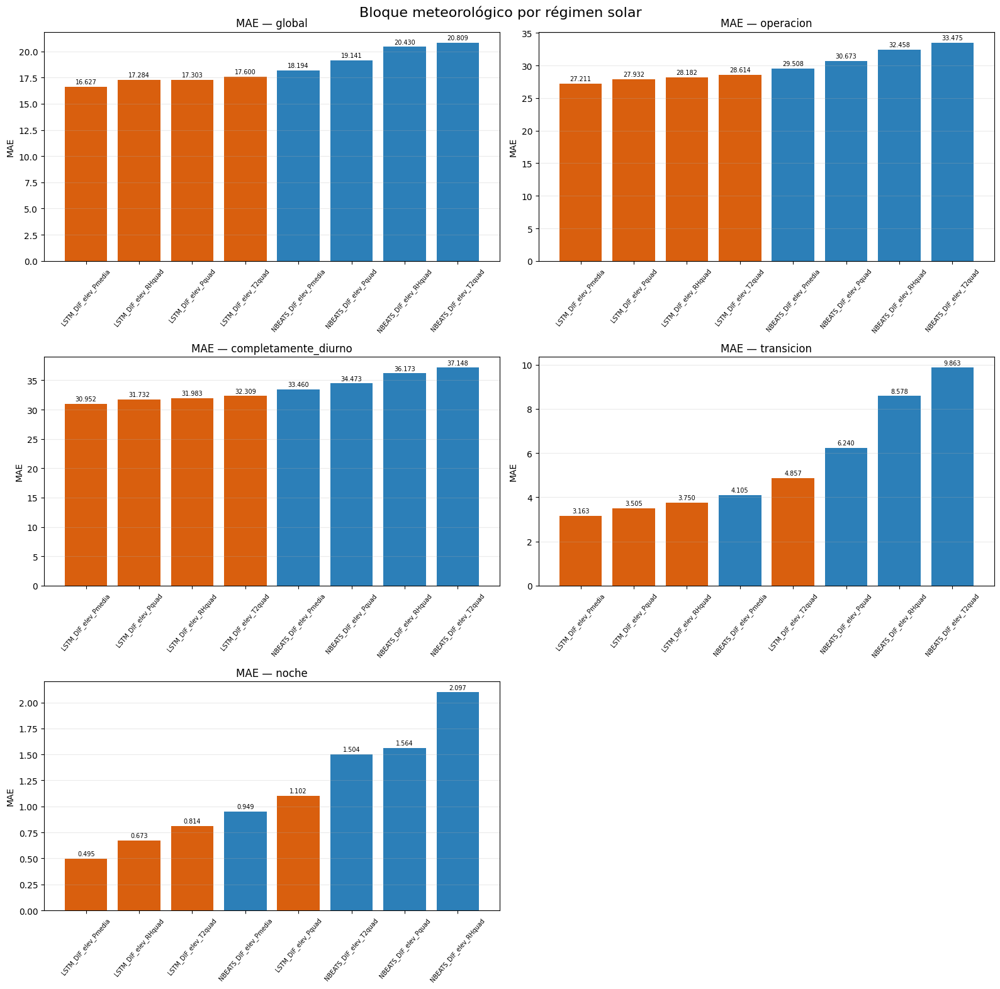


ANÁLISIS POR REGÍMENES COMPLETADO
Directorio: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/ejecuciones/reentrenamiento_meteo_20261006T220505Z/analisis_regimenes_20261006T221610Z
Modelos evaluados: 8
Modelos reentrenados de nuevo: no
Test utilizado: no


In [ ]:
import json
import unicodedata
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

# 1. Verificaciones
if "DIR_REENTRENAMIENTO_METEO" not in globals():
    raise RuntimeError("No está disponible DIR_REENTRENAMIENTO_METEO.")

if "resultados_validation_meteo" not in globals():
    raise RuntimeError("No está disponible resultados_validation_meteo.")

if "regimen_solar_objetivo" not in validation_hgb.columns:
    raise KeyError("validation_hgb no contiene regimen_solar_objetivo.")

assert len(validation_hgb) == 1464
assert validation_hgb["instante_objetivo"].min() == (pd.Timestamp("2024-08-01 00:00:00", tz="UTC"))
assert validation_hgb["instante_objetivo"].max() == (pd.Timestamp("2024-09-30 23:00:00", tz="UTC"))


# 2. Canonizar las etiquetas solares
def normalizar_texto(valor):
    texto = str(valor).strip().lower()
    texto = "".join(
        caracter
        for caracter in unicodedata.normalize("NFKD", texto)
        if not unicodedata.combining(caracter)
    )
    return texto.replace("-", "_").replace(" ", "_")

def canonizar_regimen(valor):
    texto = normalizar_texto(valor)
    if "noche" in texto or "noct" in texto:
        return "noche"

    if "trans" in texto:
        return "transicion"

    if "complet" in texto and ("diurn" in texto or "dia" in texto):
        return "completamente_diurno"

    return "no_clasificado"

regimen_original = validation_hgb["regimen_solar_objetivo"].copy()
regimen_canonico = regimen_original.map(canonizar_regimen)
auditoria_regimenes = (
    pd.DataFrame({"original": regimen_original, "canonico": regimen_canonico})
    .value_counts()
    .reset_index(name="n")
)
print("Etiquetas solares detectadas:")
display(auditoria_regimenes)
if (regimen_canonico == "no_clasificado").any():
    valores_problematicos = regimen_original[regimen_canonico == "no_clasificado"].unique()
    raise ValueError("Hay regímenes sin clasificar: " f"{valores_problematicos}")


# 3. Máscaras de evaluación
MASCARAS_AMBITOS = {
    "global": np.ones(len(validation_hgb), dtype=bool),
    "operacion": regimen_canonico.isin(["transicion", "completamente_diurno"]).to_numpy(),
    "completamente_diurno": (regimen_canonico == "completamente_diurno").to_numpy(),
    "transicion": (regimen_canonico == "transicion").to_numpy(),
    "noche": (regimen_canonico == "noche").to_numpy(),
}
resumen_ambitos = pd.DataFrame(
    [
        {
            "ambito": ambito,
            "n": int(mascara.sum()),
            "porcentaje_validation": (100.0 * mascara.mean()),
        }
        for ambito, mascara in MASCARAS_AMBITOS.items()
    ]
)
print("\nTamaño de los ámbitos:")
display(resumen_ambitos)


# 4. Función de métricas
def metricas_regimen(y_real, y_pred):
    y_real = np.asarray(y_real, dtype=np.float64)
    y_pred = np.asarray(y_pred, dtype=np.float64)
    error = y_pred - y_real
    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error**2))
    media_absoluta = np.mean(np.abs(y_real))
    nmae = 100.0 * mae / media_absoluta if media_absoluta > 0 else np.nan
    ss_res = np.sum(error**2)
    ss_tot = np.sum((y_real - np.mean(y_real)) ** 2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > np.finfo(float).eps else np.nan
    return {
        "n": len(y_real),
        "MAE": float(mae),
        "nMAE_pct": float(nmae),
        "RMSE": float(rmse),
        "R2": float(r2) if np.isfinite(r2) else np.nan,
        "bias": float(np.mean(error)),
        "suma_error_absoluto": float(np.sum(np.abs(error))),
    }


# 5. Leer predicciones guardadas
predicciones_modelos = {}
for _, fila in resultados_validation_meteo.iterrows():
    configuracion = fila["configuracion"]
    arquitectura = fila["arquitectura"]
    nombre_modelo = f"{arquitectura}_{configuracion}"
    ruta_predicciones = (
        DIR_REENTRENAMIENTO_METEO / nombre_modelo / "predicciones_validation.parquet"
    )
    if not ruta_predicciones.is_file():
        raise FileNotFoundError(f"No se encuentran las predicciones:\n" f"{ruta_predicciones}")

    pred = pd.read_parquet(ruta_predicciones)
    pred["instante_objetivo"] = pd.to_datetime(pred["instante_objetivo"], utc=True, errors="raise")
    pred = pred.sort_values("instante_objetivo").reset_index(drop=True)
    assert len(pred) == 1464
    assert np.array_equal(
        pred["instante_objetivo"].to_numpy(),
        validation_hgb["instante_objetivo"].sort_values().to_numpy(),
    )
    assert np.allclose(
        pred["y_real"].to_numpy(dtype=float),
        np.asarray(y_validation, dtype=float),
        atol=1e-5,
        rtol=1e-6,
    )
    pred["regimen_canonico"] = regimen_canonico.to_numpy()
    predicciones_modelos[nombre_modelo] = {
        "configuracion": configuracion,
        "arquitectura": arquitectura,
        "predicciones": pred,
    }

print("\nPredicciones cargadas:", len(predicciones_modelos))


# 6. Calcular métricas por ámbito
registros_metricas = []
registros_predicciones = []
for nombre_modelo, info in predicciones_modelos.items():
    pred = info["predicciones"]
    y_real = pred["y_real"].to_numpy(dtype=np.float64)
    y_pred = pred["y_pred"].to_numpy(dtype=np.float64)
    error_absoluto_total = np.sum(np.abs(y_pred - y_real))
    for ambito, mascara in MASCARAS_AMBITOS.items():
        metricas = metricas_regimen(y_real[mascara], y_pred[mascara])
        contribucion_error = 100.0 * metricas["suma_error_absoluto"] / error_absoluto_total
        registros_metricas.append(
            {
                "modelo": nombre_modelo,
                "configuracion": info["configuracion"],
                "arquitectura": info["arquitectura"],
                "ambito": ambito,
                **metricas,
                "contribucion_error_abs_pct": contribucion_error,
            }
        )

    pred_larga = pred.copy()
    pred_larga["modelo"] = nombre_modelo
    pred_larga["configuracion"] = info["configuracion"]
    pred_larga["arquitectura"] = info["arquitectura"]
    registros_predicciones.append(pred_larga)

metricas_meteo_regimenes = pd.DataFrame(registros_metricas)
predicciones_meteo_validation = pd.concat(registros_predicciones, ignore_index=True)


# 7. Ranking independiente dentro de cada ámbito
metricas_meteo_regimenes["ranking_MAE"] = (
    metricas_meteo_regimenes.groupby("ambito")["MAE"].rank(method="min", ascending=True).astype(int)
)
ORDEN_AMBITOS = ["global", "operacion", "completamente_diurno", "transicion", "noche"]
metricas_meteo_regimenes["ambito"] = pd.Categorical(
    metricas_meteo_regimenes["ambito"], categories=ORDEN_AMBITOS, ordered=True
)
metricas_meteo_regimenes = metricas_meteo_regimenes.sort_values(
    ["ambito", "ranking_MAE", "modelo"]
).reset_index(drop=True)
columnas_mostrar = [
    "ranking_MAE",
    "modelo",
    "n",
    "MAE",
    "nMAE_pct",
    "RMSE",
    "R2",
    "bias",
    "contribucion_error_abs_pct",
]
for ambito in ORDEN_AMBITOS:
    print("\n" + "=" * 80)
    print(f"ÁMBITO: {ambito.upper()}")
    print("=" * 80)
    tabla = metricas_meteo_regimenes[metricas_meteo_regimenes["ambito"] == ambito][columnas_mostrar]
    display(tabla)


# 8. Tabla compacta de MAE
tabla_MAE_ambitos = (
    metricas_meteo_regimenes.pivot(index="modelo", columns="ambito", values="MAE")
    .reindex(columns=ORDEN_AMBITOS)
    .sort_values("global")
)
print("\nMAE por modelo y ámbito:")
display(tabla_MAE_ambitos)


# 9. Ganancia de usar solo P_media frente a P_quad
comparacion_presion = []
for arquitectura in ["LSTM", "NBEATS"]:
    modelo_media = f"{arquitectura}_DIF_elev_Pmedia"
    modelo_quad = f"{arquitectura}_DIF_elev_Pquad"
    for ambito in ORDEN_AMBITOS:
        mae_media = float(
            metricas_meteo_regimenes.loc[
                (metricas_meteo_regimenes["modelo"] == modelo_media)
                & (metricas_meteo_regimenes["ambito"] == ambito),
                "MAE",
            ].iloc[0]
        )
        mae_quad = float(
            metricas_meteo_regimenes.loc[
                (metricas_meteo_regimenes["modelo"] == modelo_quad)
                & (metricas_meteo_regimenes["ambito"] == ambito),
                "MAE",
            ].iloc[0]
        )
        comparacion_presion.append(
            {
                "arquitectura": arquitectura,
                "ambito": ambito,
                "MAE_Pmedia": mae_media,
                "MAE_Pquad": mae_quad,
                "ventaja_Pmedia": mae_quad - mae_media,
            }
        )

comparacion_Pmedia_Pquad = pd.DataFrame(comparacion_presion)
print("\nComparación P_media frente a P_quad (positivo = ventaja de P_media):")
display(comparacion_Pmedia_Pquad)


# 10. Gráficas de MAE por ámbito
fig, axes = plt.subplots(3, 2, figsize=(16, 16))
for ax, ambito in zip(axes.ravel(), ORDEN_AMBITOS):
    tabla = metricas_meteo_regimenes[metricas_meteo_regimenes["ambito"] == ambito].sort_values(
        "MAE"
    )
    colores = tabla["arquitectura"].map({"NBEATS": "#2C7FB8", "LSTM": "#D95F0E"})
    barras = ax.bar(tabla["modelo"], tabla["MAE"], color=colores)
    ax.bar_label(barras, fmt="%.3f", padding=2, fontsize=7)
    ax.set_title(f"MAE — {ambito}")
    ax.set_ylabel("MAE")
    ax.tick_params(axis="x", rotation=50, labelsize=7)
    ax.grid(axis="y", alpha=0.25)

axes[-1, -1].axis("off")
fig.suptitle("Bloque meteorológico por régimen solar", fontsize=16)
fig.tight_layout()
marca_temporal = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
DIR_REGIMENES_METEO = DIR_REENTRENAMIENTO_METEO / f"analisis_regimenes_{marca_temporal}"
DIR_REGIMENES_METEO.mkdir(parents=True, exist_ok=False)
fig.savefig(DIR_REGIMENES_METEO / "comparacion_MAE_por_ambito.png", dpi=170, bbox_inches="tight")
plt.show()
plt.close(fig)


# 11. Guardar resultados
metricas_meteo_regimenes.to_csv(DIR_REGIMENES_METEO / "metricas_meteo_por_regimen.csv", index=False)
tabla_MAE_ambitos.to_csv(DIR_REGIMENES_METEO / "tabla_MAE_por_ambito.csv")
comparacion_Pmedia_Pquad.to_csv(DIR_REGIMENES_METEO / "comparacion_Pmedia_Pquad.csv", index=False)
predicciones_meteo_validation.to_parquet(
    DIR_REGIMENES_METEO / "predicciones_meteo_validation.parquet", index=False
)
resumen_ambitos.to_csv(DIR_REGIMENES_METEO / "resumen_ambitos.csv", index=False)
auditoria_regimenes.to_csv(DIR_REGIMENES_METEO / "auditoria_etiquetas_regimen.csv", index=False)


# 12. Configuración y puntero
configuracion_regimenes = {
    "fecha_creacion_utc": marca_temporal,
    "validation_inicio": "2024-08-01 00:00:00+00:00",
    "validation_fin": "2024-09-30 23:00:00+00:00",
    "validation_n": 1464,
    "ambitos": {
        "global": "todas las observaciones",
        "operacion": ("transicion + completamente_diurno"),
        "completamente_diurno": "régimen original completamente diurno",
        "transicion": "régimen original transición",
        "noche": "régimen original noche",
    },
    "metricas": ["MAE", "nMAE_pct", "RMSE", "R2", "bias", "contribucion_error_abs_pct"],
    "predicciones_reutilizadas": True,
    "modelos_reentrenados_nuevamente": False,
    "test_utilizado": False,
}
with open(
    DIR_REGIMENES_METEO / "configuracion_analisis_regimenes.json", "w", encoding="utf-8"
) as archivo:
    json.dump(configuracion_regimenes, archivo, ensure_ascii=False, indent=2)

RUTA_PUNTERO_REGIMENES = BASE_DIR / "documentacion" / "ULTIMO_ANALISIS_REGIMENES_METEO.json"
with open(RUTA_PUNTERO_REGIMENES, "w", encoding="utf-8") as archivo:
    json.dump(
        {
            "fecha_creacion_utc": marca_temporal,
            "directorio": str(DIR_REGIMENES_METEO),
            "metricas": str(DIR_REGIMENES_METEO / "metricas_meteo_por_regimen.csv"),
            "tabla_MAE": str(DIR_REGIMENES_METEO / "tabla_MAE_por_ambito.csv"),
            "test_utilizado": False,
        },
        archivo,
        ensure_ascii=False,
        indent=2,
    )

print("\n" + "=" * 80)
print("ANÁLISIS POR REGÍMENES COMPLETADO")
print("=" * 80)
print(f"Directorio: {DIR_REGIMENES_METEO}")
print("Modelos evaluados: 8")
print("Modelos reentrenados de nuevo: no")
print("Test utilizado: no")
print("=" * 80)

Peso de la noche en validation: 39.617 %

MAE nocturno derivado para 15 modelos anteriores.

Modelos con información incompleta por régimen:


ambito,modelo,arquitectura,n_ambitos_disponibles,global,operacion,completamente_diurno,transicion,noche
2,LSTM-DIR,LSTM,1,16.325878,NaN,NaN,NaN,NaN
3,LSTM-GeomT,LSTM,1,16.265980,NaN,NaN,NaN,NaN
10,LSTM-SWD+DIR,LSTM,1,16.350744,NaN,NaN,NaN,NaN
11,LSTM-SWD+DIR+FD,LSTM,1,15.885435,NaN,NaN,NaN,NaN
12,LSTM-SWD+FD,LSTM,1,16.230541,NaN,NaN,NaN,NaN
18,NBEATS-DIR,NBEATS,1,19.389965,NaN,NaN,NaN,NaN
19,NBEATS-Delta,NBEATS,1,18.039769,NaN,NaN,NaN,NaN
20,NBEATS-GeomT,NBEATS,1,17.826234,NaN,NaN,NaN,NaN
27,NBEATS-SWD+DIR,NBEATS,1,18.595570,NaN,NaN,NaN,NaN
28,NBEATS-SWD+DIR+FD,NBEATS,1,20.789492,NaN,NaN,NaN,NaN



Comparación relativa frente al baseline:


ambito,modelo,arquitectura,mejora_pct_global,mejora_pct_operacion,mejora_pct_completamente_diurno,mejora_pct_transicion,mejora_pct_noche,fraccion_mejora_procedente_noche_pct,concentracion_nocturna,clasificacion,descartar_por_dependencia_nocturna
0,LSTM-DIFstats,LSTM,6.4586,6.2785,6.1407,15.0441,19.6254,4.0997,0.1035,MEJORA TAMBIÉN EN OPERACIÓN,False
1,LSTM-SWD,LSTM,5.4554,5.1121,5.2768,-5.3644,30.5567,7.5570,0.1907,MEJORA TAMBIÉN EN OPERACIÓN,False
2,LSTM-Pmedia,LSTM,0.9302,0.7602,0.7773,-0.3310,13.3666,19.3863,0.4893,MEJORA TAMBIÉN EN OPERACIÓN,False
3,LSTM-DIF+Elevación,LSTM,0.0000,0.0000,0.0000,0.0000,0.0000,NaN,NaN,BASELINE DE REFERENCIA,False
4,LSTM-LWU,LSTM,-0.3447,0.0874,1.3887,-82.6795,-31.9399,NaN,NaN,NO MEJORA GLOBALMENTE,False
5,LSTM-SWU,LSTM,-1.1862,0.0160,0.7800,-48.5758,-89.0915,NaN,NaN,NO MEJORA GLOBALMENTE,False
6,LSTM-solo DIF,LSTM,-1.5441,-2.1179,-1.6781,-30.0932,40.4065,NaN,NaN,NO MEJORA GLOBALMENTE,False
7,LSTM-LWD,LSTM,-1.5561,-0.8635,-0.3405,-34.1281,-52.1997,NaN,NaN,NO MEJORA GLOBALMENTE,False
8,LSTM-RHquad,LSTM,-2.9845,-2.7818,-2.5277,-18.9442,-17.8003,NaN,NaN,NO MEJORA GLOBALMENTE,False
9,LSTM-Pquad,LSTM,-3.0962,-1.8681,-1.7216,-11.1825,-92.8923,NaN,NaN,NO MEJORA GLOBALMENTE,False


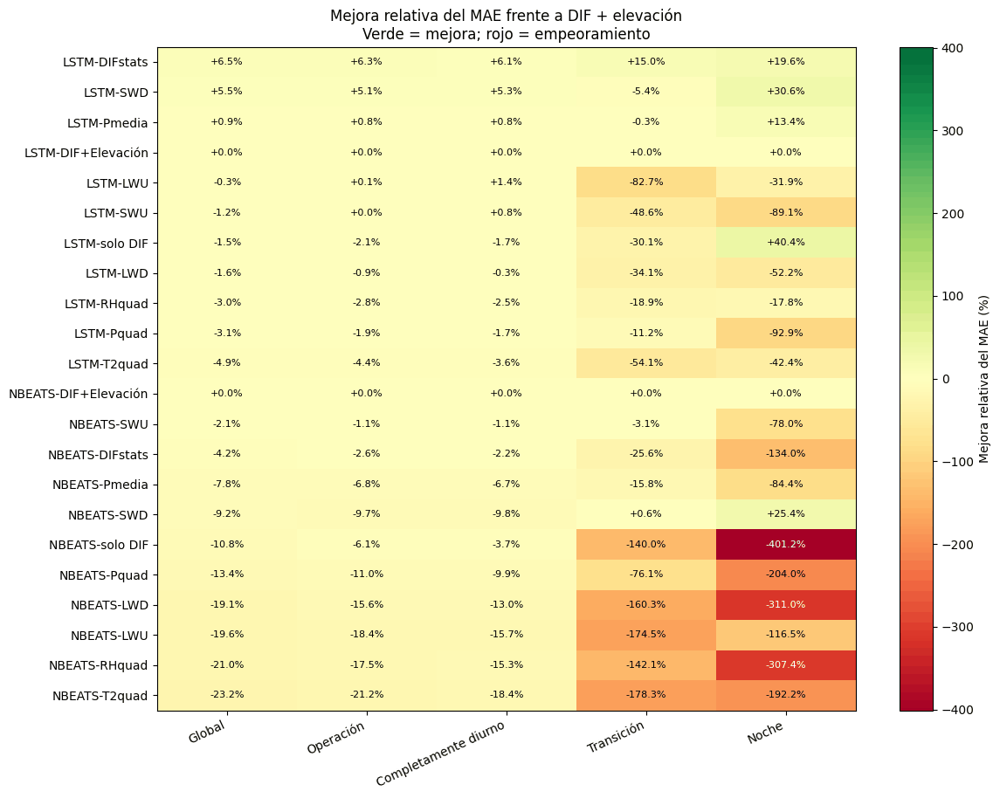

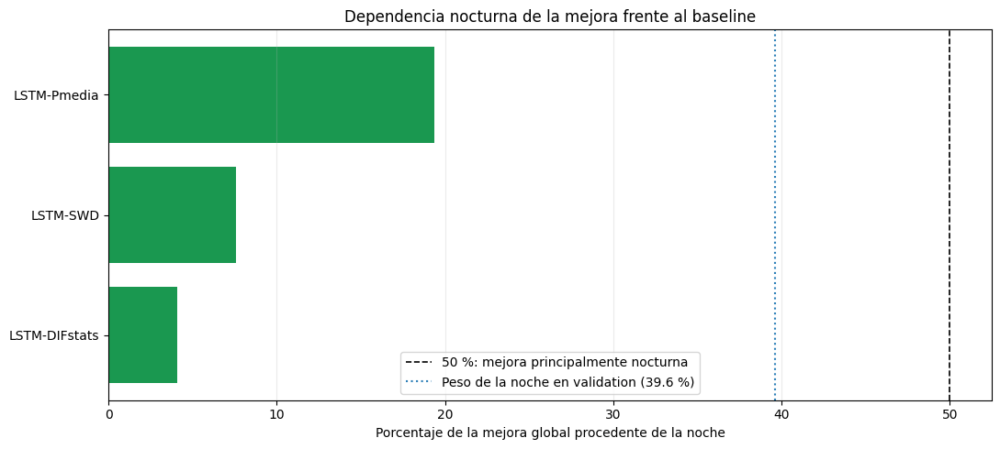


COMPARACIÓN RELATIVA COMPLETADA
Directorio: /content/drive/MyDrive/TFM Aghmir/TFM/02. Modelado Multivariante/03. Modelado/resultados/comparativas/comparacion_relativa_baselines_20261006T223100Z
Perfiles completos comparados: 22
Modelos pendientes de métricas por régimen: 11
Test utilizado: no


In [ ]:
import json
from datetime import datetime, timezone
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import TwoSlopeNorm

# 1. Rutas y tamaños de los ámbitos
DIR_MASTER_DIFSTATS = (
    BASE_DIR / "resultados" / "comparativas" / "comparacion_global_con_difstats_20261006_183444"
)
RUTA_MASTER_ANTERIOR = DIR_MASTER_DIFSTATS / "metricas_modelos_por_ambito.csv"
if not RUTA_MASTER_ANTERIOR.is_file():
    raise FileNotFoundError(f"No se encuentra la tabla maestra:\n" f"{RUTA_MASTER_ANTERIOR}")

N_AMBITOS = {
    "global": 1464,
    "operacion": 884,
    "completamente_diurno": 765,
    "transicion": 119,
    "noche": 580,
}
ORDEN_AMBITOS = ["global", "operacion", "completamente_diurno", "transicion", "noche"]
assert N_AMBITOS["operacion"] == N_AMBITOS["completamente_diurno"] + N_AMBITOS["transicion"]
assert N_AMBITOS["global"] == N_AMBITOS["operacion"] + N_AMBITOS["noche"]
PORCENTAJE_OBSERVACIONES_NOCHE = 100.0 * N_AMBITOS["noche"] / N_AMBITOS["global"]
print("Peso de la noche en validation:", f"{PORCENTAJE_OBSERVACIONES_NOCHE:.3f} %")


# 2. Cargar resultados anteriores
metricas_anteriores = pd.read_csv(RUTA_MASTER_ANTERIOR)
metricas_anteriores["ambito"] = metricas_anteriores["ambito"].replace({"total": "global"})
columnas_base = ["modelo", "ambito", "MAE", "nMAE_pct", "RMSE", "R2", "bias"]
for columna in columnas_base:
    if columna not in metricas_anteriores.columns:
        metricas_anteriores[columna] = np.nan

metricas_anteriores = metricas_anteriores[columnas_base].copy()
metricas_anteriores["fuente_comparacion"] = "tabla_maestra_hasta_DIFstats"


# 3. Incorporar los ocho modelos meteorológicos
if "metricas_meteo_regimenes" not in globals():
    if "DIR_REGIMENES_METEO" not in globals():
        raise RuntimeError("No están disponibles las métricas meteorológicas.")

    metricas_meteo_regimenes = pd.read_csv(DIR_REGIMENES_METEO / "metricas_meteo_por_regimen.csv")

metricas_meteo = metricas_meteo_regimenes.copy()
MAPA_NOMBRES_METEO = {
    "LSTM_DIF_elev_T2quad": "LSTM-T2quad",
    "LSTM_DIF_elev_RHquad": "LSTM-RHquad",
    "LSTM_DIF_elev_Pmedia": "LSTM-Pmedia",
    "LSTM_DIF_elev_Pquad": "LSTM-Pquad",
    "NBEATS_DIF_elev_T2quad": "NBEATS-T2quad",
    "NBEATS_DIF_elev_RHquad": "NBEATS-RHquad",
    "NBEATS_DIF_elev_Pmedia": "NBEATS-Pmedia",
    "NBEATS_DIF_elev_Pquad": "NBEATS-Pquad",
}
metricas_meteo["modelo"] = metricas_meteo["modelo"].replace(MAPA_NOMBRES_METEO)
for columna in columnas_base:
    if columna not in metricas_meteo.columns:
        metricas_meteo[columna] = np.nan

metricas_meteo = metricas_meteo[columnas_base].copy()
metricas_meteo["fuente_comparacion"] = "bloque_meteorologico_actual"


# 4. Combinar y eliminar posibles duplicados
metricas_todos_ambitos = pd.concat([metricas_anteriores, metricas_meteo], ignore_index=True)
metricas_todos_ambitos = metricas_todos_ambitos.drop_duplicates(
    subset=["modelo", "ambito"], keep="last"
).reset_index(drop=True)


# 5. Identificar arquitectura
def identificar_arquitectura(modelo):
    modelo_mayusculas = str(modelo).upper()
    if modelo_mayusculas.startswith("LSTM"):
        return "LSTM"

    if modelo_mayusculas.startswith("NBEATS"):
        return "NBEATS"

    return "OTRA"

metricas_todos_ambitos["arquitectura"] = metricas_todos_ambitos["modelo"].map(
    identificar_arquitectura
)


# 6. Derivar MAE nocturno cuando no esté almacenado
# Como global = operación + noche:
#
# MAE_g * n_g =
# MAE_op * n_op + MAE_noche * n_noche
filas_noche_derivadas = []
for modelo, grupo in metricas_todos_ambitos.groupby("modelo"):
    ambitos_disponibles = set(grupo["ambito"])
    if "noche" in ambitos_disponibles:
        continue

    if not {"global", "operacion"}.issubset(ambitos_disponibles):
        continue

    mae_global = float(grupo.loc[grupo["ambito"] == "global", "MAE"].iloc[0])
    mae_operacion = float(grupo.loc[grupo["ambito"] == "operacion", "MAE"].iloc[0])
    mae_noche = (
        mae_global * N_AMBITOS["global"] - mae_operacion * N_AMBITOS["operacion"]
    ) / N_AMBITOS["noche"]
    arquitectura = identificar_arquitectura(modelo)
    filas_noche_derivadas.append(
        {
            "modelo": modelo,
            "ambito": "noche",
            "MAE": mae_noche,
            "nMAE_pct": np.nan,
            "RMSE": np.nan,
            "R2": np.nan,
            "bias": np.nan,
            "fuente_comparacion": "derivado_exactamente_de_global_y_operacion",
            "arquitectura": arquitectura,
        }
    )

if filas_noche_derivadas:
    metricas_todos_ambitos = pd.concat(
        [metricas_todos_ambitos, pd.DataFrame(filas_noche_derivadas)], ignore_index=True
    )

print("\nMAE nocturno derivado para", len(filas_noche_derivadas), "modelos anteriores.")


# 7. Auditar qué modelos tienen los cinco ámbitos
cobertura_ambitos = (
    metricas_todos_ambitos[metricas_todos_ambitos["arquitectura"].isin(["LSTM", "NBEATS"])]
    .pivot_table(index=["modelo", "arquitectura"], columns="ambito", values="MAE", aggfunc="first")
    .reset_index()
)
for ambito in ORDEN_AMBITOS:
    if ambito not in cobertura_ambitos.columns:
        cobertura_ambitos[ambito] = np.nan

cobertura_ambitos["n_ambitos_disponibles"] = cobertura_ambitos[ORDEN_AMBITOS].notna().sum(axis=1)
cobertura_ambitos["perfil_completo"] = cobertura_ambitos[ORDEN_AMBITOS].notna().all(axis=1)
modelos_pendientes_regimenes = cobertura_ambitos.loc[~cobertura_ambitos["perfil_completo"]].copy()
print("\nModelos con información incompleta por régimen:")
display(
    modelos_pendientes_regimenes[
        ["modelo", "arquitectura", "n_ambitos_disponibles"] + ORDEN_AMBITOS
    ]
)


# 8. Conservar perfiles completos LSTM y N-BEATS
modelos_completos = set(cobertura_ambitos.loc[cobertura_ambitos["perfil_completo"], "modelo"])
metricas_relativas = metricas_todos_ambitos.loc[
    metricas_todos_ambitos["modelo"].isin(modelos_completos)
    & metricas_todos_ambitos["arquitectura"].isin(["LSTM", "NBEATS"])
].copy()
BASELINES = {"LSTM": "LSTM-DIF+Elevación", "NBEATS": "NBEATS-DIF+Elevación"}
for arquitectura, baseline in BASELINES.items():
    if baseline not in modelos_completos:
        raise RuntimeError(f"Falta el baseline requerido: {baseline}")


# 9. Añadir el MAE del baseline correspondiente
tabla_baselines = metricas_relativas.loc[
    metricas_relativas.apply(
        lambda fila: fila["modelo"] == BASELINES[fila["arquitectura"]], axis=1
    ),
    ["arquitectura", "ambito", "MAE"],
].rename(columns={"MAE": "MAE_baseline"})
metricas_relativas = metricas_relativas.merge(
    tabla_baselines, on=["arquitectura", "ambito"], how="left", validate="many_to_one"
)
assert metricas_relativas["MAE_baseline"].notna().all()


# 10. Medidas relativas
metricas_relativas["ganancia_MAE"] = metricas_relativas["MAE_baseline"] - metricas_relativas["MAE"]
metricas_relativas["mejora_relativa_pct"] = (
    100.0 * metricas_relativas["ganancia_MAE"] / metricas_relativas["MAE_baseline"]
)
metricas_relativas["resultado_frente_baseline"] = np.select(
    [
        metricas_relativas["mejora_relativa_pct"] > 1e-9,
        metricas_relativas["mejora_relativa_pct"] < -1e-9,
    ],
    ["mejora", "empeora"],
    default="baseline",
)


# 11. Tabla ancha para decisión por modelo
tabla_ganancia_abs = metricas_relativas.pivot(
    index=["modelo", "arquitectura"], columns="ambito", values="ganancia_MAE"
).reindex(columns=ORDEN_AMBITOS)
tabla_mejora_pct = metricas_relativas.pivot(
    index=["modelo", "arquitectura"], columns="ambito", values="mejora_relativa_pct"
).reindex(columns=ORDEN_AMBITOS)
tabla_decision_relativa = (
    tabla_mejora_pct.add_prefix("mejora_pct_")
    .join(tabla_ganancia_abs.add_prefix("ganancia_MAE_"))
    .reset_index()
)


# 12. Cuánto de la mejora global procede de la noche
tabla_decision_relativa["reduccion_error_total_acumulada"] = (
    tabla_decision_relativa["ganancia_MAE_global"] * N_AMBITOS["global"]
)
tabla_decision_relativa["reduccion_error_operacion_acumulada"] = (
    tabla_decision_relativa["ganancia_MAE_operacion"] * N_AMBITOS["operacion"]
)
tabla_decision_relativa["reduccion_error_noche_acumulada"] = (
    tabla_decision_relativa["ganancia_MAE_noche"] * N_AMBITOS["noche"]
)

# Comprobación de identidad:
# mejora total = mejora operación + mejora noche
tabla_decision_relativa["error_identidad_descomposicion"] = tabla_decision_relativa[
    "reduccion_error_total_acumulada"
] - (
    tabla_decision_relativa["reduccion_error_operacion_acumulada"]
    + tabla_decision_relativa["reduccion_error_noche_acumulada"]
)
assert np.allclose(
    tabla_decision_relativa["error_identidad_descomposicion"], 0.0, atol=1e-5, rtol=1e-7
)
mejora_global_positiva = tabla_decision_relativa["reduccion_error_total_acumulada"] > 1e-9
tabla_decision_relativa["fraccion_mejora_procedente_noche_pct"] = np.where(
    mejora_global_positiva,
    100.0
    * tabla_decision_relativa["reduccion_error_noche_acumulada"]
    / tabla_decision_relativa["reduccion_error_total_acumulada"],
    np.nan,
)
tabla_decision_relativa["concentracion_nocturna"] = (
    tabla_decision_relativa["fraccion_mejora_procedente_noche_pct"] / PORCENTAJE_OBSERVACIONES_NOCHE
)


# 13. Regla de clasificación
def clasificar_modelo(fila):
    baseline = BASELINES[fila["arquitectura"]]
    if fila["modelo"] == baseline:
        return "BASELINE DE REFERENCIA"

    if fila["mejora_pct_global"] <= 0:
        return "NO MEJORA GLOBALMENTE"

    if fila["ganancia_MAE_operacion"] <= 0 and fila["ganancia_MAE_noche"] > 0:
        return "MEJORA GLOBAL SOSTENIDA POR LA NOCHE"

    if fila["fraccion_mejora_procedente_noche_pct"] > 50:
        return "MEJORA PRINCIPALMENTE NOCTURNA"

    if fila["ganancia_MAE_operacion"] > 0:
        return "MEJORA TAMBIÉN EN OPERACIÓN"

    return "REVISAR"

tabla_decision_relativa["clasificacion"] = tabla_decision_relativa.apply(clasificar_modelo, axis=1)
tabla_decision_relativa["descartar_por_dependencia_nocturna"] = tabla_decision_relativa[
    "clasificacion"
].isin(["MEJORA GLOBAL SOSTENIDA POR LA NOCHE", "MEJORA PRINCIPALMENTE NOCTURNA"])
tabla_decision_relativa = tabla_decision_relativa.sort_values(
    ["arquitectura", "mejora_pct_global"], ascending=[True, False]
).reset_index(drop=True)


# 14. Mostrar tabla principal
columnas_decision = [
    "modelo",
    "arquitectura",
    "mejora_pct_global",
    "mejora_pct_operacion",
    "mejora_pct_completamente_diurno",
    "mejora_pct_transicion",
    "mejora_pct_noche",
    "fraccion_mejora_procedente_noche_pct",
    "concentracion_nocturna",
    "clasificacion",
    "descartar_por_dependencia_nocturna",
]
print("\nComparación relativa frente al baseline:")
display(tabla_decision_relativa[columnas_decision].round(4))


# 15. Mapa de calor de mejora relativa
tabla_heatmap = tabla_decision_relativa.set_index("modelo")[
    [
        "mejora_pct_global",
        "mejora_pct_operacion",
        "mejora_pct_completamente_diurno",
        "mejora_pct_transicion",
        "mejora_pct_noche",
    ]
]
valores = tabla_heatmap.to_numpy(dtype=float)
limite = np.nanmax(np.abs(valores))
limite = max(limite, 1.0)
fig, ax = plt.subplots(figsize=(12, max(7, 0.42 * len(tabla_heatmap))))
imagen = ax.imshow(
    valores, cmap="RdYlGn", aspect="auto", norm=TwoSlopeNorm(vmin=-limite, vcenter=0, vmax=limite)
)
ax.set_xticks(np.arange(tabla_heatmap.shape[1]))
ax.set_xticklabels(
    ["Global", "Operación", "Completamente diurno", "Transición", "Noche"], rotation=25, ha="right"
)
ax.set_yticks(np.arange(tabla_heatmap.shape[0]))
ax.set_yticklabels(tabla_heatmap.index)
for i in range(valores.shape[0]):
    for j in range(valores.shape[1]):
        valor = valores[i, j]
        if np.isfinite(valor):
            ax.text(
                j,
                i,
                f"{valor:+.1f}%",
                ha="center",
                va="center",
                fontsize=8,
                color=("white" if abs(valor) > 0.55 * limite else "black"),
            )

ax.set_title(
    "Mejora relativa del MAE frente a DIF + elevación\nVerde = mejora; rojo = empeoramiento"
)
fig.colorbar(imagen, ax=ax, label="Mejora relativa del MAE (%)")
fig.tight_layout()


# 16. Gráfica de dependencia nocturna
tabla_noche = tabla_decision_relativa.loc[
    tabla_decision_relativa["mejora_pct_global"] > 0
].sort_values("fraccion_mejora_procedente_noche_pct")
fig_noche, ax_noche = plt.subplots(figsize=(11, max(5, 0.45 * len(tabla_noche))))
colores_noche = np.where(
    tabla_noche["fraccion_mejora_procedente_noche_pct"] > 50, "#D73027", "#1A9850"
)
ax_noche.barh(
    tabla_noche["modelo"], tabla_noche["fraccion_mejora_procedente_noche_pct"], color=colores_noche
)
ax_noche.axvline(
    50, color="black", linestyle="--", linewidth=1.2, label="50 %: mejora principalmente nocturna"
)
ax_noche.axvline(
    PORCENTAJE_OBSERVACIONES_NOCHE,
    color="#2C7FB8",
    linestyle=":",
    linewidth=1.5,
    label=("Peso de la noche en validation " f"({PORCENTAJE_OBSERVACIONES_NOCHE:.1f} %)"),
)
ax_noche.set_xlabel("Porcentaje de la mejora global procedente de la noche")
ax_noche.set_title("Dependencia nocturna de la mejora frente al baseline")
ax_noche.grid(axis="x", alpha=0.25)
ax_noche.legend()
fig_noche.tight_layout()


# 17. Guardar comparación
marca_temporal = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
DIR_COMPARACION_RELATIVA = (
    BASE_DIR / "resultados" / "comparativas" / f"comparacion_relativa_baselines_{marca_temporal}"
)
DIR_COMPARACION_RELATIVA.mkdir(parents=True, exist_ok=False)
metricas_todos_ambitos.to_csv(
    DIR_COMPARACION_RELATIVA / "metricas_consolidadas_por_ambito.csv", index=False
)
metricas_relativas.to_csv(
    DIR_COMPARACION_RELATIVA / "comparacion_relativa_formato_largo.csv", index=False
)
tabla_decision_relativa.to_csv(
    DIR_COMPARACION_RELATIVA / "tabla_decision_dependencia_nocturna.csv", index=False
)
modelos_pendientes_regimenes.to_csv(
    DIR_COMPARACION_RELATIVA / "modelos_pendientes_metricas_regimen.csv", index=False
)
fig.savefig(
    DIR_COMPARACION_RELATIVA / "mapa_mejora_relativa_por_ambito.png", dpi=180, bbox_inches="tight"
)
fig_noche.savefig(
    DIR_COMPARACION_RELATIVA / "dependencia_nocturna_mejora.png", dpi=180, bbox_inches="tight"
)
plt.show()
plt.close(fig)
plt.show()
plt.close(fig_noche)


# 18. Configuración metodológica y puntero
configuracion_comparacion = {
    "fecha_creacion_utc": marca_temporal,
    "baselines": BASELINES,
    "definicion_mejora_relativa": ("100 * (MAE_baseline - MAE_modelo) / MAE_baseline"),
    "interpretacion_mejora_relativa": {
        "positiva": "mejora frente al baseline",
        "cero": "igual al baseline",
        "negativa": "empeora frente al baseline",
    },
    "definicion_dependencia_nocturna": (
        "porcentaje de la reducción absoluta total "
        "del error que procede de las observaciones nocturnas"
    ),
    "umbral_principalmente_nocturna_pct": 50,
    "porcentaje_observaciones_noche": PORCENTAJE_OBSERVACIONES_NOCHE,
    "n_ambitos": N_AMBITOS,
    "test_utilizado": False,
}
with open(
    DIR_COMPARACION_RELATIVA / "configuracion_comparacion.json", "w", encoding="utf-8"
) as archivo:
    json.dump(configuracion_comparacion, archivo, ensure_ascii=False, indent=2)

RUTA_PUNTERO_COMPARACION = BASE_DIR / "documentacion" / "ULTIMA_COMPARACION_RELATIVA_BASELINES.json"
with open(RUTA_PUNTERO_COMPARACION, "w", encoding="utf-8") as archivo:
    json.dump(
        {
            "fecha_creacion_utc": marca_temporal,
            "directorio": str(DIR_COMPARACION_RELATIVA),
            "tabla_decision": str(
                DIR_COMPARACION_RELATIVA / "tabla_decision_dependencia_nocturna.csv"
            ),
            "modelos_pendientes": str(
                DIR_COMPARACION_RELATIVA / "modelos_pendientes_metricas_regimen.csv"
            ),
            "test_utilizado": False,
        },
        archivo,
        ensure_ascii=False,
        indent=2,
    )

print("\n" + "=" * 80)
print("COMPARACIÓN RELATIVA COMPLETADA")
print("=" * 80)
print(f"Directorio: {DIR_COMPARACION_RELATIVA}")
print("Perfiles completos comparados:", len(tabla_decision_relativa))
print("Modelos pendientes de métricas por régimen:", len(modelos_pendientes_regimenes))
print("Test utilizado: no")
print("=" * 80)

In [ ]:
TOLERANCIA_COMPARACION = 1e-9

def estado_mejora(valor):
    if pd.isna(valor):
        return "NO DISPONIBLE"

    if valor > TOLERANCIA_COMPARACION:
        return "SÍ"

    if valor < -TOLERANCIA_COMPARACION:
        return "NO"

    return "BASELINE"

tabla_decision_relativa["mejora_en_operacion"] = tabla_decision_relativa[
    "ganancia_MAE_operacion"
].map(estado_mejora)
tabla_decision_relativa["mejora_en_completamente_diurno"] = tabla_decision_relativa[
    "ganancia_MAE_completamente_diurno"
].map(estado_mejora)
tabla_decision_relativa["mejora_en_transicion"] = tabla_decision_relativa[
    "ganancia_MAE_transicion"
].map(estado_mejora)
tabla_decision_relativa["mejora_en_noche"] = tabla_decision_relativa["ganancia_MAE_noche"].map(
    estado_mejora
)


# Mejora simultánea en los dos componentes de operación.
tabla_decision_relativa["mejora_en_ambos_regimenes_operativos"] = np.where(
    (tabla_decision_relativa["ganancia_MAE_completamente_diurno"] > TOLERANCIA_COMPARACION)
    & (tabla_decision_relativa["ganancia_MAE_transicion"] > TOLERANCIA_COMPARACION),
    "SÍ",
    "NO",
)

# Los propios baselines se identifican aparte.
for arquitectura, baseline in BASELINES.items():
    mascara_baseline = tabla_decision_relativa["modelo"] == baseline
    tabla_decision_relativa.loc[mascara_baseline, "mejora_en_ambos_regimenes_operativos"] = (
        "BASELINE"
    )


# Tabla ampliada para tomar decisiones
columnas_decision = [
    "modelo",
    "arquitectura",
    "mejora_pct_global",
    "mejora_en_operacion",
    "mejora_pct_operacion",
    "mejora_en_completamente_diurno",
    "mejora_pct_completamente_diurno",
    "mejora_en_transicion",
    "mejora_pct_transicion",
    "mejora_en_noche",
    "mejora_pct_noche",
    "mejora_en_ambos_regimenes_operativos",
    "fraccion_mejora_procedente_noche_pct",
    "concentracion_nocturna",
    "clasificacion",
    "descartar_por_dependencia_nocturna",
]
print("\nComparación ampliada frente al baseline de cada arquitectura:")
display(tabla_decision_relativa[columnas_decision].round(4))


Comparación ampliada frente al baseline de cada arquitectura:


ambito,modelo,arquitectura,mejora_pct_global,mejora_en_operacion,mejora_pct_operacion,mejora_en_completamente_diurno,mejora_pct_completamente_diurno,mejora_en_transicion,mejora_pct_transicion,mejora_en_noche,mejora_pct_noche,mejora_en_ambos_regimenes_operativos,fraccion_mejora_procedente_noche_pct,concentracion_nocturna,clasificacion,descartar_por_dependencia_nocturna
0,LSTM-DIFstats,LSTM,6.4586,SÍ,6.2785,SÍ,6.1407,SÍ,15.0441,SÍ,19.6254,SÍ,4.0997,0.1035,MEJORA TAMBIÉN EN OPERACIÓN,False
1,LSTM-SWD,LSTM,5.4554,SÍ,5.1121,SÍ,5.2768,NO,-5.3644,SÍ,30.5567,NO,7.5570,0.1907,MEJORA TAMBIÉN EN OPERACIÓN,False
2,LSTM-Pmedia,LSTM,0.9302,SÍ,0.7602,SÍ,0.7773,NO,-0.3310,SÍ,13.3666,NO,19.3863,0.4893,MEJORA TAMBIÉN EN OPERACIÓN,False
3,LSTM-DIF+Elevación,LSTM,0.0000,BASELINE,0.0000,BASELINE,0.0000,BASELINE,0.0000,BASELINE,0.0000,BASELINE,NaN,NaN,BASELINE DE REFERENCIA,False
4,LSTM-LWU,LSTM,-0.3447,SÍ,0.0874,SÍ,1.3887,NO,-82.6795,NO,-31.9399,NO,NaN,NaN,NO MEJORA GLOBALMENTE,False
5,LSTM-SWU,LSTM,-1.1862,SÍ,0.0160,SÍ,0.7800,NO,-48.5758,NO,-89.0915,NO,NaN,NaN,NO MEJORA GLOBALMENTE,False
6,LSTM-solo DIF,LSTM,-1.5441,NO,-2.1179,NO,-1.6781,NO,-30.0932,SÍ,40.4065,NO,NaN,NaN,NO MEJORA GLOBALMENTE,False
7,LSTM-LWD,LSTM,-1.5561,NO,-0.8635,NO,-0.3405,NO,-34.1281,NO,-52.1997,NO,NaN,NaN,NO MEJORA GLOBALMENTE,False
8,LSTM-RHquad,LSTM,-2.9845,NO,-2.7818,NO,-2.5277,NO,-18.9442,NO,-17.8003,NO,NaN,NaN,NO MEJORA GLOBALMENTE,False
9,LSTM-Pquad,LSTM,-3.0962,NO,-1.8681,NO,-1.7216,NO,-11.1825,NO,-92.8923,NO,NaN,NaN,NO MEJORA GLOBALMENTE,False


In [ ]:
tabla_decision_relativa.to_csv(
    DIR_COMPARACION_RELATIVA / "tabla_decision_dependencia_nocturna.csv", index=False
)

**Resultados.**

- `LSTM_DIF_elev_Pmedia` encabeza los cinco ámbitos (27,21 W/m² en operación; 3,16 W/m² en transición) y obtiene menor MAE que `LSTM_DIF_elev_Pquad` en todos ellos.
- Frente a `LSTM-DIF+Elevación`, solo tres modelos reducen el MAE global y también el de operación: `LSTM-DIFstats` (6,46 % y 6,28 %), `LSTM-SWD` (5,46 % y 5,11 %) y `LSTM-Pmedia` (0,93 % y 0,76 %).
- En `LSTM-DIFstats`, solo el 4,10 % de la mejora procede de la noche (19,39 % en `LSTM-Pmedia`).
- Ningún modelo N-BEATS con desglose completo reduce el MAE global de `NBEATS-DIF+Elevación`.